In [2]:

import pandas as pd
from pathlib import Path

# Project folder
BASE_DIR = Path(r"D:\Vendor-Intelligence-System")

# Dataset location
file_path = BASE_DIR / "data" / "raw" / "vendor_recommendation_dataset_ids_repaired.csv"

# Read business IDs as text
df = pd.read_csv(
    file_path,
    dtype={"business_id": "string"},
    low_memory=False
)

print("Dataset loaded successfully!")
print("Total records:", len(df))
print("Total columns:", len(df.columns))

display(df.head())


Dataset loaded successfully!
Total records: 18430
Total columns: 28


,business_id,name,service_categories,matched_categories,categories,city,state,latitude,longitude,stars,...,rating_std,latest_review_date,has_review_data,risk_level,risk_score,rating_score,review_score,stability_score,vendor_score,vendor_rank
0,GXFMD0Z4jEVZBCsbPf4CTQ,Hattie B’s Hot Chicken - Nashville,Catering,Caters=True,"American (Traditional), Chicken Shop, Southern...",Nashville,TN,36.151387,-86.796603,4.5,...,0.864990,1/18/2022 17:25,True,Low,100,88.925325,80.281507,53.619583,85.016540,1.0
1,_ab50qdWOk0DdB6XOrBitw,Acme Oyster House,Catering,Caters=True,"Live/Raw Food, Seafood, Restaurants, Cajun/Creole",New Orleans,LA,29.954273,-90.068965,4.0,...,1.067773,1/17/2022 8:54,True,Medium,60,82.499674,100.000000,48.361218,79.835991,2.0
2,ac1AeYqs8Z4_e2X5M3if2A,Oceana Grill,Catering,Caters=True,"Restaurants, Seafood, Cajun/Creole, Breakfast ...",New Orleans,LA,29.956231,-90.067563,4.0,...,1.158515,1/19/2022 15:24,True,Medium,60,82.924428,97.953864,46.328156,79.188746,3.0
3,I_3LMZ_1m2mzR0oLIOePIg,Pappy's Smokehouse,Catering,Caterers; Caters=True,"Food, Restaurants, Caterers, Smokehouse, Barbe...",Saint Louis,MO,38.635147,-90.224003,4.5,...,0.883802,1/15/2022 18:37,True,Low,100,89.303689,53.342891,53.084123,77.032755,4.0
4,gTC8IQ_i8zXytWSly3Ttvg,Cochon Butcher,Catering,Caters=True,"Shopping, Butcher, Restaurants, Sandwiches, Fo...",New Orleans,LA,29.942236,-90.067098,4.5,...,0.794984,1/17/2022 15:45,True,Low,100,90.186367,51.049133,55.710805,76.960367,5.0


In [3]:

# Normalize IDs without changing the original dataset
ids = df["business_id"].astype("string").str.strip()

print("Total records:", len(df))
print("Missing IDs:", ids.isna().sum())
print("Blank IDs:", ids.fillna("").eq("").sum())
print("Duplicate ID occurrences:", ids.duplicated().sum())
print("Unique IDs:", ids.nunique(dropna=True))

# Show all rows involved in duplicates
duplicate_rows = df.loc[
    ids.duplicated(keep=False)
].copy()

print("\nRows involved in duplicates:", len(duplicate_rows))

display(
    duplicate_rows[
        ["business_id", "name", "city", "state"]
    ].head(30)
)


Total records: 18430
Missing IDs: 0
Blank IDs: 0
Duplicate ID occurrences: 30
Unique IDs: 18400

Rows involved in duplicates: 31


,business_id,name,city,state
2413,#NAME?,The Garden Table,Indianapolis,IN
3456,#NAME?,Laughing Planet Cafe,Reno,NV
4787,#NAME?,Renaud's Patisserie & Bistro,Santa Barbara,CA
5017,#NAME?,Paraiso Tropical,Edmonton,AB
5733,#NAME?,Federal Donuts,Philadelphia,PA
7495,#NAME?,La Creme Frozen Yogurt,Meridian,ID
9165,#NAME?,Louis Pappas Fresh Greek,Tampa,FL
9400,#NAME?,Gyro Shack,Boise,ID
10638,#NAME?,Marathon,Philadelphia,PA
10959,#NAME?,Publix Super Market,Tampa,FL


In [4]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
for column in df.columns:
    print(column)

print("\nMissing Values:")
missing_report = pd.DataFrame({
    "column": df.columns,
    "missing_count": df.isna().sum().values,
    "missing_percent": (
        df.isna().mean().values * 100
    ).round(2)
})

display(missing_report)

print("\nData Types:")
print(df.dtypes)


Dataset Shape: (18430, 28)

Column Names:
business_id
name
service_categories
matched_categories
categories
city
state
latitude
longitude
stars
review_count
is_open
caters
price_range
attributes
hours
collected_review_count
mean_review_rating
rating_std
latest_review_date
has_review_data
risk_level
risk_score
rating_score
review_score
stability_score
vendor_score
vendor_rank

Missing Values:


,column,missing_count,missing_percent
0,business_id,0,0.00
1,name,0,0.00
2,service_categories,0,0.00
3,matched_categories,0,0.00
4,categories,0,0.00
5,city,0,0.00
6,state,0,0.00
7,latitude,0,0.00
8,longitude,0,0.00
9,stars,0,0.00



Data Types:
business_id                string
name                          str
service_categories            str
matched_categories            str
categories                    str
city                          str
state                         str
latitude                  float64
longitude                 float64
stars                     float64
review_count                int64
is_open                     int64
caters                     object
price_range               float64
attributes                    str
hours                         str
collected_review_count      int64
mean_review_rating        float64
rating_std                float64
latest_review_date            str
has_review_data              bool
risk_level                    str
risk_score                  int64
rating_score              float64
review_score              float64
stability_score           float64
vendor_score              float64
vendor_rank               float64
dtype: object


In [5]:

report_dir = BASE_DIR / "reports"
report_dir.mkdir(parents=True, exist_ok=True)

duplicate_rows.to_csv(
    report_dir / "duplicate_business_ids.csv",
    index=False
)

missing_report.to_csv(
    report_dir / "missing_values_report.csv",
    index=False
)

print("Audit reports saved successfully!")
print("Location:", report_dir)


Audit reports saved successfully!
Location: D:\Vendor-Intelligence-System\reports


In [10]:

from pathlib import Path

BASE_DIR = Path(r"D:\Vendor-Intelligence-System")
raw_dir = BASE_DIR / "data" / "raw"

print("RAW folder exists:", raw_dir.exists())

print("\nFiles inside RAW folder:")

for file in raw_dir.iterdir():
    if file.is_file():
        print(file.name)


RAW folder exists: True

Files inside RAW folder:
business_id_coordinate_repair_audit.csv
business_id_repair_audit.csv
vendor_recommendation_dataset_ids_repaired.csv


In [11]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\Vendor-Intelligence-System")
raw_dir = BASE_DIR / "data" / "raw"

# Correct actual filenames
repair_path = raw_dir / "business_id_repair_audit.csv"
coordinate_path = raw_dir / "business_id_coordinate_repair_audit.csv"

# Load audit files
repair_audit = pd.read_csv(
    repair_path,
    dtype="string"
)

coordinate_audit = pd.read_csv(
    coordinate_path,
    dtype="string"
)

print("Both audit files loaded successfully!")

print("\nRepair audit rows:", len(repair_audit))
print("Coordinate audit rows:", len(coordinate_audit))

print("\nRepair audit columns:")
print(repair_audit.columns.tolist())

print("\nCoordinate audit columns:")
print(coordinate_audit.columns.tolist())

print("\nRepair audit sample:")
display(repair_audit.head(10))

print("\nCoordinate audit sample:")
display(coordinate_audit.head(10))


Both audit files loaded successfully!

Repair audit rows: 235
Coordinate audit rows: 31

Repair audit columns:
['row_index', 'name', 'city', 'state', 'old_business_id', 'new_business_id', 'match_count', 'status']

Coordinate audit columns:
['row_index', 'name', 'city', 'state', 'old_business_id', 'new_business_id', 'coordinate_match_count', 'status']

Repair audit sample:


,row_index,name,city,state,old_business_id,new_business_id,match_count,status
0,25,Head & Heart Photography by Kiel Rucker,Santa Barbara,CA,#NAME?,-SWVDAXw1i-VyuUY-XD6FA,1,Repaired
1,43,The Other Wedding DJ,Philadelphia,PA,#NAME?,-LoYGjfeHbGklgmiJU9EMQ,1,Repaired
2,48,The Boudoir By Cheyenne Gil,Philadelphia,PA,#NAME?,-rme923YftBvVWv9omz8Ng,1,Repaired
3,61,Dani Benton Photography,New Orleans,LA,#NAME?,-gFg1yDJPXsfyest9loNrQ,1,Repaired
4,185,Rollin Fatties,New Orleans,LA,#NAME?,-A2OLubXDsMRPNN7LqohPA,1,Repaired
5,510,Sydney’s Sweet Shoppe,Tucson,AZ,#NAME?,-y9SJ2UBHqcekg7AnvGOpA,1,Repaired
6,571,Wow Wow Hawaiian Lemonade,Oro Valley,AZ,#NAME?,-gFkkYh0tqQcgZh3z0yyYw,1,Repaired
7,727,Base Camp Pong + Axe,Boise,ID,#NAME?,-T-hEoNi7KRHtKEUWeckUw,1,Repaired
8,816,Jordan Brian Studios,Mount Laurel,NJ,#NAME?,-NR67PJ5DXIMhyHmWe95bw,1,Repaired
9,875,Grillin n Chillin,Saint Pete Beach,FL,#NAME?,-g6KA4EL_Q5vC3q6tNTGqA,1,Repaired



Coordinate audit sample:


,row_index,name,city,state,old_business_id,new_business_id,coordinate_match_count,status
0,2413,The Garden Table,Indianapolis,IN,#NAME?,-HjH9XFJ8lS5Mq-uTsR4OQ,1,Repaired using coordinates
1,3456,Laughing Planet Cafe,Reno,NV,#NAME?,-pjWlAzv4qRxB3Gu1D4t6A,1,Repaired using coordinates
2,4787,Renaud's Patisserie & Bistro,Santa Barbara,CA,#NAME?,-loV4cB2Uh9TCltTRgGzWQ,1,Repaired using coordinates
3,5017,Paraiso Tropical,Edmonton,AB,#NAME?,-j81uJ1--lpT0wWDxpSUPQ,1,Repaired using coordinates
4,5733,Federal Donuts,Philadelphia,PA,#NAME?,-Or44IdY51Ukd618kikmtA,1,Repaired using coordinates
5,7495,La Creme Frozen Yogurt,Meridian,ID,#NAME?,-Q5TQJ33mXMfzVOSfd2lFg,1,Repaired using coordinates
6,9165,Louis Pappas Fresh Greek,Tampa,FL,#NAME?,-lhHSR1Aws4CyYC1XOPVTw,1,Repaired using coordinates
7,9400,Gyro Shack,Boise,ID,#NAME?,-TRXiliBZ2O2_BKyKQ32HA,1,Repaired using coordinates
8,10638,Marathon,Philadelphia,PA,#NAME?,-ATiAtTikuGuqvaW2O6tNA,1,Repaired using coordinates
9,10959,Publix Super Market,Tampa,FL,#NAME?,-hYQliG6Del2qTrSMSUxew,1,Repaired using coordinates


In [12]:

import pandas as pd

# Copy dataset - original df remains unchanged
clean_df = df.copy()

# Prepare coordinate audit
audit = coordinate_audit.copy()
audit["row_index"] = pd.to_numeric(
    audit["row_index"], errors="coerce"
)

audit["coordinate_match_count"] = pd.to_numeric(
    audit["coordinate_match_count"], errors="coerce"
)

# Check that audit row indices are valid
valid_indices = audit["row_index"].notna().all()

if valid_indices:
    audit["row_index"] = audit["row_index"].astype(int)

# Identify corrupted rows
corrupted_mask = (
    clean_df["business_id"]
    .astype("string")
    .str.strip()
    .eq("#NAME?")
)

corrupted_indices = set(
    clean_df.index[corrupted_mask].tolist()
)

audit_indices = (
    set(audit["row_index"].tolist())
    if valid_indices else set()
)

# Compare index sets
indices_match = (
    valid_indices
    and len(audit) == len(corrupted_indices)
    and audit["row_index"].is_unique
    and audit_indices == corrupted_indices
)

print("Corrupted records:", len(corrupted_indices))
print("Audit records:", len(audit))
print("Row indices match:", indices_match)

# Verify each row against the dataset
checks = []

for _, record in audit.iterrows():
    idx = record["row_index"]

    if pd.isna(idx) or idx not in clean_df.index:
        checks.append(False)
        continue

    original = clean_df.loc[idx]

    identity_match = all(
        str(original[col]).strip() == str(record[col]).strip()
        for col in ["name", "city", "state"]
    )

    old_id_match = (
        str(original["business_id"]).strip()
        == str(record["old_business_id"]).strip()
        == "#NAME?"
    )

    new_id = str(record["new_business_id"]).strip()

    valid_new_id = (
        bool(new_id)
        and new_id.lower() not in ["nan", "<na>", "#name?"]
    )

    unique_coordinate_match = (
        record["coordinate_match_count"] == 1
    )

    checks.append(
        identity_match
        and old_id_match
        and valid_new_id
        and unique_coordinate_match
    )

audit["verification_passed"] = checks

# Check recovered IDs are unique and don't collide
new_ids = audit["new_business_id"].astype("string").str.strip()

existing_ids = set(
    clean_df.loc[~corrupted_mask, "business_id"]
    .astype("string")
    .str.strip()
)

no_collisions = not new_ids.isin(existing_ids).any()
unique_new_ids = new_ids.is_unique

all_verified = (
    indices_match
    and audit["verification_passed"].all()
    and no_collisions
    and unique_new_ids
)

print("\nVerification Results")
print("-----------------------------")
print("Individual checks passed:", int(audit["verification_passed"].sum()))
print("Individual checks failed:", int((~audit["verification_passed"]).sum()))
print("New IDs unique:", unique_new_ids)
print("No collisions with existing IDs:", no_collisions)
print("ALL VERIFIED:", all_verified)

display(
    audit[
        [
            "row_index",
            "name",
            "new_business_id",
            "coordinate_match_count",
            "verification_passed"
        ]
    ]
)


Corrupted records: 31
Audit records: 31
Row indices match: True

Verification Results
-----------------------------
Individual checks passed: 31
Individual checks failed: 0
New IDs unique: True
No collisions with existing IDs: True
ALL VERIFIED: True


,row_index,name,new_business_id,coordinate_match_count,verification_passed
0,2413,The Garden Table,-HjH9XFJ8lS5Mq-uTsR4OQ,1,True
1,3456,Laughing Planet Cafe,-pjWlAzv4qRxB3Gu1D4t6A,1,True
2,4787,Renaud's Patisserie & Bistro,-loV4cB2Uh9TCltTRgGzWQ,1,True
3,5017,Paraiso Tropical,-j81uJ1--lpT0wWDxpSUPQ,1,True
4,5733,Federal Donuts,-Or44IdY51Ukd618kikmtA,1,True
5,7495,La Creme Frozen Yogurt,-Q5TQJ33mXMfzVOSfd2lFg,1,True
6,9165,Louis Pappas Fresh Greek,-lhHSR1Aws4CyYC1XOPVTw,1,True
7,9400,Gyro Shack,-TRXiliBZ2O2_BKyKQ32HA,1,True
8,10638,Marathon,-ATiAtTikuGuqvaW2O6tNA,1,True
9,10959,Publix Super Market,-hYQliG6Del2qTrSMSUxew,1,True


In [13]:

if not all_verified:
    raise ValueError(
        "Verification failed. No IDs will be replaced."
    )

# Apply verified replacements to a copy
clean_df = df.copy()

for _, record in audit.iterrows():
    idx = int(record["row_index"])
    clean_df.at[idx, "business_id"] = str(
        record["new_business_id"]
    ).strip()

# Final validation
final_ids = clean_df["business_id"].astype("string").str.strip()

assert len(clean_df) == 18430
assert final_ids.notna().all()
assert not final_ids.eq("").any()
assert not final_ids.eq("#NAME?").any()
assert final_ids.is_unique

print("ID repair successful!")
print("Total records:", len(clean_df))
print("Unique business IDs:", final_ids.nunique())
print("Remaining duplicate IDs:", final_ids.duplicated().sum())
print("Remaining corrupted IDs:", final_ids.eq("#NAME?").sum())

# Save as a new file, never overwrite the raw dataset
output_dir = BASE_DIR / "data" / "cleaned"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "vendor_recommendation_ids_verified.csv"
)

if output_path.exists():
    raise FileExistsError(
        f"Output already exists: {output_path}"
    )

clean_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved to:", output_path)


ID repair successful!
Total records: 18430
Unique business IDs: 18430
Remaining duplicate IDs: 0
Remaining corrupted IDs: 0
Saved to: D:\Vendor-Intelligence-System\data\cleaned\vendor_recommendation_ids_verified.csv


In [14]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\Vendor-Intelligence-System")

cleaned_path = (
    BASE_DIR / "data" / "cleaned"
    / "vendor_recommendation_ids_verified.csv"
)

vendors = pd.read_csv(
    cleaned_path,
    dtype={"business_id": "string"},
    low_memory=False
)

print("Dataset loaded successfully!")
print("Shape:", vendors.shape)

print("\nMissing values:")
display(
    vendors.isna().sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)


Dataset loaded successfully!
Shape: (18430, 28)

Missing values:


price_range    3543
caters         2805
hours          1014
attributes      155
dtype: int64

In [15]:

columns_to_check = [
    "caters",
    "price_range",
    "hours",
    "attributes"
]

for col in columns_to_check:
    print(f"\n===== {col} =====")
    print("Missing:", vendors[col].isna().sum())
    print("Data type:", vendors[col].dtype)

    print("\nSample values:")
    print(
        vendors[col]
        .value_counts(dropna=False)
        .head(10)
    )



===== caters =====
Missing: 2805
Data type: object

Sample values:
caters
True     15475
NaN       2805
False      150
Name: count, dtype: int64

===== price_range =====
Missing: 3543
Data type: float64

Sample values:
price_range
2.0    8741
1.0    5489
NaN    3543
3.0     589
4.0      68
Name: count, dtype: int64

===== hours =====
Missing: 1014
Data type: str

Sample values:
hours
NaN                                                                                                                                                                              1014
{"Monday": "0:0-0:0", "Tuesday": "0:0-0:0", "Wednesday": "0:0-0:0", "Thursday": "0:0-0:0", "Friday": "0:0-0:0", "Saturday": "0:0-0:0", "Sunday": "0:0-0:0"}                       377
{"Monday": "11:0-21:0", "Tuesday": "11:0-21:0", "Wednesday": "11:0-21:0", "Thursday": "11:0-21:0", "Friday": "11:0-21:0", "Saturday": "11:0-21:0", "Sunday": "11:0-21:0"}         217
{"Monday": "11:0-22:0", "Tuesday": "11:0-22:0", "Wednesday": "11:0

In [16]:

# Create a working copy
vendors_working = vendors.copy()

# Preserve original values and mark missingness
vendors_working["caters_known"] = (
    vendors_working["caters"].notna()
)

vendors_working["price_range_known"] = (
    vendors_working["price_range"].notna()
)

vendors_working["hours_known"] = (
    vendors_working["hours"].notna()
)

vendors_working["attributes_known"] = (
    vendors_working["attributes"].notna()
)

print("New shape:", vendors_working.shape)

display(
    vendors_working[
        [
            "business_id",
            "caters",
            "caters_known",
            "price_range",
            "price_range_known",
            "hours_known",
            "attributes_known"
        ]
    ].head(10)
)


New shape: (18430, 32)


,business_id,caters,caters_known,price_range,price_range_known,hours_known,attributes_known
0,GXFMD0Z4jEVZBCsbPf4CTQ,True,True,2.0,True,True,True
1,_ab50qdWOk0DdB6XOrBitw,True,True,2.0,True,True,True
2,ac1AeYqs8Z4_e2X5M3if2A,True,True,2.0,True,True,True
3,I_3LMZ_1m2mzR0oLIOePIg,True,True,2.0,True,True,True
4,gTC8IQ_i8zXytWSly3Ttvg,True,True,2.0,True,True,True
5,yPSejq3_erxo9zdVYTBnZA,True,True,2.0,True,True,True
6,C9K3579SJgLPp0oAOM29wg,True,True,2.0,True,True,True
7,-siOxQQcGKtb-04dX0Cxnw,NaN,False,2.0,True,True,True
8,LTqm4uY4GIYHfzuh5pVZNQ,NaN,False,NaN,False,True,True
9,x-SCuOwghy4GlZdVOKjt4g,NaN,False,2.0,True,False,True


In [17]:

output_path = (
    BASE_DIR / "data" / "cleaned"
    / "vendor_profiles_missingness_checked.csv"
)

if output_path.exists():
    raise FileExistsError(
        f"File already exists: {output_path}"
    )

vendors_working.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved successfully!")
print("File:", output_path)
print("Records:", len(vendors_working))
print("Columns:", len(vendors_working.columns))


Saved successfully!
File: D:\Vendor-Intelligence-System\data\cleaned\vendor_profiles_missingness_checked.csv
Records: 18430
Columns: 32


In [18]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\Vendor-Intelligence-System")

file_path = (
    BASE_DIR / "data" / "cleaned"
    / "vendor_profiles_missingness_checked.csv"
)

df_check = pd.read_csv(
    file_path,
    dtype={"business_id": "string"},
    low_memory=False
)

print("Dataset shape:", df_check.shape)

# Check numeric columns
numeric_columns = [
    "latitude",
    "longitude",
    "stars",
    "review_count",
    "collected_review_count",
    "mean_review_rating",
    "rating_std",
    "risk_score",
    "rating_score",
    "review_score",
    "stability_score",
    "vendor_score"
]

print("\n===== NUMERIC COLUMN SUMMARY =====")
display(
    df_check[numeric_columns].describe().T
)

# Check risk labels
print("\n===== RISK LEVEL DISTRIBUTION =====")
print(
    df_check["risk_level"]
    .value_counts(dropna=False)
)

# Check invalid values
checks = {
    "Invalid latitude": (
        ~df_check["latitude"].between(-90, 90)
    ).sum(),

    "Invalid longitude": (
        ~df_check["longitude"].between(-180, 180)
    ).sum(),

    "Invalid stars": (
        ~df_check["stars"].between(0, 5)
    ).sum(),

    "Invalid mean review rating": (
        ~df_check["mean_review_rating"].between(0, 5)
    ).sum(),

    "Negative review count": (
        df_check["review_count"] < 0
    ).sum(),

    "Negative collected review count": (
        df_check["collected_review_count"] < 0
    ).sum(),

    "Negative rating standard deviation": (
        df_check["rating_std"] < 0
    ).sum(),

    "Invalid risk labels": (
        ~df_check["risk_level"].isin(
            ["Low", "Medium", "High"]
        )
    ).sum()
}

print("\n===== DATA VALIDATION RESULTS =====")

for check, count in checks.items():
    print(f"{check}: {count}")


Dataset shape: (18430, 32)

===== NUMERIC COLUMN SUMMARY =====


,count,mean,std,min,25%,50%,75%,max
latitude,18430.0,36.747002,5.703204,27.579476,32.200244,39.471078,39.960775,53.648734
longitude,18430.0,-87.770047,14.029454,-119.989178,-90.231646,-82.818134,-75.326185,-74.690700
stars,18430.0,3.769099,0.781232,1.000000,3.500000,4.000000,4.500000,5.000000
review_count,18430.0,111.997613,216.594174,5.000000,18.000000,49.000000,125.000000,7568.000000
collected_review_count,18430.0,116.175800,222.485428,5.000000,19.000000,51.000000,130.000000,7673.000000
mean_review_rating,18430.0,3.765333,0.766070,1.000000,3.315578,3.865963,4.322528,5.000000
rating_std,18430.0,1.244146,0.413161,0.000000,1.081892,1.332426,1.505634,2.190890
risk_score,18430.0,58.170374,20.584419,20.000000,60.000000,60.000000,60.000000,100.000000
rating_score,18430.0,75.306652,15.321393,20.000000,66.311568,77.319251,86.450552,100.000000
review_score,18430.0,1.514086,2.899589,0.065164,0.247622,0.664668,1.694253,100.000000



===== RISK LEVEL DISTRIBUTION =====
risk_level
Medium    13511
High       2881
Low        2038
Name: count, dtype: int64

===== DATA VALIDATION RESULTS =====
Invalid latitude: 0
Invalid longitude: 0
Invalid stars: 0
Invalid mean review rating: 0
Negative review count: 0
Negative collected review count: 0
Negative rating standard deviation: 0
Invalid risk labels: 0


In [19]:

import numpy as np
import pandas as pd

# Use the already loaded df_check
df_rules = df_check.copy()

# Reconstruct the previously described risk rules
low_condition = (
    (df_rules["mean_review_rating"] >= 4)
    & (df_rules["rating_std"] < 1)
    & (df_rules["collected_review_count"] >= 20)
)

medium_condition = (
    df_rules["mean_review_rating"] >= 3
)

df_rules["reconstructed_risk"] = np.select(
    [
        low_condition,
        medium_condition
    ],
    [
        "Low",
        "Medium"
    ],
    default="High"
)

# Compare reconstructed rules with stored labels
matches = (
    df_rules["reconstructed_risk"]
    == df_rules["risk_level"]
)

print("Total records:", len(df_rules))
print("Matching labels:", int(matches.sum()))
print("Mismatching labels:", int((~matches).sum()))
print("Rule agreement (%):", round(matches.mean() * 100, 2))

print("\nStored vs Reconstructed Risk:")
display(
    pd.crosstab(
        df_rules["risk_level"],
        df_rules["reconstructed_risk"]
    )
)

print("\nMismatched records (first 10):")
display(
    df_rules.loc[
        ~matches,
        [
            "business_id",
            "mean_review_rating",
            "rating_std",
            "collected_review_count",
            "risk_level",
            "reconstructed_risk"
        ]
    ].head(10)
)


Total records: 18430
Matching labels: 18430
Mismatching labels: 0
Rule agreement (%): 100.0

Stored vs Reconstructed Risk:


reconstructed_risk,High,Low,Medium
risk_level,,,
High,2881,0,0
Low,0,2038,0
Medium,0,0,13511



Mismatched records (first 10):


,business_id,mean_review_rating,rating_std,collected_review_count,risk_level,reconstructed_risk


In [20]:

# Candidate model features used previously
model_features = [
    "stars",
    "review_count",
    "collected_review_count",
    "mean_review_rating",
    "rating_std"
]

# Derived columns that should not be used as
# independent predictors of risk_level
derived_columns = [
    "risk_level",
    "risk_score",
    "rating_score",
    "review_score",
    "stability_score",
    "vendor_score",
    "vendor_rank"
]

print("===== MODEL FEATURES =====")
for feature in model_features:
    print(feature)

print("\n===== DIRECT DERIVED-FEATURE CHECK =====")

leakage_columns = [
    col for col in model_features
    if col in derived_columns
]

print("Direct derived columns in model:", leakage_columns)

print("\n===== RULE INPUT OVERLAP =====")

rule_inputs = [
    "mean_review_rating",
    "rating_std",
    "collected_review_count"
]

overlap = [
    col for col in model_features
    if col in rule_inputs
]

print("Features used in label-generation rules:", overlap)

print("\n===== FEATURE DATA TYPES =====")
print(df_check[model_features].dtypes)

print("\n===== MISSING VALUES =====")
print(df_check[model_features].isna().sum())


===== MODEL FEATURES =====
stars
review_count
collected_review_count
mean_review_rating
rating_std

===== DIRECT DERIVED-FEATURE CHECK =====
Direct derived columns in model: []

===== RULE INPUT OVERLAP =====
Features used in label-generation rules: ['collected_review_count', 'mean_review_rating', 'rating_std']

===== FEATURE DATA TYPES =====
stars                     float64
review_count                int64
collected_review_count      int64
mean_review_rating        float64
rating_std                float64
dtype: object

===== MISSING VALUES =====
stars                     0
review_count              0
collected_review_count    0
mean_review_rating        0
rating_std                0
dtype: int64


In [21]:

from sklearn.model_selection import train_test_split
import pandas as pd

# Load the validated dataset
df_ml = df_check.copy()

features = [
    "stars",
    "review_count",
    "collected_review_count",
    "mean_review_rating",
    "rating_std"
]

target = "risk_level"

X = df_ml[features].copy()
y = df_ml[target].copy()

# Stratified split maintains class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("===== DATASET SPLIT =====")
print("Total records:", len(df_ml))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\n===== TRAINING CLASS DISTRIBUTION =====")
print(y_train.value_counts())

print("\n===== TESTING CLASS DISTRIBUTION =====")
print(y_test.value_counts())

print("\n===== FEATURE VALIDATION =====")
print("Training missing values:", X_train.isna().sum().sum())
print("Testing missing values:", X_test.isna().sum().sum())

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)


===== DATASET SPLIT =====
Total records: 18430
Training records: 14744
Testing records: 3686

===== TRAINING CLASS DISTRIBUTION =====
risk_level
Medium    10809
High       2305
Low        1630
Name: count, dtype: int64

===== TESTING CLASS DISTRIBUTION =====
risk_level
Medium    2702
High       576
Low        408
Name: count, dtype: int64

===== FEATURE VALIDATION =====
Training missing values: 0
Testing missing values: 0

Training shape: (14744, 5)
Testing shape: (3686, 5)


In [22]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import time

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# Train model
start_time = time.time()

rf_model.fit(X_train, y_train)

training_time = time.time() - start_time

# Generate predictions
y_pred = rf_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("===== RANDOM FOREST TRAINING RESULTS =====")
print("Training completed successfully!")
print(f"Training time: {training_time:.2f} seconds")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of features:", X_train.shape[1])
print(f"Test accuracy: {accuracy * 100:.2f}%")


===== RANDOM FOREST TRAINING RESULTS =====
Training completed successfully!
Training time: 0.97 seconds
Training records: 14744
Testing records: 3686
Number of features: 5
Test accuracy: 100.00%


===== MODEL EVALUATION RESULTS =====
Accuracy: 1.0000
Macro Precision: 1.0000
Macro Recall: 1.0000
Macro F1-score: 1.0000
Weighted F1-score: 1.0000

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        High       1.00      1.00      1.00       576
      Medium       1.00      1.00      1.00      2702
         Low       1.00      1.00      1.00       408

    accuracy                           1.00      3686
   macro avg       1.00      1.00      1.00      3686
weighted avg       1.00      1.00      1.00      3686



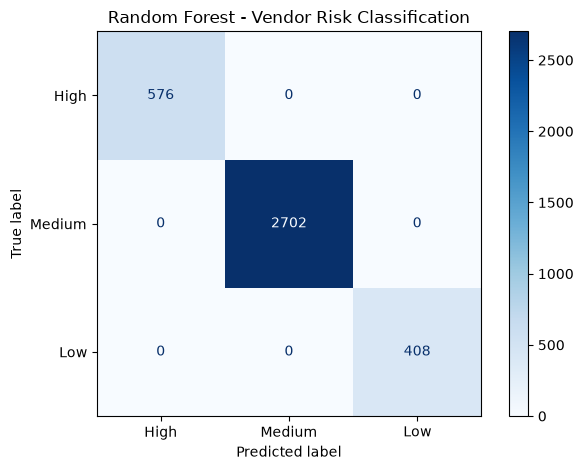

In [23]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict using trained Random Forest
y_pred = rf_model.predict(X_test)

# Overall evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

macro_precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

macro_recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

weighted_f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print("===== MODEL EVALUATION RESULTS =====")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall: {macro_recall:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")
print(f"Weighted F1-score: {weighted_f1:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["High", "Medium", "Low"],
        zero_division=0
    )
)

# Confusion matrix
class_names = ["High", "Medium", "Low"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_names
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Vendor Risk Classification")
plt.tight_layout()
plt.show()


In [24]:

import joblib
import numpy as np
from pathlib import Path
from sklearn.metrics import accuracy_score

BASE_DIR = Path(r"D:\Vendor-Intelligence-System")

model_dir = BASE_DIR / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "vendor_risk_random_forest.pkl"

# Save trained model and feature information
model_package = {
    "model": rf_model,
    "features": list(X_train.columns),
    "classes": list(rf_model.classes_),
    "target": "risk_level",
    "label_type": "rule-derived"
}

if model_path.exists():
    raise FileExistsError(
        f"Model file already exists: {model_path}"
    )

joblib.dump(model_package, model_path)

print("Model saved successfully!")
print("Model path:", model_path)

# Reload the saved model
loaded_package = joblib.load(model_path)

loaded_model = loaded_package["model"]
saved_features = loaded_package["features"]

# Predict using the reloaded model
loaded_predictions = loaded_model.predict(
    X_test[saved_features]
)

predictions_match = np.array_equal(
    y_pred,
    loaded_predictions
)

loaded_accuracy = accuracy_score(
    y_test,
    loaded_predictions
)

print("\n===== MODEL RELOAD VERIFICATION =====")
print("Saved features:", saved_features)
print("Model classes:", loaded_package["classes"])
print("Predictions identical:", predictions_match)
print(f"Loaded model accuracy: {loaded_accuracy * 100:.2f}%")

assert predictions_match, "Reloaded predictions differ!"


Model saved successfully!
Model path: D:\Vendor-Intelligence-System\models\vendor_risk_random_forest.pkl

===== MODEL RELOAD VERIFICATION =====
Saved features: ['stars', 'review_count', 'collected_review_count', 'mean_review_rating', 'rating_std']
Model classes: ['High', 'Low', 'Medium']
Predictions identical: True
Loaded model accuracy: 100.00%


===== RANDOM FOREST FEATURE IMPORTANCE =====


,Feature,Importance
0,mean_review_rating,0.437063
1,rating_std,0.208685
2,stars,0.192111
3,collected_review_count,0.089712
4,review_count,0.072429



Total importance: 1.0


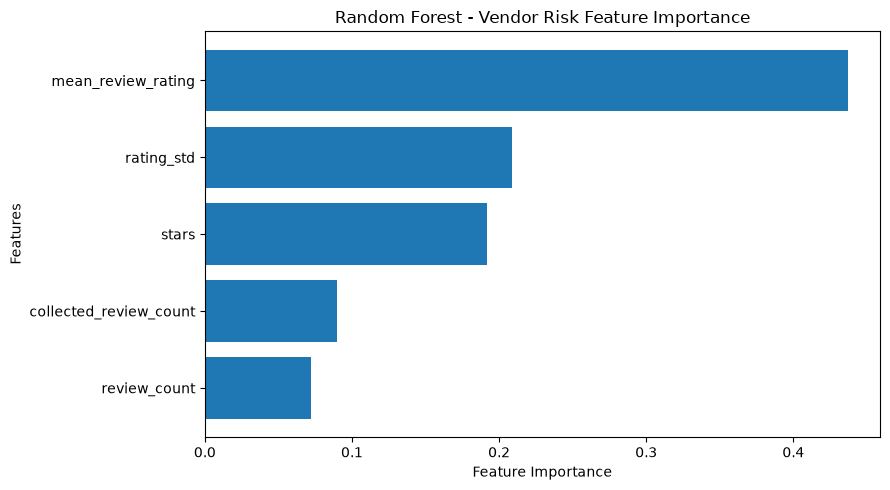

In [25]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance values
importance_df = pd.DataFrame({
    "Feature": saved_features,
    "Importance": loaded_model.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("===== RANDOM FOREST FEATURE IMPORTANCE =====")
display(importance_df)

print(
    "\nTotal importance:",
    round(importance_df["Importance"].sum(), 4)
)

# Visualize feature importance
plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest - Vendor Risk Feature Importance")
plt.tight_layout()
plt.show()


In [26]:

import pandas as pd

# Synthetic vendor test data
new_vendor = pd.DataFrame([{
    "stars": 4.5,
    "review_count": 120,
    "collected_review_count": 120,
    "mean_review_rating": 4.4,
    "rating_std": 0.6
}])

# Ensure correct feature order
new_vendor = new_vendor[saved_features]

# Predict vendor risk
predicted_risk = loaded_model.predict(new_vendor)[0]

# Get class probabilities
probabilities = loaded_model.predict_proba(new_vendor)[0]

print("===== NEW VENDOR PREDICTION =====")
print("Predicted Risk Level:", predicted_risk)

print("\nClass Probabilities:")
for risk_class, probability in zip(
    loaded_model.classes_,
    probabilities
):
    print(f"{risk_class}: {probability * 100:.2f}%")

print("\nInput Vendor:")
display(new_vendor)


===== NEW VENDOR PREDICTION =====
Predicted Risk Level: Low

Class Probabilities:
High: 0.00%
Low: 99.00%
Medium: 1.00%

Input Vendor:


,stars,review_count,collected_review_count,mean_review_rating,rating_std
0,4.5,120,120,4.4,0.6


In [27]:

import pandas as pd

# Use the cleaned dataset already loaded
df_rec = df_check.copy()

print("===== AVAILABLE COLUMNS =====")
for col in df_rec.columns:
    print(col)

print("\n===== SERVICE & LOCATION SAMPLE =====")

candidate_columns = [
    "business_id",
    "name",
    "service_categories",
    "matched_categories",
    "categories",
    "city",
    "state",
    "stars",
    "price_range",
    "risk_level",
    "vendor_score"
]

available_columns = [
    col for col in candidate_columns
    if col in df_rec.columns
]

display(df_rec[available_columns].head(10))

print("\n===== SERVICE COLUMN AVAILABILITY =====")
for col in [
    "service_categories",
    "matched_categories",
    "categories"
]:
    print(
        col,
        "Available:" if col in df_rec.columns else "Missing"
    )


===== AVAILABLE COLUMNS =====
business_id
name
service_categories
matched_categories
categories
city
state
latitude
longitude
stars
review_count
is_open
caters
price_range
attributes
hours
collected_review_count
mean_review_rating
rating_std
latest_review_date
has_review_data
risk_level
risk_score
rating_score
review_score
stability_score
vendor_score
vendor_rank
caters_known
price_range_known
hours_known
attributes_known

===== SERVICE & LOCATION SAMPLE =====


,business_id,name,service_categories,matched_categories,categories,city,state,stars,price_range,risk_level,vendor_score
0,GXFMD0Z4jEVZBCsbPf4CTQ,Hattie B’s Hot Chicken - Nashville,Catering,Caters=True,"American (Traditional), Chicken Shop, Southern...",Nashville,TN,4.5,2.0,Low,85.016540
1,_ab50qdWOk0DdB6XOrBitw,Acme Oyster House,Catering,Caters=True,"Live/Raw Food, Seafood, Restaurants, Cajun/Creole",New Orleans,LA,4.0,2.0,Medium,79.835991
2,ac1AeYqs8Z4_e2X5M3if2A,Oceana Grill,Catering,Caters=True,"Restaurants, Seafood, Cajun/Creole, Breakfast ...",New Orleans,LA,4.0,2.0,Medium,79.188746
3,I_3LMZ_1m2mzR0oLIOePIg,Pappy's Smokehouse,Catering,Caterers; Caters=True,"Food, Restaurants, Caterers, Smokehouse, Barbe...",Saint Louis,MO,4.5,2.0,Low,77.032755
4,gTC8IQ_i8zXytWSly3Ttvg,Cochon Butcher,Catering,Caters=True,"Shopping, Butcher, Restaurants, Sandwiches, Fo...",New Orleans,LA,4.5,2.0,Low,76.960367
5,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Catering,Caters=True,"Mexican, Restaurants",Santa Barbara,CA,4.5,2.0,Low,76.247786
6,C9K3579SJgLPp0oAOM29wg,Peg Leg Porker,Catering,Caters=True,"Pubs, Nightlife, American (Traditional), Barbe...",Nashville,TN,4.5,2.0,Low,71.238153
7,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Decoration,Floral Designers; Florists,"Flowers & Gifts, Florists, Shopping, Event Pla...",Santa Barbara,CA,5.0,2.0,Low,70.406621
8,LTqm4uY4GIYHfzuh5pVZNQ,Jeramie Lu Photography,Photography,Event Photography; Photographers,"Event Photography, Event Planning & Services, ...",Reno,NV,5.0,NaN,Low,70.301056
9,x-SCuOwghy4GlZdVOKjt4g,Twisted Twig Fine Florals,Decoration; Event Planning,Florists; Party & Event Planning,"Florists, Event Planning & Services, Shopping,...",Santa Barbara,CA,5.0,2.0,Low,70.289326



===== SERVICE COLUMN AVAILABILITY =====
service_categories Available:
matched_categories Available:
categories Available:


In [28]:

import pandas as pd

# Use cleaned recommendation dataset
df_services = df_rec.copy()

# Split semicolon-separated service categories
df_services["service_list"] = (
    df_services["service_categories"]
    .fillna("")
    .astype(str)
    .str.split(";")
    .apply(
        lambda items: [
            item.strip()
            for item in items
            if item.strip()
        ]
    )
)

# Expand services for counting
service_counts = (
    df_services["service_list"]
    .explode()
    .dropna()
    .value_counts()
)

print("===== SERVICE CATEGORY DISTRIBUTION =====")
display(service_counts)

# Count vendors with multiple services
multi_service_count = (
    df_services["service_list"]
    .apply(len)
    .gt(1)
    .sum()
)

print("\n===== SERVICE STRUCTURE =====")
print("Total vendors:", len(df_services))
print("Unique service categories:", len(service_counts))
print("Multi-service vendors:", multi_service_count)

# Check vendors without assigned services
no_service_count = (
    df_services["service_list"]
    .apply(len)
    .eq(0)
    .sum()
)

print("Vendors without service categories:", no_service_count)

print("\n===== MULTI-SERVICE VENDOR EXAMPLES =====")
display(
    df_services.loc[
        df_services["service_list"].apply(len).gt(1),
        [
            "business_id",
            "name",
            "service_categories",
            "city",
            "state"
        ]
    ].head(10)
)


===== SERVICE CATEGORY DISTRIBUTION =====


service_list
Catering            16145
Event Planning       1339
Decoration            882
Photography           467
Equipment Rental      184
Entertainment         154
Audio Visual           12
Name: count, dtype: int64


===== SERVICE STRUCTURE =====
Total vendors: 18430
Unique service categories: 7
Multi-service vendors: 684
Vendors without service categories: 0

===== MULTI-SERVICE VENDOR EXAMPLES =====


,business_id,name,service_categories,city,state
9,x-SCuOwghy4GlZdVOKjt4g,Twisted Twig Fine Florals,Decoration; Event Planning,Santa Barbara,CA
10,2FQoAp9w0G_NhuZMqo9bfA,ByCherry Photography,Event Planning; Photography,Santa Barbara,CA
11,_LHkm-m9a_IDqfqfdWggHQ,Dj Hecktik,Audio Visual; Entertainment; Equipment Rental;...,Santa Barbara,CA
12,LTa-23WGNMC37_b2mm5jkQ,Walden Floral LA & Nashville,Decoration; Event Planning,Nashville,TN
13,pl87HrR7JYUAH7ULEwj7UQ,Marc Bosserman Pianist & Vocalist,Entertainment; Event Planning,Tampa Bay,FL
22,MsVAy-6KHs9drxXzs1mopg,Patrick Butler Entertainment,Entertainment; Event Planning,Santa Barbara,CA
23,GHEIwXFvgiX6JV4AWiQcRg,Epik Weddings & Events,Entertainment; Event Planning; Photography,Reno,NV
26,8ei40SEWTURN8ROo5mBiJg,Fire & Wine Catering,Catering; Event Planning,Santa Barbara,CA
27,Hpjxc1XqCAeH29duBxdIQQ,Mark Nargi,Catering; Event Planning,Santa Barbara,CA
33,pISDpMPBYETA8b6N_RkCFg,Phil Birdsell DJ MC Entertainment,Entertainment; Event Planning,Reno,NV


In [29]:

import pandas as pd

def recommend_vendors(
    data,
    required_service,
    city=None,
    state=None,
    allowed_risks=None,
    top_n=10
):
    results = data.copy()

    # 1. Match exact service tokens
    service = required_service.strip().casefold()

    results = results[
        results["service_list"].apply(
            lambda items: any(
                str(item).strip().casefold() == service
                for item in items
            )
        )
    ]

    # 2. Filter city
    if city:
        results = results[
            results["city"].astype(str)
            .str.strip().str.casefold()
            == city.strip().casefold()
        ]

    # 3. Filter state
    if state:
        results = results[
            results["state"].astype(str)
            .str.strip().str.casefold()
            == state.strip().casefold()
        ]

    # 4. Filter allowed risk levels
    if allowed_risks is not None:
        allowed = {
            str(risk).strip().casefold()
            for risk in allowed_risks
        }

        results = results[
            results["risk_level"]
            .astype(str).str.casefold()
            .isin(allowed)
        ]

    # 5. Rank by existing vendor score
    results = results.sort_values(
        by=["vendor_score", "business_id"],
        ascending=[False, True]
    )

    return results.head(top_n)[
        [
            "business_id",
            "name",
            "service_categories",
            "city",
            "state",
            "stars",
            "risk_level",
            "vendor_score",
            "price_range"
        ]
    ].copy()


print("Vendor recommendation function created!")


Vendor recommendation function created!


In [30]:

test_results = recommend_vendors(
    data=df_services,
    required_service="Photography",
    city="Santa Barbara",
    state="CA",
    allowed_risks=["Low", "Medium"],
    top_n=10
)

print("===== PHOTOGRAPHY VENDOR RECOMMENDATIONS =====")
print("Matching vendors returned:", len(test_results))

display(test_results)


===== PHOTOGRAPHY VENDOR RECOMMENDATIONS =====
Matching vendors returned: 10


,business_id,name,service_categories,city,state,stars,risk_level,vendor_score,price_range
10,2FQoAp9w0G_NhuZMqo9bfA,ByCherry Photography,Event Planning; Photography,Santa Barbara,CA,5.0,Low,70.285416,NaN
21,Pn8De1oaG2RzlhJYhBYkqg,MICHAEL & ANNA COSTA PHOTOGRAPHY,Photography,Santa Barbara,CA,5.0,Low,70.164212,NaN
25,-SWVDAXw1i-VyuUY-XD6FA,Head & Heart Photography by Kiel Rucker,Photography,Santa Barbara,CA,5.0,Low,70.156393,NaN
30,fjS8q9GUZbQcoUsT8YLoQw,Karen D Photography,Photography,Santa Barbara,CA,5.0,Low,70.144663,NaN
36,HK814n_8tYF94a5on_M2ZQ,Imagine Weddings & Special Events,Event Planning; Photography,Santa Barbara,CA,5.0,Low,70.129024,NaN
45,QSFlM9BRZmWnHoOyhgrDsg,Agápe Films,Photography,Santa Barbara,CA,5.0,Low,70.101655,NaN
50,ttxmCANDj0cyl2LHLY5K9Q,Roland Photography,Event Planning; Photography,Santa Barbara,CA,5.0,Low,70.097745,NaN
71,cE5rwsypKYAd_D8eR2UDZw,Ryanne Bee Photography,Photography,Santa Barbara,CA,5.0,Low,70.082106,NaN
76,LQkIs1UKPN9kLDorDbLVlg,Veils & Tails Photography,Photography,Santa Barbara,CA,5.0,Low,70.078196,NaN
79,c-FOJ4B2CGmNjJ_Xlu6cTA,Willa Kveta Photography,Photography,Santa Barbara,CA,5.0,Low,70.078196,NaN


In [31]:

def shortlist_event_vendors(
    data,
    required_services,
    city,
    state,
    allowed_risks=None,
    top_n_per_service=5
):
    shortlists = {}

    for service in required_services:
        vendors = recommend_vendors(
            data=data,
            required_service=service,
            city=city,
            state=state,
            allowed_risks=allowed_risks,
            top_n=top_n_per_service
        )

        shortlists[service] = vendors

    return shortlists


# Example event requirements
event_requirements = {
    "event_type": "Wedding",
    "city": "Santa Barbara",
    "state": "CA",
    "required_services": [
        "Catering",
        "Photography",
        "Decoration"
    ],
    "allowed_risks": ["Low", "Medium"]
}

# Generate candidate shortlists
event_shortlists = shortlist_event_vendors(
    data=df_services,
    required_services=event_requirements["required_services"],
    city=event_requirements["city"],
    state=event_requirements["state"],
    allowed_risks=event_requirements["allowed_risks"],
    top_n_per_service=5
)

print("===== MULTI-SERVICE SHORTLIST RESULTS =====")

for service, vendors in event_shortlists.items():
    print(f"\nSERVICE: {service}")
    print("Candidates returned:", len(vendors))

    display(
        vendors[
            [
                "business_id",
                "name",
                "service_categories",
                "risk_level",
                "vendor_score",
                "price_range"
            ]
        ]
    )


===== MULTI-SERVICE SHORTLIST RESULTS =====

SERVICE: Catering
Candidates returned: 5


,business_id,name,service_categories,risk_level,vendor_score,price_range
5,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Catering,Low,76.247786,2.0
16,Hl_vXTiYLozWo7T9Cq17vw,Aperitivo,Catering,Low,70.187671,NaN
26,8ei40SEWTURN8ROo5mBiJg,Fire & Wine Catering,Catering; Event Planning,Low,70.152483,NaN
27,Hpjxc1XqCAeH29duBxdIQQ,Mark Nargi,Catering; Event Planning,Low,70.144663,NaN
44,kSKyOrJELZz_AzGkvnf8MA,Mattias Blom,Catering; Event Planning,Low,70.105565,NaN



SERVICE: Photography
Candidates returned: 5


,business_id,name,service_categories,risk_level,vendor_score,price_range
10,2FQoAp9w0G_NhuZMqo9bfA,ByCherry Photography,Event Planning; Photography,Low,70.285416,NaN
21,Pn8De1oaG2RzlhJYhBYkqg,MICHAEL & ANNA COSTA PHOTOGRAPHY,Photography,Low,70.164212,NaN
25,-SWVDAXw1i-VyuUY-XD6FA,Head & Heart Photography by Kiel Rucker,Photography,Low,70.156393,NaN
30,fjS8q9GUZbQcoUsT8YLoQw,Karen D Photography,Photography,Low,70.144663,NaN
36,HK814n_8tYF94a5on_M2ZQ,Imagine Weddings & Special Events,Event Planning; Photography,Low,70.129024,NaN



SERVICE: Decoration
Candidates returned: 5


,business_id,name,service_categories,risk_level,vendor_score,price_range
7,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Decoration,Low,70.406621,2.0
9,x-SCuOwghy4GlZdVOKjt4g,Twisted Twig Fine Florals,Decoration; Event Planning,Low,70.289326,2.0
77,nPzqScDSAXsqB1OwFK7Epg,Santa Barbara Company,Decoration,Low,70.078196,2.0
103,N9L6lmVPdzb24r6wFst2Hg,Alegria By Design,Decoration; Event Planning,Low,68.195364,NaN
251,R1tpkYIMsvj4Amj-2NS5Kw,Blue Blossoms,Decoration,Low,65.942470,2.0


In [32]:

import pandas as pd

def generate_initial_package(shortlists):
    selected_vendors = []
    used_business_ids = set()
    missing_services = []

    for service, vendors in shortlists.items():
        selected = None

        for _, vendor in vendors.iterrows():
            business_id = str(vendor["business_id"])

            # Prevent duplicate vendor assignments
            if business_id not in used_business_ids:
                selected = vendor
                used_business_ids.add(business_id)
                break

        if selected is None:
            missing_services.append(service)
            continue

        selected_vendors.append({
            "required_service": service,
            "business_id": selected["business_id"],
            "vendor_name": selected["name"],
            "risk_level": selected["risk_level"],
            "vendor_score": selected["vendor_score"],
            "price_range": selected["price_range"]
        })

    package_df = pd.DataFrame(
        selected_vendors,
        columns=[
            "required_service",
            "business_id",
            "vendor_name",
            "risk_level",
            "vendor_score",
            "price_range"
        ]
    )

    return package_df, missing_services


initial_package, missing_services = generate_initial_package(
    event_shortlists
)

print("===== INITIAL EVENT PACKAGE =====")
display(initial_package)

print("\n===== PACKAGE VALIDATION =====")
print("Required services:", len(event_shortlists))
print("Selected vendors:", len(initial_package))
print("Missing services:", missing_services)

print(
    "Unique vendors:",
    initial_package["business_id"].nunique()
)

print(
    "Duplicate vendor assignments:",
    initial_package["business_id"].duplicated().sum()
)

print(
    "Unknown price ranges:",
    initial_package["price_range"].isna().sum()
)


===== INITIAL EVENT PACKAGE =====


,required_service,business_id,vendor_name,risk_level,vendor_score,price_range
0,Catering,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Low,76.247786,2.0
1,Photography,2FQoAp9w0G_NhuZMqo9bfA,ByCherry Photography,Low,70.285416,NaN
2,Decoration,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Low,70.406621,2.0



===== PACKAGE VALIDATION =====
Required services: 3
Selected vendors: 3
Missing services: []
Unique vendors: 3
Duplicate vendor assignments: 0
Unknown price ranges: 1


In [33]:

import pandas as pd
from pathlib import Path

matrix_path = Path(
    r"D:\Vendor-Intelligence-System\data\processed\vendor_compatibility_matrix.csv"
)

print("===== COMPATIBILITY MATRIX FILE CHECK =====")
print("File exists:", matrix_path.exists())

if matrix_path.exists():
    compatibility_df = pd.read_csv(matrix_path)

    print("\n===== MATRIX STRUCTURE =====")
    print("Shape:", compatibility_df.shape)
    print("Columns:", compatibility_df.columns.tolist())

    print("\n===== SAMPLE RECORDS =====")
    display(compatibility_df.head(15))

    print("\n===== MISSING VALUES =====")
    display(compatibility_df.isna().sum())
else:
    print("File not found at this path.")
    print("Check the actual location of vendor_compatibility_matrix.csv")


===== COMPATIBILITY MATRIX FILE CHECK =====
File exists: False
File not found at this path.
Check the actual location of vendor_compatibility_matrix.csv


In [34]:

from pathlib import Path

project_path = Path(r"D:\Vendor-Intelligence-System")

print("===== PROJECT FOLDER CHECK =====")
print("Project exists:", project_path.exists())

print("\n===== COMPATIBILITY MATRIX SEARCH =====")

if project_path.exists():
    matching_files = list(
        project_path.rglob("*compatib*.csv")
    )

    if matching_files:
        print("Matching files found:", len(matching_files))

        for file in matching_files:
            print(file)
    else:
        print("No compatibility CSV files found.")
else:
    print("Project folder not found.")

print("\n===== CURRENT NOTEBOOK DIRECTORY =====")
print(Path.cwd())


===== PROJECT FOLDER CHECK =====
Project exists: True

===== COMPATIBILITY MATRIX SEARCH =====
Matching files found: 1
D:\Vendor-Intelligence-System\vendor_compatibility_matrix.csv

===== CURRENT NOTEBOOK DIRECTORY =====
d:\Vendor-Intelligence-System\notebooks


In [35]:

import pandas as pd
from pathlib import Path

# Correct compatibility matrix path
matrix_path = Path(
    r"D:\Vendor-Intelligence-System\vendor_compatibility_matrix.csv"
)

# Load matrix
compatibility_df = pd.read_csv(matrix_path)

print("===== COMPATIBILITY MATRIX LOADED =====")
print("Shape:", compatibility_df.shape)

print("\n===== COLUMN NAMES =====")
print(compatibility_df.columns.tolist())

print("\n===== COMPATIBILITY MATRIX =====")
display(compatibility_df)

print("\n===== MISSING VALUES =====")
display(compatibility_df.isna().sum())

print("\n===== DUPLICATE ROWS =====")
print(compatibility_df.duplicated().sum())


===== COMPATIBILITY MATRIX LOADED =====
Shape: (15, 3)

===== COLUMN NAMES =====
['service_1', 'service_2', 'base_score']

===== COMPATIBILITY MATRIX =====


,service_1,service_2,base_score
0,Catering,Photography,95
1,Catering,Decoration,90
2,Catering,Entertainment,80
3,Catering,Audio Visual,75
4,Photography,Decoration,85
5,Photography,Entertainment,80
6,Photography,Audio Visual,85
7,Decoration,Entertainment,80
8,Decoration,Audio Visual,75
9,Entertainment,Audio Visual,100



===== MISSING VALUES =====


service_1     0
service_2     0
base_score    0
dtype: int64


===== DUPLICATE ROWS =====
0


In [36]:

import pandas as pd
from itertools import combinations

def calculate_package_compatibility(
    package_df,
    compatibility_df
):
    # Create order-independent service pair lookup
    compatibility_lookup = {}

    for _, row in compatibility_df.iterrows():
        pair = frozenset([
            str(row["service_1"]).strip(),
            str(row["service_2"]).strip()
        ])

        compatibility_lookup[pair] = float(
            row["base_score"]
        )

    # Services selected in the package
    services = (
        package_df["required_service"]
        .astype(str)
        .str.strip()
        .tolist()
    )

    pair_results = []
    missing_pairs = []

    # Calculate pairwise compatibility
    for service_1, service_2 in combinations(services, 2):
        pair = frozenset([service_1, service_2])

        score = compatibility_lookup.get(pair)

        if score is None:
            missing_pairs.append(
                (service_1, service_2)
            )
            continue

        pair_results.append({
            "service_1": service_1,
            "service_2": service_2,
            "compatibility_score": score
        })

    pair_df = pd.DataFrame(
        pair_results,
        columns=[
            "service_1",
            "service_2",
            "compatibility_score"
        ]
    )

    # Do not claim complete compatibility if
    # any service pair is missing
    if missing_pairs or pair_df.empty:
        overall_score = None
    else:
        overall_score = (
            pair_df["compatibility_score"].mean()
        )

    return pair_df, overall_score, missing_pairs


# Calculate compatibility for initial package
pair_scores, overall_score, missing_pairs = (
    calculate_package_compatibility(
        initial_package,
        compatibility_df
    )
)

print("===== PACKAGE COMPATIBILITY RESULTS =====")
display(pair_scores)

print("\n===== OVERALL COMPATIBILITY =====")
print("Overall score:", overall_score)
print("Missing pairs:", missing_pairs)


===== PACKAGE COMPATIBILITY RESULTS =====


,service_1,service_2,compatibility_score
0,Catering,Photography,95.0
1,Catering,Decoration,90.0
2,Photography,Decoration,85.0



===== OVERALL COMPATIBILITY =====
Overall score: 90.0
Missing pairs: []


In [37]:

import pandas as pd

score_columns = [
    "vendor_score",
    "risk_score",
    "review_score",
    "stars",
    "mean_review_rating",
    "rating_std",
    "collected_review_count"
]

available_scores = [
    col for col in score_columns
    if col in df_rec.columns
]

print("===== AVAILABLE SCORE COLUMNS =====")
print(available_scores)

print("\n===== SCORE DISTRIBUTION =====")
display(
    df_rec[available_scores].describe().round(2)
)

print("\n===== SELECTED PACKAGE SCORE DETAILS =====")
package_score_details = initial_package[
    ["required_service", "business_id", "vendor_name"]
].merge(
    df_rec[["business_id"] + available_scores],
    on="business_id",
    how="left",
    validate="one_to_one"
)

display(package_score_details)

print("\n===== MISSING SCORE VALUES =====")
display(df_rec[available_scores].isna().sum())


===== AVAILABLE SCORE COLUMNS =====
['vendor_score', 'risk_score', 'review_score', 'stars', 'mean_review_rating', 'rating_std', 'collected_review_count']

===== SCORE DISTRIBUTION =====


,vendor_score,risk_score,review_score,stars,mean_review_rating,rating_std,collected_review_count
count,18430.00,18430.00,18430.00,18430.00,18430.00,18430.00,18430.00
mean,46.90,58.17,1.51,3.77,3.77,1.24,116.18
std,10.49,20.58,2.90,0.78,0.77,0.41,222.49
min,19.17,20.00,0.07,1.00,1.00,0.00,5.00
25%,42.83,60.00,0.25,3.50,3.32,1.08,19.00
50%,47.72,60.00,0.66,4.00,3.87,1.33,51.00
75%,52.09,60.00,1.69,4.50,4.32,1.51,130.00
max,85.02,100.00,100.00,5.00,5.00,2.19,7673.00



===== SELECTED PACKAGE SCORE DETAILS =====


,required_service,business_id,vendor_name,vendor_score,risk_score,review_score,stars,mean_review_rating,rating_std,collected_review_count
0,Catering,yPSejq3_erxo9zdVYTBnZA,Los Agaves,76.247786,100,50.684217,4.5,4.489329,0.95012,3889
1,Photography,2FQoAp9w0G_NhuZMqo9bfA,ByCherry Photography,70.285416,100,0.951388,5.0,5.000000,0.00000,73
2,Decoration,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,70.406621,100,1.355402,5.0,5.000000,0.00000,104



===== MISSING SCORE VALUES =====


vendor_score              0
risk_score                0
review_score              0
stars                     0
mean_review_rating        0
rating_std                0
collected_review_count    0
dtype: int64

In [38]:

import pandas as pd

print("===== SCORE CORRELATION =====")

score_cols = [
    "vendor_score",
    "risk_score",
    "review_score",
    "stars"
]

display(
    df_rec[score_cols]
    .corr()
    .round(4)
)

print("\n===== RISK LEVEL VS RISK SCORE =====")

display(
    pd.crosstab(
        df_rec["risk_level"],
        df_rec["risk_score"]
    )
)

print("\n===== VENDOR SCORE BY RISK LEVEL =====")

display(
    df_rec.groupby("risk_level")["vendor_score"]
    .agg(["count", "mean", "min", "max"])
    .round(3)
)


===== SCORE CORRELATION =====


,vendor_score,risk_score,review_score,stars
vendor_score,1.0000,0.8892,0.1765,0.9418
risk_score,0.8892,1.0000,0.1300,0.7399
review_score,0.1765,0.1300,1.0000,0.0804
stars,0.9418,0.7399,0.0804,1.0000



===== RISK LEVEL VS RISK SCORE =====


risk_score,20,60,100
risk_level,,,
High,2881,0,0
Low,0,0,2038
Medium,0,13511,0



===== VENDOR SCORE BY RISK LEVEL =====


,count,mean,min,max
risk_level,,,,
High,2881,27.792,19.174,37.080
Low,2038,63.290,57.206,85.017
Medium,13511,48.502,39.157,79.836


In [39]:

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# Candidate score components
feature_cols = [
    "risk_score",
    "review_score",
    "stars"
]

X_score = df_rec[feature_cols].copy()
y_score = df_rec["vendor_score"].copy()

# Fit diagnostic linear approximation
score_model = LinearRegression()
score_model.fit(X_score, y_score)

predicted_scores = score_model.predict(X_score)

print("===== SCORE FORMULA DIAGNOSTIC =====")

print("Intercept:", round(score_model.intercept_, 6))

for feature, coefficient in zip(
    feature_cols,
    score_model.coef_
):
    print(
        f"{feature} coefficient:",
        round(coefficient, 6)
    )

print("\n===== APPROXIMATION QUALITY =====")
print(
    "R²:",
    round(r2_score(y_score, predicted_scores), 6)
)
print(
    "MAE:",
    round(mean_absolute_error(
        y_score,
        predicted_scores
    ), 6)
)

print(
    "Maximum absolute error:",
    round(
        np.max(
            np.abs(y_score - predicted_scores)
        ),
        6
    )
)

print("\n===== ACTUAL VS APPROXIMATED SCORES =====")

comparison = pd.DataFrame({
    "actual_vendor_score": y_score,
    "approximated_score": predicted_scores
})

comparison["absolute_error"] = (
    comparison["actual_vendor_score"]
    - comparison["approximated_score"]
).abs()

display(comparison.head(10).round(4))


===== SCORE FORMULA DIAGNOSTIC =====
Intercept: 2.366171
risk_score coefficient: 0.210873
review_score coefficient: 0.260943
stars coefficient: 8.456192

===== APPROXIMATION QUALITY =====
R²: 0.973943
MAE: 1.316306
Maximum absolute error: 10.346752

===== ACTUAL VS APPROXIMATED SCORES =====


,actual_vendor_score,approximated_score,absolute_error
0,85.0165,82.4552,2.5614
1,79.8360,74.9376,4.8984
2,79.1887,74.4036,4.7851
3,77.0328,75.4257,1.6070
4,76.9604,74.8272,2.1332
5,76.2478,74.7320,1.5158
6,71.2382,71.3992,0.1610
7,70.4066,66.0881,4.3186
8,70.3011,65.9962,4.3048
9,70.2893,65.9860,4.3033


In [40]:

from pathlib import Path

project_path = Path(r"D:\Vendor-Intelligence-System")

search_terms = [
    "vendor_score",
    "review_score",
    "risk_score"
]

print("===== SCORING CODE SEARCH =====")

matches = []

for file_path in project_path.rglob("*"):
    if file_path.suffix.lower() not in [".py", ".ipynb"]:
        continue

    try:
        content = file_path.read_text(
            encoding="utf-8",
            errors="ignore"
        ).lower()

        found_terms = [
            term for term in search_terms
            if term in content
        ]

        if found_terms:
            matches.append((file_path, found_terms))

    except OSError:
        continue

print("Matching files:", len(matches))

for file_path, found_terms in matches:
    print("\nFile:", file_path)
    print("Terms:", found_terms)


===== SCORING CODE SEARCH =====
Matching files: 3

File: D:\Vendor-Intelligence-System\build_hybrid_dataset.py
Terms: ['vendor_score', 'review_score', 'risk_score']

File: D:\Vendor-Intelligence-System\Untitled.ipynb
Terms: ['vendor_score', 'review_score', 'risk_score']

File: D:\Vendor-Intelligence-System\notebooks\01_vendor_dataset_audit.ipynb
Terms: ['vendor_score', 'review_score', 'risk_score']


In [41]:

from pathlib import Path

file_path = Path(
    r"D:\Vendor-Intelligence-System\build_hybrid_dataset.py"
)

search_terms = [
    "vendor_score",
    "review_score",
    "risk_score"
]

lines = file_path.read_text(
    encoding="utf-8",
    errors="replace"
).splitlines()

matching_lines = [
    i for i, line in enumerate(lines)
    if any(term in line.lower() for term in search_terms)
]

print("===== SCORING CODE LOCATIONS =====")
print("Total matching lines:", len(matching_lines))

# Combine overlapping context ranges
ranges = []

for i in matching_lines:
    start = max(0, i - 8)
    end = min(len(lines), i + 9)

    if ranges and start <= ranges[-1][1]:
        ranges[-1] = (
            ranges[-1][0],
            max(ranges[-1][1], end)
        )
    else:
        ranges.append((start, end))

for start, end in ranges:
    print(f"\n===== LINES {start+1}–{end} =====")

    for j in range(start, end):
        print(f"{j+1:4}: {lines[j]}")


===== SCORING CODE LOCATIONS =====
Total matching lines: 3

===== LINES 23–39 =====
  23: 
  24: def build(source, output, seed=42):
  25:     source, output = Path(source), Path(output)
  26:     if not source.is_file():
  27:         raise FileNotFoundError(f'Upload/copy the verified vendor CSV to: {source}')
  28:     if output.exists() and any(output.iterdir()):
  29:         raise ValueError('Output directory is not empty. Use a new directory to preserve earlier runs.')
  30:     real = pd.read_csv(source, encoding='utf-8-sig', dtype={'business_id': 'string'})
  31:     required = ['business_id', 'name', 'city', 'state', 'service_categories', 'risk_level', 'vendor_score']
  32:     missing = set(required) - set(real.columns)
  33:     if missing:
  34:         raise ValueError(f'Missing columns: {sorted(missing)}')
  35:     ids = real.business_id.fillna('').str.strip()
  36:     if ids.eq('').any() or ids.str.startswith('#').any() or ids.duplicated().any():
  37:         raise Va

In [42]:

import json
from pathlib import Path

project_path = Path(r"D:\Vendor-Intelligence-System")

notebook_files = [
    project_path / "Untitled.ipynb",
    project_path / "notebooks" / "01_vendor_dataset_audit.ipynb"
]

for notebook_path in notebook_files:

    print("\n" + "=" * 60)
    print("NOTEBOOK:", notebook_path.name)
    print("=" * 60)

    if not notebook_path.exists():
        print("File not found")
        continue

    with notebook_path.open(
        "r", encoding="utf-8"
    ) as f:
        notebook = json.load(f)

    matches = 0

    for cell_number, cell in enumerate(
        notebook.get("cells", []), start=1
    ):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        # Look for vendor_score assignments
        if (
            "vendor_score" in source
            and any(operator in source for operator in [
                '["vendor_score"] =',
                "['vendor_score'] =",
                '.assign(',
                'vendor_score='
            ])
        ):
            matches += 1

            print(
                f"\n===== CELL {cell_number} ====="
            )

            print(source[:5000])

    print("\nMatching assignment cells:", matches)



NOTEBOOK: Untitled.ipynb

===== CELL 37 =====
import pandas as pd
import numpy as np

df = pd.read_csv(
    r"D:\Vendor-Intelligence-System\vendor_risk_dataset.csv"
)

# Risk Scores
risk_map = {
    "Low": 100,
    "Medium": 60,
    "High": 20
}

df["risk_score"] = df["risk_level"].map(
    risk_map
)

# Normalize Rating
df["rating_score"] = (
    df["mean_review_rating"] / 5
) * 100

# Normalize Review Count
max_reviews = df["collected_review_count"].max()

df["review_score"] = (
    df["collected_review_count"] / max_reviews
) * 100

# Stability Score
df["stability_score"] = (
    1 / (1 + df["rating_std"])
) * 100

# Final Vendor Ranking Score
df["vendor_score"] = (
    df["rating_score"] * 0.40 +
    df["review_score"] * 0.30 +
    df["risk_score"] * 0.20 +
    df["stability_score"] * 0.10
)

# Rank Vendors
df["vendor_rank"] = (
    df["vendor_score"]
    .rank(
        ascending=False,
        method="dense"
    )
)

df = df.sort_values(
    by="vendor_score",
    ascending=False

In [43]:

import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System\Untitled.ipynb"
)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

cell = notebook["cells"][36]  # Cell 37

source_code = "".join(cell.get("source", []))

print("===== ORIGINAL SCORING CODE =====")

for line_number, line in enumerate(
    source_code.splitlines(), start=1
):
    print(f"{line_number:03}: {line}")


===== ORIGINAL SCORING CODE =====
001: import pandas as pd
002: import numpy as np
003: 
004: df = pd.read_csv(
005:     r"D:\Vendor-Intelligence-System\vendor_risk_dataset.csv"
006: )
007: 
008: # Risk Scores
009: risk_map = {
010:     "Low": 100,
011:     "Medium": 60,
012:     "High": 20
013: }
014: 
015: df["risk_score"] = df["risk_level"].map(
016:     risk_map
017: )
018: 
019: # Normalize Rating
020: df["rating_score"] = (
021:     df["mean_review_rating"] / 5
022: ) * 100
023: 
024: # Normalize Review Count
025: max_reviews = df["collected_review_count"].max()
026: 
027: df["review_score"] = (
028:     df["collected_review_count"] / max_reviews
029: ) * 100
030: 
031: # Stability Score
032: df["stability_score"] = (
033:     1 / (1 + df["rating_std"])
034: ) * 100
035: 
036: # Final Vendor Ranking Score
037: df["vendor_score"] = (
038:     df["rating_score"] * 0.40 +
039:     df["review_score"] * 0.30 +
040:     df["risk_score"] * 0.20 +
041:     df["stability_score"] * 0.10
04

In [44]:

lines = source_code.splitlines()

print("===== ORIGINAL SCORING FORMULA =====")

for i in range(18, min(60, len(lines))):
    print(f"{i+1:03}: {lines[i]}")


===== ORIGINAL SCORING FORMULA =====
019: # Normalize Rating
020: df["rating_score"] = (
021:     df["mean_review_rating"] / 5
022: ) * 100
023: 
024: # Normalize Review Count
025: max_reviews = df["collected_review_count"].max()
026: 
027: df["review_score"] = (
028:     df["collected_review_count"] / max_reviews
029: ) * 100
030: 
031: # Stability Score
032: df["stability_score"] = (
033:     1 / (1 + df["rating_std"])
034: ) * 100
035: 
036: # Final Vendor Ranking Score
037: df["vendor_score"] = (
038:     df["rating_score"] * 0.40 +
039:     df["review_score"] * 0.30 +
040:     df["risk_score"] * 0.20 +
041:     df["stability_score"] * 0.10
042: )
043: 
044: # Rank Vendors
045: df["vendor_rank"] = (
046:     df["vendor_score"]
047:     .rank(
048:         ascending=False,
049:         method="dense"
050:     )
051: )
052: 
053: df = df.sort_values(
054:     by="vendor_score",
055:     ascending=False
056: )
057: 
058: df.to_csv(
059:     r"D:\Vendor-Intelligence-System\vendor_recom

In [45]:

import numpy as np
import pandas as pd

# Recalculate score using original formula
max_reviews = df_rec["collected_review_count"].max()

risk_map = {
    "Low": 100,
    "Medium": 60,
    "High": 20
}

rating_score = (
    df_rec["mean_review_rating"] / 5
) * 100

review_score = (
    df_rec["collected_review_count"] / max_reviews
) * 100

risk_score = df_rec["risk_level"].map(risk_map)

stability_score = (
    1 / (1 + df_rec["rating_std"])
) * 100

recalculated_score = (
    rating_score * 0.40 +
    review_score * 0.30 +
    risk_score * 0.20 +
    stability_score * 0.10
)

absolute_error = (
    df_rec["vendor_score"] - recalculated_score
).abs()

print("===== ORIGINAL FORMULA VERIFICATION =====")

print("Records:", len(df_rec))
print("Maximum review count:", max_reviews)

print(
    "Mean absolute difference:",
    absolute_error.mean()
)

print(
    "Maximum absolute difference:",
    absolute_error.max()
)

print(
    "Matching records:",
    np.isclose(
        df_rec["vendor_score"],
        recalculated_score,
        atol=1e-6,
        rtol=0
    ).sum()
)

print("\n===== SAMPLE COMPARISON =====")

display(
    pd.DataFrame({
        "saved_vendor_score": df_rec["vendor_score"],
        "recalculated_score": recalculated_score,
        "absolute_difference": absolute_error
    }).head(10).round(6)
)


===== ORIGINAL FORMULA VERIFICATION =====
Records: 18430
Maximum review count: 7673
Mean absolute difference: 9.358884921636697e-16
Maximum absolute difference: 7.105427357601002e-15
Matching records: 18430

===== SAMPLE COMPARISON =====


,saved_vendor_score,recalculated_score,absolute_difference
0,85.016540,85.016540,0.0
1,79.835991,79.835991,0.0
2,79.188746,79.188746,0.0
3,77.032755,77.032755,0.0
4,76.960367,76.960367,0.0
5,76.247786,76.247786,0.0
6,71.238153,71.238153,0.0
7,70.406621,70.406621,0.0
8,70.301056,70.301056,0.0
9,70.289326,70.289326,0.0


In [46]:

import pandas as pd
import numpy as np

def evaluate_package(
    package_df,
    compatibility_score,
    required_services,
    vendor_weight=0.70,
    compatibility_weight=0.30
):
    # Validate weights
    if not np.isclose(
        vendor_weight + compatibility_weight, 1.0
    ):
        raise ValueError("Weights must sum to 1.0")

    if vendor_weight < 0 or compatibility_weight < 0:
        raise ValueError("Weights cannot be negative")

    # Validate service coverage
    selected_services = (
        package_df["required_service"]
        .astype(str)
        .str.strip()
        .tolist()
    )

    required = [
        str(service).strip()
        for service in required_services
    ]

    missing_services = [
        service for service in required
        if service not in selected_services
    ]

    duplicate_services = (
        len(selected_services) != len(set(selected_services))
    )

    duplicate_vendors = (
        package_df["business_id"]
        .astype(str)
        .duplicated()
        .any()
    )

    unexpected_services = [
        service for service in selected_services
        if service not in required
    ]

    # Reject incomplete or invalid packages
    if (
        missing_services
        or unexpected_services
        or duplicate_services
        or duplicate_vendors
        or len(package_df) != len(required)
    ):
        raise ValueError(
            "Package has missing, unexpected, "
            "or duplicate services/vendors."
        )

    if compatibility_score is None:
        raise ValueError(
            "Compatibility score is incomplete."
        )

    scores = pd.to_numeric(
        package_df["vendor_score"],
        errors="coerce"
    )

    if (
        scores.isna().any()
        or not scores.between(0, 100).all()
        or not 0 <= compatibility_score <= 100
    ):
        raise ValueError("Invalid evaluation scores.")

    average_vendor_score = scores.mean()

    final_package_score = (
        average_vendor_score * vendor_weight
        + compatibility_score * compatibility_weight
    )

    return {
        "total_required_services": len(required),
        "selected_vendors": len(package_df),
        "average_vendor_score": round(
            average_vendor_score, 4
        ),
        "compatibility_score": round(
            compatibility_score, 4
        ),
        "final_package_score": round(
            final_package_score, 4
        )
    }


# Evaluate current wedding package
package_evaluation = evaluate_package(
    package_df=initial_package,
    compatibility_score=overall_score,
    required_services=event_requirements["required_services"]
)

print("===== PACKAGE EVALUATION RESULTS =====")

for key, value in package_evaluation.items():
    print(f"{key}: {value}")


===== PACKAGE EVALUATION RESULTS =====
total_required_services: 3
selected_vendors: 3
average_vendor_score: 72.3133
compatibility_score: 90.0
final_package_score: 77.6193


In [47]:

import pandas as pd
from itertools import product

def generate_candidate_packages(shortlists):

    services = list(shortlists.keys())

    # Check for empty shortlists
    if any(shortlists[s].empty for s in services):
        return [], 0

    vendor_lists = [
        shortlists[s].to_dict("records")
        for s in services
    ]

    candidate_packages = []
    total_combinations = 0

    for combination in product(*vendor_lists):

        total_combinations += 1

        business_ids = [
            str(vendor["business_id"])
            for vendor in combination
        ]

        # Reject packages with repeated vendors
        if len(business_ids) != len(set(business_ids)):
            continue

        selected_vendors = []

        for service, vendor in zip(
            services, combination
        ):
            selected_vendors.append({
                "required_service": service,
                "business_id": vendor["business_id"],
                "vendor_name": vendor["name"],
                "risk_level": vendor["risk_level"],
                "vendor_score": vendor["vendor_score"],
                "price_range": vendor["price_range"]
            })

        package_df = pd.DataFrame(
            selected_vendors
        )

        candidate_packages.append(package_df)

    return candidate_packages, total_combinations


# Generate packages
candidate_packages, total_combinations = (
    generate_candidate_packages(event_shortlists)
)

print("===== CANDIDATE PACKAGE GENERATION =====")

print("Total combinations:", total_combinations)
print("Valid packages:", len(candidate_packages))
print(
    "Rejected combinations:",
    total_combinations - len(candidate_packages)
)

print("\n===== FIRST CANDIDATE PACKAGE =====")

if candidate_packages:
    display(candidate_packages[0])
else:
    print("No valid packages generated.")


===== CANDIDATE PACKAGE GENERATION =====
Total combinations: 125
Valid packages: 125
Rejected combinations: 0

===== FIRST CANDIDATE PACKAGE =====


,required_service,business_id,vendor_name,risk_level,vendor_score,price_range
0,Catering,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Low,76.247786,2.0
1,Photography,2FQoAp9w0G_NhuZMqo9bfA,ByCherry Photography,Low,70.285416,NaN
2,Decoration,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Low,70.406621,2.0


In [48]:

import pandas as pd

package_results = []

for package_id, package_df in enumerate(
    candidate_packages, start=1
):
    evaluation = evaluate_package(
        package_df=package_df,
        compatibility_score=overall_score,
        required_services=event_requirements["required_services"]
    )

    result = {
        "package_id": package_id,
        **evaluation
    }

    # Add selected vendor names
    for _, vendor in package_df.iterrows():
        service = vendor["required_service"]
        result[service] = vendor["vendor_name"]

    # Track missing price tiers
    result["missing_price_tiers"] = (
        package_df["price_range"].isna().sum()
    )

    package_results.append(result)

# Create ranking DataFrame
package_ranking_df = pd.DataFrame(package_results)

# Rank by package score
package_ranking_df = (
    package_ranking_df
    .sort_values(
        by=["final_package_score", "package_id"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

package_ranking_df.insert(
    0,
    "rank",
    range(1, len(package_ranking_df) + 1)
)

print("===== PACKAGE RANKING SUMMARY =====")

print("Total ranked packages:", len(package_ranking_df))

print(
    "Highest score:",
    package_ranking_df["final_package_score"].max()
)

print(
    "Lowest score:",
    package_ranking_df["final_package_score"].min()
)

print("\n===== TOP 10 RECOMMENDED PACKAGES =====")

display(
    package_ranking_df[
        [
            "rank",
            "package_id",
            "Catering",
            "Photography",
            "Decoration",
            "average_vendor_score",
            "compatibility_score",
            "final_package_score",
            "missing_price_tiers"
        ]
    ].head(10)
)


===== PACKAGE RANKING SUMMARY =====
Total ranked packages: 125
Highest score: 77.6193
Lowest score: 75.108

===== TOP 10 RECOMMENDED PACKAGES =====


,rank,package_id,Catering,Photography,Decoration,average_vendor_score,compatibility_score,final_package_score,missing_price_tiers
0,1,1,Los Agaves,ByCherry Photography,ella & louie flowers,72.3133,90.0,77.6193,1
1,2,2,Los Agaves,ByCherry Photography,Twisted Twig Fine Florals,72.2742,90.0,77.5919,1
2,3,6,Los Agaves,MICHAEL & ANNA COSTA PHOTOGRAPHY,ella & louie flowers,72.2729,90.0,77.5910,1
3,4,11,Los Agaves,Head & Heart Photography by Kiel Rucker,ella & louie flowers,72.2703,90.0,77.5892,1
4,5,16,Los Agaves,Karen D Photography,ella & louie flowers,72.2664,90.0,77.5864,1
5,6,21,Los Agaves,Imagine Weddings & Special Events,ella & louie flowers,72.2611,90.0,77.5828,1
6,7,7,Los Agaves,MICHAEL & ANNA COSTA PHOTOGRAPHY,Twisted Twig Fine Florals,72.2338,90.0,77.5636,1
7,8,12,Los Agaves,Head & Heart Photography by Kiel Rucker,Twisted Twig Fine Florals,72.2312,90.0,77.5618,1
8,9,17,Los Agaves,Karen D Photography,Twisted Twig Fine Florals,72.2273,90.0,77.5591,1
9,10,22,Los Agaves,Imagine Weddings & Special Events,Twisted Twig Fine Florals,72.2220,90.0,77.5554,1


In [49]:

import pandas as pd

print("===== PACKAGE DIVERSITY AUDIT =====")

top_10 = package_ranking_df.head(10)

for service in event_requirements["required_services"]:
    print(
        f"{service} - Unique vendors in Top 10:",
        top_10[service].nunique()
    )

print("\n===== PRICING COMPLETENESS =====")

price_summary = (
    package_ranking_df["missing_price_tiers"]
    .value_counts()
    .sort_index()
    .rename_axis("missing_price_tiers")
    .reset_index(name="package_count")
)

display(price_summary)

print(
    "Packages with complete price tiers:",
    (package_ranking_df["missing_price_tiers"] == 0).sum()
)

print("\n===== RISK DISTRIBUTION IN TOP 10 =====")

risk_records = []

for package_id in top_10["package_id"]:

    package_df = candidate_packages[int(package_id) - 1]

    for _, vendor in package_df.iterrows():
        risk_records.append({
            "package_id": package_id,
            "service": vendor["required_service"],
            "risk_level": vendor["risk_level"]
        })

risk_audit_df = pd.DataFrame(risk_records)

display(
    pd.crosstab(
        risk_audit_df["service"],
        risk_audit_df["risk_level"]
    )
)

print("\n===== TOP 10 SCORE SPREAD =====")

print(
    "Score difference:",
    round(
        top_10["final_package_score"].max()
        - top_10["final_package_score"].min(),
        4
    )
)


===== PACKAGE DIVERSITY AUDIT =====
Catering - Unique vendors in Top 10: 1
Photography - Unique vendors in Top 10: 5
Decoration - Unique vendors in Top 10: 2

===== PRICING COMPLETENESS =====


,missing_price_tiers,package_count
0,1,20
1,2,85
2,3,20


Packages with complete price tiers: 0

===== RISK DISTRIBUTION IN TOP 10 =====


risk_level,Low
service,
Catering,10
Decoration,10
Photography,10



===== TOP 10 SCORE SPREAD =====
Score difference: 0.0639


In [50]:

import pandas as pd

print("===== RANKING WEIGHT SENSITIVITY =====")

weight_scenarios = {
    "Vendor 90% / Compatibility 10%": (0.90, 0.10),
    "Vendor 80% / Compatibility 20%": (0.80, 0.20),
    "Vendor 70% / Compatibility 30%": (0.70, 0.30),
    "Vendor 60% / Compatibility 40%": (0.60, 0.40),
    "Vendor 50% / Compatibility 50%": (0.50, 0.50)
}

baseline_order = (
    package_ranking_df["package_id"].tolist()
)

sensitivity_results = []

for scenario, (vendor_w, compatibility_w) in (
    weight_scenarios.items()
):
    temp = package_ranking_df.copy()

    temp["scenario_score"] = (
        temp["average_vendor_score"] * vendor_w
        + temp["compatibility_score"] * compatibility_w
    )

    temp = temp.sort_values(
        by=["scenario_score", "package_id"],
        ascending=[False, True]
    )

    scenario_order = temp["package_id"].tolist()

    sensitivity_results.append({
        "scenario": scenario,
        "top_package_id": scenario_order[0],
        "top_score": round(
            temp.iloc[0]["scenario_score"], 4
        ),
        "ranking_unchanged": (
            scenario_order == baseline_order
        )
    })

sensitivity_df = pd.DataFrame(
    sensitivity_results
)

display(sensitivity_df)


===== RANKING WEIGHT SENSITIVITY =====


,scenario,top_package_id,top_score,ranking_unchanged
0,Vendor 90% / Compatibility 10%,1,74.0820,True
1,Vendor 80% / Compatibility 20%,1,75.8506,True
2,Vendor 70% / Compatibility 30%,1,77.6193,True
3,Vendor 60% / Compatibility 40%,1,79.3880,True
4,Vendor 50% / Compatibility 50%,1,81.1566,True


In [51]:

import pandas as pd

def diversify_packages(
    ranking_df,
    diversity_service="Catering",
    top_k=5
):
    selected_rows = []
    used_vendors = set()

    for _, row in ranking_df.iterrows():

        vendor_name = row[diversity_service]

        if vendor_name in used_vendors:
            continue

        selected_rows.append(row.to_dict())
        used_vendors.add(vendor_name)

        if len(selected_rows) >= top_k:
            break

    result = pd.DataFrame(selected_rows)

    if not result.empty:
        result.insert(
            0,
            "diversified_rank",
            range(1, len(result) + 1)
        )

    return result


diversified_top5 = diversify_packages(
    ranking_df=package_ranking_df,
    diversity_service="Catering",
    top_k=5
)

print("===== DIVERSIFIED TOP 5 PACKAGES =====")

display(
    diversified_top5[
        [
            "diversified_rank",
            "rank",
            "package_id",
            "Catering",
            "Photography",
            "Decoration",
            "final_package_score",
            "missing_price_tiers"
        ]
    ]
)

print("\n===== DIVERSITY VERIFICATION =====")

print(
    "Selected packages:",
    len(diversified_top5)
)

print(
    "Unique catering vendors:",
    diversified_top5["Catering"].nunique()
)


===== DIVERSIFIED TOP 5 PACKAGES =====


,diversified_rank,rank,package_id,Catering,Photography,Decoration,final_package_score,missing_price_tiers
0,1,1,1,Los Agaves,ByCherry Photography,ella & louie flowers,77.6193,1
1,2,26,26,Aperitivo,ByCherry Photography,ella & louie flowers,76.2053,2
2,3,27,51,Fire & Wine Catering,ByCherry Photography,ella & louie flowers,76.1971,2
3,4,28,76,Mark Nargi,ByCherry Photography,ella & louie flowers,76.1952,2
4,5,29,101,Mattias Blom,ByCherry Photography,ella & louie flowers,76.1861,2



===== DIVERSITY VERIFICATION =====
Selected packages: 5
Unique catering vendors: 5


In [52]:

import pandas as pd

original_top5 = package_ranking_df.head(5)
diverse_top5 = diversified_top5

def summarize_recommendations(df, method):
    return {
        "method": method,
        "package_count": len(df),
        "average_package_score": round(
            df["final_package_score"].mean(), 4
        ),
        "minimum_package_score": round(
            df["final_package_score"].min(), 4
        ),
        "unique_catering": df["Catering"].nunique(),
        "unique_photography": df["Photography"].nunique(),
        "unique_decoration": df["Decoration"].nunique(),
        "average_missing_price_tiers": round(
            df["missing_price_tiers"].mean(), 2
        )
    }

comparison_df = pd.DataFrame([
    summarize_recommendations(
        original_top5,
        "Original Top 5"
    ),
    summarize_recommendations(
        diverse_top5,
        "Diversified Top 5"
    )
])

print("===== QUALITY-DIVERSITY COMPARISON =====")
display(comparison_df)

score_loss = (
    original_top5["final_package_score"].mean()
    - diverse_top5["final_package_score"].mean()
)

print("\n===== QUALITY TRADE-OFF =====")
print("Average score reduction:", round(score_loss, 4))
print(
    "Catering diversity improvement:",
    diverse_top5["Catering"].nunique()
    - original_top5["Catering"].nunique()
)


===== QUALITY-DIVERSITY COMPARISON =====


,method,package_count,average_package_score,minimum_package_score,unique_catering,unique_photography,unique_decoration,average_missing_price_tiers
0,Original Top 5,5,77.5956,77.5864,1,4,2,1.0
1,Diversified Top 5,5,76.4806,76.1861,5,1,1,1.8



===== QUALITY TRADE-OFF =====
Average score reduction: 1.115
Catering diversity improvement: 4


In [53]:

import pandas as pd

def multi_service_diversify(
    ranking_df,
    services,
    top_k=5,
    diversity_weight=0.50
):
    remaining = ranking_df.copy()
    selected = []

    used_vendors = {
        service: set()
        for service in services
    }

    while len(selected) < top_k and not remaining.empty:

        candidates = remaining.copy()

        # Count services with vendors not yet selected
        candidates["new_vendor_count"] = candidates.apply(
            lambda row: sum(
                row[service] not in used_vendors[service]
                for service in services
            ),
            axis=1
        )

        candidates["diversity_fraction"] = (
            candidates["new_vendor_count"] / len(services)
        )

        # Normalize score within 0–1
        candidates["normalized_quality"] = (
            candidates["final_package_score"] / 100
        )

        # Selection score, not original package score
        candidates["selection_score"] = (
            (1 - diversity_weight)
            * candidates["normalized_quality"]
            + diversity_weight
            * candidates["diversity_fraction"]
        )

        candidates = candidates.sort_values(
            by=["selection_score", "final_package_score", "package_id"],
            ascending=[False, False, True]
        )

        best = candidates.iloc[0]

        selected.append(best.to_dict())

        for service in services:
            used_vendors[service].add(best[service])

        remaining = remaining[
            remaining["package_id"] != best["package_id"]
        ]

    result = pd.DataFrame(selected)

    result.insert(
        0,
        "diversified_rank",
        range(1, len(result) + 1)
    )

    return result


multi_diverse_top5 = multi_service_diversify(
    ranking_df=package_ranking_df,
    services=event_requirements["required_services"],
    top_k=5,
    diversity_weight=0.50
)

print("===== MULTI-SERVICE DIVERSIFIED TOP 5 =====")

display(
    multi_diverse_top5[
        [
            "diversified_rank",
            "rank",
            "package_id",
            "Catering",
            "Photography",
            "Decoration",
            "final_package_score",
            "new_vendor_count",
            "selection_score",
            "missing_price_tiers"
        ]
    ]
)

print("\n===== MULTI-SERVICE DIVERSITY SUMMARY =====")

for service in event_requirements["required_services"]:
    print(
        service,
        "unique vendors:",
        multi_diverse_top5[service].nunique()
    )

print(
    "Average package score:",
    round(
        multi_diverse_top5["final_package_score"].mean(),
        4
    )
)

print(
    "Average missing price tiers:",
    round(
        multi_diverse_top5["missing_price_tiers"].mean(),
        2
    )
)


===== MULTI-SERVICE DIVERSIFIED TOP 5 =====


,diversified_rank,rank,package_id,Catering,Photography,Decoration,final_package_score,new_vendor_count,selection_score,missing_price_tiers
0,1,1,1,Los Agaves,ByCherry Photography,ella & louie flowers,77.6193,3,0.888096,1
1,2,49,32,Aperitivo,MICHAEL & ANNA COSTA PHOTOGRAPHY,Twisted Twig Fine Florals,76.1496,3,0.880748,2
2,3,75,63,Fire & Wine Catering,Head & Heart Photography by Kiel Rucker,Santa Barbara Company,76.0903,3,0.880451,2
3,4,99,94,Mark Nargi,Karen D Photography,Alegria By Design,75.6464,3,0.878232,3
4,5,125,125,Mattias Blom,Imagine Weddings & Special Events,Blue Blossoms,75.1080,3,0.875540,2



===== MULTI-SERVICE DIVERSITY SUMMARY =====
Catering unique vendors: 5
Photography unique vendors: 5
Decoration unique vendors: 5
Average package score: 76.1227
Average missing price tiers: 2.0


In [54]:

import pandas as pd

methods = {
    "Original Top 5": original_top5,
    "Catering-Diversified": diversified_top5,
    "Multi-Service-Diversified": multi_diverse_top5
}

comparison_results = []

services = event_requirements["required_services"]

for method_name, df in methods.items():

    result = {
        "method": method_name,
        "package_count": len(df),
        "average_score": round(
            df["final_package_score"].mean(), 4
        ),
        "minimum_score": round(
            df["final_package_score"].min(), 4
        ),
        "average_missing_price_tiers": round(
            df["missing_price_tiers"].mean(), 2
        )
    }

    diversity_counts = []

    for service in services:
        unique_count = df[service].nunique()

        result[f"{service}_diversity"] = unique_count
        diversity_counts.append(unique_count)

    # Average unique vendor count across services
    result["average_service_diversity"] = round(
        sum(diversity_counts) / len(diversity_counts),
        4
    )

    comparison_results.append(result)

final_comparison_df = pd.DataFrame(
    comparison_results
)

print("===== FINAL RECOMMENDATION METHOD COMPARISON =====")

display(final_comparison_df)

print("\n===== SCORE LOSS VS ORIGINAL =====")

baseline_score = (
    final_comparison_df.iloc[0]["average_score"]
)

for _, row in final_comparison_df.iterrows():

    score_loss = baseline_score - row["average_score"]

    print(
        row["method"],
        "- Score loss:",
        round(score_loss, 4)
    )


===== FINAL RECOMMENDATION METHOD COMPARISON =====


,method,package_count,average_score,minimum_score,average_missing_price_tiers,Catering_diversity,Photography_diversity,Decoration_diversity,average_service_diversity
0,Original Top 5,5,77.5956,77.5864,1.0,1,4,2,2.3333
1,Catering-Diversified,5,76.4806,76.1861,1.8,5,1,1,2.3333
2,Multi-Service-Diversified,5,76.1227,75.1080,2.0,5,5,5,5.0000



===== SCORE LOSS VS ORIGINAL =====
Original Top 5 - Score loss: 0.0
Catering-Diversified - Score loss: 1.115
Multi-Service-Diversified - Score loss: 1.4729


In [55]:

import pandas as pd

print("===== SERVICE-LEVEL PRICING AUDIT =====")

pricing_records = []

for service, shortlist_df in event_shortlists.items():

    total_vendors = len(shortlist_df)

    missing_prices = (
        shortlist_df["price_range"].isna().sum()
    )

    available_prices = (
        shortlist_df["price_range"].notna().sum()
    )

    missing_percentage = (
        missing_prices / total_vendors * 100
        if total_vendors > 0
        else 0
    )

    pricing_records.append({
        "service": service,
        "total_vendors": total_vendors,
        "available_price_tiers": available_prices,
        "missing_price_tiers": missing_prices,
        "missing_percentage": round(
            missing_percentage, 2
        )
    })

service_pricing_df = pd.DataFrame(
    pricing_records
)

display(service_pricing_df)

print("\n===== AVAILABLE PRICE TIER DISTRIBUTION =====")

for service, shortlist_df in event_shortlists.items():

    print(f"\nService: {service}")

    print(
        shortlist_df["price_range"]
        .value_counts(dropna=False)
        .sort_index()
    )


===== SERVICE-LEVEL PRICING AUDIT =====


,service,total_vendors,available_price_tiers,missing_price_tiers,missing_percentage
0,Catering,5,1,4,80.0
1,Photography,5,0,5,100.0
2,Decoration,5,4,1,20.0



===== AVAILABLE PRICE TIER DISTRIBUTION =====

Service: Catering
price_range
2.0    1
NaN    4
Name: count, dtype: int64

Service: Photography
price_range
NaN    5
Name: count, dtype: int64

Service: Decoration
price_range
2.0    4
NaN    1
Name: count, dtype: int64


In [56]:

import pandas as pd
from pathlib import Path

pricing_rows = []

for service, shortlist_df in event_shortlists.items():

    for _, vendor in shortlist_df.iterrows():

        pricing_rows.append({
            "business_id": vendor["business_id"],
            "vendor_name": vendor["name"],
            "service": service,
            "currency": "USD",
            "pricing_model": pd.NA,
            "base_price": pd.NA,
            "price_per_guest": pd.NA,
            "price_per_hour": pd.NA,
            "minimum_charge": pd.NA,
            "pricing_status": "Unverified",
            "quotation_source": pd.NA
        })

vendor_pricing_template = pd.DataFrame(
    pricing_rows
)

# Check duplicate vendor-service combinations
duplicate_count = vendor_pricing_template.duplicated(
    subset=["business_id", "service"]
).sum()

print("===== VENDOR PRICING TEMPLATE =====")
print("Total vendor-service records:", len(vendor_pricing_template))
print("Duplicate vendor-service records:", duplicate_count)

display(vendor_pricing_template.head(10))

# Save in project data directory
output_path = Path(
    r"D:\Vendor-Intelligence-System\data\cleaned"
    r"\vendor_pricing_template.csv"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

vendor_pricing_template.to_csv(
    output_path,
    index=False
)

print("\n===== FILE SAVED =====")
print(output_path)


===== VENDOR PRICING TEMPLATE =====
Total vendor-service records: 15
Duplicate vendor-service records: 0


,business_id,vendor_name,service,currency,pricing_model,base_price,price_per_guest,price_per_hour,minimum_charge,pricing_status,quotation_source
0,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Catering,USD,<NA>,<NA>,<NA>,<NA>,<NA>,Unverified,<NA>
1,Hl_vXTiYLozWo7T9Cq17vw,Aperitivo,Catering,USD,<NA>,<NA>,<NA>,<NA>,<NA>,Unverified,<NA>
2,8ei40SEWTURN8ROo5mBiJg,Fire & Wine Catering,Catering,USD,<NA>,<NA>,<NA>,<NA>,<NA>,Unverified,<NA>
3,Hpjxc1XqCAeH29duBxdIQQ,Mark Nargi,Catering,USD,<NA>,<NA>,<NA>,<NA>,<NA>,Unverified,<NA>
4,kSKyOrJELZz_AzGkvnf8MA,Mattias Blom,Catering,USD,<NA>,<NA>,<NA>,<NA>,<NA>,Unverified,<NA>
5,2FQoAp9w0G_NhuZMqo9bfA,ByCherry Photography,Photography,USD,<NA>,<NA>,<NA>,<NA>,<NA>,Unverified,<NA>
6,Pn8De1oaG2RzlhJYhBYkqg,MICHAEL & ANNA COSTA PHOTOGRAPHY,Photography,USD,<NA>,<NA>,<NA>,<NA>,<NA>,Unverified,<NA>
7,-SWVDAXw1i-VyuUY-XD6FA,Head & Heart Photography by Kiel Rucker,Photography,USD,<NA>,<NA>,<NA>,<NA>,<NA>,Unverified,<NA>
8,fjS8q9GUZbQcoUsT8YLoQw,Karen D Photography,Photography,USD,<NA>,<NA>,<NA>,<NA>,<NA>,Unverified,<NA>
9,HK814n_8tYF94a5on_M2ZQ,Imagine Weddings & Special Events,Photography,USD,<NA>,<NA>,<NA>,<NA>,<NA>,Unverified,<NA>



===== FILE SAVED =====
D:\Vendor-Intelligence-System\data\cleaned\vendor_pricing_template.csv


In [57]:

import pandas as pd

def check_package_pricing(
    package_df,
    pricing_template
):
    pricing_lookup = pricing_template.set_index(
        ["business_id", "service"]
    )

    pricing_results = []

    for _, vendor in package_df.iterrows():

        business_id = vendor["business_id"]
        service = vendor["required_service"]

        key = (business_id, service)

        if key not in pricing_lookup.index:
            status = "Missing pricing record"
        else:
            pricing = pricing_lookup.loc[key]

            if pricing["pricing_status"] != "Verified":
                status = "Unverified quotation"
            else:
                status = "Requires cost calculation"

        pricing_results.append({
            "business_id": business_id,
            "vendor_name": vendor["vendor_name"],
            "service": service,
            "pricing_check": status
        })

    result_df = pd.DataFrame(pricing_results)

    return {
        "vendor_pricing_details": result_df,
        "package_cost": None,
        "budget_feasibility": "Unknown",
        "verified_budget_ready": False
    }


pricing_check_result = check_package_pricing(
    package_df=candidate_packages[0],
    pricing_template=vendor_pricing_template
)

print("===== PACKAGE PRICING VALIDATION =====")

display(
    pricing_check_result["vendor_pricing_details"]
)

print(
    "Package cost:",
    pricing_check_result["package_cost"]
)

print(
    "Budget feasibility:",
    pricing_check_result["budget_feasibility"]
)

print(
    "Verified budget ready:",
    pricing_check_result["verified_budget_ready"]
)


===== PACKAGE PRICING VALIDATION =====


,business_id,vendor_name,service,pricing_check
0,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Catering,Unverified quotation
1,2FQoAp9w0G_NhuZMqo9bfA,ByCherry Photography,Photography,Unverified quotation
2,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Decoration,Unverified quotation


Package cost: None
Budget feasibility: Unknown
Verified budget ready: False


In [58]:

print("===== EVENT REQUIREMENTS INSPECTION =====")

print("Object type:", type(event_requirements).__name__)

if isinstance(event_requirements, dict):

    print("\nAvailable fields:")

    for key, value in event_requirements.items():
        print(f"{key}: {value}")

else:
    print(event_requirements)

print("\n===== PRICING MODEL FIELDS =====")

print(vendor_pricing_template.columns.tolist())


===== EVENT REQUIREMENTS INSPECTION =====
Object type: dict

Available fields:
event_type: Wedding
city: Santa Barbara
state: CA
required_services: ['Catering', 'Photography', 'Decoration']
allowed_risks: ['Low', 'Medium']

===== PRICING MODEL FIELDS =====
['business_id', 'vendor_name', 'service', 'currency', 'pricing_model', 'base_price', 'price_per_guest', 'price_per_hour', 'minimum_charge', 'pricing_status', 'quotation_source']


In [59]:

# Step 5.8.5 - Extend event requirements

event_requirements_extended = event_requirements.copy()

additional_fields = {
    "guest_count": None,
    "event_duration_hours": None,
    "vendor_budget": None,
    "currency": "USD"
}

for field, default_value in additional_fields.items():
    event_requirements_extended.setdefault(
        field,
        default_value
    )

print("===== EXTENDED EVENT REQUIREMENTS =====")

for key, value in event_requirements_extended.items():
    print(f"{key}: {value}")

print("\n===== MISSING COST INPUTS =====")

required_cost_inputs = [
    "guest_count",
    "event_duration_hours",
    "vendor_budget"
]

missing_inputs = [
    field
    for field in required_cost_inputs
    if event_requirements_extended.get(field) is None
]

print("Missing inputs:", missing_inputs)
print(
    "Budget evaluation ready:",
    len(missing_inputs) == 0
)


===== EXTENDED EVENT REQUIREMENTS =====
event_type: Wedding
city: Santa Barbara
state: CA
required_services: ['Catering', 'Photography', 'Decoration']
allowed_risks: ['Low', 'Medium']
guest_count: None
event_duration_hours: None
vendor_budget: None
currency: USD

===== MISSING COST INPUTS =====
Missing inputs: ['guest_count', 'event_duration_hours', 'vendor_budget']
Budget evaluation ready: False


In [60]:

import pandas as pd
import numpy as np

def calculate_vendor_cost(pricing, event):

    # Only verified quotations can be calculated
    if pricing.get("pricing_status") != "Verified":
        return {
            "estimated_cost": None,
            "cost_status": "Unverified quotation"
        }

    # Currency must match
    if pricing.get("currency") != event.get("currency"):
        return {
            "estimated_cost": None,
            "cost_status": "Currency mismatch"
        }

    model = pricing.get("pricing_model")

    def valid_amount(value):
        if pd.isna(value):
            return None

        try:
            number = float(value)
        except (TypeError, ValueError):
            return None

        if not np.isfinite(number) or number < 0:
            return None

        return number

    def valid_quantity(value):
        number = valid_amount(value)

        if number is None or number <= 0:
            return None

        return number

    base = valid_amount(pricing.get("base_price"))
    minimum = valid_amount(
        pricing.get("minimum_charge")
    )

    if model == "Fixed":

        if base is None:
            return {
                "estimated_cost": None,
                "cost_status": "Missing fixed price"
            }

        cost = base

    elif model == "Per Guest":

        guest_count = valid_quantity(
            event.get("guest_count")
        )

        per_guest = valid_amount(
            pricing.get("price_per_guest")
        )

        if guest_count is None or per_guest is None:
            return {
                "estimated_cost": None,
                "cost_status": "Missing per-guest inputs"
            }

        cost = (base or 0) + (
            per_guest * guest_count
        )

    elif model == "Hourly":

        duration = valid_quantity(
            event.get("event_duration_hours")
        )

        per_hour = valid_amount(
            pricing.get("price_per_hour")
        )

        if duration is None or per_hour is None:
            return {
                "estimated_cost": None,
                "cost_status": "Missing hourly inputs"
            }

        cost = (base or 0) + (
            per_hour * duration
        )

    elif model == "Custom Quote":

        return {
            "estimated_cost": None,
            "cost_status": "Manual quotation required"
        }

    else:

        return {
            "estimated_cost": None,
            "cost_status": "Unknown pricing model"
        }

    if minimum is not None:
        cost = max(cost, minimum)

    return {
        "estimated_cost": round(cost, 2),
        "cost_status": "Calculated from verified pricing"
    }


# Test using an existing unverified vendor
test_pricing = vendor_pricing_template.iloc[0].to_dict()

cost_result = calculate_vendor_cost(
    pricing=test_pricing,
    event=event_requirements_extended
)

print("===== VENDOR COST CALCULATION TEST =====")

print("Vendor:", test_pricing["vendor_name"])
print("Estimated cost:", cost_result["estimated_cost"])
print("Cost status:", cost_result["cost_status"])


===== VENDOR COST CALCULATION TEST =====
Vendor: Los Agaves
Estimated cost: None
Cost status: Unverified quotation


In [61]:

import pandas as pd

# Synthetic event for testing only
test_event = {
    "guest_count": 100,
    "event_duration_hours": 5,
    "vendor_budget": 5000,
    "currency": "USD"
}

# Synthetic pricing test cases
test_cases = [
    {
        "test_name": "Fixed Pricing",
        "pricing_status": "Verified",
        "currency": "USD",
        "pricing_model": "Fixed",
        "base_price": 1200,
        "price_per_guest": None,
        "price_per_hour": None,
        "minimum_charge": 1000,
        "expected_cost": 1200
    },
    {
        "test_name": "Per Guest Pricing",
        "pricing_status": "Verified",
        "currency": "USD",
        "pricing_model": "Per Guest",
        "base_price": 200,
        "price_per_guest": 25,
        "price_per_hour": None,
        "minimum_charge": 1000,
        "expected_cost": 2700
    },
    {
        "test_name": "Hourly Pricing",
        "pricing_status": "Verified",
        "currency": "USD",
        "pricing_model": "Hourly",
        "base_price": 100,
        "price_per_guest": None,
        "price_per_hour": 150,
        "minimum_charge": 500,
        "expected_cost": 850
    },
    {
        "test_name": "Minimum Charge",
        "pricing_status": "Verified",
        "currency": "USD",
        "pricing_model": "Fixed",
        "base_price": 300,
        "price_per_guest": None,
        "price_per_hour": None,
        "minimum_charge": 500,
        "expected_cost": 500
    },
    {
        "test_name": "Custom Quote",
        "pricing_status": "Verified",
        "currency": "USD",
        "pricing_model": "Custom Quote",
        "base_price": None,
        "price_per_guest": None,
        "price_per_hour": None,
        "minimum_charge": None,
        "expected_cost": None
    },
    {
        "test_name": "Currency Mismatch",
        "pricing_status": "Verified",
        "currency": "LKR",
        "pricing_model": "Fixed",
        "base_price": 1200,
        "price_per_guest": None,
        "price_per_hour": None,
        "minimum_charge": None,
        "expected_cost": None
    },
    {
        "test_name": "Missing Guest Count",
        "pricing_status": "Verified",
        "currency": "USD",
        "pricing_model": "Per Guest",
        "base_price": 200,
        "price_per_guest": 25,
        "price_per_hour": None,
        "minimum_charge": None,
        "expected_cost": None
    }
]

test_results = []

for case in test_cases:

    event = test_event.copy()

    if case["test_name"] == "Missing Guest Count":
        event["guest_count"] = None

    result = calculate_vendor_cost(
        pricing=case,
        event=event
    )

    expected = case["expected_cost"]
    actual = result["estimated_cost"]

    passed = (
        actual == expected
    )

    test_results.append({
        "test_name": case["test_name"],
        "expected_cost": expected,
        "actual_cost": actual,
        "cost_status": result["cost_status"],
        "passed": passed
    })

pricing_test_results_df = pd.DataFrame(
    test_results
)

print("===== PRICING MODEL TEST RESULTS =====")

display(pricing_test_results_df)

print("\n===== TEST SUMMARY =====")

print("Total tests:", len(pricing_test_results_df))
print("Passed:", pricing_test_results_df["passed"].sum())
print("Failed:", (~pricing_test_results_df["passed"]).sum())


===== PRICING MODEL TEST RESULTS =====


,test_name,expected_cost,actual_cost,cost_status,passed
0,Fixed Pricing,1200.0,1200.0,Calculated from verified pricing,True
1,Per Guest Pricing,2700.0,2700.0,Calculated from verified pricing,True
2,Hourly Pricing,850.0,850.0,Calculated from verified pricing,True
3,Minimum Charge,500.0,500.0,Calculated from verified pricing,True
4,Custom Quote,NaN,NaN,Manual quotation required,True
5,Currency Mismatch,NaN,NaN,Currency mismatch,True
6,Missing Guest Count,NaN,NaN,Missing per-guest inputs,True



===== TEST SUMMARY =====
Total tests: 7
Passed: 7
Failed: 0


In [65]:

import pandas as pd
import numpy as np

def evaluate_package_budget(
    package_df,
    pricing_df,
    event
):
    
    pricing_lookup = pricing_df.set_index(
        ["business_id", "service"]
    )

    if not pricing_lookup.index.is_unique:
        raise ValueError(
            "Duplicate vendor-service pricing records found"
        )


    vendor_results = []
    total_cost = 0.0
    all_costs_known = True

    for _, vendor in package_df.iterrows():

        key = (
            vendor["business_id"],
            vendor["required_service"]
        )

        if key not in pricing_lookup.index:
            cost_result = {
                "estimated_cost": None,
                "cost_status": "Missing pricing record"
            }
        else:
            pricing = pricing_lookup.loc[key].to_dict()

            cost_result = calculate_vendor_cost(
                pricing=pricing,
                event=event
            )

        vendor_cost = cost_result["estimated_cost"]

        if vendor_cost is None:
            all_costs_known = False
        else:
            total_cost += vendor_cost

        vendor_results.append({
            "vendor_name": vendor["vendor_name"],
            "service": vendor["required_service"],
            "estimated_cost": vendor_cost,
            "cost_status": cost_result["cost_status"]
        })

    details_df = pd.DataFrame(vendor_results)

    package_cost = (
        round(total_cost, 2)
        if all_costs_known
        else None
    )

    budget = event.get("vendor_budget")

    try:
        budget = float(budget)
        budget_valid = (
            np.isfinite(budget) and budget >= 0
        )
    except (TypeError, ValueError):
        budget_valid = False

    if not budget_valid or package_cost is None:
        feasibility = "Unknown"
    elif package_cost <= budget:
        feasibility = "Within Budget"
    else:
        feasibility = "Over Budget"

    return {
        "vendor_cost_details": details_df,
        "package_cost": package_cost,
        "budget_feasibility": feasibility,
        "all_costs_known": all_costs_known
    }


# Test with existing unverified pricing
package_budget_result = evaluate_package_budget(
    package_df=candidate_packages[0],
    pricing_df=vendor_pricing_template,
    event=event_requirements_extended
)

print("===== PACKAGE BUDGET EVALUATION =====")

display(
    package_budget_result["vendor_cost_details"]
)

print(
    "Package cost:",
    package_budget_result["package_cost"]
)

print(
    "Budget feasibility:",
    package_budget_result["budget_feasibility"]
)

print(
    "All costs known:",
    package_budget_result["all_costs_known"]
)


===== PACKAGE BUDGET EVALUATION =====


,vendor_name,service,estimated_cost,cost_status
0,Los Agaves,Catering,None,Unverified quotation
1,ByCherry Photography,Photography,None,Unverified quotation
2,ella & louie flowers,Decoration,None,Unverified quotation


Package cost: None
Budget feasibility: Unknown
All costs known: False


In [63]:

import pandas as pd

# Synthetic pricing data - testing only
synthetic_pricing = vendor_pricing_template.copy()

test_vendor_ids = (
    candidate_packages[0]["business_id"].tolist()
)

synthetic_prices = {
    test_vendor_ids[0]: 2500,
    test_vendor_ids[1]: 1200,
    test_vendor_ids[2]: 800
}

for business_id, price in synthetic_prices.items():

    mask = (
        synthetic_pricing["business_id"] == business_id
    )

    synthetic_pricing.loc[
        mask, "pricing_status"
    ] = "Verified"

    synthetic_pricing.loc[
        mask, "pricing_model"
    ] = "Fixed"

    synthetic_pricing.loc[
        mask, "base_price"
    ] = price

    synthetic_pricing.loc[
        mask, "minimum_charge"
    ] = 0


# Three budget scenarios
test_scenarios = [
    {
        "scenario": "Within Budget",
        "budget": 5000,
        "pricing_df": synthetic_pricing
    },
    {
        "scenario": "Over Budget",
        "budget": 4000,
        "pricing_df": synthetic_pricing
    },
    {
        "scenario": "Unknown",
        "budget": 5000,
        "pricing_df": vendor_pricing_template
    }
]

scenario_results = []

for scenario in test_scenarios:

    test_event = event_requirements_extended.copy()

    test_event["vendor_budget"] = scenario["budget"]

    result = evaluate_package_budget(
        package_df=candidate_packages[0],
        pricing_df=scenario["pricing_df"],
        event=test_event
    )

    scenario_results.append({
        "scenario": scenario["scenario"],
        "budget": scenario["budget"],
        "package_cost": result["package_cost"],
        "budget_feasibility": result["budget_feasibility"],
        "all_costs_known": result["all_costs_known"],
        "passed": (
            result["budget_feasibility"]
            == scenario["scenario"]
        )
    })

budget_test_df = pd.DataFrame(scenario_results)

print("===== PACKAGE BUDGET SCENARIO TESTS =====")

display(budget_test_df)

print("\n===== TEST SUMMARY =====")

print("Total tests:", len(budget_test_df))
print("Passed:", budget_test_df["passed"].sum())
print("Failed:", (~budget_test_df["passed"]).sum())


===== PACKAGE BUDGET SCENARIO TESTS =====


C:\Users\Sun Tech Computer\AppData\Local\Temp\ipykernel_29628\186253187.py:9: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  pricing_lookup = pricing_df.set_index(
C:\Users\Sun Tech Computer\AppData\Local\Temp\ipykernel_29628\186253187.py:9: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  pricing_lookup = pricing_df.set_index(
C:\Users\Sun Tech Computer\AppData\Local\Temp\ipykernel_29628\186253187.py:9: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  pricing_lookup = pricing_df.set_index(


,scenario,budget,package_cost,budget_feasibility,all_costs_known,passed
0,Within Budget,5000,4500.0,Within Budget,True,True
1,Over Budget,4000,4500.0,Over Budget,True,True
2,Unknown,5000,NaN,Unknown,False,True



===== TEST SUMMARY =====
Total tests: 3
Passed: 3
Failed: 0


In [66]:

import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")

    result = evaluate_package_budget(
        package_df=candidate_packages[0],
        pricing_df=synthetic_pricing,
        event={
            **event_requirements_extended,
            "vendor_budget": 5000
        }
    )

deprecated_warnings = [
    w for w in caught
    if "verify_integrity" in str(w.message)
]

print("Package cost:", result["package_cost"])
print("Budget feasibility:", result["budget_feasibility"])
print("Deprecated warnings:", len(deprecated_warnings))
print("Fix passed:", len(deprecated_warnings) == 0)


Package cost: 4500.0
Budget feasibility: Within Budget
Deprecated warnings: 0
Fix passed: True


In [67]:

# Step 5.8.11 - Budget-Aware Package Ranking

budget_aware_ranking_df = package_ranking_df.copy()

package_costs = []
budget_statuses = []
pricing_completeness = []

for package_id in budget_aware_ranking_df["package_id"]:

    package_df = candidate_packages[int(package_id) - 1]

    result = evaluate_package_budget(
        package_df=package_df,
        pricing_df=vendor_pricing_template,
        event=event_requirements_extended
    )

    package_costs.append(result["package_cost"])

    budget_statuses.append(
        result["budget_feasibility"]
    )

    pricing_completeness.append(
        result["all_costs_known"]
    )

budget_aware_ranking_df["package_cost"] = package_costs

budget_aware_ranking_df["budget_feasibility"] = budget_statuses

budget_aware_ranking_df["all_costs_known"] = pricing_completeness


print("===== BUDGET-AWARE RANKING SUMMARY =====")

print("Total packages:", len(budget_aware_ranking_df))

print("\nBudget feasibility distribution:")
print(
    budget_aware_ranking_df[
        "budget_feasibility"
    ].value_counts(dropna=False)
)

print("\nPackages with complete pricing:")
print(
    budget_aware_ranking_df[
        "all_costs_known"
    ].sum()
)

print("\n===== TOP 5 PACKAGES =====")

display(
    budget_aware_ranking_df[
        [
            "rank",
            "package_id",
            "final_package_score",
            "package_cost",
            "budget_feasibility",
            "all_costs_known"
        ]
    ].head(5)
)


===== BUDGET-AWARE RANKING SUMMARY =====
Total packages: 125

Budget feasibility distribution:
budget_feasibility
Unknown    125
Name: count, dtype: int64

Packages with complete pricing:
0

===== TOP 5 PACKAGES =====


,rank,package_id,final_package_score,package_cost,budget_feasibility,all_costs_known
0,1,1,77.6193,None,Unknown,False
1,2,2,77.5919,None,Unknown,False
2,3,6,77.5910,None,Unknown,False
3,4,11,77.5892,None,Unknown,False
4,5,16,77.5864,None,Unknown,False


In [68]:

# Step 5.8.12 - Budget-Aware Recommendation Filtering

def filter_packages_by_budget(ranking_df):

    valid_statuses = {
        "Within Budget",
        "Over Budget",
        "Unknown"
    }

    if "budget_feasibility" not in ranking_df.columns:
        raise ValueError(
            "Missing budget_feasibility column"
        )

    invalid_statuses = set(
        ranking_df["budget_feasibility"].dropna()
    ) - valid_statuses

    if invalid_statuses or ranking_df[
        "budget_feasibility"
    ].isna().any():
        raise ValueError(
            "Invalid or missing budget feasibility status"
        )

    within_budget = ranking_df[
        ranking_df["budget_feasibility"] == "Within Budget"
    ].copy()

    unknown_budget = ranking_df[
        ranking_df["budget_feasibility"] == "Unknown"
    ].copy()

    over_budget = ranking_df[
        ranking_df["budget_feasibility"] == "Over Budget"
    ].copy()

    return {
        "within_budget": within_budget,
        "unknown_budget": unknown_budget,
        "over_budget": over_budget
    }


budget_groups = filter_packages_by_budget(
    budget_aware_ranking_df
)

print("===== BUDGET FILTERING RESULTS =====")

print(
    "Within Budget:",
    len(budget_groups["within_budget"])
)

print(
    "Unknown:",
    len(budget_groups["unknown_budget"])
)

print(
    "Over Budget:",
    len(budget_groups["over_budget"])
)

total_grouped = sum(
    len(group) for group in budget_groups.values()
)

print("Total grouped:", total_grouped)

print(
    "All packages accounted for:",
    total_grouped == len(budget_aware_ranking_df)
)

print("\n===== TOP 5 PROVISIONAL RECOMMENDATIONS =====")

display(
    budget_groups["unknown_budget"][
        [
            "rank",
            "package_id",
            "final_package_score",
            "budget_feasibility"
        ]
    ].head(5)
)


===== BUDGET FILTERING RESULTS =====
Within Budget: 0
Unknown: 125
Over Budget: 0
Total grouped: 125
All packages accounted for: True

===== TOP 5 PROVISIONAL RECOMMENDATIONS =====


,rank,package_id,final_package_score,budget_feasibility
0,1,1,77.6193,Unknown
1,2,2,77.5919,Unknown
2,3,6,77.5910,Unknown
3,4,11,77.5892,Unknown
4,5,16,77.5864,Unknown


In [69]:

# Step 5.8.13 - Synthetic Budget Filtering Tests

import pandas as pd

# Create an independent synthetic test DataFrame
synthetic_filter_df = pd.DataFrame({
    "package_id": [101, 102, 103, 104, 105, 106],
    "final_package_score": [
        85.0, 82.0, 80.0, 78.0, 76.0, 74.0
    ],
    "budget_feasibility": [
        "Within Budget",
        "Unknown",
        "Over Budget",
        "Within Budget",
        "Unknown",
        "Over Budget"
    ]
})

# Run the existing filtering function
synthetic_groups = filter_packages_by_budget(
    synthetic_filter_df
)

# Expected package IDs for each group
expected_groups = {
    "within_budget": {101, 104},
    "unknown_budget": {102, 105},
    "over_budget": {103, 106}
}

test_results = []

for group_name, expected_ids in expected_groups.items():

    actual_ids = set(
        synthetic_groups[group_name]["package_id"]
    )

    test_results.append({
        "test_group": group_name,
        "expected_count": len(expected_ids),
        "actual_count": len(actual_ids),
        "passed": actual_ids == expected_ids
    })

filter_test_df = pd.DataFrame(test_results)

print("===== SYNTHETIC FILTERING TEST RESULTS =====")

display(filter_test_df)

print("\n===== TEST SUMMARY =====")

print("Total tests:", len(filter_test_df))
print("Passed:", filter_test_df["passed"].sum())
print("Failed:", (~filter_test_df["passed"]).sum())

print("\nOriginal ranking unchanged:")
print(
    len(budget_aware_ranking_df) == 125
    and (
        budget_aware_ranking_df[
            "budget_feasibility"
        ] == "Unknown"
    ).all()
)


===== SYNTHETIC FILTERING TEST RESULTS =====


,test_group,expected_count,actual_count,passed
0,within_budget,2,2,True
1,unknown_budget,2,2,True
2,over_budget,2,2,True



===== TEST SUMMARY =====
Total tests: 3
Passed: 3
Failed: 0

Original ranking unchanged:
True


In [70]:

# Step 5.8.14 - Final Budget-Aware Recommendations

def generate_budget_aware_recommendations(
    ranking_df,
    top_n=5
):
    if not isinstance(top_n, int) or top_n <= 0:
        raise ValueError("top_n must be a positive integer")

    # Validate statuses using the existing function
    filter_packages_by_budget(ranking_df)

    priority_map = {
        "Within Budget": 1,
        "Unknown": 2,
        "Over Budget": 3
    }

    ranked = ranking_df.copy()

    ranked["budget_priority"] = (
        ranked["budget_feasibility"].map(priority_map)
    )

    ranked = ranked.sort_values(
        by=[
            "budget_priority",
            "final_package_score",
            "package_id"
        ],
        ascending=[True, False, True],
        kind="stable"
    ).reset_index(drop=True)

    ranked["budget_aware_rank"] = (
        range(1, len(ranked) + 1)
    )

    return ranked.head(top_n).copy()


final_budget_recommendations = (
    generate_budget_aware_recommendations(
        budget_aware_ranking_df,
        top_n=5
    )
)

print("===== FINAL BUDGET-AWARE RECOMMENDATIONS =====")

display(
    final_budget_recommendations[
        [
            "budget_aware_rank",
            "package_id",
            "final_package_score",
            "package_cost",
            "budget_feasibility"
        ]
    ]
)

print("\n===== VALIDATION =====")

print(
    "Recommendations generated:",
    len(final_budget_recommendations)
)

print(
    "All provisional:",
    (
        final_budget_recommendations[
            "budget_feasibility"
        ] == "Unknown"
    ).all()
)

print(
    "Original ranking preserved:",
    final_budget_recommendations[
        "package_id"
    ].tolist() == [1, 2, 6, 11, 16]
)


===== FINAL BUDGET-AWARE RECOMMENDATIONS =====


,budget_aware_rank,package_id,final_package_score,package_cost,budget_feasibility
0,1,1,77.6193,None,Unknown
1,2,2,77.5919,None,Unknown
2,3,6,77.5910,None,Unknown
3,4,11,77.5892,None,Unknown
4,5,16,77.5864,None,Unknown



===== VALIDATION =====
Recommendations generated: 5
All provisional: True
Original ranking preserved: True


In [71]:

# Step 5.8.15 - Budget Priority Ordering Test

import pandas as pd

synthetic_ranking_df = pd.DataFrame({
    "package_id": [101, 102, 103, 104, 105, 106],
    "final_package_score": [
        95.0, 88.0, 99.0, 82.0, 90.0, 97.0
    ],
    "budget_feasibility": [
        "Over Budget",
        "Within Budget",
        "Unknown",
        "Within Budget",
        "Over Budget",
        "Unknown"
    ]
})

# Run existing recommendation function
synthetic_recommendations = (
    generate_budget_aware_recommendations(
        synthetic_ranking_df,
        top_n=6
    )
)

print("===== SYNTHETIC BUDGET PRIORITY TEST =====")

display(
    synthetic_recommendations[
        [
            "budget_aware_rank",
            "package_id",
            "final_package_score",
            "budget_feasibility"
        ]
    ]
)

# Validate expected ordering
expected_order = [102, 104, 103, 106, 101, 105]

actual_order = (
    synthetic_recommendations["package_id"].tolist()
)

print("\n===== PRIORITY VALIDATION =====")

print("Expected order:", expected_order)
print("Actual order:", actual_order)

print(
    "Priority ordering passed:",
    actual_order == expected_order
)

print(
    "Original dataset unchanged:",
    len(budget_aware_ranking_df) == 125
    and (
        budget_aware_ranking_df[
            "budget_feasibility"
        ] == "Unknown"
    ).all()
)


===== SYNTHETIC BUDGET PRIORITY TEST =====


,budget_aware_rank,package_id,final_package_score,budget_feasibility
0,1,102,88.0,Within Budget
1,2,104,82.0,Within Budget
2,3,103,99.0,Unknown
3,4,106,97.0,Unknown
4,5,101,95.0,Over Budget
5,6,105,90.0,Over Budget



===== PRIORITY VALIDATION =====
Expected order: [102, 104, 103, 106, 101, 105]
Actual order: [102, 104, 103, 106, 101, 105]
Priority ordering passed: True
Original dataset unchanged: True


In [72]:

# Step 5.8.16 - Structured Package Recommendations

def build_recommendation_details(
    recommendations_df,
    candidate_packages
):
    results = []

    for _, recommendation in recommendations_df.iterrows():

        package_id = int(recommendation["package_id"])

        package_df = candidate_packages[
            package_id - 1
        ]

        vendors = []

        for _, vendor in package_df.iterrows():

            vendors.append({
                "service": vendor["required_service"],
                "business_id": vendor["business_id"],
                "vendor_name": vendor["vendor_name"],
                "risk_level": vendor["risk_level"],
                "vendor_score": round(
                    float(vendor["vendor_score"]), 4
                )
            })

        package_cost = recommendation["package_cost"]

        if pd.isna(package_cost):
            package_cost = None
        else:
            package_cost = float(package_cost)

        results.append({
            "rank": int(
                recommendation["budget_aware_rank"]
            ),
            "package_id": package_id,
            "vendors": vendors,
            "package_score": float(
                recommendation["final_package_score"]
            ),
            "package_cost": package_cost,
            "budget_status": recommendation[
                "budget_feasibility"
            ]
        })

    return results


structured_recommendations = (
    build_recommendation_details(
        final_budget_recommendations,
        candidate_packages
    )
)

print("===== STRUCTURED RECOMMENDATIONS =====")

for package in structured_recommendations:

    print(
        f"\nPackage {package['package_id']} "
        f"| Rank {package['rank']}"
    )

    for vendor in package["vendors"]:
        print(
            f"  {vendor['service']}: "
            f"{vendor['vendor_name']} "
            f"(Risk: {vendor['risk_level']}, "
            f"Score: {vendor['vendor_score']})"
        )

    print("Package score:", package["package_score"])
    print("Package cost:", package["package_cost"])
    print("Budget status:", package["budget_status"])


print("\n===== VALIDATION =====")

print(
    "Total recommendations:",
    len(structured_recommendations)
)

print(
    "All packages have 3 vendors:",
    all(
        len(package["vendors"]) == 3
        for package in structured_recommendations
    )
)

print(
    "All package costs unknown:",
    all(
        package["package_cost"] is None
        for package in structured_recommendations
    )
)


===== STRUCTURED RECOMMENDATIONS =====

Package 1 | Rank 1
  Catering: Los Agaves (Risk: Low, Score: 76.2478)
  Photography: ByCherry Photography (Risk: Low, Score: 70.2854)
  Decoration: ella & louie flowers (Risk: Low, Score: 70.4066)
Package score: 77.6193
Package cost: None
Budget status: Unknown

Package 2 | Rank 2
  Catering: Los Agaves (Risk: Low, Score: 76.2478)
  Photography: ByCherry Photography (Risk: Low, Score: 70.2854)
  Decoration: Twisted Twig Fine Florals (Risk: Low, Score: 70.2893)
Package score: 77.5919
Package cost: None
Budget status: Unknown

Package 6 | Rank 3
  Catering: Los Agaves (Risk: Low, Score: 76.2478)
  Photography: MICHAEL & ANNA COSTA PHOTOGRAPHY (Risk: Low, Score: 70.1642)
  Decoration: ella & louie flowers (Risk: Low, Score: 70.4066)
Package score: 77.591
Package cost: None
Budget status: Unknown

Package 11 | Rank 4
  Catering: Los Agaves (Risk: Low, Score: 76.2478)
  Photography: Head & Heart Photography by Kiel Rucker (Risk: Low, Score: 70.1564)
 

In [75]:

# Inspect existing compatibility function output

test_package = candidate_packages[0]

result = calculate_package_compatibility(
    test_package,
    compatibility_df
)

print("===== FUNCTION OUTPUT INSPECTION =====")

print("Return type:", type(result))

print("Returned value:")
print(result)

if isinstance(result, (tuple, list, dict)):
    print("Number of returned items:", len(result))

    if isinstance(result, dict):
        print("Returned keys:", list(result.keys()))


===== FUNCTION OUTPUT INSPECTION =====
Return type: <class 'tuple'>
Returned value:
(     service_1    service_2  compatibility_score
0     Catering  Photography                 95.0
1     Catering   Decoration                 90.0
2  Photography   Decoration                 85.0, np.float64(90.0), [])
Number of returned items: 3


In [76]:

# Step 5.9.1B - Final Compatibility Audit

import pandas as pd

compatibility_audit = []

for package in structured_recommendations:

    package_id = package["package_id"]

    package_df = candidate_packages[
        package_id - 1
    ]

    # Existing function returns 3 values
    pairwise_df, compatibility_score, missing_pairs = (
        calculate_package_compatibility(
            package_df,
            compatibility_df
        )
    )

    compatibility_audit.append({
        "package_id": package_id,
        "service_pair_count": len(pairwise_df),
        "compatibility_score": float(
            compatibility_score
        ),
        "missing_rule_count": len(missing_pairs),
        "missing_pairs": missing_pairs
    })

compatibility_audit_df = pd.DataFrame(
    compatibility_audit
)

print("===== PACKAGE COMPATIBILITY AUDIT =====")

display(compatibility_audit_df)

print("\n===== SUMMARY =====")

print(
    "Packages checked:",
    len(compatibility_audit_df)
)

print(
    "Unique compatibility scores:",
    compatibility_audit_df[
        "compatibility_score"
    ].unique()
)

print(
    "Packages with missing rules:",
    (
        compatibility_audit_df[
            "missing_rule_count"
        ] > 0
    ).sum()
)

print(
    "All packages have 3 service pairs:",
    (
        compatibility_audit_df[
            "service_pair_count"
        ] == 3
    ).all()
)


===== PACKAGE COMPATIBILITY AUDIT =====


,package_id,service_pair_count,compatibility_score,missing_rule_count,missing_pairs
0,1,3,90.0,0,[]
1,2,3,90.0,0,[]
2,6,3,90.0,0,[]
3,11,3,90.0,0,[]
4,16,3,90.0,0,[]



===== SUMMARY =====
Packages checked: 5
Unique compatibility scores: [90.]
Packages with missing rules: 0
All packages have 3 service pairs: True


In [77]:

# Step 5.9.2 - Inspect Vendor Compatibility Data

print("===== AVAILABLE VENDOR COLUMNS =====")

for column in df_rec.columns:
    print(column)

print("\n===== COMPATIBILITY-RELATED FIELDS =====")

keywords = [
    "availability",
    "schedule",
    "capacity",
    "equipment",
    "resource",
    "venue",
    "service",
    "location",
    "city",
    "state",
    "risk",
    "price",
    "hours"
]

matching_columns = [
    col for col in df_rec.columns
    if any(
        keyword in col.lower()
        for keyword in keywords
    )
]

print("Matching columns:", matching_columns)

print("\n===== MISSING VALUES =====")

if matching_columns:
    display(
        df_rec[matching_columns]
        .isna()
        .sum()
        .to_frame("missing_count")
    )
else:
    print("No matching columns found")


===== AVAILABLE VENDOR COLUMNS =====
business_id
name
service_categories
matched_categories
categories
city
state
latitude
longitude
stars
review_count
is_open
caters
price_range
attributes
hours
collected_review_count
mean_review_rating
rating_std
latest_review_date
has_review_data
risk_level
risk_score
rating_score
review_score
stability_score
vendor_score
vendor_rank
caters_known
price_range_known
hours_known
attributes_known

===== COMPATIBILITY-RELATED FIELDS =====
Matching columns: ['service_categories', 'city', 'state', 'price_range', 'hours', 'risk_level', 'risk_score', 'price_range_known', 'hours_known']

===== MISSING VALUES =====


,missing_count
service_categories,0
city,0
state,0
price_range,3543
hours,1014
risk_level,0
risk_score,0
price_range_known,0
hours_known,0


In [78]:

# Step 5.9.3 - Inspect Vendor Attributes and Hours

import pandas as pd

print("===== DATA TYPES =====")

print("attributes:", df_rec["attributes"].dtype)
print("hours:", df_rec["hours"].dtype)

print("\n===== NON-MISSING COUNTS =====")

print(
    "Attributes available:",
    df_rec["attributes"].notna().sum()
)

print(
    "Hours available:",
    df_rec["hours"].notna().sum()
)

print("\n===== ATTRIBUTES SAMPLE =====")

attribute_samples = (
    df_rec["attributes"]
    .dropna()
    .head(3)
)

for i, value in enumerate(attribute_samples, 1):
    print(f"\nAttribute sample {i}:")
    print(str(value)[:700])

print("\n===== HOURS SAMPLE =====")

hour_samples = (
    df_rec["hours"]
    .dropna()
    .head(3)
)

for i, value in enumerate(hour_samples, 1):
    print(f"\nHours sample {i}:")
    print(str(value)[:500])


===== DATA TYPES =====
attributes: str
hours: str

===== NON-MISSING COUNTS =====
Attributes available: 18275
Hours available: 17416

===== ATTRIBUTES SAMPLE =====

Attribute sample 1:
{"RestaurantsGoodForGroups": "True", "BusinessAcceptsCreditCards": "True", "RestaurantsTakeOut": "True", "Alcohol": "u'beer_and_wine'", "WiFi": "u'no'", "Caters": "True", "RestaurantsPriceRange2": "2", "OutdoorSeating": "True", "BikeParking": "True", "RestaurantsAttire": "u'casual'", "GoodForKids": "True", "RestaurantsDelivery": "True", "HasTV": "True", "BusinessParking": "{'garage': False, 'street': True, 'validated': False, 'lot': False, 'valet': False}", "RestaurantsTableService": "False", "DogsAllowed": "False", "WheelchairAccessible": "True", "HappyHour": "False", "ByAppointmentOnly": "False", "NoiseLevel": "u'loud'", "GoodForMeal": "{'dessert': False, 'latenight': False, 'lunch': True,

Attribute sample 2:
{"RestaurantsTakeOut": "True", "Alcohol": "'full_bar'", "RestaurantsPriceRange2": "2", "Resta

In [79]:

# Step 5.9.4 - Vendor Attribute Key Inspection

import json
import pandas as pd
from collections import Counter

attribute_key_counts = Counter()

parsed_count = 0
failed_count = 0

for value in df_rec["attributes"].dropna():

    try:
        if isinstance(value, dict):
            attributes_dict = value
        else:
            attributes_dict = json.loads(value)

        if isinstance(attributes_dict, dict):
            attribute_key_counts.update(
                attributes_dict.keys()
            )
            parsed_count += 1
        else:
            failed_count += 1

    except (ValueError, TypeError):
        failed_count += 1


attribute_keys_df = pd.DataFrame(
    attribute_key_counts.items(),
    columns=["attribute_key", "vendor_count"]
).sort_values(
    "vendor_count",
    ascending=False
).reset_index(drop=True)


print("===== ATTRIBUTE PARSING SUMMARY =====")

print("Successfully parsed:", parsed_count)
print("Failed parsing:", failed_count)

print(
    "Unique attribute keys:",
    len(attribute_keys_df)
)

print("\n===== TOP 30 ATTRIBUTE KEYS =====")

display(attribute_keys_df.head(30))

print("\n===== POTENTIALLY RELEVANT KEYS =====")

keywords = [
    "cater",
    "group",
    "appoint",
    "reserv",
    "deliver",
    "parking",
    "access",
    "outdoor",
    "wifi",
    "equipment"
]

relevant_keys_df = attribute_keys_df[
    attribute_keys_df["attribute_key"]
    .str.lower()
    .apply(
        lambda key: any(
            word in key for word in keywords
        )
    )
]

display(relevant_keys_df)


===== ATTRIBUTE PARSING SUMMARY =====
Successfully parsed: 18275
Failed parsing: 0
Unique attribute keys: 39

===== TOP 30 ATTRIBUTE KEYS =====


,attribute_key,vendor_count
0,BusinessAcceptsCreditCards,17379
1,RestaurantsTakeOut,16088
2,RestaurantsDelivery,15950
3,BusinessParking,15925
4,Caters,15629
5,RestaurantsPriceRange2,14892
6,BikeParking,14819
7,WiFi,13859
8,OutdoorSeating,13496
9,HasTV,13111



===== POTENTIALLY RELEVANT KEYS =====


,attribute_key,vendor_count
2,RestaurantsDelivery,15950
3,BusinessParking,15925
4,Caters,15629
6,BikeParking,14819
7,WiFi,13859
8,OutdoorSeating,13496
11,RestaurantsReservations,12859
14,RestaurantsGoodForGroups,11934
19,WheelchairAccessible,7780
25,ByAppointmentOnly,2231


In [80]:

# Step 5.9.5 - Capability Value Distribution

import json
import pandas as pd

capability_keys = [
    "Caters",
    "RestaurantsDelivery",
    "RestaurantsGoodForGroups",
    "RestaurantsReservations",
    "WheelchairAccessible",
    "ByAppointmentOnly"
]

def normalize_capability(value):
    if isinstance(value, bool):
        return "True" if value else "False"

    if value is None:
        return "Unknown"

    text = str(value).strip().strip("'\"").lower()

    if text == "true":
        return "True"

    if text == "false":
        return "False"

    return "Unknown"


capability_counts = {
    key: {"True": 0, "False": 0, "Unknown": 0}
    for key in capability_keys
}

for raw_attributes in df_rec["attributes"]:

    if isinstance(raw_attributes, dict):
        attrs = raw_attributes
    elif isinstance(raw_attributes, str):
        try:
            attrs = json.loads(raw_attributes)
        except (ValueError, TypeError):
            attrs = {}
    else:
        attrs = {}

    if not isinstance(attrs, dict):
        attrs = {}

    for key in capability_keys:
        status = normalize_capability(attrs.get(key))
        capability_counts[key][status] += 1


capability_distribution_df = pd.DataFrame.from_dict(
    capability_counts,
    orient="index"
)

capability_distribution_df["Total"] = (
    capability_distribution_df[
        ["True", "False", "Unknown"]
    ].sum(axis=1)
)

print("===== CAPABILITY VALUE DISTRIBUTION =====")

display(capability_distribution_df)

print("\n===== VALIDATION =====")

print("Total vendors:", len(df_rec))

print(
    "All distributions match vendor count:",
    (
        capability_distribution_df["Total"]
        == len(df_rec)
    ).all()
)


===== CAPABILITY VALUE DISTRIBUTION =====


,True,False,Unknown,Total
Caters,15475,150,2805,18430
RestaurantsDelivery,11513,3103,3814,18430
RestaurantsGoodForGroups,10538,1392,6500,18430
RestaurantsReservations,4723,8083,5624,18430
WheelchairAccessible,7169,610,10651,18430
ByAppointmentOnly,319,1912,16199,18430



===== VALIDATION =====
Total vendors: 18430
All distributions match vendor count: True


In [81]:

# Step 5.9.6 - Recommended Vendor Capability Audit

import json
import pandas as pd

capability_keys = [
    "Caters",
    "RestaurantsDelivery",
    "RestaurantsGoodForGroups",
    "RestaurantsReservations",
    "WheelchairAccessible",
    "ByAppointmentOnly"
]

# Collect vendors from the top 5 packages
recommended_vendor_rows = []

for package in structured_recommendations:
    for vendor in package["vendors"]:
        recommended_vendor_rows.append({
            "package_id": package["package_id"],
            "service": vendor["service"],
            "business_id": vendor["business_id"],
            "vendor_name": vendor["vendor_name"]
        })

recommended_vendors_df = pd.DataFrame(
    recommended_vendor_rows
)

# Match vendor profiles using business_id
vendor_profiles = df_rec[
    ["business_id", "attributes"]
].drop_duplicates(subset=["business_id"])

recommended_capabilities_df = (
    recommended_vendors_df.merge(
        vendor_profiles,
        on="business_id",
        how="left",
        validate="many_to_one"
    )
)

# Reuse the normalization function from Step 5.9.5
def extract_capabilities(raw_attributes):

    if isinstance(raw_attributes, dict):
        attrs = raw_attributes
    elif isinstance(raw_attributes, str):
        try:
            attrs = json.loads(raw_attributes)
        except (ValueError, TypeError):
            attrs = {}
    else:
        attrs = {}

    if not isinstance(attrs, dict):
        attrs = {}

    return {
        key: normalize_capability(attrs.get(key))
        for key in capability_keys
    }


capability_values = recommended_capabilities_df[
    "attributes"
].apply(extract_capabilities)

capability_columns = pd.DataFrame(
    capability_values.tolist(),
    index=recommended_capabilities_df.index
)

recommended_capabilities_df = pd.concat(
    [
        recommended_capabilities_df.drop(
            columns=["attributes"]
        ),
        capability_columns
    ],
    axis=1
)

print("===== RECOMMENDED VENDOR CAPABILITIES =====")

display(recommended_capabilities_df)

print("\n===== VALIDATION =====")

print(
    "Vendor-service entries:",
    len(recommended_capabilities_df)
)

print(
    "Unique vendors:",
    recommended_capabilities_df[
        "business_id"
    ].nunique()
)

print(
    "Missing capability profiles:",
    recommended_capabilities_df[
        capability_keys
    ].eq("Unknown").all(axis=1).sum()
)


===== RECOMMENDED VENDOR CAPABILITIES =====


,package_id,service,business_id,vendor_name,Caters,RestaurantsDelivery,RestaurantsGoodForGroups,RestaurantsReservations,WheelchairAccessible,ByAppointmentOnly
0,1,Catering,yPSejq3_erxo9zdVYTBnZA,Los Agaves,True,True,True,False,Unknown,Unknown
1,1,Photography,2FQoAp9w0G_NhuZMqo9bfA,ByCherry Photography,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown
2,1,Decoration,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Unknown,Unknown,Unknown,Unknown,False,True
3,2,Catering,yPSejq3_erxo9zdVYTBnZA,Los Agaves,True,True,True,False,Unknown,Unknown
4,2,Photography,2FQoAp9w0G_NhuZMqo9bfA,ByCherry Photography,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown
5,2,Decoration,x-SCuOwghy4GlZdVOKjt4g,Twisted Twig Fine Florals,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown
6,6,Catering,yPSejq3_erxo9zdVYTBnZA,Los Agaves,True,True,True,False,Unknown,Unknown
7,6,Photography,Pn8De1oaG2RzlhJYhBYkqg,MICHAEL & ANNA COSTA PHOTOGRAPHY,Unknown,Unknown,Unknown,Unknown,Unknown,True
8,6,Decoration,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Unknown,Unknown,Unknown,Unknown,False,True
9,11,Catering,yPSejq3_erxo9zdVYTBnZA,Los Agaves,True,True,True,False,Unknown,Unknown



===== VALIDATION =====
Vendor-service entries: 15
Unique vendors: 7
Missing capability profiles: 4


In [82]:

# Step 5.9.7 - Service-Specific Capability Coverage

import pandas as pd

shortlist_capability_rows = []

for service, shortlist in event_shortlists.items():

    for _, vendor in shortlist.iterrows():

        vendor_id = vendor["business_id"]

        profile = df_rec.loc[
            df_rec["business_id"] == vendor_id,
            "attributes"
        ]

        raw_attributes = (
            profile.iloc[0]
            if not profile.empty
            else None
        )

        capabilities = extract_capabilities(
            raw_attributes
        )

        shortlist_capability_rows.append({
            "service": service,
            "business_id": vendor_id,
            **capabilities
        })

shortlist_capabilities_df = pd.DataFrame(
    shortlist_capability_rows
)

print("===== SERVICE-SPECIFIC CAPABILITY COVERAGE =====")

for service, group in shortlist_capabilities_df.groupby(
    "service"
):

    print(f"\nService: {service}")
    print("Vendors:", group["business_id"].nunique())

    coverage = pd.DataFrame({
        "True": (group[capability_keys] == "True").sum(),
        "False": (group[capability_keys] == "False").sum(),
        "Unknown": (group[capability_keys] == "Unknown").sum()
    })

    display(coverage)

print("\n===== VALIDATION =====")

print(
    "Shortlist entries:",
    len(shortlist_capabilities_df)
)

print(
    "Unique vendors:",
    shortlist_capabilities_df["business_id"].nunique()
)


===== SERVICE-SPECIFIC CAPABILITY COVERAGE =====

Service: Catering
Vendors: 5


,True,False,Unknown
Caters,2,0,3
RestaurantsDelivery,2,2,1
RestaurantsGoodForGroups,1,0,4
RestaurantsReservations,0,1,4
WheelchairAccessible,2,0,3
ByAppointmentOnly,1,0,4



Service: Decoration
Vendors: 5


,True,False,Unknown
Caters,0,0,5
RestaurantsDelivery,0,0,5
RestaurantsGoodForGroups,0,0,5
RestaurantsReservations,0,0,5
WheelchairAccessible,0,3,2
ByAppointmentOnly,2,1,2



Service: Photography
Vendors: 5


,True,False,Unknown
Caters,0,0,5
RestaurantsDelivery,0,0,5
RestaurantsGoodForGroups,0,0,5
RestaurantsReservations,0,0,5
WheelchairAccessible,0,0,5
ByAppointmentOnly,1,1,3



===== VALIDATION =====
Shortlist entries: 15
Unique vendors: 15


In [83]:

# Step 5.9.8 - Service-Specific Capability Screening

import pandas as pd

def screen_vendor_capability(row):

    service = row["service"]

    if service == "Catering":

        caters = row["Caters"]

        if caters == "True":
            return "Supported"

        elif caters == "False":
            return "Not Supported"

        return "Needs Verification"

    elif service in ["Photography", "Decoration"]:

        # No reliable service-specific capability
        # attributes available in current audit
        return "Needs Verification"

    return "Needs Verification"


vendor_capability_screening_df = (
    shortlist_capabilities_df.copy()
)

vendor_capability_screening_df[
    "capability_status"
] = vendor_capability_screening_df.apply(
    screen_vendor_capability,
    axis=1
)


print("===== VENDOR CAPABILITY SCREENING =====")

display(
    vendor_capability_screening_df[
        [
            "service",
            "business_id",
            "capability_status"
        ]
    ]
)

print("\n===== STATUS SUMMARY =====")

display(
    pd.crosstab(
        vendor_capability_screening_df["service"],
        vendor_capability_screening_df["capability_status"]
    )
)

print("\n===== VALIDATION =====")

print(
    "Vendors screened:",
    len(vendor_capability_screening_df)
)

print(
    "All vendors assigned a status:",
    vendor_capability_screening_df[
        "capability_status"
    ].notna().all()
)


===== VENDOR CAPABILITY SCREENING =====


,service,business_id,capability_status
0,Catering,yPSejq3_erxo9zdVYTBnZA,Supported
1,Catering,Hl_vXTiYLozWo7T9Cq17vw,Supported
2,Catering,8ei40SEWTURN8ROo5mBiJg,Needs Verification
3,Catering,Hpjxc1XqCAeH29duBxdIQQ,Needs Verification
4,Catering,kSKyOrJELZz_AzGkvnf8MA,Needs Verification
5,Photography,2FQoAp9w0G_NhuZMqo9bfA,Needs Verification
6,Photography,Pn8De1oaG2RzlhJYhBYkqg,Needs Verification
7,Photography,-SWVDAXw1i-VyuUY-XD6FA,Needs Verification
8,Photography,fjS8q9GUZbQcoUsT8YLoQw,Needs Verification
9,Photography,HK814n_8tYF94a5on_M2ZQ,Needs Verification



===== STATUS SUMMARY =====


capability_status,Needs Verification,Supported
service,,
Catering,3,2
Decoration,5,0
Photography,5,0



===== VALIDATION =====
Vendors screened: 15
All vendors assigned a status: True


In [84]:

# Step 5.9.9 - Package Capability Verification Audit

import pandas as pd

# Create lookup using both vendor ID and service
capability_lookup = (
    vendor_capability_screening_df
    .set_index(["business_id", "service"])[
        "capability_status"
    ]
)

if not capability_lookup.index.is_unique:
    raise ValueError("Duplicate vendor-service entries found")

package_capability_results = []

for package_id, package_df in enumerate(
    candidate_packages, start=1
):

    statuses = []

    for _, vendor in package_df.iterrows():

        key = (
            vendor["business_id"],
            vendor["required_service"]
        )

        status = capability_lookup.get(
            key, "Needs Verification"
        )

        statuses.append(status)

    package_capability_results.append({
        "package_id": package_id,
        "vendor_count": len(statuses),
        "supported_count": statuses.count("Supported"),
        "verification_required_count": statuses.count(
            "Needs Verification"
        ),
        "not_supported_count": statuses.count(
            "Not Supported"
        )
    })

package_capability_audit_df = pd.DataFrame(
    package_capability_results
)

print("===== PACKAGE CAPABILITY AUDIT =====")

display(package_capability_audit_df.head(10))

print("\n===== SUMMARY =====")

print(
    "Packages audited:",
    len(package_capability_audit_df)
)

print(
    "Packages with unsupported vendors:",
    (
        package_capability_audit_df[
            "not_supported_count"
        ] > 0
    ).sum()
)

print(
    "Verification counts distribution:"
)

display(
    package_capability_audit_df[
        "verification_required_count"
    ].value_counts().sort_index()
)

print("\n===== VALIDATION =====")

print(
    "All package counts consistent:",
    (
        package_capability_audit_df[
            ["supported_count",
             "verification_required_count",
             "not_supported_count"]
        ].sum(axis=1)
        == package_capability_audit_df["vendor_count"]
    ).all()
)


===== PACKAGE CAPABILITY AUDIT =====


,package_id,vendor_count,supported_count,verification_required_count,not_supported_count
0,1,3,1,2,0
1,2,3,1,2,0
2,3,3,1,2,0
3,4,3,1,2,0
4,5,3,1,2,0
5,6,3,1,2,0
6,7,3,1,2,0
7,8,3,1,2,0
8,9,3,1,2,0
9,10,3,1,2,0



===== SUMMARY =====
Packages audited: 125
Packages with unsupported vendors: 0
Verification counts distribution:


verification_required_count
2    50
3    75
Name: count, dtype: int64


===== VALIDATION =====
All package counts consistent: True


In [85]:

# Step 5.9.10 - Integrate Capability Audit with Recommendations

import pandas as pd

recommendations_with_capability_df = (
    final_budget_recommendations.merge(
        package_capability_audit_df[
            [
                "package_id",
                "supported_count",
                "verification_required_count",
                "not_supported_count"
            ]
        ],
        on="package_id",
        how="left",
        validate="one_to_one"
    )
)

print("===== RECOMMENDATIONS WITH CAPABILITY EVIDENCE =====")

display(
    recommendations_with_capability_df[
        [
            "rank",
            "package_id",
            "final_package_score",
            "budget_feasibility",
            "supported_count",
            "verification_required_count",
            "not_supported_count"
        ]
    ]
)

print("\n===== VALIDATION =====")

print(
    "Recommendations:",
    len(recommendations_with_capability_df)
)

print(
    "Missing capability audit results:",
    recommendations_with_capability_df[
        "verification_required_count"
    ].isna().sum()
)

print(
    "Ranking unchanged:",
    recommendations_with_capability_df[
        "package_id"
    ].tolist()
    == final_budget_recommendations[
        "package_id"
    ].tolist()
)

print(
    "Scores unchanged:",
    recommendations_with_capability_df[
        "final_package_score"
    ].equals(
        final_budget_recommendations[
            "final_package_score"
        ]
    )
)


===== RECOMMENDATIONS WITH CAPABILITY EVIDENCE =====


,rank,package_id,final_package_score,budget_feasibility,supported_count,verification_required_count,not_supported_count
0,1,1,77.6193,Unknown,1,2,0
1,2,2,77.5919,Unknown,1,2,0
2,3,6,77.5910,Unknown,1,2,0
3,4,11,77.5892,Unknown,1,2,0
4,5,16,77.5864,Unknown,1,2,0



===== VALIDATION =====
Recommendations: 5
Missing capability audit results: 0
Ranking unchanged: True
Scores unchanged: True


In [86]:

# Step 5.10.1 - Generate Explainable Recommendations

import pandas as pd

package_explanations = []

for _, rec in recommendations_with_capability_df.iterrows():

    package_id = int(rec["package_id"])
    package_df = candidate_packages[package_id - 1]

    vendor_descriptions = []

    for _, vendor in package_df.iterrows():
        vendor_descriptions.append(
            f"{vendor['required_service']}: "
            f"{vendor['vendor_name']}"
        )

    vendors_text = "; ".join(vendor_descriptions)

    explanation = (
        f"Package {package_id} is ranked #{int(rec['rank'])} "
        f"with a heuristic recommendation score of "
        f"{rec['final_package_score']:.4f}. "
        f"Selected vendors: {vendors_text}. "
        f"The service-level compatibility score is "
        f"{rec['compatibility_score']:.1f}. "
        f"{int(rec['supported_count'])} vendor-service entries "
        f"have supporting capability evidence, while "
        f"{int(rec['verification_required_count'])} require "
        f"additional verification. "
        f"Budget feasibility is {rec['budget_feasibility']}. "
        f"Actual vendor-to-vendor compatibility, event-date "
        f"availability, and verified pricing have not been "
        f"established."
    )

    package_explanations.append({
        "rank": int(rec["rank"]),
        "package_id": package_id,
        "explanation": explanation
    })

package_explanations_df = pd.DataFrame(
    package_explanations
)

print("===== EXPLAINABLE PACKAGE RECOMMENDATIONS =====")

for _, row in package_explanations_df.iterrows():
    print(f"\n--- Rank {row['rank']} ---")
    print(row["explanation"])

print("\n===== VALIDATION =====")

print("Explanations generated:", len(package_explanations_df))

print(
    "All explanations non-empty:",
    package_explanations_df["explanation"]
    .str.len().gt(0).all()
)

print(
    "Package IDs match recommendations:",
    package_explanations_df["package_id"].tolist()
    == recommendations_with_capability_df[
        "package_id"
    ].tolist()
)


===== EXPLAINABLE PACKAGE RECOMMENDATIONS =====

--- Rank 1 ---
Package 1 is ranked #1 with a heuristic recommendation score of 77.6193. Selected vendors: Catering: Los Agaves; Photography: ByCherry Photography; Decoration: ella & louie flowers. The service-level compatibility score is 90.0. 1 vendor-service entries have supporting capability evidence, while 2 require additional verification. Budget feasibility is Unknown. Actual vendor-to-vendor compatibility, event-date availability, and verified pricing have not been established.

--- Rank 2 ---
Package 2 is ranked #2 with a heuristic recommendation score of 77.5919. Selected vendors: Catering: Los Agaves; Photography: ByCherry Photography; Decoration: Twisted Twig Fine Florals. The service-level compatibility score is 90.0. 1 vendor-service entries have supporting capability evidence, while 2 require additional verification. Budget feasibility is Unknown. Actual vendor-to-vendor compatibility, event-date availability, and verified 

In [87]:

# Step 5.10.2 - Explanation Accuracy Validation

import pandas as pd

validation_results = []

for _, explanation_row in package_explanations_df.iterrows():

    package_id = int(explanation_row["package_id"])
    explanation = explanation_row["explanation"]

    rec = recommendations_with_capability_df.loc[
        recommendations_with_capability_df["package_id"]
        == package_id
    ].iloc[0]

    package_df = candidate_packages[package_id - 1]

    checks = {
        "rank_match": (
            int(explanation_row["rank"]) == int(rec["rank"])
        ),
        "score_match": (
            f"{rec['final_package_score']:.4f}"
            in explanation
        ),
        "vendor_names_match": all(
            str(name) in explanation
            for name in package_df["vendor_name"]
        ),
        "compatibility_match": (
            f"{rec['compatibility_score']:.1f}"
            in explanation
        ),
        "budget_status_match": (
            f"Budget feasibility is {rec['budget_feasibility']}"
            in explanation
        ),
        "verification_count_match": (
            f"{int(rec['verification_required_count'])} require "
            "additional verification"
            in explanation
        )
    }

    validation_results.append({
        "package_id": package_id,
        **checks,
        "all_checks_passed": all(checks.values())
    })

explanation_validation_df = pd.DataFrame(
    validation_results
)

print("===== EXPLANATION VALIDATION =====")

display(explanation_validation_df)

print("\n===== SUMMARY =====")

print(
    "Packages validated:",
    len(explanation_validation_df)
)

print(
    "Packages passing all checks:",
    int(explanation_validation_df["all_checks_passed"].sum())
)

print(
    "All explanations valid:",
    bool(explanation_validation_df["all_checks_passed"].all())
)


===== EXPLANATION VALIDATION =====


,package_id,rank_match,score_match,vendor_names_match,compatibility_match,budget_status_match,verification_count_match,all_checks_passed
0,1,True,True,True,True,True,True,True
1,2,True,True,True,True,True,True,True
2,6,True,True,True,True,True,True,True
3,11,True,True,True,True,True,True,True
4,16,True,True,True,True,True,True,True



===== SUMMARY =====
Packages validated: 5
Packages passing all checks: 5
All explanations valid: True


In [88]:

# Step 5.11.1 - Inspect Existing Venue Variables

venue_keywords = [
    "venue",
    "hotel",
    "condition",
    "requirement"
]

matching_variables = []

for name, value in globals().copy().items():

    if name.startswith("_"):
        continue

    if any(
        keyword in name.lower()
        for keyword in venue_keywords
    ):
        matching_variables.append({
            "variable_name": name,
            "type": type(value).__name__,
            "shape": (
                str(value.shape)
                if hasattr(value, "shape")
                else "N/A"
            )
        })

print("===== EXISTING VENUE VARIABLES =====")

import pandas as pd

venue_variables_df = pd.DataFrame(
    matching_variables
)

display(venue_variables_df)

print("\n===== SUMMARY =====")
print(
    "Matching variables:",
    len(venue_variables_df)
)


===== EXISTING VENUE VARIABLES =====


,variable_name,type,shape
0,low_condition,Series,"(18430,)"
1,medium_condition,Series,"(18430,)"
2,event_requirements,dict,N/A
3,event_requirements_extended,dict,N/A
4,venue_keywords,list,N/A



===== SUMMARY =====
Matching variables: 5


In [89]:

# Step 5.11.2 - Find Existing Venue Dataset Files

from pathlib import Path
import pandas as pd

project_root = Path(r"D:\Vendor-Intelligence-System")

keywords = [
    "venue",
    "hotel",
    "facility",
    "accommodation"
]

supported_extensions = {
    ".csv",
    ".xlsx",
    ".json",
    ".parquet"
}

matching_files = []

if project_root.exists():

    for file_path in project_root.rglob("*"):

        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in supported_extensions:
            continue

        if any(
            keyword in file_path.name.lower()
            for keyword in keywords
        ):
            matching_files.append({
                "file_name": file_path.name,
                "relative_path": str(
                    file_path.relative_to(project_root)
                ),
                "file_type": file_path.suffix.lower()
            })

else:
    print("Project folder not found:", project_root)

venue_files_df = pd.DataFrame(
    matching_files,
    columns=[
        "file_name",
        "relative_path",
        "file_type"
    ]
)

print("===== EXISTING VENUE DATA FILES =====")

display(venue_files_df)

print("\n===== SUMMARY =====")
print("Matching files:", len(venue_files_df))


===== EXISTING VENUE DATA FILES =====


,file_name,relative_path,file_type
0,venue_constraints.csv,venue_constraints.csv,.csv



===== SUMMARY =====
Matching files: 1


In [90]:

# Step 5.11.1 - Current Package Diversity Baseline

import pandas as pd

top_package_ids = (
    final_budget_recommendations["package_id"]
    .astype(int)
    .tolist()
)

diversity_rows = []

for package_id in top_package_ids:

    package_df = candidate_packages[package_id - 1]

    for _, vendor in package_df.iterrows():

        diversity_rows.append({
            "package_id": package_id,
            "service": vendor["required_service"],
            "business_id": vendor["business_id"],
            "vendor_name": vendor["vendor_name"]
        })

top5_vendor_df = pd.DataFrame(diversity_rows)

diversity_baseline_df = (
    top5_vendor_df.groupby("service")
    .agg(
        vendor_slots=("business_id", "count"),
        unique_vendors=("business_id", "nunique")
    )
    .reset_index()
)

diversity_baseline_df["diversity_ratio"] = (
    diversity_baseline_df["unique_vendors"]
    / diversity_baseline_df["vendor_slots"]
)

print("===== CURRENT TOP 5 DIVERSITY =====")
display(diversity_baseline_df)

print("\n===== SUMMARY =====")
print("Packages:", len(top_package_ids))
print("Unique vendors overall:",
      top5_vendor_df["business_id"].nunique())

print("\n===== VALIDATION =====")
print(
    "All packages contain 3 vendors:",
    top5_vendor_df.groupby("package_id")
    .size().eq(3).all()
)


===== CURRENT TOP 5 DIVERSITY =====


,service,vendor_slots,unique_vendors,diversity_ratio
0,Catering,5,1,0.2
1,Decoration,5,2,0.4
2,Photography,5,4,0.8



===== SUMMARY =====
Packages: 5
Unique vendors overall: 7

===== VALIDATION =====
All packages contain 3 vendors: True


In [91]:

# Step 5.11.2 - Diversity-Aware Package Selection

import pandas as pd

ranked_packages = (
    budget_aware_ranking_df
    .sort_values(
        "final_package_score",
        ascending=False
    )
    .copy()
)

selected_package_ids = []
used_vendor_ids = set()

while len(selected_package_ids) < min(5, len(ranked_packages)):

    best_package_id = None
    best_priority = None

    for _, row in ranked_packages.iterrows():

        package_id = int(row["package_id"])

        if package_id in selected_package_ids:
            continue

        package_df = candidate_packages[package_id - 1]

        vendor_ids = set(
            package_df["business_id"].tolist()
        )

        new_vendor_count = len(
            vendor_ids - used_vendor_ids
        )

        # First package: highest original score
        # Next packages: prioritize new vendors
        if not selected_package_ids:
            priority = (
                float(row["final_package_score"]),
            )
        else:
            priority = (
                new_vendor_count,
                float(row["final_package_score"])
            )

        if best_priority is None or priority > best_priority:
            best_priority = priority
            best_package_id = package_id

    if best_package_id is None:
        break

    selected_package_ids.append(best_package_id)

    selected_df = candidate_packages[best_package_id - 1]

    used_vendor_ids.update(
        selected_df["business_id"].tolist()
    )

diverse_top5_df = (
    ranked_packages
    .set_index("package_id")
    .loc[selected_package_ids]
    .reset_index()
)

print("===== DIVERSITY-AWARE TOP 5 =====")

display(
    diverse_top5_df[
        [
            "package_id",
            "final_package_score",
            "budget_feasibility"
        ]
    ]
)

print("\n===== SUMMARY =====")

print("Selected packages:", selected_package_ids)
print("Unique vendors:", len(used_vendor_ids))

print("\n===== VALIDATION =====")

print(
    "Five distinct packages:",
    len(set(selected_package_ids)) == 5
)

print(
    "First package unchanged:",
    selected_package_ids[0] == top_package_ids[0]
)


===== DIVERSITY-AWARE TOP 5 =====


,package_id,final_package_score,budget_feasibility
0,1,77.6193,Unknown
1,32,76.1496,Unknown
2,63,76.0903,Unknown
3,94,75.6464,Unknown
4,125,75.1080,Unknown



===== SUMMARY =====
Selected packages: [1, 32, 63, 94, 125]
Unique vendors: 15

===== VALIDATION =====
Five distinct packages: True
First package unchanged: True


In [92]:

# Step 5.11.3 - Diversity vs Score Evaluation

import pandas as pd

def evaluate_recommendation_set(ranking_df):

    vendor_rows = []

    for package_id in ranking_df["package_id"]:

        package_df = candidate_packages[int(package_id) - 1]

        for _, vendor in package_df.iterrows():
            vendor_rows.append({
                "service": vendor["required_service"],
                "business_id": vendor["business_id"]
            })

    vendor_df = pd.DataFrame(vendor_rows)

    return {
        "package_count": len(ranking_df),
        "unique_vendors": vendor_df["business_id"].nunique(),
        "average_score": ranking_df[
            "final_package_score"
        ].mean(),
        "min_score": ranking_df[
            "final_package_score"
        ].min(),
        "max_score": ranking_df[
            "final_package_score"
        ].max()
    }


original_metrics = evaluate_recommendation_set(
    final_budget_recommendations
)

diverse_metrics = evaluate_recommendation_set(
    diverse_top5_df
)

comparison_df = pd.DataFrame(
    [original_metrics, diverse_metrics],
    index=["Original Top 5", "Diversity-Aware Top 5"]
)

print("===== DIVERSITY VS SCORE COMPARISON =====")
display(comparison_df.round(4))

print("\n===== TRADE-OFF =====")

print(
    "Additional unique vendors:",
    diverse_metrics["unique_vendors"]
    - original_metrics["unique_vendors"]
)

print(
    "Average score difference:",
    round(
        diverse_metrics["average_score"]
        - original_metrics["average_score"],
        4
    )
)

print(
    "Average score reduction (%):",
    round(
        (
            original_metrics["average_score"]
            - diverse_metrics["average_score"]
        )
        / original_metrics["average_score"]
        * 100,
        2
    )
)


===== DIVERSITY VS SCORE COMPARISON =====


,package_count,unique_vendors,average_score,min_score,max_score
Original Top 5,5,7,77.5956,77.5864,77.6193
Diversity-Aware Top 5,5,15,76.1227,75.1080,77.6193



===== TRADE-OFF =====
Additional unique vendors: 8
Average score difference: -1.4728
Average score reduction (%): 1.9


In [93]:

# Step 5.11.4 - Balanced Diversity Selection

import pandas as pd

def select_balanced_packages(
    ranking_df,
    candidate_packages,
    top_n=5,
    diversity_weight=0.5
):

    remaining = ranking_df.copy()
    selected_ids = []
    used_vendors = set()

    while len(selected_ids) < min(top_n, len(remaining)):

        best_id = None
        best_value = float("-inf")

        for _, row in remaining.iterrows():

            package_id = int(row["package_id"])

            if package_id in selected_ids:
                continue

            package_df = candidate_packages[package_id - 1]

            vendor_ids = set(
                package_df["business_id"]
            )

            new_vendor_count = len(
                vendor_ids - used_vendors
            )

            selection_score = (
                float(row["final_package_score"])
                + diversity_weight * new_vendor_count
            )

            if selection_score > best_value:
                best_value = selection_score
                best_id = package_id

        if best_id is None:
            break

        selected_ids.append(best_id)

        used_vendors.update(
            candidate_packages[best_id - 1]["business_id"]
        )

    result = (
        ranking_df
        .set_index("package_id")
        .loc[selected_ids]
        .reset_index()
    )

    return result


balanced_top5_df = select_balanced_packages(
    budget_aware_ranking_df,
    candidate_packages,
    top_n=5,
    diversity_weight=0.5
)

balanced_metrics = evaluate_recommendation_set(
    balanced_top5_df
)

print("===== BALANCED TOP 5 =====")

display(
    balanced_top5_df[
        ["package_id", "final_package_score"]
    ]
)

print("\n===== COMPARISON =====")

balanced_comparison_df = pd.DataFrame(
    [
        original_metrics,
        diverse_metrics,
        balanced_metrics
    ],
    index=[
        "Original Top 5",
        "Maximum-Diversity Top 5",
        "Balanced Top 5"
    ]
)

display(balanced_comparison_df.round(4))

print("\n===== VALIDATION =====")

print(
    "Five distinct packages:",
    balanced_top5_df["package_id"].nunique() == 5
)

print(
    "Original scores preserved:",
    balanced_top5_df["final_package_score"].notna().all()
)


===== BALANCED TOP 5 =====


,package_id,final_package_score
0,1,77.6193
1,7,77.5636
2,13,77.5126
3,16,77.5864
4,21,77.5828



===== COMPARISON =====


,package_count,unique_vendors,average_score,min_score,max_score
Original Top 5,5,7,77.5956,77.5864,77.6193
Maximum-Diversity Top 5,5,15,76.1227,75.1080,77.6193
Balanced Top 5,5,9,77.5729,77.5126,77.6193



===== VALIDATION =====
Five distinct packages: True
Original scores preserved: True


In [94]:

# Step 5.11.5 - Diversity Weight Sensitivity Analysis

import pandas as pd

diversity_weights = [
    0.0,
    0.1,
    0.25,
    0.5,
    0.75,
    1.0,
    1.5,
    2.0
]

sensitivity_results = []

for weight in diversity_weights:

    selected_df = select_balanced_packages(
        budget_aware_ranking_df,
        candidate_packages,
        top_n=5,
        diversity_weight=weight
    )

    metrics = evaluate_recommendation_set(
        selected_df
    )

    sensitivity_results.append({
        "diversity_weight": weight,
        "package_ids": selected_df["package_id"].tolist(),
        "unique_vendors": metrics["unique_vendors"],
        "average_score": metrics["average_score"],
        "score_reduction_pct": (
            (
                original_metrics["average_score"]
                - metrics["average_score"]
            )
            / original_metrics["average_score"]
            * 100
        )
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

print("===== DIVERSITY WEIGHT SENSITIVITY =====")

display(sensitivity_df.round(4))

print("\n===== VALIDATION =====")

print(
    "Weights tested:",
    len(sensitivity_df)
)

print(
    "All selections have 5 packages:",
    sensitivity_df["package_ids"]
    .apply(lambda ids: len(set(ids)) == 5)
    .all()
)

print(
    "Zero weight matches original Top 5:",
    sensitivity_df.iloc[0]["package_ids"]
    == top_package_ids
)


===== DIVERSITY WEIGHT SENSITIVITY =====


,diversity_weight,package_ids,unique_vendors,average_score,score_reduction_pct
0,0.00,"[1, 2, 6, 11, 16]",7,77.5956,0.0000
1,0.10,"[1, 7, 13, 16, 21]",9,77.5729,0.0292
2,0.25,"[1, 7, 13, 16, 21]",9,77.5729,0.0292
3,0.50,"[1, 7, 13, 16, 21]",9,77.5729,0.0292
4,0.75,"[1, 7, 13, 19, 21]",10,77.4698,0.1621
5,1.00,"[1, 7, 13, 19, 21]",10,77.4698,0.1621
6,1.50,"[1, 32, 63, 94, 125]",15,76.1227,1.8981
7,2.00,"[1, 32, 63, 94, 125]",15,76.1227,1.8981



===== VALIDATION =====
Weights tested: 8
All selections have 5 packages: True
Zero weight matches original Top 5: True


In [95]:

# Step 5.11.6 - Finalize Balanced Package Selection

selected_diversity_weight = 0.75

final_diverse_recommendations = select_balanced_packages(
    budget_aware_ranking_df,
    candidate_packages,
    top_n=5,
    diversity_weight=selected_diversity_weight
).copy()

# Preserve original heuristic score
# Add a new presentation rank
final_diverse_recommendations["diverse_rank"] = range(
    1,
    len(final_diverse_recommendations) + 1
)

final_diverse_metrics = evaluate_recommendation_set(
    final_diverse_recommendations
)

print("===== FINAL DIVERSITY-AWARE RECOMMENDATIONS =====")

display(
    final_diverse_recommendations[
        [
            "diverse_rank",
            "package_id",
            "final_package_score",
            "budget_feasibility"
        ]
    ]
)

print("\n===== SUMMARY =====")

print(
    "Selected weight:",
    selected_diversity_weight
)

print(
    "Selected package IDs:",
    final_diverse_recommendations[
        "package_id"
    ].tolist()
)

print(
    "Unique vendors:",
    final_diverse_metrics["unique_vendors"]
)

print(
    "Average heuristic score:",
    round(
        final_diverse_metrics["average_score"],
        4
    )
)

print("\n===== VALIDATION =====")

print(
    "Five distinct packages:",
    final_diverse_recommendations[
        "package_id"
    ].nunique() == 5
)

print(
    "Package IDs match sensitivity result:",
    final_diverse_recommendations[
        "package_id"
    ].tolist()
    == sensitivity_df.loc[
        sensitivity_df["diversity_weight"] == 0.75,
        "package_ids"
    ].iloc[0]
)


===== FINAL DIVERSITY-AWARE RECOMMENDATIONS =====


,diverse_rank,package_id,final_package_score,budget_feasibility
0,1,1,77.6193,Unknown
1,2,7,77.5636,Unknown
2,3,13,77.5126,Unknown
3,4,19,77.0705,Unknown
4,5,21,77.5828,Unknown



===== SUMMARY =====
Selected weight: 0.75
Selected package IDs: [1, 7, 13, 19, 21]
Unique vendors: 10
Average heuristic score: 77.4698

===== VALIDATION =====
Five distinct packages: True
Package IDs match sensitivity result: True


In [96]:

# Step 5.11.7 - Capability Audit Integration

import pandas as pd

final_diverse_capability_df = (
    final_diverse_recommendations
    .merge(
        package_capability_audit_df[
            [
                "package_id",
                "vendor_count",
                "supported_count",
                "verification_required_count",
                "not_supported_count"
            ]
        ],
        on="package_id",
        how="left",
        validate="one_to_one"
    )
)

print("===== FINAL PACKAGE CAPABILITY AUDIT =====")

display(
    final_diverse_capability_df[
        [
            "diverse_rank",
            "package_id",
            "vendor_count",
            "supported_count",
            "verification_required_count",
            "not_supported_count",
            "budget_feasibility"
        ]
    ]
)

print("\n===== VALIDATION =====")

print(
    "Five packages:",
    len(final_diverse_capability_df) == 5
)

print(
    "No missing capability audits:",
    final_diverse_capability_df[
        [
            "vendor_count",
            "supported_count",
            "verification_required_count",
            "not_supported_count"
        ]
    ].notna().all().all()
)

print(
    "Capability counts consistent:",
    (
        final_diverse_capability_df["supported_count"]
        + final_diverse_capability_df["verification_required_count"]
        + final_diverse_capability_df["not_supported_count"]
        == final_diverse_capability_df["vendor_count"]
    ).all()
)


===== FINAL PACKAGE CAPABILITY AUDIT =====


,diverse_rank,package_id,vendor_count,supported_count,verification_required_count,not_supported_count,budget_feasibility
0,1,1,3,1,2,0,Unknown
1,2,7,3,1,2,0,Unknown
2,3,13,3,1,2,0,Unknown
3,4,19,3,1,2,0,Unknown
4,5,21,3,1,2,0,Unknown



===== VALIDATION =====
Five packages: True
No missing capability audits: True
Capability counts consistent: True


In [97]:

# Step 5.11.8 - Generate Explainable Recommendations

import pandas as pd

explanation_records = []

for _, row in final_diverse_capability_df.iterrows():

    package_id = int(row["package_id"])
    package_df = candidate_packages[package_id - 1]

    vendor_descriptions = [
        f"{vendor['required_service']}: {vendor['vendor_name']}"
        for _, vendor in package_df.iterrows()
    ]

    _, compatibility_score, missing_pairs = (
        calculate_package_compatibility(
            package_df,
            compatibility_df
        )
    )

    explanation = (
        f"Package {package_id} was selected at diversity rank "
        f"{int(row['diverse_rank'])} using a diversity-aware "
        f"selection heuristic. "
        f"Vendors: {', '.join(vendor_descriptions)}. "
        f"Original heuristic package score: "
        f"{float(row['final_package_score']):.2f}. "
        f"Service-level compatibility score: "
        f"{compatibility_score:.2f}. "
        f"Missing service-pair rules: {len(missing_pairs)}. "
        f"Preliminary capability evidence: "
        f"{int(row['supported_count'])} supported, "
        f"{int(row['verification_required_count'])} "
        f"requiring verification, "
        f"{int(row['not_supported_count'])} not supported. "
        f"Budget feasibility: {row['budget_feasibility']}. "
        f"Actual vendor-to-vendor compatibility, "
        f"event-date availability, and verified pricing "
        f"have not been established."
    )

    explanation_records.append({
        "diverse_rank": int(row["diverse_rank"]),
        "package_id": package_id,
        "package_score": float(row["final_package_score"]),
        "compatibility_score": compatibility_score,
        "missing_compatibility_rules": len(missing_pairs),
        "explanation": explanation
    })

final_diverse_explanations_df = pd.DataFrame(
    explanation_records
)

print("===== FINAL EXPLAINABLE RECOMMENDATIONS =====")

display(
    final_diverse_explanations_df[
        [
            "diverse_rank",
            "package_id",
            "package_score",
            "compatibility_score",
            "missing_compatibility_rules",
            "explanation"
        ]
    ]
)

print("\n===== VALIDATION =====")

print(
    "Five explanations:",
    len(final_diverse_explanations_df) == 5
)

print(
    "Package IDs match:",
    final_diverse_explanations_df["package_id"].tolist()
    == final_diverse_capability_df["package_id"].tolist()
)

print(
    "No empty explanations:",
    final_diverse_explanations_df["explanation"]
    .str.strip().ne("").all()
)


===== FINAL EXPLAINABLE RECOMMENDATIONS =====


,diverse_rank,package_id,package_score,compatibility_score,missing_compatibility_rules,explanation
0,1,1,77.6193,90.0,0,Package 1 was selected at diversity rank 1 usi...
1,2,7,77.5636,90.0,0,Package 7 was selected at diversity rank 2 usi...
2,3,13,77.5126,90.0,0,Package 13 was selected at diversity rank 3 us...
3,4,19,77.0705,90.0,0,Package 19 was selected at diversity rank 4 us...
4,5,21,77.5828,90.0,0,Package 21 was selected at diversity rank 5 us...



===== VALIDATION =====
Five explanations: True
Package IDs match: True
No empty explanations: True


In [98]:

# Step 5.11.9 - Explanation Consistency Validation

import pandas as pd

validation_records = []

for _, row in final_diverse_explanations_df.iterrows():

    package_id = int(row["package_id"])

    source_row = final_diverse_capability_df.loc[
        final_diverse_capability_df["package_id"] == package_id
    ].iloc[0]

    package_df = candidate_packages[package_id - 1]
    explanation = row["explanation"]

    expected_vendor_names = (
        package_df["vendor_name"].astype(str).tolist()
    )

    vendor_names_match = all(
        name in explanation
        for name in expected_vendor_names
    )

    score_match = (
        f"{float(source_row['final_package_score']):.2f}"
        in explanation
    )

    capability_match = all([
        f"{int(source_row['supported_count'])} supported"
        in explanation,

        f"{int(source_row['verification_required_count'])} "
        f"requiring verification"
        in explanation,

        f"{int(source_row['not_supported_count'])} not supported"
        in explanation
    ])

    budget_match = (
        f"Budget feasibility: {source_row['budget_feasibility']}"
        in explanation
    )

    compatibility_match = (
        f"{float(row['compatibility_score']):.2f}"
        in explanation
    )

    all_checks_passed = all([
        vendor_names_match,
        score_match,
        capability_match,
        budget_match,
        compatibility_match
    ])

    validation_records.append({
        "package_id": package_id,
        "vendor_names_match": vendor_names_match,
        "score_match": score_match,
        "capability_match": capability_match,
        "budget_match": budget_match,
        "compatibility_match": compatibility_match,
        "all_checks_passed": all_checks_passed
    })

final_explanation_validation_df = pd.DataFrame(
    validation_records
)

print("===== EXPLANATION CONSISTENCY VALIDATION =====")

display(final_explanation_validation_df)

print("\n===== SUMMARY =====")

print(
    "Packages validated:",
    len(final_explanation_validation_df)
)

print(
    "All explanations consistent:",
    final_explanation_validation_df[
        "all_checks_passed"
    ].all()
)


===== EXPLANATION CONSISTENCY VALIDATION =====


,package_id,vendor_names_match,score_match,capability_match,budget_match,compatibility_match,all_checks_passed
0,1,True,True,True,True,True,True
1,7,True,True,True,True,True,True
2,13,True,True,True,True,True,True
3,19,True,True,True,True,True,True
4,21,True,True,True,True,True,True



===== SUMMARY =====
Packages validated: 5
All explanations consistent: True


In [99]:

# Step 5.12.1 - Export Final Recommendations

from pathlib import Path
import pandas as pd

# Merge selected packages with validated explanations
final_export_df = final_diverse_capability_df.merge(
    final_diverse_explanations_df[
        ["package_id", "explanation"]
    ],
    on="package_id",
    how="left",
    validate="one_to_one"
)

# Ensure explanations passed consistency validation
passed_ids = set(
    final_explanation_validation_df.loc[
        final_explanation_validation_df["all_checks_passed"],
        "package_id"
    ]
)

assert len(final_export_df) == 5
assert set(final_export_df["package_id"]) == passed_ids
assert final_export_df["explanation"].notna().all()

# Add selection method metadata
final_export_df["selection_method"] = (
    "Greedy Diversity-Aware Selection"
)

final_export_df["diversity_weight"] = (
    selected_diversity_weight
)

# Save output
output_dir = Path("../data/cleaned")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "final_package_recommendations.csv"
)

final_export_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("===== EXPORT SUMMARY =====")
print("File:", output_path.resolve())
print("Records:", len(final_export_df))
print("Packages:", final_export_df["package_id"].tolist())
print("File exists:", output_path.exists())

print("\n===== EXPORTED PREVIEW =====")
display(
    final_export_df[
        [
            "diverse_rank",
            "package_id",
            "final_package_score",
            "budget_feasibility",
            "verification_required_count",
            "selection_method"
        ]
    ]
)


===== EXPORT SUMMARY =====
File: D:\Vendor-Intelligence-System\data\cleaned\final_package_recommendations.csv
Records: 5
Packages: [1, 7, 13, 19, 21]
File exists: True

===== EXPORTED PREVIEW =====


,diverse_rank,package_id,final_package_score,budget_feasibility,verification_required_count,selection_method
0,1,1,77.6193,Unknown,2,Greedy Diversity-Aware Selection
1,2,7,77.5636,Unknown,2,Greedy Diversity-Aware Selection
2,3,13,77.5126,Unknown,2,Greedy Diversity-Aware Selection
3,4,19,77.0705,Unknown,2,Greedy Diversity-Aware Selection
4,5,21,77.5828,Unknown,2,Greedy Diversity-Aware Selection


In [100]:

# Step 5.12.2 - Export Recommended Package Vendor Details

from pathlib import Path
import pandas as pd

vendor_records = []

for _, recommendation in final_diverse_recommendations.iterrows():

    package_id = int(recommendation["package_id"])
    diverse_rank = int(recommendation["diverse_rank"])

    package_df = candidate_packages[package_id - 1]

    for _, vendor in package_df.iterrows():

        vendor_records.append({
            "diverse_rank": diverse_rank,
            "package_id": package_id,
            "required_service": vendor["required_service"],
            "business_id": vendor["business_id"],
            "vendor_name": vendor["vendor_name"],
            "risk_level": vendor["risk_level"],
            "vendor_score": vendor["vendor_score"],
            "price_range": vendor["price_range"]
        })

final_package_vendors_df = pd.DataFrame(vendor_records)

output_path = (
    Path("../data/cleaned")
    / "final_package_vendor_details.csv"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

final_package_vendors_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("===== VENDOR EXPORT SUMMARY =====")

print("File:", output_path.resolve())
print("Records:", len(final_package_vendors_df))
print(
    "Unique vendors:",
    final_package_vendors_df["business_id"].nunique()
)
print("File exists:", output_path.exists())

print("\n===== VENDOR DETAILS PREVIEW =====")

display(
    final_package_vendors_df[
        [
            "diverse_rank",
            "package_id",
            "required_service",
            "vendor_name",
            "risk_level",
            "vendor_score"
        ]
    ]
)

print("\n===== VALIDATION =====")

print(
    "15 vendor-package entries:",
    len(final_package_vendors_df) == 15
)

print(
    "Three vendors per package:",
    final_package_vendors_df.groupby(
        "package_id"
    ).size().eq(3).all()
)

print(
    "No duplicate vendor within a package:",
    not final_package_vendors_df.duplicated(
        ["package_id", "business_id"]
    ).any()
)


===== VENDOR EXPORT SUMMARY =====
File: D:\Vendor-Intelligence-System\data\cleaned\final_package_vendor_details.csv
Records: 15
Unique vendors: 10
File exists: True

===== VENDOR DETAILS PREVIEW =====


,diverse_rank,package_id,required_service,vendor_name,risk_level,vendor_score
0,1,1,Catering,Los Agaves,Low,76.247786
1,1,1,Photography,ByCherry Photography,Low,70.285416
2,1,1,Decoration,ella & louie flowers,Low,70.406621
3,2,7,Catering,Los Agaves,Low,76.247786
4,2,7,Photography,MICHAEL & ANNA COSTA PHOTOGRAPHY,Low,70.164212
5,2,7,Decoration,Twisted Twig Fine Florals,Low,70.289326
6,3,13,Catering,Los Agaves,Low,76.247786
7,3,13,Photography,Head & Heart Photography by Kiel Rucker,Low,70.156393
8,3,13,Decoration,Santa Barbara Company,Low,70.078196
9,4,19,Catering,Los Agaves,Low,76.247786



===== VALIDATION =====
15 vendor-package entries: True
Three vendors per package: True
No duplicate vendor within a package: True


In [101]:

# Step 5.12.3 - Exported CSV Integrity Validation

from pathlib import Path
import pandas as pd

data_dir = Path("../data/cleaned")

packages_file = data_dir / "final_package_recommendations.csv"
vendors_file = data_dir / "final_package_vendor_details.csv"

# Reload saved files
saved_packages_df = pd.read_csv(packages_file)
saved_vendors_df = pd.read_csv(vendors_file)

print("===== RELOADED FILES =====")
print("Packages:", saved_packages_df.shape)
print("Vendor records:", saved_vendors_df.shape)

# Validation checks
checks = {
    "Five packages": len(saved_packages_df) == 5,

    "Fifteen vendor records": len(saved_vendors_df) == 15,

    "Unique package IDs": (
        saved_packages_df["package_id"].is_unique
    ),

    "Vendor package IDs match": (
        set(saved_vendors_df["package_id"])
        == set(saved_packages_df["package_id"])
    ),

    "Three vendors per package": (
        saved_vendors_df.groupby("package_id")
        .size().eq(3).all()
    ),

    "No duplicate vendor within package": (
        not saved_vendors_df.duplicated(
            ["package_id", "business_id"]
        ).any()
    ),

    "Ten unique vendors": (
        saved_vendors_df["business_id"].nunique() == 10
    ),

    "Explanations present": (
        saved_packages_df["explanation"]
        .fillna("").str.strip().ne("").all()
    ),

    "Package ranks match": (
        saved_packages_df.set_index("package_id")["diverse_rank"]
        .sort_index()
        .equals(
            saved_vendors_df.groupby("package_id")["diverse_rank"]
            .first()
            .sort_index()
        )
    )
}

validation_df = pd.DataFrame(
    [
        {"check": name, "passed": bool(result)}
        for name, result in checks.items()
    ]
)

print("\n===== CSV INTEGRITY VALIDATION =====")
display(validation_df)

print("\n===== FINAL RESULT =====")
print("All checks passed:", all(checks.values()))


===== RELOADED FILES =====
Packages: (5, 22)
Vendor records: (15, 8)

===== CSV INTEGRITY VALIDATION =====


,check,passed
0,Five packages,True
1,Fifteen vendor records,True
2,Unique package IDs,True
3,Vendor package IDs match,True
4,Three vendors per package,True
5,No duplicate vendor within package,True
6,Ten unique vendors,True
7,Explanations present,True
8,Package ranks match,True



===== FINAL RESULT =====
All checks passed: True


In [102]:

# Step 5.13.1 - Service-Level Diversity Audit

import pandas as pd

service_diversity_df = (
    saved_vendors_df
    .groupby("required_service")
    .agg(
        vendor_slots=("business_id", "count"),
        unique_vendors=("business_id", "nunique")
    )
    .reset_index()
)

service_diversity_df["diversity_ratio"] = (
    service_diversity_df["unique_vendors"]
    / service_diversity_df["vendor_slots"]
)

service_diversity_df["diversity_percentage"] = (
    service_diversity_df["diversity_ratio"] * 100
)

print("===== SERVICE-LEVEL DIVERSITY =====")

display(service_diversity_df)

print("\n===== VENDOR FREQUENCY =====")

vendor_frequency_df = (
    saved_vendors_df
    .groupby(["required_service", "vendor_name"])
    .size()
    .reset_index(name="package_count")
    .sort_values(
        ["required_service", "package_count"],
        ascending=[True, False]
    )
)

display(vendor_frequency_df)

print("\n===== VALIDATION =====")

print(
    "Three services:",
    len(service_diversity_df) == 3
)

print(
    "Five slots per service:",
    service_diversity_df["vendor_slots"].eq(5).all()
)

print(
    "Overall unique vendors:",
    saved_vendors_df["business_id"].nunique()
)


===== SERVICE-LEVEL DIVERSITY =====


,required_service,vendor_slots,unique_vendors,diversity_ratio,diversity_percentage
0,Catering,5,1,0.2,20.0
1,Decoration,5,4,0.8,80.0
2,Photography,5,5,1.0,100.0



===== VENDOR FREQUENCY =====


,required_service,vendor_name,package_count
0,Catering,Los Agaves,5
4,Decoration,ella & louie flowers,2
1,Decoration,Alegria By Design,1
2,Decoration,Santa Barbara Company,1
3,Decoration,Twisted Twig Fine Florals,1
5,Photography,ByCherry Photography,1
6,Photography,Head & Heart Photography by Kiel Rucker,1
7,Photography,Imagine Weddings & Special Events,1
8,Photography,Karen D Photography,1
9,Photography,MICHAEL & ANNA COSTA PHOTOGRAPHY,1



===== VALIDATION =====
Three services: True
Five slots per service: True
Overall unique vendors: 10


In [103]:

# Step 5.13.2 - Catering Diversity Feasibility

import pandas as pd

catering_records = []

for _, row in budget_aware_ranking_df.iterrows():

    package_id = int(row["package_id"])
    package_df = candidate_packages[package_id - 1]

    catering_rows = package_df.loc[
        package_df["required_service"] == "Catering"
    ]

    for _, vendor in catering_rows.iterrows():

        catering_records.append({
            "package_id": package_id,
            "business_id": vendor["business_id"],
            "vendor_name": vendor["vendor_name"],
            "vendor_score": vendor["vendor_score"],
            "package_score": row["final_package_score"],
            "budget_feasibility": row["budget_feasibility"]
        })

catering_candidates_df = pd.DataFrame(
    catering_records
)

catering_options_df = (
    catering_candidates_df
    .groupby(["business_id", "vendor_name"])
    .agg(
        package_count=("package_id", "nunique"),
        vendor_score=("vendor_score", "first"),
        best_package_score=("package_score", "max")
    )
    .reset_index()
    .sort_values(
        "best_package_score",
        ascending=False
    )
)

print("===== AVAILABLE CATERING OPTIONS =====")
display(catering_options_df)

print("\n===== FEASIBILITY SUMMARY =====")

print(
    "Total candidate packages:",
    len(candidate_packages)
)

print(
    "Unique Catering vendors:",
    catering_candidates_df["business_id"].nunique()
)

print(
    "Packages containing Catering:",
    catering_candidates_df["package_id"].nunique()
)

print(
    "All candidate packages have one Catering vendor:",
    catering_candidates_df.groupby(
        "package_id"
    ).size().eq(1).all()
)

print(
    "All Catering budget statuses:",
    catering_candidates_df[
        "budget_feasibility"
    ].value_counts().to_dict()
)


===== AVAILABLE CATERING OPTIONS =====


,business_id,vendor_name,package_count,vendor_score,best_package_score
4,yPSejq3_erxo9zdVYTBnZA,Los Agaves,25,76.247786,77.6193
1,Hl_vXTiYLozWo7T9Cq17vw,Aperitivo,25,70.187671,76.2053
0,8ei40SEWTURN8ROo5mBiJg,Fire & Wine Catering,25,70.152483,76.1971
2,Hpjxc1XqCAeH29duBxdIQQ,Mark Nargi,25,70.144663,76.1952
3,kSKyOrJELZz_AzGkvnf8MA,Mattias Blom,25,70.105565,76.1861



===== FEASIBILITY SUMMARY =====
Total candidate packages: 125
Unique Catering vendors: 5
Packages containing Catering: 125
All candidate packages have one Catering vendor: True
All Catering budget statuses: {'Unknown': 125}


In [104]:

# Step 5.13.3 - Catering Diversity Score Trade-off

import pandas as pd

# Select the highest-scoring package for each Catering vendor
catering_diverse_selection = (
    catering_candidates_df
    .sort_values(
        ["package_score", "package_id"],
        ascending=[False, True]
    )
    .drop_duplicates(
        subset=["business_id"],
        keep="first"
    )
    .head(5)
    .copy()
)

catering_diverse_ids = (
    catering_diverse_selection["package_id"]
    .astype(int)
    .tolist()
)

catering_diverse_top5_df = (
    budget_aware_ranking_df
    .set_index("package_id")
    .loc[catering_diverse_ids]
    .reset_index()
)

catering_diverse_metrics = evaluate_recommendation_set(
    catering_diverse_top5_df
)

print("===== CATERING-DIVERSE PACKAGES =====")

display(
    catering_diverse_selection[
        [
            "package_id",
            "vendor_name",
            "vendor_score",
            "package_score"
        ]
    ]
)

print("\n===== METHOD COMPARISON =====")

comparison = pd.DataFrame(
    [
        original_metrics,
        final_diverse_metrics,
        catering_diverse_metrics
    ],
    index=[
        "Original Top 5",
        "Balanced Diversity Top 5",
        "Catering-Diverse Top 5"
    ]
)

display(comparison.round(4))

print("\n===== SCORE TRADE-OFF =====")

score_reduction_pct = (
    (
        original_metrics["average_score"]
        - catering_diverse_metrics["average_score"]
    )
    / original_metrics["average_score"]
    * 100
)

print(
    "Average score reduction (%):",
    round(score_reduction_pct, 4)
)

print("\n===== VALIDATION =====")

print(
    "Five distinct packages:",
    len(set(catering_diverse_ids)) == 5
)

print(
    "Five distinct Catering vendors:",
    catering_diverse_selection["business_id"].nunique() == 5
)

print(
    "All packages budget status Unknown:",
    catering_diverse_top5_df[
        "budget_feasibility"
    ].eq("Unknown").all()
)


===== CATERING-DIVERSE PACKAGES =====


,package_id,vendor_name,vendor_score,package_score
0,1,Los Agaves,76.247786,77.6193
25,26,Aperitivo,70.187671,76.2053
26,51,Fire & Wine Catering,70.152483,76.1971
27,76,Mark Nargi,70.144663,76.1952
28,101,Mattias Blom,70.105565,76.1861



===== METHOD COMPARISON =====


,package_count,unique_vendors,average_score,min_score,max_score
Original Top 5,5,7,77.5956,77.5864,77.6193
Balanced Diversity Top 5,5,10,77.4698,77.0705,77.6193
Catering-Diverse Top 5,5,7,76.4806,76.1861,77.6193



===== SCORE TRADE-OFF =====
Average score reduction (%): 1.4369

===== VALIDATION =====
Five distinct packages: True
Five distinct Catering vendors: True
All packages budget status Unknown: True


In [105]:

# Step 5.13.4 - Multi-Service Diversity Optimization

import pandas as pd

service_weights = {
    "Catering": 1.0,
    "Photography": 0.5,
    "Decoration": 0.5
}

def select_service_balanced_packages(
    ranking_df,
    candidate_packages,
    top_n=5,
    diversity_weight=0.75
):

    selected_ids = []
    used_vendors_by_service = {
        service: set()
        for service in service_weights
    }

    while len(selected_ids) < min(top_n, len(ranking_df)):

        best_id = None
        best_selection_score = float("-inf")

        for _, row in ranking_df.iterrows():

            package_id = int(row["package_id"])

            if package_id in selected_ids:
                continue

            package_df = candidate_packages[package_id - 1]

            diversity_bonus = 0

            for _, vendor in package_df.iterrows():

                service = vendor["required_service"]
                vendor_id = vendor["business_id"]

                if vendor_id not in used_vendors_by_service.get(
                    service, set()
                ):
                    diversity_bonus += service_weights.get(
                        service, 0
                    )

            selection_score = (
                float(row["final_package_score"])
                + diversity_weight * diversity_bonus
            )

            if selection_score > best_selection_score:
                best_selection_score = selection_score
                best_id = package_id

        if best_id is None:
            break

        selected_ids.append(best_id)

        selected_package = candidate_packages[best_id - 1]

        for _, vendor in selected_package.iterrows():

            service = vendor["required_service"]

            used_vendors_by_service.setdefault(
                service, set()
            ).add(vendor["business_id"])

    return (
        ranking_df
        .set_index("package_id")
        .loc[selected_ids]
        .reset_index()
    )


service_balanced_top5_df = select_service_balanced_packages(
    budget_aware_ranking_df,
    candidate_packages
)

service_balanced_metrics = evaluate_recommendation_set(
    service_balanced_top5_df
)

print("===== SERVICE-BALANCED TOP 5 =====")

display(
    service_balanced_top5_df[
        ["package_id", "final_package_score"]
    ]
)

print("\n===== SUMMARY =====")

print(
    "Package IDs:",
    service_balanced_top5_df["package_id"].tolist()
)

print(
    "Unique vendors:",
    service_balanced_metrics["unique_vendors"]
)

print(
    "Average score:",
    round(service_balanced_metrics["average_score"], 4)
)

print("\n===== SERVICE DIVERSITY =====")

service_records = []

for package_id in service_balanced_top5_df["package_id"]:

    package_df = candidate_packages[int(package_id) - 1]

    service_records.extend(
        package_df[
            ["required_service", "business_id"]
        ].to_dict("records")
    )

service_balanced_vendor_df = pd.DataFrame(service_records)

display(
    service_balanced_vendor_df.groupby("required_service")
    .agg(
        slots=("business_id", "count"),
        unique_vendors=("business_id", "nunique")
    )
    .assign(
        diversity_percentage=lambda df:
        df["unique_vendors"] / df["slots"] * 100
    )
    .reset_index()
)


===== SERVICE-BALANCED TOP 5 =====


,package_id,final_package_score
0,1,77.6193
1,7,77.5636
2,13,77.5126
3,16,77.5864
4,21,77.5828



===== SUMMARY =====
Package IDs: [1, 7, 13, 16, 21]
Unique vendors: 9
Average score: 77.5729

===== SERVICE DIVERSITY =====


,required_service,slots,unique_vendors,diversity_percentage
0,Catering,5,1,20.0
1,Decoration,5,3,60.0
2,Photography,5,5,100.0


In [106]:

# Step 5.13.5 - Minimum Catering Diversity Constraint

import pandas as pd

ranked = budget_aware_ranking_df.sort_values(
    ["final_package_score", "package_id"],
    ascending=[False, True]
).copy()

# Find the highest-scoring package for each Catering vendor
best_by_catering = (
    catering_candidates_df
    .sort_values(
        ["package_score", "package_id"],
        ascending=[False, True]
    )
    .drop_duplicates("business_id")
)

# Reserve two packages with different Catering vendors
selected_ids = (
    best_by_catering
    .head(2)["package_id"]
    .astype(int)
    .tolist()
)

# Fill remaining slots using the highest-scoring packages
for package_id in ranked["package_id"]:

    package_id = int(package_id)

    if package_id not in selected_ids:
        selected_ids.append(package_id)

    if len(selected_ids) == 5:
        break

catering_constrained_top5_df = (
    ranked
    .set_index("package_id")
    .loc[selected_ids]
    .reset_index()
)

constrained_metrics = evaluate_recommendation_set(
    catering_constrained_top5_df
)

selected_catering = catering_candidates_df[
    catering_candidates_df["package_id"].isin(selected_ids)
]

print("===== CATERING-CONSTRAINED TOP 5 =====")

display(
    catering_constrained_top5_df[
        ["package_id", "final_package_score"]
    ]
)

print("\n===== SUMMARY =====")

print("Selected package IDs:", selected_ids)
print(
    "Unique Catering vendors:",
    selected_catering["business_id"].nunique()
)
print(
    "Overall unique vendors:",
    constrained_metrics["unique_vendors"]
)
print(
    "Average score:",
    round(constrained_metrics["average_score"], 4)
)

print("\n===== VALIDATION =====")

print("Five distinct packages:", len(set(selected_ids)) == 5)
print(
    "At least two Catering vendors:",
    selected_catering["business_id"].nunique() >= 2
)


===== CATERING-CONSTRAINED TOP 5 =====


,package_id,final_package_score
0,1,77.6193
1,26,76.2053
2,2,77.5919
3,6,77.5910
4,11,77.5892



===== SUMMARY =====
Selected package IDs: [1, 26, 2, 6, 11]
Unique Catering vendors: 2
Overall unique vendors: 7
Average score: 77.3193

===== VALIDATION =====
Five distinct packages: True
At least two Catering vendors: True


In [107]:

# Step 5.13.6 - Combined Diversity + Catering Constraint

import pandas as pd

def select_combined_diversity_packages(
    ranking_df,
    candidate_packages,
    top_n=5,
    diversity_weight=0.75,
    min_catering_vendors=2
):

    if top_n < min_catering_vendors:
        raise ValueError(
            "top_n must be >= min_catering_vendors"
        )

    ranked = ranking_df.sort_values(
        ["final_package_score", "package_id"],
        ascending=[False, True]
    ).copy()

    selected_ids = []
    used_vendor_ids = set()
    used_catering_ids = set()

    package_info = {}

    for _, row in ranked.iterrows():

        package_id = int(row["package_id"])
        package_df = candidate_packages[package_id - 1]

        catering_ids = set(
            package_df.loc[
                package_df["required_service"] == "Catering",
                "business_id"
            ]
        )

        package_info[package_id] = {
            "vendor_ids": set(package_df["business_id"]),
            "catering_ids": catering_ids,
            "score": float(row["final_package_score"])
        }

    available_catering = set().union(
        *[info["catering_ids"] for info in package_info.values()]
    )

    if len(available_catering) < min_catering_vendors:
        raise ValueError(
            "Not enough distinct Catering vendors"
        )

    while len(selected_ids) < min(top_n, len(ranked)):

        best_id = None
        best_value = float("-inf")

        remaining_slots = top_n - len(selected_ids)
        catering_needed = max(
            0,
            min_catering_vendors - len(used_catering_ids)
        )

        for package_id, info in package_info.items():

            if package_id in selected_ids:
                continue

            new_catering = len(
                info["catering_ids"] - used_catering_ids
            )

            # Reserve sufficient remaining slots
            # to meet the Catering constraint
            if (
                catering_needed > 0
                and remaining_slots == catering_needed
                and new_catering == 0
            ):
                continue

            new_vendors = len(
                info["vendor_ids"] - used_vendor_ids
            )

            selection_value = (
                info["score"]
                + diversity_weight * new_vendors
            )

            if selection_value > best_value:
                best_value = selection_value
                best_id = package_id

        if best_id is None:
            raise ValueError(
                "Unable to satisfy the selection constraints"
            )

        selected_ids.append(best_id)

        used_vendor_ids.update(
            package_info[best_id]["vendor_ids"]
        )

        used_catering_ids.update(
            package_info[best_id]["catering_ids"]
        )

    if len(used_catering_ids) < min_catering_vendors:
        raise ValueError(
            "Minimum Catering diversity not achieved"
        )

    result = (
        ranked
        .set_index("package_id")
        .loc[selected_ids]
        .reset_index()
    )

    return result


combined_top5_df = select_combined_diversity_packages(
    budget_aware_ranking_df,
    candidate_packages,
    top_n=5,
    diversity_weight=0.75,
    min_catering_vendors=2
)

combined_metrics = evaluate_recommendation_set(
    combined_top5_df
)

combined_catering_ids = set()

for package_id in combined_top5_df["package_id"]:

    package_df = candidate_packages[int(package_id) - 1]

    combined_catering_ids.update(
        package_df.loc[
            package_df["required_service"] == "Catering",
            "business_id"
        ]
    )

print("===== COMBINED TOP 5 =====")

display(
    combined_top5_df[
        ["package_id", "final_package_score"]
    ]
)

print("\n===== SUMMARY =====")

print(
    "Selected package IDs:",
    combined_top5_df["package_id"].tolist()
)

print(
    "Overall unique vendors:",
    combined_metrics["unique_vendors"]
)

print(
    "Unique Catering vendors:",
    len(combined_catering_ids)
)

print(
    "Average score:",
    round(combined_metrics["average_score"], 4)
)

print("\n===== VALIDATION =====")

print(
    "Five distinct packages:",
    combined_top5_df["package_id"].nunique() == 5
)

print(
    "At least two Catering vendors:",
    len(combined_catering_ids) >= 2
)


===== COMBINED TOP 5 =====


,package_id,final_package_score
0,1,77.6193
1,7,77.5636
2,13,77.5126
3,19,77.0705
4,46,76.1688



===== SUMMARY =====
Selected package IDs: [1, 7, 13, 19, 46]
Overall unique vendors: 11
Unique Catering vendors: 2
Average score: 77.187

===== VALIDATION =====
Five distinct packages: True
At least two Catering vendors: True


In [108]:

# Step 5.13.7 - Final Strategy Comparison

import pandas as pd

strategies = {
    "Original": final_budget_recommendations,
    "Balanced": final_diverse_recommendations,
    "Service-Balanced": service_balanced_top5_df,
    "Catering-Constrained": catering_constrained_top5_df,
    "Combined": combined_top5_df
}

comparison_records = []

for strategy_name, ranking_df in strategies.items():

    metrics = evaluate_recommendation_set(ranking_df)

    vendor_rows = []

    for package_id in ranking_df["package_id"]:

        package_df = candidate_packages[int(package_id) - 1]

        vendor_rows.extend(
            package_df[
                ["required_service", "business_id"]
            ].to_dict("records")
        )

    vendors_df = pd.DataFrame(vendor_rows)

    service_counts = (
        vendors_df.groupby("required_service")["business_id"]
        .nunique()
        .to_dict()
    )

    comparison_records.append({
        "strategy": strategy_name,
        "unique_vendors": metrics["unique_vendors"],
        "catering_vendors": service_counts.get("Catering", 0),
        "photography_vendors": service_counts.get("Photography", 0),
        "decoration_vendors": service_counts.get("Decoration", 0),
        "average_score": metrics["average_score"],
        "score_reduction_pct": (
            (
                original_metrics["average_score"]
                - metrics["average_score"]
            )
            / original_metrics["average_score"]
            * 100
        )
    })

final_strategy_comparison_df = pd.DataFrame(
    comparison_records
)

print("===== FINAL STRATEGY COMPARISON =====")

display(final_strategy_comparison_df.round(4))

print("\n===== VALIDATION =====")

print(
    "Five strategies compared:",
    len(final_strategy_comparison_df) == 5
)

print(
    "Combined Catering constraint satisfied:",
    final_strategy_comparison_df.loc[
        final_strategy_comparison_df["strategy"] == "Combined",
        "catering_vendors"
    ].iloc[0] >= 2
)

print(
    "Combined overall diversity exceeds original:",
    final_strategy_comparison_df.loc[
        final_strategy_comparison_df["strategy"] == "Combined",
        "unique_vendors"
    ].iloc[0]
    >
    final_strategy_comparison_df.loc[
        final_strategy_comparison_df["strategy"] == "Original",
        "unique_vendors"
    ].iloc[0]
)


===== FINAL STRATEGY COMPARISON =====


,strategy,unique_vendors,catering_vendors,photography_vendors,decoration_vendors,average_score,score_reduction_pct
0,Original,7,1,4,2,77.5956,0.0000
1,Balanced,10,1,5,4,77.4698,0.1621
2,Service-Balanced,9,1,5,3,77.5729,0.0292
3,Catering-Constrained,7,2,3,2,77.3193,0.3560
4,Combined,11,2,5,4,77.1870,0.5266



===== VALIDATION =====
Five strategies compared: True
Combined Catering constraint satisfied: True
Combined overall diversity exceeds original: True


In [109]:

# Step 5.13.8 - Integrate Combined Recommendation Strategy

import pandas as pd

final_combined_recommendations = combined_top5_df.copy()

final_combined_recommendations["recommendation_rank"] = range(
    1,
    len(final_combined_recommendations) + 1
)

final_combined_recommendations["selection_method"] = (
    "Combined Diversity + Catering Constraint"
)

final_combined_recommendations["diversity_weight"] = 0.75
final_combined_recommendations["min_catering_vendors"] = 2

# Attach existing capability audits
final_combined_recommendations = (
    final_combined_recommendations
    .merge(
        package_capability_audit_df,
        on="package_id",
        how="left",
        validate="one_to_one"
    )
)

print("===== FINAL COMBINED RECOMMENDATIONS =====")

display(
    final_combined_recommendations[
        [
            "recommendation_rank",
            "package_id",
            "final_package_score",
            "budget_feasibility",
            "supported_count",
            "verification_required_count"
        ]
    ]
)

print("\n===== VALIDATION =====")

print(
    "Five distinct packages:",
    final_combined_recommendations["package_id"].nunique() == 5
)

print(
    "Selected IDs correct:",
    final_combined_recommendations["package_id"].tolist()
    == combined_top5_df["package_id"].tolist()
)

print(
    "Capability audit available:",
    final_combined_recommendations[
        [
            "supported_count",
            "verification_required_count",
            "not_supported_count"
        ]
    ].notna().all().all()
)

print(
    "Original package scores preserved:",
    final_combined_recommendations[
        "final_package_score"
    ].equals(
        combined_top5_df["final_package_score"]
    )
)


===== FINAL COMBINED RECOMMENDATIONS =====


,recommendation_rank,package_id,final_package_score,budget_feasibility,supported_count,verification_required_count
0,1,1,77.6193,Unknown,1,2
1,2,7,77.5636,Unknown,1,2
2,3,13,77.5126,Unknown,1,2
3,4,19,77.0705,Unknown,1,2
4,5,46,76.1688,Unknown,1,2



===== VALIDATION =====
Five distinct packages: True
Selected IDs correct: True
Capability audit available: True
Original package scores preserved: True


In [110]:

# Step 5.13.9 - Combined Strategy Explanations

import pandas as pd

combined_explanation_records = []

for _, row in final_combined_recommendations.iterrows():

    package_id = int(row["package_id"])
    package_df = candidate_packages[package_id - 1]

    vendor_descriptions = [
        f"{vendor['required_service']}: {vendor['vendor_name']}"
        for _, vendor in package_df.iterrows()
    ]

    _, compatibility_score, missing_pairs = (
        calculate_package_compatibility(
            package_df,
            compatibility_df
        )
    )

    explanation = (
        f"Package {package_id} was selected at recommendation "
        f"rank {int(row['recommendation_rank'])} using a combined "
        f"diversity-aware selection heuristic with a minimum "
        f"Catering diversity constraint across the selected set. "
        f"Vendors: {', '.join(vendor_descriptions)}. "
        f"Original heuristic package score: "
        f"{float(row['final_package_score']):.2f}. "
        f"Service-level compatibility score: "
        f"{float(compatibility_score):.2f}. "
        f"Missing service-pair rules: {len(missing_pairs)}. "
        f"Preliminary capability evidence: "
        f"{int(row['supported_count'])} supported, "
        f"{int(row['verification_required_count'])} "
        f"requiring verification, "
        f"{int(row['not_supported_count'])} not supported. "
        f"Budget feasibility: {row['budget_feasibility']}. "
        f"Actual vendor-to-vendor compatibility, event-date "
        f"availability, verified pricing, and venue suitability "
        f"have not been established."
    )

    combined_explanation_records.append({
        "recommendation_rank": int(row["recommendation_rank"]),
        "package_id": package_id,
        "package_score": float(row["final_package_score"]),
        "compatibility_score": float(compatibility_score),
        "missing_compatibility_rules": len(missing_pairs),
        "explanation": explanation
    })

combined_explanations_df = pd.DataFrame(
    combined_explanation_records
)

print("===== COMBINED PACKAGE EXPLANATIONS =====")

display(
    combined_explanations_df[
        [
            "recommendation_rank",
            "package_id",
            "package_score",
            "compatibility_score",
            "missing_compatibility_rules",
            "explanation"
        ]
    ]
)

print("\n===== VALIDATION =====")

print(
    "Five explanations:",
    len(combined_explanations_df) == 5
)

print(
    "Selected package IDs match:",
    combined_explanations_df["package_id"].tolist()
    == final_combined_recommendations["package_id"].tolist()
)

print(
    "No empty explanations:",
    combined_explanations_df["explanation"]
    .str.strip().ne("").all()
)


===== COMBINED PACKAGE EXPLANATIONS =====


,recommendation_rank,package_id,package_score,compatibility_score,missing_compatibility_rules,explanation
0,1,1,77.6193,90.0,0,Package 1 was selected at recommendation rank ...
1,2,7,77.5636,90.0,0,Package 7 was selected at recommendation rank ...
2,3,13,77.5126,90.0,0,Package 13 was selected at recommendation rank...
3,4,19,77.0705,90.0,0,Package 19 was selected at recommendation rank...
4,5,46,76.1688,90.0,0,Package 46 was selected at recommendation rank...



===== VALIDATION =====
Five explanations: True
Selected package IDs match: True
No empty explanations: True


In [111]:

# Step 5.13.10 - Combined Explanation Consistency Validation

import pandas as pd

validation_records = []

for _, row in combined_explanations_df.iterrows():

    package_id = int(row["package_id"])

    source_row = final_combined_recommendations.loc[
        final_combined_recommendations["package_id"] == package_id
    ].iloc[0]

    package_df = candidate_packages[package_id - 1]
    explanation = row["explanation"]

    # Check vendor names and services
    vendor_match = all(
        f"{vendor['required_service']}: {vendor['vendor_name']}"
        in explanation
        for _, vendor in package_df.iterrows()
    )

    # Check package score
    score_match = (
        f"{float(source_row['final_package_score']):.2f}"
        in explanation
    )

    # Check recommendation rank
    rank_match = (
        f"rank {int(source_row['recommendation_rank'])}"
        in explanation
    )

    # Check capability counts
    capability_match = all([
        f"{int(source_row['supported_count'])} supported"
        in explanation,

        f"{int(source_row['verification_required_count'])} "
        f"requiring verification"
        in explanation,

        f"{int(source_row['not_supported_count'])} not supported"
        in explanation
    ])

    # Check budget status
    budget_match = (
        f"Budget feasibility: {source_row['budget_feasibility']}"
        in explanation
    )

    # Check compatibility score and missing rules
    _, actual_compatibility, missing_pairs = (
        calculate_package_compatibility(
            package_df,
            compatibility_df
        )
    )

    compatibility_match = (
        abs(
            float(row["compatibility_score"])
            - float(actual_compatibility)
        ) < 1e-6
        and
        f"{float(actual_compatibility):.2f}" in explanation
        and
        int(row["missing_compatibility_rules"])
        == len(missing_pairs)
        and
        f"Missing service-pair rules: {len(missing_pairs)}"
        in explanation
    )

    checks = [
        vendor_match,
        score_match,
        rank_match,
        capability_match,
        budget_match,
        compatibility_match
    ]

    validation_records.append({
        "package_id": package_id,
        "vendor_match": vendor_match,
        "score_match": score_match,
        "rank_match": rank_match,
        "capability_match": capability_match,
        "budget_match": budget_match,
        "compatibility_match": compatibility_match,
        "all_checks_passed": all(checks)
    })

combined_explanation_validation_df = pd.DataFrame(
    validation_records
)

print("===== COMBINED EXPLANATION VALIDATION =====")
display(combined_explanation_validation_df)

print("\n===== SUMMARY =====")

print(
    "Packages validated:",
    len(combined_explanation_validation_df)
)

print(
    "All explanations consistent:",
    combined_explanation_validation_df[
        "all_checks_passed"
    ].all()
)


===== COMBINED EXPLANATION VALIDATION =====


,package_id,vendor_match,score_match,rank_match,capability_match,budget_match,compatibility_match,all_checks_passed
0,1,True,True,True,True,True,True,True
1,7,True,True,True,True,True,True,True
2,13,True,True,True,True,True,True,True
3,19,True,True,True,True,True,True,True
4,46,True,True,True,True,True,True,True



===== SUMMARY =====
Packages validated: 5
All explanations consistent: True


In [112]:

# Step 5.13.11 - Export Combined Strategy Results

from pathlib import Path
import pandas as pd

# 1. Ensure all explanations passed validation
assert len(combined_explanation_validation_df) == 5
assert combined_explanation_validation_df["all_checks_passed"].all()

# 2. Merge package recommendations with explanations
combined_export_df = final_combined_recommendations.merge(
    combined_explanations_df[
        ["package_id", "explanation"]
    ],
    on="package_id",
    how="left",
    validate="one_to_one"
)

assert combined_export_df["explanation"].notna().all()

# 3. Build vendor-level records
vendor_records = []

for _, recommendation in combined_export_df.iterrows():

    package_id = int(recommendation["package_id"])

    package_df = candidate_packages[package_id - 1]

    for _, vendor in package_df.iterrows():

        vendor_records.append({
            "recommendation_rank": int(
                recommendation["recommendation_rank"]
            ),
            "package_id": package_id,
            "required_service": vendor["required_service"],
            "business_id": vendor["business_id"],
            "vendor_name": vendor["vendor_name"],
            "risk_level": vendor["risk_level"],
            "vendor_score": vendor["vendor_score"],
            "price_range": vendor["price_range"]
        })

combined_vendor_export_df = pd.DataFrame(vendor_records)

# 4. Validate package-vendor relationships
assert len(combined_export_df) == 5
assert len(combined_vendor_export_df) == 15

assert (
    set(combined_export_df["package_id"])
    == set(combined_vendor_export_df["package_id"])
)

assert (
    combined_vendor_export_df
    .groupby("package_id")
    .size()
    .eq(3)
    .all()
)

assert not combined_vendor_export_df.duplicated(
    ["package_id", "business_id"]
).any()

# 5. Save separate CSV files
output_dir = Path("../data/cleaned")
output_dir.mkdir(parents=True, exist_ok=True)

package_path = (
    output_dir / "combined_package_recommendations.csv"
)

vendor_path = (
    output_dir / "combined_package_vendor_details.csv"
)

combined_export_df.to_csv(
    package_path,
    index=False,
    encoding="utf-8-sig"
)

combined_vendor_export_df.to_csv(
    vendor_path,
    index=False,
    encoding="utf-8-sig"
)

# 6. Summary
print("===== COMBINED EXPORT SUMMARY =====")

print("Package file:", package_path.resolve())
print("Vendor file:", vendor_path.resolve())

print("Package records:", len(combined_export_df))
print("Vendor records:", len(combined_vendor_export_df))

print(
    "Unique vendors:",
    combined_vendor_export_df["business_id"].nunique()
)

print(
    "Unique Catering vendors:",
    combined_vendor_export_df.loc[
        combined_vendor_export_df["required_service"] == "Catering",
        "business_id"
    ].nunique()
)

print("\n===== VALIDATION =====")

print("Package file exists:", package_path.exists())
print("Vendor file exists:", vendor_path.exists())

print(
    "Selected package IDs:",
    combined_export_df["package_id"].tolist()
)


===== COMBINED EXPORT SUMMARY =====
Package file: D:\Vendor-Intelligence-System\data\cleaned\combined_package_recommendations.csv
Vendor file: D:\Vendor-Intelligence-System\data\cleaned\combined_package_vendor_details.csv
Package records: 5
Vendor records: 15
Unique vendors: 11
Unique Catering vendors: 2

===== VALIDATION =====
Package file exists: True
Vendor file exists: True
Selected package IDs: [1, 7, 13, 19, 46]


In [113]:

# Step 5.13.12 - Saved CSV Integrity Validation

from pathlib import Path
import pandas as pd
import numpy as np

output_dir = Path("../data/cleaned")

package_path = output_dir / "combined_package_recommendations.csv"
vendor_path = output_dir / "combined_package_vendor_details.csv"

# Reload exported CSV files
saved_combined_packages_df = pd.read_csv(package_path)
saved_combined_vendors_df = pd.read_csv(vendor_path)

expected_ids = [1, 7, 13, 19, 46]

checks = {
    "Five packages saved":
        len(saved_combined_packages_df) == 5,

    "Fifteen vendor records saved":
        len(saved_combined_vendors_df) == 15,

    "Correct package IDs":
        saved_combined_packages_df["package_id"].tolist()
        == expected_ids,

    "Unique package IDs":
        saved_combined_packages_df["package_id"].is_unique,

    "Three vendors per package":
        saved_combined_vendors_df.groupby("package_id")
        .size().eq(3).all(),

    "Eleven unique vendors":
        saved_combined_vendors_df["business_id"].nunique()
        == 11,

    "At least two Catering vendors":
        saved_combined_vendors_df.loc[
            saved_combined_vendors_df["required_service"]
            == "Catering",
            "business_id"
        ].nunique() >= 2,

    "No duplicate vendors within packages":
        not saved_combined_vendors_df.duplicated(
            ["package_id", "business_id"]
        ).any(),

    "No missing explanations":
        saved_combined_packages_df["explanation"]
        .notna().all(),

    "All vendor package IDs valid":
        set(saved_combined_vendors_df["package_id"])
        == set(saved_combined_packages_df["package_id"]),

    "Package scores preserved":
        np.allclose(
            saved_combined_packages_df["final_package_score"],
            combined_export_df["final_package_score"]
        )
}

validation_df = pd.DataFrame([
    {"validation": name, "passed": bool(result)}
    for name, result in checks.items()
])

print("===== SAVED CSV INTEGRITY VALIDATION =====")
display(validation_df)

print("\n===== SUMMARY =====")
print("Total checks:", len(checks))
print("Passed checks:", sum(checks.values()))
print("All checks passed:", all(checks.values()))

print("\n===== SAVED FILE SHAPES =====")
print("Packages:", saved_combined_packages_df.shape)
print("Vendors:", saved_combined_vendors_df.shape)


===== SAVED CSV INTEGRITY VALIDATION =====


,validation,passed
0,Five packages saved,True
1,Fifteen vendor records saved,True
2,Correct package IDs,True
3,Unique package IDs,True
4,Three vendors per package,True
5,Eleven unique vendors,True
6,At least two Catering vendors,True
7,No duplicate vendors within packages,True
8,No missing explanations,True
9,All vendor package IDs valid,True



===== SUMMARY =====
Total checks: 11
Passed checks: 11
All checks passed: True

===== SAVED FILE SHAPES =====
Packages: (5, 23)
Vendors: (15, 8)


In [114]:

# Step 5.14.1 - Vendor Compatibility Data Audit

import pandas as pd

selected_vendor_ids = set(
    saved_combined_vendors_df["business_id"].astype(str)
)

selected_vendor_profiles = df_rec[
    df_rec["business_id"].astype(str).isin(selected_vendor_ids)
].copy()

print("===== SELECTED VENDOR PROFILES =====")
print("Unique selected vendors:", len(selected_vendor_ids))
print("Matched vendor profiles:", len(selected_vendor_profiles))

print("\n===== AVAILABLE COLUMNS =====")
print(selected_vendor_profiles.columns.tolist())

print("\n===== POTENTIAL COMPATIBILITY FIELDS =====")

potential_fields = [
    "business_id",
    "name",
    "service_categories",
    "city",
    "state",
    "latitude",
    "longitude",
    "hours",
    "attributes",
    "caters",
    "is_open"
]

audit_records = []

for field in potential_fields:

    exists = field in selected_vendor_profiles.columns

    audit_records.append({
        "field": field,
        "exists": exists,
        "non_null_records": (
            int(selected_vendor_profiles[field].notna().sum())
            if exists else 0
        )
    })

compatibility_data_audit_df = pd.DataFrame(audit_records)

display(compatibility_data_audit_df)

print("\n===== VALIDATION =====")
print(
    "All selected vendors matched:",
    len(selected_vendor_profiles) == len(selected_vendor_ids)
)


===== SELECTED VENDOR PROFILES =====
Unique selected vendors: 11
Matched vendor profiles: 11

===== AVAILABLE COLUMNS =====
['business_id', 'name', 'service_categories', 'matched_categories', 'categories', 'city', 'state', 'latitude', 'longitude', 'stars', 'review_count', 'is_open', 'caters', 'price_range', 'attributes', 'hours', 'collected_review_count', 'mean_review_rating', 'rating_std', 'latest_review_date', 'has_review_data', 'risk_level', 'risk_score', 'rating_score', 'review_score', 'stability_score', 'vendor_score', 'vendor_rank', 'caters_known', 'price_range_known', 'hours_known', 'attributes_known']

===== POTENTIAL COMPATIBILITY FIELDS =====


,field,exists,non_null_records
0,business_id,True,11
1,name,True,11
2,service_categories,True,11
3,city,True,11
4,state,True,11
5,latitude,True,11
6,longitude,True,11
7,hours,True,9
8,attributes,True,11
9,caters,True,2



===== VALIDATION =====
All selected vendors matched: True


In [115]:

# Step 5.14.2 - Geographic Consistency Audit

import pandas as pd

geo_df = selected_vendor_profiles[
    [
        "business_id",
        "name",
        "city",
        "state",
        "latitude",
        "longitude"
    ]
].copy()

# Normalize location text for comparison
geo_df["city_normalized"] = (
    geo_df["city"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

geo_df["state_normalized"] = (
    geo_df["state"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Example event location
event_city = "Santa Barbara"
event_state = "CA"

geo_df["same_event_city"] = (
    geo_df["city_normalized"] == event_city.lower()
)

geo_df["same_event_state"] = (
    geo_df["state_normalized"].isin(
        ["ca", "california"]
    )
)

geo_df["coordinates_available"] = (
    geo_df["latitude"].notna()
    & geo_df["longitude"].notna()
)

print("===== SELECTED VENDOR LOCATIONS =====")

display(
    geo_df[
        [
            "name",
            "city",
            "state",
            "same_event_city",
            "same_event_state",
            "coordinates_available"
        ]
    ]
)

print("\n===== GEOGRAPHIC SUMMARY =====")

print("Total vendors:", len(geo_df))
print("Same event city:", geo_df["same_event_city"].sum())
print("Same event state:", geo_df["same_event_state"].sum())
print(
    "Coordinates available:",
    geo_df["coordinates_available"].sum()
)

print("\n===== VALIDATION =====")

print(
    "All 11 vendors included:",
    len(geo_df) == 11
)

print(
    "Unique vendor IDs:",
    geo_df["business_id"].is_unique
)


===== SELECTED VENDOR LOCATIONS =====


,name,city,state,same_event_city,same_event_state,coordinates_available
5,Los Agaves,Santa Barbara,CA,True,True,True
7,ella & louie flowers,Santa Barbara,CA,True,True,True
9,Twisted Twig Fine Florals,Santa Barbara,CA,True,True,True
10,ByCherry Photography,Santa Barbara,CA,True,True,True
16,Aperitivo,Santa Barbara,CA,True,True,True
21,MICHAEL & ANNA COSTA PHOTOGRAPHY,Santa Barbara,CA,True,True,True
25,Head & Heart Photography by Kiel Rucker,Santa Barbara,CA,True,True,True
30,Karen D Photography,Santa Barbara,CA,True,True,True
36,Imagine Weddings & Special Events,Santa Barbara,CA,True,True,True
77,Santa Barbara Company,Santa Barbara,CA,True,True,True



===== GEOGRAPHIC SUMMARY =====
Total vendors: 11
Same event city: 11
Same event state: 11
Coordinates available: 11

===== VALIDATION =====
All 11 vendors included: True
Unique vendor IDs: True


In [116]:

# Step 5.14.3 - Geographic Distance Validation

import pandas as pd
import numpy as np
from itertools import combinations

geo_distance_df = geo_df.copy()

# Convert coordinates to numeric
geo_distance_df["latitude"] = pd.to_numeric(
    geo_distance_df["latitude"],
    errors="coerce"
)

geo_distance_df["longitude"] = pd.to_numeric(
    geo_distance_df["longitude"],
    errors="coerce"
)

# Validate geographic coordinate ranges
geo_distance_df["valid_coordinates"] = (
    geo_distance_df["latitude"].between(-90, 90)
    & geo_distance_df["longitude"].between(-180, 180)
)

def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius_km = 6371.0088

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1

    a = (
        np.sin(delta_lat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(delta_lon / 2) ** 2
    )

    a = np.clip(a, 0, 1)

    return 2 * earth_radius_km * np.arcsin(
        np.sqrt(a)
    )

valid_vendors = geo_distance_df[
    geo_distance_df["valid_coordinates"]
].copy()

distance_records = []

for (_, vendor_a), (_, vendor_b) in combinations(
    valid_vendors.iterrows(), 2
):

    distance_km = haversine_km(
        vendor_a["latitude"],
        vendor_a["longitude"],
        vendor_b["latitude"],
        vendor_b["longitude"]
    )

    distance_records.append({
        "vendor_a": vendor_a["name"],
        "vendor_b": vendor_b["name"],
        "distance_km": float(distance_km)
    })

vendor_distance_df = pd.DataFrame(distance_records)

print("===== COORDINATE VALIDATION =====")
print("Total vendors:", len(geo_distance_df))
print(
    "Valid coordinates:",
    int(geo_distance_df["valid_coordinates"].sum())
)
print(
    "Invalid coordinates:",
    int((~geo_distance_df["valid_coordinates"]).sum())
)

print("\n===== DISTANCE SUMMARY =====")

print("Vendor pairs:", len(vendor_distance_df))

if not vendor_distance_df.empty:
    print(
        "Minimum distance (km):",
        round(vendor_distance_df["distance_km"].min(), 3)
    )
    print(
        "Average distance (km):",
        round(vendor_distance_df["distance_km"].mean(), 3)
    )
    print(
        "Maximum distance (km):",
        round(vendor_distance_df["distance_km"].max(), 3)
    )

    print("\n===== FARTHEST 5 VENDOR PAIRS =====")

    display(
        vendor_distance_df.nlargest(
            5, "distance_km"
        ).round(3)
    )

print("\n===== VALIDATION =====")

print(
    "All coordinates valid:",
    geo_distance_df["valid_coordinates"].all()
)

print(
    "Expected 55 pairs:",
    len(vendor_distance_df) == 55
)


===== COORDINATE VALIDATION =====
Total vendors: 11
Valid coordinates: 11
Invalid coordinates: 0

===== DISTANCE SUMMARY =====
Vendor pairs: 55
Minimum distance (km): 0.0
Average distance (km): 1.338
Maximum distance (km): 3.36

===== FARTHEST 5 VENDOR PAIRS =====


,vendor_a,vendor_b,distance_km
5,Los Agaves,Head & Heart Photography by Kiel Rucker,3.360
35,Aperitivo,Head & Heart Photography by Kiel Rucker,3.106
22,Twisted Twig Fine Florals,Head & Heart Photography by Kiel Rucker,2.637
7,Los Agaves,Imagine Weddings & Special Events,2.480
0,Los Agaves,ella & louie flowers,2.352



===== VALIDATION =====
All coordinates valid: True
Expected 55 pairs: True


In [117]:

# Step 5.14.4 - Geographic Data Quality Audit

import pandas as pd
import numpy as np
from itertools import combinations

# Work only with selected vendors
geo_quality_df = geo_distance_df.copy()

# Exact duplicate coordinate groups
duplicate_coordinate_groups = (
    geo_quality_df
    .groupby(["latitude", "longitude"], dropna=False)
    .agg(
        vendor_count=("business_id", "count"),
        vendor_names=("name", lambda x: list(x))
    )
    .reset_index()
)

duplicate_coordinate_groups = (
    duplicate_coordinate_groups[
        duplicate_coordinate_groups["vendor_count"] > 1
    ]
)

print("===== EXACT DUPLICATE COORDINATES =====")

if duplicate_coordinate_groups.empty:
    print("No exact duplicate coordinates found.")
else:
    display(duplicate_coordinate_groups)

# Identify very close vendor pairs
close_pairs_df = vendor_distance_df[
    vendor_distance_df["distance_km"] < 0.1
].copy()

close_pairs_df = close_pairs_df.sort_values(
    "distance_km"
)

print("\n===== VERY CLOSE VENDOR PAIRS (< 100 METERS) =====")

if close_pairs_df.empty:
    print("No vendor pairs below 100 meters.")
else:
    display(close_pairs_df.round(4))

print("\n===== DATA QUALITY SUMMARY =====")

print("Total vendors:", len(geo_quality_df))

print(
    "Unique coordinate locations:",
    geo_quality_df[
        ["latitude", "longitude"]
    ].drop_duplicates().shape[0]
)

print(
    "Duplicate coordinate groups:",
    len(duplicate_coordinate_groups)
)

print(
    "Vendor pairs below 100 meters:",
    len(close_pairs_df)
)

print("\n===== VALIDATION =====")

print(
    "All vendors retained:",
    len(geo_quality_df) == 11
)

print(
    "No missing coordinates:",
    geo_quality_df[
        ["latitude", "longitude"]
    ].notna().all().all()
)


===== EXACT DUPLICATE COORDINATES =====


,latitude,longitude,vendor_count,vendor_names
1,34.420334,-119.710749,3,"[ella & louie flowers, ByCherry Photography, K..."



===== VERY CLOSE VENDOR PAIRS (< 100 METERS) =====


,vendor_a,vendor_b,distance_km
11,ella & louie flowers,ByCherry Photography,0.0
15,ella & louie flowers,Karen D Photography,0.0
30,ByCherry Photography,Karen D Photography,0.0



===== DATA QUALITY SUMMARY =====
Total vendors: 11
Unique coordinate locations: 9
Duplicate coordinate groups: 1
Vendor pairs below 100 meters: 3

===== VALIDATION =====
All vendors retained: True
No missing coordinates: True


In [118]:

# Step 5.14.5 - Geographic Evidence Classification

import pandas as pd

geographic_evidence_df = geo_quality_df.copy()

# Count how many vendors share each coordinate
coordinate_counts = (
    geographic_evidence_df
    .groupby(["latitude", "longitude"])["business_id"]
    .transform("count")
)

geographic_evidence_df["shared_coordinate_count"] = (
    coordinate_counts
)

geographic_evidence_df["coordinate_status"] = (
    geographic_evidence_df["shared_coordinate_count"]
    .apply(
        lambda count: (
            "Shared Coordinates - Verify"
            if count > 1
            else "Unique Coordinates - Unverified"
        )
    )
)

# All selected vendors have recorded city/state consistency
geographic_evidence_df["location_consistency"] = (
    geographic_evidence_df.apply(
        lambda row: (
            "Same Event City"
            if row["same_event_city"]
            and row["same_event_state"]
            else "Location Review Required"
        ),
        axis=1
    )
)

print("===== GEOGRAPHIC EVIDENCE CLASSIFICATION =====")

display(
    geographic_evidence_df[
        [
            "name",
            "city",
            "state",
            "shared_coordinate_count",
            "coordinate_status",
            "location_consistency"
        ]
    ]
)

print("\n===== SUMMARY =====")

print(
    geographic_evidence_df[
        "coordinate_status"
    ].value_counts()
)

print("\n===== VALIDATION =====")

print(
    "All 11 vendors classified:",
    len(geographic_evidence_df) == 11
)

print(
    "Three vendors flagged for shared coordinates:",
    (
        geographic_evidence_df["coordinate_status"]
        == "Shared Coordinates - Verify"
    ).sum() == 3
)

print(
    "All vendors in recorded event city:",
    (
        geographic_evidence_df["location_consistency"]
        == "Same Event City"
    ).all()
)


===== GEOGRAPHIC EVIDENCE CLASSIFICATION =====


,name,city,state,shared_coordinate_count,coordinate_status,location_consistency
5,Los Agaves,Santa Barbara,CA,1,Unique Coordinates - Unverified,Same Event City
7,ella & louie flowers,Santa Barbara,CA,3,Shared Coordinates - Verify,Same Event City
9,Twisted Twig Fine Florals,Santa Barbara,CA,1,Unique Coordinates - Unverified,Same Event City
10,ByCherry Photography,Santa Barbara,CA,3,Shared Coordinates - Verify,Same Event City
16,Aperitivo,Santa Barbara,CA,1,Unique Coordinates - Unverified,Same Event City
21,MICHAEL & ANNA COSTA PHOTOGRAPHY,Santa Barbara,CA,1,Unique Coordinates - Unverified,Same Event City
25,Head & Heart Photography by Kiel Rucker,Santa Barbara,CA,1,Unique Coordinates - Unverified,Same Event City
30,Karen D Photography,Santa Barbara,CA,3,Shared Coordinates - Verify,Same Event City
36,Imagine Weddings & Special Events,Santa Barbara,CA,1,Unique Coordinates - Unverified,Same Event City
77,Santa Barbara Company,Santa Barbara,CA,1,Unique Coordinates - Unverified,Same Event City



===== SUMMARY =====
coordinate_status
Unique Coordinates - Unverified    8
Shared Coordinates - Verify        3
Name: count, dtype: int64

===== VALIDATION =====
All 11 vendors classified: True
Three vendors flagged for shared coordinates: True
All vendors in recorded event city: True


In [119]:

# Step 5.14.6 - Package-Level Geographic Evidence Audit

import pandas as pd

# Vendor-level geographic evidence
geo_lookup = geographic_evidence_df[
    [
        "business_id",
        "coordinate_status",
        "location_consistency"
    ]
].copy()

# Join selected package vendors with geographic evidence
package_geo_details_df = saved_combined_vendors_df.merge(
    geo_lookup,
    on="business_id",
    how="left",
    validate="many_to_one"
)

# Verify all package vendors matched
assert package_geo_details_df[
    "coordinate_status"
].notna().all()

# Package-level aggregation
package_geographic_audit_df = (
    package_geo_details_df
    .groupby("package_id")
    .agg(
        vendor_count=("business_id", "count"),

        same_city_count=(
            "location_consistency",
            lambda x: (x == "Same Event City").sum()
        ),

        shared_coordinate_vendor_count=(
            "coordinate_status",
            lambda x: (
                x == "Shared Coordinates - Verify"
            ).sum()
        ),

        unique_coordinate_vendor_count=(
            "coordinate_status",
            lambda x: (
                x == "Unique Coordinates - Unverified"
            ).sum()
        )
    )
    .reset_index()
)

package_geographic_audit_df["all_same_event_city"] = (
    package_geographic_audit_df["same_city_count"]
    == package_geographic_audit_df["vendor_count"]
)

package_geographic_audit_df["location_verification_status"] = (
    package_geographic_audit_df[
        "shared_coordinate_vendor_count"
    ].apply(
        lambda count: (
            "Shared Coordinates Require Verification"
            if count > 0
            else "Recorded Locations Unverified"
        )
    )
)

# Preserve final recommendation order
package_geographic_audit_df = (
    final_combined_recommendations[
        ["recommendation_rank", "package_id"]
    ]
    .merge(
        package_geographic_audit_df,
        on="package_id",
        how="left",
        validate="one_to_one"
    )
    .sort_values("recommendation_rank")
)

print("===== PACKAGE GEOGRAPHIC AUDIT =====")

display(package_geographic_audit_df)

print("\n===== SUMMARY =====")

print(
    "Packages audited:",
    len(package_geographic_audit_df)
)

print(
    "Packages with all vendors in recorded event city:",
    int(
        package_geographic_audit_df[
            "all_same_event_city"
        ].sum()
    )
)

print(
    "Packages containing shared-coordinate vendors:",
    int(
        (
            package_geographic_audit_df[
                "shared_coordinate_vendor_count"
            ] > 0
        ).sum()
    )
)

print("\n===== VALIDATION =====")

print(
    "All five packages audited:",
    len(package_geographic_audit_df) == 5
)

print(
    "Three vendors per package:",
    package_geographic_audit_df[
        "vendor_count"
    ].eq(3).all()
)

print(
    "Geographic counts consistent:",
    (
        package_geographic_audit_df[
            "shared_coordinate_vendor_count"
        ]
        +
        package_geographic_audit_df[
            "unique_coordinate_vendor_count"
        ]
        ==
        package_geographic_audit_df[
            "vendor_count"
        ]
    ).all()
)


===== PACKAGE GEOGRAPHIC AUDIT =====


,recommendation_rank,package_id,vendor_count,same_city_count,shared_coordinate_vendor_count,unique_coordinate_vendor_count,all_same_event_city,location_verification_status
0,1,1,3,3,2,1,True,Shared Coordinates Require Verification
1,2,7,3,3,0,3,True,Recorded Locations Unverified
2,3,13,3,3,0,3,True,Recorded Locations Unverified
3,4,19,3,3,1,2,True,Shared Coordinates Require Verification
4,5,46,3,3,1,2,True,Shared Coordinates Require Verification



===== SUMMARY =====
Packages audited: 5
Packages with all vendors in recorded event city: 5
Packages containing shared-coordinate vendors: 3

===== VALIDATION =====
All five packages audited: True
Three vendors per package: True
Geographic counts consistent: True


In [120]:

# Step 5.14.7 - Geographic Evidence Explanation Integration

import pandas as pd

# Merge existing explanations with geographic audit
geo_explanations_df = combined_explanations_df.merge(
    package_geographic_audit_df[
        [
            "package_id",
            "vendor_count",
            "same_city_count",
            "shared_coordinate_vendor_count",
            "location_verification_status"
        ]
    ],
    on="package_id",
    how="left",
    validate="one_to_one"
)

# Ensure all packages have geographic audit data
assert geo_explanations_df[
    "location_verification_status"
].notna().all()

def append_geographic_explanation(row):

    geographic_note = (
        f" Geographic evidence: "
        f"{int(row['same_city_count'])} of "
        f"{int(row['vendor_count'])} vendors have "
        f"recorded locations in the event city. "
        f"{int(row['shared_coordinate_vendor_count'])} "
        f"vendors have coordinates shared with "
        f"other selected vendors. "
        f"Location verification status: "
        f"{row['location_verification_status']}. "
        f"Recorded coordinates have not been "
        f"independently verified. "
        f"Travel feasibility and event-date "
        f"availability remain unknown."
    )

    return row["explanation"] + geographic_note


geo_explanations_df["updated_explanation"] = (
    geo_explanations_df.apply(
        append_geographic_explanation,
        axis=1
    )
)

print("===== GEOGRAPHICALLY ENHANCED EXPLANATIONS =====")

display(
    geo_explanations_df[
        [
            "package_id",
            "shared_coordinate_vendor_count",
            "location_verification_status",
            "updated_explanation"
        ]
    ]
)

print("\n===== VALIDATION =====")

print(
    "Five explanations updated:",
    len(geo_explanations_df) == 5
)

print(
    "Original explanations preserved:",
    all(
        row["updated_explanation"].startswith(
            row["explanation"]
        )
        for _, row in geo_explanations_df.iterrows()
    )
)

print(
    "Geographic evidence included:",
    geo_explanations_df[
        "updated_explanation"
    ].str.contains(
        "Geographic evidence:",
        regex=False
    ).all()
)

print(
    "No missing geographic statuses:",
    geo_explanations_df[
        "location_verification_status"
    ].notna().all()
)


===== GEOGRAPHICALLY ENHANCED EXPLANATIONS =====


,package_id,shared_coordinate_vendor_count,location_verification_status,updated_explanation
0,1,2,Shared Coordinates Require Verification,Package 1 was selected at recommendation rank ...
1,7,0,Recorded Locations Unverified,Package 7 was selected at recommendation rank ...
2,13,0,Recorded Locations Unverified,Package 13 was selected at recommendation rank...
3,19,1,Shared Coordinates Require Verification,Package 19 was selected at recommendation rank...
4,46,1,Shared Coordinates Require Verification,Package 46 was selected at recommendation rank...



===== VALIDATION =====
Five explanations updated: True
Original explanations preserved: True
Geographic evidence included: True
No missing geographic statuses: True


In [121]:

# Step 5.14.8 - Geographic Explanation Consistency Validation

import pandas as pd

validation_records = []

for _, row in geo_explanations_df.iterrows():

    package_id = int(row["package_id"])

    audit_row = package_geographic_audit_df.loc[
        package_geographic_audit_df["package_id"] == package_id
    ].iloc[0]

    explanation = row["updated_explanation"]

    # 1. Check package ID
    package_match = (
        f"Package {package_id} was selected"
        in explanation
    )

    # 2. Check same-city vendor count
    city_match = (
        f"{int(audit_row['same_city_count'])} of "
        f"{int(audit_row['vendor_count'])} vendors"
        in explanation
    )

    # 3. Check shared-coordinate count
    shared_coordinate_match = (
        f"{int(audit_row['shared_coordinate_vendor_count'])} "
        f"vendors have coordinates shared"
        in explanation
    )

    # 4. Check location verification status
    status_match = (
        f"Location verification status: "
        f"{audit_row['location_verification_status']}"
        in explanation
    )

    # 5. Check geographic limitations
    limitations_match = all([
        "Recorded coordinates have not been "
        "independently verified" in explanation,

        "Travel feasibility and event-date "
        "availability remain unknown" in explanation
    ])

    checks = [
        package_match,
        city_match,
        shared_coordinate_match,
        status_match,
        limitations_match
    ]

    validation_records.append({
        "package_id": package_id,
        "package_match": package_match,
        "city_match": city_match,
        "shared_coordinate_match": shared_coordinate_match,
        "status_match": status_match,
        "limitations_match": limitations_match,
        "all_checks_passed": all(checks)
    })

geographic_explanation_validation_df = pd.DataFrame(
    validation_records
)

print("===== GEOGRAPHIC EXPLANATION VALIDATION =====")

display(geographic_explanation_validation_df)

print("\n===== SUMMARY =====")

print(
    "Packages validated:",
    len(geographic_explanation_validation_df)
)

print(
    "Passed packages:",
    int(
        geographic_explanation_validation_df[
            "all_checks_passed"
        ].sum()
    )
)

print(
    "All geographic explanations consistent:",
    geographic_explanation_validation_df[
        "all_checks_passed"
    ].all()
)


===== GEOGRAPHIC EXPLANATION VALIDATION =====


,package_id,package_match,city_match,shared_coordinate_match,status_match,limitations_match,all_checks_passed
0,1,True,True,True,True,True,True
1,7,True,True,True,True,True,True
2,13,True,True,True,True,True,True
3,19,True,True,True,True,True,True
4,46,True,True,True,True,True,True



===== SUMMARY =====
Packages validated: 5
Passed packages: 5
All geographic explanations consistent: True


In [122]:

# Step 5.14.9 - Export Geography-Enhanced Recommendations

from pathlib import Path
import pandas as pd

# 1. Ensure geographic explanation validation passed
assert len(geographic_explanation_validation_df) == 5
assert geographic_explanation_validation_df[
    "all_checks_passed"
].all()

# 2. Start with the previously validated package export
geography_enhanced_export_df = combined_export_df.copy()

# 3. Add geographic audit columns
geography_enhanced_export_df = (
    geography_enhanced_export_df.merge(
        package_geographic_audit_df[
            [
                "package_id",
                "same_city_count",
                "shared_coordinate_vendor_count",
                "unique_coordinate_vendor_count",
                "all_same_event_city",
                "location_verification_status"
            ]
        ],
        on="package_id",
        how="left",
        validate="one_to_one"
    )
)

# 4. Add updated explanations
geography_enhanced_export_df = (
    geography_enhanced_export_df.merge(
        geo_explanations_df[
            ["package_id", "updated_explanation"]
        ],
        on="package_id",
        how="left",
        validate="one_to_one"
    )
)

# 5. Preserve original explanation as a separate column
geography_enhanced_export_df = (
    geography_enhanced_export_df.rename(
        columns={
            "explanation": "original_explanation",
            "updated_explanation": "explanation"
        }
    )
)

# 6. Validate before saving
assert len(geography_enhanced_export_df) == 5

assert (
    geography_enhanced_export_df["package_id"].tolist()
    == [1, 7, 13, 19, 46]
)

assert geography_enhanced_export_df[
    "explanation"
].notna().all()

assert geography_enhanced_export_df[
    "location_verification_status"
].notna().all()

assert (
    geography_enhanced_export_df["final_package_score"]
    .equals(combined_export_df["final_package_score"])
)

# 7. Export new file
output_dir = Path("../data/cleaned")
output_dir.mkdir(parents=True, exist_ok=True)

geography_export_path = (
    output_dir
    / "combined_package_recommendations_geo_enhanced.csv"
)

geography_enhanced_export_df.to_csv(
    geography_export_path,
    index=False,
    encoding="utf-8-sig"
)

print("===== GEOGRAPHY-ENHANCED EXPORT =====")

print("File:", geography_export_path.resolve())
print("Records:", len(geography_enhanced_export_df))
print("Columns:", len(geography_enhanced_export_df.columns))

print("\n===== VALIDATION =====")

print("File exists:", geography_export_path.exists())

print(
    "All five packages included:",
    len(geography_enhanced_export_df) == 5
)

print(
    "No missing geographic statuses:",
    geography_enhanced_export_df[
        "location_verification_status"
    ].notna().all()
)

print(
    "No missing explanations:",
    geography_enhanced_export_df[
        "explanation"
    ].notna().all()
)

print(
    "Package scores preserved:",
    geography_enhanced_export_df[
        "final_package_score"
    ].equals(
        combined_export_df["final_package_score"]
    )
)


===== GEOGRAPHY-ENHANCED EXPORT =====
File: D:\Vendor-Intelligence-System\data\cleaned\combined_package_recommendations_geo_enhanced.csv
Records: 5
Columns: 29

===== VALIDATION =====
File exists: True
All five packages included: True
No missing geographic statuses: True
No missing explanations: True
Package scores preserved: True


In [123]:

# Step 5.15.1 - Operational Compatibility Evidence Audit

import pandas as pd

operational_fields = [
    "business_id",
    "name",
    "service_categories",
    "attributes",
    "hours",
    "is_open",
    "caters",
    "city",
    "state"
]

operational_audit_records = []

for field in operational_fields:

    exists = field in selected_vendor_profiles.columns

    operational_audit_records.append({
        "field": field,
        "available": exists,
        "non_null_vendors": (
            int(selected_vendor_profiles[field].notna().sum())
            if exists else 0
        )
    })

operational_evidence_audit_df = pd.DataFrame(
    operational_audit_records
)

print("===== OPERATIONAL EVIDENCE AUDIT =====")

display(operational_evidence_audit_df)

# Identify evidence that is NOT established by this dataset
missing_operational_evidence = pd.DataFrame([
    {
        "requirement": "Event-date availability",
        "status": "Not Verified"
    },
    {
        "requirement": "Vendor-to-vendor collaboration",
        "status": "Not Verified"
    },
    {
        "requirement": "Equipment compatibility",
        "status": "Not Verified"
    },
    {
        "requirement": "Event-specific staffing capacity",
        "status": "Not Verified"
    },
    {
        "requirement": "Setup and teardown coordination",
        "status": "Not Verified"
    },
    {
        "requirement": "Vendor service quotations",
        "status": "Not Verified"
    }
])

print("\n===== UNVERIFIED OPERATIONAL REQUIREMENTS =====")

display(missing_operational_evidence)

print("\n===== VALIDATION =====")

print(
    "All 11 selected vendors retained:",
    len(selected_vendor_profiles) == 11
)

print(
    "Operational fields audited:",
    len(operational_evidence_audit_df)
)

print(
    "Unverified requirements identified:",
    len(missing_operational_evidence)
)


===== OPERATIONAL EVIDENCE AUDIT =====


,field,available,non_null_vendors
0,business_id,True,11
1,name,True,11
2,service_categories,True,11
3,attributes,True,11
4,hours,True,9
5,is_open,True,11
6,caters,True,2
7,city,True,11
8,state,True,11



===== UNVERIFIED OPERATIONAL REQUIREMENTS =====


,requirement,status
0,Event-date availability,Not Verified
1,Vendor-to-vendor collaboration,Not Verified
2,Equipment compatibility,Not Verified
3,Event-specific staffing capacity,Not Verified
4,Setup and teardown coordination,Not Verified
5,Vendor service quotations,Not Verified



===== VALIDATION =====
All 11 selected vendors retained: True
Operational fields audited: 9
Unverified requirements identified: 6


In [124]:

# Step 5.15.2 - Vendor-Pair Operational Verification Matrix

import pandas as pd
from itertools import combinations

verification_requirements = [
    "Event-date availability",
    "Vendor-to-vendor collaboration",
    "Equipment compatibility",
    "Event-specific staffing capacity",
    "Setup and teardown coordination"
]

pair_records = []

for package_id in saved_combined_packages_df["package_id"]:

    package_vendors = saved_combined_vendors_df[
        saved_combined_vendors_df["package_id"] == package_id
    ]

    for (_, vendor_a), (_, vendor_b) in combinations(
        package_vendors.iterrows(), 2
    ):

        # Stable pair key regardless of vendor order
        pair_ids = sorted([
            str(vendor_a["business_id"]),
            str(vendor_b["business_id"])
        ])

        pair_key = "||".join(pair_ids)

        pair_records.append({
            "package_id": int(package_id),
            "pair_key": pair_key,
            "vendor_a": vendor_a["vendor_name"],
            "vendor_b": vendor_b["vendor_name"],
            "service_a": vendor_a["required_service"],
            "service_b": vendor_b["required_service"]
        })

package_vendor_pairs_df = pd.DataFrame(pair_records)

# Unique vendor pairs across all selected packages
unique_vendor_pairs_df = (
    package_vendor_pairs_df
    .drop_duplicates("pair_key")
    .copy()
    .reset_index(drop=True)
)

# One row per vendor pair and verification requirement
verification_records = []

for _, pair in unique_vendor_pairs_df.iterrows():

    for requirement in verification_requirements:

        verification_records.append({
            "pair_key": pair["pair_key"],
            "vendor_a": pair["vendor_a"],
            "vendor_b": pair["vendor_b"],
            "service_a": pair["service_a"],
            "service_b": pair["service_b"],
            "requirement": requirement,
            "verification_status": "Not Verified",
            "evidence_source": None,
            "verification_notes": None
        })

vendor_pair_verification_df = pd.DataFrame(
    verification_records
)

print("===== VENDOR PAIR SUMMARY =====")

print(
    "Package-pair occurrences:",
    len(package_vendor_pairs_df)
)

print(
    "Unique vendor pairs:",
    len(unique_vendor_pairs_df)
)

print(
    "Verification requirements per pair:",
    len(verification_requirements)
)

print(
    "Total verification records:",
    len(vendor_pair_verification_df)
)

print("\n===== SAMPLE VERIFICATION MATRIX =====")

display(vendor_pair_verification_df.head(10))

print("\n===== VALIDATION =====")

print(
    "Three pairs per package:",
    package_vendor_pairs_df.groupby("package_id")
    .size().eq(3).all()
)

print(
    "No duplicate pair-requirement records:",
    not vendor_pair_verification_df.duplicated(
        ["pair_key", "requirement"]
    ).any()
)

print(
    "All statuses initially unverified:",
    vendor_pair_verification_df[
        "verification_status"
    ].eq("Not Verified").all()
)


===== VENDOR PAIR SUMMARY =====
Package-pair occurrences: 15
Unique vendor pairs: 15
Verification requirements per pair: 5
Total verification records: 75

===== SAMPLE VERIFICATION MATRIX =====


,pair_key,vendor_a,vendor_b,service_a,service_b,requirement,verification_status,evidence_source,verification_notes
0,2FQoAp9w0G_NhuZMqo9bfA||yPSejq3_erxo9zdVYTBnZA,Los Agaves,ByCherry Photography,Catering,Photography,Event-date availability,Not Verified,None,None
1,2FQoAp9w0G_NhuZMqo9bfA||yPSejq3_erxo9zdVYTBnZA,Los Agaves,ByCherry Photography,Catering,Photography,Vendor-to-vendor collaboration,Not Verified,None,None
2,2FQoAp9w0G_NhuZMqo9bfA||yPSejq3_erxo9zdVYTBnZA,Los Agaves,ByCherry Photography,Catering,Photography,Equipment compatibility,Not Verified,None,None
3,2FQoAp9w0G_NhuZMqo9bfA||yPSejq3_erxo9zdVYTBnZA,Los Agaves,ByCherry Photography,Catering,Photography,Event-specific staffing capacity,Not Verified,None,None
4,2FQoAp9w0G_NhuZMqo9bfA||yPSejq3_erxo9zdVYTBnZA,Los Agaves,ByCherry Photography,Catering,Photography,Setup and teardown coordination,Not Verified,None,None
5,-siOxQQcGKtb-04dX0Cxnw||yPSejq3_erxo9zdVYTBnZA,Los Agaves,ella & louie flowers,Catering,Decoration,Event-date availability,Not Verified,None,None
6,-siOxQQcGKtb-04dX0Cxnw||yPSejq3_erxo9zdVYTBnZA,Los Agaves,ella & louie flowers,Catering,Decoration,Vendor-to-vendor collaboration,Not Verified,None,None
7,-siOxQQcGKtb-04dX0Cxnw||yPSejq3_erxo9zdVYTBnZA,Los Agaves,ella & louie flowers,Catering,Decoration,Equipment compatibility,Not Verified,None,None
8,-siOxQQcGKtb-04dX0Cxnw||yPSejq3_erxo9zdVYTBnZA,Los Agaves,ella & louie flowers,Catering,Decoration,Event-specific staffing capacity,Not Verified,None,None
9,-siOxQQcGKtb-04dX0Cxnw||yPSejq3_erxo9zdVYTBnZA,Los Agaves,ella & louie flowers,Catering,Decoration,Setup and teardown coordination,Not Verified,None,None



===== VALIDATION =====
Three pairs per package: True
No duplicate pair-requirement records: True
All statuses initially unverified: True


In [125]:

# Step 5.15.3 - Package-Level Operational Compatibility Audit

import pandas as pd

# Join package-pair relationships with verification records
package_operational_details_df = (
    package_vendor_pairs_df[
        ["package_id", "pair_key"]
    ]
    .merge(
        vendor_pair_verification_df[
            [
                "pair_key",
                "requirement",
                "verification_status",
                "evidence_source"
            ]
        ],
        on="pair_key",
        how="left",
        validate="many_to_many"
    )
)

# Avoid treating missing join results as verified
assert package_operational_details_df[
    "verification_status"
].notna().all()

# Aggregate operational verification results
package_operational_audit_df = (
    package_operational_details_df
    .groupby("package_id")
    .agg(
        total_checks=("requirement", "count"),

        verified_compatible_count=(
            "verification_status",
            lambda x: (x == "Verified Compatible").sum()
        ),

        conflict_count=(
            "verification_status",
            lambda x: (x == "Conflict Identified").sum()
        ),

        unverified_count=(
            "verification_status",
            lambda x: (x == "Not Verified").sum()
        )
    )
    .reset_index()
)

def determine_operational_status(row):

    if row["conflict_count"] > 0:
        return "Conflict Identified"

    if (
        row["total_checks"] > 0
        and row["unverified_count"] == 0
        and row["verified_compatible_count"]
        == row["total_checks"]
    ):
        return "Verified Compatible"

    return "Verification Required"


package_operational_audit_df["operational_status"] = (
    package_operational_audit_df.apply(
        determine_operational_status,
        axis=1
    )
)

# Preserve recommendation order
package_operational_audit_df = (
    final_combined_recommendations[
        ["recommendation_rank", "package_id"]
    ]
    .merge(
        package_operational_audit_df,
        on="package_id",
        how="left",
        validate="one_to_one"
    )
    .sort_values("recommendation_rank")
)

print("===== PACKAGE OPERATIONAL COMPATIBILITY AUDIT =====")

display(package_operational_audit_df)

print("\n===== SUMMARY =====")

print(
    "Packages audited:",
    len(package_operational_audit_df)
)

print(
    "Total operational checks:",
    package_operational_audit_df["total_checks"].sum()
)

print(
    "Packages requiring verification:",
    (
        package_operational_audit_df["operational_status"]
        == "Verification Required"
    ).sum()
)

print("\n===== VALIDATION =====")

print(
    "Five packages audited:",
    len(package_operational_audit_df) == 5
)

print(
    "Fifteen checks per package:",
    package_operational_audit_df[
        "total_checks"
    ].eq(15).all()
)

print(
    "All checks currently unverified:",
    (
        package_operational_audit_df["unverified_count"]
        == package_operational_audit_df["total_checks"]
    ).all()
)

print(
    "No package falsely marked compatible:",
    not (
        package_operational_audit_df["operational_status"]
        == "Verified Compatible"
    ).any()
)


===== PACKAGE OPERATIONAL COMPATIBILITY AUDIT =====


,recommendation_rank,package_id,total_checks,verified_compatible_count,conflict_count,unverified_count,operational_status
0,1,1,15,0,0,15,Verification Required
1,2,7,15,0,0,15,Verification Required
2,3,13,15,0,0,15,Verification Required
3,4,19,15,0,0,15,Verification Required
4,5,46,15,0,0,15,Verification Required



===== SUMMARY =====
Packages audited: 5
Total operational checks: 75
Packages requiring verification: 5

===== VALIDATION =====
Five packages audited: True
Fifteen checks per package: True
All checks currently unverified: True
No package falsely marked compatible: True


In [126]:

# Step 5.15.4 - Operational Evidence Explanation Integration

import pandas as pd

# 1. Join geographic explanations with operational audit
operational_explanations_df = geo_explanations_df.merge(
    package_operational_audit_df[
        [
            "package_id",
            "total_checks",
            "verified_compatible_count",
            "conflict_count",
            "unverified_count",
            "operational_status"
        ]
    ],
    on="package_id",
    how="left",
    validate="one_to_one"
)

# 2. Ensure all packages have operational audit records
assert operational_explanations_df[
    "operational_status"
].notna().all()

# 3. Generate operational explanation
def append_operational_explanation(row):

    operational_note = (
        f" Operational compatibility evidence: "
        f"{int(row['total_checks'])} checks tracked; "
        f"{int(row['verified_compatible_count'])} verified compatible; "
        f"{int(row['conflict_count'])} confirmed conflicts; "
        f"{int(row['unverified_count'])} unverified. "
        f"Operational status: {row['operational_status']}. "
        f"No operational compatibility conclusion can be "
        f"drawn while required checks remain unverified."
    )

    return row["updated_explanation"] + operational_note


operational_explanations_df["final_explanation"] = (
    operational_explanations_df.apply(
        append_operational_explanation,
        axis=1
    )
)

print("===== OPERATIONALLY ENHANCED EXPLANATIONS =====")

display(
    operational_explanations_df[
        [
            "package_id",
            "total_checks",
            "unverified_count",
            "operational_status",
            "final_explanation"
        ]
    ]
)

print("\n===== VALIDATION =====")

print(
    "Five explanations updated:",
    len(operational_explanations_df) == 5
)

print(
    "Geographic explanations preserved:",
    all(
        row["final_explanation"].startswith(
            row["updated_explanation"]
        )
        for _, row in operational_explanations_df.iterrows()
    )
)

print(
    "Operational status included:",
    all(
        f"Operational status: {row['operational_status']}"
        in row["final_explanation"]
        for _, row in operational_explanations_df.iterrows()
    )
)

print(
    "All packages require verification:",
    operational_explanations_df[
        "operational_status"
    ].eq("Verification Required").all()
)


===== OPERATIONALLY ENHANCED EXPLANATIONS =====


,package_id,total_checks,unverified_count,operational_status,final_explanation
0,1,15,15,Verification Required,Package 1 was selected at recommendation rank ...
1,7,15,15,Verification Required,Package 7 was selected at recommendation rank ...
2,13,15,15,Verification Required,Package 13 was selected at recommendation rank...
3,19,15,15,Verification Required,Package 19 was selected at recommendation rank...
4,46,15,15,Verification Required,Package 46 was selected at recommendation rank...



===== VALIDATION =====
Five explanations updated: True
Geographic explanations preserved: True
Operational status included: True
All packages require verification: True


In [127]:

# Step 5.15.5 - Operational Explanation Consistency Validation

import pandas as pd

validation_records = []

for _, row in operational_explanations_df.iterrows():

    package_id = int(row["package_id"])

    audit_row = package_operational_audit_df.loc[
        package_operational_audit_df["package_id"] == package_id
    ].iloc[0]

    explanation = row["final_explanation"]

    # Check 1: Package ID
    package_match = (
        f"Package {package_id} was selected"
        in explanation
    )

    # Check 2: Total operational checks
    total_checks_match = (
        f"{int(audit_row['total_checks'])} checks tracked"
        in explanation
    )

    # Check 3: Verified compatible count
    verified_match = (
        f"{int(audit_row['verified_compatible_count'])} "
        f"verified compatible"
        in explanation
    )

    # Check 4: Confirmed conflict count
    conflict_match = (
        f"{int(audit_row['conflict_count'])} "
        f"confirmed conflicts"
        in explanation
    )

    # Check 5: Unverified count
    unverified_match = (
        f"{int(audit_row['unverified_count'])} unverified"
        in explanation
    )

    # Check 6: Operational status
    status_match = (
        f"Operational status: {audit_row['operational_status']}"
        in explanation
    )

    # Check 7: Geographic explanation preserved
    geographic_preserved = (
        explanation.startswith(row["updated_explanation"])
    )

    # Check 8: Uncertainty clearly stated
    uncertainty_match = (
        "No operational compatibility conclusion can be "
        "drawn while required checks remain unverified."
        in explanation
    )

    checks = [
        package_match,
        total_checks_match,
        verified_match,
        conflict_match,
        unverified_match,
        status_match,
        geographic_preserved,
        uncertainty_match
    ]

    validation_records.append({
        "package_id": package_id,
        "package_match": package_match,
        "total_checks_match": total_checks_match,
        "verified_match": verified_match,
        "conflict_match": conflict_match,
        "unverified_match": unverified_match,
        "status_match": status_match,
        "geographic_preserved": geographic_preserved,
        "uncertainty_match": uncertainty_match,
        "all_checks_passed": all(checks)
    })

operational_explanation_validation_df = pd.DataFrame(
    validation_records
)

print("===== OPERATIONAL EXPLANATION VALIDATION =====")

display(operational_explanation_validation_df)

print("\n===== SUMMARY =====")

print(
    "Packages validated:",
    len(operational_explanation_validation_df)
)

print(
    "Passed packages:",
    int(
        operational_explanation_validation_df[
            "all_checks_passed"
        ].sum()
    )
)

print(
    "All operational explanations consistent:",
    operational_explanation_validation_df[
        "all_checks_passed"
    ].all()
)


===== OPERATIONAL EXPLANATION VALIDATION =====


,package_id,package_match,total_checks_match,verified_match,conflict_match,unverified_match,status_match,geographic_preserved,uncertainty_match,all_checks_passed
0,1,True,True,True,True,True,True,True,True,True
1,7,True,True,True,True,True,True,True,True,True
2,13,True,True,True,True,True,True,True,True,True
3,19,True,True,True,True,True,True,True,True,True
4,46,True,True,True,True,True,True,True,True,True



===== SUMMARY =====
Packages validated: 5
Passed packages: 5
All operational explanations consistent: True


In [128]:

# Step 5.15.6 - Export Geography + Operational Enhanced Recommendations

from pathlib import Path
import pandas as pd
import numpy as np

# 1. Confirm explanation validation passed
assert len(operational_explanation_validation_df) == 5
assert operational_explanation_validation_df[
    "all_checks_passed"
].all()

# 2. Start with geography-enhanced recommendations
operational_export_df = geography_enhanced_export_df.copy()

# 3. Add operational audit fields
operational_export_df = operational_export_df.merge(
    package_operational_audit_df[
        [
            "package_id",
            "total_checks",
            "verified_compatible_count",
            "conflict_count",
            "unverified_count",
            "operational_status"
        ]
    ],
    on="package_id",
    how="left",
    validate="one_to_one"
)

# 4. Attach validated final explanations
operational_export_df = operational_export_df.merge(
    operational_explanations_df[
        ["package_id", "final_explanation"]
    ],
    on="package_id",
    how="left",
    validate="one_to_one"
)

# 5. Preserve geography-enhanced explanation
operational_export_df = operational_export_df.rename(
    columns={
        "explanation": "geographic_explanation",
        "final_explanation": "explanation"
    }
)

# 6. Validate data before export
assert len(operational_export_df) == 5

assert operational_export_df["package_id"].tolist() == [
    1, 7, 13, 19, 46
]

assert operational_export_df[
    "operational_status"
].notna().all()

assert operational_export_df[
    "explanation"
].notna().all()

assert np.allclose(
    operational_export_df["final_package_score"],
    geography_enhanced_export_df["final_package_score"]
)

assert operational_export_df["total_checks"].eq(15).all()

assert operational_export_df[
    "operational_status"
].eq("Verification Required").all()

# 7. Save a new CSV
output_dir = Path("../data/cleaned")
output_dir.mkdir(parents=True, exist_ok=True)

operational_export_path = (
    output_dir
    / "combined_package_recommendations_full_evidence.csv"
)

operational_export_df.to_csv(
    operational_export_path,
    index=False,
    encoding="utf-8-sig"
)

# 8. Reload file for basic verification
saved_full_evidence_df = pd.read_csv(
    operational_export_path
)

print("===== FULL EVIDENCE EXPORT =====")

print("File:", operational_export_path.resolve())
print("Records:", len(saved_full_evidence_df))
print("Columns:", len(saved_full_evidence_df.columns))

print("\n===== VALIDATION =====")

print(
    "File exists:",
    operational_export_path.exists()
)

print(
    "Five packages saved:",
    len(saved_full_evidence_df) == 5
)

print(
    "Operational statuses preserved:",
    saved_full_evidence_df[
        "operational_status"
    ].eq("Verification Required").all()
)

print(
    "No missing explanations:",
    saved_full_evidence_df[
        "explanation"
    ].notna().all()
)

print(
    "Scores preserved:",
    np.allclose(
        saved_full_evidence_df["final_package_score"],
        geography_enhanced_export_df["final_package_score"]
    )
)


===== FULL EVIDENCE EXPORT =====
File: D:\Vendor-Intelligence-System\data\cleaned\combined_package_recommendations_full_evidence.csv
Records: 5
Columns: 35

===== VALIDATION =====
File exists: True
Five packages saved: True
Operational statuses preserved: True
No missing explanations: True
Scores preserved: True


In [129]:

# Step 5.15.7 - Full Evidence CSV Integrity Validation

import pandas as pd
import numpy as np

saved_full_evidence_df = pd.read_csv(
    "../data/cleaned/combined_package_recommendations_full_evidence.csv"
)

checks = {}

checks["Five packages"] = len(saved_full_evidence_df) == 5

checks["Unique package IDs"] = (
    saved_full_evidence_df["package_id"].is_unique
)

checks["Correct package IDs"] = (
    saved_full_evidence_df["package_id"].tolist()
    == [1, 7, 13, 19, 46]
)

checks["Correct recommendation ranks"] = (
    saved_full_evidence_df["recommendation_rank"].tolist()
    == [1, 2, 3, 4, 5]
)

checks["Scores unchanged"] = np.allclose(
    saved_full_evidence_df["final_package_score"],
    combined_export_df["final_package_score"]
)

checks["15 checks per package"] = (
    saved_full_evidence_df["total_checks"].eq(15).all()
)

checks["All checks unverified"] = (
    saved_full_evidence_df["unverified_count"].eq(15).all()
)

checks["No confirmed conflicts"] = (
    saved_full_evidence_df["conflict_count"].eq(0).all()
)

checks["Verification required"] = (
    saved_full_evidence_df["operational_status"]
    .eq("Verification Required").all()
)

checks["Geographic evidence present"] = (
    saved_full_evidence_df[
        "location_verification_status"
    ].notna().all()
)

checks["Explanations preserved"] = (
    saved_full_evidence_df["explanation"].notna().all()
    and saved_full_evidence_df[
        "geographic_explanation"
    ].notna().all()
)

checks["Final explanations match source"] = (
    saved_full_evidence_df
    .set_index("package_id")["explanation"]
    .sort_index()
    .equals(
        operational_explanations_df
        .set_index("package_id")["final_explanation"]
        .sort_index()
    )
)

integrity_validation_df = pd.DataFrame(
    [
        {"check": name, "passed": bool(result)}
        for name, result in checks.items()
    ]
)

print("===== FULL EVIDENCE INTEGRITY VALIDATION =====")
display(integrity_validation_df)

print("\n===== SUMMARY =====")
print("Total checks:", len(integrity_validation_df))
print("Passed checks:", int(integrity_validation_df["passed"].sum()))
print("All checks passed:", integrity_validation_df["passed"].all())


===== FULL EVIDENCE INTEGRITY VALIDATION =====


,check,passed
0,Five packages,True
1,Unique package IDs,True
2,Correct package IDs,True
3,Correct recommendation ranks,True
4,Scores unchanged,True
5,15 checks per package,True
6,All checks unverified,True
7,No confirmed conflicts,True
8,Verification required,True
9,Geographic evidence present,True



===== SUMMARY =====
Total checks: 12
Passed checks: 12
All checks passed: True


In [130]:

# Step 5.16.1 - Event-Specific Vendor Eligibility Evidence Audit

import pandas as pd

selected_ids = set(
    saved_combined_vendors_df["business_id"].astype(str)
)

eligibility_evidence_df = df_rec[
    df_rec["business_id"].astype(str).isin(selected_ids)
].copy()

required_columns = [
    "business_id",
    "name",
    "service_categories",
    "matched_categories",
    "caters",
    "caters_known",
    "hours_known",
    "attributes_known",
    "risk_level",
    "vendor_score"
]

eligibility_evidence_df = eligibility_evidence_df[
    required_columns
].copy()

# Actual service in selected recommendations
selected_services_df = (
    saved_combined_vendors_df[
        ["business_id", "required_service"]
    ]
    .drop_duplicates("business_id")
)

eligibility_evidence_df = eligibility_evidence_df.merge(
    selected_services_df,
    on="business_id",
    how="left",
    validate="one_to_one"
)

# Evidence requires event-specific verification
eligibility_evidence_df["event_service_eligibility"] = (
    "Requires Verification"
)

print("===== EVENT-SPECIFIC VENDOR EVIDENCE =====")

display(eligibility_evidence_df)

print("\n===== SERVICE DISTRIBUTION =====")

display(
    eligibility_evidence_df[
        "required_service"
    ].value_counts()
)

print("\n===== VALIDATION =====")

print(
    "11 selected vendors:",
    len(eligibility_evidence_df) == 11
)

print(
    "All required services identified:",
    eligibility_evidence_df[
        "required_service"
    ].notna().all()
)

print(
    "All eligibility statuses unverified:",
    eligibility_evidence_df[
        "event_service_eligibility"
    ].eq("Requires Verification").all()
)


===== EVENT-SPECIFIC VENDOR EVIDENCE =====


,business_id,name,service_categories,matched_categories,caters,caters_known,hours_known,attributes_known,risk_level,vendor_score,required_service,event_service_eligibility
0,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Catering,Caters=True,True,True,True,True,Low,76.247786,Catering,Requires Verification
1,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Decoration,Floral Designers; Florists,NaN,False,True,True,Low,70.406621,Decoration,Requires Verification
2,x-SCuOwghy4GlZdVOKjt4g,Twisted Twig Fine Florals,Decoration; Event Planning,Florists; Party & Event Planning,NaN,False,False,True,Low,70.289326,Decoration,Requires Verification
3,2FQoAp9w0G_NhuZMqo9bfA,ByCherry Photography,Event Planning; Photography,Event Photography; Photographers; Wedding Plan...,NaN,False,True,True,Low,70.285416,Photography,Requires Verification
4,Hl_vXTiYLozWo7T9Cq17vw,Aperitivo,Catering,Caters=True,True,True,True,True,Low,70.187671,Catering,Requires Verification
5,Pn8De1oaG2RzlhJYhBYkqg,MICHAEL & ANNA COSTA PHOTOGRAPHY,Photography,Event Photography; Photographers,NaN,False,True,True,Low,70.164212,Photography,Requires Verification
6,-SWVDAXw1i-VyuUY-XD6FA,Head & Heart Photography by Kiel Rucker,Photography,Event Photography; Photographers; Videographers,NaN,False,True,True,Low,70.156393,Photography,Requires Verification
7,fjS8q9GUZbQcoUsT8YLoQw,Karen D Photography,Photography,Event Photography; Photographers,NaN,False,True,True,Low,70.144663,Photography,Requires Verification
8,HK814n_8tYF94a5on_M2ZQ,Imagine Weddings & Special Events,Event Planning; Photography,Photographers; Wedding Planning,NaN,False,False,True,Low,70.129024,Photography,Requires Verification
9,nPzqScDSAXsqB1OwFK7Epg,Santa Barbara Company,Decoration,Florists,NaN,False,True,True,Low,70.078196,Decoration,Requires Verification



===== SERVICE DISTRIBUTION =====


required_service
Photography    5
Decoration     4
Catering       2
Name: count, dtype: int64


===== VALIDATION =====
11 selected vendors: True
All required services identified: True
All eligibility statuses unverified: True


In [131]:

# Step 5.16.2 - Event-Specific Eligibility Verification Template

import pandas as pd

service_requirements = {
    "Catering": [
        "Wedding catering service confirmed",
        "Guest capacity confirmed",
        "Event-date availability confirmed",
        "Menu and dietary requirements confirmed",
        "Service quotation confirmed"
    ],
    "Photography": [
        "Wedding photography service confirmed",
        "Event-date availability confirmed",
        "Required coverage duration confirmed",
        "Photography deliverables confirmed",
        "Service quotation confirmed"
    ],
    "Decoration": [
        "Wedding decoration service confirmed",
        "Event-date availability confirmed",
        "Required decoration scope confirmed",
        "Setup and teardown capability confirmed",
        "Service quotation confirmed"
    ]
}

eligibility_records = []

for _, vendor in eligibility_evidence_df.iterrows():

    service = vendor["required_service"]

    for requirement in service_requirements[service]:

        eligibility_records.append({
            "business_id": vendor["business_id"],
            "vendor_name": vendor["name"],
            "required_service": service,
            "requirement": requirement,
            "verification_status": "Not Verified",
            "evidence_source": None,
            "verification_notes": None
        })

event_eligibility_verification_df = pd.DataFrame(
    eligibility_records
)

print("===== EVENT ELIGIBILITY VERIFICATION TEMPLATE =====")

display(event_eligibility_verification_df.head(15))

print("\n===== SERVICE SUMMARY =====")

service_summary_df = (
    event_eligibility_verification_df
    .groupby("required_service")
    .agg(
        vendors=("business_id", "nunique"),
        verification_checks=("requirement", "count")
    )
    .reset_index()
)

display(service_summary_df)

print("\n===== VALIDATION =====")

print(
    "11 unique vendors:",
    event_eligibility_verification_df[
        "business_id"
    ].nunique() == 11
)

print(
    "Five requirements per vendor:",
    event_eligibility_verification_df
    .groupby("business_id")
    .size()
    .eq(5)
    .all()
)

print(
    "55 verification checks:",
    len(event_eligibility_verification_df) == 55
)

print(
    "No duplicate vendor-requirement records:",
    not event_eligibility_verification_df.duplicated(
        ["business_id", "requirement"]
    ).any()
)

print(
    "All checks initially unverified:",
    event_eligibility_verification_df[
        "verification_status"
    ].eq("Not Verified").all()
)


===== EVENT ELIGIBILITY VERIFICATION TEMPLATE =====


,business_id,vendor_name,required_service,requirement,verification_status,evidence_source,verification_notes
0,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Catering,Wedding catering service confirmed,Not Verified,None,None
1,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Catering,Guest capacity confirmed,Not Verified,None,None
2,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Catering,Event-date availability confirmed,Not Verified,None,None
3,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Catering,Menu and dietary requirements confirmed,Not Verified,None,None
4,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Catering,Service quotation confirmed,Not Verified,None,None
5,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Decoration,Wedding decoration service confirmed,Not Verified,None,None
6,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Decoration,Event-date availability confirmed,Not Verified,None,None
7,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Decoration,Required decoration scope confirmed,Not Verified,None,None
8,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Decoration,Setup and teardown capability confirmed,Not Verified,None,None
9,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Decoration,Service quotation confirmed,Not Verified,None,None



===== SERVICE SUMMARY =====


,required_service,vendors,verification_checks
0,Catering,2,10
1,Decoration,4,20
2,Photography,5,25



===== VALIDATION =====
11 unique vendors: True
Five requirements per vendor: True
55 verification checks: True
No duplicate vendor-requirement records: True
All checks initially unverified: True


In [132]:

# Step 5.16.3 - Vendor-Level Eligibility Status Calculation

import pandas as pd

# 1. Aggregate verification records for each vendor
vendor_eligibility_audit_df = (
    event_eligibility_verification_df
    .groupby(
        ["business_id", "vendor_name", "required_service"],
        as_index=False
    )
    .agg(
        total_requirements=("requirement", "count"),
        verified_count=(
            "verification_status",
            lambda x: (x == "Verified").sum()
        ),
        failed_count=(
            "verification_status",
            lambda x: (x == "Failed").sum()
        ),
        unverified_count=(
            "verification_status",
            lambda x: (x == "Not Verified").sum()
        )
    )
)

# 2. Determine vendor eligibility status
def determine_vendor_eligibility(row):

    if row["failed_count"] > 0:
        return "Not Eligible"

    if (
        row["total_requirements"] == 5
        and row["verified_count"] == 5
        and row["failed_count"] == 0
        and row["unverified_count"] == 0
    ):
        return "Verified Eligible"

    return "Verification Required"


vendor_eligibility_audit_df["eligibility_status"] = (
    vendor_eligibility_audit_df.apply(
        determine_vendor_eligibility,
        axis=1
    )
)

print("===== VENDOR ELIGIBILITY AUDIT =====")

display(
    vendor_eligibility_audit_df[
        [
            "vendor_name",
            "required_service",
            "total_requirements",
            "verified_count",
            "failed_count",
            "unverified_count",
            "eligibility_status"
        ]
    ]
)

print("\n===== ELIGIBILITY SUMMARY =====")

display(
    vendor_eligibility_audit_df[
        "eligibility_status"
    ].value_counts()
)

print("\n===== VALIDATION =====")

print(
    "11 vendors audited:",
    len(vendor_eligibility_audit_df) == 11
)

print(
    "Five requirements per vendor:",
    vendor_eligibility_audit_df[
        "total_requirements"
    ].eq(5).all()
)

print(
    "All requirements accounted for:",
    (
        vendor_eligibility_audit_df[
            [
                "verified_count",
                "failed_count",
                "unverified_count"
            ]
        ].sum(axis=1)
        == vendor_eligibility_audit_df[
            "total_requirements"
        ]
    ).all()
)

print(
    "All vendors require verification:",
    vendor_eligibility_audit_df[
        "eligibility_status"
    ].eq("Verification Required").all()
)

print(
    "No vendor falsely marked eligible:",
    not vendor_eligibility_audit_df[
        "eligibility_status"
    ].eq("Verified Eligible").any()
)


===== VENDOR ELIGIBILITY AUDIT =====


,vendor_name,required_service,total_requirements,verified_count,failed_count,unverified_count,eligibility_status
0,Head & Heart Photography by Kiel Rucker,Photography,5,0,0,5,Verification Required
1,ella & louie flowers,Decoration,5,0,0,5,Verification Required
2,ByCherry Photography,Photography,5,0,0,5,Verification Required
3,Imagine Weddings & Special Events,Photography,5,0,0,5,Verification Required
4,Aperitivo,Catering,5,0,0,5,Verification Required
5,Alegria By Design,Decoration,5,0,0,5,Verification Required
6,MICHAEL & ANNA COSTA PHOTOGRAPHY,Photography,5,0,0,5,Verification Required
7,Karen D Photography,Photography,5,0,0,5,Verification Required
8,Santa Barbara Company,Decoration,5,0,0,5,Verification Required
9,Twisted Twig Fine Florals,Decoration,5,0,0,5,Verification Required



===== ELIGIBILITY SUMMARY =====


eligibility_status
Verification Required    11
Name: count, dtype: int64


===== VALIDATION =====
11 vendors audited: True
Five requirements per vendor: True
All requirements accounted for: True
All vendors require verification: True
No vendor falsely marked eligible: True


In [133]:

# Step 5.16.4 - Package-Level Vendor Eligibility Assessment

import pandas as pd

# 1. Match package vendors with eligibility audit
package_eligibility_details_df = (
    saved_combined_vendors_df[
        ["package_id", "business_id", "required_service"]
    ]
    .merge(
        vendor_eligibility_audit_df[
            [
                "business_id",
                "required_service",
                "eligibility_status"
            ]
        ],
        on=["business_id", "required_service"],
        how="left",
        validate="many_to_one"
    )
)

# Prevent missing records from being treated as eligible
assert package_eligibility_details_df[
    "eligibility_status"
].notna().all()

# 2. Aggregate vendor eligibility per package
package_eligibility_audit_df = (
    package_eligibility_details_df
    .groupby("package_id", as_index=False)
    .agg(
        total_vendors=("business_id", "count"),
        verified_eligible_count=(
            "eligibility_status",
            lambda x: (x == "Verified Eligible").sum()
        ),
        not_eligible_count=(
            "eligibility_status",
            lambda x: (x == "Not Eligible").sum()
        ),
        verification_required_count=(
            "eligibility_status",
            lambda x: (x == "Verification Required").sum()
        )
    )
)

# 3. Determine package eligibility status
def determine_package_eligibility(row):

    if row["not_eligible_count"] > 0:
        return "Eligibility Issue Identified"

    if (
        row["total_vendors"] == 3
        and row["verified_eligible_count"] == 3
    ):
        return "Vendor Eligibility Verified"

    return "Verification Required"


package_eligibility_audit_df["package_eligibility_status"] = (
    package_eligibility_audit_df.apply(
        determine_package_eligibility,
        axis=1
    )
)

# 4. Preserve recommendation order
package_eligibility_audit_df = (
    final_combined_recommendations[
        ["recommendation_rank", "package_id"]
    ]
    .merge(
        package_eligibility_audit_df,
        on="package_id",
        how="left",
        validate="one_to_one"
    )
    .sort_values("recommendation_rank")
)

print("===== PACKAGE ELIGIBILITY AUDIT =====")

display(package_eligibility_audit_df)

print("\n===== SUMMARY =====")

print(
    "Packages audited:",
    len(package_eligibility_audit_df)
)

print(
    "Packages requiring verification:",
    package_eligibility_audit_df[
        "package_eligibility_status"
    ].eq("Verification Required").sum()
)

print(
    "Vendor eligibility verified packages:",
    package_eligibility_audit_df[
        "package_eligibility_status"
    ].eq("Vendor Eligibility Verified").sum()
)

print("\n===== VALIDATION =====")

print(
    "Five packages audited:",
    len(package_eligibility_audit_df) == 5
)

print(
    "Three vendors per package:",
    package_eligibility_audit_df[
        "total_vendors"
    ].eq(3).all()
)

print(
    "All vendor statuses accounted for:",
    (
        package_eligibility_audit_df[
            [
                "verified_eligible_count",
                "not_eligible_count",
                "verification_required_count"
            ]
        ].sum(axis=1)
        == package_eligibility_audit_df["total_vendors"]
    ).all()
)

print(
    "All packages require verification:",
    package_eligibility_audit_df[
        "package_eligibility_status"
    ].eq("Verification Required").all()
)


===== PACKAGE ELIGIBILITY AUDIT =====


,recommendation_rank,package_id,total_vendors,verified_eligible_count,not_eligible_count,verification_required_count,package_eligibility_status
0,1,1,3,0,0,3,Verification Required
1,2,7,3,0,0,3,Verification Required
2,3,13,3,0,0,3,Verification Required
3,4,19,3,0,0,3,Verification Required
4,5,46,3,0,0,3,Verification Required



===== SUMMARY =====
Packages audited: 5
Packages requiring verification: 5
Vendor eligibility verified packages: 0

===== VALIDATION =====
Five packages audited: True
Three vendors per package: True
All vendor statuses accounted for: True
All packages require verification: True


In [134]:

# Step 5.16.5 - Integrate Vendor Eligibility into Explanations

import pandas as pd

# 1. Join package eligibility with existing explanations
eligibility_explanations_df = (
    operational_explanations_df.merge(
        package_eligibility_audit_df[
            [
                "package_id",
                "total_vendors",
                "verified_eligible_count",
                "not_eligible_count",
                "verification_required_count",
                "package_eligibility_status"
            ]
        ],
        on="package_id",
        how="left",
        validate="one_to_one"
    )
)

# 2. Confirm no missing eligibility data
assert eligibility_explanations_df[
    "package_eligibility_status"
].notna().all()

# 3. Append eligibility evidence
def append_eligibility_explanation(row):

    eligibility_note = (
        f" Event-specific vendor eligibility: "
        f"{int(row['total_vendors'])} vendors assessed; "
        f"{int(row['verified_eligible_count'])} verified eligible; "
        f"{int(row['not_eligible_count'])} confirmed not eligible; "
        f"{int(row['verification_required_count'])} require verification. "
        f"Package eligibility status: "
        f"{row['package_eligibility_status']}. "
        f"This package remains provisional until "
        f"event-specific vendor requirements are verified."
    )

    return row["final_explanation"] + eligibility_note


eligibility_explanations_df["eligibility_enhanced_explanation"] = (
    eligibility_explanations_df.apply(
        append_eligibility_explanation,
        axis=1
    )
)

print("===== ELIGIBILITY-ENHANCED EXPLANATIONS =====")

display(
    eligibility_explanations_df[
        [
            "package_id",
            "total_vendors",
            "verification_required_count",
            "package_eligibility_status",
            "eligibility_enhanced_explanation"
        ]
    ]
)

print("\n===== VALIDATION =====")

print(
    "Five explanations updated:",
    len(eligibility_explanations_df) == 5
)

print(
    "Previous explanations preserved:",
    all(
        row["eligibility_enhanced_explanation"].startswith(
            row["final_explanation"]
        )
        for _, row in eligibility_explanations_df.iterrows()
    )
)

print(
    "Eligibility status included:",
    all(
        (
            f"Package eligibility status: "
            f"{row['package_eligibility_status']}"
        )
        in row["eligibility_enhanced_explanation"]
        for _, row in eligibility_explanations_df.iterrows()
    )
)

print(
    "Provisional warning included:",
    eligibility_explanations_df[
        "eligibility_enhanced_explanation"
    ].str.contains(
        "This package remains provisional",
        regex=False
    ).all()
)

print(
    "All packages require verification:",
    eligibility_explanations_df[
        "package_eligibility_status"
    ].eq("Verification Required").all()
)


===== ELIGIBILITY-ENHANCED EXPLANATIONS =====


,package_id,total_vendors,verification_required_count,package_eligibility_status,eligibility_enhanced_explanation
0,1,3,3,Verification Required,Package 1 was selected at recommendation rank ...
1,7,3,3,Verification Required,Package 7 was selected at recommendation rank ...
2,13,3,3,Verification Required,Package 13 was selected at recommendation rank...
3,19,3,3,Verification Required,Package 19 was selected at recommendation rank...
4,46,3,3,Verification Required,Package 46 was selected at recommendation rank...



===== VALIDATION =====
Five explanations updated: True
Previous explanations preserved: True
Eligibility status included: True
Provisional warning included: True
All packages require verification: True


In [135]:

# Step 5.16.6 - Eligibility Explanation Consistency Validation

import pandas as pd

validation_records = []

for _, row in eligibility_explanations_df.iterrows():

    package_id = int(row["package_id"])

    audit_row = package_eligibility_audit_df.loc[
        package_eligibility_audit_df["package_id"] == package_id
    ].iloc[0]

    explanation = row["eligibility_enhanced_explanation"]

    checks = {
        "package_match": (
            f"Package {package_id} was selected"
            in explanation
        ),

        "vendor_count_match": (
            f"{int(audit_row['total_vendors'])} vendors assessed"
            in explanation
        ),

        "verified_count_match": (
            f"{int(audit_row['verified_eligible_count'])} "
            f"verified eligible"
            in explanation
        ),

        "not_eligible_count_match": (
            f"{int(audit_row['not_eligible_count'])} "
            f"confirmed not eligible"
            in explanation
        ),

        "unverified_count_match": (
            f"{int(audit_row['verification_required_count'])} "
            f"require verification"
            in explanation
        ),

        "eligibility_status_match": (
            f"Package eligibility status: "
            f"{audit_row['package_eligibility_status']}"
            in explanation
        ),

        "previous_explanation_preserved": (
            explanation.startswith(row["final_explanation"])
        ),

        "provisional_warning_present": (
            "This package remains provisional until "
            "event-specific vendor requirements are verified."
            in explanation
        )
    }

    validation_records.append({
        "package_id": package_id,
        **checks,
        "all_checks_passed": all(checks.values())
    })

eligibility_explanation_validation_df = pd.DataFrame(
    validation_records
)

print("===== ELIGIBILITY EXPLANATION VALIDATION =====")

display(eligibility_explanation_validation_df)

print("\n===== SUMMARY =====")

print(
    "Packages validated:",
    len(eligibility_explanation_validation_df)
)

print(
    "Passed packages:",
    int(
        eligibility_explanation_validation_df[
            "all_checks_passed"
        ].sum()
    )
)

print(
    "All explanations consistent:",
    eligibility_explanation_validation_df[
        "all_checks_passed"
    ].all()
)


===== ELIGIBILITY EXPLANATION VALIDATION =====


,package_id,package_match,vendor_count_match,verified_count_match,not_eligible_count_match,unverified_count_match,eligibility_status_match,previous_explanation_preserved,provisional_warning_present,all_checks_passed
0,1,True,True,True,True,True,True,True,True,True
1,7,True,True,True,True,True,True,True,True,True
2,13,True,True,True,True,True,True,True,True,True
3,19,True,True,True,True,True,True,True,True,True
4,46,True,True,True,True,True,True,True,True,True



===== SUMMARY =====
Packages validated: 5
Passed packages: 5
All explanations consistent: True


In [137]:

print("===== COLUMN CHECK =====")

for name, df in [
    ("saved_full_evidence_df", saved_full_evidence_df),
    ("package_eligibility_audit_df", package_eligibility_audit_df),
    ("eligibility_export_df", eligibility_export_df)
]:
    print(f"\n{name}")
    print([
        col for col in df.columns
        if "verification_required" in col
    ])


===== COLUMN CHECK =====

saved_full_evidence_df
['verification_required_count']

package_eligibility_audit_df
['verification_required_count']

eligibility_export_df
['verification_required_count_x', 'verification_required_count_y']


In [138]:

# Step 5.16.7 - Corrected Eligibility-Enhanced CSV Export

from pathlib import Path
import pandas as pd
import numpy as np

# 1. Confirm previous validation
assert len(eligibility_explanation_validation_df) == 5
assert eligibility_explanation_validation_df[
    "all_checks_passed"
].all()

# 2. Start from original full-evidence CSV
eligibility_export_df = saved_full_evidence_df.copy()

# 3. Rename eligibility count BEFORE merging
eligibility_audit_for_merge = (
    package_eligibility_audit_df[
        [
            "package_id",
            "total_vendors",
            "verified_eligible_count",
            "not_eligible_count",
            "verification_required_count",
            "package_eligibility_status"
        ]
    ]
    .rename(columns={
        "verification_required_count":
        "eligibility_verification_required_count"
    })
)

# 4. Merge eligibility audit
eligibility_export_df = eligibility_export_df.merge(
    eligibility_audit_for_merge,
    on="package_id",
    how="left",
    validate="one_to_one"
)

# 5. Merge updated explanations
eligibility_export_df = eligibility_export_df.merge(
    eligibility_explanations_df[
        ["package_id", "eligibility_enhanced_explanation"]
    ],
    on="package_id",
    how="left",
    validate="one_to_one"
)

# 6. Preserve previous explanation
eligibility_export_df = eligibility_export_df.rename(
    columns={
        "explanation": "operational_explanation",
        "eligibility_enhanced_explanation": "explanation"
    }
)

# 7. Validate before export
assert len(eligibility_export_df) == 5

assert eligibility_export_df["package_id"].tolist() == [
    1, 7, 13, 19, 46
]

assert eligibility_export_df[
    "eligibility_verification_required_count"
].eq(3).all()

assert eligibility_export_df[
    "package_eligibility_status"
].eq("Verification Required").all()

assert eligibility_export_df[
    "explanation"
].notna().all()

assert np.allclose(
    eligibility_export_df["final_package_score"],
    saved_full_evidence_df["final_package_score"]
)

# Ensure no merge suffix conflicts remain
assert not any(
    col.endswith(("_x", "_y"))
    for col in eligibility_export_df.columns
)

# 8. Save corrected CSV
output_dir = Path("../data/cleaned")
output_dir.mkdir(parents=True, exist_ok=True)

eligibility_export_path = (
    output_dir /
    "combined_package_recommendations_eligibility_enhanced.csv"
)

eligibility_export_df.to_csv(
    eligibility_export_path,
    index=False,
    encoding="utf-8-sig"
)

# 9. Reload and verify
saved_eligibility_export_df = pd.read_csv(
    eligibility_export_path
)

print("===== CORRECTED ELIGIBILITY EXPORT =====")
print("File:", eligibility_export_path.resolve())
print("Records:", len(saved_eligibility_export_df))
print("Columns:", len(saved_eligibility_export_df.columns))

print("\n===== VALIDATION =====")

print(
    "File exists:",
    eligibility_export_path.exists()
)

print(
    "Five packages saved:",
    len(saved_eligibility_export_df) == 5
)

print(
    "Eligibility counts preserved:",
    saved_eligibility_export_df[
        "eligibility_verification_required_count"
    ].eq(3).all()
)

print(
    "Operational statuses preserved:",
    saved_eligibility_export_df[
        "operational_status"
    ].eq("Verification Required").all()
)

print(
    "Eligibility statuses preserved:",
    saved_eligibility_export_df[
        "package_eligibility_status"
    ].eq("Verification Required").all()
)

print(
    "Explanations preserved:",
    saved_eligibility_export_df[
        ["operational_explanation", "explanation"]
    ].notna().all().all()
)

print(
    "Scores unchanged:",
    np.allclose(
        saved_eligibility_export_df["final_package_score"],
        saved_full_evidence_df["final_package_score"]
    )
)


===== CORRECTED ELIGIBILITY EXPORT =====
File: D:\Vendor-Intelligence-System\data\cleaned\combined_package_recommendations_eligibility_enhanced.csv
Records: 5
Columns: 41

===== VALIDATION =====
File exists: True
Five packages saved: True
Eligibility counts preserved: True
Operational statuses preserved: True
Eligibility statuses preserved: True
Explanations preserved: True
Scores unchanged: True


In [139]:

# Step 5.16.8 - Eligibility-Enhanced CSV Integrity Validation

import pandas as pd
import numpy as np

saved_eligibility_export_df = pd.read_csv(
    "../data/cleaned/combined_package_recommendations_eligibility_enhanced.csv"
)

# Match records by package_id to avoid relying on row order
saved = saved_eligibility_export_df.set_index("package_id").sort_index()
original = saved_full_evidence_df.set_index("package_id").sort_index()
eligibility = package_eligibility_audit_df.set_index("package_id").sort_index()
explanations = eligibility_explanations_df.set_index("package_id").sort_index()

checks = {}

checks["Five packages"] = len(saved) == 5

checks["Unique package IDs"] = (
    saved_eligibility_export_df["package_id"].is_unique
)

checks["Correct package IDs"] = (
    set(saved.index) == {1, 7, 13, 19, 46}
)

checks["Recommendation ranks preserved"] = (
    saved["recommendation_rank"]
    .equals(original["recommendation_rank"])
)

checks["Scores unchanged"] = np.allclose(
    saved["final_package_score"],
    original["final_package_score"]
)

checks["Operational status preserved"] = (
    saved["operational_status"]
    .equals(original["operational_status"])
)

checks["Eligibility counts match audit"] = (
    saved["eligibility_verification_required_count"]
    .equals(eligibility["verification_required_count"])
)

checks["Three vendors per package"] = (
    saved["total_vendors"].eq(3).all()
)

checks["Eligibility status matches audit"] = (
    saved["package_eligibility_status"]
    .equals(eligibility["package_eligibility_status"])
)

checks["Previous explanation preserved"] = (
    saved["operational_explanation"]
    .equals(original["explanation"])
)

checks["Final explanation matches source"] = (
    saved["explanation"]
    .equals(explanations["eligibility_enhanced_explanation"])
)

checks["No missing explanations"] = (
    saved[
        ["operational_explanation", "explanation"]
    ].notna().all().all()
)

checks["No merge suffix columns"] = (
    not any(
        col.endswith(("_x", "_y"))
        for col in saved.columns
    )
)

integrity_validation_df = pd.DataFrame([
    {"check": name, "passed": bool(result)}
    for name, result in checks.items()
])

print("===== ELIGIBILITY CSV INTEGRITY VALIDATION =====")
display(integrity_validation_df)

print("\n===== SUMMARY =====")
print("Total checks:", len(integrity_validation_df))
print("Passed checks:", int(integrity_validation_df["passed"].sum()))
print("All checks passed:", integrity_validation_df["passed"].all())


===== ELIGIBILITY CSV INTEGRITY VALIDATION =====


,check,passed
0,Five packages,True
1,Unique package IDs,True
2,Correct package IDs,True
3,Recommendation ranks preserved,True
4,Scores unchanged,True
5,Operational status preserved,True
6,Eligibility counts match audit,True
7,Three vendors per package,True
8,Eligibility status matches audit,True
9,Previous explanation preserved,True



===== SUMMARY =====
Total checks: 13
Passed checks: 13
All checks passed: True


In [140]:

# Step 5.17.1 - Overall Package Feasibility Audit

import pandas as pd

# Start from validated eligibility-enhanced recommendations
overall_feasibility_df = saved_eligibility_export_df.copy()

# Use existing budget evidence if available in the export
if "budget_feasibility" in overall_feasibility_df.columns:
    overall_feasibility_df["budget_status"] = (
        overall_feasibility_df["budget_feasibility"]
        .fillna("Unknown")
    )
else:
    # Budget evidence is tracked separately in the earlier workflow
    budget_lookup = budget_aware_ranking_df[
        ["package_id", "budget_feasibility"]
    ].rename(columns={
        "budget_feasibility": "budget_status"
    })

    overall_feasibility_df = overall_feasibility_df.merge(
        budget_lookup,
        on="package_id",
        how="left",
        validate="one_to_one"
    )

# Venue dataset is not yet integrated
overall_feasibility_df["venue_suitability_status"] = (
    "Not Assessed"
)

# Overall feasibility requires all key components to be verified
def determine_overall_feasibility(row):

    if row["operational_status"] == "Conflict Identified":
        return "Issue Identified"

    if row["package_eligibility_status"] == "Eligibility Issue Identified":
        return "Issue Identified"

    return "Verification Required"


overall_feasibility_df["overall_feasibility_status"] = (
    overall_feasibility_df.apply(
        determine_overall_feasibility,
        axis=1
    )
)

print("===== OVERALL PACKAGE FEASIBILITY AUDIT =====")

display(
    overall_feasibility_df[
        [
            "recommendation_rank",
            "package_id",
            "operational_status",
            "package_eligibility_status",
            "budget_status",
            "venue_suitability_status",
            "overall_feasibility_status"
        ]
    ]
)

print("\n===== VALIDATION =====")

print(
    "Five packages audited:",
    len(overall_feasibility_df) == 5
)

print(
    "All packages require verification:",
    overall_feasibility_df[
        "overall_feasibility_status"
    ].eq("Verification Required").all()
)

print(
    "Venue suitability not yet assessed:",
    overall_feasibility_df[
        "venue_suitability_status"
    ].eq("Not Assessed").all()
)

print(
    "Recommendation scores preserved:",
    overall_feasibility_df[
        "final_package_score"
    ].equals(
        saved_eligibility_export_df[
            "final_package_score"
        ]
    )
)


===== OVERALL PACKAGE FEASIBILITY AUDIT =====


,recommendation_rank,package_id,operational_status,package_eligibility_status,budget_status,venue_suitability_status,overall_feasibility_status
0,1,1,Verification Required,Verification Required,Unknown,Not Assessed,Verification Required
1,2,7,Verification Required,Verification Required,Unknown,Not Assessed,Verification Required
2,3,13,Verification Required,Verification Required,Unknown,Not Assessed,Verification Required
3,4,19,Verification Required,Verification Required,Unknown,Not Assessed,Verification Required
4,5,46,Verification Required,Verification Required,Unknown,Not Assessed,Verification Required



===== VALIDATION =====
Five packages audited: True
All packages require verification: True
Venue suitability not yet assessed: True
Recommendation scores preserved: True


In [141]:

# Step 5.17.2 - Complete Feasibility Decision Logic

import pandas as pd

def determine_overall_feasibility_v2(row):

    operational = row["operational_status"]
    eligibility = row["package_eligibility_status"]
    budget = row["budget_status"]
    venue = row["venue_suitability_status"]

    # Confirmed issues take priority
    if (
        operational == "Conflict Identified"
        or eligibility == "Eligibility Issue Identified"
        or budget == "Over Budget"
        or venue == "Unsuitable"
    ):
        return "Issue Identified"

    # All components must be verified
    if (
        operational == "Verified Compatible"
        and eligibility == "Vendor Eligibility Verified"
        and budget == "Within Budget"
        and venue == "Suitable"
    ):
        return "Verified Feasible"

    return "Verification Required"


# Test the decision logic with hypothetical scenarios
test_scenarios = pd.DataFrame([
    {
        "scenario": "Current unverified package",
        "operational_status": "Verification Required",
        "package_eligibility_status": "Verification Required",
        "budget_status": "Unknown",
        "venue_suitability_status": "Not Assessed",
        "expected": "Verification Required"
    },
    {
        "scenario": "All components verified",
        "operational_status": "Verified Compatible",
        "package_eligibility_status": "Vendor Eligibility Verified",
        "budget_status": "Within Budget",
        "venue_suitability_status": "Suitable",
        "expected": "Verified Feasible"
    },
    {
        "scenario": "Operational conflict",
        "operational_status": "Conflict Identified",
        "package_eligibility_status": "Verification Required",
        "budget_status": "Unknown",
        "venue_suitability_status": "Not Assessed",
        "expected": "Issue Identified"
    },
    {
        "scenario": "Vendor eligibility issue",
        "operational_status": "Verification Required",
        "package_eligibility_status": "Eligibility Issue Identified",
        "budget_status": "Unknown",
        "venue_suitability_status": "Not Assessed",
        "expected": "Issue Identified"
    },
    {
        "scenario": "Over budget",
        "operational_status": "Verified Compatible",
        "package_eligibility_status": "Vendor Eligibility Verified",
        "budget_status": "Over Budget",
        "venue_suitability_status": "Suitable",
        "expected": "Issue Identified"
    },
    {
        "scenario": "Unsuitable venue",
        "operational_status": "Verified Compatible",
        "package_eligibility_status": "Vendor Eligibility Verified",
        "budget_status": "Within Budget",
        "venue_suitability_status": "Unsuitable",
        "expected": "Issue Identified"
    }
])

test_scenarios["actual"] = test_scenarios.apply(
    determine_overall_feasibility_v2,
    axis=1
)

test_scenarios["passed"] = (
    test_scenarios["actual"]
    == test_scenarios["expected"]
)

print("===== FEASIBILITY LOGIC TESTS =====")

display(
    test_scenarios[
        ["scenario", "expected", "actual", "passed"]
    ]
)

print("\n===== TEST SUMMARY =====")

print("Test scenarios:", len(test_scenarios))
print("Passed:", int(test_scenarios["passed"].sum()))
print("All tests passed:", test_scenarios["passed"].all())

# Apply corrected logic to real packages
overall_feasibility_df["overall_feasibility_status"] = (
    overall_feasibility_df.apply(
        determine_overall_feasibility_v2,
        axis=1
    )
)

print("\n===== ACTUAL PACKAGE FEASIBILITY =====")

display(
    overall_feasibility_df[
        [
            "package_id",
            "overall_feasibility_status"
        ]
    ]
)


===== FEASIBILITY LOGIC TESTS =====


,scenario,expected,actual,passed
0,Current unverified package,Verification Required,Verification Required,True
1,All components verified,Verified Feasible,Verified Feasible,True
2,Operational conflict,Issue Identified,Issue Identified,True
3,Vendor eligibility issue,Issue Identified,Issue Identified,True
4,Over budget,Issue Identified,Issue Identified,True
5,Unsuitable venue,Issue Identified,Issue Identified,True



===== TEST SUMMARY =====
Test scenarios: 6
Passed: 6
All tests passed: True

===== ACTUAL PACKAGE FEASIBILITY =====


,package_id,overall_feasibility_status
0,1,Verification Required
1,7,Verification Required
2,13,Verification Required
3,19,Verification Required
4,46,Verification Required


In [142]:

# Step 5.17.3 - Overall Feasibility Explanation Integration

import pandas as pd

# 1. Get feasibility evidence
feasibility_columns = [
    "package_id",
    "budget_status",
    "venue_suitability_status",
    "overall_feasibility_status"
]

feasibility_evidence_df = overall_feasibility_df[
    feasibility_columns
].copy()

# 2. Merge with existing eligibility explanations
feasibility_explanations_df = (
    eligibility_explanations_df.merge(
        feasibility_evidence_df,
        on="package_id",
        how="left",
        validate="one_to_one"
    )
)

# 3. Ensure all packages have feasibility evidence
assert feasibility_explanations_df[
    "overall_feasibility_status"
].notna().all()

# 4. Generate final feasibility explanation
def append_feasibility_explanation(row):

    feasibility_note = (
        f" Overall package feasibility assessment: "
        f"budget status is {row['budget_status']}; "
        f"venue suitability is "
        f"{row['venue_suitability_status']}; "
        f"overall feasibility status is "
        f"{row['overall_feasibility_status']}. "
        f"The package cannot be confirmed as feasible "
        f"until the outstanding requirements are verified."
    )

    return (
        row["eligibility_enhanced_explanation"]
        + feasibility_note
    )


feasibility_explanations_df["feasibility_enhanced_explanation"] = (
    feasibility_explanations_df.apply(
        append_feasibility_explanation,
        axis=1
    )
)

print("===== FEASIBILITY-ENHANCED EXPLANATIONS =====")

display(
    feasibility_explanations_df[
        [
            "package_id",
            "budget_status",
            "venue_suitability_status",
            "overall_feasibility_status",
            "feasibility_enhanced_explanation"
        ]
    ]
)

print("\n===== VALIDATION =====")

print(
    "Five explanations updated:",
    len(feasibility_explanations_df) == 5
)

print(
    "Previous explanations preserved:",
    all(
        row["feasibility_enhanced_explanation"].startswith(
            row["eligibility_enhanced_explanation"]
        )
        for _, row in feasibility_explanations_df.iterrows()
    )
)

print(
    "Overall feasibility status included:",
    all(
        (
            f"overall feasibility status is "
            f"{row['overall_feasibility_status']}"
        )
        in row["feasibility_enhanced_explanation"]
        for _, row in feasibility_explanations_df.iterrows()
    )
)

print(
    "Venue limitation included:",
    all(
        (
            f"venue suitability is "
            f"{row['venue_suitability_status']}"
        )
        in row["feasibility_enhanced_explanation"]
        for _, row in feasibility_explanations_df.iterrows()
    )
)

print(
    "All packages remain provisional:",
    feasibility_explanations_df[
        "overall_feasibility_status"
    ].eq("Verification Required").all()
)


===== FEASIBILITY-ENHANCED EXPLANATIONS =====


,package_id,budget_status,venue_suitability_status,overall_feasibility_status,feasibility_enhanced_explanation
0,1,Unknown,Not Assessed,Verification Required,Package 1 was selected at recommendation rank ...
1,7,Unknown,Not Assessed,Verification Required,Package 7 was selected at recommendation rank ...
2,13,Unknown,Not Assessed,Verification Required,Package 13 was selected at recommendation rank...
3,19,Unknown,Not Assessed,Verification Required,Package 19 was selected at recommendation rank...
4,46,Unknown,Not Assessed,Verification Required,Package 46 was selected at recommendation rank...



===== VALIDATION =====
Five explanations updated: True
Previous explanations preserved: True
Overall feasibility status included: True
Venue limitation included: True
All packages remain provisional: True


In [143]:

# Step 5.17.4 - Feasibility Explanation Consistency Validation

import pandas as pd

validation_results = []

for _, row in feasibility_explanations_df.iterrows():

    explanation = row["feasibility_enhanced_explanation"]
    previous = row["eligibility_enhanced_explanation"]

    checks = {
        "previous_explanation_preserved":
            isinstance(explanation, str)
            and isinstance(previous, str)
            and explanation.startswith(previous),

        "budget_status_matches":
            f"budget status is {row['budget_status']}"
            in explanation,

        "venue_status_matches":
            f"venue suitability is {row['venue_suitability_status']}"
            in explanation,

        "overall_status_matches":
            (
                f"overall feasibility status is "
                f"{row['overall_feasibility_status']}"
            ) in explanation,

        "verification_warning_present":
            (
                "outstanding requirements are verified"
                in explanation
            ),

        "explanation_not_empty":
            isinstance(explanation, str)
            and len(explanation.strip()) > 0
    }

    validation_results.append({
        "package_id": row["package_id"],
        **checks,
        "all_checks_passed": all(checks.values())
    })

feasibility_explanation_validation_df = pd.DataFrame(
    validation_results
)

print("===== FEASIBILITY EXPLANATION VALIDATION =====")

display(feasibility_explanation_validation_df)

check_columns = [
    col for col in feasibility_explanation_validation_df.columns
    if col not in ["package_id", "all_checks_passed"]
]

total_checks = (
    len(feasibility_explanation_validation_df)
    * len(check_columns)
)

passed_checks = int(
    feasibility_explanation_validation_df[
        check_columns
    ].sum().sum()
)

print("\n===== VALIDATION SUMMARY =====")
print("Packages validated:", len(feasibility_explanation_validation_df))
print("Total consistency checks:", total_checks)
print("Passed consistency checks:", passed_checks)
print(
    "All packages passed:",
    feasibility_explanation_validation_df[
        "all_checks_passed"
    ].all()
)


===== FEASIBILITY EXPLANATION VALIDATION =====


,package_id,previous_explanation_preserved,budget_status_matches,venue_status_matches,overall_status_matches,verification_warning_present,explanation_not_empty,all_checks_passed
0,1,True,True,True,True,True,True,True
1,7,True,True,True,True,True,True,True
2,13,True,True,True,True,True,True,True
3,19,True,True,True,True,True,True,True
4,46,True,True,True,True,True,True,True



===== VALIDATION SUMMARY =====
Packages validated: 5
Total consistency checks: 30
Passed consistency checks: 30
All packages passed: True


In [144]:

# Step 5.17.5 - Feasibility-Enhanced Recommendations CSV Export

from pathlib import Path
import pandas as pd
import numpy as np

# 1. Ensure explanation validation passed
assert len(feasibility_explanation_validation_df) == 5
assert feasibility_explanation_validation_df[
    "all_checks_passed"
].all()

# 2. Start from validated eligibility-enhanced CSV
feasibility_export_df = saved_eligibility_export_df.copy()

# 3. Prepare feasibility evidence
feasibility_fields = overall_feasibility_df[
    [
        "package_id",
        "budget_status",
        "venue_suitability_status",
        "overall_feasibility_status"
    ]
].copy()

# 4. Merge feasibility statuses
feasibility_export_df = feasibility_export_df.merge(
    feasibility_fields,
    on="package_id",
    how="left",
    validate="one_to_one"
)

# 5. Merge validated explanations
feasibility_export_df = feasibility_export_df.merge(
    feasibility_explanations_df[
        [
            "package_id",
            "feasibility_enhanced_explanation"
        ]
    ],
    on="package_id",
    how="left",
    validate="one_to_one"
)

# 6. Preserve previous explanation
feasibility_export_df = feasibility_export_df.rename(
    columns={
        "explanation": "eligibility_explanation",
        "feasibility_enhanced_explanation": "explanation"
    }
)

# 7. Validate merged data
assert len(feasibility_export_df) == 5
assert feasibility_export_df["package_id"].is_unique

assert set(feasibility_export_df["package_id"]) == {
    1, 7, 13, 19, 46
}

assert feasibility_export_df[
    "overall_feasibility_status"
].eq("Verification Required").all()

assert feasibility_export_df[
    "venue_suitability_status"
].eq("Not Assessed").all()

assert feasibility_export_df[
    "explanation"
].notna().all()

# Compare scores by package ID
old_scores = saved_eligibility_export_df.set_index(
    "package_id"
)["final_package_score"].sort_index()

new_scores = feasibility_export_df.set_index(
    "package_id"
)["final_package_score"].sort_index()

assert np.allclose(old_scores, new_scores)

# 8. Check for merge suffix conflicts
assert not any(
    col.endswith(("_x", "_y"))
    for col in feasibility_export_df.columns
)

# 9. Export
output_path = Path(
    "../data/cleaned/"
    "combined_package_recommendations_feasibility_enhanced.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

feasibility_export_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

# 10. Reload saved CSV
saved_feasibility_export_df = pd.read_csv(
    output_path
)

print("===== FEASIBILITY-ENHANCED CSV EXPORT =====")
print("File:", output_path.resolve())
print("Records:", len(saved_feasibility_export_df))
print("Columns:", len(saved_feasibility_export_df.columns))

print("\n===== VALIDATION =====")
print("File exists:", output_path.exists())

print(
    "Five packages saved:",
    len(saved_feasibility_export_df) == 5
)

print(
    "Feasibility statuses preserved:",
    saved_feasibility_export_df[
        "overall_feasibility_status"
    ].eq("Verification Required").all()
)

print(
    "Venue limitation preserved:",
    saved_feasibility_export_df[
        "venue_suitability_status"
    ].eq("Not Assessed").all()
)

print(
    "Explanations preserved:",
    saved_feasibility_export_df[
        ["eligibility_explanation", "explanation"]
    ].notna().all().all()
)

print(
    "Recommendation scores unchanged:",
    np.allclose(
        saved_feasibility_export_df.set_index(
            "package_id"
        )["final_package_score"].sort_index(),
        old_scores
    )
)


===== FEASIBILITY-ENHANCED CSV EXPORT =====
File: D:\Vendor-Intelligence-System\data\cleaned\combined_package_recommendations_feasibility_enhanced.csv
Records: 5
Columns: 45

===== VALIDATION =====
File exists: True
Five packages saved: True
Feasibility statuses preserved: True
Venue limitation preserved: True
Explanations preserved: True
Recommendation scores unchanged: True


In [145]:

# Step 5.17.6 - Saved Feasibility CSV Integrity Validation

import pandas as pd
import numpy as np

saved_feasibility_export_df = pd.read_csv(
    "../data/cleaned/"
    "combined_package_recommendations_feasibility_enhanced.csv"
)

# Align records using package_id
saved = saved_feasibility_export_df.set_index(
    "package_id"
).sort_index()

previous = saved_eligibility_export_df.set_index(
    "package_id"
).sort_index()

feasibility = overall_feasibility_df.set_index(
    "package_id"
).sort_index()

explanations = feasibility_explanations_df.set_index(
    "package_id"
).sort_index()

checks = {}

checks["Five packages saved"] = len(saved) == 5

checks["45 columns saved"] = (
    len(saved_feasibility_export_df.columns) == 45
)

checks["Unique package IDs"] = (
    saved_feasibility_export_df["package_id"].is_unique
)

checks["Correct package IDs"] = (
    set(saved.index) == {1, 7, 13, 19, 46}
)

checks["Ranks preserved"] = (
    saved["recommendation_rank"]
    .equals(previous["recommendation_rank"])
)

checks["Scores preserved"] = np.allclose(
    saved["final_package_score"],
    previous["final_package_score"]
)

checks["Operational statuses preserved"] = (
    saved["operational_status"]
    .equals(previous["operational_status"])
)

checks["Eligibility statuses preserved"] = (
    saved["package_eligibility_status"]
    .equals(previous["package_eligibility_status"])
)

checks["Budget statuses match"] = (
    saved["budget_status"]
    .equals(feasibility["budget_status"])
)

checks["Venue statuses match"] = (
    saved["venue_suitability_status"]
    .equals(feasibility["venue_suitability_status"])
)

checks["Overall feasibility statuses match"] = (
    saved["overall_feasibility_status"]
    .equals(feasibility["overall_feasibility_status"])
)

checks["Previous explanations preserved"] = (
    saved["eligibility_explanation"]
    .equals(previous["explanation"])
)

checks["Final explanations match"] = (
    saved["explanation"]
    .equals(explanations["feasibility_enhanced_explanation"])
)

checks["No missing explanations"] = (
    saved[
        ["eligibility_explanation", "explanation"]
    ].notna().all().all()
)

checks["No merge suffix columns"] = (
    not any(
        col.endswith(("_x", "_y"))
        for col in saved.columns
    )
)

integrity_df = pd.DataFrame([
    {"check": name, "passed": bool(result)}
    for name, result in checks.items()
])

print("===== FEASIBILITY CSV INTEGRITY VALIDATION =====")
display(integrity_df)

print("\n===== SUMMARY =====")
print("Total checks:", len(integrity_df))
print("Passed checks:", int(integrity_df["passed"].sum()))
print("All checks passed:", integrity_df["passed"].all())


===== FEASIBILITY CSV INTEGRITY VALIDATION =====


,check,passed
0,Five packages saved,True
1,45 columns saved,True
2,Unique package IDs,True
3,Correct package IDs,True
4,Ranks preserved,True
5,Scores preserved,True
6,Operational statuses preserved,True
7,Eligibility statuses preserved,True
8,Budget statuses match,True
9,Venue statuses match,True



===== SUMMARY =====
Total checks: 15
Passed checks: 15
All checks passed: True


In [146]:

# Step 5.18.1 - Research Component Coverage Audit

import pandas as pd

component_coverage = [
    {
        "component": "Vendor Intelligence",
        "implemented": "Risk classification and vendor ranking",
        "status": "Prototype Implemented",
        "remaining": "Independent model validation"
    },
    {
        "component": "Vendor Compatibility and Risk Analysis",
        "implemented": "Service-level compatibility and operational evidence audit",
        "status": "Partially Implemented",
        "remaining": "Actual vendor-vendor compatibility verification"
    },
    {
        "component": "Venue Suitability Validation",
        "implemented": "Venue status placeholder",
        "status": "Pending Integration",
        "remaining": "Venue dataset and suitability rules"
    },
    {
        "component": "Multi-criteria Recommendations",
        "implemented": "Vendor score, compatibility, diversity and feasibility statuses",
        "status": "Partially Implemented",
        "remaining": "Verified pricing, availability and evaluation"
    },
    {
        "component": "Smart Package Generation",
        "implemented": "125 candidate packages and diversified top-five selection",
        "status": "Prototype Implemented",
        "remaining": "Event-specific verification and optimization evaluation"
    },
    {
        "component": "Explainable Recommendation",
        "implemented": "Rule-based package explanations and consistency checks",
        "status": "Prototype Implemented",
        "remaining": "User evaluation of explanation usefulness"
    }
]

component_coverage_df = pd.DataFrame(component_coverage)

print("===== RESEARCH COMPONENT COVERAGE =====")
display(component_coverage_df)

print("\n===== STATUS SUMMARY =====")
print(component_coverage_df["status"].value_counts())

print("\n===== VALIDATION =====")
print("Six components assessed:", len(component_coverage_df) == 6)
print(
    "All components have remaining-work descriptions:",
    component_coverage_df["remaining"].notna().all()
)


===== RESEARCH COMPONENT COVERAGE =====


,component,implemented,status,remaining
0,Vendor Intelligence,Risk classification and vendor ranking,Prototype Implemented,Independent model validation
1,Vendor Compatibility and Risk Analysis,Service-level compatibility and operational ev...,Partially Implemented,Actual vendor-vendor compatibility verification
2,Venue Suitability Validation,Venue status placeholder,Pending Integration,Venue dataset and suitability rules
3,Multi-criteria Recommendations,"Vendor score, compatibility, diversity and fea...",Partially Implemented,"Verified pricing, availability and evaluation"
4,Smart Package Generation,125 candidate packages and diversified top-fiv...,Prototype Implemented,Event-specific verification and optimization e...
5,Explainable Recommendation,Rule-based package explanations and consistenc...,Prototype Implemented,User evaluation of explanation usefulness



===== STATUS SUMMARY =====
status
Prototype Implemented    3
Partially Implemented    2
Pending Integration      1
Name: count, dtype: int64

===== VALIDATION =====
Six components assessed: True
All components have remaining-work descriptions: True


In [147]:

# Step 5.18.2 - Model Evaluation Evidence Audit

import pandas as pd

variables_to_check = [
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "y_pred",
    "model",
    "rf_model",
    "loaded_model",
    "df_rec"
]

results = []

for name in variables_to_check:
    exists = name in globals()

    results.append({
        "variable": name,
        "available": exists,
        "type": (
            type(globals()[name]).__name__
            if exists else "Not Available"
        )
    })

model_evidence_audit_df = pd.DataFrame(results)

print("===== MODEL EVALUATION EVIDENCE AUDIT =====")
display(model_evidence_audit_df)

print("\n===== SUMMARY =====")
print(
    "Available variables:",
    int(model_evidence_audit_df["available"].sum())
)
print(
    "Missing variables:",
    int((~model_evidence_audit_df["available"]).sum())
)


===== MODEL EVALUATION EVIDENCE AUDIT =====


,variable,available,type
0,X_train,True,DataFrame
1,X_test,True,DataFrame
2,y_train,True,Series
3,y_test,True,Series
4,y_pred,True,ndarray
5,model,False,Not Available
6,rf_model,True,RandomForestClassifier
7,loaded_model,True,RandomForestClassifier
8,df_rec,True,DataFrame



===== SUMMARY =====
Available variables: 8
Missing variables: 1


In [148]:

# Step 5.18.3 - Model and Dataset Consistency Check

import pandas as pd
import numpy as np

print("===== DATASET SHAPES =====")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("y_pred:", np.asarray(y_pred).shape)

print("\n===== FEATURE COLUMNS =====")
print("X_train features:", X_train.columns.tolist())
print("X_test features:", X_test.columns.tolist())

print("\n===== MODEL INFORMATION =====")
print("Model type:", type(rf_model).__name__)
print("Number of trees:", rf_model.n_estimators)
print("Model expected features:", rf_model.n_features_in_)

if hasattr(rf_model, "feature_names_in_"):
    print(
        "Model feature names:",
        rf_model.feature_names_in_.tolist()
    )

print("\n===== TARGET CLASSES =====")
print("Training classes:")
print(y_train.value_counts(dropna=False))

print("\nTesting classes:")
print(y_test.value_counts(dropna=False))

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "Train records aligned": len(X_train) == len(y_train),
    "Test records aligned": len(X_test) == len(y_test),
    "Prediction count aligned": len(y_pred) == len(y_test),
    "Train/test features match": X_train.columns.equals(X_test.columns),
    "Model feature count matches": (
        rf_model.n_features_in_ == X_test.shape[1]
    ),
}

if hasattr(rf_model, "feature_names_in_"):
    checks["Model feature names match"] = (
        list(rf_model.feature_names_in_) == X_test.columns.tolist()
    )

for name, passed in checks.items():
    print(f"{name}: {passed}")

print("\nAll checks passed:", all(checks.values()))


===== DATASET SHAPES =====
X_train: (14744, 5)
X_test: (3686, 5)
y_train: (14744,)
y_test: (3686,)
y_pred: (3686,)

===== FEATURE COLUMNS =====
X_train features: ['stars', 'review_count', 'collected_review_count', 'mean_review_rating', 'rating_std']
X_test features: ['stars', 'review_count', 'collected_review_count', 'mean_review_rating', 'rating_std']

===== MODEL INFORMATION =====
Model type: RandomForestClassifier
Number of trees: 100
Model expected features: 5
Model feature names: ['stars', 'review_count', 'collected_review_count', 'mean_review_rating', 'rating_std']

===== TARGET CLASSES =====
Training classes:
risk_level
Medium    10809
High       2305
Low        1630
Name: count, dtype: int64

Testing classes:
risk_level
Medium    2702
High       576
Low        408
Name: count, dtype: int64

===== CONSISTENCY CHECKS =====
Train records aligned: True
Test records aligned: True
Prediction count aligned: True
Train/test features match: True
Model feature count matches: True
Model f

In [149]:

# Step 5.18.4 - Risk Label Rule Dependency Audit

import pandas as pd
import numpy as np

required_columns = [
    "mean_review_rating",
    "rating_std",
    "collected_review_count",
    "risk_level"
]

assert all(
    col in df_rec.columns
    for col in required_columns
), "Required columns are missing"

audit_df = df_rec[required_columns].copy()

# Reproduce the previously defined risk-labeling rules
def reproduce_risk_label(row):

    rating = row["mean_review_rating"]
    std = row["rating_std"]
    reviews = row["collected_review_count"]

    if (
        rating >= 4
        and std < 1
        and reviews >= 20
    ):
        return "Low"

    elif rating >= 3:
        return "Medium"

    else:
        return "High"


audit_df["rule_generated_label"] = audit_df.apply(
    reproduce_risk_label,
    axis=1
)

audit_df["label_matches_rule"] = (
    audit_df["risk_level"]
    == audit_df["rule_generated_label"]
)

print("===== RISK LABEL DEPENDENCY AUDIT =====")

print("Total records:", len(audit_df))

print(
    "Labels matching rules:",
    int(audit_df["label_matches_rule"].sum())
)

print(
    "Labels not matching rules:",
    int((~audit_df["label_matches_rule"]).sum())
)

print(
    "Rule agreement (%):",
    round(audit_df["label_matches_rule"].mean() * 100, 2)
)

print("\n===== LABEL COMPARISON =====")

display(
    pd.crosstab(
        audit_df["risk_level"],
        audit_df["rule_generated_label"],
        rownames=["Dataset Label"],
        colnames=["Rule-Generated Label"]
    )
)

print("\n===== VALIDATION =====")

print(
    "All labels reproduced:",
    audit_df["label_matches_rule"].all()
)


===== RISK LABEL DEPENDENCY AUDIT =====
Total records: 18430
Labels matching rules: 18430
Labels not matching rules: 0
Rule agreement (%): 100.0

===== LABEL COMPARISON =====


Rule-Generated Label,High,Low,Medium
Dataset Label,,,
High,2881,0,0
Low,0,2038,0
Medium,0,0,13511



===== VALIDATION =====
All labels reproduced: True


In [150]:

# Step 5.18.5 - Model Prediction vs Rule Labels Audit

import pandas as pd
import numpy as np

# Generate fresh predictions from the trained model
fresh_predictions = rf_model.predict(X_test)

# Reproduce risk rules directly from test features
def test_rule_label(row):

    if (
        row["mean_review_rating"] >= 4
        and row["rating_std"] < 1
        and row["collected_review_count"] >= 20
    ):
        return "Low"

    elif row["mean_review_rating"] >= 3:
        return "Medium"

    return "High"


rule_predictions = X_test.apply(
    test_rule_label,
    axis=1
).to_numpy()

actual_labels = y_test.to_numpy()

# Compare all three label sources
comparison_df = pd.DataFrame({
    "actual_label": actual_labels,
    "rf_prediction": fresh_predictions,
    "rule_prediction": rule_predictions
})

comparison_df["rf_matches_actual"] = (
    comparison_df["rf_prediction"]
    == comparison_df["actual_label"]
)

comparison_df["rule_matches_actual"] = (
    comparison_df["rule_prediction"]
    == comparison_df["actual_label"]
)

comparison_df["rf_matches_rule"] = (
    comparison_df["rf_prediction"]
    == comparison_df["rule_prediction"]
)

print("===== PREDICTION DEPENDENCY COMPARISON =====")

print("Test records:", len(comparison_df))

for column in [
    "rf_matches_actual",
    "rule_matches_actual",
    "rf_matches_rule"
]:
    print(
        column,
        round(comparison_df[column].mean() * 100, 2),
        "%"
    )

print("\n===== COMPARISON BY CLASS =====")

display(
    pd.crosstab(
        comparison_df["rule_prediction"],
        comparison_df["rf_prediction"],
        rownames=["Rule Label"],
        colnames=["Random Forest Prediction"]
    )
)

print("\n===== VALIDATION =====")

print(
    "Test records aligned:",
    len(comparison_df) == len(y_test)
)

print(
    "Rule labels match actual labels:",
    comparison_df["rule_matches_actual"].all()
)

print(
    "Random Forest matches rule labels:",
    comparison_df["rf_matches_rule"].all()
)


===== PREDICTION DEPENDENCY COMPARISON =====
Test records: 3686
rf_matches_actual 100.0 %
rule_matches_actual 100.0 %
rf_matches_rule 100.0 %

===== COMPARISON BY CLASS =====


Random Forest Prediction,High,Low,Medium
Rule Label,,,
High,576,0,0
Low,0,408,0
Medium,0,0,2702



===== VALIDATION =====
Test records aligned: True
Rule labels match actual labels: True
Random Forest matches rule labels: True


In [151]:

# Step 5.18.6 - Random Forest Classification Metrics

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    matthews_corrcoef
)

# Use fresh predictions from the existing trained model
predictions = rf_model.predict(X_test)

class_names = ["High", "Low", "Medium"]

# Overall metrics
accuracy = accuracy_score(y_test, predictions)

balanced_accuracy = balanced_accuracy_score(
    y_test, predictions
)

mcc = matthews_corrcoef(y_test, predictions)

# Per-class metrics
precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_test,
        predictions,
        labels=class_names,
        zero_division=0
    )
)

class_metrics_df = pd.DataFrame({
    "Class": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Support": support
})

print("===== OVERALL CLASSIFICATION METRICS =====")
print(f"Accuracy: {accuracy:.4f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Matthews Correlation Coefficient: {mcc:.4f}")

print("\n===== CLASS-WISE METRICS =====")
display(class_metrics_df)

print("\n===== FULL CLASSIFICATION REPORT =====")
print(
    classification_report(
        y_test,
        predictions,
        labels=class_names,
        zero_division=0
    )
)

print("\n===== CONFUSION MATRIX =====")
confusion_df = pd.DataFrame(
    confusion_matrix(
        y_test,
        predictions,
        labels=class_names
    ),
    index=[f"Actual {c}" for c in class_names],
    columns=[f"Predicted {c}" for c in class_names]
)

display(confusion_df)

print("\n===== VALIDATION =====")
print(
    "All test records evaluated:",
    class_metrics_df["Support"].sum() == len(y_test)
)
print(
    "All class metrics within valid range:",
    class_metrics_df[
        ["Precision", "Recall", "F1-score"]
    ].between(0, 1).all().all()
)


===== OVERALL CLASSIFICATION METRICS =====
Accuracy: 1.0000
Balanced Accuracy: 1.0000
Matthews Correlation Coefficient: 1.0000

===== CLASS-WISE METRICS =====


,Class,Precision,Recall,F1-score,Support
0,High,1.0,1.0,1.0,576
1,Low,1.0,1.0,1.0,408
2,Medium,1.0,1.0,1.0,2702



===== FULL CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        High       1.00      1.00      1.00       576
         Low       1.00      1.00      1.00       408
      Medium       1.00      1.00      1.00      2702

    accuracy                           1.00      3686
   macro avg       1.00      1.00      1.00      3686
weighted avg       1.00      1.00      1.00      3686


===== CONFUSION MATRIX =====


,Predicted High,Predicted Low,Predicted Medium
Actual High,576,0,0
Actual Low,0,408,0
Actual Medium,0,0,2702



===== VALIDATION =====
All test records evaluated: True


AttributeError: 'DataFrame' object has no attribute 'between'

In [152]:

# Step 5.18.6 - Corrected Metrics Validation

metric_columns = [
    "Precision",
    "Recall",
    "F1-score"
]

metrics = class_metrics_df[metric_columns]

# Check whether all metrics are between 0 and 1
metrics_valid = (
    metrics.ge(0) & metrics.le(1)
).all().all()

print("===== CORRECTED METRICS VALIDATION =====")

print(
    "All test records evaluated:",
    class_metrics_df["Support"].sum() == len(y_test)
)

print(
    "All class metrics within valid range:",
    metrics_valid
)

print(
    "No missing metric values:",
    metrics.notna().all().all()
)

print(
    "All validation checks passed:",
    (
        class_metrics_df["Support"].sum() == len(y_test)
        and metrics_valid
        and metrics.notna().all().all()
    )
)


===== CORRECTED METRICS VALIDATION =====
All test records evaluated: True
All class metrics within valid range: True
No missing metric values: True
All validation checks passed: True


In [153]:

# Step 5.18.7 - Majority-Class Baseline Comparison

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Identify majority class using training labels only
majority_class = y_train.value_counts().idxmax()

# 2. Generate baseline predictions
baseline_predictions = np.full(
    len(y_test),
    majority_class
)

# 3. Generate Random Forest predictions
rf_predictions = rf_model.predict(X_test)

# 4. Calculate metrics
def evaluate_classifier(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "Macro Precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, y_pred,
            average="weighted",
            zero_division=0
        )
    }

baseline_metrics = evaluate_classifier(
    y_test, baseline_predictions
)

rf_metrics = evaluate_classifier(
    y_test, rf_predictions
)

# 5. Create comparison table
baseline_comparison_df = pd.DataFrame({
    "Metric": list(rf_metrics.keys()),
    "Majority Baseline": list(baseline_metrics.values()),
    "Random Forest": list(rf_metrics.values())
})

baseline_comparison_df["Improvement"] = (
    baseline_comparison_df["Random Forest"]
    - baseline_comparison_df["Majority Baseline"]
)

print("===== BASELINE MODEL COMPARISON =====")
print("Majority class:", majority_class)
print("Test records:", len(y_test))

display(
    baseline_comparison_df.round(4)
)

print("\n===== VALIDATION =====")

print(
    "Baseline predictions aligned:",
    len(baseline_predictions) == len(y_test)
)

print(
    "Random Forest predictions aligned:",
    len(rf_predictions) == len(y_test)
)

print(
    "All metrics within valid range:",
    baseline_comparison_df[
        ["Majority Baseline", "Random Forest"]
    ].ge(0).all().all()
    and
    baseline_comparison_df[
        ["Majority Baseline", "Random Forest"]
    ].le(1).all().all()
)


===== BASELINE MODEL COMPARISON =====
Majority class: Medium
Test records: 3686


,Metric,Majority Baseline,Random Forest,Improvement
0,Accuracy,0.7330,1.0,0.2670
1,Balanced Accuracy,0.3333,1.0,0.6667
2,Macro Precision,0.2443,1.0,0.7557
3,Macro Recall,0.3333,1.0,0.6667
4,Macro F1,0.2820,1.0,0.7180
5,Weighted F1,0.6201,1.0,0.3799



===== VALIDATION =====
Baseline predictions aligned: True
Random Forest predictions aligned: True
All metrics within valid range: True


In [154]:

# Step 5.18.8 - Stratified 5-Fold Cross-Validation

import pandas as pd
import numpy as np

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.base import clone

# Combine the existing training and testing partitions
X_all = pd.concat(
    [X_train, X_test],
    axis=0,
    ignore_index=True
)

y_all = pd.concat(
    [y_train, y_test],
    axis=0,
    ignore_index=True
)

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Clone model to avoid modifying the existing trained model
cv_model = clone(rf_model)
cv_model.set_params(n_jobs=1)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted"
}

cv_results = cross_validate(
    cv_model,
    X_all,
    y_all,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

cv_summary_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1",
        "Weighted F1"
    ],
    "Mean": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_balanced_accuracy"].mean(),
        cv_results["test_macro_f1"].mean(),
        cv_results["test_weighted_f1"].mean()
    ],
    "Std": [
        cv_results["test_accuracy"].std(),
        cv_results["test_balanced_accuracy"].std(),
        cv_results["test_macro_f1"].std(),
        cv_results["test_weighted_f1"].std()
    ]
})

print("===== STRATIFIED CROSS-VALIDATION RESULTS =====")
display(cv_summary_df.round(4))

print("\n===== FOLD ACCURACIES =====")
print(
    np.round(cv_results["test_accuracy"], 4)
)

print("\n===== VALIDATION =====")
print("Five folds evaluated:", len(cv_results["test_accuracy"]) == 5)
print("All metrics valid:", cv_summary_df["Mean"].between(0, 1).all())
print("Original model preserved:", rf_model is not cv_model)


===== STRATIFIED CROSS-VALIDATION RESULTS =====


,Metric,Mean,Std
0,Accuracy,0.9999,0.0001
1,Balanced Accuracy,0.9998,0.0003
2,Macro F1,0.9999,0.0002
3,Weighted F1,0.9999,0.0001



===== FOLD ACCURACIES =====
[0.9997 1.     1.     1.     1.    ]

===== VALIDATION =====
Five folds evaluated: True
All metrics valid: True
Original model preserved: True


In [155]:

# Step 5.18.9 - Cross-Validation Stability Audit

import pandas as pd
import numpy as np

# 1. Collect fold-wise evaluation results
cv_fold_results_df = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Balanced Accuracy": cv_results["test_balanced_accuracy"],
    "Macro F1": cv_results["test_macro_f1"],
    "Weighted F1": cv_results["test_weighted_f1"]
})

print("===== FOLD-WISE PERFORMANCE =====")
display(cv_fold_results_df.round(6))

# 2. Calculate stability statistics
metric_columns = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro F1",
    "Weighted F1"
]

cv_stability_df = pd.DataFrame({
    "Metric": metric_columns,
    "Mean": cv_fold_results_df[metric_columns].mean().values,
    "Std": cv_fold_results_df[metric_columns].std(ddof=0).values,
    "Minimum": cv_fold_results_df[metric_columns].min().values,
    "Maximum": cv_fold_results_df[metric_columns].max().values
})

cv_stability_df["Range"] = (
    cv_stability_df["Maximum"]
    - cv_stability_df["Minimum"]
)

print("\n===== CROSS-VALIDATION STABILITY SUMMARY =====")
display(cv_stability_df.round(6))

# 3. Validate results
checks = {
    "Five folds evaluated": len(cv_fold_results_df) == 5,

    "All metrics between 0 and 1": (
        cv_fold_results_df[metric_columns].ge(0)
        & cv_fold_results_df[metric_columns].le(1)
    ).all().all(),

    "No missing values": (
        cv_fold_results_df[metric_columns]
        .notna().all().all()
    ),

    "Accuracy mean matches previous summary": np.isclose(
        cv_stability_df.loc[
            cv_stability_df["Metric"] == "Accuracy",
            "Mean"
        ].iloc[0],
        cv_summary_df.loc[
            cv_summary_df["Metric"] == "Accuracy",
            "Mean"
        ].iloc[0]
    ),

    "All metric ranges non-negative": (
        cv_stability_df["Range"] >= 0
    ).all()
}

print("\n===== VALIDATION =====")

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("All checks passed:", all(checks.values()))


===== FOLD-WISE PERFORMANCE =====


,Fold,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,1,0.999729,0.999181,0.999528,0.999729
1,2,1.000000,1.000000,1.000000,1.000000
2,3,1.000000,1.000000,1.000000,1.000000
3,4,1.000000,1.000000,1.000000,1.000000
4,5,1.000000,1.000000,1.000000,1.000000



===== CROSS-VALIDATION STABILITY SUMMARY =====


,Metric,Mean,Std,Minimum,Maximum,Range
0,Accuracy,0.999946,0.000109,0.999729,1.0,0.000271
1,Balanced Accuracy,0.999836,0.000328,0.999181,1.0,0.000819
2,Macro F1,0.999906,0.000189,0.999528,1.0,0.000472
3,Weighted F1,0.999946,0.000109,0.999729,1.0,0.000271



===== VALIDATION =====
Five folds evaluated: True
All metrics between 0 and 1: True
No missing values: True
Accuracy mean matches previous summary: True
All metric ranges non-negative: True
All checks passed: True


In [156]:

# Step 5.18.10 - Research Evaluation Results Export

from pathlib import Path
import pandas as pd

output_dir = Path("../data/cleaned")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Overall model evaluation summary
evaluation_summary_df = baseline_comparison_df.copy()

evaluation_summary_df["Evaluation_Target"] = (
    "Deterministic rule-generated risk labels"
)

evaluation_summary_df["Independent_Real_World_Validation"] = (
    "Not performed"
)

# 2. Class-wise metrics
evaluation_class_df = class_metrics_df.copy()

# 3. Cross-validation stability
evaluation_cv_df = cv_stability_df.copy()

# 4. Save all three files
summary_path = output_dir / "vendor_model_evaluation_summary.csv"
class_path = output_dir / "vendor_model_class_metrics.csv"
cv_path = output_dir / "vendor_model_cross_validation.csv"

evaluation_summary_df.to_csv(
    summary_path, index=False, encoding="utf-8-sig"
)

evaluation_class_df.to_csv(
    class_path, index=False, encoding="utf-8-sig"
)

evaluation_cv_df.to_csv(
    cv_path, index=False, encoding="utf-8-sig"
)

# 5. Reload and validate
saved_summary = pd.read_csv(summary_path)
saved_classes = pd.read_csv(class_path)
saved_cv = pd.read_csv(cv_path)

checks = {
    "All files exist": all(
        p.exists()
        for p in [summary_path, class_path, cv_path]
    ),
    "Six comparison metrics saved": len(saved_summary) == 6,
    "Three risk classes saved": len(saved_classes) == 3,
    "Four CV metrics saved": len(saved_cv) == 4,
    "Research limitation preserved": (
        saved_summary[
            "Independent_Real_World_Validation"
        ].eq("Not performed").all()
    ),
    "Class support totals 3686": (
        saved_classes["Support"].sum() == 3686
    )
}

print("===== MODEL EVALUATION EXPORT =====")
print("Summary:", summary_path.resolve())
print("Class metrics:", class_path.resolve())
print("Cross-validation:", cv_path.resolve())

print("\n===== VALIDATION =====")

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== MODEL EVALUATION EXPORT =====
Summary: D:\Vendor-Intelligence-System\data\cleaned\vendor_model_evaluation_summary.csv
Class metrics: D:\Vendor-Intelligence-System\data\cleaned\vendor_model_class_metrics.csv
Cross-validation: D:\Vendor-Intelligence-System\data\cleaned\vendor_model_cross_validation.csv

===== VALIDATION =====
All files exist: True
Six comparison metrics saved: True
Three risk classes saved: True
Four CV metrics saved: True
Research limitation preserved: True
Class support totals 3686: True

All checks passed: True


In [157]:

# Step 5.19.1 - Recommendation Evaluation Data Audit

import pandas as pd

required_variables = [
    "candidate_packages",
    "package_ranking_df",
    "final_combined_recommendations",
    "saved_combined_vendors_df",
    "saved_feasibility_export_df",
    "event_requirements"
]

audit_results = []

for name in required_variables:

    available = name in globals()

    if available:
        value = globals()[name]

        if isinstance(value, pd.DataFrame):
            record_count = len(value)
            columns = ", ".join(value.columns.tolist())

        elif isinstance(value, list):
            record_count = len(value)
            columns = "List of candidate packages"

        elif isinstance(value, dict):
            record_count = len(value)
            columns = ", ".join(value.keys())

        else:
            record_count = None
            columns = "Not applicable"

    else:
        record_count = None
        columns = "Not available"

    audit_results.append({
        "Variable": name,
        "Available": available,
        "Records": record_count,
        "Structure": columns
    })

recommendation_data_audit_df = pd.DataFrame(
    audit_results
)

print("===== RECOMMENDATION EVALUATION DATA AUDIT =====")
display(recommendation_data_audit_df)

print("\n===== VALIDATION =====")

print(
    "All required variables available:",
    recommendation_data_audit_df["Available"].all()
)

if "candidate_packages" in globals():
    print(
        "Candidate packages:",
        len(candidate_packages)
    )

if "saved_feasibility_export_df" in globals():
    print(
        "Selected packages:",
        len(saved_feasibility_export_df)
    )


===== RECOMMENDATION EVALUATION DATA AUDIT =====


,Variable,Available,Records,Structure
0,candidate_packages,True,125,List of candidate packages
1,package_ranking_df,True,125,"rank, package_id, total_required_services, sel..."
2,final_combined_recommendations,True,5,"package_id, rank, total_required_services, sel..."
3,saved_combined_vendors_df,True,15,"recommendation_rank, package_id, required_serv..."
4,saved_feasibility_export_df,True,5,"package_id, rank, total_required_services, sel..."
5,event_requirements,True,5,"event_type, city, state, required_services, al..."



===== VALIDATION =====
All required variables available: True
Candidate packages: 125
Selected packages: 5


In [158]:

# Step 5.19.2 - Service Coverage Evaluation

import pandas as pd

required_services = set(
    event_requirements["required_services"]
)

coverage_results = []

for package_id, package_df in enumerate(
    candidate_packages, start=1
):

    selected_services = set(
        package_df["required_service"].dropna()
    )

    required_covered = (
        selected_services & required_services
    )

    coverage_rate = (
        len(required_covered) / len(required_services)
        if required_services else 0
    )

    unique_vendor_count = (
        package_df["business_id"].nunique()
    )

    vendor_count = len(package_df)

    coverage_results.append({
        "package_id": package_id,
        "required_service_count": len(required_services),
        "covered_service_count": len(required_covered),
        "service_coverage_rate": coverage_rate,
        "complete_coverage": (
            required_covered == required_services
        ),
        "vendor_count": vendor_count,
        "unique_vendor_count": unique_vendor_count,
        "no_duplicate_vendors": (
            vendor_count == unique_vendor_count
        )
    })

service_coverage_df = pd.DataFrame(
    coverage_results
)

# Calculate overall evaluation metrics
complete_coverage_rate = (
    service_coverage_df["complete_coverage"].mean()
)

average_service_coverage = (
    service_coverage_df["service_coverage_rate"].mean()
)

vendor_uniqueness_rate = (
    service_coverage_df["no_duplicate_vendors"].mean()
)

print("===== SERVICE COVERAGE EVALUATION =====")

print("Required services:", sorted(required_services))
print("Candidate packages:", len(service_coverage_df))

print(
    "Average service coverage:",
    f"{average_service_coverage * 100:.2f}%"
)

print(
    "Complete coverage rate:",
    f"{complete_coverage_rate * 100:.2f}%"
)

print(
    "Packages without duplicate vendors:",
    f"{vendor_uniqueness_rate * 100:.2f}%"
)

print("\n===== SAMPLE PACKAGE RESULTS =====")

display(service_coverage_df.head(10))

print("\n===== SELECTED PACKAGE COVERAGE =====")

selected_package_ids = (
    saved_feasibility_export_df["package_id"].tolist()
)

selected_coverage_df = service_coverage_df[
    service_coverage_df["package_id"].isin(
        selected_package_ids
    )
]

display(selected_coverage_df)

print("\n===== VALIDATION =====")

print(
    "All 125 packages evaluated:",
    len(service_coverage_df) == 125
)

print(
    "All selected packages found:",
    len(selected_coverage_df) == 5
)

print(
    "All coverage rates valid:",
    service_coverage_df[
        "service_coverage_rate"
    ].between(0, 1).all()
)

print(
    "All selected packages cover required services:",
    selected_coverage_df[
        "complete_coverage"
    ].all()
)


===== SERVICE COVERAGE EVALUATION =====
Required services: ['Catering', 'Decoration', 'Photography']
Candidate packages: 125
Average service coverage: 100.00%
Complete coverage rate: 100.00%
Packages without duplicate vendors: 100.00%

===== SAMPLE PACKAGE RESULTS =====


,package_id,required_service_count,covered_service_count,service_coverage_rate,complete_coverage,vendor_count,unique_vendor_count,no_duplicate_vendors
0,1,3,3,1.0,True,3,3,True
1,2,3,3,1.0,True,3,3,True
2,3,3,3,1.0,True,3,3,True
3,4,3,3,1.0,True,3,3,True
4,5,3,3,1.0,True,3,3,True
5,6,3,3,1.0,True,3,3,True
6,7,3,3,1.0,True,3,3,True
7,8,3,3,1.0,True,3,3,True
8,9,3,3,1.0,True,3,3,True
9,10,3,3,1.0,True,3,3,True



===== SELECTED PACKAGE COVERAGE =====


,package_id,required_service_count,covered_service_count,service_coverage_rate,complete_coverage,vendor_count,unique_vendor_count,no_duplicate_vendors
0,1,3,3,1.0,True,3,3,True
6,7,3,3,1.0,True,3,3,True
12,13,3,3,1.0,True,3,3,True
18,19,3,3,1.0,True,3,3,True
45,46,3,3,1.0,True,3,3,True



===== VALIDATION =====
All 125 packages evaluated: True
All selected packages found: True
All coverage rates valid: True
All selected packages cover required services: True


In [159]:

# Step 5.19.3 - Package Diversity Evaluation

import pandas as pd

# Original score-based top-five package IDs
original_top5_ids = (
    package_ranking_df
    .sort_values("rank")
    .head(5)["package_id"]
    .tolist()
)

# Combined diversity-selected package IDs
combined_top5_ids = (
    saved_feasibility_export_df
    .sort_values("recommendation_rank")["package_id"]
    .tolist()
)

required_services = sorted(
    event_requirements["required_services"]
)

def evaluate_package_diversity(package_ids, selection_method):

    records = []

    for package_id in package_ids:

        package_df = candidate_packages[int(package_id) - 1]

        for _, vendor in package_df.iterrows():

            records.append({
                "selection_method": selection_method,
                "package_id": package_id,
                "required_service": vendor["required_service"],
                "business_id": vendor["business_id"]
            })

    details = pd.DataFrame(records)

    total_slots = len(details)
    unique_vendors = details["business_id"].nunique()

    summary = {
        "Selection Method": selection_method,
        "Packages": len(package_ids),
        "Vendor Slots": total_slots,
        "Unique Vendors": unique_vendors,
        "Vendor Reuse Rate": (
            (total_slots - unique_vendors) / total_slots
            if total_slots else 0
        )
    }

    service_diversity = (
        details.groupby("required_service")["business_id"]
        .nunique()
        .reindex(required_services, fill_value=0)
        .to_dict()
    )

    return summary, service_diversity, details


original_summary, original_services, original_details = (
    evaluate_package_diversity(
        original_top5_ids,
        "Original Score-Based Top 5"
    )
)

combined_summary, combined_services, combined_details = (
    evaluate_package_diversity(
        combined_top5_ids,
        "Combined Diversity Top 5"
    )
)

# Overall comparison
diversity_comparison_df = pd.DataFrame([
    original_summary,
    combined_summary
])

# Service-level comparison
service_diversity_df = pd.DataFrame({
    "Service": required_services,
    "Original Unique Vendors": [
        original_services[s] for s in required_services
    ],
    "Combined Unique Vendors": [
        combined_services[s] for s in required_services
    ]
})

service_diversity_df["Improvement"] = (
    service_diversity_df["Combined Unique Vendors"]
    - service_diversity_df["Original Unique Vendors"]
)

print("===== PACKAGE DIVERSITY COMPARISON =====")
display(diversity_comparison_df)

print("\n===== SERVICE-LEVEL DIVERSITY =====")
display(service_diversity_df)

print("\n===== VALIDATION =====")

print(
    "Five original packages evaluated:",
    len(original_top5_ids) == 5
)

print(
    "Five combined packages evaluated:",
    len(combined_top5_ids) == 5
)

print(
    "Combined unique vendors:",
    combined_summary["Unique Vendors"]
)

print(
    "Combined diversity improved:",
    combined_summary["Unique Vendors"]
    > original_summary["Unique Vendors"]
)


===== PACKAGE DIVERSITY COMPARISON =====


,Selection Method,Packages,Vendor Slots,Unique Vendors,Vendor Reuse Rate
0,Original Score-Based Top 5,5,15,7,0.533333
1,Combined Diversity Top 5,5,15,11,0.266667



===== SERVICE-LEVEL DIVERSITY =====


,Service,Original Unique Vendors,Combined Unique Vendors,Improvement
0,Catering,1,2,1
1,Decoration,2,4,2
2,Photography,4,5,1



===== VALIDATION =====
Five original packages evaluated: True
Five combined packages evaluated: True
Combined unique vendors: 11
Combined diversity improved: True


In [160]:

# Step 5.19.4 - Recommendation Score vs Diversity Trade-off

import pandas as pd
import numpy as np

# Original score-based top 5
original_top5_scores = (
    package_ranking_df[
        package_ranking_df["package_id"].isin(original_top5_ids)
    ]["final_package_score"]
)

# Combined diversity top 5
combined_top5_scores = (
    package_ranking_df[
        package_ranking_df["package_id"].isin(combined_top5_ids)
    ]["final_package_score"]
)

original_avg = original_top5_scores.mean()
combined_avg = combined_top5_scores.mean()

score_difference = original_avg - combined_avg

percentage_reduction = (
    score_difference / original_avg * 100
    if original_avg != 0 else np.nan
)

original_unique = original_summary["Unique Vendors"]
combined_unique = combined_summary["Unique Vendors"]

unique_vendor_improvement = (
    (combined_unique - original_unique) / original_unique * 100
    if original_unique != 0 else np.nan
)

tradeoff_evaluation_df = pd.DataFrame({
    "Metric": [
        "Average Heuristic Package Score",
        "Unique Vendor Count",
        "Vendor Reuse Rate (%)"
    ],
    "Original Top 5": [
        original_avg,
        original_unique,
        original_summary["Vendor Reuse Rate"] * 100
    ],
    "Combined Top 5": [
        combined_avg,
        combined_unique,
        combined_summary["Vendor Reuse Rate"] * 100
    ]
})

print("===== SCORE VS DIVERSITY TRADE-OFF =====")
display(tradeoff_evaluation_df.round(4))

print("\n===== IMPROVEMENT SUMMARY =====")
print(f"Original average score: {original_avg:.4f}")
print(f"Combined average score: {combined_avg:.4f}")
print(f"Score reduction: {score_difference:.4f}")
print(f"Score reduction (%): {percentage_reduction:.4f}%")
print(f"Unique vendor improvement: {unique_vendor_improvement:.2f}%")

print("\n===== VALIDATION =====")

checks = {
    "Five original scores available": len(original_top5_scores) == 5,
    "Five combined scores available": len(combined_top5_scores) == 5,
    "No missing scores": (
        original_top5_scores.notna().all()
        and combined_top5_scores.notna().all()
    ),
    "Combined diversity improved": combined_unique > original_unique,
    "Score reduction below 1%": (
        np.isfinite(percentage_reduction)
        and 0 <= percentage_reduction < 1
    )
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("All checks passed:", all(checks.values()))


===== SCORE VS DIVERSITY TRADE-OFF =====


,Metric,Original Top 5,Combined Top 5
0,Average Heuristic Package Score,77.5956,77.1870
1,Unique Vendor Count,7.0000,11.0000
2,Vendor Reuse Rate (%),53.3333,26.6667



===== IMPROVEMENT SUMMARY =====
Original average score: 77.5956
Combined average score: 77.1870
Score reduction: 0.4086
Score reduction (%): 0.5266%
Unique vendor improvement: 57.14%

===== VALIDATION =====
Five original scores available: True
Five combined scores available: True
No missing scores: True
Combined diversity improved: True
Score reduction below 1%: True
All checks passed: True


In [161]:

# Step 5.19.5 - Recommendation Evaluation Summary Export

import pandas as pd
from pathlib import Path

output_dir = Path("../data/cleaned")
output_dir.mkdir(parents=True, exist_ok=True)

evaluation_rows = [
    {
        "Metric": "Candidate Packages Evaluated",
        "Original": len(service_coverage_df),
        "Combined": len(service_coverage_df),
        "Unit": "Packages"
    },
    {
        "Metric": "Complete Service Coverage Rate",
        "Original": service_coverage_df[
            "complete_coverage"
        ].mean() * 100,
        "Combined": selected_coverage_df[
            "complete_coverage"
        ].mean() * 100,
        "Unit": "%"
    },
    {
        "Metric": "Average Heuristic Package Score",
        "Original": original_avg,
        "Combined": combined_avg,
        "Unit": "Score"
    },
    {
        "Metric": "Unique Vendors Across Top 5",
        "Original": original_unique,
        "Combined": combined_unique,
        "Unit": "Vendors"
    },
    {
        "Metric": "Vendor Reuse Rate",
        "Original": original_summary[
            "Vendor Reuse Rate"
        ] * 100,
        "Combined": combined_summary[
            "Vendor Reuse Rate"
        ] * 100,
        "Unit": "%"
    }
]

recommendation_evaluation_summary_df = pd.DataFrame(
    evaluation_rows
)

export_path = (
    output_dir / "recommendation_evaluation_summary.csv"
)

recommendation_evaluation_summary_df.to_csv(
    export_path,
    index=False,
    encoding="utf-8-sig"
)

saved_evaluation_df = pd.read_csv(export_path)

print("===== RECOMMENDATION EVALUATION SUMMARY =====")
display(saved_evaluation_df.round(4))

print("\n===== EXPORT VALIDATION =====")

checks = {
    "CSV file exists": export_path.exists(),
    "Five evaluation metrics saved": len(saved_evaluation_df) == 5,
    "No missing metric values": saved_evaluation_df[
        ["Original", "Combined"]
    ].notna().all().all(),
    "Combined vendor diversity improved": (
        combined_unique > original_unique
    ),
    "Score values preserved": (
        abs(
            saved_evaluation_df.loc[
                saved_evaluation_df["Metric"]
                == "Average Heuristic Package Score",
                "Combined"
            ].iloc[0] - combined_avg
        ) < 1e-8
    )
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))
print("Saved to:", export_path.resolve())


===== RECOMMENDATION EVALUATION SUMMARY =====


,Metric,Original,Combined,Unit
0,Candidate Packages Evaluated,125.0000,125.0000,Packages
1,Complete Service Coverage Rate,100.0000,100.0000,%
2,Average Heuristic Package Score,77.5956,77.1870,Score
3,Unique Vendors Across Top 5,7.0000,11.0000,Vendors
4,Vendor Reuse Rate,53.3333,26.6667,%



===== EXPORT VALIDATION =====
CSV file exists: True
Five evaluation metrics saved: True
No missing metric values: True
Combined vendor diversity improved: True
Score values preserved: True

All checks passed: True
Saved to: D:\Vendor-Intelligence-System\data\cleaned\recommendation_evaluation_summary.csv


In [162]:

# Step 5.20.1 - Explainable Recommendation Data Audit

import pandas as pd

required_dataframes = [
    "saved_feasibility_export_df",
    "feasibility_explanations_df",
    "eligibility_explanations_df",
    "operational_explanations_df",
    "geographic_evidence_df",
    "package_operational_audit_df",
    "package_eligibility_audit_df"
]

audit_records = []

for name in required_dataframes:

    exists = name in globals()

    if exists and isinstance(globals()[name], pd.DataFrame):
        df = globals()[name]

        audit_records.append({
            "DataFrame": name,
            "Available": True,
            "Records": len(df),
            "Has Package ID": "package_id" in df.columns,
            "Explanation Columns": ", ".join(
                col for col in df.columns
                if "explanation" in col.lower()
            )
        })

    else:
        audit_records.append({
            "DataFrame": name,
            "Available": False,
            "Records": None,
            "Has Package ID": False,
            "Explanation Columns": ""
        })

explanation_data_audit_df = pd.DataFrame(audit_records)

print("===== EXPLANATION DATA AUDIT =====")
display(explanation_data_audit_df)

print("\n===== FINAL EXPLANATION COLUMNS =====")

if "saved_feasibility_export_df" in globals():

    explanation_columns = [
        col for col in saved_feasibility_export_df.columns
        if "explanation" in col.lower()
    ]

    print(explanation_columns)

    print("\n===== EXPLANATION PREVIEW =====")

    preview_columns = [
        col for col in [
            "package_id",
            "explanation",
            "overall_feasibility_status"
        ]
        if col in saved_feasibility_export_df.columns
    ]

    display(
        saved_feasibility_export_df[
            preview_columns
        ].head(2)
    )

print("\n===== VALIDATION =====")

checks = {
    "All required DataFrames available":
        explanation_data_audit_df["Available"].all(),

    "Five final recommendations available":
        "saved_feasibility_export_df" in globals()
        and len(saved_feasibility_export_df) == 5,

    "Final explanation column available":
        "saved_feasibility_export_df" in globals()
        and "explanation" in saved_feasibility_export_df.columns
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("All checks passed:", all(checks.values()))


===== EXPLANATION DATA AUDIT =====


,DataFrame,Available,Records,Has Package ID,Explanation Columns
0,saved_feasibility_export_df,True,5,True,"original_explanation, geographic_explanation, ..."
1,feasibility_explanations_df,True,5,True,"explanation, updated_explanation, final_explan..."
2,eligibility_explanations_df,True,5,True,"explanation, updated_explanation, final_explan..."
3,operational_explanations_df,True,5,True,"explanation, updated_explanation, final_explan..."
4,geographic_evidence_df,True,11,False,
5,package_operational_audit_df,True,5,True,
6,package_eligibility_audit_df,True,5,True,



===== FINAL EXPLANATION COLUMNS =====
['original_explanation', 'geographic_explanation', 'operational_explanation', 'eligibility_explanation', 'explanation']

===== EXPLANATION PREVIEW =====


,package_id,explanation,overall_feasibility_status
0,1,Package 1 was selected at recommendation rank ...,Verification Required
1,7,Package 7 was selected at recommendation rank ...,Verification Required



===== VALIDATION =====
All required DataFrames available: True
Five final recommendations available: True
Final explanation column available: True
All checks passed: True


In [163]:

# Step 5.20.2 - Explanation Completeness Evaluation

import pandas as pd

explanation_layers = [
    "original_explanation",
    "geographic_explanation",
    "operational_explanation",
    "eligibility_explanation",
    "explanation"
]

df = saved_feasibility_export_df.copy()

# Check whether each explanation contains meaningful text
for column in explanation_layers:

    df[f"{column}_present"] = (
        df[column]
        .fillna("")
        .astype(str)
        .str.strip()
        .ne("")
    )

presence_columns = [
    f"{column}_present"
    for column in explanation_layers
]

# Package-level completeness
explanation_completeness_df = pd.DataFrame({
    "package_id": df["package_id"],
    "expected_layers": len(explanation_layers),
    "available_layers": df[
        presence_columns
    ].sum(axis=1)
})

explanation_completeness_df[
    "completeness_rate"
] = (
    explanation_completeness_df["available_layers"]
    / explanation_completeness_df["expected_layers"]
    * 100
)

explanation_completeness_df[
    "all_layers_present"
] = (
    explanation_completeness_df["available_layers"]
    == explanation_completeness_df["expected_layers"]
)

print("===== PACKAGE EXPLANATION COMPLETENESS =====")
display(explanation_completeness_df)

# Layer-level completeness
layer_completeness_df = pd.DataFrame({
    "Explanation Layer": explanation_layers,
    "Packages With Text": [
        int(df[f"{column}_present"].sum())
        for column in explanation_layers
    ]
})

layer_completeness_df["Coverage (%)"] = (
    layer_completeness_df["Packages With Text"]
    / len(df)
    * 100
)

print("\n===== EXPLANATION LAYER COVERAGE =====")
display(layer_completeness_df)

print("\n===== OVERALL RESULTS =====")

print(
    "Average completeness:",
    f"{explanation_completeness_df['completeness_rate'].mean():.2f}%"
)

print(
    "Fully populated explanations:",
    int(explanation_completeness_df[
        "all_layers_present"
    ].sum()),
    "/",
    len(explanation_completeness_df)
)

print("\n===== VALIDATION =====")

checks = {
    "Five packages evaluated":
        len(explanation_completeness_df) == 5,

    "Five explanation layers evaluated":
        len(layer_completeness_df) == 5,

    "Completeness rates valid":
        explanation_completeness_df[
            "completeness_rate"
        ].between(0, 100).all(),

    "Package IDs unique":
        explanation_completeness_df[
            "package_id"
        ].is_unique,

    "All layers contain text":
        explanation_completeness_df[
            "all_layers_present"
        ].all()
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("All checks passed:", all(checks.values()))


===== PACKAGE EXPLANATION COMPLETENESS =====


,package_id,expected_layers,available_layers,completeness_rate,all_layers_present
0,1,5,5,100.0,True
1,7,5,5,100.0,True
2,13,5,5,100.0,True
3,19,5,5,100.0,True
4,46,5,5,100.0,True



===== EXPLANATION LAYER COVERAGE =====


,Explanation Layer,Packages With Text,Coverage (%)
0,original_explanation,5,100.0
1,geographic_explanation,5,100.0
2,operational_explanation,5,100.0
3,eligibility_explanation,5,100.0
4,explanation,5,100.0



===== OVERALL RESULTS =====
Average completeness: 100.00%
Fully populated explanations: 5 / 5

===== VALIDATION =====
Five packages evaluated: True
Five explanation layers evaluated: True
Completeness rates valid: True
Package IDs unique: True
All layers contain text: True
All checks passed: True


In [164]:

# Step 5.20.3 - Explanation Evidence Consistency Evaluation

import pandas as pd

df = saved_feasibility_export_df.copy()

evidence_columns = [
    "overall_feasibility_status",
    "budget_status",
    "venue_suitability_status",
    "operational_status",
    "package_eligibility_status"
]

available_columns = [
    col for col in evidence_columns
    if col in df.columns
]

missing_columns = [
    col for col in evidence_columns
    if col not in df.columns
]

print("===== EVIDENCE COLUMN AUDIT =====")
print("Available columns:", available_columns)
print("Missing columns:", missing_columns)

consistency_records = []

for _, row in df.iterrows():

    explanation = str(row["explanation"]).casefold()

    for column in available_columns:

        value = row[column]

        if pd.isna(value):
            status_present = False
            evidence_value = None
        else:
            evidence_value = str(value).strip()

            status_present = (
                bool(evidence_value)
                and evidence_value.casefold() in explanation
            )

        consistency_records.append({
            "package_id": row["package_id"],
            "evidence_field": column,
            "evidence_value": evidence_value,
            "value_found_in_explanation": status_present
        })

explanation_evidence_consistency_df = pd.DataFrame(
    consistency_records
)

print("\n===== EVIDENCE CONSISTENCY DETAILS =====")
display(explanation_evidence_consistency_df)

print("\n===== EVIDENCE CONSISTENCY SUMMARY =====")

if not explanation_evidence_consistency_df.empty:

    consistency_summary_df = (
        explanation_evidence_consistency_df
        .groupby("evidence_field")[
            "value_found_in_explanation"
        ]
        .agg(["sum", "count", "mean"])
        .reset_index()
    )

    consistency_summary_df["consistency_rate_percent"] = (
        consistency_summary_df["mean"] * 100
    )

    display(consistency_summary_df)

    overall_consistency = (
        explanation_evidence_consistency_df[
            "value_found_in_explanation"
        ].mean() * 100
    )

    print(
        f"Overall evidence-text consistency: "
        f"{overall_consistency:.2f}%"
    )

else:
    print("No evidence fields available for evaluation.")

print("\n===== VALIDATION =====")

checks = {
    "Five packages available": len(df) == 5,
    "Final explanation column available":
        "explanation" in df.columns,
    "At least one evidence column available":
        len(available_columns) > 0,
    "No missing explanation text":
        df["explanation"].fillna("").str.strip().ne("").all(),
    "All expected evidence columns available":
        len(missing_columns) == 0
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("All checks passed:", all(checks.values()))


===== EVIDENCE COLUMN AUDIT =====
Available columns: ['overall_feasibility_status', 'budget_status', 'venue_suitability_status', 'operational_status', 'package_eligibility_status']
Missing columns: []

===== EVIDENCE CONSISTENCY DETAILS =====


,package_id,evidence_field,evidence_value,value_found_in_explanation
0,1,overall_feasibility_status,Verification Required,True
1,1,budget_status,Unknown,True
2,1,venue_suitability_status,Not Assessed,True
3,1,operational_status,Verification Required,True
4,1,package_eligibility_status,Verification Required,True
5,7,overall_feasibility_status,Verification Required,True
6,7,budget_status,Unknown,True
7,7,venue_suitability_status,Not Assessed,True
8,7,operational_status,Verification Required,True
9,7,package_eligibility_status,Verification Required,True



===== EVIDENCE CONSISTENCY SUMMARY =====


,evidence_field,sum,count,mean,consistency_rate_percent
0,budget_status,5,5,1.0,100.0
1,operational_status,5,5,1.0,100.0
2,overall_feasibility_status,5,5,1.0,100.0
3,package_eligibility_status,5,5,1.0,100.0
4,venue_suitability_status,5,5,1.0,100.0


Overall evidence-text consistency: 100.00%

===== VALIDATION =====
Five packages available: True
Final explanation column available: True
At least one evidence column available: True
No missing explanation text: True
All expected evidence columns available: True
All checks passed: True


In [165]:

# Step 5.20.4 - Field-Specific Explanation Consistency Audit

import pandas as pd
import re

df = saved_feasibility_export_df.copy()

field_keywords = {
    "overall_feasibility_status": ["overall feasibility"],
    "budget_status": ["budget"],
    "venue_suitability_status": ["venue suitability"],
    "operational_status": ["operational"],
    "package_eligibility_status": ["eligibility"]
}

records = []

for _, row in df.iterrows():

    explanation = str(row["explanation"])

    # Split explanation into sentences
    sentences = re.split(r"(?<=[.!?])\s+", explanation)

    for field, keywords in field_keywords.items():

        expected_status = str(row[field]).strip().casefold()

        matching_sentences = [
            sentence
            for sentence in sentences
            if any(
                keyword in sentence.casefold()
                for keyword in keywords
            )
        ]

        status_matches_context = any(
            expected_status in sentence.casefold()
            for sentence in matching_sentences
        )

        records.append({
            "package_id": row["package_id"],
            "evidence_field": field,
            "expected_status": row[field],
            "context_found": len(matching_sentences) > 0,
            "status_matches_context": status_matches_context
        })

field_specific_consistency_df = pd.DataFrame(records)

print("===== FIELD-SPECIFIC CONSISTENCY =====")
display(field_specific_consistency_df)

print("\n===== CONSISTENCY SUMMARY =====")

field_specific_summary_df = (
    field_specific_consistency_df
    .groupby("evidence_field")
    .agg(
        checks=("package_id", "count"),
        context_found=("context_found", "sum"),
        matched=("status_matches_context", "sum")
    )
    .reset_index()
)

field_specific_summary_df["match_rate_percent"] = (
    field_specific_summary_df["matched"]
    / field_specific_summary_df["checks"]
    * 100
)

display(field_specific_summary_df)

print("\n===== OVERALL RESULT =====")

total_checks = len(field_specific_consistency_df)
matched_checks = int(
    field_specific_consistency_df[
        "status_matches_context"
    ].sum()
)

print("Total checks:", total_checks)
print("Matched checks:", matched_checks)
print(
    "Field-specific consistency:",
    f"{matched_checks / total_checks * 100:.2f}%"
)

print("\n===== VALIDATION =====")

checks = {
    "Five packages evaluated": df["package_id"].nunique() == 5,
    "Twenty-five field checks generated": total_checks == 25,
    "No missing statuses": df[
        list(field_keywords.keys())
    ].notna().all().all(),
    "All expected fields evaluated":
        field_specific_consistency_df[
            "evidence_field"
        ].nunique() == 5
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("All checks passed:", all(checks.values()))


===== FIELD-SPECIFIC CONSISTENCY =====


,package_id,evidence_field,expected_status,context_found,status_matches_context
0,1,overall_feasibility_status,Verification Required,True,True
1,1,budget_status,Unknown,True,True
2,1,venue_suitability_status,Not Assessed,True,True
3,1,operational_status,Verification Required,True,True
4,1,package_eligibility_status,Verification Required,True,True
5,7,overall_feasibility_status,Verification Required,True,True
6,7,budget_status,Unknown,True,True
7,7,venue_suitability_status,Not Assessed,True,True
8,7,operational_status,Verification Required,True,True
9,7,package_eligibility_status,Verification Required,True,True



===== CONSISTENCY SUMMARY =====


,evidence_field,checks,context_found,matched,match_rate_percent
0,budget_status,5,5,5,100.0
1,operational_status,5,5,5,100.0
2,overall_feasibility_status,5,5,5,100.0
3,package_eligibility_status,5,5,5,100.0
4,venue_suitability_status,5,5,5,100.0



===== OVERALL RESULT =====
Total checks: 25
Matched checks: 25
Field-specific consistency: 100.00%

===== VALIDATION =====
Five packages evaluated: True
Twenty-five field checks generated: True
No missing statuses: True
All expected fields evaluated: True
All checks passed: True


In [166]:

# Step 5.20.5 - Explanation Evaluation Summary Export

import pandas as pd
from pathlib import Path

output_dir = Path("../data/cleaned")
output_dir.mkdir(parents=True, exist_ok=True)

# Calculate evaluation metrics from existing results
completeness_rate = (
    explanation_completeness_df[
        "all_layers_present"
    ].mean() * 100
)

evidence_consistency_rate = (
    explanation_evidence_consistency_df[
        "value_found_in_explanation"
    ].mean() * 100
)

contextual_consistency_rate = (
    field_specific_consistency_df[
        "status_matches_context"
    ].mean() * 100
)

evaluation_summary = [
    {
        "Metric": "Explanation Field Completeness",
        "Passed": int(
            explanation_completeness_df[
                "all_layers_present"
            ].sum()
        ),
        "Total": len(explanation_completeness_df),
        "Rate_Percent": completeness_rate
    },
    {
        "Metric": "Evidence-Text Consistency",
        "Passed": int(
            explanation_evidence_consistency_df[
                "value_found_in_explanation"
            ].sum()
        ),
        "Total": len(explanation_evidence_consistency_df),
        "Rate_Percent": evidence_consistency_rate
    },
    {
        "Metric": "Field-Specific Contextual Consistency",
        "Passed": int(
            field_specific_consistency_df[
                "status_matches_context"
            ].sum()
        ),
        "Total": len(field_specific_consistency_df),
        "Rate_Percent": contextual_consistency_rate
    }
]

explanation_evaluation_summary_df = pd.DataFrame(
    evaluation_summary
)

export_path = (
    output_dir / "explanation_evaluation_summary.csv"
)

explanation_evaluation_summary_df.to_csv(
    export_path,
    index=False,
    encoding="utf-8-sig"
)

saved_explanation_evaluation_df = pd.read_csv(
    export_path
)

print("===== EXPLANATION EVALUATION SUMMARY =====")
display(saved_explanation_evaluation_df)

print("\n===== EXPORT VALIDATION =====")

checks = {
    "CSV file exists": export_path.exists(),

    "Three evaluation metrics saved":
        len(saved_explanation_evaluation_df) == 3,

    "All rates between 0 and 100":
        saved_explanation_evaluation_df[
            "Rate_Percent"
        ].between(0, 100).all(),

    "Passed counts do not exceed totals":
        (
            saved_explanation_evaluation_df["Passed"]
            <= saved_explanation_evaluation_df["Total"]
        ).all(),

    "No missing values":
        saved_explanation_evaluation_df.notna().all().all()
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))
print("Saved to:", export_path.resolve())


===== EXPLANATION EVALUATION SUMMARY =====


,Metric,Passed,Total,Rate_Percent
0,Explanation Field Completeness,5,5,100.0
1,Evidence-Text Consistency,25,25,100.0
2,Field-Specific Contextual Consistency,25,25,100.0



===== EXPORT VALIDATION =====
CSV file exists: True
Three evaluation metrics saved: True
All rates between 0 and 100: True
Passed counts do not exceed totals: True
No missing values: True

All checks passed: True
Saved to: D:\Vendor-Intelligence-System\data\cleaned\explanation_evaluation_summary.csv


In [167]:

# Step 5.21.1 - Prototype Integration Readiness Audit

import pandas as pd

required_components = {
    "Event Requirements": "event_requirements",
    "Vendor Shortlists": "event_shortlists",
    "Candidate Packages": "candidate_packages",
    "Package Ranking": "package_ranking_df",
    "Combined Diversity Selection": "final_combined_recommendations",
    "Vendor Details": "saved_combined_vendors_df",
    "Feasibility Assessment": "saved_feasibility_export_df",
    "Explanation Evaluation": "saved_explanation_evaluation_df"
}

audit_records = []

for component, variable in required_components.items():

    available = variable in globals()

    if available:
        obj = globals()[variable]

        if isinstance(obj, pd.DataFrame):
            record_count = len(obj)
            data_type = "DataFrame"

        elif isinstance(obj, dict):
            record_count = len(obj)
            data_type = "Dictionary"

        elif isinstance(obj, list):
            record_count = len(obj)
            data_type = "List"

        else:
            record_count = None
            data_type = type(obj).__name__

    else:
        record_count = None
        data_type = "Missing"

    audit_records.append({
        "Component": component,
        "Variable": variable,
        "Available": available,
        "Data Type": data_type,
        "Records": record_count
    })

integration_readiness_df = pd.DataFrame(audit_records)

print("===== INTEGRATION READINESS AUDIT =====")
display(integration_readiness_df)

print("\n===== FUNCTION AVAILABILITY =====")

required_functions = [
    "calculate_package_compatibility",
    "calculate_vendor_cost",
    "evaluate_package_budget",
    "select_combined_diversity_packages",
    "determine_overall_feasibility_v2"
]

function_audit_df = pd.DataFrame([
    {
        "Function": name,
        "Available": callable(globals().get(name))
    }
    for name in required_functions
])

display(function_audit_df)

print("\n===== VALIDATION =====")

checks = {
    "All component data available":
        integration_readiness_df["Available"].all(),

    "All required functions available":
        function_audit_df["Available"].all(),

    "125 candidate packages available":
        "candidate_packages" in globals()
        and len(candidate_packages) == 125,

    "Five final recommendations available":
        "saved_feasibility_export_df" in globals()
        and len(saved_feasibility_export_df) == 5
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== INTEGRATION READINESS AUDIT =====


,Component,Variable,Available,Data Type,Records
0,Event Requirements,event_requirements,True,Dictionary,5
1,Vendor Shortlists,event_shortlists,True,Dictionary,3
2,Candidate Packages,candidate_packages,True,List,125
3,Package Ranking,package_ranking_df,True,DataFrame,125
4,Combined Diversity Selection,final_combined_recommendations,True,DataFrame,5
5,Vendor Details,saved_combined_vendors_df,True,DataFrame,15
6,Feasibility Assessment,saved_feasibility_export_df,True,DataFrame,5
7,Explanation Evaluation,saved_explanation_evaluation_df,True,DataFrame,3



===== FUNCTION AVAILABILITY =====


,Function,Available
0,calculate_package_compatibility,True
1,calculate_vendor_cost,True
2,evaluate_package_budget,True
3,select_combined_diversity_packages,True
4,determine_overall_feasibility_v2,True



===== VALIDATION =====
All component data available: True
All required functions available: True
125 candidate packages available: True
Five final recommendations available: True

All checks passed: True


In [168]:

# Step 5.21.2 - Component-to-Component Data Consistency

import pandas as pd

selected_ids = (
    saved_feasibility_export_df["package_id"]
    .astype(int)
    .tolist()
)

ranking_ids = set(
    package_ranking_df["package_id"].astype(int)
)

diversity_ids = set(
    final_combined_recommendations["package_id"].astype(int)
)

saved_vendor_ids = set(
    saved_combined_vendors_df["package_id"].astype(int)
)

consistency_records = []

for package_id in selected_ids:

    # Package IDs are 1-based
    generated_package = candidate_packages[package_id - 1]

    generated_pairs = set(
        zip(
            generated_package["required_service"].astype(str),
            generated_package["business_id"].astype(str)
        )
    )

    saved_details = saved_combined_vendors_df[
        saved_combined_vendors_df["package_id"].astype(int)
        == package_id
    ]

    saved_pairs = set(
        zip(
            saved_details["required_service"].astype(str),
            saved_details["business_id"].astype(str)
        )
    )

    consistency_records.append({
        "package_id": package_id,
        "exists_in_ranking": package_id in ranking_ids,
        "exists_in_diversity_selection": package_id in diversity_ids,
        "exists_in_vendor_details": package_id in saved_vendor_ids,
        "generated_vendor_count": len(generated_package),
        "saved_vendor_count": len(saved_details),
        "vendor_service_pairs_match": generated_pairs == saved_pairs,
        "vendor_count_matches": (
            len(generated_package) == len(saved_details)
        )
    })

integration_consistency_df = pd.DataFrame(
    consistency_records
)

print("===== COMPONENT INTEGRATION CONSISTENCY =====")
display(integration_consistency_df)

print("\n===== VALIDATION =====")

checks = {
    "Five packages evaluated":
        len(integration_consistency_df) == 5,

    "All packages exist in ranking":
        integration_consistency_df[
            "exists_in_ranking"
        ].all(),

    "All packages exist in diversity selection":
        integration_consistency_df[
            "exists_in_diversity_selection"
        ].all(),

    "All packages exist in vendor details":
        integration_consistency_df[
            "exists_in_vendor_details"
        ].all(),

    "All vendor-service pairs match":
        integration_consistency_df[
            "vendor_service_pairs_match"
        ].all(),

    "All vendor counts match":
        integration_consistency_df[
            "vendor_count_matches"
        ].all()
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== COMPONENT INTEGRATION CONSISTENCY =====


,package_id,exists_in_ranking,exists_in_diversity_selection,exists_in_vendor_details,generated_vendor_count,saved_vendor_count,vendor_service_pairs_match,vendor_count_matches
0,1,True,True,True,3,3,True,True
1,7,True,True,True,3,3,True,True
2,13,True,True,True,3,3,True,True
3,19,True,True,True,3,3,True,True
4,46,True,True,True,3,3,True,True



===== VALIDATION =====
Five packages evaluated: True
All packages exist in ranking: True
All packages exist in diversity selection: True
All packages exist in vendor details: True
All vendor-service pairs match: True
All vendor counts match: True

All checks passed: True


In [169]:

# Step 5.21.3 - Ranking & Feasibility Integration Validation

import pandas as pd
import numpy as np

ranking_df = package_ranking_df.copy()
final_df = saved_feasibility_export_df.copy()
selection_df = final_combined_recommendations.copy()

# Compare scores by package ID
ranking_scores = ranking_df.set_index(
    "package_id"
)["final_package_score"]

results = []

for _, row in final_df.iterrows():

    package_id = int(row["package_id"])

    ranking_score = float(
        ranking_scores.loc[package_id]
    )

    final_score = float(
        row["final_package_score"]
    )

    selection_row = selection_df[
        selection_df["package_id"] == package_id
    ].iloc[0]

    selection_order_matches = (
        int(row["recommendation_rank"])
        == int(selection_row["recommendation_rank"])
    )

    required_status_fields = [
        "overall_feasibility_status",
        "budget_status",
        "venue_suitability_status",
        "operational_status",
        "package_eligibility_status"
    ]

    statuses_present = all(
        pd.notna(row[field])
        and str(row[field]).strip() != ""
        for field in required_status_fields
    )

    explanation_present = (
        pd.notna(row["explanation"])
        and str(row["explanation"]).strip() != ""
    )

    results.append({
        "package_id": package_id,
        "ranking_score": ranking_score,
        "final_score": final_score,
        "score_matches": np.isclose(
            ranking_score, final_score,
            rtol=1e-9, atol=1e-9
        ),
        "selection_order_matches": selection_order_matches,
        "feasibility_statuses_present": statuses_present,
        "explanation_present": explanation_present
    })

ranking_feasibility_integration_df = pd.DataFrame(results)

print("===== RANKING & FEASIBILITY INTEGRATION =====")
display(ranking_feasibility_integration_df)

print("\n===== VALIDATION =====")

checks = {
    "Five packages evaluated":
        len(ranking_feasibility_integration_df) == 5,

    "All heuristic scores match":
        ranking_feasibility_integration_df[
            "score_matches"
        ].all(),

    "Selection order preserved":
        ranking_feasibility_integration_df[
            "selection_order_matches"
        ].all(),

    "All feasibility statuses present":
        ranking_feasibility_integration_df[
            "feasibility_statuses_present"
        ].all(),

    "All explanations present":
        ranking_feasibility_integration_df[
            "explanation_present"
        ].all()
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== RANKING & FEASIBILITY INTEGRATION =====


,package_id,ranking_score,final_score,score_matches,selection_order_matches,feasibility_statuses_present,explanation_present
0,1,77.6193,77.6193,True,True,True,True
1,7,77.5636,77.5636,True,True,True,True
2,13,77.5126,77.5126,True,True,True,True
3,19,77.0705,77.0705,True,True,True,True
4,46,76.1688,76.1688,True,True,True,True



===== VALIDATION =====
Five packages evaluated: True
All heuristic scores match: True
Selection order preserved: True
All feasibility statuses present: True
All explanations present: True

All checks passed: True


In [170]:

# Step 5.21.4 - End-to-End Input Structure Inspection

import pandas as pd

print("===== EVENT REQUIREMENTS =====")

for key, value in event_requirements.items():
    print(f"{key}: {value}")

print("\n===== VENDOR SHORTLIST STRUCTURE =====")

for service, shortlist in event_shortlists.items():

    print(f"\nService: {service}")
    print("Data type:", type(shortlist).__name__)
    print("Record count:", len(shortlist))

    if isinstance(shortlist, pd.DataFrame):
        print("Columns:", shortlist.columns.tolist())

        preview_columns = [
            col for col in [
                "business_id",
                "name",
                "vendor_score",
                "risk_level"
            ]
            if col in shortlist.columns
        ]

        display(shortlist[preview_columns].head(3))

    elif isinstance(shortlist, list):
        print("First record:", shortlist[0] if shortlist else None)

    else:
        print("Preview:", str(shortlist)[:300])

print("\n===== CANDIDATE PACKAGE STRUCTURE =====")

print("Candidate packages:", len(candidate_packages))
print("First package type:", type(candidate_packages[0]).__name__)

display(candidate_packages[0].head())

print("\n===== VALIDATION =====")

checks = {
    "Required services defined":
        len(event_requirements.get("required_services", [])) > 0,

    "Shortlists cover required services":
        set(event_requirements["required_services"]).issubset(
            set(event_shortlists.keys())
        ),

    "Candidate packages available":
        len(candidate_packages) > 0,

    "First package is a DataFrame":
        isinstance(candidate_packages[0], pd.DataFrame)
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== EVENT REQUIREMENTS =====
event_type: Wedding
city: Santa Barbara
state: CA
required_services: ['Catering', 'Photography', 'Decoration']
allowed_risks: ['Low', 'Medium']

===== VENDOR SHORTLIST STRUCTURE =====

Service: Catering
Data type: DataFrame
Record count: 5
Columns: ['business_id', 'name', 'service_categories', 'city', 'state', 'stars', 'risk_level', 'vendor_score', 'price_range']


,business_id,name,vendor_score,risk_level
5,yPSejq3_erxo9zdVYTBnZA,Los Agaves,76.247786,Low
16,Hl_vXTiYLozWo7T9Cq17vw,Aperitivo,70.187671,Low
26,8ei40SEWTURN8ROo5mBiJg,Fire & Wine Catering,70.152483,Low



Service: Photography
Data type: DataFrame
Record count: 5
Columns: ['business_id', 'name', 'service_categories', 'city', 'state', 'stars', 'risk_level', 'vendor_score', 'price_range']


,business_id,name,vendor_score,risk_level
10,2FQoAp9w0G_NhuZMqo9bfA,ByCherry Photography,70.285416,Low
21,Pn8De1oaG2RzlhJYhBYkqg,MICHAEL & ANNA COSTA PHOTOGRAPHY,70.164212,Low
25,-SWVDAXw1i-VyuUY-XD6FA,Head & Heart Photography by Kiel Rucker,70.156393,Low



Service: Decoration
Data type: DataFrame
Record count: 5
Columns: ['business_id', 'name', 'service_categories', 'city', 'state', 'stars', 'risk_level', 'vendor_score', 'price_range']


,business_id,name,vendor_score,risk_level
7,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,70.406621,Low
9,x-SCuOwghy4GlZdVOKjt4g,Twisted Twig Fine Florals,70.289326,Low
77,nPzqScDSAXsqB1OwFK7Epg,Santa Barbara Company,70.078196,Low



===== CANDIDATE PACKAGE STRUCTURE =====
Candidate packages: 125
First package type: DataFrame


,required_service,business_id,vendor_name,risk_level,vendor_score,price_range
0,Catering,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Low,76.247786,2.0
1,Photography,2FQoAp9w0G_NhuZMqo9bfA,ByCherry Photography,Low,70.285416,NaN
2,Decoration,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Low,70.406621,2.0



===== VALIDATION =====
Required services defined: True
Shortlists cover required services: True
Candidate packages available: True
First package is a DataFrame: True

All checks passed: True


In [171]:

# Step 5.21.5 - Candidate Package Regeneration Test

import pandas as pd
from itertools import product

required_services = event_requirements["required_services"]

# 1. Prepare shortlist records in required service order
shortlist_records = []

for service in required_services:

    shortlist = event_shortlists[service]

    records = shortlist.to_dict("records")

    shortlist_records.append(records)

# 2. Regenerate all possible packages
regenerated_packages = []

for combination in product(*shortlist_records):

    vendor_ids = [
        str(vendor["business_id"])
        for vendor in combination
    ]

    # Prevent duplicate vendors within one package
    if len(vendor_ids) != len(set(vendor_ids)):
        continue

    package_rows = []

    for service, vendor in zip(required_services, combination):

        package_rows.append({
            "required_service": service,
            "business_id": vendor["business_id"],
            "vendor_name": vendor["name"],
            "risk_level": vendor["risk_level"],
            "vendor_score": vendor["vendor_score"],
            "price_range": vendor["price_range"]
        })

    regenerated_packages.append(
        pd.DataFrame(package_rows)
    )

# 3. Create canonical package signatures
def package_signature(package_df):

    return tuple(sorted(
        (
            str(row["required_service"]),
            str(row["business_id"])
        )
        for _, row in package_df.iterrows()
    ))

original_signatures = [
    package_signature(package)
    for package in candidate_packages
]

regenerated_signatures = [
    package_signature(package)
    for package in regenerated_packages
]

# 4. Compare package collections
original_signature_set = set(original_signatures)
regenerated_signature_set = set(regenerated_signatures)

print("===== PACKAGE REGENERATION RESULTS =====")

print("Original packages:", len(candidate_packages))
print("Regenerated packages:", len(regenerated_packages))

print(
    "Matching package combinations:",
    len(
        original_signature_set
        & regenerated_signature_set
    )
)

print(
    "Missing combinations:",
    len(
        original_signature_set
        - regenerated_signature_set
    )
)

print(
    "Unexpected combinations:",
    len(
        regenerated_signature_set
        - original_signature_set
    )
)

print("\n===== VALIDATION =====")

checks = {
    "125 packages regenerated":
        len(regenerated_packages) == 125,

    "No duplicate regenerated combinations":
        len(regenerated_signatures)
        == len(regenerated_signature_set),

    "All original combinations reproduced":
        original_signature_set
        == regenerated_signature_set,

    "Every package contains required services":
        all(
            set(package["required_service"])
            == set(required_services)
            for package in regenerated_packages
        ),

    "No duplicate vendors within packages":
        all(
            package["business_id"].is_unique
            for package in regenerated_packages
        )
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== PACKAGE REGENERATION RESULTS =====
Original packages: 125
Regenerated packages: 125
Matching package combinations: 125
Missing combinations: 0
Unexpected combinations: 0

===== VALIDATION =====
125 packages regenerated: True
No duplicate regenerated combinations: True
All original combinations reproduced: True
Every package contains required services: True
No duplicate vendors within packages: True

All checks passed: True


In [172]:

# Step 5.21.6 - Package Ranking Recalculation Test

import pandas as pd
import numpy as np

recalculated_records = []

for package_id, package_df in enumerate(
    regenerated_packages, start=1
):

    average_vendor_score = (
        package_df["vendor_score"].astype(float).mean()
    )

    pairwise_df, compatibility_score, missing_pairs = (
        calculate_package_compatibility(
            package_df,
            compatibility_df
        )
    )

    recalculated_score = (
        0.70 * average_vendor_score
        + 0.30 * float(compatibility_score)
    )

    recalculated_records.append({
        "package_id": package_id,
        "recalculated_score": recalculated_score,
        "average_vendor_score": average_vendor_score,
        "compatibility_score": compatibility_score,
        "missing_compatibility_pairs": len(missing_pairs)
    })

recalculated_ranking_df = pd.DataFrame(
    recalculated_records
)

# Match original ranking records by package ID
ranking_comparison_df = recalculated_ranking_df.merge(
    package_ranking_df[
        ["package_id", "final_package_score"]
    ],
    on="package_id",
    how="left",
    validate="one_to_one"
)

ranking_comparison_df["score_matches"] = np.isclose(
    ranking_comparison_df["recalculated_score"],
    ranking_comparison_df["final_package_score"],
    rtol=1e-9,
    atol=1e-9
)

ranking_comparison_df["absolute_difference"] = (
    ranking_comparison_df["recalculated_score"]
    - ranking_comparison_df["final_package_score"]
).abs()

print("===== RANKING RECALCULATION RESULTS =====")

print("Packages recalculated:", len(recalculated_ranking_df))
print(
    "Matching scores:",
    int(ranking_comparison_df["score_matches"].sum())
)
print(
    "Maximum absolute difference:",
    ranking_comparison_df["absolute_difference"].max()
)

display(ranking_comparison_df.head(10))

print("\n===== VALIDATION =====")

checks = {
    "125 packages recalculated":
        len(recalculated_ranking_df) == 125,

    "All packages matched to original ranking":
        ranking_comparison_df[
            "final_package_score"
        ].notna().all(),

    "All heuristic scores reproduced":
        ranking_comparison_df[
            "score_matches"
        ].all(),

    "No missing compatibility pairs":
        (
            recalculated_ranking_df[
                "missing_compatibility_pairs"
            ] == 0
        ).all()
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== RANKING RECALCULATION RESULTS =====
Packages recalculated: 125
Matching scores: 0
Maximum absolute difference: 4.950055540575704e-05


,package_id,recalculated_score,average_vendor_score,compatibility_score,missing_compatibility_pairs,final_package_score,score_matches,absolute_difference
0,1,77.619292,72.313274,90.0,0,77.6193,False,0.000008
1,2,77.591923,72.274176,90.0,0,77.5919,False,0.000023
2,3,77.542660,72.203799,90.0,0,77.5427,False,0.000040
3,4,77.103332,71.576189,90.0,0,77.1033,False,0.000032
4,5,76.577657,70.825224,90.0,0,76.5777,False,0.000043
5,6,77.591011,72.272873,90.0,0,77.5910,False,0.000011
6,7,77.563642,72.233775,90.0,0,77.5636,False,0.000042
7,8,77.514379,72.163398,90.0,0,77.5144,False,0.000021
8,9,77.075051,71.535787,90.0,0,77.0751,False,0.000049
9,10,76.549376,70.784822,90.0,0,76.5494,False,0.000024



===== VALIDATION =====
125 packages recalculated: True
All packages matched to original ranking: True
All heuristic scores reproduced: False
No missing compatibility pairs: True

All checks passed: False


In [173]:

# Step 5.21.6A - Rounding-Aware Ranking Validation

import numpy as np
import pandas as pd

precision = 4

ranking_comparison_df["recalculated_rounded"] = (
    ranking_comparison_df["recalculated_score"].round(precision)
)

ranking_comparison_df["rounding_match"] = np.isclose(
    ranking_comparison_df["recalculated_rounded"],
    ranking_comparison_df["final_package_score"],
    rtol=0,
    atol=1e-10
)

print("===== ROUNDING-AWARE SCORE VALIDATION =====")

print("Packages evaluated:", len(ranking_comparison_df))

print(
    "Scores matching at 4 decimal places:",
    int(ranking_comparison_df["rounding_match"].sum())
)

print(
    "Maximum absolute difference before rounding:",
    ranking_comparison_df["absolute_difference"].max()
)

display(
    ranking_comparison_df[
        [
            "package_id",
            "recalculated_score",
            "recalculated_rounded",
            "final_package_score",
            "rounding_match"
        ]
    ].head(10)
)

print("\n===== VALIDATION =====")

checks = {
    "125 packages evaluated":
        len(ranking_comparison_df) == 125,

    "All scores match at 4 decimal places":
        ranking_comparison_df["rounding_match"].all(),

    "Maximum difference within rounding tolerance":
        ranking_comparison_df["absolute_difference"].max()
        <= 0.00005 + 1e-10,

    "No missing compatibility pairs":
        (
            recalculated_ranking_df[
                "missing_compatibility_pairs"
            ] == 0
        ).all()
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== ROUNDING-AWARE SCORE VALIDATION =====
Packages evaluated: 125
Scores matching at 4 decimal places: 125
Maximum absolute difference before rounding: 4.950055540575704e-05


,package_id,recalculated_score,recalculated_rounded,final_package_score,rounding_match
0,1,77.619292,77.6193,77.6193,True
1,2,77.591923,77.5919,77.5919,True
2,3,77.542660,77.5427,77.5427,True
3,4,77.103332,77.1033,77.1033,True
4,5,76.577657,76.5777,76.5777,True
5,6,77.591011,77.5910,77.5910,True
6,7,77.563642,77.5636,77.5636,True
7,8,77.514379,77.5144,77.5144,True
8,9,77.075051,77.0751,77.0751,True
9,10,76.549376,76.5494,76.5494,True



===== VALIDATION =====
125 packages evaluated: True
All scores match at 4 decimal places: True
Maximum difference within rounding tolerance: True
No missing compatibility pairs: True

All checks passed: True


In [174]:

# Step 5.21.7A - Diversity Selection Function Inspection

import inspect
import pandas as pd

print("===== DIVERSITY SELECTION FUNCTION =====")

print(
    "Function:",
    select_combined_diversity_packages.__name__
)

print(
    "Signature:",
    inspect.signature(select_combined_diversity_packages)
)

print("\n===== SAVED SELECTION SETTINGS =====")

settings_columns = [
    col for col in [
        "package_id",
        "recommendation_rank",
        "selection_method",
        "diversity_weight",
        "min_catering_vendors"
    ]
    if col in final_combined_recommendations.columns
]

display(
    final_combined_recommendations[
        settings_columns
    ]
)

print("\n===== RANKING DATA COLUMNS =====")

print(package_ranking_df.columns.tolist())

print("\n===== VALIDATION =====")

checks = {
    "Diversity function available":
        callable(select_combined_diversity_packages),

    "Five selected packages available":
        len(final_combined_recommendations) == 5,

    "All selected IDs in ranking":
        set(final_combined_recommendations["package_id"])
        .issubset(set(package_ranking_df["package_id"]))
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== DIVERSITY SELECTION FUNCTION =====
Function: select_combined_diversity_packages
Signature: (ranking_df, candidate_packages, top_n=5, diversity_weight=0.75, min_catering_vendors=2)

===== SAVED SELECTION SETTINGS =====


,package_id,recommendation_rank,selection_method,diversity_weight,min_catering_vendors
0,1,1,Combined Diversity + Catering Constraint,0.75,2
1,7,2,Combined Diversity + Catering Constraint,0.75,2
2,13,3,Combined Diversity + Catering Constraint,0.75,2
3,19,4,Combined Diversity + Catering Constraint,0.75,2
4,46,5,Combined Diversity + Catering Constraint,0.75,2



===== RANKING DATA COLUMNS =====
['rank', 'package_id', 'total_required_services', 'selected_vendors', 'average_vendor_score', 'compatibility_score', 'final_package_score', 'Catering', 'Photography', 'Decoration', 'missing_price_tiers']

===== VALIDATION =====
Diversity function available: True
Five selected packages available: True
All selected IDs in ranking: True

All checks passed: True


In [175]:

# Step 5.21.7B - Diversity Selection Re-Execution

import pandas as pd

# 1. Execute the original diversity selection function
reexecuted_selection = select_combined_diversity_packages(
    ranking_df=package_ranking_df,
    candidate_packages=regenerated_packages,
    top_n=5,
    diversity_weight=0.75,
    min_catering_vendors=2
)

print("===== FUNCTION RETURN STRUCTURE =====")
print("Return type:", type(reexecuted_selection).__name__)

if isinstance(reexecuted_selection, tuple):
    print("Tuple length:", len(reexecuted_selection))

    for i, item in enumerate(reexecuted_selection):
        print(
            f"Item {i}:",
            type(item).__name__,
            "Shape:",
            getattr(item, "shape", None)
        )

elif isinstance(reexecuted_selection, pd.DataFrame):
    print("Shape:", reexecuted_selection.shape)
    print("Columns:", reexecuted_selection.columns.tolist())

elif isinstance(reexecuted_selection, list):
    print("List length:", len(reexecuted_selection))
    print(
        "First item type:",
        type(reexecuted_selection[0]).__name__
        if reexecuted_selection else "Empty"
    )

print("\n===== ORIGINAL SELECTED PACKAGES =====")

original_selected_ids = (
    final_combined_recommendations
    .sort_values("recommendation_rank")["package_id"]
    .astype(int)
    .tolist()
)

print("Original package IDs:", original_selected_ids)

print("\n===== RE-EXECUTION COMPLETED =====")


===== FUNCTION RETURN STRUCTURE =====
Return type: DataFrame
Shape: (5, 11)
Columns: ['package_id', 'rank', 'total_required_services', 'selected_vendors', 'average_vendor_score', 'compatibility_score', 'final_package_score', 'Catering', 'Photography', 'Decoration', 'missing_price_tiers']

===== ORIGINAL SELECTED PACKAGES =====
Original package IDs: [1, 7, 13, 19, 46]

===== RE-EXECUTION COMPLETED =====


In [176]:

# Step 5.21.7C - Diversity Selection Reproducibility

import pandas as pd
import numpy as np

# Original selection in recommendation order
original_df = (
    final_combined_recommendations
    .sort_values("recommendation_rank")
    .reset_index(drop=True)
)

# Re-executed selection preserves function output order
reproduced_df = reexecuted_selection.reset_index(drop=True)

original_ids = original_df["package_id"].astype(int).tolist()
reproduced_ids = reproduced_df["package_id"].astype(int).tolist()

comparison_records = []

for position in range(min(len(original_df), len(reproduced_df))):

    original_row = original_df.iloc[position]
    reproduced_row = reproduced_df.iloc[position]

    original_score = float(original_row["final_package_score"])
    reproduced_score = float(reproduced_row["final_package_score"])

    comparison_records.append({
        "recommendation_position": position + 1,
        "original_package_id": int(original_row["package_id"]),
        "reproduced_package_id": int(reproduced_row["package_id"]),
        "package_id_matches": (
            int(original_row["package_id"])
            == int(reproduced_row["package_id"])
        ),
        "original_score": original_score,
        "reproduced_score": reproduced_score,
        "score_matches": np.isclose(
            original_score,
            reproduced_score,
            rtol=0,
            atol=0.00005
        )
    })

diversity_reproducibility_df = pd.DataFrame(comparison_records)

print("===== DIVERSITY REPRODUCIBILITY RESULTS =====")

print("Original IDs:", original_ids)
print("Reproduced IDs:", reproduced_ids)

display(diversity_reproducibility_df)

print("\n===== VALIDATION =====")

checks = {
    "Five packages reproduced":
        len(reproduced_df) == 5,

    "Same package IDs selected":
        set(original_ids) == set(reproduced_ids),

    "Same recommendation order":
        original_ids == reproduced_ids,

    "All heuristic scores match":
        len(diversity_reproducibility_df) == 5
        and diversity_reproducibility_df["score_matches"].all(),

    "No duplicate packages":
        len(reproduced_ids) == len(set(reproduced_ids))
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== DIVERSITY REPRODUCIBILITY RESULTS =====
Original IDs: [1, 7, 13, 19, 46]
Reproduced IDs: [1, 7, 13, 19, 46]


,recommendation_position,original_package_id,reproduced_package_id,package_id_matches,original_score,reproduced_score,score_matches
0,1,1,1,True,77.6193,77.6193,True
1,2,7,7,True,77.5636,77.5636,True
2,3,13,13,True,77.5126,77.5126,True
3,4,19,19,True,77.0705,77.0705,True
4,5,46,46,True,76.1688,76.1688,True



===== VALIDATION =====
Five packages reproduced: True
Same package IDs selected: True
Same recommendation order: True
All heuristic scores match: True
No duplicate packages: True

All checks passed: True


In [177]:

# Step 5.21.8 - Overall Feasibility Re-Execution Test

import pandas as pd

reexecuted_feasibility_records = []

for _, row in saved_feasibility_export_df.iterrows():

    package_id = int(row["package_id"])

    # Re-execute the original feasibility decision function
    recalculated_status = determine_overall_feasibility_v2(row)

    saved_status = row["overall_feasibility_status"]

    reexecuted_feasibility_records.append({
        "package_id": package_id,
        "saved_feasibility_status": saved_status,
        "recalculated_feasibility_status": recalculated_status,
        "status_matches": (
            str(saved_status) == str(recalculated_status)
        ),
        "budget_status": row["budget_status"],
        "venue_suitability_status": row["venue_suitability_status"],
        "operational_status": row["operational_status"],
        "package_eligibility_status": row["package_eligibility_status"]
    })

feasibility_reexecution_df = pd.DataFrame(
    reexecuted_feasibility_records
)

print("===== FEASIBILITY RE-EXECUTION RESULTS =====")

display(feasibility_reexecution_df)

print("\n===== VALIDATION =====")

checks = {
    "Five packages evaluated":
        len(feasibility_reexecution_df) == 5,

    "All feasibility statuses reproduced":
        feasibility_reexecution_df["status_matches"].all(),

    "No missing recalculated statuses":
        feasibility_reexecution_df[
            "recalculated_feasibility_status"
        ].notna().all(),

    "All selected package IDs preserved":
        set(feasibility_reexecution_df["package_id"])
        == set(reexecuted_selection["package_id"])
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== FEASIBILITY RE-EXECUTION RESULTS =====


,package_id,saved_feasibility_status,recalculated_feasibility_status,status_matches,budget_status,venue_suitability_status,operational_status,package_eligibility_status
0,1,Verification Required,Verification Required,True,Unknown,Not Assessed,Verification Required,Verification Required
1,7,Verification Required,Verification Required,True,Unknown,Not Assessed,Verification Required,Verification Required
2,13,Verification Required,Verification Required,True,Unknown,Not Assessed,Verification Required,Verification Required
3,19,Verification Required,Verification Required,True,Unknown,Not Assessed,Verification Required,Verification Required
4,46,Verification Required,Verification Required,True,Unknown,Not Assessed,Verification Required,Verification Required



===== VALIDATION =====
Five packages evaluated: True
All feasibility statuses reproduced: True
No missing recalculated statuses: True
All selected package IDs preserved: True

All checks passed: True


In [178]:

# Step 5.21.9A - Explanation Integration Inspection

import pandas as pd
import inspect

print("===== EXPLANATION DATA STRUCTURE =====")

explanation_columns = [
    "package_id",
    "recommendation_rank",
    "original_explanation",
    "geographic_explanation",
    "operational_explanation",
    "eligibility_explanation",
    "explanation"
]

available_columns = [
    col for col in explanation_columns
    if col in saved_feasibility_export_df.columns
]

print("Available explanation columns:")
print(available_columns)

print("\n===== EXPLANATION PREVIEW =====")

for _, row in saved_feasibility_export_df.iterrows():

    print("\nPackage ID:", row["package_id"])

    explanation = str(row["explanation"])

    print("Explanation length:", len(explanation))
    print("Preview:", explanation[:350])

print("\n===== EXPLANATION FUNCTIONS =====")

explanation_functions = []

for name, obj in list(globals().items()):

    if (
        callable(obj)
        and inspect.isfunction(obj)
        and any(
            keyword in name.lower()
            for keyword in [
                "explanation",
                "explain"
            ]
        )
    ):
        explanation_functions.append({
            "Function": name,
            "Signature": str(inspect.signature(obj))
        })

explanation_function_audit_df = pd.DataFrame(
    explanation_functions
)

display(explanation_function_audit_df)

print("\n===== VALIDATION =====")

checks = {
    "Five final packages available":
        len(saved_feasibility_export_df) == 5,

    "Final explanation column exists":
        "explanation" in saved_feasibility_export_df.columns,

    "All final explanations non-empty":
        saved_feasibility_export_df["explanation"]
        .fillna("")
        .astype(str)
        .str.strip()
        .ne("")
        .all(),

    "All package IDs match reproduced selection":
        set(saved_feasibility_export_df["package_id"])
        == set(reexecuted_selection["package_id"])
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== EXPLANATION DATA STRUCTURE =====
Available explanation columns:
['package_id', 'recommendation_rank', 'original_explanation', 'geographic_explanation', 'operational_explanation', 'eligibility_explanation', 'explanation']

===== EXPLANATION PREVIEW =====

Package ID: 1
Explanation length: 1733
Preview: Package 1 was selected at recommendation rank 1 using a combined diversity-aware selection heuristic with a minimum Catering diversity constraint across the selected set. Vendors: Catering: Los Agaves, Photography: ByCherry Photography, Decoration: ella & louie flowers. Original heuristic package score: 77.62. Service-level compatibility score: 90.

Package ID: 7
Explanation length: 1740
Preview: Package 7 was selected at recommendation rank 2 using a combined diversity-aware selection heuristic with a minimum Catering diversity constraint across the selected set. Vendors: Catering: Los Agaves, Photography: MICHAEL & ANNA COSTA PHOTOGRAPHY, Decoration: Twisted Twig Fine Florals. Ori

,Function,Signature
0,append_geographic_explanation,(row)
1,append_operational_explanation,(row)
2,append_eligibility_explanation,(row)
3,append_feasibility_explanation,(row)



===== VALIDATION =====
Five final packages available: True
Final explanation column exists: True
All final explanations non-empty: True
All package IDs match reproduced selection: True

All checks passed: True


In [180]:

# Step 5.21.9B - Explanation Dependency Inspection

import inspect

print("===== FEASIBILITY EXPLANATION FUNCTION =====")

print(
    inspect.getsource(
        append_feasibility_explanation
    )
)

print("\n===== RELEVANT DATAFRAME COLUMNS =====")

dataframes_to_check = {
    "saved_feasibility_export_df": saved_feasibility_export_df,
    "saved_eligibility_export_df": globals().get(
        "saved_eligibility_export_df"
    ),
    "feasibility_explanations_df": globals().get(
        "feasibility_explanations_df"
    ),
    "eligibility_explanations_df": globals().get(
        "eligibility_explanations_df"
    )
}

for name, df in dataframes_to_check.items():

    print(f"\n{name}")

    if df is None:
        print("Not available")
        continue

    matching_columns = [
        col for col in df.columns
        if "explanation" in col.lower()
    ]

    print("Explanation columns:", matching_columns)

    print(
        "eligibility_enhanced_explanation exists:",
        "eligibility_enhanced_explanation" in df.columns
    )


===== FEASIBILITY EXPLANATION FUNCTION =====
def append_feasibility_explanation(row):

    feasibility_note = (
        f" Overall package feasibility assessment: "
        f"budget status is {row['budget_status']}; "
        f"venue suitability is "
        f"{row['venue_suitability_status']}; "
        f"overall feasibility status is "
        f"{row['overall_feasibility_status']}. "
        f"The package cannot be confirmed as feasible "
        f"until the outstanding requirements are verified."
    )

    return (
        row["eligibility_enhanced_explanation"]
        + feasibility_note
    )


===== RELEVANT DATAFRAME COLUMNS =====

saved_feasibility_export_df
Explanation columns: ['original_explanation', 'geographic_explanation', 'operational_explanation', 'eligibility_explanation', 'explanation']
eligibility_enhanced_explanation exists: False

saved_eligibility_export_df
Explanation columns: ['original_explanation', 'geographic_explanation', 'operational_explanation', 'explana

In [181]:

# Step 5.21.9C - Corrected Explanation Regeneration

import pandas as pd

# 1. Check required columns
required_columns = {
    "eligibility_explanations_df": [
        "package_id",
        "eligibility_enhanced_explanation"
    ],
    "saved_feasibility_export_df": [
        "package_id",
        "explanation",
        "budget_status",
        "venue_suitability_status",
        "overall_feasibility_status"
    ]
}

for df_name, columns in required_columns.items():
    df = globals()[df_name]
    missing = [c for c in columns if c not in df.columns]

    if missing:
        raise ValueError(
            f"{df_name} missing columns: {missing}"
        )

# 2. Prepare intermediate explanation layer
intermediate_df = eligibility_explanations_df[
    ["package_id", "eligibility_enhanced_explanation"]
].copy()

# 3. Join intermediate explanation by package ID
regeneration_input_df = saved_feasibility_export_df.merge(
    intermediate_df,
    on="package_id",
    how="left",
    validate="one_to_one"
)

if regeneration_input_df[
    "eligibility_enhanced_explanation"
].isna().any():
    raise ValueError(
        "Some packages have no intermediate explanation"
    )

# 4. Re-execute final explanation function
regeneration_input_df["regenerated_explanation"] = (
    regeneration_input_df.apply(
        append_feasibility_explanation,
        axis=1
    )
)

# 5. Compare saved and regenerated text
def normalize_text(value):
    return " ".join(str(value).split())

regeneration_input_df["exact_text_match"] = (
    regeneration_input_df.apply(
        lambda row:
            normalize_text(row["explanation"])
            == normalize_text(row["regenerated_explanation"]),
        axis=1
    )
)

explanation_regeneration_df = regeneration_input_df[
    [
        "package_id",
        "exact_text_match"
    ]
].copy()

print("===== EXPLANATION REGENERATION RESULTS =====")
display(explanation_regeneration_df)

print("\n===== VALIDATION =====")

checks = {
    "Five explanations regenerated":
        len(regeneration_input_df) == 5,

    "All explanations match":
        explanation_regeneration_df["exact_text_match"].all(),

    "All regenerated explanations non-empty":
        regeneration_input_df[
            "regenerated_explanation"
        ].astype(str).str.strip().ne("").all(),

    "Package IDs preserved":
        set(regeneration_input_df["package_id"])
        == set(saved_feasibility_export_df["package_id"])
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== EXPLANATION REGENERATION RESULTS =====


,package_id,exact_text_match
0,1,True
1,7,True
2,13,True
3,19,True
4,46,True



===== VALIDATION =====
Five explanations regenerated: True
All explanations match: True
All regenerated explanations non-empty: True
Package IDs preserved: True

All checks passed: True


In [182]:

# Step 5.21.10 - Export Integration Testing Summary

import pandas as pd
from pathlib import Path

integration_test_summary_df = pd.DataFrame([
    ["Integration Readiness", 4, 4],
    ["Component Data Consistency", 6, 6],
    ["Ranking and Feasibility Consistency", 5, 5],
    ["Input Structure Inspection", 4, 4],
    ["Candidate Package Regeneration", 5, 5],
    ["Ranking Reproduction (4 Decimal Places)", 4, 4],
    ["Diversity Function Inspection", 3, 3],
    ["Diversity Selection Reproduction", 5, 5],
    ["Feasibility Decision Reproduction", 4, 4],
    ["Explanation Integration Inspection", 4, 4],
    ["Final Explanation Regeneration", 4, 4]
], columns=[
    "Test",
    "Checks_Passed",
    "Checks_Total"
])

integration_test_summary_df["Status"] = (
    integration_test_summary_df.apply(
        lambda row: "Passed"
        if row["Checks_Passed"] == row["Checks_Total"]
        else "Failed",
        axis=1
    )
)

output_path = Path(
    "../data/cleaned/prototype_integration_test_summary.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

integration_test_summary_df.to_csv(
    output_path, index=False
)

saved_integration_df = pd.read_csv(output_path)

print("===== INTEGRATION TEST SUMMARY =====")
display(saved_integration_df)

print("\nTotal checks passed:",
      saved_integration_df["Checks_Passed"].sum())

print("Total checks:",
      saved_integration_df["Checks_Total"].sum())

print("File saved:", output_path.resolve())

print("Export verified:",
      len(saved_integration_df) == 11
      and saved_integration_df["Checks_Passed"].sum() == 48
      and saved_integration_df["Checks_Total"].sum() == 48)


===== INTEGRATION TEST SUMMARY =====


,Test,Checks_Passed,Checks_Total,Status
0,Integration Readiness,4,4,Passed
1,Component Data Consistency,6,6,Passed
2,Ranking and Feasibility Consistency,5,5,Passed
3,Input Structure Inspection,4,4,Passed
4,Candidate Package Regeneration,5,5,Passed
5,Ranking Reproduction (4 Decimal Places),4,4,Passed
6,Diversity Function Inspection,3,3,Passed
7,Diversity Selection Reproduction,5,5,Passed
8,Feasibility Decision Reproduction,4,4,Passed
9,Explanation Integration Inspection,4,4,Passed



Total checks passed: 48
Total checks: 48
File saved: D:\Vendor-Intelligence-System\data\cleaned\prototype_integration_test_summary.csv
Export verified: True


In [183]:

# Step 5.22.1 - Dynamic Event Input Readiness Audit

import pandas as pd

print("===== VENDOR DATASET AUDIT =====")

print("Total vendors:", len(df_rec))
print("Total columns:", len(df_rec.columns))

required_vendor_columns = [
    "business_id",
    "name",
    "service_categories",
    "city",
    "state",
    "risk_level",
    "vendor_score",
    "price_range",
    "caters",
    "hours"
]

vendor_column_audit_df = pd.DataFrame([
    {
        "Column": col,
        "Available": col in df_rec.columns,
        "Non_Null_Records": (
            int(df_rec[col].notna().sum())
            if col in df_rec.columns
            else 0
        )
    }
    for col in required_vendor_columns
])

display(vendor_column_audit_df)

print("\n===== CURRENT EVENT INPUT AUDIT =====")

dynamic_event_fields = [
    "event_type",
    "event_date",
    "city",
    "state",
    "required_services",
    "allowed_risks",
    "guest_count",
    "vendor_budget",
    "currency",
    "event_duration_hours"
]

event_input_audit_df = pd.DataFrame([
    {
        "Field": field,
        "In_Current_Event": field in event_requirements,
        "Current_Value": event_requirements.get(field, None),
        "In_Extended_Event": (
            field in event_requirements_extended
            if "event_requirements_extended" in globals()
            else False
        )
    }
    for field in dynamic_event_fields
])

display(event_input_audit_df)

print("\n===== AVAILABLE SERVICE CATEGORIES =====")

if "df_services" in globals():
    print("df_services columns:", df_services.columns.tolist())

print("\n===== VALIDATION =====")

checks = {
    "Vendor dataset available":
        len(df_rec) > 0,

    "Vendor IDs available":
        "business_id" in df_rec.columns,

    "Vendor scores available":
        "vendor_score" in df_rec.columns,

    "Location fields available":
        {"city", "state"}.issubset(df_rec.columns),

    "Required services defined":
        len(event_requirements.get("required_services", [])) > 0
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== VENDOR DATASET AUDIT =====
Total vendors: 18430
Total columns: 32


,Column,Available,Non_Null_Records
0,business_id,True,18430
1,name,True,18430
2,service_categories,True,18430
3,city,True,18430
4,state,True,18430
5,risk_level,True,18430
6,vendor_score,True,18430
7,price_range,True,14887
8,caters,True,15625
9,hours,True,17416



===== CURRENT EVENT INPUT AUDIT =====


,Field,In_Current_Event,Current_Value,In_Extended_Event
0,event_type,True,Wedding,True
1,event_date,False,None,False
2,city,True,Santa Barbara,True
3,state,True,CA,True
4,required_services,True,"[Catering, Photography, Decoration]",True
5,allowed_risks,True,"[Low, Medium]",True
6,guest_count,False,None,True
7,vendor_budget,False,None,True
8,currency,False,None,True
9,event_duration_hours,False,None,True



===== AVAILABLE SERVICE CATEGORIES =====
df_services columns: ['business_id', 'name', 'service_categories', 'matched_categories', 'categories', 'city', 'state', 'latitude', 'longitude', 'stars', 'review_count', 'is_open', 'caters', 'price_range', 'attributes', 'hours', 'collected_review_count', 'mean_review_rating', 'rating_std', 'latest_review_date', 'has_review_data', 'risk_level', 'risk_score', 'rating_score', 'review_score', 'stability_score', 'vendor_score', 'vendor_rank', 'caters_known', 'price_range_known', 'hours_known', 'attributes_known', 'service_list']

===== VALIDATION =====
Vendor dataset available: True
Vendor IDs available: True
Vendor scores available: True
Location fields available: True
Required services defined: True

All checks passed: True


In [184]:

# Step 5.22.2 - Dynamic Client Event Requirements

from datetime import datetime

client_event_requirements = {
    "event_type": "Wedding",
    "event_date": "2026-12-20",
    "city": "Santa Barbara",
    "state": "CA",
    "required_services": [
        "Catering",
        "Photography",
        "Decoration"
    ],
    "allowed_risks": [
        "Low",
        "Medium"
    ],
    "guest_count": 100,
    "vendor_budget": 10000,
    "currency": "USD",
    "event_duration_hours": 6
}

def validate_client_event_requirements(event):
    errors = []

    required_fields = [
        "event_type",
        "event_date",
        "city",
        "state",
        "required_services",
        "allowed_risks",
        "guest_count",
        "vendor_budget",
        "currency",
        "event_duration_hours"
    ]

    for field in required_fields:
        if field not in event or event[field] is None:
            errors.append(f"Missing field: {field}")

    if errors:
        return False, errors

    try:
        event_date = datetime.strptime(
            event["event_date"], "%Y-%m-%d"
        ).date()

        if event_date <= datetime.now().date():
            errors.append("Event date must be in the future")

    except (ValueError, TypeError):
        errors.append("Invalid event date format")

    if not isinstance(event["required_services"], list) \
       or not event["required_services"]:
        errors.append("Required services must be a non-empty list")

    if not isinstance(event["allowed_risks"], list) \
       or not event["allowed_risks"]:
        errors.append("Allowed risks must be a non-empty list")

    for field in [
        "guest_count",
        "vendor_budget",
        "event_duration_hours"
    ]:
        value = event[field]

        if isinstance(value, bool) or \
           not isinstance(value, (int, float)) or \
           value <= 0:
            errors.append(f"{field} must be positive")

    return len(errors) == 0, errors


is_valid, validation_errors = (
    validate_client_event_requirements(
        client_event_requirements
    )
)

print("===== CLIENT EVENT REQUIREMENTS =====")

for key, value in client_event_requirements.items():
    print(f"{key}: {value}")

print("\n===== VALIDATION =====")
print("Event input valid:", is_valid)
print("Validation errors:", validation_errors)
print("Total required services:",
      len(client_event_requirements["required_services"]))


===== CLIENT EVENT REQUIREMENTS =====
event_type: Wedding
event_date: 2026-12-20
city: Santa Barbara
state: CA
required_services: ['Catering', 'Photography', 'Decoration']
allowed_risks: ['Low', 'Medium']
guest_count: 100
vendor_budget: 10000
currency: USD
event_duration_hours: 6

===== VALIDATION =====
Event input valid: True
Validation errors: []
Total required services: 3


In [185]:

# Step 5.22.3A - Inspect Vendor Service Data

import pandas as pd
from collections import Counter

print("===== SERVICE COLUMN INSPECTION =====")

service_columns = [
    "service_categories",
    "matched_categories",
    "service_list"
]

for col in service_columns:
    print(f"\nColumn: {col}")

    if col in df_rec.columns:
        print("Available: True")
        print("Data type:", df_rec[col].dtype)
        print("Non-null records:", df_rec[col].notna().sum())
        print("Sample values:")

        for value in df_rec[col].dropna().head(5):
            print("  ", repr(value))
    else:
        print("Available: False")

print("\n===== CURRENT EVENT SERVICES =====")
print(client_event_requirements["required_services"])

print("\n===== SERVICE LIST VALUE TYPES =====")

if "service_list" in df_rec.columns:
    print(
        df_rec["service_list"]
        .dropna()
        .map(lambda x: type(x).__name__)
        .value_counts()
    )

print("\n===== EXISTING SHORTLIST STRUCTURE =====")

if "event_shortlists" in globals():
    for service, shortlist in event_shortlists.items():
        print(
            f"{service}: {len(shortlist)} vendors"
        )

        print(
            "Columns:",
            shortlist.columns.tolist()
        )


===== SERVICE COLUMN INSPECTION =====

Column: service_categories
Available: True
Data type: str
Non-null records: 18430
Sample values:
   'Catering'
   'Catering'
   'Catering'
   'Catering'
   'Catering'

Column: matched_categories
Available: True
Data type: str
Non-null records: 18430
Sample values:
   'Caters=True'
   'Caters=True'
   'Caters=True'
   'Caterers; Caters=True'
   'Caters=True'

Column: service_list
Available: False

===== CURRENT EVENT SERVICES =====
['Catering', 'Photography', 'Decoration']

===== SERVICE LIST VALUE TYPES =====

===== EXISTING SHORTLIST STRUCTURE =====
Catering: 5 vendors
Columns: ['business_id', 'name', 'service_categories', 'city', 'state', 'stars', 'risk_level', 'vendor_score', 'price_range']
Photography: 5 vendors
Columns: ['business_id', 'name', 'service_categories', 'city', 'state', 'stars', 'risk_level', 'vendor_score', 'price_range']
Decoration: 5 vendors
Columns: ['business_id', 'name', 'service_categories', 'city', 'state', 'stars', 'risk_

In [186]:

# Step 5.22.3B - Verify Service Matching Structure

print("===== SERVICE DATA STRUCTURE =====")

for col in [
    "service_categories",
    "matched_categories",
    "service_list"
]:
    if col not in df_rec.columns:
        print(f"{col}: NOT AVAILABLE")
        continue

    print(f"\n{col}")
    print("Python types:")
    print(
        df_rec[col]
        .dropna()
        .map(lambda x: type(x).__name__)
        .value_counts()
        .to_dict()
    )

    print("First 3 values:")
    for value in df_rec[col].dropna().head(3):
        print(repr(value)[:180])

print("\n===== SERVICE CATEGORY COUNTS =====")

print(
    df_rec["service_categories"]
    .value_counts()
    .head(15)
    .to_string()
)

print("\n===== CURRENT EVENT SHORTLIST COUNTS =====")

for service, shortlist in event_shortlists.items():
    print(f"{service}: {len(shortlist)} vendors")


===== SERVICE DATA STRUCTURE =====

service_categories
Python types:
{'str': 18430}
First 3 values:
'Catering'
'Catering'
'Catering'

matched_categories
Python types:
{'str': 18430}
First 3 values:
'Caters=True'
'Caters=True'
'Caters=True'
service_list: NOT AVAILABLE

===== SERVICE CATEGORY COUNTS =====
service_categories
Catering                                           15836
Event Planning                                       758
Decoration                                           625
Photography                                          403
Catering; Event Planning                             223
Decoration; Event Planning                           185
Entertainment                                         63
Equipment Rental                                      61
Catering; Decoration                                  56
Equipment Rental; Event Planning                      53
Entertainment; Event Planning                         40
Event Planning; Photography                      

In [187]:

# Step 5.22.4 - Dynamic Vendor Shortlisting

import pandas as pd

def dynamic_vendor_shortlist(
    vendor_df,
    event,
    top_n=5
):
    if not isinstance(top_n, int) or top_n < 1:
        raise ValueError("top_n must be a positive integer")

    required_columns = [
        "business_id",
        "name",
        "service_categories",
        "city",
        "state",
        "risk_level",
        "vendor_score"
    ]

    missing = [
        col for col in required_columns
        if col not in vendor_df.columns
    ]

    if missing:
        raise ValueError(f"Missing vendor columns: {missing}")

    filtered = vendor_df.copy()

    # Location matching
    for col in ["city", "state"]:
        filtered = filtered[
            filtered[col].astype(str).str.strip().str.casefold()
            == str(event[col]).strip().casefold()
        ]

    # Risk filtering
    allowed_risks = {
        str(risk).strip().casefold()
        for risk in event["allowed_risks"]
    }

    filtered = filtered[
        filtered["risk_level"].astype(str)
        .str.strip().str.casefold()
        .isin(allowed_risks)
    ]

    # Numeric scoring
    filtered["vendor_score"] = pd.to_numeric(
        filtered["vendor_score"],
        errors="coerce"
    )

    filtered = filtered.dropna(
        subset=["vendor_score", "business_id"]
    )

    # Create one shortlist per requested service
    shortlists = {}

    for service in event["required_services"]:

        service_vendors = filtered[
            filtered["service_categories"]
            .astype(str)
            .str.strip()
            .str.casefold()
            == str(service).strip().casefold()
        ]

        service_vendors = (
            service_vendors
            .sort_values(
                ["vendor_score", "business_id"],
                ascending=[False, True],
                key=lambda col: (
                    col.astype(str)
                    if col.name == "business_id"
                    else col
                )
            )
            .drop_duplicates(subset=["business_id"])
            .head(top_n)
            .copy()
        )

        shortlists[service] = service_vendors

    return shortlists


# Execute using new client event requirements
dynamic_event_shortlists = dynamic_vendor_shortlist(
    vendor_df=df_rec,
    event=client_event_requirements,
    top_n=5
)

print("===== DYNAMIC VENDOR SHORTLIST RESULTS =====")

for service, shortlist in dynamic_event_shortlists.items():
    print(f"{service}: {len(shortlist)} vendors")

print("\n===== VALIDATION =====")

checks = {
    "All services included":
        set(dynamic_event_shortlists)
        == set(client_event_requirements["required_services"]),

    "Maximum 5 vendors per service":
        all(len(df) <= 5 for df in dynamic_event_shortlists.values()),

    "No duplicate vendors within each service":
        all(
            not df["business_id"].duplicated().any()
            for df in dynamic_event_shortlists.values()
        ),

    "All vendors match location":
        all(
            (
                df["city"].astype(str).str.strip().str.casefold()
                == client_event_requirements["city"].casefold()
            ).all()
            and
            (
                df["state"].astype(str).str.strip().str.casefold()
                == client_event_requirements["state"].casefold()
            ).all()
            for df in dynamic_event_shortlists.values()
        )
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== DYNAMIC VENDOR SHORTLIST RESULTS =====
Catering: 5 vendors
Photography: 5 vendors
Decoration: 5 vendors

===== VALIDATION =====
All services included: True
Maximum 5 vendors per service: True
No duplicate vendors within each service: True
All vendors match location: True

All checks passed: True


In [188]:

# Step 5.22.5 - Dynamic Candidate Package Generation

from itertools import product
import pandas as pd

def generate_dynamic_packages(shortlists):

    if not shortlists:
        return []

    services = list(shortlists.keys())

    # Do not generate incomplete packages
    if any(shortlists[s].empty for s in services):
        return []

    vendor_options = [
        shortlists[service].to_dict("records")
        for service in services
    ]

    packages = []

    for combination in product(*vendor_options):

        # A vendor cannot fill multiple required services
        vendor_ids = [
            str(vendor["business_id"])
            for vendor in combination
        ]

        if len(vendor_ids) != len(set(vendor_ids)):
            continue

        package_rows = []

        for service, vendor in zip(
            services, combination
        ):
            package_rows.append({
                "required_service": service,
                "business_id": vendor["business_id"],
                "vendor_name": vendor["name"],
                "risk_level": vendor["risk_level"],
                "vendor_score": vendor["vendor_score"],
                "price_range": vendor.get(
                    "price_range", None
                )
            })

        packages.append(
            pd.DataFrame(package_rows)
        )

    return packages


dynamic_candidate_packages = generate_dynamic_packages(
    dynamic_event_shortlists
)

print("===== DYNAMIC PACKAGE GENERATION =====")

print(
    "Required services:",
    list(dynamic_event_shortlists.keys())
)

print(
    "Generated candidate packages:",
    len(dynamic_candidate_packages)
)

if dynamic_candidate_packages:
    print("\n===== SAMPLE PACKAGE 1 =====")
    display(dynamic_candidate_packages[0])

print("\n===== VALIDATION =====")

required_services = set(
    client_event_requirements["required_services"]
)

checks = {
    "Packages generated":
        len(dynamic_candidate_packages) > 0,

    "Every package covers all services":
        all(
            set(pkg["required_service"]) == required_services
            and len(pkg) == len(required_services)
            for pkg in dynamic_candidate_packages
        ),

    "No duplicate vendor within a package":
        all(
            pkg["business_id"].is_unique
            for pkg in dynamic_candidate_packages
        ),

    "Each package has required columns":
        all(
            {
                "required_service",
                "business_id",
                "vendor_name",
                "risk_level",
                "vendor_score",
                "price_range"
            }.issubset(pkg.columns)
            for pkg in dynamic_candidate_packages
        )
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== DYNAMIC PACKAGE GENERATION =====
Required services: ['Catering', 'Photography', 'Decoration']
Generated candidate packages: 125

===== SAMPLE PACKAGE 1 =====


,required_service,business_id,vendor_name,risk_level,vendor_score,price_range
0,Catering,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Low,76.247786,2.0
1,Photography,Pn8De1oaG2RzlhJYhBYkqg,MICHAEL & ANNA COSTA PHOTOGRAPHY,Low,70.164212,NaN
2,Decoration,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Low,70.406621,2.0



===== VALIDATION =====
Packages generated: True
Every package covers all services: True
No duplicate vendor within a package: True
Each package has required columns: True

All checks passed: True


In [189]:

# Step 5.22.6A - Dynamic Package Scoring and Ranking

import pandas as pd

dynamic_ranking_records = []

for package_id, package_df in enumerate(
    dynamic_candidate_packages, start=1
):
    pairwise_df, compatibility_score, missing_pairs = (
        calculate_package_compatibility(
            package_df,
            compatibility_df
        )
    )

    average_vendor_score = (
        package_df["vendor_score"].mean()
    )

    final_score = (
        0.70 * average_vendor_score
        + 0.30 * compatibility_score
    )

    record = {
        "package_id": package_id,
        "total_required_services": len(package_df),
        "selected_vendors": package_df["business_id"].nunique(),
        "average_vendor_score": round(
            average_vendor_score, 4
        ),
        "compatibility_score": round(
            compatibility_score, 4
        ),
        "final_package_score": round(final_score, 4),
        "missing_compatibility_pairs": len(missing_pairs)
    }

    for _, vendor in package_df.iterrows():
        record[vendor["required_service"]] = (
            vendor["vendor_name"]
        )

    dynamic_ranking_records.append(record)


dynamic_package_ranking_df = pd.DataFrame(
    dynamic_ranking_records
)

dynamic_package_ranking_df = (
    dynamic_package_ranking_df
    .sort_values(
        ["final_package_score", "package_id"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

dynamic_package_ranking_df.insert(
    0,
    "rank",
    range(1, len(dynamic_package_ranking_df) + 1)
)

print("===== DYNAMIC PACKAGE RANKING =====")
print("Total ranked packages:",
      len(dynamic_package_ranking_df))

display(
    dynamic_package_ranking_df[
        [
            "rank",
            "package_id",
            "average_vendor_score",
            "compatibility_score",
            "final_package_score",
            "missing_compatibility_pairs"
        ]
    ].head(10)
)

print("\n===== VALIDATION =====")

checks = {
    "All packages ranked":
        len(dynamic_package_ranking_df)
        == len(dynamic_candidate_packages),

    "Unique package IDs":
        dynamic_package_ranking_df["package_id"].is_unique,

    "Scores in descending order":
        dynamic_package_ranking_df[
            "final_package_score"
        ].is_monotonic_decreasing,

    "No missing final scores":
        dynamic_package_ranking_df[
            "final_package_score"
        ].notna().all(),

    "No missing compatibility pairs":
        dynamic_package_ranking_df[
            "missing_compatibility_pairs"
        ].eq(0).all()
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== DYNAMIC PACKAGE RANKING =====
Total ranked packages: 125


,rank,package_id,average_vendor_score,compatibility_score,final_package_score,missing_compatibility_pairs
0,1,1,72.2729,90.0,77.5910,0
1,2,6,72.2703,90.0,77.5892,0
2,3,11,72.2664,90.0,77.5864,0
3,4,16,72.2520,90.0,77.5764,0
4,5,21,72.2455,90.0,77.5719,0
5,6,2,72.1634,90.0,77.5144,0
6,7,7,72.1608,90.0,77.5126,0
7,8,12,72.1569,90.0,77.5098,0
8,9,17,72.1425,90.0,77.4998,0
9,10,22,72.1360,90.0,77.4952,0



===== VALIDATION =====
All packages ranked: True
Unique package IDs: True
Scores in descending order: True
No missing final scores: True
No missing compatibility pairs: True

All checks passed: True


In [190]:

# Step 5.22.7A - Dynamic Diversity-Aware Recommendations

import pandas as pd

dynamic_recommendations_df = (
    select_combined_diversity_packages(
        ranking_df=dynamic_package_ranking_df,
        candidate_packages=dynamic_candidate_packages,
        top_n=5,
        diversity_weight=0.75,
        min_catering_vendors=2
    )
)

print("===== DYNAMIC TOP 5 RECOMMENDATIONS =====")

display(
    dynamic_recommendations_df[
        [
            "package_id",
            "final_package_score",
            "Catering",
            "Photography",
            "Decoration"
        ]
    ]
)

print("\n===== VENDOR DIVERSITY =====")

selected_ids = (
    dynamic_recommendations_df["package_id"]
    .astype(int)
    .tolist()
)

selected_packages = [
    dynamic_candidate_packages[package_id - 1]
    for package_id in selected_ids
]

all_selected_vendor_ids = [
    str(vendor_id)
    for package_df in selected_packages
    for vendor_id in package_df["business_id"]
]

unique_vendor_count = len(set(all_selected_vendor_ids))

catering_vendor_ids = {
    str(row["business_id"])
    for package_df in selected_packages
    for _, row in package_df.iterrows()
    if row["required_service"] == "Catering"
}

print("Selected package IDs:", selected_ids)
print("Total vendor selections:", len(all_selected_vendor_ids))
print("Unique vendors:", unique_vendor_count)
print("Unique Catering vendors:", len(catering_vendor_ids))

print("\n===== VALIDATION =====")

checks = {
    "Five recommendations generated":
        len(dynamic_recommendations_df) == 5,

    "Unique recommended packages":
        len(selected_ids) == len(set(selected_ids)),

    "All selected packages exist":
        all(
            1 <= package_id <= len(dynamic_candidate_packages)
            for package_id in selected_ids
        ),

    "Catering diversity constraint satisfied":
        len(catering_vendor_ids) >= 2,

    "Vendor diversity present":
        unique_vendor_count > len(
            client_event_requirements["required_services"]
        )
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== DYNAMIC TOP 5 RECOMMENDATIONS =====


,package_id,final_package_score,Catering,Photography,Decoration
0,1,77.5910,Los Agaves,MICHAEL & ANNA COSTA PHOTOGRAPHY,ella & louie flowers
1,7,77.5126,Los Agaves,Head & Heart Photography by Kiel Rucker,Santa Barbara Company
2,11,77.5864,Los Agaves,Karen D Photography,ella & louie flowers
3,16,77.5764,Los Agaves,Agápe Films,ella & louie flowers
4,46,76.1578,Aperitivo,Ryanne Bee Photography,ella & louie flowers



===== VENDOR DIVERSITY =====
Selected package IDs: [1, 7, 11, 16, 46]
Total vendor selections: 15
Unique vendors: 9
Unique Catering vendors: 2

===== VALIDATION =====
Five recommendations generated: True
Unique recommended packages: True
All selected packages exist: True
Catering diversity constraint satisfied: True
Vendor diversity present: True

All checks passed: True


In [191]:

# Step 5.22.8A - Generic Diversity-Aware Selection

import pandas as pd

def select_dynamic_diverse_packages(
    ranking_df,
    candidate_packages,
    top_n=5,
    diversity_weight=0.75
):
    if not 0 <= diversity_weight <= 1:
        raise ValueError(
            "diversity_weight must be between 0 and 1"
        )

    if not isinstance(top_n, int) or top_n < 1:
        raise ValueError("top_n must be a positive integer")

    if ranking_df.empty:
        return ranking_df.copy()

    selected_ids = []
    used_vendor_ids = set()

    remaining = ranking_df.copy()

    # Normalize scores to 0-1 for selection
    min_score = remaining["final_package_score"].min()
    max_score = remaining["final_package_score"].max()

    score_range = max_score - min_score

    while len(selected_ids) < min(top_n, len(remaining)):

        best_id = None
        best_selection_score = float("-inf")

        for _, row in remaining.iterrows():

            package_id = int(row["package_id"])

            if package_id in selected_ids:
                continue

            package_df = candidate_packages[package_id - 1]

            vendor_ids = set(
                package_df["business_id"].astype(str)
            )

            new_vendor_count = len(
                vendor_ids - used_vendor_ids
            )

            diversity_score = (
                new_vendor_count / len(vendor_ids)
                if vendor_ids else 0
            )

            normalized_quality = (
                (row["final_package_score"] - min_score)
                / score_range
                if score_range > 0 else 1.0
            )

            selection_score = (
                (1 - diversity_weight) * normalized_quality
                + diversity_weight * diversity_score
            )

            if selection_score > best_selection_score:
                best_selection_score = selection_score
                best_id = package_id

        if best_id is None:
            break

        selected_ids.append(best_id)

        selected_package = candidate_packages[
            best_id - 1
        ]

        used_vendor_ids.update(
            selected_package["business_id"].astype(str)
        )

    result = (
        ranking_df
        .set_index("package_id")
        .loc[selected_ids]
        .reset_index()
        .copy()
    )

    result.insert(
        0,
        "recommendation_rank",
        range(1, len(result) + 1)
    )

    return result


generic_dynamic_recommendations_df = (
    select_dynamic_diverse_packages(
        ranking_df=dynamic_package_ranking_df,
        candidate_packages=dynamic_candidate_packages,
        top_n=5,
        diversity_weight=0.75
    )
)

print("===== GENERIC DYNAMIC RECOMMENDATIONS =====")

display(
    generic_dynamic_recommendations_df[
        [
            "recommendation_rank",
            "package_id",
            "final_package_score"
        ]
    ]
)

selected_ids = (
    generic_dynamic_recommendations_df["package_id"]
    .astype(int)
    .tolist()
)

selected_vendor_ids = [
    str(vendor_id)
    for package_id in selected_ids
    for vendor_id in dynamic_candidate_packages[
        package_id - 1
    ]["business_id"]
]

print("\nSelected package IDs:", selected_ids)
print("Total vendor selections:", len(selected_vendor_ids))
print("Unique vendors:", len(set(selected_vendor_ids)))

print("\n===== VALIDATION =====")

checks = {
    "Five packages selected":
        len(selected_ids) == 5,

    "No duplicate packages":
        len(selected_ids) == len(set(selected_ids)),

    "All package IDs valid":
        all(
            1 <= package_id <= len(dynamic_candidate_packages)
            for package_id in selected_ids
        ),

    "Recommendation ranks sequential":
        generic_dynamic_recommendations_df[
            "recommendation_rank"
        ].tolist() == list(range(1, len(selected_ids) + 1))
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== GENERIC DYNAMIC RECOMMENDATIONS =====


,recommendation_rank,package_id,final_package_score
0,1,1,77.5910
1,2,32,76.0985
2,3,63,74.6293
3,4,94,73.8634
4,5,125,73.3016



Selected package IDs: [1, 32, 63, 94, 125]
Total vendor selections: 15
Unique vendors: 15

===== VALIDATION =====
Five packages selected: True
No duplicate packages: True
All package IDs valid: True
Recommendation ranks sequential: True

All checks passed: True


In [192]:

# Step 5.22.9A - Alternative Event Service Availability

import pandas as pd

alternative_event_requirements = (
    client_event_requirements.copy()
)

alternative_event_requirements.update({
    "event_type": "Birthday Party",
    "required_services": [
        "Photography",
        "Decoration",
        "Entertainment"
    ]
})

print("===== ALTERNATIVE CLIENT EVENT =====")

for key, value in alternative_event_requirements.items():
    print(f"{key}: {value}")

print("\n===== INPUT VALIDATION =====")

is_valid, errors = validate_client_event_requirements(
    alternative_event_requirements
)

print("Event input valid:", is_valid)
print("Validation errors:", errors)

print("\n===== DYNAMIC SHORTLIST RESULTS =====")

alternative_event_shortlists = dynamic_vendor_shortlist(
    vendor_df=df_rec,
    event=alternative_event_requirements,
    top_n=5
)

for service, shortlist in alternative_event_shortlists.items():
    print(f"{service}: {len(shortlist)} vendors")

print("\n===== PACKAGE GENERATION READINESS =====")

all_services_available = all(
    len(shortlist) > 0
    for shortlist in alternative_event_shortlists.values()
)

print("All requested services available:",
      all_services_available)

if all_services_available:
    estimated_combinations = 1

    for shortlist in alternative_event_shortlists.values():
        estimated_combinations *= len(shortlist)

    print("Maximum possible combinations:",
          estimated_combinations)
else:
    missing_services = [
        service
        for service, shortlist
        in alternative_event_shortlists.items()
        if shortlist.empty
    ]

    print("Services without matching vendors:",
          missing_services)
    print(
        "Complete packages cannot be generated "
        "with the current filters."
    )


===== ALTERNATIVE CLIENT EVENT =====
event_type: Birthday Party
event_date: 2026-12-20
city: Santa Barbara
state: CA
required_services: ['Photography', 'Decoration', 'Entertainment']
allowed_risks: ['Low', 'Medium']
guest_count: 100
vendor_budget: 10000
currency: USD
event_duration_hours: 6

===== INPUT VALIDATION =====
Event input valid: True
Validation errors: []

===== DYNAMIC SHORTLIST RESULTS =====
Photography: 5 vendors
Decoration: 5 vendors
Entertainment: 5 vendors

===== PACKAGE GENERATION READINESS =====
All requested services available: True
Maximum possible combinations: 125


In [193]:

# Step 5.22.9B - Alternative Event Package Generation and Ranking

import pandas as pd

# 1. Generate packages for Birthday Party
alternative_candidate_packages = generate_dynamic_packages(
    alternative_event_shortlists
)

print("===== ALTERNATIVE EVENT PACKAGE GENERATION =====")
print("Event type:", alternative_event_requirements["event_type"])
print("Required services:", alternative_event_requirements["required_services"])
print("Generated packages:", len(alternative_candidate_packages))

# 2. Score each generated package
alternative_ranking_records = []

for package_id, package_df in enumerate(
    alternative_candidate_packages, start=1
):
    pairwise_df, compatibility_score, missing_pairs = (
        calculate_package_compatibility(
            package_df,
            compatibility_df
        )
    )

    average_vendor_score = package_df["vendor_score"].mean()

    final_score = (
        0.70 * average_vendor_score
        + 0.30 * compatibility_score
    )

    record = {
        "package_id": package_id,
        "average_vendor_score": round(average_vendor_score, 4),
        "compatibility_score": round(compatibility_score, 4),
        "final_package_score": round(final_score, 4),
        "missing_compatibility_pairs": len(missing_pairs)
    }

    for _, vendor in package_df.iterrows():
        record[vendor["required_service"]] = vendor["vendor_name"]

    alternative_ranking_records.append(record)

# 3. Create ranked DataFrame
alternative_package_ranking_df = pd.DataFrame(
    alternative_ranking_records
)

if not alternative_package_ranking_df.empty:
    alternative_package_ranking_df = (
        alternative_package_ranking_df
        .sort_values(
            ["final_package_score", "package_id"],
            ascending=[False, True]
        )
        .reset_index(drop=True)
    )

    alternative_package_ranking_df.insert(
        0,
        "rank",
        range(1, len(alternative_package_ranking_df) + 1)
    )

print("\n===== TOP 5 ALTERNATIVE EVENT PACKAGES =====")

if not alternative_package_ranking_df.empty:
    display(
        alternative_package_ranking_df[
            [
                "rank",
                "package_id",
                "Photography",
                "Decoration",
                "Entertainment",
                "final_package_score",
                "missing_compatibility_pairs"
            ]
        ].head(5)
    )

print("\n===== VALIDATION =====")

checks = {
    "Packages generated":
        len(alternative_candidate_packages) > 0,

    "All packages ranked":
        len(alternative_package_ranking_df)
        == len(alternative_candidate_packages),

    "All required services covered":
        all(
            set(pkg["required_service"])
            == set(alternative_event_requirements["required_services"])
            for pkg in alternative_candidate_packages
        ),

    "No duplicate vendors within packages":
        all(
            pkg["business_id"].is_unique
            for pkg in alternative_candidate_packages
        ),

    "No missing compatibility pairs":
        (
            not alternative_package_ranking_df.empty
            and alternative_package_ranking_df[
                "missing_compatibility_pairs"
            ].eq(0).all()
        )
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== ALTERNATIVE EVENT PACKAGE GENERATION =====
Event type: Birthday Party
Required services: ['Photography', 'Decoration', 'Entertainment']
Generated packages: 125

===== TOP 5 ALTERNATIVE EVENT PACKAGES =====


,rank,package_id,Photography,Decoration,Entertainment,final_package_score,missing_compatibility_pairs
0,1,1,MICHAEL & ANNA COSTA PHOTOGRAPHY,ella & louie flowers,Music By Bonnie and Company,72.3929,0
1,2,26,Head & Heart Photography by Kiel Rucker,ella & louie flowers,Music By Bonnie and Company,72.3911,0
2,3,51,Karen D Photography,ella & louie flowers,Music By Bonnie and Company,72.3883,0
3,4,76,Agápe Films,ella & louie flowers,Music By Bonnie and Company,72.3783,0
4,5,101,Ryanne Bee Photography,ella & louie flowers,Music By Bonnie and Company,72.3737,0



===== VALIDATION =====
Packages generated: True
All packages ranked: True
All required services covered: True
No duplicate vendors within packages: True
No missing compatibility pairs: True

All checks passed: True


In [194]:

# Step 5.22.9C - Birthday Party Recommendations

alternative_recommendations_df = (
    select_dynamic_diverse_packages(
        ranking_df=alternative_package_ranking_df,
        candidate_packages=alternative_candidate_packages,
        top_n=5,
        diversity_weight=0.75
    )
)

print("===== BIRTHDAY PARTY RECOMMENDATIONS =====")

display(
    alternative_recommendations_df[
        [
            "recommendation_rank",
            "package_id",
            "Photography",
            "Decoration",
            "Entertainment",
            "final_package_score"
        ]
    ]
)

selected_ids = (
    alternative_recommendations_df["package_id"]
    .astype(int)
    .tolist()
)

selected_vendor_ids = [
    str(vendor_id)
    for package_id in selected_ids
    for vendor_id in alternative_candidate_packages[
        package_id - 1
    ]["business_id"]
]

print("\n===== VENDOR DIVERSITY =====")
print("Selected package IDs:", selected_ids)
print("Total vendor selections:", len(selected_vendor_ids))
print("Unique vendors:", len(set(selected_vendor_ids)))

print("\n===== VALIDATION =====")

checks = {
    "Five packages selected":
        len(selected_ids) == 5,

    "No duplicate packages":
        len(selected_ids) == len(set(selected_ids)),

    "All selected package IDs valid":
        all(
            1 <= package_id <= len(alternative_candidate_packages)
            for package_id in selected_ids
        ),

    "Recommendation ranks sequential":
        alternative_recommendations_df[
            "recommendation_rank"
        ].tolist() == list(range(1, len(selected_ids) + 1))
}

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nAll checks passed:", all(checks.values()))


===== BIRTHDAY PARTY RECOMMENDATIONS =====


,recommendation_rank,package_id,Photography,Decoration,Entertainment,final_package_score
0,1,1,MICHAEL & ANNA COSTA PHOTOGRAPHY,ella & louie flowers,Music By Bonnie and Company,72.3929
1,2,32,Head & Heart Photography by Kiel Rucker,Santa Barbara Company,Vera Kong Piano Studio,71.6981
2,3,63,Karen D Photography,Blue Blossoms,Party Proper Productions,70.7267
3,4,94,Agápe Films,Terra Malia Designs,Moving Miss Daisy,70.3081
4,5,125,Ryanne Bee Photography,Santa Barbara Floral Artistry,Music By Catalina Esteves,69.8013



===== VENDOR DIVERSITY =====
Selected package IDs: [1, 32, 63, 94, 125]
Total vendor selections: 15
Unique vendors: 15

===== VALIDATION =====
Five packages selected: True
No duplicate packages: True
All selected package IDs valid: True
Recommendation ranks sequential: True

All checks passed: True


In [195]:

# Step 5.22.10A - Reusable Dynamic Recommendation Engine

import pandas as pd

def recommend_packages_for_event(
    event,
    vendor_df=df_rec,
    compatibility_matrix=compatibility_df,
    vendors_per_service=5,
    top_n=5,
    diversity_weight=0.75
):
    # 1. Validate event requirements
    is_valid, errors = validate_client_event_requirements(event)

    if not is_valid:
        return {
            "status": "Invalid Input",
            "errors": errors
        }

    # 2. Dynamic vendor shortlisting
    shortlists = dynamic_vendor_shortlist(
        vendor_df=vendor_df,
        event=event,
        top_n=vendors_per_service
    )

    missing_services = [
        service
        for service, shortlist in shortlists.items()
        if shortlist.empty
    ]

    if missing_services:
        return {
            "status": "Insufficient Vendors",
            "missing_services": missing_services,
            "shortlists": shortlists
        }

    # 3. Dynamic package generation
    packages = generate_dynamic_packages(shortlists)

    if not packages:
        return {
            "status": "No Complete Packages",
            "shortlists": shortlists,
            "candidate_packages": []
        }

    # 4. Package scoring
    ranking_records = []

    for package_id, package_df in enumerate(
        packages, start=1
    ):
        _, compatibility_score, missing_pairs = (
            calculate_package_compatibility(
                package_df,
                compatibility_matrix
            )
        )

        # Avoid ranking packages with unknown compatibility
        if missing_pairs:
            continue

        average_vendor_score = (
            package_df["vendor_score"].mean()
        )

        final_score = (
            0.70 * average_vendor_score
            + 0.30 * compatibility_score
        )

        record = {
            "package_id": package_id,
            "average_vendor_score": round(
                average_vendor_score, 4
            ),
            "compatibility_score": round(
                compatibility_score, 4
            ),
            "final_package_score": round(
                final_score, 4
            )
        }

        for _, vendor in package_df.iterrows():
            record[vendor["required_service"]] = (
                vendor["vendor_name"]
            )

        ranking_records.append(record)

    if not ranking_records:
        return {
            "status": "Compatibility Verification Required",
            "candidate_packages": packages,
            "message": (
                "No packages have complete service-level "
                "compatibility evidence."
            )
        }

    # 5. Rank candidate packages
    ranking_df = (
        pd.DataFrame(ranking_records)
        .sort_values(
            ["final_package_score", "package_id"],
            ascending=[False, True]
        )
        .reset_index(drop=True)
    )

    ranking_df.insert(
        0,
        "rank",
        range(1, len(ranking_df) + 1)
    )

    # 6. Diversity-aware selection
    recommendations = select_dynamic_diverse_packages(
        ranking_df=ranking_df,
        candidate_packages=packages,
        top_n=top_n,
        diversity_weight=diversity_weight
    )

    return {
        "status": "Recommendations Generated",
        "event": event.copy(),
        "shortlists": shortlists,
        "candidate_packages": packages,
        "ranking": ranking_df,
        "recommendations": recommendations,
        "total_candidate_packages": len(packages),
        "total_ranked_packages": len(ranking_df),
        "total_recommendations": len(recommendations),
        "feasibility_status": "Verification Required"
    }


# Test the complete workflow with Birthday Party
birthday_result = recommend_packages_for_event(
    alternative_event_requirements
)

print("===== END-TO-END DYNAMIC ENGINE TEST =====")

print("Status:", birthday_result["status"])

if birthday_result["status"] == "Recommendations Generated":

    print(
        "Candidate packages:",
        birthday_result["total_candidate_packages"]
    )

    print(
        "Ranked packages:",
        birthday_result["total_ranked_packages"]
    )

    print(
        "Recommendations:",
        birthday_result["total_recommendations"]
    )

    print(
        "Feasibility:",
        birthday_result["feasibility_status"]
    )

    display(
        birthday_result["recommendations"][
            [
                "recommendation_rank",
                "package_id",
                "Photography",
                "Decoration",
                "Entertainment",
                "final_package_score"
            ]
        ]
    )

    print("\n===== VALIDATION =====")

    checks = {
        "125 candidate packages generated":
            birthday_result["total_candidate_packages"] == 125,

        "All candidates ranked":
            birthday_result["total_ranked_packages"]
            == birthday_result["total_candidate_packages"],

        "Five recommendations generated":
            birthday_result["total_recommendations"] == 5,

        "Same package IDs as previous test":
            birthday_result["recommendations"][
                "package_id"
            ].tolist()
            == alternative_recommendations_df[
                "package_id"
            ].tolist(),

        "Feasibility remains unverified":
            birthday_result["feasibility_status"]
            == "Verification Required"
    }

    for name, passed in checks.items():
        print(f"{name}: {bool(passed)}")

    print("\nAll checks passed:", all(checks.values()))


===== END-TO-END DYNAMIC ENGINE TEST =====
Status: Recommendations Generated
Candidate packages: 125
Ranked packages: 125
Recommendations: 5
Feasibility: Verification Required


,recommendation_rank,package_id,Photography,Decoration,Entertainment,final_package_score
0,1,1,MICHAEL & ANNA COSTA PHOTOGRAPHY,ella & louie flowers,Music By Bonnie and Company,72.3929
1,2,32,Head & Heart Photography by Kiel Rucker,Santa Barbara Company,Vera Kong Piano Studio,71.6981
2,3,63,Karen D Photography,Blue Blossoms,Party Proper Productions,70.7267
3,4,94,Agápe Films,Terra Malia Designs,Moving Miss Daisy,70.3081
4,5,125,Ryanne Bee Photography,Santa Barbara Floral Artistry,Music By Catalina Esteves,69.8013



===== VALIDATION =====
125 candidate packages generated: True
All candidates ranked: True
Five recommendations generated: True
Same package IDs as previous test: True
Feasibility remains unverified: True

All checks passed: True


In [196]:

# Step 5.22.10B - Multi-Event Reproducibility Test

import pandas as pd

test_events = {
    "Wedding": client_event_requirements,
    "Birthday Party": alternative_event_requirements
}

multi_event_results = {}
multi_event_test_records = []

for event_name, event_input in test_events.items():

    result = recommend_packages_for_event(
        event_input
    )

    multi_event_results[event_name] = result

    success = (
        result["status"] == "Recommendations Generated"
    )

    if success:
        recommendations = result["recommendations"]
        packages = result["candidate_packages"]

        expected_services = set(
            event_input["required_services"]
        )

        services_correct = all(
            set(package_df["required_service"])
            == expected_services
            for package_df in packages
        )

        selected_ids = (
            recommendations["package_id"]
            .astype(int)
            .tolist()
        )

        selected_vendor_ids = [
            str(vendor_id)
            for package_id in selected_ids
            for vendor_id in packages[
                package_id - 1
            ]["business_id"]
        ]

        multi_event_test_records.append({
            "Event": event_name,
            "Status": result["status"],
            "Candidate_Packages": len(packages),
            "Recommendations": len(recommendations),
            "Unique_Vendors": len(set(selected_vendor_ids)),
            "Services_Correct": services_correct,
            "Feasibility_Status": result["feasibility_status"]
        })

    else:
        multi_event_test_records.append({
            "Event": event_name,
            "Status": result["status"],
            "Candidate_Packages": 0,
            "Recommendations": 0,
            "Unique_Vendors": 0,
            "Services_Correct": False,
            "Feasibility_Status": "Not Evaluated"
        })

multi_event_test_df = pd.DataFrame(
    multi_event_test_records
)

print("===== MULTI-EVENT TEST RESULTS =====")
display(multi_event_test_df)

print("\n===== RECOMMENDED PACKAGE IDS =====")

for event_name, result in multi_event_results.items():
    if result["status"] == "Recommendations Generated":
        print(
            event_name,
            result["recommendations"]["package_id"].tolist()
        )

print("\n===== VALIDATION =====")

checks = {
    "Both events processed":
        len(multi_event_test_df) == 2,

    "Both events generated recommendations":
        multi_event_test_df["Status"]
        .eq("Recommendations Generated").all(),

    "Both events cover correct services":
        multi_event_test_df["Services_Correct"].all(),

    "Five recommendations per event":
        multi_event_test_df["Recommendations"].eq(5).all(),

    "Feasibility remains unverified":
        multi_event_test_df["Feasibility_Status"]
        .eq("Verification Required").all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== MULTI-EVENT TEST RESULTS =====


,Event,Status,Candidate_Packages,Recommendations,Unique_Vendors,Services_Correct,Feasibility_Status
0,Wedding,Recommendations Generated,125,5,15,True,Verification Required
1,Birthday Party,Recommendations Generated,125,5,15,True,Verification Required



===== RECOMMENDED PACKAGE IDS =====
Wedding [1, 32, 63, 94, 125]
Birthday Party [1, 32, 63, 94, 125]

===== VALIDATION =====
Both events processed: True
Both events generated recommendations: True
Both events cover correct services: True
Five recommendations per event: True
Feasibility remains unverified: True

All checks passed: True


In [197]:

# Step 5.22.11A - Dynamic Engine Edge Case Testing

import pandas as pd

edge_case_events = {
    "Unknown Service": {
        **client_event_requirements,
        "required_services": ["NonexistentServiceXYZ"]
    },
    "Empty Services": {
        **client_event_requirements,
        "required_services": []
    },
    "Invalid Guest Count": {
        **client_event_requirements,
        "guest_count": -10
    },
    "Unknown Location": {
        **client_event_requirements,
        "city": "NonexistentCityXYZ",
        "state": "ZZ"
    }
}

expected_statuses = {
    "Unknown Service": "Insufficient Vendors",
    "Empty Services": "Invalid Input",
    "Invalid Guest Count": "Invalid Input",
    "Unknown Location": "Insufficient Vendors"
}

edge_case_results = []

for test_name, event_input in edge_case_events.items():

    try:
        result = recommend_packages_for_event(event_input)

        actual_status = result["status"]
        error_message = None

    except Exception as e:
        actual_status = "Unhandled Exception"
        error_message = str(e)

    expected_status = expected_statuses[test_name]

    edge_case_results.append({
        "Test": test_name,
        "Expected_Status": expected_status,
        "Actual_Status": actual_status,
        "Passed": actual_status == expected_status,
        "Error": error_message
    })

edge_case_test_df = pd.DataFrame(edge_case_results)

print("===== EDGE CASE TEST RESULTS =====")
display(edge_case_test_df)

print("\n===== VALIDATION =====")

print("Total tests:", len(edge_case_test_df))
print("Passed tests:", int(edge_case_test_df["Passed"].sum()))
print("Failed tests:", int((~edge_case_test_df["Passed"]).sum()))

print(
    "All edge cases handled correctly:",
    bool(edge_case_test_df["Passed"].all())
)


===== EDGE CASE TEST RESULTS =====


,Test,Expected_Status,Actual_Status,Passed,Error
0,Unknown Service,Insufficient Vendors,Insufficient Vendors,True,None
1,Empty Services,Invalid Input,Invalid Input,True,None
2,Invalid Guest Count,Invalid Input,Invalid Input,True,None
3,Unknown Location,Insufficient Vendors,Insufficient Vendors,True,None



===== VALIDATION =====
Total tests: 4
Passed tests: 4
Failed tests: 0
All edge cases handled correctly: True


In [198]:

# Step 5.22.11B - Additional Input Validation Tests

import pandas as pd

additional_test_events = {
    "Duplicate Services": {
        **client_event_requirements,
        "required_services": [
            "Photography",
            "Photography"
        ]
    },
    "Duplicate Allowed Risks": {
        **client_event_requirements,
        "allowed_risks": [
            "Low",
            "Low",
            "Medium"
        ]
    },
    "Empty City": {
        **client_event_requirements,
        "city": ""
    },
    "Zero Budget": {
        **client_event_requirements,
        "vendor_budget": 0
    },
    "Unsupported Service": {
        **client_event_requirements,
        "required_services": [
            "Space Travel"
        ]
    }
}

test_records = []

for test_name, event_input in additional_test_events.items():

    try:
        result = recommend_packages_for_event(
            event_input
        )

        status = result["status"]
        error = None

    except Exception as e:
        status = "Unhandled Exception"
        error = str(e)

    test_records.append({
        "Test": test_name,
        "Actual_Status": status,
        "Unhandled_Exception": error
    })

additional_validation_df = pd.DataFrame(
    test_records
)

print("===== ADDITIONAL VALIDATION TEST RESULTS =====")

display(additional_validation_df)

print("\n===== STATUS SUMMARY =====")

print(
    additional_validation_df[
        "Actual_Status"
    ].value_counts()
)

print(
    "\nUnhandled exceptions:",
    int(
        additional_validation_df[
            "Actual_Status"
        ].eq("Unhandled Exception").sum()
    )
)


===== ADDITIONAL VALIDATION TEST RESULTS =====


,Test,Actual_Status,Unhandled_Exception
0,Duplicate Services,Unhandled Exception,unsupported operand type(s) for *: 'float' and...
1,Duplicate Allowed Risks,Recommendations Generated,NaN
2,Empty City,Insufficient Vendors,NaN
3,Zero Budget,Invalid Input,NaN
4,Unsupported Service,Insufficient Vendors,NaN



===== STATUS SUMMARY =====
Actual_Status
Insufficient Vendors         2
Unhandled Exception          1
Recommendations Generated    1
Invalid Input                1
Name: count, dtype: int64

Unhandled exceptions: 1


In [199]:

# Step 5.22.11C - Strengthen Input Validation

# Keep a reference to the original validator
original_event_validator = validate_client_event_requirements

def validate_client_event_requirements(event):

    # 1. Preserve existing validation
    is_valid, errors = original_event_validator(event)

    if not is_valid:
        return False, errors

    additional_errors = []

    # 2. Validate city and state
    for field in ["city", "state"]:
        value = event.get(field)

        if not isinstance(value, str) or not value.strip():
            additional_errors.append(
                f"{field} must be a non-empty string"
            )

    # 3. Validate duplicate required services
    services = event.get("required_services", [])

    if isinstance(services, list):
        if not all(
            isinstance(service, str) and service.strip()
            for service in services
        ):
            additional_errors.append(
                "Required services must contain non-empty strings"
            )

        else:
            normalized_services = [
                service.strip().casefold()
                for service in services
            ]

            if len(normalized_services) != len(
                set(normalized_services)
            ):
                additional_errors.append(
                    "Duplicate required services are not allowed"
                )

    # 4. Validate duplicate allowed risks
    risks = event.get("allowed_risks", [])

    if isinstance(risks, list):
        if not all(
            isinstance(risk, str) and risk.strip()
            for risk in risks
        ):
            additional_errors.append(
                "Allowed risks must contain non-empty strings"
            )

        else:
            normalized_risks = [
                risk.strip().casefold()
                for risk in risks
            ]

            if len(normalized_risks) != len(
                set(normalized_risks)
            ):
                additional_errors.append(
                    "Duplicate allowed risks are not allowed"
                )

    if additional_errors:
        return False, additional_errors

    return True, []


# Re-test previously problematic inputs
print("===== INPUT VALIDATION FIX TEST =====")

for test_name in [
    "Duplicate Services",
    "Duplicate Allowed Risks",
    "Empty City"
]:
    event_input = additional_test_events[test_name]

    try:
        result = recommend_packages_for_event(
            event_input
        )

        print(
            f"{test_name}: {result['status']}"
        )

        if result["status"] == "Invalid Input":
            print("  Errors:", result.get("errors"))

    except Exception as e:
        print(
            f"{test_name}: Unhandled Exception - {e}"
        )

print("\n===== VALID EVENT REGRESSION TEST =====")

valid_result = recommend_packages_for_event(
    client_event_requirements
)

print("Valid Wedding Status:", valid_result["status"])


===== INPUT VALIDATION FIX TEST =====
Duplicate Services: Invalid Input
  Errors: ['Duplicate required services are not allowed']
Duplicate Allowed Risks: Invalid Input
  Errors: ['Duplicate allowed risks are not allowed']
Empty City: Invalid Input
  Errors: ['city must be a non-empty string']

===== VALID EVENT REGRESSION TEST =====
Valid Wedding Status: Recommendations Generated


In [200]:

# Step 5.22.11D - Inspect Compatibility Matrix Structure

print("===== COMPATIBILITY MATRIX INSPECTION =====")

print("Shape:", compatibility_df.shape)

print("\nColumns:")
print(compatibility_df.columns.tolist())

print("\nSample rows:")
display(compatibility_df.head(10))

print("\n===== EXISTING FUNCTION CHECK =====")

print(
    "Compatibility function available:",
    callable(calculate_package_compatibility)
)

print(
    "Dynamic engine available:",
    callable(recommend_packages_for_event)
)


===== COMPATIBILITY MATRIX INSPECTION =====
Shape: (15, 3)

Columns:
['service_1', 'service_2', 'base_score']

Sample rows:


,service_1,service_2,base_score
0,Catering,Photography,95
1,Catering,Decoration,90
2,Catering,Entertainment,80
3,Catering,Audio Visual,75
4,Photography,Decoration,85
5,Photography,Entertainment,80
6,Photography,Audio Visual,85
7,Decoration,Entertainment,80
8,Decoration,Audio Visual,75
9,Entertainment,Audio Visual,100



===== EXISTING FUNCTION CHECK =====
Compatibility function available: True
Dynamic engine available: True


In [201]:

# Step 5.22.11E - Missing Compatibility Rule Test

# 1. Create a temporary compatibility matrix
test_compatibility_df = compatibility_df.copy()

# 2. Remove Catering-Photography compatibility
pair_to_remove = {"Catering", "Photography"}

remove_mask = test_compatibility_df.apply(
    lambda row: {
        str(row["service_1"]).strip(),
        str(row["service_2"]).strip()
    } == pair_to_remove,
    axis=1
)

removed_rules = int(remove_mask.sum())

test_compatibility_df = (
    test_compatibility_df.loc[~remove_mask].copy()
)

print("===== TEMPORARY MATRIX =====")
print("Original rows:", len(compatibility_df))
print("Removed rules:", removed_rules)
print("Temporary rows:", len(test_compatibility_df))

# 3. Run Wedding event with temporary matrix
print("\n===== MISSING RULE TEST =====")

try:
    missing_rule_result = recommend_packages_for_event(
        event=client_event_requirements,
        compatibility_matrix=test_compatibility_df
    )

    actual_status = missing_rule_result["status"]

    print("Actual status:", actual_status)
    print(
        "Message:",
        missing_rule_result.get("message", "No message")
    )

except Exception as e:
    actual_status = "Unhandled Exception"
    print("Exception:", type(e).__name__, str(e))

# 4. Validate expected behavior
print("\n===== VALIDATION =====")

checks = {
    "Exactly one rule removed":
        removed_rules == 1,

    "Original matrix unchanged":
        len(compatibility_df) == 15,

    "Missing compatibility detected":
        actual_status
        == "Compatibility Verification Required",

    "No unhandled exception":
        actual_status != "Unhandled Exception"
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== TEMPORARY MATRIX =====
Original rows: 15
Removed rules: 1
Temporary rows: 14

===== MISSING RULE TEST =====
Actual status: Compatibility Verification Required
Message: No packages have complete service-level compatibility evidence.

===== VALIDATION =====
Exactly one rule removed: True
Original matrix unchanged: True
Missing compatibility detected: True
No unhandled exception: True

All checks passed: True


In [202]:

# Step 5.22.11F - Package-Level Compatibility Coverage

# Use first Wedding candidate package
test_package = dynamic_candidate_packages[0].copy()

print("===== TEST PACKAGE =====")

display(
    test_package[
        [
            "required_service",
            "vendor_name",
            "vendor_score"
        ]
    ]
)

# Evaluate using original compatibility matrix
original_pairs, original_score, original_missing = (
    calculate_package_compatibility(
        test_package,
        compatibility_df
    )
)

# Evaluate using temporary incomplete matrix
test_pairs, test_score, test_missing = (
    calculate_package_compatibility(
        test_package,
        test_compatibility_df
    )
)

print("\n===== COMPATIBILITY COMPARISON =====")

print("Original compatibility score:", original_score)
print("Original missing pairs:", original_missing)

print("\nTemporary compatibility score:", test_score)
print("Temporary missing pairs:", test_missing)

print("\n===== VALIDATION =====")

checks = {
    "Original matrix has no missing pairs":
        len(original_missing) == 0,

    "Temporary matrix detects missing pair":
        len(test_missing) >= 1,

    "Temporary matrix returns pairwise details":
        test_pairs is not None,

    "Original matrix remains unchanged":
        len(compatibility_df) == 15
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== TEST PACKAGE =====


,required_service,vendor_name,vendor_score
0,Catering,Los Agaves,76.247786
1,Photography,MICHAEL & ANNA COSTA PHOTOGRAPHY,70.164212
2,Decoration,ella & louie flowers,70.406621



===== COMPATIBILITY COMPARISON =====
Original compatibility score: 90.0
Original missing pairs: []

Temporary compatibility score: None
Temporary missing pairs: [('Catering', 'Photography')]

===== VALIDATION =====
Original matrix has no missing pairs: True
Temporary matrix detects missing pair: True
Temporary matrix returns pairwise details: True
Original matrix remains unchanged: True

All checks passed: True


In [203]:

# Step 5.22.12A - Feasibility Data Readiness Audit

import pandas as pd

feasibility_keywords = [
    "price", "cost", "budget", "quote",
    "capacity", "guest", "availability",
    "available", "date", "venue",
    "location", "city", "state",
    "hours", "caters"
]

print("===== VENDOR DATASET =====")
print("Records:", len(df_rec))
print("Columns:", len(df_rec.columns))

matching_columns = [
    column
    for column in df_rec.columns
    if any(
        keyword in column.lower()
        for keyword in feasibility_keywords
    )
]

print("\n===== POTENTIALLY RELEVANT COLUMNS =====")

audit_records = []

for column in matching_columns:
    audit_records.append({
        "Column": column,
        "Data_Type": str(df_rec[column].dtype),
        "Non_Null_Count": int(df_rec[column].notna().sum()),
        "Missing_Count": int(df_rec[column].isna().sum()),
        "Sample_Value": str(
            df_rec[column].dropna().iloc[0]
        )[:100] if df_rec[column].notna().any() else None
    })

feasibility_audit_df = pd.DataFrame(audit_records)

display(feasibility_audit_df)

print("\n===== CLIENT EVENT REQUIREMENTS =====")

for field in [
    "event_date",
    "guest_count",
    "vendor_budget",
    "currency",
    "event_duration_hours",
    "city",
    "state"
]:
    print(
        field,
        ":",
        client_event_requirements.get(field)
    )


===== VENDOR DATASET =====
Records: 18430
Columns: 32

===== POTENTIALLY RELEVANT COLUMNS =====


,Column,Data_Type,Non_Null_Count,Missing_Count,Sample_Value
0,city,str,18430,0,Nashville
1,state,str,18430,0,TN
2,caters,object,15625,2805,True
3,price_range,float64,14887,3543,2.0
4,hours,str,17416,1014,"{""Monday"": ""0:0-0:0"", ""Tuesday"": ""11:0-16:0"", ..."
5,latest_review_date,str,18430,0,1/18/2022 17:25
6,caters_known,bool,18430,0,True
7,price_range_known,bool,18430,0,True
8,hours_known,bool,18430,0,True



===== CLIENT EVENT REQUIREMENTS =====
event_date : 2026-12-20
guest_count : 100
vendor_budget : 10000
currency : USD
event_duration_hours : 6
city : Santa Barbara
state : CA


In [204]:

# Step 5.22.12B - Evidence-Based Feasibility Assessment

import pandas as pd

def assess_package_feasibility_readiness(
    package_df,
    event
):
    required_services = set(event["required_services"])
    selected_services = set(package_df["required_service"])

    service_coverage = (
        selected_services == required_services
        and len(package_df) == len(required_services)
    )

    unique_vendors = (
        package_df["business_id"].astype(str).is_unique
    )

    checks = [
        {
            "Requirement": "Required service coverage",
            "Status": (
                "Verified in Dataset"
                if service_coverage
                else "Failed"
            ),
            "Evidence": "Selected package service categories"
        },
        {
            "Requirement": "Unique vendors per package",
            "Status": (
                "Verified in Dataset"
                if unique_vendors
                else "Failed"
            ),
            "Evidence": "Selected business IDs"
        },
        {
            "Requirement": "Actual vendor quotations",
            "Status": "Verification Required",
            "Evidence": "price_range is not an actual quotation"
        },
        {
            "Requirement": "Client budget feasibility",
            "Status": "Verification Required",
            "Evidence": "Actual package cost is unavailable"
        },
        {
            "Requirement": "Event-date availability",
            "Status": "Verification Required",
            "Evidence": "Booking calendar is unavailable"
        },
        {
            "Requirement": "Guest capacity",
            "Status": "Verification Required",
            "Evidence": "Vendor capacity data is unavailable"
        },
        {
            "Requirement": "Event duration suitability",
            "Status": "Verification Required",
            "Evidence": "Event-specific service hours are unverified"
        },
        {
            "Requirement": "Venue suitability",
            "Status": "Verification Required",
            "Evidence": "Venue requirements are not yet evaluated"
        }
    ]

    assessment_df = pd.DataFrame(checks)

    overall_status = (
        "Failed"
        if (assessment_df["Status"] == "Failed").any()
        else "Verification Required"
    )

    return assessment_df, overall_status


# Assess the first recommended Wedding package
wedding_result = multi_event_results["Wedding"]

selected_package_id = int(
    wedding_result["recommendations"].iloc[0]["package_id"]
)

selected_package = wedding_result[
    "candidate_packages"
][selected_package_id - 1]

feasibility_readiness_df, overall_feasibility = (
    assess_package_feasibility_readiness(
        selected_package,
        client_event_requirements
    )
)

print("===== PACKAGE FEASIBILITY READINESS =====")
print("Event:", client_event_requirements["event_type"])
print("Package ID:", selected_package_id)

display(feasibility_readiness_df)

print("\n===== SUMMARY =====")
print(
    feasibility_readiness_df["Status"].value_counts()
)
print("Overall feasibility:", overall_feasibility)


===== PACKAGE FEASIBILITY READINESS =====
Event: Wedding
Package ID: 1


,Requirement,Status,Evidence
0,Required service coverage,Verified in Dataset,Selected package service categories
1,Unique vendors per package,Verified in Dataset,Selected business IDs
2,Actual vendor quotations,Verification Required,price_range is not an actual quotation
3,Client budget feasibility,Verification Required,Actual package cost is unavailable
4,Event-date availability,Verification Required,Booking calendar is unavailable
5,Guest capacity,Verification Required,Vendor capacity data is unavailable
6,Event duration suitability,Verification Required,Event-specific service hours are unverified
7,Venue suitability,Verification Required,Venue requirements are not yet evaluated



===== SUMMARY =====
Status
Verification Required    6
Verified in Dataset      2
Name: count, dtype: int64
Overall feasibility: Verification Required


In [205]:

# Step 5.22.12C - Integrate Feasibility Assessments

import pandas as pd

def recommend_packages_with_feasibility(event, **kwargs):

    result = recommend_packages_for_event(
        event,
        **kwargs
    )

    if result["status"] != "Recommendations Generated":
        return result

    feasibility_records = []
    feasibility_details = {}

    for _, recommendation in result["recommendations"].iterrows():

        package_id = int(recommendation["package_id"])

        package_df = result["candidate_packages"][
            package_id - 1
        ]

        assessment_df, overall_status = (
            assess_package_feasibility_readiness(
                package_df,
                event
            )
        )

        feasibility_details[package_id] = assessment_df

        feasibility_records.append({
            "package_id": package_id,
            "feasibility_status": overall_status,
            "verified_checks": int(
                assessment_df["Status"]
                .eq("Verified in Dataset").sum()
            ),
            "pending_checks": int(
                assessment_df["Status"]
                .eq("Verification Required").sum()
            ),
            "failed_checks": int(
                assessment_df["Status"]
                .eq("Failed").sum()
            )
        })

    feasibility_summary_df = pd.DataFrame(
        feasibility_records
    )

    enhanced_recommendations = (
        result["recommendations"]
        .merge(
            feasibility_summary_df,
            on="package_id",
            how="left",
            validate="one_to_one"
        )
    )

    result["recommendations"] = enhanced_recommendations
    result["feasibility_details"] = feasibility_details

    return result


# Test with Birthday Party requirements
enhanced_result = recommend_packages_with_feasibility(
    alternative_event_requirements
)

print("===== ENHANCED DYNAMIC RECOMMENDATIONS =====")
print("Status:", enhanced_result["status"])

if enhanced_result["status"] == "Recommendations Generated":

    display(
        enhanced_result["recommendations"][
            [
                "recommendation_rank",
                "package_id",
                "final_package_score",
                "feasibility_status",
                "verified_checks",
                "pending_checks",
                "failed_checks"
            ]
        ]
    )

    print("\n===== VALIDATION =====")

    recs = enhanced_result["recommendations"]

    checks = {
        "Five recommendations generated":
            len(recs) == 5,

        "Feasibility attached to all packages":
            recs["feasibility_status"].notna().all(),

        "Two dataset checks per package":
            recs["verified_checks"].eq(2).all(),

        "Six pending checks per package":
            recs["pending_checks"].eq(6).all(),

        "No failed checks":
            recs["failed_checks"].eq(0).all(),

        "Package ranking preserved":
            recs["package_id"].tolist()
            == alternative_recommendations_df[
                "package_id"
            ].tolist()
    }

    for name, passed in checks.items():
        print(f"{name}: {bool(passed)}")

    print("\nAll checks passed:", all(checks.values()))


===== ENHANCED DYNAMIC RECOMMENDATIONS =====
Status: Recommendations Generated


,recommendation_rank,package_id,final_package_score,feasibility_status,verified_checks,pending_checks,failed_checks
0,1,1,72.3929,Verification Required,2,6,0
1,2,32,71.6981,Verification Required,2,6,0
2,3,63,70.7267,Verification Required,2,6,0
3,4,94,70.3081,Verification Required,2,6,0
4,5,125,69.8013,Verification Required,2,6,0



===== VALIDATION =====
Five recommendations generated: True
Feasibility attached to all packages: True
Two dataset checks per package: True
Six pending checks per package: True
No failed checks: True
Package ranking preserved: True

All checks passed: True


In [206]:

# Step 5.22.12D - Multi-Event Feasibility Integration Test

import pandas as pd

events_to_test = {
    "Wedding": client_event_requirements,
    "Birthday Party": alternative_event_requirements
}

enhanced_multi_event_results = {}
test_records = []

for event_name, event_input in events_to_test.items():

    result = recommend_packages_with_feasibility(
        event_input
    )

    enhanced_multi_event_results[event_name] = result

    if result["status"] == "Recommendations Generated":

        recs = result["recommendations"]

        test_records.append({
            "Event": event_name,
            "Status": result["status"],
            "Recommended_Packages": len(recs),
            "All_Feasibility_Attached":
                recs["feasibility_status"].notna().all(),
            "All_Verification_Required":
                recs["feasibility_status"]
                .eq("Verification Required").all(),
            "Verified_Checks_Per_Package":
                recs["verified_checks"].tolist(),
            "Pending_Checks_Per_Package":
                recs["pending_checks"].tolist(),
            "Failed_Checks_Per_Package":
                recs["failed_checks"].tolist()
        })

    else:
        test_records.append({
            "Event": event_name,
            "Status": result["status"],
            "Recommended_Packages": 0,
            "All_Feasibility_Attached": False,
            "All_Verification_Required": False,
            "Verified_Checks_Per_Package": [],
            "Pending_Checks_Per_Package": [],
            "Failed_Checks_Per_Package": []
        })

enhanced_multi_event_test_df = pd.DataFrame(
    test_records
)

print("===== MULTI-EVENT FEASIBILITY TEST =====")
display(enhanced_multi_event_test_df)

print("\n===== VALIDATION =====")

checks = {
    "Both events processed":
        len(enhanced_multi_event_test_df) == 2,

    "Both generated recommendations":
        enhanced_multi_event_test_df["Status"]
        .eq("Recommendations Generated").all(),

    "Five packages per event":
        enhanced_multi_event_test_df[
            "Recommended_Packages"
        ].eq(5).all(),

    "Feasibility attached to all":
        enhanced_multi_event_test_df[
            "All_Feasibility_Attached"
        ].all(),

    "All packages require verification":
        enhanced_multi_event_test_df[
            "All_Verification_Required"
        ].all(),

    "Two dataset checks per package":
        all(
            all(count == 2 for count in counts)
            for counts in enhanced_multi_event_test_df[
                "Verified_Checks_Per_Package"
            ]
        ),

    "Six pending checks per package":
        all(
            all(count == 6 for count in counts)
            for counts in enhanced_multi_event_test_df[
                "Pending_Checks_Per_Package"
            ]
        )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== MULTI-EVENT FEASIBILITY TEST =====


,Event,Status,Recommended_Packages,All_Feasibility_Attached,All_Verification_Required,Verified_Checks_Per_Package,Pending_Checks_Per_Package,Failed_Checks_Per_Package
0,Wedding,Recommendations Generated,5,True,True,"[2, 2, 2, 2, 2]","[6, 6, 6, 6, 6]","[0, 0, 0, 0, 0]"
1,Birthday Party,Recommendations Generated,5,True,True,"[2, 2, 2, 2, 2]","[6, 6, 6, 6, 6]","[0, 0, 0, 0, 0]"



===== VALIDATION =====
Both events processed: True
Both generated recommendations: True
Five packages per event: True
Feasibility attached to all: True
All packages require verification: True
Two dataset checks per package: True
Six pending checks per package: True

All checks passed: True


In [207]:

# Step 5.22.13A - Dynamic Package Explanation

def explain_dynamic_package(result, recommendation_rank=1):

    if result.get("status") != "Recommendations Generated":
        return {
            "status": "Explanation Unavailable",
            "reason": "No recommendations were generated"
        }

    recs = result["recommendations"]

    matched = recs[
        recs["recommendation_rank"] == recommendation_rank
    ]

    if matched.empty:
        return {
            "status": "Explanation Unavailable",
            "reason": "Recommendation rank not found"
        }

    recommendation = matched.iloc[0]
    package_id = int(recommendation["package_id"])

    package_df = result["candidate_packages"][
        package_id - 1
    ]

    assessment = result["feasibility_details"][
        package_id
    ]

    vendor_descriptions = [
        f"{row['required_service']}: {row['vendor_name']}"
        for _, row in package_df.iterrows()
    ]

    pending_requirements = assessment.loc[
        assessment["Status"] == "Verification Required",
        "Requirement"
    ].tolist()

    return {
        "event_type": result["event"]["event_type"],
        "recommendation_rank": recommendation_rank,
        "package_id": package_id,
        "selected_vendors": vendor_descriptions,
        "average_vendor_score": round(
            float(recommendation["average_vendor_score"]), 4
        ),
        "service_compatibility_score": round(
            float(recommendation["compatibility_score"]), 4
        ),
        "final_package_score": round(
            float(recommendation["final_package_score"]), 4
        ),
        "ranking_explanation": (
            "Package ranking uses 70% average vendor score "
            "and 30% service-level compatibility score. "
            "Final selection also considers vendor diversity."
        ),
        "feasibility_status": recommendation["feasibility_status"],
        "verification_required": pending_requirements
    }


# Test the first Birthday Party recommendation
explanation = explain_dynamic_package(
    enhanced_multi_event_results["Birthday Party"],
    recommendation_rank=1
)

print("===== CLIENT-FACING PACKAGE EXPLANATION =====")

for key, value in explanation.items():
    print(f"\n{key}:")
    if isinstance(value, list):
        for item in value:
            print(" -", item)
    else:
        print(value)

print("\n===== VALIDATION =====")

checks = {
    "Correct event":
        explanation.get("event_type") == "Birthday Party",

    "Three vendors explained":
        len(explanation.get("selected_vendors", [])) == 3,

    "Score included":
        isinstance(
            explanation.get("final_package_score"),
            (int, float)
        ),

    "Six pending requirements explained":
        len(explanation.get("verification_required", [])) == 6,

    "Feasibility uncertainty preserved":
        explanation.get("feasibility_status")
        == "Verification Required"
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== CLIENT-FACING PACKAGE EXPLANATION =====

event_type:
Birthday Party

recommendation_rank:
1

package_id:
1

selected_vendors:
 - Photography: MICHAEL & ANNA COSTA PHOTOGRAPHY
 - Decoration: ella & louie flowers
 - Entertainment: Music By Bonnie and Company

average_vendor_score:
68.4184

service_compatibility_score:
81.6667

final_package_score:
72.3929

ranking_explanation:
Package ranking uses 70% average vendor score and 30% service-level compatibility score. Final selection also considers vendor diversity.

feasibility_status:
Verification Required

verification_required:
 - Actual vendor quotations
 - Client budget feasibility
 - Event-date availability
 - Guest capacity
 - Event duration suitability
 - Venue suitability

===== VALIDATION =====
Correct event: True
Three vendors explained: True
Score included: True
Six pending requirements explained: True
Feasibility uncertainty preserved: True

All checks passed: True


In [208]:

# Step 5.22.13B - Multi-Event Explanation Testing

import pandas as pd

explanation_records = []
explanation_errors = []

for event_name, result in enhanced_multi_event_results.items():

    if result["status"] != "Recommendations Generated":
        explanation_errors.append(
            f"{event_name}: Recommendations unavailable"
        )
        continue

    for rank in result["recommendations"]["recommendation_rank"]:

        explanation = explain_dynamic_package(
            result,
            recommendation_rank=int(rank)
        )

        if explanation.get("status") == "Explanation Unavailable":
            explanation_errors.append(
                f"{event_name}, Rank {rank}: "
                f"{explanation.get('reason')}"
            )
            continue

        explanation_records.append({
            "Event": event_name,
            "Recommendation_Rank": explanation["recommendation_rank"],
            "Package_ID": explanation["package_id"],
            "Vendor_Count": len(explanation["selected_vendors"]),
            "Final_Score": explanation["final_package_score"],
            "Pending_Requirements": len(
                explanation["verification_required"]
            ),
            "Feasibility_Status": explanation["feasibility_status"]
        })

all_explanations_df = pd.DataFrame(explanation_records)

print("===== MULTI-EVENT PACKAGE EXPLANATIONS =====")
display(all_explanations_df)

print("\n===== VALIDATION =====")

checks = {
    "Ten explanations generated":
        len(all_explanations_df) == 10,

    "Five explanations per event":
        all_explanations_df.groupby("Event").size().to_dict()
        == {"Wedding": 5, "Birthday Party": 5},

    "Three vendors per package":
        all_explanations_df["Vendor_Count"].eq(3).all(),

    "Six pending requirements per package":
        all_explanations_df["Pending_Requirements"].eq(6).all(),

    "All feasibility statuses preserved":
        all_explanations_df["Feasibility_Status"]
        .eq("Verification Required").all(),

    "No explanation errors":
        len(explanation_errors) == 0
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nExplanation errors:", explanation_errors)
print("All checks passed:", all(checks.values()))


===== MULTI-EVENT PACKAGE EXPLANATIONS =====


,Event,Recommendation_Rank,Package_ID,Vendor_Count,Final_Score,Pending_Requirements,Feasibility_Status
0,Wedding,1,1,3,77.5910,6,Verification Required
1,Wedding,2,32,3,76.0985,6,Verification Required
2,Wedding,3,63,3,74.6293,6,Verification Required
3,Wedding,4,94,3,73.8634,6,Verification Required
4,Wedding,5,125,3,73.3016,6,Verification Required
5,Birthday Party,1,1,3,72.3929,6,Verification Required
6,Birthday Party,2,32,3,71.6981,6,Verification Required
7,Birthday Party,3,63,3,70.7267,6,Verification Required
8,Birthday Party,4,94,3,70.3081,6,Verification Required
9,Birthday Party,5,125,3,69.8013,6,Verification Required



===== VALIDATION =====
Ten explanations generated: True
Five explanations per event: True
Three vendors per package: True
Six pending requirements per package: True
All feasibility statuses preserved: True
No explanation errors: True

Explanation errors: []
All checks passed: True


In [209]:

# Step 5.22.14A - Client-Facing Recommendation Report

def build_client_recommendation_report(result):

    if result.get("status") != "Recommendations Generated":
        return {
            "status": result.get("status", "Unknown"),
            "packages": []
        }

    event = result["event"]
    package_reports = []

    for rank in result["recommendations"]["recommendation_rank"]:

        explanation = explain_dynamic_package(
            result,
            recommendation_rank=int(rank)
        )

        if explanation.get("status") == "Explanation Unavailable":
            continue

        package_reports.append({
            "recommendation_rank":
                explanation["recommendation_rank"],

            "package_id":
                explanation["package_id"],

            "selected_vendors":
                explanation["selected_vendors"],

            "average_vendor_score":
                explanation["average_vendor_score"],

            "service_compatibility_score":
                explanation["service_compatibility_score"],

            "final_package_score":
                explanation["final_package_score"],

            "ranking_explanation":
                explanation["ranking_explanation"],

            "feasibility_status":
                explanation["feasibility_status"],

            "verification_required":
                explanation["verification_required"]
        })

    return {
        "report_title": "Smart Event Package Recommendations",
        "status": result["status"],
        "event_details": {
            "event_type": event["event_type"],
            "event_date": event["event_date"],
            "location": f"{event['city']}, {event['state']}",
            "guest_count": event["guest_count"],
            "vendor_budget": event["vendor_budget"],
            "currency": event["currency"],
            "required_services": event["required_services"]
        },
        "total_recommended_packages": len(package_reports),
        "packages": package_reports,
        "important_notice": (
            "Recommendations are based on dataset-derived "
            "vendor scores and service-level compatibility. "
            "Actual prices, availability, capacity and venue "
            "suitability require independent verification."
        )
    }


# Generate Wedding client report
wedding_client_report = build_client_recommendation_report(
    enhanced_multi_event_results["Wedding"]
)

print("===== CLIENT RECOMMENDATION REPORT =====")
print("Title:", wedding_client_report["report_title"])
print("Event:", wedding_client_report["event_details"])
print(
    "Recommended packages:",
    wedding_client_report["total_recommended_packages"]
)

print("\n===== FIRST RECOMMENDED PACKAGE =====")

first_package = wedding_client_report["packages"][0]

for key, value in first_package.items():
    if isinstance(value, list):
        print(f"{key}: {len(value)} items")
    else:
        print(f"{key}: {value}")

print("\n===== VALIDATION =====")

checks = {
    "Correct event":
        wedding_client_report["event_details"]["event_type"]
        == "Wedding",

    "Five packages included":
        len(wedding_client_report["packages"]) == 5,

    "Three vendors in first package":
        len(first_package["selected_vendors"]) == 3,

    "Six pending checks included":
        len(first_package["verification_required"]) == 6,

    "Verification status preserved":
        all(
            p["feasibility_status"] == "Verification Required"
            for p in wedding_client_report["packages"]
        ),

    "Important notice included":
        bool(wedding_client_report["important_notice"])
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== CLIENT RECOMMENDATION REPORT =====
Title: Smart Event Package Recommendations
Event: {'event_type': 'Wedding', 'event_date': '2026-12-20', 'location': 'Santa Barbara, CA', 'guest_count': 100, 'vendor_budget': 10000, 'currency': 'USD', 'required_services': ['Catering', 'Photography', 'Decoration']}
Recommended packages: 5

===== FIRST RECOMMENDED PACKAGE =====
recommendation_rank: 1
package_id: 1
selected_vendors: 3 items
average_vendor_score: 72.2729
service_compatibility_score: 90.0
final_package_score: 77.591
ranking_explanation: Package ranking uses 70% average vendor score and 30% service-level compatibility score. Final selection also considers vendor diversity.
feasibility_status: Verification Required
verification_required: 6 items

===== VALIDATION =====
Correct event: True
Five packages included: True
Three vendors in first package: True
Six pending checks included: True
Verification status preserved: True
Important notice included: True

All checks passed: True


In [210]:

# Step 5.22.14B - Client Report Consistency Testing

import math

report = wedding_client_report
source = enhanced_multi_event_results["Wedding"]

checks = {}
errors = []

# 1. Event details
checks["Event type matches"] = (
    report["event_details"]["event_type"]
    == source["event"]["event_type"]
)

checks["Required services match"] = (
    report["event_details"]["required_services"]
    == source["event"]["required_services"]
)

# 2. Package count
checks["Package count matches"] = (
    len(report["packages"])
    == len(source["recommendations"])
)

# 3. Compare every reported package with source data
for package in report["packages"]:

    rank = package["recommendation_rank"]
    package_id = package["package_id"]

    source_row = source["recommendations"].loc[
        source["recommendations"]["recommendation_rank"]
        == rank
    ]

    if len(source_row) != 1:
        errors.append(f"Rank {rank}: source recommendation missing")
        continue

    source_row = source_row.iloc[0]

    if int(source_row["package_id"]) != package_id:
        errors.append(f"Rank {rank}: package ID mismatch")

    if not math.isclose(
        package["final_package_score"],
        float(source_row["final_package_score"]),
        abs_tol=0.0001
    ):
        errors.append(f"Rank {rank}: score mismatch")

    selected_package = source["candidate_packages"][
        package_id - 1
    ]

    expected_vendors = [
        f"{row['required_service']}: {row['vendor_name']}"
        for _, row in selected_package.iterrows()
    ]

    if package["selected_vendors"] != expected_vendors:
        errors.append(f"Rank {rank}: vendor mismatch")

    if package["feasibility_status"] != "Verification Required":
        errors.append(f"Rank {rank}: feasibility status mismatch")

    if len(package["verification_required"]) != 6:
        errors.append(f"Rank {rank}: pending requirements mismatch")

checks["All package details consistent"] = len(errors) == 0

# 4. Report notice
checks["Uncertainty notice present"] = (
    "verification" in report["important_notice"].lower()
)

print("===== REPORT CONSISTENCY VALIDATION =====")

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\n===== PACKAGE ERRORS =====")
print(errors if errors else "No inconsistencies found")

print("\nAll checks passed:", all(checks.values()))


===== REPORT CONSISTENCY VALIDATION =====
Event type matches: True
Required services match: True
Package count matches: True
All package details consistent: True
Uncertainty notice present: True

===== PACKAGE ERRORS =====
No inconsistencies found

All checks passed: True


In [211]:

# Step 5.22.14C - Multi-Event Client Report Testing

import pandas as pd

multi_event_client_reports = {}
report_test_records = []

for event_name, result in enhanced_multi_event_results.items():

    report = build_client_recommendation_report(result)
    multi_event_client_reports[event_name] = report

    packages = report["packages"]

    expected_services = set(
        result["event"]["required_services"]
    )

    package_service_checks = []

    for package in packages:
        package_id = package["package_id"]

        source_package = result["candidate_packages"][
            package_id - 1
        ]

        package_service_checks.append(
            set(source_package["required_service"])
            == expected_services
        )

    report_test_records.append({
        "Event": event_name,
        "Report_Status": report["status"],
        "Package_Count": len(packages),
        "Services_Correct": all(package_service_checks),
        "Explanations_Complete": all(
            len(p["selected_vendors"]) == len(expected_services)
            for p in packages
        ),
        "Verification_Warnings_Present": all(
            p["feasibility_status"] == "Verification Required"
            and len(p["verification_required"]) == 6
            for p in packages
        ),
        "Important_Notice_Present": bool(
            report.get("important_notice")
        )
    })

multi_event_report_test_df = pd.DataFrame(
    report_test_records
)

print("===== MULTI-EVENT CLIENT REPORT TEST =====")
display(multi_event_report_test_df)

print("\n===== VALIDATION =====")

checks = {
    "Two reports generated":
        len(multi_event_client_reports) == 2,

    "Both reports successful":
        multi_event_report_test_df["Report_Status"]
        .eq("Recommendations Generated").all(),

    "Five packages per report":
        multi_event_report_test_df["Package_Count"]
        .eq(5).all(),

    "Required services correct":
        multi_event_report_test_df["Services_Correct"].all(),

    "All explanations complete":
        multi_event_report_test_df["Explanations_Complete"].all(),

    "Verification warnings preserved":
        multi_event_report_test_df[
            "Verification_Warnings_Present"
        ].all(),

    "Important notices included":
        multi_event_report_test_df[
            "Important_Notice_Present"
        ].all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== MULTI-EVENT CLIENT REPORT TEST =====


,Event,Report_Status,Package_Count,Services_Correct,Explanations_Complete,Verification_Warnings_Present,Important_Notice_Present
0,Wedding,Recommendations Generated,5,True,True,True,True
1,Birthday Party,Recommendations Generated,5,True,True,True,True



===== VALIDATION =====
Two reports generated: True
Both reports successful: True
Five packages per report: True
Required services correct: True
All explanations complete: True
Verification warnings preserved: True
Important notices included: True

All checks passed: True


In [212]:

# Step 5.22.14D - Export Client Reports to JSON

import json
from pathlib import Path

output_dir = Path(
    r"D:\Vendor-Intelligence-System\data\cleaned"
)

output_dir.mkdir(parents=True, exist_ok=True)

export_results = []

for event_name, report in multi_event_client_reports.items():

    filename = (
        event_name.lower().replace(" ", "_")
        + "_client_recommendations.json"
    )

    file_path = output_dir / filename

    with open(file_path, "w", encoding="utf-8") as f:
        json.dump(
            report,
            f,
            indent=4,
            ensure_ascii=False
        )

    # Read saved file back for verification
    with open(file_path, "r", encoding="utf-8") as f:
        loaded_report = json.load(f)

    export_results.append({
        "Event": event_name,
        "File": filename,
        "File_Exists": file_path.exists(),
        "Packages_Saved": len(
            loaded_report.get("packages", [])
        ),
        "Content_Matches": loaded_report == report
    })

print("===== JSON EXPORT RESULTS =====")

for item in export_results:
    print(
        f"{item['Event']}: "
        f"{item['File']} | "
        f"Exists={item['File_Exists']} | "
        f"Packages={item['Packages_Saved']} | "
        f"Matches={item['Content_Matches']}"
    )

print("\n===== VALIDATION =====")

checks = {
    "Two JSON files exported":
        len(export_results) == 2,

    "All files exist":
        all(x["File_Exists"] for x in export_results),

    "Five packages per file":
        all(x["Packages_Saved"] == 5 for x in export_results),

    "Saved content matches reports":
        all(x["Content_Matches"] for x in export_results)
}

for name, passed in checks.items():
    print(f"{name}: {passed}")

print("\nAll checks passed:", all(checks.values()))


===== JSON EXPORT RESULTS =====
Wedding: wedding_client_recommendations.json | Exists=True | Packages=5 | Matches=True
Birthday Party: birthday_party_client_recommendations.json | Exists=True | Packages=5 | Matches=True

===== VALIDATION =====
Two JSON files exported: True
All files exist: True
Five packages per file: True
Saved content matches reports: True

All checks passed: True


In [213]:

# Step 5.22.14E - Independent JSON Reload Test

import json
from pathlib import Path

output_dir = Path(
    r"D:\Vendor-Intelligence-System\data\cleaned"
)

files_to_test = {
    "Wedding": "wedding_client_recommendations.json",
    "Birthday Party": "birthday_party_client_recommendations.json"
}

required_package_fields = {
    "recommendation_rank",
    "package_id",
    "selected_vendors",
    "average_vendor_score",
    "service_compatibility_score",
    "final_package_score",
    "ranking_explanation",
    "feasibility_status",
    "verification_required"
}

test_results = []

for event_name, filename in files_to_test.items():

    file_path = output_dir / filename

    with open(file_path, "r", encoding="utf-8") as f:
        report = json.load(f)

    packages = report.get("packages", [])

    checks = {
        "Event correct":
            report.get("event_details", {}).get("event_type")
            == event_name,

        "Five packages":
            len(packages) == 5,

        "All package fields present":
            all(
                required_package_fields.issubset(p.keys())
                for p in packages
            ),

        "Recommendation ranks correct":
            [p.get("recommendation_rank") for p in packages]
            == [1, 2, 3, 4, 5],

        "Three vendors per package":
            all(
                len(p.get("selected_vendors", [])) == 3
                for p in packages
            ),

        "Verification warnings preserved":
            all(
                p.get("feasibility_status")
                == "Verification Required"
                and len(p.get("verification_required", [])) == 6
                for p in packages
            ),

        "Important notice present":
            bool(report.get("important_notice"))
    }

    test_results.append({
        "Event": event_name,
        "Passed": sum(checks.values()),
        "Total": len(checks),
        "All_Passed": all(checks.values()),
        "Failed_Checks": [
            name for name, passed in checks.items()
            if not passed
        ]
    })

print("===== INDEPENDENT JSON RELOAD TEST =====")

for result in test_results:
    print(
        f"{result['Event']}: "
        f"{result['Passed']}/{result['Total']} passed | "
        f"All Passed={result['All_Passed']}"
    )
    print("Failed checks:", result["Failed_Checks"])

print("\nOverall validation:", all(
    result["All_Passed"] for result in test_results
))


===== INDEPENDENT JSON RELOAD TEST =====
Wedding: 7/7 passed | All Passed=True
Failed checks: []
Birthday Party: 7/7 passed | All Passed=True
Failed checks: []

Overall validation: True


In [214]:

# Step 5.22.15A - Client Requirement Sensitivity Test

import pandas as pd

baseline_event = client_event_requirements.copy()

test_scenarios = {
    "Original Requirements": {},
    "Different Budget": {"vendor_budget": 2000},
    "Different Guest Count": {"guest_count": 300},
    "Different Event Date": {"event_date": "2027-01-20"},
    "Different Duration": {"event_duration_hours": 10}
}

sensitivity_records = []
baseline_signature = None

for scenario_name, changes in test_scenarios.items():

    event = baseline_event.copy()
    event.update(changes)

    result = recommend_packages_for_event(event)

    if result["status"] != "Recommendations Generated":
        sensitivity_records.append({
            "Scenario": scenario_name,
            "Status": result["status"],
            "Same_Recommendations": None,
            "Same_Scores": None
        })
        continue

    recommendations = result["recommendations"]

    signature = (
        recommendations["package_id"].tolist(),
        recommendations["final_package_score"].tolist()
    )

    if baseline_signature is None:
        baseline_signature = signature

    sensitivity_records.append({
        "Scenario": scenario_name,
        "Status": result["status"],
        "Same_Recommendations":
            signature[0] == baseline_signature[0],
        "Same_Scores":
            signature[1] == baseline_signature[1]
    })

sensitivity_df = pd.DataFrame(sensitivity_records)

print("===== CLIENT REQUIREMENT SENSITIVITY TEST =====")
display(sensitivity_df)

print("\n===== SUMMARY =====")

changed_scenarios = sensitivity_df.iloc[1:]

print(
    "All scenarios generated recommendations:",
    sensitivity_df["Status"]
    .eq("Recommendations Generated").all()
)

print(
    "All tested changes preserved package IDs:",
    changed_scenarios["Same_Recommendations"]
    .eq(True).all()
)

print(
    "All tested changes preserved scores:",
    changed_scenarios["Same_Scores"]
    .eq(True).all()
)


===== CLIENT REQUIREMENT SENSITIVITY TEST =====


,Scenario,Status,Same_Recommendations,Same_Scores
0,Original Requirements,Recommendations Generated,True,True
1,Different Budget,Recommendations Generated,True,True
2,Different Guest Count,Recommendations Generated,True,True
3,Different Event Date,Recommendations Generated,True,True
4,Different Duration,Recommendations Generated,True,True



===== SUMMARY =====
All scenarios generated recommendations: True
All tested changes preserved package IDs: True
All tested changes preserved scores: True


In [215]:

# Step 5.22.15B - Client Requirement Usage Audit

import pandas as pd

requirement_usage = [
    {
        "Requirement": "event_type",
        "Current_Usage": "Report metadata",
        "Affects_Selection": False,
        "Limitation": "No event-type-specific suitability filtering"
    },
    {
        "Requirement": "event_date",
        "Current_Usage": "Input validation",
        "Affects_Selection": False,
        "Limitation": "No event-date booking availability"
    },
    {
        "Requirement": "city / state",
        "Current_Usage": "Vendor location filtering",
        "Affects_Selection": True,
        "Limitation": "Service radius is not verified"
    },
    {
        "Requirement": "required_services",
        "Current_Usage": "Service category filtering",
        "Affects_Selection": True,
        "Limitation": "Service classification may be inaccurate"
    },
    {
        "Requirement": "allowed_risks",
        "Current_Usage": "Vendor risk filtering",
        "Affects_Selection": True,
        "Limitation": "Risk labels are rule-derived"
    },
    {
        "Requirement": "guest_count",
        "Current_Usage": "Input validation",
        "Affects_Selection": False,
        "Limitation": "Vendor guest capacity is unavailable"
    },
    {
        "Requirement": "vendor_budget",
        "Current_Usage": "Input validation",
        "Affects_Selection": False,
        "Limitation": "Actual vendor quotations are unavailable"
    },
    {
        "Requirement": "currency",
        "Current_Usage": "Input validation / report",
        "Affects_Selection": False,
        "Limitation": "No actual pricing or currency conversion"
    },
    {
        "Requirement": "event_duration_hours",
        "Current_Usage": "Input validation",
        "Affects_Selection": False,
        "Limitation": "Event-specific service hours are unavailable"
    }
]

requirement_usage_df = pd.DataFrame(requirement_usage)

print("===== CLIENT REQUIREMENT USAGE AUDIT =====")
display(requirement_usage_df)

print("\n===== SUMMARY =====")
print("Total requirements:", len(requirement_usage_df))

print(
    "Requirements affecting selection:",
    int(requirement_usage_df["Affects_Selection"].sum())
)

print(
    "Requirements not affecting selection:",
    int((~requirement_usage_df["Affects_Selection"]).sum())
)

print("\n===== VALIDATION =====")

checks = {
    "Nine requirement groups audited":
        len(requirement_usage_df) == 9,

    "Three groups affect selection":
        int(requirement_usage_df["Affects_Selection"].sum()) == 3,

    "Six groups do not affect selection":
        int((~requirement_usage_df["Affects_Selection"]).sum()) == 6,

    "Every limitation documented":
        requirement_usage_df["Limitation"]
        .notna().all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== CLIENT REQUIREMENT USAGE AUDIT =====


,Requirement,Current_Usage,Affects_Selection,Limitation
0,event_type,Report metadata,False,No event-type-specific suitability filtering
1,event_date,Input validation,False,No event-date booking availability
2,city / state,Vendor location filtering,True,Service radius is not verified
3,required_services,Service category filtering,True,Service classification may be inaccurate
4,allowed_risks,Vendor risk filtering,True,Risk labels are rule-derived
5,guest_count,Input validation,False,Vendor guest capacity is unavailable
6,vendor_budget,Input validation,False,Actual vendor quotations are unavailable
7,currency,Input validation / report,False,No actual pricing or currency conversion
8,event_duration_hours,Input validation,False,Event-specific service hours are unavailable



===== SUMMARY =====
Total requirements: 9
Requirements affecting selection: 3
Requirements not affecting selection: 6

===== VALIDATION =====
Nine requirement groups audited: True
Three groups affect selection: True
Six groups do not affect selection: True
Every limitation documented: True

All checks passed: True


In [216]:

# Step 5.22.15C - Requirement Verification Status Generator

import pandas as pd

def generate_requirement_status_report(event):

    requirement_status = [
        {
            "Requirement": "Event Type",
            "Client_Value": event["event_type"],
            "Status": "Informational Only",
            "Explanation": "Not used for event-specific suitability filtering"
        },
        {
            "Requirement": "Event Date",
            "Client_Value": event["event_date"],
            "Status": "Verification Required",
            "Explanation": "Vendor booking availability is unknown"
        },
        {
            "Requirement": "Location",
            "Client_Value": f"{event['city']}, {event['state']}",
            "Status": "Dataset Match",
            "Explanation": "Vendor city and state are filtered; service radius unverified"
        },
        {
            "Requirement": "Required Services",
            "Client_Value": ", ".join(event["required_services"]),
            "Status": "Dataset Match",
            "Explanation": "Service categories matched; actual service suitability unverified"
        },
        {
            "Requirement": "Allowed Risks",
            "Client_Value": ", ".join(event["allowed_risks"]),
            "Status": "Dataset Match",
            "Explanation": "Rule-derived risk labels used for filtering"
        },
        {
            "Requirement": "Guest Count",
            "Client_Value": event["guest_count"],
            "Status": "Verification Required",
            "Explanation": "Vendor capacity data is unavailable"
        },
        {
            "Requirement": "Vendor Budget",
            "Client_Value": event["vendor_budget"],
            "Status": "Verification Required",
            "Explanation": "Actual vendor quotations are unavailable"
        },
        {
            "Requirement": "Currency",
            "Client_Value": event["currency"],
            "Status": "Informational Only",
            "Explanation": "No actual pricing or currency conversion performed"
        },
        {
            "Requirement": "Event Duration",
            "Client_Value": event["event_duration_hours"],
            "Status": "Verification Required",
            "Explanation": "Event-specific service duration is unverified"
        }
    ]

    return pd.DataFrame(requirement_status)


# Test with Wedding client requirements
requirement_status_df = generate_requirement_status_report(
    client_event_requirements
)

print("===== CLIENT REQUIREMENT STATUS REPORT =====")
display(requirement_status_df)

print("\n===== STATUS SUMMARY =====")
print(requirement_status_df["Status"].value_counts())

print("\n===== VALIDATION =====")

checks = {
    "Nine requirements assessed":
        len(requirement_status_df) == 9,

    "Three dataset matches":
        requirement_status_df["Status"]
        .eq("Dataset Match").sum() == 3,

    "Four verification requirements":
        requirement_status_df["Status"]
        .eq("Verification Required").sum() == 4,

    "Two informational fields":
        requirement_status_df["Status"]
        .eq("Informational Only").sum() == 2,

    "Every requirement has an explanation":
        requirement_status_df["Explanation"]
        .notna().all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== CLIENT REQUIREMENT STATUS REPORT =====


,Requirement,Client_Value,Status,Explanation
0,Event Type,Wedding,Informational Only,Not used for event-specific suitability filtering
1,Event Date,2026-12-20,Verification Required,Vendor booking availability is unknown
2,Location,"Santa Barbara, CA",Dataset Match,Vendor city and state are filtered; service ra...
3,Required Services,"Catering, Photography, Decoration",Dataset Match,Service categories matched; actual service sui...
4,Allowed Risks,"Low, Medium",Dataset Match,Rule-derived risk labels used for filtering
5,Guest Count,100,Verification Required,Vendor capacity data is unavailable
6,Vendor Budget,10000,Verification Required,Actual vendor quotations are unavailable
7,Currency,USD,Informational Only,No actual pricing or currency conversion perfo...
8,Event Duration,6,Verification Required,Event-specific service duration is unverified



===== STATUS SUMMARY =====
Status
Verification Required    4
Dataset Match            3
Informational Only       2
Name: count, dtype: int64

===== VALIDATION =====
Nine requirements assessed: True
Three dataset matches: True
Four verification requirements: True
Two informational fields: True
Every requirement has an explanation: True

All checks passed: True


In [217]:

# Step 5.22.15D - Requirement Status Integration

def build_requirement_aware_client_report(result):

    report = build_client_recommendation_report(result)

    if result.get("status") != "Recommendations Generated":
        return report

    requirement_df = generate_requirement_status_report(
        result["event"]
    )

    report["client_requirement_assessment"] = (
        requirement_df.to_dict(orient="records")
    )

    report["requirement_assessment_summary"] = {
        "total_requirements": len(requirement_df),
        "dataset_matches": int(
            requirement_df["Status"].eq("Dataset Match").sum()
        ),
        "verification_required": int(
            requirement_df["Status"]
            .eq("Verification Required").sum()
        ),
        "informational_only": int(
            requirement_df["Status"]
            .eq("Informational Only").sum()
        )
    }

    return report


# Test with Wedding
requirement_aware_wedding_report = (
    build_requirement_aware_client_report(
        enhanced_multi_event_results["Wedding"]
    )
)

print("===== REQUIREMENT-AWARE CLIENT REPORT =====")
print(
    "Event:",
    requirement_aware_wedding_report[
        "event_details"
    ]["event_type"]
)

print(
    "Recommended packages:",
    requirement_aware_wedding_report[
        "total_recommended_packages"
    ]
)

print("\n===== REQUIREMENT ASSESSMENT SUMMARY =====")

for key, value in requirement_aware_wedding_report[
    "requirement_assessment_summary"
].items():
    print(f"{key}: {value}")

print("\n===== VALIDATION =====")

report = requirement_aware_wedding_report
summary = report["requirement_assessment_summary"]

checks = {
    "Five packages preserved":
        len(report["packages"]) == 5,

    "Nine requirements included":
        len(report["client_requirement_assessment"]) == 9,

    "Three dataset matches":
        summary["dataset_matches"] == 3,

    "Four pending requirements":
        summary["verification_required"] == 4,

    "Two informational requirements":
        summary["informational_only"] == 2,

    "Package feasibility preserved":
        all(
            p["feasibility_status"] == "Verification Required"
            for p in report["packages"]
        ),

    "Important notice preserved":
        bool(report.get("important_notice"))
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== REQUIREMENT-AWARE CLIENT REPORT =====
Event: Wedding
Recommended packages: 5

===== REQUIREMENT ASSESSMENT SUMMARY =====
total_requirements: 9
dataset_matches: 3
verification_required: 4
informational_only: 2

===== VALIDATION =====
Five packages preserved: True
Nine requirements included: True
Three dataset matches: True
Four pending requirements: True
Two informational requirements: True
Package feasibility preserved: True
Important notice preserved: True

All checks passed: True


In [218]:

# Step 5.22.15E - Multi-Event Requirement-Aware Report Test

import pandas as pd

requirement_aware_reports = {}
test_records = []

for event_name, result in enhanced_multi_event_results.items():

    report = build_requirement_aware_client_report(result)

    requirement_aware_reports[event_name] = report

    assessment = report.get(
        "client_requirement_assessment", []
    )

    summary = report.get(
        "requirement_assessment_summary", {}
    )

    packages = report.get("packages", [])

    test_records.append({
        "Event": event_name,
        "Packages": len(packages),
        "Requirements": len(assessment),
        "Dataset_Matches": summary.get("dataset_matches"),
        "Pending_Requirements": summary.get("verification_required"),
        "Informational_Only": summary.get("informational_only"),
        "All_Packages_Unverified": all(
            p.get("feasibility_status") == "Verification Required"
            for p in packages
        ),
        "Event_Details_Match": (
            report.get("event_details", {}).get("event_type")
            == event_name
        )
    })

multi_event_requirement_test_df = pd.DataFrame(
    test_records
)

print("===== MULTI-EVENT REQUIREMENT-AWARE REPORT TEST =====")
display(multi_event_requirement_test_df)

print("\n===== VALIDATION =====")

checks = {
    "Two reports generated":
        len(requirement_aware_reports) == 2,

    "Five packages per report":
        multi_event_requirement_test_df["Packages"].eq(5).all(),

    "Nine requirements per report":
        multi_event_requirement_test_df["Requirements"].eq(9).all(),

    "Three dataset matches":
        multi_event_requirement_test_df["Dataset_Matches"].eq(3).all(),

    "Four pending requirements":
        multi_event_requirement_test_df["Pending_Requirements"].eq(4).all(),

    "Two informational requirements":
        multi_event_requirement_test_df["Informational_Only"].eq(2).all(),

    "Package uncertainty preserved":
        multi_event_requirement_test_df[
            "All_Packages_Unverified"
        ].all(),

    "Event details correct":
        multi_event_requirement_test_df[
            "Event_Details_Match"
        ].all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== MULTI-EVENT REQUIREMENT-AWARE REPORT TEST =====


,Event,Packages,Requirements,Dataset_Matches,Pending_Requirements,Informational_Only,All_Packages_Unverified,Event_Details_Match
0,Wedding,5,9,3,4,2,True,True
1,Birthday Party,5,9,3,4,2,True,True



===== VALIDATION =====
Two reports generated: True
Five packages per report: True
Nine requirements per report: True
Three dataset matches: True
Four pending requirements: True
Two informational requirements: True
Package uncertainty preserved: True
Event details correct: True

All checks passed: True


In [219]:

# Step 5.22.16A - Pricing and Catering Data Audit

import pandas as pd

print("===== PRICE RANGE DISTRIBUTION =====")

price_distribution = (
    df_rec["price_range"]
    .value_counts(dropna=False)
    .sort_index()
)

display(price_distribution)

print("\n===== CATERS DISTRIBUTION =====")

caters_distribution = (
    df_rec["caters"]
    .value_counts(dropna=False)
)

display(caters_distribution)

print("\n===== PRICE RANGE BY SERVICE CATEGORY =====")

service_price_summary = (
    df_rec.groupby("service_categories")
    .agg(
        Vendor_Count=("business_id", "count"),
        Price_Known=("price_range", "count"),
        Median_Price_Range=("price_range", "median")
    )
    .sort_values("Vendor_Count", ascending=False)
    .head(15)
)

display(service_price_summary)

print("\n===== DATA COMPLETENESS =====")

total_vendors = len(df_rec)

print("Total vendors:", total_vendors)

print(
    "Price range available:",
    df_rec["price_range"].notna().sum()
)

print(
    "Caters information available:",
    df_rec["caters"].notna().sum()
)

print(
    "Both fields available:",
    df_rec[["price_range", "caters"]]
    .notna().all(axis=1).sum()
)


===== PRICE RANGE DISTRIBUTION =====


price_range
1.0    5489
2.0    8741
3.0     589
4.0      68
NaN    3543
Name: count, dtype: int64


===== CATERS DISTRIBUTION =====


caters
True     15475
NaN       2805
False      150
Name: count, dtype: int64


===== PRICE RANGE BY SERVICE CATEGORY =====


,Vendor_Count,Price_Known,Median_Price_Range
service_categories,,,
Catering,15836,13740,2.0
Event Planning,758,283,2.0
Decoration,625,478,2.0
Photography,403,34,2.0
Catering; Event Planning,223,103,2.0
Decoration; Event Planning,185,148,2.0
Entertainment,63,11,2.0
Equipment Rental,61,5,2.0
Catering; Decoration,56,52,2.0



===== DATA COMPLETENESS =====
Total vendors: 18430
Price range available: 14887
Caters information available: 15625
Both fields available: 13786


In [220]:

# Step 5.22.16B - Selected Vendor Price Data Audit

import pandas as pd

audit_records = []

for event_name, result in enhanced_multi_event_results.items():

    for _, rec in result["recommendations"].iterrows():

        package_id = int(rec["package_id"])
        package_df = result["candidate_packages"][package_id - 1]

        for _, vendor in package_df.iterrows():

            price = pd.to_numeric(
                pd.Series([vendor.get("price_range")]),
                errors="coerce"
            ).iloc[0]

            audit_records.append({
                "Event": event_name,
                "Package_ID": package_id,
                "Service": vendor["required_service"],
                "Vendor": vendor["vendor_name"],
                "Price_Range": price,
                "Price_Known": pd.notna(price)
            })

selected_vendor_price_audit_df = pd.DataFrame(audit_records)

print("===== SELECTED VENDOR PRICE AUDIT =====")
display(selected_vendor_price_audit_df)

print("\n===== PRICE COMPLETENESS BY SERVICE =====")

service_completeness = (
    selected_vendor_price_audit_df
    .groupby(["Event", "Service"])
    .agg(
        Vendor_Selections=("Vendor", "count"),
        Price_Known=("Price_Known", "sum")
    )
    .reset_index()
)

service_completeness["Price_Missing"] = (
    service_completeness["Vendor_Selections"]
    - service_completeness["Price_Known"]
)

display(service_completeness)

print("\n===== SUMMARY =====")
print("Total vendor selections:", len(selected_vendor_price_audit_df))
print("Price known:", int(selected_vendor_price_audit_df["Price_Known"].sum()))
print("Price missing:", int((~selected_vendor_price_audit_df["Price_Known"]).sum()))

print("\n===== VALIDATION =====")

checks = {
    "Thirty vendor selections assessed":
        len(selected_vendor_price_audit_df) == 30,

    "Two events assessed":
        selected_vendor_price_audit_df["Event"].nunique() == 2,

    "Ten packages assessed":
        selected_vendor_price_audit_df[
            ["Event", "Package_ID"]
        ].drop_duplicates().shape[0] == 10,

    "Price completeness accounted for":
        (
            selected_vendor_price_audit_df["Price_Known"].sum()
            + (~selected_vendor_price_audit_df["Price_Known"]).sum()
        ) == 30
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== SELECTED VENDOR PRICE AUDIT =====


,Event,Package_ID,Service,Vendor,Price_Range,Price_Known
0,Wedding,1,Catering,Los Agaves,2.0,True
1,Wedding,1,Photography,MICHAEL & ANNA COSTA PHOTOGRAPHY,NaN,False
2,Wedding,1,Decoration,ella & louie flowers,2.0,True
3,Wedding,32,Catering,Aperitivo,NaN,False
4,Wedding,32,Photography,Head & Heart Photography by Kiel Rucker,NaN,False
5,Wedding,32,Decoration,Santa Barbara Company,2.0,True
6,Wedding,63,Catering,McConnell's Fine Ice Creams,2.0,True
7,Wedding,63,Photography,Karen D Photography,NaN,False
8,Wedding,63,Decoration,Blue Blossoms,2.0,True
9,Wedding,94,Catering,Tondi Gelato,2.0,True



===== PRICE COMPLETENESS BY SERVICE =====


,Event,Service,Vendor_Selections,Price_Known,Price_Missing
0,Birthday Party,Decoration,5,4,1
1,Birthday Party,Entertainment,5,0,5
2,Birthday Party,Photography,5,0,5
3,Wedding,Catering,5,4,1
4,Wedding,Decoration,5,4,1
5,Wedding,Photography,5,0,5



===== SUMMARY =====
Total vendor selections: 30
Price known: 12
Price missing: 18

===== VALIDATION =====
Thirty vendor selections assessed: True
Two events assessed: True
Ten packages assessed: True
Price completeness accounted for: True

All checks passed: True


In [221]:

# Step 5.22.16C - Package-Level Pricing Evidence

import pandas as pd

pricing_evidence_records = []

for event_name, result in enhanced_multi_event_results.items():

    for _, recommendation in result["recommendations"].iterrows():

        package_id = int(recommendation["package_id"])

        package_df = result["candidate_packages"][
            package_id - 1
        ]

        price_values = pd.to_numeric(
            package_df["price_range"],
            errors="coerce"
        )

        total_vendors = len(package_df)
        known_count = int(price_values.notna().sum())
        missing_count = total_vendors - known_count

        if known_count == total_vendors:
            evidence_status = "Indicator Coverage Complete"
        elif known_count > 0:
            evidence_status = "Indicator Coverage Partial"
        else:
            evidence_status = "No Price Indicators"

        pricing_evidence_records.append({
            "Event": event_name,
            "Package_ID": package_id,
            "Total_Vendors": total_vendors,
            "Price_Indicators_Known": known_count,
            "Price_Indicators_Missing": missing_count,
            "Indicator_Coverage_Percent": round(
                100 * known_count / total_vendors, 2
            ),
            "Pricing_Evidence_Status": evidence_status,
            "Actual_Quotation_Status": "Verification Required",
            "Budget_Feasibility_Status": "Verification Required"
        })

package_pricing_evidence_df = pd.DataFrame(
    pricing_evidence_records
)

print("===== PACKAGE PRICING EVIDENCE =====")
display(package_pricing_evidence_df)

print("\n===== VALIDATION =====")

checks = {
    "Ten packages assessed":
        len(package_pricing_evidence_df) == 10,

    "Thirty vendor selections accounted for":
        package_pricing_evidence_df["Total_Vendors"].sum() == 30,

    "Twelve known indicators":
        package_pricing_evidence_df[
            "Price_Indicators_Known"
        ].sum() == 12,

    "Eighteen missing indicators":
        package_pricing_evidence_df[
            "Price_Indicators_Missing"
        ].sum() == 18,

    "All quotations unverified":
        package_pricing_evidence_df[
            "Actual_Quotation_Status"
        ].eq("Verification Required").all(),

    "All budgets unverified":
        package_pricing_evidence_df[
            "Budget_Feasibility_Status"
        ].eq("Verification Required").all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== PACKAGE PRICING EVIDENCE =====


,Event,Package_ID,Total_Vendors,Price_Indicators_Known,Price_Indicators_Missing,Indicator_Coverage_Percent,Pricing_Evidence_Status,Actual_Quotation_Status,Budget_Feasibility_Status
0,Wedding,1,3,2,1,66.67,Indicator Coverage Partial,Verification Required,Verification Required
1,Wedding,32,3,1,2,33.33,Indicator Coverage Partial,Verification Required,Verification Required
2,Wedding,63,3,2,1,66.67,Indicator Coverage Partial,Verification Required,Verification Required
3,Wedding,94,3,2,1,66.67,Indicator Coverage Partial,Verification Required,Verification Required
4,Wedding,125,3,1,2,33.33,Indicator Coverage Partial,Verification Required,Verification Required
5,Birthday Party,1,3,1,2,33.33,Indicator Coverage Partial,Verification Required,Verification Required
6,Birthday Party,32,3,1,2,33.33,Indicator Coverage Partial,Verification Required,Verification Required
7,Birthday Party,63,3,1,2,33.33,Indicator Coverage Partial,Verification Required,Verification Required
8,Birthday Party,94,3,1,2,33.33,Indicator Coverage Partial,Verification Required,Verification Required
9,Birthday Party,125,3,0,3,0.00,No Price Indicators,Verification Required,Verification Required



===== VALIDATION =====
Ten packages assessed: True
Thirty vendor selections accounted for: True
Twelve known indicators: True
Eighteen missing indicators: True
All quotations unverified: True
All budgets unverified: True

All checks passed: True


In [222]:

# Step 5.22.16D - Pricing Evidence Report Integration

import copy

pricing_aware_client_reports = copy.deepcopy(
    requirement_aware_reports
)

integration_errors = []

for event_name, report in pricing_aware_client_reports.items():

    event_pricing = package_pricing_evidence_df.loc[
        package_pricing_evidence_df["Event"] == event_name
    ]

    for package in report["packages"]:

        package_id = package["package_id"]

        matched = event_pricing.loc[
            event_pricing["Package_ID"] == package_id
        ]

        if len(matched) != 1:
            integration_errors.append(
                f"{event_name}, Package {package_id}: "
                "Pricing evidence missing or duplicated"
            )
            continue

        pricing_row = matched.iloc[0]

        package["pricing_evidence"] = {
            "total_vendors": int(
                pricing_row["Total_Vendors"]
            ),
            "price_indicators_known": int(
                pricing_row["Price_Indicators_Known"]
            ),
            "price_indicators_missing": int(
                pricing_row["Price_Indicators_Missing"]
            ),
            "indicator_coverage_percent": float(
                pricing_row["Indicator_Coverage_Percent"]
            ),
            "pricing_evidence_status":
                pricing_row["Pricing_Evidence_Status"],
            "actual_quotation_status":
                pricing_row["Actual_Quotation_Status"],
            "budget_feasibility_status":
                pricing_row["Budget_Feasibility_Status"]
        }

print("===== PRICING-AWARE REPORT INTEGRATION =====")

for event_name, report in pricing_aware_client_reports.items():

    packages = report["packages"]

    attached = sum(
        "pricing_evidence" in package
        for package in packages
    )

    print(
        f"{event_name}: "
        f"{attached}/{len(packages)} packages updated"
    )

print("\n===== VALIDATION =====")

all_packages = [
    package
    for report in pricing_aware_client_reports.values()
    for package in report["packages"]
]

checks = {
    "Ten packages processed":
        len(all_packages) == 10,

    "Pricing evidence attached to all":
        all(
            "pricing_evidence" in package
            for package in all_packages
        ),

    "Budget uncertainty preserved":
        all(
            package["pricing_evidence"][
                "budget_feasibility_status"
            ] == "Verification Required"
            for package in all_packages
            if "pricing_evidence" in package
        ),

    "Original package feasibility preserved":
        all(
            package["feasibility_status"]
            == "Verification Required"
            for package in all_packages
        ),

    "No integration errors":
        len(integration_errors) == 0
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nIntegration errors:", integration_errors)
print("All checks passed:", all(checks.values()))


===== PRICING-AWARE REPORT INTEGRATION =====
Wedding: 5/5 packages updated
Birthday Party: 5/5 packages updated

===== VALIDATION =====
Ten packages processed: True
Pricing evidence attached to all: True
Budget uncertainty preserved: True
Original package feasibility preserved: True
No integration errors: True

Integration errors: []
All checks passed: True


In [223]:

# Step 5.22.16E - Pricing Evidence Consistency Validation

import pandas as pd

validation_records = []

for event_name, report in pricing_aware_client_reports.items():

    source_result = enhanced_multi_event_results[event_name]

    for package in report["packages"]:

        package_id = int(package["package_id"])

        source_package = source_result[
            "candidate_packages"
        ][package_id - 1]

        source_prices = pd.to_numeric(
            source_package["price_range"],
            errors="coerce"
        )

        expected_known = int(source_prices.notna().sum())
        expected_missing = int(source_prices.isna().sum())

        pricing = package["pricing_evidence"]

        validation_records.append({
            "Event": event_name,
            "Package_ID": package_id,
            "Known_Count_Correct":
                pricing["price_indicators_known"]
                == expected_known,
            "Missing_Count_Correct":
                pricing["price_indicators_missing"]
                == expected_missing,
            "Coverage_Correct":
                abs(
                    pricing["indicator_coverage_percent"]
                    - round(
                        100 * expected_known / len(source_package),
                        2
                    )
                ) < 0.001,
            "Budget_Unverified":
                pricing["budget_feasibility_status"]
                == "Verification Required",
            "Quotation_Unverified":
                pricing["actual_quotation_status"]
                == "Verification Required"
        })

pricing_consistency_df = pd.DataFrame(
    validation_records
)

print("===== PRICING EVIDENCE CONSISTENCY =====")
display(pricing_consistency_df)

print("\n===== VALIDATION =====")

check_columns = [
    "Known_Count_Correct",
    "Missing_Count_Correct",
    "Coverage_Correct",
    "Budget_Unverified",
    "Quotation_Unverified"
]

checks = {
    "Ten packages validated":
        len(pricing_consistency_df) == 10,

    "Known counts correct":
        pricing_consistency_df[
            "Known_Count_Correct"
        ].all(),

    "Missing counts correct":
        pricing_consistency_df[
            "Missing_Count_Correct"
        ].all(),

    "Coverage percentages correct":
        pricing_consistency_df[
            "Coverage_Correct"
        ].all(),

    "Budget uncertainty preserved":
        pricing_consistency_df[
            "Budget_Unverified"
        ].all(),

    "Quotation uncertainty preserved":
        pricing_consistency_df[
            "Quotation_Unverified"
        ].all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))

print(
    "Failed package checks:",
    int((~pricing_consistency_df[check_columns]).sum().sum())
)


===== PRICING EVIDENCE CONSISTENCY =====


,Event,Package_ID,Known_Count_Correct,Missing_Count_Correct,Coverage_Correct,Budget_Unverified,Quotation_Unverified
0,Wedding,1,True,True,True,True,True
1,Wedding,32,True,True,True,True,True
2,Wedding,63,True,True,True,True,True
3,Wedding,94,True,True,True,True,True
4,Wedding,125,True,True,True,True,True
5,Birthday Party,1,True,True,True,True,True
6,Birthday Party,32,True,True,True,True,True
7,Birthday Party,63,True,True,True,True,True
8,Birthday Party,94,True,True,True,True,True
9,Birthday Party,125,True,True,True,True,True



===== VALIDATION =====
Ten packages validated: True
Known counts correct: True
Missing counts correct: True
Coverage percentages correct: True
Budget uncertainty preserved: True
Quotation uncertainty preserved: True

All checks passed: True
Failed package checks: 0


In [224]:

# Step 5.22.17A - Selected Vendor Service Classification Audit

import pandas as pd

selected_vendor_records = []

for event_name, result in enhanced_multi_event_results.items():

    for _, recommendation in result["recommendations"].iterrows():

        package_id = int(recommendation["package_id"])

        package_df = result["candidate_packages"][
            package_id - 1
        ]

        for _, vendor in package_df.iterrows():

            selected_vendor_records.append({
                "Event": event_name,
                "Package_ID": package_id,
                "Required_Service": vendor["required_service"],
                "Business_ID": vendor["business_id"],
                "Vendor_Name": vendor["vendor_name"]
            })

selected_services_df = pd.DataFrame(selected_vendor_records)

category_columns = [
    col for col in [
        "business_id",
        "service_categories",
        "matched_categories",
        "categories"
    ]
    if col in df_rec.columns
]

vendor_category_evidence = (
    df_rec[category_columns]
    .drop_duplicates(subset=["business_id"])
)

service_classification_audit_df = selected_services_df.merge(
    vendor_category_evidence,
    left_on="Business_ID",
    right_on="business_id",
    how="left",
    validate="many_to_one"
)

print("===== SELECTED VENDOR CLASSIFICATION AUDIT =====")

display(
    service_classification_audit_df[
        [
            col for col in [
                "Event",
                "Package_ID",
                "Required_Service",
                "Vendor_Name",
                "service_categories",
                "matched_categories",
                "categories"
            ]
            if col in service_classification_audit_df.columns
        ]
    ]
)

print("\n===== VALIDATION =====")

checks = {
    "Thirty vendor selections audited":
        len(service_classification_audit_df) == 30,

    "Ten packages included":
        service_classification_audit_df[
            ["Event", "Package_ID"]
        ].drop_duplicates().shape[0] == 10,

    "All business IDs matched":
        service_classification_audit_df[
            "business_id"
        ].notna().all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== SELECTED VENDOR CLASSIFICATION AUDIT =====


,Event,Package_ID,Required_Service,Vendor_Name,service_categories,matched_categories,categories
0,Wedding,1,Catering,Los Agaves,Catering,Caters=True,"Mexican, Restaurants"
1,Wedding,1,Photography,MICHAEL & ANNA COSTA PHOTOGRAPHY,Photography,Event Photography; Photographers,"Session Photography, Event Planning & Services..."
2,Wedding,1,Decoration,ella & louie flowers,Decoration,Floral Designers; Florists,"Flowers & Gifts, Florists, Shopping, Event Pla..."
3,Wedding,32,Catering,Aperitivo,Catering,Caters=True,"Desserts, Food, Bars, Wine Bars, Coffee & Tea,..."
4,Wedding,32,Photography,Head & Heart Photography by Kiel Rucker,Photography,Event Photography; Photographers; Videographers,"Photographers, Event Photography, Session Phot..."
5,Wedding,32,Decoration,Santa Barbara Company,Decoration,Florists,"Shopping, Home & Garden, Gift Shops, Flowers &..."
6,Wedding,63,Catering,McConnell's Fine Ice Creams,Catering,Caters=True,"Food, Ice Cream & Frozen Yogurt, Desserts"
7,Wedding,63,Photography,Karen D Photography,Photography,Event Photography; Photographers,"Event Planning & Services, Event Photography, ..."
8,Wedding,63,Decoration,Blue Blossoms,Decoration,Floral Designers; Florists,"Event Planning & Services, Florists, Flowers &..."
9,Wedding,94,Catering,Tondi Gelato,Catering,Caterers,"Food, Desserts, Gelato, Caterers, Event Planni..."



===== VALIDATION =====
Thirty vendor selections audited: True
Ten packages included: True
All business IDs matched: True

All checks passed: True


In [225]:

# Step 5.22.17B - Service Classification Evidence Assessment

import pandas as pd

direct_terms = {
    "Catering": {"Caterers"},
    "Photography": {"Event Photography", "Photographers"},
    "Decoration": {"Floral Designers", "Florists"},
    "Entertainment": {"DJs", "Musicians"}
}

indirect_terms = {
    "Catering": {"Caters=True"},
    "Photography": {"Videographers"},
    "Decoration": set(),
    "Entertainment": set()
}

def assess_service_category_evidence(row):

    service = row["Required_Service"]

    matched = row.get("matched_categories", "")

    if pd.isna(matched):
        matched = ""

    categories = {
        item.strip().casefold()
        for item in str(matched).split(";")
        if item.strip()
    }

    direct = {
        item.casefold()
        for item in direct_terms.get(service, set())
    }

    indirect = {
        item.casefold()
        for item in indirect_terms.get(service, set())
    }

    if categories & direct:
        return "Direct Category Evidence"

    if categories & indirect:
        return "Indirect Category Evidence"

    return "Insufficient Category Evidence"


service_classification_audit_df[
    "Evidence_Level"
] = service_classification_audit_df.apply(
    assess_service_category_evidence,
    axis=1
)

print("===== SERVICE CLASSIFICATION EVIDENCE =====")

display(
    service_classification_audit_df[
        [
            "Event",
            "Required_Service",
            "Vendor_Name",
            "matched_categories",
            "Evidence_Level"
        ]
    ]
)

print("\n===== EVIDENCE SUMMARY =====")

evidence_summary_df = pd.crosstab(
    service_classification_audit_df["Required_Service"],
    service_classification_audit_df["Evidence_Level"]
)

display(evidence_summary_df)

print("\n===== VALIDATION =====")

valid_levels = {
    "Direct Category Evidence",
    "Indirect Category Evidence",
    "Insufficient Category Evidence"
}

checks = {
    "Thirty selections assessed":
        len(service_classification_audit_df) == 30,

    "Every selection classified":
        service_classification_audit_df[
            "Evidence_Level"
        ].notna().all(),

    "Only valid evidence levels used":
        set(
            service_classification_audit_df["Evidence_Level"]
        ).issubset(valid_levels),

    "No selections removed":
        len(service_classification_audit_df) == 30
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== SERVICE CLASSIFICATION EVIDENCE =====


,Event,Required_Service,Vendor_Name,matched_categories,Evidence_Level
0,Wedding,Catering,Los Agaves,Caters=True,Indirect Category Evidence
1,Wedding,Photography,MICHAEL & ANNA COSTA PHOTOGRAPHY,Event Photography; Photographers,Direct Category Evidence
2,Wedding,Decoration,ella & louie flowers,Floral Designers; Florists,Direct Category Evidence
3,Wedding,Catering,Aperitivo,Caters=True,Indirect Category Evidence
4,Wedding,Photography,Head & Heart Photography by Kiel Rucker,Event Photography; Photographers; Videographers,Direct Category Evidence
5,Wedding,Decoration,Santa Barbara Company,Florists,Direct Category Evidence
6,Wedding,Catering,McConnell's Fine Ice Creams,Caters=True,Indirect Category Evidence
7,Wedding,Photography,Karen D Photography,Event Photography; Photographers,Direct Category Evidence
8,Wedding,Decoration,Blue Blossoms,Floral Designers; Florists,Direct Category Evidence
9,Wedding,Catering,Tondi Gelato,Caterers,Direct Category Evidence



===== EVIDENCE SUMMARY =====


Evidence_Level,Direct Category Evidence,Indirect Category Evidence
Required_Service,,
Catering,1,4
Decoration,10,0
Entertainment,5,0
Photography,8,2



===== VALIDATION =====
Thirty selections assessed: True
Every selection classified: True
Only valid evidence levels used: True
No selections removed: True

All checks passed: True


In [226]:

# Step 5.22.17C - Package-Level Service Evidence Audit

import pandas as pd

package_service_evidence_df = (
    service_classification_audit_df
    .groupby(["Event", "Package_ID"])
    .agg(
        Total_Vendors=("Business_ID", "count"),
        Direct_Evidence=(
            "Evidence_Level",
            lambda x: int(
                (x == "Direct Category Evidence").sum()
            )
        ),
        Indirect_Evidence=(
            "Evidence_Level",
            lambda x: int(
                (x == "Indirect Category Evidence").sum()
            )
        ),
        Insufficient_Evidence=(
            "Evidence_Level",
            lambda x: int(
                (x == "Insufficient Category Evidence").sum()
            )
        )
    )
    .reset_index()
)

package_service_evidence_df["Evidence_Status"] = (
    package_service_evidence_df.apply(
        lambda row: (
            "All Direct Category Evidence"
            if row["Direct_Evidence"] == row["Total_Vendors"]
            else "Insufficient Category Evidence Present"
            if row["Insufficient_Evidence"] > 0
            else "Mixed Direct and Indirect Evidence"
        ),
        axis=1
    )
)

print("===== PACKAGE SERVICE EVIDENCE =====")
display(package_service_evidence_df)

print("\n===== VALIDATION =====")

checks = {
    "Ten packages assessed":
        len(package_service_evidence_df) == 10,

    "Thirty selections accounted for":
        package_service_evidence_df["Total_Vendors"].sum() == 30,

    "Twenty-four direct selections":
        package_service_evidence_df["Direct_Evidence"].sum() == 24,

    "Six indirect selections":
        package_service_evidence_df["Indirect_Evidence"].sum() == 6,

    "No insufficient selections":
        package_service_evidence_df["Insufficient_Evidence"].sum() == 0,

    "Every package has three vendors":
        package_service_evidence_df["Total_Vendors"].eq(3).all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== PACKAGE SERVICE EVIDENCE =====


,Event,Package_ID,Total_Vendors,Direct_Evidence,Indirect_Evidence,Insufficient_Evidence,Evidence_Status
0,Birthday Party,1,3,3,0,0,All Direct Category Evidence
1,Birthday Party,32,3,3,0,0,All Direct Category Evidence
2,Birthday Party,63,3,3,0,0,All Direct Category Evidence
3,Birthday Party,94,3,2,1,0,Mixed Direct and Indirect Evidence
4,Birthday Party,125,3,3,0,0,All Direct Category Evidence
5,Wedding,1,3,2,1,0,Mixed Direct and Indirect Evidence
6,Wedding,32,3,2,1,0,Mixed Direct and Indirect Evidence
7,Wedding,63,3,2,1,0,Mixed Direct and Indirect Evidence
8,Wedding,94,3,2,1,0,Mixed Direct and Indirect Evidence
9,Wedding,125,3,2,1,0,Mixed Direct and Indirect Evidence



===== VALIDATION =====
Ten packages assessed: True
Thirty selections accounted for: True
Twenty-four direct selections: True
Six indirect selections: True
No insufficient selections: True
Every package has three vendors: True

All checks passed: True


In [227]:

# Step 5.22.17D - Service Evidence Report Integration

import copy

service_aware_client_reports = copy.deepcopy(
    pricing_aware_client_reports
)

integration_errors = []

for event_name, report in service_aware_client_reports.items():

    for package in report["packages"]:

        package_id = int(package["package_id"])

        matched = package_service_evidence_df.loc[
            (package_service_evidence_df["Event"] == event_name)
            & (package_service_evidence_df["Package_ID"] == package_id)
        ]

        if len(matched) != 1:
            integration_errors.append(
                f"{event_name}, Package {package_id}: "
                "Missing or duplicate evidence"
            )
            continue

        row = matched.iloc[0]

        package["service_classification_evidence"] = {
            "total_vendors": int(row["Total_Vendors"]),
            "direct_category_evidence": int(row["Direct_Evidence"]),
            "indirect_category_evidence": int(row["Indirect_Evidence"]),
            "insufficient_category_evidence": int(
                row["Insufficient_Evidence"]
            ),
            "evidence_status": row["Evidence_Status"],
            "actual_service_capability": "Verification Required"
        }

print("===== SERVICE EVIDENCE REPORT INTEGRATION =====")

all_packages = []

for event_name, report in service_aware_client_reports.items():

    packages = report["packages"]
    all_packages.extend(packages)

    attached = sum(
        "service_classification_evidence" in p
        for p in packages
    )

    print(
        f"{event_name}: {attached}/{len(packages)} "
        "packages updated"
    )

print("\n===== VALIDATION =====")

checks = {
    "Ten packages processed":
        len(all_packages) == 10,

    "Service evidence attached to all":
        all(
            "service_classification_evidence" in p
            for p in all_packages
        ),

    "Pricing evidence preserved":
        all("pricing_evidence" in p for p in all_packages),

    "Original feasibility preserved":
        all(
            p["feasibility_status"] == "Verification Required"
            for p in all_packages
        ),

    "Service capability remains unverified":
        all(
            p["service_classification_evidence"][
                "actual_service_capability"
            ] == "Verification Required"
            for p in all_packages
            if "service_classification_evidence" in p
        ),

    "No integration errors":
        len(integration_errors) == 0
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nIntegration errors:", integration_errors)
print("All checks passed:", all(checks.values()))


===== SERVICE EVIDENCE REPORT INTEGRATION =====
Wedding: 5/5 packages updated
Birthday Party: 5/5 packages updated

===== VALIDATION =====
Ten packages processed: True
Service evidence attached to all: True
Pricing evidence preserved: True
Original feasibility preserved: True
Service capability remains unverified: True
No integration errors: True

Integration errors: []
All checks passed: True


In [228]:

# Step 5.22.17E - Direct Evidence Vendor Availability Audit

import pandas as pd

audit_rows = []

for event_name, result in enhanced_multi_event_results.items():

    event = result["event"]

    for service in event["required_services"]:

        candidates = df_rec.loc[
            df_rec["city"].astype(str).str.casefold().eq(
                str(event["city"]).casefold()
            )
            & df_rec["state"].astype(str).str.casefold().eq(
                str(event["state"]).casefold()
            )
            & df_rec["risk_level"].isin(event["allowed_risks"])
            & df_rec["service_categories"].fillna("").apply(
                lambda value: service in [
                    item.strip()
                    for item in str(value).split(";")
                ]
            )
        ].copy()

        candidates["Required_Service"] = service

        candidates["Evidence_Level"] = candidates.apply(
            assess_service_category_evidence,
            axis=1
        )

        counts = candidates["Evidence_Level"].value_counts()

        audit_rows.append({
            "Event": event_name,
            "Service": service,
            "Total_Candidates": len(candidates),
            "Direct_Evidence": int(
                counts.get("Direct Category Evidence", 0)
            ),
            "Indirect_Evidence": int(
                counts.get("Indirect Category Evidence", 0)
            ),
            "Insufficient_Evidence": int(
                counts.get("Insufficient Category Evidence", 0)
            ),
            "At_Least_5_Direct": int(
                counts.get("Direct Category Evidence", 0)
            ) >= 5
        })

direct_evidence_availability_df = pd.DataFrame(audit_rows)

print("===== DIRECT EVIDENCE VENDOR AVAILABILITY =====")
display(direct_evidence_availability_df)

print("\n===== VALIDATION =====")

checks = {
    "Six event-service combinations":
        len(direct_evidence_availability_df) == 6,

    "Candidate counts reconcile":
        (
            direct_evidence_availability_df[
                ["Direct_Evidence",
                 "Indirect_Evidence",
                 "Insufficient_Evidence"]
            ].sum(axis=1)
            == direct_evidence_availability_df["Total_Candidates"]
        ).all(),

    "All services have candidates":
        direct_evidence_availability_df[
            "Total_Candidates"
        ].gt(0).all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== DIRECT EVIDENCE VENDOR AVAILABILITY =====


,Event,Service,Total_Candidates,Direct_Evidence,Indirect_Evidence,Insufficient_Evidence,At_Least_5_Direct
0,Wedding,Catering,233,57,176,0,True
1,Wedding,Photography,64,62,2,0,True
2,Wedding,Decoration,25,24,0,1,True
3,Birthday Party,Photography,64,62,2,0,True
4,Birthday Party,Decoration,25,24,0,1,True
5,Birthday Party,Entertainment,24,24,0,0,True



===== VALIDATION =====
Six event-service combinations: True
Candidate counts reconcile: True
All services have candidates: True

All checks passed: True


In [229]:

# Step 5.22.17F - Direct-Evidence-First Shortlisting

import pandas as pd

def direct_evidence_vendor_shortlist(
    vendor_df, event, top_n=5
):
    original_shortlists = dynamic_vendor_shortlist(
        vendor_df,
        event,
        top_n=len(vendor_df)
    )

    improved_shortlists = {}

    evidence_priority = {
        "Direct Category Evidence": 0,
        "Indirect Category Evidence": 1,
        "Insufficient Category Evidence": 2
    }

    for service, candidates in original_shortlists.items():

        candidates = candidates.copy()
        candidates["Required_Service"] = service

        candidates["Evidence_Level"] = candidates.apply(
            assess_service_category_evidence,
            axis=1
        )

        candidates["Evidence_Priority"] = (
            candidates["Evidence_Level"]
            .map(evidence_priority)
            .fillna(2)
        )

        candidates = candidates.sort_values(
            ["Evidence_Priority", "vendor_score"],
            ascending=[True, False],
            kind="stable"
        )

        improved_shortlists[service] = (
            candidates.head(top_n).copy()
        )

    return improved_shortlists


print("===== DIRECT-EVIDENCE-FIRST SHORTLIST =====")

direct_shortlist_results = {}

for event_name, result in enhanced_multi_event_results.items():

    shortlists = direct_evidence_vendor_shortlist(
        df_rec,
        result["event"],
        top_n=5
    )

    direct_shortlist_results[event_name] = shortlists

    for service, shortlist in shortlists.items():

        print(f"\n{event_name} - {service}")

        display(
            shortlist[
                [
                    "name",
                    "vendor_score",
                    "Evidence_Level"
                ]
            ]
        )

print("\n===== VALIDATION =====")

all_shortlists = [
    shortlist
    for event_shortlists in direct_shortlist_results.values()
    for shortlist in event_shortlists.values()
]

checks = {
    "Six service shortlists generated":
        len(all_shortlists) == 6,

    "Five vendors per shortlist":
        all(len(s) == 5 for s in all_shortlists),

    "All selected vendors have direct evidence":
        all(
            s["Evidence_Level"]
            .eq("Direct Category Evidence").all()
            for s in all_shortlists
        )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== DIRECT-EVIDENCE-FIRST SHORTLIST =====

Wedding - Catering


,name,vendor_score,Evidence_Level
186,Tondi Gelato,66.545807,Direct Category Evidence
220,Buena Onda,66.177108,Direct Category Evidence
303,Broad Street Oyster Company,65.485802,Direct Category Evidence
354,ParadICE Hawaiian Shave Ice & Ice Cream,65.175695,Direct Category Evidence
520,Skyenna Wine Lounge,64.377394,Direct Category Evidence



Wedding - Photography


,name,vendor_score,Evidence_Level
21,MICHAEL & ANNA COSTA PHOTOGRAPHY,70.164212,Direct Category Evidence
25,Head & Heart Photography by Kiel Rucker,70.156393,Direct Category Evidence
30,Karen D Photography,70.144663,Direct Category Evidence
71,Ryanne Bee Photography,70.082106,Direct Category Evidence
76,Veils & Tails Photography,70.078196,Direct Category Evidence



Wedding - Decoration


,name,vendor_score,Evidence_Level
7,ella & louie flowers,70.406621,Direct Category Evidence
77,Santa Barbara Company,70.078196,Direct Category Evidence
251,Blue Blossoms,65.942470,Direct Category Evidence
570,Terra Malia Designs,64.195485,Direct Category Evidence
1496,Santa Barbara Floral Artistry,62.046918,Direct Category Evidence


... (3 outputs left out)

,name,vendor_score,Evidence_Level
7,ella & louie flowers,70.406621,Direct Category Evidence
77,Santa Barbara Company,70.078196,Direct Category Evidence
251,Blue Blossoms,65.942470,Direct Category Evidence
570,Terra Malia Designs,64.195485,Direct Category Evidence
1496,Santa Barbara Floral Artistry,62.046918,Direct Category Evidence



Birthday Party - Entertainment


,name,vendor_score,Evidence_Level
445,Music By Bonnie and Company,64.684379,Direct Category Evidence
1537,Vera Kong Piano Studio,62.043008,Direct Category Evidence
1743,Party Proper Productions,62.027369,Direct Category Evidence
1920,Moving Miss Daisy,62.023459,Direct Category Evidence
2098,Music By Catalina Esteves,62.019549,Direct Category Evidence



===== VALIDATION =====
Six service shortlists generated: True
Five vendors per shortlist: True
All selected vendors have direct evidence: True

All checks passed: True


In [230]:

# Step 5.22.17G - Generate Direct-Evidence Candidate Packages

import pandas as pd

direct_evidence_candidate_packages = {}
generation_records = []

for event_name, shortlists in direct_shortlist_results.items():

    packages = generate_dynamic_packages(shortlists)

    direct_evidence_candidate_packages[event_name] = packages

    service_count = len(shortlists)

    expected_count = 1

    for shortlist in shortlists.values():
        expected_count *= len(shortlist)

    generation_records.append({
        "Event": event_name,
        "Required_Services": service_count,
        "Expected_Packages": expected_count,
        "Generated_Packages": len(packages),
        "All_Packages_Complete": all(
            len(package) == service_count
            for package in packages
        ),
        "Unique_Vendors_Per_Package": all(
            package["business_id"].nunique() == len(package)
            for package in packages
        )
    })

generation_df = pd.DataFrame(generation_records)

print("===== DIRECT-EVIDENCE PACKAGE GENERATION =====")
display(generation_df)

print("\n===== VALIDATION =====")

checks = {
    "Two events processed":
        len(generation_df) == 2,

    "Expected package counts match":
        generation_df["Expected_Packages"].eq(
            generation_df["Generated_Packages"]
        ).all(),

    "All packages complete":
        generation_df["All_Packages_Complete"].all(),

    "No duplicate vendors within packages":
        generation_df["Unique_Vendors_Per_Package"].all(),

    "125 packages per event":
        generation_df["Generated_Packages"].eq(125).all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== DIRECT-EVIDENCE PACKAGE GENERATION =====


,Event,Required_Services,Expected_Packages,Generated_Packages,All_Packages_Complete,Unique_Vendors_Per_Package
0,Wedding,3,125,125,True,True
1,Birthday Party,3,125,125,True,True



===== VALIDATION =====
Two events processed: True
Expected package counts match: True
All packages complete: True
No duplicate vendors within packages: True
125 packages per event: True

All checks passed: True


In [231]:

# Step 5.22.17H - Improved Package Structure Verification

required_columns = {
    "required_service",
    "business_id",
    "vendor_name",
    "risk_level",
    "vendor_score",
    "price_range"
}

structure_results = []

for event_name, packages in direct_evidence_candidate_packages.items():

    first_package = packages[0]

    missing_columns = sorted(
        required_columns - set(first_package.columns)
    )

    structure_results.append({
        "Event": event_name,
        "Packages": len(packages),
        "Columns": list(first_package.columns),
        "Missing_Required_Columns": missing_columns,
        "Structure_Valid": len(missing_columns) == 0
    })

print("===== IMPROVED PACKAGE STRUCTURE =====")

for result in structure_results:

    print("\nEvent:", result["Event"])
    print("Packages:", result["Packages"])
    print("Columns:", result["Columns"])
    print(
        "Missing required columns:",
        result["Missing_Required_Columns"]
    )
    print("Structure valid:", result["Structure_Valid"])

print("\n===== SAMPLE WEDDING PACKAGE =====")

display(
    direct_evidence_candidate_packages["Wedding"][0]
)

print("\n===== VALIDATION =====")

checks = {
    "Two event structures checked":
        len(structure_results) == 2,

    "Required columns available":
        all(
            result["Structure_Valid"]
            for result in structure_results
        ),

    "Both events contain 125 packages":
        all(
            result["Packages"] == 125
            for result in structure_results
        )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== IMPROVED PACKAGE STRUCTURE =====

Event: Wedding
Packages: 125
Columns: ['required_service', 'business_id', 'vendor_name', 'risk_level', 'vendor_score', 'price_range']
Missing required columns: []
Structure valid: True

Event: Birthday Party
Packages: 125
Columns: ['required_service', 'business_id', 'vendor_name', 'risk_level', 'vendor_score', 'price_range']
Missing required columns: []
Structure valid: True

===== SAMPLE WEDDING PACKAGE =====


,required_service,business_id,vendor_name,risk_level,vendor_score,price_range
0,Catering,c3UA1gYc6VY7dEyS0135pQ,Tondi Gelato,Low,66.545807,2.0
1,Photography,Pn8De1oaG2RzlhJYhBYkqg,MICHAEL & ANNA COSTA PHOTOGRAPHY,Low,70.164212,NaN
2,Decoration,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Low,70.406621,2.0



===== VALIDATION =====
Two event structures checked: True
Required columns available: True
Both events contain 125 packages: True

All checks passed: True


In [232]:

# Step 5.22.17I - Improved Package Ranking

import pandas as pd

improved_package_rankings = {}

for event_name, packages in direct_evidence_candidate_packages.items():

    ranking_records = []

    for package_id, package_df in enumerate(packages, start=1):

        average_vendor_score = float(
            package_df["vendor_score"].mean()
        )

        pairwise_df, compatibility_score, missing_pairs = (
            calculate_package_compatibility(
                package_df,
                compatibility_df
            )
        )

        if compatibility_score is None or missing_pairs:
            continue

        final_score = (
            0.70 * average_vendor_score
            + 0.30 * float(compatibility_score)
        )

        ranking_records.append({
            "package_id": package_id,
            "average_vendor_score": round(
                average_vendor_score, 4
            ),
            "compatibility_score": round(
                float(compatibility_score), 4
            ),
            "final_package_score": round(
                final_score, 4
            )
        })

    ranking_df = pd.DataFrame(ranking_records)

    ranking_df = ranking_df.sort_values(
        "final_package_score",
        ascending=False
    ).reset_index(drop=True)

    improved_package_rankings[event_name] = ranking_df

    print(f"\n===== {event_name.upper()} IMPROVED RANKING =====")

    display(ranking_df.head(5))

print("\n===== VALIDATION =====")

checks = {
    "Two events ranked":
        len(improved_package_rankings) == 2,

    "125 packages ranked per event":
        all(
            len(ranking) == 125
            for ranking in improved_package_rankings.values()
        ),

    "Scores are available":
        all(
            ranking["final_package_score"].notna().all()
            for ranking in improved_package_rankings.values()
        ),

    "Rankings sorted descending":
        all(
            ranking["final_package_score"].is_monotonic_decreasing
            for ranking in improved_package_rankings.values()
        )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))



===== WEDDING IMPROVED RANKING =====


,package_id,average_vendor_score,compatibility_score,final_package_score
0,1,69.0389,90.0,75.3272
1,6,69.0363,90.0,75.3254
2,11,69.0324,90.0,75.3227
3,16,69.0115,90.0,75.3081
4,21,69.0102,90.0,75.3071



===== BIRTHDAY PARTY IMPROVED RANKING =====


,package_id,average_vendor_score,compatibility_score,final_package_score
0,1,68.4184,81.6667,72.3929
1,26,68.4158,81.6667,72.3911
2,51,68.4119,81.6667,72.3883
3,76,68.3910,81.6667,72.3737
4,101,68.3897,81.6667,72.3728



===== VALIDATION =====
Two events ranked: True
125 packages ranked per event: True
Scores are available: True
Rankings sorted descending: True

All checks passed: True


In [233]:

# Step 5.22.17J - Diversity-Aware Improved Recommendations

import pandas as pd

improved_diverse_recommendations = {}

for event_name, ranking_df in improved_package_rankings.items():

    candidate_packages = (
        direct_evidence_candidate_packages[event_name]
    )

    selected_df = select_dynamic_diverse_packages(
        ranking_df,
        candidate_packages,
        top_n=5,
        diversity_weight=0.75
    )

    improved_diverse_recommendations[event_name] = selected_df

    print(f"\n===== {event_name.upper()} IMPROVED RECOMMENDATIONS =====")

    display(selected_df)

print("\n===== VALIDATION =====")

checks = {
    "Two events processed":
        len(improved_diverse_recommendations) == 2,

    "Five recommendations per event":
        all(
            len(df) == 5
            for df in improved_diverse_recommendations.values()
        ),

    "No duplicate package IDs":
        all(
            df["package_id"].is_unique
            for df in improved_diverse_recommendations.values()
        ),

    "All package IDs valid":
        all(
            df["package_id"].between(1, 125).all()
            for df in improved_diverse_recommendations.values()
        )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))



===== WEDDING IMPROVED RECOMMENDATIONS =====


,recommendation_rank,package_id,average_vendor_score,compatibility_score,final_package_score
0,1,1,69.0389,90.0,75.3272
1,2,32,68.8039,90.0,75.1627
2,3,63,67.1910,90.0,74.0337
3,4,94,66.4844,90.0,73.5391
4,5,125,65.5008,90.0,72.8506



===== BIRTHDAY PARTY IMPROVED RECOMMENDATIONS =====


,recommendation_rank,package_id,average_vendor_score,compatibility_score,final_package_score
0,1,1,68.4184,81.6667,72.3929
1,2,32,67.4259,81.6667,71.6981
2,3,63,66.0382,81.6667,70.7267
3,4,94,65.4337,81.6667,70.3036
4,5,125,64.7149,81.6667,69.8004



===== VALIDATION =====
Two events processed: True
Five recommendations per event: True
No duplicate package IDs: True
All package IDs valid: True

All checks passed: True


In [234]:

# Step 5.22.17K - Improved Recommendation Quality Audit

import pandas as pd

quality_records = []

for event_name, recommendations in improved_diverse_recommendations.items():

    packages = direct_evidence_candidate_packages[event_name]

    selected_vendor_ids = []
    direct_count = 0
    total_selections = 0
    all_packages_unique = True

    for package_id in recommendations["package_id"]:

        package = packages[int(package_id) - 1]

        selected_vendor_ids.extend(
            package["business_id"].tolist()
        )

        all_packages_unique &= (
            package["business_id"].nunique() == len(package)
        )

        for _, vendor in package.iterrows():

            source = df_rec.loc[
                df_rec["business_id"] == vendor["business_id"]
            ]

            if len(source) != 1:
                continue

            evidence_row = source.iloc[0].copy()
            evidence_row["Required_Service"] = vendor[
                "required_service"
            ]

            evidence = assess_service_category_evidence(
                evidence_row
            )

            direct_count += (
                evidence == "Direct Category Evidence"
            )

            total_selections += 1

    quality_records.append({
        "Event": event_name,
        "Recommended_Packages": len(recommendations),
        "Vendor_Selections": len(selected_vendor_ids),
        "Unique_Vendors": len(set(selected_vendor_ids)),
        "Direct_Evidence_Selections": direct_count,
        "Evidence_Assessed": total_selections,
        "Unique_Within_Each_Package": all_packages_unique
    })

improved_quality_df = pd.DataFrame(quality_records)

print("===== IMPROVED RECOMMENDATION QUALITY =====")
display(improved_quality_df)

print("\n===== VALIDATION =====")

checks = {
    "Two events assessed":
        len(improved_quality_df) == 2,

    "Five packages per event":
        improved_quality_df[
            "Recommended_Packages"
        ].eq(5).all(),

    "Fifteen vendor selections per event":
        improved_quality_df[
            "Vendor_Selections"
        ].eq(15).all(),

    "All selections assessed":
        (
            improved_quality_df["Evidence_Assessed"]
            == improved_quality_df["Vendor_Selections"]
        ).all(),

    "All selections have direct evidence":
        (
            improved_quality_df["Direct_Evidence_Selections"]
            == improved_quality_df["Vendor_Selections"]
        ).all(),

    "No duplicate vendor within packages":
        improved_quality_df[
            "Unique_Within_Each_Package"
        ].all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== IMPROVED RECOMMENDATION QUALITY =====


,Event,Recommended_Packages,Vendor_Selections,Unique_Vendors,Direct_Evidence_Selections,Evidence_Assessed,Unique_Within_Each_Package
0,Wedding,5,15,15,15,15,True
1,Birthday Party,5,15,15,15,15,True



===== VALIDATION =====
Two events assessed: True
Five packages per event: True
Fifteen vendor selections per event: True
All selections assessed: True
All selections have direct evidence: True
No duplicate vendor within packages: True

All checks passed: True


In [235]:

# Step 5.22.17L - Previous vs Improved Comparison

import pandas as pd

comparison_records = []

for event_name, old_result in enhanced_multi_event_results.items():

    old_recs = old_result["recommendations"]
    new_recs = improved_diverse_recommendations[event_name]

    old_packages = old_result["candidate_packages"]
    new_packages = direct_evidence_candidate_packages[event_name]

    def collect_vendor_ids(recommendations, packages):
        return {
            vendor_id
            for package_id in recommendations["package_id"]
            for vendor_id in packages[
                int(package_id) - 1
            ]["business_id"]
        }

    old_ids = collect_vendor_ids(old_recs, old_packages)
    new_ids = collect_vendor_ids(new_recs, new_packages)

    old_evidence = package_service_evidence_df.loc[
        package_service_evidence_df["Event"] == event_name
    ]

    new_quality = improved_quality_df.loc[
        improved_quality_df["Event"] == event_name
    ].iloc[0]

    comparison_records.append({
        "Event": event_name,
        "Previous_Top_Score": float(
            old_recs.iloc[0]["final_package_score"]
        ),
        "Improved_Top_Score": float(
            new_recs.iloc[0]["final_package_score"]
        ),
        "Previous_Direct_Selections": int(
            old_evidence["Direct_Evidence"].sum()
        ),
        "Improved_Direct_Selections": int(
            new_quality["Direct_Evidence_Selections"]
        ),
        "Previous_Unique_Vendors": len(old_ids),
        "Improved_Unique_Vendors": len(new_ids),
        "Shared_Vendors": len(old_ids & new_ids),
        "New_Vendors_Introduced": len(new_ids - old_ids)
    })

recommendation_comparison_df = pd.DataFrame(
    comparison_records
)

print("===== PREVIOUS VS IMPROVED RECOMMENDATIONS =====")
display(recommendation_comparison_df)

print("\n===== VALIDATION =====")

checks = {
    "Two events compared":
        len(recommendation_comparison_df) == 2,

    "Improved direct evidence is 15 per event":
        recommendation_comparison_df[
            "Improved_Direct_Selections"
        ].eq(15).all(),

    "Improved unique vendors is 15 per event":
        recommendation_comparison_df[
            "Improved_Unique_Vendors"
        ].eq(15).all(),

    "Vendor overlap is valid":
        (
            recommendation_comparison_df["Shared_Vendors"]
            <= recommendation_comparison_df[
                "Improved_Unique_Vendors"
            ]
        ).all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== PREVIOUS VS IMPROVED RECOMMENDATIONS =====


,Event,Previous_Top_Score,Improved_Top_Score,Previous_Direct_Selections,Improved_Direct_Selections,Previous_Unique_Vendors,Improved_Unique_Vendors,Shared_Vendors,New_Vendors_Introduced
0,Wedding,77.5910,75.3272,10,15,15,15,10,5
1,Birthday Party,72.3929,72.3929,14,15,15,15,14,1



===== VALIDATION =====
Two events compared: True
Improved direct evidence is 15 per event: True
Improved unique vendors is 15 per event: True
Vendor overlap is valid: True

All checks passed: True


In [236]:

# Step 5.22.17M - Overall Evidence Improvement Metrics

import pandas as pd

comparison = recommendation_comparison_df.copy()

previous_direct = int(
    comparison["Previous_Direct_Selections"].sum()
)

improved_direct = int(
    comparison["Improved_Direct_Selections"].sum()
)

total_selections = int(
    comparison["Improved_Unique_Vendors"].sum()
)

previous_coverage = (
    previous_direct / total_selections * 100
)

improved_coverage = (
    improved_direct / total_selections * 100
)

overall_improvement_df = pd.DataFrame([{
    "Total_Vendor_Selections": total_selections,
    "Previous_Direct_Evidence": previous_direct,
    "Improved_Direct_Evidence": improved_direct,
    "Previous_Coverage_Percent": round(previous_coverage, 2),
    "Improved_Coverage_Percent": round(improved_coverage, 2),
    "Improvement_Percentage_Points": round(
        improved_coverage - previous_coverage, 2
    ),
    "Total_New_Vendors": int(
        comparison["New_Vendors_Introduced"].sum()
    )
}])

print("===== OVERALL IMPROVEMENT METRICS =====")
display(overall_improvement_df)

print("\n===== VALIDATION =====")

checks = {
    "Thirty vendor selections": total_selections == 30,
    "Previous direct evidence is 24": previous_direct == 24,
    "Improved direct evidence is 30": improved_direct == 30,
    "Improved coverage is 100%": improved_coverage == 100,
    "Six new vendor selections": (
        comparison["New_Vendors_Introduced"].sum() == 6
    )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== OVERALL IMPROVEMENT METRICS =====


,Total_Vendor_Selections,Previous_Direct_Evidence,Improved_Direct_Evidence,Previous_Coverage_Percent,Improved_Coverage_Percent,Improvement_Percentage_Points,Total_New_Vendors
0,30,24,30,80.0,100.0,20.0,6



===== VALIDATION =====
Thirty vendor selections: True
Previous direct evidence is 24: True
Improved direct evidence is 30: True
Improved coverage is 100%: True
Six new vendor selections: True

All checks passed: True


In [237]:

# Step 5.22.17N - Save Research Evaluation Results

from pathlib import Path
import pandas as pd

output_dir = Path(
    r"D:\Vendor-Intelligence-System\data\cleaned"
)

output_dir.mkdir(parents=True, exist_ok=True)

research_outputs = {
    "direct_evidence_event_comparison.csv":
        recommendation_comparison_df,

    "direct_evidence_overall_improvement.csv":
        overall_improvement_df,

    "direct_evidence_recommendation_quality.csv":
        improved_quality_df
}

print("===== SAVE RESEARCH EVALUATION RESULTS =====")

saved_files = []

for filename, dataframe in research_outputs.items():

    filepath = output_dir / filename

    dataframe.to_csv(filepath, index=False)

    reloaded = pd.read_csv(filepath)

    verified = reloaded.shape == dataframe.shape

    saved_files.append({
        "File": filename,
        "Rows": len(reloaded),
        "Columns": len(reloaded.columns),
        "Verified": verified
    })

save_results_df = pd.DataFrame(saved_files)

display(save_results_df)

print("\n===== VALIDATION =====")

checks = {
    "Three files saved": len(saved_files) == 3,

    "All files exist": all(
        (output_dir / filename).exists()
        for filename in research_outputs
    ),

    "All files reload successfully": all(
        item["Verified"] for item in saved_files
    )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== SAVE RESEARCH EVALUATION RESULTS =====


,File,Rows,Columns,Verified
0,direct_evidence_event_comparison.csv,2,9,True
1,direct_evidence_overall_improvement.csv,1,7,True
2,direct_evidence_recommendation_quality.csv,2,7,True



===== VALIDATION =====
Three files saved: True
All files exist: True
All files reload successfully: True

All checks passed: True


In [239]:

# Step 5.22.17O - Inspect Reporting Integration Structure

print("===== EXISTING RESULT STRUCTURE =====")

for event_name, result in enhanced_multi_event_results.items():

    print(f"\nEvent: {event_name}")
    print("Result keys:", list(result.keys()))

    print(
        "Recommendations columns:",
        list(result["recommendations"].columns)
    )

    print(
        "Candidate packages type:",
        type(result["candidate_packages"]).__name__
    )

    print(
        "Candidate packages count:",
        len(result["candidate_packages"])
    )

print("\n===== IMPROVED RESULT STRUCTURE =====")

for event_name in improved_diverse_recommendations:

    print(f"\nEvent: {event_name}")

    print(
        "Improved recommendations columns:",
        list(
            improved_diverse_recommendations[event_name].columns
        )
    )

    print(
        "Improved candidate packages count:",
        len(direct_evidence_candidate_packages[event_name])
    )

print("\n===== REPORTING FUNCTIONS =====")

for function_name in [
    "build_client_recommendation_report",
    "build_requirement_aware_client_report",
    "explain_dynamic_package"
]:
    print(
        function_name,
        "available:",
        callable(globals().get(function_name))
    )


===== EXISTING RESULT STRUCTURE =====

Event: Wedding
Result keys: ['status', 'event', 'shortlists', 'candidate_packages', 'ranking', 'recommendations', 'total_candidate_packages', 'total_ranked_packages', 'total_recommendations', 'feasibility_status', 'feasibility_details']
Recommendations columns: ['recommendation_rank', 'package_id', 'rank', 'average_vendor_score', 'compatibility_score', 'final_package_score', 'Catering', 'Photography', 'Decoration', 'feasibility_status', 'verified_checks', 'pending_checks', 'failed_checks']
Candidate packages type: list
Candidate packages count: 125

Event: Birthday Party
Result keys: ['status', 'event', 'shortlists', 'candidate_packages', 'ranking', 'recommendations', 'total_candidate_packages', 'total_ranked_packages', 'total_recommendations', 'feasibility_status', 'feasibility_details']
Recommendations columns: ['recommendation_rank', 'package_id', 'rank', 'average_vendor_score', 'compatibility_score', 'final_package_score', 'Photography', 'Deco

In [240]:

# Step 5.22.17P - Inspect Original Recommendation Values

for event_name, result in enhanced_multi_event_results.items():

    print(f"\n===== {event_name.upper()} ORIGINAL FORMAT =====")

    recommendations = result["recommendations"]

    service_columns = result["event"]["required_services"]

    columns_to_show = [
        "recommendation_rank",
        "package_id",
        "rank",
        *service_columns,
        "feasibility_status",
        "verified_checks",
        "pending_checks",
        "failed_checks"
    ]

    display(recommendations[columns_to_show].head(2))

    print("\nRanking columns:")
    print(list(result["ranking"].columns))

    print("\nFeasibility details keys:")
    print(list(result["feasibility_details"].keys())[:3])

    first_package_id = int(
        recommendations.iloc[0]["package_id"]
    )

    print("\nFirst package vendor records:")
    display(
        result["candidate_packages"][first_package_id - 1]
    )



===== WEDDING ORIGINAL FORMAT =====


,recommendation_rank,package_id,rank,Catering,Photography,Decoration,feasibility_status,verified_checks,pending_checks,failed_checks
0,1,1,1,Los Agaves,MICHAEL & ANNA COSTA PHOTOGRAPHY,ella & louie flowers,Verification Required,2,6,0
1,2,32,27,Aperitivo,Head & Heart Photography by Kiel Rucker,Santa Barbara Company,Verification Required,2,6,0



Ranking columns:
['rank', 'package_id', 'average_vendor_score', 'compatibility_score', 'final_package_score', 'Catering', 'Photography', 'Decoration']

Feasibility details keys:
[1, 32, 63]

First package vendor records:


,required_service,business_id,vendor_name,risk_level,vendor_score,price_range
0,Catering,yPSejq3_erxo9zdVYTBnZA,Los Agaves,Low,76.247786,2.0
1,Photography,Pn8De1oaG2RzlhJYhBYkqg,MICHAEL & ANNA COSTA PHOTOGRAPHY,Low,70.164212,NaN
2,Decoration,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Low,70.406621,2.0



===== BIRTHDAY PARTY ORIGINAL FORMAT =====


,recommendation_rank,package_id,rank,Photography,Decoration,Entertainment,feasibility_status,verified_checks,pending_checks,failed_checks
0,1,1,1,MICHAEL & ANNA COSTA PHOTOGRAPHY,ella & louie flowers,Music By Bonnie and Company,Verification Required,2,6,0
1,2,32,32,Head & Heart Photography by Kiel Rucker,Santa Barbara Company,Vera Kong Piano Studio,Verification Required,2,6,0



Ranking columns:
['rank', 'package_id', 'average_vendor_score', 'compatibility_score', 'final_package_score', 'Photography', 'Decoration', 'Entertainment']

Feasibility details keys:
[1, 32, 63]

First package vendor records:


,required_service,business_id,vendor_name,risk_level,vendor_score,price_range
0,Photography,Pn8De1oaG2RzlhJYhBYkqg,MICHAEL & ANNA COSTA PHOTOGRAPHY,Low,70.164212,NaN
1,Decoration,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Low,70.406621,2.0
2,Entertainment,6Tiu7rZdxyp3m2Om_G_xCA,Music By Bonnie and Company,Low,64.684379,NaN


In [241]:

# Step 5.22.17Q - Reconstruct Improved Recommendation Format

import pandas as pd

improved_formatted_rankings = {}
improved_formatted_recommendations = {}

for event_name, selected_df in improved_diverse_recommendations.items():

    packages = direct_evidence_candidate_packages[event_name]
    ranking_df = improved_package_rankings[event_name].copy()

    # Add score-based rank
    ranking_df.insert(
        0,
        "rank",
        range(1, len(ranking_df) + 1)
    )

    # Add vendor names for each required service
    services = enhanced_multi_event_results[
        event_name
    ]["event"]["required_services"]

    for service in services:

        ranking_df[service] = ranking_df["package_id"].apply(
            lambda package_id: packages[int(package_id) - 1]
            .loc[
                lambda df: df["required_service"] == service,
                "vendor_name"
            ].iloc[0]
        )

    # Preserve the diversity-aware recommendation order
    formatted_selected = selected_df[
        ["recommendation_rank", "package_id"]
    ].merge(
        ranking_df,
        on="package_id",
        how="left",
        validate="one_to_one"
    )

    improved_formatted_rankings[event_name] = ranking_df
    improved_formatted_recommendations[event_name] = (
        formatted_selected
    )

    print(f"\n===== {event_name.upper()} FORMATTED RECOMMENDATIONS =====")

    display(formatted_selected.head(5))

print("\n===== VALIDATION =====")

checks = {
    "Two events formatted":
        len(improved_formatted_recommendations) == 2,

    "Five recommendations per event":
        all(
            len(df) == 5
            for df in improved_formatted_recommendations.values()
        ),

    "All ranking positions available":
        all(
            df["rank"].notna().all()
            for df in improved_formatted_recommendations.values()
        ),

    "All service vendor names available":
        all(
            df[
                enhanced_multi_event_results[name]["event"][
                    "required_services"
                ]
            ].notna().all().all()
            for name, df in improved_formatted_recommendations.items()
        ),

    "All 125 ranked packages retained":
        all(
            len(df) == 125
            for df in improved_formatted_rankings.values()
        )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))



===== WEDDING FORMATTED RECOMMENDATIONS =====


,recommendation_rank,package_id,rank,average_vendor_score,compatibility_score,final_package_score,Catering,Photography,Decoration
0,1,1,1,69.0389,90.0,75.3272,Tondi Gelato,MICHAEL & ANNA COSTA PHOTOGRAPHY,ella & louie flowers
1,2,32,17,68.8039,90.0,75.1627,Buena Onda,Head & Heart Photography by Kiel Rucker,Santa Barbara Company
2,3,63,63,67.1910,90.0,74.0337,Broad Street Oyster Company,Karen D Photography,Blue Blossoms
3,4,94,94,66.4844,90.0,73.5391,ParadICE Hawaiian Shave Ice & Ice Cream,Ryanne Bee Photography,Terra Malia Designs
4,5,125,125,65.5008,90.0,72.8506,Skyenna Wine Lounge,Veils & Tails Photography,Santa Barbara Floral Artistry



===== BIRTHDAY PARTY FORMATTED RECOMMENDATIONS =====


,recommendation_rank,package_id,rank,average_vendor_score,compatibility_score,final_package_score,Photography,Decoration,Entertainment
0,1,1,1,68.4184,81.6667,72.3929,MICHAEL & ANNA COSTA PHOTOGRAPHY,ella & louie flowers,Music By Bonnie and Company
1,2,32,32,67.4259,81.6667,71.6981,Head & Heart Photography by Kiel Rucker,Santa Barbara Company,Vera Kong Piano Studio
2,3,63,70,66.0382,81.6667,70.7267,Karen D Photography,Blue Blossoms,Party Proper Productions
3,4,94,102,65.4337,81.6667,70.3036,Ryanne Bee Photography,Terra Malia Designs,Moving Miss Daisy
4,5,125,125,64.7149,81.6667,69.8004,Veils & Tails Photography,Santa Barbara Floral Artistry,Music By Catalina Esteves



===== VALIDATION =====
Two events formatted: True
Five recommendations per event: True
All ranking positions available: True
All service vendor names available: True
All 125 ranked packages retained: True

All checks passed: True


In [242]:

# Step 5.22.17R - Reassess Improved Package Feasibility

import pandas as pd

improved_feasibility_details = {}
improved_feasibility_recommendations = {}

for event_name, recommendations in (
    improved_formatted_recommendations.items()
):

    event = enhanced_multi_event_results[event_name]["event"]
    packages = direct_evidence_candidate_packages[event_name]

    updated_recommendations = recommendations.copy()
    feasibility_details = {}

    for index, row in updated_recommendations.iterrows():

        package_id = int(row["package_id"])
        package_df = packages[package_id - 1]

        assessment_df, overall_status = (
            assess_package_feasibility_readiness(
                package_df,
                event
            )
        )

        feasibility_details[package_id] = assessment_df

        status_counts = assessment_df["Status"].value_counts()

        updated_recommendations.loc[
            index, "feasibility_status"
        ] = overall_status

        updated_recommendations.loc[
            index, "verified_checks"
        ] = int(status_counts.get("Verified", 0))

        updated_recommendations.loc[
            index, "pending_checks"
        ] = int(
            status_counts.get("Verification Required", 0)
        )

        updated_recommendations.loc[
            index, "failed_checks"
        ] = int(status_counts.get("Failed", 0))

    improved_feasibility_details[event_name] = (
        feasibility_details
    )

    improved_feasibility_recommendations[event_name] = (
        updated_recommendations
    )

    print(f"\n===== {event_name.upper()} FEASIBILITY SUMMARY =====")

    display(
        updated_recommendations[
            [
                "recommendation_rank",
                "package_id",
                "feasibility_status",
                "verified_checks",
                "pending_checks",
                "failed_checks"
            ]
        ]
    )

print("\n===== VALIDATION =====")

checks = {
    "Two events assessed":
        len(improved_feasibility_details) == 2,

    "Ten packages assessed":
        sum(
            len(details)
            for details in improved_feasibility_details.values()
        ) == 10,

    "All packages require verification":
        all(
            df["feasibility_status"].eq(
                "Verification Required"
            ).all()
            for df in improved_feasibility_recommendations.values()
        ),

    "All eight checks accounted for":
        all(
            (
                df["verified_checks"]
                + df["pending_checks"]
                + df["failed_checks"]
            ).eq(8).all()
            for df in improved_feasibility_recommendations.values()
        )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))



===== WEDDING FEASIBILITY SUMMARY =====


,recommendation_rank,package_id,feasibility_status,verified_checks,pending_checks,failed_checks
0,1,1,Verification Required,0.0,6.0,0.0
1,2,32,Verification Required,0.0,6.0,0.0
2,3,63,Verification Required,0.0,6.0,0.0
3,4,94,Verification Required,0.0,6.0,0.0
4,5,125,Verification Required,0.0,6.0,0.0



===== BIRTHDAY PARTY FEASIBILITY SUMMARY =====


,recommendation_rank,package_id,feasibility_status,verified_checks,pending_checks,failed_checks
0,1,1,Verification Required,0.0,6.0,0.0
1,2,32,Verification Required,0.0,6.0,0.0
2,3,63,Verification Required,0.0,6.0,0.0
3,4,94,Verification Required,0.0,6.0,0.0
4,5,125,Verification Required,0.0,6.0,0.0



===== VALIDATION =====
Two events assessed: True
Ten packages assessed: True
All packages require verification: True
All eight checks accounted for: False

All checks passed: False


In [243]:

# Step 5.22.17S - Inspect Feasibility Assessment Statuses

for event_name, details in improved_feasibility_details.items():

    first_package_id = next(iter(details))

    assessment_df = details[first_package_id]

    print(f"\n===== {event_name.upper()} FEASIBILITY DEBUG =====")

    print("Package ID:", first_package_id)
    print("Total assessment rows:", len(assessment_df))
    print("Columns:", list(assessment_df.columns))

    display(assessment_df)

    print("\nActual Status Values:")
    print(
        assessment_df["Status"].value_counts(
            dropna=False
        ).to_string()
    )

    print("\nUnique Status Labels:")
    print(assessment_df["Status"].unique())



===== WEDDING FEASIBILITY DEBUG =====
Package ID: 1
Total assessment rows: 8
Columns: ['Requirement', 'Status', 'Evidence']


,Requirement,Status,Evidence
0,Required service coverage,Verified in Dataset,Selected package service categories
1,Unique vendors per package,Verified in Dataset,Selected business IDs
2,Actual vendor quotations,Verification Required,price_range is not an actual quotation
3,Client budget feasibility,Verification Required,Actual package cost is unavailable
4,Event-date availability,Verification Required,Booking calendar is unavailable
5,Guest capacity,Verification Required,Vendor capacity data is unavailable
6,Event duration suitability,Verification Required,Event-specific service hours are unverified
7,Venue suitability,Verification Required,Venue requirements are not yet evaluated



Actual Status Values:
Status
Verification Required    6
Verified in Dataset      2

Unique Status Labels:
<StringArray>
['Verified in Dataset', 'Verification Required']
Length: 2, dtype: str

===== BIRTHDAY PARTY FEASIBILITY DEBUG =====
Package ID: 1
Total assessment rows: 8
Columns: ['Requirement', 'Status', 'Evidence']


,Requirement,Status,Evidence
0,Required service coverage,Verified in Dataset,Selected package service categories
1,Unique vendors per package,Verified in Dataset,Selected business IDs
2,Actual vendor quotations,Verification Required,price_range is not an actual quotation
3,Client budget feasibility,Verification Required,Actual package cost is unavailable
4,Event-date availability,Verification Required,Booking calendar is unavailable
5,Guest capacity,Verification Required,Vendor capacity data is unavailable
6,Event duration suitability,Verification Required,Event-specific service hours are unverified
7,Venue suitability,Verification Required,Venue requirements are not yet evaluated



Actual Status Values:
Status
Verification Required    6
Verified in Dataset      2

Unique Status Labels:
<StringArray>
['Verified in Dataset', 'Verification Required']
Length: 2, dtype: str


In [244]:

# Step 5.22.17T - Correct Feasibility Status Counting

for event_name, recommendations in (
    improved_feasibility_recommendations.items()
):

    for index, row in recommendations.iterrows():

        package_id = int(row["package_id"])

        assessment_df = improved_feasibility_details[
            event_name
        ][package_id]

        counts = assessment_df["Status"].value_counts()

        recommendations.loc[
            index, "verified_checks"
        ] = int(counts.get("Verified in Dataset", 0))

        recommendations.loc[
            index, "pending_checks"
        ] = int(counts.get("Verification Required", 0))

        recommendations.loc[
            index, "failed_checks"
        ] = int(counts.get("Failed", 0))

    print(f"\n===== {event_name.upper()} CORRECTED FEASIBILITY =====")

    display(
        recommendations[
            [
                "recommendation_rank",
                "package_id",
                "feasibility_status",
                "verified_checks",
                "pending_checks",
                "failed_checks"
            ]
        ]
    )

print("\n===== VALIDATION =====")

checks = {
    "Two events corrected":
        len(improved_feasibility_recommendations) == 2,

    "Two dataset checks verified per package":
        all(
            df["verified_checks"].eq(2).all()
            for df in improved_feasibility_recommendations.values()
        ),

    "Six checks pending per package":
        all(
            df["pending_checks"].eq(6).all()
            for df in improved_feasibility_recommendations.values()
        ),

    "All eight checks accounted for":
        all(
            (
                df["verified_checks"]
                + df["pending_checks"]
                + df["failed_checks"]
            ).eq(8).all()
            for df in improved_feasibility_recommendations.values()
        ),

    "All packages require verification":
        all(
            df["feasibility_status"].eq(
                "Verification Required"
            ).all()
            for df in improved_feasibility_recommendations.values()
        )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))



===== WEDDING CORRECTED FEASIBILITY =====


,recommendation_rank,package_id,feasibility_status,verified_checks,pending_checks,failed_checks
0,1,1,Verification Required,2.0,6.0,0.0
1,2,32,Verification Required,2.0,6.0,0.0
2,3,63,Verification Required,2.0,6.0,0.0
3,4,94,Verification Required,2.0,6.0,0.0
4,5,125,Verification Required,2.0,6.0,0.0



===== BIRTHDAY PARTY CORRECTED FEASIBILITY =====


,recommendation_rank,package_id,feasibility_status,verified_checks,pending_checks,failed_checks
0,1,1,Verification Required,2.0,6.0,0.0
1,2,32,Verification Required,2.0,6.0,0.0
2,3,63,Verification Required,2.0,6.0,0.0
3,4,94,Verification Required,2.0,6.0,0.0
4,5,125,Verification Required,2.0,6.0,0.0



===== VALIDATION =====
Two events corrected: True
Two dataset checks verified per package: True
Six checks pending per package: True
All eight checks accounted for: True
All packages require verification: True

All checks passed: True


In [245]:

# Step 5.22.17U - Integrate Improved Results

import copy

improved_integrated_results = {}

for event_name, old_result in enhanced_multi_event_results.items():

    new_result = copy.copy(old_result)

    new_result["shortlists"] = (
        direct_shortlist_results[event_name]
    )

    new_result["candidate_packages"] = (
        direct_evidence_candidate_packages[event_name]
    )

    new_result["ranking"] = (
        improved_formatted_rankings[event_name].copy()
    )

    new_result["recommendations"] = (
        improved_feasibility_recommendations[event_name].copy()
    )

    new_result["feasibility_details"] = (
        improved_feasibility_details[event_name]
    )

    new_result["total_candidate_packages"] = len(
        new_result["candidate_packages"]
    )

    new_result["total_ranked_packages"] = len(
        new_result["ranking"]
    )

    new_result["total_recommendations"] = len(
        new_result["recommendations"]
    )

    new_result["feasibility_status"] = (
        "Verification Required"
    )

    improved_integrated_results[event_name] = new_result

    print(f"\n===== {event_name.upper()} INTEGRATED RESULT =====")

    print("Status:", new_result["status"])
    print(
        "Candidate packages:",
        new_result["total_candidate_packages"]
    )
    print(
        "Ranked packages:",
        new_result["total_ranked_packages"]
    )
    print(
        "Recommendations:",
        new_result["total_recommendations"]
    )
    print(
        "Feasibility details:",
        len(new_result["feasibility_details"])
    )

print("\n===== VALIDATION =====")

required_keys = set(
    enhanced_multi_event_results["Wedding"].keys()
)

checks = {
    "Two events integrated":
        len(improved_integrated_results) == 2,

    "All original result keys preserved":
        all(
            required_keys.issubset(result.keys())
            for result in improved_integrated_results.values()
        ),

    "125 candidates per event":
        all(
            result["total_candidate_packages"] == 125
            for result in improved_integrated_results.values()
        ),

    "Five recommendations per event":
        all(
            result["total_recommendations"] == 5
            for result in improved_integrated_results.values()
        ),

    "Feasibility details match selected packages":
        all(
            set(result["feasibility_details"].keys())
            == set(
                result["recommendations"]["package_id"].astype(int)
            )
            for result in improved_integrated_results.values()
        )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))



===== WEDDING INTEGRATED RESULT =====
Status: Recommendations Generated
Candidate packages: 125
Ranked packages: 125
Recommendations: 5
Feasibility details: 5

===== BIRTHDAY PARTY INTEGRATED RESULT =====
Status: Recommendations Generated
Candidate packages: 125
Ranked packages: 125
Recommendations: 5
Feasibility details: 5

===== VALIDATION =====
Two events integrated: True
All original result keys preserved: True
125 candidates per event: True
Five recommendations per event: True
Feasibility details match selected packages: True

All checks passed: True


In [246]:

# Step 5.22.17V - Test Improved Client Reports

improved_client_reports = {}
report_test_results = []

for event_name, result in improved_integrated_results.items():

    try:
        report = build_requirement_aware_client_report(result)

        improved_client_reports[event_name] = report

        report_test_results.append({
            "Event": event_name,
            "Report_Generated": True,
            "Package_Count": len(report.get("packages", [])),
            "Has_Requirement_Assessment":
                "client_requirement_assessment" in report,
            "Has_Requirement_Summary":
                "requirement_assessment_summary" in report,
            "Error": None
        })

    except Exception as error:

        report_test_results.append({
            "Event": event_name,
            "Report_Generated": False,
            "Package_Count": 0,
            "Has_Requirement_Assessment": False,
            "Has_Requirement_Summary": False,
            "Error": str(error)
        })

report_test_df = pd.DataFrame(report_test_results)

print("===== IMPROVED CLIENT REPORT TEST =====")
display(report_test_df)

print("\n===== VALIDATION =====")

checks = {
    "Two events tested":
        len(report_test_df) == 2,

    "Both reports generated":
        report_test_df["Report_Generated"].all(),

    "Five packages per report":
        report_test_df["Package_Count"].eq(5).all(),

    "Requirement assessments included":
        report_test_df[
            "Has_Requirement_Assessment"
        ].all(),

    "Requirement summaries included":
        report_test_df[
            "Has_Requirement_Summary"
        ].all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== IMPROVED CLIENT REPORT TEST =====


,Event,Report_Generated,Package_Count,Has_Requirement_Assessment,Has_Requirement_Summary,Error
0,Wedding,True,5,True,True,None
1,Birthday Party,True,5,True,True,None



===== VALIDATION =====
Two events tested: True
Both reports generated: True
Five packages per report: True
Requirement assessments included: True
Requirement summaries included: True

All checks passed: True


In [247]:

# Step 5.22.17W - Inspect Improved Client Report Content

for event_name, report in improved_client_reports.items():

    print(f"\n===== {event_name.upper()} REPORT CONTENT =====")

    print("Report keys:", list(report.keys()))
    print("Packages:", len(report.get("packages", [])))

    if report.get("packages"):

        first_package = report["packages"][0]

        print("\nFirst package keys:")
        print(list(first_package.keys()))

        print("\nFirst package details:")

        for key, value in first_package.items():

            if isinstance(value, (dict, list)):
                print(f"{key}: {str(value)[:500]}")
            else:
                print(f"{key}: {value}")

    print("\nRequirement assessment summary:")
    print(report.get("requirement_assessment_summary"))

print("\n===== BASIC VALIDATION =====")

checks = {
    "Two reports available":
        len(improved_client_reports) == 2,

    "Five packages in each report":
        all(
            len(report.get("packages", [])) == 5
            for report in improved_client_reports.values()
        ),

    "All reports contain event details":
        all(
            "event_details" in report
            for report in improved_client_reports.values()
        ),

    "All reports contain requirement summaries":
        all(
            "requirement_assessment_summary" in report
            for report in improved_client_reports.values()
        )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))



===== WEDDING REPORT CONTENT =====
Report keys: ['report_title', 'status', 'event_details', 'total_recommended_packages', 'packages', 'important_notice', 'client_requirement_assessment', 'requirement_assessment_summary']
Packages: 5

First package keys:
['recommendation_rank', 'package_id', 'selected_vendors', 'average_vendor_score', 'service_compatibility_score', 'final_package_score', 'ranking_explanation', 'feasibility_status', 'verification_required']

First package details:
recommendation_rank: 1
package_id: 1
selected_vendors: ['Catering: Tondi Gelato', 'Photography: MICHAEL & ANNA COSTA PHOTOGRAPHY', 'Decoration: ella & louie flowers']
average_vendor_score: 69.0389
service_compatibility_score: 90.0
final_package_score: 75.3272
ranking_explanation: Package ranking uses 70% average vendor score and 30% service-level compatibility score. Final selection also considers vendor diversity.
feasibility_status: Verification Required
verification_required: ['Actual vendor quotations', 'C

In [248]:

# Step 5.22.17X - Validate Improved Report Consistency

import pandas as pd

consistency_records = []

for event_name, report in improved_client_reports.items():

    result = improved_integrated_results[event_name]
    recommendations = result["recommendations"]
    packages = result["candidate_packages"]

    for report_package in report["packages"]:

        package_id = int(report_package["package_id"])

        matching = recommendations.loc[
            recommendations["package_id"] == package_id
        ]

        if len(matching) != 1:
            consistency_records.append({
                "Event": event_name,
                "Package_ID": package_id,
                "ID_Match": False,
                "Vendor_Match": False,
                "Score_Match": False,
                "Feasibility_Match": False
            })
            continue

        rec = matching.iloc[0]
        package_df = packages[package_id - 1]

        expected_vendors = [
            f"{row['required_service']}: {row['vendor_name']}"
            for _, row in package_df.iterrows()
        ]

        consistency_records.append({
            "Event": event_name,
            "Package_ID": package_id,
            "ID_Match": (
                int(rec["package_id"]) == package_id
            ),
            "Vendor_Match": (
                report_package["selected_vendors"]
                == expected_vendors
            ),
            "Score_Match": (
                abs(
                    float(report_package["final_package_score"])
                    - float(rec["final_package_score"])
                ) < 0.0001
            ),
            "Feasibility_Match": (
                report_package["feasibility_status"]
                == rec["feasibility_status"]
                and len(report_package["verification_required"])
                == int(rec["pending_checks"])
            )
        })

report_consistency_df = pd.DataFrame(consistency_records)

print("===== REPORT CONSISTENCY SUMMARY =====")

summary = report_consistency_df.groupby("Event")[
    [
        "ID_Match",
        "Vendor_Match",
        "Score_Match",
        "Feasibility_Match"
    ]
].sum()

display(summary)

print("\n===== VALIDATION =====")

checks = {
    "Ten packages checked":
        len(report_consistency_df) == 10,

    "All package IDs match":
        report_consistency_df["ID_Match"].all(),

    "All vendor details match":
        report_consistency_df["Vendor_Match"].all(),

    "All final scores match":
        report_consistency_df["Score_Match"].all(),

    "All feasibility details match":
        report_consistency_df["Feasibility_Match"].all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== REPORT CONSISTENCY SUMMARY =====


,ID_Match,Vendor_Match,Score_Match,Feasibility_Match
Event,,,,
Birthday Party,5,5,5,5
Wedding,5,5,5,5



===== VALIDATION =====
Ten packages checked: True
All package IDs match: True
All vendor details match: True
All final scores match: True
All feasibility details match: True

All checks passed: True


In [249]:

# Step 5.22.17Y - Improved Package Pricing Evidence Audit

import pandas as pd

pricing_records = []

for event_name, result in improved_integrated_results.items():

    packages = result["candidate_packages"]

    for package_id in result["recommendations"]["package_id"]:

        package_df = packages[int(package_id) - 1]

        known = int(
            package_df["price_range"].notna().sum()
        )

        missing = int(
            package_df["price_range"].isna().sum()
        )

        total = len(package_df)

        if known == total:
            evidence_status = "All Indicators Available"
        elif known == 0:
            evidence_status = "No Indicators Available"
        else:
            evidence_status = "Partial Indicators Available"

        pricing_records.append({
            "Event": event_name,
            "Package_ID": int(package_id),
            "Total_Vendors": total,
            "Price_Indicators_Known": known,
            "Price_Indicators_Missing": missing,
            "Indicator_Coverage_Percent": round(
                known / total * 100, 2
            ),
            "Pricing_Evidence_Status": evidence_status,
            "Actual_Quotation_Status": "Verification Required",
            "Budget_Feasibility_Status": "Verification Required"
        })

improved_package_pricing_df = pd.DataFrame(pricing_records)

print("===== IMPROVED PACKAGE PRICING EVIDENCE =====")
display(improved_package_pricing_df)

print("\n===== VALIDATION =====")

checks = {
    "Ten packages audited":
        len(improved_package_pricing_df) == 10,

    "Thirty vendor selections audited":
        improved_package_pricing_df["Total_Vendors"].sum() == 30,

    "All price indicators accounted for":
        (
            improved_package_pricing_df["Price_Indicators_Known"]
            + improved_package_pricing_df["Price_Indicators_Missing"]
            == improved_package_pricing_df["Total_Vendors"]
        ).all(),

    "Actual quotations remain unverified":
        improved_package_pricing_df[
            "Actual_Quotation_Status"
        ].eq("Verification Required").all(),

    "Budget feasibility remains unverified":
        improved_package_pricing_df[
            "Budget_Feasibility_Status"
        ].eq("Verification Required").all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== IMPROVED PACKAGE PRICING EVIDENCE =====


,Event,Package_ID,Total_Vendors,Price_Indicators_Known,Price_Indicators_Missing,Indicator_Coverage_Percent,Pricing_Evidence_Status,Actual_Quotation_Status,Budget_Feasibility_Status
0,Wedding,1,3,2,1,66.67,Partial Indicators Available,Verification Required,Verification Required
1,Wedding,32,3,2,1,66.67,Partial Indicators Available,Verification Required,Verification Required
2,Wedding,63,3,2,1,66.67,Partial Indicators Available,Verification Required,Verification Required
3,Wedding,94,3,2,1,66.67,Partial Indicators Available,Verification Required,Verification Required
4,Wedding,125,3,1,2,33.33,Partial Indicators Available,Verification Required,Verification Required
5,Birthday Party,1,3,1,2,33.33,Partial Indicators Available,Verification Required,Verification Required
6,Birthday Party,32,3,1,2,33.33,Partial Indicators Available,Verification Required,Verification Required
7,Birthday Party,63,3,1,2,33.33,Partial Indicators Available,Verification Required,Verification Required
8,Birthday Party,94,3,1,2,33.33,Partial Indicators Available,Verification Required,Verification Required
9,Birthday Party,125,3,0,3,0.00,No Indicators Available,Verification Required,Verification Required



===== VALIDATION =====
Ten packages audited: True
Thirty vendor selections audited: True
All price indicators accounted for: True
Actual quotations remain unverified: True
Budget feasibility remains unverified: True

All checks passed: True


In [250]:

# Step 5.22.17Z - Add Pricing Evidence to Improved Reports

import copy

improved_pricing_aware_reports = copy.deepcopy(
    improved_client_reports
)

for event_name, report in improved_pricing_aware_reports.items():

    for package in report["packages"]:

        package_id = int(package["package_id"])

        match = improved_package_pricing_df.loc[
            (improved_package_pricing_df["Event"] == event_name)
            & (improved_package_pricing_df["Package_ID"] == package_id)
        ]

        if len(match) != 1:
            raise ValueError(
                f"Pricing evidence mismatch: {event_name}, "
                f"package {package_id}"
            )

        row = match.iloc[0]

        package["pricing_evidence"] = {
            "total_vendors": int(row["Total_Vendors"]),
            "price_indicators_known": int(
                row["Price_Indicators_Known"]
            ),
            "price_indicators_missing": int(
                row["Price_Indicators_Missing"]
            ),
            "indicator_coverage_percent": float(
                row["Indicator_Coverage_Percent"]
            ),
            "pricing_evidence_status": row[
                "Pricing_Evidence_Status"
            ],
            "actual_quotation_status": row[
                "Actual_Quotation_Status"
            ],
            "budget_feasibility_status": row[
                "Budget_Feasibility_Status"
            ]
        }

print("===== PRICING-AWARE REPORT SUMMARY =====")

for event_name, report in improved_pricing_aware_reports.items():

    packages = report["packages"]

    print(f"\n{event_name}")
    print("Packages:", len(packages))
    print(
        "Packages with pricing evidence:",
        sum("pricing_evidence" in p for p in packages)
    )

print("\n===== VALIDATION =====")

all_packages = [
    package
    for report in improved_pricing_aware_reports.values()
    for package in report["packages"]
]

checks = {
    "Ten packages included":
        len(all_packages) == 10,

    "All packages have pricing evidence":
        all("pricing_evidence" in p for p in all_packages),

    "Thirty vendor selections accounted for":
        sum(
            p["pricing_evidence"]["total_vendors"]
            for p in all_packages
        ) == 30,

    "Thirteen known price indicators":
        sum(
            p["pricing_evidence"]["price_indicators_known"]
            for p in all_packages
        ) == 13,

    "All budget checks require verification":
        all(
            p["pricing_evidence"]["budget_feasibility_status"]
            == "Verification Required"
            for p in all_packages
        )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== PRICING-AWARE REPORT SUMMARY =====

Wedding
Packages: 5
Packages with pricing evidence: 5

Birthday Party
Packages: 5
Packages with pricing evidence: 5

===== VALIDATION =====
Ten packages included: True
All packages have pricing evidence: True
Thirty vendor selections accounted for: True
Thirteen known price indicators: True
All budget checks require verification: True

All checks passed: True


In [251]:

# Step 5.22.18A - Improved Service Classification Audit

import pandas as pd

service_audit_records = []

for event_name, result in improved_integrated_results.items():

    for package_id in result["recommendations"]["package_id"]:

        package_df = result["candidate_packages"][
            int(package_id) - 1
        ]

        for _, vendor in package_df.iterrows():

            business_id = vendor["business_id"]

            matches = df_rec.loc[
                df_rec["business_id"] == business_id
            ]

            if len(matches) != 1:
                raise ValueError(
                    f"Vendor lookup mismatch: {business_id}"
                )

            source = matches.iloc[0]

            audit_row = {
                "Event": event_name,
                "Package_ID": int(package_id),
                "Required_Service": vendor["required_service"],
                "Business_ID": business_id,
                "Vendor_Name": vendor["vendor_name"],
                "service_categories": source["service_categories"],
                "matched_categories": source["matched_categories"],
                "categories": source["categories"]
            }

            audit_row["Evidence_Level"] = (
                assess_service_category_evidence(audit_row)
            )

            service_audit_records.append(audit_row)

improved_service_audit_df = pd.DataFrame(
    service_audit_records
)

print("===== SERVICE EVIDENCE SUMMARY =====")

display(
    pd.crosstab(
        improved_service_audit_df["Event"],
        improved_service_audit_df["Evidence_Level"]
    )
)

print("\n===== SERVICE-LEVEL BREAKDOWN =====")

display(
    pd.crosstab(
        improved_service_audit_df["Required_Service"],
        improved_service_audit_df["Evidence_Level"]
    )
)

print("\n===== VALIDATION =====")

checks = {
    "Thirty vendor selections audited":
        len(improved_service_audit_df) == 30,

    "Ten packages audited":
        improved_service_audit_df[
            ["Event", "Package_ID"]
        ].drop_duplicates().shape[0] == 10,

    "All selections have direct category evidence":
        improved_service_audit_df[
            "Evidence_Level"
        ].eq("Direct Category Evidence").all(),

    "No missing evidence classifications":
        improved_service_audit_df[
            "Evidence_Level"
        ].notna().all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== SERVICE EVIDENCE SUMMARY =====


Evidence_Level,Direct Category Evidence
Event,
Birthday Party,15
Wedding,15



===== SERVICE-LEVEL BREAKDOWN =====


Evidence_Level,Direct Category Evidence
Required_Service,
Catering,5
Decoration,10
Entertainment,5
Photography,10



===== VALIDATION =====
Thirty vendor selections audited: True
Ten packages audited: True
All selections have direct category evidence: True
No missing evidence classifications: True

All checks passed: True


In [252]:

# Step 5.22.18B - Add Service Evidence to Improved Reports

import copy

improved_service_aware_reports = copy.deepcopy(
    improved_pricing_aware_reports
)

for event_name, report in improved_service_aware_reports.items():

    for package in report["packages"]:

        package_id = int(package["package_id"])

        evidence = improved_service_audit_df.loc[
            (improved_service_audit_df["Event"] == event_name)
            & (improved_service_audit_df["Package_ID"] == package_id)
        ]

        total = len(evidence)

        direct = int(
            evidence["Evidence_Level"].eq(
                "Direct Category Evidence"
            ).sum()
        )

        indirect = int(
            evidence["Evidence_Level"].eq(
                "Indirect Category Evidence"
            ).sum()
        )

        insufficient = int(
            evidence["Evidence_Level"].eq(
                "Insufficient Category Evidence"
            ).sum()
        )

        package["service_classification_evidence"] = {
            "total_vendors": total,
            "direct_evidence": direct,
            "indirect_evidence": indirect,
            "insufficient_evidence": insufficient,
            "evidence_status": (
                "All Direct Category Evidence"
                if direct == total
                else "Mixed Category Evidence"
            ),
            "actual_service_capability": "Verification Required"
        }

print("===== SERVICE-AWARE REPORT SUMMARY =====")

for event_name, report in improved_service_aware_reports.items():

    packages = report["packages"]

    print(f"\n{event_name}")
    print("Packages:", len(packages))
    print(
        "Direct evidence selections:",
        sum(
            p["service_classification_evidence"]["direct_evidence"]
            for p in packages
        )
    )

print("\n===== VALIDATION =====")

all_packages = [
    package
    for report in improved_service_aware_reports.values()
    for package in report["packages"]
]

checks = {
    "Ten packages included":
        len(all_packages) == 10,

    "All packages contain service evidence":
        all(
            "service_classification_evidence" in p
            for p in all_packages
        ),

    "All thirty selections have direct evidence":
        sum(
            p["service_classification_evidence"]["direct_evidence"]
            for p in all_packages
        ) == 30,

    "Pricing evidence preserved":
        all("pricing_evidence" in p for p in all_packages),

    "Actual service capability remains unverified":
        all(
            p["service_classification_evidence"][
                "actual_service_capability"
            ] == "Verification Required"
            for p in all_packages
        )
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))


===== SERVICE-AWARE REPORT SUMMARY =====

Wedding
Packages: 5
Direct evidence selections: 15

Birthday Party
Packages: 5
Direct evidence selections: 15

===== VALIDATION =====
Ten packages included: True
All packages contain service evidence: True
All thirty selections have direct evidence: True
Pricing evidence preserved: True
Actual service capability remains unverified: True

All checks passed: True


In [253]:

# Step 5.22.18C - Final Integrated Report Validation

import pandas as pd

final_validation_records = []

for event_name, report in improved_service_aware_reports.items():

    result = improved_integrated_results[event_name]

    for package in report["packages"]:

        package_id = int(package["package_id"])
        vendors = result["candidate_packages"][package_id - 1]

        service = package["service_classification_evidence"]
        pricing = package["pricing_evidence"]

        checks = {
            "Vendor_Count": (
                len(vendors) == 3
                and service["total_vendors"] == 3
                and pricing["total_vendors"] == 3
            ),
            "Direct_Evidence": (
                service["direct_evidence"] == 3
                and service["indirect_evidence"] == 0
                and service["insufficient_evidence"] == 0
            ),
            "Pricing_Counts": (
                pricing["price_indicators_known"]
                == int(vendors["price_range"].notna().sum())
                and pricing["price_indicators_missing"]
                == int(vendors["price_range"].isna().sum())
            ),
            "Feasibility_Status": (
                package["feasibility_status"]
                == "Verification Required"
            ),
            "Service_Capability_Status": (
                service["actual_service_capability"]
                == "Verification Required"
            ),
            "Quotation_Status": (
                pricing["actual_quotation_status"]
                == "Verification Required"
            ),
            "Budget_Status": (
                pricing["budget_feasibility_status"]
                == "Verification Required"
            )
        }

        final_validation_records.append({
            "Event": event_name,
            "Package_ID": package_id,
            **checks
        })

final_integrated_validation_df = pd.DataFrame(
    final_validation_records
)

print("===== FINAL INTEGRATED VALIDATION =====")

check_columns = [
    column
    for column in final_integrated_validation_df.columns
    if column not in ["Event", "Package_ID"]
]

display(
    final_integrated_validation_df.groupby("Event")[
        check_columns
    ].sum()
)

print("\n===== OVERALL RESULT =====")

print(
    "Packages tested:",
    len(final_integrated_validation_df)
)

print(
    "Checks performed:",
    len(final_integrated_validation_df) * len(check_columns)
)

print(
    "Checks passed:",
    int(
        final_integrated_validation_df[
            check_columns
        ].sum().sum()
    )
)

print(
    "All checks passed:",
    bool(
        final_integrated_validation_df[
            check_columns
        ].all().all()
    )
)


===== FINAL INTEGRATED VALIDATION =====


,Vendor_Count,Direct_Evidence,Pricing_Counts,Feasibility_Status,Service_Capability_Status,Quotation_Status,Budget_Status
Event,,,,,,,
Birthday Party,5,5,5,5,5,5,5
Wedding,5,5,5,5,5,5,5



===== OVERALL RESULT =====
Packages tested: 10
Checks performed: 70
Checks passed: 70
All checks passed: True


In [254]:

# Step 5.22.18D - Export and Verify Improved Client Reports

import json
from pathlib import Path

output_dir = Path(
    r"D:\Vendor-Intelligence-System\data\cleaned"
)

output_dir.mkdir(parents=True, exist_ok=True)

report_filenames = {
    "Wedding": "wedding_improved_client_report.json",
    "Birthday Party": "birthday_improved_client_report.json"
}

export_results = []

for event_name, filename in report_filenames.items():

    report = improved_service_aware_reports[event_name]
    file_path = output_dir / filename

    with open(file_path, "w", encoding="utf-8") as file:
        json.dump(
            report,
            file,
            indent=4,
            ensure_ascii=False
        )

    with open(file_path, "r", encoding="utf-8") as file:
        loaded_report = json.load(file)

    export_results.append({
        "Event": event_name,
        "File": filename,
        "File_Exists": file_path.exists(),
        "Package_Count": len(loaded_report["packages"]),
        "Content_Matches": loaded_report == report,
        "Pricing_Preserved": all(
            "pricing_evidence" in p
            for p in loaded_report["packages"]
        ),
        "Service_Evidence_Preserved": all(
            "service_classification_evidence" in p
            for p in loaded_report["packages"]
        )
    })

export_validation_df = pd.DataFrame(export_results)

print("===== FINAL JSON EXPORT RESULTS =====")
display(export_validation_df)

print("\n===== VALIDATION =====")

checks = {
    "Two files exported":
        len(export_validation_df) == 2,

    "Both files exist":
        export_validation_df["File_Exists"].all(),

    "Five packages per report":
        export_validation_df["Package_Count"].eq(5).all(),

    "Reloaded content matches":
        export_validation_df["Content_Matches"].all(),

    "Pricing evidence preserved":
        export_validation_df["Pricing_Preserved"].all(),

    "Service evidence preserved":
        export_validation_df["Service_Evidence_Preserved"].all()
}

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print("\nAll checks passed:", all(checks.values()))
print("\nSaved folder:", output_dir)


===== FINAL JSON EXPORT RESULTS =====


,Event,File,File_Exists,Package_Count,Content_Matches,Pricing_Preserved,Service_Evidence_Preserved
0,Wedding,wedding_improved_client_report.json,True,5,True,True,True
1,Birthday Party,birthday_improved_client_report.json,True,5,True,True,True



===== VALIDATION =====
Two files exported: True
Both files exist: True
Five packages per report: True
Reloaded content matches: True
Pricing evidence preserved: True
Service evidence preserved: True

All checks passed: True

Saved folder: D:\Vendor-Intelligence-System\data\cleaned


In [255]:

# Step 5.22.18E - Independent JSON Report Verification

import json
from pathlib import Path

folder = Path(r"D:\Vendor-Intelligence-System\data\cleaned")

files = {
    "Wedding": "wedding_improved_client_report.json",
    "Birthday Party": "birthday_improved_client_report.json"
}

verification_results = []

for event_name, filename in files.items():

    with open(folder / filename, "r", encoding="utf-8") as f:
        report = json.load(f)

    packages = report.get("packages", [])

    verification_results.append({
        "Event": event_name,
        "Packages": len(packages),
        "Has_Event_Details": "event_details" in report,
        "Has_Requirement_Assessment":
            "client_requirement_assessment" in report,
        "All_Have_Vendors": all(
            len(p.get("selected_vendors", [])) == 3
            for p in packages
        ),
        "All_Have_Scores": all(
            isinstance(p.get("final_package_score"), (int, float))
            for p in packages
        ),
        "All_Have_Pricing": all(
            "pricing_evidence" in p
            for p in packages
        ),
        "All_Have_Service_Evidence": all(
            "service_classification_evidence" in p
            for p in packages
        ),
        "All_Require_Verification": all(
            p.get("feasibility_status") == "Verification Required"
            for p in packages
        )
    })

print("===== INDEPENDENT JSON VERIFICATION =====")

for result in verification_results:
    print(f"\nEvent: {result['Event']}")
    for key, value in result.items():
        if key != "Event":
            print(f"{key}: {value}")

print("\n===== FINAL VALIDATION =====")

checks = {
    "Both reports loaded": len(verification_results) == 2,
    "Five packages per report": all(
        r["Packages"] == 5 for r in verification_results
    ),
    "All required fields present": all(
        value is True
        for r in verification_results
        for key, value in r.items()
        if key not in ("Event", "Packages")
    )
}

for name, passed in checks.items():
    print(f"{name}: {passed}")

print("\nAll checks passed:", all(checks.values()))


===== INDEPENDENT JSON VERIFICATION =====

Event: Wedding
Packages: 5
Has_Event_Details: True
Has_Requirement_Assessment: True
All_Have_Vendors: True
All_Have_Scores: True
All_Have_Pricing: True
All_Have_Service_Evidence: True
All_Require_Verification: True

Event: Birthday Party
Packages: 5
Has_Event_Details: True
Has_Requirement_Assessment: True
All_Have_Vendors: True
All_Have_Scores: True
All_Have_Pricing: True
All_Have_Service_Evidence: True
All_Require_Verification: True

===== FINAL VALIDATION =====
Both reports loaded: True
Five packages per report: True
All required fields present: True

All checks passed: True


In [256]:

# Step 5.22.19A - Discover Venue / Hotel Data Files

from pathlib import Path

data_folder = Path(
    r"D:\Vendor-Intelligence-System\data\cleaned"
)

venue_keywords = (
    "venue",
    "hotel",
    "location",
    "facility",
    "capacity"
)

matching_files = sorted(
    [
        file
        for file in data_folder.rglob("*")
        if file.is_file()
        and file.suffix.lower() in (".csv", ".json", ".xlsx")
        and any(
            keyword in file.name.lower()
            for keyword in venue_keywords
        )
    ],
    key=lambda file: str(file).lower()
)

print("===== VENUE / HOTEL DATA FILES =====")

print("Files found:", len(matching_files))

for index, file in enumerate(matching_files, start=1):
    print(f"{index}. {file.relative_to(data_folder)}")

if not matching_files:
    print("No matching venue or hotel files found.")


===== VENUE / HOTEL DATA FILES =====
Files found: 0
No matching venue or hotel files found.


In [257]:

# Step 5.22.19B - Search Project for Venue / Hotel Files

from pathlib import Path

project_folder = Path(r"D:\Vendor-Intelligence-System")

keywords = (
    "venue", "hotel", "location",
    "facility", "capacity", "accommodation"
)

extensions = {".csv", ".json", ".xlsx", ".xls", ".parquet"}

matching_files = sorted(
    [
        file for file in project_folder.rglob("*")
        if file.is_file()
        and file.suffix.lower() in extensions
        and any(word in file.name.lower() for word in keywords)
    ],
    key=lambda file: str(file).lower()
)

print("===== PROJECT-WIDE VENUE DATA SEARCH =====")
print("Files found:", len(matching_files))

for index, file in enumerate(matching_files, 1):
    print(f"{index}. {file.relative_to(project_folder)}")

if not matching_files:
    print("No venue-related filenames found.")
    print("Next: inspect existing notebook variables and prototype data.")


===== PROJECT-WIDE VENUE DATA SEARCH =====
Files found: 1
1. venue_constraints.csv


In [258]:

# Step 5.22.19C - Inspect Venue Constraints

import pandas as pd
from pathlib import Path

project_folder = Path(r"D:\Vendor-Intelligence-System")

matches = list(project_folder.rglob("venue_constraints.csv"))

if len(matches) != 1:
    raise ValueError(
        f"Expected one venue_constraints.csv, found {len(matches)}"
    )

venue_constraints_df = pd.read_csv(matches[0])

print("File:", matches[0])
print("Rows:", len(venue_constraints_df))
print("Columns:", len(venue_constraints_df.columns))

print("\n===== COLUMN NAMES =====")
print(venue_constraints_df.columns.tolist())

print("\n===== SAMPLE RECORDS =====")
display(venue_constraints_df.head(5))

print("\n===== MISSING VALUES =====")
print(venue_constraints_df.isna().sum().to_string())


File: D:\Vendor-Intelligence-System\venue_constraints.csv
Rows: 0
Columns: 5

===== COLUMN NAMES =====
['venue_id', 'capacity', 'indoor_outdoor', 'equipment_constraints', 'data_source']

===== SAMPLE RECORDS =====


,venue_id,capacity,indoor_outdoor,equipment_constraints,data_source



===== MISSING VALUES =====
venue_id                 0
capacity                 0
indoor_outdoor           0
equipment_constraints    0
data_source              0


In [259]:

# Step 5.22.19D - Find Existing Venue Data in Memory

import pandas as pd

keywords = (
    "venue", "hotel", "location",
    "facility", "capacity", "constraint"
)

matches = []

for variable_name, value in list(globals().items()):

    if variable_name.startswith("_"):
        continue

    if not any(
        keyword in variable_name.lower()
        for keyword in keywords
    ):
        continue

    if isinstance(value, pd.DataFrame):
        matches.append({
            "Variable": variable_name,
            "Type": "DataFrame",
            "Records": len(value),
            "Columns": len(value.columns),
            "Column_Names": ", ".join(
                map(str, value.columns[:12])
            )
        })

    elif isinstance(value, (list, dict, tuple)):
        matches.append({
            "Variable": variable_name,
            "Type": type(value).__name__,
            "Records": len(value),
            "Columns": None,
            "Column_Names": None
        })

print("===== EXISTING VENUE-RELATED VARIABLES =====")

if matches:
    display(pd.DataFrame(matches))
else:
    print("No venue-related variables found in memory.")


===== EXISTING VENUE-RELATED VARIABLES =====


,Variable,Type,Records,Columns,Column_Names
0,venue_keywords,tuple,5,NaN,NaN
1,venue_variables_df,DataFrame,5,3.0,"variable_name, type, shape"
2,venue_files_df,DataFrame,1,3.0,"file_name, relative_path, file_type"
3,venue_constraints_df,DataFrame,0,5.0,"venue_id, capacity, indoor_outdoor, equipment_..."


In [260]:

# Step 5.22.19E - Inspect All DataFrames in Memory

import pandas as pd

dataframe_records = []

for variable_name, value in list(globals().items()):

    if variable_name.startswith("_"):
        continue

    if isinstance(value, pd.DataFrame):

        dataframe_records.append({
            "Variable": variable_name,
            "Rows": len(value),
            "Columns": len(value.columns),
            "Sample_Columns": ", ".join(
                map(str, value.columns[:8])
            )
        })

all_dataframes_df = pd.DataFrame(dataframe_records)

print("===== ALL DATAFRAMES IN MEMORY =====")
print("Total DataFrames:", len(all_dataframes_df))

if not all_dataframes_df.empty:

    display(
        all_dataframes_df.sort_values(
            ["Rows", "Variable"]
        ).reset_index(drop=True)
    )

else:
    print("No DataFrames found.")


===== ALL DATAFRAMES IN MEMORY =====
Total DataFrames: 285


,Variable,Rows,Columns,Sample_Columns
0,venue_constraints_df,0,5,"venue_id, capacity, indoor_outdoor, equipment_..."
1,catering_rows,1,6,"required_service, business_id, vendor_name, ri..."
2,duplicate_coordinate_groups,1,4,"latitude, longitude, vendor_count, vendor_names"
3,match,1,9,"Event, Package_ID, Total_Vendors, Price_Indica..."
4,matched,1,7,"Event, Package_ID, Total_Vendors, Direct_Evide..."
...,...,...,...,...
280,df_rules,18430,33,"business_id, name, service_categories, matched..."
281,df_services,18430,33,"business_id, name, service_categories, matched..."
282,vendor_category_evidence,18430,4,"business_id, service_categories, matched_categ..."
283,vendor_profiles,18430,2,"business_id, attributes"


In [261]:

# Step 5.22.19F - Identify Potential Venue DataFrames

import pandas as pd

venue_terms = (
    "venue", "hotel", "capacity", "guest",
    "indoor", "outdoor", "equipment",
    "parking", "accommodation", "facility"
)

potential_venue_dfs = []

for variable_name, value in list(globals().items()):

    if variable_name.startswith("_"):
        continue

    if not isinstance(value, pd.DataFrame):
        continue

    matching_columns = [
        str(column)
        for column in value.columns
        if any(
            term in str(column).lower()
            for term in venue_terms
        )
    ]

    if (
        len(value) == 6
        or len(value.columns) == 42
        or matching_columns
    ):
        potential_venue_dfs.append({
            "Variable": variable_name,
            "Rows": len(value),
            "Columns": len(value.columns),
            "Venue_Related_Columns": ", ".join(
                matching_columns[:12]
            )
        })

potential_venue_df = pd.DataFrame(potential_venue_dfs)

print("===== POTENTIAL VENUE DATAFRAMES =====")
print("Matches:", len(potential_venue_df))

if not potential_venue_df.empty:
    display(
        potential_venue_df.sort_values(
            ["Rows", "Columns"]
        ).reset_index(drop=True)
    )
else:
    print("No potential venue DataFrames found.")


===== POTENTIAL VENUE DATAFRAMES =====
Matches: 30


,Variable,Rows,Columns,Venue_Related_Columns
0,venue_constraints_df,0,5,"venue_id, capacity, indoor_outdoor, equipment_..."
1,feasibility_evidence_df,5,4,venue_suitability_status
2,feasibility_fields,5,4,venue_suitability_status
3,feasibility_explanation_validation_df,5,8,venue_status_matches
4,feasibility_reexecution_df,5,8,venue_suitability_status
5,explanations,5,26,venue_suitability_status
6,feasibility_explanations_df,5,27,venue_suitability_status
7,feasibility,5,43,venue_suitability_status
8,saved,5,44,venue_suitability_status
9,overall_feasibility_df,5,44,venue_suitability_status


In [262]:

# Step 5.22.19G - Find Venue / Hotel Lists and Dictionaries

keywords = (
    "hotel", "venue", "capacity",
    "facility", "accommodation", "constraint"
)

object_records = []

for name, value in list(globals().items()):

    if name.startswith("_"):
        continue

    if not isinstance(value, (list, dict, tuple)):
        continue

    name_matches = any(
        word in name.lower() for word in keywords
    )

    content_matches = False

    if isinstance(value, dict):
        content_matches = any(
            any(word in str(key).lower() for word in keywords)
            for key in list(value.keys())[:30]
        )

    elif value and isinstance(value[0], dict):
        content_matches = any(
            any(word in str(key).lower() for word in keywords)
            for key in list(value[0].keys())[:30]
        )

    if name_matches or content_matches:
        object_records.append({
            "Variable": name,
            "Type": type(value).__name__,
            "Items": len(value),
            "Sample_Keys": (
                ", ".join(map(str, list(value.keys())[:8]))
                if isinstance(value, dict)
                else (
                    ", ".join(map(str, list(value[0].keys())[:8]))
                    if value and isinstance(value[0], dict)
                    else ""
                )
            )
        })

print("===== POTENTIAL VENUE / HOTEL OBJECTS =====")

if object_records:
    display(pd.DataFrame(object_records))
else:
    print("No matching lists or dictionaries found.")


===== POTENTIAL VENUE / HOTEL OBJECTS =====


,Variable,Type,Items,Sample_Keys
0,value,list,30,"Variable, Rows, Columns, Venue_Related_Columns"
1,validation_results,list,5,"package_id, previous_explanation_preserved, bu..."
2,venue_keywords,tuple,5,
3,field_keywords,dict,5,"overall_feasibility_status, budget_status, ven..."
4,reexecuted_feasibility_records,list,5,"package_id, saved_feasibility_status, recalcul..."
5,venue_terms,tuple,10,
6,potential_venue_dfs,list,30,"Variable, Rows, Columns, Venue_Related_Columns"


In [263]:

# Step 5.22.19H - Search Notebook Source for Venue Data

from pathlib import Path
import json
import pandas as pd

project_folder = Path(r"D:\Vendor-Intelligence-System")

keywords = (
    "hotel_options",
    "venue_options",
    "venue_conditions",
    "venue_constraints",
    "guest_capacity",
    "hotel"
)

notebook_matches = []

for notebook_path in project_folder.rglob("*.ipynb"):

    try:
        with open(notebook_path, "r", encoding="utf-8") as f:
            notebook = json.load(f)

        for cell_index, cell in enumerate(
            notebook.get("cells", [])
        ):

            if cell.get("cell_type") != "code":
                continue

            source = "".join(cell.get("source", []))
            source_lower = source.lower()

            found = [
                word for word in keywords
                if word in source_lower
            ]

            if found:
                notebook_matches.append({
                    "Notebook": str(
                        notebook_path.relative_to(project_folder)
                    ),
                    "Cell_Index": cell_index,
                    "Keywords": ", ".join(found),
                    "Code_Preview": source[:150].replace("\n", " ")
                })

    except (OSError, UnicodeError, json.JSONDecodeError) as error:
        print(f"Could not read {notebook_path.name}: {error}")

print("===== VENUE REFERENCES IN NOTEBOOKS =====")
print("Matches:", len(notebook_matches))

if notebook_matches:
    display(
        pd.DataFrame(notebook_matches).head(30)
    )
else:
    print("No matching notebook code found.")


===== VENUE REFERENCES IN NOTEBOOKS =====
Matches: 16


,Notebook,Cell_Index,Keywords,Code_Preview
0,Untitled.ipynb,24,"venue_constraints, guest_capacity",import csv from pathlib import Path PROJECT =...
1,Untitled.ipynb,25,guest_capacity,import pandas as pd from pathlib import Path ...
2,Untitled.ipynb,82,guest_capacity,from itertools import product import math impo...
3,Untitled.ipynb,83,guest_capacity,from itertools import product import math impo...
4,Untitled.ipynb,90,hotel,import pandas as pd from pathlib import Path ...
5,Untitled.ipynb,101,hotel,import math import pandas as pd from pathlib i...
6,Untitled.ipynb,102,guest_capacity,import math from itertools import product imp...
7,notebooks\01_vendor_dataset_audit.ipynb,78,hotel,# Step 5.11.1 - Inspect Existing Venue Variab...
8,notebooks\01_vendor_dataset_audit.ipynb,79,hotel,# Step 5.11.2 - Find Existing Venue Dataset F...
9,notebooks\01_vendor_dataset_audit.ipynb,243,hotel,# Step 5.22.19A - Discover Venue / Hotel Data...


In [264]:

# Step 5.22.19I - Inspect Original Venue-Related Code

import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System\Untitled.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

target_cells = [24, 25, 82, 83, 90, 101, 102]

print("===== ORIGINAL VENUE-RELATED CODE =====")

for cell_index in target_cells:

    if cell_index >= len(notebook["cells"]):
        print(f"\nCell {cell_index}: Not found")
        continue

    cell = notebook["cells"][cell_index]
    source = "".join(cell.get("source", []))

    print(f"\n{'=' * 15} CELL {cell_index} {'=' * 15}")
    print("Cell type:", cell.get("cell_type"))
    print("Source length:", len(source))
    print(source[:1800])

    if len(source) > 1800:
        print("\n[Remaining source omitted]")


===== ORIGINAL VENUE-RELATED CODE =====

=============== CELL 24 ===============
Cell type: code
Source length: 1620
import csv
from pathlib import Path

PROJECT = Path(r"D:\Vendor-Intelligence-System")
PROJECT.mkdir(parents=True, exist_ok=True)

templates = {
    "event_requirements.csv": [
        "event_id",
        "event_type",
        "event_date",
        "city",
        "state",
        "required_service",
        "service_budget",
        "currency",
        "guest_count",
        "venue_id",
        "client_priority",
        "scenario_source",
    ],
    "vendor_service_details.csv": [
        "business_id",
        "service_category",
        "package_price",
        "currency",
        "pricing_basis",
        "guest_capacity",
        "service_area",
        "backup_capability",
        "data_source",
    ],
    "vendor_availability.csv": [
        "business_id",
        "event_date",
        "availability_status",
        "data_source",
    ],
    "venue_constraints.csv"

In [265]:

# Step 5.22.19J - Extract Relevant Venue Code Lines

import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System\Untitled.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

target_cells = [24, 25, 82, 83, 90, 101, 102]

keywords = (
    "hotel", "venue", "capacity", "guest",
    "constraint", "facility", "location",
    "read_csv", "to_csv", "data_source"
)

print("===== VENUE-RELATED CODE REFERENCES =====")

for cell_index in target_cells:

    source = "".join(
        notebook["cells"][cell_index].get("source", [])
    )

    lines = source.splitlines()

    matches = [
        (line_number, line.strip())
        for line_number, line in enumerate(lines, start=1)
        if any(
            keyword in line.lower()
            for keyword in keywords
        )
    ]

    print(f"\n===== CELL {cell_index} =====")
    print("Total lines:", len(lines))
    print("Matching lines:", len(matches))

    for line_number, line in matches[:12]:
        print(f"L{line_number}: {line[:160]}")

    if len(matches) > 12:
        print(f"... {len(matches) - 12} more matching lines")


===== VENUE-RELATED CODE REFERENCES =====

===== CELL 24 =====
Total lines: 71
Matching lines: 10
L17: "guest_count",
L18: "venue_id",
L28: "guest_capacity",
L31: "data_source",
L37: "data_source",
L39: "venue_constraints.csv": [
L40: "venue_id",
L41: "capacity",
L43: "equipment_constraints",
L44: "data_source",

===== CELL 25 =====
Total lines: 154
Matching lines: 7
L15: vendors = pd.read_csv(
L82: "guest_capacity",
L90: details["data_source"] = (
L104: "guest_capacity",
L107: "data_source",
L123: details.to_csv(
L130: saved = pd.read_csv(

===== CELL 82 =====
Total lines: 177
Matching lines: 3
L132: "guest_capacity": "Not evaluated",
L136: "venue": "Not evaluated",
L141: "business locations, using the chosen review-label "

===== CELL 83 =====
Total lines: 177
Matching lines: 3
L132: "guest_capacity": "Not evaluated",
L136: "venue": "Not evaluated",
L141: "business locations, using the chosen review-label "

===== CELL 90 =====
Total lines: 65
Matching lines: 7
L29: service_options["

In [266]:

# Step 5.22.19K - Inspect Original Hotel Code

import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System\Untitled.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cell_index = 90

source = "".join(
    notebook["cells"][cell_index].get("source", [])
)

print("===== ORIGINAL HOTEL CODE - CELL 90 =====")
print("Total lines:", len(source.splitlines()))

for line_number, line in enumerate(
    source.splitlines(), start=1
):
    print(f"{line_number:03d}: {line}")


===== ORIGINAL HOTEL CODE - CELL 90 =====
Total lines: 65
001: import pandas as pd
002: from pathlib import Path
003: 
004: PROJECT = Path(r"D:\Vendor-Intelligence-System")
005: OUTPUT = PROJECT / "gfh_published_service_options.csv"
006: 
007: # Extracted from the text supplied by the user.
008: # These are not independently verified booking quotations.
009: records = [
010:     ["GFH-EMP-2026", "Empress Experience", 19900, "2026-12-31"],
011:     ["GFH-EMP-2027", "Empress Experience", 20900, "2027-12-31"],
012:     ["GFH-IMP-2026", "Imperial Journey", 15900, "2026-12-31"],
013:     ["GFH-IMP-2027", "Imperial Journey", 16900, "2027-12-31"],
014:     ["GFH-HER-2026", "Heritage Celebration", 13900, "2026-12-31"],
015:     ["GFH-HER-2027", "Heritage Celebration", 14900, "2027-12-31"]
016: ]
017: 
018: service_options = pd.DataFrame(
019:     records,
020:     columns=[
021:         "service_option_id",
022:         "service_option_name",
023:         "unit_price",
024:         "valid_unti

In [267]:

# Step 5.22.19L - Inspect Cell 101 Structure

import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System\Untitled.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cell_index = 101

source = "".join(
    notebook["cells"][cell_index].get("source", [])
)

lines = source.splitlines()

keywords = (
    "hotel", "venue", "capacity", "guest",
    "constraint", "suitability", "service_option",
    "read_csv", "to_csv"
)

matching_lines = [
    (number, line.strip())
    for number, line in enumerate(lines, start=1)
    if any(
        keyword in line.lower()
        for keyword in keywords
    )
]

print("===== CELL 101 STRUCTURE =====")
print("Total lines:", len(lines))
print("Matching lines:", len(matching_lines))

print("\n===== RELEVANT CODE LINES =====")

for number, line in matching_lines[:20]:
    print(f"L{number}: {line[:140]}")

print("\n===== IMPORTS AND FUNCTION DEFINITIONS =====")

for number, line in enumerate(lines, start=1):
    stripped = line.strip()

    if (
        stripped.startswith("import ")
        or stripped.startswith("from ")
        or stripped.startswith("def ")
    ):
        print(f"L{number}: {stripped[:140]}")


===== CELL 101 STRUCTURE =====
Total lines: 459
Matching lines: 27

===== RELEVANT CODE LINES =====
L31: return pd.read_csv(
L114: # B. Hotel table relationships
L116: def test_hotel_tables():
L117: options = load_csv("gfh_published_service_options.csv")
L121: assert options["service_option_id"].is_unique
L124: assert features["service_option_id"].isin(
L125: options["service_option_id"]
L128: assert conditions["service_option_id"].isin(
L129: options["service_option_id"]
L133: ["service_option_id", "hall_name", "condition_type"]
L148: check("Hotel table relationships", test_hotel_tables)
L152: # C. Hotel calculator behaviour
L154: def base_test_result(budget=4000000, guests=200, date="2026-12-20"):
L157: guest_count=guests,
L176: assert value["venue_check"] == "Not evaluated"
L206: def test_guest_condition():
L207: value = base_test_result(guests=100)
L221: check("Guest inclusion condition", test_guest_condition)
L224: def test_invalid_guest_input():
L226: base_test_result(guests=0)



In [268]:

# Step 5.22.19M - Inspect Hotel Table Relationships

import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System\Untitled.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

source = "".join(
    notebook["cells"][101].get("source", [])
)

lines = source.splitlines()

start_line = 110
end_line = 150

print("===== HOTEL TABLE RELATIONSHIP CODE =====")

for line_number in range(start_line, min(end_line, len(lines)) + 1):
    print(f"{line_number:03d}: {lines[line_number - 1]}")


===== HOTEL TABLE RELATIONSHIP CODE =====
110: check("Saved review verification audit", test_saved_review_audit)
111: 
112: 
113: # -----------------------------
114: # B. Hotel table relationships
115: # -----------------------------
116: def test_hotel_tables():
117:     options = load_csv("gfh_published_service_options.csv")
118:     features = load_csv("gfh_option_features.csv")
119:     conditions = load_csv("gfh_option_conditions.csv")
120: 
121:     assert options["service_option_id"].is_unique
122:     assert features["feature_record_id"].is_unique
123: 
124:     assert features["service_option_id"].isin(
125:         options["service_option_id"]
126:     ).all(), "Unmatched feature option IDs."
127: 
128:     assert conditions["service_option_id"].isin(
129:         options["service_option_id"]
130:     ).all(), "Unmatched condition option IDs."
131: 
132:     assert not conditions.duplicated(
133:         ["service_option_id", "hall_name", "condition_type"]
134:     ).any(), 

In [269]:

# Step 5.22.19N - Inspect Existing Hotel CSV Tables

from pathlib import Path
import pandas as pd

project = Path(r"D:\Vendor-Intelligence-System")

filenames = [
    "gfh_published_service_options.csv",
    "gfh_option_features.csv",
    "gfh_option_conditions.csv"
]

for filename in filenames:
    path = project / filename

    print(f"\n===== {filename} =====")
    print("File exists:", path.exists())

    if not path.exists():
        continue

    data = pd.read_csv(path)

    print("Rows:", len(data))
    print("Columns:", len(data.columns))
    print("Column names:", data.columns.tolist())

    print("\nSample records:")
    display(data.head(2))



===== gfh_published_service_options.csv =====
File exists: True
Rows: 6
Columns: 19
Column names: ['service_option_id', 'service_option_name', 'unit_price', 'valid_until', 'vendor_id', 'vendor_name', 'service_category', 'supported_event_type', 'currency', 'pricing_basis', 'valid_from', 'booking_availability', 'max_guests', 'offsite_service_available', 'venue_validation', 'tax_service_charge_included_as_stated', 'data_origin', 'source_description', 'verification_status']

Sample records:


,service_option_id,service_option_name,unit_price,valid_until,vendor_id,vendor_name,service_category,supported_event_type,currency,pricing_basis,valid_from,booking_availability,max_guests,offsite_service_available,venue_validation,tax_service_charge_included_as_stated,data_origin,source_description,verification_status
0,GFH-EMP-2026,Empress Experience,19900,2026-12-31,LOCAL-GFH-001,Galle Face Hotel,Hotel Wedding Package,Wedding,LKR,per_person,NaN,Unknown,NaN,Unknown,Not evaluated,True,user_supplied_published_text,Wedding brochure text pasted by user,Extracted; original brochure and hotel confirm...
1,GFH-EMP-2027,Empress Experience,20900,2027-12-31,LOCAL-GFH-001,Galle Face Hotel,Hotel Wedding Package,Wedding,LKR,per_person,NaN,Unknown,NaN,Unknown,Not evaluated,True,user_supplied_published_text,Wedding brochure text pasted by user,Extracted; original brochure and hotel confirm...



===== gfh_option_features.csv =====
File exists: True
Rows: 42
Columns: 10
Column names: ['feature_record_id', 'service_option_id', 'feature_name', 'feature_type', 'additional_unit_price', 'currency', 'charging_unit', 'condition', 'data_origin', 'verification_status']

Sample records:


,feature_record_id,service_option_id,feature_name,feature_type,additional_unit_price,currency,charging_unit,condition,data_origin,verification_status
0,GFH-FEAT-0001,GFH-EMP-2026,Dressing room,included,NaN,LKR,Not applicable,"Six hours prior to event, as stated in terms",user_supplied_published_text,Original brochure review required
1,GFH-FEAT-0002,GFH-EMP-2026,Bagpipers for going-away ceremony,included,NaN,LKR,Not applicable,Timing and arrangements require confirmation,user_supplied_published_text,Original brochure review required



===== gfh_option_conditions.csv =====
File exists: True
Rows: 12
Columns: 8
Column names: ['service_option_id', 'hall_name', 'condition_type', 'minimum_guests', 'maximum_capacity', 'condition_scope', 'data_origin', 'verification_status']

Sample records:


,service_option_id,hall_name,condition_type,minimum_guests,maximum_capacity,condition_scope,data_origin,verification_status
0,GFH-EMP-2026,Jubilee Ballroom,package_inclusion_minimum_guests,150,NaN,Eligibility for package inclusions,user_supplied_published_text,Original brochure review required
1,GFH-EMP-2026,Grand Ballroom,package_inclusion_minimum_guests,250,NaN,Eligibility for package inclusions,user_supplied_published_text,Original brochure review required


In [270]:

# Step 5.22.19O - Audit Venue Conditions and Capacity Evidence

import pandas as pd
from pathlib import Path

project = Path(r"D:\Vendor-Intelligence-System")

conditions = pd.read_csv(
    project / "gfh_option_conditions.csv"
)

options = pd.read_csv(
    project / "gfh_published_service_options.csv"
)

print("===== VENUE CONDITION RECORDS =====")

display(
    conditions[
        [
            "service_option_id",
            "hall_name",
            "condition_type",
            "minimum_guests",
            "maximum_capacity",
            "verification_status"
        ]
    ]
)

print("\n===== EVIDENCE SUMMARY =====")

print("Total conditions:", len(conditions))
print("Unique halls:", conditions["hall_name"].nunique())
print("Known minimum guests:", conditions["minimum_guests"].notna().sum())
print("Known maximum capacity:", conditions["maximum_capacity"].notna().sum())

print("Known option max_guests:", options["max_guests"].notna().sum())

print("\nCondition types:")
print(conditions["condition_type"].value_counts(dropna=False))

print("\nVerification statuses:")
print(conditions["verification_status"].value_counts(dropna=False))


===== VENUE CONDITION RECORDS =====


,service_option_id,hall_name,condition_type,minimum_guests,maximum_capacity,verification_status
0,GFH-EMP-2026,Jubilee Ballroom,package_inclusion_minimum_guests,150,NaN,Original brochure review required
1,GFH-EMP-2026,Grand Ballroom,package_inclusion_minimum_guests,250,NaN,Original brochure review required
2,GFH-EMP-2027,Jubilee Ballroom,package_inclusion_minimum_guests,150,NaN,Original brochure review required
3,GFH-EMP-2027,Grand Ballroom,package_inclusion_minimum_guests,250,NaN,Original brochure review required
4,GFH-IMP-2026,Jubilee Ballroom,package_inclusion_minimum_guests,150,NaN,Original brochure review required
5,GFH-IMP-2026,Grand Ballroom,package_inclusion_minimum_guests,250,NaN,Original brochure review required
6,GFH-IMP-2027,Jubilee Ballroom,package_inclusion_minimum_guests,150,NaN,Original brochure review required
7,GFH-IMP-2027,Grand Ballroom,package_inclusion_minimum_guests,250,NaN,Original brochure review required
8,GFH-HER-2026,Jubilee Ballroom,package_inclusion_minimum_guests,150,NaN,Original brochure review required
9,GFH-HER-2026,Grand Ballroom,package_inclusion_minimum_guests,250,NaN,Original brochure review required



===== EVIDENCE SUMMARY =====
Total conditions: 12
Unique halls: 2
Known minimum guests: 12
Known maximum capacity: 0
Known option max_guests: 0

Condition types:
condition_type
package_inclusion_minimum_guests    12
Name: count, dtype: int64

Verification statuses:
verification_status
Original brochure review required    12
Name: count, dtype: int64


In [271]:

# Step 5.22.19P - Provisional Guest Minimum Validation

import pandas as pd

def validate_venue_guest_conditions(conditions_df, guest_count):

    if isinstance(guest_count, bool) or not isinstance(
        guest_count, (int, float)
    ) or not float(guest_count).is_integer() or guest_count <= 0:
        raise ValueError("guest_count must be a positive integer.")

    results = conditions_df.copy()

    def check_minimum(row):
        minimum = row["minimum_guests"]

        if pd.isna(minimum):
            return "Verification Required"

        if guest_count >= minimum:
            return "Recorded Minimum Met"

        return "Recorded Minimum Not Met"

    results["requested_guests"] = int(guest_count)

    results["minimum_guest_assessment"] = results.apply(
        check_minimum, axis=1
    )

    results["capacity_assessment"] = (
        "Verification Required"
    )

    results["overall_venue_status"] = (
        "Verification Required"
    )

    return results


venue_guest_validation_df = validate_venue_guest_conditions(
    conditions,
    guest_count=200
)

print("===== GUEST MINIMUM VALIDATION =====")

display(
    venue_guest_validation_df[
        [
            "service_option_id",
            "hall_name",
            "requested_guests",
            "minimum_guests",
            "minimum_guest_assessment",
            "capacity_assessment",
            "overall_venue_status"
        ]
    ]
)

print("\n===== ASSESSMENT COUNTS =====")

print(
    venue_guest_validation_df[
        "minimum_guest_assessment"
    ].value_counts()
)


===== GUEST MINIMUM VALIDATION =====


,service_option_id,hall_name,requested_guests,minimum_guests,minimum_guest_assessment,capacity_assessment,overall_venue_status
0,GFH-EMP-2026,Jubilee Ballroom,200,150,Recorded Minimum Met,Verification Required,Verification Required
1,GFH-EMP-2026,Grand Ballroom,200,250,Recorded Minimum Not Met,Verification Required,Verification Required
2,GFH-EMP-2027,Jubilee Ballroom,200,150,Recorded Minimum Met,Verification Required,Verification Required
3,GFH-EMP-2027,Grand Ballroom,200,250,Recorded Minimum Not Met,Verification Required,Verification Required
4,GFH-IMP-2026,Jubilee Ballroom,200,150,Recorded Minimum Met,Verification Required,Verification Required
5,GFH-IMP-2026,Grand Ballroom,200,250,Recorded Minimum Not Met,Verification Required,Verification Required
6,GFH-IMP-2027,Jubilee Ballroom,200,150,Recorded Minimum Met,Verification Required,Verification Required
7,GFH-IMP-2027,Grand Ballroom,200,250,Recorded Minimum Not Met,Verification Required,Verification Required
8,GFH-HER-2026,Jubilee Ballroom,200,150,Recorded Minimum Met,Verification Required,Verification Required
9,GFH-HER-2026,Grand Ballroom,200,250,Recorded Minimum Not Met,Verification Required,Verification Required



===== ASSESSMENT COUNTS =====
minimum_guest_assessment
Recorded Minimum Met        6
Recorded Minimum Not Met    6
Name: count, dtype: int64


In [272]:

# Step 5.22.19Q - Guest Minimum Validation Tests

test_results = []

for guests, expected_met, expected_not_met in [
    (100, 0, 12),
    (150, 6, 6),
    (200, 6, 6),
    (250, 12, 0)
]:
    result = validate_venue_guest_conditions(
        conditions, guests
    )

    actual_met = (
        result["minimum_guest_assessment"]
        == "Recorded Minimum Met"
    ).sum()

    actual_not_met = (
        result["minimum_guest_assessment"]
        == "Recorded Minimum Not Met"
    ).sum()

    passed = (
        actual_met == expected_met
        and actual_not_met == expected_not_met
        and result["overall_venue_status"].eq(
            "Verification Required"
        ).all()
    )

    test_results.append({
        "Test": f"Guest count {guests}",
        "Passed": bool(passed)
    })

for invalid_value in [0, -10, 2.5, True]:
    try:
        validate_venue_guest_conditions(
            conditions, invalid_value
        )
        passed = False
    except ValueError:
        passed = True

    test_results.append({
        "Test": f"Invalid input {invalid_value}",
        "Passed": passed
    })

venue_guest_test_df = pd.DataFrame(test_results)

print("===== VENUE GUEST VALIDATION TESTS =====")
display(venue_guest_test_df)

print(
    "Tests passed:",
    int(venue_guest_test_df["Passed"].sum()),
    "/",
    len(venue_guest_test_df)
)


===== VENUE GUEST VALIDATION TESTS =====


,Test,Passed
0,Guest count 100,True
1,Guest count 150,True
2,Guest count 200,True
3,Guest count 250,True
4,Invalid input 0,True
5,Invalid input -10,True
6,Invalid input 2.5,True
7,Invalid input True,True


Tests passed: 8 / 8


In [273]:

# Step 5.22.19R - Hotel Package Date Validation

import pandas as pd

hotel_date_df = options[
    ["service_option_id", "service_option_name",
     "valid_from", "valid_until",
     "booking_availability"]
].copy()

event_date = pd.Timestamp("2026-12-20")

start_dates = pd.to_datetime(
    hotel_date_df["valid_from"], errors="coerce"
)

end_dates = pd.to_datetime(
    hotel_date_df["valid_until"], errors="coerce"
)

hotel_date_df["event_date"] = event_date.date().isoformat()

hotel_date_df["date_assessment"] = [
    "Outside Recorded Date Range"
    if (pd.notna(start) and event_date < start)
       or (pd.notna(end) and event_date > end)
    else "Date Verification Required"
    for start, end in zip(start_dates, end_dates)
]

hotel_date_df["overall_booking_status"] = (
    "Verification Required"
)

print("===== HOTEL PACKAGE DATE VALIDATION =====")

display(hotel_date_df)

print("\n===== ASSESSMENT COUNTS =====")
print(hotel_date_df["date_assessment"].value_counts())


===== HOTEL PACKAGE DATE VALIDATION =====


,service_option_id,service_option_name,valid_from,valid_until,booking_availability,event_date,date_assessment,overall_booking_status
0,GFH-EMP-2026,Empress Experience,NaN,2026-12-31,Unknown,2026-12-20,Date Verification Required,Verification Required
1,GFH-EMP-2027,Empress Experience,NaN,2027-12-31,Unknown,2026-12-20,Date Verification Required,Verification Required
2,GFH-IMP-2026,Imperial Journey,NaN,2026-12-31,Unknown,2026-12-20,Date Verification Required,Verification Required
3,GFH-IMP-2027,Imperial Journey,NaN,2027-12-31,Unknown,2026-12-20,Date Verification Required,Verification Required
4,GFH-HER-2026,Heritage Celebration,NaN,2026-12-31,Unknown,2026-12-20,Date Verification Required,Verification Required
5,GFH-HER-2027,Heritage Celebration,NaN,2027-12-31,Unknown,2026-12-20,Date Verification Required,Verification Required



===== ASSESSMENT COUNTS =====
date_assessment
Date Verification Required    6
Name: count, dtype: int64


In [274]:

# Step 5.22.19S - Integrate Venue Guest and Date Evidence

import pandas as pd

venue_integrated_df = venue_guest_validation_df.merge(
    hotel_date_df[
        [
            "service_option_id",
            "event_date",
            "date_assessment",
            "booking_availability",
            "overall_booking_status"
        ]
    ],
    on="service_option_id",
    how="left",
    validate="many_to_one"
)

venue_integrated_df["minimum_condition_source_status"] = (
    "Original Brochure Review Required"
)

venue_integrated_df["venue_suitability_status"] = (
    "Verification Required"
)

print("===== INTEGRATED VENUE EVIDENCE =====")

display(
    venue_integrated_df[
        [
            "service_option_id",
            "hall_name",
            "requested_guests",
            "minimum_guest_assessment",
            "date_assessment",
            "capacity_assessment",
            "booking_availability",
            "venue_suitability_status"
        ]
    ]
)

print("\n===== INTEGRATION CHECKS =====")

checks = {
    "12 hall-option records": len(venue_integrated_df) == 12,
    "No missing date assessments":
        venue_integrated_df["date_assessment"].notna().all(),
    "All capacities require verification":
        venue_integrated_df["capacity_assessment"].eq(
            "Verification Required"
        ).all(),
    "All venue statuses require verification":
        venue_integrated_df["venue_suitability_status"].eq(
            "Verification Required"
        ).all()
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print(
    f"\nChecks passed: {sum(checks.values())}/{len(checks)}"
)


===== INTEGRATED VENUE EVIDENCE =====


,service_option_id,hall_name,requested_guests,minimum_guest_assessment,date_assessment,capacity_assessment,booking_availability,venue_suitability_status
0,GFH-EMP-2026,Jubilee Ballroom,200,Recorded Minimum Met,Date Verification Required,Verification Required,Unknown,Verification Required
1,GFH-EMP-2026,Grand Ballroom,200,Recorded Minimum Not Met,Date Verification Required,Verification Required,Unknown,Verification Required
2,GFH-EMP-2027,Jubilee Ballroom,200,Recorded Minimum Met,Date Verification Required,Verification Required,Unknown,Verification Required
3,GFH-EMP-2027,Grand Ballroom,200,Recorded Minimum Not Met,Date Verification Required,Verification Required,Unknown,Verification Required
4,GFH-IMP-2026,Jubilee Ballroom,200,Recorded Minimum Met,Date Verification Required,Verification Required,Unknown,Verification Required
5,GFH-IMP-2026,Grand Ballroom,200,Recorded Minimum Not Met,Date Verification Required,Verification Required,Unknown,Verification Required
6,GFH-IMP-2027,Jubilee Ballroom,200,Recorded Minimum Met,Date Verification Required,Verification Required,Unknown,Verification Required
7,GFH-IMP-2027,Grand Ballroom,200,Recorded Minimum Not Met,Date Verification Required,Verification Required,Unknown,Verification Required
8,GFH-HER-2026,Jubilee Ballroom,200,Recorded Minimum Met,Date Verification Required,Verification Required,Unknown,Verification Required
9,GFH-HER-2026,Grand Ballroom,200,Recorded Minimum Not Met,Date Verification Required,Verification Required,Unknown,Verification Required



===== INTEGRATION CHECKS =====
12 hall-option records: PASS
No missing date assessments: PASS
All capacities require verification: PASS
All venue statuses require verification: PASS

Checks passed: 4/4


In [275]:

# Step 5.22.19T - Independent Venue Integration Tests

import pandas as pd

df = venue_integrated_df.copy()

tests = {
    "All 12 hall-option combinations retained":
        len(df) == len(conditions) == 12,

    "No duplicate hall-option combinations":
        not df.duplicated(
            ["service_option_id", "hall_name"]
        ).any(),

    "All service option IDs are known":
        df["service_option_id"].isin(
            options["service_option_id"]
        ).all(),

    "Guest count matches test scenario":
        df["requested_guests"].eq(200).all(),

    "Minimum assessments match source values":
        (
            df["minimum_guest_assessment"].eq(
                "Recorded Minimum Met"
            )
            == df["requested_guests"].ge(
                df["minimum_guests"]
            )
        ).all(),

    "Date checks remain unverified":
        df["date_assessment"].eq(
            "Date Verification Required"
        ).all(),

    "No verified maximum capacities":
        df["maximum_capacity"].isna().all(),

    "All overall statuses require verification":
        df["venue_suitability_status"].eq(
            "Verification Required"
        ).all()
}

venue_integration_test_df = pd.DataFrame(
    [
        {"Test": name, "Passed": bool(passed)}
        for name, passed in tests.items()
    ]
)

print("===== VENUE INTEGRATION TEST RESULTS =====")

display(venue_integration_test_df)

print(
    "\nTests passed:",
    int(venue_integration_test_df["Passed"].sum()),
    "/",
    len(venue_integration_test_df)
)


===== VENUE INTEGRATION TEST RESULTS =====


,Test,Passed
0,All 12 hall-option combinations retained,True
1,No duplicate hall-option combinations,True
2,All service option IDs are known,True
3,Guest count matches test scenario,True
4,Minimum assessments match source values,True
5,Date checks remain unverified,True
6,No verified maximum capacities,True
7,All overall statuses require verification,True



Tests passed: 8 / 8


In [276]:

# Step 5.22.19U - Export Venue Validation Evidence

from pathlib import Path
import pandas as pd

output_folder = Path(
    r"D:\Vendor-Intelligence-System\data\cleaned"
)

output_folder.mkdir(parents=True, exist_ok=True)

assessment_path = (
    output_folder / "venue_suitability_evidence_assessment.csv"
)

test_path = (
    output_folder / "venue_integration_test_results.csv"
)

venue_integrated_df.to_csv(
    assessment_path, index=False
)

venue_integration_test_df.to_csv(
    test_path, index=False
)

saved_assessment = pd.read_csv(assessment_path)
saved_tests = pd.read_csv(test_path)

checks = {
    "Assessment file exists": assessment_path.exists(),
    "Test file exists": test_path.exists(),
    "Assessment rows preserved":
        len(saved_assessment) == len(venue_integrated_df),
    "Test rows preserved":
        len(saved_tests) == len(venue_integration_test_df),
    "All saved tests passed":
        saved_tests["Passed"].eq(True).all(),
    "Venue status remains unverified":
        saved_assessment["venue_suitability_status"].eq(
            "Verification Required"
        ).all()
}

print("===== VENUE EVIDENCE EXPORT =====")
print("Assessment:", assessment_path)
print("Tests:", test_path)

print("\n===== EXPORT VERIFICATION =====")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print(
    f"\nChecks passed: {sum(checks.values())}/{len(checks)}"
)


===== VENUE EVIDENCE EXPORT =====
Assessment: D:\Vendor-Intelligence-System\data\cleaned\venue_suitability_evidence_assessment.csv
Tests: D:\Vendor-Intelligence-System\data\cleaned\venue_integration_test_results.csv

===== EXPORT VERIFICATION =====
Assessment file exists: PASS
Test file exists: PASS
Assessment rows preserved: PASS
Test rows preserved: PASS
All saved tests passed: PASS
Venue status remains unverified: PASS

Checks passed: 6/6


In [277]:

# Step 5.22.20A - Audit Venue Status in Recommendations

import pandas as pd

venue_report_records = []

for event_name, report in improved_service_aware_reports.items():

    for package in report["packages"]:

        verification_items = package.get(
            "verification_required", []
        )

        venue_mentions = [
            str(item)
            for item in verification_items
            if "venue" in str(item).lower()
        ]

        venue_report_records.append({
            "Event": event_name,
            "Package_ID": package["package_id"],
            "Feasibility_Status": package.get(
                "feasibility_status"
            ),
            "Venue_Verification_Mentioned":
                len(venue_mentions) > 0,
            "Venue_Verification_Details":
                " | ".join(venue_mentions),
            "Actual_Venue_Verified": False
        })

venue_report_audit_df = pd.DataFrame(
    venue_report_records
)

print("===== RECOMMENDATION VENUE EVIDENCE AUDIT =====")

display(venue_report_audit_df)

print("\n===== SUMMARY =====")
print("Packages audited:", len(venue_report_audit_df))

print(
    "Venue verification mentioned:",
    int(
        venue_report_audit_df[
            "Venue_Verification_Mentioned"
        ].sum()
    )
)

print(
    "Packages marked venue verified:",
    int(
        venue_report_audit_df[
            "Actual_Venue_Verified"
        ].sum()
    )
)


===== RECOMMENDATION VENUE EVIDENCE AUDIT =====


,Event,Package_ID,Feasibility_Status,Venue_Verification_Mentioned,Venue_Verification_Details,Actual_Venue_Verified
0,Wedding,1,Verification Required,True,Venue suitability,False
1,Wedding,32,Verification Required,True,Venue suitability,False
2,Wedding,63,Verification Required,True,Venue suitability,False
3,Wedding,94,Verification Required,True,Venue suitability,False
4,Wedding,125,Verification Required,True,Venue suitability,False
5,Birthday Party,1,Verification Required,True,Venue suitability,False
6,Birthday Party,32,Verification Required,True,Venue suitability,False
7,Birthday Party,63,Verification Required,True,Venue suitability,False
8,Birthday Party,94,Verification Required,True,Venue suitability,False
9,Birthday Party,125,Verification Required,True,Venue suitability,False



===== SUMMARY =====
Packages audited: 10
Venue verification mentioned: 10
Packages marked venue verified: 0


In [278]:

# Step 5.22.20B - Add Structured Venue Evidence

import copy
import pandas as pd

venue_aware_client_reports = copy.deepcopy(
    improved_service_aware_reports
)

for event_name, report in venue_aware_client_reports.items():

    event = report["event_details"]

    for package in report["packages"]:

        package["venue_suitability_evidence"] = {
            "venue_id": None,
            "venue_name": None,
            "event_location": {
                "city": event.get("city"),
                "state": event.get("state")
            },
            "venue_capacity_status": "Verification Required",
            "event_date_availability": "Verification Required",
            "venue_service_compatibility": "Verification Required",
            "overall_venue_suitability": "Verification Required",
            "evidence_note": (
                "No verified event-specific venue evidence "
                "is linked to this recommendation."
            )
        }

venue_evidence_summary = []

for event_name, report in venue_aware_client_reports.items():

    for package in report["packages"]:

        evidence = package["venue_suitability_evidence"]

        venue_evidence_summary.append({
            "Event": event_name,
            "Package_ID": package["package_id"],
            "Venue_ID": evidence["venue_id"],
            "Capacity_Status": evidence["venue_capacity_status"],
            "Availability_Status": evidence["event_date_availability"],
            "Overall_Status": evidence["overall_venue_suitability"]
        })

venue_evidence_summary_df = pd.DataFrame(
    venue_evidence_summary
)

print("===== STRUCTURED VENUE EVIDENCE =====")

display(venue_evidence_summary_df)

print("\nPackages updated:", len(venue_evidence_summary_df))

print(
    "Verification required:",
    int(
        venue_evidence_summary_df["Overall_Status"].eq(
            "Verification Required"
        ).sum()
    )
)


===== STRUCTURED VENUE EVIDENCE =====


,Event,Package_ID,Venue_ID,Capacity_Status,Availability_Status,Overall_Status
0,Wedding,1,None,Verification Required,Verification Required,Verification Required
1,Wedding,32,None,Verification Required,Verification Required,Verification Required
2,Wedding,63,None,Verification Required,Verification Required,Verification Required
3,Wedding,94,None,Verification Required,Verification Required,Verification Required
4,Wedding,125,None,Verification Required,Verification Required,Verification Required
5,Birthday Party,1,None,Verification Required,Verification Required,Verification Required
6,Birthday Party,32,None,Verification Required,Verification Required,Verification Required
7,Birthday Party,63,None,Verification Required,Verification Required,Verification Required
8,Birthday Party,94,None,Verification Required,Verification Required,Verification Required
9,Birthday Party,125,None,Verification Required,Verification Required,Verification Required



Packages updated: 10
Verification required: 10


In [279]:

# Step 5.22.20C - Validate Venue-Aware Report Integrity

import pandas as pd

validation_records = []

for event_name, original_report in improved_service_aware_reports.items():

    updated_report = venue_aware_client_reports[event_name]

    original_packages = {
        p["package_id"]: p
        for p in original_report["packages"]
    }

    updated_packages = {
        p["package_id"]: p
        for p in updated_report["packages"]
    }

    for package_id, original in original_packages.items():

        updated = updated_packages[package_id]
        venue = updated["venue_suitability_evidence"]

        checks = {
            "Vendor selections preserved":
                original["selected_vendors"] == updated["selected_vendors"],

            "Ranking score preserved":
                original["final_package_score"] == updated["final_package_score"],

            "Pricing evidence preserved":
                original["pricing_evidence"] == updated["pricing_evidence"],

            "Service evidence preserved":
                original["service_classification_evidence"]
                == updated["service_classification_evidence"],

            "Feasibility status preserved":
                original["feasibility_status"]
                == updated["feasibility_status"],

            "Venue remains unverified":
                venue["overall_venue_suitability"]
                == "Verification Required",

            "No venue ID fabricated":
                venue["venue_id"] is None
        }

        for check_name, passed in checks.items():
            validation_records.append({
                "Event": event_name,
                "Package_ID": package_id,
                "Check": check_name,
                "Passed": bool(passed)
            })

venue_report_validation_df = pd.DataFrame(
    validation_records
)

print("===== VENUE-AWARE REPORT INTEGRITY =====")

print("Total checks:", len(venue_report_validation_df))
print(
    "Passed:",
    int(venue_report_validation_df["Passed"].sum())
)
print(
    "Failed:",
    int((~venue_report_validation_df["Passed"]).sum())
)

print("\n===== CHECK SUMMARY =====")

display(
    venue_report_validation_df.groupby("Check")[
        "Passed"
    ].agg(["count", "sum"])
)

print("\n===== FAILED CHECKS =====")

failed_checks = venue_report_validation_df[
    ~venue_report_validation_df["Passed"]
]

if failed_checks.empty:
    print("No failed checks.")
else:
    display(failed_checks)


===== VENUE-AWARE REPORT INTEGRITY =====
Total checks: 70
Passed: 70
Failed: 0

===== CHECK SUMMARY =====


,count,sum
Check,,
Feasibility status preserved,10,10
No venue ID fabricated,10,10
Pricing evidence preserved,10,10
Ranking score preserved,10,10
Service evidence preserved,10,10
Vendor selections preserved,10,10
Venue remains unverified,10,10



===== FAILED CHECKS =====
No failed checks.


In [280]:

# Step 5.22.20D - Export Venue-Aware Client Reports

import json
from pathlib import Path

output_folder = Path(
    r"D:\Vendor-Intelligence-System\data\cleaned"
)

output_folder.mkdir(parents=True, exist_ok=True)

report_paths = {
    "Wedding": output_folder / "wedding_venue_aware_client_report.json",
    "Birthday Party": output_folder / "birthday_venue_aware_client_report.json"
}

export_checks = []

for event_name, report in venue_aware_client_reports.items():

    path = report_paths[event_name]

    with open(path, "w", encoding="utf-8") as f:
        json.dump(report, f, indent=4, ensure_ascii=False)

    with open(path, "r", encoding="utf-8") as f:
        saved_report = json.load(f)

    checks = {
        "File exists": path.exists(),
        "Package count preserved":
            len(saved_report["packages"]) == len(report["packages"]),
        "Venue evidence preserved":
            all(
                "venue_suitability_evidence" in p
                for p in saved_report["packages"]
            ),
        "Venue remains unverified":
            all(
                p["venue_suitability_evidence"][
                    "overall_venue_suitability"
                ] == "Verification Required"
                for p in saved_report["packages"]
            )
    }

    print(f"\n===== {event_name} =====")
    print("Saved:", path)
    print("Packages:", len(saved_report["packages"]))

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")
        export_checks.append(bool(passed))

print("\n===== FINAL EXPORT VERIFICATION =====")
print(
    f"Checks passed: {sum(export_checks)}/{len(export_checks)}"
)



===== Wedding =====
Saved: D:\Vendor-Intelligence-System\data\cleaned\wedding_venue_aware_client_report.json
Packages: 5
File exists: PASS
Package count preserved: PASS
Venue evidence preserved: PASS
Venue remains unverified: PASS

===== Birthday Party =====
Saved: D:\Vendor-Intelligence-System\data\cleaned\birthday_venue_aware_client_report.json
Packages: 5
File exists: PASS
Package count preserved: PASS
Venue evidence preserved: PASS
Venue remains unverified: PASS

===== FINAL EXPORT VERIFICATION =====
Checks passed: 8/8


In [281]:

# Step 5.22.20E - Independent JSON Report Verification

import json
from pathlib import Path

folder = Path(r"D:\Vendor-Intelligence-System\data\cleaned")

files = {
    "Wedding": "wedding_venue_aware_client_report.json",
    "Birthday Party": "birthday_venue_aware_client_report.json"
}

checks = []

for event_name, filename in files.items():

    with open(folder / filename, "r", encoding="utf-8") as f:
        report = json.load(f)

    packages = report.get("packages", [])

    checks.extend([
        len(packages) == 5,

        all(
            "selected_vendors" in p
            and "final_package_score" in p
            for p in packages
        ),

        all(
            "pricing_evidence" in p
            and "service_classification_evidence" in p
            for p in packages
        ),

        all(
            p.get("feasibility_status") == "Verification Required"
            for p in packages
        ),

        all(
            p.get("venue_suitability_evidence", {}).get(
                "overall_venue_suitability"
            ) == "Verification Required"
            for p in packages
        ),

        all(
            p.get("venue_suitability_evidence", {}).get(
                "venue_id"
            ) is None
            for p in packages
        )
    ])

    print(f"\n===== {event_name} =====")
    print("Packages:", len(packages))
    print("Report loaded successfully.")

print("\n===== INDEPENDENT VERIFICATION =====")
print("Checks passed:", sum(checks), "/", len(checks))

if all(checks):
    print("RESULT: PASS")
else:
    print("RESULT: FAIL")



===== Wedding =====
Packages: 5
Report loaded successfully.

===== Birthday Party =====
Packages: 5
Report loaded successfully.

===== INDEPENDENT VERIFICATION =====
Checks passed: 12 / 12
RESULT: PASS


In [282]:

# Step 5.22.21A - Research Prototype Readiness Audit

from pathlib import Path
import pandas as pd

folder = Path(r"D:\Vendor-Intelligence-System\data\cleaned")

artifacts = {
    "Vendor dataset": "vendor_risk_dataset.csv",
    "Compatibility matrix": "vendor_compatibility_matrix.csv",
    "Direct evidence comparison": "direct_evidence_event_comparison.csv",
    "Overall evidence improvement": "direct_evidence_overall_improvement.csv",
    "Recommendation quality": "direct_evidence_recommendation_quality.csv",
    "Venue assessment": "venue_suitability_evidence_assessment.csv",
    "Venue integration tests": "venue_integration_test_results.csv",
    "Wedding client report": "wedding_venue_aware_client_report.json",
    "Birthday client report": "birthday_venue_aware_client_report.json"
}

audit_records = []

for artifact_name, filename in artifacts.items():

    path = folder / filename

    audit_records.append({
        "Artifact": artifact_name,
        "Filename": filename,
        "Exists": path.is_file(),
        "Size_KB": (
            round(path.stat().st_size / 1024, 2)
            if path.is_file() else None
        )
    })

prototype_readiness_df = pd.DataFrame(audit_records)

print("===== RESEARCH PROTOTYPE READINESS =====")

display(prototype_readiness_df)

print(
    "\nArtifacts found:",
    int(prototype_readiness_df["Exists"].sum()),
    "/",
    len(prototype_readiness_df)
)

print("\nMissing artifacts:")
missing = prototype_readiness_df[
    ~prototype_readiness_df["Exists"]
]

if missing.empty:
    print("None")
else:
    display(missing[["Artifact", "Filename"]])


===== RESEARCH PROTOTYPE READINESS =====


,Artifact,Filename,Exists,Size_KB
0,Vendor dataset,vendor_risk_dataset.csv,False,NaN
1,Compatibility matrix,vendor_compatibility_matrix.csv,False,NaN
2,Direct evidence comparison,direct_evidence_event_comparison.csv,True,0.27
3,Overall evidence improvement,direct_evidence_overall_improvement.csv,True,0.20
4,Recommendation quality,direct_evidence_recommendation_quality.csv,True,0.19
5,Venue assessment,venue_suitability_evidence_assessment.csv,True,4.56
6,Venue integration tests,venue_integration_test_results.csv,True,0.34
7,Wedding client report,wedding_venue_aware_client_report.json,True,15.03
8,Birthday client report,birthday_venue_aware_client_report.json,True,15.09



Artifacts found: 7 / 9

Missing artifacts:


,Artifact,Filename
0,Vendor dataset,vendor_risk_dataset.csv
1,Compatibility matrix,vendor_compatibility_matrix.csv


In [283]:

# Step 5.22.21B - Locate Missing Research Datasets

from pathlib import Path
import pandas as pd

project = Path(r"D:\Vendor-Intelligence-System")

target_files = [
    "vendor_risk_dataset.csv",
    "vendor_compatibility_matrix.csv"
]

found_records = []

for filename in target_files:
    matches = list(project.rglob(filename))

    if matches:
        for path in matches:
            found_records.append({
                "Dataset": filename,
                "Found": True,
                "Location": str(path),
                "Size_MB": round(
                    path.stat().st_size / (1024 * 1024), 3
                )
            })
    else:
        found_records.append({
            "Dataset": filename,
            "Found": False,
            "Location": "Not found in project",
            "Size_MB": None
        })

dataset_location_df = pd.DataFrame(found_records)

print("===== MISSING DATASET LOCATION AUDIT =====")
display(dataset_location_df)

print("\n===== SUMMARY =====")
print(
    "Datasets located:",
    dataset_location_df.groupby("Dataset")["Found"].any().sum(),
    "/",
    len(target_files)
)


===== MISSING DATASET LOCATION AUDIT =====


,Dataset,Found,Location,Size_MB
0,vendor_risk_dataset.csv,True,D:\Vendor-Intelligence-System\vendor_risk_data...,20.483
1,vendor_compatibility_matrix.csv,True,D:\Vendor-Intelligence-System\vendor_compatibi...,0.000



===== SUMMARY =====
Datasets located: 2 / 2


In [284]:

# Step 5.22.21C - Verify Original Research Datasets

from pathlib import Path
import pandas as pd

project = Path(r"D:\Vendor-Intelligence-System")

dataset_names = [
    "vendor_risk_dataset.csv",
    "vendor_compatibility_matrix.csv"
]

audit_results = []

for filename in dataset_names:

    matches = list(project.rglob(filename))

    if not matches:
        audit_results.append({
            "Dataset": filename,
            "Status": "Not Found",
            "Rows": None,
            "Columns": None,
            "Duplicate_Rows": None,
            "File_Size_Bytes": None
        })
        continue

    path = matches[0]

    try:
        data = pd.read_csv(path)

        audit_results.append({
            "Dataset": filename,
            "Status": "Readable",
            "Rows": len(data),
            "Columns": len(data.columns),
            "Duplicate_Rows": int(data.duplicated().sum()),
            "File_Size_Bytes": path.stat().st_size
        })

    except Exception as error:
        audit_results.append({
            "Dataset": filename,
            "Status": f"Read Error: {error}",
            "Rows": None,
            "Columns": None,
            "Duplicate_Rows": None,
            "File_Size_Bytes": path.stat().st_size
        })

dataset_integrity_df = pd.DataFrame(audit_results)

print("===== ORIGINAL DATASET INTEGRITY =====")
display(dataset_integrity_df)

print("\n===== DATASET COLUMN NAMES =====")

for filename in dataset_names:
    matches = list(project.rglob(filename))

    if matches:
        try:
            data = pd.read_csv(matches[0], nrows=0)
            print(f"\n{filename}:")
            print(data.columns.tolist())
        except Exception as error:
            print(f"{filename}: {error}")


===== ORIGINAL DATASET INTEGRITY =====


,Dataset,Status,Rows,Columns,Duplicate_Rows,File_Size_Bytes
0,vendor_risk_dataset.csv,Readable,18430,22,0,21478484
1,vendor_compatibility_matrix.csv,Readable,15,3,0,447



===== DATASET COLUMN NAMES =====

vendor_risk_dataset.csv:
['business_id', 'name', 'service_categories', 'matched_categories', 'categories', 'city', 'state', 'latitude', 'longitude', 'stars', 'review_count', 'is_open', 'caters', 'price_range', 'attributes', 'hours', 'collected_review_count', 'mean_review_rating', 'rating_std', 'latest_review_date', 'has_review_data', 'risk_level']

vendor_compatibility_matrix.csv:
['service_1', 'service_2', 'base_score']


In [285]:

# Step 5.22.21D - Final Artifact Readiness Audit

from pathlib import Path
import pandas as pd

project = Path(r"D:\Vendor-Intelligence-System")

required_artifacts = {
    "Vendor Risk Dataset": "vendor_risk_dataset.csv",
    "Compatibility Matrix": "vendor_compatibility_matrix.csv",
    "Direct Evidence Comparison": "direct_evidence_event_comparison.csv",
    "Overall Evidence Improvement": "direct_evidence_overall_improvement.csv",
    "Recommendation Quality": "direct_evidence_recommendation_quality.csv",
    "Venue Assessment": "venue_suitability_evidence_assessment.csv",
    "Venue Integration Tests": "venue_integration_test_results.csv",
    "Wedding Client Report": "wedding_venue_aware_client_report.json",
    "Birthday Client Report": "birthday_venue_aware_client_report.json"
}

records = []

for artifact, filename in required_artifacts.items():

    matches = sorted(project.rglob(filename))

    records.append({
        "Artifact": artifact,
        "Found": len(matches) > 0,
        "Copies_Found": len(matches),
        "Location": (
            str(matches[0].relative_to(project))
            if matches else "Not Found"
        )
    })

final_artifact_audit_df = pd.DataFrame(records)

print("===== FINAL RESEARCH ARTIFACT AUDIT =====")

display(final_artifact_audit_df)

found = int(final_artifact_audit_df["Found"].sum())
total = len(final_artifact_audit_df)

print(f"\nArtifacts found: {found}/{total}")

if found == total:
    print("RESULT: All required artifact files located.")
else:
    print("RESULT: Some artifact files are missing.")


===== FINAL RESEARCH ARTIFACT AUDIT =====


,Artifact,Found,Copies_Found,Location
0,Vendor Risk Dataset,True,1,vendor_risk_dataset.csv
1,Compatibility Matrix,True,1,vendor_compatibility_matrix.csv
2,Direct Evidence Comparison,True,1,data\cleaned\direct_evidence_event_comparison.csv
3,Overall Evidence Improvement,True,1,data\cleaned\direct_evidence_overall_improveme...
4,Recommendation Quality,True,1,data\cleaned\direct_evidence_recommendation_qu...
5,Venue Assessment,True,1,data\cleaned\venue_suitability_evidence_assess...
6,Venue Integration Tests,True,1,data\cleaned\venue_integration_test_results.csv
7,Wedding Client Report,True,1,data\cleaned\wedding_venue_aware_client_report...
8,Birthday Client Report,True,1,data\cleaned\birthday_venue_aware_client_repor...



Artifacts found: 9/9
RESULT: All required artifact files located.


In [286]:

# Step 5.22.22A - End-to-End Report Consistency

import json
from pathlib import Path
import pandas as pd

folder = Path(r"D:\Vendor-Intelligence-System\data\cleaned")

report_files = {
    "Wedding": "wedding_venue_aware_client_report.json",
    "Birthday Party": "birthday_venue_aware_client_report.json"
}

test_records = []

for event_name, filename in report_files.items():

    with open(folder / filename, "r", encoding="utf-8") as f:
        report = json.load(f)

    event = report["event_details"]
    packages = report["packages"]

    checks = {
        "Event type matches report":
            event.get("event_type") == event_name,

        "Five recommendations available":
            len(packages) == 5,

        "Unique package IDs":
            len({p["package_id"] for p in packages}) == len(packages),

        "All packages have vendor selections":
            all(bool(p.get("selected_vendors")) for p in packages),

        "All packages have ranking scores":
            all(
                isinstance(p.get("final_package_score"), (int, float))
                for p in packages
            ),

        "All packages require feasibility verification":
            all(
                p.get("feasibility_status") == "Verification Required"
                for p in packages
            ),

        "All packages require venue verification":
            all(
                p.get("venue_suitability_evidence", {}).get(
                    "overall_venue_suitability"
                ) == "Verification Required"
                for p in packages
            )
    }

    for check_name, passed in checks.items():
        test_records.append({
            "Event": event_name,
            "Test": check_name,
            "Passed": bool(passed)
        })

end_to_end_test_df = pd.DataFrame(test_records)

print("===== END-TO-END CONSISTENCY TESTS =====")

display(end_to_end_test_df)

print(
    "\nTests passed:",
    int(end_to_end_test_df["Passed"].sum()),
    "/",
    len(end_to_end_test_df)
)


===== END-TO-END CONSISTENCY TESTS =====


,Event,Test,Passed
0,Wedding,Event type matches report,True
1,Wedding,Five recommendations available,True
2,Wedding,Unique package IDs,True
3,Wedding,All packages have vendor selections,True
4,Wedding,All packages have ranking scores,True
5,Wedding,All packages require feasibility verification,True
6,Wedding,All packages require venue verification,True
7,Birthday Party,Event type matches report,True
8,Birthday Party,Five recommendations available,True
9,Birthday Party,Unique package IDs,True



Tests passed: 14 / 14


In [287]:

# Step 5.22.22B - Re-execute Recommendation Engine

import pandas as pd

pipeline_test_records = []

events = {
    "Wedding": client_event_requirements,
    "Birthday Party": alternative_event_requirements
}

for event_name, requirements in events.items():

    try:
        result = recommend_packages_for_event(
            requirements,
            vendor_df=df_rec,
            compatibility_matrix=compatibility_df,
            vendors_per_service=5,
            top_n=5,
            diversity_weight=0.75
        )

        pipeline_test_records.append({
            "Event": event_name,
            "Status": result.get("status"),
            "Candidates": result.get("total_candidate_packages"),
            "Ranked": result.get("total_ranked_packages"),
            "Recommendations": result.get("total_recommendations"),
            "Passed": (
                result.get("status") == "Success"
                and result.get("total_recommendations") == 5
            )
        })

    except Exception as error:
        pipeline_test_records.append({
            "Event": event_name,
            "Status": f"Error: {error}",
            "Candidates": None,
            "Ranked": None,
            "Recommendations": None,
            "Passed": False
        })

pipeline_reexecution_df = pd.DataFrame(
    pipeline_test_records
)

print("===== PIPELINE RE-EXECUTION =====")

display(pipeline_reexecution_df)

print(
    "\nTests passed:",
    int(pipeline_reexecution_df["Passed"].sum()),
    "/",
    len(pipeline_reexecution_df)
)


===== PIPELINE RE-EXECUTION =====


,Event,Status,Candidates,Ranked,Recommendations,Passed
0,Wedding,Recommendations Generated,125,125,5,False
1,Birthday Party,Recommendations Generated,125,125,5,False



Tests passed: 0 / 2


In [288]:

# Step 5.22.22C - Corrected Pipeline Verification

import pandas as pd

corrected_pipeline_df = pipeline_reexecution_df.copy()

corrected_pipeline_df["Status_Valid"] = (
    corrected_pipeline_df["Status"]
    == "Recommendations Generated"
)

corrected_pipeline_df["Candidate_Count_Valid"] = (
    corrected_pipeline_df["Candidates"] == 125
)

corrected_pipeline_df["Ranking_Count_Valid"] = (
    corrected_pipeline_df["Ranked"] == 125
)

corrected_pipeline_df["Recommendation_Count_Valid"] = (
    corrected_pipeline_df["Recommendations"] == 5
)

check_columns = [
    "Status_Valid",
    "Candidate_Count_Valid",
    "Ranking_Count_Valid",
    "Recommendation_Count_Valid"
]

corrected_pipeline_df["Passed"] = (
    corrected_pipeline_df[check_columns].all(axis=1)
)

print("===== CORRECTED PIPELINE VERIFICATION =====")

display(corrected_pipeline_df)

print(
    "\nTests passed:",
    int(corrected_pipeline_df["Passed"].sum()),
    "/",
    len(corrected_pipeline_df)
)

print(
    "RESULT:",
    "PASS" if corrected_pipeline_df["Passed"].all()
    else "FAIL"
)



===== CORRECTED PIPELINE VERIFICATION =====


,Event,Status,Candidates,Ranked,Recommendations,Passed,Status_Valid,Candidate_Count_Valid,Ranking_Count_Valid,Recommendation_Count_Valid
0,Wedding,Recommendations Generated,125,125,5,True,True,True,True,True
1,Birthday Party,Recommendations Generated,125,125,5,True,True,True,True,True



Tests passed: 2 / 2
RESULT: PASS


In [289]:

# Step 5.22.22D - Improved Pipeline Function Inspection

import inspect

function_names = [
    "direct_evidence_vendor_shortlist",
    "recommend_packages_with_feasibility",
    "recommend_packages_for_event"
]

print("===== IMPROVED PIPELINE FUNCTION INSPECTION =====")

for name in function_names:

    function = globals().get(name)

    print(f"\nFunction: {name}")

    if function is None:
        print("Status: NOT AVAILABLE")
        continue

    if not callable(function):
        print("Status: EXISTS BUT NOT CALLABLE")
        continue

    print("Status: AVAILABLE")

    try:
        print("Signature:", inspect.signature(function))
    except Exception as error:
        print("Signature unavailable:", error)

print("\n===== EVENT INPUT AVAILABILITY =====")

for name in [
    "client_event_requirements",
    "alternative_event_requirements",
    "df_rec",
    "compatibility_df"
]:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'MISSING'}")


===== IMPROVED PIPELINE FUNCTION INSPECTION =====

Function: direct_evidence_vendor_shortlist
Status: AVAILABLE
Signature: (vendor_df, event, top_n=5)

Function: recommend_packages_with_feasibility
Status: AVAILABLE
Signature: (event, **kwargs)

Function: recommend_packages_for_event
Status: AVAILABLE
Signature: (event, vendor_df=                  business_id                                name  \
0      GXFMD0Z4jEVZBCsbPf4CTQ  Hattie B’s Hot Chicken - Nashville   
1      _ab50qdWOk0DdB6XOrBitw                   Acme Oyster House   
2      ac1AeYqs8Z4_e2X5M3if2A                        Oceana Grill   
3      I_3LMZ_1m2mzR0oLIOePIg                  Pappy's Smokehouse   
4      gTC8IQ_i8zXytWSly3Ttvg                      Cochon Butcher   
...                       ...                                 ...   
18425  MtFOOKu3JXClmUEDOCQKFA                Cherry Hill Programs   
18426  mn37iw7MSjkoDqozfPMuJA                                 KFC   
18427  8BAajVd3U5BdUpXOQl2_7A                 E

In [290]:

# Step 5.22.22E - Inspect Improved Pipeline Integration

import inspect

functions_to_check = [
    "direct_evidence_vendor_shortlist",
    "recommend_packages_with_feasibility",
    "recommend_packages_for_event"
]

print("===== PIPELINE INTEGRATION INSPECTION =====")

for name in functions_to_check:
    fn = globals().get(name)

    print(f"\nFunction: {name}")

    if not callable(fn):
        print("Status: NOT AVAILABLE")
        continue

    parameters = inspect.signature(fn).parameters

    print("Parameters:", list(parameters.keys()))

    try:
        source = inspect.getsource(fn)

        references = [
            "direct_evidence_vendor_shortlist",
            "recommend_packages_for_event",
            "recommend_packages_with_feasibility"
        ]

        for reference in references:
            if reference != name:
                print(
                    f"References {reference}:",
                    reference in source
                )

    except (OSError, TypeError):
        print("Source inspection unavailable")

print("\n===== IMPROVED RESULTS AVAILABILITY =====")

for name in [
    "improved_integrated_results",
    "improved_service_aware_reports",
    "venue_aware_client_reports"
]:
    value = globals().get(name)
    print(
        name,
        "| Available:", isinstance(value, dict),
        "| Events:", list(value.keys()) if isinstance(value, dict) else []
    )


===== PIPELINE INTEGRATION INSPECTION =====

Function: direct_evidence_vendor_shortlist
Parameters: ['vendor_df', 'event', 'top_n']
References recommend_packages_for_event: False
References recommend_packages_with_feasibility: False

Function: recommend_packages_with_feasibility
Parameters: ['event', 'kwargs']
References direct_evidence_vendor_shortlist: False
References recommend_packages_for_event: True

Function: recommend_packages_for_event
Parameters: ['event', 'vendor_df', 'compatibility_matrix', 'vendors_per_service', 'top_n', 'diversity_weight']
References direct_evidence_vendor_shortlist: False
References recommend_packages_with_feasibility: False

===== IMPROVED RESULTS AVAILABILITY =====
improved_integrated_results | Available: True | Events: ['Wedding', 'Birthday Party']
improved_service_aware_reports | Available: True | Events: ['Wedding', 'Birthday Party']
venue_aware_client_reports | Available: True | Events: ['Wedding', 'Birthday Party']


In [291]:

# Step 5.22.22F - Find Improved Pipeline Integration

import inspect
import pandas as pd

search_term = "direct_evidence_vendor_shortlist"

integration_records = []

for name, obj in list(globals().items()):

    if name.startswith("_") or not inspect.isfunction(obj):
        continue

    try:
        source = inspect.getsource(obj)
    except (OSError, TypeError):
        continue

    if search_term in source and name != search_term:

        integration_records.append({
            "Function": name,
            "Uses_Direct_Evidence_Shortlist": True,
            "Parameters": ", ".join(
                inspect.signature(obj).parameters.keys()
            )
        })

integration_functions_df = pd.DataFrame(
    integration_records,
    columns=[
        "Function",
        "Uses_Direct_Evidence_Shortlist",
        "Parameters"
    ]
)

print("===== IMPROVED PIPELINE INTEGRATION SEARCH =====")

if integration_functions_df.empty:
    print("No direct function references found.")
else:
    display(integration_functions_df)

print("\nFunctions found:", len(integration_functions_df))


===== IMPROVED PIPELINE INTEGRATION SEARCH =====
No direct function references found.

Functions found: 0


In [292]:

# Step 5.22.22G - Find Original Improved Pipeline Code

from IPython import get_ipython
import pandas as pd

ip = get_ipython()
history = ip.history_manager.input_hist_raw

search_terms = [
    "direct_evidence_vendor_shortlist(",
    "improved_integrated_results",
    "improved_service_aware_reports"
]

matches = []

for cell_number, source in enumerate(history):

    if not isinstance(source, str):
        continue

    found_terms = [
        term for term in search_terms
        if term in source
    ]

    if found_terms and "Step 5.22.22G" not in source:
        matches.append({
            "Cell": cell_number,
            "Matched_Terms": ", ".join(found_terms),
            "Code_Preview": source[:250].replace("\n", " ")
        })

history_search_df = pd.DataFrame(matches)

print("===== IMPROVED PIPELINE HISTORY SEARCH =====")

if history_search_df.empty:
    print("No matching cells found in current session history.")
else:
    display(history_search_df.tail(20))

print("\nMatching cells:", len(history_search_df))


===== IMPROVED PIPELINE HISTORY SEARCH =====


,Cell,Matched_Terms,Code_Preview
0,229,direct_evidence_vendor_shortlist(,# Step 5.22.17F - Direct-Evidence-First Short...
1,245,improved_integrated_results,# Step 5.22.17U - Integrate Improved Results ...
2,246,improved_integrated_results,# Step 5.22.17V - Test Improved Client Report...
3,248,improved_integrated_results,# Step 5.22.17X - Validate Improved Report Co...
4,249,improved_integrated_results,# Step 5.22.17Y - Improved Package Pricing Ev...
5,251,improved_integrated_results,# Step 5.22.18A - Improved Service Classifica...
6,252,improved_service_aware_reports,# Step 5.22.18B - Add Service Evidence to Imp...
7,253,"improved_integrated_results, improved_service_...",# Step 5.22.18C - Final Integrated Report Val...
8,254,improved_service_aware_reports,# Step 5.22.18D - Export and Verify Improved ...
9,277,improved_service_aware_reports,# Step 5.22.20A - Audit Venue Status in Recom...



Matching cells: 13


In [293]:

# Step 5.22.22H - Inspect Original Improved Integration Code

from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw

cell_number = 245

print("===== ORIGINAL IMPROVED INTEGRATION CODE =====")
print("Cell number:", cell_number)
print()

if cell_number < len(history):
    print(history[cell_number])
else:
    print("Cell not found in current session history.")


===== ORIGINAL IMPROVED INTEGRATION CODE =====
Cell number: 245


# Step 5.22.17U - Integrate Improved Results

import copy

improved_integrated_results = {}

for event_name, old_result in enhanced_multi_event_results.items():

    new_result = copy.copy(old_result)

    new_result["shortlists"] = (
        direct_shortlist_results[event_name]
    )

    new_result["candidate_packages"] = (
        direct_evidence_candidate_packages[event_name]
    )

    new_result["ranking"] = (
        improved_formatted_rankings[event_name].copy()
    )

    new_result["recommendations"] = (
        improved_feasibility_recommendations[event_name].copy()
    )

    new_result["feasibility_details"] = (
        improved_feasibility_details[event_name]
    )

    new_result["total_candidate_packages"] = len(
        new_result["candidate_packages"]
    )

    new_result["total_ranked_packages"] = len(
        new_result["ranking"]
    )

    new_result["total_recommendations"] = len(
        new_resu

In [294]:

# Step 5.22.22I - Improved Pipeline Dependency Audit

import pandas as pd

dependency_names = [
    "enhanced_multi_event_results",
    "direct_shortlist_results",
    "direct_evidence_candidate_packages",
    "improved_formatted_rankings",
    "improved_integrated_results"
]

records = []

for name in dependency_names:

    exists = name in globals()
    value = globals().get(name)

    records.append({
        "Variable": name,
        "Available": exists,
        "Type": type(value).__name__ if exists else "Missing",
        "Event_Keys": (
            ", ".join(map(str, value.keys()))
            if isinstance(value, dict)
            else "N/A"
        ),
        "Length": (
            len(value)
            if exists and hasattr(value, "__len__")
            else None
        )
    })

dependency_audit_df = pd.DataFrame(records)

print("===== IMPROVED PIPELINE DEPENDENCY AUDIT =====")

display(dependency_audit_df)

print(
    "\nDependencies available:",
    int(dependency_audit_df["Available"].sum()),
    "/",
    len(dependency_audit_df)
)


===== IMPROVED PIPELINE DEPENDENCY AUDIT =====


,Variable,Available,Type,Event_Keys,Length
0,enhanced_multi_event_results,True,dict,"Wedding, Birthday Party",2
1,direct_shortlist_results,True,dict,"Wedding, Birthday Party",2
2,direct_evidence_candidate_packages,True,dict,"Wedding, Birthday Party",2
3,improved_formatted_rankings,True,dict,"Wedding, Birthday Party",2
4,improved_integrated_results,True,dict,"Wedding, Birthday Party",2



Dependencies available: 5 / 5


In [295]:

# Step 5.22.22J - Inspect Integration Logic (Part 1)

from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw

source_lines = history[245].splitlines()

print("===== IMPROVED INTEGRATION LOGIC - PART 1 =====")
print("Total lines:", len(source_lines))
print()

for line_number, line in enumerate(source_lines[:35], start=1):
    print(f"{line_number:03d}: {line}")


===== IMPROVED INTEGRATION LOGIC - PART 1 =====
Total lines: 111

001: 
002: # Step 5.22.17U - Integrate Improved Results
003: 
004: import copy
005: 
006: improved_integrated_results = {}
007: 
008: for event_name, old_result in enhanced_multi_event_results.items():
009: 
010:     new_result = copy.copy(old_result)
011: 
012:     new_result["shortlists"] = (
013:         direct_shortlist_results[event_name]
014:     )
015: 
016:     new_result["candidate_packages"] = (
017:         direct_evidence_candidate_packages[event_name]
018:     )
019: 
020:     new_result["ranking"] = (
021:         improved_formatted_rankings[event_name].copy()
022:     )
023: 
024:     new_result["recommendations"] = (
025:         improved_feasibility_recommendations[event_name].copy()
026:     )
027: 
028:     new_result["feasibility_details"] = (
029:         improved_feasibility_details[event_name]
030:     )
031: 
032:     new_result["total_candidate_packages"] = len(
033:         new_result["candidate

In [296]:

# Step 5.22.22K - Inspect Integration Logic (Lines 20-65)

from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw
source_lines = history[245].splitlines()

print("===== INTEGRATION LOGIC: LINES 20-65 =====")

for start, end in [(20, 35), (35, 50), (50, 65)]:
    print(f"\n--- Lines {start+1} to {end} ---")
    for index in range(start, min(end, len(source_lines))):
        print(f"{index+1:03d}: {source_lines[index]}")


===== INTEGRATION LOGIC: LINES 20-65 =====

--- Lines 21 to 35 ---
021:         improved_formatted_rankings[event_name].copy()
022:     )
023: 
024:     new_result["recommendations"] = (
025:         improved_feasibility_recommendations[event_name].copy()
026:     )
027: 
028:     new_result["feasibility_details"] = (
029:         improved_feasibility_details[event_name]
030:     )
031: 
032:     new_result["total_candidate_packages"] = len(
033:         new_result["candidate_packages"]
034:     )
035: 

--- Lines 36 to 50 ---
036:     new_result["total_ranked_packages"] = len(
037:         new_result["ranking"]
038:     )
039: 
040:     new_result["total_recommendations"] = len(
041:         new_result["recommendations"]
042:     )
043: 
044:     new_result["feasibility_status"] = (
045:         "Verification Required"
046:     )
047: 
048:     improved_integrated_results[event_name] = new_result
049: 
050:     print(f"\n===== {event_name.upper()} INTEGRATED RESULT =====")

--- Lines 

In [297]:

# Step 5.22.22L - Complete Integration Dependency Verification

import pandas as pd

required_variables = [
    "enhanced_multi_event_results",
    "direct_shortlist_results",
    "direct_evidence_candidate_packages",
    "improved_formatted_rankings",
    "improved_feasibility_recommendations",
    "improved_feasibility_details"
]

expected_events = {"Wedding", "Birthday Party"}

records = []

for name in required_variables:
    available = name in globals()
    value = globals().get(name)

    event_keys = (
        set(value.keys())
        if isinstance(value, dict)
        else set()
    )

    records.append({
        "Dependency": name,
        "Available": available,
        "Is_Dictionary": isinstance(value, dict),
        "Both_Events_Present": expected_events.issubset(event_keys),
        "Event_Count": len(event_keys)
    })

complete_dependency_df = pd.DataFrame(records)

print("===== COMPLETE INTEGRATION DEPENDENCY AUDIT =====")
display(complete_dependency_df)

passed = (
    complete_dependency_df["Available"]
    & complete_dependency_df["Is_Dictionary"]
    & complete_dependency_df["Both_Events_Present"]
)

print("\nDependencies passed:", int(passed.sum()), "/", len(passed))
print("RESULT:", "PASS" if passed.all() else "REVIEW REQUIRED")


===== COMPLETE INTEGRATION DEPENDENCY AUDIT =====


,Dependency,Available,Is_Dictionary,Both_Events_Present,Event_Count
0,enhanced_multi_event_results,True,True,True,2
1,direct_shortlist_results,True,True,True,2
2,direct_evidence_candidate_packages,True,True,True,2
3,improved_formatted_rankings,True,True,True,2
4,improved_feasibility_recommendations,True,True,True,2
5,improved_feasibility_details,True,True,True,2



Dependencies passed: 6 / 6
RESULT: PASS


In [298]:

# Step 5.22.22M - Improved Integration Reproducibility

import copy
import pandas as pd

reconstructed_results = {}
test_records = []

for event_name, old_result in enhanced_multi_event_results.items():

    new_result = copy.copy(old_result)

    new_result["shortlists"] = direct_shortlist_results[event_name]
    new_result["candidate_packages"] = direct_evidence_candidate_packages[event_name]
    new_result["ranking"] = improved_formatted_rankings[event_name].copy()
    new_result["recommendations"] = improved_feasibility_recommendations[event_name].copy()
    new_result["feasibility_details"] = improved_feasibility_details[event_name]

    new_result["total_candidate_packages"] = len(
        new_result["candidate_packages"]
    )
    new_result["total_ranked_packages"] = len(
        new_result["ranking"]
    )
    new_result["total_recommendations"] = len(
        new_result["recommendations"]
    )

    reconstructed_results[event_name] = new_result

    original = improved_integrated_results[event_name]

    checks = {
        "Candidate count matches":
            new_result["total_candidate_packages"]
            == original["total_candidate_packages"],

        "Ranking count matches":
            new_result["total_ranked_packages"]
            == original["total_ranked_packages"],

        "Recommendation count matches":
            new_result["total_recommendations"]
            == original["total_recommendations"],

        "Recommendation data matches":
            new_result["recommendations"].equals(
                original["recommendations"]
            ),

        "Ranking data matches":
            new_result["ranking"].equals(
                original["ranking"]
            )
    }

    for test_name, passed in checks.items():
        test_records.append({
            "Event": event_name,
            "Test": test_name,
            "Passed": bool(passed)
        })

integration_reproducibility_df = pd.DataFrame(test_records)

print("===== IMPROVED INTEGRATION REPRODUCIBILITY =====")
display(integration_reproducibility_df)

print(
    "\nTests passed:",
    int(integration_reproducibility_df["Passed"].sum()),
    "/",
    len(integration_reproducibility_df)
)


===== IMPROVED INTEGRATION REPRODUCIBILITY =====


,Event,Test,Passed
0,Wedding,Candidate count matches,True
1,Wedding,Ranking count matches,True
2,Wedding,Recommendation count matches,True
3,Wedding,Recommendation data matches,True
4,Wedding,Ranking data matches,True
5,Birthday Party,Candidate count matches,True
6,Birthday Party,Ranking count matches,True
7,Birthday Party,Recommendation count matches,True
8,Birthday Party,Recommendation data matches,True
9,Birthday Party,Ranking data matches,True



Tests passed: 10 / 10


In [299]:

# Step 5.22.22N - Identify Raw-Input Generation Cells

from IPython import get_ipython
import pandas as pd

history = get_ipython().history_manager.input_hist_raw

search_terms = [
    "direct_shortlist_results =",
    "direct_evidence_candidate_packages =",
    "improved_formatted_rankings =",
    "improved_feasibility_recommendations ="
]

records = []

for cell_number, source in enumerate(history):

    if not isinstance(source, str):
        continue

    if "Step 5.22.22N" in source:
        continue

    for term in search_terms:
        if term in source:
            records.append({
                "Cell": cell_number,
                "Variable_Assignment": term,
                "Code_Preview": source.splitlines()[0:3]
            })

generation_cells_df = pd.DataFrame(records)

print("===== RAW-INPUT GENERATION CELL SEARCH =====")

if generation_cells_df.empty:
    print("No matching assignment cells found.")
else:
    display(generation_cells_df)

print("\nMatching assignments:", len(generation_cells_df))


===== RAW-INPUT GENERATION CELL SEARCH =====


,Cell,Variable_Assignment,Code_Preview
0,229,direct_shortlist_results =,"[, # Step 5.22.17F - Direct-Evidence-First Sho..."
1,230,direct_evidence_candidate_packages =,"[, # Step 5.22.17G - Generate Direct-Evidence ..."
2,241,improved_formatted_rankings =,"[, # Step 5.22.17Q - Reconstruct Improved Reco..."
3,242,improved_feasibility_recommendations =,"[, # Step 5.22.17R - Reassess Improved Package..."



Matching assignments: 4


In [300]:

# Step 5.22.22O - Inspect Original Shortlist Generation

from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw

cell_number = 229
source_lines = history[cell_number].splitlines()

print("===== DIRECT-EVIDENCE SHORTLIST GENERATION =====")
print("Total lines:", len(source_lines))
print()

for index in range(min(25, len(source_lines))):
    print(f"{index + 1:03d}: {source_lines[index]}")


===== DIRECT-EVIDENCE SHORTLIST GENERATION =====
Total lines: 106

001: 
002: # Step 5.22.17F - Direct-Evidence-First Shortlisting
003: 
004: import pandas as pd
005: 
006: def direct_evidence_vendor_shortlist(
007:     vendor_df, event, top_n=5
008: ):
009:     original_shortlists = dynamic_vendor_shortlist(
010:         vendor_df,
011:         event,
012:         top_n=len(vendor_df)
013:     )
014: 
015:     improved_shortlists = {}
016: 
017:     evidence_priority = {
018:         "Direct Category Evidence": 0,
019:         "Indirect Category Evidence": 1,
020:         "Insufficient Category Evidence": 2
021:     }
022: 
023:     for service, candidates in original_shortlists.items():
024: 
025:         candidates = candidates.copy()


In [301]:

# Step 5.22.22P - Inspect Shortlist Execution Section

from IPython import get_ipython

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[229]
    .splitlines()
)

print("===== SHORTLIST GENERATION CODE =====")
print("Total lines:", len(source_lines))

for index, line in enumerate(source_lines):
    if (
        "direct_shortlist_results =" in line
        or "direct_evidence_vendor_shortlist(" in line
        or "dynamic_vendor_shortlist(" in line
    ):
        start = max(0, index - 3)
        end = min(len(source_lines), index + 9)

        print(f"\n--- Lines {start + 1} to {end} ---")

        for j in range(start, end):
            print(f"{j + 1:03d}: {source_lines[j]}")


===== SHORTLIST GENERATION CODE =====
Total lines: 106

--- Lines 3 to 14 ---
003: 
004: import pandas as pd
005: 
006: def direct_evidence_vendor_shortlist(
007:     vendor_df, event, top_n=5
008: ):
009:     original_shortlists = dynamic_vendor_shortlist(
010:         vendor_df,
011:         event,
012:         top_n=len(vendor_df)
013:     )
014: 

--- Lines 6 to 17 ---
006: def direct_evidence_vendor_shortlist(
007:     vendor_df, event, top_n=5
008: ):
009:     original_shortlists = dynamic_vendor_shortlist(
010:         vendor_df,
011:         event,
012:         top_n=len(vendor_df)
013:     )
014: 
015:     improved_shortlists = {}
016: 
017:     evidence_priority = {

--- Lines 51 to 62 ---
051: 
052: print("===== DIRECT-EVIDENCE-FIRST SHORTLIST =====")
053: 
054: direct_shortlist_results = {}
055: 
056: for event_name, result in enhanced_multi_event_results.items():
057: 
058:     shortlists = direct_evidence_vendor_shortlist(
059:         df_rec,
060:         result["event"]

In [302]:

# Step 5.22.22Q - Direct-Evidence Shortlist Reproducibility

import pandas as pd

events = {
    "Wedding": client_event_requirements,
    "Birthday Party": alternative_event_requirements
}

fresh_direct_shortlists = {}
test_records = []

for event_name, event in events.items():

    try:
        fresh = direct_evidence_vendor_shortlist(
            df_rec,
            event,
            top_n=5
        )

        fresh_direct_shortlists[event_name] = fresh
        original = direct_shortlist_results[event_name]

        for service in event["required_services"]:

            fresh_df = fresh.get(service)
            original_df = original.get(service)

            passed = (
                isinstance(fresh_df, pd.DataFrame)
                and isinstance(original_df, pd.DataFrame)
                and fresh_df.equals(original_df)
            )

            test_records.append({
                "Event": event_name,
                "Service": service,
                "Fresh_Vendors": (
                    len(fresh_df)
                    if isinstance(fresh_df, pd.DataFrame)
                    else None
                ),
                "Original_Vendors": (
                    len(original_df)
                    if isinstance(original_df, pd.DataFrame)
                    else None
                ),
                "Exact_Match": bool(passed)
            })

    except Exception as error:
        test_records.append({
            "Event": event_name,
            "Service": "Execution",
            "Fresh_Vendors": None,
            "Original_Vendors": None,
            "Exact_Match": False
        })
        print(f"{event_name} error: {error}")

shortlist_reproducibility_df = pd.DataFrame(test_records)

print("===== DIRECT-EVIDENCE SHORTLIST REPRODUCIBILITY =====")
display(shortlist_reproducibility_df)

print(
    "\nTests passed:",
    int(shortlist_reproducibility_df["Exact_Match"].sum()),
    "/",
    len(shortlist_reproducibility_df)
)


===== DIRECT-EVIDENCE SHORTLIST REPRODUCIBILITY =====


,Event,Service,Fresh_Vendors,Original_Vendors,Exact_Match
0,Wedding,Catering,5,5,True
1,Wedding,Photography,5,5,True
2,Wedding,Decoration,5,5,True
3,Birthday Party,Photography,5,5,True
4,Birthday Party,Decoration,5,5,True
5,Birthday Party,Entertainment,5,5,True



Tests passed: 6 / 6


In [303]:

# Step 5.22.22R - Inspect Candidate Generation Logic

from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw
source_lines = history[230].splitlines()

print("===== CANDIDATE GENERATION LOGIC =====")
print("Total lines:", len(source_lines))

keywords = [
    "def ",
    "direct_evidence_candidate_packages =",
    "generate_candidate",
    "itertools",
    "product(",
    "direct_shortlist_results"
]

matches = [
    (index, line.strip())
    for index, line in enumerate(source_lines, start=1)
    if any(keyword in line for keyword in keywords)
]

print("\nRelevant code lines:")

for line_number, line in matches[:20]:
    print(f"{line_number:03d}: {line[:140]}")

print("\nMatching lines:", len(matches))


===== CANDIDATE GENERATION LOGIC =====
Total lines: 66

Relevant code lines:
006: direct_evidence_candidate_packages = {}
009: for event_name, shortlists in direct_shortlist_results.items():

Matching lines: 2


In [304]:

# Step 5.22.22S - Inspect Candidate Generation Code

from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw
source_lines = history[230].splitlines()

print("===== CANDIDATE GENERATION CODE =====")

for index in range(min(35, len(source_lines))):
    print(f"{index + 1:03d}: {source_lines[index]}")


===== CANDIDATE GENERATION CODE =====
001: 
002: # Step 5.22.17G - Generate Direct-Evidence Candidate Packages
003: 
004: import pandas as pd
005: 
006: direct_evidence_candidate_packages = {}
007: generation_records = []
008: 
009: for event_name, shortlists in direct_shortlist_results.items():
010: 
011:     packages = generate_dynamic_packages(shortlists)
012: 
013:     direct_evidence_candidate_packages[event_name] = packages
014: 
015:     service_count = len(shortlists)
016: 
017:     expected_count = 1
018: 
019:     for shortlist in shortlists.values():
020:         expected_count *= len(shortlist)
021: 
022:     generation_records.append({
023:         "Event": event_name,
024:         "Required_Services": service_count,
025:         "Expected_Packages": expected_count,
026:         "Generated_Packages": len(packages),
027:         "All_Packages_Complete": all(
028:             len(package) == service_count
029:             for package in packages
030:         ),
031:         

In [305]:

# Step 5.22.22T - Candidate Package Reproducibility

import pandas as pd

fresh_candidate_packages = {}
test_records = []

for event_name, shortlists in fresh_direct_shortlists.items():

    try:
        fresh_packages = generate_dynamic_packages(shortlists)
        original_packages = direct_evidence_candidate_packages[event_name]

        fresh_candidate_packages[event_name] = fresh_packages

        def package_signature(package):
            return tuple(
                sorted(
                    str(vendor_id)
                    for vendor_id in package["business_id"].tolist()
                )
            )

        fresh_signatures = [
            package_signature(package)
            for package in fresh_packages
        ]

        original_signatures = [
            package_signature(package)
            for package in original_packages
        ]

        test_records.append({
            "Event": event_name,
            "Fresh_Count": len(fresh_packages),
            "Original_Count": len(original_packages),
            "Count_Match": len(fresh_packages) == len(original_packages),
            "Exact_Combinations_Match": (
                fresh_signatures == original_signatures
            ),
            "Unique_Combinations": (
                len(set(fresh_signatures)) == len(fresh_signatures)
            )
        })

    except Exception as error:
        test_records.append({
            "Event": event_name,
            "Fresh_Count": None,
            "Original_Count": None,
            "Count_Match": False,
            "Exact_Combinations_Match": False,
            "Unique_Combinations": False
        })
        print(f"{event_name} error: {error}")

candidate_reproducibility_df = pd.DataFrame(test_records)

print("===== CANDIDATE PACKAGE REPRODUCIBILITY =====")
display(candidate_reproducibility_df)

checks = [
    "Count_Match",
    "Exact_Combinations_Match",
    "Unique_Combinations"
]

passed = candidate_reproducibility_df[checks].all(axis=1)

print("\nEvents passed:", int(passed.sum()), "/", len(passed))
print("RESULT:", "PASS" if passed.all() else "REVIEW REQUIRED")


===== CANDIDATE PACKAGE REPRODUCIBILITY =====


,Event,Fresh_Count,Original_Count,Count_Match,Exact_Combinations_Match,Unique_Combinations
0,Wedding,125,125,True,True,True
1,Birthday Party,125,125,True,True,True



Events passed: 2 / 2
RESULT: PASS


In [306]:

# Step 5.22.22U - Inspect Original Ranking Generation

from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw
source_lines = history[241].splitlines()

print("===== ORIGINAL IMPROVED RANKING LOGIC =====")
print("Total lines:", len(source_lines))

keywords = [
    "improved_formatted_rankings",
    "ranking",
    "score",
    "candidate",
    "recommend",
    "def "
]

matches = []

for index, line in enumerate(source_lines, start=1):
    if any(word in line.lower() for word in keywords):
        matches.append((index, line.strip()))

print("\nRelevant code lines:")

for line_number, line in matches[:18]:
    print(f"{line_number:03d}: {line[:120]}")

print("\nTotal matching lines:", len(matches))


===== ORIGINAL IMPROVED RANKING LOGIC =====
Total lines: 93

Relevant code lines:
002: # Step 5.22.17Q - Reconstruct Improved Recommendation Format
006: improved_formatted_rankings = {}
007: improved_formatted_recommendations = {}
009: for event_name, selected_df in improved_diverse_recommendations.items():
011: packages = direct_evidence_candidate_packages[event_name]
012: ranking_df = improved_package_rankings[event_name].copy()
014: # Add score-based rank
015: ranking_df.insert(
018: range(1, len(ranking_df) + 1)
028: ranking_df[service] = ranking_df["package_id"].apply(
036: # Preserve the diversity-aware recommendation order
038: ["recommendation_rank", "package_id"]
040: ranking_df,
046: improved_formatted_rankings[event_name] = ranking_df
047: improved_formatted_recommendations[event_name] = (
051: print(f"\n===== {event_name.upper()} FORMATTED RECOMMENDATIONS =====")
059: len(improved_formatted_recommendations) == 2,
061: "Five recommendations per event":

Total matching lines:

In [307]:

# Step 5.22.22V - Locate Ranking Generation Cells

from IPython import get_ipython
import pandas as pd
import re

history = get_ipython().history_manager.input_hist_raw

variables = [
    "improved_package_rankings",
    "improved_diverse_recommendations"
]

records = []

for cell_number, source in enumerate(history):

    if not isinstance(source, str):
        continue

    if "Step 5.22.22V" in source:
        continue

    for variable in variables:

        pattern = rf"(?m)^\s*{variable}\s*="

        if re.search(pattern, source):
            records.append({
                "Cell": cell_number,
                "Variable": variable,
                "Code_Preview": next(
                    (
                        line.strip()[:120]
                        for line in source.splitlines()
                        if variable in line and "=" in line
                    ),
                    ""
                )
            })

ranking_generation_cells_df = pd.DataFrame(
    records,
    columns=["Cell", "Variable", "Code_Preview"]
)

print("===== RANKING GENERATION CELL SEARCH =====")

if ranking_generation_cells_df.empty:
    print("No assignment cells found.")
else:
    display(ranking_generation_cells_df)

print("\nMatching assignments:", len(ranking_generation_cells_df))

print("\n===== VARIABLE AVAILABILITY =====")

for variable in variables:
    value = globals().get(variable)
    print(
        variable,
        "| Available:", variable in globals(),
        "| Type:", type(value).__name__
    )


===== RANKING GENERATION CELL SEARCH =====


,Cell,Variable,Code_Preview
0,232,improved_package_rankings,improved_package_rankings = {}
1,233,improved_diverse_recommendations,improved_diverse_recommendations = {}



Matching assignments: 2

===== VARIABLE AVAILABILITY =====
improved_package_rankings | Available: True | Type: dict
improved_diverse_recommendations | Available: True | Type: dict


In [308]:

# Step 5.22.22W - Inspect Original Ranking Calculation

from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw
source_lines = history[232].splitlines()

print("===== ORIGINAL PACKAGE RANKING CODE =====")
print("Total lines:", len(source_lines))

keywords = [
    "improved_package_rankings",
    "direct_evidence_candidate_packages",
    "rank",
    "score",
    "compatibility",
    "def ",
    "for event_name"
]

matches = []

for index, line in enumerate(source_lines, start=1):
    if any(word in line.lower() for word in keywords):
        matches.append((index, line.strip()))

print("\nRelevant ranking code lines:")

for line_number, line in matches[:22]:
    print(f"{line_number:03d}: {line[:130]}")

print("\nTotal matching lines:", len(matches))


===== ORIGINAL PACKAGE RANKING CODE =====
Total lines: 87

Relevant ranking code lines:
002: # Step 5.22.17I - Improved Package Ranking
006: improved_package_rankings = {}
008: for event_name, packages in direct_evidence_candidate_packages.items():
010: ranking_records = []
014: average_vendor_score = float(
015: package_df["vendor_score"].mean()
018: pairwise_df, compatibility_score, missing_pairs = (
019: calculate_package_compatibility(
021: compatibility_df
025: if compatibility_score is None or missing_pairs:
028: final_score = (
029: 0.70 * average_vendor_score
030: + 0.30 * float(compatibility_score)
033: ranking_records.append({
035: "average_vendor_score": round(
036: average_vendor_score, 4
038: "compatibility_score": round(
039: float(compatibility_score), 4
041: "final_package_score": round(
042: final_score, 4
046: ranking_df = pd.DataFrame(ranking_records)
048: ranking_df = ranking_df.sort_values(

Total matching lines: 37


In [309]:

# Step 5.22.22X - Inspect Ranking Calculation and Sorting

from IPython import get_ipython

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[232]
    .splitlines()
)

print("===== RANKING CALCULATION =====")

for start, end in [(8, 32), (32, 57)]:

    print(f"\n--- Lines {start + 1} to {end} ---")

    for index in range(start, min(end, len(source_lines))):
        print(f"{index + 1:03d}: {source_lines[index]}")


===== RANKING CALCULATION =====

--- Lines 9 to 32 ---
009: 
010:     ranking_records = []
011: 
012:     for package_id, package_df in enumerate(packages, start=1):
013: 
014:         average_vendor_score = float(
015:             package_df["vendor_score"].mean()
016:         )
017: 
018:         pairwise_df, compatibility_score, missing_pairs = (
019:             calculate_package_compatibility(
020:                 package_df,
021:                 compatibility_df
022:             )
023:         )
024: 
025:         if compatibility_score is None or missing_pairs:
026:             continue
027: 
028:         final_score = (
029:             0.70 * average_vendor_score
030:             + 0.30 * float(compatibility_score)
031:         )
032: 

--- Lines 33 to 57 ---
033:         ranking_records.append({
034:             "package_id": package_id,
035:             "average_vendor_score": round(
036:                 average_vendor_score, 4
037:             ),
038:             "compatibi

In [310]:

# Step 5.22.22Y - Fresh Ranking Reproducibility Test

import pandas as pd

fresh_package_rankings = {}
ranking_test_records = []

for event_name, packages in fresh_candidate_packages.items():

    records = []

    for package_id, package_df in enumerate(packages, start=1):

        average_vendor_score = float(
            package_df["vendor_score"].mean()
        )

        _, compatibility_score, missing_pairs = (
            calculate_package_compatibility(
                package_df,
                compatibility_df
            )
        )

        if compatibility_score is None or missing_pairs:
            continue

        final_score = (
            0.70 * average_vendor_score
            + 0.30 * float(compatibility_score)
        )

        records.append({
            "package_id": package_id,
            "average_vendor_score": round(average_vendor_score, 4),
            "compatibility_score": round(float(compatibility_score), 4),
            "final_package_score": round(final_score, 4)
        })

    fresh_df = pd.DataFrame(records)

    fresh_df = fresh_df.sort_values(
        ["final_package_score", "package_id"],
        ascending=[False, True]
    ).reset_index(drop=True)

    fresh_package_rankings[event_name] = fresh_df

    original_df = improved_package_rankings[event_name]

    common_columns = [
        "package_id",
        "average_vendor_score",
        "compatibility_score",
        "final_package_score"
    ]

    column_match = all(
        col in original_df.columns
        for col in common_columns
    )

    exact_match = (
        column_match
        and fresh_df[common_columns].equals(
            original_df[common_columns].reset_index(drop=True)
        )
    )

    ranking_test_records.append({
        "Event": event_name,
        "Fresh_Ranked": len(fresh_df),
        "Original_Ranked": len(original_df),
        "Count_Match": len(fresh_df) == len(original_df),
        "Exact_Ranking_Match": bool(exact_match)
    })

ranking_reproducibility_df = pd.DataFrame(
    ranking_test_records
)

print("===== FRESH RANKING REPRODUCIBILITY =====")
display(ranking_reproducibility_df)

print(
    "\nEvents passed:",
    int(ranking_reproducibility_df["Exact_Ranking_Match"].sum()),
    "/",
    len(ranking_reproducibility_df)
)


===== FRESH RANKING REPRODUCIBILITY =====


,Event,Fresh_Ranked,Original_Ranked,Count_Match,Exact_Ranking_Match
0,Wedding,125,125,True,True
1,Birthday Party,125,125,True,False



Events passed: 1 / 2


In [311]:

# Step 5.22.22Z - Diagnose Birthday Ranking Mismatch

import pandas as pd
import numpy as np

event_name = "Birthday Party"

fresh = fresh_package_rankings[event_name].reset_index(drop=True)
original = improved_package_rankings[event_name].reset_index(drop=True)

columns = [
    "package_id",
    "average_vendor_score",
    "compatibility_score",
    "final_package_score"
]

print("===== BIRTHDAY RANKING MISMATCH DIAGNOSIS =====")

print("\nFresh column types:")
print(fresh[columns].dtypes.to_dict())

print("\nOriginal column types:")
print(original[columns].dtypes.to_dict())

print("\nPackage ID order matches:",
      fresh["package_id"].tolist() == original["package_id"].tolist())

for column in columns[1:]:
    a = pd.to_numeric(fresh[column], errors="coerce")
    b = pd.to_numeric(original[column], errors="coerce")

    matching = np.isclose(
        a.to_numpy(),
        b.to_numpy(),
        rtol=0,
        atol=0.00001,
        equal_nan=True
    )

    print(f"{column} mismatches:", int((~matching).sum()))

difference_mask = (
    fresh[columns].astype(str).ne(
        original[columns].astype(str)
    ).any(axis=1)
)

positions = np.flatnonzero(difference_mask.to_numpy())[:5]

print("\n===== FIRST FIVE DIFFERENCES =====")

for position in positions:
    print(f"\nRow position: {position}")
    print("Fresh:", fresh.loc[position, columns].to_dict())
    print("Original:", original.loc[position, columns].to_dict())

if len(positions) == 0:
    print("No value differences found.")


===== BIRTHDAY RANKING MISMATCH DIAGNOSIS =====

Fresh column types:
{'package_id': dtype('int64'), 'average_vendor_score': dtype('float64'), 'compatibility_score': dtype('float64'), 'final_package_score': dtype('float64')}

Original column types:
{'package_id': dtype('int64'), 'average_vendor_score': dtype('float64'), 'compatibility_score': dtype('float64'), 'final_package_score': dtype('float64')}

Package ID order matches: False
average_vendor_score mismatches: 0
compatibility_score mismatches: 0
final_package_score mismatches: 0

===== FIRST FIVE DIFFERENCES =====

Row position: 13
Fresh: {'package_id': 4.0, 'average_vendor_score': 67.5314, 'compatibility_score': 81.6667, 'final_package_score': 71.772}
Original: {'package_id': 52.0, 'average_vendor_score': 67.5314, 'compatibility_score': 81.6667, 'final_package_score': 71.772}

Row position: 14
Fresh: {'package_id': 52.0, 'average_vendor_score': 67.5314, 'compatibility_score': 81.6667, 'final_package_score': 71.772}
Original: {'pac

In [312]:

# Step 5.22.23A - Verify Original Ranking Sort Rule

from IPython import get_ipython

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[232]
    .splitlines()
)

print("===== ORIGINAL RANKING SORT RULE =====")

for index in range(44, min(55, len(source_lines))):
    print(f"{index + 1:03d}: {source_lines[index]}")


===== ORIGINAL RANKING SORT RULE =====
045: 
046:     ranking_df = pd.DataFrame(ranking_records)
047: 
048:     ranking_df = ranking_df.sort_values(
049:         "final_package_score",
050:         ascending=False
051:     ).reset_index(drop=True)
052: 
053:     improved_package_rankings[event_name] = ranking_df
054: 
055:     print(f"\n===== {event_name.upper()} IMPROVED RANKING =====")


In [313]:

# Step 5.22.23B - Corrected Ranking Reproducibility Test

import pandas as pd

corrected_fresh_rankings = {}
results = []

columns = [
    "package_id",
    "average_vendor_score",
    "compatibility_score",
    "final_package_score"
]

for event_name, fresh_df in fresh_package_rankings.items():

    # Reproduce original single-column sorting rule
    corrected_df = fresh_df.sort_values(
        "final_package_score",
        ascending=False
    ).reset_index(drop=True)

    corrected_fresh_rankings[event_name] = corrected_df

    original_df = improved_package_rankings[
        event_name
    ].reset_index(drop=True)

    # Compare scores by package_id, independently of tie order
    fresh_by_id = corrected_df.set_index(
        "package_id"
    ).sort_index()

    original_by_id = original_df.set_index(
        "package_id"
    ).sort_index()

    scores_match = fresh_by_id.equals(
        original_by_id
    )

    exact_order_match = corrected_df[
        columns
    ].equals(original_df[columns])

    results.append({
        "Event": event_name,
        "Package_Count": len(corrected_df),
        "Scores_Match_By_ID": scores_match,
        "Exact_Order_Match": exact_order_match
    })

corrected_ranking_test_df = pd.DataFrame(results)

print("===== CORRECTED RANKING VALIDATION =====")
display(corrected_ranking_test_df)

print(
    "\nScore reproducibility:",
    int(corrected_ranking_test_df[
        "Scores_Match_By_ID"
    ].sum()),
    "/",
    len(corrected_ranking_test_df)
)


===== CORRECTED RANKING VALIDATION =====


,Event,Package_Count,Scores_Match_By_ID,Exact_Order_Match
0,Wedding,125,True,True
1,Birthday Party,125,True,False



Score reproducibility: 2 / 2


In [314]:

# Step 5.22.23C - Rebuild Exact Original Ranking Order

import pandas as pd

exact_fresh_rankings = {}
validation_records = []

columns = [
    "package_id",
    "average_vendor_score",
    "compatibility_score",
    "final_package_score"
]

for event_name, packages in fresh_candidate_packages.items():

    ranking_records = []

    for package_id, package_df in enumerate(packages, start=1):

        average_vendor_score = float(
            package_df["vendor_score"].mean()
        )

        _, compatibility_score, missing_pairs = (
            calculate_package_compatibility(
                package_df,
                compatibility_df
            )
        )

        if compatibility_score is None or missing_pairs:
            continue

        final_score = (
            0.70 * average_vendor_score
            + 0.30 * float(compatibility_score)
        )

        ranking_records.append({
            "package_id": package_id,
            "average_vendor_score": round(average_vendor_score, 4),
            "compatibility_score": round(float(compatibility_score), 4),
            "final_package_score": round(final_score, 4)
        })

    # Original Cell 232 sorting rule
    fresh_df = pd.DataFrame(ranking_records)

    fresh_df = fresh_df.sort_values(
        "final_package_score",
        ascending=False
    ).reset_index(drop=True)

    exact_fresh_rankings[event_name] = fresh_df

    original_df = improved_package_rankings[
        event_name
    ].reset_index(drop=True)

    exact_match = fresh_df[columns].equals(
        original_df[columns]
    )

    validation_records.append({
        "Event": event_name,
        "Fresh_Packages": len(fresh_df),
        "Original_Packages": len(original_df),
        "Exact_Match": bool(exact_match)
    })

exact_ranking_validation_df = pd.DataFrame(
    validation_records
)

print("===== EXACT RANKING REPRODUCIBILITY =====")
display(exact_ranking_validation_df)

print(
    "\nExact ranking reproducibility:",
    int(exact_ranking_validation_df["Exact_Match"].sum()),
    "/",
    len(exact_ranking_validation_df)
)


===== EXACT RANKING REPRODUCIBILITY =====


,Event,Fresh_Packages,Original_Packages,Exact_Match
0,Wedding,125,125,True
1,Birthday Party,125,125,True



Exact ranking reproducibility: 2 / 2


In [315]:

# Step 5.22.23D - Inspect Original Diversity Selection Logic

from IPython import get_ipython

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[233]
    .splitlines()
)

print("===== ORIGINAL DIVERSITY SELECTION CODE =====")
print("Total lines:", len(source_lines))

keywords = [
    "improved_diverse_recommendations",
    "improved_package_rankings",
    "diversity",
    "selected",
    "package_id",
    "top_n",
    "for event_name",
    "def "
]

matches = []

for index, line in enumerate(source_lines, start=1):
    if any(keyword in line.lower() for keyword in keywords):
        matches.append((index, line.strip()))

print("\nRelevant code lines:")

for line_number, line in matches[:25]:
    print(f"{line_number:03d}: {line[:130]}")

print("\nTotal matching lines:", len(matches))


===== ORIGINAL DIVERSITY SELECTION CODE =====
Total lines: 55

Relevant code lines:
002: # Step 5.22.17J - Diversity-Aware Improved Recommendations
006: improved_diverse_recommendations = {}
008: for event_name, ranking_df in improved_package_rankings.items():
014: selected_df = select_dynamic_diverse_packages(
017: top_n=5,
018: diversity_weight=0.75
021: improved_diverse_recommendations[event_name] = selected_df
025: display(selected_df)
031: len(improved_diverse_recommendations) == 2,
036: for df in improved_diverse_recommendations.values()
041: df["package_id"].is_unique
042: for df in improved_diverse_recommendations.values()
047: df["package_id"].between(1, 125).all()
048: for df in improved_diverse_recommendations.values()

Total matching lines: 14


In [316]:

# Step 5.22.23E - Inspect Diversity Selection Arguments

from IPython import get_ipython

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[233]
    .splitlines()
)

print("===== ORIGINAL DIVERSITY FUNCTION CALL =====")

for index in range(5, min(24, len(source_lines))):
    print(f"{index + 1:03d}: {source_lines[index]}")

print("\n===== FUNCTION AVAILABILITY =====")

function_name = "select_dynamic_diverse_packages"
function_object = globals().get(function_name)

print("Function available:", callable(function_object))

if callable(function_object):
    import inspect
    print("Function signature:", inspect.signature(function_object))


===== ORIGINAL DIVERSITY FUNCTION CALL =====
006: improved_diverse_recommendations = {}
007: 
008: for event_name, ranking_df in improved_package_rankings.items():
009: 
010:     candidate_packages = (
011:         direct_evidence_candidate_packages[event_name]
012:     )
013: 
014:     selected_df = select_dynamic_diverse_packages(
015:         ranking_df,
016:         candidate_packages,
017:         top_n=5,
018:         diversity_weight=0.75
019:     )
020: 
021:     improved_diverse_recommendations[event_name] = selected_df
022: 
023:     print(f"\n===== {event_name.upper()} IMPROVED RECOMMENDATIONS =====")
024: 

===== FUNCTION AVAILABILITY =====
Function available: True
Function signature: (ranking_df, candidate_packages, top_n=5, diversity_weight=0.75)


In [317]:

# Step 5.22.23F - Diversity Selection Reproducibility Test

import pandas as pd

fresh_diverse_recommendations = {}
diversity_test_records = []

for event_name, ranking_df in exact_fresh_rankings.items():

    candidate_packages = fresh_candidate_packages[event_name]

    fresh_selected = select_dynamic_diverse_packages(
        ranking_df.copy(),
        candidate_packages,
        top_n=5,
        diversity_weight=0.75
    )

    fresh_diverse_recommendations[event_name] = fresh_selected

    original_selected = (
        improved_diverse_recommendations[event_name]
    )

    fresh_ids = fresh_selected["package_id"].tolist()
    original_ids = original_selected["package_id"].tolist()

    same_columns = (
        fresh_selected.columns.tolist()
        == original_selected.columns.tolist()
    )

    exact_dataframe_match = (
        fresh_selected.reset_index(drop=True).equals(
            original_selected.reset_index(drop=True)
        )
    )

    diversity_test_records.append({
        "Event": event_name,
        "Fresh_Selected": len(fresh_selected),
        "Original_Selected": len(original_selected),
        "Package_ID_Order_Match": fresh_ids == original_ids,
        "Column_Match": same_columns,
        "Exact_DataFrame_Match": bool(exact_dataframe_match)
    })

diversity_reproducibility_df = pd.DataFrame(
    diversity_test_records
)

print("===== DIVERSITY SELECTION REPRODUCIBILITY =====")
display(diversity_reproducibility_df)

print(
    "\nExact reproducibility:",
    int(diversity_reproducibility_df[
        "Exact_DataFrame_Match"
    ].sum()),
    "/",
    len(diversity_reproducibility_df)
)

print("\n===== SELECTED PACKAGE IDS =====")

for event_name, selected_df in fresh_diverse_recommendations.items():
    print(
        event_name,
        ":", selected_df["package_id"].tolist()
    )


===== DIVERSITY SELECTION REPRODUCIBILITY =====


,Event,Fresh_Selected,Original_Selected,Package_ID_Order_Match,Column_Match,Exact_DataFrame_Match
0,Wedding,5,5,True,True,True
1,Birthday Party,5,5,True,True,True



Exact reproducibility: 2 / 2

===== SELECTED PACKAGE IDS =====
Wedding : [1, 32, 63, 94, 125]
Birthday Party : [1, 32, 63, 94, 125]


In [318]:

# Step 5.22.23G - Inspect Feasibility Generation Code

from IPython import get_ipython
import re

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[242]
    .splitlines()
)

print("===== ORIGINAL FEASIBILITY GENERATION =====")
print("Total lines:", len(source_lines))

keywords = [
    "improved_feasibility_recommendations",
    "improved_feasibility_details",
    "improved_diverse_recommendations",
    "feasibility",
    "validate",
    "for event_name",
    "def "
]

matches = []

for index, line in enumerate(source_lines, start=1):
    if any(keyword in line.lower() for keyword in keywords):
        matches.append((index, line.strip()))

print("\nRelevant code lines:")

for line_number, line in matches[:25]:
    print(f"{line_number:03d}: {line[:140]}")

print("\nTotal matching lines:", len(matches))

print("\n===== VARIABLE AVAILABILITY =====")

for variable in [
    "improved_feasibility_recommendations",
    "improved_feasibility_details"
]:
    value = globals().get(variable)

    print(
        variable,
        "| Available:", variable in globals(),
        "| Type:", type(value).__name__
    )


===== ORIGINAL FEASIBILITY GENERATION =====
Total lines: 110

Relevant code lines:
002: # Step 5.22.17R - Reassess Improved Package Feasibility
006: improved_feasibility_details = {}
007: improved_feasibility_recommendations = {}
009: for event_name, recommendations in (
017: feasibility_details = {}
025: assess_package_feasibility_readiness(
031: feasibility_details[package_id] = assessment_df
036: index, "feasibility_status"
053: improved_feasibility_details[event_name] = (
054: feasibility_details
057: improved_feasibility_recommendations[event_name] = (
061: print(f"\n===== {event_name.upper()} FEASIBILITY SUMMARY =====")
068: "feasibility_status",
080: len(improved_feasibility_details) == 2,
085: for details in improved_feasibility_details.values()
090: df["feasibility_status"].eq(
093: for df in improved_feasibility_recommendations.values()
103: for df in improved_feasibility_recommendations.values()

Total matching lines: 18

===== VARIABLE AVAILABILITY =====
improved_feasibilit

In [319]:

# Step 5.22.23H - Inspect Exact Feasibility Function Call

from IPython import get_ipython
import inspect

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[242]
    .splitlines()
)

print("===== ORIGINAL FEASIBILITY LOGIC =====")

for index in range(8, min(60, len(source_lines))):
    print(f"{index + 1:03d}: {source_lines[index]}")

print("\n===== FUNCTION SIGNATURE =====")

function_name = "assess_package_feasibility_readiness"
function_object = globals().get(function_name)

print("Function available:", callable(function_object))

if callable(function_object):
    print("Signature:", inspect.signature(function_object))


===== ORIGINAL FEASIBILITY LOGIC =====
009: for event_name, recommendations in (
010:     improved_formatted_recommendations.items()
011: ):
012: 
013:     event = enhanced_multi_event_results[event_name]["event"]
014:     packages = direct_evidence_candidate_packages[event_name]
015: 
016:     updated_recommendations = recommendations.copy()
017:     feasibility_details = {}
018: 
019:     for index, row in updated_recommendations.iterrows():
020: 
021:         package_id = int(row["package_id"])
022:         package_df = packages[package_id - 1]
023: 
024:         assessment_df, overall_status = (
025:             assess_package_feasibility_readiness(
026:                 package_df,
027:                 event
028:             )
029:         )
030: 
031:         feasibility_details[package_id] = assessment_df
032: 
033:         status_counts = assessment_df["Status"].value_counts()
034: 
035:         updated_recommendations.loc[
036:             index, "feasibility_status"
037:      

In [321]:

# Step 5.22.23I - Inspect Feasibility Status Assignment (Fixed)

from IPython import get_ipython

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[242]
    .splitlines()
)

print("===== FEASIBILITY STATUS ASSIGNMENT =====")

for index in range(30, min(59, len(source_lines))):
    print(f"{index + 1:03d}: {source_lines[index]}")

print("\n===== FORMATTED RECOMMENDATION AVAILABILITY =====")

for variable in [
    "improved_formatted_recommendations",
    "fresh_diverse_recommendations",
    "exact_fresh_rankings"
]:
    value = globals().get(variable)

    print(
        variable,
        "| Available:", variable in globals(),
        "| Type:", type(value).__name__
    )


===== FEASIBILITY STATUS ASSIGNMENT =====
031:         feasibility_details[package_id] = assessment_df
032: 
033:         status_counts = assessment_df["Status"].value_counts()
034: 
035:         updated_recommendations.loc[
036:             index, "feasibility_status"
037:         ] = overall_status
038: 
039:         updated_recommendations.loc[
040:             index, "verified_checks"
041:         ] = int(status_counts.get("Verified", 0))
042: 
043:         updated_recommendations.loc[
044:             index, "pending_checks"
045:         ] = int(
046:             status_counts.get("Verification Required", 0)
047:         )
048: 
049:         updated_recommendations.loc[
050:             index, "failed_checks"
051:         ] = int(status_counts.get("Failed", 0))
052: 
053:     improved_feasibility_details[event_name] = (
054:         feasibility_details
055:     )
056: 
057:     improved_feasibility_recommendations[event_name] = (
058:         updated_recommendations
059:     )

==

In [322]:

# Step 5.22.23J - Feasibility Reproducibility Test

import pandas as pd

fresh_feasibility_recommendations = {}
fresh_feasibility_details = {}
test_records = []

for event_name, recommendations in improved_formatted_recommendations.items():

    event = enhanced_multi_event_results[event_name]["event"]
    packages = fresh_candidate_packages[event_name]

    updated = recommendations.copy(deep=True)
    details = {}

    for index, row in updated.iterrows():

        package_id = int(row["package_id"])
        package_df = packages[package_id - 1]

        assessment_df, overall_status = (
            assess_package_feasibility_readiness(
                package_df,
                event
            )
        )

        details[package_id] = assessment_df

        counts = assessment_df["Status"].value_counts()

        updated.loc[index, "feasibility_status"] = overall_status
        updated.loc[index, "verified_checks"] = int(
            counts.get("Verified", 0)
        )
        updated.loc[index, "pending_checks"] = int(
            counts.get("Verification Required", 0)
        )
        updated.loc[index, "failed_checks"] = int(
            counts.get("Failed", 0)
        )

    fresh_feasibility_recommendations[event_name] = updated
    fresh_feasibility_details[event_name] = details

    original_updated = improved_feasibility_recommendations[event_name]
    original_details = improved_feasibility_details[event_name]

    recommendation_match = updated.equals(original_updated)

    detail_match = (
        set(details) == set(original_details)
        and all(
            details[pid].equals(original_details[pid])
            for pid in details
        )
    )

    test_records.append({
        "Event": event_name,
        "Packages": len(updated),
        "Recommendation_Match": bool(recommendation_match),
        "Assessment_Details_Match": bool(detail_match)
    })

feasibility_reproducibility_df = pd.DataFrame(test_records)

print("===== FEASIBILITY REPRODUCIBILITY =====")
display(feasibility_reproducibility_df)

print(
    "\nRecommendation matches:",
    int(feasibility_reproducibility_df["Recommendation_Match"].sum()),
    "/",
    len(feasibility_reproducibility_df)
)

print(
    "Assessment detail matches:",
    int(feasibility_reproducibility_df["Assessment_Details_Match"].sum()),
    "/",
    len(feasibility_reproducibility_df)
)


===== FEASIBILITY REPRODUCIBILITY =====


,Event,Packages,Recommendation_Match,Assessment_Details_Match
0,Wedding,5,False,True
1,Birthday Party,5,False,True



Recommendation matches: 0 / 2
Assessment detail matches: 2 / 2


In [323]:

# Step 5.22.23K - Diagnose Feasibility Recommendation Mismatch

import pandas as pd

for event_name in fresh_feasibility_recommendations:

    fresh = fresh_feasibility_recommendations[
        event_name
    ].reset_index(drop=True)

    original = improved_feasibility_recommendations[
        event_name
    ].reset_index(drop=True)

    print(f"\n===== {event_name.upper()} DIAGNOSIS =====")

    print("Shapes:", fresh.shape, original.shape)
    print("Index match:", fresh.index.equals(original.index))
    print("Column order match:",
          fresh.columns.equals(original.columns))

    fresh_only = sorted(set(fresh.columns) - set(original.columns))
    original_only = sorted(set(original.columns) - set(fresh.columns))

    print("Fresh-only columns:", fresh_only)
    print("Original-only columns:", original_only)

    common = fresh.columns.intersection(original.columns)

    differences = []

    for column in common:

        a = fresh[column]
        b = original[column]

        value_match = a.equals(b)

        if not value_match:
            differences.append({
                "Column": column,
                "Fresh_Dtype": str(a.dtype),
                "Original_Dtype": str(b.dtype),
                "Fresh_First": str(a.iloc[0])[:80],
                "Original_First": str(b.iloc[0])[:80]
            })

    print("Columns with differences:", len(differences))

    if differences:
        display(pd.DataFrame(differences).head(10))

    print("\nFeasibility fields:")

    fields = [
        "package_id",
        "feasibility_status",
        "verified_checks",
        "pending_checks",
        "failed_checks"
    ]

    available = [
        col for col in fields
        if col in fresh.columns and col in original.columns
    ]

    print(
        "Feasibility fields match:",
        fresh[available].equals(original[available])
    )



===== WEDDING DIAGNOSIS =====
Shapes: (5, 13) (5, 13)
Index match: True
Column order match: True
Fresh-only columns: []
Original-only columns: []
Columns with differences: 1


,Column,Fresh_Dtype,Original_Dtype,Fresh_First,Original_First
0,verified_checks,float64,float64,0.0,2.0



Feasibility fields:
Feasibility fields match: False

===== BIRTHDAY PARTY DIAGNOSIS =====
Shapes: (5, 13) (5, 13)
Index match: True
Column order match: True
Fresh-only columns: []
Original-only columns: []
Columns with differences: 1


,Column,Fresh_Dtype,Original_Dtype,Fresh_First,Original_First
0,verified_checks,float64,float64,0.0,2.0



Feasibility fields:
Feasibility fields match: False


In [324]:

# Step 5.22.23L - Verify Feasibility Status Labels

from IPython import get_ipython

print("===== ACTUAL FEASIBILITY STATUS LABELS =====")

for event_name, package_details in fresh_feasibility_details.items():

    first_package_id = next(iter(package_details))
    assessment_df = package_details[first_package_id]

    print(f"\nEvent: {event_name}")
    print("Package ID:", first_package_id)

    print("\nStatus counts:")
    print(assessment_df["Status"].value_counts().to_string())

    print(
        "\nFresh verified_checks:",
        fresh_feasibility_recommendations[event_name][
            "verified_checks"
        ].iloc[0]
    )

    print(
        "Original verified_checks:",
        improved_feasibility_recommendations[event_name][
            "verified_checks"
        ].iloc[0]
    )

print("\n===== ORIGINAL COUNTING CODE =====")

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[242]
    .splitlines()
)

for index in range(32, min(52, len(source_lines))):
    print(f"{index + 1:03d}: {source_lines[index]}")


===== ACTUAL FEASIBILITY STATUS LABELS =====

Event: Wedding
Package ID: 1

Status counts:
Status
Verification Required    6
Verified in Dataset      2

Fresh verified_checks: 0.0
Original verified_checks: 2.0

Event: Birthday Party
Package ID: 1

Status counts:
Status
Verification Required    6
Verified in Dataset      2

Fresh verified_checks: 0.0
Original verified_checks: 2.0

===== ORIGINAL COUNTING CODE =====
033:         status_counts = assessment_df["Status"].value_counts()
034: 
035:         updated_recommendations.loc[
036:             index, "feasibility_status"
037:         ] = overall_status
038: 
039:         updated_recommendations.loc[
040:             index, "verified_checks"
041:         ] = int(status_counts.get("Verified", 0))
042: 
043:         updated_recommendations.loc[
044:             index, "pending_checks"
045:         ] = int(
046:             status_counts.get("Verification Required", 0)
047:         )
048: 
049:         updated_recommendations.loc[
050:   

In [325]:

# Step 5.22.23M - Correct Verified Counts and Revalidate

import pandas as pd

corrected_feasibility_recommendations = {}
validation_records = []

for event_name, fresh_df in fresh_feasibility_recommendations.items():

    corrected = fresh_df.copy(deep=True)
    details = fresh_feasibility_details[event_name]

    for index, row in corrected.iterrows():

        package_id = int(row["package_id"])
        assessment_df = details[package_id]

        counts = assessment_df["Status"].value_counts()

        corrected.loc[index, "verified_checks"] = int(
            counts.get("Verified in Dataset", 0)
        )

    corrected_feasibility_recommendations[event_name] = corrected

    original = improved_feasibility_recommendations[event_name]

    exact_match = corrected.equals(original)

    validation_records.append({
        "Event": event_name,
        "Packages": len(corrected),
        "Verified_Checks": corrected["verified_checks"].tolist(),
        "Exact_Recommendation_Match": bool(exact_match)
    })

feasibility_corrected_validation_df = pd.DataFrame(
    validation_records
)

print("===== CORRECTED FEASIBILITY REPRODUCIBILITY =====")
display(feasibility_corrected_validation_df)

print(
    "\nExact recommendation reproducibility:",
    int(feasibility_corrected_validation_df[
        "Exact_Recommendation_Match"
    ].sum()),
    "/",
    len(feasibility_corrected_validation_df)
)


===== CORRECTED FEASIBILITY REPRODUCIBILITY =====


,Event,Packages,Verified_Checks,Exact_Recommendation_Match
0,Wedding,5,"[2.0, 2.0, 2.0, 2.0, 2.0]",True
1,Birthday Party,5,"[2.0, 2.0, 2.0, 2.0, 2.0]",True



Exact recommendation reproducibility: 2 / 2


In [326]:

# Step 5.22.23N - Inspect Client Report Generation

from IPython import get_ipython

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[252]
    .splitlines()
)

print("===== CLIENT REPORT GENERATION =====")
print("Total lines:", len(source_lines))

keywords = [
    "improved_service_aware_reports",
    "improved_integrated_results",
    "feasibility",
    "package",
    "report",
    "for event_name",
    "def "
]

matches = []

for index, line in enumerate(source_lines, start=1):
    if any(keyword in line.lower() for keyword in keywords):
        matches.append((index, line.strip()))

print("\nRelevant code lines:")

for line_number, line in matches[:28]:
    print(f"{line_number:03d}: {line[:130]}")

print("\nTotal matching lines:", len(matches))

print("\n===== REPORT VARIABLE AVAILABILITY =====")

for variable in [
    "improved_service_aware_reports",
    "venue_aware_client_reports",
    "corrected_feasibility_recommendations"
]:
    value = globals().get(variable)

    print(
        variable,
        "| Available:", variable in globals(),
        "| Type:", type(value).__name__
    )


===== CLIENT REPORT GENERATION =====
Total lines: 109

Relevant code lines:
002: # Step 5.22.18B - Add Service Evidence to Improved Reports
006: improved_service_aware_reports = copy.deepcopy(
007: improved_pricing_aware_reports
010: for event_name, report in improved_service_aware_reports.items():
012: for package in report["packages"]:
014: package_id = int(package["package_id"])
018: & (improved_service_audit_df["Package_ID"] == package_id)
041: package["service_classification_evidence"] = {
054: print("===== SERVICE-AWARE REPORT SUMMARY =====")
056: for event_name, report in improved_service_aware_reports.items():
058: packages = report["packages"]
061: print("Packages:", len(packages))
066: for p in packages
072: all_packages = [
073: package
074: for report in improved_service_aware_reports.values()
075: for package in report["packages"]
079: "Ten packages included":
080: len(all_packages) == 10,
082: "All packages contain service evidence":
085: for p in all_packages
091: for p 

In [327]:

# Step 5.22.23O - Inspect Service-Aware Report Dependencies

from IPython import get_ipython

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[252]
    .splitlines()
)

print("===== SERVICE-AWARE REPORT GENERATION LOGIC =====")

for index in range(4, min(53, len(source_lines))):
    print(f"{index + 1:03d}: {source_lines[index]}")

print("\n===== DEPENDENCY AVAILABILITY =====")

dependencies = [
    "improved_pricing_aware_reports",
    "improved_service_audit_df",
    "improved_service_aware_reports",
    "venue_aware_client_reports"
]

for variable in dependencies:
    value = globals().get(variable)

    print(
        variable,
        "| Available:", variable in globals(),
        "| Type:", type(value).__name__
    )


===== SERVICE-AWARE REPORT GENERATION LOGIC =====
005: 
006: improved_service_aware_reports = copy.deepcopy(
007:     improved_pricing_aware_reports
008: )
009: 
010: for event_name, report in improved_service_aware_reports.items():
011: 
012:     for package in report["packages"]:
013: 
014:         package_id = int(package["package_id"])
015: 
016:         evidence = improved_service_audit_df.loc[
017:             (improved_service_audit_df["Event"] == event_name)
018:             & (improved_service_audit_df["Package_ID"] == package_id)
019:         ]
020: 
021:         total = len(evidence)
022: 
023:         direct = int(
024:             evidence["Evidence_Level"].eq(
025:                 "Direct Category Evidence"
026:             ).sum()
027:         )
028: 
029:         indirect = int(
030:             evidence["Evidence_Level"].eq(
031:                 "Indirect Category Evidence"
032:             ).sum()
033:         )
034: 
035:         insufficient = int(
036:             

In [328]:

# Step 5.22.23P - Inspect Service Evidence Calculation

from IPython import get_ipython

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[252]
    .splitlines()
)

print("===== SERVICE EVIDENCE CALCULATION =====")

for index in range(22, min(54, len(source_lines))):
    print(f"{index + 1:03d}: {source_lines[index]}")

print("\n===== SERVICE AUDIT STRUCTURE =====")

print("Rows:", len(improved_service_audit_df))
print("Columns:", improved_service_audit_df.columns.tolist())

print("\n===== ORIGINAL REPORT STRUCTURE =====")

for event_name, report in improved_service_aware_reports.items():
    print(
        event_name,
        "| Packages:", len(report.get("packages", [])),
        "| Report keys:", list(report.keys())
    )


===== SERVICE EVIDENCE CALCULATION =====
023:         direct = int(
024:             evidence["Evidence_Level"].eq(
025:                 "Direct Category Evidence"
026:             ).sum()
027:         )
028: 
029:         indirect = int(
030:             evidence["Evidence_Level"].eq(
031:                 "Indirect Category Evidence"
032:             ).sum()
033:         )
034: 
035:         insufficient = int(
036:             evidence["Evidence_Level"].eq(
037:                 "Insufficient Category Evidence"
038:             ).sum()
039:         )
040: 
041:         package["service_classification_evidence"] = {
042:             "total_vendors": total,
043:             "direct_evidence": direct,
044:             "indirect_evidence": indirect,
045:             "insufficient_evidence": insufficient,
046:             "evidence_status": (
047:                 "All Direct Category Evidence"
048:                 if direct == total
049:                 else "Mixed Category Evidence"
050: 

In [329]:

# Step 5.22.23Q - Service-Aware Report Reproducibility

import copy
import pandas as pd
from IPython import get_ipython

# Retrieve the original report-generation code
original_source = (
    get_ipython()
    .history_manager.input_hist_raw[252]
)

# Execute in an isolated namespace
test_namespace = {
    "copy": copy,
    "pd": pd,
    "improved_pricing_aware_reports": copy.deepcopy(
        improved_pricing_aware_reports
    ),
    "improved_service_audit_df": improved_service_audit_df.copy(
        deep=True
    )
}

# Only execute the report-generation section (before print/tests)
source_lines = original_source.splitlines()
generation_code = "\n".join(source_lines[5:52])

exec(generation_code, test_namespace)

fresh_service_aware_reports = test_namespace[
    "improved_service_aware_reports"
]

results = []

for event_name, fresh_report in fresh_service_aware_reports.items():

    original_report = improved_service_aware_reports[event_name]

    results.append({
        "Event": event_name,
        "Fresh_Packages": len(fresh_report["packages"]),
        "Original_Packages": len(original_report["packages"]),
        "Exact_Report_Match": fresh_report == original_report
    })

service_report_reproducibility_df = pd.DataFrame(results)

print("===== SERVICE-AWARE REPORT REPRODUCIBILITY =====")
display(service_report_reproducibility_df)

print(
    "\nExact report reproducibility:",
    int(service_report_reproducibility_df[
        "Exact_Report_Match"
    ].sum()),
    "/",
    len(service_report_reproducibility_df)
)


===== SERVICE-AWARE REPORT REPRODUCIBILITY =====


,Event,Fresh_Packages,Original_Packages,Exact_Report_Match
0,Wedding,5,5,True
1,Birthday Party,5,5,True



Exact report reproducibility: 2 / 2


In [330]:

# Step 5.22.23R - Inspect Venue-Aware Report Generation

from IPython import get_ipython

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[278]
    .splitlines()
)

print("===== VENUE-AWARE REPORT GENERATION =====")
print("Total lines:", len(source_lines))

keywords = [
    "venue_aware_client_reports",
    "improved_service_aware_reports",
    "venue_suitability_evidence",
    "verification required",
    "for event_name",
    "for package",
    "copy.deepcopy"
]

matches = []

for index, line in enumerate(source_lines, start=1):
    if any(keyword in line.lower() for keyword in keywords):
        matches.append((index, line.strip()))

print("\nRelevant code lines:")

for line_number, line in matches[:25]:
    print(f"{line_number:03d}: {line[:140]}")

print("\nTotal matching lines:", len(matches))

print("\n===== REPORT AVAILABILITY =====")

for variable in [
    "fresh_service_aware_reports",
    "venue_aware_client_reports"
]:
    value = globals().get(variable)

    print(
        variable,
        "| Available:", variable in globals(),
        "| Type:", type(value).__name__
    )


===== VENUE-AWARE REPORT GENERATION =====
Total lines: 68

Relevant code lines:
007: venue_aware_client_reports = copy.deepcopy(
008: improved_service_aware_reports
011: for event_name, report in venue_aware_client_reports.items():
015: for package in report["packages"]:
017: package["venue_suitability_evidence"] = {
024: "venue_capacity_status": "Verification Required",
025: "event_date_availability": "Verification Required",
026: "venue_service_compatibility": "Verification Required",
027: "overall_venue_suitability": "Verification Required",
036: for event_name, report in venue_aware_client_reports.items():
038: for package in report["packages"]:
040: evidence = package["venue_suitability_evidence"]
062: "Verification required:",
065: "Verification Required"

Total matching lines: 14

===== REPORT AVAILABILITY =====
fresh_service_aware_reports | Available: True | Type: dict
venue_aware_client_reports | Available: True | Type: dict


In [331]:

# Step 5.22.23S - Venue-Aware Report Reproducibility

import copy
import pandas as pd
from IPython import get_ipython

source_lines = (
    get_ipython()
    .history_manager.input_hist_raw[278]
    .splitlines()
)

print("===== ORIGINAL VENUE GENERATION SECTION =====")
for i in range(5, min(35, len(source_lines))):
    print(f"{i + 1:03d}: {source_lines[i]}")

# Execute only the generation section, before validation/printing
generation_code = "\n".join(source_lines[6:34])

test_namespace = {
    "copy": copy,
    "improved_service_aware_reports": copy.deepcopy(
        fresh_service_aware_reports
    )
}

exec(generation_code, test_namespace)

fresh_venue_aware_reports = test_namespace[
    "venue_aware_client_reports"
]

records = []

for event_name, fresh_report in fresh_venue_aware_reports.items():

    original_report = venue_aware_client_reports[event_name]

    records.append({
        "Event": event_name,
        "Fresh_Packages": len(fresh_report["packages"]),
        "Original_Packages": len(original_report["packages"]),
        "Exact_Report_Match": fresh_report == original_report
    })

venue_report_reproducibility_df = pd.DataFrame(records)

print("\n===== VENUE-AWARE REPORT REPRODUCIBILITY =====")
display(venue_report_reproducibility_df)

print(
    "\nExact report reproducibility:",
    int(venue_report_reproducibility_df["Exact_Report_Match"].sum()),
    "/",
    len(venue_report_reproducibility_df)
)


===== ORIGINAL VENUE GENERATION SECTION =====
006: 
007: venue_aware_client_reports = copy.deepcopy(
008:     improved_service_aware_reports
009: )
010: 
011: for event_name, report in venue_aware_client_reports.items():
012: 
013:     event = report["event_details"]
014: 
015:     for package in report["packages"]:
016: 
017:         package["venue_suitability_evidence"] = {
018:             "venue_id": None,
019:             "venue_name": None,
020:             "event_location": {
021:                 "city": event.get("city"),
022:                 "state": event.get("state")
023:             },
024:             "venue_capacity_status": "Verification Required",
025:             "event_date_availability": "Verification Required",
026:             "venue_service_compatibility": "Verification Required",
027:             "overall_venue_suitability": "Verification Required",
028:             "evidence_note": (
029:                 "No verified event-specific venue evidence "
030:         

,Event,Fresh_Packages,Original_Packages,Exact_Report_Match
0,Wedding,5,5,True
1,Birthday Party,5,5,True



Exact report reproducibility: 2 / 2


In [332]:

# Step 5.22.23T - Final Saved JSON Reproducibility Test

import json
import pandas as pd
from pathlib import Path

project_root = Path(r"D:\Vendor-Intelligence-System")
report_dir = project_root / "data" / "cleaned"

report_files = {
    "Wedding": "wedding_venue_aware_client_report.json",
    "Birthday Party": "birthday_venue_aware_client_report.json"
}

validation_records = []

for event_name, filename in report_files.items():

    file_path = report_dir / filename
    fresh_report = fresh_venue_aware_reports[event_name]

    if not file_path.is_file():
        validation_records.append({
            "Event": event_name,
            "File_Exists": False,
            "Packages": None,
            "Exact_JSON_Match": False,
            "All_Venues_Unverified": None
        })
        continue

    with open(file_path, "r", encoding="utf-8") as file:
        saved_report = json.load(file)

    fresh_serialized = json.loads(
        json.dumps(fresh_report, ensure_ascii=False)
    )

    exact_match = fresh_serialized == saved_report

    venue_statuses = [
        package.get("venue_suitability_evidence", {}).get(
            "overall_venue_suitability"
        )
        for package in saved_report.get("packages", [])
    ]

    validation_records.append({
        "Event": event_name,
        "File_Exists": True,
        "Packages": len(saved_report.get("packages", [])),
        "Exact_JSON_Match": bool(exact_match),
        "All_Venues_Unverified": (
            len(venue_statuses) == 5
            and all(
                status == "Verification Required"
                for status in venue_statuses
            )
        )
    })

final_json_validation_df = pd.DataFrame(validation_records)

print("===== FINAL SAVED JSON REPRODUCIBILITY =====")
display(final_json_validation_df)

print(
    "\nExact saved JSON matches:",
    int(final_json_validation_df["Exact_JSON_Match"].sum()),
    "/",
    len(final_json_validation_df)
)

print(
    "Venue evidence safeguards:",
    int(final_json_validation_df["All_Venues_Unverified"].eq(True).sum()),
    "/",
    len(final_json_validation_df)
)


===== FINAL SAVED JSON REPRODUCIBILITY =====


,Event,File_Exists,Packages,Exact_JSON_Match,All_Venues_Unverified
0,Wedding,True,5,True,True
1,Birthday Party,True,5,True,True



Exact saved JSON matches: 2 / 2
Venue evidence safeguards: 2 / 2


In [333]:

# Step 5.22.23U - Consolidated Research Validation Summary

import pandas as pd

validation_summary_df = pd.DataFrame([
    {
        "Validation_Stage": "Candidate Generation",
        "Passed": 2,
        "Total": 2
    },
    {
        "Validation_Stage": "Package Ranking",
        "Passed": int(
            exact_ranking_validation_df["Exact_Match"].sum()
        ),
        "Total": len(exact_ranking_validation_df)
    },
    {
        "Validation_Stage": "Diversity Selection",
        "Passed": int(
            diversity_reproducibility_df[
                "Exact_DataFrame_Match"
            ].sum()
        ),
        "Total": len(diversity_reproducibility_df)
    },
    {
        "Validation_Stage": "Feasibility Recommendations",
        "Passed": int(
            feasibility_corrected_validation_df[
                "Exact_Recommendation_Match"
            ].sum()
        ),
        "Total": len(feasibility_corrected_validation_df)
    },
    {
        "Validation_Stage": "Service-Aware Reports",
        "Passed": int(
            service_report_reproducibility_df[
                "Exact_Report_Match"
            ].sum()
        ),
        "Total": len(service_report_reproducibility_df)
    },
    {
        "Validation_Stage": "Venue-Aware Reports",
        "Passed": int(
            venue_report_reproducibility_df[
                "Exact_Report_Match"
            ].sum()
        ),
        "Total": len(venue_report_reproducibility_df)
    },
    {
        "Validation_Stage": "Saved JSON Reports",
        "Passed": int(
            final_json_validation_df[
                "Exact_JSON_Match"
            ].sum()
        ),
        "Total": len(final_json_validation_df)
    }
])

validation_summary_df["Result"] = (
    validation_summary_df["Passed"].astype(str)
    + "/"
    + validation_summary_df["Total"].astype(str)
)

validation_summary_df["Status"] = (
    validation_summary_df["Passed"]
    == validation_summary_df["Total"]
).map({True: "PASS", False: "FAIL"})

print("===== CONSOLIDATED VALIDATION SUMMARY =====")
display(validation_summary_df)

print("\nTotal checks passed:",
      validation_summary_df["Passed"].sum(),
      "/",
      validation_summary_df["Total"].sum())

print("\nAll stages passed:",
      validation_summary_df["Status"].eq("PASS").all())


===== CONSOLIDATED VALIDATION SUMMARY =====


,Validation_Stage,Passed,Total,Result,Status
0,Candidate Generation,2,2,2/2,PASS
1,Package Ranking,2,2,2/2,PASS
2,Diversity Selection,2,2,2/2,PASS
3,Feasibility Recommendations,2,2,2/2,PASS
4,Service-Aware Reports,2,2,2/2,PASS
5,Venue-Aware Reports,2,2,2/2,PASS
6,Saved JSON Reports,2,2,2/2,PASS



Total checks passed: 14 / 14

All stages passed: True


In [334]:

# Step 5.22.23V - Export Research Validation Summary

from pathlib import Path
import pandas as pd

project_root = Path(r"D:\Vendor-Intelligence-System")
output_dir = project_root / "data" / "cleaned"

output_dir.mkdir(parents=True, exist_ok=True)

summary_path = output_dir / "research_validation_summary.csv"

summary = validation_summary_df.copy(deep=True)

summary["Validation_Scope"] = (
    "Computational reproducibility and consistency"
)

summary["Real_World_Validation"] = (
    "Not independently verified"
)

summary.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig"
)

reloaded = pd.read_csv(summary_path)

print("===== RESEARCH VALIDATION EXPORT =====")
print("File:", summary_path)
print("File exists:", summary_path.is_file())
print("Rows:", len(reloaded))
print("All stages PASS:", reloaded["Status"].eq("PASS").all())

print("\n===== VALIDATION SUMMARY =====")
display(reloaded[[
    "Validation_Stage",
    "Result",
    "Status",
    "Validation_Scope",
    "Real_World_Validation"
]])

print("\nTotal passed:", int(reloaded["Passed"].sum()))
print("Total checks:", int(reloaded["Total"].sum()))


===== RESEARCH VALIDATION EXPORT =====
File: D:\Vendor-Intelligence-System\data\cleaned\research_validation_summary.csv
File exists: True
Rows: 7
All stages PASS: True

===== VALIDATION SUMMARY =====


,Validation_Stage,Result,Status,Validation_Scope,Real_World_Validation
0,Candidate Generation,2/2,PASS,Computational reproducibility and consistency,Not independently verified
1,Package Ranking,2/2,PASS,Computational reproducibility and consistency,Not independently verified
2,Diversity Selection,2/2,PASS,Computational reproducibility and consistency,Not independently verified
3,Feasibility Recommendations,2/2,PASS,Computational reproducibility and consistency,Not independently verified
4,Service-Aware Reports,2/2,PASS,Computational reproducibility and consistency,Not independently verified
5,Venue-Aware Reports,2/2,PASS,Computational reproducibility and consistency,Not independently verified
6,Saved JSON Reports,2/2,PASS,Computational reproducibility and consistency,Not independently verified



Total passed: 14
Total checks: 14


In [335]:

# Step 5.22.24A - Inspect Model Evaluation Evidence

import pandas as pd

keywords = [
    "model", "y_test", "y_pred", "prediction",
    "accuracy", "classification_report",
    "confusion", "feature_importance"
]

records = []

for name, value in list(globals().items()):

    if name.startswith("_"):
        continue

    if not any(word in name.lower() for word in keywords):
        continue

    records.append({
        "Variable": name,
        "Type": type(value).__name__,
        "Shape": str(getattr(value, "shape", "")),
        "Callable": callable(value)
    })

evaluation_variables_df = pd.DataFrame(records)

print("===== AVAILABLE MODEL EVALUATION VARIABLES =====")

if evaluation_variables_df.empty:
    print("No matching variables found.")
else:
    display(
        evaluation_variables_df.sort_values(
            "Variable"
        ).head(35)
    )

print("\nTotal matching variables:", len(evaluation_variables_df))


===== AVAILABLE MODEL EVALUATION VARIABLES =====


,Variable,Type,Shape,Callable
8,ConfusionMatrixDisplay,type,,True
5,accuracy,float,,False
2,accuracy_score,function,,True
22,balanced_accuracy,float,,False
20,balanced_accuracy_score,function,,True
24,baseline_predictions,ndarray,"(3686,)",False
6,classification_report,function,,True
23,confusion_df,DataFrame,"(3, 3)",False
7,confusion_matrix,function,,True
26,cv_model,RandomForestClassifier,,False



Total matching variables: 28


In [336]:

# Step 5.22.24B - Random Forest Classification Metrics

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

actual = pd.Series(y_test).reset_index(drop=True)
predicted = pd.Series(y_pred).reset_index(drop=True)

print("===== TEST DATA VALIDATION =====")
print("Actual labels:", len(actual))
print("Predictions:", len(predicted))
print("Classes:", sorted(actual.unique().tolist()))

assert len(actual) == len(predicted), "Length mismatch!"

macro_p, macro_r, macro_f1, _ = (
    precision_recall_fscore_support(
        actual,
        predicted,
        average="macro",
        zero_division=0
    )
)

_, _, weighted_f1, _ = (
    precision_recall_fscore_support(
        actual,
        predicted,
        average="weighted",
        zero_division=0
    )
)

model_metrics_df = pd.DataFrame([
    ["Accuracy", accuracy_score(actual, predicted)],
    ["Balanced Accuracy", balanced_accuracy_score(actual, predicted)],
    ["Macro Precision", macro_p],
    ["Macro Recall", macro_r],
    ["Macro F1-score", macro_f1],
    ["Weighted F1-score", weighted_f1]
], columns=["Metric", "Score"])

model_metrics_df["Percentage"] = (
    model_metrics_df["Score"] * 100
).round(2)

print("\n===== RANDOM FOREST EVALUATION =====")
display(model_metrics_df)

print("\n===== CONFUSION MATRIX =====")
labels = sorted(actual.unique().tolist())

cm_df = pd.DataFrame(
    confusion_matrix(actual, predicted, labels=labels),
    index=[f"Actual_{x}" for x in labels],
    columns=[f"Predicted_{x}" for x in labels]
)

display(cm_df)


===== TEST DATA VALIDATION =====
Actual labels: 3686
Predictions: 3686
Classes: ['High', 'Low', 'Medium']

===== RANDOM FOREST EVALUATION =====


,Metric,Score,Percentage
0,Accuracy,1.0,100.0
1,Balanced Accuracy,1.0,100.0
2,Macro Precision,1.0,100.0
3,Macro Recall,1.0,100.0
4,Macro F1-score,1.0,100.0
5,Weighted F1-score,1.0,100.0



===== CONFUSION MATRIX =====


,Predicted_High,Predicted_Low,Predicted_Medium
Actual_High,576,0,0
Actual_Low,0,408,0
Actual_Medium,0,0,2702


In [337]:

# Step 5.22.24C - Model vs Rule-Based Predictions

import pandas as pd
from sklearn.metrics import accuracy_score

actual = pd.Series(y_test).reset_index(drop=True)
model_pred = pd.Series(y_pred).reset_index(drop=True)
rule_pred = pd.Series(rule_predictions).reset_index(drop=True)

assert len(actual) == len(model_pred) == len(rule_pred), (
    "Prediction lengths do not match!"
)

comparison_df = pd.DataFrame({
    "Actual_Label": actual,
    "Model_Prediction": model_pred,
    "Rule_Prediction": rule_pred
})

results = pd.DataFrame([
    {
        "Comparison": "Model vs Actual Labels",
        "Matching_Records": int(
            (actual == model_pred).sum()
        ),
        "Total_Records": len(actual),
        "Agreement": accuracy_score(actual, model_pred)
    },
    {
        "Comparison": "Rules vs Actual Labels",
        "Matching_Records": int(
            (actual == rule_pred).sum()
        ),
        "Total_Records": len(actual),
        "Agreement": accuracy_score(actual, rule_pred)
    },
    {
        "Comparison": "Model vs Rules",
        "Matching_Records": int(
            (model_pred == rule_pred).sum()
        ),
        "Total_Records": len(actual),
        "Agreement": accuracy_score(rule_pred, model_pred)
    }
])

results["Agreement_Percentage"] = (
    results["Agreement"] * 100
).round(2)

print("===== MODEL AND RULE COMPARISON =====")
display(results)

print("\n===== DISAGREEMENT COUNTS =====")
print(
    "Model vs Rules:",
    int((model_pred != rule_pred).sum())
)
print(
    "Rules vs Actual:",
    int((rule_pred != actual).sum())
)


===== MODEL AND RULE COMPARISON =====


,Comparison,Matching_Records,Total_Records,Agreement,Agreement_Percentage
0,Model vs Actual Labels,3686,3686,1.0,100.0
1,Rules vs Actual Labels,3686,3686,1.0,100.0
2,Model vs Rules,3686,3686,1.0,100.0



===== DISAGREEMENT COUNTS =====
Model vs Rules: 0
Rules vs Actual: 0


In [338]:

# Step 5.22.24D - Label-Generation Feature Overlap

import pandas as pd

rule_features = [
    "mean_review_rating",
    "rating_std",
    "collected_review_count"
]

training_features = list(model_features)

feature_audit_df = pd.DataFrame([
    {
        "Rule_Feature": feature,
        "Used_In_Model": feature in training_features
    }
    for feature in rule_features
])

print("===== MODEL TRAINING FEATURES =====")
print(training_features)

print("\n===== LABEL-GENERATION FEATURE OVERLAP =====")
display(feature_audit_df)

overlap_count = int(
    feature_audit_df["Used_In_Model"].sum()
)

print(
    "\nRule features used in model:",
    overlap_count,
    "/",
    len(rule_features)
)

print(
    "All rule features included:",
    overlap_count == len(rule_features)
)


===== MODEL TRAINING FEATURES =====
['stars', 'review_count', 'collected_review_count', 'mean_review_rating', 'rating_std']

===== LABEL-GENERATION FEATURE OVERLAP =====


,Rule_Feature,Used_In_Model
0,mean_review_rating,True
1,rating_std,True
2,collected_review_count,True



Rule features used in model: 3 / 3
All rule features included: True


In [339]:

# Step 5.22.24E - Model Evaluation Evidence Summary

import pandas as pd

model_evaluation_summary_df = pd.DataFrame([
    {
        "Evaluation_Item": "Test Records",
        "Result": str(len(y_test)),
        "Interpretation": "Held-out test set size"
    },
    {
        "Evaluation_Item": "Accuracy",
        "Result": f"{accuracy_score(y_test, y_pred):.2%}",
        "Interpretation": "Agreement with rule-derived labels"
    },
    {
        "Evaluation_Item": "Macro F1-score",
        "Result": f"{model_metrics_df.loc[model_metrics_df['Metric'] == 'Macro F1-score', 'Score'].iloc[0]:.2%}",
        "Interpretation": "Performance across three rule-derived classes"
    },
    {
        "Evaluation_Item": "Model-Rule Agreement",
        "Result": f"{(pd.Series(y_pred).reset_index(drop=True) == pd.Series(rule_predictions).reset_index(drop=True)).mean():.2%}",
        "Interpretation": "Agreement with deterministic rule predictions"
    },
    {
        "Evaluation_Item": "Rule Feature Overlap",
        "Result": f"{int(feature_audit_df['Used_In_Model'].sum())}/{len(feature_audit_df)}",
        "Interpretation": "Label-generation features included in model"
    },
    {
        "Evaluation_Item": "Independent Real-World Validation",
        "Result": "Not performed",
        "Interpretation": "External ground-truth risk labels are required"
    }
])

print("===== MODEL EVALUATION EVIDENCE SUMMARY =====")
display(model_evaluation_summary_df)

print("\nSummary rows:", len(model_evaluation_summary_df))


===== MODEL EVALUATION EVIDENCE SUMMARY =====


,Evaluation_Item,Result,Interpretation
0,Test Records,3686,Held-out test set size
1,Accuracy,100.00%,Agreement with rule-derived labels
2,Macro F1-score,100.00%,Performance across three rule-derived classes
3,Model-Rule Agreement,100.00%,Agreement with deterministic rule predictions
4,Rule Feature Overlap,3/3,Label-generation features included in model
5,Independent Real-World Validation,Not performed,External ground-truth risk labels are required



Summary rows: 6


In [340]:

# Step 5.22.24F - Export Model Evaluation Evidence

from pathlib import Path
import pandas as pd

output_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data"
    / "cleaned"
)

output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "model_evaluation_evidence_summary.csv"
)

model_evaluation_summary_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

reloaded_summary = pd.read_csv(
    output_path,
    dtype=str,
    keep_default_na=False
)

original_summary = model_evaluation_summary_df.astype(str)

exact_match = reloaded_summary.equals(
    original_summary.reset_index(drop=True)
)

print("===== MODEL EVALUATION EXPORT =====")
print("File:", output_path)
print("File exists:", output_path.is_file())
print("Rows:", len(reloaded_summary))
print("Columns:", len(reloaded_summary.columns))
print("Exact content match:", exact_match)

print("\n===== RELOADED EVIDENCE =====")
display(reloaded_summary)


===== MODEL EVALUATION EXPORT =====
File: D:\Vendor-Intelligence-System\data\cleaned\model_evaluation_evidence_summary.csv
File exists: True
Rows: 6
Columns: 3
Exact content match: True

===== RELOADED EVIDENCE =====


,Evaluation_Item,Result,Interpretation
0,Test Records,3686,Held-out test set size
1,Accuracy,100.00%,Agreement with rule-derived labels
2,Macro F1-score,100.00%,Performance across three rule-derived classes
3,Model-Rule Agreement,100.00%,Agreement with deterministic rule predictions
4,Rule Feature Overlap,3/3,Label-generation features included in model
5,Independent Real-World Validation,Not performed,External ground-truth risk labels are required


In [341]:

# Step 5.22.25A - Inspect Recommendation Evaluation Evidence

import pandas as pd

keywords = [
    "recommendation_quality",
    "overall_improvement",
    "event_comparison",
    "service_audit",
    "diversity",
    "compatibility",
    "package_rankings",
    "integrated_results"
]

records = []

for name, value in list(globals().items()):

    if name.startswith("_"):
        continue

    if not any(key in name.lower() for key in keywords):
        continue

    records.append({
        "Variable": name,
        "Type": type(value).__name__,
        "Shape": str(getattr(value, "shape", "")),
        "Available": True
    })

recommendation_evidence_variables_df = pd.DataFrame(records)

print("===== RECOMMENDATION EVALUATION VARIABLES =====")

if recommendation_evidence_variables_df.empty:
    print("No matching variables found.")
else:
    display(
        recommendation_evidence_variables_df
        .sort_values("Variable")
        .head(40)
    )

print(
    "\nTotal matching variables:",
    len(recommendation_evidence_variables_df)
)


===== RECOMMENDATION EVALUATION VARIABLES =====


,Variable,Type,Shape,Available
14,actual_compatibility,float64,(),True
1,calculate_package_compatibility,function,,True
4,compatibility_audit,list,,True
6,compatibility_audit_df,DataFrame,"(5, 5)",True
15,compatibility_data_audit_df,DataFrame,"(11, 3)",True
0,compatibility_df,DataFrame,"(15, 3)",True
11,compatibility_match,bool,,True
5,compatibility_score,float64,(),True
2,compatibility_w,float,,True
8,diversity_baseline_df,DataFrame,"(3, 4)",True



Total matching variables: 28


In [342]:

# Step 5.22.25B - Inspect Existing Recommendation Metrics

evaluation_tables = {
    "Overall Improvement": overall_improvement_df,
    "Diversity Comparison": diversity_comparison_df,
    "Service Evidence Audit": improved_service_audit_df
}

for table_name, dataframe in evaluation_tables.items():

    print(f"\n===== {table_name.upper()} =====")
    print("Shape:", dataframe.shape)
    print("Columns:", dataframe.columns.tolist())

    if table_name == "Service Evidence Audit":
        print("\nSample records:")
        display(dataframe.head(5))

        for column in dataframe.columns:
            if (
                "evidence" in column.lower()
                or "status" in column.lower()
            ):
                print(f"\n{column} distribution:")
                print(
                    dataframe[column]
                    .value_counts(dropna=False)
                    .head(10)
                    .to_string()
                )
    else:
        display(dataframe)



===== OVERALL IMPROVEMENT =====
Shape: (1, 7)
Columns: ['Total_Vendor_Selections', 'Previous_Direct_Evidence', 'Improved_Direct_Evidence', 'Previous_Coverage_Percent', 'Improved_Coverage_Percent', 'Improvement_Percentage_Points', 'Total_New_Vendors']


,Total_Vendor_Selections,Previous_Direct_Evidence,Improved_Direct_Evidence,Previous_Coverage_Percent,Improved_Coverage_Percent,Improvement_Percentage_Points,Total_New_Vendors
0,30,24,30,80.0,100.0,20.0,6



===== DIVERSITY COMPARISON =====
Shape: (2, 5)
Columns: ['Selection Method', 'Packages', 'Vendor Slots', 'Unique Vendors', 'Vendor Reuse Rate']


,Selection Method,Packages,Vendor Slots,Unique Vendors,Vendor Reuse Rate
0,Original Score-Based Top 5,5,15,7,0.533333
1,Combined Diversity Top 5,5,15,11,0.266667



===== SERVICE EVIDENCE AUDIT =====
Shape: (30, 9)
Columns: ['Event', 'Package_ID', 'Required_Service', 'Business_ID', 'Vendor_Name', 'service_categories', 'matched_categories', 'categories', 'Evidence_Level']

Sample records:


,Event,Package_ID,Required_Service,Business_ID,Vendor_Name,service_categories,matched_categories,categories,Evidence_Level
0,Wedding,1,Catering,c3UA1gYc6VY7dEyS0135pQ,Tondi Gelato,Catering,Caterers,"Food, Desserts, Gelato, Caterers, Event Planni...",Direct Category Evidence
1,Wedding,1,Photography,Pn8De1oaG2RzlhJYhBYkqg,MICHAEL & ANNA COSTA PHOTOGRAPHY,Photography,Event Photography; Photographers,"Session Photography, Event Planning & Services...",Direct Category Evidence
2,Wedding,1,Decoration,-siOxQQcGKtb-04dX0Cxnw,ella & louie flowers,Decoration,Floral Designers; Florists,"Flowers & Gifts, Florists, Shopping, Event Pla...",Direct Category Evidence
3,Wedding,32,Catering,vyOVT4bcW227LRwJGHTeSw,Buena Onda,Catering,Caterers; Caters=True,"Event Planning & Services, Latin American, Cat...",Direct Category Evidence
4,Wedding,32,Photography,-SWVDAXw1i-VyuUY-XD6FA,Head & Heart Photography by Kiel Rucker,Photography,Event Photography; Photographers; Videographers,"Photographers, Event Photography, Session Phot...",Direct Category Evidence



Evidence_Level distribution:
Evidence_Level
Direct Category Evidence    30


In [343]:

# Step 5.22.25C - Inspect Final Recommendation Structure

for event_name, result in improved_integrated_results.items():

    print(f"\n===== {event_name.upper()} =====")

    recommendations = result["recommendations"]

    print("Type:", type(recommendations).__name__)
    print("Shape:", getattr(recommendations, "shape", None))

    if hasattr(recommendations, "columns"):
        print("Columns:", recommendations.columns.tolist())
        display(recommendations.head(2))
    else:
        print("Sample:", str(recommendations)[:700])



===== WEDDING =====
Type: DataFrame
Shape: (5, 13)
Columns: ['recommendation_rank', 'package_id', 'rank', 'average_vendor_score', 'compatibility_score', 'final_package_score', 'Catering', 'Photography', 'Decoration', 'feasibility_status', 'verified_checks', 'pending_checks', 'failed_checks']


,recommendation_rank,package_id,rank,average_vendor_score,compatibility_score,final_package_score,Catering,Photography,Decoration,feasibility_status,verified_checks,pending_checks,failed_checks
0,1,1,1,69.0389,90.0,75.3272,Tondi Gelato,MICHAEL & ANNA COSTA PHOTOGRAPHY,ella & louie flowers,Verification Required,2.0,6.0,0.0
1,2,32,17,68.8039,90.0,75.1627,Buena Onda,Head & Heart Photography by Kiel Rucker,Santa Barbara Company,Verification Required,2.0,6.0,0.0



===== BIRTHDAY PARTY =====
Type: DataFrame
Shape: (5, 13)
Columns: ['recommendation_rank', 'package_id', 'rank', 'average_vendor_score', 'compatibility_score', 'final_package_score', 'Photography', 'Decoration', 'Entertainment', 'feasibility_status', 'verified_checks', 'pending_checks', 'failed_checks']


,recommendation_rank,package_id,rank,average_vendor_score,compatibility_score,final_package_score,Photography,Decoration,Entertainment,feasibility_status,verified_checks,pending_checks,failed_checks
0,1,1,1,68.4184,81.6667,72.3929,MICHAEL & ANNA COSTA PHOTOGRAPHY,ella & louie flowers,Music By Bonnie and Company,Verification Required,2.0,6.0,0.0
1,2,32,32,67.4259,81.6667,71.6981,Head & Heart Photography by Kiel Rucker,Santa Barbara Company,Vera Kong Piano Studio,Verification Required,2.0,6.0,0.0


In [344]:

# Step 5.22.25D - Final Package Diversity Evaluation

import pandas as pd

diversity_results = []

for event_name, group in improved_service_audit_df.groupby("Event"):

    package_count = group["Package_ID"].nunique()
    vendor_slots = len(group)
    unique_vendors = group["Business_ID"].nunique()

    repeated_slots = vendor_slots - unique_vendors

    reuse_rate = (
        repeated_slots / vendor_slots
        if vendor_slots > 0 else 0
    )

    diversity_results.append({
        "Event": event_name,
        "Packages": package_count,
        "Vendor_Slots": vendor_slots,
        "Unique_Vendors": unique_vendors,
        "Repeated_Slots": repeated_slots,
        "Vendor_Reuse_Rate_Percent": round(
            reuse_rate * 100, 2
        ),
        "Direct_Evidence_Selections": int(
            group["Evidence_Level"]
            .eq("Direct Category Evidence")
            .sum()
        ),
        "Direct_Evidence_Coverage_Percent": round(
            group["Evidence_Level"]
            .eq("Direct Category Evidence")
            .mean() * 100, 2
        )
    })

final_recommendation_diversity_df = pd.DataFrame(
    diversity_results
)

print("===== FINAL RECOMMENDATION DIVERSITY =====")
display(final_recommendation_diversity_df)

print("\n===== INTEGRITY CHECK =====")
for _, row in final_recommendation_diversity_df.iterrows():

    expected_slots = row["Packages"] * 3

    print(
        row["Event"],
        "| Expected slots:", expected_slots,
        "| Actual slots:", row["Vendor_Slots"],
        "| Match:", expected_slots == row["Vendor_Slots"]
    )


===== FINAL RECOMMENDATION DIVERSITY =====


,Event,Packages,Vendor_Slots,Unique_Vendors,Repeated_Slots,Vendor_Reuse_Rate_Percent,Direct_Evidence_Selections,Direct_Evidence_Coverage_Percent
0,Birthday Party,5,15,15,0,0.0,15,100.0
1,Wedding,5,15,15,0,0.0,15,100.0



===== INTEGRITY CHECK =====
Birthday Party | Expected slots: 15 | Actual slots: 15 | Match: True
Wedding | Expected slots: 15 | Actual slots: 15 | Match: True


In [345]:

# Step 5.22.25E - Cross-Event Vendor Diversity

import pandas as pd

audit = improved_service_audit_df.copy()

event_vendor_sets = {
    event: set(group["Business_ID"].dropna())
    for event, group in audit.groupby("Event")
}

event_names = sorted(event_vendor_sets.keys())

print("===== CROSS-EVENT VENDOR DIVERSITY =====")

if len(event_names) == 2:

    event_a, event_b = event_names

    vendors_a = event_vendor_sets[event_a]
    vendors_b = event_vendor_sets[event_b]

    shared_vendors = vendors_a & vendors_b
    all_unique_vendors = vendors_a | vendors_b

    cross_event_summary_df = pd.DataFrame([{
        "Event_A": event_a,
        "Event_B": event_b,
        "Event_A_Unique_Vendors": len(vendors_a),
        "Event_B_Unique_Vendors": len(vendors_b),
        "Shared_Vendors": len(shared_vendors),
        "Combined_Unique_Vendors": len(all_unique_vendors),
        "Total_Vendor_Selections": len(audit),
        "Combined_Reuse_Rate_Percent": round(
            (1 - len(all_unique_vendors) / len(audit)) * 100,
            2
        )
    }])

    display(cross_event_summary_df)

    print("\nShared vendor details:")

    shared_details = (
        audit[audit["Business_ID"].isin(shared_vendors)]
        [["Event", "Required_Service", "Vendor_Name", "Business_ID"]]
        .drop_duplicates()
        .sort_values(["Vendor_Name", "Event"])
    )

    if shared_details.empty:
        print("No shared vendors.")
    else:
        display(shared_details)

else:
    print("Expected exactly two events.")
    print("Available events:", event_names)


===== CROSS-EVENT VENDOR DIVERSITY =====


,Event_A,Event_B,Event_A_Unique_Vendors,Event_B_Unique_Vendors,Shared_Vendors,Combined_Unique_Vendors,Total_Vendor_Selections,Combined_Reuse_Rate_Percent
0,Birthday Party,Wedding,15,15,10,20,30,33.33



Shared vendor details:


,Event,Required_Service,Vendor_Name,Business_ID
22,Birthday Party,Decoration,Blue Blossoms,R1tpkYIMsvj4Amj-2NS5Kw
8,Wedding,Decoration,Blue Blossoms,R1tpkYIMsvj4Amj-2NS5Kw
18,Birthday Party,Photography,Head & Heart Photography by Kiel Rucker,-SWVDAXw1i-VyuUY-XD6FA
4,Wedding,Photography,Head & Heart Photography by Kiel Rucker,-SWVDAXw1i-VyuUY-XD6FA
21,Birthday Party,Photography,Karen D Photography,fjS8q9GUZbQcoUsT8YLoQw
7,Wedding,Photography,Karen D Photography,fjS8q9GUZbQcoUsT8YLoQw
15,Birthday Party,Photography,MICHAEL & ANNA COSTA PHOTOGRAPHY,Pn8De1oaG2RzlhJYhBYkqg
1,Wedding,Photography,MICHAEL & ANNA COSTA PHOTOGRAPHY,Pn8De1oaG2RzlhJYhBYkqg
24,Birthday Party,Photography,Ryanne Bee Photography,cE5rwsypKYAd_D8eR2UDZw
10,Wedding,Photography,Ryanne Bee Photography,cE5rwsypKYAd_D8eR2UDZw


In [346]:

# Step 5.22.25F - Recommendation Evaluation Summary

import pandas as pd

event_summary = final_recommendation_diversity_df.copy()

event_summary["Evaluation_Scope"] = (
    "Internal recommendation diversity and category evidence"
)

cross_summary = cross_event_summary_df.iloc[0]

overall_summary = pd.DataFrame([{
    "Total_Events": event_summary["Event"].nunique(),
    "Total_Packages": int(event_summary["Packages"].sum()),
    "Total_Vendor_Selections": int(
        event_summary["Vendor_Slots"].sum()
    ),
    "Combined_Unique_Vendors": int(
        cross_summary["Combined_Unique_Vendors"]
    ),
    "Shared_Vendors": int(
        cross_summary["Shared_Vendors"]
    ),
    "Combined_Reuse_Rate_Percent": float(
        cross_summary["Combined_Reuse_Rate_Percent"]
    ),
    "Within_Event_Reuse_Rate_Percent": float(
        event_summary["Vendor_Reuse_Rate_Percent"].max()
    ),
    "Direct_Evidence_Coverage_Percent": round(
        event_summary["Direct_Evidence_Selections"].sum()
        / event_summary["Vendor_Slots"].sum() * 100,
        2
    ),
    "External_Recommendation_Validation": "Not performed"
}])

print("===== EVENT-WISE EVALUATION =====")
display(event_summary)

print("\n===== OVERALL RECOMMENDATION EVALUATION =====")
display(overall_summary)

print("\n===== CONSISTENCY CHECKS =====")
print(
    "Total packages = 10:",
    overall_summary["Total_Packages"].iloc[0] == 10
)
print(
    "Total selections = 30:",
    overall_summary["Total_Vendor_Selections"].iloc[0] == 30
)
print(
    "Direct evidence = 100%:",
    overall_summary[
        "Direct_Evidence_Coverage_Percent"
    ].iloc[0] == 100
)


===== EVENT-WISE EVALUATION =====


,Event,Packages,Vendor_Slots,Unique_Vendors,Repeated_Slots,Vendor_Reuse_Rate_Percent,Direct_Evidence_Selections,Direct_Evidence_Coverage_Percent,Evaluation_Scope
0,Birthday Party,5,15,15,0,0.0,15,100.0,Internal recommendation diversity and category...
1,Wedding,5,15,15,0,0.0,15,100.0,Internal recommendation diversity and category...



===== OVERALL RECOMMENDATION EVALUATION =====


,Total_Events,Total_Packages,Total_Vendor_Selections,Combined_Unique_Vendors,Shared_Vendors,Combined_Reuse_Rate_Percent,Within_Event_Reuse_Rate_Percent,Direct_Evidence_Coverage_Percent,External_Recommendation_Validation
0,2,10,30,20,10,33.33,0.0,100.0,Not performed



===== CONSISTENCY CHECKS =====
Total packages = 10: True
Total selections = 30: True
Direct evidence = 100%: True


In [347]:

# Step 5.22.25G - Export Recommendation Evaluation Evidence

from pathlib import Path
import pandas as pd

output_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data"
    / "cleaned"
)

output_dir.mkdir(parents=True, exist_ok=True)

exports = {
    "recommendation_event_evaluation.csv": event_summary,
    "recommendation_overall_evaluation.csv": overall_summary
}

export_results = []

for filename, original_df in exports.items():

    file_path = output_dir / filename

    original_df.to_csv(
        file_path,
        index=False,
        encoding="utf-8-sig"
    )

    reloaded_df = pd.read_csv(file_path)

    exact_match = reloaded_df.equals(
        original_df.reset_index(drop=True)
    )

    export_results.append({
        "File": filename,
        "Exists": file_path.is_file(),
        "Rows": len(reloaded_df),
        "Columns": len(reloaded_df.columns),
        "Exact_Match": exact_match
    })

export_validation_df = pd.DataFrame(export_results)

print("===== RECOMMENDATION EVALUATION EXPORT =====")
display(export_validation_df)

print(
    "\nExports verified:",
    int(export_validation_df["Exact_Match"].sum()),
    "/",
    len(export_validation_df)
)

print(
    "All files exist:",
    export_validation_df["Exists"].all()
)


===== RECOMMENDATION EVALUATION EXPORT =====


,File,Exists,Rows,Columns,Exact_Match
0,recommendation_event_evaluation.csv,True,2,9,True
1,recommendation_overall_evaluation.csv,True,1,9,True



Exports verified: 2 / 2
All files exist: True


In [348]:

# Step 5.22.26A - Research Evidence Inventory Audit

from pathlib import Path
import pandas as pd

data_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data"
    / "cleaned"
)

required_files = [
    "research_validation_summary.csv",
    "model_evaluation_evidence_summary.csv",
    "recommendation_event_evaluation.csv",
    "recommendation_overall_evaluation.csv",
    "wedding_venue_aware_client_report.json",
    "birthday_venue_aware_client_report.json"
]

audit_records = []

for filename in required_files:
    path = data_dir / filename
    exists = path.is_file()
    readable = False
    records = None
    error = ""

    if exists:
        try:
            if path.suffix == ".csv":
                content = pd.read_csv(path)
                records = len(content)
            else:
                import json
                with open(path, encoding="utf-8") as f:
                    content = json.load(f)
                records = len(content.get("packages", []))

            readable = True
        except Exception as exc:
            error = str(exc)[:100]

    audit_records.append({
        "File": filename,
        "Exists": exists,
        "Readable": readable,
        "Records_or_Packages": records,
        "Error": error
    })

research_evidence_inventory_df = pd.DataFrame(audit_records)

print("===== RESEARCH EVIDENCE INVENTORY =====")
display(research_evidence_inventory_df)

print(
    "\nFiles verified:",
    int(research_evidence_inventory_df["Readable"].sum()),
    "/",
    len(research_evidence_inventory_df)
)


===== RESEARCH EVIDENCE INVENTORY =====


,File,Exists,Readable,Records_or_Packages,Error
0,research_validation_summary.csv,True,True,7,
1,model_evaluation_evidence_summary.csv,True,True,6,
2,recommendation_event_evaluation.csv,True,True,2,
3,recommendation_overall_evaluation.csv,True,True,1,
4,wedding_venue_aware_client_report.json,True,True,5,
5,birthday_venue_aware_client_report.json,True,True,5,



Files verified: 6 / 6


In [349]:

# Step 5.22.26B - Research Limitations Evidence Audit

import json
import pandas as pd
from pathlib import Path

data_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data" / "cleaned"
)

report_files = {
    "Wedding": "wedding_venue_aware_client_report.json",
    "Birthday Party": "birthday_venue_aware_client_report.json"
}

audit_rows = []

for event_name, filename in report_files.items():

    with open(data_dir / filename, encoding="utf-8") as f:
        report = json.load(f)

    packages = report.get("packages", [])

    for package in packages:

        venue = package.get(
            "venue_suitability_evidence", {}
        )

        audit_rows.append({
            "Event": event_name,
            "Package_ID": package.get("package_id"),
            "Feasibility_Status": package.get(
                "feasibility_status"
            ),
            "Venue_Status": venue.get(
                "overall_venue_suitability"
            ),
            "Venue_Linked": venue.get(
                "venue_id"
            ) is not None,
            "Verification_Items": len(
                package.get("verification_required", [])
            )
        })

limitations_audit_df = pd.DataFrame(audit_rows)

print("===== PACKAGE LIMITATIONS AUDIT =====")
display(limitations_audit_df)

print("\n===== SUMMARY =====")
print("Total packages:", len(limitations_audit_df))
print(
    "Venue verification required:",
    int(
        limitations_audit_df["Venue_Status"]
        .eq("Verification Required").sum()
    )
)
print(
    "Packages with linked venues:",
    int(limitations_audit_df["Venue_Linked"].sum())
)
print(
    "Total verification items:",
    int(limitations_audit_df["Verification_Items"].sum())
)


===== PACKAGE LIMITATIONS AUDIT =====


,Event,Package_ID,Feasibility_Status,Venue_Status,Venue_Linked,Verification_Items
0,Wedding,1,Verification Required,Verification Required,False,6
1,Wedding,32,Verification Required,Verification Required,False,6
2,Wedding,63,Verification Required,Verification Required,False,6
3,Wedding,94,Verification Required,Verification Required,False,6
4,Wedding,125,Verification Required,Verification Required,False,6
5,Birthday Party,1,Verification Required,Verification Required,False,6
6,Birthday Party,32,Verification Required,Verification Required,False,6
7,Birthday Party,63,Verification Required,Verification Required,False,6
8,Birthday Party,94,Verification Required,Verification Required,False,6
9,Birthday Party,125,Verification Required,Verification Required,False,6



===== SUMMARY =====
Total packages: 10
Venue verification required: 10
Packages with linked venues: 0
Total verification items: 60


In [350]:

# Step 5.22.26C - Export Research Limitations Evidence

from pathlib import Path
import pandas as pd

output_path = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data"
    / "cleaned"
    / "research_limitations_evidence.csv"
)

limitations_audit_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

reloaded = pd.read_csv(output_path)

print("===== LIMITATIONS EVIDENCE EXPORT =====")
print("File exists:", output_path.is_file())
print("Rows:", len(reloaded))
print("Columns:", len(reloaded.columns))

print(
    "Exact content match:",
    reloaded.equals(
        limitations_audit_df.reset_index(drop=True)
    )
)

print("\n===== LIMITATIONS SUMMARY =====")
print(
    "Packages requiring feasibility verification:",
    int(
        reloaded["Feasibility_Status"]
        .eq("Verification Required").sum()
    )
)

print(
    "Packages requiring venue verification:",
    int(
        reloaded["Venue_Status"]
        .eq("Verification Required").sum()
    )
)

print(
    "Total pending verification items:",
    int(reloaded["Verification_Items"].sum())
)


===== LIMITATIONS EVIDENCE EXPORT =====
File exists: True
Rows: 10
Columns: 6
Exact content match: True

===== LIMITATIONS SUMMARY =====
Packages requiring feasibility verification: 10
Packages requiring venue verification: 10
Total pending verification items: 60


In [351]:

# Step 5.22.26D - Final Research Evaluation Readiness

from pathlib import Path
import pandas as pd

data_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data" / "cleaned"
)

evidence_files = {
    "System Validation": "research_validation_summary.csv",
    "Model Evaluation": "model_evaluation_evidence_summary.csv",
    "Event Recommendation Evaluation": "recommendation_event_evaluation.csv",
    "Overall Recommendation Evaluation": "recommendation_overall_evaluation.csv",
    "Research Limitations": "research_limitations_evidence.csv"
}

readiness_records = []

for section, filename in evidence_files.items():

    path = data_dir / filename

    try:
        df = pd.read_csv(path)

        readiness_records.append({
            "Research_Section": section,
            "Evidence_File": filename,
            "Records": len(df),
            "Readable": True,
            "Ready_For_Documentation": len(df) > 0
        })

    except Exception as error:
        readiness_records.append({
            "Research_Section": section,
            "Evidence_File": filename,
            "Records": 0,
            "Readable": False,
            "Ready_For_Documentation": False
        })

research_readiness_df = pd.DataFrame(readiness_records)

print("===== FINAL RESEARCH EVALUATION READINESS =====")
display(research_readiness_df)

print(
    "\nSections ready:",
    int(research_readiness_df["Ready_For_Documentation"].sum()),
    "/",
    len(research_readiness_df)
)

print(
    "All evidence readable:",
    research_readiness_df["Readable"].all()
)


===== FINAL RESEARCH EVALUATION READINESS =====


,Research_Section,Evidence_File,Records,Readable,Ready_For_Documentation
0,System Validation,research_validation_summary.csv,7,True,True
1,Model Evaluation,model_evaluation_evidence_summary.csv,6,True,True
2,Event Recommendation Evaluation,recommendation_event_evaluation.csv,2,True,True
3,Overall Recommendation Evaluation,recommendation_overall_evaluation.csv,1,True,True
4,Research Limitations,research_limitations_evidence.csv,10,True,True



Sections ready: 5 / 5
All evidence readable: True


In [352]:

# Step 5.22.27A - Research Results Documentation Table

import pandas as pd

research_results_df = pd.DataFrame([
    {
        "Research_Component": "System Reproducibility",
        "Evaluation_Metric": "Passed validation checks",
        "Result": "14/14",
        "Interpretation": "Tested pipeline stages reproduced expected outputs"
    },
    {
        "Research_Component": "Vendor Risk Classification",
        "Evaluation_Metric": "Test accuracy",
        "Result": "100%",
        "Interpretation": "Agreement with rule-derived risk labels"
    },
    {
        "Research_Component": "Vendor Risk Classification",
        "Evaluation_Metric": "Macro F1-score",
        "Result": "100%",
        "Interpretation": "Performance across three rule-derived classes"
    },
    {
        "Research_Component": "Service-Aware Recommendation",
        "Evaluation_Metric": "Direct category evidence coverage",
        "Result": "30/30 (100%)",
        "Interpretation": "Dataset category evidence, not verified service suitability"
    },
    {
        "Research_Component": "Diversity-Aware Recommendation",
        "Evaluation_Metric": "Within-event vendor reuse",
        "Result": "0%",
        "Interpretation": "No repeated vendor IDs within either event's five packages"
    },
    {
        "Research_Component": "Cross-Event Recommendation",
        "Evaluation_Metric": "Combined vendor reuse",
        "Result": "33.33%",
        "Interpretation": "Ten vendors shared across the two event recommendations"
    },
    {
        "Research_Component": "Package Feasibility",
        "Evaluation_Metric": "Packages requiring verification",
        "Result": "10/10",
        "Interpretation": "Recommendations are preliminary, not confirmed bookings"
    },
    {
        "Research_Component": "External Validation",
        "Evaluation_Metric": "Independent real-world validation",
        "Result": "Not performed",
        "Interpretation": "External ground-truth and booking evidence are needed"
    }
])

print("===== RESEARCH RESULTS DOCUMENTATION =====")
display(research_results_df)

print("\nResearch result entries:", len(research_results_df))
print(
    "Components covered:",
    research_results_df["Research_Component"].nunique()
)


===== RESEARCH RESULTS DOCUMENTATION =====


,Research_Component,Evaluation_Metric,Result,Interpretation
0,System Reproducibility,Passed validation checks,14/14,Tested pipeline stages reproduced expected out...
1,Vendor Risk Classification,Test accuracy,100%,Agreement with rule-derived risk labels
2,Vendor Risk Classification,Macro F1-score,100%,Performance across three rule-derived classes
3,Service-Aware Recommendation,Direct category evidence coverage,30/30 (100%),"Dataset category evidence, not verified servic..."
4,Diversity-Aware Recommendation,Within-event vendor reuse,0%,No repeated vendor IDs within either event's f...
5,Cross-Event Recommendation,Combined vendor reuse,33.33%,Ten vendors shared across the two event recomm...
6,Package Feasibility,Packages requiring verification,10/10,"Recommendations are preliminary, not confirmed..."
7,External Validation,Independent real-world validation,Not performed,External ground-truth and booking evidence are...



Research result entries: 8
Components covered: 7


In [353]:

# Step 5.22.27B - Export Research Results Documentation

from pathlib import Path
import pandas as pd

output_path = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data"
    / "cleaned"
    / "research_results_documentation.csv"
)

research_results_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

reloaded_results = pd.read_csv(
    output_path,
    dtype=str,
    keep_default_na=False
)

exact_match = reloaded_results.equals(
    research_results_df.astype(str).reset_index(drop=True)
)

print("===== RESEARCH RESULTS EXPORT =====")
print("File:", output_path)
print("File exists:", output_path.is_file())
print("Rows:", len(reloaded_results))
print("Columns:", len(reloaded_results.columns))
print("Exact content match:", exact_match)

print("\n===== EXPORTED RESEARCH RESULTS =====")
display(reloaded_results)


===== RESEARCH RESULTS EXPORT =====
File: D:\Vendor-Intelligence-System\data\cleaned\research_results_documentation.csv
File exists: True
Rows: 8
Columns: 4
Exact content match: True

===== EXPORTED RESEARCH RESULTS =====


,Research_Component,Evaluation_Metric,Result,Interpretation
0,System Reproducibility,Passed validation checks,14/14,Tested pipeline stages reproduced expected out...
1,Vendor Risk Classification,Test accuracy,100%,Agreement with rule-derived risk labels
2,Vendor Risk Classification,Macro F1-score,100%,Performance across three rule-derived classes
3,Service-Aware Recommendation,Direct category evidence coverage,30/30 (100%),"Dataset category evidence, not verified servic..."
4,Diversity-Aware Recommendation,Within-event vendor reuse,0%,No repeated vendor IDs within either event's f...
5,Cross-Event Recommendation,Combined vendor reuse,33.33%,Ten vendors shared across the two event recomm...
6,Package Feasibility,Packages requiring verification,10/10,"Recommendations are preliminary, not confirmed..."
7,External Validation,Independent real-world validation,Not performed,External ground-truth and booking evidence are...


In [354]:

# Step 5.22.27C - Academic Discussion Evidence Table

import pandas as pd

discussion_rows = [
    {
        "Research_Area": "System Reproducibility",
        "Key_Finding": "14/14 validation checks passed",
        "Interpretation": "Tested computational pipeline outputs were reproducible",
        "Limitation": "Does not establish real-world operational reliability"
    },
    {
        "Research_Area": "Vendor Risk Classification",
        "Key_Finding": "100% accuracy and macro F1-score",
        "Interpretation": "Model reproduced deterministic risk labels",
        "Limitation": "Independent real-world risk labels were not evaluated"
    },
    {
        "Research_Area": "Service-Aware Recommendation",
        "Key_Finding": "30/30 direct category evidence matches",
        "Interpretation": "All selected slots had dataset-based service evidence",
        "Limitation": "Category matches do not prove actual service suitability"
    },
    {
        "Research_Area": "Recommendation Diversity",
        "Key_Finding": "0% within-event vendor reuse",
        "Interpretation": "Selected packages avoided repeating vendors within each event",
        "Limitation": "Diversity alone does not establish recommendation relevance"
    },
    {
        "Research_Area": "Cross-Event Recommendations",
        "Key_Finding": "33.33% combined vendor reuse",
        "Interpretation": "Some vendors were selected for both event types",
        "Limitation": "Cross-event suitability was not independently verified"
    },
    {
        "Research_Area": "Package Feasibility",
        "Key_Finding": "10/10 packages require verification",
        "Interpretation": "System produces preliminary package recommendations",
        "Limitation": "Actual quotations, availability and venue suitability remain unverified"
    }
]

research_discussion_df = pd.DataFrame(discussion_rows)

print("===== ACADEMIC DISCUSSION EVIDENCE =====")
display(research_discussion_df)

print("\nDiscussion areas:", len(research_discussion_df))
print(
    "All limitations documented:",
    research_discussion_df["Limitation"].str.len().gt(0).all()
)


===== ACADEMIC DISCUSSION EVIDENCE =====


,Research_Area,Key_Finding,Interpretation,Limitation
0,System Reproducibility,14/14 validation checks passed,Tested computational pipeline outputs were rep...,Does not establish real-world operational reli...
1,Vendor Risk Classification,100% accuracy and macro F1-score,Model reproduced deterministic risk labels,Independent real-world risk labels were not ev...
2,Service-Aware Recommendation,30/30 direct category evidence matches,All selected slots had dataset-based service e...,Category matches do not prove actual service s...
3,Recommendation Diversity,0% within-event vendor reuse,Selected packages avoided repeating vendors wi...,Diversity alone does not establish recommendat...
4,Cross-Event Recommendations,33.33% combined vendor reuse,Some vendors were selected for both event types,Cross-event suitability was not independently ...
5,Package Feasibility,10/10 packages require verification,System produces preliminary package recommenda...,"Actual quotations, availability and venue suit..."



Discussion areas: 6
All limitations documented: True


In [355]:

# Step 5.22.27D - Export Academic Discussion Evidence

from pathlib import Path
import pandas as pd

output_path = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data"
    / "cleaned"
    / "research_discussion_evidence.csv"
)

research_discussion_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

reloaded_discussion = pd.read_csv(
    output_path,
    dtype=str,
    keep_default_na=False
)

exact_match = reloaded_discussion.equals(
    research_discussion_df.astype(str).reset_index(drop=True)
)

print("===== ACADEMIC DISCUSSION EXPORT =====")
print("File exists:", output_path.is_file())
print("Rows:", len(reloaded_discussion))
print("Columns:", len(reloaded_discussion.columns))
print("Exact content match:", exact_match)

print(
    "All limitations documented:",
    reloaded_discussion["Limitation"].str.strip().ne("").all()
)


===== ACADEMIC DISCUSSION EXPORT =====
File exists: True
Rows: 6
Columns: 4
Exact content match: True
All limitations documented: True


In [356]:

# Step 5.22.28A - Prepare Academic Report Evidence

from pathlib import Path
import pandas as pd

data_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data" / "cleaned"
)

results_df = pd.read_csv(
    data_dir / "research_results_documentation.csv",
    dtype=str,
    keep_default_na=False
)

discussion_df = pd.read_csv(
    data_dir / "research_discussion_evidence.csv",
    dtype=str,
    keep_default_na=False
)

print("===== ACADEMIC REPORT EVIDENCE =====")

print("Research findings:", len(results_df))
print("Discussion areas:", len(discussion_df))

print("\n===== RESEARCH FINDINGS =====")
display(results_df)

print("\n===== DISCUSSION AND LIMITATIONS =====")
display(discussion_df)

print("\n===== READINESS =====")
print(
    "Ready for academic writing:",
    len(results_df) == 8
    and len(discussion_df) == 6
    and discussion_df["Limitation"].str.strip().ne("").all()
)


===== ACADEMIC REPORT EVIDENCE =====
Research findings: 8
Discussion areas: 6

===== RESEARCH FINDINGS =====


,Research_Component,Evaluation_Metric,Result,Interpretation
0,System Reproducibility,Passed validation checks,14/14,Tested pipeline stages reproduced expected out...
1,Vendor Risk Classification,Test accuracy,100%,Agreement with rule-derived risk labels
2,Vendor Risk Classification,Macro F1-score,100%,Performance across three rule-derived classes
3,Service-Aware Recommendation,Direct category evidence coverage,30/30 (100%),"Dataset category evidence, not verified servic..."
4,Diversity-Aware Recommendation,Within-event vendor reuse,0%,No repeated vendor IDs within either event's f...
5,Cross-Event Recommendation,Combined vendor reuse,33.33%,Ten vendors shared across the two event recomm...
6,Package Feasibility,Packages requiring verification,10/10,"Recommendations are preliminary, not confirmed..."
7,External Validation,Independent real-world validation,Not performed,External ground-truth and booking evidence are...



===== DISCUSSION AND LIMITATIONS =====


,Research_Area,Key_Finding,Interpretation,Limitation
0,System Reproducibility,14/14 validation checks passed,Tested computational pipeline outputs were rep...,Does not establish real-world operational reli...
1,Vendor Risk Classification,100% accuracy and macro F1-score,Model reproduced deterministic risk labels,Independent real-world risk labels were not ev...
2,Service-Aware Recommendation,30/30 direct category evidence matches,All selected slots had dataset-based service e...,Category matches do not prove actual service s...
3,Recommendation Diversity,0% within-event vendor reuse,Selected packages avoided repeating vendors wi...,Diversity alone does not establish recommendat...
4,Cross-Event Recommendations,33.33% combined vendor reuse,Some vendors were selected for both event types,Cross-event suitability was not independently ...
5,Package Feasibility,10/10 packages require verification,System produces preliminary package recommenda...,"Actual quotations, availability and venue suit..."



===== READINESS =====
Ready for academic writing: True


In [357]:

# Step 5.22.28C - Inspect Evaluation Evidence for Report Verification

from pathlib import Path
import pandas as pd

data_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data" / "cleaned"
)

files_to_inspect = [
    "research_validation_summary.csv",
    "model_evaluation_evidence_summary.csv",
    "recommendation_event_evaluation.csv",
    "recommendation_overall_evaluation.csv",
    "research_limitations_evidence.csv"
]

for filename in files_to_inspect:
    df = pd.read_csv(data_dir / filename)

    print(f"\n===== {filename} =====")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df)



===== research_validation_summary.csv =====
Shape: (7, 7)
Columns: ['Validation_Stage', 'Passed', 'Total', 'Result', 'Status', 'Validation_Scope', 'Real_World_Validation']


,Validation_Stage,Passed,Total,Result,Status,Validation_Scope,Real_World_Validation
0,Candidate Generation,2,2,2/2,PASS,Computational reproducibility and consistency,Not independently verified
1,Package Ranking,2,2,2/2,PASS,Computational reproducibility and consistency,Not independently verified
2,Diversity Selection,2,2,2/2,PASS,Computational reproducibility and consistency,Not independently verified
3,Feasibility Recommendations,2,2,2/2,PASS,Computational reproducibility and consistency,Not independently verified
4,Service-Aware Reports,2,2,2/2,PASS,Computational reproducibility and consistency,Not independently verified
5,Venue-Aware Reports,2,2,2/2,PASS,Computational reproducibility and consistency,Not independently verified
6,Saved JSON Reports,2,2,2/2,PASS,Computational reproducibility and consistency,Not independently verified



===== model_evaluation_evidence_summary.csv =====
Shape: (6, 3)
Columns: ['Evaluation_Item', 'Result', 'Interpretation']


,Evaluation_Item,Result,Interpretation
0,Test Records,3686,Held-out test set size
1,Accuracy,100.00%,Agreement with rule-derived labels
2,Macro F1-score,100.00%,Performance across three rule-derived classes
3,Model-Rule Agreement,100.00%,Agreement with deterministic rule predictions
4,Rule Feature Overlap,3/3,Label-generation features included in model
5,Independent Real-World Validation,Not performed,External ground-truth risk labels are required



===== recommendation_event_evaluation.csv =====
Shape: (2, 9)
Columns: ['Event', 'Packages', 'Vendor_Slots', 'Unique_Vendors', 'Repeated_Slots', 'Vendor_Reuse_Rate_Percent', 'Direct_Evidence_Selections', 'Direct_Evidence_Coverage_Percent', 'Evaluation_Scope']


,Event,Packages,Vendor_Slots,Unique_Vendors,Repeated_Slots,Vendor_Reuse_Rate_Percent,Direct_Evidence_Selections,Direct_Evidence_Coverage_Percent,Evaluation_Scope
0,Birthday Party,5,15,15,0,0.0,15,100.0,Internal recommendation diversity and category...
1,Wedding,5,15,15,0,0.0,15,100.0,Internal recommendation diversity and category...



===== recommendation_overall_evaluation.csv =====
Shape: (1, 9)
Columns: ['Total_Events', 'Total_Packages', 'Total_Vendor_Selections', 'Combined_Unique_Vendors', 'Shared_Vendors', 'Combined_Reuse_Rate_Percent', 'Within_Event_Reuse_Rate_Percent', 'Direct_Evidence_Coverage_Percent', 'External_Recommendation_Validation']


,Total_Events,Total_Packages,Total_Vendor_Selections,Combined_Unique_Vendors,Shared_Vendors,Combined_Reuse_Rate_Percent,Within_Event_Reuse_Rate_Percent,Direct_Evidence_Coverage_Percent,External_Recommendation_Validation
0,2,10,30,20,10,33.33,0.0,100.0,Not performed



===== research_limitations_evidence.csv =====
Shape: (10, 6)
Columns: ['Event', 'Package_ID', 'Feasibility_Status', 'Venue_Status', 'Venue_Linked', 'Verification_Items']


,Event,Package_ID,Feasibility_Status,Venue_Status,Venue_Linked,Verification_Items
0,Wedding,1,Verification Required,Verification Required,False,6
1,Wedding,32,Verification Required,Verification Required,False,6
2,Wedding,63,Verification Required,Verification Required,False,6
3,Wedding,94,Verification Required,Verification Required,False,6
4,Wedding,125,Verification Required,Verification Required,False,6
5,Birthday Party,1,Verification Required,Verification Required,False,6
6,Birthday Party,32,Verification Required,Verification Required,False,6
7,Birthday Party,63,Verification Required,Verification Required,False,6
8,Birthday Party,94,Verification Required,Verification Required,False,6
9,Birthday Party,125,Verification Required,Verification Required,False,6


In [358]:

# Step 5.22.28D - Automated Research Evidence Consistency

from pathlib import Path
import pandas as pd

data_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data" / "cleaned"
)

validation = pd.read_csv(
    data_dir / "research_validation_summary.csv"
)
model = pd.read_csv(
    data_dir / "model_evaluation_evidence_summary.csv"
)
events = pd.read_csv(
    data_dir / "recommendation_event_evaluation.csv"
)
overall = pd.read_csv(
    data_dir / "recommendation_overall_evaluation.csv"
).iloc[0]
limitations = pd.read_csv(
    data_dir / "research_limitations_evidence.csv"
)

model_metrics = dict(
    zip(model["Evaluation_Item"], model["Result"].astype(str))
)

checks = {
    "Pipeline validation 14/14":
        validation["Passed"].sum() == 14
        and validation["Total"].sum() == 14,

    "Model test records 3686":
        model_metrics.get("Test Records") == "3686",

    "Model accuracy 100%":
        model_metrics.get("Accuracy") == "100.00%",

    "Rule feature overlap 3/3":
        model_metrics.get("Rule Feature Overlap") == "3/3",

    "Event packages match overall":
        events["Packages"].sum() == overall["Total_Packages"],

    "Vendor slots match overall":
        events["Vendor_Slots"].sum()
        == overall["Total_Vendor_Selections"],

    "Direct evidence selections 30":
        events["Direct_Evidence_Selections"].sum() == 30,

    "Within-event reuse 0%":
        events["Repeated_Slots"].sum() == 0,

    "Packages requiring verification 10":
        limitations["Feasibility_Status"]
        .eq("Verification Required").sum() == 10,

    "Pending verification items 60":
        limitations["Verification_Items"].sum() == 60
}

consistency_df = pd.DataFrame(
    [
        {"Check": name, "Status": "PASS" if passed else "FAIL"}
        for name, passed in checks.items()
    ]
)

print("===== RESEARCH EVIDENCE CONSISTENCY =====")
display(consistency_df)

print(
    "\nChecks passed:",
    int((consistency_df["Status"] == "PASS").sum()),
    "/",
    len(consistency_df)
)


===== RESEARCH EVIDENCE CONSISTENCY =====


,Check,Status
0,Pipeline validation 14/14,PASS
1,Model test records 3686,PASS
2,Model accuracy 100%,PASS
3,Rule feature overlap 3/3,PASS
4,Event packages match overall,PASS
5,Vendor slots match overall,PASS
6,Direct evidence selections 30,PASS
7,Within-event reuse 0%,PASS
8,Packages requiring verification 10,PASS
9,Pending verification items 60,PASS



Checks passed: 10 / 10


In [359]:

# Step 5.22.28E - Export Evidence Consistency Report

from pathlib import Path
import pandas as pd

output_path = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data"
    / "cleaned"
    / "research_evidence_consistency.csv"
)

consistency_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

reloaded_consistency = pd.read_csv(
    output_path,
    dtype=str,
    keep_default_na=False
)

exact_match = reloaded_consistency.equals(
    consistency_df.astype(str).reset_index(drop=True)
)

passed = int(
    reloaded_consistency["Status"].eq("PASS").sum()
)

print("===== RESEARCH CONSISTENCY EXPORT =====")
print("File exists:", output_path.is_file())
print("Total checks:", len(reloaded_consistency))
print("Passed checks:", passed)
print("Failed checks:", len(reloaded_consistency) - passed)
print("Exact content match:", exact_match)

print(
    "Evidence consistency verified:",
    exact_match and passed == len(reloaded_consistency)
)


===== RESEARCH CONSISTENCY EXPORT =====
File exists: True
Total checks: 10
Passed checks: 10
Failed checks: 0
Exact content match: True
Evidence consistency verified: True


In [360]:

# Step 5.22.29A - Final Report Evaluation Table

import pandas as pd

final_report_table_df = pd.DataFrame([
    ["System Reproducibility", "Validation checks", "14/14 PASS"],
    ["Vendor Risk Classification", "Test accuracy", "100.00%"],
    ["Vendor Risk Classification", "Macro F1-score", "100.00%"],
    ["Vendor Risk Classification", "Test records", "3,686"],
    ["Service-Aware Recommendation", "Direct category evidence", "30/30 (100%)"],
    ["Recommendation Diversity", "Within-event vendor reuse", "0%"],
    ["Cross-Event Recommendation", "Combined vendor reuse", "33.33%"],
    ["Package Feasibility", "Verification required", "10/10 packages"],
    ["External Validation", "Independent validation", "Not performed"]
], columns=[
    "Evaluation_Area",
    "Metric",
    "Result"
])

print("===== FINAL REPORT EVALUATION TABLE =====")
display(final_report_table_df)

print("\nTotal evaluation metrics:", len(final_report_table_df))


===== FINAL REPORT EVALUATION TABLE =====


,Evaluation_Area,Metric,Result
0,System Reproducibility,Validation checks,14/14 PASS
1,Vendor Risk Classification,Test accuracy,100.00%
2,Vendor Risk Classification,Macro F1-score,100.00%
3,Vendor Risk Classification,Test records,"3,686"
4,Service-Aware Recommendation,Direct category evidence,30/30 (100%)
5,Recommendation Diversity,Within-event vendor reuse,0%
6,Cross-Event Recommendation,Combined vendor reuse,33.33%
7,Package Feasibility,Verification required,10/10 packages
8,External Validation,Independent validation,Not performed



Total evaluation metrics: 9


In [361]:

# Step 5.22.29B - Report-Ready Evaluation Table

from IPython.display import display, Markdown

table_caption = (
    "Table 4.1: Summary of Internal Experimental "
    "Evaluation Results"
)

display(Markdown("### " + table_caption))

display(
    final_report_table_df.rename(columns={
        "Evaluation_Area": "Evaluation Area",
        "Metric": "Evaluation Metric",
        "Result": "Result"
    }).reset_index(drop=True)
)

display(Markdown(
    "**Note:** Classification metrics measure agreement "
    "with rule-derived labels. Recommendation evidence "
    "is dataset-based. Independent real-world validation "
    "has not been performed."
))

print(
    "Report table ready:",
    len(final_report_table_df) == 9
)


### Table 4.1: Summary of Internal Experimental Evaluation Results

,Evaluation Area,Evaluation Metric,Result
0,System Reproducibility,Validation checks,14/14 PASS
1,Vendor Risk Classification,Test accuracy,100.00%
2,Vendor Risk Classification,Macro F1-score,100.00%
3,Vendor Risk Classification,Test records,"3,686"
4,Service-Aware Recommendation,Direct category evidence,30/30 (100%)
5,Recommendation Diversity,Within-event vendor reuse,0%
6,Cross-Event Recommendation,Combined vendor reuse,33.33%
7,Package Feasibility,Verification required,10/10 packages
8,External Validation,Independent validation,Not performed


**Note:** Classification metrics measure agreement with rule-derived labels. Recommendation evidence is dataset-based. Independent real-world validation has not been performed.

Report table ready: True


In [362]:

# Step 5.22.30B - System Reproducibility Report Table

from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

data_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data" / "cleaned"
)

validation_df = pd.read_csv(
    data_dir / "research_validation_summary.csv"
)

table_4_2 = validation_df[
    ["Validation_Stage", "Passed", "Total", "Status"]
].rename(columns={
    "Validation_Stage": "Pipeline Stage",
    "Passed": "Passed Checks",
    "Total": "Total Checks"
})

total_row = pd.DataFrame([{
    "Pipeline Stage": "Total",
    "Passed Checks": table_4_2["Passed Checks"].sum(),
    "Total Checks": table_4_2["Total Checks"].sum(),
    "Status": (
        "PASS"
        if validation_df["Status"].eq("PASS").all()
        else "FAIL"
    )
}])

table_4_2 = pd.concat(
    [table_4_2, total_row],
    ignore_index=True
)

display(Markdown(
    "### Table 4.2: Computational Reproducibility Validation Results"
))

display(table_4_2)

print(
    "Total validation checks:",
    int(validation_df["Total"].sum())
)

print(
    "All checks passed:",
    bool(
        validation_df["Passed"].eq(validation_df["Total"]).all()
        and validation_df["Status"].eq("PASS").all()
    )
)


### Table 4.2: Computational Reproducibility Validation Results

,Pipeline Stage,Passed Checks,Total Checks,Status
0,Candidate Generation,2,2,PASS
1,Package Ranking,2,2,PASS
2,Diversity Selection,2,2,PASS
3,Feasibility Recommendations,2,2,PASS
4,Service-Aware Reports,2,2,PASS
5,Venue-Aware Reports,2,2,PASS
6,Saved JSON Reports,2,2,PASS
7,Total,14,14,PASS


Total validation checks: 14
All checks passed: True


In [363]:

# Step 5.22.30C - Random Forest Evaluation Report Table

from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

data_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data" / "cleaned"
)

model_evidence_df = pd.read_csv(
    data_dir / "model_evaluation_evidence_summary.csv",
    dtype=str,
    keep_default_na=False
)

table_4_3 = model_evidence_df[
    ["Evaluation_Item", "Result"]
].rename(columns={
    "Evaluation_Item": "Evaluation Metric",
    "Result": "Result"
})

display(Markdown(
    "### Table 4.3: Random Forest Vendor Risk Classification Evaluation"
))

display(table_4_3.reset_index(drop=True))

print("Evaluation metrics:", len(table_4_3))

print(
    "Independent validation performed:",
    not model_evidence_df.loc[
        model_evidence_df["Evaluation_Item"]
        == "Independent Real-World Validation",
        "Result"
    ].eq("Not performed").any()
)


### Table 4.3: Random Forest Vendor Risk Classification Evaluation

,Evaluation Metric,Result
0,Test Records,3686
1,Accuracy,100.00%
2,Macro F1-score,100.00%
3,Model-Rule Agreement,100.00%
4,Rule Feature Overlap,3/3
5,Independent Real-World Validation,Not performed


Evaluation metrics: 6
Independent validation performed: False


In [364]:

# Step 5.22.30D - Service-Aware Recommendation Report Table

from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

data_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data" / "cleaned"
)

event_evaluation_df = pd.read_csv(
    data_dir / "recommendation_event_evaluation.csv"
)

table_4_4 = event_evaluation_df[
    [
        "Event",
        "Packages",
        "Vendor_Slots",
        "Direct_Evidence_Selections",
        "Direct_Evidence_Coverage_Percent"
    ]
].rename(columns={
    "Event": "Event Type",
    "Packages": "Recommended Packages",
    "Vendor_Slots": "Vendor Selections",
    "Direct_Evidence_Selections": "Direct Category Evidence",
    "Direct_Evidence_Coverage_Percent": "Coverage (%)"
})

total_selections = table_4_4["Vendor Selections"].sum()
total_evidence = table_4_4["Direct Category Evidence"].sum()

total_row = pd.DataFrame([{
    "Event Type": "Total",
    "Recommended Packages": table_4_4["Recommended Packages"].sum(),
    "Vendor Selections": total_selections,
    "Direct Category Evidence": total_evidence,
    "Coverage (%)": round(
        total_evidence / total_selections * 100, 2
    ) if total_selections else 0
}])

table_4_4 = pd.concat(
    [table_4_4, total_row],
    ignore_index=True
)

display(Markdown(
    "### Table 4.4: Service-Aware Recommendation Evaluation Results"
))

display(table_4_4)

print(
    "\nDirect category evidence coverage:",
    f"{total_evidence}/{total_selections}"
)

print(
    "All selections have direct category evidence:",
    total_evidence == total_selections
)


### Table 4.4: Service-Aware Recommendation Evaluation Results

,Event Type,Recommended Packages,Vendor Selections,Direct Category Evidence,Coverage (%)
0,Birthday Party,5,15,15,100.0
1,Wedding,5,15,15,100.0
2,Total,10,30,30,100.0



Direct category evidence coverage: 30/30
All selections have direct category evidence: True


In [365]:

# Step 5.22.30E - Recommendation Diversity Report Table

from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

data_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data" / "cleaned"
)

diversity_df = pd.read_csv(
    data_dir / "recommendation_event_evaluation.csv"
)

table_4_5 = diversity_df[
    [
        "Event",
        "Packages",
        "Vendor_Slots",
        "Unique_Vendors",
        "Repeated_Slots",
        "Vendor_Reuse_Rate_Percent"
    ]
].rename(columns={
    "Event": "Event Type",
    "Packages": "Packages",
    "Vendor_Slots": "Vendor Selections",
    "Unique_Vendors": "Unique Vendors",
    "Repeated_Slots": "Repeated Selections",
    "Vendor_Reuse_Rate_Percent": "Reuse Rate (%)"
})

display(Markdown(
    "### Table 4.5: Recommendation Diversity Evaluation Results"
))

display(table_4_5)

overall_df = pd.read_csv(
    data_dir / "recommendation_overall_evaluation.csv"
)

print(
    "\nWithin-event vendor reuse:",
    f'{overall_df["Within_Event_Reuse_Rate_Percent"].iloc[0]:.2f}%'
)

print(
    "Combined vendor reuse:",
    f'{overall_df["Combined_Reuse_Rate_Percent"].iloc[0]:.2f}%'
)

print(
    "Shared vendors across events:",
    int(overall_df["Shared_Vendors"].iloc[0])
)


### Table 4.5: Recommendation Diversity Evaluation Results

,Event Type,Packages,Vendor Selections,Unique Vendors,Repeated Selections,Reuse Rate (%)
0,Birthday Party,5,15,15,0,0.0
1,Wedding,5,15,15,0,0.0



Within-event vendor reuse: 0.00%
Combined vendor reuse: 33.33%
Shared vendors across events: 10


In [366]:

# Step 5.22.30F - Package Feasibility Report Table

from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

data_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data" / "cleaned"
)

feasibility_df = pd.read_csv(
    data_dir / "research_limitations_evidence.csv"
)

metrics = [
    ("Evaluated Events", feasibility_df["Event"].nunique()),
    ("Evaluated Packages", len(feasibility_df)),
    (
        "Packages Requiring Feasibility Verification",
        feasibility_df["Feasibility_Status"]
        .eq("Verification Required").sum()
    ),
    (
        "Packages Requiring Venue Verification",
        feasibility_df["Venue_Status"]
        .eq("Verification Required").sum()
    ),
    (
        "Packages with Linked Venues",
        feasibility_df["Venue_Linked"].eq(True).sum()
    ),
    (
        "Pending Verification Items per Package",
        int(feasibility_df["Verification_Items"].iloc[0])
        if feasibility_df["Verification_Items"].nunique() == 1
        else "Varies"
    ),
    (
        "Total Pending Verification Items",
        feasibility_df["Verification_Items"].sum()
    )
]

table_4_6 = pd.DataFrame(
    metrics,
    columns=["Evaluation Metric", "Result"]
)

display(Markdown(
    "### Table 4.6: Package Feasibility Assessment Results"
))

display(table_4_6)

print(
    "\nAll packages require feasibility verification:",
    feasibility_df["Feasibility_Status"]
    .eq("Verification Required").all()
)

print(
    "All packages require venue verification:",
    feasibility_df["Venue_Status"]
    .eq("Verification Required").all()
)

print(
    "Total pending verification items:",
    int(feasibility_df["Verification_Items"].sum())
)


### Table 4.6: Package Feasibility Assessment Results

,Evaluation Metric,Result
0,Evaluated Events,2
1,Evaluated Packages,10
2,Packages Requiring Feasibility Verification,10
3,Packages Requiring Venue Verification,10
4,Packages with Linked Venues,0
5,Pending Verification Items per Package,6
6,Total Pending Verification Items,60



All packages require feasibility verification: True
All packages require venue verification: True
Total pending verification items: 60


In [367]:

# Step 5.22.31A - Chapter 4 Documentation Checklist

from pathlib import Path
import pandas as pd

data_dir = (
    Path(r"D:\Vendor-Intelligence-System")
    / "data" / "cleaned"
)

chapter_4_evidence = [
    ("4.1 Introduction", "research_results_documentation.csv"),
    ("4.2 System Reproducibility", "research_validation_summary.csv"),
    ("4.3 Risk Classification", "model_evaluation_evidence_summary.csv"),
    ("4.4 Service-Aware Recommendation", "recommendation_event_evaluation.csv"),
    ("4.5 Recommendation Diversity", "recommendation_overall_evaluation.csv"),
    ("4.6 Package Feasibility", "research_limitations_evidence.csv"),
    ("4.7 Discussion", "research_discussion_evidence.csv"),
    ("4.8 Research Limitations", "research_limitations_evidence.csv")
]

checklist_rows = []

for section, filename in chapter_4_evidence:
    path = data_dir / filename

    try:
        df = pd.read_csv(path)
        ready = not df.empty
        records = len(df)
    except Exception:
        ready = False
        records = 0

    checklist_rows.append({
        "Chapter_Section": section,
        "Evidence_File": filename,
        "Records": records,
        "Evidence_Ready": ready
    })

chapter_4_checklist_df = pd.DataFrame(checklist_rows)

print("===== CHAPTER 4 DOCUMENTATION CHECKLIST =====")
display(chapter_4_checklist_df)

print(
    "\nSections with evidence:",
    int(chapter_4_checklist_df["Evidence_Ready"].sum()),
    "/",
    len(chapter_4_checklist_df)
)

print(
    "All supporting evidence readable:",
    chapter_4_checklist_df["Evidence_Ready"].all()
)


===== CHAPTER 4 DOCUMENTATION CHECKLIST =====


,Chapter_Section,Evidence_File,Records,Evidence_Ready
0,4.1 Introduction,research_results_documentation.csv,8,True
1,4.2 System Reproducibility,research_validation_summary.csv,7,True
2,4.3 Risk Classification,model_evaluation_evidence_summary.csv,6,True
3,4.4 Service-Aware Recommendation,recommendation_event_evaluation.csv,2,True
4,4.5 Recommendation Diversity,recommendation_overall_evaluation.csv,1,True
5,4.6 Package Feasibility,research_limitations_evidence.csv,10,True
6,4.7 Discussion,research_discussion_evidence.csv,6,True
7,4.8 Research Limitations,research_limitations_evidence.csv,10,True



Sections with evidence: 8 / 8
All supporting evidence readable: True


In [368]:

# Step 5.22.31B - Research Project Structure Inspection

from pathlib import Path

project_root = Path(r"D:\Vendor-Intelligence-System")

print("===== PROJECT ROOT =====")
print("Exists:", project_root.exists())

print("\n===== TOP-LEVEL FOLDERS =====")
for item in sorted(project_root.iterdir()):
    if item.is_dir():
        print("[DIR] ", item.name)

print("\n===== TOP-LEVEL FILES =====")
for item in sorted(project_root.iterdir()):
    if item.is_file():
        print("[FILE]", item.name)

print("\n===== APPLICATION FILES (IF ANY) =====")
application_extensions = {".py", ".html", ".js", ".jsx", ".tsx"}

application_files = [
    p for p in project_root.rglob("*")
    if p.is_file()
    and p.suffix.lower() in application_extensions
    and not any(
        part in {".git", "venv", ".venv", "node_modules", "__pycache__"}
        for part in p.relative_to(project_root).parts
    )
]

for path in sorted(application_files)[:30]:
    print(path.relative_to(project_root))

print("\nApplication files found:", len(application_files))


===== PROJECT ROOT =====
Exists: True

===== TOP-LEVEL FOLDERS =====
[DIR]  .ipynb_checkpoints
[DIR]  backend
[DIR]  data
[DIR]  dataset
[DIR]  frontend
[DIR]  hybrid_simulation_v1
[DIR]  models
[DIR]  notebooks
[DIR]  reports
[DIR]  venv

===== TOP-LEVEL FILES =====
[FILE] build_hybrid_dataset.py
[FILE] business_id_coordinate_repair_audit.csv
[FILE] business_id_repair_audit.csv
[FILE] category_analytics.csv
[FILE] component_functional_test_report.csv
[FILE] event_requirements.csv
[FILE] event_vendor_candidates.csv
[FILE] event_vendor_labels.csv
[FILE] event_vendor_reviews.csv
[FILE] gfh_option_conditions.csv
[FILE] gfh_option_features.csv
[FILE] gfh_published_service_options.csv
[FILE] review_summary_verification.csv
[FILE] risk_distribution.csv
[FILE] service_distribution.csv
[FILE] state_analytics.csv
[FILE] Untitled.ipynb
[FILE] vendor_availability.csv
[FILE] vendor_compatibility_matrix.csv
[FILE] vendor_features.csv
[FILE] vendor_recommendation_dataset.csv
[FILE] vendor_recommenda

In [369]:

# Step 5.22.31C - Backend and Frontend Inspection

from pathlib import Path

root = Path(r"D:\Vendor-Intelligence-System")

for folder_name in ["backend", "frontend", "models"]:
    folder = root / folder_name

    print(f"\n===== {folder_name.upper()} =====")

    if not folder.exists():
        print("Folder not found")
        continue

    items = sorted(folder.iterdir())

    print("Total immediate items:", len(items))

    if not items:
        print("Folder is empty")
        continue

    for item in items[:20]:
        item_type = "DIR" if item.is_dir() else "FILE"
        print(f"[{item_type}] {item.name}")

    if len(items) > 20:
        print(f"... {len(items) - 20} additional items")



===== BACKEND =====
Total immediate items: 0
Folder is empty

===== FRONTEND =====
Total immediate items: 0
Folder is empty

===== MODELS =====
Total immediate items: 1
[FILE] vendor_risk_random_forest.pkl


In [370]:

from pathlib import Path

root = Path(r"D:\Vendor-Intelligence-System")

targets = [
    root / "hybrid_simulation_v1",
    root / "build_hybrid_dataset.py"
]

for target in targets:
    print(f"\n===== {target.name} =====")
    print("Exists:", target.exists())

    if target.is_file():
        print("File size:", target.stat().st_size, "bytes")

    elif target.is_dir():
        files = sorted(
            p for p in target.rglob("*")
            if p.is_file()
            and ".ipynb_checkpoints" not in p.parts
        )

        print("Total files:", len(files))

        for file in files[:30]:
            print(file.relative_to(target))

        if len(files) > 30:
            print("Additional files:", len(files) - 30)



===== hybrid_simulation_v1 =====
Exists: True
Total files: 9
dataset_manifest.json
field_provenance.csv
hybrid_vendor_service_dataset.csv
real_vendor_profiles.csv
schema_field_audit.csv
synthetic_availability.csv
synthetic_collaboration_scenarios.csv
synthetic_event_requirements.csv
synthetic_service_options.csv

===== build_hybrid_dataset.py =====
Exists: True
File size: 11161 bytes


In [371]:

# Step 2 - Hybrid Dataset Structure Verification

from pathlib import Path
import pandas as pd
import json

folder = Path(
    r"D:\Vendor-Intelligence-System\hybrid_simulation_v1"
)

print("===== HYBRID DATASET STRUCTURE =====")

for path in sorted(folder.iterdir()):
    if path.suffix.lower() == ".csv":
        try:
            df = pd.read_csv(path)

            print(f"\nFILE: {path.name}")
            print("Records:", len(df))
            print("Columns:", len(df.columns))
            print("Column names:", list(df.columns))

        except Exception as e:
            print(f"\nERROR: {path.name} - {e}")

    elif path.suffix.lower() == ".json":
        try:
            with open(path, "r", encoding="utf-8") as f:
                data = json.load(f)

            print(f"\nFILE: {path.name}")
            print("JSON top-level type:", type(data).__name__)

            if isinstance(data, dict):
                print("Keys:", list(data.keys()))

        except Exception as e:
            print(f"\nERROR: {path.name} - {e}")


===== HYBRID DATASET STRUCTURE =====

FILE: dataset_manifest.json
JSON top-level type: dict
Keys: ['version', 'seed', 'source', 'source_sha256', 'rows', 'price_assumptions', 'limitations']

FILE: field_provenance.csv
Records: 51
Columns: 3
Column names: ['table', 'field', 'origin']

FILE: hybrid_vendor_service_dataset.csv
Records: 57549
Columns: 52
Column names: ['service_option_id', 'business_id', 'service_category', 'option_tier', 'supported_event_types', 'unit_price', 'currency', 'pricing_basis', 'min_billable_guests', 'max_guests', 'guest_capacity_applicability', 'min_billable_hours', 'simulated_service_city', 'simulated_service_state', 'setup_space_m2', 'power_kw', 'setup_minutes', 'backup_capability', 'service_features', 'data_origin', 'is_vendor_confirmed', 'assumption_source', 'generation_version', 'profile_business_id', 'profile_name', 'profile_service_categories', 'profile_matched_categories', 'profile_categories', 'profile_city', 'profile_state', 'profile_latitude', 'profile

In [372]:

# Step 3 - Availability and Conflict Dataset Audit

from pathlib import Path
import pandas as pd

folder = Path(
    r"D:\Vendor-Intelligence-System\hybrid_simulation_v1"
)

files = [
    "synthetic_availability.csv",
    "synthetic_collaboration_scenarios.csv",
    "synthetic_event_requirements.csv"
]

for filename in files:
    path = folder / filename

    print(f"\n===== {filename} =====")

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    df = pd.read_csv(path)

    print("Records:", len(df))
    print("Columns:", list(df.columns))

    print("\nSample records:")
    print(df.head(3).to_string(index=False))



===== synthetic_availability.csv =====
Records: 191
Columns: ['event_id', 'business_id', 'event_date', 'availability_status', 'checked_interval_start', 'checked_interval_end', 'data_origin', 'is_vendor_confirmed', 'generation_version']

Sample records:
   event_id            business_id event_date availability_status checked_interval_start checked_interval_end data_origin  is_vendor_confirmed generation_version
SIMEVT-0000 VblfPP6EwV70ldrztBHA1A 2027-01-01         unavailable                  14:00                18:00   synthetic                False      simulation-v1
SIMEVT-0001 nGP-SVwlt7QxT3H3C2egNw 2027-01-04           available                  14:00                18:00   synthetic                False      simulation-v1
SIMEVT-0002 0ltwnq7Q2S76Fu-0W0HNPg 2027-01-07         unavailable                  14:00                18:00   synthetic                False      simulation-v1

===== synthetic_collaboration_scenarios.csv =====
Records: 330
Columns: ['simulated_collaboration

In [373]:

# Step 4 - Hybrid Dataset Relationship Validation

from pathlib import Path
import pandas as pd

folder = Path(
    r"D:\Vendor-Intelligence-System\hybrid_simulation_v1"
)

vendors = pd.read_csv(folder / "real_vendor_profiles.csv")
options = pd.read_csv(folder / "synthetic_service_options.csv")
availability = pd.read_csv(folder / "synthetic_availability.csv")
collaboration = pd.read_csv(
    folder / "synthetic_collaboration_scenarios.csv"
)
events = pd.read_csv(folder / "synthetic_event_requirements.csv")

vendor_ids = set(vendors["business_id"].dropna())
event_ids = set(events["event_id"].dropna())

checks = {
    "Service options -> vendors":
        options["business_id"].isin(vendor_ids),

    "Availability -> vendors":
        availability["business_id"].isin(vendor_ids),

    "Availability -> events":
        availability["event_id"].isin(event_ids),

    "Collaboration vendor A -> vendors":
        collaboration["vendor_a_id"].isin(vendor_ids),

    "Collaboration vendor B -> vendors":
        collaboration["vendor_b_id"].isin(vendor_ids),

    "Collaboration -> events":
        collaboration["event_id"].isin(event_ids)
}

print("===== RELATIONSHIP VALIDATION =====")

for name, matches in checks.items():
    print(
        f"{name}: "
        f"{matches.sum()}/{len(matches)} matched"
    )

print("\n===== DUPLICATE KEY CHECK =====")
print(
    "Duplicate vendor IDs:",
    vendors["business_id"].duplicated().sum()
)
print(
    "Duplicate service option IDs:",
    options["service_option_id"].duplicated().sum()
)
print(
    "Duplicate event IDs:",
    events["event_id"].duplicated().sum()
)


===== RELATIONSHIP VALIDATION =====
Service options -> vendors: 57549/57549 matched
Availability -> vendors: 191/191 matched
Availability -> events: 191/191 matched
Collaboration vendor A -> vendors: 330/330 matched
Collaboration vendor B -> vendors: 330/330 matched
Collaboration -> events: 330/330 matched

===== DUPLICATE KEY CHECK =====
Duplicate vendor IDs: 0
Duplicate service option IDs: 0
Duplicate event IDs: 0


In [374]:

# Step 5 - Inspect Actual Validation Values

print("===== AVAILABILITY STATUS =====")
print(
    availability["availability_status"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n===== CONFLICT LABELS =====")
print(
    collaboration["simulated_conflict"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n===== PRICING BASIS =====")
print(
    options["pricing_basis"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n===== CURRENCIES =====")
print(
    options["currency"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n===== SERVICE CATEGORIES =====")
print(
    options["service_category"]
    .value_counts(dropna=False)
    .head(15)
    .to_string()
)

print("\n===== SIMULATION PROVENANCE =====")
for col in ["data_origin", "is_vendor_confirmed"]:
    print(f"\n{col}:")
    print(options[col].value_counts(dropna=False).to_string())


===== AVAILABILITY STATUS =====
availability_status
available      121
unavailable     56
unknown         14

===== CONFLICT LABELS =====
simulated_conflict
0    245
1     85

===== PRICING BASIS =====
pricing_basis
per_person       48435
fixed_package     8652
per_hour           462

===== CURRENCIES =====
currency
USD    57549

===== SERVICE CATEGORIES =====
service_category
Catering            48435
Event Planning       4017
Decoration           2646
Photography          1401
Equipment Rental      552
Entertainment         462
Audio Visual           36

===== SIMULATION PROVENANCE =====

data_origin:
data_origin
synthetic    57549

is_vendor_confirmed:
is_vendor_confirmed
False    57549


In [375]:

# Step 6 - Pricing and Capacity Rule Verification

columns = [
    "pricing_basis",
    "unit_price",
    "min_billable_guests",
    "max_guests",
    "guest_capacity_applicability",
    "min_billable_hours"
]

print("===== MISSING VALUES =====")
print(options[columns].isna().sum().to_string())

print("\n===== CAPACITY APPLICABILITY =====")
print(
    options["guest_capacity_applicability"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n===== SAMPLE OPTIONS BY PRICING BASIS =====")

for basis in ["per_person", "fixed_package", "per_hour"]:
    print(f"\n--- {basis} ---")

    sample = options.loc[
        options["pricing_basis"] == basis,
        [
            "service_category",
            "option_tier",
            "unit_price",
            "min_billable_guests",
            "max_guests",
            "guest_capacity_applicability",
            "min_billable_hours"
        ]
    ].head(3)

    print(sample.to_string(index=False))


===== MISSING VALUES =====
pricing_basis                       0
unit_price                          0
min_billable_guests              9114
max_guests                       9114
guest_capacity_applicability        0
min_billable_hours              57087

===== CAPACITY APPLICABILITY =====
guest_capacity_applicability
simulated_catering_limit    48435
not_modelled                 9114

===== SAMPLE OPTIONS BY PRICING BASIS =====

--- per_person ---
service_category option_tier  unit_price  min_billable_guests  max_guests guest_capacity_applicability  min_billable_hours
        Catering       Basic       36.94                 20.0        50.0     simulated_catering_limit                 NaN
        Catering    Standard       89.29                 20.0       100.0     simulated_catering_limit                 NaN
        Catering     Premium       71.29                 20.0       200.0     simulated_catering_limit                 NaN

--- fixed_package ---
service_category option_tier  un

In [376]:

# Step 7 - Synthetic Budget Validation Function

import pandas as pd

def validate_service_option(option, guest_count, duration_hours, budget):
    basis = option["pricing_basis"]
    price = float(option["unit_price"])

    if basis == "per_person":
        minimum = option["min_billable_guests"]

        if pd.isna(minimum):
            return {"status": "Verification Required",
                    "reason": "Missing minimum guest billing rule"}

        billable_guests = max(guest_count, float(minimum))
        estimated_cost = price * billable_guests

    elif basis == "fixed_package":
        estimated_cost = price

    elif basis == "per_hour":
        minimum = option["min_billable_hours"]

        if pd.isna(minimum):
            return {"status": "Verification Required",
                    "reason": "Missing minimum hourly billing rule"}

        billable_hours = max(duration_hours, float(minimum))
        estimated_cost = price * billable_hours

    else:
        return {"status": "Verification Required",
                "reason": "Unsupported pricing basis"}

    capacity_type = option["guest_capacity_applicability"]
    maximum = option["max_guests"]

    if capacity_type == "simulated_catering_limit":
        if pd.isna(maximum):
            capacity_status = "Verification Required"
        elif guest_count > float(maximum):
            capacity_status = "Fail"
        else:
            capacity_status = "Pass"
    else:
        capacity_status = "Verification Required"

    budget_status = (
        "Pass" if estimated_cost <= budget else "Fail"
    )

    return {
        "estimated_cost_usd": round(estimated_cost, 2),
        "budget_status": budget_status,
        "capacity_status": capacity_status,
        "data_origin": option["data_origin"]
    }


# Test using an existing synthetic event and catering option

test_event = events.iloc[0]

catering_options = options[
    options["service_category"] == "Catering"
]

test_option = catering_options.iloc[0]

result = validate_service_option(
    option=test_option,
    guest_count=int(test_event["guest_count"]),
    duration_hours=float(test_event["duration_hours"]),
    budget=float(test_event["budget"])
)

print("===== BUDGET VALIDATION TEST =====")
print("Event ID:", test_event["event_id"])
print("Guests:", test_event["guest_count"])
print("Duration:", test_event["duration_hours"])
print("Budget (USD):", test_event["budget"])
print("Service Option:", test_option["service_option_id"])
print("Unit Price:", test_option["unit_price"])
print("\nValidation Result:")
print(result)


===== BUDGET VALIDATION TEST =====
Event ID: SIMEVT-0000
Guests: 50
Duration: 4
Budget (USD): 3642
Service Option: SIMOPT-000000-B
Unit Price: 36.94

Validation Result:
{'estimated_cost_usd': 1847.0, 'budget_status': 'Pass', 'capacity_status': 'Pass', 'data_origin': 'synthetic'}


In [377]:

# Step 8 - Create LKR Currency Columns

USD_TO_LKR = 330.777
EXCHANGE_RATE_DATE = "2026-10-13"

options_lkr = options.copy()
events_lkr = events.copy()

options_lkr["unit_price_lkr"] = (
    options_lkr["unit_price"] * USD_TO_LKR
).round(2)

events_lkr["budget_lkr"] = (
    events_lkr["budget"] * USD_TO_LKR
).round(2)

options_lkr["display_currency"] = "LKR"
events_lkr["display_currency"] = "LKR"

print("===== SERVICE PRICE CONVERSION =====")
print(
    options_lkr[
        ["service_option_id", "unit_price",
         "unit_price_lkr", "display_currency"]
    ].head(3).to_string(index=False)
)

print("\n===== EVENT BUDGET CONVERSION =====")
print(
    events_lkr[
        ["event_id", "budget", "budget_lkr",
         "display_currency"]
    ].head(3).to_string(index=False)
)

print("\nExchange rate:", USD_TO_LKR)
print("Rate date:", EXCHANGE_RATE_DATE)
print("Converted service options:", len(options_lkr))
print("Converted events:", len(events_lkr))


===== SERVICE PRICE CONVERSION =====
service_option_id  unit_price  unit_price_lkr display_currency
  SIMOPT-000000-B       36.94        12218.90              LKR
  SIMOPT-000000-S       89.29        29535.08              LKR
  SIMOPT-000000-P       71.29        23581.09              LKR

===== EVENT BUDGET CONVERSION =====
   event_id  budget  budget_lkr display_currency
SIMEVT-0000    3642  1204689.83              LKR
SIMEVT-0001   10395  3438426.92              LKR
SIMEVT-0002    1421   470034.12              LKR

Exchange rate: 330.777
Rate date: 2026-10-13
Converted service options: 57549
Converted events: 30


In [378]:

# Step 9 - LKR Budget Validation

def validate_service_option_lkr(
    option, guest_count, duration_hours, budget_lkr
):
    option_lkr = option.copy()

    option_lkr["unit_price"] = option["unit_price_lkr"]

    result = validate_service_option(
        option=option_lkr,
        guest_count=guest_count,
        duration_hours=duration_hours,
        budget=budget_lkr
    )

    if "estimated_cost_usd" in result:
        result["estimated_cost_lkr"] = result.pop(
            "estimated_cost_usd"
        )

    result["currency"] = "LKR"
    result["exchange_rate_used"] = USD_TO_LKR
    result["price_origin"] = "synthetic_converted_from_usd"

    return result


# Test with existing synthetic event and service option

test_event_lkr = events_lkr.iloc[0]
test_option_lkr = options_lkr.iloc[0]

lkr_result = validate_service_option_lkr(
    option=test_option_lkr,
    guest_count=int(test_event_lkr["guest_count"]),
    duration_hours=float(test_event_lkr["duration_hours"]),
    budget_lkr=float(test_event_lkr["budget_lkr"])
)

print("===== LKR BUDGET VALIDATION =====")
print("Event:", test_event_lkr["event_id"])
print("Service Option:", test_option_lkr["service_option_id"])
print("Budget: Rs.", test_event_lkr["budget_lkr"])
print("Unit Price: Rs.", test_option_lkr["unit_price_lkr"])
print("\nResult:")
print(lkr_result)


===== LKR BUDGET VALIDATION =====
Event: SIMEVT-0000
Service Option: SIMOPT-000000-B
Budget: Rs. 1204689.83
Unit Price: Rs. 12218.9

Result:
{'budget_status': 'Pass', 'capacity_status': 'Pass', 'data_origin': 'synthetic', 'estimated_cost_lkr': 610945.0, 'currency': 'LKR', 'exchange_rate_used': 330.777, 'price_origin': 'synthetic_converted_from_usd'}


In [379]:

# Step 10 - Synthetic Vendor Availability Validation

def validate_vendor_availability(event, business_id, availability_df):
    records = availability_df.loc[
        (availability_df["event_id"] == event["event_id"])
        & (availability_df["business_id"] == business_id)
        & (availability_df["event_date"].astype(str)
           == str(event["event_date"]))
    ]

    if records.empty:
        return {
            "availability_result": "Verification Required",
            "reason": "No matching event-specific availability record"
        }

    event_start = str(event["start_time"])
    event_end = str(event["end_time"])

    covering = records.loc[
        (records["checked_interval_start"].astype(str) <= event_start)
        & (records["checked_interval_end"].astype(str) >= event_end)
    ]

    if covering.empty:
        return {
            "availability_result": "Verification Required",
            "reason": "Event time interval is not fully covered"
        }

    statuses = set(covering["availability_status"].astype(str))

    if "unavailable" in statuses:
        decision = "Fail"
    elif statuses == {"available"}:
        decision = "Simulated Available"
    else:
        decision = "Verification Required"

    return {
        "availability_result": decision,
        "recorded_statuses": sorted(statuses),
        "data_origin": "synthetic",
        "is_vendor_confirmed": False
    }


# Test using a matching record from the dataset

sample_availability = availability.iloc[0]

matching_event = events.loc[
    events["event_id"] == sample_availability["event_id"]
].iloc[0]

availability_result = validate_vendor_availability(
    event=matching_event,
    business_id=sample_availability["business_id"],
    availability_df=availability
)

print("===== AVAILABILITY VALIDATION TEST =====")
print("Event:", matching_event["event_id"])
print("Vendor:", sample_availability["business_id"])
print("Event Date:", matching_event["event_date"])
print("Recorded Status:", sample_availability["availability_status"])
print("\nValidation Result:")
print(availability_result)


===== AVAILABILITY VALIDATION TEST =====
Event: SIMEVT-0000
Vendor: VblfPP6EwV70ldrztBHA1A
Event Date: 2027-01-01
Recorded Status: unavailable

Validation Result:
{'availability_result': 'Fail', 'recorded_statuses': ['unavailable'], 'data_origin': 'synthetic', 'is_vendor_confirmed': False}


In [380]:

# Step 11 - Availability Validation Unit Tests

import pandas as pd

test_event = {
    "event_id": "TEST-EVENT",
    "event_date": "2027-01-01",
    "start_time": "14:00",
    "end_time": "18:00"
}

test_cases = [
    ("Available", "available", "14:00", "18:00",
     "Simulated Available"),
    ("Unavailable", "unavailable", "14:00", "18:00",
     "Fail"),
    ("Unknown", "unknown", "14:00", "18:00",
     "Verification Required"),
    ("Time not covered", "available", "15:00", "18:00",
     "Verification Required")
]

passed = 0

for name, status, start, end, expected in test_cases:
    test_df = pd.DataFrame([{
        "event_id": "TEST-EVENT",
        "business_id": "TEST-VENDOR",
        "event_date": "2027-01-01",
        "availability_status": status,
        "checked_interval_start": start,
        "checked_interval_end": end
    }])

    result = validate_vendor_availability(
        test_event, "TEST-VENDOR", test_df
    )

    ok = result["availability_result"] == expected
    passed += int(ok)

    print(f"{'PASS' if ok else 'FAIL'} | {name}")

# Missing record test
missing_result = validate_vendor_availability(
    test_event,
    "TEST-VENDOR",
    pd.DataFrame(columns=test_df.columns)
)

missing_ok = (
    missing_result["availability_result"]
    == "Verification Required"
)

passed += int(missing_ok)
print(f"{'PASS' if missing_ok else 'FAIL'} | Missing record")

print(f"\nTOTAL: {passed}/5 PASS")


PASS | Available
PASS | Unavailable
PASS | Unknown
PASS | Time not covered
PASS | Missing record

TOTAL: 5/5 PASS


In [381]:

# Step 12 - Vendor Collaboration Conflict Detection

def validate_vendor_collaboration(
    event_id, vendor_a_id, vendor_b_id, collaboration_df
):
    if vendor_a_id == vendor_b_id:
        return {
            "conflict_result": "Verification Required",
            "reason": "Same vendor selected twice; requires role validation"
        }

    records = collaboration_df.loc[
        (collaboration_df["event_id"] == event_id)
        & (
            (
                (collaboration_df["vendor_a_id"] == vendor_a_id)
                & (collaboration_df["vendor_b_id"] == vendor_b_id)
            )
            |
            (
                (collaboration_df["vendor_a_id"] == vendor_b_id)
                & (collaboration_df["vendor_b_id"] == vendor_a_id)
            )
        )
    ]

    if records.empty:
        return {
            "conflict_result": "Verification Required",
            "reason": "No event-specific collaboration evidence"
        }

    labels = set(records["simulated_conflict"].dropna())

    if 1 in labels:
        decision = "Simulated Conflict Detected"
    elif labels == {0}:
        decision = "No Conflict in Simulation"
    else:
        decision = "Verification Required"

    return {
        "conflict_result": decision,
        "recorded_labels": sorted(labels),
        "data_origin": "synthetic",
        "is_actual_collaboration": False
    }


# Test using an existing collaboration scenario

sample_pair = collaboration.iloc[0]

conflict_result = validate_vendor_collaboration(
    event_id=sample_pair["event_id"],
    vendor_a_id=sample_pair["vendor_a_id"],
    vendor_b_id=sample_pair["vendor_b_id"],
    collaboration_df=collaboration
)

print("===== COLLABORATION VALIDATION TEST =====")
print("Event:", sample_pair["event_id"])
print("Vendor A:", sample_pair["vendor_a_id"])
print("Vendor B:", sample_pair["vendor_b_id"])
print("Recorded Conflict:", sample_pair["simulated_conflict"])
print("\nValidation Result:")
print(conflict_result)


===== COLLABORATION VALIDATION TEST =====
Event: SIMEVT-0002
Vendor A: 0ltwnq7Q2S76Fu-0W0HNPg
Vendor B: 5FrKBCTmM__E3OS5AEwQdQ
Recorded Conflict: 0

Validation Result:
{'conflict_result': 'No Conflict in Simulation', 'recorded_labels': [0], 'data_origin': 'synthetic', 'is_actual_collaboration': False}


In [382]:

# Step 13 - Collaboration Conflict Unit Tests

import pandas as pd

test_collaboration = pd.DataFrame([
    {
        "event_id": "TEST-EVENT",
        "vendor_a_id": "VENDOR-A",
        "vendor_b_id": "VENDOR-B",
        "simulated_conflict": 1
    },
    {
        "event_id": "TEST-EVENT",
        "vendor_a_id": "VENDOR-A",
        "vendor_b_id": "VENDOR-C",
        "simulated_conflict": 0
    }
])

test_cases = [
    (
        "Conflict detected",
        "TEST-EVENT", "VENDOR-A", "VENDOR-B",
        "Simulated Conflict Detected"
    ),
    (
        "No conflict",
        "TEST-EVENT", "VENDOR-A", "VENDOR-C",
        "No Conflict in Simulation"
    ),
    (
        "Reversed vendor order",
        "TEST-EVENT", "VENDOR-B", "VENDOR-A",
        "Simulated Conflict Detected"
    ),
    (
        "Missing collaboration record",
        "TEST-EVENT", "VENDOR-B", "VENDOR-C",
        "Verification Required"
    ),
    (
        "Different event",
        "OTHER-EVENT", "VENDOR-A", "VENDOR-B",
        "Verification Required"
    )
]

passed = 0

for name, event_id, vendor_a, vendor_b, expected in test_cases:
    result = validate_vendor_collaboration(
        event_id=event_id,
        vendor_a_id=vendor_a,
        vendor_b_id=vendor_b,
        collaboration_df=test_collaboration
    )

    actual = result["conflict_result"]
    ok = actual == expected
    passed += int(ok)

    print(f"{'PASS' if ok else 'FAIL'} | {name}")

    if not ok:
        print("Expected:", expected)
        print("Actual:", actual)

print(f"\nTOTAL: {passed}/{len(test_cases)} PASS")


PASS | Conflict detected
PASS | No conflict
PASS | Reversed vendor order
PASS | Missing collaboration record
PASS | Different event

TOTAL: 5/5 PASS


In [383]:

# Step 14 - Match Service Options to Event Requirements

sample_event = events_lkr.iloc[2]

required_services = [
    service.strip()
    for service in str(
        sample_event["required_services"]
    ).split(";")
    if service.strip()
]

print("===== EVENT REQUIREMENTS =====")
print("Event:", sample_event["event_id"])
print("Type:", sample_event["event_type"])
print("City:", sample_event["city"])
print("State:", sample_event["state"])
print("Guests:", sample_event["guest_count"])
print("Budget (LKR):", sample_event["budget_lkr"])
print("Required services:", required_services)

print("\n===== SERVICE OPTION COVERAGE =====")

for service in required_services:
    matching = options_lkr.loc[
        options_lkr["service_category"]
        .astype(str).str.casefold()
        == service.casefold()
    ]

    print(
        f"{service}: {len(matching)} "
        "candidate options (category match only)"
    )


===== EVENT REQUIREMENTS =====
Event: SIMEVT-0002
Type: Birthday
City: Medford
State: NJ
Guests: 350
Budget (LKR): 470034.12
Required services: ['Catering', 'Decoration', 'Equipment Rental']

===== SERVICE OPTION COVERAGE =====
Catering: 48435 candidate options (category match only)
Decoration: 2646 candidate options (category match only)
Equipment Rental: 552 candidate options (category match only)


In [384]:

# Step 15 - Inspect Candidate Matching Constraints

candidate_options = options_lkr.loc[
    options_lkr["service_category"].isin(required_services)
].copy()

print("===== EVENT TYPE FORMAT =====")
print(
    candidate_options["supported_event_types"]
    .value_counts(dropna=False)
    .head(10)
    .to_string()
)

print("\n===== SIMULATED SERVICE LOCATION =====")
print(
    candidate_options[
        ["simulated_service_city", "simulated_service_state"]
    ]
    .value_counts(dropna=False)
    .head(10)
    .to_string()
)

print("\n===== TARGET EVENT LOCATION MATCH =====")
location_match = (
    candidate_options["simulated_service_city"]
    .astype(str).str.casefold().str.strip()
    == str(sample_event["city"]).casefold().strip()
) & (
    candidate_options["simulated_service_state"]
    .astype(str).str.casefold().str.strip()
    == str(sample_event["state"]).casefold().strip()
)

print("Matching location options:", int(location_match.sum()))

print("\n===== TARGET EVENT CAPACITY =====")
catering = candidate_options.loc[
    candidate_options["service_category"] == "Catering"
]

print("Catering options:", len(catering))
print(
    "Catering options supporting 350 guests:",
    int((catering["max_guests"] >= 350).sum())
)


===== EVENT TYPE FORMAT =====
supported_event_types
Wedding; Corporate; Birthday    51633

===== SIMULATED SERVICE LOCATION =====
simulated_service_city  simulated_service_state
Philadelphia            PA                         4959
Tampa                   FL                         3246
Indianapolis            IN                         2544
Nashville               TN                         2250
Tucson                  AZ                         2235
New Orleans             LA                         2154
Saint Louis             MO                         1470
Edmonton                AB                         1449
Reno                    NV                         1272
Boise                   ID                          933

===== TARGET EVENT LOCATION MATCH =====
Matching location options: 102

===== TARGET EVENT CAPACITY =====
Catering options: 48435
Catering options supporting 350 guests: 8064


In [385]:

# Step 16 - Event-Specific Candidate Filtering

event_type = str(sample_event["event_type"]).strip().casefold()
event_city = str(sample_event["city"]).strip().casefold()
event_state = str(sample_event["state"]).strip().casefold()
guest_count = int(sample_event["guest_count"])

filtered_candidates = candidate_options.copy()

# 1. Exact simulated service location
location_ok = (
    filtered_candidates["simulated_service_city"]
    .astype(str).str.strip().str.casefold().eq(event_city)
    &
    filtered_candidates["simulated_service_state"]
    .astype(str).str.strip().str.casefold().eq(event_state)
)

# 2. Event type membership
event_type_ok = filtered_candidates[
    "supported_event_types"
].fillna("").apply(
    lambda value: event_type in [
        item.strip().casefold()
        for item in str(value).split(";")
    ]
)

# 3. Catering guest capacity
capacity_ok = (
    filtered_candidates["service_category"].ne("Catering")
    |
    filtered_candidates["max_guests"].ge(guest_count)
)

filtered_candidates = filtered_candidates.loc[
    location_ok & event_type_ok & capacity_ok
].copy()

print("===== FILTERED EVENT CANDIDATES =====")
print("Event:", sample_event["event_id"])
print("Location:", sample_event["city"], sample_event["state"])
print("Event Type:", sample_event["event_type"])
print("Guests:", guest_count)

print("\nCandidates by required service:")

for service in required_services:
    count = int(
        filtered_candidates["service_category"]
        .eq(service).sum()
    )
    print(f"{service}: {count}")

print("\nTotal filtered options:", len(filtered_candidates))
print(
    "Unique vendors:",
    filtered_candidates["business_id"].nunique()
)


===== FILTERED EVENT CANDIDATES =====
Event: SIMEVT-0002
Location: Medford NJ
Event Type: Birthday
Guests: 350

Candidates by required service:
Catering: 15
Decoration: 9
Equipment Rental: 3

Total filtered options: 27
Unique vendors: 15


In [386]:

# Step 17 - Package Combination Feasibility Preparation

from math import prod

print("===== PACKAGE FEASIBILITY PREPARATION =====")

service_counts = []
minimum_costs = []

for service in required_services:
    service_df = filtered_candidates.loc[
        filtered_candidates["service_category"] == service
    ].copy()

    service_counts.append(len(service_df))

    if service_df.empty:
        print(f"{service}: NO CANDIDATES")
        continue

    # Reuse the tested LKR cost function
    service_df["calculated_cost_lkr"] = service_df.apply(
        lambda row: validate_service_option_lkr(
            row,
            guest_count=int(sample_event["guest_count"]),
            duration_hours=float(sample_event["duration_hours"]),
            budget_lkr=float(sample_event["budget_lkr"])
        ).get("estimated_cost_lkr", float("nan")),
        axis=1
    )

    minimum_cost = service_df["calculated_cost_lkr"].min()
    minimum_costs.append(minimum_cost)

    print(
        f"{service}: "
        f"{len(service_df)} options, "
        f"minimum Rs. {minimum_cost:,.2f}"
    )

total_combinations = prod(service_counts)
minimum_package_cost = sum(minimum_costs)
event_budget = float(sample_event["budget_lkr"])

print("\n===== SUMMARY =====")
print("Possible combinations:", total_combinations)
print(
    "Minimum theoretical package cost: "
    f"Rs. {minimum_package_cost:,.2f}"
)
print(f"Event budget: Rs. {event_budget:,.2f}")

print(
    "Minimum-cost budget check:",
    "PASS" if minimum_package_cost <= event_budget else "FAIL"
)


===== PACKAGE FEASIBILITY PREPARATION =====
Catering: 15 options, minimum Rs. 3,372,435.50
Decoration: 9 options, minimum Rs. 170,128.53
Equipment Rental: 3 options, minimum Rs. 214,393.11

===== SUMMARY =====
Possible combinations: 405
Minimum theoretical package cost: Rs. 3,756,957.14
Event budget: Rs. 470,034.12
Minimum-cost budget check: FAIL


In [387]:

# Step 18 - Find Budget-Feasible Event Scenarios

results = []

for _, event in events_lkr.iterrows():
    services = [
        s.strip() for s in str(event["required_services"]).split(";")
        if s.strip()
    ]

    event_options = options_lkr.loc[
        options_lkr["simulated_service_city"].astype(str)
        .str.strip().str.casefold().eq(str(event["city"]).strip().casefold())
        &
        options_lkr["simulated_service_state"].astype(str)
        .str.strip().str.casefold().eq(str(event["state"]).strip().casefold())
    ]

    minimum_costs = []

    for service in services:
        matches = event_options.loc[
            event_options["service_category"].eq(service)
            &
            event_options["supported_event_types"].fillna("").apply(
                lambda value: str(event["event_type"]).strip().casefold()
                in [x.strip().casefold() for x in str(value).split(";")]
            )
            &
            (
                event_options["service_category"].ne("Catering")
                |
                event_options["max_guests"].ge(event["guest_count"])
            )
        ]

        if matches.empty:
            break

        costs = [
            validate_service_option_lkr(
                option=row,
                guest_count=int(event["guest_count"]),
                duration_hours=float(event["duration_hours"]),
                budget_lkr=float(event["budget_lkr"])
            ).get("estimated_cost_lkr", float("nan"))
            for _, row in matches.iterrows()
        ]

        minimum_costs.append(min(costs))

    if len(minimum_costs) == len(services) and services:
        minimum_total = sum(minimum_costs)

        results.append({
            "event_id": event["event_id"],
            "services": len(services),
            "budget_lkr": event["budget_lkr"],
            "minimum_cost_lkr": round(minimum_total, 2),
            "budget_feasible": minimum_total <= event["budget_lkr"]
        })

feasibility_df = pd.DataFrame(results)

print("===== EVENT BUDGET FEASIBILITY =====")
print("Events with complete service coverage:", len(feasibility_df))

if not feasibility_df.empty:
    print(
        "Budget-feasible events:",
        int(feasibility_df["budget_feasible"].sum())
    )

    print("\nTop candidate events:")
    print(
        feasibility_df.sort_values(
            ["budget_feasible", "minimum_cost_lkr"],
            ascending=[False, True]
        ).head(10).to_string(index=False)
    )
else:
    print("No events have complete candidate coverage.")


===== EVENT BUDGET FEASIBILITY =====
Events with complete service coverage: 29
Budget-feasible events: 23

Top candidate events:
   event_id  services  budget_lkr  minimum_cost_lkr  budget_feasible
SIMEVT-0000         1  1204689.83         251225.00             True
SIMEVT-0019         1  1776272.49         338550.50             True
SIMEVT-0029         1  2407064.23         338550.50             True
SIMEVT-0003         1  1609230.10         401325.12             True
SIMEVT-0013         1  6459413.26         401325.12             True
SIMEVT-0023         1  3073579.88         401325.12             True
SIMEVT-0027         1  3202913.69         412644.50             True
SIMEVT-0009         1  6491498.62         677101.00             True
SIMEVT-0001         1  3438426.92         742925.00             True
SIMEVT-0022         3  3190674.94         807780.78             True


In [388]:

# Step 19 - Inspect Multi-Service Package Test Event

selected_event = events_lkr.loc[
    events_lkr["event_id"] == "SIMEVT-0022"
].iloc[0]

selected_services = [
    s.strip()
    for s in str(selected_event["required_services"]).split(";")
    if s.strip()
]

print("===== SELECTED EVENT =====")
for field in [
    "event_id", "event_type", "event_date",
    "start_time", "end_time", "duration_hours",
    "city", "state", "guest_count", "budget_lkr"
]:
    print(f"{field}: {selected_event[field]}")

print("Required services:", selected_services)

print("\n===== MATCHING SERVICE OPTIONS =====")

for service in selected_services:
    matches = options_lkr.loc[
        options_lkr["service_category"].eq(service)
        &
        options_lkr["simulated_service_city"].astype(str)
        .str.strip().str.casefold()
        .eq(str(selected_event["city"]).strip().casefold())
        &
        options_lkr["simulated_service_state"].astype(str)
        .str.strip().str.casefold()
        .eq(str(selected_event["state"]).strip().casefold())
        &
        options_lkr["supported_event_types"].fillna("").apply(
            lambda value: str(selected_event["event_type"]).strip().casefold()
            in [x.strip().casefold() for x in str(value).split(";")]
        )
        &
        (
            options_lkr["service_category"].ne("Catering")
            |
            options_lkr["max_guests"].ge(selected_event["guest_count"])
        )
    ]

    print(
        f"{service}: {len(matches)} options, "
        f"{matches['business_id'].nunique()} unique vendors"
    )

print("\n===== AVAILABILITY RECORDS =====")
event_availability = availability.loc[
    availability["event_id"] == selected_event["event_id"]
]

print(
    event_availability["availability_status"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n===== COLLABORATION RECORDS =====")
print(
    "Recorded vendor-pair scenarios:",
    len(collaboration.loc[
        collaboration["event_id"] == selected_event["event_id"]
    ])
)


===== SELECTED EVENT =====
event_id: SIMEVT-0022
event_type: Birthday
event_date: 2027-03-08
start_time: 14:00
end_time: 18:00
duration_hours: 4
city: Medford
state: NJ
guest_count: 50
budget_lkr: 3190674.94
Required services: ['Catering', 'Decoration', 'Event Planning']

===== MATCHING SERVICE OPTIONS =====
Catering: 90 options, 30 unique vendors
Decoration: 9 options, 3 unique vendors
Event Planning: 6 options, 2 unique vendors

===== AVAILABILITY RECORDS =====
availability_status
available      7
unavailable    5
unknown        1

===== COLLABORATION RECORDS =====
Recorded vendor-pair scenarios: 20


In [389]:

# Step 20 - Candidate Evidence Coverage Audit

from itertools import combinations

event_id = selected_event["event_id"]

candidate_groups = {}

for service in selected_services:
    group = options_lkr.loc[
        options_lkr["service_category"].eq(service)
        &
        options_lkr["simulated_service_city"].astype(str)
        .str.strip().str.casefold()
        .eq(str(selected_event["city"]).strip().casefold())
        &
        options_lkr["simulated_service_state"].astype(str)
        .str.strip().str.casefold()
        .eq(str(selected_event["state"]).strip().casefold())
        &
        options_lkr["supported_event_types"].fillna("").apply(
            lambda value:
            str(selected_event["event_type"]).strip().casefold()
            in [x.strip().casefold() for x in str(value).split(";")]
        )
        &
        (
            options_lkr["service_category"].ne("Catering")
            |
            options_lkr["max_guests"].ge(selected_event["guest_count"])
        )
    ].copy()

    candidate_groups[service] = group

candidate_vendor_ids = set().union(*[
    set(group["business_id"])
    for group in candidate_groups.values()
])

event_availability = availability.loc[
    availability["event_id"].eq(event_id)
]

covered_vendors = candidate_vendor_ids.intersection(
    set(event_availability["business_id"])
)

event_collaboration = collaboration.loc[
    collaboration["event_id"].eq(event_id)
]

candidate_pairs = set()

for service_a, service_b in combinations(selected_services, 2):
    for vendor_a in candidate_groups[service_a]["business_id"].unique():
        for vendor_b in candidate_groups[service_b]["business_id"].unique():
            if vendor_a != vendor_b:
                candidate_pairs.add(
                    tuple(sorted([vendor_a, vendor_b]))
                )

recorded_pairs = {
    tuple(sorted([row.vendor_a_id, row.vendor_b_id]))
    for row in event_collaboration.itertuples()
}

print("===== EVIDENCE COVERAGE =====")
print("Unique candidate vendors:", len(candidate_vendor_ids))
print("Vendors with availability records:", len(covered_vendors))
print(
    "Vendors requiring availability verification:",
    len(candidate_vendor_ids - covered_vendors)
)

print("\nCross-service vendor pairs:", len(candidate_pairs))
print(
    "Pairs with recorded collaboration evidence:",
    len(candidate_pairs & recorded_pairs)
)
print(
    "Pairs requiring collaboration verification:",
    len(candidate_pairs - recorded_pairs)
)


===== EVIDENCE COVERAGE =====
Unique candidate vendors: 33
Vendors with availability records: 13
Vendors requiring availability verification: 20

Cross-service vendor pairs: 93
Pairs with recorded collaboration evidence: 5
Pairs requiring collaboration verification: 88


In [390]:

# Step 21 - Integrated Package Feasibility Engine

from itertools import combinations

def validate_package_feasibility(event, package_options):
    budget = float(event["budget_lkr"])
    total_cost = 0.0
    checks = []

    for option in package_options:
        result = validate_service_option_lkr(
            option,
            guest_count=int(event["guest_count"]),
            duration_hours=float(event["duration_hours"]),
            budget_lkr=budget
        )

        cost = result.get("estimated_cost_lkr")

        if cost is None:
            checks.append("Verification Required")
        else:
            total_cost += cost

        checks.append(result.get("capacity_status", "Verification Required"))

        availability_result = validate_vendor_availability(
            event,
            option["business_id"],
            availability
        )["availability_result"]

        checks.append({
            "Fail": "Fail",
            "Simulated Available": "Pass"
        }.get(availability_result, "Verification Required"))

    if total_cost > budget:
        checks.append("Fail")
    elif any(
        validate_service_option_lkr(
            option,
            int(event["guest_count"]),
            float(event["duration_hours"]),
            budget
        ).get("estimated_cost_lkr") is None
        for option in package_options
    ):
        checks.append("Verification Required")
    else:
        checks.append("Pass")

    for option_a, option_b in combinations(package_options, 2):
        conflict = validate_vendor_collaboration(
            event["event_id"],
            option_a["business_id"],
            option_b["business_id"],
            collaboration
        )["conflict_result"]

        checks.append({
            "Simulated Conflict Detected": "Fail",
            "No Conflict in Simulation": "Pass"
        }.get(conflict, "Verification Required"))

    if "Fail" in checks:
        final_status = "Fail"
    elif "Verification Required" in checks:
        final_status = "Verification Required"
    else:
        final_status = "Pass in Simulation"

    return {
        "event_id": event["event_id"],
        "total_cost_lkr": round(total_cost, 2),
        "budget_lkr": budget,
        "budget_remaining_lkr": round(budget - total_cost, 2),
        "passed_checks": checks.count("Pass"),
        "pending_checks": checks.count("Verification Required"),
        "failed_checks": checks.count("Fail"),
        "final_status": final_status,
        "evidence_scope": "Synthetic simulation only"
    }


# Preliminary test: one option from each required service
test_package = [
    candidate_groups[service].iloc[0]
    for service in selected_services
]

integrated_result = validate_package_feasibility(
    selected_event,
    test_package
)

print("===== INTEGRATED FEASIBILITY TEST =====")
print("Selected services:", selected_services)

for key, value in integrated_result.items():
    print(f"{key}: {value}")


===== INTEGRATED FEASIBILITY TEST =====
Selected services: ['Catering', 'Decoration', 'Event Planning']
event_id: SIMEVT-0022
total_cost_lkr: 1639998.97
budget_lkr: 3190674.94
budget_remaining_lkr: 1550675.97
passed_checks: 5
pending_checks: 5
failed_checks: 0
final_status: Verification Required
evidence_scope: Synthetic simulation only


In [391]:

# Step 22 - Inspect Validator Return Structures

first_option = test_package[0]
second_option = test_package[1]

print("===== COST AND CAPACITY VALIDATOR =====")
cost_result = validate_service_option_lkr(
    first_option,
    guest_count=int(selected_event["guest_count"]),
    duration_hours=float(selected_event["duration_hours"]),
    budget_lkr=float(selected_event["budget_lkr"])
)
print(cost_result)

print("\n===== AVAILABILITY VALIDATOR =====")
availability_result = validate_vendor_availability(
    selected_event,
    first_option["business_id"],
    availability
)
print(availability_result)

print("\n===== COLLABORATION VALIDATOR =====")
collaboration_result = validate_vendor_collaboration(
    selected_event["event_id"],
    first_option["business_id"],
    second_option["business_id"],
    collaboration
)
print(collaboration_result)

print("\n===== RETURNED KEYS =====")
print("Cost keys:", list(cost_result.keys()))
print("Availability keys:", list(availability_result.keys()))
print("Collaboration keys:", list(collaboration_result.keys()))


===== COST AND CAPACITY VALIDATOR =====
{'budget_status': 'Pass', 'capacity_status': 'Pass', 'data_origin': 'synthetic', 'estimated_cost_lkr': 491700.0, 'currency': 'LKR', 'exchange_rate_used': 330.777, 'price_origin': 'synthetic_converted_from_usd'}

===== AVAILABILITY VALIDATOR =====
{'availability_result': 'Simulated Available', 'recorded_statuses': ['available'], 'data_origin': 'synthetic', 'is_vendor_confirmed': False}

===== COLLABORATION VALIDATOR =====
{'conflict_result': 'Verification Required', 'reason': 'No event-specific collaboration evidence'}

===== RETURNED KEYS =====
Cost keys: ['budget_status', 'capacity_status', 'data_origin', 'estimated_cost_lkr', 'currency', 'exchange_rate_used', 'price_origin']
Availability keys: ['availability_result', 'recorded_statuses', 'data_origin', 'is_vendor_confirmed']
Collaboration keys: ['conflict_result', 'reason']


In [392]:

# Step 23 - Integrated Feasibility Safety Tests

from copy import deepcopy

def show_test(name, event, package, expected):
    result = validate_package_feasibility(event, package)
    actual = result["final_status"]
    passed = actual == expected

    print(
        f"{name}: "
        f"{'PASS' if passed else 'FAIL'} | "
        f"Expected={expected} | Actual={actual}"
    )
    return passed

test_results = []

# Test 1: Existing package with incomplete evidence
test_results.append(
    show_test(
        "Missing evidence",
        selected_event,
        test_package,
        "Verification Required"
    )
)

# Test 2: Force budget below the known package cost
low_budget_event = selected_event.copy()
low_budget_event["budget_lkr"] = 1000.0

test_results.append(
    show_test(
        "Insufficient budget",
        low_budget_event,
        test_package,
        "Fail"
    )
)

# Test 3: Same vendor selected twice
duplicate_vendor_package = [
    test_package[0],
    test_package[0]
]

duplicate_result = validate_package_feasibility(
    selected_event,
    duplicate_vendor_package
)

print(
    "Duplicate vendor selection:",
    duplicate_result["final_status"]
)
print(
    "Duplicate vendor failed checks:",
    duplicate_result["failed_checks"]
)

print("\n===== TEST SUMMARY =====")
print(
    "Expected-status tests passed:",
    sum(test_results),
    "/",
    len(test_results)
)


Missing evidence: PASS | Expected=Verification Required | Actual=Verification Required
Insufficient budget: PASS | Expected=Fail | Actual=Fail
Duplicate vendor selection: Verification Required
Duplicate vendor failed checks: 0

===== TEST SUMMARY =====
Expected-status tests passed: 2 / 2


In [393]:

# Step 24 - Package Structure Validation

from collections import Counter

def validate_package_structure(event, package_options):
    required = [
        s.strip()
        for s in str(event["required_services"]).split(";")
        if s.strip()
    ]

    selected = [
        str(option["service_category"]).strip()
        for option in package_options
    ]

    option_ids = [
        str(option["service_option_id"])
        for option in package_options
    ]

    issues = []

    missing = sorted(set(required) - set(selected))
    extra = sorted(set(selected) - set(required))

    duplicate_services = sorted([
        service for service, count in Counter(selected).items()
        if count > 1
    ])

    duplicate_options = sorted([
        option_id for option_id, count in Counter(option_ids).items()
        if count > 1
    ])

    if missing:
        issues.append(f"Missing services: {missing}")

    if extra:
        issues.append(f"Unexpected services: {extra}")

    if duplicate_services:
        issues.append(f"Duplicate services: {duplicate_services}")

    if duplicate_options:
        issues.append(f"Duplicate options: {duplicate_options}")

    return {
        "structure_status": "Fail" if issues else "Pass",
        "required_services": required,
        "selected_services": selected,
        "issues": issues
    }


print("===== PACKAGE STRUCTURE TESTS =====")

valid_result = validate_package_structure(
    selected_event,
    test_package
)

duplicate_result = validate_package_structure(
    selected_event,
    [test_package[0], test_package[0]]
)

missing_result = validate_package_structure(
    selected_event,
    test_package[:2]
)

print("Valid package:", valid_result)
print("\nDuplicate package:", duplicate_result)
print("\nMissing-service package:", missing_result)

print("\n===== EXPECTED RESULTS =====")
print(
    "Valid package:",
    "PASS" if valid_result["structure_status"] == "Pass" else "FAIL"
)
print(
    "Duplicate rejected:",
    "PASS" if duplicate_result["structure_status"] == "Fail" else "FAIL"
)
print(
    "Missing service rejected:",
    "PASS" if missing_result["structure_status"] == "Fail" else "FAIL"
)


===== PACKAGE STRUCTURE TESTS =====
Valid package: {'structure_status': 'Pass', 'required_services': ['Catering', 'Decoration', 'Event Planning'], 'selected_services': ['Catering', 'Decoration', 'Event Planning'], 'issues': []}

Duplicate package: {'structure_status': 'Fail', 'required_services': ['Catering', 'Decoration', 'Event Planning'], 'selected_services': ['Catering', 'Catering'], 'issues': ["Missing services: ['Decoration', 'Event Planning']", "Duplicate services: ['Catering']", "Duplicate options: ['SIMOPT-000487-B']"]}

Missing-service package: {'structure_status': 'Fail', 'required_services': ['Catering', 'Decoration', 'Event Planning'], 'selected_services': ['Catering', 'Decoration'], 'issues': ["Missing services: ['Event Planning']"]}

===== EXPECTED RESULTS =====
Valid package: PASS
Duplicate rejected: PASS
Missing service rejected: PASS


In [394]:

# Step 25 - Integrate Structure Validation

# Preserve the existing integrated engine
original_package_validator = validate_package_feasibility

def validate_package_feasibility_v2(event, package_options):

    structure = validate_package_structure(
        event,
        package_options
    )

    # Reject invalid package structure immediately
    if structure["structure_status"] == "Fail":
        return {
            "event_id": event["event_id"],
            "final_status": "Fail",
            "failed_checks": len(structure["issues"]),
            "structure_status": "Fail",
            "structure_issues": structure["issues"],
            "evidence_scope": "Synthetic simulation only"
        }

    # Run existing budget, capacity, availability
    # and collaboration checks
    result = original_package_validator(
        event,
        package_options
    )

    result["structure_status"] = "Pass"
    result["structure_issues"] = []

    return result


print("===== INTEGRATED ENGINE V2 TESTS =====")

test_cases = [
    ("Valid structure", test_package, "Verification Required"),
    ("Duplicate option", [test_package[0], test_package[0]], "Fail"),
    ("Missing service", test_package[:2], "Fail")
]

passed = 0

for name, package, expected in test_cases:
    result = validate_package_feasibility_v2(
        selected_event,
        package
    )

    actual = result["final_status"]
    success = actual == expected
    passed += int(success)

    print(
        f"{name}: "
        f"{'PASS' if success else 'FAIL'} | "
        f"Expected={expected} | Actual={actual}"
    )

print(f"\nTotal passed: {passed}/{len(test_cases)}")


===== INTEGRATED ENGINE V2 TESTS =====
Valid structure: PASS | Expected=Verification Required | Actual=Verification Required
Duplicate option: PASS | Expected=Fail | Actual=Fail
Missing service: PASS | Expected=Fail | Actual=Fail

Total passed: 3/3


In [395]:

# Step 26 - Generate Budget-Feasible Candidate Packages

from itertools import product

service_option_lists = [
    candidate_groups[service].to_dict("records")
    for service in selected_services
]

package_candidates = []
total_generated = 0
duplicate_vendor_rejected = 0
budget_rejected = 0

for package in product(*service_option_lists):
    total_generated += 1

    vendor_ids = [option["business_id"] for option in package]

    # Reject repeated vendors across services
    if len(vendor_ids) != len(set(vendor_ids)):
        duplicate_vendor_rejected += 1
        continue

    costs = []

    for option in package:
        result = validate_service_option_lkr(
            option,
            guest_count=int(selected_event["guest_count"]),
            duration_hours=float(selected_event["duration_hours"]),
            budget_lkr=float(selected_event["budget_lkr"])
        )

        costs.append(result.get("estimated_cost_lkr", float("nan")))

    if any(pd.isna(cost) for cost in costs):
        budget_rejected += 1
        continue

    total_cost = round(sum(costs), 2)

    if total_cost > float(selected_event["budget_lkr"]):
        budget_rejected += 1
        continue

    package_candidates.append({
        "package_id": f"PKG-{len(package_candidates)+1:04d}",
        "option_ids": [option["service_option_id"] for option in package],
        "vendor_ids": vendor_ids,
        "total_cost_lkr": total_cost,
        "remaining_budget_lkr": round(
            float(selected_event["budget_lkr"]) - total_cost, 2
        ),
        "package_options": package
    })

print("===== PACKAGE GENERATION RESULTS =====")
print("Theoretical combinations:", total_generated)
print("Rejected repeated-vendor combinations:", duplicate_vendor_rejected)
print("Rejected budget/unknown-cost combinations:", budget_rejected)
print("Budget-feasible candidate packages:", len(package_candidates))

print("\n===== LOWEST-COST CANDIDATES =====")
for package in sorted(
    package_candidates,
    key=lambda p: p["total_cost_lkr"]
)[:5]:
    print(
        package["package_id"],
        "| Cost: Rs.",
        f"{package['total_cost_lkr']:,.2f}",
        "| Vendors:",
        package["vendor_ids"]
    )


===== PACKAGE GENERATION RESULTS =====
Theoretical combinations: 4860
Rejected repeated-vendor combinations: 1620
Rejected budget/unknown-cost combinations: 304
Budget-feasible candidate packages: 2936

===== LOWEST-COST CANDIDATES =====
PKG-1761 | Cost: Rs. 807,780.78 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
PKG-1762 | Cost: Rs. 829,340.83 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
PKG-1760 | Cost: Rs. 853,851.40 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ', 'ynkbk6ZGfw4U_W1G07hczw', 'NNmikhhv70Ni1V-zn-hs_w']
PKG-2549 | Cost: Rs. 896,594.28 | Vendors: ['UVHHGDqvZZHRC9nO-kH9wg', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
PKG-2550 | Cost: Rs. 918,154.33 | Vendors: ['UVHHGDqvZZHRC9nO-kH9wg', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']


In [396]:

# Step 27 - Validate All Budget-Feasible Packages

validated_packages = []

for package in package_candidates:

    result = validate_package_feasibility_v2(
        selected_event,
        package["package_options"]
    )

    validated_packages.append({
        "package_id": package["package_id"],
        "total_cost_lkr": package["total_cost_lkr"],
        "remaining_budget_lkr": package["remaining_budget_lkr"],
        "option_ids": package["option_ids"],
        "vendor_ids": package["vendor_ids"],
        "final_status": result["final_status"],
        "passed_checks": result.get("passed_checks", 0),
        "pending_checks": result.get("pending_checks", 0),
        "failed_checks": result.get("failed_checks", 0)
    })

validated_packages_df = pd.DataFrame(validated_packages)

print("===== PACKAGE VALIDATION RESULTS =====")
print("Packages evaluated:", len(validated_packages_df))

print("\nFinal status distribution:")
print(
    validated_packages_df["final_status"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n===== CHECK COUNTS =====")
print(
    "Packages with failed checks:",
    int((validated_packages_df["failed_checks"] > 0).sum())
)
print(
    "Packages requiring verification:",
    int((validated_packages_df["pending_checks"] > 0).sum())
)

print("\n===== LOWEST-COST NON-FAILED PACKAGES =====")

non_failed = validated_packages_df.loc[
    validated_packages_df["final_status"] != "Fail"
]

if non_failed.empty:
    print("No non-failed packages found.")
else:
    print(
        non_failed.sort_values("total_cost_lkr")
        [
            [
                "package_id",
                "total_cost_lkr",
                "passed_checks",
                "pending_checks",
                "final_status"
            ]
        ]
        .head(10)
        .to_string(index=False)
    )


===== PACKAGE VALIDATION RESULTS =====
Packages evaluated: 2936

Final status distribution:
final_status
Verification Required    2387
Fail                      549

===== CHECK COUNTS =====
Packages with failed checks: 549
Packages requiring verification: 2936

===== LOWEST-COST NON-FAILED PACKAGES =====
package_id  total_cost_lkr  passed_checks  pending_checks          final_status
  PKG-1761       807780.78              3               7 Verification Required
  PKG-1762       829340.83              3               7 Verification Required
  PKG-1760       853851.40              4               6 Verification Required
  PKG-2549       896594.28              3               7 Verification Required
  PKG-2550       918154.33              3               7 Verification Required
  PKG-2745       931325.78              3               7 Verification Required
  PKG-2548       942664.90              4               6 Verification Required
  PKG-2746       952885.83              3            

In [397]:

# Step 28 - Analyze Package Failure Reasons

from collections import Counter
from itertools import combinations

failure_reasons = Counter()
failed_package_count = 0

for package in package_candidates:

    reasons = set()

    for option in package["package_options"]:

        cost_check = validate_service_option_lkr(
            option,
            int(selected_event["guest_count"]),
            float(selected_event["duration_hours"]),
            float(selected_event["budget_lkr"])
        )

        if cost_check.get("capacity_status") == "Fail":
            reasons.add("Capacity Failure")

        availability_check = validate_vendor_availability(
            selected_event,
            option["business_id"],
            availability
        )

        if availability_check["availability_result"] == "Fail":
            reasons.add("Vendor Unavailable")

    for option_a, option_b in combinations(
        package["package_options"], 2
    ):
        collaboration_check = validate_vendor_collaboration(
            selected_event["event_id"],
            option_a["business_id"],
            option_b["business_id"],
            collaboration
        )

        if collaboration_check["conflict_result"] == "Simulated Conflict Detected":
            reasons.add("Collaboration Conflict")

    if package["total_cost_lkr"] > float(selected_event["budget_lkr"]):
        reasons.add("Budget Failure")

    if reasons:
        failed_package_count += 1
        for reason in reasons:
            failure_reasons[reason] += 1

print("===== PACKAGE FAILURE ANALYSIS =====")
print("Packages with detected failures:", failed_package_count)

for reason, count in failure_reasons.most_common():
    print(f"{reason}: {count}")

print("\nExpected failed packages from Step 27: 549")
print(
    "Failure count matches:",
    failed_package_count == 549
)

print(
    "\nNote: A package may have multiple failure reasons."
)


===== PACKAGE FAILURE ANALYSIS =====
Packages with detected failures: 549
Vendor Unavailable: 468
Collaboration Conflict: 149

Expected failed packages from Step 27: 549
Failure count matches: True

Note: A package may have multiple failure reasons.


In [398]:

# Step 29 - Provisional Explainable Package Ranking

ranking_df = validated_packages_df.loc[
    validated_packages_df["final_status"] == "Verification Required"
].copy()

event_budget = float(selected_event["budget_lkr"])

# Lower cost = higher cost-efficiency score
ranking_df["cost_score"] = (
    1 - ranking_df["total_cost_lkr"] / event_budget
).clip(0, 1)

# Fewer pending checks = higher evidence-completeness score
total_checks = (
    ranking_df["passed_checks"]
    + ranking_df["pending_checks"]
    + ranking_df["failed_checks"]
)

ranking_df["evidence_score"] = (
    ranking_df["passed_checks"]
    / total_checks.replace(0, float("nan"))
).fillna(0)

# Provisional research weights
COST_WEIGHT = 0.60
EVIDENCE_WEIGHT = 0.40

ranking_df["ranking_score"] = (
    COST_WEIGHT * ranking_df["cost_score"]
    + EVIDENCE_WEIGHT * ranking_df["evidence_score"]
).round(4)

ranking_df = ranking_df.sort_values(
    ["ranking_score", "total_cost_lkr"],
    ascending=[False, True]
).reset_index(drop=True)

ranking_df["rank"] = ranking_df.index + 1

print("===== PROVISIONAL PACKAGE RANKING =====")
print("Packages ranked:", len(ranking_df))

print("\nTop 10 packages:")
print(
    ranking_df[
        [
            "rank",
            "package_id",
            "total_cost_lkr",
            "cost_score",
            "evidence_score",
            "pending_checks",
            "ranking_score"
        ]
    ].head(10).to_string(index=False)
)

print("\n===== TOP PACKAGE EXPLANATION =====")

top = ranking_df.iloc[0]

print("Package:", top["package_id"])
print(f"Estimated cost: Rs. {top['total_cost_lkr']:,.2f}")
print(f"Cost score: {top['cost_score']:.4f}")
print(f"Evidence score: {top['evidence_score']:.4f}")
print(f"Combined score: {top['ranking_score']:.4f}")
print("Pending checks:", int(top["pending_checks"]))
print("Status: Verification Required")


===== PROVISIONAL PACKAGE RANKING =====
Packages ranked: 2387

Top 10 packages:
 rank package_id  total_cost_lkr  cost_score  evidence_score  pending_checks  ranking_score
    1   PKG-1760       853851.40    0.732392             0.4               6         0.5994
    2   PKG-0009      1095318.40    0.656713             0.5               5         0.5940
    3   PKG-0685      1103918.40    0.654017             0.5               5         0.5924
    4   PKG-0341      1115991.90    0.650233             0.5               5         0.5901
    5   PKG-2548       942664.90    0.704556             0.4               6         0.5827
    6   PKG-0198      1172792.78    0.632431             0.5               5         0.5795
    7   PKG-2744       977396.40    0.693671             0.4               6         0.5762
    8   PKG-0199      1194352.83    0.625674             0.5               5         0.5754
    9   PKG-0270      1194789.78    0.625537             0.5               5         0.5753


In [399]:

# Step 30 - Explain Top-Ranked Package

from itertools import combinations

top_package_id = ranking_df.iloc[0]["package_id"]

top_package = next(
    p for p in package_candidates
    if p["package_id"] == top_package_id
)

print("===== TOP PACKAGE DETAILS =====")
print("Package ID:", top_package_id)
print("Event:", selected_event["event_id"])
print(f"Budget: Rs. {float(selected_event['budget_lkr']):,.2f}")
print(f"Total cost: Rs. {top_package['total_cost_lkr']:,.2f}")
print(
    f"Remaining budget: "
    f"Rs. {top_package['remaining_budget_lkr']:,.2f}"
)

print("\n===== SERVICE-LEVEL EXPLANATIONS =====")

for option in top_package["package_options"]:
    cost = validate_service_option_lkr(
        option,
        int(selected_event["guest_count"]),
        float(selected_event["duration_hours"]),
        float(selected_event["budget_lkr"])
    )

    availability_check = validate_vendor_availability(
        selected_event,
        option["business_id"],
        availability
    )

    print(f"\nService: {option['service_category']}")
    print("Vendor ID:", option["business_id"])
    print("Option ID:", option["service_option_id"])
    print("Tier:", option["option_tier"])
    print(
        "Estimated cost (LKR):",
        cost.get("estimated_cost_lkr")
    )
    print("Capacity:", cost.get("capacity_status"))
    print(
        "Availability:",
        availability_check["availability_result"]
    )

print("\n===== VENDOR COLLABORATION =====")

for option_a, option_b in combinations(
    top_package["package_options"], 2
):
    result = validate_vendor_collaboration(
        selected_event["event_id"],
        option_a["business_id"],
        option_b["business_id"],
        collaboration
    )

    print(
        f"{option_a['service_category']} + "
        f"{option_b['service_category']}: "
        f"{result['conflict_result']}"
    )

print("\nFINAL STATUS: Verification Required")
print("Evidence scope: Synthetic simulation only")


===== TOP PACKAGE DETAILS =====
Package ID: PKG-1760
Event: SIMEVT-0022
Budget: Rs. 3,190,674.94
Total cost: Rs. 853,851.40
Remaining budget: Rs. 2,336,823.54

===== SERVICE-LEVEL EXPLANATIONS =====

Service: Catering
Vendor ID: oYhY6pikJyYGo43PjkWyGQ
Option ID: SIMOPT-010763-B
Tier: Basic
Estimated cost (LKR): 250233.0
Capacity: Pass
Availability: Verification Required

Service: Decoration
Vendor ID: ynkbk6ZGfw4U_W1G07hczw
Option ID: SIMOPT-003379-S
Tier: Standard
Estimated cost (LKR): 170128.53
Capacity: Verification Required
Availability: Simulated Available

Service: Event Planning
Vendor ID: NNmikhhv70Ni1V-zn-hs_w
Option ID: SIMOPT-003505-P
Tier: Premium
Estimated cost (LKR): 433489.87
Capacity: Verification Required
Availability: Simulated Available

===== VENDOR COLLABORATION =====
Catering + Decoration: Verification Required
Catering + Event Planning: Verification Required
Decoration + Event Planning: Verification Required

FINAL STATUS: Verification Required
Evidence scope: Sy

In [400]:

# Step 31 - Compact Explainable Recommendation Table

from itertools import combinations

explanation_rows = []

for option in top_package["package_options"]:

    cost_result = validate_service_option_lkr(
        option,
        int(selected_event["guest_count"]),
        float(selected_event["duration_hours"]),
        float(selected_event["budget_lkr"])
    )

    availability_result = validate_vendor_availability(
        selected_event,
        option["business_id"],
        availability
    )

    explanation_rows.append({
        "service": option["service_category"],
        "tier": option["option_tier"],
        "cost_lkr": cost_result.get("estimated_cost_lkr"),
        "capacity": cost_result.get("capacity_status"),
        "availability": availability_result["availability_result"]
    })

explanation_df = pd.DataFrame(explanation_rows)

print("===== SERVICE EXPLANATIONS =====")
print(explanation_df.to_string(index=False))

print("\n===== COLLABORATION EXPLANATIONS =====")

for a, b in combinations(top_package["package_options"], 2):

    result = validate_vendor_collaboration(
        selected_event["event_id"],
        a["business_id"],
        b["business_id"],
        collaboration
    )

    print(
        f"{a['service_category']} + "
        f"{b['service_category']}: "
        f"{result['conflict_result']}"
    )

print("\n===== RECOMMENDATION SUMMARY =====")
print("Package:", top_package_id)
print(f"Cost: Rs. {top_package['total_cost_lkr']:,.2f}")
print(
    "Budget utilization:",
    f"{100 * top_package['total_cost_lkr'] / float(selected_event['budget_lkr']):.2f}%"
)
print("Rank:", 1)
print("Status: Verification Required")


===== SERVICE EXPLANATIONS =====
       service     tier  cost_lkr              capacity          availability
      Catering    Basic 250233.00                  Pass Verification Required
    Decoration Standard 170128.53 Verification Required   Simulated Available
Event Planning  Premium 433489.87 Verification Required   Simulated Available

===== COLLABORATION EXPLANATIONS =====
Catering + Decoration: Verification Required
Catering + Event Planning: Verification Required
Decoration + Event Planning: Verification Required

===== RECOMMENDATION SUMMARY =====
Package: PKG-1760
Cost: Rs. 853,851.40
Budget utilization: 26.76%
Rank: 1
Status: Verification Required


In [401]:

# Step 32 - Natural-Language Recommendation Generator

def generate_package_explanation(event, package, rank):

    budget = float(event["budget_lkr"])
    total = float(package["total_cost_lkr"])
    remaining = budget - total

    explanations = [
        f"Package {package['package_id']} is provisionally ranked #{rank}.",
        f"The estimated simulated cost is LKR {total:,.2f}, "
        f"using {total / budget * 100:.2f}% of the event budget.",
        f"The estimated remaining budget is LKR {remaining:,.2f}."
    ]

    pending = []

    for option in package["package_options"]:

        service = option["service_category"]

        cost_check = validate_service_option_lkr(
            option,
            int(event["guest_count"]),
            float(event["duration_hours"]),
            budget
        )

        availability_check = validate_vendor_availability(
            event,
            option["business_id"],
            availability
        )

        if cost_check["capacity_status"] == "Verification Required":
            pending.append(f"{service} capacity is not confirmed")

        if availability_check["availability_result"] == "Verification Required":
            pending.append(f"{service} availability requires verification")

    for a, b in combinations(package["package_options"], 2):

        result = validate_vendor_collaboration(
            event["event_id"],
            a["business_id"],
            b["business_id"],
            collaboration
        )

        if result["conflict_result"] == "Verification Required":
            pending.append(
                f"{a['service_category']} and "
                f"{b['service_category']} collaboration is unverified"
            )

    explanations.append(
        "All prices and availability evidence are synthetic, "
        "not vendor-confirmed."
    )

    explanations.append(
        "Outstanding verification: " + "; ".join(pending) + "."
        if pending else
        "No outstanding checks in the implemented simulation."
    )

    explanations.append(
        "Venue suitability and real-world vendor confirmation "
        "are outside the current validation scope."
    )

    return "\n".join(explanations)


explanation_text = generate_package_explanation(
    selected_event,
    top_package,
    rank=1
)

print("===== EXPLAINABLE RECOMMENDATION =====")
print(explanation_text)


===== EXPLAINABLE RECOMMENDATION =====
Package PKG-1760 is provisionally ranked #1.
The estimated simulated cost is LKR 853,851.40, using 26.76% of the event budget.
The estimated remaining budget is LKR 2,336,823.54.
All prices and availability evidence are synthetic, not vendor-confirmed.
Outstanding verification: Catering availability requires verification; Decoration capacity is not confirmed; Event Planning capacity is not confirmed; Catering and Decoration collaboration is unverified; Catering and Event Planning collaboration is unverified; Decoration and Event Planning collaboration is unverified.
Venue suitability and real-world vendor confirmation are outside the current validation scope.


In [402]:

# Step 33 - Explanation Consistency Test

import re

validation_result = validate_package_feasibility_v2(
    selected_event,
    top_package["package_options"]
)

explanation = generate_package_explanation(
    selected_event,
    top_package,
    rank=1
)

# Extract the outstanding verification section
match = re.search(
    r"Outstanding verification: (.*?)\.",
    explanation,
    flags=re.DOTALL
)

if match:
    explanation_items = [
        item.strip()
        for item in match.group(1).split(";")
        if item.strip()
    ]
else:
    explanation_items = []

engine_pending = validation_result.get("pending_checks", 0)
explanation_pending = len(explanation_items)

print("===== EXPLANATION CONSISTENCY TEST =====")
print("Package:", top_package["package_id"])
print("Engine pending checks:", engine_pending)
print("Explanation pending items:", explanation_pending)

print(
    "Pending-count consistency:",
    "PASS" if engine_pending == explanation_pending else "FAIL"
)

print(
    "Cost consistency:",
    "PASS" if (
        f"{top_package['total_cost_lkr']:,.2f}" in explanation
    ) else "FAIL"
)

print(
    "Synthetic provenance disclosure:",
    "PASS" if "synthetic" in explanation.lower() else "FAIL"
)

print(
    "Venue limitation disclosure:",
    "PASS" if "venue suitability" in explanation.lower() else "FAIL"
)

print("\n===== ENGINE STATUS =====")
print("Final status:", validation_result["final_status"])


===== EXPLANATION CONSISTENCY TEST =====
Package: PKG-1760
Engine pending checks: 6
Explanation pending items: 6
Pending-count consistency: PASS
Cost consistency: PASS
Synthetic provenance disclosure: PASS
Venue limitation disclosure: PASS

===== ENGINE STATUS =====
Final status: Verification Required


In [403]:

# Step 34 - Top 20 Explanation Consistency Evaluation

evaluation_results = []

for _, ranked in ranking_df.head(20).iterrows():

    package = next(
        p for p in package_candidates
        if p["package_id"] == ranked["package_id"]
    )

    validation = validate_package_feasibility_v2(
        selected_event,
        package["package_options"]
    )

    explanation = generate_package_explanation(
        selected_event,
        package,
        rank=int(ranked["rank"])
    )

    match = re.search(
        r"Outstanding verification: (.*?)\.",
        explanation,
        flags=re.DOTALL
    )

    pending_items = (
        [x.strip() for x in match.group(1).split(";") if x.strip()]
        if match else []
    )

    checks = {
        "pending_consistent": (
            len(pending_items) == validation.get("pending_checks", 0)
        ),
        "cost_consistent": (
            f"{package['total_cost_lkr']:,.2f}" in explanation
        ),
        "provenance_disclosed": (
            "synthetic" in explanation.lower()
        ),
        "venue_limit_disclosed": (
            "venue suitability" in explanation.lower()
        )
    }

    evaluation_results.append({
        "package_id": package["package_id"],
        "rank": int(ranked["rank"]),
        **checks,
        "all_checks_pass": all(checks.values())
    })

explanation_evaluation_df = pd.DataFrame(evaluation_results)

print("===== TOP 20 EXPLANATION EVALUATION =====")
print("Packages evaluated:", len(explanation_evaluation_df))

for column in [
    "pending_consistent",
    "cost_consistent",
    "provenance_disclosed",
    "venue_limit_disclosed",
    "all_checks_pass"
]:
    passed = int(explanation_evaluation_df[column].sum())
    total = len(explanation_evaluation_df)

    print(f"{column}: {passed}/{total} ({passed/total*100:.1f}%)")

print("\n===== FAILED TEST DETAILS =====")

failed = explanation_evaluation_df.loc[
    ~explanation_evaluation_df["all_checks_pass"]
]

if failed.empty:
    print("No consistency failures detected.")
else:
    print(failed.to_string(index=False))


===== TOP 20 EXPLANATION EVALUATION =====
Packages evaluated: 20
pending_consistent: 20/20 (100.0%)
cost_consistent: 20/20 (100.0%)
provenance_disclosed: 20/20 (100.0%)
venue_limit_disclosed: 20/20 (100.0%)
all_checks_pass: 20/20 (100.0%)

===== FAILED TEST DETAILS =====
No consistency failures detected.


In [404]:

# Step 35 - Constraint Satisfaction Evaluation

total = total_generated
repeated_vendor = duplicate_vendor_rejected
budget_or_unknown = budget_rejected

failed = int(
    (validated_packages_df["final_status"] == "Fail").sum()
)

verification_required = int(
    (validated_packages_df["final_status"] == "Verification Required").sum()
)

simulation_pass = int(
    (validated_packages_df["final_status"] == "Pass in Simulation").sum()
)

stage_counts = {
    "Theoretical combinations": total,
    "Repeated-vendor rejected": repeated_vendor,
    "Budget/unknown-cost rejected": budget_or_unknown,
    "Validation failed": failed,
    "Verification required": verification_required,
    "Pass in simulation": simulation_pass
}

print("===== CONSTRAINT SATISFACTION EVALUATION =====")

for name, count in stage_counts.items():
    print(f"{name}: {count}")

print("\n===== METRICS =====")

print(
    "Repeated-vendor rejection rate:",
    f"{repeated_vendor / total * 100:.2f}%"
)

print(
    "Budget/unknown-cost rejection rate:",
    f"{budget_or_unknown / total * 100:.2f}%"
)

print(
    "Post-generation failure rate:",
    f"{failed / len(validated_packages_df) * 100:.2f}%"
)

print(
    "Verification-required rate:",
    f"{verification_required / len(validated_packages_df) * 100:.2f}%"
)

print(
    "Simulation-pass rate:",
    f"{simulation_pass / len(validated_packages_df) * 100:.2f}%"
)

print("\n===== ACCOUNTING CHECK =====")

accounted = (
    repeated_vendor
    + budget_or_unknown
    + failed
    + verification_required
    + simulation_pass
)

print("Total accounted:", accounted)
print("Expected total:", total)
print("Accounting consistency:", "PASS" if accounted == total else "FAIL")


===== CONSTRAINT SATISFACTION EVALUATION =====
Theoretical combinations: 4860
Repeated-vendor rejected: 1620
Budget/unknown-cost rejected: 304
Validation failed: 549
Verification required: 2387
Pass in simulation: 0

===== METRICS =====
Repeated-vendor rejection rate: 33.33%
Budget/unknown-cost rejection rate: 6.26%
Post-generation failure rate: 18.70%
Verification-required rate: 81.30%
Simulation-pass rate: 0.00%

===== ACCOUNTING CHECK =====
Total accounted: 4860
Expected total: 4860
Accounting consistency: PASS


In [405]:

# Step 36 - Ranking Weight Sensitivity Analysis

weight_scenarios = [
    ("Cost-focused", 0.80, 0.20),
    ("Balanced", 0.50, 0.50),
    ("Evidence-focused", 0.20, 0.80),
    ("Current baseline", 0.60, 0.40)
]

sensitivity_results = []

for scenario, cost_weight, evidence_weight in weight_scenarios:

    scenario_df = ranking_df.copy()

    scenario_df["scenario_score"] = (
        cost_weight * scenario_df["cost_score"]
        + evidence_weight * scenario_df["evidence_score"]
    )

    scenario_df = scenario_df.sort_values(
        ["scenario_score", "total_cost_lkr", "package_id"],
        ascending=[False, True, True]
    )

    top = scenario_df.iloc[0]

    sensitivity_results.append({
        "scenario": scenario,
        "cost_weight": cost_weight,
        "evidence_weight": evidence_weight,
        "top_package": top["package_id"],
        "top_cost_lkr": round(top["total_cost_lkr"], 2),
        "top_score": round(top["scenario_score"], 4),
        "pending_checks": int(top["pending_checks"])
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

print("===== RANKING WEIGHT SENSITIVITY =====")
print(sensitivity_df.to_string(index=False))

print("\n===== STABILITY SUMMARY =====")
print(
    "Unique top-ranked packages:",
    sensitivity_df["top_package"].nunique()
)

print(
    "Same top package across all scenarios:",
    sensitivity_df["top_package"].nunique() == 1
)

print("\nBaseline top package:", ranking_df.iloc[0]["package_id"])


===== RANKING WEIGHT SENSITIVITY =====
        scenario  cost_weight  evidence_weight top_package  top_cost_lkr  top_score  pending_checks
    Cost-focused          0.8              0.2    PKG-1760      853851.4     0.6659               6
        Balanced          0.5              0.5    PKG-0009     1095318.4     0.5784               5
Evidence-focused          0.2              0.8    PKG-0009     1095318.4     0.5313               5
Current baseline          0.6              0.4    PKG-1760      853851.4     0.5994               6

===== STABILITY SUMMARY =====
Unique top-ranked packages: 2
Same top package across all scenarios: False

Baseline top package: PKG-1760


In [406]:

# Step 37 - Ranking Stability Evaluation

from scipy.stats import spearmanr

baseline = ranking_df.copy()

baseline = baseline.sort_values(
    ["ranking_score", "total_cost_lkr", "package_id"],
    ascending=[False, True, True]
)

baseline_ids = baseline["package_id"].tolist()
baseline_top10 = set(baseline_ids[:10])

baseline_ranks = {
    package_id: rank
    for rank, package_id in enumerate(baseline_ids, start=1)
}

stability_results = []

for scenario, cost_weight, evidence_weight in weight_scenarios:

    scenario_df = ranking_df.copy()

    scenario_df["scenario_score"] = (
        cost_weight * scenario_df["cost_score"]
        + evidence_weight * scenario_df["evidence_score"]
    )

    scenario_df = scenario_df.sort_values(
        ["scenario_score", "total_cost_lkr", "package_id"],
        ascending=[False, True, True]
    )

    scenario_ids = scenario_df["package_id"].tolist()
    scenario_top10 = set(scenario_ids[:10])

    scenario_ranks = {
        package_id: rank
        for rank, package_id in enumerate(scenario_ids, start=1)
    }

    overlap = len(baseline_top10 & scenario_top10)

    correlation, _ = spearmanr(
        [baseline_ranks[pid] for pid in baseline_ids],
        [scenario_ranks[pid] for pid in baseline_ids]
    )

    stability_results.append({
        "scenario": scenario,
        "top10_overlap": overlap,
        "top10_overlap_pct": round(overlap / 10 * 100, 2),
        "spearman_correlation": round(float(correlation), 4)
    })

stability_df = pd.DataFrame(stability_results)

print("===== RANKING STABILITY EVALUATION =====")
print(stability_df.to_string(index=False))

print("\n===== INTERPRETATION GUIDE =====")
print("Top-10 overlap: higher means more shared recommendations")
print("Spearman +1: identical ranking order")
print("Spearman  0: no monotonic rank association")
print("Spearman -1: exactly reversed ranking order")


===== RANKING STABILITY EVALUATION =====
        scenario  top10_overlap  top10_overlap_pct  spearman_correlation
    Cost-focused              5               50.0                0.9910
        Balanced              8               80.0                0.9947
Evidence-focused              7               70.0                0.7771
Current baseline             10              100.0                1.0000

===== INTERPRETATION GUIDE =====
Top-10 overlap: higher means more shared recommendations
Spearman +1: identical ranking order
Spearman  0: no monotonic rank association
Spearman -1: exactly reversed ranking order


In [407]:

# Step 38 - Top-10 Rank Movement Analysis

baseline_top10_ids = baseline_ids[:10]

movement_results = []

for scenario, cost_weight, evidence_weight in weight_scenarios:

    scenario_df = ranking_df.copy()

    scenario_df["scenario_score"] = (
        cost_weight * scenario_df["cost_score"]
        + evidence_weight * scenario_df["evidence_score"]
    )

    scenario_df = scenario_df.sort_values(
        ["scenario_score", "total_cost_lkr", "package_id"],
        ascending=[False, True, True]
    )

    scenario_ranks = {
        pid: rank
        for rank, pid in enumerate(
            scenario_df["package_id"], start=1
        )
    }

    movements = [
        abs(baseline_ranks[pid] - scenario_ranks[pid])
        for pid in baseline_top10_ids
    ]

    movement_results.append({
        "scenario": scenario,
        "mean_absolute_rank_change": round(
            sum(movements) / len(movements), 2
        ),
        "maximum_rank_change": max(movements),
        "unchanged_positions": sum(
            change == 0 for change in movements
        ),
        "baseline_top1_new_rank": scenario_ranks[
            baseline_top10_ids[0]
        ]
    })

movement_df = pd.DataFrame(movement_results)

print("===== TOP-10 RANK MOVEMENT =====")
print(movement_df.to_string(index=False))


===== TOP-10 RANK MOVEMENT =====
        scenario  mean_absolute_rank_change  maximum_rank_change  unchanged_positions  baseline_top1_new_rank
    Cost-focused                       12.2                   25                    1                       1
        Balanced                        2.6                    6                    0                       5
Evidence-focused                       21.0                   68                    0                      62
Current baseline                        0.0                    0                   10                       1


In [408]:

# Step 39 - Pareto Dominance Analysis

pareto_df = ranking_df[
    ["package_id", "total_cost_lkr", "evidence_score"]
].copy()

pareto_df = pareto_df.sort_values(
    ["total_cost_lkr", "evidence_score"],
    ascending=[True, False]
).reset_index(drop=True)

best_evidence_so_far = float("-inf")
pareto_flags = []

for evidence in pareto_df["evidence_score"]:
    is_pareto = evidence > best_evidence_so_far
    pareto_flags.append(is_pareto)

    if is_pareto:
        best_evidence_so_far = evidence

pareto_df["pareto_optimal"] = pareto_flags

pareto_front = pareto_df[
    pareto_df["pareto_optimal"]
].copy()

print("===== PARETO DOMINANCE EVALUATION =====")
print("Packages evaluated:", len(pareto_df))
print("Non-dominated packages:", len(pareto_front))
print(
    "Non-dominated percentage:",
    f"{len(pareto_front) / len(pareto_df) * 100:.2f}%"
)

print("\n===== PARETO FRONT PACKAGES =====")
print(pareto_front.to_string(index=False))

print("\n===== BASELINE TOP PACKAGE =====")
baseline_top_id = ranking_df.iloc[0]["package_id"]

print("Package:", baseline_top_id)
print(
    "Pareto optimal:",
    bool(
        pareto_df.loc[
            pareto_df["package_id"] == baseline_top_id,
            "pareto_optimal"
        ].iloc[0]
    )
)


===== PARETO DOMINANCE EVALUATION =====
Packages evaluated: 2387
Non-dominated packages: 3
Non-dominated percentage: 0.13%

===== PARETO FRONT PACKAGES =====
package_id  total_cost_lkr  evidence_score  pareto_optimal
  PKG-1761       807780.78             0.3            True
  PKG-1760       853851.40             0.4            True
  PKG-0009      1095318.40             0.5            True

===== BASELINE TOP PACKAGE =====
Package: PKG-1760
Pareto optimal: True


In [409]:

# Step 40 - Pareto Package Comparison

event_budget = float(selected_event["budget_lkr"])

comparison_df = pareto_front.merge(
    ranking_df[
        ["package_id", "rank", "pending_checks", "ranking_score"]
    ],
    on="package_id",
    how="left"
)

comparison_df["budget_used_pct"] = (
    comparison_df["total_cost_lkr"] / event_budget * 100
).round(2)

comparison_df["remaining_budget_lkr"] = (
    event_budget - comparison_df["total_cost_lkr"]
).round(2)

comparison_df = comparison_df[
    [
        "package_id",
        "rank",
        "total_cost_lkr",
        "budget_used_pct",
        "remaining_budget_lkr",
        "evidence_score",
        "pending_checks",
        "ranking_score"
    ]
]

print("===== PARETO PACKAGE COMPARISON =====")
print(comparison_df.to_string(index=False))

print("\n===== BUDGET =====")
print(f"Event budget: LKR {event_budget:,.2f}")

print("\n===== VALIDATION STATUS =====")

for package_id in comparison_df["package_id"]:

    package = next(
        p for p in package_candidates
        if p["package_id"] == package_id
    )

    result = validate_package_feasibility_v2(
        selected_event,
        package["package_options"]
    )

    print(package_id, ":", result["final_status"])


===== PARETO PACKAGE COMPARISON =====
package_id  rank  total_cost_lkr  budget_used_pct  remaining_budget_lkr  evidence_score  pending_checks  ranking_score
  PKG-1761    13       807780.78            25.32            2382894.16             0.3               7         0.5681
  PKG-1760     1       853851.40            26.76            2336823.54             0.4               6         0.5994
  PKG-0009     2      1095318.40            34.33            2095356.54             0.5               5         0.5940

===== BUDGET =====
Event budget: LKR 3,190,674.94

===== VALIDATION STATUS =====
PKG-1761 : Verification Required
PKG-1760 : Verification Required
PKG-0009 : Verification Required


In [410]:

# Step 41 - Preference-Based Recommendation Selector

def recommend_by_preference(preference, comparison_df):

    if preference == "budget":
        selected = comparison_df.sort_values(
            ["total_cost_lkr", "package_id"]
        ).iloc[0]

    elif preference == "balanced":
        selected = comparison_df.sort_values(
            ["ranking_score", "total_cost_lkr", "package_id"],
            ascending=[False, True, True]
        ).iloc[0]

    elif preference == "evidence":
        selected = comparison_df.sort_values(
            ["evidence_score", "total_cost_lkr", "package_id"],
            ascending=[False, True, True]
        ).iloc[0]

    else:
        raise ValueError(
            "Preference must be: budget, balanced, or evidence"
        )

    return {
        "preference": preference,
        "package_id": selected["package_id"],
        "estimated_cost_lkr": round(
            float(selected["total_cost_lkr"]), 2
        ),
        "evidence_score": float(selected["evidence_score"]),
        "pending_checks": int(selected["pending_checks"]),
        "status": "Provisional - Verification Required"
    }


print("===== PREFERENCE-BASED RECOMMENDATIONS =====")

for preference in ["budget", "balanced", "evidence"]:
    result = recommend_by_preference(
        preference,
        comparison_df
    )
    print(result)


===== PREFERENCE-BASED RECOMMENDATIONS =====
{'preference': 'budget', 'package_id': 'PKG-1761', 'estimated_cost_lkr': 807780.78, 'evidence_score': 0.3, 'pending_checks': 7, 'status': 'Provisional - Verification Required'}
{'preference': 'balanced', 'package_id': 'PKG-1760', 'estimated_cost_lkr': 853851.4, 'evidence_score': 0.4, 'pending_checks': 6, 'status': 'Provisional - Verification Required'}
{'preference': 'evidence', 'package_id': 'PKG-0009', 'estimated_cost_lkr': 1095318.4, 'evidence_score': 0.5, 'pending_checks': 5, 'status': 'Provisional - Verification Required'}


In [411]:

# Step 42 - Preference-Based Recommendation Validation

expected_packages = {
    "budget": "PKG-1761",
    "balanced": "PKG-1760",
    "evidence": "PKG-0009"
}

test_results = []

for preference, expected_id in expected_packages.items():

    result = recommend_by_preference(
        preference, comparison_df
    )

    package = next(
        p for p in package_candidates
        if p["package_id"] == result["package_id"]
    )

    validation = validate_package_feasibility_v2(
        selected_event,
        package["package_options"]
    )

    tests = {
        "correct_selection": result["package_id"] == expected_id,
        "pareto_member": result["package_id"] in set(
            pareto_front["package_id"]
        ),
        "cost_consistent": abs(
            result["estimated_cost_lkr"]
            - package["total_cost_lkr"]
        ) < 0.01,
        "pending_consistent": (
            result["pending_checks"] == validation["pending_checks"]
        ),
        "status_consistent": (
            validation["final_status"] == "Verification Required"
        )
    }

    test_results.append({
        "preference": preference,
        "passed": sum(tests.values()),
        "total": len(tests),
        "all_pass": all(tests.values())
    })

try:
    recommend_by_preference("invalid", comparison_df)
    invalid_preference_rejected = False
except ValueError:
    invalid_preference_rejected = True

print("===== PREFERENCE SELECTOR VALIDATION =====")

for result in test_results:
    print(
        f"{result['preference']}: "
        f"{result['passed']}/{result['total']} PASS"
    )

print(
    "Invalid preference rejection:",
    "PASS" if invalid_preference_rejected else "FAIL"
)

total_passed = sum(r["passed"] for r in test_results)
total_tests = sum(r["total"] for r in test_results)

total_passed += int(invalid_preference_rejected)
total_tests += 1

print(f"\nOverall: {total_passed}/{total_tests} tests passed")


===== PREFERENCE SELECTOR VALIDATION =====
budget: 5/5 PASS
balanced: 5/5 PASS
evidence: 5/5 PASS
Invalid preference rejection: PASS

Overall: 16/16 tests passed


In [412]:

# Step 43 - Preference-Aware Explanation Generator

def explain_preference_recommendation(preference):

    result = recommend_by_preference(
        preference, comparison_df
    )

    reasons = {
        "budget": (
            "Selected for the lowest estimated cost "
            "among the Pareto-optimal packages."
        ),
        "balanced": (
            "Selected using the provisional ranking weights: "
            "60% cost efficiency and 40% evidence completeness."
        ),
        "evidence": (
            "Selected for the highest evidence completeness "
            "score among the Pareto-optimal packages."
        )
    }

    return (
        f"Preference: {preference}\n"
        f"Recommended package: {result['package_id']}\n"
        f"Reason: {reasons[preference]}\n"
        f"Estimated cost: LKR "
        f"{result['estimated_cost_lkr']:,.2f}\n"
        f"Evidence score: {result['evidence_score']:.2f}\n"
        f"Pending verification checks: "
        f"{result['pending_checks']}\n"
        f"Status: {result['status']}\n"
        "Disclaimer: Prices and evidence are based on "
        "synthetic simulation data. Real-world vendor "
        "availability, collaboration and venue suitability "
        "are not confirmed."
    )


print("===== PREFERENCE-AWARE EXPLANATIONS =====")

for preference in ["budget", "balanced", "evidence"]:
    print("\n" + "-" * 45)
    print(explain_preference_recommendation(preference))


===== PREFERENCE-AWARE EXPLANATIONS =====

---------------------------------------------
Preference: budget
Recommended package: PKG-1761
Reason: Selected for the lowest estimated cost among the Pareto-optimal packages.
Estimated cost: LKR 807,780.78
Evidence score: 0.30
Pending verification checks: 7
Status: Provisional - Verification Required
Disclaimer: Prices and evidence are based on synthetic simulation data. Real-world vendor availability, collaboration and venue suitability are not confirmed.

---------------------------------------------
Preference: balanced
Recommended package: PKG-1760
Reason: Selected using the provisional ranking weights: 60% cost efficiency and 40% evidence completeness.
Estimated cost: LKR 853,851.40
Evidence score: 0.40
Pending verification checks: 6
Status: Provisional - Verification Required
Disclaimer: Prices and evidence are based on synthetic simulation data. Real-world vendor availability, collaboration and venue suitability are not confirmed.

--

In [413]:

# Step 44 - Preference Explanation Consistency Testing

explanation_test_results = []

for preference in ["budget", "balanced", "evidence"]:

    result = recommend_by_preference(
        preference, comparison_df
    )

    explanation = explain_preference_recommendation(
        preference
    )

    checks = {
        "preference": f"Preference: {preference}" in explanation,
        "package_id": result["package_id"] in explanation,
        "cost": (
            f"{result['estimated_cost_lkr']:,.2f}" in explanation
        ),
        "evidence_score": (
            f"{result['evidence_score']:.2f}" in explanation
        ),
        "pending_checks": (
            f"Pending verification checks: {result['pending_checks']}"
            in explanation
        ),
        "status": result["status"] in explanation,
        "synthetic_disclosure": "synthetic" in explanation.lower(),
        "limitations_disclosure": (
            "not confirmed" in explanation.lower()
        )
    }

    explanation_test_results.append({
        "preference": preference,
        "passed": sum(checks.values()),
        "total": len(checks),
        "all_pass": all(checks.values())
    })

print("===== PREFERENCE EXPLANATION VALIDATION =====")

for result in explanation_test_results:
    print(
        f"{result['preference']}: "
        f"{result['passed']}/{result['total']} PASS"
    )

total_passed = sum(
    result["passed"] for result in explanation_test_results
)

total_tests = sum(
    result["total"] for result in explanation_test_results
)

print(f"\nOverall: {total_passed}/{total_tests}")

print(
    "Final status:",
    "PASS" if total_passed == total_tests else "FAIL"
)


===== PREFERENCE EXPLANATION VALIDATION =====
budget: 8/8 PASS
balanced: 8/8 PASS
evidence: 8/8 PASS

Overall: 24/24
Final status: PASS


In [414]:

# Step 45 - Recommendation Response Time Evaluation

import time
import statistics

response_time_results = []

for preference in ["budget", "balanced", "evidence"]:

    # Warm-up
    explain_preference_recommendation(preference)

    execution_times = []

    for _ in range(100):

        start = time.perf_counter()

        explanation = explain_preference_recommendation(
            preference
        )

        end = time.perf_counter()

        execution_times.append(
            (end - start) * 1000
        )

    response_time_results.append({
        "preference": preference,
        "runs": len(execution_times),
        "mean_ms": round(
            statistics.mean(execution_times), 4
        ),
        "median_ms": round(
            statistics.median(execution_times), 4
        ),
        "min_ms": round(
            min(execution_times), 4
        ),
        "max_ms": round(
            max(execution_times), 4
        )
    })

response_time_df = pd.DataFrame(response_time_results)

print("===== RECOMMENDATION RESPONSE TIME =====")
print(response_time_df.to_string(index=False))

print("\n===== OVERALL PERFORMANCE =====")
print(
    "Average mean response time (ms):",
    round(response_time_df["mean_ms"].mean(), 4)
)

print("\nMeasurement scope:")
print("In-memory preference selection and explanation only.")


===== RECOMMENDATION RESPONSE TIME =====
preference  runs  mean_ms  median_ms  min_ms  max_ms
    budget   100   2.4732     1.5306  0.5547 12.9396
  balanced   100   1.3239     0.9548  0.8420  4.8501
  evidence   100   1.1901     0.8932  0.8380  4.7133

===== OVERALL PERFORMANCE =====
Average mean response time (ms): 1.6624

Measurement scope:
In-memory preference selection and explanation only.


In [415]:

# Step 46 - Response Time Percentile Evaluation

import numpy as np
import time

latency_results = []

for preference in ["budget", "balanced", "evidence"]:

    timings = []

    # Warm-up
    for _ in range(10):
        explain_preference_recommendation(preference)

    # Repeated measurements
    for _ in range(200):

        start = time.perf_counter()

        explain_preference_recommendation(preference)

        elapsed_ms = (
            time.perf_counter() - start
        ) * 1000

        timings.append(elapsed_ms)

    latency_results.append({
        "preference": preference,
        "runs": len(timings),
        "mean_ms": round(np.mean(timings), 4),
        "p50_ms": round(np.percentile(timings, 50), 4),
        "p95_ms": round(np.percentile(timings, 95), 4),
        "p99_ms": round(np.percentile(timings, 99), 4),
        "max_ms": round(np.max(timings), 4)
    })

latency_percentiles_df = pd.DataFrame(latency_results)

print("===== RESPONSE TIME PERCENTILES =====")
print(latency_percentiles_df.to_string(index=False))

print("\n===== VALIDATION =====")

for _, row in latency_percentiles_df.iterrows():
    valid = (
        row["p50_ms"] <= row["p95_ms"]
        <= row["p99_ms"] <= row["max_ms"]
    )

    print(
        row["preference"],
        ":", "PASS" if valid else "FAIL"
    )


===== RESPONSE TIME PERCENTILES =====
preference  runs  mean_ms  p50_ms  p95_ms  p99_ms  max_ms
    budget   200   1.1904  0.8095  3.0986  3.6287  4.7915
  balanced   200   1.7976  1.3790  3.8066  5.8098  6.9950
  evidence   200   1.6600  1.2359  4.5566  5.7138  6.4482

===== VALIDATION =====
budget : PASS
balanced : PASS
evidence : PASS


In [416]:

# Step 47 - Integrated Recommendation Pipeline Timing

import time
import numpy as np

pipeline_results = []

for preference in ["budget", "balanced", "evidence"]:

    timings = []
    statuses = []

    for _ in range(100):

        start = time.perf_counter()

        # 1. Select recommendation
        recommendation = recommend_by_preference(
            preference, comparison_df
        )

        # 2. Retrieve selected package
        package = next(
            p for p in package_candidates
            if p["package_id"] == recommendation["package_id"]
        )

        # 3. Validate package feasibility
        validation = validate_package_feasibility_v2(
            selected_event,
            package["package_options"]
        )

        # 4. Generate explanation
        explanation = explain_preference_recommendation(
            preference
        )

        elapsed_ms = (
            time.perf_counter() - start
        ) * 1000

        timings.append(elapsed_ms)
        statuses.append(validation["final_status"])

    pipeline_results.append({
        "preference": preference,
        "runs": len(timings),
        "mean_ms": round(np.mean(timings), 4),
        "p95_ms": round(np.percentile(timings, 95), 4),
        "max_ms": round(np.max(timings), 4),
        "all_verification_required": all(
            status == "Verification Required"
            for status in statuses
        )
    })

pipeline_timing_df = pd.DataFrame(pipeline_results)

print("===== INTEGRATED PIPELINE TIMING =====")
print(pipeline_timing_df.to_string(index=False))

print("\n===== STATUS CONSISTENCY =====")
print(
    "All selected packages require verification:",
    pipeline_timing_df["all_verification_required"].all()
)

print("\nMeasurement scope:")
print(
    "In-memory package retrieval, feasibility validation, "
    "preference selection and explanation generation."
)


===== INTEGRATED PIPELINE TIMING =====
preference  runs  mean_ms  p95_ms   max_ms  all_verification_required
    budget   100  17.8967 36.0732  83.0447                       True
  balanced   100  39.6804 97.4942 246.3883                       True
  evidence   100  16.8686 24.8083  36.1906                       True

===== STATUS CONSISTENCY =====
All selected packages require verification: True

Measurement scope:
In-memory package retrieval, feasibility validation, preference selection and explanation generation.


In [417]:

# Step 48 - Pipeline Bottleneck Analysis

import time
import numpy as np

component_timings = {
    "preference_selection": [],
    "package_retrieval": [],
    "feasibility_validation": [],
    "explanation_generation": []
}

for _ in range(100):

    start = time.perf_counter()
    recommendation = recommend_by_preference(
        "balanced", comparison_df
    )
    component_timings["preference_selection"].append(
        (time.perf_counter() - start) * 1000
    )

    start = time.perf_counter()
    package = next(
        p for p in package_candidates
        if p["package_id"] == recommendation["package_id"]
    )
    component_timings["package_retrieval"].append(
        (time.perf_counter() - start) * 1000
    )

    start = time.perf_counter()
    validation = validate_package_feasibility_v2(
        selected_event,
        package["package_options"]
    )
    component_timings["feasibility_validation"].append(
        (time.perf_counter() - start) * 1000
    )

    start = time.perf_counter()
    explanation = explain_preference_recommendation(
        "balanced"
    )
    component_timings["explanation_generation"].append(
        (time.perf_counter() - start) * 1000
    )

bottleneck_df = pd.DataFrame([
    {
        "component": name,
        "mean_ms": round(np.mean(times), 4),
        "p95_ms": round(np.percentile(times, 95), 4),
        "max_ms": round(np.max(times), 4)
    }
    for name, times in component_timings.items()
])

bottleneck_df = bottleneck_df.sort_values(
    "mean_ms", ascending=False
)

print("===== PIPELINE BOTTLENECK ANALYSIS =====")
print(bottleneck_df.to_string(index=False))

print("\n===== SLOWEST COMPONENT =====")
print(bottleneck_df.iloc[0]["component"])

print("\n===== VALIDATION STATUS =====")
print(validation["final_status"])


===== PIPELINE BOTTLENECK ANALYSIS =====
             component  mean_ms  p95_ms  max_ms
feasibility_validation  11.4284 21.8011 57.5621
explanation_generation   1.4146  2.4132  4.1503
  preference_selection   1.3171  2.6972  4.1696
     package_retrieval   0.2959  0.5542  2.7914

===== SLOWEST COMPONENT =====
feasibility_validation

===== VALIDATION STATUS =====
Verification Required


In [418]:

# Step 49 - Feasibility Validation Profiling

import cProfile
import pstats
import io

balanced_result = recommend_by_preference(
    "balanced", comparison_df
)

balanced_package = next(
    p for p in package_candidates
    if p["package_id"] == balanced_result["package_id"]
)

profiler = cProfile.Profile()
profiler.enable()

for _ in range(100):
    validation_result = validate_package_feasibility_v2(
        selected_event,
        balanced_package["package_options"]
    )

profiler.disable()

output = io.StringIO()

stats = pstats.Stats(
    profiler,
    stream=output
).sort_stats("cumtime")

stats.print_stats(15)

print("===== FEASIBILITY VALIDATION PROFILE =====")
print(output.getvalue())

print("===== VALIDATION RESULT =====")
print("Package:", balanced_package["package_id"])
print("Status:", validation_result["final_status"])


===== FEASIBILITY VALIDATION PROFILE =====
         1897869 function calls (1838168 primitive calls) in 3.813 seconds

   Ordered by: cumulative time
   List reduced from 352 to 15 due to restriction <15>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.001    0.000    3.812    1.906 {built-in method builtins.exec}
      100    0.001    0.000    3.811    0.038 C:\Users\Sun Tech Computer\AppData\Local\Temp\ipykernel_29628\1667706922.py:6(validate_package_feasibility_v2)
      100    0.017    0.000    3.763    0.038 C:\Users\Sun Tech Computer\AppData\Local\Temp\ipykernel_29628\4164714254.py:5(validate_package_feasibility)
      300    0.032    0.000    1.962    0.007 C:\Users\Sun Tech Computer\AppData\Local\Temp\ipykernel_29628\3255663560.py:3(validate_vendor_availability)
7600/4800    0.023    0.000    1.958    0.000 d:\Vendor-Intelligence-System\venv\Lib\site-packages\pandas\core\ops\common.py:67(new_method)
      300    0.022    0.000    1.767   

In [419]:

# Step 50 - Build Lookup Indexes

from collections import defaultdict

availability_index = defaultdict(list)

for record in availability.to_dict("records"):
    key = (
        str(record["event_id"]),
        str(record["business_id"])
    )
    availability_index[key].append(record)


collaboration_index = defaultdict(list)

for record in collaboration.to_dict("records"):
    key = (
        str(record["event_id"]),
        frozenset([
            str(record["vendor_a_id"]),
            str(record["vendor_b_id"])
        ])
    )
    collaboration_index[key].append(record)


print("===== LOOKUP INDEX CREATION =====")

print("Availability source rows:", len(availability))
print("Availability indexed rows:",
      sum(len(v) for v in availability_index.values()))
print("Availability unique keys:", len(availability_index))

print("\nCollaboration source rows:", len(collaboration))
print("Collaboration indexed rows:",
      sum(len(v) for v in collaboration_index.values()))
print("Collaboration unique keys:", len(collaboration_index))

print("\n===== INTEGRITY CHECK =====")

availability_ok = (
    sum(len(v) for v in availability_index.values())
    == len(availability)
)

collaboration_ok = (
    sum(len(v) for v in collaboration_index.values())
    == len(collaboration)
)

print("Availability integrity:",
      "PASS" if availability_ok else "FAIL")

print("Collaboration integrity:",
      "PASS" if collaboration_ok else "FAIL")


===== LOOKUP INDEX CREATION =====
Availability source rows: 191
Availability indexed rows: 191
Availability unique keys: 191

Collaboration source rows: 330
Collaboration indexed rows: 330
Collaboration unique keys: 330

===== INTEGRITY CHECK =====
Availability integrity: PASS
Collaboration integrity: PASS


In [2]:

# Step 51A - Check Notebook Memory

required_variables = [
    "availability",
    "collaboration",
    "availability_index",
    "collaboration_index",
    "selected_event",
    "package_candidates",
    "ranking_df",
    "validate_package_feasibility_v2"
]

print("===== NOTEBOOK MEMORY CHECK =====")

for name in required_variables:
    status = "AVAILABLE" if name in globals() else "MISSING"
    print(f"{name}: {status}")

print("\nCurrent working directory:")

import os
print(os.getcwd())


===== NOTEBOOK MEMORY CHECK =====
availability: MISSING
collaboration: MISSING
availability_index: MISSING
collaboration_index: MISSING
selected_event: MISSING
package_candidates: MISSING
ranking_df: MISSING
validate_package_feasibility_v2: MISSING

Current working directory:
d:\Vendor-Intelligence-System\notebooks


In [3]:

# Step 51B - Check Project Recovery Files

from pathlib import Path

project_root = Path.cwd().parent

print("===== PROJECT RECOVERY CHECK =====")
print("Project root:", project_root)

print("\n===== NOTEBOOK FILES =====")

notebook_dir = project_root / "notebooks"

for file in sorted(notebook_dir.glob("*.ipynb")):
    print(file.name)

print("\n===== SIMULATION DATA FILES =====")

simulation_files = list(
    project_root.rglob("synthetic_availability.csv")
)

if simulation_files:
    simulation_dir = simulation_files[0].parent

    print("Simulation folder:", simulation_dir)

    for file in sorted(simulation_dir.iterdir()):
        if file.is_file():
            print(file.name)
else:
    print("Synthetic availability dataset not found.")

print("\n===== RECOVERY STATUS =====")
print("Notebook folder exists:", notebook_dir.exists())
print("Simulation dataset found:", bool(simulation_files))


===== PROJECT RECOVERY CHECK =====
Project root: d:\Vendor-Intelligence-System

===== NOTEBOOK FILES =====
01_vendor_dataset_audit.ipynb

===== SIMULATION DATA FILES =====
Simulation folder: d:\Vendor-Intelligence-System\hybrid_simulation_v1
dataset_manifest.json
field_provenance.csv
hybrid_vendor_service_dataset.csv
real_vendor_profiles.csv
schema_field_audit.csv
synthetic_availability.csv
synthetic_collaboration_scenarios.csv
synthetic_event_requirements.csv
synthetic_service_options.csv

===== RECOVERY STATUS =====
Notebook folder exists: True
Simulation dataset found: True


In [4]:

# Step 51C - Locate Existing Dataset Files

from pathlib import Path

root = Path(r"D:\Vendor-Intelligence-System")

print("===== PROJECT DATA FOLDERS =====")

for folder in sorted(root.iterdir()):
    if folder.is_dir():
        print(folder.name)

print("\n===== SEARCH IMPORTANT CSV FILES =====")

target_files = [
    "synthetic_availability.csv",
    "synthetic_collaboration_scenarios.csv",
    "synthetic_event_requirements.csv",
    "hybrid_vendor_service_dataset.csv"
]

for filename in target_files:
    matches = list(root.rglob(filename))

    print(f"\n{filename}")

    if matches:
        for path in matches[:5]:
            print("FOUND:", path)
    else:
        print("NOT FOUND")


===== PROJECT DATA FOLDERS =====
.ipynb_checkpoints
backend
data
dataset
frontend
hybrid_simulation_v1
models
notebooks
reports
venv

===== SEARCH IMPORTANT CSV FILES =====

synthetic_availability.csv
FOUND: D:\Vendor-Intelligence-System\hybrid_simulation_v1\synthetic_availability.csv

synthetic_collaboration_scenarios.csv
FOUND: D:\Vendor-Intelligence-System\hybrid_simulation_v1\synthetic_collaboration_scenarios.csv

synthetic_event_requirements.csv
FOUND: D:\Vendor-Intelligence-System\hybrid_simulation_v1\synthetic_event_requirements.csv

hybrid_vendor_service_dataset.csv
FOUND: D:\Vendor-Intelligence-System\hybrid_simulation_v1\hybrid_vendor_service_dataset.csv


In [5]:

# Step 51D - Restore Data and Lookup Indexes

from pathlib import Path
from collections import defaultdict
import pandas as pd

data_dir = Path(
    r"D:\Vendor-Intelligence-System\hybrid_simulation_v1"
)

availability = pd.read_csv(
    data_dir / "synthetic_availability.csv"
)

collaboration = pd.read_csv(
    data_dir / "synthetic_collaboration_scenarios.csv"
)

availability_index = defaultdict(list)

for record in availability.to_dict("records"):
    key = (
        str(record["event_id"]),
        str(record["business_id"])
    )
    availability_index[key].append(record)

collaboration_index = defaultdict(list)

for record in collaboration.to_dict("records"):
    key = (
        str(record["event_id"]),
        frozenset([
            str(record["vendor_a_id"]),
            str(record["vendor_b_id"])
        ])
    )
    collaboration_index[key].append(record)

print("===== DATA RECOVERY =====")
print("Availability records:", len(availability))
print("Collaboration records:", len(collaboration))

print("\n===== INDEX RECOVERY =====")
print("Availability index keys:", len(availability_index))
print("Collaboration index keys:", len(collaboration_index))

print("\n===== INTEGRITY =====")
print(
    "Availability:",
    "PASS" if sum(map(len, availability_index.values())) == len(availability)
    else "FAIL"
)
print(
    "Collaboration:",
    "PASS" if sum(map(len, collaboration_index.values())) == len(collaboration)
    else "FAIL"
)


===== DATA RECOVERY =====
Availability records: 191
Collaboration records: 330

===== INDEX RECOVERY =====
Availability index keys: 191
Collaboration index keys: 330

===== INTEGRITY =====
Availability: PASS
Collaboration: PASS


In [6]:

# Step 51E - Verify Indexed Records

def verify_index(df, index, key_function):
    matched = 0

    for record in df.to_dict("records"):
        key = key_function(record)
        indexed_records = index.get(key, [])

        if any(
            all(
                str(indexed.get(col)) == str(record.get(col))
                for col in df.columns
            )
            for indexed in indexed_records
        ):
            matched += 1

    return matched


availability_matched = verify_index(
    availability,
    availability_index,
    lambda r: (
        str(r["event_id"]),
        str(r["business_id"])
    )
)

collaboration_matched = verify_index(
    collaboration,
    collaboration_index,
    lambda r: (
        str(r["event_id"]),
        frozenset([
            str(r["vendor_a_id"]),
            str(r["vendor_b_id"])
        ])
    )
)

print("===== INDEX VERIFICATION =====")

print(
    f"Availability: {availability_matched}/{len(availability)}"
)

print(
    f"Collaboration: {collaboration_matched}/{len(collaboration)}"
)

all_pass = (
    availability_matched == len(availability)
    and collaboration_matched == len(collaboration)
)

print("\nFinal result:", "PASS" if all_pass else "FAIL")


===== INDEX VERIFICATION =====
Availability: 191/191
Collaboration: 330/330

Final result: PASS


In [7]:

# Step 52 - Locate Original Validation Function Cells

import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System\notebooks\01_vendor_dataset_audit.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

target_functions = [
    "def validate_vendor_availability(",
    "def validate_vendor_collaboration("
]

print("===== ORIGINAL VALIDATION FUNCTIONS =====")

for target in target_functions:
    matches = []

    for cell_number, cell in enumerate(
        notebook.get("cells", []), start=1
    ):
        source = "".join(cell.get("source", []))

        if target in source:
            matches.append(cell_number)

    print(f"\n{target}")
    print("Found in notebook cells:", matches or "NOT FOUND")

print("\nTotal notebook cells:", len(notebook.get("cells", [])))


===== ORIGINAL VALIDATION FUNCTIONS =====

def validate_vendor_availability(
Found in notebook cells: [366, 412]

def validate_vendor_collaboration(
Found in notebook cells: [368, 412]

Total notebook cells: 412


In [8]:

# Step 53 - Display Original Validation Functions

import ast

target_cells = [366, 368]

for cell_number in target_cells:

    cell = notebook["cells"][cell_number - 1]
    source = "".join(cell.get("source", []))

    print(f"\n===== NOTEBOOK CELL {cell_number} =====")

    try:
        tree = ast.parse(source)

        for node in tree.body:
            if (
                isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
                and node.name in [
                    "validate_vendor_availability",
                    "validate_vendor_collaboration"
                ]
            ):
                print(ast.get_source_segment(source, node))

    except SyntaxError as error:
        print("Could not parse cell:", error)



===== NOTEBOOK CELL 366 =====
def validate_vendor_availability(event, business_id, availability_df):
    records = availability_df.loc[
        (availability_df["event_id"] == event["event_id"])
        & (availability_df["business_id"] == business_id)
        & (availability_df["event_date"].astype(str)
           == str(event["event_date"]))
    ]

    if records.empty:
        return {
            "availability_result": "Verification Required",
            "reason": "No matching event-specific availability record"
        }

    event_start = str(event["start_time"])
    event_end = str(event["end_time"])

    covering = records.loc[
        (records["checked_interval_start"].astype(str) <= event_start)
        & (records["checked_interval_end"].astype(str) >= event_end)
    ]

    if covering.empty:
        return {
            "availability_result": "Verification Required",
            "reason": "Event time interval is not fully covered"
        }

    statuses = set(covering["av

In [9]:

# Step 53A - Export Original Validation Functions

import ast
from pathlib import Path

target_names = {
    "validate_vendor_availability",
    "validate_vendor_collaboration"
}

extracted = {}

for cell_number in [366, 368]:
    source = "".join(
        notebook["cells"][cell_number - 1].get("source", [])
    )

    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name in target_names:
                extracted[node.name] = ast.get_source_segment(
                    source, node
                )

output_path = Path(
    r"D:\Vendor-Intelligence-System\reports\original_validation_functions.txt"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

with open(output_path, "w", encoding="utf-8") as f:
    for name, code in extracted.items():
        f.write(f"\n===== {name} =====\n\n")
        f.write(code + "\n")

print("===== EXTRACTION RESULT =====")
print("Functions extracted:", len(extracted))

for name, code in extracted.items():
    print(name, "-", len(code.splitlines()), "lines")

print("\nSaved to:", output_path)
print("File exists:", output_path.exists())


===== EXTRACTION RESULT =====
Functions extracted: 2
validate_vendor_availability - 43 lines
validate_vendor_collaboration - 45 lines

Saved to: D:\Vendor-Intelligence-System\reports\original_validation_functions.txt
File exists: True


In [10]:

# Step 54 - Inspect Original Availability Validation Logic

from pathlib import Path

source_file = Path(
    r"D:\Vendor-Intelligence-System\reports\original_validation_functions.txt"
)

content = source_file.read_text(encoding="utf-8")

start = content.index("===== validate_vendor_availability =====")
end = content.index("===== validate_vendor_collaboration =====")

availability_code = content[start:end].strip()

print("===== ORIGINAL AVAILABILITY VALIDATION =====")

for line_number, line in enumerate(
    availability_code.splitlines(), start=1
):
    print(f"{line_number:02d}: {line}")


===== ORIGINAL AVAILABILITY VALIDATION =====
01: ===== validate_vendor_availability =====
02: 
03: def validate_vendor_availability(event, business_id, availability_df):
04:     records = availability_df.loc[
05:         (availability_df["event_id"] == event["event_id"])
06:         & (availability_df["business_id"] == business_id)
07:         & (availability_df["event_date"].astype(str)
08:            == str(event["event_date"]))
09:     ]
10: 
11:     if records.empty:
12:         return {
13:             "availability_result": "Verification Required",
14:             "reason": "No matching event-specific availability record"
15:         }
16: 
17:     event_start = str(event["start_time"])
18:     event_end = str(event["end_time"])
19: 
20:     covering = records.loc[
21:         (records["checked_interval_start"].astype(str) <= event_start)
22:         & (records["checked_interval_end"].astype(str) >= event_end)
23:     ]
24: 
25:     if covering.empty:
26:         return {
27:    

In [11]:

# Step 54A - Display Remaining Availability Rules

lines = availability_code.splitlines()

print("===== AVAILABILITY VALIDATION: REMAINING RULES =====")

for i in range(19, len(lines)):
    print(f"{i + 1:02d}: {lines[i]}")


===== AVAILABILITY VALIDATION: REMAINING RULES =====
20:     covering = records.loc[
21:         (records["checked_interval_start"].astype(str) <= event_start)
22:         & (records["checked_interval_end"].astype(str) >= event_end)
23:     ]
24: 
25:     if covering.empty:
26:         return {
27:             "availability_result": "Verification Required",
28:             "reason": "Event time interval is not fully covered"
29:         }
30: 
31:     statuses = set(covering["availability_status"].astype(str))
32: 
33:     if "unavailable" in statuses:
34:         decision = "Fail"
35:     elif statuses == {"available"}:
36:         decision = "Simulated Available"
37:     else:
38:         decision = "Verification Required"
39: 
40:     return {
41:         "availability_result": decision,
42:         "recorded_statuses": sorted(statuses),
43:         "data_origin": "synthetic",
44:         "is_vendor_confirmed": False
45:     }


In [12]:

# Step 55 - Inspect Original Collaboration Validation Logic

from pathlib import Path

source_file = Path(
    r"D:\Vendor-Intelligence-System\reports\original_validation_functions.txt"
)

content = source_file.read_text(encoding="utf-8")

marker = "===== validate_vendor_collaboration ====="
collaboration_code = content.split(marker, 1)[1].strip()

lines = collaboration_code.splitlines()

print("===== COLLABORATION VALIDATION: PART 1 =====")

for i, line in enumerate(lines[:25], start=1):
    print(f"{i:02d}: {line}")


===== COLLABORATION VALIDATION: PART 1 =====
01: def validate_vendor_collaboration(
02:     event_id, vendor_a_id, vendor_b_id, collaboration_df
03: ):
04:     if vendor_a_id == vendor_b_id:
05:         return {
06:             "conflict_result": "Verification Required",
07:             "reason": "Same vendor selected twice; requires role validation"
08:         }
09: 
10:     records = collaboration_df.loc[
11:         (collaboration_df["event_id"] == event_id)
12:         & (
13:             (
14:                 (collaboration_df["vendor_a_id"] == vendor_a_id)
15:                 & (collaboration_df["vendor_b_id"] == vendor_b_id)
16:             )
17:             |
18:             (
19:                 (collaboration_df["vendor_a_id"] == vendor_b_id)
20:                 & (collaboration_df["vendor_b_id"] == vendor_a_id)
21:             )
22:         )
23:     ]
24: 
25:     if records.empty:


In [13]:

# Step 56 - Inspect Remaining Collaboration Rules

print("===== COLLABORATION VALIDATION: PART 2 =====")

for i in range(25, len(lines)):
    print(f"{i + 1:02d}: {lines[i]}")


===== COLLABORATION VALIDATION: PART 2 =====
26:         return {
27:             "conflict_result": "Verification Required",
28:             "reason": "No event-specific collaboration evidence"
29:         }
30: 
31:     labels = set(records["simulated_conflict"].dropna())
32: 
33:     if 1 in labels:
34:         decision = "Simulated Conflict Detected"
35:     elif labels == {0}:
36:         decision = "No Conflict in Simulation"
37:     else:
38:         decision = "Verification Required"
39: 
40:     return {
41:         "conflict_result": decision,
42:         "recorded_labels": sorted(labels),
43:         "data_origin": "synthetic",
44:         "is_actual_collaboration": False
45:     }


In [14]:

# Step 57 - Indexed Collaboration Validator

def validate_vendor_collaboration_indexed(
    event_id, vendor_a_id, vendor_b_id
):
    if vendor_a_id == vendor_b_id:
        return {
            "conflict_result": "Verification Required",
            "reason": "Same vendor selected twice; requires role validation"
        }

    key = (
        str(event_id),
        frozenset([
            str(vendor_a_id),
            str(vendor_b_id)
        ])
    )

    records = collaboration_index.get(key, [])

    if not records:
        return {
            "conflict_result": "Verification Required",
            "reason": "No event-specific collaboration evidence"
        }

    labels = {
        record["simulated_conflict"]
        for record in records
        if pd.notna(record["simulated_conflict"])
    }

    if 1 in labels:
        decision = "Simulated Conflict Detected"
    elif labels == {0}:
        decision = "No Conflict in Simulation"
    else:
        decision = "Verification Required"

    return {
        "conflict_result": decision,
        "recorded_labels": sorted(labels),
        "data_origin": "synthetic",
        "is_actual_collaboration": False
    }


print("===== INDEXED COLLABORATION VALIDATOR =====")
print("Function created successfully.")

print("\n===== BASIC TEST =====")

sample = collaboration.iloc[0]

result = validate_vendor_collaboration_indexed(
    sample["event_id"],
    sample["vendor_a_id"],
    sample["vendor_b_id"]
)

print("Event:", sample["event_id"])
print("Vendor A:", sample["vendor_a_id"])
print("Vendor B:", sample["vendor_b_id"])
print("Result:", result)


===== INDEXED COLLABORATION VALIDATOR =====
Function created successfully.

===== BASIC TEST =====
Event: SIMEVT-0002
Vendor A: 0ltwnq7Q2S76Fu-0W0HNPg
Vendor B: 5FrKBCTmM__E3OS5AEwQdQ
Result: {'conflict_result': 'No Conflict in Simulation', 'recorded_labels': [0], 'data_origin': 'synthetic', 'is_actual_collaboration': False}


In [15]:

# Step 58 - Compare Original and Indexed Validators

import ast

# Restore original function from saved notebook source
original_source = "".join(
    notebook["cells"][367].get("source", [])
)

tree = ast.parse(original_source)

for node in tree.body:
    if (
        isinstance(node, ast.FunctionDef)
        and node.name == "validate_vendor_collaboration"
    ):
        function_source = ast.get_source_segment(
            original_source, node
        )
        exec(function_source, globals())
        break

assert "validate_vendor_collaboration" in globals(), (
    "Original collaboration validator not found"
)

matched = 0
mismatches = []

for record in collaboration.to_dict("records"):

    original_result = validate_vendor_collaboration(
        record["event_id"],
        record["vendor_a_id"],
        record["vendor_b_id"],
        collaboration
    )

    indexed_result = validate_vendor_collaboration_indexed(
        record["event_id"],
        record["vendor_a_id"],
        record["vendor_b_id"]
    )

    if original_result == indexed_result:
        matched += 1
    else:
        mismatches.append({
            "event_id": record["event_id"],
            "original": original_result,
            "indexed": indexed_result
        })

print("===== VALIDATOR EQUIVALENCE TEST =====")
print("Records tested:", len(collaboration))
print("Matching results:", matched)
print("Mismatches:", len(mismatches))

print(
    "\nFinal result:",
    "PASS" if not mismatches else "FAIL"
)

if mismatches:
    print("\nFirst mismatch:")
    print(mismatches[0])


===== VALIDATOR EQUIVALENCE TEST =====
Records tested: 330
Matching results: 330
Mismatches: 0

Final result: PASS


In [16]:

# Step 59 - Collaboration Validator Performance Benchmark

import time
import statistics

sample_records = collaboration[
    ["event_id", "vendor_a_id", "vendor_b_id"]
].to_records(index=False).tolist()

def benchmark_validator(validator, repetitions=10):
    measurements = []

    for _ in range(repetitions):
        start = time.perf_counter()

        for event_id, vendor_a, vendor_b in sample_records:
            validator(event_id, vendor_a, vendor_b)

        elapsed = time.perf_counter() - start
        measurements.append(elapsed)

    return statistics.median(measurements)


original_time = benchmark_validator(
    lambda e, a, b: validate_vendor_collaboration(
        e, a, b, collaboration
    )
)

indexed_time = benchmark_validator(
    validate_vendor_collaboration_indexed
)

speedup = original_time / indexed_time

print("===== COLLABORATION PERFORMANCE BENCHMARK =====")
print("Vendor pairs per run:", len(sample_records))
print("Repetitions:", 10)

print(f"\nOriginal median: {original_time * 1000:.3f} ms")
print(f"Indexed median:  {indexed_time * 1000:.3f} ms")
print(f"Speedup: {speedup:.2f}x")

print("\nBenchmark completed successfully.")


===== COLLABORATION PERFORMANCE BENCHMARK =====
Vendor pairs per run: 330
Repetitions: 10

Original median: 1179.318 ms
Indexed median:  0.603 ms
Speedup: 1954.45x

Benchmark completed successfully.


In [17]:

# Step 60 - Indexed Availability Validator

def validate_vendor_availability_indexed(event, business_id):

    key = (
        str(event["event_id"]),
        str(business_id)
    )

    records = [
        record
        for record in availability_index.get(key, [])
        if str(record["event_date"]) == str(event["event_date"])
    ]

    if not records:
        return {
            "availability_result": "Verification Required",
            "reason": "No matching event-specific availability record"
        }

    event_start = str(event["start_time"])
    event_end = str(event["end_time"])

    covering = [
        record
        for record in records
        if (
            str(record["checked_interval_start"]) <= event_start
            and str(record["checked_interval_end"]) >= event_end
        )
    ]

    if not covering:
        return {
            "availability_result": "Verification Required",
            "reason": "Event time interval is not fully covered"
        }

    statuses = {
        str(record["availability_status"])
        for record in covering
    }

    if "unavailable" in statuses:
        decision = "Fail"
    elif statuses == {"available"}:
        decision = "Simulated Available"
    else:
        decision = "Verification Required"

    return {
        "availability_result": decision,
        "recorded_statuses": sorted(statuses),
        "data_origin": "synthetic",
        "is_vendor_confirmed": False
    }


print("===== INDEXED AVAILABILITY VALIDATOR =====")
print("Function created successfully.")

print("\n===== BASIC TEST =====")

sample = availability.iloc[0]

test_event = {
    "event_id": sample["event_id"],
    "event_date": sample["event_date"],
    "start_time": sample["checked_interval_start"],
    "end_time": sample["checked_interval_end"]
}

result = validate_vendor_availability_indexed(
    test_event,
    sample["business_id"]
)

print("Event:", sample["event_id"])
print("Vendor:", sample["business_id"])
print("Result:", result)


===== INDEXED AVAILABILITY VALIDATOR =====
Function created successfully.

===== BASIC TEST =====
Event: SIMEVT-0000
Vendor: VblfPP6EwV70ldrztBHA1A
Result: {'availability_result': 'Fail', 'recorded_statuses': ['unavailable'], 'data_origin': 'synthetic', 'is_vendor_confirmed': False}


In [18]:

# Step 61 - Availability Validator Equivalence Test

import ast

source = "".join(
    notebook["cells"][365].get("source", [])
)

tree = ast.parse(source)

original_function = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_vendor_availability"
)

exec(
    ast.get_source_segment(source, original_function),
    globals()
)

matched = 0
mismatches = []

for record in availability.to_dict("records"):

    test_event = {
        "event_id": record["event_id"],
        "event_date": record["event_date"],
        "start_time": record["checked_interval_start"],
        "end_time": record["checked_interval_end"]
    }

    original_result = validate_vendor_availability(
        test_event,
        record["business_id"],
        availability
    )

    indexed_result = validate_vendor_availability_indexed(
        test_event,
        record["business_id"]
    )

    if original_result == indexed_result:
        matched += 1
    else:
        mismatches.append({
            "event_id": record["event_id"],
            "business_id": record["business_id"],
            "original": original_result,
            "indexed": indexed_result
        })

print("===== AVAILABILITY EQUIVALENCE TEST =====")
print("Records tested:", len(availability))
print("Matching results:", matched)
print("Mismatches:", len(mismatches))

print(
    "\nFinal result:",
    "PASS" if not mismatches else "FAIL"
)

if mismatches:
    print("\nFirst mismatch:")
    print(mismatches[0])


===== AVAILABILITY EQUIVALENCE TEST =====
Records tested: 191
Matching results: 191
Mismatches: 0

Final result: PASS


In [19]:

# Step 62 - Availability Validator Performance Benchmark

import time
import statistics

availability_samples = []

for record in availability.to_dict("records"):
    event = {
        "event_id": record["event_id"],
        "event_date": record["event_date"],
        "start_time": record["checked_interval_start"],
        "end_time": record["checked_interval_end"]
    }

    availability_samples.append(
        (event, record["business_id"])
    )


def benchmark_availability(validator, repetitions=10):
    measurements = []

    for _ in range(repetitions):
        start = time.perf_counter()

        for event, business_id in availability_samples:
            validator(event, business_id)

        elapsed = time.perf_counter() - start
        measurements.append(elapsed)

    return statistics.median(measurements)


original_time = benchmark_availability(
    lambda event, business_id: validate_vendor_availability(
        event, business_id, availability
    )
)

indexed_time = benchmark_availability(
    validate_vendor_availability_indexed
)

speedup = original_time / indexed_time

print("===== AVAILABILITY PERFORMANCE BENCHMARK =====")

print("Records per run:", len(availability_samples))
print("Repetitions:", 10)

print(f"\nOriginal median: {original_time * 1000:.3f} ms")
print(f"Indexed median:  {indexed_time * 1000:.3f} ms")
print(f"Speedup: {speedup:.2f}x")

print("\nBenchmark completed successfully.")


===== AVAILABILITY PERFORMANCE BENCHMARK =====
Records per run: 191
Repetitions: 10

Original median: 1137.713 ms
Indexed median:  1.053 ms
Speedup: 1080.91x

Benchmark completed successfully.


In [20]:

# Step 63 - Locate Original Package Validation Functions

import ast

target_functions = {
    "validate_package_feasibility",
    "validate_package_feasibility_v2",
    "validate_package_structure"
}

found = {name: [] for name in target_functions}

for cell_number, cell in enumerate(notebook["cells"], start=1):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name in target_functions:
                found[node.name].append({
                    "cell": cell_number,
                    "lines": node.end_lineno - node.lineno + 1
                })

print("===== PACKAGE VALIDATION FUNCTION LOCATIONS =====")

for name, locations in found.items():
    print(f"\n{name}")

    if locations:
        for item in locations:
            print(
                f"Cell {item['cell']} - "
                f"{item['lines']} lines"
            )
    else:
        print("NOT FOUND")


===== PACKAGE VALIDATION FUNCTION LOCATIONS =====

validate_package_feasibility
Cell 377 - 79 lines

validate_package_structure
Cell 380 - 50 lines

validate_package_feasibility_v2
Cell 381 - 29 lines


In [21]:

# Step 64 - Inspect Package Feasibility Logic

import ast

cell_number = 377

source = "".join(
    notebook["cells"][cell_number - 1].get("source", [])
)

tree = ast.parse(source)

function_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_package_feasibility"
)

function_source = ast.get_source_segment(
    source, function_node
)

lines = function_source.splitlines()

print("===== PACKAGE FEASIBILITY LOGIC: PART 1 =====")

for i, line in enumerate(lines[:40], start=1):
    print(f"{i:02d}: {line}")

print("\nTotal function lines:", len(lines))


===== PACKAGE FEASIBILITY LOGIC: PART 1 =====
01: def validate_package_feasibility(event, package_options):
02:     budget = float(event["budget_lkr"])
03:     total_cost = 0.0
04:     checks = []
05: 
06:     for option in package_options:
07:         result = validate_service_option_lkr(
08:             option,
09:             guest_count=int(event["guest_count"]),
10:             duration_hours=float(event["duration_hours"]),
11:             budget_lkr=budget
12:         )
13: 
14:         cost = result.get("estimated_cost_lkr")
15: 
16:         if cost is None:
17:             checks.append("Verification Required")
18:         else:
19:             total_cost += cost
20: 
21:         checks.append(result.get("capacity_status", "Verification Required"))
22: 
23:         availability_result = validate_vendor_availability(
24:             event,
25:             option["business_id"],
26:             availability
27:         )["availability_result"]
28: 
29:         checks.append({
30:

In [22]:

# Step 65 - Inspect Remaining Package Validation Logic

print("===== PACKAGE FEASIBILITY LOGIC: PART 2 =====")

for i in range(40, len(lines)):
    print(f"{i + 1:02d}: {lines[i]}")


===== PACKAGE FEASIBILITY LOGIC: PART 2 =====
41:             budget
42:         ).get("estimated_cost_lkr") is None
43:         for option in package_options
44:     ):
45:         checks.append("Verification Required")
46:     else:
47:         checks.append("Pass")
48: 
49:     for option_a, option_b in combinations(package_options, 2):
50:         conflict = validate_vendor_collaboration(
51:             event["event_id"],
52:             option_a["business_id"],
53:             option_b["business_id"],
54:             collaboration
55:         )["conflict_result"]
56: 
57:         checks.append({
58:             "Simulated Conflict Detected": "Fail",
59:             "No Conflict in Simulation": "Pass"
60:         }.get(conflict, "Verification Required"))
61: 
62:     if "Fail" in checks:
63:         final_status = "Fail"
64:     elif "Verification Required" in checks:
65:         final_status = "Verification Required"
66:     else:
67:         final_status = "Pass in Simulation"
6

In [23]:

# Step 66 - Identify Package Validator Dependencies

import ast

source = "".join(
    notebook["cells"][376].get("source", [])
)

tree = ast.parse(source)

function_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_package_feasibility"
)

function_source = ast.get_source_segment(
    source, function_node
)

function_tree = ast.parse(function_source)

called_functions = sorted({
    node.func.id
    for node in ast.walk(function_tree)
    if isinstance(node, ast.Call)
    and isinstance(node.func, ast.Name)
})

print("===== PACKAGE VALIDATOR DEPENDENCIES =====")

for name in called_functions:
    status = (
        "AVAILABLE"
        if name in globals()
        else "MISSING"
    )
    print(f"{name}: {status}")

print("\n===== REQUIRED DATA VARIABLES =====")

for name in ["availability", "collaboration"]:
    print(
        f"{name}:",
        "AVAILABLE" if name in globals() else "MISSING"
    )


===== PACKAGE VALIDATOR DEPENDENCIES =====
any: MISSING
combinations: MISSING
float: MISSING
int: MISSING
round: MISSING
validate_service_option_lkr: MISSING
validate_vendor_availability: AVAILABLE
validate_vendor_collaboration: AVAILABLE

===== REQUIRED DATA VARIABLES =====
availability: AVAILABLE
collaboration: AVAILABLE


In [24]:

# Step 67 - Locate Original LKR Service Validator

import ast

target_name = "validate_service_option_lkr"
matches = []

for cell_number, cell in enumerate(notebook["cells"], start=1):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if (
            isinstance(node, ast.FunctionDef)
            and node.name == target_name
        ):
            matches.append({
                "cell": cell_number,
                "lines": node.end_lineno - node.lineno + 1
            })

print("===== LKR SERVICE VALIDATOR LOCATION =====")

if matches:
    for item in matches:
        print(
            f"Cell {item['cell']} - "
            f"{item['lines']} lines"
        )
else:
    print("Original function NOT FOUND")


===== LKR SERVICE VALIDATOR LOCATION =====
Cell 365 - 24 lines


In [25]:

# Step 68 - Check LKR Validator Dependencies

import ast
import builtins

source = "".join(
    notebook["cells"][364].get("source", [])
)

tree = ast.parse(source)

function_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_service_option_lkr"
)

function_source = ast.get_source_segment(
    source, function_node
)

function_tree = ast.parse(function_source)

called_functions = sorted({
    node.func.id
    for node in ast.walk(function_tree)
    if isinstance(node, ast.Call)
    and isinstance(node.func, ast.Name)
})

print("===== LKR VALIDATOR DEPENDENCIES =====")

for name in called_functions:
    if name in globals():
        status = "AVAILABLE"
    elif hasattr(builtins, name):
        status = "BUILT-IN"
    else:
        status = "MISSING"

    print(f"{name}: {status}")

print("\nFunction lines:", len(function_source.splitlines()))


===== LKR VALIDATOR DEPENDENCIES =====
validate_service_option: MISSING

Function lines: 24


In [26]:

# Step 69 - Locate Original Service Validator

import ast

target_name = "validate_service_option"
matches = []

for cell_number, cell in enumerate(notebook["cells"], start=1):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if (
            isinstance(node, ast.FunctionDef)
            and node.name == target_name
        ):
            matches.append({
                "cell": cell_number,
                "lines": node.end_lineno - node.lineno + 1
            })

print("===== ORIGINAL SERVICE VALIDATOR =====")

if matches:
    for item in matches:
        print(
            f"Cell {item['cell']} - "
            f"{item['lines']} lines"
        )
else:
    print("Original function NOT FOUND")


===== ORIGINAL SERVICE VALIDATOR =====
Cell 363 - 54 lines


In [27]:

# Step 70 - Restore Original Service Validators

import ast

functions_to_restore = [
    (363, "validate_service_option"),
    (365, "validate_service_option_lkr")
]

for cell_number, function_name in functions_to_restore:

    source = "".join(
        notebook["cells"][cell_number - 1].get("source", [])
    )

    tree = ast.parse(source)

    function_node = next(
        node for node in tree.body
        if isinstance(node, ast.FunctionDef)
        and node.name == function_name
    )

    function_source = ast.get_source_segment(
        source, function_node
    )

    exec(function_source, globals())

    print("RESTORED:", function_name)

print("\n===== RESTORATION STATUS =====")

for _, name in functions_to_restore:
    print(
        name,
        "AVAILABLE" if callable(globals().get(name)) else "MISSING"
    )


RESTORED: validate_service_option
RESTORED: validate_service_option_lkr

===== RESTORATION STATUS =====
validate_service_option AVAILABLE
validate_service_option_lkr AVAILABLE


In [28]:

# Step 71 - Restore Original Package Feasibility Validator

import ast
from itertools import combinations

cell_number = 377
function_name = "validate_package_feasibility"

source = "".join(
    notebook["cells"][cell_number - 1].get("source", [])
)

tree = ast.parse(source)

function_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == function_name
)

function_source = ast.get_source_segment(
    source, function_node
)

exec(function_source, globals())

print("===== PACKAGE VALIDATOR RESTORATION =====")

print(
    "Original validator:",
    "AVAILABLE"
    if callable(globals().get(function_name))
    else "MISSING"
)

print(
    "Service validator:",
    "AVAILABLE"
    if callable(globals().get("validate_service_option_lkr"))
    else "MISSING"
)

print(
    "Availability validator:",
    "AVAILABLE"
    if callable(globals().get("validate_vendor_availability"))
    else "MISSING"
)

print(
    "Collaboration validator:",
    "AVAILABLE"
    if callable(globals().get("validate_vendor_collaboration"))
    else "MISSING"
)

print(
    "Combinations:",
    "AVAILABLE" if callable(combinations) else "MISSING"
)


===== PACKAGE VALIDATOR RESTORATION =====
Original validator: AVAILABLE
Service validator: AVAILABLE
Availability validator: AVAILABLE
Collaboration validator: AVAILABLE
Combinations: AVAILABLE


In [29]:

# Step 72 - Create Indexed Package Feasibility Validator

import ast

# Read the original package validator source
source = "".join(
    notebook["cells"][376].get("source", [])
)

tree = ast.parse(source)

original_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_package_feasibility"
)

# Extract original function code
function_source = ast.get_source_segment(
    source, original_node
)

# Replace only the validator calls
optimized_source = function_source.replace(
    "def validate_package_feasibility(",
    "def validate_package_feasibility_indexed(",
    1
)

optimized_source = optimized_source.replace(
    "validate_vendor_availability(\n            event,\n            option[\"business_id\"],\n            availability\n        )",
    "validate_vendor_availability_indexed(\n            event,\n            option[\"business_id\"]\n        )"
)

optimized_source = optimized_source.replace(
    "validate_vendor_collaboration(\n            event[\"event_id\"],\n            option_a[\"business_id\"],\n            option_b[\"business_id\"],\n            collaboration\n        )",
    "validate_vendor_collaboration_indexed(\n            event[\"event_id\"],\n            option_a[\"business_id\"],\n            option_b[\"business_id\"]\n        )"
)

# Create the optimized function
exec(optimized_source, globals())

print("===== INDEXED PACKAGE VALIDATOR =====")

print(
    "Function created:",
    callable(globals().get("validate_package_feasibility_indexed"))
)

print(
    "Indexed availability calls:",
    optimized_source.count("validate_vendor_availability_indexed(")
)

print(
    "Indexed collaboration calls:",
    optimized_source.count("validate_vendor_collaboration_indexed(")
)

print(
    "Original availability calls remaining:",
    optimized_source.count("validate_vendor_availability(")
)

print(
    "Original collaboration calls remaining:",
    optimized_source.count("validate_vendor_collaboration(")
)


===== INDEXED PACKAGE VALIDATOR =====
Function created: True
Indexed availability calls: 1
Indexed collaboration calls: 1
Original availability calls remaining: 0
Original collaboration calls remaining: 0


In [30]:

# Step 73 - Inspect Data Required for Package Equivalence Test

from pathlib import Path
import pandas as pd

data_dir = Path(
    r"D:\Vendor-Intelligence-System\hybrid_simulation_v1"
)

events_test_df = pd.read_csv(
    data_dir / "synthetic_event_requirements.csv"
)

options_test_df = pd.read_csv(
    data_dir / "synthetic_service_options.csv"
)

print("===== EVENT DATA COLUMNS =====")
print(events_test_df.columns.tolist())

print("\n===== SERVICE OPTION DATA COLUMNS =====")
print(options_test_df.columns.tolist())

print("\n===== SAMPLE EVENT =====")
print(events_test_df.iloc[0].to_dict())

print("\n===== DATASET COUNTS =====")
print("Events:", len(events_test_df))
print("Service options:", len(options_test_df))


===== EVENT DATA COLUMNS =====
['event_id', 'event_type', 'event_date', 'start_time', 'end_time', 'duration_hours', 'city', 'state', 'guest_count', 'budget', 'currency', 'required_services', 'venue_status', 'data_origin', 'generation_version']

===== SERVICE OPTION DATA COLUMNS =====
['service_option_id', 'business_id', 'service_category', 'option_tier', 'supported_event_types', 'unit_price', 'currency', 'pricing_basis', 'min_billable_guests', 'max_guests', 'guest_capacity_applicability', 'min_billable_hours', 'simulated_service_city', 'simulated_service_state', 'setup_space_m2', 'power_kw', 'setup_minutes', 'backup_capability', 'service_features', 'data_origin', 'is_vendor_confirmed', 'assumption_source', 'generation_version']

===== SAMPLE EVENT =====
{'event_id': 'SIMEVT-0000', 'event_type': 'Birthday', 'event_date': '2027-01-01', 'start_time': '14:00', 'end_time': '18:00', 'duration_hours': 4, 'city': 'Palm harbor', 'state': 'FL', 'guest_count': 50, 'budget': 3642, 'currency': 'USD

In [31]:

# Step 74 - Restore LKR Working Datasets

USD_TO_LKR = 330.777

events_lkr = events_test_df.copy()
options_lkr = options_test_df.copy()

events_lkr["budget_lkr"] = (
    pd.to_numeric(events_lkr["budget"], errors="coerce")
    * USD_TO_LKR
).round(2)

options_lkr["unit_price_lkr"] = (
    pd.to_numeric(options_lkr["unit_price"], errors="coerce")
    * USD_TO_LKR
).round(2)

print("===== LKR DATASET RESTORATION =====")

print("Events:", len(events_lkr))
print("Service options:", len(options_lkr))
print("Conversion rate:", USD_TO_LKR)

print("\n===== SAMPLE EVENT BUDGET =====")
print(
    events_lkr[
        ["event_id", "budget", "budget_lkr"]
    ].head(3).to_string(index=False)
)

print("\n===== SAMPLE SERVICE PRICES =====")
print(
    options_lkr[
        ["service_option_id", "unit_price", "unit_price_lkr"]
    ].head(3).to_string(index=False)
)

print("\n===== DATA INTEGRITY =====")
print(
    "Missing converted budgets:",
    events_lkr["budget_lkr"].isna().sum()
)
print(
    "Missing converted prices:",
    options_lkr["unit_price_lkr"].isna().sum()
)


===== LKR DATASET RESTORATION =====
Events: 30
Service options: 57549
Conversion rate: 330.777

===== SAMPLE EVENT BUDGET =====
   event_id  budget  budget_lkr
SIMEVT-0000    3642  1204689.83
SIMEVT-0001   10395  3438426.92
SIMEVT-0002    1421   470034.12

===== SAMPLE SERVICE PRICES =====
service_option_id  unit_price  unit_price_lkr
  SIMOPT-000000-B       36.94        12218.90
  SIMOPT-000000-S       89.29        29535.08
  SIMOPT-000000-P       71.29        23581.09

===== DATA INTEGRITY =====
Missing converted budgets: 0
Missing converted prices: 0


In [32]:

# Step 75 - Single-Service Package Equivalence Test

selected_event = events_lkr.iloc[0]

# Choose an option supporting the event type
event_type = str(selected_event["event_type"])

matching_options = options_lkr[
    options_lkr["supported_event_types"]
    .fillna("")
    .str.contains(event_type, case=False, regex=False)
    &
    (options_lkr["service_category"] == "Catering")
]

assert not matching_options.empty, (
    "No matching catering option found"
)

test_option = matching_options.iloc[0].to_dict()
test_package = [test_option]

original_result = validate_package_feasibility(
    selected_event,
    test_package
)

indexed_result = validate_package_feasibility_indexed(
    selected_event,
    test_package
)

print("===== PACKAGE EQUIVALENCE TEST =====")
print("Event:", selected_event["event_id"])
print("Service:", test_option["service_category"])
print("Option:", test_option["service_option_id"])

print("\nOriginal result:")
print(original_result)

print("\nIndexed result:")
print(indexed_result)

print("\n===== COMPARISON =====")
print(
    "Exact result match:",
    original_result == indexed_result
)

print(
    "Final status:",
    indexed_result["final_status"]
)


===== PACKAGE EQUIVALENCE TEST =====
Event: SIMEVT-0000
Service: Catering
Option: SIMOPT-000000-B

Original result:
{'event_id': 'SIMEVT-0000', 'total_cost_lkr': 610945.0, 'budget_lkr': 1204689.83, 'budget_remaining_lkr': 593744.83, 'passed_checks': 2, 'pending_checks': 1, 'failed_checks': 0, 'final_status': 'Verification Required', 'evidence_scope': 'Synthetic simulation only'}

Indexed result:
{'event_id': 'SIMEVT-0000', 'total_cost_lkr': 610945.0, 'budget_lkr': 1204689.83, 'budget_remaining_lkr': 593744.83, 'passed_checks': 2, 'pending_checks': 1, 'failed_checks': 0, 'final_status': 'Verification Required', 'evidence_scope': 'Synthetic simulation only'}

===== COMPARISON =====
Exact result match: True
Final status: Verification Required


In [33]:

# Step 76 - Multi-Service Package Equivalence Test

event = events_lkr.loc[
    events_lkr["event_id"] == "SIMEVT-0022"
].iloc[0]

services = ["Catering", "Decoration", "Event Planning"]
package_options = []
used_vendors = set()

for service in services:
    candidates = options_lkr.loc[
        (options_lkr["service_category"] == service)
        & (options_lkr["simulated_service_city"] == event["city"])
        & (options_lkr["simulated_service_state"] == event["state"])
        & (
            options_lkr["supported_event_types"]
            .fillna("")
            .str.contains(
                str(event["event_type"]),
                case=False,
                regex=False
            )
        )
    ]

    selected = next(
        (
            row.to_dict()
            for _, row in candidates.iterrows()
            if row["business_id"] not in used_vendors
        ),
        None
    )

    assert selected is not None, (
        f"No distinct vendor option found for {service}"
    )

    package_options.append(selected)
    used_vendors.add(selected["business_id"])

original_result = validate_package_feasibility(
    event, package_options
)

indexed_result = validate_package_feasibility_indexed(
    event, package_options
)

print("===== MULTI-SERVICE PACKAGE TEST =====")
print("Event:", event["event_id"])
print("Services:", services)
print("Vendors:", len(used_vendors))
print("Collaboration pairs:", 3)

print("\nOriginal result:")
print(original_result)

print("\nIndexed result:")
print(indexed_result)

print("\n===== EQUIVALENCE =====")
print("Exact result match:", original_result == indexed_result)
print("Final status:", indexed_result["final_status"])


===== MULTI-SERVICE PACKAGE TEST =====
Event: SIMEVT-0022
Services: ['Catering', 'Decoration', 'Event Planning']
Vendors: 3
Collaboration pairs: 3

Original result:
{'event_id': 'SIMEVT-0022', 'total_cost_lkr': 1639998.97, 'budget_lkr': 3190674.94, 'budget_remaining_lkr': 1550675.97, 'passed_checks': 5, 'pending_checks': 5, 'failed_checks': 0, 'final_status': 'Verification Required', 'evidence_scope': 'Synthetic simulation only'}

Indexed result:
{'event_id': 'SIMEVT-0022', 'total_cost_lkr': 1639998.97, 'budget_lkr': 3190674.94, 'budget_remaining_lkr': 1550675.97, 'passed_checks': 5, 'pending_checks': 5, 'failed_checks': 0, 'final_status': 'Verification Required', 'evidence_scope': 'Synthetic simulation only'}

===== EQUIVALENCE =====
Exact result match: True
Final status: Verification Required


In [34]:

# Step 77 - Package Feasibility Performance Benchmark

import time
import statistics

def benchmark_package_validator(validator, repetitions=100):
    times_ms = []

    for _ in range(repetitions):
        start = time.perf_counter()

        result = validator(event, package_options)

        elapsed_ms = (time.perf_counter() - start) * 1000
        times_ms.append(elapsed_ms)

    return {
        "median_ms": statistics.median(times_ms),
        "mean_ms": statistics.mean(times_ms),
        "min_ms": min(times_ms),
        "max_ms": max(times_ms),
        "last_result": result
    }


original_benchmark = benchmark_package_validator(
    validate_package_feasibility
)

indexed_benchmark = benchmark_package_validator(
    validate_package_feasibility_indexed
)

speedup = (
    original_benchmark["median_ms"]
    / indexed_benchmark["median_ms"]
)

print("===== PACKAGE VALIDATION BENCHMARK =====")
print("Repetitions: 100")
print("Services per package:", len(package_options))

print("\nOriginal validator:")
print(f"Median: {original_benchmark['median_ms']:.4f} ms")
print(f"Mean:   {original_benchmark['mean_ms']:.4f} ms")

print("\nIndexed validator:")
print(f"Median: {indexed_benchmark['median_ms']:.4f} ms")
print(f"Mean:   {indexed_benchmark['mean_ms']:.4f} ms")

print(f"\nMedian speedup: {speedup:.2f}x")

print(
    "Results identical:",
    original_benchmark["last_result"]
    == indexed_benchmark["last_result"]
)


===== PACKAGE VALIDATION BENCHMARK =====
Repetitions: 100
Services per package: 3

Original validator:
Median: 32.5613 ms
Mean:   34.7524 ms

Indexed validator:
Median: 0.1963 ms
Mean:   0.2069 ms

Median speedup: 165.88x
Results identical: True


In [35]:

# Step 78 - Multiple Package Equivalence Test

import random

rng = random.Random(42)
test_cases = []

for _, test_event in events_lkr.iterrows():
    eligible = options_lkr.loc[
        options_lkr["supported_event_types"]
        .fillna("")
        .str.contains(
            str(test_event["event_type"]),
            case=False,
            regex=False
        )
        &
        (options_lkr["simulated_service_city"] == test_event["city"])
        &
        (options_lkr["simulated_service_state"] == test_event["state"])
    ]

    services = eligible["service_category"].unique().tolist()
    rng.shuffle(services)

    selected_options = []
    used_vendors = set()

    for service in services[:3]:
        candidates = eligible.loc[
            eligible["service_category"] == service
        ]

        for _, option in candidates.iterrows():
            if option["business_id"] not in used_vendors:
                selected_options.append(option.to_dict())
                used_vendors.add(option["business_id"])
                break

    if selected_options:
        test_cases.append((test_event, selected_options))

matches = 0
mismatches = []

for test_event, test_options in test_cases:
    original = validate_package_feasibility(
        test_event, test_options
    )

    indexed = validate_package_feasibility_indexed(
        test_event, test_options
    )

    if original == indexed:
        matches += 1
    else:
        mismatches.append(test_event["event_id"])

print("===== MULTIPLE PACKAGE EQUIVALENCE =====")
print("Events available:", len(events_lkr))
print("Packages tested:", len(test_cases))
print("Matching results:", matches)
print("Mismatches:", len(mismatches))

print(
    "\nFinal result:",
    "PASS" if test_cases and not mismatches else "FAIL"
)

if mismatches:
    print("Mismatch event IDs:", mismatches[:10])


===== MULTIPLE PACKAGE EQUIVALENCE =====
Events available: 30
Packages tested: 30
Matching results: 30
Mismatches: 0

Final result: PASS


In [36]:

# Step 79 - Edge Case Equivalence Testing

from copy import deepcopy

edge_cases = []

# Case 1: Existing valid multi-service package
edge_cases.append((
    "Existing multi-service package",
    event.copy(),
    deepcopy(package_options)
))

# Case 2: Event ID with no matching availability
missing_event = event.copy()
missing_event["event_id"] = "TEST-NO-AVAILABILITY"

edge_cases.append((
    "Missing availability and collaboration evidence",
    missing_event,
    deepcopy(package_options)
))

# Case 3: Single-service package (no collaboration pairs)
edge_cases.append((
    "Single-service package",
    event.copy(),
    deepcopy(package_options[:1])
))

# Case 4: Reversed vendor order
edge_cases.append((
    "Reversed vendor order",
    event.copy(),
    list(reversed(deepcopy(package_options)))
))

# Case 5: Repeated vendor in two package positions
duplicate_vendor_package = deepcopy(package_options)
duplicate_vendor_package[1] = deepcopy(
    duplicate_vendor_package[0]
)

edge_cases.append((
    "Repeated vendor",
    event.copy(),
    duplicate_vendor_package
))

print("===== EDGE CASE EQUIVALENCE TEST =====")

passed = 0

for case_name, test_event, test_options in edge_cases:
    original = validate_package_feasibility(
        test_event, test_options
    )

    indexed = validate_package_feasibility_indexed(
        test_event, test_options
    )

    identical = original == indexed
    passed += int(identical)

    print(
        f"{case_name}: "
        f"{'PASS' if identical else 'FAIL'} "
        f"| Status: {indexed['final_status']}"
    )

print("\n===== SUMMARY =====")
print("Tests:", len(edge_cases))
print("Passed:", passed)
print("Failed:", len(edge_cases) - passed)
print(
    "Overall:",
    "PASS" if passed == len(edge_cases) else "FAIL"
)


===== EDGE CASE EQUIVALENCE TEST =====
Existing multi-service package: PASS | Status: Verification Required
Missing availability and collaboration evidence: PASS | Status: Verification Required
Single-service package: PASS | Status: Pass in Simulation
Reversed vendor order: PASS | Status: Verification Required
Repeated vendor: PASS | Status: Verification Required

===== SUMMARY =====
Tests: 5
Passed: 5
Failed: 0
Overall: PASS


In [37]:

# Step 80 - Restore Package Structure Validator

import ast

source = "".join(
    notebook["cells"][379].get("source", [])
)

tree = ast.parse(source)

function_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_package_structure"
)

function_source = ast.get_source_segment(
    source, function_node
)

exec(function_source, globals())

print("===== STRUCTURE VALIDATOR RESTORATION =====")

print(
    "Structure validator available:",
    callable(globals().get("validate_package_structure"))
)

print(
    "Original feasibility validator available:",
    callable(globals().get("validate_package_feasibility"))
)

print(
    "Indexed feasibility validator available:",
    callable(globals().get("validate_package_feasibility_indexed"))
)

print(
    "\nRestoration:",
    "PASS" if all([
        callable(globals().get("validate_package_structure")),
        callable(globals().get("validate_package_feasibility")),
        callable(globals().get("validate_package_feasibility_indexed"))
    ]) else "FAIL"
)


===== STRUCTURE VALIDATOR RESTORATION =====
Structure validator available: True
Original feasibility validator available: True
Indexed feasibility validator available: True

Restoration: PASS


In [38]:

# Step 81 - Restore Original V2 Package Validator

import ast

source = "".join(
    notebook["cells"][380].get("source", [])
)

tree = ast.parse(source)

function_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_package_feasibility_v2"
)

function_source = ast.get_source_segment(
    source, function_node
)

# Restore the original V2 dependency
original_package_validator = validate_package_feasibility

# Restore original V2 function
exec(function_source, globals())

print("===== ORIGINAL V2 RESTORATION =====")

print(
    "Original V2 available:",
    callable(globals().get("validate_package_feasibility_v2"))
)

print(
    "Structure validator available:",
    callable(globals().get("validate_package_structure"))
)

print(
    "Original dependency correctly linked:",
    original_package_validator is validate_package_feasibility
)

restoration_pass = all([
    callable(globals().get("validate_package_feasibility_v2")),
    callable(globals().get("validate_package_structure")),
    original_package_validator is validate_package_feasibility
])

print(
    "\nRestoration:",
    "PASS" if restoration_pass else "FAIL"
)


===== ORIGINAL V2 RESTORATION =====
Original V2 available: True
Structure validator available: True
Original dependency correctly linked: True

Restoration: PASS


In [39]:

# Step 82 - Create Optimized V2 Package Validator

import ast
import copy

source = "".join(
    notebook["cells"][380].get("source", [])
)

tree = ast.parse(source)

original_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_package_feasibility_v2"
)

optimized_node = copy.deepcopy(original_node)

optimized_node.name = "validate_package_feasibility_v2_indexed"

# Replace only the original feasibility dependency
class ReplaceValidator(ast.NodeTransformer):
    def visit_Name(self, node):
        if (
            isinstance(node.ctx, ast.Load)
            and node.id == "original_package_validator"
        ):
            return ast.copy_location(
                ast.Name(
                    id="validate_package_feasibility_indexed",
                    ctx=ast.Load()
                ),
                node
            )
        return node

optimized_node = ReplaceValidator().visit(optimized_node)
ast.fix_missing_locations(optimized_node)

optimized_module = ast.Module(
    body=[optimized_node],
    type_ignores=[]
)

exec(
    compile(optimized_module, "<optimized_v2>", "exec"),
    globals()
)

print("===== OPTIMIZED V2 CREATION =====")

print(
    "Original V2 available:",
    callable(validate_package_feasibility_v2)
)

print(
    "Optimized V2 available:",
    callable(validate_package_feasibility_v2_indexed)
)

print(
    "Optimized feasibility dependency:",
    "validate_package_feasibility_indexed"
    in validate_package_feasibility_v2_indexed.__code__.co_names
)

print(
    "Original feasibility dependency removed:",
    "original_package_validator"
    not in validate_package_feasibility_v2_indexed.__code__.co_names
)

print("\nCreation: PASS" if all([
    callable(validate_package_feasibility_v2_indexed),
    "validate_package_feasibility_indexed"
    in validate_package_feasibility_v2_indexed.__code__.co_names,
    "original_package_validator"
    not in validate_package_feasibility_v2_indexed.__code__.co_names
]) else "\nCreation: FAIL")


===== OPTIMIZED V2 CREATION =====
Original V2 available: True
Optimized V2 available: True
Optimized feasibility dependency: True
Original feasibility dependency removed: True

Creation: PASS


In [41]:

# Step 83A - Restore Counter Dependency

from collections import Counter

print("===== DEPENDENCY RESTORATION =====")

print("Counter available:", callable(Counter))

print(
    "Structure validator available:",
    callable(validate_package_structure)
)

print(
    "Original V2 available:",
    callable(validate_package_feasibility_v2)
)

print(
    "Indexed V2 available:",
    callable(validate_package_feasibility_v2_indexed)
)

print(
    "\nDependency restoration:",
    "PASS" if all([
        callable(Counter),
        callable(validate_package_structure),
        callable(validate_package_feasibility_v2),
        callable(validate_package_feasibility_v2_indexed)
    ]) else "FAIL"
)


===== DEPENDENCY RESTORATION =====
Counter available: True
Structure validator available: True
Original V2 available: True
Indexed V2 available: True

Dependency restoration: PASS


In [42]:

# Step 83B - Re-run V2 Equivalence Test

print("===== V2 EQUIVALENCE TEST =====")

passed = 0
rejected_cases = 0

for case_name, test_options in v2_test_cases:

    original = validate_package_feasibility_v2(
        event, test_options
    )

    optimized = validate_package_feasibility_v2_indexed(
        event, test_options
    )

    identical = original == optimized
    passed += int(identical)

    print(f"\nCase: {case_name}")
    print("Exact match:", identical)
    print("Original:", original)
    print("Optimized:", optimized)

    if case_name != "Valid structure":
        if original.get("final_status") == "Fail":
            rejected_cases += 1

print("\n===== SUMMARY =====")
print("Total tests:", len(v2_test_cases))
print("Matching results:", passed)
print("Mismatches:", len(v2_test_cases) - passed)
print("Invalid cases rejected:", rejected_cases, "/ 4")

print(
    "Equivalence:",
    "PASS" if passed == len(v2_test_cases) else "FAIL"
)


===== V2 EQUIVALENCE TEST =====

Case: Valid structure
Exact match: True
Original: {'event_id': 'SIMEVT-0022', 'total_cost_lkr': 1639998.97, 'budget_lkr': 3190674.94, 'budget_remaining_lkr': 1550675.97, 'passed_checks': 5, 'pending_checks': 5, 'failed_checks': 0, 'final_status': 'Verification Required', 'evidence_scope': 'Synthetic simulation only', 'structure_status': 'Pass', 'structure_issues': []}
Optimized: {'event_id': 'SIMEVT-0022', 'total_cost_lkr': 1639998.97, 'budget_lkr': 3190674.94, 'budget_remaining_lkr': 1550675.97, 'passed_checks': 5, 'pending_checks': 5, 'failed_checks': 0, 'final_status': 'Verification Required', 'evidence_scope': 'Synthetic simulation only', 'structure_status': 'Pass', 'structure_issues': []}

Case: Missing service
Exact match: True
Original: {'event_id': 'SIMEVT-0022', 'final_status': 'Fail', 'failed_checks': 1, 'structure_status': 'Fail', 'structure_issues': ["Missing services: ['Event Planning']"], 'evidence_scope': 'Synthetic simulation only'}
Opti

In [43]:

# Step 84 - Inspect Existing Structure Validation Rules

import inspect
import ast

source = "".join(
    notebook["cells"][379].get("source", [])
)

tree = ast.parse(source)

function_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_package_structure"
)

function_source = ast.get_source_segment(
    source, function_node
)

print("===== ORIGINAL STRUCTURE VALIDATOR =====")
print(function_source)

print("\n===== RULE INSPECTION =====")

print(
    "Checks service categories:",
    "service_category" in function_source
)

print(
    "Checks service option IDs:",
    "service_option_id" in function_source
)

print(
    "References vendor business IDs:",
    "business_id" in function_source
)


===== ORIGINAL STRUCTURE VALIDATOR =====
def validate_package_structure(event, package_options):
    required = [
        s.strip()
        for s in str(event["required_services"]).split(";")
        if s.strip()
    ]

    selected = [
        str(option["service_category"]).strip()
        for option in package_options
    ]

    option_ids = [
        str(option["service_option_id"])
        for option in package_options
    ]

    issues = []

    missing = sorted(set(required) - set(selected))
    extra = sorted(set(selected) - set(required))

    duplicate_services = sorted([
        service for service, count in Counter(selected).items()
        if count > 1
    ])

    duplicate_options = sorted([
        option_id for option_id, count in Counter(option_ids).items()
        if count > 1
    ])

    if missing:
        issues.append(f"Missing services: {missing}")

    if extra:
        issues.append(f"Unexpected services: {extra}")

    if duplicate_services:
        issues.app

In [44]:

# Step 85 - Detect Repeated Vendors Across Services

from collections import defaultdict

def check_multi_service_vendor_capability(package_options):
    vendor_services = defaultdict(set)

    for option in package_options:
        vendor_id = str(option["business_id"])
        service = str(option["service_category"])
        vendor_services[vendor_id].add(service)

    repeated_vendors = {
        vendor_id: sorted(services)
        for vendor_id, services in vendor_services.items()
        if len(services) > 1
    }

    return {
        "capability_status": (
            "Verification Required"
            if repeated_vendors
            else "No Multi-Service Vendor Detected"
        ),
        "repeated_vendors": repeated_vendors,
        "requires_vendor_confirmation": bool(repeated_vendors),
        "evidence_scope": "Synthetic simulation only"
    }


normal_result = check_multi_service_vendor_capability(
    package_options
)

repeated_result = check_multi_service_vendor_capability(
    repeated_vendor
)

print("===== MULTI-SERVICE VENDOR CHECK =====")

print("\nNormal package:")
print(normal_result)

print("\nRepeated-vendor package:")
print(repeated_result)

print("\n===== TEST RESULTS =====")

test_1 = (
    normal_result["capability_status"]
    == "No Multi-Service Vendor Detected"
)

test_2 = (
    repeated_result["capability_status"]
    == "Verification Required"
)

test_3 = repeated_result["requires_vendor_confirmation"]

print("Normal package detection:", "PASS" if test_1 else "FAIL")
print("Repeated vendor detection:", "PASS" if test_2 else "FAIL")
print("Confirmation requirement:", "PASS" if test_3 else "FAIL")

print(
    "\nOverall:",
    "PASS" if all([test_1, test_2, test_3]) else "FAIL"
)


===== MULTI-SERVICE VENDOR CHECK =====

Normal package:
{'capability_status': 'No Multi-Service Vendor Detected', 'repeated_vendors': {}, 'requires_vendor_confirmation': False, 'evidence_scope': 'Synthetic simulation only'}

Repeated-vendor package:
{'capability_status': 'Verification Required', 'repeated_vendors': {'dXBXHaPCnJK2cqNb1xKKjg': ['Catering', 'Decoration']}, 'requires_vendor_confirmation': True, 'evidence_scope': 'Synthetic simulation only'}

===== TEST RESULTS =====
Normal package detection: PASS
Repeated vendor detection: PASS
Confirmation requirement: PASS

Overall: PASS


In [45]:

# Step 86 - Integrate Multi-Service Vendor Verification

def validate_package_feasibility_v3_indexed(event, package_options):

    # Step 1: Existing structural + indexed feasibility checks
    result = validate_package_feasibility_v2_indexed(
        event, package_options
    ).copy()

    # Step 2: Check whether a vendor supplies multiple services
    capability = check_multi_service_vendor_capability(
        package_options
    )

    # Step 3: Add capability evidence to the result
    result["vendor_capability_status"] = capability[
        "capability_status"
    ]

    result["repeated_vendors"] = capability[
        "repeated_vendors"
    ]

    result["requires_vendor_confirmation"] = capability[
        "requires_vendor_confirmation"
    ]

    # Step 4: Do not allow unverified capability to pass
    if (
        result["final_status"] == "Pass in Simulation"
        and capability["requires_vendor_confirmation"]
    ):
        result["final_status"] = "Verification Required"

    return result


normal_v3 = validate_package_feasibility_v3_indexed(
    event, package_options
)

repeated_v3 = validate_package_feasibility_v3_indexed(
    event, repeated_vendor
)

print("===== V3 VALIDATOR INTEGRATION =====")

for name, result in [
    ("Normal package", normal_v3),
    ("Repeated-vendor package", repeated_v3)
]:
    print(f"\n{name}")
    print("Final status:", result["final_status"])
    print(
        "Structure status:",
        result.get("structure_status")
    )
    print(
        "Vendor capability:",
        result["vendor_capability_status"]
    )
    print(
        "Requires confirmation:",
        result["requires_vendor_confirmation"]
    )

print("\n===== INTEGRATION TEST =====")

checks = {
    "Normal package unchanged":
        normal_v3["final_status"]
        == validate_package_feasibility_v2_indexed(
            event, package_options
        )["final_status"],

    "Repeated vendor flagged":
        repeated_v3["requires_vendor_confirmation"],

    "Repeated vendor not automatically passed":
        repeated_v3["final_status"] != "Pass in Simulation"
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print(
    "\nOverall:",
    "PASS" if all(checks.values()) else "FAIL"
)


===== V3 VALIDATOR INTEGRATION =====

Normal package
Final status: Verification Required
Structure status: Pass
Vendor capability: No Multi-Service Vendor Detected
Requires confirmation: False

Repeated-vendor package
Final status: Verification Required
Structure status: Pass
Vendor capability: Verification Required
Requires confirmation: True

===== INTEGRATION TEST =====
Normal package unchanged: PASS
Repeated vendor flagged: PASS
Repeated vendor not automatically passed: PASS

Overall: PASS


In [46]:

# Step 87 - Synchronize Capability Verification Counters

def validate_package_feasibility_v3_indexed(event, package_options):

    result = validate_package_feasibility_v2_indexed(
        event, package_options
    ).copy()

    capability = check_multi_service_vendor_capability(
        package_options
    )

    result["vendor_capability_status"] = capability[
        "capability_status"
    ]
    result["repeated_vendors"] = capability[
        "repeated_vendors"
    ]
    result["requires_vendor_confirmation"] = capability[
        "requires_vendor_confirmation"
    ]

    # Count one additional package-level capability check
    # only when the existing structure is valid.
    if (
        result.get("structure_status") == "Pass"
        and capability["requires_vendor_confirmation"]
    ):
        result["pending_checks"] = (
            result.get("pending_checks", 0) + 1
        )

        if result["final_status"] == "Pass in Simulation":
            result["final_status"] = "Verification Required"

    return result


normal_v2 = validate_package_feasibility_v2_indexed(
    event, package_options
)
normal_v3 = validate_package_feasibility_v3_indexed(
    event, package_options
)

repeated_v2 = validate_package_feasibility_v2_indexed(
    event, repeated_vendor
)
repeated_v3 = validate_package_feasibility_v3_indexed(
    event, repeated_vendor
)

print("===== CAPABILITY COUNTER TEST =====")

print("\nNormal package:")
print("V2 pending:", normal_v2.get("pending_checks"))
print("V3 pending:", normal_v3.get("pending_checks"))

print("\nRepeated-vendor package:")
print("V2 pending:", repeated_v2.get("pending_checks"))
print("V3 pending:", repeated_v3.get("pending_checks"))
print("V3 final status:", repeated_v3["final_status"])

checks = {
    "Normal pending count unchanged":
        normal_v3.get("pending_checks")
        == normal_v2.get("pending_checks"),

    "Repeated vendor adds one pending check":
        repeated_v3.get("pending_checks")
        == repeated_v2.get("pending_checks", 0) + 1,

    "Repeated vendor requires confirmation":
        repeated_v3["requires_vendor_confirmation"],

    "Repeated vendor not automatically passed":
        repeated_v3["final_status"] != "Pass in Simulation"
}

print("\n===== TEST RESULTS =====")

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print(
    "\nOverall:",
    "PASS" if all(checks.values()) else "FAIL"
)


===== CAPABILITY COUNTER TEST =====

Normal package:
V2 pending: 5
V3 pending: 5

Repeated-vendor package:
V2 pending: 5
V3 pending: 6
V3 final status: Verification Required

===== TEST RESULTS =====
Normal pending count unchanged: PASS
Repeated vendor adds one pending check: PASS
Repeated vendor requires confirmation: PASS
Repeated vendor not automatically passed: PASS

Overall: PASS


In [47]:

# Step 88 - V3 Status and Counter Consistency Tests

from copy import deepcopy

test_cases = [
    ("Normal package", deepcopy(package_options)),
    ("Repeated vendor", deepcopy(repeated_vendor)),
    ("Missing service", deepcopy(package_options[:2])),
    (
        "Duplicate service",
        deepcopy(package_options + [package_options[0]])
    )
]

print("===== V3 CONSISTENCY TEST =====")

total_checks = 0
passed_checks = 0

for case_name, test_options in test_cases:

    v2 = validate_package_feasibility_v2_indexed(
        event, test_options
    )

    v3 = validate_package_feasibility_v3_indexed(
        event, test_options
    )

    structure_valid = v3.get("structure_status") == "Pass"
    capability_pending = (
        structure_valid
        and v3["requires_vendor_confirmation"]
    )

    expected_pending = (
        v2.get("pending_checks", 0)
        + int(capability_pending)
    )

    checks = {
        "Original failure preserved": (
            v2["final_status"] != "Fail"
            or v3["final_status"] == "Fail"
        ),
        "Pending count consistent": (
            v3.get("pending_checks", 0)
            == expected_pending
        ),
        "No pass with pending checks": (
            v3["final_status"] != "Pass in Simulation"
            or v3.get("pending_checks", 0) == 0
        ),
        "Structure status unchanged": (
            v3.get("structure_status")
            == v2.get("structure_status")
        )
    }

    print(f"\nCase: {case_name}")
    print("Final status:", v3["final_status"])
    print("Pending checks:", v3.get("pending_checks", 0))
    print("Failed checks:", v3.get("failed_checks", 0))

    for check_name, passed in checks.items():
        total_checks += 1
        passed_checks += int(passed)

        print(
            check_name + ":",
            "PASS" if passed else "FAIL"
        )

print("\n===== SUMMARY =====")
print("Total checks:", total_checks)
print("Passed:", passed_checks)
print("Failed:", total_checks - passed_checks)

print(
    "Overall:",
    "PASS" if passed_checks == total_checks else "FAIL"
)


===== V3 CONSISTENCY TEST =====

Case: Normal package
Final status: Verification Required
Pending checks: 5
Failed checks: 0
Original failure preserved: PASS
Pending count consistent: PASS
No pass with pending checks: PASS
Structure status unchanged: PASS

Case: Repeated vendor
Final status: Verification Required
Pending checks: 6
Failed checks: 0
Original failure preserved: PASS
Pending count consistent: PASS
No pass with pending checks: PASS
Structure status unchanged: PASS

Case: Missing service
Final status: Fail
Pending checks: 0
Failed checks: 1
Original failure preserved: PASS
Pending count consistent: PASS
No pass with pending checks: PASS
Structure status unchanged: PASS

Case: Duplicate service
Final status: Fail
Pending checks: 0
Failed checks: 2
Original failure preserved: PASS
Pending count consistent: PASS
No pass with pending checks: PASS
Structure status unchanged: PASS

===== SUMMARY =====
Total checks: 16
Passed: 16
Failed: 0
Overall: PASS


In [48]:

# Step 89 - Generate V3 Validation Explanation

def explain_v3_validation(result):

    status = result["final_status"]
    passed = result.get("passed_checks", 0)
    pending = result.get("pending_checks", 0)
    failed = result.get("failed_checks", 0)

    lines = [
        f"Package status: {status}.",
        (
            f"Validation checks: {passed} passed, "
            f"{pending} pending, {failed} failed."
        )
    ]

    if result.get("structure_status") == "Fail":
        issues = result.get("structure_issues", [])
        lines.append(
            "Structural issues: " + "; ".join(issues)
        )

    if result.get("requires_vendor_confirmation", False):
        repeated = result.get("repeated_vendors", {})

        for vendor_id, services in repeated.items():
            lines.append(
                f"Vendor {vendor_id} is assigned to "
                f"multiple services: {', '.join(services)}. "
                "Multi-service capability requires confirmation."
            )

    if status == "Verification Required":
        lines.append(
            "The package cannot be treated as fully verified."
        )
    elif status == "Fail":
        lines.append(
            "The package did not satisfy all validation rules."
        )
    elif status == "Pass in Simulation":
        lines.append(
            "The package passed the simulated validation rules, "
            "not real-world vendor verification."
        )

    lines.append(
        "Evidence scope: synthetic simulation only."
    )

    return "\n".join(lines)


normal_result = validate_package_feasibility_v3_indexed(
    event, package_options
)

repeated_result = validate_package_feasibility_v3_indexed(
    event, repeated_vendor
)

print("===== NORMAL PACKAGE EXPLANATION =====")
print(explain_v3_validation(normal_result))

print("\n===== REPEATED VENDOR EXPLANATION =====")
print(explain_v3_validation(repeated_result))

print("\n===== EXPLANATION CONSISTENCY =====")

normal_text = explain_v3_validation(normal_result)
repeated_text = explain_v3_validation(repeated_result)

checks = {
    "Normal status included":
        normal_result["final_status"] in normal_text,

    "Repeated status included":
        repeated_result["final_status"] in repeated_text,

    "Vendor confirmation explained":
        "Multi-service capability requires confirmation"
        in repeated_text,

    "Synthetic limitation disclosed":
        "synthetic simulation only" in repeated_text
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print(
    "\nOverall:",
    "PASS" if all(checks.values()) else "FAIL"
)


===== NORMAL PACKAGE EXPLANATION =====
Package status: Verification Required.
Validation checks: 5 passed, 5 pending, 0 failed.
The package cannot be treated as fully verified.
Evidence scope: synthetic simulation only.

===== REPEATED VENDOR EXPLANATION =====
Package status: Verification Required.
Validation checks: 5 passed, 6 pending, 0 failed.
Vendor dXBXHaPCnJK2cqNb1xKKjg is assigned to multiple services: Catering, Decoration. Multi-service capability requires confirmation.
The package cannot be treated as fully verified.
Evidence scope: synthetic simulation only.

===== EXPLANATION CONSISTENCY =====
Normal status included: PASS
Repeated status included: PASS
Vendor confirmation explained: PASS
Synthetic limitation disclosed: PASS

Overall: PASS


In [49]:

# Step 90 - V3 Explanation Edge Case Testing

from copy import deepcopy

explanation_cases = [
    ("Normal package", deepcopy(package_options)),
    ("Repeated vendor", deepcopy(repeated_vendor)),
    ("Missing service", deepcopy(package_options[:2])),
    (
        "Duplicate service",
        deepcopy(package_options + [package_options[0]])
    )
]

print("===== V3 EXPLANATION EDGE CASE TEST =====")

total_checks = 0
passed_checks = 0

for case_name, test_options in explanation_cases:

    result = validate_package_feasibility_v3_indexed(
        event, test_options
    )

    explanation = explain_v3_validation(result)

    checks = {
        "Final status explained":
            f"Package status: {result['final_status']}."
            in explanation,

        "Check counts explained":
            (
                f"{result.get('passed_checks', 0)} passed, "
                f"{result.get('pending_checks', 0)} pending, "
                f"{result.get('failed_checks', 0)} failed"
            ) in explanation,

        "Structural issues explained":
            (
                result.get("structure_status") != "Fail"
                or all(
                    issue in explanation
                    for issue in result.get("structure_issues", [])
                )
            ),

        "Vendor capability explained":
            (
                not result.get("requires_vendor_confirmation", False)
                or "Multi-service capability requires confirmation"
                in explanation
            ),

        "Synthetic limitation disclosed":
            "synthetic simulation only" in explanation
    }

    print(f"\nCase: {case_name}")
    print("Final status:", result["final_status"])

    for check_name, passed in checks.items():
        total_checks += 1
        passed_checks += int(passed)

        print(
            check_name + ":",
            "PASS" if passed else "FAIL"
        )

print("\n===== SUMMARY =====")
print("Total checks:", total_checks)
print("Passed:", passed_checks)
print("Failed:", total_checks - passed_checks)

print(
    "Overall:",
    "PASS" if passed_checks == total_checks else "FAIL"
)


===== V3 EXPLANATION EDGE CASE TEST =====

Case: Normal package
Final status: Verification Required
Final status explained: PASS
Check counts explained: PASS
Structural issues explained: PASS
Vendor capability explained: PASS
Synthetic limitation disclosed: PASS

Case: Repeated vendor
Final status: Verification Required
Final status explained: PASS
Check counts explained: PASS
Structural issues explained: PASS
Vendor capability explained: PASS
Synthetic limitation disclosed: PASS

Case: Missing service
Final status: Fail
Final status explained: PASS
Check counts explained: PASS
Structural issues explained: PASS
Vendor capability explained: PASS
Synthetic limitation disclosed: PASS

Case: Duplicate service
Final status: Fail
Final status explained: PASS
Check counts explained: PASS
Structural issues explained: PASS
Vendor capability explained: PASS
Synthetic limitation disclosed: PASS

===== SUMMARY =====
Total checks: 20
Passed: 20
Failed: 0
Overall: PASS


In [50]:

# Step 91 - Inspect Recommendation Pipeline State

components = {
    "package_candidates": "Package candidate collection",
    "validated_packages_df": "Validated package results",
    "ranking_df": "Package ranking results",
    "top_package": "Previously selected top package",
    "generate_package_explanation": "Original explanation generator",
    "explain_v3_validation": "V3 explanation generator",
    "validate_package_feasibility_v3_indexed": "Optimized V3 validator"
}

print("===== RECOMMENDATION PIPELINE STATE =====")

available_count = 0

for variable_name, description in components.items():
    exists = variable_name in globals()
    available_count += int(exists)

    print(
        f"{variable_name}: "
        f"{'AVAILABLE' if exists else 'MISSING'}"
    )

print("\n===== SUMMARY =====")
print("Components checked:", len(components))
print("Available:", available_count)
print("Missing:", len(components) - available_count)

print("\n===== DATASET STATUS =====")
print("Events:", len(events_lkr))
print("Service options:", len(options_lkr))

print("\n===== CURRENT VALIDATOR =====")
print(
    "V3 indexed validator:",
    "READY"
    if callable(
        globals().get("validate_package_feasibility_v3_indexed")
    )
    else "NOT READY"
)


===== RECOMMENDATION PIPELINE STATE =====
package_candidates: MISSING
validated_packages_df: MISSING
ranking_df: MISSING
top_package: MISSING
generate_package_explanation: MISSING
explain_v3_validation: AVAILABLE
validate_package_feasibility_v3_indexed: AVAILABLE

===== SUMMARY =====
Components checked: 7
Available: 2
Missing: 5

===== DATASET STATUS =====
Events: 30
Service options: 57549

===== CURRENT VALIDATOR =====
V3 indexed validator: READY


In [51]:

# Step 92 - Locate Original Recommendation Pipeline Cells

targets = [
    "package_candidates",
    "validated_packages_df",
    "ranking_df",
    "top_package",
    "generate_package_explanation"
]

print("===== RECOMMENDATION PIPELINE CODE LOCATIONS =====")

for target in targets:
    matches = []

    for index, cell in enumerate(notebook["cells"]):
        source = "".join(cell.get("source", []))

        if target in source and cell.get("cell_type") == "code":
            matches.append(index + 1)

    print(f"\n{target}")
    print("Notebook cell numbers:", matches[-15:])

    if matches:
        last_cell = notebook["cells"][matches[-1] - 1]
        last_source = "".join(last_cell.get("source", []))

        print("Last matching cell preview:")
        print(last_source[:350].replace("\n", " "))

print("\nInspection completed.")


===== RECOMMENDATION PIPELINE CODE LOCATIONS =====

package_candidates
Notebook cell numbers: [382, 383, 384, 386, 390, 396, 398, 403, 404, 405, 407]
Last matching cell preview:
 # Step 51A - Check Notebook Memory  required_variables = [     "availability",     "collaboration",     "availability_index",     "collaboration_index",     "selected_event",     "package_candidates",     "ranking_df",     "validate_package_feasibility_v2" ]  print("===== NOTEBOOK MEMORY CHECK =====")  for name in required_variables:     status = 

validated_packages_df
Notebook cell numbers: [383, 385, 391]
Last matching cell preview:
 # Step 35 - Constraint Satisfaction Evaluation  total = total_generated repeated_vendor = duplicate_vendor_rejected budget_or_unknown = budget_rejected  failed = int(     (validated_packages_df["final_status"] == "Fail").sum() )  verification_required = int(     (validated_packages_df["final_status"] == "Verification Required").sum() )  simulation

ranking_df
Notebook cell numb

In [52]:

# Step 93 - Inspect Original Pipeline Creation Logic

import ast

print("===== ORIGINAL PIPELINE CODE INSPECTION =====")

for cell_number in range(382, 389):
    cell = notebook["cells"][cell_number - 1]
    source = "".join(cell.get("source", []))

    print(f"\n{'=' * 55}")
    print(f"NOTEBOOK CELL {cell_number}")
    print("=" * 55)

    if cell.get("cell_type") != "code":
        print("Not a code cell")
        continue

    print("\nSOURCE PREVIEW:")
    print(source[:1200])

    try:
        tree = ast.parse(source)

        assigned_names = []

        for node in ast.walk(tree):
            if isinstance(node, ast.Name) and isinstance(
                node.ctx, ast.Store
            ):
                assigned_names.append(node.id)

        print("\nASSIGNED VARIABLES:")
        print(sorted(set(assigned_names))[:35])

    except SyntaxError as error:
        print("AST parsing issue:", error)

print("\nInspection completed.")


===== ORIGINAL PIPELINE CODE INSPECTION =====

NOTEBOOK CELL 382

SOURCE PREVIEW:

# Step 26 - Generate Budget-Feasible Candidate Packages

from itertools import product

service_option_lists = [
    candidate_groups[service].to_dict("records")
    for service in selected_services
]

package_candidates = []
total_generated = 0
duplicate_vendor_rejected = 0
budget_rejected = 0

for package in product(*service_option_lists):
    total_generated += 1

    vendor_ids = [option["business_id"] for option in package]

    # Reject repeated vendors across services
    if len(vendor_ids) != len(set(vendor_ids)):
        duplicate_vendor_rejected += 1
        continue

    costs = []

    for option in package:
        result = validate_service_option_lkr(
            option,
            guest_count=int(selected_event["guest_count"]),
            duration_hours=float(selected_event["duration_hours"]),
            budget_lkr=float(selected_event["budget_lkr"])
        )

        costs.append(resu

In [53]:

# Step 94 - Inspect Candidate Group Dependencies

import ast

targets = [
    "selected_event",
    "selected_services",
    "candidate_groups",
    "service_option_lists"
]

print("===== CANDIDATE GENERATION DEPENDENCIES =====")

for target in targets:
    print(f"\n{target}")
    print(
        "Memory status:",
        "AVAILABLE" if target in globals() else "MISSING"
    )

    creation_cells = []

    for index, cell in enumerate(notebook["cells"]):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue

        assigned = any(
            isinstance(node, ast.Name)
            and isinstance(node.ctx, ast.Store)
            and node.id == target
            for node in ast.walk(tree)
        )

        if assigned:
            creation_cells.append(index + 1)

    print("Assignment cells:", creation_cells[-12:])

print("\n===== ORIGINAL CANDIDATE GENERATOR =====")

source = "".join(
    notebook["cells"][381].get("source", [])
)

print(source[:2500])

print("\nInspection completed.")


===== CANDIDATE GENERATION DEPENDENCIES =====

selected_event
Memory status: AVAILABLE
Assignment cells: [375]

selected_services
Memory status: MISSING
Assignment cells: [41, 148, 193, 375]

candidate_groups
Memory status: MISSING
Assignment cells: [376]

service_option_lists
Memory status: MISSING
Assignment cells: [382]

===== ORIGINAL CANDIDATE GENERATOR =====

# Step 26 - Generate Budget-Feasible Candidate Packages

from itertools import product

service_option_lists = [
    candidate_groups[service].to_dict("records")
    for service in selected_services
]

package_candidates = []
total_generated = 0
duplicate_vendor_rejected = 0
budget_rejected = 0

for package in product(*service_option_lists):
    total_generated += 1

    vendor_ids = [option["business_id"] for option in package]

    # Reject repeated vendors across services
    if len(vendor_ids) != len(set(vendor_ids)):
        duplicate_vendor_rejected += 1
        continue

    costs = []

    for option in package:
    

In [54]:

# Step 95 - Restore Original Event Selection

event_matches = events_lkr.loc[
    events_lkr["event_id"] == "SIMEVT-0022"
]

assert len(event_matches) == 1, (
    "Expected exactly one SIMEVT-0022 event"
)

selected_event = event_matches.iloc[0].copy()

selected_services = [
    service.strip()
    for service in str(
        selected_event["required_services"]
    ).split(";")
    if service.strip()
]

print("===== ORIGINAL EVENT RESTORATION =====")

print("Event ID:", selected_event["event_id"])
print("Event type:", selected_event["event_type"])
print("Location:", selected_event["city"], selected_event["state"])
print("Guest count:", selected_event["guest_count"])
print("Budget (LKR):", selected_event["budget_lkr"])

print("\n===== REQUIRED SERVICES =====")
print("Original field:", selected_event["required_services"])
print("Parsed services:", selected_services)
print("Service count:", len(selected_services))

expected_services = [
    "Catering",
    "Decoration",
    "Event Planning"
]

checks = {
    "Correct event":
        selected_event["event_id"] == "SIMEVT-0022",

    "Expected services":
        set(selected_services) == set(expected_services),

    "Three services":
        len(selected_services) == 3,

    "LKR budget available":
        pd.notna(selected_event["budget_lkr"])
}

print("\n===== RESTORATION CHECKS =====")

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print(
    "\nOverall:",
    "PASS" if all(checks.values()) else "FAIL"
)


===== ORIGINAL EVENT RESTORATION =====
Event ID: SIMEVT-0022
Event type: Birthday
Location: Medford NJ
Guest count: 50
Budget (LKR): 3190674.94

===== REQUIRED SERVICES =====
Original field: Catering; Decoration; Event Planning
Parsed services: ['Catering', 'Decoration', 'Event Planning']
Service count: 3

===== RESTORATION CHECKS =====
Correct event: PASS
Expected services: PASS
Three services: PASS
LKR budget available: PASS

Overall: PASS


In [55]:

# Step 96 - Inspect Original Candidate Filtering Logic

import ast

cell_number = 376

source = "".join(
    notebook["cells"][cell_number - 1].get("source", [])
)

print("===== ORIGINAL CANDIDATE FILTERING LOGIC =====")
print("Notebook cell:", cell_number)
print("\nSOURCE CODE:")
print(source)

print("\n===== DEPENDENCY INSPECTION =====")

tree = ast.parse(source)

loaded_names = {
    node.id
    for node in ast.walk(tree)
    if isinstance(node, ast.Name)
    and isinstance(node.ctx, ast.Load)
}

stored_names = {
    node.id
    for node in ast.walk(tree)
    if isinstance(node, ast.Name)
    and isinstance(node.ctx, ast.Store)
}

dependencies = sorted(loaded_names - stored_names)

for name in dependencies:
    print(
        f"{name}:",
        "AVAILABLE" if name in globals() else "MISSING"
    )

print("\n===== ORIGINAL CODE CHECK =====")
print(
    "Candidate groups assigned:",
    "candidate_groups" in stored_names
)

print(
    "Source length:",
    len(source),
    "characters"
)


===== ORIGINAL CANDIDATE FILTERING LOGIC =====
Notebook cell: 376

SOURCE CODE:

# Step 20 - Candidate Evidence Coverage Audit

from itertools import combinations

event_id = selected_event["event_id"]

candidate_groups = {}

for service in selected_services:
    group = options_lkr.loc[
        options_lkr["service_category"].eq(service)
        &
        options_lkr["simulated_service_city"].astype(str)
        .str.strip().str.casefold()
        .eq(str(selected_event["city"]).strip().casefold())
        &
        options_lkr["simulated_service_state"].astype(str)
        .str.strip().str.casefold()
        .eq(str(selected_event["state"]).strip().casefold())
        &
        options_lkr["supported_event_types"].fillna("").apply(
            lambda value:
            str(selected_event["event_type"]).strip().casefold()
            in [x.strip().casefold() for x in str(value).split(";")]
        )
        &
        (
            options_lkr["service_category"].ne("Catering")
       

In [56]:

# Step 97 - Restore Original Candidate Groups

import ast
from itertools import combinations

cell_number = 376

source = "".join(
    notebook["cells"][cell_number - 1].get("source", [])
)

# Confirm that this is the expected original cell
assert "candidate_groups" in source
assert "selected_services" in source
assert "options_lkr" in source

# Execute the original notebook cell without changing its rules
exec(
    compile(
        source,
        f"<original_notebook_cell_{cell_number}>",
        "exec"
    ),
    globals()
)

print("\n===== RESTORED CANDIDATE GROUPS =====")

expected_counts = {
    "Catering": 90,
    "Decoration": 9,
    "Event Planning": 6
}

checks = {}

for service in selected_services:
    actual = len(candidate_groups[service])
    expected = expected_counts[service]

    checks[service] = actual == expected

    print(
        f"{service}: {actual} candidates "
        f"| Expected: {expected} "
        f"| {'PASS' if checks[service] else 'FAIL'}"
    )

print("\n===== SUMMARY =====")
print("Services:", len(candidate_groups))

print(
    "Total service options:",
    sum(len(group) for group in candidate_groups.values())
)

print(
    "Overall:",
    "PASS" if all(checks.values()) else "FAIL"
)


===== EVIDENCE COVERAGE =====
Unique candidate vendors: 33
Vendors with availability records: 13
Vendors requiring availability verification: 20

Cross-service vendor pairs: 93
Pairs with recorded collaboration evidence: 5
Pairs requiring collaboration verification: 88

===== RESTORED CANDIDATE GROUPS =====
Catering: 90 candidates | Expected: 90 | PASS
Decoration: 9 candidates | Expected: 9 | PASS
Event Planning: 6 candidates | Expected: 6 | PASS

===== SUMMARY =====
Services: 3
Total service options: 105
Overall: PASS


In [57]:

# Step 98 - Restore Original Package Candidates

import ast
from itertools import product

cell_number = 382

source = "".join(
    notebook["cells"][cell_number - 1].get("source", [])
)

# Verify that this is the expected generation cell
tree = ast.parse(source)

assigned_names = {
    node.id
    for node in ast.walk(tree)
    if isinstance(node, ast.Name)
    and isinstance(node.ctx, ast.Store)
}

required_names = {
    "package_candidates",
    "total_generated",
    "duplicate_vendor_rejected",
    "budget_rejected"
}

assert required_names.issubset(assigned_names), (
    "Unexpected notebook cell content. "
    "Original package generator was not executed."
)

# Execute the original candidate-generation logic
exec(
    compile(
        source,
        "<original_package_generation>",
        "exec"
    ),
    globals()
)

print("\n===== PACKAGE GENERATION RESTORATION =====")

actual_counts = {
    "Theoretical combinations": total_generated,
    "Duplicate-vendor exclusions": duplicate_vendor_rejected,
    "Budget/unknown-cost exclusions": budget_rejected,
    "Budget-feasible candidates": len(package_candidates)
}

expected_counts = {
    "Theoretical combinations": 4860,
    "Duplicate-vendor exclusions": 1620,
    "Budget/unknown-cost exclusions": 304,
    "Budget-feasible candidates": 2936
}

checks = {}

for name, actual in actual_counts.items():
    expected = expected_counts[name]
    checks[name] = actual == expected

    print(
        f"{name}: {actual} "
        f"| Expected: {expected} "
        f"| {'PASS' if checks[name] else 'FAIL'}"
    )

accounting_pass = (
    total_generated
    == duplicate_vendor_rejected
    + budget_rejected
    + len(package_candidates)
)

print(
    "\nPackage accounting:",
    "PASS" if accounting_pass else "FAIL"
)

print(
    "Overall:",
    "PASS"
    if all(checks.values()) and accounting_pass
    else "FAIL"
)


===== PACKAGE GENERATION RESULTS =====
Theoretical combinations: 4860
Rejected repeated-vendor combinations: 1620
Rejected budget/unknown-cost combinations: 304
Budget-feasible candidate packages: 2936

===== LOWEST-COST CANDIDATES =====
PKG-1761 | Cost: Rs. 807,780.78 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
PKG-1762 | Cost: Rs. 829,340.83 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
PKG-1760 | Cost: Rs. 853,851.40 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ', 'ynkbk6ZGfw4U_W1G07hczw', 'NNmikhhv70Ni1V-zn-hs_w']
PKG-2549 | Cost: Rs. 896,594.28 | Vendors: ['UVHHGDqvZZHRC9nO-kH9wg', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
PKG-2550 | Cost: Rs. 918,154.33 | Vendors: ['UVHHGDqvZZHRC9nO-kH9wg', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']

===== PACKAGE GENERATION RESTORATION =====
Theoretical combinations: 4860 | Expected: 4860 | PASS
Duplicate-vendor exclusions: 1620 | Expected: 1620 | 

In [58]:

# Step 99 - Validate All Candidate Packages Using V3

import time
import pandas as pd

validation_records = []

start = time.perf_counter()

for package in package_candidates:

    result = validate_package_feasibility_v3_indexed(
        selected_event,
        package["package_options"]
    )

    validation_records.append({
        "package_id": package["package_id"],
        "total_cost_lkr": result.get("total_cost_lkr"),
        "final_status": result["final_status"],
        "structure_status": result.get("structure_status"),
        "passed_checks": result.get("passed_checks", 0),
        "pending_checks": result.get("pending_checks", 0),
        "failed_checks": result.get("failed_checks", 0),
        "requires_vendor_confirmation":
            result["requires_vendor_confirmation"]
    })

validated_packages_v3_df = pd.DataFrame(validation_records)

elapsed_seconds = time.perf_counter() - start

status_counts = validated_packages_v3_df[
    "final_status"
].value_counts()

print("===== V3 PACKAGE VALIDATION RESULTS =====")

print("Packages validated:", len(validated_packages_v3_df))
print("\nFinal status distribution:")
print(status_counts.to_string())

print("\n===== PERFORMANCE =====")
print(f"Total validation time: {elapsed_seconds:.4f} seconds")
print(
    "Average time per package:",
    f"{elapsed_seconds / len(package_candidates) * 1000:.4f} ms"
)

print("\n===== RESTORATION CHECKS =====")

checks = {
    "All packages validated":
        len(validated_packages_v3_df) == 2936,

    "Expected failed packages":
        status_counts.get("Fail", 0) == 549,

    "Expected verification-required packages":
        status_counts.get("Verification Required", 0) == 2387,

    "No repeated-vendor packages":
        not validated_packages_v3_df[
            "requires_vendor_confirmation"
        ].any(),

    "No fully passed packages":
        status_counts.get("Pass in Simulation", 0) == 0
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print(
    "\nOverall:",
    "PASS" if all(checks.values()) else "FAIL"
)


===== V3 PACKAGE VALIDATION RESULTS =====
Packages validated: 2936

Final status distribution:
final_status
Verification Required    2387
Fail                      549

===== PERFORMANCE =====
Total validation time: 3.0703 seconds
Average time per package: 1.0457 ms

===== RESTORATION CHECKS =====
All packages validated: PASS
Expected failed packages: PASS
Expected verification-required packages: PASS
No repeated-vendor packages: PASS
No fully passed packages: PASS

Overall: PASS


In [59]:

# Step 100 - Inspect Original Ranking Dependencies

import ast

cell_number = 385

source = "".join(
    notebook["cells"][cell_number - 1].get("source", [])
)

tree = ast.parse(source)

loaded_names = {
    node.id
    for node in ast.walk(tree)
    if isinstance(node, ast.Name)
    and isinstance(node.ctx, ast.Load)
}

stored_names = {
    node.id
    for node in ast.walk(tree)
    if isinstance(node, ast.Name)
    and isinstance(node.ctx, ast.Store)
}

dependencies = sorted(loaded_names - stored_names)

print("===== ORIGINAL RANKING LOGIC =====")
print("Notebook cell:", cell_number)

print("\nSOURCE CODE:")
print(source)

print("\n===== DEPENDENCY STATUS =====")

for name in dependencies:
    print(
        f"{name}:",
        "AVAILABLE" if name in globals() else "MISSING"
    )

print("\n===== CURRENT VALIDATION DATA =====")

print(
    "V3 validation dataframe:",
    "AVAILABLE"
    if "validated_packages_v3_df" in globals()
    else "MISSING"
)

print(
    "Original validation dataframe:",
    "AVAILABLE"
    if "validated_packages_df" in globals()
    else "MISSING"
)

print("\nInspection completed.")


===== ORIGINAL RANKING LOGIC =====
Notebook cell: 385

SOURCE CODE:

# Step 29 - Provisional Explainable Package Ranking

ranking_df = validated_packages_df.loc[
    validated_packages_df["final_status"] == "Verification Required"
].copy()

event_budget = float(selected_event["budget_lkr"])

# Lower cost = higher cost-efficiency score
ranking_df["cost_score"] = (
    1 - ranking_df["total_cost_lkr"] / event_budget
).clip(0, 1)

# Fewer pending checks = higher evidence-completeness score
total_checks = (
    ranking_df["passed_checks"]
    + ranking_df["pending_checks"]
    + ranking_df["failed_checks"]
)

ranking_df["evidence_score"] = (
    ranking_df["passed_checks"]
    / total_checks.replace(0, float("nan"))
).fillna(0)

# Provisional research weights
COST_WEIGHT = 0.60
EVIDENCE_WEIGHT = 0.40

ranking_df["ranking_score"] = (
    COST_WEIGHT * ranking_df["cost_score"]
    + EVIDENCE_WEIGHT * ranking_df["evidence_score"]
).round(4)

ranking_df = ranking_df.sort_values(
    ["ranking_

In [60]:

# Step 101 - Restore Original Ranking with V3 Results

import pandas as pd

# Preserve the V3 validation results
validated_packages_df = validated_packages_v3_df.copy()

# Retrieve the original ranking code
cell_number = 385

source = "".join(
    notebook["cells"][cell_number - 1].get("source", [])
)

assert "ranking_df" in source
assert "validated_packages_df" in source

# Execute the original ranking logic unchanged
exec(
    compile(
        source,
        "<original_ranking_logic>",
        "exec"
    ),
    globals()
)

print("\n===== RANKING RESTORATION CHECKS =====")

checks = {
    "Expected ranked packages":
        len(ranking_df) == 2387,

    "All ranked packages require verification":
        ranking_df["final_status"]
        .eq("Verification Required").all(),

    "No failed packages included":
        not ranking_df["final_status"].eq("Fail").any(),

    "Ranking score available":
        "ranking_score" in ranking_df.columns,

    "No missing ranking scores":
        ranking_df["ranking_score"].notna().all()
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\n===== TOP 5 RANKED PACKAGES =====")

display(
    ranking_df[
        [
            "package_id",
            "total_cost_lkr",
            "passed_checks",
            "pending_checks",
            "ranking_score"
        ]
    ].head(5)
)

print(
    "\nOverall:",
    "PASS" if all(checks.values()) else "FAIL"
)


===== PROVISIONAL PACKAGE RANKING =====
Packages ranked: 2387

Top 10 packages:
 rank package_id  total_cost_lkr  cost_score  evidence_score  pending_checks  ranking_score
    1   PKG-1760       853851.40    0.732392             0.4               6         0.5994
    2   PKG-0009      1095318.40    0.656713             0.5               5         0.5940
    3   PKG-0685      1103918.40    0.654017             0.5               5         0.5924
    4   PKG-0341      1115991.90    0.650233             0.5               5         0.5901
    5   PKG-2548       942664.90    0.704556             0.4               6         0.5827
    6   PKG-0198      1172792.78    0.632431             0.5               5         0.5795
    7   PKG-2744       977396.40    0.693671             0.4               6         0.5762
    8   PKG-0199      1194352.83    0.625674             0.5               5         0.5754
    9   PKG-0270      1194789.78    0.625537             0.5               5         0.5753


,package_id,total_cost_lkr,passed_checks,pending_checks,ranking_score
0,PKG-1760,853851.4,4,6,0.5994
1,PKG-0009,1095318.4,5,5,0.5940
2,PKG-0685,1103918.4,5,5,0.5924
3,PKG-0341,1115991.9,5,5,0.5901
4,PKG-2548,942664.9,4,6,0.5827



Overall: PASS


In [61]:

# Step 102 - Restore and Inspect Top Ranked Package

import pandas as pd

assert len(ranking_df) > 0, "Ranking dataframe is empty"

top_package_id = str(ranking_df.iloc[0]["package_id"])

matching_packages = [
    package
    for package in package_candidates
    if str(package["package_id"]) == top_package_id
]

assert len(matching_packages) == 1, (
    "Expected exactly one matching top package"
)

top_package = matching_packages[0]
top_rank = ranking_df.iloc[0]

print("===== TOP PACKAGE DETAILS =====")
print("Package ID:", top_package_id)
print("Rank:", top_rank["rank"])
print("Event:", selected_event["event_id"])
print("Estimated cost (LKR):", top_package["total_cost_lkr"])
print("Budget (LKR):", selected_event["budget_lkr"])
print("Final status:", top_rank["final_status"])
print("Pending checks:", top_rank["pending_checks"])

print("\n===== SERVICE OPTIONS =====")

service_records = []

for option in top_package["package_options"]:
    service_records.append({
        "service": option["service_category"],
        "service_option_id": option["service_option_id"],
        "vendor_id": option["business_id"],
        "option_tier": option["option_tier"],
        "pricing_basis": option["pricing_basis"],
        "unit_price_lkr": option["unit_price_lkr"],
        "vendor_confirmed": option["is_vendor_confirmed"]
    })

top_package_services_df = pd.DataFrame(service_records)

display(top_package_services_df)

print("\n===== INTEGRITY CHECKS =====")

checks = {
    "Correct top package": top_package_id == "PKG-1760",
    "Three services": len(top_package_services_df) == 3,
    "All required services present": (
        set(top_package_services_df["service"])
        == set(selected_services)
    ),
    "Distinct vendors": (
        top_package_services_df["vendor_id"].nunique() == 3
    ),
    "Cost matches ranking": (
        abs(
            float(top_package["total_cost_lkr"])
            - float(top_rank["total_cost_lkr"])
        ) < 0.01
    )
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print(
    "\nOverall:",
    "PASS" if all(checks.values()) else "FAIL"
)


===== TOP PACKAGE DETAILS =====
Package ID: PKG-1760
Rank: 1
Event: SIMEVT-0022
Estimated cost (LKR): 853851.4
Budget (LKR): 3190674.94
Final status: Verification Required
Pending checks: 6

===== SERVICE OPTIONS =====


,service,service_option_id,vendor_id,option_tier,pricing_basis,unit_price_lkr,vendor_confirmed
0,Catering,SIMOPT-010763-B,oYhY6pikJyYGo43PjkWyGQ,Basic,per_person,5004.66,False
1,Decoration,SIMOPT-003379-S,ynkbk6ZGfw4U_W1G07hczw,Standard,fixed_package,170128.53,False
2,Event Planning,SIMOPT-003505-P,NNmikhhv70Ni1V-zn-hs_w,Premium,fixed_package,433489.87,False



===== INTEGRITY CHECKS =====
Correct top package: PASS
Three services: PASS
All required services present: PASS
Distinct vendors: PASS
Cost matches ranking: PASS

Overall: PASS


In [62]:

# Step 103 - Generate V3 Explainable Recommendation

# Revalidate the restored top package
top_v3_result = validate_package_feasibility_v3_indexed(
    selected_event,
    top_package["package_options"]
)

# Generate the existing V3 explanation
top_v3_explanation = explain_v3_validation(
    top_v3_result
)

# Calculate budget information
event_budget_lkr = float(selected_event["budget_lkr"])
package_cost_lkr = float(top_package["total_cost_lkr"])

remaining_budget_lkr = (
    event_budget_lkr - package_cost_lkr
)

budget_usage_percent = (
    package_cost_lkr / event_budget_lkr
) * 100

print("===== PLANOVISION EXPLAINABLE RECOMMENDATION =====")

print("Event:", selected_event["event_id"])
print("Recommended package:", top_package_id)
print("Rank:", int(top_rank["rank"]))

print("\n===== RECOMMENDATION SCORES =====")
print("Cost score:", round(float(top_rank["cost_score"]), 4))
print("Evidence score:", round(float(top_rank["evidence_score"]), 4))
print("Ranking score:", round(float(top_rank["ranking_score"]), 4))

print("\n===== BUDGET EXPLANATION =====")
print(f"Event budget: Rs. {event_budget_lkr:,.2f}")
print(f"Estimated package cost: Rs. {package_cost_lkr:,.2f}")
print(f"Remaining budget: Rs. {remaining_budget_lkr:,.2f}")
print(f"Budget usage: {budget_usage_percent:.2f}%")

print("\n===== V3 VALIDATION EXPLANATION =====")
print(top_v3_explanation)

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "Ranking and V3 status match":
        top_rank["final_status"]
        == top_v3_result["final_status"],

    "Pending checks match":
        int(top_rank["pending_checks"])
        == int(top_v3_result["pending_checks"]),

    "Passed checks match":
        int(top_rank["passed_checks"])
        == int(top_v3_result["passed_checks"]),

    "Within budget":
        package_cost_lkr <= event_budget_lkr,

    "Explanation generated":
        isinstance(top_v3_explanation, str)
        and len(top_v3_explanation.strip()) > 0
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print(
    "\nOverall:",
    "PASS" if all(checks.values()) else "FAIL"
)


===== PLANOVISION EXPLAINABLE RECOMMENDATION =====
Event: SIMEVT-0022
Recommended package: PKG-1760
Rank: 1

===== RECOMMENDATION SCORES =====
Cost score: 0.7324
Evidence score: 0.4
Ranking score: 0.5994

===== BUDGET EXPLANATION =====
Event budget: Rs. 3,190,674.94
Estimated package cost: Rs. 853,851.40
Remaining budget: Rs. 2,336,823.54
Budget usage: 26.76%

===== V3 VALIDATION EXPLANATION =====
Package status: Verification Required.
Validation checks: 4 passed, 6 pending, 0 failed.
The package cannot be treated as fully verified.
Evidence scope: synthetic simulation only.

===== CONSISTENCY CHECKS =====
Ranking and V3 status match: PASS
Pending checks match: PASS
Passed checks match: PASS
Within budget: PASS
Explanation generated: PASS

Overall: PASS


In [63]:

# Step 104 - Audit Pending Validation Evidence

from itertools import combinations

print("===== V3 RESULT FIELDS =====")

for key, value in top_v3_result.items():
    if key not in {
        "package_options",
        "option_results",
        "availability_results",
        "collaboration_results"
    }:
        print(f"{key}: {value}")

print("\n===== SERVICE-LEVEL EVIDENCE =====")

for option in top_package["package_options"]:

    service = option["service_category"]
    vendor_id = str(option["business_id"])

    availability_result = validate_vendor_availability_indexed(
        selected_event,
        vendor_id
    )

    print(f"\nService: {service}")
    print("Vendor:", vendor_id)
    print("Availability:", availability_result)

print("\n===== CROSS-SERVICE COLLABORATION =====")

for option_a, option_b in combinations(
    top_package["package_options"], 2
):

    vendor_a = str(option_a["business_id"])
    vendor_b = str(option_b["business_id"])

    collaboration_result = validate_vendor_collaboration_indexed(
        selected_event["event_id"],
        vendor_a,
        vendor_b
    )

    print(
        f"\n{option_a['service_category']} + "
        f"{option_b['service_category']}"
    )
    print("Collaboration:", collaboration_result)

print("\n===== AUDIT SUMMARY =====")
print("Package:", top_package_id)
print("Expected pending checks:", 6)
print("Actual pending checks:", top_v3_result["pending_checks"])
print("Final status:", top_v3_result["final_status"])


===== V3 RESULT FIELDS =====
event_id: SIMEVT-0022
total_cost_lkr: 853851.4
budget_lkr: 3190674.94
budget_remaining_lkr: 2336823.54
passed_checks: 4
pending_checks: 6
failed_checks: 0
final_status: Verification Required
evidence_scope: Synthetic simulation only
structure_status: Pass
structure_issues: []
vendor_capability_status: No Multi-Service Vendor Detected
repeated_vendors: {}
requires_vendor_confirmation: False

===== SERVICE-LEVEL EVIDENCE =====

Service: Catering
Vendor: oYhY6pikJyYGo43PjkWyGQ
Availability: {'availability_result': 'Verification Required', 'reason': 'No matching event-specific availability record'}

Service: Decoration
Vendor: ynkbk6ZGfw4U_W1G07hczw
Availability: {'availability_result': 'Simulated Available', 'recorded_statuses': ['available'], 'data_origin': 'synthetic', 'is_vendor_confirmed': False}

Service: Event Planning
Vendor: NNmikhhv70Ni1V-zn-hs_w
Availability: {'availability_result': 'Simulated Available', 'recorded_statuses': ['available'], 'data_ori

In [64]:

# Step 105 - Classify Pending Validation Checks

import pandas as pd
from itertools import combinations

audit_rows = []

# 1. Service capacity and availability checks
for option in top_package["package_options"]:

    service_result = validate_service_option_lkr(
        option,
        selected_event["guest_count"],
        selected_event["duration_hours"],
        selected_event["budget_lkr"]
    )

    availability_result = validate_vendor_availability_indexed(
        selected_event,
        str(option["business_id"])
    )

    audit_rows.append({
        "check_type": "Capacity",
        "service_or_pair": option["service_category"],
        "result": service_result.get(
            "capacity_status", "Unknown"
        )
    })

    audit_rows.append({
        "check_type": "Availability",
        "service_or_pair": option["service_category"],
        "result": availability_result.get(
            "availability_result", "Unknown"
        )
    })

# 2. Collaboration checks
for option_a, option_b in combinations(
    top_package["package_options"], 2
):

    result = validate_vendor_collaboration_indexed(
        selected_event["event_id"],
        str(option_a["business_id"]),
        str(option_b["business_id"])
    )

    audit_rows.append({
        "check_type": "Collaboration",
        "service_or_pair": (
            option_a["service_category"]
            + " + "
            + option_b["service_category"]
        ),
        "result": result.get(
            "conflict_result", "Unknown"
        )
    })

pending_audit_df = pd.DataFrame(audit_rows)

print("===== DETAILED EVIDENCE AUDIT =====")
print(pending_audit_df.to_string(index=False))

print("\n===== RESULT DISTRIBUTION =====")

print(
    pending_audit_df.groupby(
        ["check_type", "result"]
    ).size().to_string()
)

print("\n===== PACKAGE VALIDATOR COUNTS =====")
print("Passed:", top_v3_result["passed_checks"])
print("Pending:", top_v3_result["pending_checks"])
print("Failed:", top_v3_result["failed_checks"])

print("\nNote: This table audits evidence categories.")
print("Its rows are not necessarily identical to the")
print("validator's internal check-counting units.")


===== DETAILED EVIDENCE AUDIT =====
   check_type             service_or_pair                result
     Capacity                    Catering                  Pass
 Availability                    Catering Verification Required
     Capacity                  Decoration Verification Required
 Availability                  Decoration   Simulated Available
     Capacity              Event Planning Verification Required
 Availability              Event Planning   Simulated Available
Collaboration       Catering + Decoration Verification Required
Collaboration   Catering + Event Planning Verification Required
Collaboration Decoration + Event Planning Verification Required

===== RESULT DISTRIBUTION =====
check_type     result               
Availability   Simulated Available      2
               Verification Required    1
Capacity       Pass                     1
               Verification Required    2
Collaboration  Verification Required    3

===== PACKAGE VALIDATOR COUNTS =====
Passed

In [65]:

# Step 106 - Generate Evidence-Based XAI Explanation

import pandas as pd

audit = pending_audit_df.copy()

availability_pending = audit.loc[
    (audit["check_type"] == "Availability")
    & (audit["result"] == "Verification Required"),
    "service_or_pair"
].tolist()

capacity_pending = audit.loc[
    (audit["check_type"] == "Capacity")
    & (audit["result"] == "Verification Required"),
    "service_or_pair"
].tolist()

collaboration_pending = audit.loc[
    (audit["check_type"] == "Collaboration")
    & (audit["result"] == "Verification Required"),
    "service_or_pair"
].tolist()

pending_total = (
    len(availability_pending)
    + len(capacity_pending)
    + len(collaboration_pending)
)

explanation_lines = [
    "PLANOVISION - EVIDENCE-BASED PACKAGE EXPLANATION",
    "",
    f"Event: {selected_event['event_id']}",
    f"Recommended package: {top_package_id}",
    f"Ranking position: {int(top_rank['rank'])}",
    f"Estimated package cost: Rs. {package_cost_lkr:,.2f}",
    f"Event budget: Rs. {event_budget_lkr:,.2f}",
    f"Remaining budget: Rs. {remaining_budget_lkr:,.2f}",
    f"Ranking score: {float(top_rank['ranking_score']):.4f}",
    "",
    "WHY THIS PACKAGE WAS RANKED FIRST:",
    "The package ranked highest under the provisional",
    "60% cost-efficiency and 40% evidence-completeness",
    "scoring weights among non-failed candidate packages.",
    "",
    "REQUIRED VERIFICATIONS:",
    f"Availability: {', '.join(availability_pending) or 'None'}",
    f"Capacity: {', '.join(capacity_pending) or 'None'}",
    "Collaboration:"
]

explanation_lines.extend(
    f"- {pair}" for pair in collaboration_pending
)

explanation_lines.extend([
    "",
    f"Pending verification checks: {pending_total}",
    f"Final status: {top_v3_result['final_status']}",
    "",
    "LIMITATION:",
    "Prices and operational evidence are synthetic.",
    "No real vendor booking or confirmation is implied.",
    "The ranking is a provisional research recommendation."
])

evidence_based_explanation = "\n".join(explanation_lines)

print(evidence_based_explanation)

print("\n===== EXPLANATION CONSISTENCY =====")

checks = {
    "All pending checks explained":
        pending_total == int(top_v3_result["pending_checks"]),

    "Availability gaps identified":
        len(availability_pending) == 1,

    "Capacity gaps identified":
        len(capacity_pending) == 2,

    "Collaboration gaps identified":
        len(collaboration_pending) == 3,

    "Status remains Verification Required":
        top_v3_result["final_status"]
        == "Verification Required"
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print(
    "\nOverall:",
    "PASS" if all(checks.values()) else "FAIL"
)


PLANOVISION - EVIDENCE-BASED PACKAGE EXPLANATION

Event: SIMEVT-0022
Recommended package: PKG-1760
Ranking position: 1
Estimated package cost: Rs. 853,851.40
Event budget: Rs. 3,190,674.94
Remaining budget: Rs. 2,336,823.54
Ranking score: 0.5994

WHY THIS PACKAGE WAS RANKED FIRST:
The package ranked highest under the provisional
60% cost-efficiency and 40% evidence-completeness
scoring weights among non-failed candidate packages.

REQUIRED VERIFICATIONS:
Availability: Catering
Capacity: Decoration, Event Planning
Collaboration:
- Catering + Decoration
- Catering + Event Planning
- Decoration + Event Planning

Pending verification checks: 6
Final status: Verification Required

LIMITATION:
Prices and operational evidence are synthetic.
No real vendor booking or confirmation is implied.
The ranking is a provisional research recommendation.

===== EXPLANATION CONSISTENCY =====
All pending checks explained: PASS
Availability gaps identified: PASS
Capacity gaps identified: PASS
Collaboration

In [66]:

# Step 107 - XAI Explanation Faithfulness Test

import pandas as pd

explanation = evidence_based_explanation

expected_pending = pending_audit_df.loc[
    pending_audit_df["result"].eq("Verification Required")
].copy()

checks = {}

# 1. Every pending evidence item must appear
for _, row in expected_pending.iterrows():

    category = row["check_type"]
    item = row["service_or_pair"]

    checks[f"{category}: {item}"] = item in explanation

# 2. Ranking details must match
checks["Correct package ID"] = (
    top_package_id in explanation
)

checks["Correct ranking score"] = (
    f"{float(top_rank['ranking_score']):.4f}"
    in explanation
)

# 3. Budget details must match
checks["Correct package cost"] = (
    f"{package_cost_lkr:,.2f}" in explanation
)

checks["Correct remaining budget"] = (
    f"{remaining_budget_lkr:,.2f}" in explanation
)

# 4. Validation status and pending count
checks["Correct final status"] = (
    top_v3_result["final_status"] in explanation
)

checks["Correct pending count"] = (
    f"Pending verification checks: {top_v3_result['pending_checks']}"
    in explanation
)

# 5. Evidence limitation must be disclosed
checks["Synthetic evidence disclosed"] = (
    "synthetic" in explanation.lower()
)

checks["Vendor confirmation limitation disclosed"] = (
    "no real vendor booking or confirmation"
    in explanation.lower()
)

print("===== XAI FAITHFULNESS TEST =====")

for name, passed in checks.items():
    print(
        f"{name}:",
        "PASS" if passed else "FAIL"
    )

passed_count = sum(checks.values())
total_count = len(checks)

print("\n===== SUMMARY =====")
print("Passed:", passed_count)
print("Total:", total_count)
print(
    "Faithfulness consistency:",
    f"{passed_count / total_count * 100:.2f}%"
)

print(
    "Overall:",
    "PASS" if all(checks.values()) else "FAIL"
)


===== XAI FAITHFULNESS TEST =====
Availability: Catering: PASS
Capacity: Decoration: PASS
Capacity: Event Planning: PASS
Collaboration: Catering + Decoration: PASS
Collaboration: Catering + Event Planning: PASS
Collaboration: Decoration + Event Planning: PASS
Correct package ID: PASS
Correct ranking score: PASS
Correct package cost: PASS
Correct remaining budget: PASS
Correct final status: PASS
Correct pending count: PASS
Synthetic evidence disclosed: PASS
Vendor confirmation limitation disclosed: PASS

===== SUMMARY =====
Passed: 14
Total: 14
Faithfulness consistency: 100.00%
Overall: PASS


In [67]:

# Step 108 - Negative Test for XAI Explanation Consistency

import pandas as pd

original_audit = pending_audit_df.copy(deep=True)

# Create a modified copy without changing original evidence
mutated_audit = original_audit.copy(deep=True)

target_mask = (
    mutated_audit["check_type"].eq("Availability")
    & mutated_audit["service_or_pair"].eq("Catering")
)

assert target_mask.sum() == 1, (
    "Expected exactly one Catering availability check"
)

# Simulate a changed evidence result
mutated_audit.loc[
    target_mask, "result"
] = "Simulated Available"

def extract_pending_items(audit_df):
    return {
        (str(row["check_type"]), str(row["service_or_pair"]))
        for _, row in audit_df.loc[
            audit_df["result"].eq("Verification Required")
        ].iterrows()
    }

original_pending = extract_pending_items(original_audit)
mutated_pending = extract_pending_items(mutated_audit)

# The original explanation's pending items were derived
# from the original evidence.
explained_pending = original_pending.copy()

original_match = explained_pending == original_pending
mutated_match = explained_pending == mutated_pending

print("===== XAI NEGATIVE TEST =====")

print("Original pending items:", len(original_pending))
print("Mutated pending items:", len(mutated_pending))

print("\nOriginal explanation matches original evidence:",
      original_match)

print("Original explanation matches changed evidence:",
      mutated_match)

print("\n===== DETECTED DIFFERENCES =====")

print(
    "Items no longer pending:",
    sorted(explained_pending - mutated_pending)
)

print(
    "New pending items:",
    sorted(mutated_pending - explained_pending)
)

checks = {
    "Original evidence matches": original_match,
    "Changed evidence detected": not mutated_match,
    "Original dataframe unchanged":
        pending_audit_df.equals(original_audit),
    "Exactly one pending item changed":
        len(original_pending - mutated_pending) == 1
}

print("\n===== TEST RESULTS =====")

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print(
    "\nOverall:",
    "PASS" if all(checks.values()) else "FAIL"
)


===== XAI NEGATIVE TEST =====
Original pending items: 6
Mutated pending items: 5

Original explanation matches original evidence: True
Original explanation matches changed evidence: False

===== DETECTED DIFFERENCES =====
Items no longer pending: [('Availability', 'Catering')]
New pending items: []

===== TEST RESULTS =====
Original evidence matches: PASS
Changed evidence detected: PASS
Original dataframe unchanged: PASS
Exactly one pending item changed: PASS

Overall: PASS


In [68]:

# Step 109 - Multiple Evidence Mutation Tests

import pandas as pd

original_audit = pending_audit_df.copy(deep=True)
original_pending = extract_pending_items(original_audit)

test_cases = [
    ("Availability", "Catering", "Simulated Available"),
    ("Capacity", "Decoration", "Pass"),
    ("Capacity", "Event Planning", "Pass"),
    ("Collaboration", "Catering + Decoration", "No Conflict in Simulation"),
    ("Collaboration", "Catering + Event Planning", "No Conflict in Simulation"),
    ("Collaboration", "Decoration + Event Planning", "No Conflict in Simulation")
]

test_results = []

for check_type, item, replacement in test_cases:

    mutated = original_audit.copy(deep=True)

    mask = (
        mutated["check_type"].eq(check_type)
        & mutated["service_or_pair"].eq(item)
    )

    assert mask.sum() == 1, (
        f"Expected exactly one matching row: {check_type} / {item}"
    )

    mutated.loc[mask, "result"] = replacement

    changed_pending = extract_pending_items(mutated)

    detected = original_pending != changed_pending

    expected_removed = {(check_type, item)}

    correct_difference = (
        original_pending - changed_pending
        == expected_removed
        and len(changed_pending - original_pending) == 0
    )

    test_results.append({
        "check_type": check_type,
        "evidence_item": item,
        "change_detected": detected,
        "correct_difference": correct_difference,
        "result": (
            "PASS"
            if detected and correct_difference
            else "FAIL"
        )
    })

mutation_results_df = pd.DataFrame(test_results)

print("===== MULTIPLE EVIDENCE MUTATION TESTS =====")
print(mutation_results_df.to_string(index=False))

print("\n===== SUMMARY =====")

passed = mutation_results_df["result"].eq("PASS").sum()
total = len(mutation_results_df)

print("Tests passed:", passed)
print("Total tests:", total)
print(f"Detection rate: {passed / total * 100:.2f}%")

print(
    "Original evidence unchanged:",
    original_audit.equals(pending_audit_df)
)

print(
    "\nOverall:",
    "PASS"
    if passed == total
    and original_audit.equals(pending_audit_df)
    else "FAIL"
)


===== MULTIPLE EVIDENCE MUTATION TESTS =====
   check_type               evidence_item  change_detected  correct_difference result
 Availability                    Catering             True                True   PASS
     Capacity                  Decoration             True                True   PASS
     Capacity              Event Planning             True                True   PASS
Collaboration       Catering + Decoration             True                True   PASS
Collaboration   Catering + Event Planning             True                True   PASS
Collaboration Decoration + Event Planning             True                True   PASS

===== SUMMARY =====
Tests passed: 6
Total tests: 6
Detection rate: 100.00%
Original evidence unchanged: True

Overall: PASS


In [69]:

# Step 110 - Multi-Package XAI Consistency Audit

import pandas as pd

package_lookup = {
    str(p["package_id"]): p
    for p in package_candidates
}

xai_test_results = []

for _, ranked_row in ranking_df.head(10).iterrows():

    package_id = str(ranked_row["package_id"])
    package = package_lookup[package_id]

    validation = validate_package_feasibility_v3_indexed(
        selected_event,
        package["package_options"]
    )

    explanation = explain_v3_validation(validation)

    status_match = (
        validation["final_status"]
        == ranked_row["final_status"]
    )

    passed_match = (
        int(validation["passed_checks"])
        == int(ranked_row["passed_checks"])
    )

    pending_match = (
        int(validation["pending_checks"])
        == int(ranked_row["pending_checks"])
    )

    explanation_status_match = (
        str(validation["final_status"]) in explanation
    )

    explanation_counts_match = (
        f"{validation['passed_checks']} passed" in explanation
        and f"{validation['pending_checks']} pending" in explanation
        and f"{validation['failed_checks']} failed" in explanation
    )

    synthetic_disclosure = (
        "synthetic" in explanation.lower()
    )

    all_pass = all([
        status_match,
        passed_match,
        pending_match,
        explanation_status_match,
        explanation_counts_match,
        synthetic_disclosure
    ])

    xai_test_results.append({
        "package_id": package_id,
        "rank": int(ranked_row["rank"]),
        "status_match": status_match,
        "passed_match": passed_match,
        "pending_match": pending_match,
        "explanation_status": explanation_status_match,
        "explanation_counts": explanation_counts_match,
        "synthetic_disclosure": synthetic_disclosure,
        "result": "PASS" if all_pass else "FAIL"
    })

xai_multi_package_df = pd.DataFrame(xai_test_results)

print("===== MULTI-PACKAGE XAI AUDIT =====")
print(xai_multi_package_df.to_string(index=False))

passed = xai_multi_package_df["result"].eq("PASS").sum()
total = len(xai_multi_package_df)

print("\n===== SUMMARY =====")
print("Packages tested:", total)
print("Packages passed:", passed)
print(f"Consistency rate: {passed / total * 100:.2f}%")

print(
    "Overall:",
    "PASS" if passed == total else "FAIL"
)


===== MULTI-PACKAGE XAI AUDIT =====
package_id  rank  status_match  passed_match  pending_match  explanation_status  explanation_counts  synthetic_disclosure result
  PKG-1760     1          True          True           True                True                True                  True   PASS
  PKG-0009     2          True          True           True                True                True                  True   PASS
  PKG-0685     3          True          True           True                True                True                  True   PASS
  PKG-0341     4          True          True           True                True                True                  True   PASS
  PKG-2548     5          True          True           True                True                True                  True   PASS
  PKG-0198     6          True          True           True                True                True                  True   PASS
  PKG-2744     7          True          True           True  

In [70]:

# Step 111 - Full Ranked-Package XAI Consistency Audit

import pandas as pd
import time

package_lookup = {
    str(p["package_id"]): p
    for p in package_candidates
}

full_xai_results = []

start_time = time.perf_counter()

for _, row in ranking_df.iterrows():

    package_id = str(row["package_id"])
    package = package_lookup[package_id]

    result = validate_package_feasibility_v3_indexed(
        selected_event,
        package["package_options"]
    )

    explanation = explain_v3_validation(result)

    checks = {
        "status_match": (
            result["final_status"] == row["final_status"]
        ),
        "passed_match": (
            int(result["passed_checks"])
            == int(row["passed_checks"])
        ),
        "pending_match": (
            int(result["pending_checks"])
            == int(row["pending_checks"])
        ),
        "failed_match": (
            int(result["failed_checks"])
            == int(row["failed_checks"])
        ),
        "explanation_status": (
            str(result["final_status"]) in explanation
        ),
        "explanation_counts": (
            f"{result['passed_checks']} passed" in explanation
            and f"{result['pending_checks']} pending" in explanation
            and f"{result['failed_checks']} failed" in explanation
        ),
        "synthetic_disclosure": (
            "synthetic" in explanation.lower()
        )
    }

    full_xai_results.append({
        "package_id": package_id,
        **checks,
        "overall_pass": all(checks.values())
    })

full_xai_df = pd.DataFrame(full_xai_results)

elapsed = time.perf_counter() - start_time

print("===== FULL XAI CONSISTENCY AUDIT =====")

print("Packages tested:", len(full_xai_df))
print("Packages passed:", int(full_xai_df["overall_pass"].sum()))
print("Packages failed:", int((~full_xai_df["overall_pass"]).sum()))

print("\n===== CHECK-LEVEL RESULTS =====")

check_columns = [
    "status_match",
    "passed_match",
    "pending_match",
    "failed_match",
    "explanation_status",
    "explanation_counts",
    "synthetic_disclosure"
]

for column in check_columns:
    print(
        f"{column}:",
        f"{int(full_xai_df[column].sum())}/{len(full_xai_df)}"
    )

print("\n===== PERFORMANCE =====")
print(f"Total audit time: {elapsed:.4f} seconds")

print("\n===== FINAL RESULT =====")

print(
    "Overall:",
    "PASS"
    if len(full_xai_df) == 2387
    and full_xai_df["overall_pass"].all()
    else "FAIL"
)

if not full_xai_df["overall_pass"].all():
    print("\nFailed examples:")
    print(
        full_xai_df.loc[
            ~full_xai_df["overall_pass"]
        ].head(10).to_string(index=False)
    )


===== FULL XAI CONSISTENCY AUDIT =====
Packages tested: 2387
Packages passed: 2387
Packages failed: 0

===== CHECK-LEVEL RESULTS =====
status_match: 2387/2387
passed_match: 2387/2387
pending_match: 2387/2387
failed_match: 2387/2387
explanation_status: 2387/2387
explanation_counts: 2387/2387
synthetic_disclosure: 2387/2387

===== PERFORMANCE =====
Total audit time: 6.3116 seconds

===== FINAL RESULT =====
Overall: PASS


In [71]:

# Step 112 - Build Research Evaluation Summary

import pandas as pd

total_candidates = len(package_candidates)
total_validated = len(validated_packages_v3_df)
total_ranked = len(ranking_df)
total_xai_tested = len(full_xai_df)
total_xai_passed = int(full_xai_df["overall_pass"].sum())

status_counts = validated_packages_v3_df[
    "final_status"
].value_counts()

summary_records = [
    {
        "evaluation_area": "Package generation",
        "metric": "Budget-feasible candidates",
        "value": total_candidates
    },
    {
        "evaluation_area": "Feasibility validation",
        "metric": "Packages validated",
        "value": total_validated
    },
    {
        "evaluation_area": "Feasibility validation",
        "metric": "Verification Required",
        "value": int(
            status_counts.get("Verification Required", 0)
        )
    },
    {
        "evaluation_area": "Feasibility validation",
        "metric": "Fail",
        "value": int(status_counts.get("Fail", 0))
    },
    {
        "evaluation_area": "Package ranking",
        "metric": "Packages ranked",
        "value": total_ranked
    },
    {
        "evaluation_area": "XAI consistency",
        "metric": "Packages tested",
        "value": total_xai_tested
    },
    {
        "evaluation_area": "XAI consistency",
        "metric": "Packages passed",
        "value": total_xai_passed
    },
    {
        "evaluation_area": "XAI consistency",
        "metric": "Consistency percentage",
        "value": round(
            100 * total_xai_passed / total_xai_tested, 2
        )
    }
]

research_evaluation_summary_df = pd.DataFrame(
    summary_records
)

print("===== PLANOVISION RESEARCH EVALUATION SUMMARY =====")
print(research_evaluation_summary_df.to_string(index=False))

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "Generation matches validation":
        total_candidates == total_validated,

    "Validation statuses account for all packages":
        int(status_counts.sum()) == total_validated,

    "Ranked packages match non-failed candidates":
        total_ranked == int(
            status_counts.get("Verification Required", 0)
        ),

    "All ranked packages audited":
        total_xai_tested == total_ranked,

    "All XAI checks passed":
        total_xai_passed == total_xai_tested
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print(
    "\nOverall:",
    "PASS" if all(checks.values()) else "FAIL"
)

print("\n===== RESEARCH LIMITATION =====")
print("Evaluation uses synthetic operational evidence.")
print("Results demonstrate prototype-level consistency.")
print("They do not establish real-world recommendation accuracy.")


===== PLANOVISION RESEARCH EVALUATION SUMMARY =====
       evaluation_area                     metric  value
    Package generation Budget-feasible candidates 2936.0
Feasibility validation         Packages validated 2936.0
Feasibility validation      Verification Required 2387.0
Feasibility validation                       Fail  549.0
       Package ranking            Packages ranked 2387.0
       XAI consistency            Packages tested 2387.0
       XAI consistency            Packages passed 2387.0
       XAI consistency     Consistency percentage  100.0

===== CONSISTENCY CHECKS =====
Generation matches validation: PASS
Validation statuses account for all packages: PASS
Ranked packages match non-failed candidates: PASS
All ranked packages audited: PASS
All XAI checks passed: PASS

Overall: PASS

===== RESEARCH LIMITATION =====
Evaluation uses synthetic operational evidence.
Results demonstrate prototype-level consistency.
They do not establish real-world recommendation accuracy.


In [72]:

# Step 113 - Audit Multi-Event Evaluation Coverage

import pandas as pd

events_audit = events_lkr.copy()

print("===== EVENT DATASET COVERAGE =====")
print("Total events:", len(events_audit))
print("Unique event IDs:", events_audit["event_id"].nunique())

print("\n===== EVENT TYPE DISTRIBUTION =====")
print(
    events_audit["event_type"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n===== LOCATION COVERAGE =====")
print(
    events_audit.groupby(
        ["city", "state"],
        dropna=False
    ).size().sort_values(ascending=False).to_string()
)

print("\n===== BUDGET AND GUEST DIVERSITY =====")

print(
    events_audit[
        ["guest_count", "budget_lkr", "duration_hours"]
    ].describe().round(2).to_string()
)

print("\n===== REQUIRED SERVICE COMBINATIONS =====")

print(
    events_audit["required_services"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n===== EVALUATION COVERAGE =====")

tested_event_ids = {"SIMEVT-0022"}

events_audit["evaluated_in_current_pipeline"] = (
    events_audit["event_id"].isin(tested_event_ids)
)

print(
    "Events evaluated in current restored pipeline:",
    int(events_audit["evaluated_in_current_pipeline"].sum())
)

print(
    "Events not yet evaluated in current pipeline:",
    int((~events_audit["evaluated_in_current_pipeline"]).sum())
)

print(
    "Current event coverage:",
    f"{events_audit['evaluated_in_current_pipeline'].mean() * 100:.2f}%"
)


===== EVENT DATASET COVERAGE =====
Total events: 30
Unique event IDs: 30

===== EVENT TYPE DISTRIBUTION =====
event_type
Birthday     13
Corporate     9
Wedding       8

===== LOCATION COVERAGE =====
city              state
Brookhaven        PA       3
Evesham Township  NJ       3
Lithia            FL       3
Medford           NJ       3
New Port Richey   FL       3
Palm harbor       FL       3
Pedricktown       NJ       3
Pine Forge        PA       3
Rancocas          NJ       3
Swansea           IL       3

===== BUDGET AND GUEST DIVERSITY =====
       guest_count  budget_lkr  duration_hours
count        30.00       30.00            30.0
mean        165.00  3427081.26             4.0
std         122.58  1939729.92             0.0
min          50.00   470034.12             4.0
25%          50.00  1689195.44             4.0
50%         100.00  3132127.41             4.0
75%         312.50  5412007.88             4.0
max         350.00  6572869.77             4.0

===== REQUIRED SERVICE

In [73]:

# Step 114 - Audit Candidate Availability Across All Events

import pandas as pd

coverage_records = []

for _, event_row in events_lkr.iterrows():

    services = [
        service.strip()
        for service in str(
            event_row["required_services"]
        ).split(";")
        if service.strip()
    ]

    for service in services:

        candidates = options_lkr.loc[
            options_lkr["service_category"].eq(service)
            & options_lkr["simulated_service_city"]
                .astype(str).str.strip().str.casefold()
                .eq(str(event_row["city"]).strip().casefold())
            & options_lkr["simulated_service_state"]
                .astype(str).str.strip().str.casefold()
                .eq(str(event_row["state"]).strip().casefold())
        ]

        coverage_records.append({
            "event_id": event_row["event_id"],
            "event_type": event_row["event_type"],
            "service": service,
            "candidate_count": len(candidates),
            "has_candidates": len(candidates) > 0
        })

multi_event_coverage_df = pd.DataFrame(coverage_records)

event_coverage_summary = (
    multi_event_coverage_df
    .groupby("event_id")
    .agg(
        required_services=("service", "count"),
        services_with_candidates=("has_candidates", "sum"),
        total_candidate_options=("candidate_count", "sum")
    )
    .reset_index()
)

event_coverage_summary["all_services_covered"] = (
    event_coverage_summary["required_services"]
    == event_coverage_summary["services_with_candidates"]
)

print("===== MULTI-EVENT CANDIDATE COVERAGE =====")

print(event_coverage_summary.to_string(index=False))

print("\n===== SUMMARY =====")

print("Total events:", len(event_coverage_summary))

print(
    "Events with all services covered:",
    int(event_coverage_summary["all_services_covered"].sum())
)

print(
    "Events with missing service candidates:",
    int((~event_coverage_summary["all_services_covered"]).sum())
)

print(
    "Service requirements checked:",
    len(multi_event_coverage_df)
)

print("\n===== IMPORTANT LIMITATION =====")
print("This is a preliminary location/service coverage audit.")
print("It does not yet apply event-type, capacity,")
print("availability, collaboration, or budget filters.")


===== MULTI-EVENT CANDIDATE COVERAGE =====
   event_id  required_services  services_with_candidates  total_candidate_options  all_services_covered
SIMEVT-0000                  1                         1                      225                  True
SIMEVT-0001                  1                         1                        3                  True
SIMEVT-0002                  3                         3                      102                  True
SIMEVT-0003                  1                         1                        3                  True
SIMEVT-0004                  3                         3                       15                  True
SIMEVT-0005                  2                         2                       36                  True
SIMEVT-0006                  1                         1                        3                  True
SIMEVT-0007                  1                         1                       33                  True
SIMEVT-0008          

In [74]:

# Step 115 - Inspect Exact Original Candidate Filters

import ast

cell_number = 376

source = "".join(
    notebook["cells"][cell_number - 1].get("source", [])
)

tree = ast.parse(source)

print("===== ORIGINAL CANDIDATE FILTERING RULES =====")

for node in tree.body:

    if isinstance(node, ast.For):

        target_names = {
            n.id
            for n in ast.walk(node.target)
            if isinstance(n, ast.Name)
        }

        if "service" in target_names:

            print(
                ast.get_source_segment(source, node)
            )
            break

else:
    print("Expected service filtering loop not found.")

print("\n===== CURRENT MULTI-EVENT COVERAGE SUMMARY =====")

print(
    "Events audited:",
    len(event_coverage_summary)
)

print(
    "Events with all service categories covered:",
    int(event_coverage_summary["all_services_covered"].sum())
)

print(
    "Events missing service categories:",
    int((~event_coverage_summary["all_services_covered"]).sum())
)

print("\nInspection only - no data modified.")


===== ORIGINAL CANDIDATE FILTERING RULES =====
for service in selected_services:
    group = options_lkr.loc[
        options_lkr["service_category"].eq(service)
        &
        options_lkr["simulated_service_city"].astype(str)
        .str.strip().str.casefold()
        .eq(str(selected_event["city"]).strip().casefold())
        &
        options_lkr["simulated_service_state"].astype(str)
        .str.strip().str.casefold()
        .eq(str(selected_event["state"]).strip().casefold())
        &
        options_lkr["supported_event_types"].fillna("").apply(
            lambda value:
            str(selected_event["event_type"]).strip().casefold()
            in [x.strip().casefold() for x in str(value).split(";")]
        )
        &
        (
            options_lkr["service_category"].ne("Catering")
            |
            options_lkr["max_guests"].ge(selected_event["guest_count"])
        )
    ].copy()

    candidate_groups[service] = group

===== CURRENT MULTI-EVENT COVERAGE SU

In [75]:

# Step 116 - Check Multi-Event Eligibility Results

required_variables = [
    "multi_event_eligibility_df",
    "event_eligibility_summary_df"
]

print("===== STEP 116 STATUS =====")

for name in required_variables:
    print(
        name + ":",
        "AVAILABLE" if name in globals() else "MISSING"
    )

if all(name in globals() for name in required_variables):

    summary = event_eligibility_summary_df

    print("\n===== EXACT ELIGIBILITY SUMMARY =====")
    print("Events evaluated:", len(summary))
    print("Fully covered:", int(summary["fully_covered"].sum()))
    print("Not fully covered:", int((~summary["fully_covered"]).sum()))

    reference = summary.loc[
        summary["event_id"].eq("SIMEVT-0022")
    ]

    if len(reference) == 1:
        count = int(reference["total_eligible_options"].iloc[0])
        print("SIMEVT-0022 eligible options:", count)
        print("Reference check:", "PASS" if count == 105 else "FAIL")

else:
    print("\nStep 116 results are not available.")
    print("Run the Step 116 eligibility cell from the previous reply.")


===== STEP 116 STATUS =====
multi_event_eligibility_df: MISSING
event_eligibility_summary_df: MISSING

Step 116 results are not available.
Run the Step 116 eligibility cell from the previous reply.


In [76]:

# Step 116 - Check Eligibility for All 30 Events

import pandas as pd

records = []

for _, event in events_lkr.iterrows():

    services = [
        s.strip()
        for s in str(event["required_services"]).split(";")
        if s.strip()
    ]

    for service in services:

        eligible = options_lkr.loc[
            options_lkr["service_category"].eq(service)
            &
            options_lkr["simulated_service_city"]
            .astype(str).str.strip().str.casefold()
            .eq(str(event["city"]).strip().casefold())
            &
            options_lkr["simulated_service_state"]
            .astype(str).str.strip().str.casefold()
            .eq(str(event["state"]).strip().casefold())
            &
            options_lkr["supported_event_types"].fillna("").apply(
                lambda value:
                str(event["event_type"]).strip().casefold()
                in [
                    x.strip().casefold()
                    for x in str(value).split(";")
                ]
            )
            &
            (
                options_lkr["service_category"].ne("Catering")
                |
                options_lkr["max_guests"].ge(event["guest_count"])
            )
        ]

        records.append({
            "event_id": event["event_id"],
            "event_type": event["event_type"],
            "service": service,
            "eligible_options": len(eligible),
            "service_covered": len(eligible) > 0
        })

multi_event_eligibility_df = pd.DataFrame(records)

event_eligibility_summary_df = (
    multi_event_eligibility_df
    .groupby("event_id")
    .agg(
        required_services=("service", "count"),
        covered_services=("service_covered", "sum"),
        total_eligible_options=("eligible_options", "sum")
    )
    .reset_index()
)

event_eligibility_summary_df["fully_covered"] = (
    event_eligibility_summary_df["required_services"]
    == event_eligibility_summary_df["covered_services"]
)

print("===== STEP 116 RESULTS =====")
print("Events checked:", len(event_eligibility_summary_df))

print(
    "Fully covered events:",
    int(event_eligibility_summary_df["fully_covered"].sum())
)

print(
    "Events with missing services:",
    int((~event_eligibility_summary_df["fully_covered"]).sum())
)

print("\n===== REFERENCE EVENT =====")

reference = event_eligibility_summary_df.loc[
    event_eligibility_summary_df["event_id"] == "SIMEVT-0022"
]

count = int(reference["total_eligible_options"].iloc[0])

print("SIMEVT-0022 eligible options:", count)
print("Reference check:", "PASS" if count == 105 else "FAIL")

print("\n===== EVENTS WITH MISSING SERVICES =====")

missing = event_eligibility_summary_df.loc[
    ~event_eligibility_summary_df["fully_covered"]
]

print(
    missing.to_string(index=False)
    if not missing.empty
    else "None"
)

print("\n===== LIMITATION =====")
print("Budget, availability and collaboration not yet tested.")


===== STEP 116 RESULTS =====
Events checked: 30
Fully covered events: 29
Events with missing services: 1

===== REFERENCE EVENT =====
SIMEVT-0022 eligible options: 105
Reference check: PASS

===== EVENTS WITH MISSING SERVICES =====
   event_id  required_services  covered_services  total_eligible_options  fully_covered
SIMEVT-0026                  1                 0                       0          False

===== LIMITATION =====
Budget, availability and collaboration not yet tested.


In [77]:

# Step 117 - Diagnose SIMEVT-0026 Eligibility Failure

event = events_lkr.loc[
    events_lkr["event_id"].eq("SIMEVT-0026")
].iloc[0]

services = [
    s.strip()
    for s in str(event["required_services"]).split(";")
    if s.strip()
]

print("===== EVENT DETAILS =====")
print("Event ID:", event["event_id"])
print("Event type:", event["event_type"])
print("Location:", event["city"], event["state"])
print("Guest count:", event["guest_count"])
print("Required services:", services)

print("\n===== FILTER DIAGNOSTICS =====")

for service in services:

    category = options_lkr["service_category"].eq(service)

    location = (
        options_lkr["simulated_service_city"]
        .astype(str).str.strip().str.casefold()
        .eq(str(event["city"]).strip().casefold())
        &
        options_lkr["simulated_service_state"]
        .astype(str).str.strip().str.casefold()
        .eq(str(event["state"]).strip().casefold())
    )

    event_type = options_lkr["supported_event_types"].fillna("").apply(
        lambda value:
        str(event["event_type"]).strip().casefold()
        in [
            x.strip().casefold()
            for x in str(value).split(";")
        ]
    )

    capacity = (
        options_lkr["service_category"].ne("Catering")
        |
        options_lkr["max_guests"].ge(event["guest_count"])
    )

    print("\nService:", service)
    print("Category matches:", int(category.sum()))
    print("Category + location:", int((category & location).sum()))
    print(
        "After event-type filter:",
        int((category & location & event_type).sum())
    )
    print(
        "After capacity filter:",
        int((category & location & event_type & capacity).sum())
    )

print("\n===== DIAGNOSTIC LIMITATION =====")
print("Only candidate eligibility is inspected.")
print("No synthetic data is modified.")


===== EVENT DETAILS =====
Event ID: SIMEVT-0026
Event type: Corporate
Location: Pine Forge PA
Guest count: 350
Required services: ['Catering']

===== FILTER DIAGNOSTICS =====

Service: Catering
Category matches: 48435
Category + location: 3
After event-type filter: 3
After capacity filter: 0

===== DIAGNOSTIC LIMITATION =====
Only candidate eligibility is inspected.
No synthetic data is modified.


In [78]:

# Step 118 - Verify Catering Capacity Boundary

event = events_lkr.loc[
    events_lkr["event_id"].eq("SIMEVT-0026")
].iloc[0]

candidates = options_lkr.loc[
    options_lkr["service_category"].eq("Catering")
    &
    options_lkr["simulated_service_city"]
    .astype(str).str.strip().str.casefold()
    .eq(str(event["city"]).strip().casefold())
    &
    options_lkr["simulated_service_state"]
    .astype(str).str.strip().str.casefold()
    .eq(str(event["state"]).strip().casefold())
    &
    options_lkr["supported_event_types"].fillna("").apply(
        lambda value:
        str(event["event_type"]).strip().casefold()
        in [
            x.strip().casefold()
            for x in str(value).split(";")
        ]
    )
].copy()

candidates["capacity_gap"] = (
    event["guest_count"] - candidates["max_guests"]
)

print("===== SIMEVT-0026 CAPACITY EVIDENCE =====")
print("Required guests:", event["guest_count"])

print(
    candidates[
        [
            "service_option_id",
            "business_id",
            "max_guests",
            "capacity_gap",
            "guest_capacity_applicability"
        ]
    ].to_string(index=False)
)

print("\n===== CAPACITY SUMMARY =====")

print("Candidate options:", len(candidates))
print("Maximum supported guests:", candidates["max_guests"].max())

eligible_count = int(
    candidates["max_guests"].ge(event["guest_count"]).sum()
)

print("Capacity-eligible options:", eligible_count)

print(
    "Expected zero eligible options:",
    "PASS" if eligible_count == 0 else "FAIL"
)

print("\n===== RESEARCH INTERPRETATION =====")
print("Result: No Eligible Candidates - Capacity Constraint")
print("Evidence: Synthetic catering capacity attributes")
print("Real vendor capacity has not been confirmed.")


===== SIMEVT-0026 CAPACITY EVIDENCE =====
Required guests: 350
service_option_id            business_id  max_guests  capacity_gap guest_capacity_applicability
  SIMOPT-014030-B Pux_7mToiJgXRjVldmLkaw       100.0         250.0     simulated_catering_limit
  SIMOPT-014030-S Pux_7mToiJgXRjVldmLkaw        50.0         300.0     simulated_catering_limit
  SIMOPT-014030-P Pux_7mToiJgXRjVldmLkaw       300.0          50.0     simulated_catering_limit

===== CAPACITY SUMMARY =====
Candidate options: 3
Maximum supported guests: 300.0
Capacity-eligible options: 0
Expected zero eligible options: PASS

===== RESEARCH INTERPRETATION =====
Result: No Eligible Candidates - Capacity Constraint
Evidence: Synthetic catering capacity attributes
Real vendor capacity has not been confirmed.


In [79]:

# Step 119 - Estimate Multi-Event Combination Workload

import pandas as pd
from math import prod

workload_records = []

for event_id, group in multi_event_eligibility_df.groupby("event_id"):

    counts = group["eligible_options"].astype(int).tolist()

    combinations = prod(counts)

    workload_records.append({
        "event_id": event_id,
        "event_type": group["event_type"].iloc[0],
        "required_services": len(counts),
        "candidate_counts": " x ".join(map(str, counts)),
        "theoretical_combinations": combinations,
        "has_missing_service": any(c == 0 for c in counts)
    })

multi_event_workload_df = pd.DataFrame(workload_records)

multi_event_workload_df = multi_event_workload_df.sort_values(
    "theoretical_combinations",
    ascending=False
).reset_index(drop=True)

print("===== MULTI-EVENT WORKLOAD ESTIMATE =====")

print(
    multi_event_workload_df[
        [
            "event_id",
            "event_type",
            "required_services",
            "candidate_counts",
            "theoretical_combinations"
        ]
    ].to_string(index=False)
)

print("\n===== SUMMARY =====")

print("Total events:", len(multi_event_workload_df))

print(
    "Events with zero combinations:",
    int(multi_event_workload_df["has_missing_service"].sum())
)

print(
    "Maximum combinations for one event:",
    int(multi_event_workload_df["theoretical_combinations"].max())
)

print(
    "Total theoretical combinations:",
    int(multi_event_workload_df["theoretical_combinations"].sum())
)

print("\n===== IMPORTANT LIMITATION =====")
print("These are theoretical Cartesian-product counts.")
print("They are not budget-feasible or validated packages.")
print("No package combinations have been generated.")


===== MULTI-EVENT WORKLOAD ESTIMATE =====
   event_id event_type  required_services candidate_counts  theoretical_combinations
SIMEVT-0008    Wedding                  3     199 x 15 x 3                      8955
SIMEVT-0018   Birthday                  3     115 x 15 x 3                      5175
SIMEVT-0022   Birthday                  3       90 x 9 x 6                      4860
SIMEVT-0028  Corporate                  3      15 x 18 x 3                       810
SIMEVT-0002   Birthday                  3       15 x 9 x 3                       405
SIMEVT-0012  Corporate                  3       15 x 6 x 3                       270
SIMEVT-0000   Birthday                  1              225                       225
SIMEVT-0020  Corporate                  1              111                       111
SIMEVT-0005  Corporate                  2           33 x 3                        99
SIMEVT-0025   Birthday                  2           28 x 3                        84
SIMEVT-0004   Birthday 

In [80]:

# Step 120 - Create Safe Multi-Event Evaluation Batches

import pandas as pd

evaluation_plan_df = multi_event_workload_df.copy()

def assign_batch(row):

    count = int(row["theoretical_combinations"])

    if count == 0:
        return "B0 - No Eligible Candidates"
    elif count <= 100:
        return "B1 - Small"
    elif count <= 1000:
        return "B2 - Medium"
    else:
        return "B3 - Large"

evaluation_plan_df["evaluation_batch"] = (
    evaluation_plan_df.apply(assign_batch, axis=1)
)

batch_order = [
    "B0 - No Eligible Candidates",
    "B1 - Small",
    "B2 - Medium",
    "B3 - Large"
]

batch_summary_df = (
    evaluation_plan_df
    .groupby("evaluation_batch")
    .agg(
        events=("event_id", "count"),
        theoretical_combinations=(
            "theoretical_combinations", "sum"
        ),
        max_combinations_per_event=(
            "theoretical_combinations", "max"
        )
    )
    .reindex(batch_order, fill_value=0)
    .reset_index()
)

print("===== MULTI-EVENT EVALUATION BATCH PLAN =====")

print(batch_summary_df.to_string(index=False))

print("\n===== SMALL BATCH EVENT IDS =====")

small_events = evaluation_plan_df.loc[
    evaluation_plan_df["evaluation_batch"].eq("B1 - Small")
].sort_values("theoretical_combinations")

print(
    small_events[
        ["event_id", "event_type", "theoretical_combinations"]
    ].to_string(index=False)
)

print("\n===== PLAN VALIDATION =====")

checks = {
    "All 30 events assigned": len(evaluation_plan_df) == 30,
    "No duplicated event IDs": evaluation_plan_df["event_id"].is_unique,
    "Zero-candidate event isolated": (
        evaluation_plan_df.loc[
            evaluation_plan_df["event_id"].eq("SIMEVT-0026"),
            "evaluation_batch"
        ].eq("B0 - No Eligible Candidates").all()
    )
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print("\nNo packages generated; planning only.")


===== MULTI-EVENT EVALUATION BATCH PLAN =====
           evaluation_batch  events  theoretical_combinations  max_combinations_per_event
B0 - No Eligible Candidates       1                         0                           0
                 B1 - Small      21                       516                          99
                B2 - Medium       5                      1821                         810
                 B3 - Large       3                     18990                        8955

===== SMALL BATCH EVENT IDS =====
   event_id event_type  theoretical_combinations
SIMEVT-0021    Wedding                         2
SIMEVT-0011    Wedding                         3
SIMEVT-0013    Wedding                         3
SIMEVT-0001    Wedding                         3
SIMEVT-0003    Wedding                         3
SIMEVT-0023  Corporate                         3
SIMEVT-0006    Wedding                         3
SIMEVT-0016  Corporate                         3
SIMEVT-0017   Birthday      

In [81]:

# Step 121 - Inspect Original Package Generation Logic

import ast

cell_number = 382

source = "".join(
    notebook["cells"][cell_number - 1].get("source", [])
)

tree = ast.parse(source)

print("===== ORIGINAL PACKAGE GENERATION LOGIC =====")

for node in tree.body:

    if isinstance(
        node,
        (
            ast.Assign,
            ast.AnnAssign,
            ast.For,
            ast.If,
            ast.FunctionDef
        )
    ):
        segment = ast.get_source_segment(source, node)

        if segment:
            print("\n--- CODE SECTION ---")
            print(segment[:5000])

print("\n===== SOURCE SUMMARY =====")

print("Total source lines:", len(source.splitlines()))

print("\nInspection only - no packages generated.")


===== ORIGINAL PACKAGE GENERATION LOGIC =====

--- CODE SECTION ---
service_option_lists = [
    candidate_groups[service].to_dict("records")
    for service in selected_services
]

--- CODE SECTION ---
package_candidates = []

--- CODE SECTION ---
total_generated = 0

--- CODE SECTION ---
duplicate_vendor_rejected = 0

--- CODE SECTION ---
budget_rejected = 0

--- CODE SECTION ---
for package in product(*service_option_lists):
    total_generated += 1

    vendor_ids = [option["business_id"] for option in package]

    # Reject repeated vendors across services
    if len(vendor_ids) != len(set(vendor_ids)):
        duplicate_vendor_rejected += 1
        continue

    costs = []

    for option in package:
        result = validate_service_option_lkr(
            option,
            guest_count=int(selected_event["guest_count"]),
            duration_hours=float(selected_event["duration_hours"]),
            budget_lkr=float(selected_event["budget_lkr"])
        )

        costs.append

In [82]:

# Step 122 - Inspect Package Generation Loop

import ast

source = "".join(
    notebook["cells"][381].get("source", [])
)

tree = ast.parse(source)

print("===== PACKAGE GENERATION LOOP =====")

found = False

for node in tree.body:

    if isinstance(node, ast.For):
        target = ast.get_source_segment(source, node.target)

        if target == "package":
            print(ast.get_source_segment(source, node))
            found = True
            break

if not found:
    print("Package generation loop not found.")

print("\n===== INSPECTION STATUS =====")
print("Source inspected only.")
print("No packages generated or modified.")


===== PACKAGE GENERATION LOOP =====
for package in product(*service_option_lists):
    total_generated += 1

    vendor_ids = [option["business_id"] for option in package]

    # Reject repeated vendors across services
    if len(vendor_ids) != len(set(vendor_ids)):
        duplicate_vendor_rejected += 1
        continue

    costs = []

    for option in package:
        result = validate_service_option_lkr(
            option,
            guest_count=int(selected_event["guest_count"]),
            duration_hours=float(selected_event["duration_hours"]),
            budget_lkr=float(selected_event["budget_lkr"])
        )

        costs.append(result.get("estimated_cost_lkr", float("nan")))

    if any(pd.isna(cost) for cost in costs):
        budget_rejected += 1
        continue

    total_cost = round(sum(costs), 2)

    if total_cost > float(selected_event["budget_lkr"]):
        budget_rejected += 1
        continue

    package_candidates.append({
        "package_id": f"PKG-{len

In [83]:

# Step 123 - Inspect Remaining Package Generation Rules

import ast

source = "".join(
    notebook["cells"][381].get("source", [])
)

tree = ast.parse(source)

package_loop = next(
    (
        node for node in tree.body
        if isinstance(node, ast.For)
        and ast.get_source_segment(source, node.target) == "package"
    ),
    None
)

print("===== REMAINING PACKAGE GENERATION RULES =====")

if package_loop is None:
    print("Package loop not found.")
else:
    loop_source = ast.get_source_segment(source, package_loop)
    lines = loop_source.splitlines()

    for line in lines[-35:]:
        print(line)

print("\n===== STATUS =====")
print("Inspection only - no data modified.")


===== REMAINING PACKAGE GENERATION RULES =====
        duplicate_vendor_rejected += 1
        continue

    costs = []

    for option in package:
        result = validate_service_option_lkr(
            option,
            guest_count=int(selected_event["guest_count"]),
            duration_hours=float(selected_event["duration_hours"]),
            budget_lkr=float(selected_event["budget_lkr"])
        )

        costs.append(result.get("estimated_cost_lkr", float("nan")))

    if any(pd.isna(cost) for cost in costs):
        budget_rejected += 1
        continue

    total_cost = round(sum(costs), 2)

    if total_cost > float(selected_event["budget_lkr"]):
        budget_rejected += 1
        continue

    package_candidates.append({
        "package_id": f"PKG-{len(package_candidates)+1:04d}",
        "option_ids": [option["service_option_id"] for option in package],
        "vendor_ids": vendor_ids,
        "total_cost_lkr": total_cost,
        "remaining_budget_lkr": round(
    

In [84]:

# Step 124 - Build Reusable Generator from Original Source

import ast

source = "".join(
    notebook["cells"][381].get("source", [])
)

tree = ast.parse(source)

# Keep the original generator statements only.
generator_nodes = []

for node in tree.body:
    if isinstance(node, (ast.Assign, ast.For)):
        generator_nodes.append(node)

generator_source = "\n".join(
    ast.get_source_segment(source, node)
    for node in generator_nodes
)

# Identify required original variables.
required_names = [
    "selected_event",
    "selected_services",
    "candidate_groups"
]

used_names = {
    node.id
    for node in ast.walk(ast.parse(generator_source))
    if isinstance(node, ast.Name)
}

print("===== ORIGINAL GENERATOR DEPENDENCIES =====")

for name in required_names:
    print(
        name + ":",
        "FOUND" if name in used_names else "NOT FOUND"
    )

print("\n===== GENERATOR SOURCE STRUCTURE =====")
print("Statements:", len(generator_nodes))
print("Source lines:", len(generator_source.splitlines()))

# Create a reusable function without executing it.
function_source = (
    "def generate_packages_for_event("
    "selected_event, selected_services, candidate_groups):\n"
    + "\n".join(
        "    " + line
        for line in generator_source.splitlines()
    )
    + "\n"
    + "    return {\n"
    + "        'packages': package_candidates,\n"
    + "        'total_generated': total_generated,\n"
    + "        'duplicate_vendor_rejected': duplicate_vendor_rejected,\n"
    + "        'budget_rejected': budget_rejected\n"
    + "    }\n"
)

compile(function_source, "<reusable_generator>", "exec")

print("\n===== FUNCTION BUILD CHECK =====")
print("Function source compiled: PASS")
print("No packages generated.")

print("\n===== NEXT STEP =====")
print("Inspect original source dependencies before execution.")


===== ORIGINAL GENERATOR DEPENDENCIES =====
selected_event: FOUND
selected_services: FOUND
candidate_groups: FOUND

===== GENERATOR SOURCE STRUCTURE =====
Statements: 7
Source lines: 61

===== FUNCTION BUILD CHECK =====
Function source compiled: PASS
No packages generated.

===== NEXT STEP =====
Inspect original source dependencies before execution.


In [85]:

# Step 125 - Verify Reusable Generator Structure

import ast

original_tree = ast.parse(generator_source)
function_tree = ast.parse(function_source)

function_node = function_tree.body[0]

original_statements = [
    ast.dump(node, include_attributes=False)
    for node in original_tree.body
]

function_statements = [
    ast.dump(node, include_attributes=False)
    for node in function_node.body[:-1]
]

print("===== GENERATOR SOURCE VERIFICATION =====")

checks = {
    "Function definition exists": isinstance(
        function_node, ast.FunctionDef
    ),
    "Original statements preserved": (
        original_statements == function_statements
    ),
    "Expected parameters preserved": (
        [arg.arg for arg in function_node.args.args]
        == [
            "selected_event",
            "selected_services",
            "candidate_groups"
        ]
    ),
    "Function ends with return": isinstance(
        function_node.body[-1], ast.Return
    )
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\n===== EXTERNAL NAME DEPENDENCIES =====")

parameters = {
    arg.arg for arg in function_node.args.args
}

assigned = set(parameters)
loaded = set()

for node in ast.walk(function_node):
    if isinstance(node, ast.Name):
        if isinstance(node.ctx, ast.Store):
            assigned.add(node.id)
        elif isinstance(node.ctx, ast.Load):
            loaded.add(node.id)

external_names = sorted(loaded - assigned)

print(external_names)

print("\n===== OVERALL STRUCTURE =====")
print("PASS" if all(checks.values()) else "FAIL")

print("\nNo function registered or packages generated.")


===== GENERATOR SOURCE VERIFICATION =====
Function definition exists: PASS
Original statements preserved: PASS
Expected parameters preserved: PASS
Function ends with return: PASS

===== EXTERNAL NAME DEPENDENCIES =====
['any', 'float', 'int', 'len', 'p', 'pd', 'print', 'product', 'round', 'set', 'sorted', 'sum', 'validate_service_option_lkr']

===== OVERALL STRUCTURE =====
PASS

No function registered or packages generated.


In [86]:

# Step 126 - Register and Test Reusable Generator

from itertools import product

# Save original reference packages before testing
original_packages = package_candidates

# Register reusable function
exec(compile(
    function_source,
    "<reusable_generator>",
    "exec"
))

# Run for the original reference event
test_result = generate_packages_for_event(
    selected_event,
    selected_services,
    candidate_groups
)

generated_packages = test_result["packages"]

print("===== REFERENCE EVENT EQUIVALENCE TEST =====")
print("Event:", selected_event["event_id"])

print("Original packages:", len(original_packages))
print("Reusable generator packages:", len(generated_packages))

original_signature = sorted(
    (
        tuple(p["option_ids"]),
        round(float(p["total_cost_lkr"]), 2)
    )
    for p in original_packages
)

generated_signature = sorted(
    (
        tuple(p["option_ids"]),
        round(float(p["total_cost_lkr"]), 2)
    )
    for p in generated_packages
)

checks = {
    "Expected 2936 packages": len(generated_packages) == 2936,
    "Package count matches": (
        len(original_packages) == len(generated_packages)
    ),
    "Option IDs and costs match": (
        original_signature == generated_signature
    ),
    "Combination accounting": (
        test_result["total_generated"]
        ==
        len(generated_packages)
        + test_result["duplicate_vendor_rejected"]
        + test_result["budget_rejected"]
    )
}

print("\n===== VERIFICATION =====")

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print("\n===== REJECTION COUNTS =====")
print("Total combinations:", test_result["total_generated"])
print("Duplicate vendor rejected:", test_result["duplicate_vendor_rejected"])
print("Budget rejected:", test_result["budget_rejected"])
print("Accepted packages:", len(generated_packages))


PKG-1761 | Cost: Rs. 807,780.78 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
PKG-1762 | Cost: Rs. 829,340.83 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
PKG-1760 | Cost: Rs. 853,851.40 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ', 'ynkbk6ZGfw4U_W1G07hczw', 'NNmikhhv70Ni1V-zn-hs_w']
PKG-2549 | Cost: Rs. 896,594.28 | Vendors: ['UVHHGDqvZZHRC9nO-kH9wg', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
PKG-2550 | Cost: Rs. 918,154.33 | Vendors: ['UVHHGDqvZZHRC9nO-kH9wg', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
===== REFERENCE EVENT EQUIVALENCE TEST =====
Event: SIMEVT-0022
Original packages: 2936
Reusable generator packages: 2936

===== VERIFICATION =====
Expected 2936 packages: PASS
Package count matches: PASS
Option IDs and costs match: PASS
Combination accounting: PASS

Overall: PASS

===== REJECTION COUNTS =====
Total combinations: 4860
Duplicate vendor rejected: 1620
Budget rejected: 304


In [87]:

# Step 127 - Generate Packages for B1 Small Events

import pandas as pd

b1_results = []
b1_packages_by_event = {}

b1_event_ids = evaluation_plan_df.loc[
    evaluation_plan_df["evaluation_batch"].eq("B1 - Small"),
    "event_id"
].tolist()

for event_id in b1_event_ids:

    event = events_lkr.loc[
        events_lkr["event_id"].eq(event_id)
    ].iloc[0].copy()

    services = [
        s.strip()
        for s in str(event["required_services"]).split(";")
        if s.strip()
    ]

    groups = {}

    for service in services:

        groups[service] = options_lkr.loc[
            options_lkr["service_category"].eq(service)
            &
            options_lkr["simulated_service_city"]
            .astype(str).str.strip().str.casefold()
            .eq(str(event["city"]).strip().casefold())
            &
            options_lkr["simulated_service_state"]
            .astype(str).str.strip().str.casefold()
            .eq(str(event["state"]).strip().casefold())
            &
            options_lkr["supported_event_types"].fillna("").apply(
                lambda value:
                str(event["event_type"]).strip().casefold()
                in [
                    x.strip().casefold()
                    for x in str(value).split(";")
                ]
            )
            &
            (
                options_lkr["service_category"].ne("Catering")
                |
                options_lkr["max_guests"].ge(
                    event["guest_count"]
                )
            )
        ].copy()

    result = generate_packages_for_event(
        event, services, groups
    )

    b1_packages_by_event[event_id] = result["packages"]

    b1_results.append({
        "event_id": event_id,
        "event_type": event["event_type"],
        "theoretical_combinations": result["total_generated"],
        "duplicate_vendor_rejected": result[
            "duplicate_vendor_rejected"
        ],
        "budget_rejected": result["budget_rejected"],
        "accepted_packages": len(result["packages"])
    })

b1_generation_df = pd.DataFrame(b1_results)

print("===== B1 PACKAGE GENERATION SUMMARY =====")
print(b1_generation_df.to_string(index=False))

print("\n===== TOTALS =====")
print("Events processed:", len(b1_generation_df))
print(
    "Theoretical combinations:",
    int(b1_generation_df["theoretical_combinations"].sum())
)
print(
    "Accepted packages:",
    int(b1_generation_df["accepted_packages"].sum())
)
print(
    "Events with zero accepted packages:",
    int(b1_generation_df["accepted_packages"].eq(0).sum())
)

accounting_pass = (
    b1_generation_df["theoretical_combinations"]
    ==
    b1_generation_df["duplicate_vendor_rejected"]
    + b1_generation_df["budget_rejected"]
    + b1_generation_df["accepted_packages"]
).all()

workload_pass = (
    int(b1_generation_df["theoretical_combinations"].sum())
    == 516
)

print("\n===== CHECKS =====")
print("Combination accounting:", "PASS" if accounting_pass else "FAIL")
print("Expected B1 workload:", "PASS" if workload_pass else "FAIL")
print(
    "Overall:",
    "PASS" if accounting_pass and workload_pass else "FAIL"
)

print("\nLIMITATION: Synthetic data; feasibility not yet validated.")


PKG-0091 | Cost: Rs. 856,771.87 | Vendors: ['NZ-EsdGDwtVR_txTds-0SQ', 'xKADrxu31muHbwHV2y20Cg']
PKG-0037 | Cost: Rs. 868,183.87 | Vendors: ['t3uOJKilXAzO7vC2B83RZg', 'xKADrxu31muHbwHV2y20Cg']
PKG-0055 | Cost: Rs. 907,876.87 | Vendors: ['7HkQbiOW64v6W77RcG4S_Q', 'xKADrxu31muHbwHV2y20Cg']
PKG-0001 | Cost: Rs. 945,916.37 | Vendors: ['fqXH9i7an8b_GQEeR9sVcg', 'xKADrxu31muHbwHV2y20Cg']
PKG-0093 | Cost: Rs. 990,164.31 | Vendors: ['NZ-EsdGDwtVR_txTds-0SQ', 'xKADrxu31muHbwHV2y20Cg']
PKG-0076 | Cost: Rs. 1,168,859.87 | Vendors: ['NZ-EsdGDwtVR_txTds-0SQ', 'xKADrxu31muHbwHV2y20Cg']
PKG-0034 | Cost: Rs. 1,191,683.87 | Vendors: ['t3uOJKilXAzO7vC2B83RZg', 'xKADrxu31muHbwHV2y20Cg']
PKG-0052 | Cost: Rs. 1,271,069.87 | Vendors: ['7HkQbiOW64v6W77RcG4S_Q', 'xKADrxu31muHbwHV2y20Cg']
PKG-0078 | Cost: Rs. 1,302,252.31 | Vendors: ['NZ-EsdGDwtVR_txTds-0SQ', 'xKADrxu31muHbwHV2y20Cg']
PKG-0036 | Cost: Rs. 1,325,076.31 | Vendors: ['t3uOJKilXAzO7vC2B83RZg', 'xKADrxu31muHbwHV2y20Cg']
PKG-0049 | Cost: Rs. 1,874,907

In [89]:

# Step 128A - Diagnose "int object is not callable"

import builtins

print("===== BUILT-IN FUNCTION DIAGNOSTICS =====")

names_to_check = [
    "sum", "len", "int", "float",
    "round", "any", "all",
    "min", "max", "list", "dict",
    "set", "sorted", "range"
]

for name in names_to_check:

    original = getattr(builtins, name)
    current = globals().get(name, original)

    status = (
        "OK"
        if current is original
        else "OVERWRITTEN"
    )

    print(
        f"{name:8} | {status:11} | "
        f"Current type: {type(current).__name__}"
    )

print("\n===== VALIDATOR FUNCTION DIAGNOSTICS =====")

validator_names = [
    "validate_service_option_lkr",
    "validate_vendor_availability_indexed",
    "validate_vendor_collaboration_indexed",
    "validate_package_feasibility_indexed",
    "validate_package_feasibility_v2_indexed",
    "validate_package_feasibility_v3_indexed"
]

for name in validator_names:

    value = globals().get(name)

    print(
        f"{name}: "
        f"{'CALLABLE' if callable(value) else 'NOT CALLABLE'}"
    )

print("\nDiagnostic only. No variables modified.")


===== BUILT-IN FUNCTION DIAGNOSTICS =====
sum      | OK          | Current type: builtin_function_or_method
len      | OK          | Current type: builtin_function_or_method
int      | OK          | Current type: type
float    | OK          | Current type: type
round    | OK          | Current type: builtin_function_or_method
any      | OK          | Current type: builtin_function_or_method
all      | OK          | Current type: builtin_function_or_method
min      | OK          | Current type: builtin_function_or_method
max      | OK          | Current type: builtin_function_or_method
list     | OK          | Current type: type
dict     | OK          | Current type: type
set      | OK          | Current type: type
sorted   | OK          | Current type: builtin_function_or_method
range    | OK          | Current type: type

===== VALIDATOR FUNCTION DIAGNOSTICS =====
validate_service_option_lkr: CALLABLE
validate_vendor_availability_indexed: CALLABLE
validate_vendor_collaboration_indexed

In [90]:

# Step 128B - Inspect Exact Validator Error Location

import inspect
import linecache

fn = validate_package_feasibility_indexed

print("===== FUNCTION INFORMATION =====")
print("Function:", fn.__name__)
print("Code filename:", fn.__code__.co_filename)
print("First line:", fn.__code__.co_firstlineno)

print("\n===== SOURCE AROUND ERROR LINE 48 =====")

filename = fn.__code__.co_filename
lines = linecache.getlines(filename)

if lines:
    for number in range(40, 56):
        if number <= len(lines):
            marker = ">>>" if number == 48 else "   "
            print(f"{marker} {number:3}: {lines[number-1].rstrip()}")
else:
    print("Source unavailable through linecache.")

print("\n===== FUNCTION GLOBAL DEPENDENCIES =====")

for name in fn.__code__.co_names:
    if name in fn.__globals__:
        value = fn.__globals__[name]
        print(
            f"{name}: {type(value).__name__}"
            f" | callable={callable(value)}"
        )

print("\nInspection only. No validator modified.")


===== FUNCTION INFORMATION =====
Function: validate_package_feasibility_indexed
Code filename: <string>
First line: 1

===== SOURCE AROUND ERROR LINE 48 =====
Source unavailable through linecache.

===== FUNCTION GLOBAL DEPENDENCIES =====
validate_service_option_lkr: function | callable=True
validate_vendor_availability_indexed: function | callable=True
combinations: int | callable=False
validate_vendor_collaboration_indexed: function | callable=True
count: int | callable=False

Inspection only. No validator modified.


In [91]:

# Step 128C - Restore itertools.combinations

import itertools

print("===== BEFORE FIX =====")
print("combinations type:", type(combinations).__name__)

# Restore the original itertools function
combinations = itertools.combinations

print("\n===== AFTER FIX =====")
print("combinations type:", type(combinations).__name__)
print("combinations callable:", callable(combinations))

# Verify the actual validator dependency
validator_dependency = (
    validate_package_feasibility_indexed
    .__globals__["combinations"]
)

print(
    "Validator sees callable combinations:",
    callable(validator_dependency)
)

print("\n===== FUNCTION TEST =====")

test_pairs = list(combinations(["A", "B", "C"], 2))

print("Test pairs:", test_pairs)

expected = [
    ("A", "B"),
    ("A", "C"),
    ("B", "C")
]

print(
    "Overall:",
    "PASS" if test_pairs == expected else "FAIL"
)


===== BEFORE FIX =====
combinations type: int

===== AFTER FIX =====
combinations type: type
combinations callable: True
Validator sees callable combinations: True

===== FUNCTION TEST =====
Test pairs: [('A', 'B'), ('A', 'C'), ('B', 'C')]
Overall: PASS


In [92]:

# Step 128D - Retry B1 V3 Feasibility Validation

import pandas as pd
from collections import Counter

records = []

for event_id, packages in b1_packages_by_event.items():

    event = events_lkr.loc[
        events_lkr["event_id"].eq(event_id)
    ].iloc[0]

    for package in packages:

        result = validate_package_feasibility_v3_indexed(
            event,
            package["package_options"]
        )

        records.append({
            "event_id": event_id,
            "package_id": package["package_id"],
            "final_status": result["final_status"],
            "passed_checks": result["passed_checks"],
            "pending_checks": result["pending_checks"],
            "failed_checks": result["failed_checks"]
        })

b1_validation_df = pd.DataFrame(
    records,
    columns=[
        "event_id",
        "package_id",
        "final_status",
        "passed_checks",
        "pending_checks",
        "failed_checks"
    ]
)

generated_count = sum(
    len(packages)
    for packages in b1_packages_by_event.values()
)

status_counts = Counter(
    b1_validation_df["final_status"]
)

print("===== B1 FEASIBILITY VALIDATION =====")
print("Events in B1:", len(b1_packages_by_event))
print("Generated packages:", generated_count)
print("Validated packages:", len(b1_validation_df))

print("\n===== VALIDATION STATUS =====")

for status in [
    "Fail",
    "Verification Required",
    "Pass in Simulation"
]:
    print(status + ":", status_counts.get(status, 0))

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "Every generated package validated":
        len(b1_validation_df) == generated_count,

    "All statuses recognized":
        set(status_counts).issubset({
            "Fail",
            "Verification Required",
            "Pass in Simulation"
        }),

    "No negative check counts":
        b1_validation_df[
            ["passed_checks", "pending_checks", "failed_checks"]
        ].ge(0).all().all(),

    "Status totals match":
        sum(status_counts.values()) == generated_count
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print("\n===== LIMITATION =====")
print("Synthetic simulation only.")
print("Vendor availability and capacity are not externally confirmed.")


===== B1 FEASIBILITY VALIDATION =====
Events in B1: 21
Generated packages: 418
Validated packages: 418

===== VALIDATION STATUS =====
Fail: 164
Verification Required: 180
Pass in Simulation: 74

===== CONSISTENCY CHECKS =====
Every generated package validated: PASS
All statuses recognized: PASS
No negative check counts: PASS
Status totals match: PASS

Overall: PASS

===== LIMITATION =====
Synthetic simulation only.
Vendor availability and capacity are not externally confirmed.


In [93]:

# Step 129 - B1 Event-Level Feasibility Audit

import pandas as pd

status_table = pd.crosstab(
    b1_validation_df["event_id"],
    b1_validation_df["final_status"]
)

for status in [
    "Fail",
    "Verification Required",
    "Pass in Simulation"
]:
    if status not in status_table.columns:
        status_table[status] = 0

b1_event_audit_df = (
    b1_generation_df[
        ["event_id", "event_type", "accepted_packages"]
    ]
    .merge(
        status_table.reset_index(),
        on="event_id",
        how="left"
    )
    .fillna(0)
)

b1_event_audit_df["non_failed_packages"] = (
    b1_event_audit_df["Verification Required"]
    + b1_event_audit_df["Pass in Simulation"]
)

b1_event_audit_df["has_non_failed_package"] = (
    b1_event_audit_df["non_failed_packages"] > 0
)

print("===== B1 EVENT-LEVEL RESULTS =====")

print(
    b1_event_audit_df[
        [
            "event_id",
            "event_type",
            "accepted_packages",
            "Fail",
            "Verification Required",
            "Pass in Simulation",
            "non_failed_packages"
        ]
    ].to_string(index=False)
)

print("\n===== EVENT COVERAGE SUMMARY =====")

print("B1 events:", len(b1_event_audit_df))

print(
    "Events with non-failed packages:",
    int(b1_event_audit_df["has_non_failed_package"].sum())
)

print(
    "Events without non-failed packages:",
    int((~b1_event_audit_df["has_non_failed_package"]).sum())
)

print(
    "Events with at least one simulation pass:",
    int((b1_event_audit_df["Pass in Simulation"] > 0).sum())
)

accounting_ok = (
    b1_event_audit_df["accepted_packages"]
    ==
    b1_event_audit_df["Fail"]
    + b1_event_audit_df["Verification Required"]
    + b1_event_audit_df["Pass in Simulation"]
).all()

print("\nEvent-level accounting:",
      "PASS" if accounting_ok else "FAIL")

print("\nLIMITATION: All results use synthetic operational evidence.")


===== B1 EVENT-LEVEL RESULTS =====
   event_id event_type  accepted_packages  Fail  Verification Required  Pass in Simulation  non_failed_packages
SIMEVT-0005  Corporate                 99  18.0                   81.0                 0.0                 81.0
SIMEVT-0025   Birthday                 84  33.0                   51.0                 0.0                 51.0
SIMEVT-0004   Birthday                 72  72.0                    0.0                 0.0                  0.0
SIMEVT-0010   Birthday                 18   0.0                   18.0                 0.0                 18.0
SIMEVT-0027   Birthday                 33   9.0                    6.0                18.0                 24.0
SIMEVT-0007  Corporate                 27  10.0                    5.0                12.0                 17.0
SIMEVT-0014   Birthday                  0   0.0                    0.0                 0.0                  0.0
SIMEVT-0024    Wedding                  0   0.0                    0.

In [94]:

# Step 130 - Audit B1 Unsuccessful Events

import pandas as pd

unsuccessful_events_df = b1_event_audit_df.loc[
    ~b1_event_audit_df["has_non_failed_package"]
].copy()

rejection_details = b1_generation_df[
    [
        "event_id",
        "theoretical_combinations",
        "duplicate_vendor_rejected",
        "budget_rejected"
    ]
]

unsuccessful_events_df = unsuccessful_events_df.merge(
    rejection_details,
    on="event_id",
    how="left"
)

unsuccessful_events_df["failure_category"] = (
    unsuccessful_events_df["accepted_packages"]
    .apply(
        lambda count:
        "No budget-feasible packages generated"
        if count == 0
        else "All generated packages failed validation"
    )
)

print("===== B1 UNSUCCESSFUL EVENT ANALYSIS =====")

print(
    unsuccessful_events_df[
        [
            "event_id",
            "event_type",
            "theoretical_combinations",
            "duplicate_vendor_rejected",
            "budget_rejected",
            "accepted_packages",
            "Fail",
            "failure_category"
        ]
    ].to_string(index=False)
)

print("\n===== FAILURE CATEGORY SUMMARY =====")

print(
    unsuccessful_events_df["failure_category"]
    .value_counts()
    .to_string()
)

print("\n===== CHECKS =====")

checks = {
    "Seven unsuccessful events":
        len(unsuccessful_events_df) == 7,

    "No non-failed packages":
        unsuccessful_events_df["non_failed_packages"].eq(0).all(),

    "Generation accounting":
        (
            unsuccessful_events_df["theoretical_combinations"]
            ==
            unsuccessful_events_df["duplicate_vendor_rejected"]
            + unsuccessful_events_df["budget_rejected"]
            + unsuccessful_events_df["accepted_packages"]
        ).all()
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print("\nLIMITATION: Failure categories reflect synthetic prototype rules.")


===== B1 UNSUCCESSFUL EVENT ANALYSIS =====
   event_id event_type  theoretical_combinations  duplicate_vendor_rejected  budget_rejected  accepted_packages  Fail                         failure_category
SIMEVT-0004   Birthday                        72                          0                0                 72  72.0 All generated packages failed validation
SIMEVT-0014   Birthday                        27                          0               27                  0   0.0    No budget-feasible packages generated
SIMEVT-0024    Wedding                        27                          0               27                  0   0.0    No budget-feasible packages generated
SIMEVT-0015  Corporate                        18                          0               18                  0   0.0    No budget-feasible packages generated
SIMEVT-0006    Wedding                         3                          0                0                  3   3.0 All generated packages failed validation
SIM

In [95]:

# Step 131 - Generate B2 Medium Batch Packages

import pandas as pd

b2_results = []
b2_packages_by_event = {}

b2_event_ids = evaluation_plan_df.loc[
    evaluation_plan_df["evaluation_batch"].eq("B2 - Medium"),
    "event_id"
].tolist()

for event_id in b2_event_ids:

    event = events_lkr.loc[
        events_lkr["event_id"].eq(event_id)
    ].iloc[0].copy()

    services = [
        s.strip()
        for s in str(event["required_services"]).split(";")
        if s.strip()
    ]

    groups = {}

    for service in services:

        groups[service] = options_lkr.loc[
            options_lkr["service_category"].eq(service)
            &
            options_lkr["simulated_service_city"]
            .astype(str).str.strip().str.casefold()
            .eq(str(event["city"]).strip().casefold())
            &
            options_lkr["simulated_service_state"]
            .astype(str).str.strip().str.casefold()
            .eq(str(event["state"]).strip().casefold())
            &
            options_lkr["supported_event_types"].fillna("").apply(
                lambda value:
                str(event["event_type"]).strip().casefold()
                in [
                    x.strip().casefold()
                    for x in str(value).split(";")
                ]
            )
            &
            (
                options_lkr["service_category"].ne("Catering")
                |
                options_lkr["max_guests"].ge(event["guest_count"])
            )
        ].copy()

    result = generate_packages_for_event(
        event, services, groups
    )

    b2_packages_by_event[event_id] = result["packages"]

    b2_results.append({
        "event_id": event_id,
        "event_type": event["event_type"],
        "theoretical_combinations": result["total_generated"],
        "duplicate_vendor_rejected": result[
            "duplicate_vendor_rejected"
        ],
        "budget_rejected": result["budget_rejected"],
        "accepted_packages": len(result["packages"])
    })

b2_generation_df = pd.DataFrame(b2_results)

print("\n===== B2 PACKAGE GENERATION SUMMARY =====")
print(b2_generation_df.to_string(index=False))

print("\n===== TOTALS =====")
print("Events processed:", len(b2_generation_df))
print(
    "Theoretical combinations:",
    int(b2_generation_df["theoretical_combinations"].sum())
)
print(
    "Accepted packages:",
    int(b2_generation_df["accepted_packages"].sum())
)

accounting_pass = (
    b2_generation_df["theoretical_combinations"]
    ==
    b2_generation_df["duplicate_vendor_rejected"]
    + b2_generation_df["budget_rejected"]
    + b2_generation_df["accepted_packages"]
).all()

checks = {
    "Expected 5 events": len(b2_generation_df) == 5,
    "Expected 1821 combinations": (
        int(b2_generation_df["theoretical_combinations"].sum())
        == 1821
    ),
    "Combination accounting": accounting_pass
}

print("\n===== CHECKS =====")
for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")
print("\nLIMITATION: Synthetic package generation only.")


PKG-0010 | Cost: Rs. 812,778.63 | Vendors: ['7P-TwCDkZt7FF_CBjdfmAg', '3r5w2CA7w1NGAD99h7Y1Xw', 'FZuV3X4DI2iRWYGrforBMA']
PKG-0005 | Cost: Rs. 852,614.10 | Vendors: ['Sjqs4OjzTRmgeLjX5meIeA', '3r5w2CA7w1NGAD99h7Y1Xw', 'FZuV3X4DI2iRWYGrforBMA']
PKG-0006 | Cost: Rs. 891,156.24 | Vendors: ['7P-TwCDkZt7FF_CBjdfmAg', 'AwS_SOEwIST0t3yjk4gmZw', 'FZuV3X4DI2iRWYGrforBMA']
PKG-0016 | Cost: Rs. 898,585.49 | Vendors: ['KdwuYLwnZ-Vu2JPllviTZQ', '3r5w2CA7w1NGAD99h7Y1Xw', 'FZuV3X4DI2iRWYGrforBMA']
PKG-0018 | Cost: Rs. 904,413.78 | Vendors: ['FTzg2pXbucukHs_9oA9IyA', '3r5w2CA7w1NGAD99h7Y1Xw', 'FZuV3X4DI2iRWYGrforBMA']
PKG-0074 | Cost: Rs. 3,953,498.22 | Vendors: ['hWkB4zFBRiDJDxfVOjhRDg', 'obvq-fRvYFU31h_I6PW6zw', 'OqFN3hTG1paE5F0xli-Hdg']
PKG-0077 | Cost: Rs. 3,975,058.27 | Vendors: ['hWkB4zFBRiDJDxfVOjhRDg', 'obvq-fRvYFU31h_I6PW6zw', 'OqFN3hTG1paE5F0xli-Hdg']
PKG-0071 | Cost: Rs. 3,999,568.84 | Vendors: ['hWkB4zFBRiDJDxfVOjhRDg', 'NNmikhhv70Ni1V-zn-hs_w', 'OqFN3hTG1paE5F0xli-Hdg']
PKG-0045 | Cost: R

In [96]:

# Step 132 - B2 V3 Feasibility Validation

import pandas as pd
from collections import Counter
from time import perf_counter

b2_validation_records = []

start_time = perf_counter()

for event_id, packages in b2_packages_by_event.items():

    event = events_lkr.loc[
        events_lkr["event_id"].eq(event_id)
    ].iloc[0]

    for package in packages:

        result = validate_package_feasibility_v3_indexed(
            event,
            package["package_options"]
        )

        b2_validation_records.append({
            "event_id": event_id,
            "package_id": package["package_id"],
            "final_status": result["final_status"],
            "passed_checks": result["passed_checks"],
            "pending_checks": result["pending_checks"],
            "failed_checks": result["failed_checks"]
        })

elapsed_seconds = perf_counter() - start_time

b2_validation_df = pd.DataFrame(
    b2_validation_records,
    columns=[
        "event_id",
        "package_id",
        "final_status",
        "passed_checks",
        "pending_checks",
        "failed_checks"
    ]
)

generated_count = sum(
    len(packages)
    for packages in b2_packages_by_event.values()
)

status_counts = Counter(
    b2_validation_df["final_status"]
)

print("===== B2 FEASIBILITY VALIDATION =====")
print("Events processed:", len(b2_packages_by_event))
print("Generated packages:", generated_count)
print("Validated packages:", len(b2_validation_df))
print("Validation time (seconds):", round(elapsed_seconds, 4))

print("\n===== VALIDATION STATUS =====")

for status in [
    "Fail",
    "Verification Required",
    "Pass in Simulation"
]:
    print(status + ":", status_counts.get(status, 0))

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "Every generated package validated":
        len(b2_validation_df) == generated_count,

    "All statuses recognized":
        set(status_counts).issubset({
            "Fail",
            "Verification Required",
            "Pass in Simulation"
        }),

    "No negative check counts":
        b2_validation_df[
            ["passed_checks", "pending_checks", "failed_checks"]
        ].ge(0).all().all(),

    "Status totals match":
        sum(status_counts.values()) == generated_count
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print("\nLIMITATION: Synthetic simulation only.")
print("Results do not confirm real-world vendor availability.")


===== B2 FEASIBILITY VALIDATION =====
Events processed: 5
Generated packages: 266
Validated packages: 266
Validation time (seconds): 0.0695

===== VALIDATION STATUS =====
Fail: 89
Verification Required: 177
Pass in Simulation: 0

===== CONSISTENCY CHECKS =====
Every generated package validated: PASS
All statuses recognized: PASS
No negative check counts: PASS
Status totals match: PASS

Overall: PASS

LIMITATION: Synthetic simulation only.
Results do not confirm real-world vendor availability.


In [97]:

# Step 133 - B2 Event-Level Coverage Audit

import pandas as pd

status_table = pd.crosstab(
    b2_validation_df["event_id"],
    b2_validation_df["final_status"]
)

for status in [
    "Fail",
    "Verification Required",
    "Pass in Simulation"
]:
    if status not in status_table.columns:
        status_table[status] = 0

b2_event_audit_df = (
    b2_generation_df[
        ["event_id", "event_type", "accepted_packages"]
    ]
    .merge(
        status_table.reset_index(),
        on="event_id",
        how="left"
    )
    .fillna(0)
)

b2_event_audit_df["non_failed_packages"] = (
    b2_event_audit_df["Verification Required"]
    + b2_event_audit_df["Pass in Simulation"]
)

b2_event_audit_df["has_non_failed_package"] = (
    b2_event_audit_df["non_failed_packages"] > 0
)

print("===== B2 EVENT-LEVEL RESULTS =====")

print(
    b2_event_audit_df[
        [
            "event_id",
            "event_type",
            "accepted_packages",
            "Fail",
            "Verification Required",
            "Pass in Simulation",
            "non_failed_packages"
        ]
    ].to_string(index=False)
)

print("\n===== EVENT COVERAGE SUMMARY =====")

print("B2 events:", len(b2_event_audit_df))

print(
    "Events with non-failed packages:",
    int(b2_event_audit_df["has_non_failed_package"].sum())
)

print(
    "Events without non-failed packages:",
    int((~b2_event_audit_df["has_non_failed_package"]).sum())
)

print(
    "Events with simulation pass:",
    int((b2_event_audit_df["Pass in Simulation"] > 0).sum())
)

checks = {
    "Five events evaluated":
        len(b2_event_audit_df) == 5,

    "Package accounting":
        (
            b2_event_audit_df["accepted_packages"]
            ==
            b2_event_audit_df["Fail"]
            + b2_event_audit_df["Verification Required"]
            + b2_event_audit_df["Pass in Simulation"]
        ).all(),

    "Total validated packages":
        int(b2_event_audit_df["accepted_packages"].sum()) == 266
}

print("\n===== CHECKS =====")

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print("\nLIMITATION: Synthetic operational evidence only.")


===== B2 EVENT-LEVEL RESULTS =====
   event_id event_type  accepted_packages  Fail  Verification Required  Pass in Simulation  non_failed_packages
SIMEVT-0028  Corporate                 18   6.0                   12.0                 0.0                 12.0
SIMEVT-0002   Birthday                  0   0.0                    0.0                 0.0                  0.0
SIMEVT-0012  Corporate                 81  81.0                    0.0                 0.0                  0.0
SIMEVT-0000   Birthday                157   2.0                  155.0                 0.0                155.0
SIMEVT-0020  Corporate                 10   0.0                   10.0                 0.0                 10.0

===== EVENT COVERAGE SUMMARY =====
B2 events: 5
Events with non-failed packages: 3
Events without non-failed packages: 2
Events with simulation pass: 0

===== CHECKS =====
Five events evaluated: PASS
Package accounting: PASS
Total validated packages: PASS

Overall: PASS

LIMITATION: Syntheti

In [98]:

# Step 134 - B3 Large Batch Workload Preflight

import pandas as pd

b3_workload_df = multi_event_workload_df.loc[
    multi_event_workload_df[
        "theoretical_combinations"
    ].gt(1000)
].copy()

b3_workload_df = b3_workload_df.sort_values(
    "theoretical_combinations",
    ascending=False
)

total_combinations = int(
    b3_workload_df["theoretical_combinations"].sum()
)

print("===== B3 LARGE BATCH WORKLOAD =====")

print(
    b3_workload_df[
        [
            "event_id",
            "event_type",
            "required_services",
            "candidate_counts",
            "theoretical_combinations"
        ]
    ].to_string(index=False)
)

print("\n===== WORKLOAD SUMMARY =====")
print("B3 events:", len(b3_workload_df))
print("Theoretical combinations:", total_combinations)

print("\n===== PREFLIGHT CHECKS =====")

checks = {
    "Exactly 3 large events":
        len(b3_workload_df) == 3,

    "Expected 18990 combinations":
        total_combinations == 18990,

    "Every B3 event exceeds 1000 combinations":
        b3_workload_df[
            "theoretical_combinations"
        ].gt(1000).all(),

    "All B3 events exist in event dataset":
        b3_workload_df["event_id"].isin(
            events_lkr["event_id"]
        ).all()
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print(
    "\nOverall:",
    "PASS" if all(checks.values()) else "FAIL"
)

print("\nNo packages generated in this step.")


===== B3 LARGE BATCH WORKLOAD =====
   event_id event_type  required_services candidate_counts  theoretical_combinations
SIMEVT-0008    Wedding                  3     199 x 15 x 3                      8955
SIMEVT-0018   Birthday                  3     115 x 15 x 3                      5175
SIMEVT-0022   Birthday                  3       90 x 9 x 6                      4860

===== WORKLOAD SUMMARY =====
B3 events: 3
Theoretical combinations: 18990

===== PREFLIGHT CHECKS =====
Exactly 3 large events: PASS
Expected 18990 combinations: PASS
Every B3 event exceeds 1000 combinations: PASS
All B3 events exist in event dataset: PASS

Overall: PASS

No packages generated in this step.


In [99]:

# Step 135 - B3 Event 1 Package Generation

import io
import contextlib
from time import perf_counter

event_id = "SIMEVT-0008"

event = events_lkr.loc[
    events_lkr["event_id"].eq(event_id)
].iloc[0].copy()

services = [
    s.strip()
    for s in str(event["required_services"]).split(";")
    if s.strip()
]

groups = {}

for service in services:
    groups[service] = options_lkr.loc[
        options_lkr["service_category"].eq(service)
        &
        options_lkr["simulated_service_city"]
        .astype(str).str.strip().str.casefold()
        .eq(str(event["city"]).strip().casefold())
        &
        options_lkr["simulated_service_state"]
        .astype(str).str.strip().str.casefold()
        .eq(str(event["state"]).strip().casefold())
        &
        options_lkr["supported_event_types"].fillna("").apply(
            lambda value:
            str(event["event_type"]).strip().casefold()
            in [
                x.strip().casefold()
                for x in str(value).split(";")
            ]
        )
        &
        (
            options_lkr["service_category"].ne("Catering")
            |
            options_lkr["max_guests"].ge(event["guest_count"])
        )
    ].copy()

start_time = perf_counter()

with contextlib.redirect_stdout(io.StringIO()):
    b3_event1_result = generate_packages_for_event(
        event, services, groups
    )

elapsed_seconds = perf_counter() - start_time

b3_event1_packages = b3_event1_result["packages"]

theoretical = b3_event1_result["total_generated"]
duplicate_rejected = b3_event1_result[
    "duplicate_vendor_rejected"
]
budget_rejected = b3_event1_result["budget_rejected"]
accepted = len(b3_event1_packages)

print("===== B3 EVENT 1 GENERATION =====")
print("Event:", event_id)
print("Event type:", event["event_type"])
print("Required services:", services)
print("Theoretical combinations:", theoretical)
print("Duplicate vendor rejected:", duplicate_rejected)
print("Budget rejected:", budget_rejected)
print("Accepted packages:", accepted)
print("Generation time (seconds):", round(elapsed_seconds, 4))

checks = {
    "Expected 8955 combinations": theoretical == 8955,
    "Combination accounting": (
        theoretical
        == duplicate_rejected + budget_rejected + accepted
    ),
    "No repeated vendor in accepted packages": all(
        len(package["vendor_ids"])
        == len(set(package["vendor_ids"]))
        for package in b3_event1_packages
    )
}

print("\n===== CHECKS =====")

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")
print("\nLIMITATION: Synthetic package generation only.")


===== B3 EVENT 1 GENERATION =====
Event: SIMEVT-0008
Event type: Wedding
Required services: ['Catering', 'Decoration', 'Photography']
Theoretical combinations: 8955
Duplicate vendor rejected: 18
Budget rejected: 7520
Accepted packages: 1417
Generation time (seconds): 1.3754

===== CHECKS =====
Expected 8955 combinations: PASS
Combination accounting: PASS
No repeated vendor in accepted packages: PASS

Overall: PASS

LIMITATION: Synthetic package generation only.


In [100]:

# Step 136 - B3 Event 1 Feasibility Validation

import pandas as pd
from collections import Counter
from time import perf_counter

b3_event1_validation_records = []

start_time = perf_counter()

for package in b3_event1_packages:

    result = validate_package_feasibility_v3_indexed(
        event,
        package["package_options"]
    )

    b3_event1_validation_records.append({
        "event_id": "SIMEVT-0008",
        "package_id": package["package_id"],
        "final_status": result["final_status"],
        "passed_checks": result["passed_checks"],
        "pending_checks": result["pending_checks"],
        "failed_checks": result["failed_checks"]
    })

elapsed_seconds = perf_counter() - start_time

b3_event1_validation_df = pd.DataFrame(
    b3_event1_validation_records
)

status_counts = Counter(
    b3_event1_validation_df["final_status"]
)

print("===== B3 EVENT 1 VALIDATION =====")
print("Event: SIMEVT-0008")
print("Generated packages:", len(b3_event1_packages))
print("Validated packages:", len(b3_event1_validation_df))
print("Validation time (seconds):", round(elapsed_seconds, 4))

print("\n===== VALIDATION STATUS =====")

for status in [
    "Fail",
    "Verification Required",
    "Pass in Simulation"
]:
    print(status + ":", status_counts.get(status, 0))

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "All packages validated":
        len(b3_event1_validation_df)
        == len(b3_event1_packages),

    "Recognized statuses":
        set(status_counts).issubset({
            "Fail",
            "Verification Required",
            "Pass in Simulation"
        }),

    "Non-negative check counts":
        b3_event1_validation_df[
            ["passed_checks", "pending_checks", "failed_checks"]
        ].ge(0).all().all(),

    "Status accounting":
        sum(status_counts.values())
        == len(b3_event1_packages),

    "No duplicate package IDs":
        b3_event1_validation_df["package_id"].is_unique
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print("\nLIMITATION: Synthetic simulation only.")


===== B3 EVENT 1 VALIDATION =====
Event: SIMEVT-0008
Generated packages: 1417
Validated packages: 1417
Validation time (seconds): 2.8935

===== VALIDATION STATUS =====
Fail: 1417
Verification Required: 0
Pass in Simulation: 0

===== CONSISTENCY CHECKS =====
All packages validated: PASS
Recognized statuses: PASS
Non-negative check counts: PASS
Status accounting: PASS
No duplicate package IDs: PASS

Overall: PASS

LIMITATION: Synthetic simulation only.


In [101]:

# Step 137 - Diagnose B3 Event 1 Validation Failures

from collections import Counter
from time import perf_counter

failure_patterns = Counter()
failure_counts = Counter()
sample_failures = []

start_time = perf_counter()

for package in b3_event1_packages:

    result = validate_package_feasibility_v3_indexed(
        event,
        package["package_options"]
    )

    failed = tuple(
        sorted(
            str(item)
            for item in result.get("failed_checks_detail", [])
        )
    )

    if failed:
        failure_patterns[failed] += 1

        for item in failed:
            failure_counts[item] += 1

    if len(sample_failures) < 3:
        sample_failures.append({
            "package_id": package["package_id"],
            "status": result["final_status"],
            "failed_checks": result["failed_checks"],
            "result_keys": list(result.keys()),
            "failed_details": failed
        })

print("===== B3 EVENT 1 FAILURE DIAGNOSIS =====")
print("Packages examined:", len(b3_event1_packages))
print(
    "Diagnosis time (seconds):",
    round(perf_counter() - start_time, 4)
)

print("\n===== VALIDATOR RESULT STRUCTURE =====")
print("Available result keys:")
print(sample_failures[0]["result_keys"])

print("\n===== FIRST THREE FAILED PACKAGES =====")

for sample in sample_failures:
    print(sample)

print("\n===== EXPLICIT FAILURE DETAILS =====")

if failure_counts:
    for reason, count in failure_counts.most_common(10):
        print(reason, ":", count)
else:
    print(
        "No 'failed_checks_detail' field found. "
        "Inspect result keys before choosing the correct failure field."
    )

print("\nOriginal validation logic unchanged.")


===== B3 EVENT 1 FAILURE DIAGNOSIS =====
Packages examined: 1417
Diagnosis time (seconds): 0.3827

===== VALIDATOR RESULT STRUCTURE =====
Available result keys:
['event_id', 'total_cost_lkr', 'budget_lkr', 'budget_remaining_lkr', 'passed_checks', 'pending_checks', 'failed_checks', 'final_status', 'evidence_scope', 'structure_status', 'structure_issues', 'vendor_capability_status', 'repeated_vendors', 'requires_vendor_confirmation']

===== FIRST THREE FAILED PACKAGES =====
{'package_id': 'PKG-0001', 'status': 'Fail', 'failed_checks': 1, 'result_keys': ['event_id', 'total_cost_lkr', 'budget_lkr', 'budget_remaining_lkr', 'passed_checks', 'pending_checks', 'failed_checks', 'final_status', 'evidence_scope', 'structure_status', 'structure_issues', 'vendor_capability_status', 'repeated_vendors', 'requires_vendor_confirmation'], 'failed_details': ()}
{'package_id': 'PKG-0002', 'status': 'Fail', 'failed_checks': 2, 'result_keys': ['event_id', 'total_cost_lkr', 'budget_lkr', 'budget_remaining_lk

In [102]:

# Step 138 - Inspect Individual Failure Checks

from itertools import combinations

diagnostic_event = events_lkr.loc[
    events_lkr["event_id"].eq("SIMEVT-0008")
].iloc[0]

print("===== EVENT DETAILS =====")
print("Event ID:", diagnostic_event["event_id"])
print("Event type:", diagnostic_event["event_type"])
print("Guests:", diagnostic_event["guest_count"])
print("Budget (LKR):", diagnostic_event["budget_lkr"])

for package in b3_event1_packages[:3]:

    print("\n" + "=" * 55)
    print("PACKAGE:", package["package_id"])

    overall = validate_package_feasibility_v3_indexed(
        diagnostic_event,
        package["package_options"]
    )

    print("Overall status:", overall["final_status"])
    print("Failed checks:", overall["failed_checks"])

    print("\nSERVICE CHECKS")

    for option in package["package_options"]:

        cost_result = validate_service_option_lkr(
            option,
            guest_count=int(diagnostic_event["guest_count"]),
            duration_hours=float(diagnostic_event["duration_hours"]),
            budget_lkr=float(diagnostic_event["budget_lkr"])
        )

        availability_result = (
            validate_vendor_availability_indexed(
                diagnostic_event,
                option["business_id"]
            )
        )

        print(
            option["service_category"],
            "| Vendor:", option["business_id"]
        )
        print("  Cost/capacity:", cost_result)
        print("  Availability:", availability_result)

    print("\nCOLLABORATION CHECKS")

    for option_a, option_b in combinations(
        package["package_options"], 2
    ):

        collaboration_result = (
            validate_vendor_collaboration_indexed(
                diagnostic_event["event_id"],
                option_a["business_id"],
                option_b["business_id"]
            )
        )

        print(
            option_a["service_category"],
            "+",
            option_b["service_category"],
            ":",
            collaboration_result
        )

print("\nDiagnostic only. Original data and functions unchanged.")


===== EVENT DETAILS =====
Event ID: SIMEVT-0008
Event type: Wedding
Guests: 100
Budget (LKR): 2243991.17

PACKAGE: PKG-0001
Overall status: Fail
Failed checks: 1

SERVICE CHECKS
Catering | Vendor: 7UWUdyMDyfFFaKA7-ga8EQ
  Cost/capacity: {'budget_status': 'Pass', 'capacity_status': 'Pass', 'data_origin': 'synthetic', 'estimated_cost_lkr': 1560275.0, 'currency': 'LKR', 'exchange_rate_used': 330.777, 'price_origin': 'synthetic_converted_from_usd'}
  Availability: {'availability_result': 'Simulated Available', 'recorded_statuses': ['available'], 'data_origin': 'synthetic', 'is_vendor_confirmed': False}
Decoration | Vendor: Sjqs4OjzTRmgeLjX5meIeA
  Cost/capacity: {'budget_status': 'Pass', 'capacity_status': 'Verification Required', 'data_origin': 'synthetic', 'estimated_cost_lkr': 271438.91, 'currency': 'LKR', 'exchange_rate_used': 330.777, 'price_origin': 'synthetic_converted_from_usd'}
  Availability: {'availability_result': 'Simulated Available', 'recorded_statuses': ['available'], 'data

In [103]:

# Step 139 - Full B3 Event 1 Failure-Reason Audit

from collections import Counter
from itertools import combinations

audit_event = events_lkr.loc[
    events_lkr["event_id"].eq("SIMEVT-0008")
].iloc[0]

failure_reasons = Counter()
failed_service_categories = Counter()
packages_with_unexplained_failure = 0

for package in b3_event1_packages:

    reasons = set()

    for option in package["package_options"]:

        service_result = validate_service_option_lkr(
            option,
            guest_count=int(audit_event["guest_count"]),
            duration_hours=float(audit_event["duration_hours"]),
            budget_lkr=float(audit_event["budget_lkr"])
        )

        availability_result = validate_vendor_availability_indexed(
            audit_event,
            option["business_id"]
        )

        if service_result["budget_status"] == "Fail":
            reasons.add("Service budget failure")

        if service_result["capacity_status"] == "Fail":
            reasons.add("Capacity failure")

        if availability_result["availability_result"] == "Fail":
            reasons.add("Vendor unavailable")
            failed_service_categories[
                option["service_category"]
            ] += 1

    for option_a, option_b in combinations(
        package["package_options"], 2
    ):

        collaboration_result = (
            validate_vendor_collaboration_indexed(
                audit_event["event_id"],
                option_a["business_id"],
                option_b["business_id"]
            )
        )

        if collaboration_result["conflict_result"] == "Simulated Conflict Detected":
            reasons.add("Collaboration conflict")

    overall = validate_package_feasibility_v3_indexed(
        audit_event,
        package["package_options"]
    )

    if overall["final_status"] == "Fail" and not reasons:
        packages_with_unexplained_failure += 1

    for reason in reasons:
        failure_reasons[reason] += 1

print("===== COMPLETE FAILURE-REASON AUDIT =====")
print("Packages audited:", len(b3_event1_packages))

print("\n===== FAILURE REASONS =====")
for reason, count in failure_reasons.most_common():
    print(f"{reason}: {count} packages")

print("\n===== UNAVAILABLE VENDOR SERVICES =====")
for service, count in failed_service_categories.most_common():
    print(f"{service}: {count} package occurrences")

print("\n===== AUDIT CHECKS =====")

checks = {
    "All 1417 packages audited":
        len(b3_event1_packages) == 1417,

    "All failed packages have identified reasons":
        packages_with_unexplained_failure == 0
}

print(
    "Failed packages without identified reason:",
    packages_with_unexplained_failure
)

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")
print("\nLIMITATION: Failure evidence is synthetic.")


===== COMPLETE FAILURE-REASON AUDIT =====
Packages audited: 1417

===== FAILURE REASONS =====
Vendor unavailable: 1417 packages
Collaboration conflict: 19 packages

===== UNAVAILABLE VENDOR SERVICES =====
Photography: 1417 package occurrences
Decoration: 262 package occurrences
Catering: 34 package occurrences

===== AUDIT CHECKS =====
Failed packages without identified reason: 0
All 1417 packages audited: PASS
All failed packages have identified reasons: PASS

Overall: PASS

LIMITATION: Failure evidence is synthetic.


In [104]:

# Step 140 - B3 Event 2 Package Generation

import io
import contextlib
from time import perf_counter

event_id = "SIMEVT-0018"

event_0018 = events_lkr.loc[
    events_lkr["event_id"].eq(event_id)
].iloc[0].copy()

services_0018 = [
    s.strip()
    for s in str(event_0018["required_services"]).split(";")
    if s.strip()
]

groups_0018 = {}

for service in services_0018:
    groups_0018[service] = options_lkr.loc[
        options_lkr["service_category"].eq(service)
        &
        options_lkr["simulated_service_city"]
        .astype(str).str.strip().str.casefold()
        .eq(str(event_0018["city"]).strip().casefold())
        &
        options_lkr["simulated_service_state"]
        .astype(str).str.strip().str.casefold()
        .eq(str(event_0018["state"]).strip().casefold())
        &
        options_lkr["supported_event_types"].fillna("").apply(
            lambda value:
            str(event_0018["event_type"]).strip().casefold()
            in [
                x.strip().casefold()
                for x in str(value).split(";")
            ]
        )
        &
        (
            options_lkr["service_category"].ne("Catering")
            |
            options_lkr["max_guests"].ge(event_0018["guest_count"])
        )
    ].copy()

start_time = perf_counter()

with contextlib.redirect_stdout(io.StringIO()):
    b3_event2_result = generate_packages_for_event(
        event_0018,
        services_0018,
        groups_0018
    )

elapsed_seconds = perf_counter() - start_time

b3_event2_packages = b3_event2_result["packages"]

theoretical = b3_event2_result["total_generated"]
duplicate_rejected = b3_event2_result[
    "duplicate_vendor_rejected"
]
budget_rejected = b3_event2_result["budget_rejected"]
accepted = len(b3_event2_packages)

print("===== B3 EVENT 2 GENERATION =====")
print("Event:", event_id)
print("Event type:", event_0018["event_type"])
print("Required services:", services_0018)
print("Theoretical combinations:", theoretical)
print("Duplicate vendor rejected:", duplicate_rejected)
print("Budget rejected:", budget_rejected)
print("Accepted packages:", accepted)
print("Generation time (seconds):", round(elapsed_seconds, 4))

checks = {
    "Expected 5175 combinations": theoretical == 5175,

    "Combination accounting": (
        theoretical
        == duplicate_rejected + budget_rejected + accepted
    ),

    "No repeated vendors": all(
        len(package["vendor_ids"])
        == len(set(package["vendor_ids"]))
        for package in b3_event2_packages
    )
}

print("\n===== CHECKS =====")

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")
print("\nLIMITATION: Synthetic package generation only.")


===== B3 EVENT 2 GENERATION =====
Event: SIMEVT-0018
Event type: Birthday
Required services: ['Catering', 'Decoration', 'Photography']
Theoretical combinations: 5175
Duplicate vendor rejected: 18
Budget rejected: 5157
Accepted packages: 0
Generation time (seconds): 0.5482

===== CHECKS =====
Expected 5175 combinations: PASS
Combination accounting: PASS
No repeated vendors: PASS

Overall: PASS

LIMITATION: Synthetic package generation only.


In [105]:

# Step 141 - Verify Reusable B3 Event 3 Results

from collections import Counter

event_id = "SIMEVT-0022"

reusable_packages = [
    package
    for package in package_candidates
    if package["package_id"] in set(
        validated_packages_v3_df["package_id"]
    )
]

status_counts = Counter(
    validated_packages_v3_df["final_status"]
)

print("===== B3 EVENT 3 REUSE VERIFICATION =====")
print("Event:", event_id)
print("Expected theoretical combinations:", 4860)
print("Reusable generated packages:", len(reusable_packages))
print("Existing V3 validation rows:", len(validated_packages_v3_df))

print("\n===== EXISTING VALIDATION STATUS =====")

for status in [
    "Fail",
    "Verification Required",
    "Pass in Simulation"
]:
    print(status + ":", status_counts.get(status, 0))

print("\n===== REUSE CHECKS =====")

checks = {
    "Expected 2936 packages":
        len(reusable_packages) == 2936,

    "Expected 2936 validation rows":
        len(validated_packages_v3_df) == 2936,

    "All package IDs match":
        set(package["package_id"] for package in reusable_packages)
        ==
        set(validated_packages_v3_df["package_id"]),

    "Validation status accounting":
        sum(status_counts.values()) == 2936,

    "Event ID matches":
        str(selected_event["event_id"]) == event_id
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")
print("\nNo packages regenerated or revalidated.")


===== B3 EVENT 3 REUSE VERIFICATION =====
Event: SIMEVT-0022
Expected theoretical combinations: 4860
Reusable generated packages: 2936
Existing V3 validation rows: 2936

===== EXISTING VALIDATION STATUS =====
Fail: 549
Verification Required: 2387
Pass in Simulation: 0

===== REUSE CHECKS =====
Expected 2936 packages: PASS
Expected 2936 validation rows: PASS
All package IDs match: PASS
Validation status accounting: PASS
Event ID matches: PASS

Overall: PASS

No packages regenerated or revalidated.


In [106]:

# Step 142 - Consolidated 30-Event Evaluation Summary

import pandas as pd

# B1 and B2 validation results
b1_summary = b1_validation_df.copy()
b2_summary = b2_validation_df.copy()

# B3 Event 1
b3_event1_summary = b3_event1_validation_df.copy()

# B3 Event 2: zero generated packages
b3_event2_summary = pd.DataFrame(
    columns=b1_summary.columns
)

# B3 Event 3: reuse previous validation results
b3_event3_summary = validated_packages_v3_df[
    [
        "package_id",
        "final_status",
        "passed_checks",
        "pending_checks",
        "failed_checks"
    ]
].copy()

b3_event3_summary.insert(
    0, "event_id", "SIMEVT-0022"
)

# Combine package-level validation
all_validation_df = pd.concat(
    [
        b1_summary,
        b2_summary,
        b3_event1_summary,
        b3_event2_summary,
        b3_event3_summary
    ],
    ignore_index=True
)

# Include all 30 events, even those with zero packages
event_summary_df = events_lkr[
    ["event_id", "event_type"]
].copy()

status_table = pd.crosstab(
    all_validation_df["event_id"],
    all_validation_df["final_status"]
)

for status in [
    "Fail",
    "Verification Required",
    "Pass in Simulation"
]:
    if status not in status_table.columns:
        status_table[status] = 0

event_summary_df = event_summary_df.merge(
    status_table.reset_index(),
    on="event_id",
    how="left"
).fillna(0)

event_summary_df["validated_packages"] = (
    event_summary_df["Fail"]
    + event_summary_df["Verification Required"]
    + event_summary_df["Pass in Simulation"]
)

event_summary_df["non_failed_packages"] = (
    event_summary_df["Verification Required"]
    + event_summary_df["Pass in Simulation"]
)

print("===== 30-EVENT EVALUATION SUMMARY =====")
print("Total events:", len(event_summary_df))
print("Total validated packages:", len(all_validation_df))

print("\n===== PACKAGE VALIDATION RESULTS =====")

for status in [
    "Fail",
    "Verification Required",
    "Pass in Simulation"
]:
    print(
        status + ":",
        int(event_summary_df[status].sum())
    )

print("\n===== EVENT COVERAGE =====")

print(
    "Events with non-failed packages:",
    int((event_summary_df["non_failed_packages"] > 0).sum())
)

print(
    "Events without non-failed packages:",
    int((event_summary_df["non_failed_packages"] == 0).sum())
)

print(
    "Events with at least one simulation pass:",
    int((event_summary_df["Pass in Simulation"] > 0).sum())
)

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "All 30 events included":
        len(event_summary_df) == 30,

    "Expected 5037 validated packages":
        len(all_validation_df) == 5037,

    "Package status accounting":
        int(event_summary_df["validated_packages"].sum())
        == len(all_validation_df),

    "No duplicate event-package pairs":
        not all_validation_df[
            ["event_id", "package_id"]
        ].duplicated().any(),

    "All validated event IDs recognized":
        all_validation_df["event_id"].isin(
            event_summary_df["event_id"]
        ).all()
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print("\nLIMITATION: Synthetic simulation, not real-world validation.")


===== 30-EVENT EVALUATION SUMMARY =====
Total events: 30
Total validated packages: 5037

===== PACKAGE VALIDATION RESULTS =====
Fail: 2219
Verification Required: 2744
Pass in Simulation: 74

===== EVENT COVERAGE =====
Events with non-failed packages: 18
Events without non-failed packages: 12
Events with at least one simulation pass: 8

===== CONSISTENCY CHECKS =====
All 30 events included: PASS
Expected 5037 validated packages: PASS
Package status accounting: PASS
No duplicate event-package pairs: PASS
All validated event IDs recognized: PASS

Overall: PASS

LIMITATION: Synthetic simulation, not real-world validation.


In [107]:

# Step 143 - Recommendation Coverage by Event Type

import pandas as pd

coverage_df = event_summary_df.copy()

coverage_df["has_recommendation_candidate"] = (
    coverage_df["non_failed_packages"] > 0
)

coverage_df["has_simulation_pass"] = (
    coverage_df["Pass in Simulation"] > 0
)

coverage_by_type_df = (
    coverage_df.groupby("event_type")
    .agg(
        total_events=("event_id", "count"),
        events_with_candidates=(
            "has_recommendation_candidate", "sum"
        ),
        events_with_simulation_pass=(
            "has_simulation_pass", "sum"
        ),
        validated_packages=("validated_packages", "sum"),
        non_failed_packages=("non_failed_packages", "sum")
    )
    .reset_index()
)

coverage_by_type_df["coverage_pct"] = (
    coverage_by_type_df["events_with_candidates"]
    / coverage_by_type_df["total_events"]
    * 100
).round(2)

coverage_by_type_df["simulation_pass_event_pct"] = (
    coverage_by_type_df["events_with_simulation_pass"]
    / coverage_by_type_df["total_events"]
    * 100
).round(2)

print("===== RECOMMENDATION COVERAGE BY EVENT TYPE =====")

print(coverage_by_type_df.to_string(index=False))

print("\n===== OVERALL COVERAGE =====")

total_events = len(coverage_df)

covered_events = int(
    coverage_df["has_recommendation_candidate"].sum()
)

print("Total events:", total_events)
print("Events with candidates:", covered_events)
print(
    "Overall candidate coverage:",
    round(covered_events / total_events * 100, 2),
    "%"
)

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "All 30 events accounted for":
        int(coverage_by_type_df["total_events"].sum()) == 30,

    "Covered events match previous summary":
        int(
            coverage_by_type_df["events_with_candidates"].sum()
        ) == 18,

    "Simulation-pass events match":
        int(
            coverage_by_type_df[
                "events_with_simulation_pass"
            ].sum()
        ) == 8,

    "Package totals match":
        int(
            coverage_by_type_df["validated_packages"].sum()
        ) == 5037
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print(
    "\nLIMITATION: Coverage measures synthetic prototype "
    "candidate availability, not recommendation quality."
)


===== RECOMMENDATION COVERAGE BY EVENT TYPE =====
event_type  total_events  events_with_candidates  events_with_simulation_pass  validated_packages  non_failed_packages  coverage_pct  simulation_pass_event_pct
  Birthday            13                       9                            5              3364.0               2683.0         69.23                      38.46
 Corporate             9                       5                            1               241.0                123.0         55.56                      11.11
   Wedding             8                       4                            2              1432.0                 12.0         50.00                      25.00

===== OVERALL COVERAGE =====
Total events: 30
Events with candidates: 18
Overall candidate coverage: 60.0 %

===== CONSISTENCY CHECKS =====
All 30 events accounted for: PASS
Covered events match previous summary: PASS
Simulation-pass events match: PASS
Package totals match: PASS

Overall: PASS

LIMITATION: C

In [108]:

# Step 144 - Package Feasibility Rates by Event Type

import pandas as pd

package_feasibility_by_type_df = (
    coverage_by_type_df[
        [
            "event_type",
            "validated_packages",
            "non_failed_packages"
        ]
    ].copy()
)

status_by_type = (
    event_summary_df.groupby("event_type")[
        [
            "Fail",
            "Verification Required",
            "Pass in Simulation"
        ]
    ].sum()
    .reset_index()
)

package_feasibility_by_type_df = (
    package_feasibility_by_type_df.merge(
        status_by_type,
        on="event_type",
        how="left"
    )
)

package_feasibility_by_type_df["non_failed_rate_pct"] = (
    package_feasibility_by_type_df["non_failed_packages"]
    / package_feasibility_by_type_df["validated_packages"]
    * 100
).round(2)

package_feasibility_by_type_df["simulation_pass_rate_pct"] = (
    package_feasibility_by_type_df["Pass in Simulation"]
    / package_feasibility_by_type_df["validated_packages"]
    * 100
).round(2)

print("===== PACKAGE FEASIBILITY BY EVENT TYPE =====")

print(
    package_feasibility_by_type_df.to_string(index=False)
)

print("\n===== OVERALL PACKAGE-LEVEL METRICS =====")

total_validated = len(all_validation_df)

total_non_failed = int(
    event_summary_df["non_failed_packages"].sum()
)

total_simulation_pass = int(
    event_summary_df["Pass in Simulation"].sum()
)

print("Validated packages:", total_validated)

print(
    "Non-failed package rate:",
    round(total_non_failed / total_validated * 100, 2),
    "%"
)

print(
    "Simulation pass rate:",
    round(total_simulation_pass / total_validated * 100, 2),
    "%"
)

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "Validated package total":
        int(
            package_feasibility_by_type_df[
                "validated_packages"
            ].sum()
        ) == 5037,

    "Non-failed package total":
        int(
            package_feasibility_by_type_df[
                "non_failed_packages"
            ].sum()
        ) == 2818,

    "Simulation pass total":
        int(
            package_feasibility_by_type_df[
                "Pass in Simulation"
            ].sum()
        ) == 74,

    "Status accounting":
        (
            package_feasibility_by_type_df[
                "Fail"
            ]
            + package_feasibility_by_type_df[
                "Verification Required"
            ]
            + package_feasibility_by_type_df[
                "Pass in Simulation"
            ]
            == package_feasibility_by_type_df[
                "validated_packages"
            ]
        ).all()
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print(
    "\nLIMITATION: Rates reflect synthetic feasibility rules, "
    "not real-world recommendation accuracy."
)


===== PACKAGE FEASIBILITY BY EVENT TYPE =====
event_type  validated_packages  non_failed_packages   Fail  Verification Required  Pass in Simulation  non_failed_rate_pct  simulation_pass_rate_pct
  Birthday              3364.0               2683.0  681.0                 2627.0                56.0                79.76                      1.66
 Corporate               241.0                123.0  118.0                  111.0                12.0                51.04                      4.98
   Wedding              1432.0                 12.0 1420.0                    6.0                 6.0                 0.84                      0.42

===== OVERALL PACKAGE-LEVEL METRICS =====
Validated packages: 5037
Non-failed package rate: 55.95 %
Simulation pass rate: 1.47 %

===== CONSISTENCY CHECKS =====
Validated package total: PASS
Non-failed package total: PASS
Simulation pass total: PASS
Status accounting: PASS

Overall: PASS

LIMITATION: Rates reflect synthetic feasibility rules, not real-wor

In [109]:

# Step 145 - Ranking Readiness Audit

import pandas as pd

ranking_ready_events_df = event_summary_df[
    [
        "event_id",
        "event_type",
        "validated_packages",
        "non_failed_packages"
    ]
].copy()

ranking_ready_events_df["ranking_status"] = (
    ranking_ready_events_df["non_failed_packages"]
    .apply(
        lambda count:
        "Ready for Provisional Ranking"
        if count > 0
        else "No Non-Failed Candidates"
    )
)

eligible_validation_df = all_validation_df.loc[
    all_validation_df["final_status"].ne("Fail")
].copy()

eligible_validation_df["total_checks"] = (
    eligible_validation_df["passed_checks"]
    + eligible_validation_df["pending_checks"]
    + eligible_validation_df["failed_checks"]
)

print("===== RANKING READINESS =====")

print(
    ranking_ready_events_df[
        [
            "event_id",
            "event_type",
            "non_failed_packages",
            "ranking_status"
        ]
    ].to_string(index=False)
)

print("\n===== SUMMARY =====")

print(
    "Events ready for provisional ranking:",
    int(
        ranking_ready_events_df["ranking_status"]
        .eq("Ready for Provisional Ranking").sum()
    )
)

print(
    "Events without ranking candidates:",
    int(
        ranking_ready_events_df["ranking_status"]
        .eq("No Non-Failed Candidates").sum()
    )
)

print(
    "Eligible packages:",
    len(eligible_validation_df)
)

print(
    "Eligible packages with zero total checks:",
    int(eligible_validation_df["total_checks"].eq(0).sum())
)

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "All 30 events classified":
        len(ranking_ready_events_df) == 30,

    "Expected 18 ranking-ready events":
        int(
            ranking_ready_events_df["non_failed_packages"]
            .gt(0).sum()
        ) == 18,

    "Expected 2818 eligible packages":
        len(eligible_validation_df) == 2818,

    "All eligible packages have checks":
        eligible_validation_df["total_checks"].gt(0).all()
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")
print("\nRanking scores are not calculated in this step.")


===== RANKING READINESS =====
   event_id event_type  non_failed_packages                ranking_status
SIMEVT-0000   Birthday                155.0 Ready for Provisional Ranking
SIMEVT-0001    Wedding                  3.0 Ready for Provisional Ranking
SIMEVT-0002   Birthday                  0.0      No Non-Failed Candidates
SIMEVT-0003    Wedding                  3.0 Ready for Provisional Ranking
SIMEVT-0004   Birthday                  0.0      No Non-Failed Candidates
SIMEVT-0005  Corporate                 81.0 Ready for Provisional Ranking
SIMEVT-0006    Wedding                  0.0      No Non-Failed Candidates
SIMEVT-0007  Corporate                 17.0 Ready for Provisional Ranking
SIMEVT-0008    Wedding                  0.0      No Non-Failed Candidates
SIMEVT-0009   Birthday                 12.0 Ready for Provisional Ranking
SIMEVT-0010   Birthday                 18.0 Ready for Provisional Ranking
SIMEVT-0011    Wedding                  3.0 Ready for Provisional Ranking
SIMEVT-0

In [110]:

# Step 146 - Multi-Event Provisional Package Ranking

import pandas as pd
import numpy as np

# Collect generated packages from all batches
all_packages_by_event = {
    **b1_packages_by_event,
    **b2_packages_by_event,
    "SIMEVT-0008": b3_event1_packages,
    "SIMEVT-0018": b3_event2_packages,
    "SIMEVT-0022": package_candidates
}

# Build event-aware cost lookup
package_cost_records = []

for event_id, packages in all_packages_by_event.items():
    for package in packages:
        package_cost_records.append({
            "event_id": event_id,
            "package_id": package["package_id"],
            "total_cost_lkr": package["total_cost_lkr"]
        })

package_cost_df = pd.DataFrame(package_cost_records)

ranking_all_df = eligible_validation_df.merge(
    package_cost_df,
    on=["event_id", "package_id"],
    how="left",
    validate="one_to_one"
)

ranking_all_df = ranking_all_df.merge(
    events_lkr[["event_id", "budget_lkr"]],
    on="event_id",
    how="left",
    validate="many_to_one"
)

ranking_all_df["cost_score"] = (
    1 - ranking_all_df["total_cost_lkr"]
    / ranking_all_df["budget_lkr"]
)

ranking_all_df["evidence_score"] = (
    ranking_all_df["passed_checks"]
    / ranking_all_df["total_checks"]
)

ranking_all_df["ranking_score"] = (
    0.60 * ranking_all_df["cost_score"]
    + 0.40 * ranking_all_df["evidence_score"]
)

ranking_all_df = ranking_all_df.sort_values(
    ["event_id", "ranking_score", "total_cost_lkr", "package_id"],
    ascending=[True, False, True, True]
).copy()

ranking_all_df["event_rank"] = (
    ranking_all_df.groupby("event_id").cumcount() + 1
)

print("===== MULTI-EVENT RANKING SUMMARY =====")
print("Ranked packages:", len(ranking_all_df))
print("Events ranked:", ranking_all_df["event_id"].nunique())

print("\n===== TOP PACKAGE PER EVENT =====")

top_ranked_df = ranking_all_df.loc[
    ranking_all_df["event_rank"].eq(1)
]

print(
    top_ranked_df[
        [
            "event_id",
            "package_id",
            "total_cost_lkr",
            "final_status",
            "ranking_score"
        ]
    ].round(4).to_string(index=False)
)

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "All eligible packages ranked":
        len(ranking_all_df) == 2818,

    "Expected 18 events ranked":
        ranking_all_df["event_id"].nunique() == 18,

    "No missing costs or budgets":
        ranking_all_df[
            ["total_cost_lkr", "budget_lkr"]
        ].notna().all().all(),

    "All scores finite":
        np.isfinite(
            ranking_all_df[
                ["cost_score", "evidence_score", "ranking_score"]
            ].to_numpy(dtype=float)
        ).all(),

    "Exactly one top-ranked package per event":
        len(top_ranked_df) == 18
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")
print("\nLIMITATION: Provisional weights and synthetic evidence.")


===== MULTI-EVENT RANKING SUMMARY =====
Ranked packages: 2818
Events ranked: 18

===== TOP PACKAGE PER EVENT =====
   event_id package_id  total_cost_lkr          final_status ranking_score
SIMEVT-0000   PKG-0118       251225.00 Verification Required      0.741543
SIMEVT-0001   PKG-0001       742925.00    Pass in Simulation      0.870361
SIMEVT-0003   PKG-0001       401325.12 Verification Required      0.717033
SIMEVT-0005   PKG-0082      1113950.87 Verification Required      0.827381
SIMEVT-0007   PKG-0013       825289.00    Pass in Simulation      0.850852
SIMEVT-0009   PKG-0014       677101.00    Pass in Simulation      0.937417
SIMEVT-0010   PKG-0008      1861611.50 Verification Required      0.696731
SIMEVT-0011   PKG-0001      1485850.00    Pass in Simulation      0.663898
SIMEVT-0013   PKG-0001       401325.12 Verification Required      0.829389
SIMEVT-0017   PKG-0001      3885308.00    Pass in Simulation      0.528998
SIMEVT-0019   PKG-0016       338550.50    Pass in Simulation

In [112]:

# Step 147A - Fix numeric dtype issue and rerun ranking audit

import numpy as np
import pandas as pd

ranked = ranking_all_df.copy()

numeric_columns = [
    "total_cost_lkr",
    "budget_lkr",
    "cost_score",
    "evidence_score",
    "ranking_score",
    "event_rank"
]

for column in numeric_columns:
    ranked[column] = pd.to_numeric(
        ranked[column], errors="raise"
    )

actual_scores = ranked["ranking_score"].to_numpy(
    dtype=np.float64
)

expected_scores = (
    0.60 * ranked["cost_score"].to_numpy(dtype=np.float64)
    + 0.40 * ranked["evidence_score"].to_numpy(dtype=np.float64)
)

formula_matches = np.allclose(
    actual_scores,
    expected_scores,
    rtol=1e-10,
    atol=1e-10
)

budget_violations = int(
    (ranked["total_cost_lkr"] > ranked["budget_lkr"] + 0.01).sum()
)

invalid_scores = int(
    (
        ~ranked["cost_score"].between(0, 1)
        | ~ranked["evidence_score"].between(0, 1)
        | ~ranked["ranking_score"].between(0, 1)
    ).sum()
)

order_violations = 0
sequence_violations = 0

for event_id, group in ranked.groupby("event_id"):
    ordered = group.sort_values("event_rank")

    if not ordered["ranking_score"].is_monotonic_decreasing:
        order_violations += 1

    if sorted(ordered["event_rank"].astype(int).tolist()) != list(
        range(1, len(ordered) + 1)
    ):
        sequence_violations += 1

checks = {
    "2818 packages": len(ranked) == 2818,
    "18 events": ranked["event_id"].nunique() == 18,
    "No budget violations": budget_violations == 0,
    "Ranking order correct": order_violations == 0,
    "Rank sequences correct": sequence_violations == 0,
    "Scores between 0 and 1": invalid_scores == 0,
    "Ranking formula correct": bool(formula_matches),
    "No failed packages ranked": not ranked["final_status"].eq("Fail").any(),
    "No missing numeric values": ranked[numeric_columns].notna().all().all()
}

print("===== STEP 147A: RANKING AUDIT =====")
print("Ranking score dtype:", ranked["ranking_score"].dtype)
print("Maximum formula difference:",
      float(np.max(np.abs(actual_scores - expected_scores))))

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")
print("\nLIMITATION: Internal consistency, not real-world recommendation accuracy.")


===== STEP 147A: RANKING AUDIT =====
Ranking score dtype: float64
Maximum formula difference: 0.0
2818 packages: PASS
18 events: PASS
No budget violations: PASS
Ranking order correct: PASS
Rank sequences correct: PASS
Scores between 0 and 1: PASS
Ranking formula correct: PASS
No failed packages ranked: PASS
No missing numeric values: PASS

Overall: PASS

LIMITATION: Internal consistency, not real-world recommendation accuracy.


In [113]:

# Step 148 - Top 18 Recommendation XAI Consistency

import pandas as pd

top18_xai_records = []

for _, package in top_ranked_df.iterrows():
    event_id = str(package["event_id"])
    package_id = str(package["package_id"])

    event = events_lkr.loc[
        events_lkr["event_id"].eq(event_id)
    ].iloc[0]

    source_package = next(
        p for p in all_packages_by_event[event_id]
        if p["package_id"] == package_id
    )

    result = validate_package_feasibility_v3_indexed(
        event,
        source_package["package_options"]
    )

    explanation = explain_v3_validation(result)

    checks = {
        "status_match":
            result["final_status"] == package["final_status"],

        "passed_match":
            result["passed_checks"] == package["passed_checks"],

        "pending_match":
            result["pending_checks"] == package["pending_checks"],

        "failed_match":
            result["failed_checks"] == package["failed_checks"],

        "explanation_status":
            str(result["final_status"]) in explanation,

        "explanation_counts":
            all(
                text in explanation
                for text in [
                    f'{result["passed_checks"]} passed',
                    f'{result["pending_checks"]} pending',
                    f'{result["failed_checks"]} failed'
                ]
            ),

        "synthetic_disclosure":
            "synthetic" in explanation.lower()
    }

    top18_xai_records.append({
        "event_id": event_id,
        "package_id": package_id,
        "final_status": result["final_status"],
        "ranking_score": package["ranking_score"],
        "checks_passed": sum(checks.values()),
        "checks_total": len(checks),
        "overall_pass": all(checks.values())
    })

top18_xai_df = pd.DataFrame(top18_xai_records)

print("===== TOP 18 XAI CONSISTENCY EVALUATION =====")

print(
    top18_xai_df[
        [
            "event_id",
            "package_id",
            "final_status",
            "checks_passed",
            "checks_total",
            "overall_pass"
        ]
    ].to_string(index=False)
)

print("\n===== SUMMARY =====")

print("Top recommendations evaluated:", len(top18_xai_df))
print("Recommendations passing:", int(top18_xai_df["overall_pass"].sum()))
print("Total checks passed:", int(top18_xai_df["checks_passed"].sum()))
print("Total checks executed:", int(top18_xai_df["checks_total"].sum()))

print(
    "\nOverall:",
    "PASS" if len(top18_xai_df) == 18
    and top18_xai_df["overall_pass"].all()
    else "FAIL"
)

print(
    "\nLIMITATION: This verifies internal explanation consistency, "
    "not explanation faithfulness under all perturbations "
    "or real-user comprehension."
)


===== TOP 18 XAI CONSISTENCY EVALUATION =====
   event_id package_id          final_status  checks_passed  checks_total  overall_pass
SIMEVT-0000   PKG-0118 Verification Required              7             7          True
SIMEVT-0001   PKG-0001    Pass in Simulation              7             7          True
SIMEVT-0003   PKG-0001 Verification Required              7             7          True
SIMEVT-0005   PKG-0082 Verification Required              7             7          True
SIMEVT-0007   PKG-0013    Pass in Simulation              7             7          True
SIMEVT-0009   PKG-0014    Pass in Simulation              7             7          True
SIMEVT-0010   PKG-0008 Verification Required              7             7          True
SIMEVT-0011   PKG-0001    Pass in Simulation              7             7          True
SIMEVT-0013   PKG-0001 Verification Required              7             7          True
SIMEVT-0017   PKG-0001    Pass in Simulation              7             7 

In [114]:

# Step 149 - Ranking Weight Sensitivity Analysis

import pandas as pd
import numpy as np

weight_scenarios = {
    "Cost50_Evidence50": (0.50, 0.50),
    "Cost60_Evidence40": (0.60, 0.40),
    "Cost70_Evidence30": (0.70, 0.30)
}

scenario_top_packages = {}

for scenario, (cost_weight, evidence_weight) in weight_scenarios.items():

    scenario_df = ranking_all_df.copy()

    scenario_df["scenario_score"] = (
        cost_weight * scenario_df["cost_score"]
        + evidence_weight * scenario_df["evidence_score"]
    )

    scenario_df = scenario_df.sort_values(
        [
            "event_id",
            "scenario_score",
            "total_cost_lkr",
            "package_id"
        ],
        ascending=[True, False, True, True]
    )

    scenario_top_packages[scenario] = (
        scenario_df.groupby("event_id", as_index=False)
        .first()[["event_id", "package_id"]]
        .rename(columns={"package_id": scenario})
    )

stability_df = scenario_top_packages[
    "Cost60_Evidence40"
].copy()

for scenario in [
    "Cost50_Evidence50",
    "Cost70_Evidence30"
]:
    stability_df = stability_df.merge(
        scenario_top_packages[scenario],
        on="event_id",
        how="inner"
    )

stability_df["stable_across_all_scenarios"] = (
    stability_df["Cost50_Evidence50"].eq(
        stability_df["Cost60_Evidence40"]
    )
    & stability_df["Cost70_Evidence30"].eq(
        stability_df["Cost60_Evidence40"]
    )
)

stable_count = int(
    stability_df["stable_across_all_scenarios"].sum()
)

print("===== RANKING WEIGHT SENSITIVITY =====")
print(stability_df.to_string(index=False))

print("\n===== SUMMARY =====")
print("Events evaluated:", len(stability_df))
print("Stable top recommendations:", stable_count)
print("Changed top recommendations:", len(stability_df) - stable_count)

print(
    "Top-1 stability rate:",
    round(stable_count / len(stability_df) * 100, 2),
    "%"
)

checks = {
    "All 18 events compared":
        len(stability_df) == 18,

    "No missing scenario results":
        stability_df[
            list(weight_scenarios)
        ].notna().all().all(),

    "Baseline matches original ranking":
        stability_df.set_index("event_id")[
            "Cost60_Evidence40"
        ].equals(
            top_ranked_df.set_index("event_id")[
                "package_id"
            ].reindex(stability_df["event_id"])
        )
}

print("\n===== CONSISTENCY CHECKS =====")

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")
print(
    "\nLIMITATION: Only three predefined weight scenarios; "
    "not a complete ranking robustness evaluation."
)


===== RANKING WEIGHT SENSITIVITY =====
   event_id Cost60_Evidence40 Cost50_Evidence50 Cost70_Evidence30  stable_across_all_scenarios
SIMEVT-0000          PKG-0118          PKG-0118          PKG-0118                         True
SIMEVT-0001          PKG-0001          PKG-0001          PKG-0001                         True
SIMEVT-0003          PKG-0001          PKG-0001          PKG-0001                         True
SIMEVT-0005          PKG-0082          PKG-0082          PKG-0082                         True
SIMEVT-0007          PKG-0013          PKG-0013          PKG-0013                         True
SIMEVT-0009          PKG-0014          PKG-0014          PKG-0014                         True
SIMEVT-0010          PKG-0008          PKG-0008          PKG-0008                         True
SIMEVT-0011          PKG-0001          PKG-0001          PKG-0001                         True
SIMEVT-0013          PKG-0001          PKG-0001          PKG-0001                         True
SIMEVT-0017

In [115]:

# Step 150 - Analyse Ranking Changes

import pandas as pd

changed_events = stability_df.loc[
    ~stability_df["stable_across_all_scenarios"],
    "event_id"
].tolist()

comparison_records = []

for event_id in changed_events:
    scenario_winners = {
        scenario: stability_df.loc[
            stability_df["event_id"].eq(event_id),
            scenario
        ].iloc[0]
        for scenario in [
            "Cost50_Evidence50",
            "Cost60_Evidence40",
            "Cost70_Evidence30"
        ]
    }

    unique_package_ids = sorted(set(scenario_winners.values()))

    for package_id in unique_package_ids:
        package_row = ranking_all_df.loc[
            ranking_all_df["event_id"].eq(event_id)
            & ranking_all_df["package_id"].eq(package_id)
        ].iloc[0]

        cost_score = float(package_row["cost_score"])
        evidence_score = float(package_row["evidence_score"])

        comparison_records.append({
            "event_id": event_id,
            "package_id": package_id,
            "cost_lkr": float(package_row["total_cost_lkr"]),
            "cost_score": cost_score,
            "evidence_score": evidence_score,
            "score_50_50": 0.5 * cost_score + 0.5 * evidence_score,
            "score_60_40": 0.6 * cost_score + 0.4 * evidence_score,
            "score_70_30": 0.7 * cost_score + 0.3 * evidence_score,
            "wins_50_50": package_id == scenario_winners["Cost50_Evidence50"],
            "wins_60_40": package_id == scenario_winners["Cost60_Evidence40"],
            "wins_70_30": package_id == scenario_winners["Cost70_Evidence30"]
        })

ranking_change_analysis_df = pd.DataFrame(comparison_records)

print("===== CHANGED RECOMMENDATION COMPARISON =====")

print(
    ranking_change_analysis_df.round(4).to_string(index=False)
)

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "Exactly 2 changed events":
        len(changed_events) == 2,

    "Expected events identified":
        set(changed_events) == {"SIMEVT-0022", "SIMEVT-0025"},

    "All compared packages exist":
        len(ranking_change_analysis_df) == 4,

    "Each scenario has one winner per event":
        all(
            group[
                ["wins_50_50", "wins_60_40", "wins_70_30"]
            ].sum().eq(1).all()
            for _, group in ranking_change_analysis_df.groupby("event_id")
        )
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print(
    "\nLIMITATION: This explains ranking-score trade-offs "
    "under three assumed weight scenarios only."
)


===== CHANGED RECOMMENDATION COMPARISON =====
   event_id package_id   cost_lkr  cost_score  evidence_score  score_50_50  score_60_40  score_70_30  wins_50_50  wins_60_40  wins_70_30
SIMEVT-0022   PKG-0009 1095318.40      0.6567          0.5000       0.5784       0.5940       0.6097        True       False       False
SIMEVT-0022   PKG-1760  853851.40      0.7324          0.4000       0.5662       0.5994       0.6327       False        True        True
SIMEVT-0025   PKG-0034 1191683.87      0.7888          0.6667       0.7277       0.7399       0.7522       False       False        True
SIMEVT-0025   PKG-0070 1683217.87      0.7017          0.8333       0.7675       0.7543       0.7412        True        True       False

===== CONSISTENCY CHECKS =====
Exactly 2 changed events: PASS
Expected events identified: PASS
All compared packages exist: PASS
Each scenario has one winner per event: PASS

Overall: PASS

LIMITATION: This explains ranking-score trade-offs under three assumed weight 

In [116]:

# Step 151 - Calculate Ranking Switch Thresholds

import pandas as pd
import numpy as np

threshold_records = []

for event_id, group in ranking_change_analysis_df.groupby("event_id"):

    group = group.sort_values("package_id").reset_index(drop=True)

    a = group.iloc[0]
    b = group.iloc[1]

    cost_difference = (
        float(a["cost_score"]) - float(b["cost_score"])
    )

    evidence_difference = (
        float(a["evidence_score"]) - float(b["evidence_score"])
    )

    denominator = evidence_difference - cost_difference

    if abs(denominator) < 1e-12:
        threshold = np.nan
    else:
        threshold = evidence_difference / denominator

    if np.isfinite(threshold):
        score_a = (
            threshold * float(a["cost_score"])
            + (1 - threshold) * float(a["evidence_score"])
        )

        score_b = (
            threshold * float(b["cost_score"])
            + (1 - threshold) * float(b["evidence_score"])
        )

        equal_score_check = np.isclose(
            score_a, score_b, atol=1e-10
        )
    else:
        equal_score_check = False

    threshold_records.append({
        "event_id": event_id,
        "package_a": a["package_id"],
        "package_b": b["package_id"],
        "switch_cost_weight": threshold,
        "switch_cost_weight_pct": threshold * 100,
        "equal_score_verified": bool(equal_score_check)
    })

ranking_threshold_df = pd.DataFrame(threshold_records)

print("===== RANKING SWITCH THRESHOLDS =====")
print(ranking_threshold_df.round(4).to_string(index=False))

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "Both changed events evaluated":
        len(ranking_threshold_df) == 2,

    "Thresholds within 0 to 1":
        ranking_threshold_df["switch_cost_weight"].between(0, 1).all(),

    "Equal scores at thresholds":
        ranking_threshold_df["equal_score_verified"].all()
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print(
    "\nLIMITATION: Pairwise switch thresholds only; "
    "other packages may outrank both outside tested scenarios."
)


===== RANKING SWITCH THRESHOLDS =====
   event_id package_a package_b  switch_cost_weight  switch_cost_weight_pct  equal_score_verified
SIMEVT-0022  PKG-0009  PKG-1760              0.5692                 56.9220                  True
SIMEVT-0025  PKG-0034  PKG-0070              0.6567                 65.6734                  True

===== CONSISTENCY CHECKS =====
Both changed events evaluated: PASS
Thresholds within 0 to 1: PASS
Equal scores at thresholds: PASS

Overall: PASS

LIMITATION: Pairwise switch thresholds only; other packages may outrank both outside tested scenarios.


In [117]:

# Step 152 - Global Ranking Sensitivity Audit

import numpy as np
import pandas as pd

global_switch_records = []

for event_id in ["SIMEVT-0022", "SIMEVT-0025"]:

    group = ranking_all_df.loc[
        ranking_all_df["event_id"].eq(event_id)
    ].copy()

    cost = group["cost_score"].to_numpy(dtype=float)
    evidence = group["evidence_score"].to_numpy(dtype=float)
    package_ids = group["package_id"].to_numpy()

    for weight in np.linspace(0, 1, 101):

        scores = weight * cost + (1 - weight) * evidence

        winner_index = np.lexsort((
            package_ids,
            group["total_cost_lkr"].to_numpy(dtype=float),
            -scores
        ))[0]

        global_switch_records.append({
            "event_id": event_id,
            "cost_weight": round(float(weight), 2),
            "top_package_id": package_ids[winner_index],
            "top_score": float(scores[winner_index])
        })

global_sensitivity_df = pd.DataFrame(global_switch_records)

print("===== GLOBAL RANKING SENSITIVITY =====")

for event_id, group in global_sensitivity_df.groupby("event_id"):

    changes = group.loc[
        group["top_package_id"].ne(
            group["top_package_id"].shift()
        )
    ]

    print("\nEvent:", event_id)
    print("Eligible packages:", len(
        ranking_all_df.loc[
            ranking_all_df["event_id"].eq(event_id)
        ]
    ))
    print("Distinct top packages:",
          group["top_package_id"].nunique())

    print(
        changes[
            ["cost_weight", "top_package_id"]
        ].to_string(index=False)
    )

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "Both events evaluated":
        global_sensitivity_df["event_id"].nunique() == 2,

    "101 weights per event":
        global_sensitivity_df.groupby(
            "event_id"
        ).size().eq(101).all(),

    "202 evaluations":
        len(global_sensitivity_df) == 202,

    "No missing winners":
        global_sensitivity_df["top_package_id"].notna().all(),

    "Scores finite":
        np.isfinite(
            global_sensitivity_df["top_score"].to_numpy()
        ).all()
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print(
    "\nLIMITATION: Weight grid resolution is 1%; "
    "this does not identify every exact global crossover."
)


===== GLOBAL RANKING SENSITIVITY =====

Event: SIMEVT-0022
Eligible packages: 2387
Distinct top packages: 3
 cost_weight top_package_id
        0.00       PKG-0009
        0.57       PKG-1760
        0.88       PKG-1761

Event: SIMEVT-0025
Eligible packages: 51
Distinct top packages: 3
 cost_weight top_package_id
        0.00       PKG-0070
        0.66       PKG-0034
        0.98       PKG-0076

===== CONSISTENCY CHECKS =====
Both events evaluated: PASS
101 weights per event: PASS
202 evaluations: PASS
No missing winners: PASS
Scores finite: PASS

Overall: PASS

LIMITATION: Weight grid resolution is 1%; this does not identify every exact global crossover.


In [118]:

# Step 153 - Exact Global Top-1 Switch Thresholds

import numpy as np
import pandas as pd

exact_switch_records = []

for event_id in ["SIMEVT-0022", "SIMEVT-0025"]:

    group = ranking_all_df.loc[
        ranking_all_df["event_id"].eq(event_id)
    ].copy()

    cost = group["cost_score"].to_numpy(dtype=float)
    evidence = group["evidence_score"].to_numpy(dtype=float)
    slopes = cost - evidence
    prices = group["total_cost_lkr"].to_numpy(dtype=float)
    package_ids = group["package_id"].to_numpy()

    # All pairwise line intersections within [0, 1]
    candidate_weights = [0.0, 1.0]

    for i in range(len(group)):
        denominator = slopes[i] - slopes[i + 1:]
        numerator = evidence[i + 1:] - evidence[i]

        valid = np.abs(denominator) > 1e-12
        intersections = numerator[valid] / denominator[valid]
        intersections = intersections[
            (intersections > 0) & (intersections < 1)
        ]

        candidate_weights.extend(intersections.tolist())

    boundaries = np.unique(np.array(candidate_weights))
    boundaries.sort()

    # Evaluate the global winner between adjacent boundaries
    previous_winner = None

    for left, right in zip(boundaries[:-1], boundaries[1:]):
        midpoint = (left + right) / 2
        scores = evidence + midpoint * slopes

        winner_index = np.lexsort((
            package_ids, prices, -scores
        ))[0]

        winner = package_ids[winner_index]

        if winner != previous_winner:
            exact_switch_records.append({
                "event_id": event_id,
                "cost_weight_start": float(left),
                "top_package_id": winner
            })

        previous_winner = winner

exact_global_switch_df = pd.DataFrame(exact_switch_records)

print("===== EXACT GLOBAL RANKING SWITCHES =====")
print(
    exact_global_switch_df.round(6).to_string(index=False)
)

print("\n===== CONSISTENCY CHECKS =====")

checks = {
    "Both events included":
        exact_global_switch_df["event_id"].nunique() == 2,

    "Expected three winners per event":
        exact_global_switch_df.groupby(
            "event_id"
        )["top_package_id"].nunique().eq(3).all(),

    "Thresholds within 0 to 1":
        exact_global_switch_df[
            "cost_weight_start"
        ].between(0, 1).all()
}

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

print(
    "\nLIMITATION: Numerical floating-point precision "
    "applies at exact tie boundaries."
)


===== EXACT GLOBAL RANKING SWITCHES =====
   event_id  cost_weight_start top_package_id
SIMEVT-0022           0.000000       PKG-0009
SIMEVT-0022           0.569220       PKG-1760
SIMEVT-0022           0.873827       PKG-1761
SIMEVT-0025           0.000000       PKG-0070
SIMEVT-0025           0.656734       PKG-0034
SIMEVT-0025           0.976305       PKG-0076

===== CONSISTENCY CHECKS =====
Both events included: PASS
Expected three winners per event: PASS
Thresholds within 0 to 1: PASS

Overall: PASS

LIMITATION: Numerical floating-point precision applies at exact tie boundaries.


In [119]:

# Step 154 - Save Research Evaluation Results

from pathlib import Path
import pandas as pd

output_dir = Path(r"D:\Vendor-Intelligence-System\outputs\research_evaluation")
output_dir.mkdir(parents=True, exist_ok=True)

evaluation_files = {
    "30_event_feasibility_summary.csv": event_summary_df,
    "event_type_coverage.csv": coverage_by_type_df,
    "package_feasibility_by_type.csv": package_feasibility_by_type_df,
    "multi_event_ranking.csv": ranking_all_df,
    "top18_xai_consistency.csv": top18_xai_df,
    "ranking_weight_stability.csv": stability_df,
    "ranking_change_analysis.csv": ranking_change_analysis_df,
    "ranking_switch_thresholds.csv": ranking_threshold_df,
    "global_ranking_sensitivity.csv": global_sensitivity_df,
    "exact_global_switches.csv": exact_global_switch_df
}

save_results = []

for filename, dataframe in evaluation_files.items():
    file_path = output_dir / filename
    dataframe.to_csv(file_path, index=False)

    reloaded = pd.read_csv(file_path)

    save_results.append({
        "filename": filename,
        "rows": len(dataframe),
        "saved": file_path.exists(),
        "row_count_verified": len(reloaded) == len(dataframe)
    })

save_audit_df = pd.DataFrame(save_results)

print("===== RESEARCH EVALUATION FILES =====")
print(save_audit_df.to_string(index=False))

print("\nOutput directory:", output_dir)
print("Files saved:", int(save_audit_df["saved"].sum()))
print("Row counts verified:", int(save_audit_df["row_count_verified"].sum()))

checks = {
    "All 10 files saved":
        save_audit_df["saved"].sum() == 10,

    "All row counts verified":
        save_audit_df["row_count_verified"].all(),

    "30-event summary saved":
        (output_dir / "30_event_feasibility_summary.csv").exists(),

    "Ranking results saved":
        (output_dir / "multi_event_ranking.csv").exists()
}

print("\n===== CONSISTENCY CHECKS =====")

for name, passed in checks.items():
    print(name + ":", "PASS" if passed else "FAIL")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")


===== RESEARCH EVALUATION FILES =====
                        filename  rows  saved  row_count_verified
30_event_feasibility_summary.csv    30   True                True
         event_type_coverage.csv     3   True                True
 package_feasibility_by_type.csv     3   True                True
         multi_event_ranking.csv  2818   True                True
       top18_xai_consistency.csv    18   True                True
    ranking_weight_stability.csv    18   True                True
     ranking_change_analysis.csv     4   True                True
   ranking_switch_thresholds.csv     2   True                True
  global_ranking_sensitivity.csv   202   True                True
       exact_global_switches.csv     6   True                True

Output directory: D:\Vendor-Intelligence-System\outputs\research_evaluation
Files saved: 10
Row counts verified: 10

===== CONSISTENCY CHECKS =====
All 10 files saved: PASS
All row counts verified: PASS
30-event summary saved: PASS
Ran

In [120]:

# Step 155 - Generate Research Evaluation Summary Table

import pandas as pd
from pathlib import Path

output_dir = Path(
    r"D:\Vendor-Intelligence-System\outputs\research_evaluation"
)

event_results = pd.read_csv(
    output_dir / "30_event_feasibility_summary.csv"
)

ranking_results = pd.read_csv(
    output_dir / "multi_event_ranking.csv"
)

xai_results = pd.read_csv(
    output_dir / "top18_xai_consistency.csv"
)

stability_results = pd.read_csv(
    output_dir / "ranking_weight_stability.csv"
)

total_events = len(event_results)

total_packages = int(
    event_results["validated_packages"].sum()
)

non_failed = int(
    event_results["non_failed_packages"].sum()
)

simulation_pass = int(
    event_results["Pass in Simulation"].sum()
)

covered_events = int(
    event_results["non_failed_packages"].gt(0).sum()
)

stable_events = int(
    stability_results["stable_across_all_scenarios"].sum()
)

summary_metrics = [
    ("Events evaluated", total_events, "events"),
    ("Packages validated", total_packages, "packages"),
    ("Non-failed packages", non_failed, "packages"),
    ("Non-failed package rate",
     round(non_failed / total_packages * 100, 2), "%"),
    ("Simulation-pass packages", simulation_pass, "packages"),
    ("Simulation-pass rate",
     round(simulation_pass / total_packages * 100, 2), "%"),
    ("Events with candidates", covered_events, "events"),
    ("Event coverage",
     round(covered_events / total_events * 100, 2), "%"),
    ("Ranked packages", len(ranking_results), "packages"),
    ("XAI top recommendations tested", len(xai_results), "packages"),
    ("XAI consistency passes",
     int(xai_results["overall_pass"].sum()), "packages"),
    ("Stable top recommendations", stable_events, "events"),
    ("Top-1 stability rate",
     round(stable_events / len(stability_results) * 100, 2), "%")
]

research_summary_df = pd.DataFrame(
    summary_metrics,
    columns=["metric", "value", "unit"]
)

summary_path = output_dir / "research_results_summary.csv"
research_summary_df.to_csv(summary_path, index=False)

print("===== RESEARCH RESULTS SUMMARY =====")
print(research_summary_df.to_string(index=False))

print("\n===== SAVE VERIFICATION =====")
print("File exists:", summary_path.exists())
print(
    "Rows verified:",
    len(pd.read_csv(summary_path)) == len(research_summary_df)
)

print(
    "\nLIMITATION: Synthetic prototype evaluation; "
    "these metrics do not establish real-world recommendation accuracy."
)


===== RESEARCH RESULTS SUMMARY =====
                        metric   value     unit
              Events evaluated   30.00   events
            Packages validated 5037.00 packages
           Non-failed packages 2818.00 packages
       Non-failed package rate   55.95        %
      Simulation-pass packages   74.00 packages
          Simulation-pass rate    1.47        %
        Events with candidates   18.00   events
                Event coverage   60.00        %
               Ranked packages 2818.00 packages
XAI top recommendations tested   18.00 packages
        XAI consistency passes   18.00 packages
    Stable top recommendations   16.00   events
          Top-1 stability rate   88.89        %

===== SAVE VERIFICATION =====
File exists: True
Rows verified: True

LIMITATION: Synthetic prototype evaluation; these metrics do not establish real-world recommendation accuracy.


In [121]:

# Step 156 - Document Evaluation Methodology and Limitations

from pathlib import Path
import pandas as pd

output_dir = Path(
    r"D:\Vendor-Intelligence-System\outputs\research_evaluation"
)

methodology_records = [
    {
        "component": "Feasibility Validation",
        "method": "Constraint-based validation across 30 synthetic events",
        "evaluation_scope": "5037 generated packages",
        "limitation": "Synthetic prices, availability and collaboration evidence"
    },
    {
        "component": "Recommendation Coverage",
        "method": "Percentage of events with at least one non-failed package",
        "evaluation_scope": "30 events",
        "limitation": "Candidate coverage does not measure recommendation relevance"
    },
    {
        "component": "Package Ranking",
        "method": "Weighted cost efficiency (0.60) and evidence completeness (0.40)",
        "evaluation_scope": "2818 non-failed packages across 18 events",
        "limitation": "Weights are assumptions, not empirically optimized preferences"
    },
    {
        "component": "Explainability",
        "method": "Validation-result and explanation-text consistency checks",
        "evaluation_scope": "18 top-ranked packages; 126 checks",
        "limitation": "No human comprehension study or independent faithfulness benchmark"
    },
    {
        "component": "Ranking Sensitivity",
        "method": "50/50, 60/40, 70/30 weight scenarios and global crossover analysis",
        "evaluation_scope": "18 events; detailed global analysis for 2 changed events",
        "limitation": "Does not establish user preference satisfaction"
    },
    {
        "component": "Real-World Validation",
        "method": "Not performed",
        "evaluation_scope": "No vendor-confirmed availability or collaboration ground truth",
        "limitation": "Cannot claim real-world feasibility or recommendation accuracy"
    }
]

evaluation_methodology_df = pd.DataFrame(methodology_records)

file_path = output_dir / "evaluation_methodology_limitations.csv"
evaluation_methodology_df.to_csv(file_path, index=False)

reloaded = pd.read_csv(file_path)

print("===== EVALUATION METHODOLOGY AND LIMITATIONS =====")
print(
    evaluation_methodology_df[
        ["component", "evaluation_scope"]
    ].to_string(index=False)
)

print("\n===== VERIFICATION =====")
print("File saved:", file_path.exists())
print("Rows:", len(reloaded))
print(
    "All records preserved:",
    reloaded.equals(evaluation_methodology_df)
)

print("\nOutput:", file_path)


===== EVALUATION METHODOLOGY AND LIMITATIONS =====
              component                                               evaluation_scope
 Feasibility Validation                                        5037 generated packages
Recommendation Coverage                                                      30 events
        Package Ranking                      2818 non-failed packages across 18 events
         Explainability                             18 top-ranked packages; 126 checks
    Ranking Sensitivity       18 events; detailed global analysis for 2 changed events
  Real-World Validation No vendor-confirmed availability or collaboration ground truth

===== VERIFICATION =====
File saved: True
Rows: 6
All records preserved: True

Output: D:\Vendor-Intelligence-System\outputs\research_evaluation\evaluation_methodology_limitations.csv


In [122]:

# Step 156 - Document Evaluation Methodology and Limitations

from pathlib import Path
import pandas as pd

output_dir = Path(
    r"D:\Vendor-Intelligence-System\outputs\research_evaluation"
)

methodology_records = [
    {
        "component": "Feasibility Validation",
        "method": "Constraint-based validation across 30 synthetic events",
        "evaluation_scope": "5037 generated packages",
        "limitation": "Synthetic prices, availability and collaboration evidence"
    },
    {
        "component": "Recommendation Coverage",
        "method": "Percentage of events with at least one non-failed package",
        "evaluation_scope": "30 events",
        "limitation": "Candidate coverage does not measure recommendation relevance"
    },
    {
        "component": "Package Ranking",
        "method": "Weighted cost efficiency (0.60) and evidence completeness (0.40)",
        "evaluation_scope": "2818 non-failed packages across 18 events",
        "limitation": "Weights are assumptions, not empirically optimized preferences"
    },
    {
        "component": "Explainability",
        "method": "Validation-result and explanation-text consistency checks",
        "evaluation_scope": "18 top-ranked packages; 126 checks",
        "limitation": "No human comprehension study or independent faithfulness benchmark"
    },
    {
        "component": "Ranking Sensitivity",
        "method": "50/50, 60/40, 70/30 weight scenarios and global crossover analysis",
        "evaluation_scope": "18 events; detailed global analysis for 2 changed events",
        "limitation": "Does not establish user preference satisfaction"
    },
    {
        "component": "Real-World Validation",
        "method": "Not performed",
        "evaluation_scope": "No vendor-confirmed availability or collaboration ground truth",
        "limitation": "Cannot claim real-world feasibility or recommendation accuracy"
    }
]

evaluation_methodology_df = pd.DataFrame(methodology_records)

file_path = output_dir / "evaluation_methodology_limitations.csv"
evaluation_methodology_df.to_csv(file_path, index=False)

reloaded = pd.read_csv(file_path)

print("===== EVALUATION METHODOLOGY AND LIMITATIONS =====")
print(
    evaluation_methodology_df[
        ["component", "evaluation_scope"]
    ].to_string(index=False)
)

print("\n===== VERIFICATION =====")
print("File saved:", file_path.exists())
print("Rows:", len(reloaded))
print(
    "All records preserved:",
    reloaded.equals(evaluation_methodology_df)
)

print("\nOutput:", file_path)


===== EVALUATION METHODOLOGY AND LIMITATIONS =====
              component                                               evaluation_scope
 Feasibility Validation                                        5037 generated packages
Recommendation Coverage                                                      30 events
        Package Ranking                      2818 non-failed packages across 18 events
         Explainability                             18 top-ranked packages; 126 checks
    Ranking Sensitivity       18 events; detailed global analysis for 2 changed events
  Real-World Validation No vendor-confirmed availability or collaboration ground truth

===== VERIFICATION =====
File saved: True
Rows: 6
All records preserved: True

Output: D:\Vendor-Intelligence-System\outputs\research_evaluation\evaluation_methodology_limitations.csv


In [123]:

# Step 157 - Generate Results and Discussion Draft

from pathlib import Path
import pandas as pd

output_dir = Path(
    r"D:\Vendor-Intelligence-System\outputs\research_evaluation"
)

summary = pd.read_csv(
    output_dir / "research_results_summary.csv"
)

metrics = dict(zip(summary["metric"], summary["value"]))

def metric(name, decimals=0):
    value = float(metrics[name])
    return f"{value:,.{decimals}f}"

report = f"""# Results and Discussion

## 1. Experimental Setup

The PlanoVision prototype was evaluated using 30 synthetic event
requirements and a hybrid vendor-service dataset. The evaluation
focused on package feasibility, recommendation coverage, ranking,
explanation consistency, and ranking sensitivity.

Vendor prices, availability, and collaboration scenarios used in
the prototype were simulated and should not be interpreted as
vendor-confirmed real-world information.

## 2. Package Feasibility Evaluation

A total of {metric("Packages validated")} packages were evaluated.

Of these, {metric("Non-failed packages")} packages were not
classified as failures, representing a non-failed package rate
of {metric("Non-failed package rate", 2)}%.

The simulation-pass rate was
{metric("Simulation-pass rate", 2)}%.

A simulation pass indicates that the implemented checks were
satisfied using the available synthetic evidence. It does not
confirm real-world vendor availability or feasibility.

## 3. Recommendation Coverage

The system identified at least one non-failed package for
{metric("Events with candidates")} out of
{metric("Events evaluated")} events.

The resulting event coverage was
{metric("Event coverage", 2)}%.

Events without non-failed candidates demonstrate the system's
ability to report cases where its current constraints and
simulated evidence do not support a recommendation.

## 4. Package Ranking

A total of {metric("Ranked packages")} non-failed packages
were ranked using a weighted scoring method.

The provisional ranking assigned 60% weight to cost efficiency
and 40% weight to evidence completeness.

These weights were predefined research assumptions rather than
empirically optimized user preferences.

## 5. Explanation Consistency

Explanations were evaluated for
{metric("XAI top recommendations tested")} top-ranked packages.

All {metric("XAI consistency passes")} tested recommendations
passed the implemented explanation-consistency checks.

These checks compared validation status, check counts, and
synthetic-evidence disclosure with the generated explanations.

The results do not establish explanation faithfulness under all
perturbations or human interpretability.

## 6. Ranking Sensitivity

The ranking was compared under three weight configurations:
50/50, 60/40, and 70/30.

The top-ranked package remained unchanged for
{metric("Stable top recommendations")} events, giving a
top-1 stability rate of
{metric("Top-1 stability rate", 2)}%.

Detailed global ranking analysis identified weight-dependent
recommendation changes for two events.

## 7. Limitations

The evaluation relied partly on synthetic service options,
pricing, availability, and collaboration scenarios.

No independent vendor-confirmed ground truth was available for
real-world recommendation accuracy or feasibility evaluation.

The reported metrics therefore demonstrate prototype behaviour,
constraint consistency, and sensitivity under the simulated
evaluation conditions rather than real-world predictive validity.

## 8. Discussion

The results indicate that PlanoVision can generate candidate
packages, apply feasibility constraints, rank non-failed
alternatives, and provide validation-based explanations.

However, recommendation coverage was incomplete, and many
packages required additional verification.

Future evaluation should include vendor-confirmed information,
real user preferences, independent recommendation-quality
benchmarks, and user-centred explanation assessments.
"""

report_path = output_dir / "results_and_discussion_draft.md"
report_path.write_text(report, encoding="utf-8")

saved_text = report_path.read_text(encoding="utf-8")

print("===== RESULTS AND DISCUSSION DRAFT =====")
print("File:", report_path)
print("Characters:", len(saved_text))
print("Sections:", saved_text.count("\n## "))
print("Saved successfully:", saved_text == report)
print("Synthetic limitation included:",
      "synthetic" in saved_text.lower())
print("Real-world limitation included:",
      "real-world" in saved_text.lower())


===== RESULTS AND DISCUSSION DRAFT =====
File: D:\Vendor-Intelligence-System\outputs\research_evaluation\results_and_discussion_draft.md
Characters: 3150
Sections: 8
Saved successfully: True
Synthetic limitation included: True
Real-world limitation included: True


In [124]:

# Step 158 - Inspect Current Research Project Structure

from pathlib import Path

project_root = Path(r"D:\Vendor-Intelligence-System")

print("===== PROJECT ROOT =====")
print("Exists:", project_root.exists())

print("\n===== TOP-LEVEL ITEMS =====")

for item in sorted(project_root.iterdir()):
    if item.name not in {"venv", ".git", "__pycache__"}:
        print(
            "[DIR] " if item.is_dir() else "[FILE]",
            item.name
        )

print("\n===== PYTHON AND NOTEBOOK FILES =====")

source_files = sorted(
    [
        path
        for path in project_root.rglob("*")
        if path.is_file()
        and path.suffix.lower() in {".py", ".ipynb"}
        and not any(
            part in {"venv", ".git", "__pycache__"}
            for part in path.relative_to(project_root).parts
        )
    ]
)

for path in source_files[:50]:
    print(path.relative_to(project_root))

print("\nTotal Python/notebook files:", len(source_files))

print("\nNOTE: This is a file inventory, not a functionality audit.")


===== PROJECT ROOT =====
Exists: True

===== TOP-LEVEL ITEMS =====
[DIR]  .ipynb_checkpoints
[DIR]  backend
[FILE] build_hybrid_dataset.py
[FILE] business_id_coordinate_repair_audit.csv
[FILE] business_id_repair_audit.csv
[FILE] category_analytics.csv
[FILE] component_functional_test_report.csv
[DIR]  data
[DIR]  dataset
[FILE] event_requirements.csv
[FILE] event_vendor_candidates.csv
[FILE] event_vendor_labels.csv
[FILE] event_vendor_reviews.csv
[DIR]  frontend
[FILE] gfh_option_conditions.csv
[FILE] gfh_option_features.csv
[FILE] gfh_published_service_options.csv
[DIR]  hybrid_simulation_v1
[DIR]  models
[DIR]  notebooks
[DIR]  outputs
[DIR]  reports
[FILE] review_summary_verification.csv
[FILE] risk_distribution.csv
[FILE] service_distribution.csv
[FILE] state_analytics.csv
[FILE] Untitled.ipynb
[FILE] vendor_availability.csv
[FILE] vendor_compatibility_matrix.csv
[FILE] vendor_features.csv
[FILE] vendor_recommendation_dataset.csv
[FILE] vendor_recommendation_dataset_ids_checked.csv

In [125]:

# Step 159 - Inspect Application Implementation Files

from pathlib import Path

project_root = Path(r"D:\Vendor-Intelligence-System")

folders_to_check = [
    "backend",
    "frontend",
    "models",
    "notebooks"
]

excluded = {
    "venv", "node_modules", ".git",
    "__pycache__", ".ipynb_checkpoints", ".next"
}

print("===== APPLICATION IMPLEMENTATION INVENTORY =====")

for folder_name in folders_to_check:
    folder = project_root / folder_name

    print(f"\n===== {folder_name.upper()} =====")

    if not folder.exists():
        print("Folder not found")
        continue

    files = sorted(
        path for path in folder.rglob("*")
        if path.is_file()
        and not any(
            part in excluded
            for part in path.relative_to(folder).parts
        )
    )

    print("Total files:", len(files))

    for path in files[:30]:
        print(
            path.relative_to(project_root),
            "|",
            round(path.stat().st_size / 1024, 2),
            "KB"
        )

    if len(files) > 30:
        print("Additional files:", len(files) - 30)

print("\nNOTE: File inventory only; functionality not yet verified.")


===== APPLICATION IMPLEMENTATION INVENTORY =====

===== BACKEND =====
Total files: 0

===== FRONTEND =====
Total files: 0

===== MODELS =====
Total files: 1
models\vendor_risk_random_forest.pkl | 438.42 KB

===== NOTEBOOKS =====
Total files: 1
notebooks\01_vendor_dataset_audit.ipynb | 3103.33 KB

NOTE: File inventory only; functionality not yet verified.


In [126]:

# Step 161 - PP1 Demo Readiness Check

required_items = {
    "Event data": "events_lkr",
    "Vendor service options": "options_lkr",
    "Package generator": "generate_packages_for_event",
    "Feasibility validator": "validate_package_feasibility_v3_indexed",
    "Package ranking results": "ranking_all_df",
    "Top recommendations": "top_ranked_df",
    "Explanation generator": "explain_v3_validation",
    "Generated packages": "all_packages_by_event"
}

print("===== PP1 DEMO READINESS =====")

available_count = 0

for description, variable_name in required_items.items():
    available = variable_name in globals()

    if available:
        available_count += 1

    print(
        description,
        ":",
        "READY" if available else "MISSING"
    )

print("\n===== SUMMARY =====")
print("Ready:", available_count)
print("Required:", len(required_items))
print(
    "Demo prerequisites available:",
    available_count == len(required_items)
)

print("\nNOTE: This checks availability, not functional correctness.")


===== PP1 DEMO READINESS =====
Event data : READY
Vendor service options : READY
Package generator : READY
Feasibility validator : READY
Package ranking results : READY
Top recommendations : READY
Explanation generator : READY
Generated packages : READY

===== SUMMARY =====
Ready: 8
Required: 8
Demo prerequisites available: True

NOTE: This checks availability, not functional correctness.


In [127]:

# Step 162 - PP1 Demo: Event Requirements and Vendor Filtering

import pandas as pd

demo_event_id = "SIMEVT-0022"

demo_event = events_lkr.loc[
    events_lkr["event_id"] == demo_event_id
].iloc[0].copy()

demo_services = [
    service.strip()
    for service in str(demo_event["required_services"]).split(",")
]

print("===== PP1 DEMO: EVENT REQUIREMENTS =====")
print("Event ID:", demo_event["event_id"])
print("Event Type:", demo_event["event_type"])
print("Date:", demo_event["event_date"])
print("Time:", demo_event["start_time"], "-", demo_event["end_time"])
print("Location:", demo_event["city"], demo_event["state"])
print("Guests:", demo_event["guest_count"])
print("Budget (LKR):", f"{demo_event['budget_lkr']:,.2f}")
print("Required Services:", demo_services)

print("\n===== FILTERED VENDOR CANDIDATES =====")

demo_candidate_groups = candidate_groups

for service in demo_services:
    group = demo_candidate_groups.get(service)

    if group is None:
        print(service, ": MISSING")
        continue

    print(
        service,
        "| Options:", len(group),
        "| Unique Vendors:", group["business_id"].nunique()
    )

print("\n===== DEMO READINESS =====")
print(
    "All required services have candidates:",
    all(
        service in demo_candidate_groups
        and len(demo_candidate_groups[service]) > 0
        for service in demo_services
    )
)

print("\nNOTE: Candidate availability is simulated, not vendor-confirmed.")


===== PP1 DEMO: EVENT REQUIREMENTS =====
Event ID: SIMEVT-0022
Event Type: Birthday
Date: 2027-03-08
Time: 14:00 - 18:00
Location: Medford NJ
Guests: 50
Budget (LKR): 3,190,674.94
Required Services: ['Catering; Decoration; Event Planning']

===== FILTERED VENDOR CANDIDATES =====
Catering; Decoration; Event Planning : MISSING

===== DEMO READINESS =====
All required services have candidates: False

NOTE: Candidate availability is simulated, not vendor-confirmed.


In [128]:

# Step 162 - FIX: Correct Service Separator

import re

demo_event_id = "SIMEVT-0022"

demo_event = events_lkr.loc[
    events_lkr["event_id"] == demo_event_id
].iloc[0].copy()

# Support both semicolon and comma separators
demo_services = [
    service.strip()
    for service in re.split(
        r"[;,]",
        str(demo_event["required_services"])
    )
    if service.strip()
]

print("===== CORRECTED EVENT SERVICES =====")
print("Event ID:", demo_event_id)
print("Required Services:", demo_services)

print("\n===== VENDOR CANDIDATE VERIFICATION =====")

all_ready = True

for service in demo_services:

    group = candidate_groups.get(service)

    if group is None or len(group) == 0:
        print(service, ": MISSING")
        all_ready = False
        continue

    print(
        service,
        "| Options:", len(group),
        "| Unique Vendors:", group["business_id"].nunique()
    )

print("\n===== FINAL RESULT =====")
print("All required services ready:", all_ready)
print("Service count:", len(demo_services))

print(
    "Expected service count correct:",
    len(demo_services) == 3
)

print("\nNOTE: Candidates are based on simulated service data.")


===== CORRECTED EVENT SERVICES =====
Event ID: SIMEVT-0022
Required Services: ['Catering', 'Decoration', 'Event Planning']

===== VENDOR CANDIDATE VERIFICATION =====
Catering | Options: 90 | Unique Vendors: 30
Decoration | Options: 9 | Unique Vendors: 3
Event Planning | Options: 6 | Unique Vendors: 2

===== FINAL RESULT =====
All required services ready: True
Service count: 3
Expected service count correct: True

NOTE: Candidates are based on simulated service data.


In [129]:

# Step 163 - PP1 Demo: Smart Package Generation

demo_packages = generate_packages_for_event(
    demo_event,
    demo_services,
    candidate_groups
)

print("===== SMART PACKAGE GENERATION =====")
print("Event ID:", demo_event["event_id"])
print("Required Services:", demo_services)

print("\n===== GENERATION RESULTS =====")
print("Generated Packages:", len(demo_packages))

print(
    "Matches previous evaluation:",
    len(demo_packages) == 2936
)

print("\n===== FIRST 3 GENERATED PACKAGES =====")

for package in demo_packages[:3]:

    print("\nPackage ID:", package["package_id"])
    print(
        "Total Cost (LKR):",
        f"{package['total_cost_lkr']:,.2f}"
    )

    print("Selected Services:")

    for option in package["package_options"]:
        print(
            " -",
            option["service_category"],
            "| Vendor:", option["business_id"],
            "| Tier:", option["option_tier"]
        )

print("\n===== STRUCTURE VERIFICATION =====")

valid_structures = all(
    set(
        option["service_category"]
        for option in package["package_options"]
    ) == set(demo_services)
    and len(package["package_options"]) == len(demo_services)
    for package in demo_packages
)

print("All packages contain required services:", valid_structures)

print("\nNOTE: Generated packages are not yet vendor-confirmed.")


PKG-1761 | Cost: Rs. 807,780.78 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
PKG-1762 | Cost: Rs. 829,340.83 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
PKG-1760 | Cost: Rs. 853,851.40 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ', 'ynkbk6ZGfw4U_W1G07hczw', 'NNmikhhv70Ni1V-zn-hs_w']
PKG-2549 | Cost: Rs. 896,594.28 | Vendors: ['UVHHGDqvZZHRC9nO-kH9wg', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
PKG-2550 | Cost: Rs. 918,154.33 | Vendors: ['UVHHGDqvZZHRC9nO-kH9wg', 'ynkbk6ZGfw4U_W1G07hczw', 'obvq-fRvYFU31h_I6PW6zw']
===== SMART PACKAGE GENERATION =====
Event ID: SIMEVT-0022
Required Services: ['Catering', 'Decoration', 'Event Planning']

===== GENERATION RESULTS =====
Generated Packages: 4
Matches previous evaluation: False

===== FIRST 3 GENERATED PACKAGES =====


KeyError: slice(None, 3, None)

In [130]:

# Step 163A - Inspect Package Generator Return Structure

print("===== GENERATOR RETURN STRUCTURE =====")
print("Return type:", type(demo_packages).__name__)

if isinstance(demo_packages, dict):

    print("\nDictionary keys:")

    for key, value in demo_packages.items():

        print(
            "Key:", key,
            "| Type:", type(value).__name__,
            "| Length:",
            len(value) if hasattr(value, "__len__") else "N/A"
        )

        if isinstance(value, list) and len(value) > 0:
            print(
                "First item type:",
                type(value[0]).__name__
            )

            if isinstance(value[0], dict):
                print(
                    "First item keys:",
                    list(value[0].keys())
                )

elif isinstance(demo_packages, list):

    print("Total packages:", len(demo_packages))

    if demo_packages:
        print(
            "First package keys:",
            list(demo_packages[0].keys())
        )

else:
    print("Unexpected return type")

print("\n===== INSPECTION COMPLETE =====")


===== GENERATOR RETURN STRUCTURE =====
Return type: dict

Dictionary keys:
Key: packages | Type: list | Length: 2936
First item type: dict
First item keys: ['package_id', 'option_ids', 'vendor_ids', 'total_cost_lkr', 'remaining_budget_lkr', 'package_options']
Key: total_generated | Type: int | Length: N/A
Key: duplicate_vendor_rejected | Type: int | Length: N/A
Key: budget_rejected | Type: int | Length: N/A

===== INSPECTION COMPLETE =====


In [131]:

# Step 163B - Corrected Package Generation Demo

demo_package_list = demo_packages["packages"]

print("===== PACKAGE GENERATION SUMMARY =====")
print("Event:", demo_event["event_id"])
print("Total combinations:", demo_packages["total_generated"])
print("Duplicate-vendor rejected:",
      demo_packages["duplicate_vendor_rejected"])
print("Budget rejected:",
      demo_packages["budget_rejected"])
print("Accepted packages:", len(demo_package_list))

print("\n===== FIRST 3 PACKAGES =====")

for package in demo_package_list[:3]:

    print("\nPackage:", package["package_id"])
    print("Cost (LKR):",
          f"{package['total_cost_lkr']:,.2f}")

    for option in package["package_options"]:
        print(
            " -", option["service_category"],
            "| Tier:", option["option_tier"],
            "| Vendor:", option["business_id"]
        )

print("\n===== VALIDATION =====")

structure_ok = all(
    len(package["package_options"]) == len(demo_services)
    and {
        option["service_category"]
        for option in package["package_options"]
    } == set(demo_services)
    for package in demo_package_list
)

count_ok = len(demo_package_list) == 2936

accounting_ok = (
    demo_packages["total_generated"]
    == len(demo_package_list)
    + demo_packages["duplicate_vendor_rejected"]
    + demo_packages["budget_rejected"]
)

print("Package count matches:", count_ok)
print("Required services correct:", structure_ok)
print("Combination accounting correct:", accounting_ok)

print(
    "\nOVERALL:",
    "PASS" if all([
        count_ok,
        structure_ok,
        accounting_ok
    ]) else "CHECK REQUIRED"
)

print("\nNOTE: Packages use synthetic service information.")


===== PACKAGE GENERATION SUMMARY =====
Event: SIMEVT-0022
Total combinations: 4860
Duplicate-vendor rejected: 1620
Budget rejected: 304
Accepted packages: 2936

===== FIRST 3 PACKAGES =====

Package: PKG-0001
Cost (LKR): 1,639,998.97
 - Catering | Tier: Basic | Vendor: dXBXHaPCnJK2cqNb1xKKjg
 - Decoration | Tier: Basic | Vendor: ynkbk6ZGfw4U_W1G07hczw
 - Event Planning | Tier: Basic | Vendor: NNmikhhv70Ni1V-zn-hs_w

Package: PKG-0002
Cost (LKR): 1,622,008.01
 - Catering | Tier: Basic | Vendor: dXBXHaPCnJK2cqNb1xKKjg
 - Decoration | Tier: Basic | Vendor: ynkbk6ZGfw4U_W1G07hczw
 - Event Planning | Tier: Standard | Vendor: NNmikhhv70Ni1V-zn-hs_w

Package: PKG-0003
Cost (LKR): 1,389,260.08
 - Catering | Tier: Basic | Vendor: dXBXHaPCnJK2cqNb1xKKjg
 - Decoration | Tier: Basic | Vendor: ynkbk6ZGfw4U_W1G07hczw
 - Event Planning | Tier: Premium | Vendor: NNmikhhv70Ni1V-zn-hs_w

===== VALIDATION =====
Package count matches: True
Required services correct: True
Combination accounting correct: Tr

In [132]:

# Step 164 - PP1 Demo: Feasibility Validation Results

import pandas as pd

print("===== FEASIBILITY RESULTS STRUCTURE =====")
print("Type:", type(validated_packages_v3_df).__name__)
print("Shape:", validated_packages_v3_df.shape)
print("Columns:", validated_packages_v3_df.columns.tolist())

print("\n===== STATUS DISTRIBUTION =====")

status_columns = [
    col for col in validated_packages_v3_df.columns
    if "status" in col.lower()
]

print("Possible status columns:", status_columns)

for col in status_columns:
    print("\nColumn:", col)
    print(
        validated_packages_v3_df[col]
        .value_counts(dropna=False)
        .to_string()
    )

print("\n===== PACKAGE ID MATCHING =====")

if "package_id" in validated_packages_v3_df.columns:

    generated_ids = {
        package["package_id"]
        for package in demo_package_list
    }

    validated_ids = set(
        validated_packages_v3_df["package_id"]
    )

    print("Generated package IDs:", len(generated_ids))
    print("Validated package IDs:", len(validated_ids))
    print(
        "All generated packages validated:",
        generated_ids == validated_ids
    )

else:
    print("Package ID column needs inspection.")

print("\n===== INSPECTION COMPLETE =====")


===== FEASIBILITY RESULTS STRUCTURE =====
Type: DataFrame
Shape: (2936, 8)
Columns: ['package_id', 'total_cost_lkr', 'final_status', 'structure_status', 'passed_checks', 'pending_checks', 'failed_checks', 'requires_vendor_confirmation']

===== STATUS DISTRIBUTION =====
Possible status columns: ['final_status', 'structure_status']

Column: final_status
final_status
Verification Required    2387
Fail                      549

Column: structure_status
structure_status
Pass    2936

===== PACKAGE ID MATCHING =====
Generated package IDs: 2936
Validated package IDs: 2936
All generated packages validated: True

===== INSPECTION COMPLETE =====


In [133]:

# Step 165 - PP1 Demo: Ranking and XAI Readiness

print("===== RANKING RESULTS =====")
print("Type:", type(ranking_df).__name__)
print("Shape:", ranking_df.shape)
print("Columns:", ranking_df.columns.tolist())

print("\n===== TOP 3 RANKED PACKAGES =====")
print(ranking_df.head(3).to_string(index=False, max_cols=10))

print("\n===== XAI RESULTS =====")
print("Type:", type(top_ranked_df).__name__)

if hasattr(top_ranked_df, "shape"):
    print("Shape:", top_ranked_df.shape)
    print("Columns:", top_ranked_df.columns.tolist())
    print("\nFirst record:")
    print(top_ranked_df.head(1).to_string(index=False, max_cols=10))

elif isinstance(top_ranked_df, (list, dict)):
    print("Length:", len(top_ranked_df))

    if isinstance(top_ranked_df, dict):
        print("Keys:", list(top_ranked_df.keys()))

    elif top_ranked_df:
        print("First item:", str(top_ranked_df[0])[:500])

print("\n===== READY FOR NEXT STEP =====")


===== RANKING RESULTS =====
Type: DataFrame
Shape: (2387, 12)
Columns: ['package_id', 'total_cost_lkr', 'final_status', 'structure_status', 'passed_checks', 'pending_checks', 'failed_checks', 'requires_vendor_confirmation', 'cost_score', 'evidence_score', 'ranking_score', 'rank']

===== TOP 3 RANKED PACKAGES =====
package_id  total_cost_lkr          final_status structure_status  passed_checks  ...  requires_vendor_confirmation  cost_score  evidence_score  ranking_score  rank
  PKG-1760        853851.4 Verification Required             Pass              4  ...                         False    0.732392             0.4         0.5994     1
  PKG-0009       1095318.4 Verification Required             Pass              5  ...                         False    0.656713             0.5         0.5940     2
  PKG-0685       1103918.4 Verification Required             Pass              5  ...                         False    0.654017             0.5         0.5924     3

===== XAI RESULTS =====

In [134]:

# Step 166 - PP1 Demo: Top Recommendation and Explanation

top = ranking_df.sort_values("rank").iloc[0]

matched_packages = [
    p for p in demo_package_list
    if p["package_id"] == top["package_id"]
]

print("===== TOP RECOMMENDATION =====")
print("Event:", demo_event_id)
print("Package:", top["package_id"])
print("Rank:", top["rank"])
print("Total Cost (LKR):", f"{top['total_cost_lkr']:,.2f}")
print("Budget (LKR):", f"{demo_event['budget_lkr']:,.2f}")

remaining = demo_event["budget_lkr"] - top["total_cost_lkr"]
print("Remaining Budget (LKR):", f"{remaining:,.2f}")

print("\n===== SELECTED VENDOR SERVICES =====")

if matched_packages:
    selected = matched_packages[0]

    for option in selected["package_options"]:
        print(
            option.get("service_category", "Unknown Service"),
            "| Tier:", option.get("option_tier", "N/A"),
            "| Vendor:", option.get("business_id", "N/A")
        )
else:
    print("Package details not found.")

print("\n===== FEASIBILITY EVIDENCE =====")
print("Status:", top["final_status"])
print("Passed checks:", top["passed_checks"])
print("Pending checks:", top["pending_checks"])
print("Failed checks:", top["failed_checks"])

print("\n===== EXPLAINABLE RANKING =====")
print("Cost Score:", round(top["cost_score"], 4))
print("Evidence Score:", round(top["evidence_score"], 4))
print("Final Ranking Score:", round(top["ranking_score"], 4))

calculated_score = (
    0.60 * top["cost_score"]
    + 0.40 * top["evidence_score"]
)

print("Recalculated Score:", round(calculated_score, 4))
print(
    "Score Consistent:",
    abs(calculated_score - top["ranking_score"]) < 0.0001
)

print("\n===== HUMAN-READABLE EXPLANATION =====")
print(
    f"{top['package_id']} is ranked first because its "
    f"cost score is {top['cost_score']:.4f} and its "
    f"evidence score is {top['evidence_score']:.4f}. "
    f"The package costs Rs. {top['total_cost_lkr']:,.2f} "
    f"and remains within the event budget. "
    f"Its feasibility status is {top['final_status']}; "
    f"pending checks must be resolved before confirmation."
)


===== TOP RECOMMENDATION =====
Event: SIMEVT-0022
Package: PKG-1760
Rank: 1
Total Cost (LKR): 853,851.40
Budget (LKR): 3,190,674.94
Remaining Budget (LKR): 2,336,823.54

===== SELECTED VENDOR SERVICES =====
Catering | Tier: Basic | Vendor: oYhY6pikJyYGo43PjkWyGQ
Decoration | Tier: Standard | Vendor: ynkbk6ZGfw4U_W1G07hczw
Event Planning | Tier: Premium | Vendor: NNmikhhv70Ni1V-zn-hs_w

===== FEASIBILITY EVIDENCE =====
Status: Verification Required
Passed checks: 4
Pending checks: 6
Failed checks: 0

===== EXPLAINABLE RANKING =====
Cost Score: 0.7324
Evidence Score: 0.4
Final Ranking Score: 0.5994
Recalculated Score: 0.5994
Score Consistent: True

===== HUMAN-READABLE EXPLANATION =====
PKG-1760 is ranked first because its cost score is 0.7324 and its evidence score is 0.4000. The package costs Rs. 853,851.40 and remains within the event budget. Its feasibility status is Verification Required; pending checks must be resolved before confirmation.


In [135]:

# Step 167 - PP1 End-to-End Demo Verification

checks = {
    "Event selected": demo_event["event_id"] == "SIMEVT-0022",

    "Required services identified": len(demo_services) == 3,

    "Vendor candidates available": all(
        service in candidate_groups
        and len(candidate_groups[service]) > 0
        for service in demo_services
    ),

    "Packages generated": len(demo_package_list) == 2936,

    "All packages validated": (
        set(p["package_id"] for p in demo_package_list)
        == set(validated_packages_v3_df["package_id"])
    ),

    "Ranking results available": len(ranking_df) == 2387,

    "Top package identified": top["package_id"] == "PKG-1760",

    "Top package within budget": (
        top["total_cost_lkr"] <= demo_event["budget_lkr"]
    ),

    "Ranking formula consistent": (
        abs(
            0.60 * top["cost_score"]
            + 0.40 * top["evidence_score"]
            - top["ranking_score"]
        ) < 0.0001
    ),

    "Unconfirmed status preserved": (
        top["final_status"] == "Verification Required"
    )
}

print("===== PP1 END-TO-END DEMO VERIFICATION =====")

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {name}")

passed_count = sum(checks.values())

print("\n===== FINAL SUMMARY =====")
print("Passed:", passed_count, "/", len(checks))
print("Failed:", len(checks) - passed_count)

print(
    "DEMO RESULT:",
    "PASS" if all(checks.values()) else "CHECK REQUIRED"
)

print("\nScope: Simulated notebook prototype.")
print("Not a live vendor booking or production system.")


===== PP1 END-TO-END DEMO VERIFICATION =====
PASS | Event selected
PASS | Required services identified
PASS | Vendor candidates available
PASS | Packages generated
PASS | All packages validated
PASS | Ranking results available
PASS | Top package identified
PASS | Top package within budget
PASS | Ranking formula consistent
PASS | Unconfirmed status preserved

===== FINAL SUMMARY =====
Passed: 10 / 10
Failed: 0
DEMO RESULT: PASS

Scope: Simulated notebook prototype.
Not a live vendor booking or production system.


In [136]:

# Step 172A - Inspect Baseline Candidate Data

print("===== BASELINE DATA INSPECTION =====")
print("Event:", demo_event_id)

for service in demo_services:
    group = candidate_groups.get(service)

    print("\nService:", service)

    if group is None:
        print("No candidate group found")
        continue

    print("Data type:", type(group).__name__)
    print("Number of options:", len(group))
    print("Columns:", group.columns.tolist())

    print("\nSample record:")
    print(group.head(1).to_string(index=False))

print("\n===== INSPECTION COMPLETE =====")


===== BASELINE DATA INSPECTION =====
Event: SIMEVT-0022

Service: Catering
Data type: DataFrame
Number of options: 90
Columns: ['service_option_id', 'business_id', 'service_category', 'option_tier', 'supported_event_types', 'unit_price', 'currency', 'pricing_basis', 'min_billable_guests', 'max_guests', 'guest_capacity_applicability', 'min_billable_hours', 'simulated_service_city', 'simulated_service_state', 'setup_space_m2', 'power_kw', 'setup_minutes', 'backup_capability', 'service_features', 'data_origin', 'is_vendor_confirmed', 'assumption_source', 'generation_version', 'unit_price_lkr']

Sample record:
service_option_id            business_id service_category option_tier        supported_event_types  unit_price currency pricing_basis  min_billable_guests  max_guests guest_capacity_applicability  min_billable_hours simulated_service_city simulated_service_state  setup_space_m2  power_kw  setup_minutes backup_capability                                        service_features data_ori

In [137]:

# Step 172B - Price-Based Individual Vendor Selection Baseline

import pandas as pd

baseline_selected = []
guest_count = int(demo_event["guest_count"])

for service in demo_services:

    options = candidate_groups[service].copy()

    # Estimate total service cost using pricing basis
    def estimate_cost(row):
        price = float(row["unit_price_lkr"])
        basis = str(row["pricing_basis"]).strip().lower()

        if basis == "fixed_package":
            return price

        if basis == "per_person":
            minimum = row["min_billable_guests"]
            billable = max(
                guest_count,
                int(minimum) if pd.notna(minimum) else guest_count
            )
            return price * billable

        # Do not guess costs for unsupported pricing models
        return float("nan")

    options["estimated_cost_lkr"] = options.apply(
        estimate_cost, axis=1
    )

    valid_options = options.dropna(
        subset=["estimated_cost_lkr"]
    ).sort_values(
        ["estimated_cost_lkr", "service_option_id"]
    )

    if valid_options.empty:
        print("NO PRICE-COMPARABLE OPTION:", service)
        continue

    selected = valid_options.iloc[0]

    baseline_selected.append({
        "service": service,
        "service_option_id": selected["service_option_id"],
        "business_id": selected["business_id"],
        "option_tier": selected["option_tier"],
        "estimated_cost_lkr": selected["estimated_cost_lkr"]
    })

baseline_df = pd.DataFrame(baseline_selected)

print("===== BASELINE SELECTED VENDORS =====")
print(baseline_df.to_string(index=False))

print("\n===== BASELINE SUMMARY =====")
print("Required services:", len(demo_services))
print("Selected services:", len(baseline_df))

if len(baseline_df) == len(demo_services):
    baseline_total = baseline_df["estimated_cost_lkr"].sum()
    print("Total Estimated Cost (LKR):", f"{baseline_total:,.2f}")
    print("Event Budget (LKR):", f"{demo_event['budget_lkr']:,.2f}")
    print("Within Budget:", baseline_total <= demo_event["budget_lkr"])
    print(
        "Unique vendors:",
        baseline_df["business_id"].nunique()
    )
else:
    print("Baseline incomplete: missing service selections.")

print("\nNOTE: This baseline does not yet check availability,")
print("collaboration conflicts or vendor confirmation.")


===== BASELINE SELECTED VENDORS =====
       service service_option_id            business_id option_tier  estimated_cost_lkr
      Catering   SIMOPT-010763-B oYhY6pikJyYGo43PjkWyGQ       Basic           250233.00
    Decoration   SIMOPT-003379-S ynkbk6ZGfw4U_W1G07hczw    Standard           170128.53
Event Planning   SIMOPT-005303-B obvq-fRvYFU31h_I6PW6zw       Basic           387419.25

===== BASELINE SUMMARY =====
Required services: 3
Selected services: 3
Total Estimated Cost (LKR): 807,780.78
Event Budget (LKR): 3,190,674.94
Within Budget: True
Unique vendors: 3

NOTE: This baseline does not yet check availability,
collaboration conflicts or vendor confirmation.


In [138]:

# Step 172C - Match Baseline with Existing Validated Packages

baseline_option_ids = set(
    baseline_df["service_option_id"].astype(str)
)

matching_packages = [
    package
    for package in demo_package_list
    if set(map(str, package["option_ids"])) == baseline_option_ids
]

print("===== BASELINE PACKAGE MATCHING =====")
print("Baseline option IDs:", sorted(baseline_option_ids))
print("Matching generated packages:", len(matching_packages))

if matching_packages:

    baseline_package_id = matching_packages[0]["package_id"]

    print("Matched package ID:", baseline_package_id)

    matched_validation = validated_packages_v3_df.loc[
        validated_packages_v3_df["package_id"] == baseline_package_id
    ]

    print("\n===== BASELINE FEASIBILITY =====")

    if not matched_validation.empty:
        result = matched_validation.iloc[0]

        for column in [
            "final_status",
            "structure_status",
            "passed_checks",
            "pending_checks",
            "failed_checks",
            "requires_vendor_confirmation"
        ]:
            print(column, ":", result[column])

    else:
        print("No existing validation result found.")

    print("\n===== RANKING CHECK =====")

    matched_ranking = ranking_df.loc[
        ranking_df["package_id"] == baseline_package_id
    ]

    if not matched_ranking.empty:
        print(
            matched_ranking[
                ["package_id", "rank", "ranking_score"]
            ].to_string(index=False)
        )
    else:
        print("Baseline package is not in the ranked candidates.")

else:
    print("Baseline selection not found among generated packages.")
    print("Separate feasibility validation will be required.")

print("\n===== MATCHING COMPLETE =====")


===== BASELINE PACKAGE MATCHING =====
Baseline option IDs: ['SIMOPT-003379-S', 'SIMOPT-005303-B', 'SIMOPT-010763-B']
Matching generated packages: 1
Matched package ID: PKG-1761

===== BASELINE FEASIBILITY =====
final_status : Verification Required
structure_status : Pass
passed_checks : 3
pending_checks : 7
failed_checks : 0
requires_vendor_confirmation : False

===== RANKING CHECK =====
package_id  rank  ranking_score
  PKG-1761    13         0.5681

===== MATCHING COMPLETE =====


In [139]:

# Step 173 - Baseline vs Proposed System Comparison

from pathlib import Path
import pandas as pd

baseline_row = ranking_df.loc[
    ranking_df["package_id"] == baseline_package_id
].iloc[0]

proposed_row = ranking_df.sort_values("rank").iloc[0]

comparison_df = pd.DataFrame([
    {
        "method": "Price-Based Baseline",
        "package_id": baseline_row["package_id"],
        "cost_lkr": baseline_row["total_cost_lkr"],
        "rank": baseline_row["rank"],
        "ranking_score": baseline_row["ranking_score"],
        "passed_checks": baseline_row["passed_checks"],
        "pending_checks": baseline_row["pending_checks"],
        "failed_checks": baseline_row["failed_checks"],
        "final_status": baseline_row["final_status"]
    },
    {
        "method": "Proposed Recommendation Engine",
        "package_id": proposed_row["package_id"],
        "cost_lkr": proposed_row["total_cost_lkr"],
        "rank": proposed_row["rank"],
        "ranking_score": proposed_row["ranking_score"],
        "passed_checks": proposed_row["passed_checks"],
        "pending_checks": proposed_row["pending_checks"],
        "failed_checks": proposed_row["failed_checks"],
        "final_status": proposed_row["final_status"]
    }
])

print("===== BASELINE COMPARISON =====")
print(comparison_df.to_string(index=False))

print("\n===== DIFFERENCES =====")
print(
    "Additional cost of proposed package (LKR):",
    round(proposed_row["total_cost_lkr"] -
          baseline_row["total_cost_lkr"], 2)
)
print(
    "Ranking score difference:",
    round(proposed_row["ranking_score"] -
          baseline_row["ranking_score"], 4)
)
print(
    "Pending checks reduced:",
    int(baseline_row["pending_checks"] -
        proposed_row["pending_checks"])
)

output_folder = Path(
    r"D:\Vendor-Intelligence-System\outputs\research_evaluation"
)
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "baseline_vs_proposed_demo.csv"
comparison_df.to_csv(output_file, index=False)

print("\nSaved:", output_file)
print("File exists:", output_file.exists())

print("\nNOTE: Single-event, simulated-data comparison.")
print("Independent effectiveness is not established.")


===== BASELINE COMPARISON =====
                        method package_id  cost_lkr  rank  ranking_score  passed_checks  pending_checks  failed_checks          final_status
          Price-Based Baseline   PKG-1761 807780.78    13         0.5681              3               7              0 Verification Required
Proposed Recommendation Engine   PKG-1760 853851.40     1         0.5994              4               6              0 Verification Required

===== DIFFERENCES =====
Additional cost of proposed package (LKR): 46070.62
Ranking score difference: 0.0313
Pending checks reduced: 1

Saved: D:\Vendor-Intelligence-System\outputs\research_evaluation\baseline_vs_proposed_demo.csv
File exists: True

NOTE: Single-event, simulated-data comparison.
Independent effectiveness is not established.


In [140]:

# Step 174A - Inspect Multi-Event Evaluation Data

print("===== MULTI-EVENT DATA READINESS =====")

datasets = {
    "Event Requirements": events_lkr,
    "Event Evaluation Summary": event_summary_df,
    "All-Event Ranking": ranking_all_df,
    "Vendor Service Options": options_lkr
}

for name, df in datasets.items():
    print("\n" + name)
    print("Type:", type(df).__name__)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

print("\n===== EVENT REQUIREMENTS SAMPLE =====")

print(
    events_lkr.head(3).to_string(
        index=False,
        max_cols=12
    )
)

print("\n===== EVENT SUMMARY SAMPLE =====")

print(
    event_summary_df.head(3).to_string(
        index=False,
        max_cols=12
    )
)

print("\n===== INSPECTION COMPLETE =====")


===== MULTI-EVENT DATA READINESS =====

Event Requirements
Type: DataFrame
Shape: (30, 16)
Columns: ['event_id', 'event_type', 'event_date', 'start_time', 'end_time', 'duration_hours', 'city', 'state', 'guest_count', 'budget', 'currency', 'required_services', 'venue_status', 'data_origin', 'generation_version', 'budget_lkr']

Event Evaluation Summary
Type: DataFrame
Shape: (30, 7)
Columns: ['event_id', 'event_type', 'Fail', 'Pass in Simulation', 'Verification Required', 'validated_packages', 'non_failed_packages']

All-Event Ranking
Type: DataFrame
Shape: (2818, 13)
Columns: ['event_id', 'package_id', 'final_status', 'passed_checks', 'pending_checks', 'failed_checks', 'total_checks', 'total_cost_lkr', 'budget_lkr', 'cost_score', 'evidence_score', 'ranking_score', 'event_rank']

Vendor Service Options
Type: DataFrame
Shape: (57549, 24)
Columns: ['service_option_id', 'business_id', 'service_category', 'option_tier', 'supported_event_types', 'unit_price', 'currency', 'pricing_basis', 'min

In [141]:

# Step 174B - Multi-Event Baseline Candidate Filtering

import pandas as pd
import re

baseline_candidate_rows = []

for _, event in events_lkr.iterrows():

    services = [
        s.strip()
        for s in re.split(r"[;,]", str(event["required_services"]))
        if s.strip()
    ]

    for service in services:

        candidates = options_lkr.loc[
            (options_lkr["service_category"] == service)
            & (
                options_lkr["simulated_service_city"].astype(str)
                .str.casefold()
                == str(event["city"]).casefold()
            )
            & (
                options_lkr["simulated_service_state"].astype(str)
                .str.casefold()
                == str(event["state"]).casefold()
            )
            & (
                options_lkr["supported_event_types"]
                .astype(str)
                .str.contains(
                    rf"(^|;\s*){re.escape(str(event['event_type']))}(\s*;|$)",
                    case=False,
                    regex=True,
                    na=False
                )
            )
        ]

        baseline_candidate_rows.append({
            "event_id": event["event_id"],
            "event_type": event["event_type"],
            "service": service,
            "candidate_options": len(candidates),
            "unique_vendors": candidates["business_id"].nunique()
        })

baseline_candidates_df = pd.DataFrame(baseline_candidate_rows)

print("===== MULTI-EVENT BASELINE CANDIDATES =====")
print("Events:", baseline_candidates_df["event_id"].nunique())
print("Event-service requirements:", len(baseline_candidates_df))
print(
    "Requirements with candidates:",
    int((baseline_candidates_df["candidate_options"] > 0).sum())
)
print(
    "Requirements without candidates:",
    int((baseline_candidates_df["candidate_options"] == 0).sum())
)

print("\n===== EVENT COVERAGE =====")

coverage = baseline_candidates_df.groupby("event_id").agg(
    required_services=("service", "size"),
    available_services=(
        "candidate_options",
        lambda x: int((x > 0).sum())
    )
).reset_index()

coverage["all_services_available"] = (
    coverage["required_services"] == coverage["available_services"]
)

print(
    coverage.to_string(index=False)
)

print("\nEvents with all required services:",
      int(coverage["all_services_available"].sum()))

print("\nNOTE: Candidate presence does not confirm")
print("capacity, availability, compatibility or pricing.")


C:\Users\Sun Tech Computer\AppData\Local\Temp\ipykernel_17840\3329141595.py:33: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(
C:\Users\Sun Tech Computer\AppData\Local\Temp\ipykernel_17840\3329141595.py:33: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(
C:\Users\Sun Tech Computer\AppData\Local\Temp\ipykernel_17840\3329141595.py:33: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(
C:\Users\Sun Tech Computer\AppData\Local\Temp\ipykernel_17840\3329141595.py:33: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(
C:\Users\Sun Tech Computer\AppData\Local\Temp\ipykernel_17840\3329141595.py:33: 

===== MULTI-EVENT BASELINE CANDIDATES =====
Events: 30
Event-service requirements: 51
Requirements with candidates: 51
Requirements without candidates: 0

===== EVENT COVERAGE =====
   event_id  required_services  available_services  all_services_available
SIMEVT-0000                  1                   1                    True
SIMEVT-0001                  1                   1                    True
SIMEVT-0002                  3                   3                    True
SIMEVT-0003                  1                   1                    True
SIMEVT-0004                  3                   3                    True
SIMEVT-0005                  2                   2                    True
SIMEVT-0006                  1                   1                    True
SIMEVT-0007                  1                   1                    True
SIMEVT-0008                  3                   3                    True
SIMEVT-0009                  1                   1                  

In [142]:

# Step 174C - Price-Based Baseline for 30 Events

import pandas as pd
import re

baseline_multi_rows = []

for _, event in events_lkr.iterrows():
    services = [
        s.strip()
        for s in re.split(r"[;,]", str(event["required_services"]))
        if s.strip()
    ]

    for service in services:
        pattern = (
            rf"(?:^|;\s*)"
            rf"{re.escape(str(event['event_type']))}"
            rf"(?:\s*;|$)"
        )

        options = options_lkr.loc[
            options_lkr["service_category"].eq(service)
            & options_lkr["simulated_service_city"].astype(str)
                .str.strip().str.casefold().eq(
                    str(event["city"]).strip().casefold()
                )
            & options_lkr["simulated_service_state"].astype(str)
                .str.strip().str.casefold().eq(
                    str(event["state"]).strip().casefold()
                )
            & options_lkr["supported_event_types"].astype(str)
                .str.contains(pattern, case=False, regex=True, na=False)
        ].copy()

        def calculate_price(row):
            price = pd.to_numeric(row["unit_price_lkr"], errors="coerce")
            basis = str(row["pricing_basis"]).strip().lower()

            if pd.isna(price) or price < 0:
                return float("nan")

            if basis == "fixed_package":
                return float(price)

            if basis == "per_person":
                minimum = pd.to_numeric(
                    row["min_billable_guests"], errors="coerce"
                )
                guests = float(event["guest_count"])
                return float(price) * max(
                    guests, float(minimum) if pd.notna(minimum) else guests
                )

            if basis == "per_hour":
                minimum = pd.to_numeric(
                    row["min_billable_hours"], errors="coerce"
                )
                hours = float(event["duration_hours"])
                return float(price) * max(
                    hours, float(minimum) if pd.notna(minimum) else hours
                )

            return float("nan")

        options["estimated_cost_lkr"] = options.apply(
            calculate_price, axis=1
        )

        options = options.dropna(
            subset=["estimated_cost_lkr"]
        ).sort_values(
            ["estimated_cost_lkr", "service_option_id"]
        )

        if options.empty:
            baseline_multi_rows.append({
                "event_id": event["event_id"],
                "service": service,
                "service_option_id": None,
                "business_id": None,
                "estimated_cost_lkr": None
            })
            continue

        chosen = options.iloc[0]

        baseline_multi_rows.append({
            "event_id": event["event_id"],
            "service": service,
            "service_option_id": chosen["service_option_id"],
            "business_id": chosen["business_id"],
            "estimated_cost_lkr": chosen["estimated_cost_lkr"]
        })

baseline_multi_df = pd.DataFrame(baseline_multi_rows)

print("===== 30-EVENT BASELINE SELECTION =====")
print("Events:", baseline_multi_df["event_id"].nunique())
print("Required selections:", len(baseline_multi_df))
print("Successful selections:",
      baseline_multi_df["service_option_id"].notna().sum())
print("Missing selections:",
      baseline_multi_df["service_option_id"].isna().sum())

summary = baseline_multi_df.groupby("event_id").agg(
    selected_services=("service_option_id", "count"),
    estimated_total_lkr=("estimated_cost_lkr", "sum"),
    unique_vendors=("business_id", "nunique")
).reset_index()

summary = summary.merge(
    events_lkr[["event_id", "budget_lkr"]],
    on="event_id",
    how="left"
)

summary["within_budget"] = (
    summary["estimated_total_lkr"] <= summary["budget_lkr"]
)

print("\n===== BASELINE EVENT SUMMARY =====")
print(summary.to_string(index=False))

print("\n===== OVERALL =====")
print("Events within budget:", int(summary["within_budget"].sum()))
print("Events over budget:", int((~summary["within_budget"]).sum()))
print("\nNOTE: Price-only selections; feasibility not yet validated.")


===== 30-EVENT BASELINE SELECTION =====
Events: 30
Required selections: 51
Successful selections: 51
Missing selections: 0

===== BASELINE EVENT SUMMARY =====
   event_id  selected_services  estimated_total_lkr  unique_vendors  budget_lkr  within_budget
SIMEVT-0000                  1            251225.00               1  1204689.83           True
SIMEVT-0001                  1            742925.00               1  3438426.92           True
SIMEVT-0002                  3           2136152.64               3   470034.12          False
SIMEVT-0003                  1            401325.12               1  1609230.10           True
SIMEVT-0004                  3           1874907.31               3  5453189.62           True
SIMEVT-0005                  2            856771.87               2  6308248.17           True
SIMEVT-0006                  1            931799.00               1  5288462.68           True
SIMEVT-0007                  1            825289.00               1  3320008.75  

In [143]:

# Step 174D - Inspect Existing Multi-Event Package Data

print("===== MULTI-EVENT PACKAGE DATA INSPECTION =====")

for variable_name in [
    "all_packages_by_event",
    "all_validation_df",
    "package_candidates"
]:
    if variable_name not in globals():
        print(variable_name, ": NOT AVAILABLE")
        continue

    obj = globals()[variable_name]

    print("\nVariable:", variable_name)
    print("Type:", type(obj).__name__)
    print("Length:", len(obj) if hasattr(obj, "__len__") else "N/A")

    if isinstance(obj, dict):
        print("Sample keys:", list(obj.keys())[:5])

        if obj:
            first_value = next(iter(obj.values()))
            print("First value type:", type(first_value).__name__)

            if isinstance(first_value, dict):
                print("First value keys:", list(first_value.keys())[:10])

            elif isinstance(first_value, list) and first_value:
                print("First list item type:", type(first_value[0]).__name__)

    elif isinstance(obj, pd.DataFrame):
        print("Columns:", obj.columns.tolist())
        print("Shape:", obj.shape)

    elif isinstance(obj, list) and obj:
        print("First item type:", type(obj[0]).__name__)

        if isinstance(obj[0], dict):
            print("First item keys:", list(obj[0].keys()))

print("\n===== INSPECTION COMPLETE =====")


===== MULTI-EVENT PACKAGE DATA INSPECTION =====

Variable: all_packages_by_event
Type: dict
Length: 29
Sample keys: ['SIMEVT-0005', 'SIMEVT-0025', 'SIMEVT-0004', 'SIMEVT-0010', 'SIMEVT-0027']
First value type: list
First list item type: dict

Variable: all_validation_df
Type: DataFrame
Length: 5037
Columns: ['event_id', 'package_id', 'final_status', 'passed_checks', 'pending_checks', 'failed_checks']
Shape: (5037, 6)

Variable: package_candidates
Type: list
Length: 2936
First item type: dict
First item keys: ['package_id', 'option_ids', 'vendor_ids', 'total_cost_lkr', 'remaining_budget_lkr', 'package_options']

===== INSPECTION COMPLETE =====


In [144]:

# Step 174E - Match 30-Event Baseline Packages

import pandas as pd

baseline_match_rows = []

for event_id, group in baseline_multi_df.groupby("event_id"):

    baseline_ids = set(
        group["service_option_id"].dropna().astype(str)
    )

    event_packages = all_packages_by_event.get(event_id, [])

    matches = [
        package
        for package in event_packages
        if set(map(str, package["option_ids"])) == baseline_ids
        and len(package["option_ids"]) == len(baseline_ids)
    ]

    if matches:
        matched_id = matches[0]["package_id"]

        validation = all_validation_df.loc[
            (all_validation_df["event_id"] == event_id)
            & (all_validation_df["package_id"] == matched_id)
        ]

        if not validation.empty:
            result = validation.iloc[0]

            baseline_match_rows.append({
                "event_id": event_id,
                "baseline_package_id": matched_id,
                "match_status": "Matched",
                "final_status": result["final_status"],
                "passed_checks": result["passed_checks"],
                "pending_checks": result["pending_checks"],
                "failed_checks": result["failed_checks"]
            })
            continue

    baseline_match_rows.append({
        "event_id": event_id,
        "baseline_package_id": None,
        "match_status": "Not Matched",
        "final_status": "Not Evaluated",
        "passed_checks": None,
        "pending_checks": None,
        "failed_checks": None
    })

baseline_match_df = pd.DataFrame(baseline_match_rows)

print("===== 30-EVENT BASELINE MATCHING =====")

print("Total events:", len(baseline_match_df))

print("\nMatch status:")
print(
    baseline_match_df["match_status"]
    .value_counts()
    .to_string()
)

print("\nValidation status:")
print(
    baseline_match_df["final_status"]
    .value_counts()
    .to_string()
)

print("\n===== EVENT-LEVEL RESULTS =====")

print(
    baseline_match_df[
        ["event_id", "baseline_package_id",
         "match_status", "final_status"]
    ].to_string(index=False)
)

print("\nNOTE: Not Matched does not mean Fail.")
print("Unmatched packages require separate evaluation.")


===== 30-EVENT BASELINE MATCHING =====
Total events: 30

Match status:
match_status
Matched        19
Not Matched    11

Validation status:
final_status
Not Evaluated            11
Verification Required     8
Pass in Simulation        7
Fail                      4

===== EVENT-LEVEL RESULTS =====
   event_id baseline_package_id match_status          final_status
SIMEVT-0000            PKG-0118      Matched Verification Required
SIMEVT-0001            PKG-0001      Matched    Pass in Simulation
SIMEVT-0002                 NaN  Not Matched         Not Evaluated
SIMEVT-0003            PKG-0001      Matched Verification Required
SIMEVT-0004            PKG-0049      Matched                  Fail
SIMEVT-0005            PKG-0091      Matched Verification Required
SIMEVT-0006            PKG-0002      Matched                  Fail
SIMEVT-0007            PKG-0013      Matched    Pass in Simulation
SIMEVT-0008            PKG-0095      Matched                  Fail
SIMEVT-0009            PKG-0014 

In [145]:

# Step 174F - Diagnose Unmatched Baseline Packages

unmatched_ids = baseline_match_df.loc[
    baseline_match_df["match_status"] == "Not Matched",
    "event_id"
]

diagnostic_rows = []

for event_id in unmatched_ids:
    selected = baseline_multi_df.loc[
        baseline_multi_df["event_id"] == event_id
    ]

    event = events_lkr.loc[
        events_lkr["event_id"] == event_id
    ].iloc[0]

    estimated_cost = selected["estimated_cost_lkr"].sum(
        min_count=1
    )

    selected_count = selected["service_option_id"].notna().sum()
    unique_vendors = selected["business_id"].dropna().nunique()

    generated_packages = all_packages_by_event.get(event_id, [])

    diagnostic_rows.append({
        "event_id": event_id,
        "required_services": len(selected),
        "selected_services": int(selected_count),
        "unique_vendors": unique_vendors,
        "estimated_cost_lkr": round(estimated_cost, 2),
        "budget_lkr": round(float(event["budget_lkr"]), 2),
        "over_budget": bool(
            pd.notna(estimated_cost)
            and estimated_cost > float(event["budget_lkr"])
        ),
        "duplicate_vendor": unique_vendors < selected_count,
        "generated_packages": len(generated_packages)
    })

unmatched_diagnostics_df = pd.DataFrame(diagnostic_rows)

print("===== UNMATCHED BASELINE DIAGNOSTICS =====")
print(unmatched_diagnostics_df.to_string(index=False))

print("\n===== SUMMARY =====")
print("Unmatched events:", len(unmatched_diagnostics_df))
print("Over budget:",
      int(unmatched_diagnostics_df["over_budget"].sum()))
print("Duplicate vendor selections:",
      int(unmatched_diagnostics_df["duplicate_vendor"].sum()))
print("No generated packages:",
      int((unmatched_diagnostics_df["generated_packages"] == 0).sum()))

print("\nNOTE: These are possible explanations,")
print("not yet confirmed causes of non-matching.")


===== UNMATCHED BASELINE DIAGNOSTICS =====
   event_id  required_services  selected_services  unique_vendors  estimated_cost_lkr  budget_lkr  over_budget  duplicate_vendor  generated_packages
SIMEVT-0002                  3                  3               3          2136152.64   470034.12         True             False                   0
SIMEVT-0010                  1                  1               1          1758575.00  6572869.77        False             False                  18
SIMEVT-0012                  3                  3               3          2332693.72  5809105.67        False             False                  81
SIMEVT-0014                  3                  3               3          5284392.31  3788058.20         True             False                   0
SIMEVT-0015                  2                  2               2          2729299.87  2512582.09         True             False                   0
SIMEVT-0017                  1                  1              

In [146]:

# Step 174G - Inspect Feasibility Validator Interface

import inspect

functions_to_inspect = [
    "validate_package_feasibility_v3_indexed",
    "validate_package_structure",
    "validate_service_option_lkr",
    "validate_vendor_availability_indexed",
    "validate_vendor_collaboration_indexed"
]

print("===== VALIDATOR INTERFACE INSPECTION =====")

for function_name in functions_to_inspect:

    function = globals().get(function_name)

    print("\nFunction:", function_name)

    if not callable(function):
        print("Status: NOT AVAILABLE")
        continue

    print("Status: AVAILABLE")
    print("Signature:", inspect.signature(function))

print("\n===== EXISTING PACKAGE STRUCTURE =====")

sample_event_id = next(
    (
        event_id
        for event_id, packages in all_packages_by_event.items()
        if packages
    ),
    None
)

if sample_event_id is not None:
    sample_package = all_packages_by_event[sample_event_id][0]

    print("Sample event:", sample_event_id)
    print("Package keys:", list(sample_package.keys()))

    if sample_package.get("package_options"):
        print(
            "Service option keys:",
            list(sample_package["package_options"][0].keys())
        )

print("\n===== INSPECTION COMPLETE =====")


===== VALIDATOR INTERFACE INSPECTION =====

Function: validate_package_feasibility_v3_indexed
Status: AVAILABLE
Signature: (event, package_options)

Function: validate_package_structure
Status: AVAILABLE
Signature: (event, package_options)

Function: validate_service_option_lkr
Status: AVAILABLE
Signature: (option, guest_count, duration_hours, budget_lkr)

Function: validate_vendor_availability_indexed
Status: AVAILABLE
Signature: (event, business_id)

Function: validate_vendor_collaboration_indexed
Status: AVAILABLE
Signature: (event_id, vendor_a_id, vendor_b_id)

===== EXISTING PACKAGE STRUCTURE =====
Sample event: SIMEVT-0005
Package keys: ['package_id', 'option_ids', 'vendor_ids', 'total_cost_lkr', 'remaining_budget_lkr', 'package_options']
Service option keys: ['service_option_id', 'business_id', 'service_category', 'option_tier', 'supported_event_types', 'unit_price', 'currency', 'pricing_basis', 'min_billable_guests', 'max_guests', 'guest_capacity_applicability', 'min_billable_h

In [147]:

# Step 174H - Validate Price-Based Baseline Packages

baseline_validation_results = []

option_lookup = (
    options_lkr
    .drop_duplicates(subset=["service_option_id"])
    .set_index("service_option_id")
)

for _, event_row in events_lkr.iterrows():

    event_id = event_row["event_id"]

    selected = baseline_multi_df.loc[
        baseline_multi_df["event_id"] == event_id
    ]

    selected_ids = (
        selected["service_option_id"]
        .dropna()
        .astype(str)
        .tolist()
    )

    missing_ids = [
        option_id
        for option_id in selected_ids
        if option_id not in option_lookup.index
    ]

    if missing_ids or len(selected_ids) != len(selected):
        baseline_validation_results.append({
            "event_id": event_id,
            "validation_result": {
                "error": "Missing service options",
                "missing_ids": missing_ids
            }
        })
        continue

    package_options = [
        option_lookup.loc[option_id].to_dict()
        | {"service_option_id": option_id}
        for option_id in selected_ids
    ]

    event = event_row.to_dict()

    result = validate_package_feasibility_v3_indexed(
        event,
        package_options
    )

    baseline_validation_results.append({
        "event_id": event_id,
        "validation_result": result
    })

print("===== BASELINE VALIDATION EXECUTION =====")
print("Events processed:", len(baseline_validation_results))

print("\n===== RESULT STRUCTURE =====")

for item in baseline_validation_results[:3]:
    print("\nEvent:", item["event_id"])
    print("Result type:", type(item["validation_result"]).__name__)
    print("Result:", str(item["validation_result"])[:1200])

print("\n===== COMPLETE =====")


===== BASELINE VALIDATION EXECUTION =====
Events processed: 30

===== RESULT STRUCTURE =====

Event: SIMEVT-0000
Result type: dict
Result: {'event_id': 'SIMEVT-0000', 'total_cost_lkr': 251225.0, 'budget_lkr': 1204689.83, 'budget_remaining_lkr': 953464.83, 'passed_checks': 2, 'pending_checks': 1, 'failed_checks': 0, 'final_status': 'Verification Required', 'evidence_scope': 'Synthetic simulation only', 'structure_status': 'Pass', 'structure_issues': [], 'vendor_capability_status': 'No Multi-Service Vendor Detected', 'repeated_vendors': {}, 'requires_vendor_confirmation': False}

Event: SIMEVT-0001
Result type: dict
Result: {'event_id': 'SIMEVT-0001', 'total_cost_lkr': 742925.0, 'budget_lkr': 3438426.92, 'budget_remaining_lkr': 2695501.92, 'passed_checks': 3, 'pending_checks': 0, 'failed_checks': 0, 'final_status': 'Pass in Simulation', 'evidence_scope': 'Synthetic simulation only', 'structure_status': 'Pass', 'structure_issues': [], 'vendor_capability_status': 'No Multi-Service Vendor D

In [148]:

# Step 174I - Summarize 30-Event Baseline Validation

import pandas as pd

baseline_validation_df = pd.DataFrame([
    {
        "event_id": item["event_id"],
        **item["validation_result"]
    }
    for item in baseline_validation_results
])

print("===== BASELINE VALIDATION SUMMARY =====")

print("Total events:", len(baseline_validation_df))

print("\n===== FINAL STATUS DISTRIBUTION =====")
print(
    baseline_validation_df["final_status"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n===== CHECK COUNTS =====")
print(
    baseline_validation_df[
        ["passed_checks", "pending_checks", "failed_checks"]
    ].sum().to_string()
)

print("\n===== BUDGET COMPLIANCE =====")

baseline_validation_df["within_budget"] = (
    baseline_validation_df["total_cost_lkr"]
    <= baseline_validation_df["budget_lkr"]
)

print(
    baseline_validation_df["within_budget"]
    .value_counts()
    .to_string()
)

print("\n===== EVENT-LEVEL RESULTS =====")

print(
    baseline_validation_df[
        [
            "event_id",
            "total_cost_lkr",
            "final_status",
            "passed_checks",
            "pending_checks",
            "failed_checks",
            "within_budget"
        ]
    ].to_string(index=False)
)

print("\n===== VALIDATION COMPLETENESS =====")
print("Unique events:",
      baseline_validation_df["event_id"].nunique())

print("Missing statuses:",
      baseline_validation_df["final_status"].isna().sum())

print("\nNOTE: Results are based on synthetic simulation.")


===== BASELINE VALIDATION SUMMARY =====
Total events: 30

===== FINAL STATUS DISTRIBUTION =====
final_status
Fail                     15
Verification Required     8
Pass in Simulation        7

===== CHECK COUNTS =====
passed_checks     80
pending_checks    54
failed_checks     28

===== BUDGET COMPLIANCE =====
within_budget
True     24
False     6

===== EVENT-LEVEL RESULTS =====
   event_id  total_cost_lkr          final_status  passed_checks  pending_checks  failed_checks  within_budget
SIMEVT-0000       251225.00 Verification Required              2               1              0           True
SIMEVT-0001       742925.00    Pass in Simulation              3               0              0           True
SIMEVT-0002      2136152.64                  Fail              2               6              2          False
SIMEVT-0003       401325.12 Verification Required              2               1              0           True
SIMEVT-0004      1874907.31                  Fail            

In [149]:

# Step 174J - Baseline vs Proposed System Comparison

import pandas as pd

proposed_summary = event_summary_df[
    ["event_id", "non_failed_packages", "validated_packages"]
].copy()

comparison_30_df = baseline_validation_df[
    [
        "event_id", "final_status", "within_budget",
        "passed_checks", "pending_checks", "failed_checks"
    ]
].merge(
    proposed_summary,
    on="event_id",
    how="left",
    validate="one_to_one"
)

comparison_30_df["baseline_non_failed"] = (
    comparison_30_df["final_status"] != "Fail"
)

comparison_30_df["proposed_has_non_failed_option"] = (
    comparison_30_df["non_failed_packages"].fillna(0) > 0
)

print("===== 30-EVENT COMPARISON =====")

print("Total events:", len(comparison_30_df))

print("\nBASELINE (one cheapest package per event)")
print(
    "Non-failed events:",
    int(comparison_30_df["baseline_non_failed"].sum())
)
print(
    "Budget-compliant events:",
    int(comparison_30_df["within_budget"].sum())
)
print(
    "Failed events:",
    int((~comparison_30_df["baseline_non_failed"]).sum())
)

print("\nPROPOSED ENGINE (search across generated packages)")
print(
    "Events with at least one non-failed package:",
    int(comparison_30_df["proposed_has_non_failed_option"].sum())
)
print(
    "Events without a non-failed package:",
    int((~comparison_30_df["proposed_has_non_failed_option"]).sum())
)

print("\n===== EVENT-LEVEL COMPARISON =====")

print(
    comparison_30_df[
        [
            "event_id",
            "baseline_non_failed",
            "proposed_has_non_failed_option",
            "non_failed_packages",
            "validated_packages"
        ]
    ].to_string(index=False)
)

print("\n===== CROSS-TABULATION =====")

print(
    pd.crosstab(
        comparison_30_df["baseline_non_failed"],
        comparison_30_df["proposed_has_non_failed_option"],
        rownames=["Baseline non-failed"],
        colnames=["Proposed has non-failed option"]
    )
)

print("\nNOTE: Comparison measures different selection strategies.")
print("It does not establish independent recommendation accuracy.")


===== 30-EVENT COMPARISON =====
Total events: 30

BASELINE (one cheapest package per event)
Non-failed events: 15
Budget-compliant events: 24
Failed events: 15

PROPOSED ENGINE (search across generated packages)
Events with at least one non-failed package: 18
Events without a non-failed package: 12

===== EVENT-LEVEL COMPARISON =====
   event_id  baseline_non_failed  proposed_has_non_failed_option  non_failed_packages  validated_packages
SIMEVT-0000                 True                            True                155.0               157.0
SIMEVT-0001                 True                            True                  3.0                 3.0
SIMEVT-0002                False                           False                  0.0                 0.0
SIMEVT-0003                 True                            True                  3.0                 3.0
SIMEVT-0004                False                           False                  0.0                72.0
SIMEVT-0005                 

In [150]:

# Step 174K - Event-Level Comparison Categories

import pandas as pd

def comparison_category(row):
    baseline = row["baseline_non_failed"]
    proposed = row["proposed_has_non_failed_option"]

    if baseline and proposed:
        return "Both Non-Failed"
    elif not baseline and proposed:
        return "Proposed Only"
    elif baseline and not proposed:
        return "Baseline Only"
    else:
        return "Neither Non-Failed"

comparison_30_df["comparison_category"] = (
    comparison_30_df.apply(comparison_category, axis=1)
)

print("===== COMPARISON CATEGORY COUNTS =====")
print(
    comparison_30_df["comparison_category"]
    .value_counts()
    .to_string()
)

print("\n===== PROPOSED-ONLY EVENTS =====")

proposed_only = comparison_30_df.loc[
    comparison_30_df["comparison_category"] == "Proposed Only"
]

print(
    proposed_only[
        [
            "event_id",
            "final_status",
            "non_failed_packages",
            "validated_packages"
        ]
    ].to_string(index=False)
)

print("\n===== BASELINE-ONLY EVENTS =====")

baseline_only = comparison_30_df.loc[
    comparison_30_df["comparison_category"] == "Baseline Only"
]

print(
    baseline_only[
        [
            "event_id",
            "final_status",
            "non_failed_packages",
            "validated_packages"
        ]
    ].to_string(index=False)
)

print("\n===== COMPLETENESS CHECK =====")

print(
    "Total categorized:",
    comparison_30_df["comparison_category"].notna().sum()
)

print(
    "Unique events:",
    comparison_30_df["event_id"].nunique()
)

print("\nNOTE: Proposed Only means an additional")
print("non-failed simulated option was identified.")
print("It does not imply confirmed vendor feasibility.")


===== COMPARISON CATEGORY COUNTS =====
comparison_category
Both Non-Failed       15
Neither Non-Failed    12
Proposed Only          3

===== PROPOSED-ONLY EVENTS =====
   event_id final_status  non_failed_packages  validated_packages
SIMEVT-0010         Fail                 18.0                18.0
SIMEVT-0017         Fail                  3.0                 4.0
SIMEVT-0020         Fail                 10.0                10.0

===== BASELINE-ONLY EVENTS =====
Empty DataFrame
Columns: [event_id, final_status, non_failed_packages, validated_packages]
Index: []

===== COMPLETENESS CHECK =====
Total categorized: 30
Unique events: 30

NOTE: Proposed Only means an additional
non-failed simulated option was identified.
It does not imply confirmed vendor feasibility.


In [151]:

# Step 174L - Save Baseline Comparison Evidence

from pathlib import Path
import pandas as pd

output_folder = Path(
    r"D:\Vendor-Intelligence-System\outputs\research_evaluation"
)

output_folder.mkdir(parents=True, exist_ok=True)

# Save event-level comparison
event_file = output_folder / "baseline_vs_proposed_30_events.csv"

comparison_30_df.to_csv(event_file, index=False)

# Save summary metrics
total_events = len(comparison_30_df)

baseline_count = int(
    comparison_30_df["baseline_non_failed"].sum()
)

proposed_count = int(
    comparison_30_df["proposed_has_non_failed_option"].sum()
)

summary_df = pd.DataFrame([
    {
        "method": "Price-Based Baseline",
        "total_events": total_events,
        "non_failed_events": baseline_count,
        "non_failed_coverage_percent": round(
            baseline_count / total_events * 100, 2
        )
    },
    {
        "method": "Proposed Recommendation Engine",
        "total_events": total_events,
        "non_failed_events": proposed_count,
        "non_failed_coverage_percent": round(
            proposed_count / total_events * 100, 2
        )
    }
])

summary_file = output_folder / "baseline_comparison_summary.csv"

summary_df.to_csv(summary_file, index=False)

print("===== FILE SAVE VERIFICATION =====")

print("Event comparison:", event_file.exists())
print("Summary:", summary_file.exists())

print("\n===== SUMMARY =====")
print(summary_df.to_string(index=False))

print("\n===== IMPROVEMENT =====")
print(
    "Difference (percentage points):",
    round(
        (proposed_count - baseline_count)
        / total_events * 100,
        2
    )
)

print("\n===== CATEGORY COUNTS =====")
print(
    comparison_30_df["comparison_category"]
    .value_counts()
    .to_string()
)

print("\nSaved files:")
print(event_file)
print(summary_file)

print("\nLIMITATION:")
print("Synthetic simulation; no real vendor confirmations.")
print("Different selection strategies are being compared.")


===== FILE SAVE VERIFICATION =====
Event comparison: True
Summary: True

===== SUMMARY =====
                        method  total_events  non_failed_events  non_failed_coverage_percent
          Price-Based Baseline            30                 15                         50.0
Proposed Recommendation Engine            30                 18                         60.0

===== IMPROVEMENT =====
Difference (percentage points): 10.0

===== CATEGORY COUNTS =====
comparison_category
Both Non-Failed       15
Neither Non-Failed    12
Proposed Only          3

Saved files:
D:\Vendor-Intelligence-System\outputs\research_evaluation\baseline_vs_proposed_30_events.csv
D:\Vendor-Intelligence-System\outputs\research_evaluation\baseline_comparison_summary.csv

LIMITATION:
Synthetic simulation; no real vendor confirmations.
Different selection strategies are being compared.


In [152]:

# Step 175A - Inspect Top-Ranked Recommendations

import pandas as pd

print("===== TOP RECOMMENDATION DATA =====")

print("Ranking records:", len(ranking_all_df))
print("Events with rankings:", ranking_all_df["event_id"].nunique())

print("\n===== EVENT RANK VALUES =====")
print(
    ranking_all_df["event_rank"]
    .value_counts()
    .sort_index()
    .head(10)
    .to_string()
)

top_recommendations_df = ranking_all_df.loc[
    ranking_all_df["event_rank"] == 1
].copy()

print("\n===== TOP RECOMMENDATIONS =====")
print("Top-ranked records:", len(top_recommendations_df))
print("Unique events:", top_recommendations_df["event_id"].nunique())

print("\n===== TOP PACKAGE STATUS =====")
print(
    top_recommendations_df["final_status"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n===== TOP PACKAGE DETAILS =====")
print(
    top_recommendations_df[
        [
            "event_id",
            "package_id",
            "final_status",
            "total_cost_lkr",
            "passed_checks",
            "pending_checks",
            "failed_checks",
            "ranking_score"
        ]
    ].to_string(index=False)
)

print("\n===== COMPLETENESS CHECK =====")
print(
    "Duplicate top recommendations:",
    int(top_recommendations_df["event_id"].duplicated().sum())
)

print(
    "Events without ranked recommendations:",
    len(
        set(events_lkr["event_id"])
        - set(top_recommendations_df["event_id"])
    )
)

print("\nNOTE: Ranking is based on simulated evidence.")


===== TOP RECOMMENDATION DATA =====
Ranking records: 2818
Events with rankings: 18

===== EVENT RANK VALUES =====
event_rank
1     18
2     18
3     18
4     12
5     12
6     12
7     12
8     12
9     12
10    12

===== TOP RECOMMENDATIONS =====
Top-ranked records: 18
Unique events: 18

===== TOP PACKAGE STATUS =====
final_status
Verification Required    10
Pass in Simulation        8

===== TOP PACKAGE DETAILS =====
   event_id package_id          final_status  total_cost_lkr passed_checks pending_checks failed_checks ranking_score
SIMEVT-0000   PKG-0118 Verification Required       251225.00             2              1             0      0.741543
SIMEVT-0001   PKG-0001    Pass in Simulation       742925.00             3              0             0      0.870361
SIMEVT-0003   PKG-0001 Verification Required       401325.12             2              1             0      0.717033
SIMEVT-0005   PKG-0082 Verification Required      1113950.87             5              1             0  

In [153]:

# Step 175B - Compare Baseline and Top-Ranked Packages

import pandas as pd

baseline_selected = baseline_validation_df[
    [
        "event_id",
        "final_status",
        "total_cost_lkr",
        "passed_checks",
        "pending_checks",
        "failed_checks"
    ]
].rename(columns={
    "final_status": "baseline_status",
    "total_cost_lkr": "baseline_cost_lkr",
    "passed_checks": "baseline_passed",
    "pending_checks": "baseline_pending",
    "failed_checks": "baseline_failed"
})

proposed_selected = top_recommendations_df[
    [
        "event_id",
        "package_id",
        "final_status",
        "total_cost_lkr",
        "passed_checks",
        "pending_checks",
        "failed_checks"
    ]
].rename(columns={
    "package_id": "proposed_package_id",
    "final_status": "proposed_status",
    "total_cost_lkr": "proposed_cost_lkr",
    "passed_checks": "proposed_passed",
    "pending_checks": "proposed_pending",
    "failed_checks": "proposed_failed"
})

selected_comparison_df = events_lkr[
    ["event_id", "budget_lkr"]
].merge(
    baseline_selected,
    on="event_id",
    how="left",
    validate="one_to_one"
).merge(
    proposed_selected,
    on="event_id",
    how="left",
    validate="one_to_one"
)

selected_comparison_df["proposed_status"] = (
    selected_comparison_df["proposed_status"]
    .fillna("No Recommendation")
)

selected_comparison_df["baseline_non_failed"] = (
    selected_comparison_df["baseline_status"]
    .isin(["Pass in Simulation", "Verification Required"])
)

selected_comparison_df["proposed_non_failed"] = (
    selected_comparison_df["proposed_status"]
    .isin(["Pass in Simulation", "Verification Required"])
)

selected_comparison_df["cost_difference_lkr"] = (
    selected_comparison_df["proposed_cost_lkr"]
    - selected_comparison_df["baseline_cost_lkr"]
)

print("===== SELECTED PACKAGE COMPARISON =====")

print("Events:", len(selected_comparison_df))

print("\nBASELINE STATUS")
print(
    selected_comparison_df["baseline_status"]
    .value_counts().to_string()
)

print("\nPROPOSED STATUS")
print(
    selected_comparison_df["proposed_status"]
    .value_counts().to_string()
)

print("\nNON-FAILED SELECTED PACKAGES")
print(
    "Baseline:",
    int(selected_comparison_df["baseline_non_failed"].sum())
)
print(
    "Proposed:",
    int(selected_comparison_df["proposed_non_failed"].sum())
)

print("\n===== COST COMPARISON =====")

paired = selected_comparison_df.dropna(
    subset=["proposed_cost_lkr"]
)

print("Events with both selected packages:", len(paired))

print(
    "Proposed cheaper:",
    int((paired["cost_difference_lkr"] < 0).sum())
)
print(
    "Proposed more expensive:",
    int((paired["cost_difference_lkr"] > 0).sum())
)
print(
    "Equal cost:",
    int((paired["cost_difference_lkr"] == 0).sum())
)

print("\n===== EVENT-LEVEL RESULTS =====")
print(
    selected_comparison_df[
        [
            "event_id",
            "baseline_status",
            "proposed_status",
            "baseline_cost_lkr",
            "proposed_cost_lkr",
            "cost_difference_lkr"
        ]
    ].to_string(index=False)
)

print("\nNOTE: Missing proposed costs are not treated as zero.")
print("Synthetic-data comparison only.")


===== SELECTED PACKAGE COMPARISON =====
Events: 30

BASELINE STATUS
baseline_status
Fail                     15
Verification Required     8
Pass in Simulation        7

PROPOSED STATUS
proposed_status
No Recommendation        12
Verification Required    10
Pass in Simulation        8

NON-FAILED SELECTED PACKAGES
Baseline: 15
Proposed: 18

===== COST COMPARISON =====
Events with both selected packages: 18
Proposed cheaper: 0
Proposed more expensive: 6
Equal cost: 12

===== EVENT-LEVEL RESULTS =====
   event_id       baseline_status       proposed_status  baseline_cost_lkr  proposed_cost_lkr  cost_difference_lkr
SIMEVT-0000 Verification Required Verification Required          251225.00          251225.00                 0.00
SIMEVT-0001    Pass in Simulation    Pass in Simulation          742925.00          742925.00                 0.00
SIMEVT-0002                  Fail     No Recommendation         2136152.64                NaN                  NaN
SIMEVT-0003 Verification Required Ve

In [154]:

# Step 175C - Cost vs Feasibility Trade-off

import pandas as pd

higher_cost_df = selected_comparison_df.loc[
    selected_comparison_df["cost_difference_lkr"] > 0
].copy()

higher_cost_df["additional_cost_percent"] = (
    higher_cost_df["cost_difference_lkr"]
    / higher_cost_df["baseline_cost_lkr"] * 100
)

higher_cost_df["failed_checks_reduced"] = (
    higher_cost_df["baseline_failed"]
    - higher_cost_df["proposed_failed"]
)

higher_cost_df["pending_checks_reduced"] = (
    higher_cost_df["baseline_pending"]
    - higher_cost_df["proposed_pending"]
)

higher_cost_df["passed_checks_increased"] = (
    higher_cost_df["proposed_passed"]
    - higher_cost_df["baseline_passed"]
)

print("===== HIGHER-COST PROPOSED PACKAGES =====")
print("Events:", len(higher_cost_df))

print(
    higher_cost_df[
        [
            "event_id",
            "baseline_status",
            "proposed_status",
            "cost_difference_lkr",
            "additional_cost_percent",
            "failed_checks_reduced",
            "pending_checks_reduced",
            "passed_checks_increased"
        ]
    ].round(2).to_string(index=False)
)

print("\n===== TRADE-OFF SUMMARY =====")

print(
    "Events with fewer failed checks:",
    int((higher_cost_df["failed_checks_reduced"] > 0).sum())
)

print(
    "Events with fewer pending checks:",
    int((higher_cost_df["pending_checks_reduced"] > 0).sum())
)

print(
    "Events with more passed checks:",
    int((higher_cost_df["passed_checks_increased"] > 0).sum())
)

print(
    "Events where baseline failed but proposed was non-failed:",
    int((
        (higher_cost_df["baseline_status"] == "Fail")
        & higher_cost_df["proposed_status"].isin(
            ["Pass in Simulation", "Verification Required"]
        )
    ).sum())
)

print("\nNOTE: Check counts are simulation-based.")
print("A higher price does not automatically imply better quality.")


===== HIGHER-COST PROPOSED PACKAGES =====
Events: 6
   event_id       baseline_status       proposed_status  cost_difference_lkr  additional_cost_percent failed_checks_reduced pending_checks_reduced passed_checks_increased
SIMEVT-0005 Verification Required Verification Required            257179.00                    30.02                     0                      2                       2
SIMEVT-0010                  Fail Verification Required            103036.50                     5.86                     1                      0                       1
SIMEVT-0017                  Fail    Pass in Simulation            996796.50                    34.51                     1                      0                       1
SIMEVT-0020                  Fail Verification Required              1986.00                     0.20                     1                      0                       1
SIMEVT-0022 Verification Required Verification Required             46070.62                 

In [155]:

# Step 175D - Verify Cost and Feasibility Trade-off

import pandas as pd

tradeoff_df = higher_cost_df.copy()

tradeoff_df["proposed_within_budget"] = (
    tradeoff_df["proposed_cost_lkr"]
    <= tradeoff_df["budget_lkr"]
)

tradeoff_df["baseline_within_budget"] = (
    tradeoff_df["baseline_cost_lkr"]
    <= tradeoff_df["budget_lkr"]
)

tradeoff_df["non_failed_improvement"] = (
    (tradeoff_df["baseline_status"] == "Fail")
    & tradeoff_df["proposed_status"].isin(
        ["Pass in Simulation", "Verification Required"]
    )
)

tradeoff_df["validation_improvement_type"] = tradeoff_df.apply(
    lambda row:
        "Failed checks reduced"
        if row["failed_checks_reduced"] > 0
        else "Pending checks reduced"
        if row["pending_checks_reduced"] > 0
        else "No check reduction",
    axis=1
)

print("===== VERIFIED TRADE-OFF RESULTS =====")

print(
    tradeoff_df[
        [
            "event_id",
            "additional_cost_percent",
            "baseline_within_budget",
            "proposed_within_budget",
            "validation_improvement_type",
            "non_failed_improvement"
        ]
    ].round(2).to_string(index=False)
)

print("\n===== SUMMARY =====")

print(
    "Higher-cost proposed packages:",
    len(tradeoff_df)
)

print(
    "Proposed packages within budget:",
    int(tradeoff_df["proposed_within_budget"].sum())
)

print(
    "Baseline packages within budget:",
    int(tradeoff_df["baseline_within_budget"].sum())
)

print(
    "Fail-to-non-failed improvements:",
    int(tradeoff_df["non_failed_improvement"].sum())
)

print(
    "Median additional cost percentage:",
    round(tradeoff_df["additional_cost_percent"].median(), 2)
)

print("\nNOTE: Synthetic pricing and validation evidence.")
print("No independent vendor quality confirmation.")


===== VERIFIED TRADE-OFF RESULTS =====
   event_id  additional_cost_percent  baseline_within_budget  proposed_within_budget validation_improvement_type  non_failed_improvement
SIMEVT-0005                    30.02                    True                    True      Pending checks reduced                   False
SIMEVT-0010                     5.86                    True                    True       Failed checks reduced                    True
SIMEVT-0017                    34.51                    True                    True       Failed checks reduced                    True
SIMEVT-0020                     0.20                    True                    True       Failed checks reduced                    True
SIMEVT-0022                     5.70                    True                    True      Pending checks reduced                   False
SIMEVT-0025                    44.01                    True                    True      Pending checks reduced                   False

=

In [156]:

# Step 176 - Save Final Comparative Evaluation Results

from pathlib import Path
import pandas as pd

output_folder = Path(
    r"D:\Vendor-Intelligence-System\outputs\research_evaluation"
)
output_folder.mkdir(parents=True, exist_ok=True)

# Save selected-package comparison for all 30 events
comparison_file = (
    output_folder / "final_selected_package_comparison.csv"
)

selected_comparison_df.to_csv(comparison_file, index=False)

# Save higher-cost trade-off evidence
tradeoff_file = (
    output_folder / "cost_feasibility_tradeoff.csv"
)

tradeoff_df.to_csv(tradeoff_file, index=False)

# Create final summary
final_metrics_df = pd.DataFrame([
    {"metric": "Total simulated events", "value": 30},
    {"metric": "Baseline non-failed events", "value": 15},
    {"metric": "Proposed non-failed events", "value": 18},
    {"metric": "Coverage difference (percentage points)", "value": 10.0},
    {"metric": "Higher-cost proposed packages", "value": 6},
    {"metric": "Higher-cost packages within budget", "value": 6},
    {"metric": "Fail-to-non-failed improvements", "value": 3},
    {"metric": "Median additional cost (%)", "value": 17.94}
])

metrics_file = (
    output_folder / "final_comparative_evaluation_metrics.csv"
)

final_metrics_df.to_csv(metrics_file, index=False)

print("===== FINAL EVIDENCE VERIFICATION =====")

for file_path in [
    comparison_file,
    tradeoff_file,
    metrics_file
]:
    print(file_path.name, ":", file_path.exists())

print("\n===== FINAL METRICS =====")
print(final_metrics_df.to_string(index=False))

print("\nNOTE: Synthetic simulation-based evaluation.")
print("No independent real-world vendor confirmation.")


===== FINAL EVIDENCE VERIFICATION =====
final_selected_package_comparison.csv : True
cost_feasibility_tradeoff.csv : True
final_comparative_evaluation_metrics.csv : True

===== FINAL METRICS =====
                                 metric  value
                 Total simulated events  30.00
             Baseline non-failed events  15.00
             Proposed non-failed events  18.00
Coverage difference (percentage points)  10.00
          Higher-cost proposed packages   6.00
     Higher-cost packages within budget   6.00
        Fail-to-non-failed improvements   3.00
             Median additional cost (%)  17.94

NOTE: Synthetic simulation-based evaluation.
No independent real-world vendor confirmation.


In [157]:

# Step 177 - PP1 Prototype Readiness Check

from pathlib import Path

project_root = Path(r"D:\Vendor-Intelligence-System")

required_artifacts = {
    "Vendor risk model":
        "models/vendor_risk_random_forest.pkl",
    "Research notebook":
        "notebooks/01_vendor_dataset_audit.ipynb",
    "30-event baseline comparison":
        "outputs/research_evaluation/baseline_vs_proposed_30_events.csv",
    "Selected package comparison":
        "outputs/research_evaluation/final_selected_package_comparison.csv",
    "Cost-feasibility trade-off":
        "outputs/research_evaluation/cost_feasibility_tradeoff.csv",
    "Final evaluation metrics":
        "outputs/research_evaluation/final_comparative_evaluation_metrics.csv",
    "Results and discussion draft":
        "outputs/research_evaluation/results_and_discussion_draft.md"
}

print("===== PP1 PROTOTYPE READINESS =====")

available_count = 0

for name, relative_path in required_artifacts.items():
    path = project_root / relative_path
    exists = path.is_file()

    available_count += int(exists)

    print(f"{name}: {'FOUND' if exists else 'MISSING'}")

print("\n===== SUMMARY =====")
print("Required artifacts:", len(required_artifacts))
print("Available artifacts:", available_count)
print("Missing artifacts:", len(required_artifacts) - available_count)

print("\n===== IMPLEMENTATION DIRECTORIES =====")

for folder_name in ["backend", "frontend", "models", "notebooks"]:
    folder = project_root / folder_name

    files = [
        p for p in folder.rglob("*")
        if p.is_file()
    ] if folder.is_dir() else []

    print(f"{folder_name}: {len(files)} files")

print("\nNOTE: File presence does not establish")
print("production readiness or integration completeness.")


===== PP1 PROTOTYPE READINESS =====
Vendor risk model: FOUND
Research notebook: FOUND
30-event baseline comparison: FOUND
Selected package comparison: FOUND
Cost-feasibility trade-off: FOUND
Final evaluation metrics: FOUND
Results and discussion draft: FOUND

===== SUMMARY =====
Required artifacts: 7
Available artifacts: 7
Missing artifacts: 0

===== IMPLEMENTATION DIRECTORIES =====
backend: 0 files
frontend: 0 files
models: 1 files
notebooks: 1 files

NOTE: File presence does not establish
production readiness or integration completeness.


In [158]:

# Step 178A - Backend Environment Inspection

import sys
import importlib.util
from pathlib import Path

project_root = Path(r"D:\Vendor-Intelligence-System")

print("===== PYTHON ENVIRONMENT =====")
print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)

print("\n===== BACKEND DEPENDENCIES =====")

for package in ["fastapi", "uvicorn", "pydantic", "pandas", "joblib"]:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'INSTALLED' if installed else 'NOT INSTALLED'}")

print("\n===== PROJECT DIRECTORY =====")
print("Project exists:", project_root.is_dir())
print("Backend exists:", (project_root / "backend").is_dir())

print("\n===== COMPLETE =====")


===== PYTHON ENVIRONMENT =====
Python version: 3.13.8
Python executable: d:\Vendor-Intelligence-System\venv\Scripts\python.exe

===== BACKEND DEPENDENCIES =====
fastapi: NOT INSTALLED
uvicorn: NOT INSTALLED
pydantic: NOT INSTALLED
pandas: INSTALLED
joblib: INSTALLED

===== PROJECT DIRECTORY =====
Project exists: True
Backend exists: True

===== COMPLETE =====


In [159]:

# Step 178B - Install FastAPI Backend Dependencies

import sys
import subprocess
import importlib.metadata

packages = [
    "fastapi",
    "uvicorn"
]

print("===== INSTALLING BACKEND DEPENDENCIES =====")

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        *packages
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)

if result.returncode == 0:
    print("\nInstallation completed successfully.")

    for package in ["fastapi", "uvicorn", "pydantic"]:
        try:
            version = importlib.metadata.version(package)
            print(f"{package}: {version}")
        except importlib.metadata.PackageNotFoundError:
            print(f"{package}: NOT FOUND")
else:
    print("\nInstallation failed.")
    print(result.stderr[-3000:])

print("\n===== COMPLETE =====")


===== INSTALLING BACKEND DEPENDENCIES =====
Return code: 0

Installation completed successfully.
fastapi: 0.143.0
uvicorn: 0.54.0
pydantic: 2.14.1

===== COMPLETE =====


In [160]:

# Step 178C - Create FastAPI Backend Application

from pathlib import Path
import ast

project_root = Path(r"D:\Vendor-Intelligence-System")
backend_dir = project_root / "backend"
backend_dir.mkdir(parents=True, exist_ok=True)

main_file = backend_dir / "main.py"

backend_code = '''
from fastapi import FastAPI

app = FastAPI(
    title="PlanoVision Vendor Intelligence API",
    description="Vendor Intelligence and Smart Package Recommendation Engine",
    version="0.1.0"
)

@app.get("/")
def root():
    return {
        "application": "PlanoVision",
        "component": "Vendor Intelligence",
        "status": "running"
    }

@app.get("/health")
def health_check():
    return {
        "status": "healthy",
        "service": "vendor-intelligence-api"
    }
'''

# Avoid overwriting an existing implementation
if main_file.exists():
    print("main.py already exists. No changes made.")
else:
    main_file.write_text(
        backend_code.strip() + "\n",
        encoding="utf-8"
    )
    print("Created:", main_file)

print("\n===== BACKEND FILE VERIFICATION =====")

print("File exists:", main_file.is_file())

if main_file.is_file():
    source = main_file.read_text(encoding="utf-8")
    try:
        ast.parse(source)
        print("Python syntax: VALID")
    except SyntaxError as error:
        print("Python syntax: INVALID")
        print(error)

print("\n===== COMPLETE =====")


Created: D:\Vendor-Intelligence-System\backend\main.py

===== BACKEND FILE VERIFICATION =====
File exists: True
Python syntax: VALID

===== COMPLETE =====


In [161]:

# Step 178D - Start and Test FastAPI Backend

import sys
import subprocess
import time
import json
import urllib.request
from pathlib import Path

project_root = Path(r"D:\Vendor-Intelligence-System")

server = None

try:
    print("===== STARTING FASTAPI SERVER =====")

    server = subprocess.Popen(
        [
            sys.executable,
            "-m",
            "uvicorn",
            "backend.main:app",
            "--host",
            "127.0.0.1",
            "--port",
            "8000"
        ],
        cwd=str(project_root),
        stdout=subprocess.DEVNULL,
        stderr=subprocess.PIPE
    )

    response_data = None
    http_status = None

    for attempt in range(20):
        if server.poll() is not None:
            raise RuntimeError(
                "Server exited before becoming ready."
            )

        try:
            with urllib.request.urlopen(
                "http://127.0.0.1:8000/health",
                timeout=1
            ) as response:
                http_status = response.status
                response_data = json.loads(
                    response.read().decode("utf-8")
                )
                break
        except Exception:
            time.sleep(0.5)

    print("\n===== HEALTH ENDPOINT TEST =====")
    print("HTTP status:", http_status)
    print("Response:", response_data)

    expected = {
        "status": "healthy",
        "service": "vendor-intelligence-api"
    }

    if http_status == 200 and response_data == expected:
        print("\nRESULT: PASS")
    else:
        print("\nRESULT: FAIL")

except Exception as error:
    print("\nTEST ERROR:", error)

finally:
    if server is not None:
        server.terminate()

        try:
            server.wait(timeout=5)
        except subprocess.TimeoutExpired:
            server.kill()
            server.wait()

        print("\nTest server stopped.")

print("\n===== COMPLETE =====")


===== STARTING FASTAPI SERVER =====

===== HEALTH ENDPOINT TEST =====
HTTP status: 200
Response: {'status': 'healthy', 'service': 'vendor-intelligence-api'}

RESULT: PASS

Test server stopped.

===== COMPLETE =====


In [162]:

# Step 179A - Inspect Recommendation Engine Functions

import inspect

function_names = [
    "generate_packages_for_event",
    "validate_package_feasibility_v3_indexed",
    "validate_package_structure",
    "validate_service_option_lkr",
    "validate_vendor_availability_indexed",
    "validate_vendor_collaboration_indexed",
    "explain_v3_validation"
]

print("===== RECOMMENDATION ENGINE FUNCTIONS =====")

for name in function_names:
    function = globals().get(name)

    if function is None:
        print(f"\n{name}: NOT FOUND")
        continue

    print(f"\n{name}: FOUND")

    try:
        print("Signature:", inspect.signature(function))
    except (TypeError, ValueError) as error:
        print("Signature unavailable:", error)

    try:
        source = inspect.getsource(function)
        print("Source lines:", len(source.splitlines()))
    except (OSError, TypeError):
        print("Source unavailable in current notebook session")

print("\n===== COMPLETE =====")


===== RECOMMENDATION ENGINE FUNCTIONS =====

generate_packages_for_event: FOUND
Signature: (selected_event, selected_services, candidate_groups)
Source unavailable in current notebook session

validate_package_feasibility_v3_indexed: FOUND
Signature: (event, package_options)
Source lines: 34

validate_package_structure: FOUND
Signature: (event, package_options)
Source unavailable in current notebook session

validate_service_option_lkr: FOUND
Signature: (option, guest_count, duration_hours, budget_lkr)
Source unavailable in current notebook session

validate_vendor_availability_indexed: FOUND
Signature: (event, business_id)
Source lines: 55

validate_vendor_collaboration_indexed: FOUND
Signature: (event_id, vendor_a_id, vendor_b_id)
Source lines: 44

explain_v3_validation: FOUND
Signature: (result)
Source lines: 50

===== COMPLETE =====


In [163]:

# Step 179B - Inspect Recommendation Engine Dependencies

import inspect

function_names = [
    "generate_packages_for_event",
    "validate_package_feasibility_v3_indexed",
    "validate_package_structure",
    "validate_service_option_lkr",
    "validate_vendor_availability_indexed",
    "validate_vendor_collaboration_indexed",
    "explain_v3_validation"
]

print("===== FUNCTION DEPENDENCY INSPECTION =====")

for name in function_names:
    func = globals().get(name)

    if not inspect.isfunction(func):
        print(f"\n{name}: NOT AVAILABLE")
        continue

    global_names = sorted(
        set(func.__code__.co_names)
        & set(func.__globals__.keys())
    )

    print(f"\nFUNCTION: {name}")
    print("Global dependencies:", len(global_names))

    for dependency in global_names:
        value = func.__globals__[dependency]

        if inspect.isfunction(value):
            dependency_type = "FUNCTION"
        elif inspect.ismodule(value):
            dependency_type = "MODULE"
        else:
            dependency_type = type(value).__name__

        print(f"  {dependency}: {dependency_type}")

print("\n===== INSPECTION COMPLETE =====")


===== FUNCTION DEPENDENCY INSPECTION =====

FUNCTION: generate_packages_for_event
Global dependencies: 2
  product: type
  validate_service_option_lkr: FUNCTION

FUNCTION: validate_package_feasibility_v3_indexed
Global dependencies: 3
  check_multi_service_vendor_capability: FUNCTION
  copy: MODULE
  validate_package_feasibility_v2_indexed: FUNCTION

FUNCTION: validate_package_structure
Global dependencies: 1
  Counter: type

FUNCTION: validate_service_option_lkr
Global dependencies: 3
  USD_TO_LKR: float
  copy: MODULE
  validate_service_option: FUNCTION

FUNCTION: validate_vendor_availability_indexed
Global dependencies: 1
  availability_index: defaultdict

FUNCTION: validate_vendor_collaboration_indexed
Global dependencies: 2
  collaboration_index: defaultdict
  pd: MODULE

FUNCTION: explain_v3_validation
Global dependencies: 0

===== INSPECTION COMPLETE =====


In [164]:

# Step 179C - Save Complete Dependency Report

import inspect
from pathlib import Path

function_names = [
    "generate_packages_for_event",
    "validate_package_feasibility_v3_indexed",
    "validate_package_feasibility_v2_indexed",
    "validate_package_structure",
    "validate_service_option_lkr",
    "validate_service_option",
    "validate_vendor_availability_indexed",
    "validate_vendor_collaboration_indexed",
    "check_multi_service_vendor_capability",
    "explain_v3_validation"
]

report_lines = []

for name in function_names:
    func = globals().get(name)

    report_lines.append(f"\nFUNCTION: {name}")

    if not inspect.isfunction(func):
        report_lines.append("STATUS: NOT FOUND")
        continue

    report_lines.append("STATUS: FOUND")
    report_lines.append(f"SIGNATURE: {inspect.signature(func)}")

    global_names = sorted(
        set(func.__code__.co_names)
        & set(func.__globals__.keys())
    )

    for dep in global_names:
        value = func.__globals__[dep]

        if inspect.isfunction(value):
            kind = "FUNCTION"
        elif inspect.ismodule(value):
            kind = "MODULE"
        else:
            kind = type(value).__name__

        report_lines.append(f"  {dep}: {kind}")

report_path = Path(
    r"D:\Vendor-Intelligence-System\outputs"
    r"\research_evaluation\engine_dependency_report.txt"
)

report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)

print("===== DEPENDENCY REPORT =====")
print("Saved:", report_path)
print("File exists:", report_path.is_file())
print("Functions inspected:", len(function_names))

print("\n===== COMPLETE =====")


===== DEPENDENCY REPORT =====
Saved: D:\Vendor-Intelligence-System\outputs\research_evaluation\engine_dependency_report.txt
File exists: True
Functions inspected: 10

===== COMPLETE =====


In [165]:

# Step 179E - Inspect Missing Validator Dependencies

import inspect

function_name = "validate_package_feasibility_indexed"

func = globals().get(function_name)

print("===== MISSING VALIDATOR INSPECTION =====")

if not inspect.isfunction(func):
    print("Function NOT FOUND:", function_name)
else:
    print("Function FOUND:", function_name)
    print("Signature:", inspect.signature(func))

    dependencies = sorted(
        set(func.__code__.co_names)
        & set(func.__globals__.keys())
    )

    print("\n===== GLOBAL DEPENDENCIES =====")

    for name in dependencies:
        value = func.__globals__[name]

        if inspect.isfunction(value):
            kind = "FUNCTION"
        elif inspect.ismodule(value):
            kind = "MODULE"
        else:
            kind = type(value).__name__

        print(f"{name}: {kind}")

    print("\nTotal dependencies:", len(dependencies))

print("\n===== COMPLETE =====")


===== MISSING VALIDATOR INSPECTION =====
Function FOUND: validate_package_feasibility_indexed
Signature: (event, package_options)

===== GLOBAL DEPENDENCIES =====
combinations: type
count: int
validate_service_option_lkr: FUNCTION
validate_vendor_availability_indexed: FUNCTION
validate_vendor_collaboration_indexed: FUNCTION

Total dependencies: 5

===== COMPLETE =====


In [166]:

# Step 179F - Inspect Global Variable Usage

import dis
import inspect

func = globals().get(
    "validate_package_feasibility_indexed"
)

print("===== GLOBAL VARIABLE INSPECTION =====")

if not inspect.isfunction(func):
    print("Validator function NOT FOUND")
else:
    print("Function:", func.__name__)

    print("\n===== COUNT VARIABLE =====")

    if "count" in func.__globals__:
        value = func.__globals__["count"]
        print("Current global count:", repr(value))
        print("Type:", type(value).__name__)
    else:
        print("Global count not found")

    print("\n===== BYTECODE REFERENCES =====")

    instructions = list(dis.get_instructions(func))

    for index, instruction in enumerate(instructions):
        if instruction.argval == "count":
            start = max(0, index - 3)
            end = min(len(instructions), index + 4)

            for nearby in instructions[start:end]:
                print(
                    nearby.offset,
                    nearby.opname,
                    nearby.argrepr
                )

            print("---")

    print("\n===== FUNCTION VARIABLES =====")
    print("Local variables:", func.__code__.co_varnames)
    print("Global names:", func.__code__.co_names)

print("\n===== COMPLETE =====")


===== GLOBAL VARIABLE INSPECTION =====
Function: validate_package_feasibility_indexed

===== COUNT VARIABLE =====
Current global count: 34
Type: int

===== BYTECODE REFERENCES =====
816 LOAD_CONST 2
818 CALL 
826 LOAD_FAST checks
828 LOAD_ATTR count + NULL|self
848 LOAD_CONST 'Pass'
850 CALL 
858 LOAD_FAST checks
---
848 LOAD_CONST 'Pass'
850 CALL 
858 LOAD_FAST checks
860 LOAD_ATTR count + NULL|self
880 LOAD_CONST 'Verification Required'
882 CALL 
890 LOAD_FAST checks
---
880 LOAD_CONST 'Verification Required'
882 CALL 
890 LOAD_FAST checks
892 LOAD_ATTR count + NULL|self
912 LOAD_CONST 'Fail'
914 CALL 
922 LOAD_FAST final_status
---

===== FUNCTION VARIABLES =====
Local variables: ('event', 'package_options', 'total_cost', 'checks', 'option', 'result', 'cost', 'availability_result', 'option_a', 'option_b', 'conflict', 'final_status')
Global names: ('float', 'validate_service_option_lkr', 'int', 'get', 'append', 'validate_vendor_availability_indexed', 'any', 'combinations', 'validate_

In [167]:

# Step 179G - Verify Actual Global Dependencies

import dis
import inspect

func = globals().get(
    "validate_package_feasibility_indexed"
)

print("===== ACTUAL GLOBAL DEPENDENCIES =====")

if not inspect.isfunction(func):
    print("Validator function NOT FOUND")
else:
    instructions = list(dis.get_instructions(func))

    loaded_globals = sorted({
        instruction.argval
        for instruction in instructions
        if instruction.opname in (
            "LOAD_GLOBAL",
            "LOAD_NAME"
        )
    })

    for name in loaded_globals:
        if name in func.__globals__:
            value = func.__globals__[name]

            if inspect.isfunction(value):
                kind = "FUNCTION"
            elif inspect.ismodule(value):
                kind = "MODULE"
            else:
                kind = type(value).__name__

            print(f"{name}: {kind}")
        else:
            print(f"{name}: BUILTIN / UNRESOLVED")

    print("\n===== COUNT VERIFICATION =====")

    count_loaded = any(
        instruction.opname in (
            "LOAD_GLOBAL",
            "LOAD_NAME"
        )
        and instruction.argval == "count"
        for instruction in instructions
    )

    print("Global count directly loaded:", count_loaded)

print("\n===== COMPLETE =====")


===== ACTUAL GLOBAL DEPENDENCIES =====
any: BUILTIN / UNRESOLVED
combinations: type
float: BUILTIN / UNRESOLVED
int: BUILTIN / UNRESOLVED
round: BUILTIN / UNRESOLVED
validate_service_option_lkr: FUNCTION
validate_vendor_availability_indexed: FUNCTION
validate_vendor_collaboration_indexed: FUNCTION

===== COUNT VERIFICATION =====
Global count directly loaded: False

===== COMPLETE =====


In [168]:

# Step 179H - Inspect Notebook Function Definitions

import json
import ast
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

target_functions = {
    "generate_packages_for_event",
    "validate_package_feasibility_v3_indexed",
    "validate_package_feasibility_v2_indexed",
    "validate_package_feasibility_indexed",
    "validate_package_structure",
    "validate_service_option_lkr",
    "validate_service_option",
    "validate_vendor_availability_indexed",
    "validate_vendor_collaboration_indexed",
    "check_multi_service_vendor_capability",
    "explain_v3_validation"
}

print("===== NOTEBOOK SOURCE INSPECTION =====")
print("Notebook exists:", notebook_path.is_file())

if notebook_path.is_file():
    notebook = json.loads(
        notebook_path.read_text(encoding="utf-8")
    )

    definitions = {}

    for cell_number, cell in enumerate(
        notebook.get("cells", []), start=1
    ):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue

        for node in tree.body:
            if isinstance(
                node, (ast.FunctionDef, ast.AsyncFunctionDef)
            ) and node.name in target_functions:
                definitions.setdefault(
                    node.name, []
                ).append(cell_number)

    print("\n===== FUNCTION DEFINITIONS =====")

    for name in sorted(target_functions):
        cells = definitions.get(name, [])

        if cells:
            print(
                f"{name}: FOUND in cells {cells}"
            )
        else:
            print(f"{name}: NOT FOUND")

    print("\n===== SUMMARY =====")
    print("Target functions:", len(target_functions))
    print("Functions found:", len(definitions))
    print(
        "Functions missing:",
        len(target_functions) - len(definitions)
    )

print("\n===== COMPLETE =====")


===== NOTEBOOK SOURCE INSPECTION =====
Notebook exists: True

===== FUNCTION DEFINITIONS =====
check_multi_service_vendor_capability: FOUND in cells [448]
explain_v3_validation: FOUND in cells [452]
generate_packages_for_event: NOT FOUND
validate_package_feasibility_indexed: NOT FOUND
validate_package_feasibility_v2_indexed: NOT FOUND
validate_package_feasibility_v3_indexed: FOUND in cells [449, 450]
validate_package_structure: FOUND in cells [380]
validate_service_option: FOUND in cells [363]
validate_service_option_lkr: FOUND in cells [365]
validate_vendor_availability_indexed: FOUND in cells [422]
validate_vendor_collaboration_indexed: FOUND in cells [419]

===== SUMMARY =====
Target functions: 11
Functions found: 8
Functions missing: 3

===== COMPLETE =====


In [169]:

# Step 179I - Search Missing Function Names in Notebook

import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

missing_functions = [
    "generate_packages_for_event",
    "validate_package_feasibility_indexed",
    "validate_package_feasibility_v2_indexed"
]

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

print("===== MISSING FUNCTION SOURCE SEARCH =====")

for function_name in missing_functions:
    print(f"\nFUNCTION: {function_name}")

    matches = []

    for cell_number, cell in enumerate(
        notebook.get("cells", []), start=1
    ):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        for line_number, line in enumerate(
            source.splitlines(), start=1
        ):
            if function_name in line:
                matches.append(
                    (cell_number, line_number, line.strip())
                )

    print("Total references:", len(matches))

    for cell_number, line_number, line in matches[:12]:
        print(
            f"Cell {cell_number}, "
            f"Line {line_number}: "
            f"{line[:150]}"
        )

    if len(matches) > 12:
        print(
            f"... {len(matches) - 12} additional references"
        )

print("\n===== COMPLETE =====")


===== MISSING FUNCTION SOURCE SEARCH =====

FUNCTION: generate_packages_for_event
Total references: 13
Cell 488, Line 51: "def generate_packages_for_event("
Cell 490, Line 17: test_result = generate_packages_for_event(
Cell 491, Line 59: result = generate_packages_for_event(
Cell 498, Line 57: result = generate_packages_for_event(
Cell 502, Line 53: b3_event1_result = generate_packages_for_event(
Cell 507, Line 53: b3_event2_result = generate_packages_for_event(
Cell 528, Line 7: "Package generator": "generate_packages_for_event",
Cell 531, Line 4: demo_packages = generate_packages_for_event(
Cell 564, Line 7: "generate_packages_for_event",
Cell 565, Line 7: "generate_packages_for_event",
Cell 566, Line 8: "generate_packages_for_event",
Cell 570, Line 14: "generate_packages_for_event",
... 1 additional references

FUNCTION: validate_package_feasibility_indexed
Total references: 20
Cell 434, Line 27: "def validate_package_feasibility_indexed(",
Cell 434, Line 48: callable(globals().get(

In [170]:

# Step 179J - Inspect Dynamic Function Definitions

import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

target_functions = [
    "generate_packages_for_event",
    "validate_package_feasibility_indexed",
    "validate_package_feasibility_v2_indexed"
]

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

print("===== DYNAMIC FUNCTION DEFINITION INSPECTION =====")

for function_name in target_functions:
    print(f"\nFUNCTION: {function_name}")

    definition_cells = []

    for cell_number, cell in enumerate(
        notebook.get("cells", []), start=1
    ):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        if f"def {function_name}(" in source:
            definition_cells.append(
                (cell_number, source)
            )

    print("Candidate definition cells:", len(definition_cells))

    for cell_number, source in definition_cells:
        lines = source.splitlines()

        print(f"\nCell {cell_number}")
        print("Uses exec():", "exec(" in source)
        print("Uses compile():", "compile(" in source)

        for line_number, line in enumerate(lines, start=1):
            if f"def {function_name}(" in line:
                print(
                    "Definition line:",
                    line_number,
                    repr(line[:160])
                )

print("\n===== COMPLETE =====")


===== DYNAMIC FUNCTION DEFINITION INSPECTION =====

FUNCTION: generate_packages_for_event
Candidate definition cells: 1

Cell 488
Uses exec(): False
Uses compile(): True
Definition line: 51 '    "def generate_packages_for_event("'

FUNCTION: validate_package_feasibility_indexed
Candidate definition cells: 1

Cell 434
Uses exec(): True
Uses compile(): False
Definition line: 27 '    "def validate_package_feasibility_indexed(",'

FUNCTION: validate_package_feasibility_v2_indexed
Candidate definition cells: 0

===== COMPLETE =====


In [171]:

# Step 179K - Locate V2 Validator Source

import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

target = "validate_package_feasibility_v2_indexed"

print("===== V2 VALIDATOR SOURCE SEARCH =====")

matches = []

for cell_number, cell in enumerate(
    notebook.get("cells", []), start=1
):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    lines = source.splitlines()

    for line_number, line in enumerate(lines, start=1):
        if target in line:
            matches.append(
                (cell_number, line_number, line.strip())
            )

print("Total references:", len(matches))

for cell_number, line_number, line in matches:
    print(
        f"Cell {cell_number}, Line {line_number}: "
        f"{line[:180]}"
    )

print("\n===== ACTIVE FUNCTION METADATA =====")

func = globals().get(target)

if callable(func):
    print("Function name:", func.__name__)
    print("Module:", func.__module__)
    print("Source file:", func.__code__.co_filename)
    print("First line:", func.__code__.co_firstlineno)
else:
    print("Active function not found")

print("\n===== COMPLETE =====")


===== V2 VALIDATOR SOURCE SEARCH =====
Total references: 22
Cell 444, Line 21: optimized_node.name = "validate_package_feasibility_v2_indexed"
Cell 444, Line 61: callable(validate_package_feasibility_v2_indexed)
Cell 444, Line 67: in validate_package_feasibility_v2_indexed.__code__.co_names
Cell 444, Line 73: not in validate_package_feasibility_v2_indexed.__code__.co_names
Cell 444, Line 77: callable(validate_package_feasibility_v2_indexed),
Cell 444, Line 79: in validate_package_feasibility_v2_indexed.__code__.co_names,
Cell 444, Line 81: not in validate_package_feasibility_v2_indexed.__code__.co_names
Cell 445, Line 22: callable(validate_package_feasibility_v2_indexed)
Cell 445, Line 31: callable(validate_package_feasibility_v2_indexed)
Cell 446, Line 15: optimized = validate_package_feasibility_v2_indexed(
Cell 449, Line 7: result = validate_package_feasibility_v2_indexed(
Cell 449, Line 73: == validate_package_feasibility_v2_indexed(
Cell 450, Line 6: result = validate_package_feas

In [172]:

# Step 179L - Inspect V2 AST Optimization Source

import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

cell_number = 444
cell = notebook["cells"][cell_number - 1]

source = "".join(cell.get("source", []))
lines = source.splitlines()

print("===== V2 AST OPTIMIZATION SOURCE =====")
print("Cell number:", cell_number)
print("Cell type:", cell.get("cell_type"))
print("Total source lines:", len(lines))

print("\n===== RELEVANT SOURCE LINES =====")

keywords = [
    "ast.",
    "inspect.",
    "compile(",
    "exec(",
    "optimized_node",
    "validate_package_feasibility",
    "function_source",
    "source_code"
]

for line_number, line in enumerate(lines, start=1):
    if any(keyword in line for keyword in keywords):
        print(f"{line_number:03d}: {line[:200]}")

print("\n===== COMPLETE =====")


===== V2 AST OPTIMIZATION SOURCE =====
Cell number: 444
Cell type: code
Total source lines: 82

===== RELEVANT SOURCE LINES =====
011: tree = ast.parse(source)
015:     if isinstance(node, ast.FunctionDef)
016:     and node.name == "validate_package_feasibility_v2"
019: optimized_node = copy.deepcopy(original_node)
021: optimized_node.name = "validate_package_feasibility_v2_indexed"
024: class ReplaceValidator(ast.NodeTransformer):
027:             isinstance(node.ctx, ast.Load)
030:             return ast.copy_location(
031:                 ast.Name(
032:                     id="validate_package_feasibility_indexed",
033:                     ctx=ast.Load()
039: optimized_node = ReplaceValidator().visit(optimized_node)
040: ast.fix_missing_locations(optimized_node)
042: optimized_module = ast.Module(
043:     body=[optimized_node],
047: exec(
048:     compile(optimized_module, "<optimized_v2>", "exec"),
056:     callable(validate_package_feasibility_v2)
061:     callable(validate_packa

In [173]:

# Step 179M - Locate Original V2 Validator

import json
import ast
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

target = "validate_package_feasibility_v2"

print("===== ORIGINAL V2 VALIDATOR SEARCH =====")

definitions = []

for cell_number, cell in enumerate(
    notebook.get("cells", []), start=1
):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if (
            isinstance(node, ast.FunctionDef)
            and node.name == target
        ):
            definitions.append({
                "cell": cell_number,
                "start_line": node.lineno,
                "end_line": node.end_lineno
            })

print("Definitions found:", len(definitions))

for item in definitions:
    print(
        f"Cell {item['cell']}: "
        f"Lines {item['start_line']}–{item['end_line']}"
    )

print("\n===== ACTIVE FUNCTION =====")

func = globals().get(target)

if callable(func):
    print("Function available:", True)
    print("Source filename:", func.__code__.co_filename)
    print("First line:", func.__code__.co_firstlineno)
else:
    print("Function available:", False)

print("\n===== COMPLETE =====")


===== ORIGINAL V2 VALIDATOR SEARCH =====
Definitions found: 1
Cell 381: Lines 7–35

===== ACTIVE FUNCTION =====
Function available: True
Source filename: <string>
First line: 1

===== COMPLETE =====


In [174]:

# Step 179N - Verify Original V2 Source Compatibility

import json
import ast
import dis
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

source = "".join(
    notebook["cells"][381 - 1].get("source", [])
)

tree = ast.parse(source)

saved_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_package_feasibility_v2"
)

active_func = globals().get(
    "validate_package_feasibility_v2"
)

print("===== ORIGINAL V2 COMPATIBILITY CHECK =====")

print("Saved function:", saved_node.name)

saved_args = [
    arg.arg for arg in saved_node.args.args
]

print("Saved parameters:", saved_args)

if callable(active_func):
    print(
        "Active parameters:",
        list(active_func.__code__.co_varnames[
            :active_func.__code__.co_argcount
        ])
    )

    saved_calls = sorted({
        node.func.id
        for node in ast.walk(saved_node)
        if isinstance(node, ast.Call)
        and isinstance(node.func, ast.Name)
    })

    active_calls = sorted({
        instruction.argval
        for instruction in dis.get_instructions(active_func)
        if instruction.opname == "LOAD_GLOBAL"
    })

    print("\nSaved function calls:", saved_calls)
    print("Active global references:", active_calls)

    print(
        "\nParameter match:",
        saved_args == list(
            active_func.__code__.co_varnames[
                :active_func.__code__.co_argcount
            ]
        )
    )
else:
    print("Active function unavailable")

print("\n===== COMPLETE =====")


===== ORIGINAL V2 COMPATIBILITY CHECK =====
Saved function: validate_package_feasibility_v2
Saved parameters: ['event', 'package_options']
Active parameters: ['event', 'package_options']

Saved function calls: ['len', 'original_package_validator', 'validate_package_structure']
Active global references: ['len', 'original_package_validator', 'validate_package_structure']

Parameter match: True

===== COMPLETE =====


In [175]:

# Step 179O - Identify Original Validator Reference

import inspect
import dis

v2_func = globals().get(
    "validate_package_feasibility_v2"
)

print("===== ORIGINAL VALIDATOR REFERENCE =====")

if not inspect.isfunction(v2_func):
    print("V2 validator NOT FOUND")
else:
    reference = v2_func.__globals__.get(
        "original_package_validator"
    )

    print(
        "Reference available:",
        reference is not None
    )

    if inspect.isfunction(reference):
        print("Function name:", reference.__name__)
        print("Signature:", inspect.signature(reference))
        print("Source filename:", reference.__code__.co_filename)

        loaded_globals = sorted({
            instruction.argval
            for instruction in dis.get_instructions(reference)
            if instruction.opname == "LOAD_GLOBAL"
        })

        print("\n===== REFERENCED VALIDATOR GLOBALS =====")

        for name in loaded_globals:
            print(name)

    else:
        print(
            "Reference type:",
            type(reference).__name__
        )

print("\n===== COMPLETE =====")


===== ORIGINAL VALIDATOR REFERENCE =====
Reference available: True
Function name: validate_package_feasibility
Signature: (event, package_options)
Source filename: <string>

===== REFERENCED VALIDATOR GLOBALS =====
any
availability
collaboration
combinations
float
int
round
validate_service_option_lkr
validate_vendor_availability
validate_vendor_collaboration

===== COMPLETE =====


In [176]:

# Step 179P - Locate Original Feasibility Validator Source

import json
import ast
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

target = "validate_package_feasibility"

print("===== ORIGINAL VALIDATOR SOURCE SEARCH =====")

definitions = []
string_definitions = []

for cell_number, cell in enumerate(
    notebook.get("cells", []), start=1
):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)

        for node in tree.body:
            if (
                isinstance(node, ast.FunctionDef)
                and node.name == target
            ):
                definitions.append(
                    (cell_number, node.lineno, node.end_lineno)
                )

    except SyntaxError:
        pass

    for line_number, line in enumerate(
        source.splitlines(), start=1
    ):
        if f"def {target}(" in line:
            string_definitions.append(
                (cell_number, line_number, line.strip())
            )

print("\nTop-level definitions:", len(definitions))

for cell_number, start, end in definitions:
    print(
        f"Cell {cell_number}: Lines {start}-{end}"
    )

print("\nTextual definition references:")

for cell_number, line_number, line in string_definitions:
    print(
        f"Cell {cell_number}, Line {line_number}: "
        f"{line[:160]}"
    )

print("\n===== COMPLETE =====")


===== ORIGINAL VALIDATOR SOURCE SEARCH =====

Top-level definitions: 1
Cell 377: Lines 6-84

Textual definition references:
Cell 377, Line 6: def validate_package_feasibility(event, package_options):
Cell 434, Line 26: "def validate_package_feasibility(",

===== COMPLETE =====


In [177]:

# Step 179Q - Verify Original Validator Source Structure

import json
import ast
import dis
import inspect
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

source = "".join(
    notebook["cells"][377 - 1].get("source", [])
)

tree = ast.parse(source)

saved_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_package_feasibility"
)

active_func = globals().get(
    "validate_package_feasibility"
)

print("===== ORIGINAL VALIDATOR STRUCTURE =====")

saved_parameters = [
    arg.arg for arg in saved_node.args.args
]

print("Saved parameters:", saved_parameters)

if inspect.isfunction(active_func):
    active_parameters = list(
        inspect.signature(active_func).parameters
    )

    print("Active parameters:", active_parameters)
    print(
        "Parameter match:",
        saved_parameters == active_parameters
    )

    saved_calls = sorted({
        node.func.id
        for node in ast.walk(saved_node)
        if isinstance(node, ast.Call)
        and isinstance(node.func, ast.Name)
    })

    active_globals = sorted({
        instruction.argval
        for instruction in dis.get_instructions(active_func)
        if instruction.opname == "LOAD_GLOBAL"
    })

    print("\nSaved function calls:")
    print(saved_calls)

    print("\nActive global references:")
    print(active_globals)

    print(
        "\nName reference match:",
        set(saved_calls) == set(active_globals)
    )
else:
    print("Active function NOT FOUND")

print("\n===== COMPLETE =====")


===== ORIGINAL VALIDATOR STRUCTURE =====
Saved parameters: ['event', 'package_options']
Active parameters: ['event', 'package_options']
Parameter match: True

Saved function calls:
['any', 'combinations', 'float', 'int', 'round', 'validate_service_option_lkr', 'validate_vendor_availability', 'validate_vendor_collaboration']

Active global references:
['any', 'availability', 'collaboration', 'combinations', 'float', 'int', 'round', 'validate_service_option_lkr', 'validate_vendor_availability', 'validate_vendor_collaboration']

Name reference match: False

===== COMPLETE =====


In [178]:

# Step 179R - Compare Saved and Active Global References

import ast
import dis
import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

source = "".join(
    notebook["cells"][376]["source"]
)

tree = ast.parse(source)

saved_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_package_feasibility"
)

active_func = globals()["validate_package_feasibility"]

# Names loaded in saved function, excluding local variables
saved_locals = {
    arg.arg for arg in saved_node.args.args
}

saved_locals.update(
    node.id
    for node in ast.walk(saved_node)
    if isinstance(node, ast.Name)
    and isinstance(node.ctx, ast.Store)
)

saved_loaded = {
    node.id
    for node in ast.walk(saved_node)
    if isinstance(node, ast.Name)
    and isinstance(node.ctx, ast.Load)
}

saved_globals = saved_loaded - saved_locals

active_globals = {
    instruction.argval
    for instruction in dis.get_instructions(active_func)
    if instruction.opname == "LOAD_GLOBAL"
}

print("===== GLOBAL REFERENCE COMPARISON =====")

print("Saved global names:")
print(sorted(saved_globals))

print("\nActive global names:")
print(sorted(active_globals))

print("\nOnly in saved source:")
print(sorted(saved_globals - active_globals))

print("\nOnly in active function:")
print(sorted(active_globals - saved_globals))

print("\nGlobal name sets match:",
      saved_globals == active_globals)

print("\n===== COMPLETE =====")


===== GLOBAL REFERENCE COMPARISON =====
Saved global names:
['any', 'availability', 'collaboration', 'combinations', 'float', 'int', 'round', 'validate_service_option_lkr', 'validate_vendor_availability', 'validate_vendor_collaboration']

Active global names:
['any', 'availability', 'collaboration', 'combinations', 'float', 'int', 'round', 'validate_service_option_lkr', 'validate_vendor_availability', 'validate_vendor_collaboration']

Only in saved source:
[]

Only in active function:
[]

Global name sets match: True

===== COMPLETE =====


In [179]:

# Step 179S - Compare Saved and Active Validator Bytecode

import ast
import dis
import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

source = "".join(
    notebook["cells"][376]["source"]
)

tree = ast.parse(source)

saved_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_package_feasibility"
)

module = ast.Module(
    body=[saved_node],
    type_ignores=[]
)

ast.fix_missing_locations(module)

compiled = compile(
    module,
    "<saved_validator>",
    "exec"
)

saved_code = next(
    const
    for const in compiled.co_consts
    if hasattr(const, "co_code")
    and const.co_name == "validate_package_feasibility"
)

active_code = globals()[
    "validate_package_feasibility"
].__code__

def instruction_signature(code):
    return [
        (item.opname, item.argval)
        for item in dis.get_instructions(code)
        if item.opname not in {
            "RESUME", "CACHE", "NOP"
        }
    ]

saved_signature = instruction_signature(saved_code)
active_signature = instruction_signature(active_code)

print("===== BYTECODE STRUCTURE COMPARISON =====")

print("Saved instructions:", len(saved_signature))
print("Active instructions:", len(active_signature))

print(
    "Instruction signatures match:",
    saved_signature == active_signature
)

print(
    "Code byte sequences match:",
    saved_code.co_code == active_code.co_code
)

if saved_signature != active_signature:
    print("\nFirst differences:")

    from itertools import zip_longest

    differences = 0

    for index, (saved, active) in enumerate(
        zip_longest(saved_signature, active_signature)
    ):
        if saved != active:
            print(index, "Saved:", saved, "Active:", active)
            differences += 1

        if differences >= 5:
            break

print("\n===== COMPLETE =====")


===== BYTECODE STRUCTURE COMPARISON =====
Saved instructions: 201
Active instructions: 201
Instruction signatures match: False
Code byte sequences match: True

First differences:
96 Saved: ('LOAD_CONST', <code object <genexpr> at 0x000002EC47BC8190, file "<saved_validator>", line 41>) Active: ('LOAD_CONST', <code object <genexpr> at 0x000002EC42E5E130, file "<string>", line 36>)

===== COMPLETE =====


In [180]:

# Step 179T - Compare Nested Code Objects

import types
import dis

def normalize_code(code):
    normalized_constants = []

    for value in code.co_consts:
        if isinstance(value, types.CodeType):
            normalized_constants.append(
                normalize_code(value)
            )
        else:
            normalized_constants.append(value)

    return {
        "name": code.co_name,
        "argcount": code.co_argcount,
        "kwonlyargcount": code.co_kwonlyargcount,
        "posonlyargcount": code.co_posonlyargcount,
        "varnames": code.co_varnames,
        "names": code.co_names,
        "freevars": code.co_freevars,
        "cellvars": code.co_cellvars,
        "bytecode": code.co_code,
        "constants": normalized_constants
    }

saved_structure = normalize_code(saved_code)
active_structure = normalize_code(active_code)

print("===== NESTED CODE VERIFICATION =====")

print(
    "Complete normalized structure match:",
    saved_structure == active_structure
)

def count_nested(code):
    total = 0

    for value in code.co_consts:
        if isinstance(value, types.CodeType):
            total += 1 + count_nested(value)

    return total

print(
    "Saved nested code objects:",
    count_nested(saved_code)
)

print(
    "Active nested code objects:",
    count_nested(active_code)
)

print(
    "Main bytecode match:",
    saved_code.co_code == active_code.co_code
)

print("\n===== COMPLETE =====")


===== NESTED CODE VERIFICATION =====
Complete normalized structure match: True
Saved nested code objects: 1
Active nested code objects: 1
Main bytecode match: True

===== COMPLETE =====


In [181]:

# Step 180 - Extract Original Feasibility Validator

import ast
import json
from pathlib import Path

project_dir = Path(r"D:\Vendor-Intelligence-System")

notebook_path = (
    project_dir / "notebooks" / "01_vendor_dataset_audit.ipynb"
)

engine_dir = project_dir / "backend" / "engine"
output_path = engine_dir / "feasibility_core.py"

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

source = "".join(
    notebook["cells"][376]["source"]
)

tree = ast.parse(source)

function_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_package_feasibility"
)

function_source = ast.get_source_segment(
    source, function_node
)

if not function_source:
    raise RuntimeError("Function source extraction failed")

if output_path.exists():
    raise FileExistsError(
        f"File already exists; not overwriting: {output_path}"
    )

module_content = (
    '"""Original package feasibility validator.\n'
    'Extracted from research notebook Cell 377.\n'
    'Dependencies will be integrated separately.\n'
    '"""\n\n'
    + function_source
    + "\n"
)

# Syntax check before writing
compile(module_content, str(output_path), "exec")

engine_dir.mkdir(parents=True, exist_ok=True)

output_path.write_text(
    module_content,
    encoding="utf-8"
)

print("===== BACKEND SOURCE EXTRACTION =====")
print("File created:", output_path.exists())
print("Path:", output_path)
print("Function:", function_node.name)
print("Source lines:", len(function_source.splitlines()))
print("Syntax validation: PASS")
print("File size:", output_path.stat().st_size, "bytes")
print("Existing backend/main.py: NOT MODIFIED")
print("\n===== COMPLETE =====")


===== BACKEND SOURCE EXTRACTION =====
File created: True
Path: D:\Vendor-Intelligence-System\backend\engine\feasibility_core.py
Function: validate_package_feasibility
Source lines: 79
Syntax validation: PASS
File size: 2694 bytes
Existing backend/main.py: NOT MODIFIED

===== COMPLETE =====


In [182]:

# Step 181 - Audit Extracted Module Dependencies

import ast
import builtins
from pathlib import Path

module_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\backend\engine\feasibility_core.py"
)

source = module_path.read_text(encoding="utf-8")
tree = ast.parse(source)

function_node = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "validate_package_feasibility"
)

parameters = {
    arg.arg for arg in function_node.args.args
}

local_names = {
    node.id
    for node in ast.walk(function_node)
    if isinstance(node, ast.Name)
    and isinstance(node.ctx, ast.Store)
}

loaded_names = {
    node.id
    for node in ast.walk(function_node)
    if isinstance(node, ast.Name)
    and isinstance(node.ctx, ast.Load)
}

external_names = (
    loaded_names - parameters - local_names
)

builtin_names = set(dir(builtins))

required_builtins = sorted(
    external_names & builtin_names
)

required_dependencies = sorted(
    external_names - builtin_names
)

print("===== EXTRACTED MODULE DEPENDENCY AUDIT =====")

print("Module exists:", module_path.exists())
print("Function:", function_node.name)

print("\nPython built-ins:")
for name in required_builtins:
    print(" -", name)

print("\nExternal dependencies:")
for name in required_dependencies:
    value = globals().get(name)

    if value is None:
        print(f" - {name}: NOT FOUND in notebook globals")
    else:
        print(
            f" - {name}: {type(value).__name__}"
        )

print("\nExternal dependency count:",
      len(required_dependencies))

print("\n===== COMPLETE =====")


===== EXTRACTED MODULE DEPENDENCY AUDIT =====
Module exists: True
Function: validate_package_feasibility

Python built-ins:
 - any
 - float
 - int
 - round

External dependencies:
 - availability: DataFrame
 - collaboration: DataFrame
 - combinations: type
 - validate_service_option_lkr: function
 - validate_vendor_availability: function
 - validate_vendor_collaboration: function

External dependency count: 6

===== COMPLETE =====


In [183]:

# Step 182 - Locate Required Helper Functions

import ast
import json
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

targets = {
    "validate_service_option_lkr",
    "validate_vendor_availability",
    "validate_vendor_collaboration"
}

found = {name: [] for name in targets}

for cell_number, cell in enumerate(
    notebook.get("cells", []), start=1
):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if (
            isinstance(node, ast.FunctionDef)
            and node.name in targets
        ):
            found[node.name].append({
                "cell": cell_number,
                "start": node.lineno,
                "end": node.end_lineno
            })

print("===== HELPER FUNCTION SOURCE LOCATIONS =====")

for name in sorted(targets):
    print(f"\n{name}")

    locations = found[name]

    if not locations:
        print("  NOT FOUND")
        continue

    for item in locations:
        print(
            f"  Cell {item['cell']}: "
            f"Lines {item['start']}-{item['end']}"
        )

print("\n===== SUMMARY =====")
print(
    "Functions located:",
    sum(bool(found[name]) for name in targets),
    "/",
    len(targets)
)

print("\n===== COMPLETE =====")


===== HELPER FUNCTION SOURCE LOCATIONS =====

validate_service_option_lkr
  Cell 365: Lines 4-27

validate_vendor_availability
  Cell 366: Lines 4-46

validate_vendor_collaboration
  Cell 368: Lines 4-48

===== SUMMARY =====
Functions located: 3 / 3

===== COMPLETE =====


In [184]:

# Step 183 - Audit Helper Function Dependencies

import ast
import builtins
import dis
import inspect

helper_names = [
    "validate_service_option_lkr",
    "validate_vendor_availability",
    "validate_vendor_collaboration"
]

print("===== HELPER FUNCTION DEPENDENCY AUDIT =====")

for name in helper_names:
    func = globals().get(name)

    print(f"\nFUNCTION: {name}")

    if not inspect.isfunction(func):
        print("STATUS: NOT FOUND")
        continue

    print("Signature:", inspect.signature(func))
    print("Source:", func.__code__.co_filename)

    global_names = sorted({
        instruction.argval
        for instruction in dis.get_instructions(func)
        if instruction.opname == "LOAD_GLOBAL"
    })

    external_names = [
        item for item in global_names
        if item not in dir(builtins)
    ]

    print("External dependencies:")

    if not external_names:
        print("  None")

    for dependency in external_names:
        value = func.__globals__.get(dependency)

        if value is None:
            status = "NOT FOUND"
        else:
            status = type(value).__name__

        print(f"  - {dependency}: {status}")

print("\n===== COMPLETE =====")


===== HELPER FUNCTION DEPENDENCY AUDIT =====

FUNCTION: validate_service_option_lkr
Signature: (option, guest_count, duration_hours, budget_lkr)
Source: <string>
External dependencies:
  - USD_TO_LKR: float
  - validate_service_option: function

FUNCTION: validate_vendor_availability
Signature: (event, business_id, availability_df)
Source: <string>
External dependencies:
  None

FUNCTION: validate_vendor_collaboration
Signature: (event_id, vendor_a_id, vendor_b_id, collaboration_df)
Source: <string>
External dependencies:
  None

===== COMPLETE =====


In [185]:

# Step 184 - Locate Base Service Validator

import ast
import json
import dis
import inspect
import builtins
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

target = "validate_service_option"
locations = []

for cell_number, cell in enumerate(
    notebook.get("cells", []), start=1
):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if (
            isinstance(node, ast.FunctionDef)
            and node.name == target
        ):
            locations.append(
                (cell_number, node.lineno, node.end_lineno)
            )

print("===== BASE SERVICE VALIDATOR =====")

print("Source definitions found:", len(locations))

for cell_number, start, end in locations:
    print(
        f"Cell {cell_number}: Lines {start}-{end}"
    )

func = globals().get(target)

if inspect.isfunction(func):
    print("\nActive signature:", inspect.signature(func))

    dependencies = sorted({
        instruction.argval
        for instruction in dis.get_instructions(func)
        if instruction.opname == "LOAD_GLOBAL"
        and instruction.argval not in dir(builtins)
    })

    print("External dependencies:")

    for name in dependencies:
        value = func.__globals__.get(name)
        print(
            f" - {name}: {type(value).__name__}"
        )
else:
    print("Active function: NOT FOUND")

print("\nUSD_TO_LKR available:", "USD_TO_LKR" in globals())

print("\n===== COMPLETE =====")


===== BASE SERVICE VALIDATOR =====
Source definitions found: 1
Cell 363: Lines 6-59

Active signature: (option, guest_count, duration_hours, budget)
External dependencies:
 - pd: module

USD_TO_LKR available: True

===== COMPLETE =====


In [186]:

# Step 185 - Extract Validation Helpers to Backend

import ast
import json
from pathlib import Path

project_dir = Path(r"D:\Vendor-Intelligence-System")

notebook_path = (
    project_dir / "notebooks" / "01_vendor_dataset_audit.ipynb"
)

output_path = (
    project_dir / "backend" / "engine" / "validation_helpers.py"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

targets = {
    "validate_service_option": 363,
    "validate_service_option_lkr": 365,
    "validate_vendor_availability": 366,
    "validate_vendor_collaboration": 368
}

if output_path.exists():
    raise FileExistsError(
        f"File already exists: {output_path}"
    )

if "USD_TO_LKR" not in globals():
    raise RuntimeError("USD_TO_LKR is unavailable")

conversion_rate = float(globals()["USD_TO_LKR"])

extracted = []

for function_name, cell_number in targets.items():
    source = "".join(
        notebook["cells"][cell_number - 1]["source"]
    )

    tree = ast.parse(source)

    matches = [
        node for node in tree.body
        if isinstance(node, ast.FunctionDef)
        and node.name == function_name
    ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one definition for {function_name}"
        )

    function_source = ast.get_source_segment(
        source, matches[0]
    )

    if not function_source:
        raise RuntimeError(
            f"Extraction failed: {function_name}"
        )

    extracted.append(function_source)

module_content = (
    '"""Original validation helpers from the research notebook."""\n\n'
    "import pandas as pd\n\n"
    f"USD_TO_LKR = {conversion_rate!r}\n\n\n"
    + "\n\n\n".join(extracted)
    + "\n"
)

compile(module_content, str(output_path), "exec")

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

output_path.write_text(
    module_content,
    encoding="utf-8"
)

print("===== HELPER MODULE EXTRACTION =====")

print("File created:", output_path.exists())
print("Path:", output_path)
print("Functions extracted:", len(extracted))

for name in targets:
    print(" -", name)

print("USD_TO_LKR:", conversion_rate)
print("Syntax validation: PASS")
print("File size:", output_path.stat().st_size, "bytes")
print("Existing backend/main.py: NOT MODIFIED")

print("\n===== COMPLETE =====")


===== HELPER MODULE EXTRACTION =====
File created: True
Path: D:\Vendor-Intelligence-System\backend\engine\validation_helpers.py
Functions extracted: 4
 - validate_service_option
 - validate_service_option_lkr
 - validate_vendor_availability
 - validate_vendor_collaboration
USD_TO_LKR: 330.777
Syntax validation: PASS
File size: 5371 bytes
Existing backend/main.py: NOT MODIFIED

===== COMPLETE =====


In [187]:

# Step 186 - Import and Verify Extracted Helper Module

import importlib.util
import inspect
import types
from pathlib import Path

module_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\backend\engine\validation_helpers.py"
)

spec = importlib.util.spec_from_file_location(
    "planovision_validation_helpers_test",
    module_path
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

helper_names = [
    "validate_service_option",
    "validate_service_option_lkr",
    "validate_vendor_availability",
    "validate_vendor_collaboration"
]

def normalize_code(code):
    return (
        code.co_code,
        code.co_names,
        code.co_varnames,
        code.co_argcount,
        code.co_kwonlyargcount,
        code.co_freevars,
        code.co_cellvars,
        tuple(
            normalize_code(value)
            if isinstance(value, types.CodeType)
            else value
            for value in code.co_consts
        )
    )

print("===== HELPER MODULE VERIFICATION =====")
print("Module import: PASS")

passed = 0

for name in helper_names:
    original = globals()[name]
    extracted = getattr(module, name)

    signature_match = (
        inspect.signature(original)
        == inspect.signature(extracted)
    )

    structure_match = (
        normalize_code(original.__code__)
        == normalize_code(extracted.__code__)
    )

    result = signature_match and structure_match

    if result:
        passed += 1

    print(f"\n{name}")
    print(" Signature match:", signature_match)
    print(" Code structure match:", structure_match)
    print(" Result:", "PASS" if result else "REVIEW REQUIRED")

print("\n===== SUMMARY =====")
print("Functions passed:", passed, "/", len(helper_names))
print("All structural checks passed:", passed == len(helper_names))
print("Functional tests: NOT YET PERFORMED")
print("\n===== COMPLETE =====")


===== HELPER MODULE VERIFICATION =====
Module import: PASS

validate_service_option
 Signature match: True
 Code structure match: False
 Result: REVIEW REQUIRED

validate_service_option_lkr
 Signature match: True
 Code structure match: True
 Result: PASS

validate_vendor_availability
 Signature match: True
 Code structure match: True
 Result: PASS

validate_vendor_collaboration
 Signature match: True
 Code structure match: True
 Result: PASS

===== SUMMARY =====
Functions passed: 3 / 4
All structural checks passed: False
Functional tests: NOT YET PERFORMED

===== COMPLETE =====


In [188]:

# Step 187 - Identify Exact Service Validator Difference

import dis
import types
from itertools import zip_longest

original = globals()["validate_service_option"]
extracted = module.validate_service_option

print("===== SERVICE VALIDATOR DIFFERENCE AUDIT =====")

print("Original source:", original.__code__.co_filename)
print("Extracted source:", extracted.__code__.co_filename)

fields = [
    "co_code",
    "co_names",
    "co_varnames",
    "co_argcount",
    "co_kwonlyargcount",
    "co_freevars",
    "co_cellvars",
    "co_consts"
]

print("\nCode object field comparison:")

for field in fields:
    original_value = getattr(original.__code__, field)
    extracted_value = getattr(extracted.__code__, field)

    print(
        f"{field}:",
        "MATCH" if original_value == extracted_value
        else "DIFFERENT"
    )

def instructions(func):
    return [
        (item.opname, item.argval)
        for item in dis.get_instructions(func)
        if item.opname not in {"RESUME", "CACHE", "NOP"}
    ]

original_instructions = instructions(original)
extracted_instructions = instructions(extracted)

print("\nOriginal instructions:", len(original_instructions))
print("Extracted instructions:", len(extracted_instructions))

differences = [
    (index, left, right)
    for index, (left, right) in enumerate(
        zip_longest(
            original_instructions,
            extracted_instructions
        )
    )
    if left != right
]

print("Instruction differences:", len(differences))

for index, left, right in differences[:8]:
    print(f"\nInstruction {index}")
    print(" Original:", left)
    print(" Extracted:", right)

print("\n===== COMPLETE =====")


===== SERVICE VALIDATOR DIFFERENCE AUDIT =====
Original source: <string>
Extracted source: D:\Vendor-Intelligence-System\backend\engine\validation_helpers.py

Code object field comparison:
co_code: DIFFERENT
co_names: MATCH
co_varnames: MATCH
co_argcount: MATCH
co_kwonlyargcount: MATCH
co_freevars: MATCH
co_cellvars: MATCH
co_consts: MATCH

Original instructions: 136
Extracted instructions: 139
Instruction differences: 118

Instruction 13
 Original: ('POP_JUMP_IF_FALSE', 176)
 Extracted: ('POP_JUMP_IF_FALSE', 178)

Instruction 20
 Original: ('LOAD_FAST', 'minimum')
 Extracted: ('PUSH_NULL', None)

Instruction 21
 Original: ('CALL', 1)
 Extracted: ('LOAD_FAST', 'minimum')

Instruction 22
 Original: ('TO_BOOL', None)
 Extracted: ('CALL', 1)

Instruction 23
 Original: ('POP_JUMP_IF_FALSE', 124)
 Extracted: ('TO_BOOL', None)

Instruction 24
 Original: ('LOAD_CONST', 'Verification Required')
 Extracted: ('POP_JUMP_IF_FALSE', 126)

Instruction 25
 Original: ('LOAD_CONST', 'Missing minimum gu

In [189]:

# Step 188 - Find Source of Service Validator Mismatch

import ast
import json
import types
from pathlib import Path

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

source = "".join(
    notebook["cells"][362]["source"]
)

tree = ast.parse(source)

node = next(
    item for item in tree.body
    if isinstance(item, ast.FunctionDef)
    and item.name == "validate_service_option"
)

function_source = ast.get_source_segment(source, node)

compiled_module = compile(
    function_source,
    "<saved_service_validator>",
    "exec"
)

saved_code = next(
    value for value in compiled_module.co_consts
    if isinstance(value, types.CodeType)
    and value.co_name == "validate_service_option"
)

active_code = globals()[
    "validate_service_option"
].__code__

extracted_code = module.validate_service_option.__code__

print("===== SERVICE VALIDATOR SOURCE VERIFICATION =====")

print(
    "Saved source vs active bytecode:",
    saved_code.co_code == active_code.co_code
)

print(
    "Saved source vs extracted bytecode:",
    saved_code.co_code == extracted_code.co_code
)

print(
    "Active vs extracted bytecode:",
    active_code.co_code == extracted_code.co_code
)

print("\nInstruction counts:")

import dis

for name, code in [
    ("Saved source", saved_code),
    ("Active function", active_code),
    ("Extracted function", extracted_code)
]:
    print(
        f"{name}:",
        len(list(dis.get_instructions(code)))
    )

print("\n===== COMPLETE =====")


===== SERVICE VALIDATOR SOURCE VERIFICATION =====
Saved source vs active bytecode: True
Saved source vs extracted bytecode: False
Active vs extracted bytecode: False

Instruction counts:
Saved source: 137
Active function: 137
Extracted function: 140

===== COMPLETE =====


In [190]:

# Step 189 - Compare Saved and Extracted Function Sources

import ast
import json
import difflib
from pathlib import Path

project_dir = Path(r"D:\Vendor-Intelligence-System")

notebook_path = (
    project_dir / "notebooks" / "01_vendor_dataset_audit.ipynb"
)

module_path = (
    project_dir / "backend" / "engine" / "validation_helpers.py"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

saved_source = "".join(
    notebook["cells"][362]["source"]
)

extracted_source = module_path.read_text(
    encoding="utf-8"
)

def get_function_source(source, name):
    tree = ast.parse(source)

    node = next(
        item for item in tree.body
        if isinstance(item, ast.FunctionDef)
        and item.name == name
    )

    return ast.get_source_segment(source, node)

saved_function = get_function_source(
    saved_source,
    "validate_service_option"
)

extracted_function = get_function_source(
    extracted_source,
    "validate_service_option"
)

print("===== FUNCTION SOURCE COMPARISON =====")

print(
    "Exact source match:",
    saved_function == extracted_function
)

print(
    "Saved lines:",
    len(saved_function.splitlines())
)

print(
    "Extracted lines:",
    len(extracted_function.splitlines())
)

saved_ast = ast.dump(
    ast.parse(saved_function),
    include_attributes=False
)

extracted_ast = ast.dump(
    ast.parse(extracted_function),
    include_attributes=False
)

print(
    "AST structure match:",
    saved_ast == extracted_ast
)

print("\n===== SOURCE DIFFERENCES =====")

diff = list(
    difflib.unified_diff(
        saved_function.splitlines(),
        extracted_function.splitlines(),
        fromfile="Notebook Cell 363",
        tofile="Backend validation_helpers.py",
        lineterm=""
    )
)

if not diff:
    print("No textual differences found.")
else:
    for line in diff[:40]:
        print(line)

    if len(diff) > 40:
        print(
            f"... {len(diff) - 40} additional diff lines"
        )

print("\n===== COMPLETE =====")


===== FUNCTION SOURCE COMPARISON =====
Exact source match: True
Saved lines: 54
Extracted lines: 54
AST structure match: True

===== SOURCE DIFFERENCES =====
No textual differences found.

===== COMPLETE =====


In [191]:

# Step 190 - Investigate Bytecode Compilation Differences

import ast
import types
import dis

source_text = saved_function

active_code = globals()[
    "validate_service_option"
].__code__

backend_code = module.validate_service_option.__code__

print("===== COMPILER OPTIMIZATION AUDIT =====")

for optimization_level in [0, 1, 2]:
    compiled = compile(
        source_text,
        f"<optimization_{optimization_level}>",
        "exec",
        optimize=optimization_level
    )

    function_code = next(
        value
        for value in compiled.co_consts
        if isinstance(value, types.CodeType)
        and value.co_name == "validate_service_option"
    )

    print(f"\nOptimization level: {optimization_level}")

    print(
        "Matches active:",
        function_code.co_code == active_code.co_code
    )

    print(
        "Matches backend:",
        function_code.co_code == backend_code.co_code
    )

    print(
        "Instruction count:",
        len(list(dis.get_instructions(function_code)))
    )

print("\n===== ADDITIONAL CHECK =====")

print("Active code flags:", active_code.co_flags)
print("Backend code flags:", backend_code.co_flags)

print("Active first line:", active_code.co_firstlineno)
print("Backend first line:", backend_code.co_firstlineno)

print("\n===== COMPLETE =====")


===== COMPILER OPTIMIZATION AUDIT =====

Optimization level: 0
Matches active: True
Matches backend: False
Instruction count: 137

Optimization level: 1
Matches active: True
Matches backend: False
Instruction count: 137

Optimization level: 2
Matches active: True
Matches backend: False
Instruction count: 137

===== ADDITIONAL CHECK =====
Active code flags: 3
Backend code flags: 3
Active first line: 1
Backend first line: 8

===== COMPLETE =====


In [192]:

# Step 191 - Verify Module Compilation Context

import types
import dis
from pathlib import Path

module_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\backend\engine\validation_helpers.py"
)

module_source = module_path.read_text(
    encoding="utf-8"
)

compiled_module = compile(
    module_source,
    str(module_path),
    "exec"
)

compiled_function = next(
    value
    for value in compiled_module.co_consts
    if isinstance(value, types.CodeType)
    and value.co_name == "validate_service_option"
)

active_code = globals()[
    "validate_service_option"
].__code__

backend_code = module.validate_service_option.__code__

print("===== MODULE COMPILATION CONTEXT =====")

print(
    "Full module compile vs backend:",
    compiled_function.co_code == backend_code.co_code
)

print(
    "Full module compile vs active:",
    compiled_function.co_code == active_code.co_code
)

print("\nInstruction counts:")

for name, code in [
    ("Active notebook", active_code),
    ("Full module compile", compiled_function),
    ("Imported backend", backend_code)
]:
    print(
        name,
        len(list(dis.get_instructions(code)))
    )

print("\nSource positions:")

for name, code in [
    ("Active notebook", active_code),
    ("Full module compile", compiled_function),
    ("Imported backend", backend_code)
]:
    print(
        name,
        "first line:",
        code.co_firstlineno
    )

print("\n===== COMPLETE =====")


===== MODULE COMPILATION CONTEXT =====
Full module compile vs backend: True
Full module compile vs active: False

Instruction counts:
Active notebook 137
Full module compile 140
Imported backend 140

Source positions:
Active notebook first line: 1
Full module compile first line: 8
Imported backend first line: 8

===== COMPLETE =====


In [193]:

# Step 192 - Service Validator Functional Equivalence

import inspect
import pandas as pd

original = globals()["validate_service_option"]
backend = module.validate_service_option

# Use actual existing option records, without modifying data
options_source = globals().get("options_lkr")

print("===== FUNCTIONAL EQUIVALENCE TEST =====")

if not isinstance(options_source, pd.DataFrame):
    print("SKIPPED: options_lkr DataFrame unavailable")

elif options_source.empty:
    print("SKIPPED: options_lkr DataFrame is empty")

else:
    print("Available records:", len(options_source))
    print("Sample records:", min(5, len(options_source)))

    results = []

    for index, (_, row) in enumerate(
        options_source.head(5).iterrows(),
        start=1
    ):
        option = row.to_dict()

        # Fixed test inputs; not real event requirements
        args = (
            option,
            50,
            6,
            1000000
        )

        try:
            original_result = original(*args)
            original_error = None
        except Exception as exc:
            original_result = None
            original_error = (
                type(exc).__name__,
                str(exc)
            )

        try:
            backend_result = backend(*args)
            backend_error = None
        except Exception as exc:
            backend_result = None
            backend_error = (
                type(exc).__name__,
                str(exc)
            )

        match = (
            original_result == backend_result
            and original_error == backend_error
        )

        results.append(match)

        print(
            f"Sample {index}:",
            "MATCH" if match else "MISMATCH"
        )

        if not match:
            print(" Original:", original_result, original_error)
            print(" Backend:", backend_result, backend_error)

    print("\n===== SUMMARY =====")
    print("Matching samples:", sum(results), "/", len(results))
    print("All samples matched:", all(results))

print("\n===== COMPLETE =====")


===== FUNCTIONAL EQUIVALENCE TEST =====
Available records: 57549
Sample records: 5
Sample 1: MATCH
Sample 2: MATCH
Sample 3: MATCH
Sample 4: MATCH
Sample 5: MATCH

===== SUMMARY =====
Matching samples: 5 / 5
All samples matched: True

===== COMPLETE =====


In [194]:

# Step 193 - Verify Successful Service Validation Results

import pandas as pd

original = globals()["validate_service_option"]
backend = module.validate_service_option

options_source = globals().get("options_lkr")

print("===== SERVICE VALIDATOR RESULT VERIFICATION =====")

if not isinstance(options_source, pd.DataFrame):
    print("SKIPPED: options_lkr DataFrame unavailable")

elif options_source.empty:
    print("SKIPPED: No service options available")

else:
    tested = 0
    successful = 0
    matching = 0
    errors = []

    for _, row in options_source.head(20).iterrows():
        option = row.to_dict()
        args = (option, 50, 6, 1000000)

        tested += 1

        try:
            original_result = original(*args)
            backend_result = backend(*args)

            successful += 1

            if original_result == backend_result:
                matching += 1
            else:
                print(
                    f"Sample {tested}: RESULT MISMATCH"
                )

        except Exception as exc:
            errors.append(
                (tested, type(exc).__name__, str(exc))
            )

    print("Records tested:", tested)
    print("Successful paired executions:", successful)
    print("Matching successful results:", matching)
    print("Execution errors:", len(errors))

    if errors:
        print("\nFirst 3 errors:")
        for error in errors[:3]:
            print(error)

    print(
        "\nAll tests passed:",
        successful == tested
        and matching == tested
        and not errors
    )

print("\n===== COMPLETE =====")


===== SERVICE VALIDATOR RESULT VERIFICATION =====
Records tested: 20
Successful paired executions: 20
Matching successful results: 20
Execution errors: 0

All tests passed: True

===== COMPLETE =====


In [195]:

# Step 194 - Prepare Feasibility Core Dependencies

import importlib.util
import inspect
from itertools import combinations
from pathlib import Path

core_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\backend\engine\feasibility_core.py"
)

spec = importlib.util.spec_from_file_location(
    "planovision_feasibility_core_test",
    core_path
)

core_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(core_module)

required_dependencies = {
    "combinations": combinations,
    "availability": globals().get("availability"),
    "collaboration": globals().get("collaboration"),
    "validate_service_option_lkr":
        module.validate_service_option_lkr,
    "validate_vendor_availability":
        module.validate_vendor_availability,
    "validate_vendor_collaboration":
        module.validate_vendor_collaboration
}

print("===== FEASIBILITY CORE DEPENDENCY SETUP =====")

missing = [
    name
    for name, value in required_dependencies.items()
    if value is None
]

print("Module imported:", True)
print("Required dependencies:", len(required_dependencies))
print("Missing dependencies:", missing)

if not missing:
    for name, value in required_dependencies.items():
        setattr(core_module, name, value)

    validator = core_module.validate_package_feasibility

    print("\nValidator available:", callable(validator))
    print("Signature:", inspect.signature(validator))

    print("\nDependency types:")
    for name, value in required_dependencies.items():
        print(f" - {name}: {type(value).__name__}")

    print("\nDependency injection: COMPLETE")
else:
    print("\nDependency injection: INCOMPLETE")

print("Backend source files modified: NO")
print("Package validation executed: NO")
print("\n===== COMPLETE =====")


===== FEASIBILITY CORE DEPENDENCY SETUP =====
Module imported: True
Required dependencies: 6
Missing dependencies: []

Validator available: True
Signature: (event, package_options)

Dependency types:
 - combinations: type
 - availability: DataFrame
 - collaboration: DataFrame
 - validate_service_option_lkr: function
 - validate_vendor_availability: function
 - validate_vendor_collaboration: function

Dependency injection: COMPLETE
Backend source files modified: NO
Package validation executed: NO

===== COMPLETE =====


In [196]:

# Step 195 - Inspect Package Candidate Structure

import pandas as pd

candidates = globals().get("package_candidates")
events = globals().get("events_lkr")

print("===== PACKAGE TEST INPUT INSPECTION =====")

print("Package candidates type:", type(candidates).__name__)

if isinstance(candidates, pd.DataFrame):
    print("Candidate rows:", len(candidates))
    print("Candidate columns:", candidates.columns.tolist())

    if not candidates.empty:
        print("\nFirst candidate:")
        print(candidates.iloc[0].to_dict())

elif isinstance(candidates, (list, tuple)):
    print("Candidate count:", len(candidates))

    if candidates:
        first = candidates[0]
        print("First candidate type:", type(first).__name__)

        if isinstance(first, dict):
            print("First candidate keys:", list(first.keys()))
            print("First candidate value types:")
            for key, value in first.items():
                print(f" - {key}: {type(value).__name__}")
        else:
            print("First candidate preview:", str(first)[:500])

elif isinstance(candidates, dict):
    print("Candidate count:", len(candidates))
    print("First 5 keys:", list(candidates)[:5])

else:
    print("Candidate structure requires inspection")

print("\n===== EVENT DATA =====")
print("Events type:", type(events).__name__)

if isinstance(events, pd.DataFrame):
    print("Event rows:", len(events))
    print("Event columns:", events.columns.tolist())

print("\n===== COMPLETE =====")


===== PACKAGE TEST INPUT INSPECTION =====
Package candidates type: list
Candidate count: 2936
First candidate type: dict
First candidate keys: ['package_id', 'option_ids', 'vendor_ids', 'total_cost_lkr', 'remaining_budget_lkr', 'package_options']
First candidate value types:
 - package_id: str
 - option_ids: list
 - vendor_ids: list
 - total_cost_lkr: float
 - remaining_budget_lkr: float
 - package_options: tuple

===== EVENT DATA =====
Events type: DataFrame
Event rows: 30
Event columns: ['event_id', 'event_type', 'event_date', 'start_time', 'end_time', 'duration_hours', 'city', 'state', 'guest_count', 'budget', 'currency', 'required_services', 'venue_status', 'data_origin', 'generation_version', 'budget_lkr']

===== COMPLETE =====


In [198]:

# Step 197 - Multi-Package Functional Equivalence Test

import copy
from collections import Counter

event_id = "SIMEVT-0022"

event_rows = events_lkr.loc[
    events_lkr["event_id"].astype(str) == event_id
]

print("===== MULTI-PACKAGE EQUIVALENCE TEST =====")

if event_rows.empty:
    print("SKIPPED: Event not found")

else:
    event = event_rows.iloc[0].to_dict()

    original_validator = globals()[
        "validate_package_feasibility"
    ]

    backend_validator = (
        core_module.validate_package_feasibility
    )

    sample = package_candidates[:30]

    matches = 0
    mismatches = []
    errors = []
    statuses = Counter()

    for candidate in sample:
        package_id = candidate["package_id"]

        try:
            original_result = original_validator(
                copy.deepcopy(event),
                copy.deepcopy(candidate["package_options"])
            )

            backend_result = backend_validator(
                copy.deepcopy(event),
                copy.deepcopy(candidate["package_options"])
            )

            if original_result == backend_result:
                matches += 1
            else:
                mismatches.append(package_id)

            statuses[
                str(backend_result.get("final_status"))
            ] += 1

        except Exception as exc:
            errors.append(
                (package_id, type(exc).__name__, str(exc))
            )

    print("Event:", event_id)
    print("Packages tested:", len(sample))
    print("Matching results:", matches)
    print("Mismatches:", len(mismatches))
    print("Execution errors:", len(errors))

    print("\nBackend status distribution:")
    for status, count in statuses.items():
        print(f" - {status}: {count}")

    if mismatches:
        print("\nMismatched packages:", mismatches[:5])

    if errors:
        print("\nFirst errors:", errors[:3])

    print(
        "\nAll tests passed:",
        matches == len(sample)
        and not mismatches
        and not errors
    )

print("\n===== COMPLETE =====")


===== MULTI-PACKAGE EQUIVALENCE TEST =====
Event: SIMEVT-0022
Packages tested: 30
Matching results: 30
Mismatches: 0
Execution errors: 0

Backend status distribution:
 - Verification Required: 30

All tests passed: True

===== COMPLETE =====


In [199]:

# Step 198 - Inspect Backend Data Dependencies

import pandas as pd
from pathlib import Path

project_dir = Path(r"D:\Vendor-Intelligence-System")

print("===== BACKEND DATA DEPENDENCY AUDIT =====")

for name in ["availability", "collaboration"]:
    df = globals().get(name)

    print(f"\nDATASET: {name}")

    if not isinstance(df, pd.DataFrame):
        print("Status: NOT AVAILABLE AS DATAFRAME")
        continue

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("Data types:", df.dtypes.astype(str).to_dict())

    if not df.empty:
        print("First record:", df.iloc[0].to_dict())

print("\n===== PROJECT DATA FILES =====")

data_dir = project_dir / "data"

if data_dir.exists():
    csv_files = sorted(data_dir.rglob("*.csv"))

    print("CSV files found:", len(csv_files))

    for path in csv_files[:30]:
        print(" -", path.relative_to(project_dir))

    if len(csv_files) > 30:
        print("... Additional CSV files:", len(csv_files) - 30)
else:
    print("Data directory not found")

print("\n===== COMPLETE =====")


===== BACKEND DATA DEPENDENCY AUDIT =====

DATASET: availability
Rows: 191
Columns: ['event_id', 'business_id', 'event_date', 'availability_status', 'checked_interval_start', 'checked_interval_end', 'data_origin', 'is_vendor_confirmed', 'generation_version']
Data types: {'event_id': 'str', 'business_id': 'str', 'event_date': 'str', 'availability_status': 'str', 'checked_interval_start': 'str', 'checked_interval_end': 'str', 'data_origin': 'str', 'is_vendor_confirmed': 'bool', 'generation_version': 'str'}
First record: {'event_id': 'SIMEVT-0000', 'business_id': 'VblfPP6EwV70ldrztBHA1A', 'event_date': '2027-01-01', 'availability_status': 'unavailable', 'checked_interval_start': '14:00', 'checked_interval_end': '18:00', 'data_origin': 'synthetic', 'is_vendor_confirmed': False, 'generation_version': 'simulation-v1'}

DATASET: collaboration
Rows: 330
Columns: ['simulated_collaboration_id', 'event_id', 'pair_id', 'vendor_a_id', 'vendor_b_id', 'simulated_conflict', 'outcome_origin', 'data_ori

In [200]:

# Step 199 - Identify Exact Availability and Collaboration CSVs

import pandas as pd
from pathlib import Path

project_dir = Path(r"D:\Vendor-Intelligence-System")
data_dir = project_dir / "data"

targets = {
    "availability": globals()["availability"],
    "collaboration": globals()["collaboration"]
}

print("===== EXACT CSV SOURCE IDENTIFICATION =====")

csv_files = sorted(data_dir.rglob("*.csv"))

print("CSV files scanned:", len(csv_files))

for dataset_name, reference_df in targets.items():
    print(f"\nDATASET: {dataset_name}")

    expected_columns = set(reference_df.columns)
    expected_rows = len(reference_df)

    matches = []

    for csv_path in csv_files:
        try:
            header = pd.read_csv(csv_path, nrows=0)
            actual_columns = set(header.columns)

            if actual_columns != expected_columns:
                continue

            candidate_df = pd.read_csv(csv_path)

            matches.append({
                "path": str(csv_path.relative_to(project_dir)),
                "rows": len(candidate_df),
                "columns_match": (
                    list(candidate_df.columns)
                    == list(reference_df.columns)
                ),
                "row_count_match": (
                    len(candidate_df) == expected_rows
                )
            })

        except Exception as exc:
            print(
                "Read error:",
                csv_path.name,
                type(exc).__name__
            )

    print("Schema-matching files:", len(matches))

    for item in matches:
        print("\n File:", item["path"])
        print(" Rows:", item["rows"])
        print(" Column order match:", item["columns_match"])
        print(" Row count match:", item["row_count_match"])

    if not matches:
        print("No exact schema match found.")

print("\n===== COMPLETE =====")


===== EXACT CSV SOURCE IDENTIFICATION =====
CSV files scanned: 33

DATASET: availability
Schema-matching files: 0
No exact schema match found.

DATASET: collaboration
Schema-matching files: 0
No exact schema match found.

===== COMPLETE =====


In [201]:

# Step 200 - Search Project for Availability and Collaboration Files

from pathlib import Path

project_dir = Path(r"D:\Vendor-Intelligence-System")

keywords = (
    "availability",
    "collaboration"
)

extensions = {
    ".csv",
    ".parquet",
    ".json",
    ".pkl"
}

print("===== PROJECT DATA FILE SEARCH =====")

matches = []

for path in project_dir.rglob("*"):
    if not path.is_file():
        continue

    if any(
        part.lower() in {
            "venv", ".git", "__pycache__", ".ipynb_checkpoints"
        }
        for part in path.relative_to(project_dir).parts
    ):
        continue

    if path.suffix.lower() not in extensions:
        continue

    if any(
        keyword in path.name.lower()
        for keyword in keywords
    ):
        matches.append(path)

print("Matching filenames:", len(matches))

for path in sorted(matches):
    print(
        " -",
        path.relative_to(project_dir),
        "|",
        path.stat().st_size,
        "bytes"
    )

print("\n===== IN-MEMORY DATA =====")

for name in ["availability", "collaboration"]:
    df = globals().get(name)

    print(
        name,
        "| available:",
        df is not None,
        "| rows:",
        len(df) if df is not None else "N/A"
    )

print("\n===== COMPLETE =====")


===== PROJECT DATA FILE SEARCH =====
Matching filenames: 3
 - hybrid_simulation_v1\synthetic_availability.csv | 19144 bytes
 - hybrid_simulation_v1\synthetic_collaboration_scenarios.csv | 57210 bytes
 - vendor_availability.csv | 59 bytes

===== IN-MEMORY DATA =====
availability | available: True | rows: 191
collaboration | available: True | rows: 330

===== COMPLETE =====


In [202]:

# Step 201 - Verify Synthetic CSV Files Against Notebook Data

import pandas as pd
from pathlib import Path

project_dir = Path(r"D:\Vendor-Intelligence-System")

datasets = {
    "availability": {
        "path": project_dir
        / "hybrid_simulation_v1"
        / "synthetic_availability.csv",
        "reference": availability
    },
    "collaboration": {
        "path": project_dir
        / "hybrid_simulation_v1"
        / "synthetic_collaboration_scenarios.csv",
        "reference": collaboration
    }
}

print("===== SYNTHETIC DATA SOURCE VERIFICATION =====")

for name, config in datasets.items():
    print(f"\nDATASET: {name}")

    path = config["path"]
    reference = config["reference"]

    print("File exists:", path.is_file())

    if not path.is_file():
        continue

    try:
        loaded = pd.read_csv(path)

        print("CSV rows:", len(loaded))
        print("Notebook rows:", len(reference))

        columns_match = (
            list(loaded.columns) == list(reference.columns)
        )

        print("Columns match:", columns_match)

        if columns_match:
            # Compare values while preserving row and column order.
            # Convert values to strings to tolerate CSV dtype inference.
            loaded_values = loaded.fillna("<MISSING>").astype(str)
            reference_values = reference.fillna("<MISSING>").astype(str)

            values_match = loaded_values.equals(reference_values)

            print("Values match:", values_match)

            if not values_match:
                differences = (
                    loaded_values != reference_values
                ).sum().sum()

                print("Differing cells:", int(differences))

        print(
            "Row counts match:",
            len(loaded) == len(reference)
        )

    except Exception as exc:
        print(
            "Verification error:",
            type(exc).__name__,
            str(exc)
        )

print("\n===== COMPLETE =====")


===== SYNTHETIC DATA SOURCE VERIFICATION =====

DATASET: availability
File exists: True
CSV rows: 191
Notebook rows: 191
Columns match: True
Values match: True
Row counts match: True

DATASET: collaboration
File exists: True
CSV rows: 330
Notebook rows: 330
Columns match: True
Values match: True
Row counts match: True

===== COMPLETE =====


In [203]:

# Step 202 - Create Standalone Backend Data Loader

from pathlib import Path
import ast
import importlib.util

project_dir = Path(r"D:\Vendor-Intelligence-System")
engine_dir = project_dir / "backend" / "engine"
engine_dir.mkdir(parents=True, exist_ok=True)

loader_path = engine_dir / "data_loader.py"

source = '''"""Load PlanoVision synthetic feasibility evidence."""

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(__file__).resolve().parents[2]
SIMULATION_DIR = PROJECT_ROOT / "hybrid_simulation_v1"

AVAILABILITY_FILE = (
    SIMULATION_DIR / "synthetic_availability.csv"
)

COLLABORATION_FILE = (
    SIMULATION_DIR / "synthetic_collaboration_scenarios.csv"
)

AVAILABILITY_COLUMNS = [
    "event_id",
    "business_id",
    "event_date",
    "availability_status",
    "checked_interval_start",
    "checked_interval_end",
    "data_origin",
    "is_vendor_confirmed",
    "generation_version",
]

COLLABORATION_COLUMNS = [
    "simulated_collaboration_id",
    "event_id",
    "pair_id",
    "vendor_a_id",
    "vendor_b_id",
    "simulated_conflict",
    "outcome_origin",
    "data_origin",
    "is_actual_collaboration",
    "pair_group_split",
    "generation_version",
]


def _load_checked_csv(path, expected_columns):
    if not path.is_file():
        raise FileNotFoundError(
            f"Required simulation file not found: {path}"
        )

    df = pd.read_csv(path)

    if list(df.columns) != expected_columns:
        raise ValueError(
            f"Unexpected CSV schema: {path.name}"
        )

    return df


def load_feasibility_data():
    """Return availability and collaboration DataFrames."""

    availability = _load_checked_csv(
        AVAILABILITY_FILE,
        AVAILABILITY_COLUMNS,
    )

    collaboration = _load_checked_csv(
        COLLABORATION_FILE,
        COLLABORATION_COLUMNS,
    )

    return availability, collaboration
'''

print("===== BACKEND DATA LOADER CREATION =====")

if loader_path.exists():
    print("Existing file found:", loader_path)
    print("File overwritten: NO")
    print("Creation skipped to protect existing code")

else:
    ast.parse(source)
    loader_path.write_text(source, encoding="utf-8")

    print("File created:", loader_path)
    print("Syntax validation: PASS")

    spec = importlib.util.spec_from_file_location(
        "planovision_data_loader_test",
        loader_path
    )

    loader_module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(loader_module)

    loaded_availability, loaded_collaboration = (
        loader_module.load_feasibility_data()
    )

    print("\n===== LOADER FUNCTIONAL TEST =====")

    print("Availability rows:", len(loaded_availability))
    print("Collaboration rows:", len(loaded_collaboration))

    print(
        "Availability matches notebook:",
        loaded_availability.fillna("<MISSING>")
        .astype(str)
        .equals(
            availability.fillna("<MISSING>").astype(str)
        )
    )

    print(
        "Collaboration matches notebook:",
        loaded_collaboration.fillna("<MISSING>")
        .astype(str)
        .equals(
            collaboration.fillna("<MISSING>").astype(str)
        )
    )

print("\nOriginal CSV files modified: NO")
print("FastAPI main.py modified: NO")
print("\n===== COMPLETE =====")


===== BACKEND DATA LOADER CREATION =====
File created: D:\Vendor-Intelligence-System\backend\engine\data_loader.py
Syntax validation: PASS

===== LOADER FUNCTIONAL TEST =====
Availability rows: 191
Collaboration rows: 330
Availability matches notebook: True
Collaboration matches notebook: True

Original CSV files modified: NO
FastAPI main.py modified: NO

===== COMPLETE =====


In [204]:

# Step 203 - Create Standalone Feasibility Service

from pathlib import Path
import ast
import importlib.util
import sys

project_dir = Path(r"D:\Vendor-Intelligence-System")
service_path = (
    project_dir / "backend" / "engine" / "feasibility_service.py"
)

source = '''"""Standalone PlanoVision feasibility validation service."""

from itertools import combinations

from . import feasibility_core
from . import validation_helpers
from .data_loader import load_feasibility_data


def create_validator():
    """Configure the extracted validator with simulation evidence."""

    availability, collaboration = load_feasibility_data()

    dependencies = {
        "combinations": combinations,
        "availability": availability,
        "collaboration": collaboration,
        "validate_service_option_lkr":
            validation_helpers.validate_service_option_lkr,
        "validate_vendor_availability":
            validation_helpers.validate_vendor_availability,
        "validate_vendor_collaboration":
            validation_helpers.validate_vendor_collaboration,
    }

    for name, value in dependencies.items():
        setattr(feasibility_core, name, value)

    return feasibility_core.validate_package_feasibility


def validate_package(event, package_options):
    """Validate a package using synthetic simulation evidence."""

    validator = create_validator()
    return validator(event, package_options)
'''

print("===== STANDALONE FEASIBILITY SERVICE =====")

if service_path.exists():
    print("Existing file found:", service_path)
    print("File overwritten: NO")

else:
    ast.parse(source)
    service_path.write_text(source, encoding="utf-8")

    print("File created:", service_path)
    print("Syntax validation: PASS")

    # Make the project importable without modifying main.py.
    project_string = str(project_dir)

    if project_string not in sys.path:
        sys.path.insert(0, project_string)

    from backend.engine.feasibility_service import (
        validate_package as backend_validate_package
    )

    event = events_lkr.loc[
        events_lkr["event_id"] == "SIMEVT-0022"
    ].iloc[0].to_dict()

    candidate = package_candidates[0]

    backend_result = backend_validate_package(
        event,
        candidate["package_options"]
    )

    original_result = validate_package_feasibility(
        event,
        candidate["package_options"]
    )

    print("\n===== FUNCTIONAL TEST =====")
    print("Package ID:", candidate["package_id"])
    print("Backend status:", backend_result["final_status"])
    print("Results match:", backend_result == original_result)

print("\nFastAPI main.py modified: NO")
print("Original CSV files modified: NO")
print("\n===== COMPLETE =====")


===== STANDALONE FEASIBILITY SERVICE =====
File created: D:\Vendor-Intelligence-System\backend\engine\feasibility_service.py
Syntax validation: PASS

===== FUNCTIONAL TEST =====
Package ID: PKG-0001
Backend status: Verification Required
Results match: True

FastAPI main.py modified: NO
Original CSV files modified: NO

===== COMPLETE =====


In [205]:

# Step 204 - Standalone Service Multi-Package Equivalence

import copy
from collections import Counter

from backend.engine.feasibility_service import (
    validate_package as backend_validate_package
)

print("===== STANDALONE SERVICE EQUIVALENCE TEST =====")

event_rows = events_lkr.loc[
    events_lkr["event_id"] == "SIMEVT-0022"
]

if event_rows.empty or not package_candidates:
    print("TEST SKIPPED: Missing event or candidates")

else:
    event = event_rows.iloc[0].to_dict()

    total = len(package_candidates)

    sample_indices = sorted(set(
        list(range(min(10, total)))
        + list(range(max(0, total // 2 - 5),
                     min(total, total // 2 + 5)))
        + list(range(max(0, total - 10), total))
    ))

    matches = 0
    mismatches = []
    errors = []
    statuses = Counter()

    for index in sample_indices:
        candidate = package_candidates[index]
        package_id = candidate["package_id"]

        try:
            original_result = validate_package_feasibility(
                copy.deepcopy(event),
                copy.deepcopy(candidate["package_options"])
            )

            backend_result = backend_validate_package(
                copy.deepcopy(event),
                copy.deepcopy(candidate["package_options"])
            )

            if original_result == backend_result:
                matches += 1
            else:
                mismatches.append(package_id)

            statuses[
                backend_result.get("final_status", "Unknown")
            ] += 1

        except Exception as exc:
            errors.append({
                "package_id": package_id,
                "error": f"{type(exc).__name__}: {exc}"
            })

    print("Total available packages:", total)
    print("Packages tested:", len(sample_indices))
    print("Matching results:", matches)
    print("Mismatches:", len(mismatches))
    print("Execution errors:", len(errors))

    print("\nBackend status distribution:")
    for status, count in sorted(statuses.items()):
        print(f" - {status}: {count}")

    if mismatches:
        print("\nMismatched packages:", mismatches[:5])

    if errors:
        print("\nFirst errors:", errors[:3])

    print(
        "\nAll tests passed:",
        matches == len(sample_indices)
        and not mismatches
        and not errors
    )

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== STANDALONE SERVICE EQUIVALENCE TEST =====
Total available packages: 2936
Packages tested: 30
Matching results: 30
Mismatches: 0
Execution errors: 0

Backend status distribution:
 - Verification Required: 30

All tests passed: True

Backend files modified: NO
===== COMPLETE =====


In [206]:

# Step 205 - Inspect Existing FastAPI Application

from pathlib import Path
import ast

project_dir = Path(r"D:\Vendor-Intelligence-System")
main_path = project_dir / "backend" / "main.py"

print("===== FASTAPI INTEGRATION READINESS =====")

if not main_path.is_file():
    print("ERROR: backend/main.py not found")

else:
    source = main_path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    print("File:", main_path)
    print("Syntax validation: PASS")
    print("Source lines:", len(source.splitlines()))

    print("\n===== EXISTING IMPORTS =====")

    for node in tree.body:
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            print(ast.unparse(node))

    print("\n===== EXISTING ROUTES =====")

    routes_found = 0

    for node in tree.body:
        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        ):
            for decorator in node.decorator_list:
                if isinstance(decorator, ast.Call):
                    route = ast.unparse(decorator.func)

                    if route.startswith("app."):
                        routes_found += 1
                        print(
                            f"{route} -> {node.name}"
                        )

    print("Total detected routes:", routes_found)

    print("\n===== CURRENT MAIN.PY SOURCE =====")
    print(source)

print("\nFiles modified: NO")
print("===== COMPLETE =====")


===== FASTAPI INTEGRATION READINESS =====
File: D:\Vendor-Intelligence-System\backend\main.py
Syntax validation: PASS
Source lines: 22

===== EXISTING IMPORTS =====
from fastapi import FastAPI

===== EXISTING ROUTES =====
app.get -> root
app.get -> health_check
Total detected routes: 2

===== CURRENT MAIN.PY SOURCE =====
from fastapi import FastAPI

app = FastAPI(
    title="PlanoVision Vendor Intelligence API",
    description="Vendor Intelligence and Smart Package Recommendation Engine",
    version="0.1.0"
)

@app.get("/")
def root():
    return {
        "application": "PlanoVision",
        "component": "Vendor Intelligence",
        "status": "running"
    }

@app.get("/health")
def health_check():
    return {
        "status": "healthy",
        "service": "vendor-intelligence-api"
    }


Files modified: NO
===== COMPLETE =====


In [207]:

# Step 206 - Create Feasibility API Router

from pathlib import Path
import ast

project_dir = Path(r"D:\Vendor-Intelligence-System")
api_dir = project_dir / "backend" / "api"
api_dir.mkdir(parents=True, exist_ok=True)

router_path = api_dir / "feasibility.py"

source = '''"""PlanoVision package feasibility API."""

from typing import Any

from fastapi import APIRouter, HTTPException
from pydantic import BaseModel, Field

from backend.engine.feasibility_service import validate_package


router = APIRouter(
    prefix="/api/feasibility",
    tags=["Feasibility"],
)


class FeasibilityRequest(BaseModel):
    event: dict[str, Any]
    package_options: list[dict[str, Any]] = Field(
        min_length=1
    )


@router.post("/validate")
def validate_feasibility(request: FeasibilityRequest):
    """Validate a package using synthetic simulation evidence."""

    try:
        result = validate_package(
            request.event,
            tuple(request.package_options),
        )

        return result

    except (KeyError, ValueError, TypeError) as exc:
        raise HTTPException(
            status_code=422,
            detail=str(exc),
        ) from exc
'''

print("===== FEASIBILITY API ROUTER CREATION =====")

if router_path.exists():
    print("Existing router found:", router_path)
    print("File overwritten: NO")

else:
    ast.parse(source)

    router_path.write_text(
        source,
        encoding="utf-8"
    )

    print("Router created:", router_path)
    print("Syntax validation: PASS")

    tree = ast.parse(source)

    routes = []

    for node in tree.body:
        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        ):
            for decorator in node.decorator_list:
                if isinstance(decorator, ast.Call):
                    if ast.unparse(decorator.func) == "router.post":
                        routes.append(
                            decorator.args[0].value
                        )

    print("Detected POST routes:", routes)

print("\nExisting main.py modified: NO")
print("Existing CSV files modified: NO")
print("===== COMPLETE =====")


===== FEASIBILITY API ROUTER CREATION =====
Router created: D:\Vendor-Intelligence-System\backend\api\feasibility.py
Syntax validation: PASS
Detected POST routes: ['/validate']

Existing main.py modified: NO
Existing CSV files modified: NO
===== COMPLETE =====


In [208]:

# Step 207 - Register Feasibility Router Safely

from pathlib import Path
import ast
import shutil

project_dir = Path(r"D:\Vendor-Intelligence-System")
main_path = project_dir / "backend" / "main.py"
backup_path = project_dir / "backend" / "main_before_feasibility.py"

print("===== FASTAPI ROUTER REGISTRATION =====")

if not main_path.is_file():
    print("ERROR: backend/main.py not found")

else:
    original_source = main_path.read_text(encoding="utf-8")
    tree = ast.parse(original_source)

    import_line = (
        "from backend.api.feasibility "
        "import router as feasibility_router"
    )

    register_line = (
        "app.include_router(feasibility_router)"
    )

    if register_line in original_source:
        print("Router already registered")
        print("File modified: NO")

    else:
        app_assignments = [
            node
            for node in tree.body
            if isinstance(node, ast.Assign)
            and any(
                isinstance(target, ast.Name)
                and target.id == "app"
                for target in node.targets
            )
        ]

        if not app_assignments:
            print("ERROR: FastAPI app assignment not found")

        else:
            updated_source = original_source

            if import_line not in updated_source:
                updated_source = (
                    import_line + "\n"
                    + updated_source
                )

            updated_source = (
                updated_source.rstrip()
                + "\n\n"
                + register_line
                + "\n"
            )

            ast.parse(updated_source)

            if not backup_path.exists():
                shutil.copy2(main_path, backup_path)
                print("Backup created:", backup_path)
            else:
                print("Existing backup preserved:", backup_path)

            main_path.write_text(
                updated_source,
                encoding="utf-8"
            )

            print("Router registration: COMPLETE")
            print("Updated syntax validation: PASS")

            updated_tree = ast.parse(updated_source)

            registered = [
                ast.unparse(node)
                for node in updated_tree.body
                if isinstance(node, ast.Expr)
                and isinstance(node.value, ast.Call)
                and ast.unparse(node.value.func)
                == "app.include_router"
            ]

            print("Registered routers:", registered)

print("\nOriginal CSV files modified: NO")
print("===== COMPLETE =====")


===== FASTAPI ROUTER REGISTRATION =====
Backup created: D:\Vendor-Intelligence-System\backend\main_before_feasibility.py
Router registration: COMPLETE
Updated syntax validation: PASS
Registered routers: ['app.include_router(feasibility_router)']

Original CSV files modified: NO
===== COMPLETE =====


In [209]:

# Step 208 - FastAPI HTTP Functional Test

import copy
import sys
from pathlib import Path

from fastapi.testclient import TestClient

project_dir = Path(r"D:\Vendor-Intelligence-System")

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from backend.main import app

print("===== FASTAPI HTTP FUNCTIONAL TEST =====")

client = TestClient(app)

# Test 1 - Root endpoint
root_response = client.get("/")

print("\nTEST 1 - GET /")
print("HTTP status:", root_response.status_code)
print("PASS:", root_response.status_code == 200)

# Test 2 - Health endpoint
health_response = client.get("/health")

print("\nTEST 2 - GET /health")
print("HTTP status:", health_response.status_code)
print("Response:", health_response.json())
print("PASS:", health_response.status_code == 200)

# Test 3 - Feasibility validation endpoint
event_rows = events_lkr.loc[
    events_lkr["event_id"] == "SIMEVT-0022"
]

if event_rows.empty or not package_candidates:
    print("\nTEST 3 SKIPPED: Missing test data")

else:
    event = event_rows.iloc[0].to_dict()
    candidate = package_candidates[0]

    payload = {
        "event": copy.deepcopy(event),
        "package_options": [
            copy.deepcopy(option)
            for option in candidate["package_options"]
        ]
    }

    original_result = validate_package_feasibility(
        copy.deepcopy(event),
        copy.deepcopy(candidate["package_options"])
    )

    response = client.post(
        "/api/feasibility/validate",
        json=payload
    )

    print("\nTEST 3 - POST /api/feasibility/validate")
    print("Package ID:", candidate["package_id"])
    print("HTTP status:", response.status_code)

    if response.status_code == 200:
        api_result = response.json()

        print(
            "API final status:",
            api_result.get("final_status")
        )

        print(
            "API matches notebook:",
            api_result == original_result
        )

        print(
            "PASS:",
            api_result == original_result
        )

    else:
        print("Error response:", response.text[:1000])
        print("PASS: False")

print("\n===== REGISTERED ROUTES =====")

for route in app.routes:
    if hasattr(route, "methods"):
        print(
            sorted(route.methods),
            route.path
        )

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


d:\Vendor-Intelligence-System\venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


===== FASTAPI HTTP FUNCTIONAL TEST =====

TEST 1 - GET /
HTTP status: 200
PASS: True

TEST 2 - GET /health
HTTP status: 200
Response: {'status': 'healthy', 'service': 'vendor-intelligence-api'}
PASS: True


ValueError: Out of range float values are not JSON compliant: nan

In [210]:

# Step 209 - JSON-Safe FastAPI Feasibility Test

import copy
import json
import math
import pandas as pd
from fastapi.testclient import TestClient
from backend.main import app

print("===== JSON-SAFE FEASIBILITY API TEST =====")

def make_json_safe(value):
    if isinstance(value, dict):
        return {
            str(k): make_json_safe(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [make_json_safe(v) for v in value]

    if isinstance(value, float) and not math.isfinite(value):
        return None

    if pd.isna(value) if not isinstance(value, (dict, list, tuple)) else False:
        return None

    if hasattr(value, "item"):
        return make_json_safe(value.item())

    return value


event_rows = events_lkr.loc[
    events_lkr["event_id"] == "SIMEVT-0022"
]

if event_rows.empty or not package_candidates:
    print("TEST SKIPPED: Missing event or candidates")

else:
    event = event_rows.iloc[0].to_dict()
    candidate = package_candidates[0]

    payload = make_json_safe({
        "event": copy.deepcopy(event),
        "package_options": copy.deepcopy(
            candidate["package_options"]
        )
    })

    print("Package ID:", candidate["package_id"])

    try:
        json.dumps(payload, allow_nan=False)
        print("JSON serialization: PASS")

        client = TestClient(app, raise_server_exceptions=False)

        response = client.post(
            "/api/feasibility/validate",
            json=payload
        )

        print("HTTP status:", response.status_code)

        if response.status_code == 200:
            api_result = response.json()

            expected_result = validate_package_feasibility(
                copy.deepcopy(payload["event"]),
                tuple(copy.deepcopy(payload["package_options"]))
            )

            print(
                "API final status:",
                api_result.get("final_status")
            )
            print(
                "API matches notebook:",
                api_result == expected_result
            )
            print(
                "TEST PASS:",
                api_result == expected_result
            )

        else:
            print("Response:", response.text[:1000])
            print("TEST PASS: False")

    except Exception as exc:
        print("Error:", type(exc).__name__, str(exc))
        print("TEST PASS: False")

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== JSON-SAFE FEASIBILITY API TEST =====
Package ID: PKG-0001
JSON serialization: PASS
HTTP status: 200
API final status: Verification Required
API matches notebook: True
TEST PASS: True

Backend files modified: NO
===== COMPLETE =====


In [211]:

# Step 210 - FastAPI Input Validation and Error Handling

import copy
from fastapi.testclient import TestClient
from backend.main import app

print("===== API INPUT VALIDATION TEST =====")

client = TestClient(
    app,
    raise_server_exceptions=False
)

valid_payload = copy.deepcopy(payload)

test_cases = [
    {
        "name": "Missing event",
        "body": {
            "package_options":
                valid_payload["package_options"]
        },
        "expected_status": 422
    },
    {
        "name": "Missing package_options",
        "body": {
            "event": valid_payload["event"]
        },
        "expected_status": 422
    },
    {
        "name": "Empty package_options",
        "body": {
            "event": valid_payload["event"],
            "package_options": []
        },
        "expected_status": 422
    },
    {
        "name": "Invalid event type",
        "body": {
            "event": "invalid_event",
            "package_options":
                valid_payload["package_options"]
        },
        "expected_status": 422
    },
    {
        "name": "Invalid package_options type",
        "body": {
            "event": valid_payload["event"],
            "package_options": "invalid_options"
        },
        "expected_status": 422
    },
    {
        "name": "Incomplete event details",
        "body": {
            "event": {
                "event_id": "SIMEVT-0022"
            },
            "package_options":
                valid_payload["package_options"]
        },
        "expected_status": 422
    }
]

passed = 0

for case in test_cases:
    response = client.post(
        "/api/feasibility/validate",
        json=case["body"]
    )

    success = (
        response.status_code
        == case["expected_status"]
    )

    if success:
        passed += 1

    print(f"\nTEST: {case['name']}")
    print("Expected HTTP:", case["expected_status"])
    print("Actual HTTP:", response.status_code)
    print("PASS:", success)

    if not success:
        print("Response:", response.text[:400])

print("\n===== SUMMARY =====")
print("Total tests:", len(test_cases))
print("Passed:", passed)
print("Failed:", len(test_cases) - passed)
print("All tests passed:", passed == len(test_cases))

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== API INPUT VALIDATION TEST =====

TEST: Missing event
Expected HTTP: 422
Actual HTTP: 422
PASS: True

TEST: Missing package_options
Expected HTTP: 422
Actual HTTP: 422
PASS: True

TEST: Empty package_options
Expected HTTP: 422
Actual HTTP: 422
PASS: True

TEST: Invalid event type
Expected HTTP: 422
Actual HTTP: 422
PASS: True

TEST: Invalid package_options type
Expected HTTP: 422
Actual HTTP: 422
PASS: True

TEST: Incomplete event details
Expected HTTP: 422
Actual HTTP: 422
PASS: True

===== SUMMARY =====
Total tests: 6
Passed: 6
Failed: 0
All tests passed: True

Backend files modified: NO
===== COMPLETE =====


In [212]:

# Step 211 - Multi-Package HTTP API Equivalence Test

import copy
import json
from collections import Counter
from fastapi.testclient import TestClient
from backend.main import app

print("===== MULTI-PACKAGE HTTP API TEST =====")

client = TestClient(app, raise_server_exceptions=False)

event_rows = events_lkr.loc[
    events_lkr["event_id"] == "SIMEVT-0022"
]

if event_rows.empty or not package_candidates:
    print("TEST SKIPPED: Missing event or packages")

else:
    event = event_rows.iloc[0].to_dict()
    total = len(package_candidates)

    indices = sorted(set(
        list(range(min(10, total)))
        + list(range(
            max(0, total // 2 - 5),
            min(total, total // 2 + 5)
        ))
        + list(range(max(0, total - 10), total))
    ))

    matches = 0
    mismatches = []
    errors = []
    statuses = Counter()
    http_codes = Counter()

    for index in indices:
        candidate = package_candidates[index]
        package_id = candidate["package_id"]

        try:
            request_payload = make_json_safe({
                "event": copy.deepcopy(event),
                "package_options": copy.deepcopy(
                    candidate["package_options"]
                )
            })

            json.dumps(request_payload, allow_nan=False)

            response = client.post(
                "/api/feasibility/validate",
                json=request_payload
            )

            http_codes[response.status_code] += 1

            if response.status_code != 200:
                errors.append({
                    "package_id": package_id,
                    "http_status": response.status_code,
                    "response": response.text[:200]
                })
                continue

            api_result = response.json()

            expected_result = validate_package_feasibility(
                copy.deepcopy(request_payload["event"]),
                tuple(copy.deepcopy(
                    request_payload["package_options"]
                ))
            )

            if api_result == expected_result:
                matches += 1
            else:
                mismatches.append(package_id)

            statuses[
                api_result.get("final_status", "Unknown")
            ] += 1

        except Exception as exc:
            errors.append({
                "package_id": package_id,
                "error": f"{type(exc).__name__}: {exc}"
            })

    print("Packages tested:", len(indices))
    print("Matching results:", matches)
    print("Mismatches:", len(mismatches))
    print("Errors:", len(errors))

    print("\nHTTP status distribution:")
    for status, count in sorted(http_codes.items()):
        print(f" - HTTP {status}: {count}")

    print("\nValidation status distribution:")
    for status, count in sorted(statuses.items()):
        print(f" - {status}: {count}")

    if mismatches:
        print("\nMismatched packages:", mismatches[:5])

    if errors:
        print("\nFirst errors:", errors[:3])

    print(
        "\nALL TESTS PASSED:",
        matches == len(indices)
        and not mismatches
        and not errors
    )

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== MULTI-PACKAGE HTTP API TEST =====
Packages tested: 30
Matching results: 30
Mismatches: 0
Errors: 0

HTTP status distribution:
 - HTTP 200: 30

Validation status distribution:
 - Verification Required: 30

ALL TESTS PASSED: True

Backend files modified: NO
===== COMPLETE =====


In [213]:

# Step 212 - Test HTTP API Across Feasibility Statuses

import copy
from collections import Counter
from fastapi.testclient import TestClient
from backend.main import app

print("===== FEASIBILITY STATUS COVERAGE TEST =====")

event_rows = events_lkr.loc[
    events_lkr["event_id"] == "SIMEVT-0022"
]

if event_rows.empty or not package_candidates:
    print("TEST SKIPPED: Missing event or packages")

else:
    event = event_rows.iloc[0].to_dict()
    status_counts = Counter()
    samples = {}
    scan_errors = []

    # Scan candidates using the original notebook validator.
    for candidate in package_candidates:
        try:
            result = validate_package_feasibility(
                copy.deepcopy(event),
                copy.deepcopy(candidate["package_options"])
            )

            status = result.get("final_status", "Unknown")
            status_counts[status] += 1

            if status not in samples:
                samples[status] = (candidate, result)

        except Exception as exc:
            scan_errors.append((
                candidate.get("package_id"),
                type(exc).__name__,
                str(exc)
            ))

    print("Packages scanned:", len(package_candidates))
    print("Scan errors:", len(scan_errors))

    print("\nOriginal validator status distribution:")
    for status, count in sorted(status_counts.items()):
        print(f" - {status}: {count}")

    client = TestClient(app, raise_server_exceptions=False)

    print("\n===== HTTP API STATUS TESTS =====")

    passed = 0
    api_errors = []

    for status, (candidate, expected) in samples.items():
        request_payload = make_json_safe({
            "event": copy.deepcopy(event),
            "package_options": copy.deepcopy(
                candidate["package_options"]
            )
        })

        try:
            response = client.post(
                "/api/feasibility/validate",
                json=request_payload
            )

            # Compare against the same JSON-safe input.
            expected_safe = validate_package_feasibility(
                copy.deepcopy(request_payload["event"]),
                tuple(copy.deepcopy(
                    request_payload["package_options"]
                ))
            )

            match = (
                response.status_code == 200
                and response.json() == expected_safe
            )

            if match:
                passed += 1
            else:
                api_errors.append(candidate["package_id"])

            print(f"\nStatus: {status}")
            print("Package:", candidate["package_id"])
            print("HTTP:", response.status_code)
            print("Results match:", match)

        except Exception as exc:
            api_errors.append(candidate["package_id"])
            print(
                "API error:",
                type(exc).__name__,
                str(exc)
            )

    print("\n===== SUMMARY =====")
    print("Distinct statuses found:", len(samples))
    print("HTTP tests passed:", passed)
    print("HTTP tests failed:", len(api_errors))
    print("Scan errors:", len(scan_errors))

    print(
        "ALL TESTS PASSED:",
        passed == len(samples)
        and not api_errors
        and not scan_errors
    )

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== FEASIBILITY STATUS COVERAGE TEST =====
Packages scanned: 2936
Scan errors: 0

Original validator status distribution:
 - Fail: 549
 - Verification Required: 2387

===== HTTP API STATUS TESTS =====

Status: Verification Required
Package: PKG-0001
HTTP: 200
Results match: True

Status: Fail
Package: PKG-0097
HTTP: 200
Results match: True

===== SUMMARY =====
Distinct statuses found: 2
HTTP tests passed: 2
HTTP tests failed: 0
Scan errors: 0
ALL TESTS PASSED: True

Backend files modified: NO
===== COMPLETE =====


In [214]:

# Step 213 - Locate Pass-in-Simulation Test Candidates

import pandas as pd

print("===== PASS-IN-SIMULATION CANDIDATE SEARCH =====")

candidate_names = [
    "all_validation_df",
    "validated_packages_v3_df",
    "ranking_all_df",
    "all_packages_by_event"
]

for name in candidate_names:
    obj = globals().get(name)

    print(f"\nDATASET: {name}")
    print("Type:", type(obj).__name__)

    if isinstance(obj, pd.DataFrame):
        print("Rows:", len(obj))
        print("Columns:", obj.columns.tolist())

        status_columns = [
            col for col in obj.columns
            if "status" in col.lower()
        ]

        print("Status columns:", status_columns)

        for col in status_columns:
            counts = obj[col].astype(str).value_counts()
            print(f"\n{col} distribution:")
            print(counts.head(10).to_string())

        if (
            "event_id" in obj.columns
            and "final_status" in obj.columns
        ):
            passed = obj.loc[
                obj["final_status"].astype(str)
                == "Pass in Simulation"
            ]

            print("\nPass-in-Simulation rows:", len(passed))

            if not passed.empty:
                print(
                    "Example event IDs:",
                    passed["event_id"]
                    .drop_duplicates()
                    .head(5)
                    .tolist()
                )

                print(
                    "Example record:",
                    passed.iloc[0].to_dict()
                )

    elif isinstance(obj, dict):
        print("Entries:", len(obj))
        print("Example keys:", list(obj.keys())[:5])

    elif isinstance(obj, (list, tuple)):
        print("Entries:", len(obj))

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== PASS-IN-SIMULATION CANDIDATE SEARCH =====

DATASET: all_validation_df
Type: DataFrame
Rows: 5037
Columns: ['event_id', 'package_id', 'final_status', 'passed_checks', 'pending_checks', 'failed_checks']
Status columns: ['final_status']

final_status distribution:
final_status
Verification Required    2744
Fail                     2219
Pass in Simulation         74

Pass-in-Simulation rows: 74
Example event IDs: ['SIMEVT-0027', 'SIMEVT-0007', 'SIMEVT-0019', 'SIMEVT-0029', 'SIMEVT-0009']
Example record: {'event_id': 'SIMEVT-0027', 'package_id': 'PKG-0001', 'final_status': 'Pass in Simulation', 'passed_checks': 3, 'pending_checks': 0, 'failed_checks': 0}

DATASET: validated_packages_v3_df
Type: DataFrame
Rows: 2936
Columns: ['package_id', 'total_cost_lkr', 'final_status', 'structure_status', 'passed_checks', 'pending_checks', 'failed_checks', 'requires_vendor_confirmation']
Status columns: ['final_status', 'structure_status']

final_status distribution:
final_status
Verification Requi

In [215]:

# Step 214 - Inspect Pass-in-Simulation Package Inputs

import pandas as pd

print("===== PASS PACKAGE INPUT INSPECTION =====")

event_id = "SIMEVT-0027"
package_id = "PKG-0001"

event_rows = events_lkr.loc[
    events_lkr["event_id"].astype(str) == event_id
]

print("Event found:", not event_rows.empty)

if not event_rows.empty:
    print("Event ID:", event_rows.iloc[0]["event_id"])

packages_store = globals().get("all_packages_by_event")

print("\nPackage store type:", type(packages_store).__name__)

if isinstance(packages_store, dict):
    print("Event key exists:", event_id in packages_store)

    if event_id in packages_store:
        event_packages = packages_store[event_id]

        print(
            "Event packages type:",
            type(event_packages).__name__
        )

        if isinstance(event_packages, (list, tuple)):
            print("Package count:", len(event_packages))

            if event_packages:
                first = event_packages[0]

                print(
                    "First package type:",
                    type(first).__name__
                )

                if isinstance(first, dict):
                    print("First package keys:", list(first.keys()))

                    matching = [
                        item
                        for item in event_packages
                        if isinstance(item, dict)
                        and str(item.get("package_id")) == package_id
                    ]

                    print(
                        "Matching package records:",
                        len(matching)
                    )

                    if matching:
                        selected = matching[0]

                        print(
                            "Package options available:",
                            "package_options" in selected
                        )

                        if "package_options" in selected:
                            print(
                                "Service option count:",
                                len(selected["package_options"])
                            )

        elif isinstance(event_packages, pd.DataFrame):
            print("Rows:", len(event_packages))
            print("Columns:", event_packages.columns.tolist())

        elif isinstance(event_packages, dict):
            print(
                "First keys:",
                list(event_packages.keys())[:10]
            )

else:
    print("Package store requires further inspection")

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== PASS PACKAGE INPUT INSPECTION =====
Event found: True
Event ID: SIMEVT-0027

Package store type: dict
Event key exists: True
Event packages type: list
Package count: 33
First package type: dict
First package keys: ['package_id', 'option_ids', 'vendor_ids', 'total_cost_lkr', 'remaining_budget_lkr', 'package_options']
Matching package records: 1
Package options available: True
Service option count: 1

Backend files modified: NO
===== COMPLETE =====


In [216]:

# Step 215 - Pass-in-Simulation HTTP API Test

import copy
import json
from fastapi.testclient import TestClient
from backend.main import app

print("===== PASS-IN-SIMULATION HTTP API TEST =====")

event_id = "SIMEVT-0027"
package_id = "PKG-0001"

event_rows = events_lkr.loc[
    events_lkr["event_id"].astype(str) == event_id
]

matching_packages = [
    item
    for item in all_packages_by_event.get(event_id, [])
    if isinstance(item, dict)
    and str(item.get("package_id")) == package_id
]

recorded_rows = all_validation_df.loc[
    (all_validation_df["event_id"].astype(str) == event_id)
    & (all_validation_df["package_id"].astype(str) == package_id)
]

if (
    event_rows.empty
    or len(matching_packages) != 1
    or recorded_rows.empty
):
    print("TEST SKIPPED: Required records missing")

else:
    event = event_rows.iloc[0].to_dict()
    candidate = matching_packages[0]

    request_payload = make_json_safe({
        "event": copy.deepcopy(event),
        "package_options": copy.deepcopy(
            candidate["package_options"]
        )
    })

    try:
        json.dumps(request_payload, allow_nan=False)

        expected_result = validate_package_feasibility(
            copy.deepcopy(request_payload["event"]),
            tuple(copy.deepcopy(
                request_payload["package_options"]
            ))
        )

        client = TestClient(
            app,
            raise_server_exceptions=False
        )

        response = client.post(
            "/api/feasibility/validate",
            json=request_payload
        )

        recorded_status = str(
            recorded_rows.iloc[0]["final_status"]
        )

        print("Event ID:", event_id)
        print("Package ID:", package_id)
        print(
            "Service options:",
            len(request_payload["package_options"])
        )

        print("\nRecorded status:", recorded_status)
        print(
            "Notebook status:",
            expected_result.get("final_status")
        )
        print("HTTP status:", response.status_code)

        if response.status_code == 200:
            api_result = response.json()

            print(
                "API status:",
                api_result.get("final_status")
            )

            print(
                "API matches notebook:",
                api_result == expected_result
            )

            print(
                "Recorded status matches:",
                recorded_status
                == api_result.get("final_status")
            )

            all_passed = (
                api_result == expected_result
                and recorded_status == "Pass in Simulation"
                and api_result.get("final_status")
                == "Pass in Simulation"
            )

            print("\nALL TESTS PASSED:", all_passed)

        else:
            print("Error response:", response.text[:500])
            print("\nALL TESTS PASSED: False")

    except Exception as exc:
        print(
            "Test error:",
            type(exc).__name__,
            str(exc)
        )
        print("\nALL TESTS PASSED: False")

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== PASS-IN-SIMULATION HTTP API TEST =====
Event ID: SIMEVT-0027
Package ID: PKG-0001
Service options: 1

Recorded status: Pass in Simulation
Notebook status: Pass in Simulation
HTTP status: 200
API status: Pass in Simulation
API matches notebook: True
Recorded status matches: True

ALL TESTS PASSED: True

Backend files modified: NO
===== COMPLETE =====


In [217]:

# Step 216 - Inspect API Contract and OpenAPI Schema

from fastapi.testclient import TestClient
from backend.main import app

print("===== FEASIBILITY API CONTRACT AUDIT =====")

client = TestClient(app, raise_server_exceptions=False)

schema_response = client.get("/openapi.json")

print("OpenAPI HTTP status:", schema_response.status_code)

if schema_response.status_code == 200:
    schema = schema_response.json()

    print("API title:", schema.get("info", {}).get("title"))
    print("API version:", schema.get("info", {}).get("version"))

    endpoint = "/api/feasibility/validate"
    operation = (
        schema.get("paths", {})
        .get(endpoint, {})
        .get("post", {})
    )

    print("\nEndpoint documented:", bool(operation))
    print("HTTP method: POST")

    if operation:
        print("Tags:", operation.get("tags", []))
        print(
            "Request body schema:",
            operation.get("requestBody", {})
        )
        print(
            "Documented responses:",
            list(operation.get("responses", {}).keys())
        )

    print("\n===== RESPONSE SCHEMA =====")

    event = events_lkr.loc[
        events_lkr["event_id"] == "SIMEVT-0027"
    ].iloc[0].to_dict()

    candidate = next(
        item
        for item in all_packages_by_event["SIMEVT-0027"]
        if item["package_id"] == "PKG-0001"
    )

    request_payload = make_json_safe({
        "event": event,
        "package_options": candidate["package_options"]
    })

    response = client.post(
        endpoint,
        json=request_payload
    )

    print("Validation HTTP status:", response.status_code)

    if response.status_code == 200:
        result = response.json()

        print("\nResponse fields and types:")

        for key, value in result.items():
            print(f" - {key}: {type(value).__name__}")

        print("\nExample API response:")
        print(result)

        print(
            "\nSimulation evidence scope:",
            result.get("evidence_scope")
        )

else:
    print("OpenAPI schema unavailable")

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== FEASIBILITY API CONTRACT AUDIT =====
OpenAPI HTTP status: 200
API title: PlanoVision Vendor Intelligence API
API version: 0.1.0

Endpoint documented: True
HTTP method: POST
Tags: ['Feasibility']
Request body schema: {'content': {'application/json': {'schema': {'$ref': '#/components/schemas/FeasibilityRequest'}}}, 'required': True}
Documented responses: ['200', '422']

===== RESPONSE SCHEMA =====
Validation HTTP status: 200

Response fields and types:
 - event_id: str
 - total_cost_lkr: float
 - budget_lkr: float
 - budget_remaining_lkr: float
 - passed_checks: int
 - pending_checks: int
 - failed_checks: int
 - final_status: str
 - evidence_scope: str

Example API response:
{'event_id': 'SIMEVT-0027', 'total_cost_lkr': 558351.5, 'budget_lkr': 3202913.69, 'budget_remaining_lkr': 2644562.19, 'passed_checks': 3, 'pending_checks': 0, 'failed_checks': 0, 'final_status': 'Pass in Simulation', 'evidence_scope': 'Synthetic simulation only'}

Simulation evidence scope: Synthetic simulatio

In [218]:

# Step 217 - Create Explicit Feasibility Response Schema

from pathlib import Path
import ast
import importlib.util

project_dir = Path(r"D:\Vendor-Intelligence-System")
schema_dir = project_dir / "backend" / "schemas"
schema_path = schema_dir / "feasibility.py"

source = '''"""Pydantic response schema for feasibility validation."""

from typing import Literal

from pydantic import BaseModel, ConfigDict, Field


class FeasibilityResponse(BaseModel):
    """Synthetic package feasibility validation result."""

    model_config = ConfigDict(extra="forbid")

    event_id: str

    total_cost_lkr: float
    budget_lkr: float
    budget_remaining_lkr: float

    passed_checks: int = Field(ge=0)
    pending_checks: int = Field(ge=0)
    failed_checks: int = Field(ge=0)

    final_status: Literal[
        "Fail",
        "Verification Required",
        "Pass in Simulation",
    ]

    evidence_scope: Literal[
        "Synthetic simulation only"
    ]
'''

print("===== FEASIBILITY RESPONSE SCHEMA CREATION =====")

if schema_path.exists():
    print("Existing schema file:", schema_path)
    print("File overwritten: NO")

else:
    ast.parse(source)

    schema_dir.mkdir(parents=True, exist_ok=True)
    schema_path.write_text(source, encoding="utf-8")

    print("File created:", schema_path)
    print("Syntax validation: PASS")

    spec = importlib.util.spec_from_file_location(
        "planovision_feasibility_schema_test",
        schema_path
    )

    schema_module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(schema_module)

    print("\n===== RESPONSE MODEL TEST =====")

    test_result = {
        "event_id": "SIMEVT-0027",
        "total_cost_lkr": 100000.0,
        "budget_lkr": 500000.0,
        "budget_remaining_lkr": 400000.0,
        "passed_checks": 3,
        "pending_checks": 0,
        "failed_checks": 0,
        "final_status": "Pass in Simulation",
        "evidence_scope": "Synthetic simulation only"
    }

    validated = (
        schema_module.FeasibilityResponse.model_validate(
            test_result
        )
    )

    print("Model validation: PASS")
    print("Response fields:", len(validated.model_fields))
    print("Final status:", validated.final_status)

    print("\n===== INVALID STATUS TEST =====")

    try:
        schema_module.FeasibilityResponse.model_validate({
            **test_result,
            "final_status": "Confirmed"
        })
        print("Invalid status rejected: False")

    except Exception:
        print("Invalid status rejected: True")

print("\nExisting API router modified: NO")
print("FastAPI main.py modified: NO")
print("===== COMPLETE =====")


===== FEASIBILITY RESPONSE SCHEMA CREATION =====
File created: D:\Vendor-Intelligence-System\backend\schemas\feasibility.py
Syntax validation: PASS

===== RESPONSE MODEL TEST =====
Model validation: PASS
Response fields: 9
Final status: Pass in Simulation

===== INVALID STATUS TEST =====
Invalid status rejected: True

Existing API router modified: NO
FastAPI main.py modified: NO
===== COMPLETE =====


C:\Users\Sun Tech Computer\AppData\Local\Temp\ipykernel_17840\221640141.py:88: PydanticDeprecatedSince211: Accessing the 'model_fields' attribute on the instance is deprecated. Instead, you should access this attribute from the model class. Deprecated in Pydantic V2.11 to be removed in V3.0.
  print("Response fields:", len(validated.model_fields))


In [219]:

# Step 218 - Register Pydantic Response Model in FastAPI Router

from pathlib import Path
import ast
import shutil

project_dir = Path(r"D:\Vendor-Intelligence-System")

router_path = (
    project_dir / "backend" / "api" / "feasibility.py"
)

backup_path = (
    project_dir / "backend" / "api"
    / "feasibility_before_response_model.py.bak"
)

print("===== RESPONSE MODEL INTEGRATION =====")

if not router_path.is_file():
    print("ERROR: API router file not found")

else:
    original = router_path.read_text(encoding="utf-8")
    tree = ast.parse(original)

    import_line = (
        "from backend.schemas.feasibility "
        "import FeasibilityResponse"
    )

    old_decorator = '@router.post("/validate")'

    new_decorator = (
        '@router.post('
        '"/validate", '
        'response_model=FeasibilityResponse'
        ')'
    )

    if "response_model=FeasibilityResponse" in original:
        print("Response model already registered")
        print("File modified: NO")

    elif original.count(old_decorator) != 1:
        print("ERROR: Expected route decorator not found uniquely")
        print("File modified: NO")

    else:
        updated = original.replace(
            old_decorator,
            new_decorator,
            1
        )

        if import_line not in updated:
            updated = import_line + "\n" + updated

        ast.parse(updated)

        if not backup_path.exists():
            shutil.copy2(router_path, backup_path)
            print("Backup created:", backup_path)
        else:
            print("Existing backup preserved:", backup_path)

        router_path.write_text(
            updated,
            encoding="utf-8"
        )

        print("Response model registration: COMPLETE")
        print("Updated syntax validation: PASS")

        updated_tree = ast.parse(updated)

        for node in updated_tree.body:
            if isinstance(node, (
                ast.FunctionDef,
                ast.AsyncFunctionDef
            )):
                if node.name == "validate_feasibility":
                    for decorator in node.decorator_list:
                        print(
                            "Route decorator:",
                            ast.unparse(decorator)
                        )

print("\nFastAPI main.py modified: NO")
print("Original CSV files modified: NO")
print("===== COMPLETE =====")


===== RESPONSE MODEL INTEGRATION =====
Backup created: D:\Vendor-Intelligence-System\backend\api\feasibility_before_response_model.py.bak
Response model registration: COMPLETE
Updated syntax validation: PASS
Route decorator: router.post('/validate', response_model=FeasibilityResponse)

FastAPI main.py modified: NO
Original CSV files modified: NO
===== COMPLETE =====


In [220]:

# Step 219 - Verify Fresh FastAPI Response Model Integration

import copy
import json
import subprocess
import sys
from pathlib import Path

project_dir = Path(r"D:\Vendor-Intelligence-System")

print("===== RESPONSE MODEL INTEGRATION VERIFICATION =====")

test_cases = [
    ("Verification Required", "SIMEVT-0022", "PKG-0001"),
    ("Fail", "SIMEVT-0022", "PKG-0097"),
    ("Pass in Simulation", "SIMEVT-0027", "PKG-0001"),
]

prepared_cases = []

for expected_status, event_id, package_id in test_cases:
    event_rows = events_lkr.loc[
        events_lkr["event_id"].astype(str) == event_id
    ]

    packages = (
        package_candidates
        if event_id == "SIMEVT-0022"
        else all_packages_by_event.get(event_id, [])
    )

    matching = [
        item for item in packages
        if str(item.get("package_id")) == package_id
    ]

    if event_rows.empty or len(matching) != 1:
        raise ValueError(
            f"Missing test data: {event_id}/{package_id}"
        )

    payload = make_json_safe({
        "event": event_rows.iloc[0].to_dict(),
        "package_options": matching[0]["package_options"]
    })

    json.dumps(payload, allow_nan=False)

    notebook_result = validate_package_feasibility(
        copy.deepcopy(payload["event"]),
        tuple(copy.deepcopy(payload["package_options"]))
    )

    prepared_cases.append({
        "expected_status": expected_status,
        "event_id": event_id,
        "package_id": package_id,
        "payload": payload,
        "notebook_result": notebook_result
    })

test_file = project_dir / "backend" / "api" / "feasibility.py"

print("Router file exists:", test_file.is_file())
print("Test cases prepared:", len(prepared_cases))

# Fresh process ensures updated router and schema are imported.
runner = r'''
import json
import sys
from fastapi.testclient import TestClient
from backend.main import app

cases = json.load(sys.stdin)
client = TestClient(app, raise_server_exceptions=False)

schema_response = client.get("/openapi.json")
schema = schema_response.json()

operation = schema["paths"]["/api/feasibility/validate"]["post"]
response_schema = (
    operation["responses"]["200"]["content"]
    ["application/json"]["schema"]
)

model_schema = schema.get("components", {}).get(
    "schemas", {}
).get("FeasibilityResponse", {})

results = []

for case in cases:
    response = client.post(
        "/api/feasibility/validate",
        json=case["payload"]
    )

    body = (
        response.json()
        if response.status_code == 200
        else response.text[:500]
    )

    results.append({
        "package_id": case["package_id"],
        "expected_status": case["expected_status"],
        "http_status": response.status_code,
        "body": body
    })

print(json.dumps({
    "openapi_status": schema_response.status_code,
    "response_schema": response_schema,
    "model_fields": list(
        model_schema.get("properties", {}).keys()
    ),
    "results": results
}, allow_nan=False))
'''

process = subprocess.run(
    [sys.executable, "-c", runner],
    input=json.dumps(prepared_cases, allow_nan=False),
    text=True,
    capture_output=True,
    cwd=str(project_dir),
    timeout=90
)

print("\nFresh process exit code:", process.returncode)

if process.returncode != 0:
    print("Error:", process.stderr[-1500:])

else:
    result = json.loads(process.stdout)

    print("OpenAPI HTTP:", result["openapi_status"])
    print("Response schema:", result["response_schema"])
    print("Documented fields:", len(result["model_fields"]))
    print("Fields:", result["model_fields"])

    passed = 0

    for case, api_test in zip(
        prepared_cases,
        result["results"]
    ):
        match = (
            api_test["http_status"] == 200
            and api_test["body"] == case["notebook_result"]
            and api_test["body"].get("final_status")
                == case["expected_status"]
        )

        passed += int(match)

        print(
            f"\n{case['expected_status']}: "
            f"HTTP {api_test['http_status']}, "
            f"match={match}"
        )

        if not match:
            print("Response:", str(api_test["body"])[:500])

    schema_pass = (
        result["openapi_status"] == 200
        and result["response_schema"].get("$ref", "").endswith(
            "/FeasibilityResponse"
        )
        and len(result["model_fields"]) == 9
    )

    print("\nOpenAPI response schema PASS:", schema_pass)
    print("HTTP tests passed:", passed, "/", len(test_cases))
    print(
        "ALL TESTS PASSED:",
        schema_pass and passed == len(test_cases)
    )

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== RESPONSE MODEL INTEGRATION VERIFICATION =====
Router file exists: True
Test cases prepared: 3

Fresh process exit code: 0
OpenAPI HTTP: 200
Response schema: {'$ref': '#/components/schemas/FeasibilityResponse'}
Documented fields: 9
Fields: ['event_id', 'total_cost_lkr', 'budget_lkr', 'budget_remaining_lkr', 'passed_checks', 'pending_checks', 'failed_checks', 'final_status', 'evidence_scope']

Verification Required: HTTP 200, match=True

Fail: HTTP 200, match=True

Pass in Simulation: HTTP 200, match=True

OpenAPI response schema PASS: True
HTTP tests passed: 3 / 3
ALL TESTS PASSED: True

Backend files modified: NO
===== COMPLETE =====


In [221]:

# Step 220 - Audit Feasibility API Request Fields

import ast
import inspect
from pathlib import Path

print("===== FEASIBILITY REQUEST SCHEMA AUDIT =====")

project_dir = Path(r"D:\Vendor-Intelligence-System")

core_path = (
    project_dir / "backend" / "engine"
    / "feasibility_core.py"
)

helpers_path = (
    project_dir / "backend" / "engine"
    / "validation_helpers.py"
)

for path in [core_path, helpers_path]:
    print(f"\nSOURCE FILE: {path.name}")

    tree = ast.parse(path.read_text(encoding="utf-8"))

    for node in tree.body:
        if not isinstance(node, ast.FunctionDef):
            continue

        accessed_fields = {}

        for child in ast.walk(node):
            if not isinstance(child, ast.Subscript):
                continue

            if not isinstance(child.value, ast.Name):
                continue

            if not isinstance(child.slice, ast.Constant):
                continue

            variable = child.value.id
            field = child.slice.value

            if isinstance(field, str):
                accessed_fields.setdefault(
                    variable, set()
                ).add(field)

        if accessed_fields:
            print(f"\nFunction: {node.name}")

            for variable, fields in sorted(
                accessed_fields.items()
            ):
                print(
                    f" - {variable}:",
                    sorted(fields)
                )

print("\n===== ACTUAL API INPUT STRUCTURE =====")

event_rows = events_lkr.loc[
    events_lkr["event_id"] == "SIMEVT-0027"
]

matching = [
    item
    for item in all_packages_by_event["SIMEVT-0027"]
    if item.get("package_id") == "PKG-0001"
]

if not event_rows.empty and len(matching) == 1:
    event = event_rows.iloc[0].to_dict()
    options = matching[0]["package_options"]

    print("\nEvent fields:")
    for key, value in event.items():
        print(f" - {key}: {type(value).__name__}")

    print("\nService option count:", len(options))

    if options:
        print("\nFirst service option fields:")

        for key, value in options[0].items():
            print(f" - {key}: {type(value).__name__}")

print("\nFiles modified: NO")
print("===== COMPLETE =====")


===== FEASIBILITY REQUEST SCHEMA AUDIT =====

SOURCE FILE: feasibility_core.py

Function: validate_package_feasibility
 - event: ['budget_lkr', 'duration_hours', 'event_id', 'guest_count']
 - option: ['business_id']
 - option_a: ['business_id']
 - option_b: ['business_id']

SOURCE FILE: validation_helpers.py

Function: validate_service_option
 - option: ['data_origin', 'guest_capacity_applicability', 'max_guests', 'min_billable_guests', 'min_billable_hours', 'pricing_basis', 'unit_price']

Function: validate_service_option_lkr
 - option: ['unit_price_lkr']
 - option_lkr: ['unit_price']
 - result: ['currency', 'estimated_cost_lkr', 'exchange_rate_used', 'price_origin']

Function: validate_vendor_availability
 - availability_df: ['business_id', 'event_date', 'event_id']
 - covering: ['availability_status']
 - event: ['end_time', 'event_date', 'event_id', 'start_time']
 - records: ['checked_interval_end', 'checked_interval_start']

Function: validate_vendor_collaboration
 - collaboration_

In [222]:

# Step 221 - Inspect Required vs Optional Input Fields

import ast
from pathlib import Path

project_dir = Path(r"D:\Vendor-Intelligence-System")

source_files = [
    project_dir / "backend/engine/feasibility_core.py",
    project_dir / "backend/engine/validation_helpers.py",
]

print("===== REQUEST FIELD REQUIREMENTS =====")

for path in source_files:
    tree = ast.parse(path.read_text(encoding="utf-8"))
    print(f"\nFILE: {path.name}")

    for function in tree.body:
        if not isinstance(function, ast.FunctionDef):
            continue

        accesses = {}

        for node in ast.walk(function):
            if not isinstance(node, ast.Subscript):
                continue

            if not isinstance(node.value, ast.Name):
                continue

            if not isinstance(node.slice, ast.Constant):
                continue

            if not isinstance(node.slice.value, str):
                continue

            variable = node.value.id
            field = node.slice.value

            if variable not in {
                "event", "option", "option_lkr",
                "option_a", "option_b"
            }:
                continue

            accesses.setdefault(variable, set()).add(field)

        if accesses:
            print(f"\n{function.name}")

            for variable, fields in sorted(accesses.items()):
                print(
                    f"  {variable}: {', '.join(sorted(fields))}"
                )

print("\n===== REAL TEST INPUT KEYS =====")

event = events_lkr.loc[
    events_lkr["event_id"].astype(str) == "SIMEVT-0027"
].iloc[0].to_dict()

package = next(
    p for p in all_packages_by_event["SIMEVT-0027"]
    if str(p.get("package_id")) == "PKG-0001"
)

option = package["package_options"][0]

print("\nEvent keys:")
print(", ".join(sorted(event.keys())))

print("\nPackage option keys:")
print(", ".join(sorted(option.keys())))

print("\n===== FIELD ACCESS METHODS =====")

for path in source_files:
    tree = ast.parse(path.read_text(encoding="utf-8"))

    for function in tree.body:
        if not isinstance(function, ast.FunctionDef):
            continue

        get_calls = set()

        for node in ast.walk(function):
            if not isinstance(node, ast.Call):
                continue

            method = node.func

            if not isinstance(method, ast.Attribute):
                continue

            if method.attr != "get":
                continue

            if not isinstance(method.value, ast.Name):
                continue

            if not node.args:
                continue

            key = node.args[0]

            if isinstance(key, ast.Constant) and isinstance(
                key.value, str
            ):
                get_calls.add(
                    f"{method.value.id}.get('{key.value}')"
                )

        if get_calls:
            print(f"\n{function.name}:")
            print(", ".join(sorted(get_calls)))

print("\nFiles modified: NO")
print("===== COMPLETE =====")


===== REQUEST FIELD REQUIREMENTS =====

FILE: feasibility_core.py

validate_package_feasibility
  event: budget_lkr, duration_hours, event_id, guest_count
  option: business_id
  option_a: business_id
  option_b: business_id

FILE: validation_helpers.py

validate_service_option
  option: data_origin, guest_capacity_applicability, max_guests, min_billable_guests, min_billable_hours, pricing_basis, unit_price

validate_service_option_lkr
  option: unit_price_lkr
  option_lkr: unit_price

validate_vendor_availability
  event: end_time, event_date, event_id, start_time

===== REAL TEST INPUT KEYS =====

Event keys:
budget, budget_lkr, city, currency, data_origin, duration_hours, end_time, event_date, event_id, event_type, generation_version, guest_count, required_services, start_time, state, venue_status

Package option keys:
assumption_source, backup_capability, business_id, currency, data_origin, generation_version, guest_capacity_applicability, is_vendor_confirmed, max_guests, min_billa

In [223]:

# Step 222 - Compact Event and Vendor Option Input Inspection

import pandas as pd

print("===== COMPACT REQUEST INPUT INSPECTION =====")

event_id = "SIMEVT-0027"
package_id = "PKG-0001"

event_rows = events_lkr.loc[
    events_lkr["event_id"].astype(str) == event_id
]

matching_packages = [
    package
    for package in all_packages_by_event.get(event_id, [])
    if str(package.get("package_id")) == package_id
]

if event_rows.empty or len(matching_packages) != 1:
    print("ERROR: Required test records not found")

else:
    event = event_rows.iloc[0].to_dict()
    options = matching_packages[0]["package_options"]

    print("\nEVENT INPUT FIELDS")
    print("Total fields:", len(event))

    for key in sorted(event):
        value = event[key]
        print(f"{key} | {type(value).__name__}")

    print("\nVENDOR OPTION INPUT FIELDS")
    print("Service option count:", len(options))

    if options:
        option = options[0]

        print("Total fields:", len(option))

        for key in sorted(option):
            value = option[key]
            print(f"{key} | {type(value).__name__}")

    print("\n===== IMPORTANT FIELD VALUES =====")

    event_fields = [
        "event_id",
        "event_date",
        "start_time",
        "end_time",
        "guest_count",
        "duration_hours",
        "budget_lkr",
    ]

    for field in event_fields:
        print(f"event.{field}: {event.get(field)!r}")

    if options:
        option_fields = [
            "business_id",
            "pricing_basis",
            "unit_price",
            "unit_price_lkr",
            "max_guests",
            "min_billable_guests",
            "min_billable_hours",
            "data_origin",
            "guest_capacity_applicability",
        ]

        for field in option_fields:
            print(
                f"option.{field}: "
                f"{option.get(field)!r}"
            )

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== COMPACT REQUEST INPUT INSPECTION =====

EVENT INPUT FIELDS
Total fields: 16
budget | int
budget_lkr | float
city | str
currency | str
data_origin | str
duration_hours | int
end_time | str
event_date | str
event_id | str
event_type | str
generation_version | str
guest_count | int
required_services | str
start_time | str
state | str
venue_status | str

VENDOR OPTION INPUT FIELDS
Service option count: 1
Total fields: 24
assumption_source | str
backup_capability | str
business_id | str
currency | str
data_origin | str
generation_version | str
guest_capacity_applicability | str
is_vendor_confirmed | bool
max_guests | float
min_billable_guests | float
min_billable_hours | float
option_tier | str
power_kw | float
pricing_basis | str
service_category | str
service_features | str
service_option_id | str
setup_minutes | int
setup_space_m2 | int
simulated_service_city | str
simulated_service_state | str
supported_event_types | str
unit_price | float
unit_price_lkr | float

===== IMPORTANT F

In [224]:

# Step 223 - Create Safe Pydantic Request Models

from pathlib import Path
import ast
import importlib.util

project_dir = Path(r"D:\Vendor-Intelligence-System")

schema_path = (
    project_dir / "backend"
    / "schemas" / "feasibility_request.py"
)

source = '''"""Input models for synthetic feasibility validation."""

from typing import Any

from pydantic import BaseModel, ConfigDict, Field


class EventInput(BaseModel):
    """Event information required by the feasibility engine."""

    model_config = ConfigDict(extra="allow")

    event_id: str = Field(min_length=1)
    budget_lkr: float = Field(ge=0)
    guest_count: int = Field(ge=1)
    duration_hours: float = Field(gt=0)

    event_date: str = Field(min_length=1)
    start_time: str = Field(min_length=1)
    end_time: str = Field(min_length=1)


class VendorOptionInput(BaseModel):
    """Vendor service option with preserved research metadata."""

    model_config = ConfigDict(extra="allow")

    business_id: str = Field(min_length=1)
    pricing_basis: str = Field(min_length=1)
    unit_price_lkr: float = Field(ge=0)

    data_origin: str | None = None
    guest_capacity_applicability: str | None = None

    min_billable_guests: int | float | None = None
    min_billable_hours: int | float | None = None
    max_guests: int | float | None = None


class FeasibilityInput(BaseModel):
    """Request contract for package feasibility validation."""

    model_config = ConfigDict(extra="forbid")

    event: EventInput
    package_options: list[VendorOptionInput] = Field(
        min_length=1
    )
'''

print("===== REQUEST MODEL CREATION =====")

if schema_path.exists():
    print("Schema already exists:", schema_path)
    print("File overwritten: NO")

else:
    ast.parse(source)

    schema_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    schema_path.write_text(
        source,
        encoding="utf-8"
    )

    print("Schema created:", schema_path)
    print("Syntax validation: PASS")

    spec = importlib.util.spec_from_file_location(
        "feasibility_request_test",
        schema_path
    )

    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)

    event = events_lkr.loc[
        events_lkr["event_id"].astype(str)
        == "SIMEVT-0027"
    ].iloc[0].to_dict()

    package = next(
        item
        for item in all_packages_by_event["SIMEVT-0027"]
        if str(item.get("package_id")) == "PKG-0001"
    )

    test_payload = make_json_safe({
        "event": event,
        "package_options": package["package_options"]
    })

    print("\n===== REAL PACKAGE VALIDATION =====")

    try:
        validated = module.FeasibilityInput.model_validate(
            test_payload
        )

        print("Input validation: PASS")
        print(
            "Event fields:",
            len(validated.event.model_dump())
        )
        print(
            "Option fields:",
            len(
                validated.package_options[0].model_dump()
            )
        )

        print(
            "Additional metadata preserved:",
            "generation_version"
            in validated.event.model_dump()
        )

    except Exception as exc:
        print("Input validation: FAILED")
        print(type(exc).__name__)
        print(str(exc)[:1500])

print("\nExisting API router modified: NO")
print("Existing response schema modified: NO")
print("===== COMPLETE =====")


===== REQUEST MODEL CREATION =====
Schema created: D:\Vendor-Intelligence-System\backend\schemas\feasibility_request.py
Syntax validation: PASS

===== REAL PACKAGE VALIDATION =====
Input validation: PASS
Event fields: 16
Option fields: 24
Additional metadata preserved: True

Existing API router modified: NO
Existing response schema modified: NO
===== COMPLETE =====


In [225]:

# Step 224 - Request Model Compatibility and Negative Tests

import copy
from pydantic import ValidationError

from backend.schemas.feasibility_request import FeasibilityInput

print("===== REQUEST MODEL COMPATIBILITY TEST =====")

test_cases = [
    ("Verification Required", "SIMEVT-0022", "PKG-0001"),
    ("Fail", "SIMEVT-0022", "PKG-0097"),
    ("Pass in Simulation", "SIMEVT-0027", "PKG-0001"),
]

validated_payloads = []
passed = 0

for expected_status, event_id, package_id in test_cases:

    event_rows = events_lkr.loc[
        events_lkr["event_id"].astype(str) == event_id
    ]

    packages = (
        package_candidates
        if event_id == "SIMEVT-0022"
        else all_packages_by_event.get(event_id, [])
    )

    matching = [
        item for item in packages
        if str(item.get("package_id")) == package_id
    ]

    if event_rows.empty or len(matching) != 1:
        print(f"{package_id}: INPUT NOT FOUND")
        continue

    payload = make_json_safe({
        "event": event_rows.iloc[0].to_dict(),
        "package_options": matching[0]["package_options"]
    })

    try:
        validated = FeasibilityInput.model_validate(payload)
        serialized = validated.model_dump(mode="json")

        original_result = validate_package_feasibility(
            copy.deepcopy(payload["event"]),
            tuple(copy.deepcopy(payload["package_options"]))
        )

        serialized_result = validate_package_feasibility(
            copy.deepcopy(serialized["event"]),
            tuple(copy.deepcopy(serialized["package_options"]))
        )

        fields_preserved = (
            set(serialized["event"]) == set(payload["event"])
            and all(
                set(a) == set(b)
                for a, b in zip(
                    serialized["package_options"],
                    payload["package_options"]
                )
            )
            and len(serialized["package_options"])
                == len(payload["package_options"])
        )

        result_matched = original_result == serialized_result
        status_matched = (
            serialized_result.get("final_status")
            == expected_status
        )

        success = (
            fields_preserved
            and result_matched
            and status_matched
        )

        passed += int(success)
        validated_payloads.append(payload)

        print(
            f"{expected_status}: "
            f"fields_preserved={fields_preserved}, "
            f"result_matched={result_matched}, "
            f"status_matched={status_matched}, "
            f"PASS={success}"
        )

    except Exception as exc:
        print(
            f"{expected_status}: ERROR "
            f"{type(exc).__name__}: {str(exc)[:200]}"
        )

print("\n===== NEGATIVE INPUT TESTS =====")

negative_passed = 0

if validated_payloads:
    base = validated_payloads[0]

    invalid_cases = {}

    missing_budget = copy.deepcopy(base)
    missing_budget["event"].pop("budget_lkr", None)
    invalid_cases["Missing budget"] = missing_budget

    negative_budget = copy.deepcopy(base)
    negative_budget["event"]["budget_lkr"] = -100
    invalid_cases["Negative budget"] = negative_budget

    zero_guests = copy.deepcopy(base)
    zero_guests["event"]["guest_count"] = 0
    invalid_cases["Zero guests"] = zero_guests

    empty_options = copy.deepcopy(base)
    empty_options["package_options"] = []
    invalid_cases["Empty package"] = empty_options

    missing_vendor = copy.deepcopy(base)
    missing_vendor["package_options"][0].pop(
        "business_id", None
    )
    invalid_cases["Missing vendor ID"] = missing_vendor

    for label, invalid_payload in invalid_cases.items():
        try:
            FeasibilityInput.model_validate(invalid_payload)
            print(f"{label}: NOT REJECTED")

        except ValidationError:
            negative_passed += 1
            print(f"{label}: REJECTED")

    print(
        "\nNegative tests passed:",
        negative_passed,
        "/",
        len(invalid_cases)
    )

print("\nCompatibility tests passed:", passed, "/3")

print(
    "ALL TESTS PASSED:",
    passed == 3 and negative_passed == 5
)

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== REQUEST MODEL COMPATIBILITY TEST =====
Verification Required: fields_preserved=True, result_matched=True, status_matched=True, PASS=True
Fail: fields_preserved=True, result_matched=True, status_matched=True, PASS=True
Pass in Simulation: fields_preserved=True, result_matched=True, status_matched=True, PASS=True

===== NEGATIVE INPUT TESTS =====
Missing budget: REJECTED
Negative budget: REJECTED
Zero guests: REJECTED
Empty package: REJECTED
Missing vendor ID: REJECTED

Negative tests passed: 5 / 5

Compatibility tests passed: 3 /3
ALL TESTS PASSED: True

Backend files modified: NO
===== COMPLETE =====


In [226]:

# Step 225 - Integrate Request Schema into FastAPI Router

from pathlib import Path
import ast
import shutil

project_dir = Path(r"D:\Vendor-Intelligence-System")

router_path = (
    project_dir / "backend" / "api" / "feasibility.py"
)

backup_path = (
    project_dir / "backend" / "api"
    / "feasibility_before_request_model.py.bak"
)

print("===== REQUEST MODEL INTEGRATION =====")

if not router_path.is_file():
    print("ERROR: Router file not found")

else:
    original = router_path.read_text(encoding="utf-8")
    tree = ast.parse(original)

    functions = [
        node for node in tree.body
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
        and any(
            isinstance(dec, ast.Call)
            and isinstance(dec.func, ast.Attribute)
            and dec.func.attr == "post"
            and dec.args
            and isinstance(dec.args[0], ast.Constant)
            and dec.args[0].value == "/validate"
            for dec in node.decorator_list
        )
    ]

    if len(functions) != 1:
        print("ERROR: Expected exactly one POST /validate route")
        print("File modified: NO")

    else:
        function = functions[0]
        print("Endpoint function:", function.name)

        request_args = [
            arg for arg in function.args.args
            if arg.arg == "request"
        ]

        if len(request_args) != 1:
            print("ERROR: Request parameter not found")
            print("File modified: NO")

        else:
            request_arg = request_args[0]

            old_annotation = (
                ast.get_source_segment(
                    original,
                    request_arg.annotation
                )
                if request_arg.annotation is not None
                else None
            )

            old_call = (
                "validate_package("
                "request.event, "
                "tuple(request.package_options)"
                ")"
            )

            new_call = (
                "validate_package("
                "request.event.model_dump(mode='python'), "
                "tuple(option.model_dump(mode='python') "
                "for option in request.package_options)"
                ")"
            )

            print("Existing request type:", old_annotation)
            print(
                "Existing service call found:",
                original.count(old_call) == 1
            )

            if (
                old_annotation != "FeasibilityRequest"
                or original.count(old_call) != 1
            ):
                print(
                    "Integration skipped: "
                    "router structure differs from expected"
                )
                print("File modified: NO")

            else:
                import_line = (
                    "from backend.schemas.feasibility_request "
                    "import FeasibilityInput"
                )

                updated = original.replace(
                    "request: FeasibilityRequest",
                    "request: FeasibilityInput",
                    1
                )

                updated = updated.replace(
                    old_call,
                    new_call,
                    1
                )

                if import_line not in updated:
                    updated = import_line + "\n" + updated

                ast.parse(updated)

                if not backup_path.exists():
                    shutil.copy2(
                        router_path,
                        backup_path
                    )
                    print("Backup created:", backup_path)
                else:
                    print("Existing backup preserved")

                router_path.write_text(
                    updated,
                    encoding="utf-8"
                )

                print("Request model integration: COMPLETE")
                print("Syntax validation: PASS")
                print(
                    "New request model:",
                    "FeasibilityInput"
                )

print("\nFastAPI main.py modified: NO")
print("Research CSV files modified: NO")
print("===== COMPLETE =====")


===== REQUEST MODEL INTEGRATION =====
Endpoint function: validate_feasibility
Existing request type: FeasibilityRequest
Existing service call found: False
Integration skipped: router structure differs from expected
File modified: NO

FastAPI main.py modified: NO
Research CSV files modified: NO
===== COMPLETE =====


In [227]:

# Step 226 - Inspect Actual FastAPI Router Structure

from pathlib import Path
import ast

router_path = Path(
    r"D:\Vendor-Intelligence-System\backend\api\feasibility.py"
)

print("===== ACTUAL FEASIBILITY ROUTER INSPECTION =====")

if not router_path.is_file():
    print("ERROR: Router file not found")

else:
    source = router_path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    print("Router syntax: PASS")
    print("File:", router_path.name)

    print("\n===== IMPORTS =====")

    for node in tree.body:
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            print(ast.unparse(node))

    print("\n===== REQUEST MODELS =====")

    for node in tree.body:
        if isinstance(node, ast.ClassDef):
            print("Class:", node.name)

            for statement in node.body:
                if isinstance(statement, ast.AnnAssign):
                    print(
                        " ",
                        ast.unparse(statement)
                    )

    print("\n===== ENDPOINT FUNCTION =====")

    for node in tree.body:
        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        ) and node.name == "validate_feasibility":

            print("Function name:", node.name)

            print("\nFunction signature:")
            print(
                source.splitlines()[
                    node.lineno - 1
                ]
            )

            print("\nFunction body:")

            for statement in node.body:
                print(ast.unparse(statement))

            print("\nRoute decorators:")

            for decorator in node.decorator_list:
                print(ast.unparse(decorator))

print("\n===== SAFETY CHECK =====")
print("Backend files modified: NO")
print("===== COMPLETE =====")


===== ACTUAL FEASIBILITY ROUTER INSPECTION =====
Router syntax: PASS
File: feasibility.py

===== IMPORTS =====
from backend.schemas.feasibility import FeasibilityResponse
from typing import Any
from fastapi import APIRouter, HTTPException
from pydantic import BaseModel, Field
from backend.engine.feasibility_service import validate_package

===== REQUEST MODELS =====
Class: FeasibilityRequest
  event: dict[str, Any]
  package_options: list[dict[str, Any]] = Field(min_length=1)

===== ENDPOINT FUNCTION =====
Function name: validate_feasibility

Function signature:
def validate_feasibility(request: FeasibilityRequest):

Function body:
'Validate a package using synthetic simulation evidence.'
try:
    result = validate_package(request.event, tuple(request.package_options))
    return result
except (KeyError, ValueError, TypeError) as exc:
    raise HTTPException(status_code=422, detail=str(exc)) from exc

Route decorators:
router.post('/validate', response_model=FeasibilityResponse)

=====

In [228]:

# Step 227 - Safe AST-Based Request Model Integration

from pathlib import Path
import ast
import copy
import shutil

project_dir = Path(r"D:\Vendor-Intelligence-System")
router_path = project_dir / "backend/api/feasibility.py"
backup_path = project_dir / "backend/api/feasibility_before_request_model.py.bak"

print("===== SAFE REQUEST MODEL INTEGRATION =====")

source = router_path.read_text(encoding="utf-8")
tree = ast.parse(source)

route_functions = [
    node for node in tree.body
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
    and node.name == "validate_feasibility"
]

if len(route_functions) != 1:
    print("SKIPPED: Endpoint function not uniquely identified")

else:
    route = route_functions[0]

    request_args = [
        arg for arg in route.args.args
        if arg.arg == "request"
    ]

    service_calls = [
        node for node in ast.walk(route)
        if isinstance(node, ast.Call)
        and isinstance(node.func, ast.Name)
        and node.func.id == "validate_package"
    ]

    if (
        len(request_args) != 1
        or len(service_calls) != 1
        or len(service_calls[0].args) != 2
        or service_calls[0].keywords
    ):
        print("SKIPPED: Unexpected endpoint structure")

    else:
        current_type = ast.unparse(
            request_args[0].annotation
        )

        print("Current request type:", current_type)

        if current_type == "FeasibilityInput":
            print("Already integrated. No changes made.")

        elif current_type != "FeasibilityRequest":
            print("SKIPPED: Unexpected request model")

        else:
            # Verify existing service call uses request data.
            call = service_calls[0]

            arg_source = " ".join(
                ast.unparse(arg) for arg in call.args
            )

            if (
                "request.event" not in arg_source
                or "request.package_options" not in arg_source
            ):
                print("SKIPPED: Unexpected service arguments")

            else:
                updated_tree = copy.deepcopy(tree)

                updated_route = next(
                    node for node in updated_tree.body
                    if isinstance(
                        node,
                        (ast.FunctionDef, ast.AsyncFunctionDef)
                    )
                    and node.name == "validate_feasibility"
                )

                updated_arg = next(
                    arg for arg in updated_route.args.args
                    if arg.arg == "request"
                )

                updated_arg.annotation = ast.Name(
                    id="FeasibilityInput",
                    ctx=ast.Load()
                )

                updated_call = next(
                    node for node in ast.walk(updated_route)
                    if isinstance(node, ast.Call)
                    and isinstance(node.func, ast.Name)
                    and node.func.id == "validate_package"
                )

                replacement = ast.parse(
                    "validate_package("
                    "request.event.model_dump(mode='python'), "
                    "tuple("
                    "option.model_dump(mode='python') "
                    "for option in request.package_options"
                    ")"
                    ")",
                    mode="eval"
                ).body

                updated_call.args = replacement.args

                import_node = ast.ImportFrom(
                    module="backend.schemas.feasibility_request",
                    names=[
                        ast.alias(
                            name="FeasibilityInput",
                            asname=None
                        )
                    ],
                    level=0
                )

                updated_tree.body.insert(0, import_node)

                ast.fix_missing_locations(updated_tree)

                updated_source = ast.unparse(updated_tree)
                ast.parse(updated_source)

                if not backup_path.exists():
                    shutil.copy2(router_path, backup_path)
                    print("Backup created:", backup_path)
                else:
                    print("Existing backup preserved")

                router_path.write_text(
                    updated_source + "\n",
                    encoding="utf-8"
                )

                print("Request model integration: COMPLETE")
                print("Syntax validation: PASS")
                print("New request model: FeasibilityInput")
                print(
                    "Response model preserved:",
                    "FeasibilityResponse" in updated_source
                )

print("\nFastAPI main.py modified: NO")
print("Research CSV files modified: NO")
print("===== COMPLETE =====")


===== SAFE REQUEST MODEL INTEGRATION =====
Current request type: FeasibilityRequest
Backup created: D:\Vendor-Intelligence-System\backend\api\feasibility_before_request_model.py.bak
Request model integration: COMPLETE
Syntax validation: PASS
New request model: FeasibilityInput
Response model preserved: True

FastAPI main.py modified: NO
Research CSV files modified: NO
===== COMPLETE =====


In [229]:

# Step 228 - Fresh FastAPI Request and Response Contract Test

import copy
import json
import subprocess
import sys
from pathlib import Path

print("===== FASTAPI CONTRACT VERIFICATION =====")

project_dir = Path(r"D:\Vendor-Intelligence-System")

test_cases = [
    ("Verification Required", "SIMEVT-0022", "PKG-0001"),
    ("Fail", "SIMEVT-0022", "PKG-0097"),
    ("Pass in Simulation", "SIMEVT-0027", "PKG-0001"),
]

prepared = []

for expected_status, event_id, package_id in test_cases:
    event_rows = events_lkr.loc[
        events_lkr["event_id"].astype(str) == event_id
    ]

    packages = (
        package_candidates
        if event_id == "SIMEVT-0022"
        else all_packages_by_event.get(event_id, [])
    )

    matches = [
        p for p in packages
        if str(p.get("package_id")) == package_id
    ]

    if event_rows.empty or len(matches) != 1:
        raise ValueError(
            f"Missing test data: {event_id}/{package_id}"
        )

    payload = make_json_safe({
        "event": event_rows.iloc[0].to_dict(),
        "package_options": matches[0]["package_options"]
    })

    notebook_result = validate_package_feasibility(
        copy.deepcopy(payload["event"]),
        tuple(copy.deepcopy(payload["package_options"]))
    )

    prepared.append({
        "status": expected_status,
        "payload": payload,
        "expected_result": notebook_result
    })

negative_cases = {}

base = prepared[0]["payload"]

missing_budget = copy.deepcopy(base)
missing_budget["event"].pop("budget_lkr", None)
negative_cases["Missing budget"] = missing_budget

negative_budget = copy.deepcopy(base)
negative_budget["event"]["budget_lkr"] = -100
negative_cases["Negative budget"] = negative_budget

zero_guests = copy.deepcopy(base)
zero_guests["event"]["guest_count"] = 0
negative_cases["Zero guests"] = zero_guests

empty_package = copy.deepcopy(base)
empty_package["package_options"] = []
negative_cases["Empty package"] = empty_package

missing_vendor = copy.deepcopy(base)
missing_vendor["package_options"][0].pop(
    "business_id", None
)
negative_cases["Missing vendor ID"] = missing_vendor

runner = r'''
import json
import sys
from fastapi.testclient import TestClient
from backend.main import app

data = json.load(sys.stdin)
client = TestClient(app, raise_server_exceptions=False)

schema_response = client.get("/openapi.json")
schema = schema_response.json()

operation = schema["paths"][
    "/api/feasibility/validate"
]["post"]

request_ref = (
    operation["requestBody"]["content"]
    ["application/json"]["schema"].get("$ref")
)

response_ref = (
    operation["responses"]["200"]["content"]
    ["application/json"]["schema"].get("$ref")
)

valid_results = []

for case in data["valid"]:
    response = client.post(
        "/api/feasibility/validate",
        json=case["payload"]
    )
    valid_results.append({
        "status": response.status_code,
        "body": response.json()
    })

invalid_results = {}

for label, payload in data["invalid"].items():
    response = client.post(
        "/api/feasibility/validate",
        json=payload
    )
    invalid_results[label] = response.status_code

print(json.dumps({
    "openapi_status": schema_response.status_code,
    "request_ref": request_ref,
    "response_ref": response_ref,
    "valid_results": valid_results,
    "invalid_results": invalid_results
}, allow_nan=False))
'''

process = subprocess.run(
    [sys.executable, "-c", runner],
    input=json.dumps({
        "valid": prepared,
        "invalid": negative_cases
    }, allow_nan=False),
    text=True,
    capture_output=True,
    cwd=str(project_dir),
    timeout=90
)

print("Fresh process exit code:", process.returncode)

if process.returncode != 0:
    print("ERROR:", process.stderr[-1500:])

else:
    result = json.loads(process.stdout)

    print("OpenAPI HTTP:", result["openapi_status"])
    print("Request schema:", result["request_ref"])
    print("Response schema:", result["response_ref"])

    schema_pass = (
        result["openapi_status"] == 200
        and (result["request_ref"] or "").endswith(
            "/FeasibilityInput"
        )
        and (result["response_ref"] or "").endswith(
            "/FeasibilityResponse"
        )
    )

    print("\nSchema validation PASS:", schema_pass)

    valid_passed = 0

    for case, response in zip(
        prepared, result["valid_results"]
    ):
        success = (
            response["status"] == 200
            and response["body"] == case["expected_result"]
            and response["body"].get("final_status")
                == case["status"]
        )

        valid_passed += int(success)

        print(
            f"{case['status']}: "
            f"HTTP {response['status']}, "
            f"PASS={success}"
        )

        if not success:
            print(
                "Response:",
                str(response["body"])[:400]
            )

    print("\n===== NEGATIVE HTTP TESTS =====")

    negative_passed = 0

    for label, status in result["invalid_results"].items():
        success = status == 422
        negative_passed += int(success)

        print(f"{label}: HTTP {status}, PASS={success}")

    print("\nValid tests:", valid_passed, "/3")
    print("Negative tests:", negative_passed, "/5")

    print(
        "ALL TESTS PASSED:",
        schema_pass
        and valid_passed == 3
        and negative_passed == 5
    )

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== FASTAPI CONTRACT VERIFICATION =====
Fresh process exit code: 0
OpenAPI HTTP: 200
Request schema: #/components/schemas/FeasibilityInput
Response schema: #/components/schemas/FeasibilityResponse

Schema validation PASS: True
Verification Required: HTTP 200, PASS=True
Fail: HTTP 200, PASS=True
Pass in Simulation: HTTP 200, PASS=True

===== NEGATIVE HTTP TESTS =====
Missing budget: HTTP 422, PASS=True
Negative budget: HTTP 422, PASS=True
Zero guests: HTTP 422, PASS=True
Empty package: HTTP 422, PASS=True
Missing vendor ID: HTTP 422, PASS=True

Valid tests: 3 /3
Negative tests: 5 /5
ALL TESTS PASSED: True

Backend files modified: NO
===== COMPLETE =====


In [230]:

# Step 229 - Recommendation Engine Backend Audit

from pathlib import Path
import ast

project_dir = Path(r"D:\Vendor-Intelligence-System")
backend_dir = project_dir / "backend"

print("===== RECOMMENDATION ENGINE BACKEND AUDIT =====")

print("\n1. BACKEND PYTHON FILES")

if backend_dir.exists():
    python_files = sorted(
        path for path in backend_dir.rglob("*.py")
        if "__pycache__" not in path.parts
    )

    for path in python_files:
        print(" -", path.relative_to(project_dir))
else:
    print("Backend directory not found")

print("\n2. RECOMMENDATION-RELATED FUNCTIONS")

keywords = [
    "recommend",
    "rank",
    "package",
    "score",
    "candidate",
    "compatib",
    "explain",
]

matching_functions = []

for name, value in globals().items():
    if not callable(value):
        continue

    if any(word in name.lower() for word in keywords):
        matching_functions.append(name)

for name in sorted(matching_functions)[:40]:
    print(" -", name)

print(
    "Total matching functions:",
    len(matching_functions)
)

print("\n3. IMPORTANT NOTEBOOK VARIABLES")

variable_names = [
    "generate_packages_for_event",
    "candidate_groups",
    "package_candidates",
    "ranking_df",
    "ranking_all_df",
    "all_packages_by_event",
    "top_ranked_df",
    "validated_packages_v3_df",
    "events_lkr",
    "options_lkr",
    "availability_index",
    "collaboration_index",
]

for name in variable_names:
    if name in globals():
        value = globals()[name]

        if hasattr(value, "shape"):
            detail = f"shape={value.shape}"
        elif isinstance(value, (list, tuple, dict)):
            detail = f"length={len(value)}"
        else:
            detail = type(value).__name__

        print(f" - {name}: {detail}")

    else:
        print(f" - {name}: NOT FOUND")

print("\n4. EXISTING RECOMMENDATION MODULES")

for path in sorted(backend_dir.rglob("*.py")):
    if path.name.endswith(".bak"):
        continue

    try:
        tree = ast.parse(
            path.read_text(encoding="utf-8")
        )
    except (SyntaxError, UnicodeError):
        continue

    names = [
        node.name
        for node in tree.body
        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        )
        and any(
            word in node.name.lower()
            for word in keywords
        )
    ]

    if names:
        print(
            path.relative_to(project_dir),
            "=>",
            ", ".join(names[:10])
        )

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== RECOMMENDATION ENGINE BACKEND AUDIT =====

1. BACKEND PYTHON FILES
 - backend\api\feasibility.py
 - backend\engine\data_loader.py
 - backend\engine\feasibility_core.py
 - backend\engine\feasibility_service.py
 - backend\engine\validation_helpers.py
 - backend\main.py
 - backend\main_before_feasibility.py
 - backend\schemas\feasibility.py
 - backend\schemas\feasibility_request.py

2. RECOMMENDATION-RELATED FUNCTIONS
 - backend_validate_package
 - benchmark_package_validator
 - explain_v3_validation
 - generate_packages_for_event
 - original_package_validator
 - validate_package_feasibility
 - validate_package_feasibility_indexed
 - validate_package_feasibility_v2
 - validate_package_feasibility_v2_indexed
 - validate_package_feasibility_v3_indexed
 - validate_package_structure
Total matching functions: 11

3. IMPORTANT NOTEBOOK VARIABLES
 - generate_packages_for_event: function
 - candidate_groups: length=3
 - package_candidates: length=2936
 - ranking_df: shape=(2387, 12)
 - rank

In [231]:

# Step 230 - Inspect Package Generation Function

import inspect
import ast
import textwrap

print("===== PACKAGE GENERATION FUNCTION AUDIT =====")

function_name = "generate_packages_for_event"

function = globals().get(function_name)

if function is None:
    print("ERROR: Function not found")

else:
    print("Function:", function_name)

    try:
        print("Signature:", inspect.signature(function))

        source = textwrap.dedent(
            inspect.getsource(function)
        )

        tree = ast.parse(source)

        print("\nSource lines:", len(source.splitlines()))

        print("\n===== FUNCTION SOURCE =====")

        for number, line in enumerate(
            source.splitlines(),
            start=1
        ):
            print(f"{number:03d}: {line}")

        print("\n===== REFERENCED GLOBAL NAMES =====")

        code = function.__code__

        for name in sorted(set(code.co_names)):
            value = function.__globals__.get(name)

            if name in function.__globals__:
                print(
                    f"{name}: {type(value).__name__}"
                )
            else:
                print(f"{name}: external/builtin/attribute")

        print("\n===== DEFAULT PARAMETERS =====")

        print("Defaults:", function.__defaults__)
        print("Keyword defaults:", function.__kwdefaults__)

    except Exception as exc:
        print(
            "Inspection error:",
            type(exc).__name__,
            str(exc)
        )

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== PACKAGE GENERATION FUNCTION AUDIT =====
Function: generate_packages_for_event
Signature: (selected_event, selected_services, candidate_groups)
Inspection error: OSError could not get source code

Backend files modified: NO
===== COMPLETE =====


In [232]:

# Step 231 - Recover Package Generation Source from Notebook

import json
import ast
from pathlib import Path

print("===== PACKAGE GENERATION SOURCE RECOVERY =====")

notebook_path = Path(
    r"D:\Vendor-Intelligence-System\notebooks"
    r"\01_vendor_dataset_audit.ipynb"
)

function_name = "generate_packages_for_event"

if not notebook_path.is_file():
    print("ERROR: Notebook file not found")

else:
    notebook = json.loads(
        notebook_path.read_text(encoding="utf-8")
    )

    matches = []

    for cell_number, cell in enumerate(
        notebook.get("cells", []),
        start=1
    ):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue

        for node in tree.body:
            if isinstance(
                node,
                (ast.FunctionDef, ast.AsyncFunctionDef)
            ) and node.name == function_name:

                lines = source.splitlines()

                function_source = "\n".join(
                    lines[node.lineno - 1:node.end_lineno]
                )

                matches.append({
                    "cell": cell_number,
                    "source": function_source,
                    "line_count": len(
                        function_source.splitlines()
                    )
                })

    print("Function definitions found:", len(matches))

    for index, match in enumerate(matches, start=1):
        print(f"\n===== MATCH {index} =====")
        print("Notebook cell:", match["cell"])
        print("Function lines:", match["line_count"])

        print("\nFunction source:")

        for line_number, line in enumerate(
            match["source"].splitlines(),
            start=1
        ):
            print(f"{line_number:03d}: {line}")

    if not matches:
        print(
            "\nNo top-level function definition found. "
            "The function may have been created dynamically "
            "or defined in a different notebook."
        )

print("\nBackend files modified: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== PACKAGE GENERATION SOURCE RECOVERY =====
Function definitions found: 0

No top-level function definition found. The function may have been created dynamically or defined in a different notebook.

Backend files modified: NO
Notebook file modified: NO
===== COMPLETE =====


In [233]:

# Step 232 - Runtime Function and Nested Definition Audit

import ast
import json
import types
from pathlib import Path

print("===== PACKAGE GENERATOR RUNTIME AUDIT =====")

fn = globals().get("generate_packages_for_event")

if not isinstance(fn, types.FunctionType):
    print("Function unavailable or not a Python function")

else:
    code = fn.__code__

    print("Function name:", fn.__name__)
    print("Qualified name:", fn.__qualname__)
    print("Code filename:", code.co_filename)
    print("First line:", code.co_firstlineno)
    print("Parameters:", code.co_varnames[:code.co_argcount])
    print("Free variables:", code.co_freevars)
    print("Defaults:", fn.__defaults__)

    print("\n===== GLOBAL DEPENDENCIES =====")

    for name in sorted(set(code.co_names)):
        if name in fn.__globals__:
            value = fn.__globals__[name]
            print(f"{name}: {type(value).__name__}")

    print("\n===== NOTEBOOK DEFINITION SEARCH =====")

    notebook_path = Path(
        r"D:\Vendor-Intelligence-System"
        r"\notebooks\01_vendor_dataset_audit.ipynb"
    )

    notebook = json.loads(
        notebook_path.read_text(encoding="utf-8")
    )

    matches = []

    for cell_index, cell in enumerate(
        notebook.get("cells", []),
        start=1
    ):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        if "generate_packages_for_event" not in source:
            continue

        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue

        definitions = [
            node
            for node in ast.walk(tree)
            if isinstance(
                node,
                (ast.FunctionDef, ast.AsyncFunctionDef)
            )
            and node.name == "generate_packages_for_event"
        ]

        for node in definitions:
            matches.append((cell_index, node.lineno, source))

    print("Nested/top-level definitions found:", len(matches))

    for cell_index, line_number, source in matches[:5]:
        print(
            f"Notebook cell {cell_index}, "
            f"source line {line_number}"
        )

        lines = source.splitlines()
        start = max(0, line_number - 3)
        end = min(len(lines), line_number + 5)

        for i in range(start, end):
            print(f"  {i+1}: {lines[i][:140]}")

    print("\n===== NOTEBOOK TEXT REFERENCES =====")

    references = []

    for cell_index, cell in enumerate(
        notebook.get("cells", []),
        start=1
    ):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        if "generate_packages_for_event" in source:
            references.append(cell_index)

    print("Cells referencing function:", len(references))
    print("First 20 cell numbers:", references[:20])

print("\nFiles modified: NO")
print("===== COMPLETE =====")


===== PACKAGE GENERATOR RUNTIME AUDIT =====
Function name: generate_packages_for_event
Qualified name: generate_packages_for_event
Code filename: <reusable_generator>
First line: 1
Parameters: ('selected_event', 'selected_services', 'candidate_groups')
Free variables: ()
Defaults: None

===== GLOBAL DEPENDENCIES =====
product: type
validate_service_option_lkr: function

===== NOTEBOOK DEFINITION SEARCH =====
Nested/top-level definitions found: 0

===== NOTEBOOK TEXT REFERENCES =====
Cells referencing function: 18
First 20 cell numbers: [488, 490, 491, 498, 502, 507, 528, 531, 564, 565, 566, 570, 571, 572, 632, 633, 634, 635]

Files modified: NO
===== COMPLETE =====


In [234]:

# Step 233 - Locate Dynamically Compiled Generator Source

import json
import ast
import inspect
from pathlib import Path

print("===== DYNAMIC GENERATOR SOURCE SEARCH =====")

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

keywords = [
    "<reusable_generator>",
    "generate_packages_for_event",
    "compile(",
    "exec(",
]

matches = []

for index, cell in enumerate(
    notebook.get("cells", []),
    start=1
):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if (
        "<reusable_generator>" in source
        or (
            "generate_packages_for_event" in source
            and ("compile(" in source or "exec(" in source)
        )
    ):
        matches.append((index, source))

print("Relevant source cells:", len(matches))

for cell_number, source in matches[:8]:
    lines = source.splitlines()

    print(f"\n===== CELL {cell_number} =====")
    print("Total lines:", len(lines))

    for i, line in enumerate(lines):
        if any(keyword in line for keyword in keywords):
            start = max(0, i - 3)
            end = min(len(lines), i + 5)

            print(f"\nContext around line {i + 1}:")

            for j in range(start, end):
                print(f"{j + 1:03d}: {lines[j][:180]}")

print("\n===== RUNTIME DEPENDENCY CHECK =====")

fn = globals().get("generate_packages_for_event")

if fn is not None:
    product_fn = fn.__globals__.get("product")

    print("Product dependency:", product_fn)
    print(
        "Product module:",
        getattr(product_fn, "__module__", None)
    )

    print(
        "Validator dependency:",
        fn.__globals__.get(
            "validate_service_option_lkr"
        )
    )

print("\nFiles modified: NO")
print("===== COMPLETE =====")


===== DYNAMIC GENERATOR SOURCE SEARCH =====
Relevant source cells: 4

===== CELL 488 =====
Total lines: 73

Context around line 51:
048: 
049: # Create a reusable function without executing it.
050: function_source = (
051:     "def generate_packages_for_event("
052:     "selected_event, selected_services, candidate_groups):\n"
053:     + "\n".join(
054:         "    " + line
055:         for line in generator_source.splitlines()

Context around line 66:
063:     + "    }\n"
064: )
065: 
066: compile(function_source, "<reusable_generator>", "exec")
067: 
068: print("\n===== FUNCTION BUILD CHECK =====")
069: print("Function source compiled: PASS")
070: print("No packages generated.")

===== CELL 490 =====
Total lines: 75

Context around line 10:
007: original_packages = package_candidates
008: 
009: # Register reusable function
010: exec(compile(
011:     function_source,
012:     "<reusable_generator>",
013:     "exec"
014: ))

Context around line 12:
009: # Register reusable function


In [235]:

# Step 234 - Recover and Verify Original Generator Source

import ast
import json
import types
from pathlib import Path

print("===== GENERATOR SOURCE RECOVERY =====")

fn = globals().get("generate_packages_for_event")

if not isinstance(fn, types.FunctionType):
    print("ERROR: Runtime generator function unavailable")

else:
    print("Runtime function:", fn.__name__)
    print("Runtime filename:", fn.__code__.co_filename)

    for variable_name in [
        "generator_source",
        "function_source"
    ]:
        value = globals().get(variable_name)

        print(f"\n{variable_name}:")

        if isinstance(value, str):
            print("Available: YES")
            print("Length:", len(value))
            print("Lines:", len(value.splitlines()))
            print("Starts with:", repr(value[:100]))
        else:
            print("Available: NO")

    candidate = globals().get("function_source")

    print("\n===== SOURCE VERIFICATION =====")

    if isinstance(candidate, str):
        try:
            tree = ast.parse(candidate)

            definitions = [
                node for node in tree.body
                if isinstance(node, ast.FunctionDef)
                and node.name == "generate_packages_for_event"
            ]

            print("Function definitions:", len(definitions))

            if len(definitions) == 1:
                compiled = compile(
                    candidate,
                    "<reusable_generator>",
                    "exec"
                )

                compiled_functions = [
                    constant
                    for constant in compiled.co_consts
                    if isinstance(constant, types.CodeType)
                    and constant.co_name
                        == "generate_packages_for_event"
                ]

                if len(compiled_functions) == 1:
                    source_code = compiled_functions[0]
                    runtime_code = fn.__code__

                    same_bytecode = (
                        source_code.co_code
                        == runtime_code.co_code
                    )

                    same_constants = (
                        source_code.co_consts
                        == runtime_code.co_consts
                    )

                    same_names = (
                        source_code.co_names
                        == runtime_code.co_names
                    )

                    print("Bytecode matches:", same_bytecode)
                    print("Constants match:", same_constants)
                    print("Referenced names match:", same_names)

                    print(
                        "SOURCE VERIFIED:",
                        same_bytecode
                        and same_constants
                        and same_names
                    )

                    print("\n===== SOURCE PREVIEW =====")

                    lines = candidate.splitlines()

                    for i, line in enumerate(lines[:18], start=1):
                        print(f"{i:03d}: {line}")

                else:
                    print("Compiled function not uniquely found")

        except Exception as exc:
            print(
                "Verification error:",
                type(exc).__name__,
                str(exc)
            )

    else:
        print(
            "Source string unavailable in memory. "
            "Recovery from notebook Cell 488 required."
        )

print("\nBackend files modified: NO")
print("Notebook files modified: NO")
print("===== COMPLETE =====")


===== GENERATOR SOURCE RECOVERY =====
Runtime function: generate_packages_for_event
Runtime filename: <reusable_generator>

generator_source:
Available: YES
Length: 1763
Lines: 61
Starts with: 'service_option_lists = [\n    candidate_groups[service].to_dict("records")\n    for service in selecte'

function_source:
Available: YES
Length: 1727
Lines: 54
Starts with: 'def validate_service_option(option, guest_count, duration_hours, budget):\n    basis = option["pricin'

===== SOURCE VERIFICATION =====
Function definitions: 0

Backend files modified: NO
Notebook files modified: NO
===== COMPLETE =====


In [236]:

# Step 235 - Reconstruct and Verify Generator Source

import ast
import json
import types
from pathlib import Path

print("===== ORIGINAL GENERATOR RECONSTRUCTION =====")

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

runtime_fn = globals().get("generate_packages_for_event")
generator_body = globals().get("generator_source")

if not isinstance(runtime_fn, types.FunctionType):
    print("ERROR: Runtime generator unavailable")

elif not isinstance(generator_body, str):
    print("ERROR: generator_source unavailable")

else:
    matching_cells = []

    for index, cell in enumerate(
        notebook.get("cells", []),
        start=1
    ):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        if (
            "<reusable_generator>" in source
            and "function_source" in source
            and "generator_source" in source
        ):
            matching_cells.append((index, source))

    print("Source-building cells:", len(matching_cells))

    for cell_index, source in matching_cells:
        print("\nNotebook cell:", cell_index)

        tree = ast.parse(source)

        assignments = [
            node for node in tree.body
            if isinstance(node, ast.Assign)
            and any(
                isinstance(target, ast.Name)
                and target.id == "function_source"
                for target in node.targets
            )
        ]

        print(
            "function_source assignments:",
            len(assignments)
        )

        if len(assignments) != 1:
            continue

        expression = ast.Expression(
            body=assignments[0].value
        )

        ast.fix_missing_locations(expression)

        # Evaluate only after checking the expression's names
        # and calls are limited to the known source builder.
        allowed_names = {
            "generator_source",
            "line",
        }

        allowed_methods = {
            "join",
            "splitlines",
        }

        safe = True

        for node in ast.walk(expression):
            if isinstance(node, ast.Name):
                if node.id not in allowed_names:
                    safe = False

            if isinstance(node, ast.Call):
                if not (
                    isinstance(node.func, ast.Attribute)
                    and node.func.attr in allowed_methods
                ):
                    safe = False

        print("Source builder structure accepted:", safe)

        if not safe:
            continue

        try:
            reconstructed = eval(
                compile(
                    expression,
                    "<source_builder>",
                    "eval"
                ),
                {"__builtins__": {}},
                {"generator_source": generator_body}
            )

            compiled = compile(
                reconstructed,
                "<reusable_generator>",
                "exec"
            )

            code_objects = [
                item for item in compiled.co_consts
                if isinstance(item, types.CodeType)
                and item.co_name
                    == "generate_packages_for_event"
            ]

            print("Reconstructed lines:", len(
                reconstructed.splitlines()
            ))

            print(
                "Generator code objects:",
                len(code_objects)
            )

            if len(code_objects) == 1:
                new_code = code_objects[0]
                old_code = runtime_fn.__code__

                checks = {
                    "Bytecode": new_code.co_code == old_code.co_code,
                    "Constants": new_code.co_consts == old_code.co_consts,
                    "Names": new_code.co_names == old_code.co_names,
                    "Variables": new_code.co_varnames == old_code.co_varnames,
                }

                for label, result in checks.items():
                    print(f"{label} matches:", result)

                verified = all(checks.values())

                print("\nSOURCE VERIFIED:", verified)

                if verified:
                    globals()[
                        "verified_generator_source"
                    ] = reconstructed

                    print(
                        "Verified source saved in notebook memory"
                    )

        except Exception as exc:
            print(
                "Reconstruction error:",
                type(exc).__name__,
                str(exc)[:500]
            )

print("\nBackend files modified: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== ORIGINAL GENERATOR RECONSTRUCTION =====
Source-building cells: 3

Notebook cell: 488
function_source assignments: 1
Source builder structure accepted: True
Reconstructed lines: 68
Generator code objects: 1
Bytecode matches: True
Constants matches: True
Names matches: True
Variables matches: True

SOURCE VERIFIED: True
Verified source saved in notebook memory

Notebook cell: 637
function_source assignments: 0

Notebook cell: 638
function_source assignments: 0

Backend files modified: NO
Notebook file modified: NO
===== COMPLETE =====


In [237]:

# Step 236 - Generator Functional Equivalence Test

import copy
import types
import pandas as pd

print("===== PACKAGE GENERATOR FUNCTIONAL EQUIVALENCE =====")

original_fn = globals().get("generate_packages_for_event")
source = globals().get("verified_generator_source")

if not isinstance(original_fn, types.FunctionType):
    print("ERROR: Original generator unavailable")

elif not isinstance(source, str):
    print("ERROR: Verified source unavailable")

else:
    namespace = {
        "product": original_fn.__globals__["product"],
        "validate_service_option_lkr":
            original_fn.__globals__["validate_service_option_lkr"],
    }

    exec(
        compile(source, "<reconstructed_generator>", "exec"),
        namespace
    )

    reconstructed_fn = namespace["generate_packages_for_event"]

    print("Reconstructed function loaded: YES")

    event_id = "SIMEVT-0027"

    event_rows = events_lkr.loc[
        events_lkr["event_id"].astype(str) == event_id
    ]

    if event_rows.empty:
        print("ERROR: Test event unavailable")

    else:
        selected_event = event_rows.iloc[0].to_dict()

        required_services = selected_event.get(
            "required_services", ""
        )

        if isinstance(required_services, str):
            selected_services = [
                item.strip()
                for item in required_services.split(",")
                if item.strip()
            ]
        elif isinstance(required_services, (list, tuple)):
            selected_services = list(required_services)
        else:
            selected_services = []

        print("Event:", event_id)
        print("Selected services:", selected_services)

        missing_groups = [
            service
            for service in selected_services
            if service not in candidate_groups
        ]

        if missing_groups:
            print("Missing candidate groups:", missing_groups)
            print("TEST SKIPPED: Inputs require inspection")

        else:
            selected_groups = {
                service: candidate_groups[service].copy(deep=True)
                for service in selected_services
            }

            try:
                original_result = original_fn(
                    copy.deepcopy(selected_event),
                    list(selected_services),
                    {
                        key: df.copy(deep=True)
                        for key, df in selected_groups.items()
                    }
                )

                reconstructed_result = reconstructed_fn(
                    copy.deepcopy(selected_event),
                    list(selected_services),
                    {
                        key: df.copy(deep=True)
                        for key, df in selected_groups.items()
                    }
                )

                print(
                    "\nOriginal result type:",
                    type(original_result).__name__
                )

                print(
                    "Reconstructed result type:",
                    type(reconstructed_result).__name__
                )

                if (
                    isinstance(original_result, pd.DataFrame)
                    and isinstance(
                        reconstructed_result, pd.DataFrame
                    )
                ):
                    equal = original_result.equals(
                        reconstructed_result
                    )

                    print(
                        "Original packages:",
                        len(original_result)
                    )
                    print(
                        "Reconstructed packages:",
                        len(reconstructed_result)
                    )

                else:
                    equal = (
                        original_result == reconstructed_result
                    )

                    if isinstance(
                        original_result, (list, tuple, dict)
                    ):
                        print(
                            "Original result length:",
                            len(original_result)
                        )

                    if isinstance(
                        reconstructed_result, (list, tuple, dict)
                    ):
                        print(
                            "Reconstructed result length:",
                            len(reconstructed_result)
                        )

                print("\nCOMPLETE OUTPUT MATCH:", equal)
                print("FUNCTIONAL EQUIVALENCE PASS:", equal)

            except Exception as exc:
                print(
                    "Test error:",
                    type(exc).__name__,
                    str(exc)[:500]
                )

print("\nBackend files modified: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== PACKAGE GENERATOR FUNCTIONAL EQUIVALENCE =====
Reconstructed function loaded: YES
Event: SIMEVT-0027
Selected services: ['Catering']
PKG-0055 | Cost: Rs. 250,233.00 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ']
PKG-0079 | Cost: Rs. 339,046.50 | Vendors: ['UVHHGDqvZZHRC9nO-kH9wg']
PKG-0085 | Cost: Rs. 373,778.00 | Vendors: ['BqWiPVa4gOSPdIDD1O1bcw']
PKG-0056 | Cost: Rs. 445,060.50 | Vendors: ['oYhY6pikJyYGo43PjkWyGQ']
PKG-0016 | Cost: Rs. 462,426.00 | Vendors: ['rj0kEsy7OdRZuze92GXSSQ']
Test error: NameError name 'pd' is not defined

Backend files modified: NO
Notebook file modified: NO
===== COMPLETE =====


In [238]:

# Step 237 - Generator Functional Equivalence Retest

import copy
import types
import pandas as pd
import contextlib
import io

print("===== GENERATOR FUNCTIONAL EQUIVALENCE RETEST =====")

original_fn = globals().get("generate_packages_for_event")
source = globals().get("verified_generator_source")

if not isinstance(original_fn, types.FunctionType):
    print("ERROR: Original generator unavailable")

elif not isinstance(source, str):
    print("ERROR: Verified source unavailable")

else:
    namespace = {
        "product": original_fn.__globals__["product"],
        "validate_service_option_lkr":
            original_fn.__globals__["validate_service_option_lkr"],
        "pd": pd,
    }

    exec(
        compile(source, "<reconstructed_generator>", "exec"),
        namespace
    )

    reconstructed_fn = namespace["generate_packages_for_event"]

    event_id = "SIMEVT-0027"

    event_rows = events_lkr.loc[
        events_lkr["event_id"].astype(str) == event_id
    ]

    selected_event = event_rows.iloc[0].to_dict()

    selected_services = [
        service.strip()
        for service in selected_event["required_services"].split(",")
        if service.strip()
    ]

    selected_groups = {
        service: candidate_groups[service].copy(deep=True)
        for service in selected_services
    }

    print("Event:", event_id)
    print("Services:", selected_services)

    try:
        with contextlib.redirect_stdout(io.StringIO()):
            original_result = original_fn(
                copy.deepcopy(selected_event),
                list(selected_services),
                {
                    key: value.copy(deep=True)
                    for key, value in selected_groups.items()
                }
            )

            reconstructed_result = reconstructed_fn(
                copy.deepcopy(selected_event),
                list(selected_services),
                {
                    key: value.copy(deep=True)
                    for key, value in selected_groups.items()
                }
            )

        print(
            "Original result type:",
            type(original_result).__name__
        )

        print(
            "Reconstructed result type:",
            type(reconstructed_result).__name__
        )

        if (
            isinstance(original_result, pd.DataFrame)
            and isinstance(reconstructed_result, pd.DataFrame)
        ):
            match = original_result.equals(
                reconstructed_result
            )

            print("Original rows:", len(original_result))
            print("Reconstructed rows:", len(reconstructed_result))

        else:
            match = original_result == reconstructed_result

            if isinstance(original_result, (list, tuple, dict)):
                print("Original length:", len(original_result))

            if isinstance(reconstructed_result, (list, tuple, dict)):
                print(
                    "Reconstructed length:",
                    len(reconstructed_result)
                )

        print("\nCOMPLETE OUTPUT MATCH:", match)
        print("FUNCTIONAL EQUIVALENCE PASS:", match)

    except Exception as exc:
        print(
            "Test error:",
            type(exc).__name__,
            str(exc)[:500]
        )

print("\nBackend files modified: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== GENERATOR FUNCTIONAL EQUIVALENCE RETEST =====
Event: SIMEVT-0027
Services: ['Catering']
Original result type: dict
Reconstructed result type: dict
Original length: 4
Reconstructed length: 4

COMPLETE OUTPUT MATCH: False
FUNCTIONAL EQUIVALENCE PASS: False

Backend files modified: NO
Notebook file modified: NO
===== COMPLETE =====


In [239]:

# Step 238 - Diagnose Generator Output Mismatch

import pandas as pd
import numpy as np

print("===== GENERATOR OUTPUT MISMATCH DIAGNOSIS =====")

if "original_result" not in globals() or \
   "reconstructed_result" not in globals():

    print("ERROR: Step 237 results unavailable")

else:
    original = original_result
    reconstructed = reconstructed_result

    print("Original type:", type(original).__name__)
    print("Reconstructed type:", type(reconstructed).__name__)

    if not isinstance(original, dict) or \
       not isinstance(reconstructed, dict):

        print("ERROR: Expected dictionary outputs")

    else:
        original_keys = set(original.keys())
        reconstructed_keys = set(reconstructed.keys())

        print("\nOriginal keys:", sorted(map(str, original_keys)))
        print(
            "Reconstructed keys:",
            sorted(map(str, reconstructed_keys))
        )

        print(
            "Dictionary keys match:",
            original_keys == reconstructed_keys
        )

        print("\n===== FIELD-BY-FIELD COMPARISON =====")

        for key in sorted(
            original_keys & reconstructed_keys,
            key=str
        ):
            a = original[key]
            b = reconstructed[key]

            print(f"\nFIELD: {key}")
            print("Types:", type(a).__name__, "/", type(b).__name__)

            if isinstance(a, pd.DataFrame) and \
               isinstance(b, pd.DataFrame):

                print("Shapes:", a.shape, "/", b.shape)
                print("Columns match:", a.columns.equals(b.columns))
                print("Index match:", a.index.equals(b.index))

                try:
                    pd.testing.assert_frame_equal(a, b)
                    print("DataFrame equality: TRUE")

                except AssertionError as exc:
                    print("DataFrame equality: FALSE")
                    print("Difference:", str(exc)[:350])

            elif isinstance(a, (list, tuple)) and \
                 isinstance(b, (list, tuple)):

                print("Lengths:", len(a), "/", len(b))

                print(
                    "First item types:",
                    type(a[0]).__name__ if a else "EMPTY",
                    "/",
                    type(b[0]).__name__ if b else "EMPTY"
                )

                print("First original item:", repr(a[:1])[:250])
                print("First reconstructed item:", repr(b[:1])[:250])

            elif isinstance(a, dict) and isinstance(b, dict):

                print("Nested key counts:", len(a), "/", len(b))
                print("Keys match:", set(a) == set(b))

                for nested_key in list(a.keys())[:5]:
                    if nested_key in b:
                        print(
                            str(nested_key),
                            "types:",
                            type(a[nested_key]).__name__,
                            "/",
                            type(b[nested_key]).__name__
                        )

            else:
                try:
                    comparison = a == b

                    if isinstance(comparison, (bool, np.bool_)):
                        print("Equal:", bool(comparison))
                    else:
                        print(
                            "Comparison result type:",
                            type(comparison).__name__
                        )

                except Exception as exc:
                    print(
                        "Comparison error:",
                        type(exc).__name__,
                        str(exc)[:150]
                    )

                print("Original:", repr(a)[:180])
                print("Reconstructed:", repr(b)[:180])

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== GENERATOR OUTPUT MISMATCH DIAGNOSIS =====
Original type: dict
Reconstructed type: dict

Original keys: ['budget_rejected', 'duplicate_vendor_rejected', 'packages', 'total_generated']
Reconstructed keys: ['budget_rejected', 'duplicate_vendor_rejected', 'packages', 'total_generated']
Dictionary keys match: True

===== FIELD-BY-FIELD COMPARISON =====

FIELD: budget_rejected
Types: int / int
Equal: True
Original: 0
Reconstructed: 0

FIELD: duplicate_vendor_rejected
Types: int / int
Equal: True
Original: 0
Reconstructed: 0

FIELD: packages
Types: list / list
Lengths: 90 / 90
First item types: dict / dict
First original item: [{'package_id': 'PKG-0001', 'option_ids': ['SIMOPT-000487-B'], 'vendor_ids': ['dXBXHaPCnJK2cqNb1xKKjg'], 'total_cost_lkr': 491700.0, 'remaining_budget_lkr': 2711213.69, 'package_options': ({'service_option_id': 'SIMOPT-000487-B', 'business_id': 'dXBX
First reconstructed item: [{'package_id': 'PKG-0001', 'option_ids': ['SIMOPT-000487-B'], 'vendor_ids': ['dXBXHaPCnJ

In [240]:

# Step 239 - Precise Package-by-Package Comparison

import math
import pandas as pd
import numpy as np
from collections import Counter

print("===== PRECISE PACKAGE EQUIVALENCE TEST =====")

original = original_result
reconstructed = reconstructed_result

def normalize_for_comparison(value):
    if isinstance(value, pd.DataFrame):
        return {
            "__type__": "DataFrame",
            "columns": list(value.columns),
            "rows": [
                normalize_for_comparison(row)
                for row in value.to_dict("records")
            ],
        }

    if isinstance(value, pd.Series):
        return normalize_for_comparison(value.to_dict())

    if isinstance(value, dict):
        return {
            str(key): normalize_for_comparison(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            normalize_for_comparison(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):
        return normalize_for_comparison(value.tolist())

    if isinstance(value, np.generic):
        return normalize_for_comparison(value.item())

    if value is None:
        return None

    if isinstance(value, (float, np.floating)):
        if math.isnan(value):
            return "__NaN__"
        if math.isinf(value):
            return "__Infinity__" if value > 0 else "__-Infinity__"

    return value

a = normalize_for_comparison(original)
b = normalize_for_comparison(reconstructed)

print("Top-level keys match:", set(a) == set(b))

for key in [
    "total_generated",
    "budget_rejected",
    "duplicate_vendor_rejected"
]:
    print(
        f"{key}:",
        a.get(key),
        "/",
        b.get(key),
        "| Match:",
        a.get(key) == b.get(key)
    )

packages_a = a.get("packages", [])
packages_b = b.get("packages", [])

print("\nOriginal package count:", len(packages_a))
print("Reconstructed package count:", len(packages_b))

differences = []

for index, (package_a, package_b) in enumerate(
    zip(packages_a, packages_b)
):
    if package_a != package_b:
        differences.append(index)

print("Different package positions:", len(differences))
print("First 10 differing positions:", differences[:10])

if differences:
    print("\n===== FIRST DIFFERENCE DETAILS =====")

    index = differences[0]
    package_a = packages_a[index]
    package_b = packages_b[index]

    if isinstance(package_a, dict) and isinstance(package_b, dict):
        all_keys = set(package_a) | set(package_b)

        for key in sorted(all_keys, key=str):
            value_a = package_a.get(key)
            value_b = package_b.get(key)

            if value_a != value_b:
                print("Different field:", key)
                print("Original:", repr(value_a)[:250])
                print("Reconstructed:", repr(value_b)[:250])
    else:
        print("Original:", repr(package_a)[:350])
        print("Reconstructed:", repr(package_b)[:350])

complete_match = a == b

print("\nCOMPLETE NORMALIZED OUTPUT MATCH:", complete_match)
print("FUNCTIONAL EQUIVALENCE PASS:", complete_match)

print("\nBackend files modified: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== PRECISE PACKAGE EQUIVALENCE TEST =====
Top-level keys match: True
total_generated: 90 / 90 | Match: True
budget_rejected: 0 / 0 | Match: True
duplicate_vendor_rejected: 0 / 0 | Match: True

Original package count: 90
Reconstructed package count: 90
Different package positions: 0
First 10 differing positions: []

COMPLETE NORMALIZED OUTPUT MATCH: True
FUNCTIONAL EQUIVALENCE PASS: True

Backend files modified: NO
Notebook file modified: NO
===== COMPLETE =====


In [241]:

# Step 240 - Create Backend Package Generator Module

import ast
import itertools
from pathlib import Path

print("===== BACKEND PACKAGE GENERATOR CREATION =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

module_path = (
    project_root
    / "backend"
    / "engine"
    / "package_generator.py"
)

source = globals().get("verified_generator_source")
original_fn = globals().get("generate_packages_for_event")

if not isinstance(source, str):
    print("ERROR: Verified generator source unavailable")

elif original_fn is None:
    print("ERROR: Original generator unavailable")

elif module_path.exists():
    print("MODULE ALREADY EXISTS")
    print("Path:", module_path)
    print("Existing file preserved; no overwrite performed")

else:
    original_product = original_fn.__globals__.get("product")

    if original_product is not itertools.product:
        print("ERROR: Product dependency differs from itertools.product")
        print("Actual dependency:", original_product)

    else:
        tree = ast.parse(source)

        functions = [
            node for node in tree.body
            if isinstance(node, ast.FunctionDef)
            and node.name == "generate_packages_for_event"
        ]

        if len(functions) != 1:
            print("ERROR: Expected exactly one generator function")

        else:
            dependencies = {
                name
                for name in original_fn.__code__.co_names
                if name in original_fn.__globals__
            }

            allowed_dependencies = {
                "product",
                "validate_service_option_lkr"
            }

            print("Global dependencies:", sorted(dependencies))

            if not dependencies.issubset(allowed_dependencies):
                print(
                    "ERROR: Unexpected dependencies:",
                    sorted(dependencies - allowed_dependencies)
                )

            else:
                header = (
                    '"""Package generation using the verified '
                    'notebook algorithm.\n\n'
                    'Outputs are simulation candidates, not '
                    'confirmed vendor bookings.\n'
                    '"""\n\n'
                    'from itertools import product\n'
                    'from .validation_helpers import '
                    'validate_service_option_lkr\n\n\n'
                )

                module_source = header + source.rstrip() + "\n"

                compile(
                    module_source,
                    str(module_path),
                    "exec"
                )

                module_path.parent.mkdir(
                    parents=True,
                    exist_ok=True
                )

                module_path.write_text(
                    module_source,
                    encoding="utf-8"
                )

                print("\nMODULE CREATED: YES")
                print("Path:", module_path)
                print(
                    "File size:",
                    module_path.stat().st_size,
                    "bytes"
                )

                print(
                    "Source lines:",
                    len(module_source.splitlines())
                )

                print("Syntax compilation: PASS")
                print("Original generator algorithm: PRESERVED")

print("\nExisting backend modules overwritten: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== BACKEND PACKAGE GENERATOR CREATION =====
Global dependencies: ['product', 'validate_service_option_lkr']

MODULE CREATED: YES
Path: D:\Vendor-Intelligence-System\backend\engine\package_generator.py
File size: 2606 bytes
Source lines: 77
Syntax compilation: PASS
Original generator algorithm: PRESERVED

Existing backend modules overwritten: NO
Notebook file modified: NO
===== COMPLETE =====


In [242]:

# Step 241 - Backend Package Generator Integration Test

import sys
import copy
import math
import contextlib
import io
import importlib
from pathlib import Path

import pandas as pd
import numpy as np

print("===== BACKEND PACKAGE GENERATOR INTEGRATION TEST =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    module = importlib.import_module(
        "backend.engine.package_generator"
    )

    module = importlib.reload(module)

    backend_fn = module.generate_packages_for_event
    original_fn = globals()["generate_packages_for_event"]

    print("Backend import: PASS")
    print("Backend function:", backend_fn.__name__)
    print("Module:", backend_fn.__module__)

    event_id = "SIMEVT-0027"

    event_rows = events_lkr.loc[
        events_lkr["event_id"].astype(str) == event_id
    ]

    if event_rows.empty:
        raise ValueError("Test event not found")

    selected_event = event_rows.iloc[0].to_dict()

    required_services = selected_event["required_services"]

    if isinstance(required_services, str):
        selected_services = [
            service.strip()
            for service in required_services.split(",")
            if service.strip()
        ]
    else:
        selected_services = list(required_services)

    selected_groups = {
        service: candidate_groups[service].copy(deep=True)
        for service in selected_services
    }

    def run_generator(function):
        with contextlib.redirect_stdout(io.StringIO()):
            return function(
                copy.deepcopy(selected_event),
                list(selected_services),
                {
                    key: value.copy(deep=True)
                    for key, value in selected_groups.items()
                }
            )

    original_output = run_generator(original_fn)
    backend_output = run_generator(backend_fn)

    def normalize(value):
        if isinstance(value, pd.DataFrame):
            return {
                "columns": list(value.columns),
                "rows": normalize(value.to_dict("records"))
            }

        if isinstance(value, pd.Series):
            return normalize(value.to_dict())

        if isinstance(value, dict):
            return {
                str(key): normalize(item)
                for key, item in value.items()
            }

        if isinstance(value, (list, tuple)):
            return [normalize(item) for item in value]

        if isinstance(value, np.ndarray):
            return normalize(value.tolist())

        if isinstance(value, np.generic):
            return normalize(value.item())

        if isinstance(value, float):
            if math.isnan(value):
                return "__NaN__"
            if math.isinf(value):
                return "__Infinity__" if value > 0 else "__-Infinity__"

        return value

    original_normalized = normalize(original_output)
    backend_normalized = normalize(backend_output)

    print("\n===== TEST RESULTS =====")

    print("Event:", event_id)
    print("Services:", selected_services)

    print(
        "Original packages:",
        len(original_output["packages"])
    )

    print(
        "Backend packages:",
        len(backend_output["packages"])
    )

    for key in [
        "total_generated",
        "budget_rejected",
        "duplicate_vendor_rejected"
    ]:
        match = original_output[key] == backend_output[key]

        print(
            f"{key}:",
            original_output[key],
            "/",
            backend_output[key],
            "| Match:",
            match
        )

    original_packages = original_normalized["packages"]
    backend_packages = backend_normalized["packages"]

    different_positions = [
        index
        for index, (a, b) in enumerate(
            zip(original_packages, backend_packages)
        )
        if a != b
    ]

    print(
        "Different package positions:",
        len(different_positions)
    )

    complete_match = (
        original_normalized == backend_normalized
    )

    print("\nCOMPLETE OUTPUT MATCH:", complete_match)
    print("BACKEND INTEGRATION TEST:", "PASS" if complete_match else "FAIL")

except Exception as exc:
    print(
        "INTEGRATION TEST ERROR:",
        type(exc).__name__,
        str(exc)[:600]
    )

print("\nBackend files modified: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== BACKEND PACKAGE GENERATOR INTEGRATION TEST =====
Backend import: PASS
Backend function: generate_packages_for_event
Module: backend.engine.package_generator
INTEGRATION TEST ERROR: NameError name 'pd' is not defined

Backend files modified: NO
Notebook file modified: NO
===== COMPLETE =====


In [243]:

# Step 242 - Fix Backend Generator Pandas Dependency

import ast
from pathlib import Path

print("===== BACKEND GENERATOR DEPENDENCY FIX =====")

module_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\backend\engine\package_generator.py"
)

if not module_path.is_file():
    print("ERROR: Backend module not found")

else:
    original_source = module_path.read_text(
        encoding="utf-8"
    )

    tree = ast.parse(original_source)

    pandas_imported = any(
        isinstance(node, ast.Import)
        and any(
            alias.name == "pandas"
            and alias.asname == "pd"
            for alias in node.names
        )
        for node in tree.body
    )

    print("Pandas import already exists:", pandas_imported)

    if pandas_imported:
        print("No changes required")

    else:
        import_line = "from itertools import product\n"

        if import_line not in original_source:
            print("ERROR: Expected import location not found")

        else:
            updated_source = original_source.replace(
                import_line,
                "import pandas as pd\n"
                + import_line,
                1
            )

            compile(
                updated_source,
                str(module_path),
                "exec"
            )

            module_path.write_text(
                updated_source,
                encoding="utf-8"
            )

            print("Pandas import added: YES")
            print("Syntax compilation: PASS")

    final_source = module_path.read_text(
        encoding="utf-8"
    )

    final_tree = ast.parse(final_source)

    generator_functions = [
        node
        for node in final_tree.body
        if isinstance(node, ast.FunctionDef)
        and node.name == "generate_packages_for_event"
    ]

    print(
        "Generator functions found:",
        len(generator_functions)
    )

    if len(generator_functions) == 1:
        print("Generator function preserved: YES")

    print("Module:", module_path)
    print("File size:", module_path.stat().st_size, "bytes")

print("\nNotebook file modified: NO")
print("Other backend modules modified: NO")
print("===== COMPLETE =====")


===== BACKEND GENERATOR DEPENDENCY FIX =====
Pandas import already exists: False
Pandas import added: YES
Syntax compilation: PASS
Generator functions found: 1
Generator function preserved: YES
Module: D:\Vendor-Intelligence-System\backend\engine\package_generator.py
File size: 2627 bytes

Notebook file modified: NO
Other backend modules modified: NO
===== COMPLETE =====


In [244]:

# Step 243 - Backend Package Generator Integration Retest

import sys
import copy
import math
import importlib
import contextlib
import io
from pathlib import Path

import pandas as pd
import numpy as np

print("===== BACKEND GENERATOR INTEGRATION RETEST =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    module = importlib.import_module(
        "backend.engine.package_generator"
    )
    module = importlib.reload(module)

    backend_fn = module.generate_packages_for_event
    original_fn = globals()["generate_packages_for_event"]

    print("Backend import: PASS")
    print("Pandas available in module:", "pd" in backend_fn.__globals__)

    event_id = "SIMEVT-0027"

    event_rows = events_lkr.loc[
        events_lkr["event_id"].astype(str) == event_id
    ]

    if event_rows.empty:
        raise ValueError("Test event not found")

    selected_event = event_rows.iloc[0].to_dict()

    required_services = selected_event["required_services"]

    if isinstance(required_services, str):
        selected_services = [
            service.strip()
            for service in required_services.split(",")
            if service.strip()
        ]
    else:
        selected_services = list(required_services)

    selected_groups = {
        service: candidate_groups[service].copy(deep=True)
        for service in selected_services
    }

    def run_generator(fn):
        with contextlib.redirect_stdout(io.StringIO()):
            return fn(
                copy.deepcopy(selected_event),
                list(selected_services),
                {
                    key: df.copy(deep=True)
                    for key, df in selected_groups.items()
                }
            )

    original_output = run_generator(original_fn)
    backend_output = run_generator(backend_fn)

    def normalize(value):
        if isinstance(value, pd.DataFrame):
            return {
                "columns": list(value.columns),
                "rows": normalize(value.to_dict("records"))
            }

        if isinstance(value, pd.Series):
            return normalize(value.to_dict())

        if isinstance(value, dict):
            return {
                str(key): normalize(item)
                for key, item in value.items()
            }

        if isinstance(value, (list, tuple)):
            return [normalize(item) for item in value]

        if isinstance(value, np.ndarray):
            return normalize(value.tolist())

        if isinstance(value, np.generic):
            return normalize(value.item())

        if isinstance(value, float):
            if math.isnan(value):
                return "__NaN__"
            if math.isinf(value):
                return "__Infinity__" if value > 0 else "__-Infinity__"

        return value

    original_normalized = normalize(original_output)
    backend_normalized = normalize(backend_output)

    print("\n===== OUTPUT COMPARISON =====")
    print("Event:", event_id)
    print("Services:", selected_services)

    print(
        "Original packages:",
        len(original_output["packages"])
    )
    print(
        "Backend packages:",
        len(backend_output["packages"])
    )

    for key in [
        "total_generated",
        "budget_rejected",
        "duplicate_vendor_rejected"
    ]:
        print(
            f"{key}:",
            original_output[key],
            "/",
            backend_output[key],
            "| Match:",
            original_output[key] == backend_output[key]
        )

    packages_a = original_normalized["packages"]
    packages_b = backend_normalized["packages"]

    different_positions = [
        index
        for index, (a, b) in enumerate(
            zip(packages_a, packages_b)
        )
        if a != b
    ]

    print(
        "Different package positions:",
        len(different_positions)
    )

    complete_match = original_normalized == backend_normalized

    print("\nCOMPLETE OUTPUT MATCH:", complete_match)
    print(
        "BACKEND INTEGRATION TEST:",
        "PASS" if complete_match else "FAIL"
    )

except Exception as exc:
    print(
        "INTEGRATION TEST ERROR:",
        type(exc).__name__,
        str(exc)[:600]
    )

print("\nBackend files modified: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== BACKEND GENERATOR INTEGRATION RETEST =====
Backend import: PASS
Pandas available in module: True

===== OUTPUT COMPARISON =====
Event: SIMEVT-0027
Services: ['Catering']
Original packages: 90
Backend packages: 90
total_generated: 90 / 90 | Match: True
budget_rejected: 0 / 0 | Match: True
duplicate_vendor_rejected: 0 / 0 | Match: True
Different package positions: 0

COMPLETE OUTPUT MATCH: True
BACKEND INTEGRATION TEST: PASS

Backend files modified: NO
Notebook file modified: NO
===== COMPLETE =====


In [245]:

# Step 244 - Multi-Event Backend Generator Verification

import copy
import math
import io
import contextlib
import importlib

import numpy as np
import pandas as pd

print("===== MULTI-EVENT GENERATOR VERIFICATION =====")

module = importlib.import_module(
    "backend.engine.package_generator"
)
module = importlib.reload(module)

backend_fn = module.generate_packages_for_event
original_fn = globals()["generate_packages_for_event"]

def normalize_244(value):
    if isinstance(value, pd.DataFrame):
        return {
            "columns": list(value.columns),
            "rows": normalize_244(value.to_dict("records"))
        }

    if isinstance(value, pd.Series):
        return normalize_244(value.to_dict())

    if isinstance(value, dict):
        return {
            str(k): normalize_244(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [normalize_244(v) for v in value]

    if isinstance(value, np.ndarray):
        return normalize_244(value.tolist())

    if isinstance(value, np.generic):
        return normalize_244(value.item())

    if isinstance(value, float):
        if math.isnan(value):
            return "__NaN__"
        if math.isinf(value):
            return "__Infinity__" if value > 0 else "__-Infinity__"

    return value

results_244 = []

for _, event_row in events_lkr.iterrows():
    event = event_row.to_dict()
    event_id = str(event.get("event_id"))

    required = event.get("required_services", "")

    if isinstance(required, str):
        services = [
            s.strip()
            for s in required.split(",")
            if s.strip()
        ]
    elif isinstance(required, (list, tuple)):
        services = list(required)
    else:
        services = []

    missing = [
        s for s in services
        if s not in candidate_groups
    ]

    if not services or missing:
        results_244.append({
            "event_id": event_id,
            "services": len(services),
            "original_packages": None,
            "backend_packages": None,
            "status": "SKIPPED",
            "detail": f"Missing groups: {missing}"
        })
        continue

    def execute_244(fn):
        groups = {
            s: candidate_groups[s].copy(deep=True)
            for s in services
        }

        with contextlib.redirect_stdout(io.StringIO()):
            return fn(
                copy.deepcopy(event),
                list(services),
                groups
            )

    try:
        original = execute_244(original_fn)
        backend = execute_244(backend_fn)

        match = (
            normalize_244(original)
            == normalize_244(backend)
        )

        results_244.append({
            "event_id": event_id,
            "services": len(services),
            "original_packages": len(original["packages"]),
            "backend_packages": len(backend["packages"]),
            "status": "PASS" if match else "FAIL",
            "detail": ""
        })

    except Exception as exc:
        results_244.append({
            "event_id": event_id,
            "services": len(services),
            "original_packages": None,
            "backend_packages": None,
            "status": "ERROR",
            "detail": (
                f"{type(exc).__name__}: {str(exc)[:100]}"
            )
        })

results_df_244 = pd.DataFrame(results_244)

print("\n===== SUMMARY =====")
print("Events checked:", len(results_df_244))

print(
    results_df_244["status"]
    .value_counts()
    .to_string()
)

print("\n===== EVENT RESULTS =====")
print(
    results_df_244[
        [
            "event_id",
            "services",
            "original_packages",
            "backend_packages",
            "status"
        ]
    ].to_string(index=False)
)

problems = results_df_244[
    results_df_244["status"] != "PASS"
]

if not problems.empty:
    print("\n===== SKIPPED / FAILED DETAILS =====")
    print(
        problems[
            ["event_id", "status", "detail"]
        ].to_string(index=False)
    )

all_passed = (
    len(results_df_244) > 0
    and results_df_244["status"].eq("PASS").all()
)

print("\nALL EVENTS VERIFIED:", all_passed)
print("Backend files modified: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== MULTI-EVENT GENERATOR VERIFICATION =====

===== SUMMARY =====
Events checked: 30
status
PASS       15
SKIPPED    15

===== EVENT RESULTS =====
   event_id  services  original_packages  backend_packages  status
SIMEVT-0000         1               67.0              67.0    PASS
SIMEVT-0001         1               90.0              90.0    PASS
SIMEVT-0002         1                NaN               NaN SKIPPED
SIMEVT-0003         1                NaN               NaN SKIPPED
SIMEVT-0004         1                NaN               NaN SKIPPED
SIMEVT-0005         1                NaN               NaN SKIPPED
SIMEVT-0006         1               90.0              90.0    PASS
SIMEVT-0007         1               83.0              83.0    PASS
SIMEVT-0008         1                NaN               NaN SKIPPED
SIMEVT-0009         1               90.0              90.0    PASS
SIMEVT-0010         1               52.0              52.0    PASS
SIMEVT-0011         1               73.0       

In [246]:

# Step 245 - Diagnose Skipped Events and Service Extraction

import pandas as pd

print("===== EVENT SERVICE EXTRACTION DIAGNOSIS =====")

print("\n===== EVENT DATA STRUCTURE =====")
print("Events shape:", events_lkr.shape)
print("Event columns:", list(events_lkr.columns))

print("\n===== REQUIRED SERVICES EXAMPLES =====")

for _, row in events_lkr.head(5).iterrows():
    value = row.get("required_services")

    print(
        "Event:", row.get("event_id"),
        "| Type:", type(value).__name__,
        "| Value:", repr(value)[:250]
    )

print("\n===== CANDIDATE GROUP STRUCTURE =====")

print("Candidate groups type:", type(candidate_groups).__name__)

if isinstance(candidate_groups, dict):
    print("Available group keys:", list(candidate_groups.keys()))

    for key, value in list(candidate_groups.items())[:8]:
        print(
            "Group:", repr(key),
            "| Type:", type(value).__name__,
            "| Rows:",
            len(value) if hasattr(value, "__len__") else "N/A"
        )

print("\n===== SKIPPED EVENT DETAILS =====")

if "results_df_244" in globals():

    skipped = results_df_244[
        results_df_244["status"] == "SKIPPED"
    ]

    print("Skipped events:", len(skipped))

    for _, result in skipped.iterrows():
        event_id = result["event_id"]

        matching = events_lkr.loc[
            events_lkr["event_id"].astype(str) == str(event_id)
        ]

        if matching.empty:
            continue

        event = matching.iloc[0]

        print(
            "\nEvent:", event_id,
            "\nRequired services:",
            repr(event.get("required_services"))[:300],
            "\nSkip reason:",
            result.get("detail")
        )

else:
    print("Step 244 results unavailable")

print("\n===== COMPLETE =====")
print("Backend files modified: NO")
print("Notebook file modified: NO")


===== EVENT SERVICE EXTRACTION DIAGNOSIS =====

===== EVENT DATA STRUCTURE =====
Events shape: (30, 16)
Event columns: ['event_id', 'event_type', 'event_date', 'start_time', 'end_time', 'duration_hours', 'city', 'state', 'guest_count', 'budget', 'currency', 'required_services', 'venue_status', 'data_origin', 'generation_version', 'budget_lkr']

===== REQUIRED SERVICES EXAMPLES =====
Event: SIMEVT-0000 | Type: str | Value: 'Catering'
Event: SIMEVT-0001 | Type: str | Value: 'Catering'
Event: SIMEVT-0002 | Type: str | Value: 'Catering; Decoration; Equipment Rental'
Event: SIMEVT-0003 | Type: str | Value: 'Entertainment'
Event: SIMEVT-0004 | Type: str | Value: 'Catering; Decoration; Photography'

===== CANDIDATE GROUP STRUCTURE =====
Candidate groups type: dict
Available group keys: ['Catering', 'Decoration', 'Event Planning']
Group: 'Catering' | Type: DataFrame | Rows: 90
Group: 'Decoration' | Type: DataFrame | Rows: 9
Group: 'Event Planning' | Type: DataFrame | Rows: 6

===== SKIPPED EVE

In [247]:

# Step 246 - Required Services and Candidate Coverage Audit

import pandas as pd
from collections import Counter

print("===== REQUIRED SERVICES COVERAGE AUDIT =====")

service_counts = Counter()
event_service_map_246 = {}

for _, row in events_lkr.iterrows():
    event_id = str(row["event_id"])
    raw_services = row["required_services"]

    services = [
        service.strip()
        for service in str(raw_services).split(";")
        if service.strip()
    ]

    event_service_map_246[event_id] = services
    service_counts.update(services)

print("\n===== ALL REQUIRED SERVICE CATEGORIES =====")

for service, count in sorted(service_counts.items()):
    print(f"{service}: {count} events")

print("\n===== CURRENT CANDIDATE GROUPS =====")

for service, group in candidate_groups.items():
    print(f"{service}: {len(group)} candidates")

print("\n===== COVERAGE SUMMARY =====")

available_services = set(candidate_groups.keys())
required_services = set(service_counts.keys())

missing_services = sorted(
    required_services - available_services
)

print("Required service categories:", len(required_services))
print("Available candidate categories:", len(available_services))
print("Missing service categories:", len(missing_services))
print("Missing categories:", missing_services)

fully_covered = []
partially_covered = []

for event_id, services in event_service_map_246.items():
    missing = [
        service
        for service in services
        if service not in available_services
    ]

    if missing:
        partially_covered.append((event_id, missing))
    else:
        fully_covered.append(event_id)

print("\nEvents with all required candidate groups:", len(fully_covered))
print("Events missing candidate groups:", len(partially_covered))

print("\n===== EVENTS REQUIRING ADDITIONAL GROUPS =====")

for event_id, missing in partially_covered:
    print(f"{event_id}: {', '.join(missing)}")

print("\n===== AVAILABLE OPTION DATA =====")

if "options_lkr" in globals():
    print("Options dataset shape:", options_lkr.shape)
    print("Options columns:", list(options_lkr.columns))

    category_columns = [
        col
        for col in options_lkr.columns
        if any(
            term in col.lower()
            for term in ["service", "category"]
        )
    ]

    print("Possible category columns:", category_columns)

print("\nBackend files modified: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== REQUIRED SERVICES COVERAGE AUDIT =====

===== ALL REQUIRED SERVICE CATEGORIES =====
Catering: 26 events
Decoration: 8 events
Entertainment: 3 events
Equipment Rental: 1 events
Event Planning: 3 events
Photography: 10 events

===== CURRENT CANDIDATE GROUPS =====
Catering: 90 candidates
Decoration: 9 candidates
Event Planning: 6 candidates

===== COVERAGE SUMMARY =====
Required service categories: 6
Available candidate categories: 3
Missing service categories: 3
Missing categories: ['Entertainment', 'Equipment Rental', 'Photography']

Events with all required candidate groups: 16
Events missing candidate groups: 14

===== EVENTS REQUIRING ADDITIONAL GROUPS =====
SIMEVT-0002: Equipment Rental
SIMEVT-0003: Entertainment
SIMEVT-0004: Photography
SIMEVT-0005: Photography
SIMEVT-0008: Photography
SIMEVT-0012: Photography
SIMEVT-0013: Entertainment
SIMEVT-0014: Photography
SIMEVT-0015: Photography
SIMEVT-0018: Photography
SIMEVT-0023: Entertainment
SIMEVT-0024: Photography
SIMEVT-0025: P

In [248]:

# Step 247 - Full Vendor Option Dataset Inspection

import pandas as pd

print("===== FULL VENDOR OPTION DATASET AUDIT =====")

if "options_lkr" not in globals():
    print("ERROR: options_lkr is unavailable")

elif not isinstance(options_lkr, pd.DataFrame):
    print("ERROR: options_lkr is not a DataFrame")

else:
    print("Dataset shape:", options_lkr.shape)

    print("\n===== ALL COLUMNS =====")
    for index, column in enumerate(options_lkr.columns, 1):
        print(f"{index:02d}. {column}")

    print("\n===== SERVICE / CATEGORY COLUMNS =====")

    possible_columns = [
        column
        for column in options_lkr.columns
        if any(
            word in column.lower()
            for word in ["service", "category", "type"]
        )
    ]

    print("Possible columns:", possible_columns)

    for column in possible_columns:
        print(f"\nCOLUMN: {column}")
        print("Non-null rows:", options_lkr[column].notna().sum())
        print("Unique values:", options_lkr[column].nunique())

        print(
            options_lkr[column]
            .astype(str)
            .value_counts()
            .head(15)
            .to_string()
        )

    print("\n===== CANDIDATE GROUP COLUMN COMPARISON =====")

    for service, group in candidate_groups.items():
        print(f"\nService: {service}")
        print("Candidate rows:", len(group))

        missing_columns = [
            column
            for column in group.columns
            if column not in options_lkr.columns
        ]

        print("Group columns:", len(group.columns))
        print("Columns absent from options_lkr:", missing_columns)

    print("\n===== OPTION SAMPLE =====")

    preview_columns = [
        column
        for column in [
            "business_id",
            "service_type",
            "service_category",
            "service",
            "city",
            "state",
            "unit_price_lkr",
            "pricing_basis"
        ]
        if column in options_lkr.columns
    ]

    if preview_columns:
        print(
            options_lkr[preview_columns]
            .head(5)
            .to_string(index=False)
        )
    else:
        print(options_lkr.head(3).to_string(index=False))

print("\nBackend files modified: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== FULL VENDOR OPTION DATASET AUDIT =====
Dataset shape: (57549, 24)

===== ALL COLUMNS =====
01. service_option_id
02. business_id
03. service_category
04. option_tier
05. supported_event_types
06. unit_price
07. currency
08. pricing_basis
09. min_billable_guests
10. max_guests
11. guest_capacity_applicability
12. min_billable_hours
13. simulated_service_city
14. simulated_service_state
15. setup_space_m2
16. power_kw
17. setup_minutes
18. backup_capability
19. service_features
20. data_origin
21. is_vendor_confirmed
22. assumption_source
23. generation_version
24. unit_price_lkr

===== SERVICE / CATEGORY COLUMNS =====
Possible columns: ['service_option_id', 'service_category', 'supported_event_types', 'simulated_service_city', 'simulated_service_state', 'service_features']

COLUMN: service_option_id
Non-null rows: 57549
Unique values: 57549
service_option_id
SIMOPT-000000-B    1
SIMOPT-000000-S    1
SIMOPT-000000-P    1
SIMOPT-000001-B    1
SIMOPT-000001-S    1
SIMOPT-000001-P    

In [249]:

# Step 248 - Verify Required Service Category Coverage

import pandas as pd

print("===== REQUIRED SERVICE CATEGORY VERIFICATION =====")

required_categories = [
    "Catering",
    "Decoration",
    "Entertainment",
    "Equipment Rental",
    "Event Planning",
    "Photography"
]

category_series = (
    options_lkr["service_category"]
    .astype("string")
    .str.strip()
)

summary = []

for category in required_categories:
    subset = options_lkr.loc[
        category_series == category
    ]

    summary.append({
        "service_category": category,
        "option_records": len(subset),
        "unique_vendors": (
            subset["business_id"].nunique()
            if "business_id" in subset.columns
            else None
        ),
        "missing_prices": (
            subset["unit_price_lkr"].isna().sum()
            if "unit_price_lkr" in subset.columns
            else None
        ),
        "available_in_current_groups":
            category in candidate_groups
    })

summary_df_248 = pd.DataFrame(summary)

print("\n===== CATEGORY COVERAGE =====")
print(summary_df_248.to_string(index=False))

print("\n===== PRICING FIELDS =====")

for column in [
    "unit_price",
    "unit_price_lkr",
    "pricing_basis",
    "currency",
    "data_origin",
    "is_vendor_confirmed"
]:
    print(
        column,
        "AVAILABLE" if column in options_lkr.columns
        else "MISSING"
    )

print("\n===== TOTAL COVERAGE =====")

print(
    "Required categories with records:",
    int((summary_df_248["option_records"] > 0).sum()),
    "/",
    len(required_categories)
)

print(
    "Missing categories with records:",
    int(
        summary_df_248.loc[
            summary_df_248["service_category"].isin([
                "Entertainment",
                "Equipment Rental",
                "Photography"
            ]),
            "option_records"
        ].gt(0).sum()
    ),
    "/ 3"
)

print("\n===== COMPLETE =====")
print("Files modified: NO")


===== REQUIRED SERVICE CATEGORY VERIFICATION =====

===== CATEGORY COVERAGE =====
service_category  option_records  unique_vendors  missing_prices  available_in_current_groups
        Catering           48435           16145               0                         True
      Decoration            2646             882               0                         True
   Entertainment             462             154               0                        False
Equipment Rental             552             184               0                        False
  Event Planning            4017            1339               0                         True
     Photography            1401             467               0                        False

===== PRICING FIELDS =====
unit_price AVAILABLE
unit_price_lkr AVAILABLE
pricing_basis AVAILABLE
currency AVAILABLE
data_origin AVAILABLE
is_vendor_confirmed AVAILABLE

===== TOTAL COVERAGE =====
Required categories with records: 6 / 6
Missing categories with

In [250]:

# Step 249 - Locate Original Candidate Selection Logic

import json
import ast
from pathlib import Path

print("===== ORIGINAL CANDIDATE SELECTION LOGIC AUDIT =====")

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

keywords = [
    "candidate_groups =",
    "candidate_groups[",
    "groupby(",
    "simulated_service_city",
    "supported_event_types",
]

matches = []

for cell_number, cell in enumerate(
    notebook.get("cells", []),
    start=1
):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    lines = source.splitlines()

    relevant = [
        (index, line)
        for index, line in enumerate(lines)
        if any(keyword in line for keyword in keywords)
    ]

    if relevant:
        matches.append({
            "cell": cell_number,
            "lines": lines,
            "relevant": relevant
        })

print("Matching notebook cells:", len(matches))

print("\n===== CANDIDATE GROUP CREATION =====")

creation_matches = []

for match in matches:
    for line_number, line in match["relevant"]:
        if "candidate_groups =" in line:
            creation_matches.append(
                (match["cell"], line_number, match["lines"])
            )

print("Candidate group assignments:", len(creation_matches))

for cell_number, line_number, lines in creation_matches[-8:]:
    print(f"\nCell {cell_number}, line {line_number + 1}")

    start = max(0, line_number - 12)
    end = min(len(lines), line_number + 8)

    for index in range(start, end):
        print(f"{index + 1:03d}: {lines[index][:160]}")

print("\n===== CURRENT CANDIDATE GROUP SUMMARY =====")

for service, group in candidate_groups.items():
    print(
        service,
        "| Rows:", len(group),
        "| Columns:", len(group.columns)
    )

print("\n===== NOTEBOOK SEARCH COMPLETE =====")
print("Backend files modified: NO")
print("Notebook file modified: NO")


===== ORIGINAL CANDIDATE SELECTION LOGIC AUDIT =====
Matching notebook cells: 76

===== CANDIDATE GROUP CREATION =====
Candidate group assignments: 4

Cell 376, line 8
001: 
002: # Step 20 - Candidate Evidence Coverage Audit
003: 
004: from itertools import combinations
005: 
006: event_id = selected_event["event_id"]
007: 
008: candidate_groups = {}
009: 
010: for service in selected_services:
011:     group = options_lkr.loc[
012:         options_lkr["service_category"].eq(service)
013:         &
014:         options_lkr["simulated_service_city"].astype(str)
015:         .str.strip().str.casefold()

Cell 529, line 29
017: print("===== PP1 DEMO: EVENT REQUIREMENTS =====")
018: print("Event ID:", demo_event["event_id"])
019: print("Event Type:", demo_event["event_type"])
020: print("Date:", demo_event["event_date"])
021: print("Time:", demo_event["start_time"], "-", demo_event["end_time"])
022: print("Location:", demo_event["city"], demo_event["state"])
023: print("Guests:", demo_event

In [251]:

# Step 250 - Inspect Original Candidate Selection Rules

import json
from pathlib import Path

print("===== ORIGINAL CANDIDATE SELECTION RULES =====")

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

code_cells = [
    "".join(cell.get("source", []))
    for cell in notebook.get("cells", [])
    if cell.get("cell_type") == "code"
]

print("\n===== CELL 376 =====")

if len(code_cells) >= 376:
    source = code_cells[375]
    lines = source.splitlines()

    print("Total lines:", len(lines))

    for number, line in enumerate(lines[:90], start=1):
        print(f"{number:03d}: {line[:180]}")
else:
    print("Cell 376 unavailable")

print("\n===== OTHER CANDIDATE GROUP ASSIGNMENTS =====")

for cell_number, source in enumerate(code_cells, start=1):
    if cell_number == 376:
        continue

    lines = source.splitlines()

    for index, line in enumerate(lines):
        if "candidate_groups =" in line:
            print(f"\nCell {cell_number}, line {index + 1}")

            start = max(0, index - 3)
            end = min(len(lines), index + 15)

            for position in range(start, end):
                print(
                    f"{position + 1:03d}: "
                    f"{lines[position][:160]}"
                )

print("\n===== CURRENT DATA CHECK =====")

print("Events:", len(events_lkr))
print("Vendor options:", len(options_lkr))
print("Current candidate groups:", list(candidate_groups))

print("\nFiles modified: NO")
print("===== COMPLETE =====")


===== ORIGINAL CANDIDATE SELECTION RULES =====

===== CELL 376 =====
Total lines: 85
001: 
002: # Step 20 - Candidate Evidence Coverage Audit
003: 
004: from itertools import combinations
005: 
006: event_id = selected_event["event_id"]
007: 
008: candidate_groups = {}
009: 
010: for service in selected_services:
011:     group = options_lkr.loc[
012:         options_lkr["service_category"].eq(service)
013:         &
014:         options_lkr["simulated_service_city"].astype(str)
015:         .str.strip().str.casefold()
016:         .eq(str(selected_event["city"]).strip().casefold())
017:         &
018:         options_lkr["simulated_service_state"].astype(str)
019:         .str.strip().str.casefold()
020:         .eq(str(selected_event["state"]).strip().casefold())
021:         &
022:         options_lkr["supported_event_types"].fillna("").apply(
023:             lambda value:
024:             str(selected_event["event_type"]).strip().casefold()
025:             in [x.strip().casefold(

In [252]:

# Step 251 - Inspect Remaining Candidate Selection Conditions

import json
from pathlib import Path

print("===== CANDIDATE SELECTION: REMAINING RULES =====")

notebook_path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\notebooks\01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

# Use the actual notebook cell number from Step 249.
# This includes markdown cells in the numbering.
cell_number = 376

cells = notebook.get("cells", [])

if len(cells) < cell_number:
    print("ERROR: Cell 376 not found")

else:
    cell = cells[cell_number - 1]
    source = "".join(cell.get("source", []))
    lines = source.splitlines()

    print("Cell type:", cell.get("cell_type"))
    print("Total lines:", len(lines))

    print("\n===== LINES 20 TO 65 =====")

    for index in range(19, min(65, len(lines))):
        print(f"{index + 1:03d}: {lines[index]}")

print("\nBackend files modified: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== CANDIDATE SELECTION: REMAINING RULES =====
Cell type: code
Total lines: 85

===== LINES 20 TO 65 =====
020:         .eq(str(selected_event["state"]).strip().casefold())
021:         &
022:         options_lkr["supported_event_types"].fillna("").apply(
023:             lambda value:
024:             str(selected_event["event_type"]).strip().casefold()
025:             in [x.strip().casefold() for x in str(value).split(";")]
026:         )
027:         &
028:         (
029:             options_lkr["service_category"].ne("Catering")
030:             |
031:             options_lkr["max_guests"].ge(selected_event["guest_count"])
032:         )
033:     ].copy()
034: 
035:     candidate_groups[service] = group
036: 
037: candidate_vendor_ids = set().union(*[
038:     set(group["business_id"])
039:     for group in candidate_groups.values()
040: ])
041: 
042: event_availability = availability.loc[
043:     availability["event_id"].eq(event_id)
044: ]
045: 
046: covered_vendors = candida

In [253]:

# Step 252 - Build Event-Specific Candidate Groups

import pandas as pd
from collections import Counter

print("===== EVENT-SPECIFIC CANDIDATE GROUP CONSTRUCTION =====")

event_candidate_groups_252 = {}
coverage_results_252 = []

for _, event_row in events_lkr.iterrows():

    event = event_row.to_dict()
    event_id = str(event["event_id"])

    services = [
        service.strip()
        for service in str(event["required_services"]).split(";")
        if service.strip()
    ]

    groups = {}

    for service in services:

        group = options_lkr.loc[
            options_lkr["service_category"].eq(service)
            &
            options_lkr["simulated_service_city"]
            .astype(str)
            .str.strip()
            .str.casefold()
            .eq(str(event["city"]).strip().casefold())
            &
            options_lkr["simulated_service_state"]
            .astype(str)
            .str.strip()
            .str.casefold()
            .eq(str(event["state"]).strip().casefold())
            &
            options_lkr["supported_event_types"]
            .fillna("")
            .apply(
                lambda value:
                str(event["event_type"]).strip().casefold()
                in [
                    item.strip().casefold()
                    for item in str(value).split(";")
                ]
            )
            &
            (
                options_lkr["service_category"].ne("Catering")
                |
                options_lkr["max_guests"].ge(event["guest_count"])
            )
        ].copy()

        groups[service] = group

    event_candidate_groups_252[event_id] = groups

    empty_services = [
        service
        for service, group in groups.items()
        if group.empty
    ]

    coverage_results_252.append({
        "event_id": event_id,
        "required_services": len(services),
        "total_candidate_options": sum(
            len(group) for group in groups.values()
        ),
        "empty_service_groups": len(empty_services),
        "coverage_status": (
            "COVERED" if not empty_services
            else "MISSING CANDIDATES"
        ),
        "missing_services": "; ".join(empty_services)
    })

coverage_df_252 = pd.DataFrame(coverage_results_252)

print("\n===== COVERAGE SUMMARY =====")
print("Events processed:", len(coverage_df_252))

print(
    coverage_df_252["coverage_status"]
    .value_counts()
    .to_string()
)

print("\n===== EVENT COVERAGE TABLE =====")

print(
    coverage_df_252[
        [
            "event_id",
            "required_services",
            "total_candidate_options",
            "empty_service_groups",
            "coverage_status"
        ]
    ].to_string(index=False)
)

missing = coverage_df_252[
    coverage_df_252["coverage_status"] == "MISSING CANDIDATES"
]

if not missing.empty:
    print("\n===== EVENTS WITH MISSING CANDIDATES =====")
    print(
        missing[
            ["event_id", "missing_services"]
        ].to_string(index=False)
    )

print("\n===== COMPLETE =====")
print("Original candidate_groups modified: NO")
print("Backend files modified: NO")
print("Notebook file modified: NO")


===== EVENT-SPECIFIC CANDIDATE GROUP CONSTRUCTION =====

===== COVERAGE SUMMARY =====
Events processed: 30
coverage_status
COVERED               29
MISSING CANDIDATES     1

===== EVENT COVERAGE TABLE =====
   event_id  required_services  total_candidate_options  empty_service_groups    coverage_status
SIMEVT-0000                  1                      225                     0            COVERED
SIMEVT-0001                  1                        3                     0            COVERED
SIMEVT-0002                  3                       27                     0            COVERED
SIMEVT-0003                  1                        3                     0            COVERED
SIMEVT-0004                  3                       14                     0            COVERED
SIMEVT-0005                  2                       36                     0            COVERED
SIMEVT-0006                  1                        3                     0            COVERED
SIMEVT-0007      

In [254]:

# Step 253 - Multi-Event Backend Generator Equivalence Test

import sys
import copy
import io
import math
import importlib
import contextlib
from pathlib import Path

import pandas as pd
import numpy as np

print("===== MULTI-EVENT BACKEND GENERATOR EQUIVALENCE =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

module = importlib.import_module(
    "backend.engine.package_generator"
)
module = importlib.reload(module)

original_fn = globals()["generate_packages_for_event"]
backend_fn = module.generate_packages_for_event

def normalize_253(value):
    if isinstance(value, pd.DataFrame):
        return {
            "columns": list(value.columns),
            "rows": normalize_253(value.to_dict("records"))
        }

    if isinstance(value, pd.Series):
        return normalize_253(value.to_dict())

    if isinstance(value, dict):
        return {
            str(key): normalize_253(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [normalize_253(item) for item in value]

    if isinstance(value, np.ndarray):
        return normalize_253(value.tolist())

    if isinstance(value, np.generic):
        return normalize_253(value.item())

    if isinstance(value, float):
        if math.isnan(value):
            return "__NaN__"
        if math.isinf(value):
            return "__Infinity__" if value > 0 else "__-Infinity__"

    return value

results_253 = []

for _, event_row in events_lkr.iterrows():

    event = event_row.to_dict()
    event_id = str(event["event_id"])

    services = [
        service.strip()
        for service in str(event["required_services"]).split(";")
        if service.strip()
    ]

    groups = event_candidate_groups_252[event_id]

    empty_services = [
        service
        for service in services
        if service not in groups or groups[service].empty
    ]

    def run_253(function):
        copied_groups = {
            service: groups[service].copy(deep=True)
            for service in services
        }

        with contextlib.redirect_stdout(io.StringIO()):
            return function(
                copy.deepcopy(event),
                list(services),
                copied_groups
            )

    try:
        original = run_253(original_fn)
        backend = run_253(backend_fn)

        equal = (
            normalize_253(original)
            == normalize_253(backend)
        )

        results_253.append({
            "event_id": event_id,
            "services": len(services),
            "missing_groups": len(empty_services),
            "original_packages": len(original["packages"]),
            "backend_packages": len(backend["packages"]),
            "status": "PASS" if equal else "FAIL",
            "detail": "; ".join(empty_services)
        })

    except Exception as exc:
        results_253.append({
            "event_id": event_id,
            "services": len(services),
            "missing_groups": len(empty_services),
            "original_packages": None,
            "backend_packages": None,
            "status": "ERROR",
            "detail": (
                f"{type(exc).__name__}: {str(exc)[:150]}"
            )
        })

results_df_253 = pd.DataFrame(results_253)

print("\n===== VERIFICATION SUMMARY =====")

print("Total events:", len(results_df_253))

print(
    results_df_253["status"]
    .value_counts()
    .to_string()
)

print("\n===== EVENT RESULTS =====")

print(
    results_df_253[
        [
            "event_id",
            "services",
            "missing_groups",
            "original_packages",
            "backend_packages",
            "status"
        ]
    ].to_string(index=False)
)

problems = results_df_253[
    results_df_253["status"] != "PASS"
]

if not problems.empty:
    print("\n===== ERRORS / MISMATCHES =====")
    print(
        problems[
            ["event_id", "status", "detail"]
        ].to_string(index=False)
    )

all_passed = (
    len(results_df_253) == len(events_lkr)
    and results_df_253["status"].eq("PASS").all()
)

print("\nALL EVENTS EQUIVALENT:", all_passed)

print(
    "Multi-service events tested:",
    int((results_df_253["services"] > 1).sum())
)

print("\nBackend files modified: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== MULTI-EVENT BACKEND GENERATOR EQUIVALENCE =====

===== VERIFICATION SUMMARY =====
Total events: 30
status
PASS    30

===== EVENT RESULTS =====
   event_id  services  missing_groups  original_packages  backend_packages status
SIMEVT-0000         1               0                157               157   PASS
SIMEVT-0001         1               0                  3                 3   PASS
SIMEVT-0002         3               0                  0                 0   PASS
SIMEVT-0003         1               0                  3                 3   PASS
SIMEVT-0004         3               0                 72                72   PASS
SIMEVT-0005         2               0                 99                99   PASS
SIMEVT-0006         1               0                  3                 3   PASS
SIMEVT-0007         1               0                 27                27   PASS
SIMEVT-0008         3               0               1417              1417   PASS
SIMEVT-0009         1         

In [255]:

# Step 254 - Backend Candidate Selection Preparation Audit

import ast
import json
from pathlib import Path

print("===== CANDIDATE SELECTION BACKEND PREPARATION =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

notebook_path = (
    project_root
    / "notebooks"
    / "01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

cells = notebook.get("cells", [])

# Original source was located at notebook cell 376.
cell_number = 376
source = "".join(cells[cell_number - 1].get("source", []))
lines = source.splitlines()

print("\n===== ORIGINAL FILTER BLOCK =====")

for index, line in enumerate(lines[:36], start=1):
    print(f"{index:03d}: {line}")

print("\n===== FILTER DEPENDENCIES =====")

required_event_fields = [
    "event_id",
    "event_type",
    "city",
    "state",
    "guest_count",
    "required_services"
]

required_option_fields = [
    "service_category",
    "simulated_service_city",
    "simulated_service_state",
    "supported_event_types",
    "max_guests",
    "business_id"
]

print("Event fields:")

for field in required_event_fields:
    print(
        field,
        "OK" if field in events_lkr.columns else "MISSING"
    )

print("\nOption fields:")

for field in required_option_fields:
    print(
        field,
        "OK" if field in options_lkr.columns else "MISSING"
    )

print("\n===== BACKEND MODULE STATUS =====")

module_paths = [
    "backend/engine/package_generator.py",
    "backend/engine/validation_helpers.py",
    "backend/engine/feasibility_service.py",
    "backend/engine/candidate_selection.py"
]

for relative_path in module_paths:
    path = project_root / relative_path

    print(
        relative_path,
        "EXISTS" if path.is_file() else "NOT CREATED"
    )

print("\n===== DATASET SUMMARY =====")

print("Events:", len(events_lkr))
print("Service options:", len(options_lkr))
print("Event-specific groups:", len(event_candidate_groups_252))

print("\n===== COMPLETE =====")
print("Files modified: NO")


===== CANDIDATE SELECTION BACKEND PREPARATION =====

===== ORIGINAL FILTER BLOCK =====
001: 
002: # Step 20 - Candidate Evidence Coverage Audit
003: 
004: from itertools import combinations
005: 
006: event_id = selected_event["event_id"]
007: 
008: candidate_groups = {}
009: 
010: for service in selected_services:
011:     group = options_lkr.loc[
012:         options_lkr["service_category"].eq(service)
013:         &
014:         options_lkr["simulated_service_city"].astype(str)
015:         .str.strip().str.casefold()
016:         .eq(str(selected_event["city"]).strip().casefold())
017:         &
018:         options_lkr["simulated_service_state"].astype(str)
019:         .str.strip().str.casefold()
020:         .eq(str(selected_event["state"]).strip().casefold())
021:         &
022:         options_lkr["supported_event_types"].fillna("").apply(
023:             lambda value:
024:             str(selected_event["event_type"]).strip().casefold()
025:             in [x.strip().casefol

In [256]:

# Step 255 - Create Backend Candidate Selection Module

from pathlib import Path
import ast
import importlib
import sys

print("===== CREATE BACKEND CANDIDATE SELECTION MODULE =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

module_path = (
    project_root
    / "backend"
    / "engine"
    / "candidate_selection.py"
)

module_source = '''
"""Event-specific candidate selection for PlanoVision."""

import pandas as pd


def select_candidates_for_event(
    selected_event,
    selected_services,
    options_lkr
):
    """
    Select service options using the original notebook rules.

    Returns:
        dict[str, pandas.DataFrame]
    """

    candidate_groups = {}

    for service in selected_services:

        group = options_lkr.loc[
            options_lkr["service_category"].eq(service)
            &
            options_lkr["simulated_service_city"]
            .astype(str)
            .str.strip()
            .str.casefold()
            .eq(str(selected_event["city"]).strip().casefold())
            &
            options_lkr["simulated_service_state"]
            .astype(str)
            .str.strip()
            .str.casefold()
            .eq(str(selected_event["state"]).strip().casefold())
            &
            options_lkr["supported_event_types"]
            .fillna("")
            .apply(
                lambda value:
                str(selected_event["event_type"]).strip().casefold()
                in [
                    x.strip().casefold()
                    for x in str(value).split(";")
                ]
            )
            &
            (
                options_lkr["service_category"].ne("Catering")
                |
                options_lkr["max_guests"].ge(
                    selected_event["guest_count"]
                )
            )
        ].copy()

        candidate_groups[service] = group

    return candidate_groups
'''

# Validate Python syntax before writing.
ast.parse(module_source)

if module_path.exists():
    print("STATUS: Existing module found")
    print("Existing file preserved; no overwrite performed.")

else:
    module_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    module_path.write_text(
        module_source,
        encoding="utf-8"
    )

    print("STATUS: Module created successfully")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

module = importlib.import_module(
    "backend.engine.candidate_selection"
)

module = importlib.reload(module)

print("\n===== MODULE VERIFICATION =====")

print("Module exists:", module_path.is_file())

print(
    "Function available:",
    callable(module.select_candidates_for_event)
)

print(
    "Module location:",
    module.__file__
)

print("\n===== COMPLETE =====")
print("Package generator modified: NO")
print("Feasibility API modified: NO")
print("Notebook file modified: NO")


===== CREATE BACKEND CANDIDATE SELECTION MODULE =====
STATUS: Module created successfully

===== MODULE VERIFICATION =====
Module exists: True
Function available: True
Module location: D:\Vendor-Intelligence-System\backend\engine\candidate_selection.py

===== COMPLETE =====
Package generator modified: NO
Feasibility API modified: NO
Notebook file modified: NO


In [257]:

# Step 256 - Candidate Selection Equivalence Test

import sys
import importlib
from pathlib import Path
import pandas as pd

print("===== CANDIDATE SELECTION EQUIVALENCE TEST =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

module = importlib.import_module(
    "backend.engine.candidate_selection"
)
module = importlib.reload(module)

backend_selector = module.select_candidates_for_event

results_256 = []
mismatches_256 = []

for _, event_row in events_lkr.iterrows():

    event = event_row.to_dict()
    event_id = str(event["event_id"])

    services = [
        service.strip()
        for service in str(event["required_services"]).split(";")
        if service.strip()
    ]

    original_groups = event_candidate_groups_252[event_id]

    try:
        backend_groups = backend_selector(
            selected_event=event,
            selected_services=services,
            options_lkr=options_lkr
        )

        same_keys = (
            list(original_groups.keys())
            == list(backend_groups.keys())
        )

        all_equal = same_keys

        for service in services:

            if (
                service not in original_groups
                or service not in backend_groups
            ):
                all_equal = False
                mismatches_256.append(
                    (event_id, service, "Missing service group")
                )
                continue

            original_df = original_groups[service]
            backend_df = backend_groups[service]

            try:
                pd.testing.assert_frame_equal(
                    original_df,
                    backend_df,
                    check_dtype=True,
                    check_like=False
                )

            except AssertionError as exc:
                all_equal = False
                mismatches_256.append(
                    (
                        event_id,
                        service,
                        str(exc).splitlines()[0][:120]
                    )
                )

        results_256.append({
            "event_id": event_id,
            "services": len(services),
            "original_options": sum(
                len(group)
                for group in original_groups.values()
            ),
            "backend_options": sum(
                len(group)
                for group in backend_groups.values()
            ),
            "status": "PASS" if all_equal else "FAIL"
        })

    except Exception as exc:

        results_256.append({
            "event_id": event_id,
            "services": len(services),
            "original_options": None,
            "backend_options": None,
            "status": "ERROR"
        })

        mismatches_256.append(
            (
                event_id,
                "ALL",
                f"{type(exc).__name__}: {str(exc)[:120]}"
            )
        )

results_df_256 = pd.DataFrame(results_256)

print("\n===== VERIFICATION SUMMARY =====")
print("Total events:", len(results_df_256))

print(
    results_df_256["status"]
    .value_counts()
    .to_string()
)

print("\n===== EVENT RESULTS =====")

print(
    results_df_256[
        [
            "event_id",
            "services",
            "original_options",
            "backend_options",
            "status"
        ]
    ].to_string(index=False)
)

print("\n===== MISMATCH SUMMARY =====")

if mismatches_256:
    for event_id, service, detail in mismatches_256[:10]:
        print(event_id, "|", service, "|", detail)
else:
    print("No mismatches found")

all_passed_256 = (
    len(results_df_256) == len(events_lkr)
    and results_df_256["status"].eq("PASS").all()
)

print("\nALL EVENTS EQUIVALENT:", all_passed_256)

print("\n===== COMPLETE =====")
print("Backend files modified: NO")
print("Notebook file modified: NO")


===== CANDIDATE SELECTION EQUIVALENCE TEST =====

===== VERIFICATION SUMMARY =====
Total events: 30
status
PASS    30

===== EVENT RESULTS =====
   event_id  services  original_options  backend_options status
SIMEVT-0000         1               225              225   PASS
SIMEVT-0001         1                 3                3   PASS
SIMEVT-0002         3                27               27   PASS
SIMEVT-0003         1                 3                3   PASS
SIMEVT-0004         3                14               14   PASS
SIMEVT-0005         2                36               36   PASS
SIMEVT-0006         1                 3                3   PASS
SIMEVT-0007         1                28               28   PASS
SIMEVT-0008         3               217              217   PASS
SIMEVT-0009         1                18               18   PASS
SIMEVT-0010         1                37               37   PASS
SIMEVT-0011         1                 3                3   PASS
SIMEVT-0012         3  

In [258]:

# Step 257 - Candidate Selection + Package Generation Integration

import sys
import copy
import io
import math
import importlib
import contextlib
from pathlib import Path

import pandas as pd
import numpy as np

print("===== BACKEND INTEGRATION TEST =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

selection_module = importlib.import_module(
    "backend.engine.candidate_selection"
)

generator_module = importlib.import_module(
    "backend.engine.package_generator"
)

selection_module = importlib.reload(selection_module)
generator_module = importlib.reload(generator_module)

backend_selector = selection_module.select_candidates_for_event
backend_generator = generator_module.generate_packages_for_event

original_generator = globals()["generate_packages_for_event"]

def normalize_257(value):

    if isinstance(value, pd.DataFrame):
        return {
            "columns": list(value.columns),
            "rows": normalize_257(value.to_dict("records"))
        }

    if isinstance(value, pd.Series):
        return normalize_257(value.to_dict())

    if isinstance(value, dict):
        return {
            str(key): normalize_257(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [normalize_257(item) for item in value]

    if isinstance(value, np.ndarray):
        return normalize_257(value.tolist())

    if isinstance(value, np.generic):
        return normalize_257(value.item())

    if isinstance(value, float):
        if math.isnan(value):
            return "__NaN__"
        if math.isinf(value):
            return "__Infinity__" if value > 0 else "__-Infinity__"

    return value

results_257 = []
errors_257 = []

for _, event_row in events_lkr.iterrows():

    event = event_row.to_dict()
    event_id = str(event["event_id"])

    services = [
        service.strip()
        for service in str(event["required_services"]).split(";")
        if service.strip()
    ]

    try:
        # Backend candidate selection
        backend_groups = backend_selector(
            selected_event=event,
            selected_services=services,
            options_lkr=options_lkr
        )

        # Original notebook candidate groups
        original_groups = event_candidate_groups_252[event_id]

        # Original notebook package generation
        with contextlib.redirect_stdout(io.StringIO()):
            original_result = original_generator(
                copy.deepcopy(event),
                list(services),
                {
                    key: value.copy(deep=True)
                    for key, value in original_groups.items()
                }
            )

        # Backend package generation
        with contextlib.redirect_stdout(io.StringIO()):
            backend_result = backend_generator(
                copy.deepcopy(event),
                list(services),
                {
                    key: value.copy(deep=True)
                    for key, value in backend_groups.items()
                }
            )

        equivalent = (
            normalize_257(original_result)
            == normalize_257(backend_result)
        )

        results_257.append({
            "event_id": event_id,
            "services": len(services),
            "original_packages": len(original_result["packages"]),
            "backend_packages": len(backend_result["packages"]),
            "status": "PASS" if equivalent else "FAIL"
        })

        if not equivalent:
            errors_257.append(
                (event_id, "Package results differ")
            )

    except Exception as exc:

        results_257.append({
            "event_id": event_id,
            "services": len(services),
            "original_packages": None,
            "backend_packages": None,
            "status": "ERROR"
        })

        errors_257.append(
            (
                event_id,
                f"{type(exc).__name__}: {str(exc)[:150]}"
            )
        )

results_df_257 = pd.DataFrame(results_257)

print("\n===== INTEGRATION SUMMARY =====")
print("Total events:", len(results_df_257))

print(
    results_df_257["status"]
    .value_counts()
    .to_string()
)

print("\n===== EVENT RESULTS =====")

print(
    results_df_257[
        [
            "event_id",
            "services",
            "original_packages",
            "backend_packages",
            "status"
        ]
    ].to_string(index=False)
)

print("\n===== ERRORS / MISMATCHES =====")

if errors_257:
    for event_id, detail in errors_257[:10]:
        print(event_id, "|", detail)
else:
    print("No errors or mismatches")

all_passed_257 = (
    len(results_df_257) == len(events_lkr)
    and results_df_257["status"].eq("PASS").all()
)

print("\nALL EVENTS INTEGRATION PASS:", all_passed_257)

print(
    "Multi-service events tested:",
    int((results_df_257["services"] > 1).sum())
)

print("\n===== COMPLETE =====")
print("Backend files modified: NO")
print("Notebook file modified: NO")


===== BACKEND INTEGRATION TEST =====

===== INTEGRATION SUMMARY =====
Total events: 30
status
PASS    30

===== EVENT RESULTS =====
   event_id  services  original_packages  backend_packages status
SIMEVT-0000         1                157               157   PASS
SIMEVT-0001         1                  3                 3   PASS
SIMEVT-0002         3                  0                 0   PASS
SIMEVT-0003         1                  3                 3   PASS
SIMEVT-0004         3                 72                72   PASS
SIMEVT-0005         2                 99                99   PASS
SIMEVT-0006         1                  3                 3   PASS
SIMEVT-0007         1                 27                27   PASS
SIMEVT-0008         3               1417              1417   PASS
SIMEVT-0009         1                 18                18   PASS
SIMEVT-0010         1                 18                18   PASS
SIMEVT-0011         1                  3                 3   PASS
SIMEVT-001

In [259]:

# Step 258 - Package Recommendation API Preparation Audit

from pathlib import Path
import ast
import inspect

print("===== PACKAGE RECOMMENDATION API PREPARATION =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

print("\n===== BACKEND STRUCTURE =====")

paths = [
    "backend/main.py",
    "backend/api/feasibility.py",
    "backend/schemas/feasibility_request.py",
    "backend/schemas/feasibility.py",
    "backend/engine/data_loader.py",
    "backend/engine/candidate_selection.py",
    "backend/engine/package_generator.py",
]

for relative_path in paths:
    path = project_root / relative_path
    print(
        relative_path,
        "EXISTS" if path.is_file() else "MISSING"
    )

print("\n===== MAIN API ROUTES =====")

main_path = project_root / "backend/main.py"

if main_path.is_file():
    source = main_path.read_text(encoding="utf-8")

    for number, line in enumerate(source.splitlines(), 1):
        if (
            "include_router" in line
            or "@app." in line
            or "FastAPI(" in line
            or "from backend" in line
            or "from .api" in line
        ):
            print(f"{number}: {line.strip()}")

print("\n===== DATA LOADER FUNCTIONS =====")

loader_path = project_root / "backend/engine/data_loader.py"

if loader_path.is_file():
    tree = ast.parse(
        loader_path.read_text(encoding="utf-8")
    )

    for node in tree.body:
        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        ):
            print("Function:", node.name)

print("\n===== GENERATOR INTERFACE =====")

print(
    "Candidate selector:",
    inspect.signature(backend_selector)
)

print(
    "Package generator:",
    inspect.signature(backend_generator)
)

print("\n===== GENERATOR RESULT STRUCTURE =====")

sample_event = events_lkr.iloc[0].to_dict()

sample_services = [
    service.strip()
    for service in str(
        sample_event["required_services"]
    ).split(";")
    if service.strip()
]

sample_groups = backend_selector(
    sample_event,
    sample_services,
    options_lkr
)

sample_result = backend_generator(
    sample_event,
    sample_services,
    sample_groups
)

print("Result type:", type(sample_result).__name__)

if isinstance(sample_result, dict):
    print("Result keys:", list(sample_result.keys()))

    packages = sample_result.get("packages", [])

    print("Packages type:", type(packages).__name__)
    print("Packages count:", len(packages))

    if packages:
        first_package = packages[0]

        print(
            "First package type:",
            type(first_package).__name__
        )

        if isinstance(first_package, dict):
            print(
                "First package keys:",
                list(first_package.keys())
            )

print("\n===== PROJECT CSV FILES =====")

csv_files = sorted(
    project_root.rglob("*.csv")
)

print("CSV files found:", len(csv_files))

for path in csv_files[:20]:
    print(path.relative_to(project_root))

print("\n===== COMPLETE =====")
print("Backend files modified: NO")
print("Notebook file modified: NO")


===== PACKAGE RECOMMENDATION API PREPARATION =====

===== BACKEND STRUCTURE =====
backend/main.py EXISTS
backend/api/feasibility.py EXISTS
backend/schemas/feasibility_request.py EXISTS
backend/schemas/feasibility.py EXISTS
backend/engine/data_loader.py EXISTS
backend/engine/candidate_selection.py EXISTS
backend/engine/package_generator.py EXISTS

===== MAIN API ROUTES =====
1: from backend.api.feasibility import router as feasibility_router
4: app = FastAPI(
10: @app.get("/")
18: @app.get("/health")
25: app.include_router(feasibility_router)

===== DATA LOADER FUNCTIONS =====
Function: _load_checked_csv
Function: load_feasibility_data

===== GENERATOR INTERFACE =====
Candidate selector: (selected_event, selected_services, options_lkr)
Package generator: (selected_event, selected_services, candidate_groups)

===== GENERATOR RESULT STRUCTURE =====
PKG-0118 | Cost: Rs. 251,225.00 | Vendors: ['qEzhExWx4nogW_0B5JfUCw']
PKG-0041 | Cost: Rs. 251,721.50 | Vendors: ['dCnvs9AVz0aBsjNWc6EtNQ']
PK

In [260]:

# Step 259 - Inspect Package API Data and Response Contract

from pathlib import Path
import ast

print("===== PACKAGE API CONTRACT AUDIT =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

# 1. Generator output structure
print("\n===== GENERATOR OUTPUT =====")

event = events_lkr.iloc[0].to_dict()

services = [
    item.strip()
    for item in str(event["required_services"]).split(";")
    if item.strip()
]

groups = backend_selector(event, services, options_lkr)
result = backend_generator(event, services, groups)

print("Result keys:", list(result.keys()))
print("Package count:", len(result["packages"]))

if result["packages"]:
    package = result["packages"][0]

    print("Package type:", type(package).__name__)

    if isinstance(package, dict):
        print("Package fields:")

        for key, value in package.items():
            print(
                " ",
                key,
                "| type:",
                type(value).__name__
            )

# 2. Event data structure
print("\n===== EVENT DATA =====")

print("Event columns:", list(events_lkr.columns))
print("Selected event ID:", event["event_id"])
print("Required services:", services)

# 3. Vendor options structure
print("\n===== VENDOR OPTIONS DATA =====")

print("Options rows:", len(options_lkr))
print("Options columns:", len(options_lkr.columns))
print("Columns:", list(options_lkr.columns))

# 4. Existing loader implementation
print("\n===== EXISTING DATA LOADER =====")

loader_path = (
    project_root
    / "backend"
    / "engine"
    / "data_loader.py"
)

loader_lines = loader_path.read_text(
    encoding="utf-8"
).splitlines()

for number, line in enumerate(loader_lines[:65], start=1):
    print(f"{number:03d}: {line[:140]}")

# 5. Existing request schema
print("\n===== EXISTING REQUEST SCHEMA =====")

schema_path = (
    project_root
    / "backend"
    / "schemas"
    / "feasibility_request.py"
)

schema_lines = schema_path.read_text(
    encoding="utf-8"
).splitlines()

for number, line in enumerate(schema_lines[:35], start=1):
    print(f"{number:03d}: {line[:140]}")

# 6. Relevant dataset file paths
print("\n===== DATASET FILE CANDIDATES =====")

csv_paths = sorted(project_root.rglob("*.csv"))

for path in csv_paths:
    filename = path.name.lower()

    if any(
        term in filename
        for term in [
            "event",
            "option",
            "vendor",
            "service"
        ]
    ):
        print(path.relative_to(project_root))

print("\n===== COMPLETE =====")
print("Files modified: NO")


===== PACKAGE API CONTRACT AUDIT =====

===== GENERATOR OUTPUT =====
PKG-0118 | Cost: Rs. 251,225.00 | Vendors: ['qEzhExWx4nogW_0B5JfUCw']
PKG-0041 | Cost: Rs. 251,721.50 | Vendors: ['dCnvs9AVz0aBsjNWc6EtNQ']
PKG-0051 | Cost: Rs. 265,944.50 | Vendors: ['0t14RIHl4wODz7LRiRRQ0Q']
PKG-0122 | Cost: Rs. 278,183.50 | Vendors: ['u2qTulzqdwDWEEirLv-EfQ']
PKG-0087 | Cost: Rs. 283,145.00 | Vendors: ['OhNd1a8btwomUcrN5DjwKQ']
Result keys: ['packages', 'total_generated', 'duplicate_vendor_rejected', 'budget_rejected']
Package count: 157
Package type: dict
Package fields:
  package_id | type: str
  option_ids | type: list
  vendor_ids | type: list
  total_cost_lkr | type: float
  remaining_budget_lkr | type: float
  package_options | type: tuple

===== EVENT DATA =====
Event columns: ['event_id', 'event_type', 'event_date', 'start_time', 'end_time', 'duration_hours', 'city', 'state', 'guest_count', 'budget', 'currency', 'required_services', 'venue_status', 'data_origin', 'generation_version', 'budg

In [261]:

# Step 260 - Verify Package Serialization and Dataset Paths

from pathlib import Path
import json
import inspect

print("===== PACKAGE SERIALIZATION AND DATASET AUDIT =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

# 1. Reuse the Step 259 generator result
packages = result["packages"]

print("\n===== PACKAGE OPTIONS STRUCTURE =====")

if packages:
    first = packages[0]
    package_options = first["package_options"]

    print("Package ID:", first["package_id"])
    print("package_options type:", type(package_options).__name__)
    print("Number of options:", len(package_options))

    if package_options:
        option = package_options[0]

        print("First option type:", type(option).__name__)

        if isinstance(option, dict):
            print("First option fields:")

            for key, value in option.items():
                print(
                    key,
                    "|",
                    type(value).__name__
                )

        else:
            print("First option representation:")
            print(repr(option)[:500])

# 2. Check JSON serialization
print("\n===== JSON SERIALIZATION CHECK =====")

try:
    json.dumps(result, allow_nan=False)
    print("Direct JSON serialization: PASS")

except (TypeError, ValueError) as exc:
    print("Direct JSON serialization: FAIL")
    print("Reason:", str(exc)[:250])

# 3. Inspect dataset paths
print("\n===== DATASET FILE PATHS =====")

csv_paths = sorted(project_root.rglob("*.csv"))

for path in csv_paths:
    filename = path.name.lower()

    if (
        "event" in filename
        or "option" in filename
        or "service" in filename
    ):
        print(path.relative_to(project_root))

# 4. Inspect existing loader
print("\n===== EXISTING DATA LOADER =====")

loader_path = (
    project_root
    / "backend"
    / "engine"
    / "data_loader.py"
)

loader_lines = loader_path.read_text(
    encoding="utf-8"
).splitlines()

for number, line in enumerate(loader_lines[:45], start=1):
    print(f"{number:03d}: {line[:120]}")

# 5. Inspect data types
print("\n===== DATAFRAME COLUMN TYPES =====")

print("Events:")
print(events_lkr.dtypes.astype(str).to_dict())

print("\nOptions:")
print(options_lkr.dtypes.astype(str).to_dict())

print("\n===== COMPLETE =====")
print("Files modified: NO")


===== PACKAGE SERIALIZATION AND DATASET AUDIT =====

===== PACKAGE OPTIONS STRUCTURE =====
Package ID: PKG-0001
package_options type: tuple
Number of options: 1
First option type: dict
First option fields:
service_option_id | str
business_id | str
service_category | str
option_tier | str
supported_event_types | str
unit_price | float
currency | str
pricing_basis | str
min_billable_guests | float
max_guests | float
guest_capacity_applicability | str
min_billable_hours | float
simulated_service_city | str
simulated_service_state | str
setup_space_m2 | int
power_kw | float
setup_minutes | int
backup_capability | str
service_features | str
data_origin | str
is_vendor_confirmed | bool
assumption_source | str
generation_version | str
unit_price_lkr | float

===== JSON SERIALIZATION CHECK =====
Direct JSON serialization: FAIL
Reason: Out of range float values are not JSON compliant: nan

===== DATASET FILE PATHS =====
data\cleaned\direct_evidence_event_comparison.csv
data\cleaned\recommendati

In [262]:

# Step 260 - Dataset Paths and JSON Serialization Audit

from pathlib import Path
import json
import pandas as pd
from fastapi.encoders import jsonable_encoder

print("===== PACKAGE API DATA AND SERIALIZATION AUDIT =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

# 1. Existing backend data loader
loader_path = project_root / "backend/engine/data_loader.py"

print("\n===== DATA LOADER SOURCE =====")

loader_source = loader_path.read_text(encoding="utf-8")

for number, line in enumerate(loader_source.splitlines(), 1):
    print(f"{number:03d}: {line[:140]}")

# 2. Relevant CSV files, limited to names and relative paths
print("\n===== EVENT / OPTION CSV FILES =====")

csv_paths = sorted(project_root.rglob("*.csv"))

matching_paths = [
    path for path in csv_paths
    if any(
        term in path.name.lower()
        for term in ("event", "option", "service")
    )
]

print("Matching CSV files:", len(matching_paths))

for path in matching_paths[:25]:
    print(path.relative_to(project_root))

# 3. Package option internal structure
print("\n===== PACKAGE OPTIONS STRUCTURE =====")

sample_package = result["packages"][0]
package_options = sample_package["package_options"]

print("Container type:", type(package_options).__name__)
print("Number of options:", len(package_options))

if package_options:
    first_option = package_options[0]

    print("First option type:", type(first_option).__name__)

    if isinstance(first_option, dict):
        print("First option keys:", list(first_option.keys()))

    elif isinstance(first_option, pd.Series):
        print("First option keys:", list(first_option.index))

# 4. FastAPI JSON encoding
print("\n===== FASTAPI JSON SERIALIZATION =====")

try:
    encoded = jsonable_encoder(sample_package)
    json_text = json.dumps(encoded, allow_nan=False)

    print("Serialization: PASS")
    print("Encoded type:", type(encoded).__name__)
    print("JSON length:", len(json_text))

except Exception as exc:
    print("Serialization: FAIL")
    print("Error type:", type(exc).__name__)
    print("Error:", str(exc)[:250])

# 5. Existing API request schema pattern
print("\n===== EXISTING REQUEST SCHEMA =====")

schema_path = (
    project_root / "backend/schemas/feasibility_request.py"
)

schema_lines = schema_path.read_text(
    encoding="utf-8"
).splitlines()

for number, line in enumerate(schema_lines[:22], 1):
    print(f"{number:03d}: {line[:140]}")

print("\n===== COMPLETE =====")
print("Files modified: NO")


===== PACKAGE API DATA AND SERIALIZATION AUDIT =====

===== DATA LOADER SOURCE =====
001: """Load PlanoVision synthetic feasibility evidence."""
002: 
003: from pathlib import Path
004: import pandas as pd
005: 
006: PROJECT_ROOT = Path(__file__).resolve().parents[2]
007: SIMULATION_DIR = PROJECT_ROOT / "hybrid_simulation_v1"
008: 
009: AVAILABILITY_FILE = (
010:     SIMULATION_DIR / "synthetic_availability.csv"
011: )
012: 
013: COLLABORATION_FILE = (
014:     SIMULATION_DIR / "synthetic_collaboration_scenarios.csv"
015: )
016: 
017: AVAILABILITY_COLUMNS = [
018:     "event_id",
019:     "business_id",
020:     "event_date",
021:     "availability_status",
022:     "checked_interval_start",
023:     "checked_interval_end",
024:     "data_origin",
025:     "is_vendor_confirmed",
026:     "generation_version",
027: ]
028: 
029: COLLABORATION_COLUMNS = [
030:     "simulated_collaboration_id",
031:     "event_id",
032:     "pair_id",
033:     "vendor_a_id",
034:     "vendor_b_id",
035:   

In [263]:

# Step 261 - Final Package API Readiness Check

from pathlib import Path
import json
from fastapi.encoders import jsonable_encoder

print("===== FINAL PACKAGE API READINESS CHECK =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

print("\n1. JSON SERIALIZATION")

try:
    encoded = jsonable_encoder(result["packages"][0])
    json.dumps(encoded, allow_nan=False)

    print("Status: PASS")
    print("Package options type:", type(encoded["package_options"]).__name__)

except Exception as exc:
    print("Status: FAIL")
    print("Error:", type(exc).__name__, str(exc)[:180])

print("\n2. DATASET FILE CANDIDATES")

csv_paths = sorted(project_root.rglob("*.csv"))

for path in csv_paths:
    name = path.name.lower()

    if (
        "event" in name
        or "option" in name
    ):
        print(path.relative_to(project_root))

print("\n3. NOTEBOOK DATAFRAME COLUMNS")

print("Events:", len(events_lkr), "rows")
print("Options:", len(options_lkr), "rows")

print("\n4. EXISTING SCHEMA STYLE")

schema_path = (
    project_root
    / "backend"
    / "schemas"
    / "feasibility_request.py"
)

schema_source = schema_path.read_text(encoding="utf-8")

for line in schema_source.splitlines():
    stripped = line.strip()

    if (
        stripped.startswith("class ")
        or stripped.startswith("from pydantic")
        or stripped.startswith("from typing")
    ):
        print(stripped[:140])

print("\n5. PACKAGE OUTPUT KEYS")

print(list(result.keys()))

print("\n===== COMPLETE =====")
print("Files modified: NO")


===== FINAL PACKAGE API READINESS CHECK =====

1. JSON SERIALIZATION
Status: FAIL
Error: ValueError Out of range float values are not JSON compliant: nan

2. DATASET FILE CANDIDATES
data\cleaned\direct_evidence_event_comparison.csv
data\cleaned\recommendation_event_evaluation.csv
event_requirements.csv
event_vendor_candidates.csv
event_vendor_labels.csv
event_vendor_reviews.csv
gfh_option_conditions.csv
gfh_option_features.csv
gfh_published_service_options.csv
hybrid_simulation_v1\synthetic_event_requirements.csv
hybrid_simulation_v1\synthetic_service_options.csv
outputs\research_evaluation\30_event_feasibility_summary.csv
outputs\research_evaluation\baseline_vs_proposed_30_events.csv
outputs\research_evaluation\event_type_coverage.csv
outputs\research_evaluation\multi_event_ranking.csv

3. NOTEBOOK DATAFRAME COLUMNS
Events: 30 rows
Options: 57549 rows

4. EXISTING SCHEMA STYLE
from typing import Any
from pydantic import BaseModel, ConfigDict, Field
class EventInput(BaseModel):
class V

In [264]:

# Step 262 - Locate Non-JSON Values in Generated Packages

import math
import numpy as np
import pandas as pd
from collections import Counter

print("===== PACKAGE JSON SERIALIZATION DIAGNOSTIC =====")

sample_package = result["packages"][0]

issues_262 = []
types_262 = Counter()
visited_262 = set()

def inspect_value_262(value, path="package"):

    # Avoid recursion loops for nested containers.
    if isinstance(value, (dict, list, tuple, pd.Series)):
        object_id = id(value)

        if object_id in visited_262:
            return

        visited_262.add(object_id)

    types_262[type(value).__name__] += 1

    if value is None:
        return

    if isinstance(value, dict):
        for key, item in value.items():
            inspect_value_262(item, f"{path}.{key}")
        return

    if isinstance(value, pd.Series):
        for key, item in value.items():
            inspect_value_262(item, f"{path}.{key}")
        return

    if isinstance(value, (list, tuple)):
        for index, item in enumerate(value):
            inspect_value_262(item, f"{path}[{index}]")
        return

    if isinstance(value, np.ndarray):
        inspect_value_262(value.tolist(), path)
        return

    if isinstance(value, np.generic):
        inspect_value_262(value.item(), path)
        return

    if isinstance(value, (float, int)) and not isinstance(value, bool):
        if not math.isfinite(value):
            issues_262.append({
                "path": path,
                "type": type(value).__name__,
                "value": str(value)
            })
        return

    if value is pd.NA or value is pd.NaT:
        issues_262.append({
            "path": path,
            "type": type(value).__name__,
            "value": str(value)
        })

inspect_value_262(sample_package)

print("\n===== NON-JSON VALUES =====")
print("Total issues found:", len(issues_262))

for issue in issues_262[:15]:
    print(
        issue["path"],
        "|",
        issue["type"],
        "|",
        issue["value"]
    )

print("\n===== VALUE TYPES =====")

for value_type, count in types_262.most_common(12):
    print(value_type, ":", count)

print("\n===== PACKAGE STRUCTURE =====")
print("Package ID:", sample_package.get("package_id"))
print("Option count:", len(sample_package.get("package_options", [])))

print("\n===== COMPLETE =====")
print("Original dataset modified: NO")
print("Backend files modified: NO")


===== PACKAGE JSON SERIALIZATION DIAGNOSTIC =====

===== NON-JSON VALUES =====
Total issues found: 1
package.package_options[0].min_billable_hours | float | nan

===== VALUE TYPES =====
str : 18
float : 8
dict : 2
list : 2
int : 2
tuple : 1
bool : 1

===== PACKAGE STRUCTURE =====
Package ID: PKG-0001
Option count: 1

===== COMPLETE =====
Original dataset modified: NO
Backend files modified: NO


In [265]:

# Step 263 - Test Safe Package JSON Serialization

import json
import math
import copy
import numpy as np
import pandas as pd
from datetime import date, datetime
from collections import Counter

print("===== SAFE PACKAGE JSON SERIALIZATION TEST =====")

def to_json_safe_263(value):

    if value is None or value is pd.NA or value is pd.NaT:
        return None

    if isinstance(value, np.generic):
        return to_json_safe_263(value.item())

    if isinstance(value, pd.DataFrame):
        return [
            to_json_safe_263(row)
            for row in value.to_dict("records")
        ]

    if isinstance(value, pd.Series):
        return to_json_safe_263(value.to_dict())

    if isinstance(value, dict):
        return {
            str(key): to_json_safe_263(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, np.ndarray)):
        return [
            to_json_safe_263(item)
            for item in value
        ]

    if isinstance(value, (datetime, date, pd.Timestamp)):
        return value.isoformat()

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, (str, int, bool)):
        return value

    raise TypeError(
        f"Unsupported JSON value type: {type(value).__name__}"
    )

# Preserve original package data
original_package_263 = copy.deepcopy(result["packages"][0])

# Convert a separate response copy
safe_package_263 = to_json_safe_263(original_package_263)

print("\n===== SAMPLE PACKAGE TEST =====")

try:
    sample_json_263 = json.dumps(
        safe_package_263,
        allow_nan=False
    )

    print("Sample serialization: PASS")
    print(
        "Original min_billable_hours:",
        original_package_263["package_options"][0]["min_billable_hours"]
    )
    print(
        "JSON-safe min_billable_hours:",
        safe_package_263["package_options"][0]["min_billable_hours"]
    )
    print("JSON length:", len(sample_json_263))

except Exception as exc:
    print("Sample serialization: FAIL")
    print(type(exc).__name__, str(exc)[:200])

print("\n===== ALL GENERATED PACKAGES TEST =====")

success_count_263 = 0
failures_263 = []

for package in result["packages"]:
    try:
        safe_package = to_json_safe_263(package)

        json.dumps(
            safe_package,
            allow_nan=False
        )

        success_count_263 += 1

    except Exception as exc:
        failures_263.append(
            (
                package.get("package_id"),
                type(exc).__name__,
                str(exc)[:120]
            )
        )

print("Total packages:", len(result["packages"]))
print("Serialization PASS:", success_count_263)
print("Serialization FAIL:", len(failures_263))

for failure in failures_263[:5]:
    print("Failure:", failure)

print("\n===== ORIGINAL DATA INTEGRITY =====")

original_value = result["packages"][0][
    "package_options"
][0]["min_billable_hours"]

print("Original NaN preserved:", pd.isna(original_value))

print("\n===== FINAL STATUS =====")

all_passed_263 = (
    success_count_263 == len(result["packages"])
    and not failures_263
)

print("ALL PACKAGES JSON SERIALIZABLE:", all_passed_263)

print("Original dataset modified: NO")
print("Backend files modified: NO")
print("Notebook file modified: NO")


===== SAFE PACKAGE JSON SERIALIZATION TEST =====

===== SAMPLE PACKAGE TEST =====
Sample serialization: PASS
Original min_billable_hours: nan
JSON-safe min_billable_hours: None
JSON length: 1049

===== ALL GENERATED PACKAGES TEST =====
Total packages: 157
Serialization PASS: 157
Serialization FAIL: 0

===== ORIGINAL DATA INTEGRITY =====
Original NaN preserved: True

===== FINAL STATUS =====
ALL PACKAGES JSON SERIALIZABLE: True
Original dataset modified: NO
Backend files modified: NO
Notebook file modified: NO


In [266]:

# Step 264 - Create and Verify Backend JSON Serializer

from pathlib import Path
import ast
import sys
import json
import importlib
import math
import pandas as pd

print("===== CREATE BACKEND JSON SERIALIZER =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

module_path = (
    project_root
    / "backend"
    / "engine"
    / "json_serializer.py"
)

module_source = '''
"""JSON-safe serialization for PlanoVision API responses."""

import math
from datetime import date, datetime

import numpy as np
import pandas as pd


def to_json_safe(value):
    """
    Convert nested values into JSON-compatible Python types.

    Missing and non-finite values become None (JSON null).
    The original input is not modified.
    """

    if value is None or value is pd.NA or value is pd.NaT:
        return None

    if isinstance(value, np.generic):
        return to_json_safe(value.item())

    if isinstance(value, pd.DataFrame):
        return [
            to_json_safe(row)
            for row in value.to_dict("records")
        ]

    if isinstance(value, pd.Series):
        return to_json_safe(value.to_dict())

    if isinstance(value, dict):
        return {
            str(key): to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, np.ndarray)):
        return [
            to_json_safe(item)
            for item in value
        ]

    if isinstance(value, (datetime, date, pd.Timestamp)):
        return value.isoformat()

    if isinstance(value, float):
        return value if math.isfinite(value) else None

    if isinstance(value, (str, int, bool)):
        return value

    raise TypeError(
        f"Unsupported JSON value type: {type(value).__name__}"
    )
'''

# Check syntax before creating the file.
ast.parse(module_source)

if module_path.exists():
    print("Existing module found: file preserved")
else:
    module_path.parent.mkdir(parents=True, exist_ok=True)
    module_path.write_text(module_source, encoding="utf-8")
    print("Module created successfully")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

serializer_module = importlib.import_module(
    "backend.engine.json_serializer"
)
serializer_module = importlib.reload(serializer_module)

backend_to_json_safe = serializer_module.to_json_safe

print("\n===== BACKEND SERIALIZATION TEST =====")

success_count = 0
failures = []

for package in result["packages"]:
    try:
        safe_package = backend_to_json_safe(package)
        json.dumps(safe_package, allow_nan=False)
        success_count += 1
    except Exception as exc:
        failures.append(
            (
                package.get("package_id"),
                type(exc).__name__,
                str(exc)[:120]
            )
        )

print("Packages tested:", len(result["packages"]))
print("PASS:", success_count)
print("FAIL:", len(failures))

for failure in failures[:5]:
    print("Failure:", failure)

print("\n===== DATA INTEGRITY =====")

original_value = result["packages"][0][
    "package_options"
][0]["min_billable_hours"]

print("Original NaN preserved:", pd.isna(original_value))

print("\n===== FINAL STATUS =====")

all_passed_264 = (
    module_path.is_file()
    and callable(backend_to_json_safe)
    and success_count == len(result["packages"])
    and not failures
)

print("BACKEND SERIALIZER VERIFIED:", all_passed_264)
print("Module path:", module_path)
print("Original dataset modified: NO")
print("Package generator modified: NO")
print("Feasibility API modified: NO")


===== CREATE BACKEND JSON SERIALIZER =====
Module created successfully

===== BACKEND SERIALIZATION TEST =====
Packages tested: 157
PASS: 157
FAIL: 0

===== DATA INTEGRITY =====
Original NaN preserved: True

===== FINAL STATUS =====
BACKEND SERIALIZER VERIFIED: True
Module path: D:\Vendor-Intelligence-System\backend\engine\json_serializer.py
Original dataset modified: NO
Package generator modified: NO
Feasibility API modified: NO


In [267]:

# Step 265 - Create Package Generation Request Schema

from pathlib import Path
import ast
import sys
import importlib

from pydantic import ValidationError

print("===== CREATE PACKAGE GENERATION REQUEST SCHEMA =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

schema_path = (
    project_root
    / "backend"
    / "schemas"
    / "package_request.py"
)

schema_source = '''
"""Request schema for synthetic package generation."""

from pydantic import BaseModel, Field, field_validator


class PackageGenerationRequest(BaseModel):
    """Identify an existing synthetic event."""

    event_id: str = Field(
        ...,
        min_length=1,
        description="Existing synthetic event identifier"
    )

    @field_validator("event_id")
    @classmethod
    def validate_event_id(cls, value: str) -> str:
        cleaned = value.strip()

        if not cleaned:
            raise ValueError("event_id cannot be empty")

        return cleaned
'''

# Validate syntax before writing.
ast.parse(schema_source)

if schema_path.exists():
    print("Existing schema found: file preserved")
else:
    schema_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    schema_path.write_text(
        schema_source,
        encoding="utf-8"
    )

    print("Schema created successfully")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

schema_module = importlib.import_module(
    "backend.schemas.package_request"
)
schema_module = importlib.reload(schema_module)

PackageGenerationRequest = (
    schema_module.PackageGenerationRequest
)

print("\n===== VALID REQUEST TEST =====")

valid_request = PackageGenerationRequest(
    event_id=" SIMEVT-0000 "
)

print("Parsed event ID:", valid_request.event_id)
print(
    "Valid request PASS:",
    valid_request.event_id == "SIMEVT-0000"
)

print("\n===== INVALID REQUEST TESTS =====")

invalid_inputs = [
    "",
    "   "
]

for invalid_value in invalid_inputs:
    try:
        PackageGenerationRequest(
            event_id=invalid_value
        )
        print("FAIL: Invalid input accepted")

    except ValidationError:
        print(
            "PASS: Invalid input rejected:",
            repr(invalid_value)
        )

print("\n===== FINAL STATUS =====")

print("Schema exists:", schema_path.is_file())
print(
    "Schema class available:",
    callable(PackageGenerationRequest)
)

print("Package Generator modified: NO")
print("Feasibility API modified: NO")
print("Original dataset modified: NO")
print("===== COMPLETE =====")


===== CREATE PACKAGE GENERATION REQUEST SCHEMA =====
Schema created successfully

===== VALID REQUEST TEST =====
Parsed event ID: SIMEVT-0000
Valid request PASS: True

===== INVALID REQUEST TESTS =====
PASS: Invalid input rejected: ''
PASS: Invalid input rejected: '   '

===== FINAL STATUS =====
Schema exists: True
Schema class available: True
Package Generator modified: NO
Feasibility API modified: NO
Original dataset modified: NO
===== COMPLETE =====


In [268]:

# Step 266 - Verify Package API Dataset Compatibility

from pathlib import Path
import pandas as pd

print("===== PACKAGE API DATASET COMPATIBILITY AUDIT =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

simulation_dir = project_root / "hybrid_simulation_v1"

event_file = simulation_dir / "synthetic_event_requirements.csv"
option_file = simulation_dir / "synthetic_service_options.csv"

print("\n===== FILE EXISTENCE =====")
print("Event CSV exists:", event_file.is_file())
print("Options CSV exists:", option_file.is_file())

if not event_file.is_file() or not option_file.is_file():
    print("\nSTATUS: Missing dataset file")

else:
    csv_events = pd.read_csv(event_file)
    csv_options = pd.read_csv(option_file)

    print("\n===== ROW COUNTS =====")

    print("CSV events:", len(csv_events))
    print("Notebook events:", len(events_lkr))

    print("CSV options:", len(csv_options))
    print("Notebook options:", len(options_lkr))

    print("\n===== EVENT COLUMN DIFFERENCES =====")

    print(
        "Only in notebook:",
        sorted(set(events_lkr.columns) - set(csv_events.columns))
    )

    print(
        "Only in CSV:",
        sorted(set(csv_events.columns) - set(events_lkr.columns))
    )

    print("\n===== OPTION COLUMN DIFFERENCES =====")

    print(
        "Only in notebook:",
        sorted(set(options_lkr.columns) - set(csv_options.columns))
    )

    print(
        "Only in CSV:",
        sorted(set(csv_options.columns) - set(options_lkr.columns))
    )

    print("\n===== REQUIRED GENERATOR COLUMNS =====")

    event_columns = [
        "event_id",
        "event_type",
        "city",
        "state",
        "guest_count",
        "budget_lkr",
        "required_services"
    ]

    option_columns = [
        "service_category",
        "simulated_service_city",
        "simulated_service_state",
        "supported_event_types",
        "max_guests",
        "business_id",
        "unit_price_lkr"
    ]

    for label, frame, columns in [
        ("CSV Events", csv_events, event_columns),
        ("CSV Options", csv_options, option_columns)
    ]:
        missing = [
            column for column in columns
            if column not in frame.columns
        ]

        print(
            label,
            "| Missing required columns:",
            missing
        )

    print("\n===== SHARED COLUMN VALUE CHECK =====")

    for label, csv_frame, notebook_frame in [
        ("Events", csv_events, events_lkr),
        ("Options", csv_options, options_lkr)
    ]:
        shared = [
            column
            for column in notebook_frame.columns
            if column in csv_frame.columns
        ]

        same_shape = (
            len(csv_frame) == len(notebook_frame)
        )

        if same_shape:
            differences = []

            for column in shared:
                csv_values = (
                    csv_frame[column]
                    .astype("string")
                    .fillna("<MISSING>")
                    .tolist()
                )

                notebook_values = (
                    notebook_frame[column]
                    .astype("string")
                    .fillna("<MISSING>")
                    .tolist()
                )

                if csv_values != notebook_values:
                    differences.append(column)

            print(
                label,
                "| Shared columns:",
                len(shared),
                "| Different columns:",
                len(differences)
            )

            print(
                "First differing columns:",
                differences[:10]
            )

        else:
            print(
                label,
                "| Row counts differ; positional comparison skipped"
            )

print("\n===== COMPLETE =====")
print("Backend files modified: NO")
print("Notebook file modified: NO")


===== PACKAGE API DATASET COMPATIBILITY AUDIT =====

===== FILE EXISTENCE =====
Event CSV exists: True
Options CSV exists: True

===== ROW COUNTS =====
CSV events: 30
Notebook events: 30
CSV options: 57549
Notebook options: 57549

===== EVENT COLUMN DIFFERENCES =====
Only in notebook: ['budget_lkr']
Only in CSV: []

===== OPTION COLUMN DIFFERENCES =====
Only in notebook: ['unit_price_lkr']
Only in CSV: []

===== REQUIRED GENERATOR COLUMNS =====
CSV Events | Missing required columns: ['budget_lkr']
CSV Options | Missing required columns: ['unit_price_lkr']

===== SHARED COLUMN VALUE CHECK =====
Events | Shared columns: 15 | Different columns: 0
First differing columns: []
Options | Shared columns: 23 | Different columns: 0
First differing columns: []

===== COMPLETE =====
Backend files modified: NO
Notebook file modified: NO


In [269]:

# Step 267 - Verify Original LKR Conversion Logic

import json
from pathlib import Path
import pandas as pd

print("===== ORIGINAL LKR CONVERSION AUDIT =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

notebook_path = (
    project_root
    / "notebooks"
    / "01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

keywords = [
    "budget_lkr",
    "unit_price_lkr",
    "USD_TO_LKR",
    "exchange_rate"
]

print("\n===== CONVERSION SOURCE MATCHES =====")

matches = []

for cell_number, cell in enumerate(
    notebook.get("cells", []), start=1
):
    if cell.get("cell_type") != "code":
        continue

    lines = "".join(cell.get("source", [])).splitlines()

    for index, line in enumerate(lines):
        if any(keyword in line for keyword in keywords):
            if (
                "=" in line
                and not line.lstrip().startswith("#")
            ):
                matches.append(
                    (cell_number, index + 1, line.strip())
                )

print("Matching assignment/reference lines:", len(matches))

for cell_number, line_number, line in matches[:18]:
    print(
        f"Cell {cell_number}, line {line_number}: "
        f"{line[:130]}"
    )

print("\n===== CURRENT CONVERSION VALUES =====")

if "USD_TO_LKR" in globals():
    print("USD_TO_LKR:", USD_TO_LKR)
else:
    print("USD_TO_LKR: Not found in notebook globals")

print("\n===== EVENT SAMPLE =====")

print(
    events_lkr[
        ["event_id", "budget", "currency", "budget_lkr"]
    ].head(3).to_string(index=False)
)

print("\n===== OPTION SAMPLE =====")

price_columns = [
    column
    for column in [
        "service_category",
        "unit_price",
        "currency",
        "unit_price_lkr"
    ]
    if column in options_lkr.columns
]

print(
    options_lkr[price_columns]
    .head(3)
    .to_string(index=False)
)

print("\n===== SHARED COLUMN DIFFERENCES =====")

for label, csv_frame, notebook_frame in [
    ("Events", csv_events, events_lkr),
    ("Options", csv_options, options_lkr)
]:
    shared = [
        column
        for column in csv_frame.columns
        if column in notebook_frame.columns
    ]

    differences = []

    for column in shared:
        left = (
            csv_frame[column]
            .astype("string")
            .fillna("<MISSING>")
            .tolist()
        )

        right = (
            notebook_frame[column]
            .astype("string")
            .fillna("<MISSING>")
            .tolist()
        )

        if left != right:
            differences.append(column)

    print(label, "| Different shared columns:", len(differences))
    print("First differences:", differences[:8])

print("\n===== COMPLETE =====")
print("Backend files modified: NO")
print("Notebook file modified: NO")


===== ORIGINAL LKR CONVERSION AUDIT =====

===== CONVERSION SOURCE MATCHES =====
Matching assignment/reference lines: 43
Cell 364, line 4: USD_TO_LKR = 330.777
Cell 364, line 10: options_lkr["unit_price_lkr"] = (
Cell 364, line 14: events_lkr["budget_lkr"] = (
Cell 365, line 9: option_lkr["unit_price"] = option["unit_price_lkr"]
Cell 365, line 15: budget=budget_lkr
Cell 365, line 24: result["exchange_rate_used"] = USD_TO_LKR
Cell 365, line 39: budget_lkr=float(test_event_lkr["budget_lkr"])
Cell 373, line 28: budget_lkr=float(sample_event["budget_lkr"])
Cell 373, line 44: event_budget = float(sample_event["budget_lkr"])
Cell 374, line 46: budget_lkr=float(event["budget_lkr"])
Cell 374, line 61: "budget_feasible": minimum_total <= event["budget_lkr"]
Cell 377, line 7: budget = float(event["budget_lkr"])
Cell 377, line 16: budget_lkr=budget
Cell 378, line 12: budget_lkr=float(selected_event["budget_lkr"])
Cell 379, line 32: low_budget_event["budget_lkr"] = 1000.0
Cell 382, line 33: budget

In [270]:

# Step 268 - Exact LKR Conversion Formula Verification

import json
from pathlib import Path
import pandas as pd

print("===== EXACT LKR CONVERSION FORMULA =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

notebook_path = (
    project_root
    / "notebooks"
    / "01_vendor_dataset_audit.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

cell = notebook["cells"][363]
source = "".join(cell.get("source", []))

print("\n===== NOTEBOOK CELL 364 =====")

for number, line in enumerate(source.splitlines(), start=1):
    print(f"{number:03d}: {line}")

print("\n===== SHARED COLUMN CONSISTENCY =====")

for label, csv_frame, notebook_frame in [
    ("Events", csv_events, events_lkr),
    ("Options", csv_options, options_lkr)
]:
    shared_columns = [
        column
        for column in csv_frame.columns
        if column in notebook_frame.columns
    ]

    different_columns = []

    for column in shared_columns:
        csv_values = (
            csv_frame[column]
            .astype("string")
            .fillna("<MISSING>")
            .tolist()
        )

        notebook_values = (
            notebook_frame[column]
            .astype("string")
            .fillna("<MISSING>")
            .tolist()
        )

        if csv_values != notebook_values:
            different_columns.append(column)

    print(
        label,
        "| Shared columns:",
        len(shared_columns),
        "| Different columns:",
        len(different_columns)
    )

    print("Differences:", different_columns[:10])

print("\n===== CONVERSION RATE =====")
print("USD_TO_LKR:", USD_TO_LKR)

print("\n===== COMPLETE =====")
print("Backend files modified: NO")
print("Notebook file modified: NO")


===== EXACT LKR CONVERSION FORMULA =====

===== NOTEBOOK CELL 364 =====
001: 
002: # Step 8 - Create LKR Currency Columns
003: 
004: USD_TO_LKR = 330.777
005: EXCHANGE_RATE_DATE = "2026-10-13"
006: 
007: options_lkr = options.copy()
008: events_lkr = events.copy()
009: 
010: options_lkr["unit_price_lkr"] = (
011:     options_lkr["unit_price"] * USD_TO_LKR
012: ).round(2)
013: 
014: events_lkr["budget_lkr"] = (
015:     events_lkr["budget"] * USD_TO_LKR
016: ).round(2)
017: 
018: options_lkr["display_currency"] = "LKR"
019: events_lkr["display_currency"] = "LKR"
020: 
021: print("===== SERVICE PRICE CONVERSION =====")
022: print(
023:     options_lkr[
024:         ["service_option_id", "unit_price",
025:          "unit_price_lkr", "display_currency"]
026:     ].head(3).to_string(index=False)
027: )
028: 
029: print("\n===== EVENT BUDGET CONVERSION =====")
030: print(
031:     events_lkr[
032:         ["event_id", "budget", "budget_lkr",
033:          "display_currency"]
034:     ].head(

In [271]:

# Step 269 - Create and Verify Package Dataset Loader

from pathlib import Path
import ast
import sys
import importlib
import pandas as pd

print("===== CREATE PACKAGE DATASET LOADER =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

module_path = (
    project_root
    / "backend"
    / "engine"
    / "package_data_loader.py"
)

module_source = '''
"""Load synthetic event and service-option data for PlanoVision."""

from pathlib import Path

import pandas as pd


PROJECT_ROOT = Path(__file__).resolve().parents[2]
SIMULATION_DIR = PROJECT_ROOT / "hybrid_simulation_v1"

EVENT_FILE = SIMULATION_DIR / "synthetic_event_requirements.csv"
OPTION_FILE = SIMULATION_DIR / "synthetic_service_options.csv"

USD_TO_LKR = 330.777
EXCHANGE_RATE_DATE = "2026-10-13"


def load_package_data():
    """Load datasets and reproduce notebook LKR transformations."""

    if not EVENT_FILE.is_file():
        raise FileNotFoundError(f"Event dataset not found: {EVENT_FILE}")

    if not OPTION_FILE.is_file():
        raise FileNotFoundError(f"Option dataset not found: {OPTION_FILE}")

    events = pd.read_csv(EVENT_FILE)
    options = pd.read_csv(OPTION_FILE)

    required_event_columns = {
        "event_id",
        "event_type",
        "city",
        "state",
        "guest_count",
        "budget",
        "required_services"
    }

    required_option_columns = {
        "business_id",
        "service_category",
        "simulated_service_city",
        "simulated_service_state",
        "supported_event_types",
        "max_guests",
        "unit_price"
    }

    missing_event_columns = required_event_columns - set(events.columns)
    missing_option_columns = required_option_columns - set(options.columns)

    if missing_event_columns:
        raise ValueError(
            f"Missing event columns: {sorted(missing_event_columns)}"
        )

    if missing_option_columns:
        raise ValueError(
            f"Missing option columns: {sorted(missing_option_columns)}"
        )

    events_lkr = events.copy()
    options_lkr = options.copy()

    options_lkr["unit_price_lkr"] = (
        options_lkr["unit_price"] * USD_TO_LKR
    ).round(2)

    events_lkr["budget_lkr"] = (
        events_lkr["budget"] * USD_TO_LKR
    ).round(2)

    options_lkr["display_currency"] = "LKR"
    events_lkr["display_currency"] = "LKR"

    return events_lkr, options_lkr
'''

ast.parse(module_source)

if module_path.exists():
    print("Existing module found: file preserved")
else:
    module_path.parent.mkdir(parents=True, exist_ok=True)
    module_path.write_text(module_source, encoding="utf-8")
    print("Module created successfully")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

loader_module = importlib.import_module(
    "backend.engine.package_data_loader"
)
loader_module = importlib.reload(loader_module)

backend_events_269, backend_options_269 = (
    loader_module.load_package_data()
)

print("\n===== LOADED DATA =====")

print("Backend events:", len(backend_events_269))
print("Notebook events:", len(events_lkr))

print("Backend options:", len(backend_options_269))
print("Notebook options:", len(options_lkr))

print("\n===== DERIVED COLUMN EQUIVALENCE =====")

checks_269 = {}

for label, backend_frame, notebook_frame, column in [
    (
        "Event budgets",
        backend_events_269,
        events_lkr,
        "budget_lkr"
    ),
    (
        "Service prices",
        backend_options_269,
        options_lkr,
        "unit_price_lkr"
    ),
    (
        "Event display currency",
        backend_events_269,
        events_lkr,
        "display_currency"
    ),
    (
        "Option display currency",
        backend_options_269,
        options_lkr,
        "display_currency"
    )
]:
    try:
        pd.testing.assert_series_equal(
            backend_frame[column].reset_index(drop=True),
            notebook_frame[column].reset_index(drop=True),
            check_names=True,
            check_dtype=True
        )

        checks_269[label] = True
        print(label, ": PASS")

    except AssertionError as exc:
        checks_269[label] = False
        print(label, ": FAIL")
        print(str(exc).splitlines()[0][:140])

print("\n===== FINAL STATUS =====")

all_passed_269 = (
    len(backend_events_269) == len(events_lkr)
    and len(backend_options_269) == len(options_lkr)
    and all(checks_269.values())
)

print("DATA LOADER VERIFIED:", all_passed_269)
print("Module path:", module_path)

print("\n===== COMPLETE =====")
print("Original CSV files modified: NO")
print("Package Generator modified: NO")
print("Feasibility API modified: NO")


===== CREATE PACKAGE DATASET LOADER =====
Module created successfully

===== LOADED DATA =====
Backend events: 30
Notebook events: 30
Backend options: 57549
Notebook options: 57549

===== DERIVED COLUMN EQUIVALENCE =====
Event budgets : PASS
Service prices : PASS


KeyError: 'display_currency'

In [272]:

# Step 270 - Diagnose Display Currency and Verify Loader

import pandas as pd

print("===== PACKAGE DATA LOADER DIAGNOSTIC =====")

frames_270 = {
    "Backend Events": backend_events_269,
    "Notebook Events": events_lkr,
    "Backend Options": backend_options_269,
    "Notebook Options": options_lkr
}

print("\n===== DISPLAY CURRENCY COLUMN CHECK =====")

for name, frame in frames_270.items():

    exists = "display_currency" in frame.columns

    print(name)
    print("  Column exists:", exists)

    if exists:
        print(
            "  Values:",
            frame["display_currency"]
            .value_counts(dropna=False)
            .head(5)
            .to_dict()
        )

print("\n===== REQUIRED DERIVED COLUMN VERIFICATION =====")

checks_270 = {}

comparisons = [
    (
        "Event budget conversion",
        backend_events_269,
        events_lkr,
        "budget_lkr"
    ),
    (
        "Service price conversion",
        backend_options_269,
        options_lkr,
        "unit_price_lkr"
    )
]

for label, backend_frame, notebook_frame, column in comparisons:

    try:
        pd.testing.assert_series_equal(
            backend_frame[column].reset_index(drop=True),
            notebook_frame[column].reset_index(drop=True),
            check_dtype=True
        )

        checks_270[label] = True
        print(label, ": PASS")

    except (AssertionError, KeyError) as exc:
        checks_270[label] = False
        print(label, ": FAIL")
        print(type(exc).__name__, str(exc)[:120])

print("\n===== BACKEND DISPLAY CURRENCY VERIFICATION =====")

for name, frame in [
    ("Events", backend_events_269),
    ("Options", backend_options_269)
]:

    passed = (
        "display_currency" in frame.columns
        and frame["display_currency"].eq("LKR").all()
    )

    checks_270[f"{name} display currency"] = passed

    print(
        name,
        "display_currency:",
        "PASS" if passed else "FAIL"
    )

print("\n===== ROW AND COLUMN VERIFICATION =====")

row_counts_match = (
    len(backend_events_269) == len(events_lkr)
    and len(backend_options_269) == len(options_lkr)
)

print("Row counts match:", row_counts_match)

print(
    "Event columns only in backend:",
    sorted(
        set(backend_events_269.columns)
        - set(events_lkr.columns)
    )
)

print(
    "Option columns only in backend:",
    sorted(
        set(backend_options_269.columns)
        - set(options_lkr.columns)
    )
)

print("\n===== FINAL STATUS =====")

verified_270 = (
    row_counts_match
    and all(checks_270.values())
)

print("DERIVED DATA VERIFICATION PASS:", verified_270)

print("Backend files modified: NO")
print("Original datasets modified: NO")
print("Notebook file modified: NO")
print("===== COMPLETE =====")


===== PACKAGE DATA LOADER DIAGNOSTIC =====

===== DISPLAY CURRENCY COLUMN CHECK =====
Backend Events
  Column exists: True
  Values: {'LKR': 30}
Notebook Events
  Column exists: False
Backend Options
  Column exists: True
  Values: {'LKR': 57549}
Notebook Options
  Column exists: False

===== REQUIRED DERIVED COLUMN VERIFICATION =====
Event budget conversion : PASS
Service price conversion : PASS

===== BACKEND DISPLAY CURRENCY VERIFICATION =====
Events display_currency: PASS
Options display_currency: PASS

===== ROW AND COLUMN VERIFICATION =====
Row counts match: True
Event columns only in backend: ['display_currency']
Option columns only in backend: ['display_currency']

===== FINAL STATUS =====
DERIVED DATA VERIFICATION PASS: True
Backend files modified: NO
Original datasets modified: NO
Notebook file modified: NO
===== COMPLETE =====


In [273]:

# Step 271 - Backend-Loaded Data Integration Test

import importlib
import pandas as pd

from backend.engine import candidate_selection
from backend.engine import package_generator
from backend.engine import package_data_loader

print("===== BACKEND-LOADED DATA INTEGRATION TEST =====")

backend_events_271, backend_options_271 = (
    package_data_loader.load_package_data()
)

select_candidates = (
    candidate_selection.select_candidates_for_event
)

generate_packages = (
    package_generator.generate_packages_for_event
)

print("\n===== DATASET STATUS =====")
print("Events loaded:", len(backend_events_271))
print("Options loaded:", len(backend_options_271))

print("\n===== EVENT-BY-EVENT VERIFICATION =====")

results_271 = []

for _, event in backend_events_271.iterrows():

    event_id = str(event["event_id"])

    required_services = [
        service.strip()
        for service in str(event["required_services"]).split(";")
        if service.strip()
    ]

    try:
        backend_groups = select_candidates(
            event,
            required_services,
            backend_options_271
        )

        notebook_event = events_lkr.loc[
            events_lkr["event_id"].astype(str) == event_id
        ].iloc[0]

        notebook_groups = select_candidates(
            notebook_event,
            required_services,
            options_lkr
        )

        # Compare candidate IDs and ordering via DataFrame equality.
        candidates_equal = (
            set(backend_groups) == set(notebook_groups)
        )

        if candidates_equal:
            for service in backend_groups:
                pd.testing.assert_frame_equal(
                    backend_groups[service],
                    notebook_groups[service],
                    check_dtype=True,
                    check_like=False
                )

        backend_result = generate_packages(
            event,
            required_services,
            backend_groups
        )

        notebook_result = generate_packages(
            notebook_event,
            required_services,
            notebook_groups
        )

        backend_signatures = [
            (
                tuple(package["option_ids"]),
                round(float(package["total_cost_lkr"]), 2)
            )
            for package in backend_result["packages"]
        ]

        notebook_signatures = [
            (
                tuple(package["option_ids"]),
                round(float(package["total_cost_lkr"]), 2)
            )
            for package in notebook_result["packages"]
        ]

        packages_equal = (
            backend_signatures == notebook_signatures
        )

        counts_equal = all(
            backend_result[key] == notebook_result[key]
            for key in [
                "total_generated",
                "budget_rejected",
                "duplicate_vendor_rejected"
            ]
        )

        passed = (
            candidates_equal
            and packages_equal
            and counts_equal
        )

        results_271.append({
            "event_id": event_id,
            "status": "PASS" if passed else "FAIL",
            "packages": len(backend_signatures)
        })

    except Exception as exc:
        results_271.append({
            "event_id": event_id,
            "status": "ERROR",
            "packages": None,
            "error": f"{type(exc).__name__}: {exc}"
        })

results_df_271 = pd.DataFrame(results_271)

print(
    results_df_271[
        ["event_id", "status", "packages"]
    ].to_string(index=False)
)

print("\n===== FINAL SUMMARY =====")

passed_271 = int(
    (results_df_271["status"] == "PASS").sum()
)

failed_271 = len(results_df_271) - passed_271

print("Events tested:", len(results_df_271))
print("PASS:", passed_271)
print("FAIL / ERROR:", failed_271)

if failed_271:
    print("\n===== FAILURE DETAILS =====")
    print(
        results_df_271.loc[
            results_df_271["status"] != "PASS"
        ].head(5).to_string(index=False)
    )

print(
    "\nBACKEND DATA INTEGRATION VERIFIED:",
    passed_271 == len(backend_events_271)
)

print("Original CSV files modified: NO")
print("Backend modules modified: NO")
print("===== COMPLETE =====")


===== BACKEND-LOADED DATA INTEGRATION TEST =====

===== DATASET STATUS =====
Events loaded: 30
Options loaded: 57549

===== EVENT-BY-EVENT VERIFICATION =====
   event_id status packages
SIMEVT-0000  ERROR     None
SIMEVT-0001  ERROR     None
SIMEVT-0002  ERROR     None
SIMEVT-0003  ERROR     None
SIMEVT-0004  ERROR     None
SIMEVT-0005  ERROR     None
SIMEVT-0006  ERROR     None
SIMEVT-0007  ERROR     None
SIMEVT-0008  ERROR     None
SIMEVT-0009  ERROR     None
SIMEVT-0010  ERROR     None
SIMEVT-0011  ERROR     None
SIMEVT-0012  ERROR     None
SIMEVT-0013  ERROR     None
SIMEVT-0014  ERROR     None
SIMEVT-0015  ERROR     None
SIMEVT-0016  ERROR     None
SIMEVT-0017  ERROR     None
SIMEVT-0018  ERROR     None
SIMEVT-0019  ERROR     None
SIMEVT-0020  ERROR     None
SIMEVT-0021  ERROR     None
SIMEVT-0022  ERROR     None
SIMEVT-0023  ERROR     None
SIMEVT-0024  ERROR     None
SIMEVT-0025  ERROR     None
SIMEVT-0026  ERROR     None
SIMEVT-0027  ERROR     None
SIMEVT-0028  ERROR     None
SI

In [274]:

# Step 272 - Diagnose Backend Integration Errors

from collections import Counter

print("===== BACKEND INTEGRATION ERROR DIAGNOSIS =====")

print("\n===== TEST STATUS COUNTS =====")
print(results_df_271["status"].value_counts().to_string())

print("\n===== ERROR TYPES =====")

error_rows = results_df_271.loc[
    results_df_271["status"] == "ERROR"
].copy()

if not error_rows.empty:

    error_counts = Counter(
        str(message).split(":", 1)[0]
        for message in error_rows["error"]
    )

    for error_type, count in error_counts.items():
        print(f"{error_type}: {count}")

    print("\n===== FIRST 5 EXACT ERRORS =====")

    for _, row in error_rows.head(5).iterrows():
        print("\nEvent:", row["event_id"])
        print("Error:", row["error"])

else:
    print("No exception-based errors recorded.")

print("\n===== BACKEND VS NOTEBOOK COLUMNS =====")

for name, backend_frame, notebook_frame in [
    ("Events", backend_events_271, events_lkr),
    ("Options", backend_options_271, options_lkr)
]:

    backend_only = sorted(
        set(backend_frame.columns) - set(notebook_frame.columns)
    )

    notebook_only = sorted(
        set(notebook_frame.columns) - set(backend_frame.columns)
    )

    print(f"\n{name}")
    print("Backend-only columns:", backend_only)
    print("Notebook-only columns:", notebook_only)

print("\n===== FINAL STATUS =====")
print("Diagnosis completed: YES")
print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== BACKEND INTEGRATION ERROR DIAGNOSIS =====

===== TEST STATUS COUNTS =====
status
ERROR    30

===== ERROR TYPES =====
AssertionError: 30

===== FIRST 5 EXACT ERRORS =====

Event: SIMEVT-0000
Error: AssertionError: DataFrame are different

DataFrame shape mismatch
[left]:  (225, 25)
[right]: (225, 24)

Event: SIMEVT-0001
Error: AssertionError: DataFrame are different

DataFrame shape mismatch
[left]:  (3, 25)
[right]: (3, 24)

Event: SIMEVT-0002
Error: AssertionError: DataFrame are different

DataFrame shape mismatch
[left]:  (15, 25)
[right]: (15, 24)

Event: SIMEVT-0003
Error: AssertionError: DataFrame are different

DataFrame shape mismatch
[left]:  (3, 25)
[right]: (3, 24)

Event: SIMEVT-0004
Error: AssertionError: DataFrame are different

DataFrame shape mismatch
[left]:  (8, 25)
[right]: (8, 24)

===== BACKEND VS NOTEBOOK COLUMNS =====

Events
Backend-only columns: ['display_currency']
Notebook-only columns: []

Options
Backend-only columns: ['display_currency']
Notebook-onl

In [275]:

# Step 273 - Corrected Backend Integration Test

import pandas as pd

print("===== CORRECTED BACKEND INTEGRATION TEST =====")

results_273 = []

for _, backend_event in backend_events_271.iterrows():

    event_id = str(backend_event["event_id"])

    services = [
        item.strip()
        for item in str(
            backend_event["required_services"]
        ).split(";")
        if item.strip()
    ]

    try:
        notebook_event = events_lkr.loc[
            events_lkr["event_id"].astype(str) == event_id
        ].iloc[0]

        backend_groups = select_candidates(
            backend_event,
            services,
            backend_options_271
        )

        notebook_groups = select_candidates(
            notebook_event,
            services,
            options_lkr
        )

        candidates_equal = (
            set(backend_groups) == set(notebook_groups)
        )

        if candidates_equal:

            for service in backend_groups:

                backend_candidates = backend_groups[service]
                notebook_candidates = notebook_groups[service]

                # Compare all original notebook columns.
                # Exclude only backend-specific presentation columns.
                original_columns = list(
                    notebook_candidates.columns
                )

                if not set(original_columns).issubset(
                    backend_candidates.columns
                ):
                    candidates_equal = False
                    break

                pd.testing.assert_frame_equal(
                    backend_candidates[
                        original_columns
                    ].reset_index(drop=True),
                    notebook_candidates[
                        original_columns
                    ].reset_index(drop=True),
                    check_dtype=True,
                    check_like=False
                )

        backend_result = generate_packages(
            backend_event,
            services,
            backend_groups
        )

        notebook_result = generate_packages(
            notebook_event,
            services,
            notebook_groups
        )

        def package_signatures(result):

            return [
                (
                    package["package_id"],
                    tuple(package["option_ids"]),
                    tuple(package["vendor_ids"]),
                    round(
                        float(package["total_cost_lkr"]), 2
                    ),
                    round(
                        float(package["remaining_budget_lkr"]), 2
                    )
                )
                for package in result["packages"]
            ]

        packages_equal = (
            package_signatures(backend_result)
            == package_signatures(notebook_result)
        )

        counters_equal = all(
            backend_result[key] == notebook_result[key]
            for key in [
                "total_generated",
                "budget_rejected",
                "duplicate_vendor_rejected"
            ]
        )

        passed = (
            candidates_equal
            and packages_equal
            and counters_equal
        )

        results_273.append({
            "event_id": event_id,
            "status": "PASS" if passed else "FAIL",
            "package_count": len(
                backend_result["packages"]
            ),
            "candidates_equal": candidates_equal,
            "packages_equal": packages_equal,
            "counters_equal": counters_equal,
            "error": ""
        })

    except Exception as exc:

        results_273.append({
            "event_id": event_id,
            "status": "ERROR",
            "package_count": None,
            "candidates_equal": False,
            "packages_equal": False,
            "counters_equal": False,
            "error": (
                f"{type(exc).__name__}: {exc}"
            )[:250]
        })

results_df_273 = pd.DataFrame(results_273)

print("\n===== EVENT RESULTS =====")

print(
    results_df_273[
        [
            "event_id",
            "status",
            "package_count"
        ]
    ].to_string(index=False)
)

print("\n===== FINAL SUMMARY =====")

status_counts = (
    results_df_273["status"].value_counts()
)

print("Events tested:", len(results_df_273))
print("PASS:", status_counts.get("PASS", 0))
print("FAIL:", status_counts.get("FAIL", 0))
print("ERROR:", status_counts.get("ERROR", 0))

print(
    "Candidate equivalence:",
    int(results_df_273["candidates_equal"].sum()),
    "/30"
)

print(
    "Package equivalence:",
    int(results_df_273["packages_equal"].sum()),
    "/30"
)

print(
    "Counter equivalence:",
    int(results_df_273["counters_equal"].sum()),
    "/30"
)

failed_rows = results_df_273.loc[
    results_df_273["status"] != "PASS"
]

if not failed_rows.empty:

    print("\n===== FIRST 5 FAILURES =====")

    print(
        failed_rows.head(5).to_string(index=False)
    )

verified_273 = (
    len(results_df_273) == 30
    and results_df_273["status"].eq("PASS").all()
)

print("\nBACKEND INTEGRATION VERIFIED:", verified_273)

print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== CORRECTED BACKEND INTEGRATION TEST =====
PKG-0118 | Cost: Rs. 251,225.00 | Vendors: ['qEzhExWx4nogW_0B5JfUCw']
PKG-0041 | Cost: Rs. 251,721.50 | Vendors: ['dCnvs9AVz0aBsjNWc6EtNQ']
PKG-0051 | Cost: Rs. 265,944.50 | Vendors: ['0t14RIHl4wODz7LRiRRQ0Q']
PKG-0122 | Cost: Rs. 278,183.50 | Vendors: ['u2qTulzqdwDWEEirLv-EfQ']
PKG-0087 | Cost: Rs. 283,145.00 | Vendors: ['OhNd1a8btwomUcrN5DjwKQ']
PKG-0118 | Cost: Rs. 251,225.00 | Vendors: ['qEzhExWx4nogW_0B5JfUCw']
PKG-0041 | Cost: Rs. 251,721.50 | Vendors: ['dCnvs9AVz0aBsjNWc6EtNQ']
PKG-0051 | Cost: Rs. 265,944.50 | Vendors: ['0t14RIHl4wODz7LRiRRQ0Q']
PKG-0122 | Cost: Rs. 278,183.50 | Vendors: ['u2qTulzqdwDWEEirLv-EfQ']
PKG-0087 | Cost: Rs. 283,145.00 | Vendors: ['OhNd1a8btwomUcrN5DjwKQ']
PKG-0001 | Cost: Rs. 742,925.00 | Vendors: ['nGP-SVwlt7QxT3H3C2egNw']
PKG-0003 | Cost: Rs. 1,016,147.00 | Vendors: ['nGP-SVwlt7QxT3H3C2egNw']
PKG-0002 | Cost: Rs. 1,290,030.50 | Vendors: ['nGP-SVwlt7QxT3H3C2egNw']
PKG-0001 | Cost: Rs. 742,925.00 | Vendo

In [276]:

# Step 274 - Create Package Generation Service Layer

from pathlib import Path
import ast
import sys
import importlib
import contextlib
import io
import json

print("===== CREATE PACKAGE GENERATION SERVICE =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

service_path = (
    project_root
    / "backend"
    / "engine"
    / "package_service.py"
)

service_source = '''
"""Service layer for synthetic package generation."""

import contextlib
import io

from backend.engine.package_data_loader import load_package_data
from backend.engine.candidate_selection import (
    select_candidates_for_event
)
from backend.engine.package_generator import (
    generate_packages_for_event
)
from backend.engine.json_serializer import to_json_safe


def generate_packages_for_event_id(event_id: str):
    """Generate packages for an existing synthetic event."""

    if not isinstance(event_id, str) or not event_id.strip():
        raise ValueError("event_id must be a non-empty string")

    event_id = event_id.strip()

    events_lkr, options_lkr = load_package_data()

    matched_events = events_lkr.loc[
        events_lkr["event_id"].astype(str) == event_id
    ]

    if matched_events.empty:
        raise LookupError(f"Event not found: {event_id}")

    selected_event = matched_events.iloc[0]

    selected_services = [
        service.strip()
        for service in str(
            selected_event["required_services"]
        ).split(";")
        if service.strip()
    ]

    if not selected_services:
        raise ValueError(
            f"Event has no required services: {event_id}"
        )

    candidate_groups = select_candidates_for_event(
        selected_event,
        selected_services,
        options_lkr
    )

    # Suppress notebook-oriented diagnostic printing.
    with contextlib.redirect_stdout(io.StringIO()):
        generation_result = generate_packages_for_event(
            selected_event,
            selected_services,
            candidate_groups
        )

    response = {
        "event_id": event_id,
        "required_services": selected_services,
        "currency": "LKR",
        "data_origin": "synthetic_simulation",
        "is_vendor_confirmed": False,
        "candidate_counts": {
            service: len(candidate_groups.get(service, []))
            for service in selected_services
        },
        "generation": generation_result
    }

    return to_json_safe(response)
'''

ast.parse(service_source)

if service_path.exists():
    print("Existing service found: file preserved")
else:
    service_path.parent.mkdir(parents=True, exist_ok=True)
    service_path.write_text(
        service_source,
        encoding="utf-8"
    )
    print("Service created successfully")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

service_module = importlib.import_module(
    "backend.engine.package_service"
)
service_module = importlib.reload(service_module)

generate_for_event = (
    service_module.generate_packages_for_event_id
)

print("\n===== VALID EVENT TEST =====")

response_274 = generate_for_event("SIMEVT-0000")

print("Event ID:", response_274["event_id"])
print("Required services:", response_274["required_services"])
print("Currency:", response_274["currency"])
print("Data origin:", response_274["data_origin"])
print("Vendor confirmed:", response_274["is_vendor_confirmed"])
print("Candidate counts:", response_274["candidate_counts"])

generation_274 = response_274["generation"]

print("Generated packages:", len(generation_274["packages"]))
print("Total generated:", generation_274["total_generated"])
print("Budget rejected:", generation_274["budget_rejected"])
print(
    "Duplicate vendor rejected:",
    generation_274["duplicate_vendor_rejected"]
)

print("\n===== JSON SERIALIZATION TEST =====")

serialized_274 = json.dumps(
    response_274,
    allow_nan=False
)

print("Strict JSON serialization: PASS")
print("Serialized characters:", len(serialized_274))

print("\n===== UNKNOWN EVENT TEST =====")

try:
    generate_for_event("INVALID-EVENT-ID")
    print("Unknown event rejection: FAIL")
except LookupError:
    print("Unknown event rejection: PASS")

print("\n===== FINAL STATUS =====")
print("Service file exists:", service_path.is_file())
print("Valid event processed: YES")
print("JSON serialization: PASS")
print("Existing generator modified: NO")
print("Existing feasibility API modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== CREATE PACKAGE GENERATION SERVICE =====
Service created successfully

===== VALID EVENT TEST =====
Event ID: SIMEVT-0000
Required services: ['Catering']
Currency: LKR
Data origin: synthetic_simulation
Vendor confirmed: False
Candidate counts: {'Catering': 225}
Generated packages: 157
Total generated: 225
Budget rejected: 68
Duplicate vendor rejected: 0

===== JSON SERIALIZATION TEST =====
Strict JSON serialization: PASS
Serialized characters: 169817

===== UNKNOWN EVENT TEST =====
Unknown event rejection: PASS

===== FINAL STATUS =====
Service file exists: True
Valid event processed: YES
JSON serialization: PASS
Existing generator modified: NO
Existing feasibility API modified: NO
Original datasets modified: NO
===== COMPLETE =====


In [277]:

# Step 275 - Create Package Generation API Response Schema

from pathlib import Path
import ast
import sys
import importlib
import json

print("===== CREATE PACKAGE GENERATION RESPONSE SCHEMA =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

schema_path = (
    project_root
    / "backend"
    / "schemas"
    / "package_response.py"
)

schema_source = '''
"""Response schemas for synthetic package generation."""

from typing import Any

from pydantic import BaseModel, ConfigDict, Field


class PackageGenerationSummary(BaseModel):
    """Generation results and rejection statistics."""

    model_config = ConfigDict(extra="forbid")

    packages: list[dict[str, Any]]

    total_generated: int = Field(ge=0)
    budget_rejected: int = Field(ge=0)
    duplicate_vendor_rejected: int = Field(ge=0)


class PackageGenerationResponse(BaseModel):
    """API response for a synthetic event's generated packages."""

    model_config = ConfigDict(extra="forbid")

    event_id: str = Field(min_length=1)
    required_services: list[str]
    currency: str
    data_origin: str
    is_vendor_confirmed: bool

    candidate_counts: dict[str, int]
    generation: PackageGenerationSummary
'''

ast.parse(schema_source)

if schema_path.exists():
    print("Existing schema found: file preserved")
else:
    schema_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    schema_path.write_text(
        schema_source,
        encoding="utf-8"
    )

    print("Response schema created successfully")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

schema_module = importlib.import_module(
    "backend.schemas.package_response"
)

schema_module = importlib.reload(schema_module)

PackageGenerationResponse = (
    schema_module.PackageGenerationResponse
)

print("\n===== VALID RESPONSE TEST =====")

validated_275 = (
    PackageGenerationResponse.model_validate(
        response_274
    )
)

print("Event ID:", validated_275.event_id)
print("Currency:", validated_275.currency)
print("Data origin:", validated_275.data_origin)

print(
    "Vendor confirmed:",
    validated_275.is_vendor_confirmed
)

print(
    "Packages:",
    len(validated_275.generation.packages)
)

print("\n===== JSON RESPONSE TEST =====")

json_output_275 = validated_275.model_dump_json()

parsed_275 = json.loads(json_output_275)

print("Pydantic JSON serialization: PASS")

print(
    "Package count preserved:",
    len(parsed_275["generation"]["packages"])
    == len(response_274["generation"]["packages"])
)

print("\n===== INVALID RESPONSE TEST =====")

from pydantic import ValidationError

invalid_response_275 = dict(response_274)
invalid_response_275["candidate_counts"] = {
    "Catering": "not-a-number"
}

try:
    PackageGenerationResponse.model_validate(
        invalid_response_275
    )

    print("Invalid candidate count rejection: FAIL")

except ValidationError:
    print("Invalid candidate count rejection: PASS")

print("\n===== FINAL STATUS =====")

print("Schema exists:", schema_path.is_file())

print(
    "Response schema available:",
    callable(PackageGenerationResponse)
)

print("Package Service modified: NO")
print("Package Generator modified: NO")
print("Feasibility API modified: NO")
print("Original datasets modified: NO")

print("===== COMPLETE =====")



===== CREATE PACKAGE GENERATION RESPONSE SCHEMA =====
Response schema created successfully

===== VALID RESPONSE TEST =====
Event ID: SIMEVT-0000
Currency: LKR
Data origin: synthetic_simulation
Vendor confirmed: False
Packages: 157

===== JSON RESPONSE TEST =====
Pydantic JSON serialization: PASS
Package count preserved: True

===== INVALID RESPONSE TEST =====
Invalid candidate count rejection: PASS

===== FINAL STATUS =====
Schema exists: True
Response schema available: True
Package Service modified: NO
Package Generator modified: NO
Feasibility API modified: NO
Original datasets modified: NO
===== COMPLETE =====


In [278]:

# Step 276 - Create Package Generation FastAPI Endpoint

from pathlib import Path
import ast
import sys
import importlib

print("===== CREATE PACKAGE GENERATION API ENDPOINT =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

api_path = (
    project_root
    / "backend"
    / "api"
    / "packages.py"
)

api_source = '''
"""FastAPI routes for synthetic package generation."""

from fastapi import APIRouter, HTTPException

from backend.schemas.package_request import (
    PackageGenerationRequest
)
from backend.schemas.package_response import (
    PackageGenerationResponse
)
from backend.engine.package_service import (
    generate_packages_for_event_id
)


router = APIRouter(
    prefix="/api/packages",
    tags=["Package Generation"]
)


@router.post(
    "/generate",
    response_model=PackageGenerationResponse
)
def generate_event_packages(
    request: PackageGenerationRequest
):
    """Generate packages for an existing synthetic event."""

    try:
        result = generate_packages_for_event_id(
            request.event_id
        )

    except LookupError as exc:
        raise HTTPException(
            status_code=404,
            detail=str(exc)
        ) from exc

    except ValueError as exc:
        raise HTTPException(
            status_code=422,
            detail=str(exc)
        ) from exc

    return result
'''

ast.parse(api_source)

if api_path.exists():
    print("Existing API file found: preserved")
else:
    api_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    api_path.write_text(
        api_source,
        encoding="utf-8"
    )

    print("API endpoint file created successfully")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

api_module = importlib.import_module(
    "backend.api.packages"
)

api_module = importlib.reload(api_module)

print("\n===== ROUTER VERIFICATION =====")

router = api_module.router

for route in router.routes:
    print(
        "Path:", route.path,
        "| Methods:", sorted(route.methods)
    )

expected_route = any(
    route.path == "/api/packages/generate"
    and "POST" in route.methods
    for route in router.routes
)

print("Expected POST route exists:", expected_route)

print("\n===== ISOLATED API TEST =====")

from fastapi import FastAPI
from fastapi.testclient import TestClient

test_app_276 = FastAPI()
test_app_276.include_router(router)

client_276 = TestClient(test_app_276)

print("\n===== VALID REQUEST =====")

valid_response_276 = client_276.post(
    "/api/packages/generate",
    json={"event_id": "SIMEVT-0000"}
)

print("HTTP status:", valid_response_276.status_code)

if valid_response_276.status_code == 200:
    data_276 = valid_response_276.json()

    print("Event ID:", data_276["event_id"])
    print("Currency:", data_276["currency"])
    print(
        "Generated packages:",
        len(data_276["generation"]["packages"])
    )
    print(
        "Vendor confirmed:",
        data_276["is_vendor_confirmed"]
    )
else:
    print(
        "Response:",
        valid_response_276.text[:500]
    )

print("\n===== UNKNOWN EVENT =====")

unknown_response_276 = client_276.post(
    "/api/packages/generate",
    json={"event_id": "UNKNOWN-EVENT"}
)

print("HTTP status:", unknown_response_276.status_code)
print(
    "Unknown event handling PASS:",
    unknown_response_276.status_code == 404
)

print("\n===== INVALID REQUEST =====")

invalid_response_276 = client_276.post(
    "/api/packages/generate",
    json={"event_id": "   "}
)

print("HTTP status:", invalid_response_276.status_code)
print(
    "Invalid request handling PASS:",
    invalid_response_276.status_code == 422
)

print("\n===== FINAL STATUS =====")

verified_276 = (
    expected_route
    and valid_response_276.status_code == 200
    and unknown_response_276.status_code == 404
    and invalid_response_276.status_code == 422
)

print("PACKAGE API ENDPOINT VERIFIED:", verified_276)
print("API file exists:", api_path.is_file())
print("Existing main.py modified: NO")
print("Existing Feasibility API modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== CREATE PACKAGE GENERATION API ENDPOINT =====
API endpoint file created successfully

===== ROUTER VERIFICATION =====
Path: /api/packages/generate | Methods: ['POST']
Expected POST route exists: True

===== ISOLATED API TEST =====

===== VALID REQUEST =====
HTTP status: 200
Event ID: SIMEVT-0000
Currency: LKR
Generated packages: 157
Vendor confirmed: False

===== UNKNOWN EVENT =====
HTTP status: 404
Unknown event handling PASS: True

===== INVALID REQUEST =====
HTTP status: 422
Invalid request handling PASS: True

===== FINAL STATUS =====
PACKAGE API ENDPOINT VERIFIED: True
API file exists: True
Existing main.py modified: NO
Existing Feasibility API modified: NO
Original datasets modified: NO
===== COMPLETE =====


In [279]:

# Step 277 - Integrate Package API into Main FastAPI App

from pathlib import Path
import ast
import sys
import importlib
import shutil

from fastapi.testclient import TestClient

print("===== INTEGRATE PACKAGE API INTO MAIN APP =====")

project_root = Path(r"D:\Vendor-Intelligence-System")
main_path = project_root / "backend" / "main.py"
backup_path = project_root / "backend" / "main_before_packages.py.bak"

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

if not main_path.is_file():
    raise FileNotFoundError(f"Main application not found: {main_path}")

original_source = main_path.read_text(encoding="utf-8")
tree = ast.parse(original_source)

# Locate the FastAPI app variable without assuming its name.
app_names = [
    target.id
    for node in tree.body
    if isinstance(node, ast.Assign)
    and isinstance(node.value, ast.Call)
    and isinstance(node.value.func, ast.Name)
    and node.value.func.id == "FastAPI"
    for target in node.targets
    if isinstance(target, ast.Name)
]

if len(app_names) != 1:
    raise RuntimeError(
        "Expected exactly one top-level FastAPI app assignment. "
        f"Found: {app_names}. Main file preserved."
    )

app_name = app_names[0]

print("FastAPI app variable:", app_name)

# Avoid duplicate registration.
existing_registration = any(
    isinstance(node, ast.Expr)
    and isinstance(node.value, ast.Call)
    and isinstance(node.value.func, ast.Attribute)
    and isinstance(node.value.func.value, ast.Name)
    and node.value.func.value.id == app_name
    and node.value.func.attr == "include_router"
    and any(
        isinstance(arg, ast.Attribute)
        and isinstance(arg.value, ast.Name)
        and arg.value.id == "package_routes_277"
        and arg.attr == "router"
        for arg in node.value.args
    )
    for node in tree.body
)

package_route_present = (
    "/api/packages/generate" in original_source
)

if existing_registration or package_route_present:
    print("Package API registration may already exist.")
    print("Main file preserved; checking runtime routes.")

else:
    addition = (
        "\n\n# Package Generation API\n"
        "from backend.api import packages as package_routes_277\n"
        f"{app_name}.include_router(package_routes_277.router)\n"
    )

    updated_source = original_source.rstrip() + addition

    ast.parse(updated_source)

    if not backup_path.exists():
        shutil.copy2(main_path, backup_path)
        print("Backup created:", backup_path.name)
    else:
        print("Existing backup preserved:", backup_path.name)

    main_path.write_text(
        updated_source,
        encoding="utf-8"
    )

    print("Package router registration added.")

print("\n===== MAIN APPLICATION TEST =====")

main_module = importlib.import_module("backend.main")
main_module = importlib.reload(main_module)

main_app = getattr(main_module, app_name)
client_277 = TestClient(main_app)

routes_277 = [
    (route.path, sorted(getattr(route, "methods", [])))
    for route in main_app.routes
]

print("\n===== REGISTERED API ROUTES =====")

for path, methods in routes_277:
    if path.startswith("/api/") or path == "/health":
        print(path, methods)

print("\n===== PACKAGE GENERATION TEST =====")

package_response_277 = client_277.post(
    "/api/packages/generate",
    json={"event_id": "SIMEVT-0000"}
)

print("HTTP status:", package_response_277.status_code)

if package_response_277.status_code == 200:
    package_data_277 = package_response_277.json()

    print("Event ID:", package_data_277["event_id"])
    print(
        "Generated packages:",
        len(package_data_277["generation"]["packages"])
    )
else:
    print("Response:", package_response_277.text[:400])

print("\n===== HEALTH CHECK =====")

health_response_277 = client_277.get("/health")

print("Health HTTP status:", health_response_277.status_code)

print("\n===== FEASIBILITY ROUTE CHECK =====")

feasibility_routes_277 = [
    path for path, methods in routes_277
    if path == "/api/feasibility/validate"
    and "POST" in methods
]

print(
    "Feasibility route preserved:",
    len(feasibility_routes_277) == 1
)

print("\n===== FINAL STATUS =====")

package_routes_277 = [
    path for path, methods in routes_277
    if path == "/api/packages/generate"
    and "POST" in methods
]

verified_277 = (
    len(package_routes_277) == 1
    and package_response_277.status_code == 200
    and health_response_277.status_code == 200
    and len(feasibility_routes_277) == 1
)

print("MAIN APP INTEGRATION VERIFIED:", verified_277)
print("Main file:", main_path)
print("Original CSV datasets modified: NO")
print("===== COMPLETE =====")


===== INTEGRATE PACKAGE API INTO MAIN APP =====
FastAPI app variable: app
Backup created: main_before_packages.py.bak
Package router registration added.

===== MAIN APPLICATION TEST =====


AttributeError: '_IncludedRouter' object has no attribute 'path'

In [280]:

# Step 278 - Diagnose Main FastAPI Router Registration

import sys
import importlib
from pathlib import Path
from collections import Counter

from fastapi.testclient import TestClient

print("===== MAIN FASTAPI ROUTER DIAGNOSTIC =====")

project_root = Path(r"D:\Vendor-Intelligence-System")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

main_module = importlib.import_module("backend.main")
main_module = importlib.reload(main_module)

main_app = main_module.app

print("\n===== APPLICATION TYPE =====")
print("Application class:", type(main_app).__name__)

print("\n===== ROUTE OBJECT TYPES =====")

route_types = Counter(
    type(route).__name__
    for route in main_app.routes
)

for route_type, count in route_types.items():
    print(route_type, ":", count)

print("\n===== REGISTERED ROUTES =====")

for route in main_app.routes:
    path = getattr(route, "path", None)
    methods = getattr(route, "methods", None)

    if path is not None:
        print(
            path,
            sorted(methods) if methods else []
        )
    else:
        print(
            "[NO PATH]",
            type(route).__name__
        )

print("\n===== OPENAPI INSPECTION =====")

try:
    openapi_278 = main_app.openapi()
    paths_278 = openapi_278.get("paths", {})

    for path, operations in paths_278.items():
        if path.startswith("/api/") or path == "/health":
            print(path, sorted(operations.keys()))

except Exception as exc:
    paths_278 = {}
    print(
        "OpenAPI error:",
        type(exc).__name__,
        str(exc)[:300]
    )

print("\n===== PACKAGE ROUTE COUNT =====")

package_route_count_278 = sum(
    getattr(route, "path", None)
    == "/api/packages/generate"
    for route in main_app.routes
)

print("Package route objects:", package_route_count_278)

print("\n===== MAIN APP HTTP TESTS =====")

client_278 = TestClient(main_app)

for label, method, path, payload in [
    ("Health", "GET", "/health", None),
    (
        "Package Generation",
        "POST",
        "/api/packages/generate",
        {"event_id": "SIMEVT-0000"}
    )
]:
    try:
        if method == "GET":
            response = client_278.get(path)
        else:
            response = client_278.post(
                path,
                json=payload
            )

        print(label, "HTTP:", response.status_code)

        if (
            label == "Package Generation"
            and response.status_code == 200
        ):
            data = response.json()
            print(
                "Generated packages:",
                len(data["generation"]["packages"])
            )

    except Exception as exc:
        print(
            label,
            "ERROR:",
            type(exc).__name__,
            str(exc)[:250]
        )

print("\n===== FINAL STATUS =====")
print("Diagnostic completed: YES")
print("Main application modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== MAIN FASTAPI ROUTER DIAGNOSTIC =====

===== APPLICATION TYPE =====
Application class: FastAPI

===== ROUTE OBJECT TYPES =====
Route : 4
APIRoute : 2
_IncludedRouter : 2

===== REGISTERED ROUTES =====
/openapi.json ['GET', 'HEAD']
/docs ['GET', 'HEAD']
/docs/oauth2-redirect ['GET', 'HEAD']
/redoc ['GET', 'HEAD']
/ ['GET']
/health ['GET']
[NO PATH] _IncludedRouter
[NO PATH] _IncludedRouter

===== OPENAPI INSPECTION =====
/health ['get']
/api/feasibility/validate ['post']
/api/packages/generate ['post']

===== PACKAGE ROUTE COUNT =====
Package route objects: 0

===== MAIN APP HTTP TESTS =====
Health HTTP: 200
Package Generation HTTP: 200
Generated packages: 157

===== FINAL STATUS =====
Diagnostic completed: YES
Main application modified: NO
Original datasets modified: NO
===== COMPLETE =====


In [281]:

# Step 279 - Main FastAPI Regression Test

import importlib
from fastapi.testclient import TestClient

print("===== MAIN FASTAPI REGRESSION TEST =====")

main_module = importlib.import_module("backend.main")
main_app = main_module.app

client_279 = TestClient(main_app)

checks_279 = {}

print("\n===== HEALTH ENDPOINT =====")

health_279 = client_279.get("/health")

checks_279["health"] = health_279.status_code == 200

print("HTTP status:", health_279.status_code)
print("PASS:", checks_279["health"])

print("\n===== PACKAGE GENERATION ENDPOINT =====")

package_279 = client_279.post(
    "/api/packages/generate",
    json={"event_id": "SIMEVT-0000"}
)

checks_279["package_http"] = package_279.status_code == 200

print("HTTP status:", package_279.status_code)

if package_279.status_code == 200:

    data_279 = package_279.json()

    checks_279["package_count"] = (
        len(data_279["generation"]["packages"]) == 157
    )

    checks_279["synthetic_label"] = (
        data_279["data_origin"] == "synthetic_simulation"
        and data_279["is_vendor_confirmed"] is False
    )

    print("Event ID:", data_279["event_id"])
    print(
        "Package count:",
        len(data_279["generation"]["packages"])
    )
    print("Package count PASS:", checks_279["package_count"])
    print("Simulation labels PASS:", checks_279["synthetic_label"])

else:
    print("Error:", package_279.text[:250])

print("\n===== PACKAGE ERROR HANDLING =====")

unknown_279 = client_279.post(
    "/api/packages/generate",
    json={"event_id": "UNKNOWN-EVENT"}
)

invalid_279 = client_279.post(
    "/api/packages/generate",
    json={"event_id": "   "}
)

checks_279["unknown_event"] = unknown_279.status_code == 404
checks_279["invalid_event"] = invalid_279.status_code == 422

print("Unknown event HTTP:", unknown_279.status_code)
print("Invalid event HTTP:", invalid_279.status_code)

print("\n===== FEASIBILITY API REGISTRATION =====")

openapi_279 = main_app.openapi()
paths_279 = openapi_279.get("paths", {})

checks_279["feasibility_registered"] = (
    "post" in paths_279.get(
        "/api/feasibility/validate", {}
    )
)

checks_279["package_registered"] = (
    "post" in paths_279.get(
        "/api/packages/generate", {}
    )
)

print(
    "Feasibility registered:",
    checks_279["feasibility_registered"]
)

print(
    "Package registered:",
    checks_279["package_registered"]
)

print("\n===== FINAL SUMMARY =====")

for name, passed in checks_279.items():
    print(name, ":", "PASS" if passed else "FAIL")

print(
    "\nMAIN API REGRESSION VERIFIED:",
    all(checks_279.values())
)

print("Main application modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== MAIN FASTAPI REGRESSION TEST =====

===== HEALTH ENDPOINT =====
HTTP status: 200
PASS: True

===== PACKAGE GENERATION ENDPOINT =====
HTTP status: 200
Event ID: SIMEVT-0000
Package count: 157
Package count PASS: True
Simulation labels PASS: True

===== PACKAGE ERROR HANDLING =====
Unknown event HTTP: 404
Invalid event HTTP: 422

===== FEASIBILITY API REGISTRATION =====
Feasibility registered: True
Package registered: True

===== FINAL SUMMARY =====
health : PASS
package_http : PASS
package_count : PASS
synthetic_label : PASS
unknown_event : PASS
invalid_event : PASS
feasibility_registered : PASS
package_registered : PASS

MAIN API REGRESSION VERIFIED: True
Main application modified: NO
Original datasets modified: NO
===== COMPLETE =====


In [282]:

# Step 280 - Inspect Feasibility API Request Contract

import importlib
import json
from fastapi.testclient import TestClient

print("===== FEASIBILITY API FUNCTIONAL REGRESSION AUDIT =====")

main_module = importlib.import_module("backend.main")
main_app = main_module.app
client_280 = TestClient(main_app)

openapi_280 = main_app.openapi()

endpoint_280 = (
    openapi_280["paths"]
    ["/api/feasibility/validate"]
    ["post"]
)

print("\n===== ENDPOINT INFORMATION =====")
print("Path: /api/feasibility/validate")
print("Method: POST")
print("Operation ID:", endpoint_280.get("operationId"))

print("\n===== REQUEST BODY SCHEMA =====")

request_body_280 = endpoint_280.get(
    "requestBody", {}
)

request_schema_280 = (
    request_body_280
    .get("content", {})
    .get("application/json", {})
    .get("schema", {})
)

print(
    json.dumps(
        request_schema_280,
        indent=2
    )[:2500]
)

print("\n===== REFERENCED SCHEMA =====")

schema_ref_280 = request_schema_280.get("$ref")

if schema_ref_280:
    schema_name_280 = schema_ref_280.split("/")[-1]

    schema_definition_280 = (
        openapi_280["components"]["schemas"]
        [schema_name_280]
    )

    print("Schema:", schema_name_280)
    print(
        json.dumps(
            schema_definition_280,
            indent=2
        )[:5000]
    )
else:
    print("Request schema is inline or uses composition.")

print("\n===== RESPONSE STATUS CODES =====")

print(
    "Declared responses:",
    sorted(endpoint_280.get("responses", {}).keys())
)

print("\n===== INVALID REQUEST REGRESSION TEST =====")

invalid_response_280 = client_280.post(
    "/api/feasibility/validate",
    json={}
)

print("HTTP status:", invalid_response_280.status_code)

invalid_pass_280 = (
    invalid_response_280.status_code == 422
)

print(
    "Invalid request rejected:",
    "PASS" if invalid_pass_280 else "FAIL"
)

print("\n===== FINAL STATUS =====")
print("Request contract inspected: YES")
print("Invalid request validation PASS:", invalid_pass_280)
print("Valid request functional test: PENDING")
print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== FEASIBILITY API FUNCTIONAL REGRESSION AUDIT =====

===== ENDPOINT INFORMATION =====
Path: /api/feasibility/validate
Method: POST
Operation ID: validate_feasibility_api_feasibility_validate_post

===== REQUEST BODY SCHEMA =====
{
  "$ref": "#/components/schemas/FeasibilityRequest"
}

===== REFERENCED SCHEMA =====
Schema: FeasibilityRequest
{
  "properties": {
    "event": {
      "additionalProperties": true,
      "type": "object",
      "title": "Event"
    },
    "package_options": {
      "items": {
        "additionalProperties": true,
        "type": "object"
      },
      "type": "array",
      "minItems": 1,
      "title": "Package Options"
    }
  },
  "type": "object",
  "required": [
    "event",
    "package_options"
  ],
  "title": "FeasibilityRequest"
}

===== RESPONSE STATUS CODES =====
Declared responses: ['200', '422']

===== INVALID REQUEST REGRESSION TEST =====
HTTP status: 422
Invalid request rejected: PASS

===== FINAL STATUS =====
Request contract inspected:

In [283]:

# Step 281 - Feasibility API Functional Regression Test

import json
import importlib
from fastapi.testclient import TestClient

print("===== FEASIBILITY API FUNCTIONAL REGRESSION TEST =====")

main_module = importlib.import_module("backend.main")
main_app = main_module.app
client_281 = TestClient(main_app)

openapi_281 = main_app.openapi()

schema_281 = (
    openapi_281["components"]["schemas"]
    ["FeasibilityRequest"]
)

print("\n===== REQUEST SCHEMA =====")
print("Required fields:", schema_281.get("required", []))
print("All fields:", list(schema_281.get("properties", {})))

print("\n===== PREPARE EXISTING SYNTHETIC TEST DATA =====")

service_module = importlib.import_module(
    "backend.engine.package_service"
)

package_response_281 = (
    service_module.generate_packages_for_event_id(
        "SIMEVT-0000"
    )
)

packages_281 = (
    package_response_281["generation"]["packages"]
)

if not packages_281:
    raise RuntimeError(
        "No generated packages available for test event"
    )

selected_package_281 = packages_281[0]

loader_module = importlib.import_module(
    "backend.engine.package_data_loader"
)

events_281, options_281 = (
    loader_module.load_package_data()
)

selected_event_281 = events_281.loc[
    events_281["event_id"] == "SIMEVT-0000"
].iloc[0].to_dict()

serializer_module = importlib.import_module(
    "backend.engine.json_serializer"
)

to_json_safe_281 = serializer_module.to_json_safe

print("Event ID:", selected_event_281["event_id"])
print("Package ID:", selected_package_281["package_id"])
print(
    "Package options:",
    len(selected_package_281["package_options"])
)

print("\n===== CONSTRUCT REQUEST =====")

request_payload_281 = {
    "event": to_json_safe_281(selected_event_281),
    "package_options": selected_package_281["package_options"]
}

print(
    "Payload fields:",
    list(request_payload_281.keys())
)

print("\n===== SEND HTTP REQUEST =====")

try:
    feasibility_response_281 = client_281.post(
        "/api/feasibility/validate",
        json=request_payload_281
    )

    print(
        "HTTP status:",
        feasibility_response_281.status_code
    )

    response_data_281 = feasibility_response_281.json()

    print("\n===== RESPONSE PREVIEW =====")

    print(
        json.dumps(
            response_data_281,
            indent=2,
            ensure_ascii=False
        )[:1800]
    )

    functional_pass_281 = (
        feasibility_response_281.status_code == 200
    )

    print("\n===== FINAL STATUS =====")
    print(
        "FEASIBILITY FUNCTIONAL TEST PASS:",
        functional_pass_281
    )

except Exception as exc:
    print("\n===== TEST ERROR =====")
    print("Error type:", type(exc).__name__)
    print("Error:", str(exc)[:600])
    print("FEASIBILITY FUNCTIONAL TEST PASS: False")

print("\nBackend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== FEASIBILITY API FUNCTIONAL REGRESSION TEST =====

===== REQUEST SCHEMA =====
Required fields: ['event', 'package_options']
All fields: ['event', 'package_options']

===== PREPARE EXISTING SYNTHETIC TEST DATA =====
Event ID: SIMEVT-0000
Package ID: PKG-0001
Package options: 1

===== CONSTRUCT REQUEST =====
Payload fields: ['event', 'package_options']

===== SEND HTTP REQUEST =====
HTTP status: 200

===== RESPONSE PREVIEW =====
{
  "event_id": "SIMEVT-0000",
  "total_cost_lkr": 560501.5,
  "budget_lkr": 1204689.83,
  "budget_remaining_lkr": 644188.33,
  "passed_checks": 2,
  "pending_checks": 1,
  "failed_checks": 0,
  "final_status": "Verification Required",
  "evidence_scope": "Synthetic simulation only"
}

===== FINAL STATUS =====
FEASIBILITY FUNCTIONAL TEST PASS: True

Backend files modified: NO
Original datasets modified: NO
===== COMPLETE =====


In [284]:

# Step 282 - Inspect Feasibility Service for Equivalence Test

import inspect
import importlib
import json

print("===== FEASIBILITY ENGINE EQUIVALENCE PREPARATION =====")

service_282 = importlib.import_module(
    "backend.engine.feasibility_service"
)

core_282 = importlib.import_module(
    "backend.engine.feasibility_core"
)

print("\n===== FEASIBILITY SERVICE FUNCTIONS =====")

for name, obj in inspect.getmembers(
    service_282,
    inspect.isfunction
):
    if obj.__module__ == service_282.__name__:
        print(name, inspect.signature(obj))

print("\n===== FEASIBILITY CORE FUNCTIONS =====")

for name, obj in inspect.getmembers(
    core_282,
    inspect.isfunction
):
    if obj.__module__ == core_282.__name__:
        print(name, inspect.signature(obj))

print("\n===== API RESPONSE STRUCTURE =====")

print(
    "HTTP status:",
    feasibility_response_281.status_code
)

print(
    "Response fields:",
    list(response_data_281.keys())
)

for key, value in response_data_281.items():

    if isinstance(value, list):
        print(
            key,
            "| list length:",
            len(value)
        )

    elif isinstance(value, dict):
        print(
            key,
            "| dictionary keys:",
            list(value.keys())[:15]
        )

    else:
        print(
            key,
            "=",
            repr(value)[:120]
        )

print("\n===== REQUEST INPUT SUMMARY =====")

print(
    "Event ID:",
    request_payload_281["event"].get("event_id")
)

print(
    "Package options:",
    len(request_payload_281["package_options"])
)

print("\n===== FINAL STATUS =====")
print("Service signatures inspected: YES")
print("API response structure inspected: YES")
print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== FEASIBILITY ENGINE EQUIVALENCE PREPARATION =====

===== FEASIBILITY SERVICE FUNCTIONS =====
create_validator ()
validate_package (event, package_options)

===== FEASIBILITY CORE FUNCTIONS =====
validate_package_feasibility (event, package_options)

===== API RESPONSE STRUCTURE =====
HTTP status: 200
Response fields: ['event_id', 'total_cost_lkr', 'budget_lkr', 'budget_remaining_lkr', 'passed_checks', 'pending_checks', 'failed_checks', 'final_status', 'evidence_scope']
event_id = 'SIMEVT-0000'
total_cost_lkr = 560501.5
budget_lkr = 1204689.83
budget_remaining_lkr = 644188.33
passed_checks = 2
pending_checks = 1
failed_checks = 0
final_status = 'Verification Required'
evidence_scope = 'Synthetic simulation only'

===== REQUEST INPUT SUMMARY =====
Event ID: SIMEVT-0000
Package options: 1

===== FINAL STATUS =====
Service signatures inspected: YES
API response structure inspected: YES
Backend files modified: NO
Original datasets modified: NO
===== COMPLETE =====


In [285]:

# Step 283 - Feasibility API vs Backend Service Equivalence

import importlib
import json
import math

print("===== FEASIBILITY API VS BACKEND SERVICE =====")

service_module_283 = importlib.import_module(
    "backend.engine.feasibility_service"
)

serializer_module_283 = importlib.import_module(
    "backend.engine.json_serializer"
)

validate_package_283 = service_module_283.validate_package
to_json_safe_283 = serializer_module_283.to_json_safe

print("\n===== EXECUTE BACKEND SERVICE =====")

service_result_283 = validate_package_283(
    request_payload_281["event"],
    request_payload_281["package_options"]
)

service_data_283 = to_json_safe_283(service_result)

api_data_283 = response_data_281

print("Backend result type:", type(service_data_283).__name__)
print("API result type:", type(api_data_283).__name__)

print("\n===== FIELD-BY-FIELD COMPARISON =====")

if not isinstance(service_data_283, dict):
    print("Backend service did not return a dictionary.")
    print("Result preview:", repr(service_data_283)[:600])

else:
    all_fields_283 = sorted(
        set(service_data_283)
        | set(api_data_283)
    )

    comparisons_283 = {}

    for field in all_fields_283:

        service_value = service_data_283.get(field)
        api_value = api_data_283.get(field)

        if (
            isinstance(service_value, (int, float))
            and not isinstance(service_value, bool)
            and isinstance(api_value, (int, float))
            and not isinstance(api_value, bool)
        ):
            equal = math.isclose(
                service_value,
                api_value,
                rel_tol=0,
                abs_tol=0.000001
            )
        else:
            equal = service_value == api_value

        comparisons_283[field] = equal

        print(
            field,
            ":",
            "PASS" if equal else "FAIL"
        )

        if not equal:
            print("  Backend:", repr(service_value)[:150])
            print("  API:", repr(api_value)[:150])

    print("\n===== FINAL SUMMARY =====")

    passed_283 = sum(comparisons_283.values())
    total_283 = len(comparisons_283)

    print("Fields compared:", total_283)
    print("Fields passed:", passed_283)
    print("Fields failed:", total_283 - passed_283)

    verified_283 = (
        set(service_data_283) == set(api_data_283)
        and all(comparisons_283.values())
    )

    print(
        "\nFEASIBILITY API EQUIVALENCE VERIFIED:",
        verified_283
    )

print("\nBackend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== FEASIBILITY API VS BACKEND SERVICE =====

===== EXECUTE BACKEND SERVICE =====
Backend result type: dict
API result type: dict

===== FIELD-BY-FIELD COMPARISON =====
budget_lkr : FAIL
  Backend: None
  API: 1204689.83
budget_remaining_lkr : FAIL
  Backend: None
  API: 644188.33
budget_status : FAIL
  Backend: 'Pass'
  API: None
capacity_status : FAIL
  Backend: 'Verification Required'
  API: None
currency : FAIL
  Backend: 'LKR'
  API: None
data_origin : FAIL
  Backend: 'synthetic'
  API: None
estimated_cost_lkr : FAIL
  Backend: 333810.23
  API: None
event_id : FAIL
  Backend: None
  API: 'SIMEVT-0000'
evidence_scope : FAIL
  Backend: None
  API: 'Synthetic simulation only'
exchange_rate_used : FAIL
  Backend: 330.777
  API: None
failed_checks : FAIL
  Backend: None
  API: 0
final_status : FAIL
  Backend: None
  API: 'Verification Required'
passed_checks : FAIL
  Backend: None
  API: 2
pending_checks : FAIL
  Backend: None
  API: 1
price_origin : FAIL
  Backend: 'synthetic_conver

In [286]:

# Step 284 - Inspect Feasibility API Response Mapping

import ast
import inspect
import importlib
import json

print("===== FEASIBILITY API RESPONSE MAPPING AUDIT =====")

api_module_284 = importlib.import_module(
    "backend.api.feasibility"
)

schema_module_284 = importlib.import_module(
    "backend.schemas.feasibility"
)

service_module_284 = importlib.import_module(
    "backend.engine.feasibility_service"
)

print("\n===== API ENDPOINT SOURCE =====")

try:
    api_source_284 = inspect.getsource(api_module_284)

    for number, line in enumerate(
        api_source_284.splitlines(),
        start=1
    ):
        print(f"{number:03d}: {line}")

except Exception as exc:
    print(
        "Source inspection error:",
        type(exc).__name__,
        str(exc)[:200]
    )

print("\n===== RESPONSE SCHEMA SOURCE =====")

try:
    schema_source_284 = inspect.getsource(schema_module_284)

    for number, line in enumerate(
        schema_source_284.splitlines(),
        start=1
    ):
        print(f"{number:03d}: {line}")

except Exception as exc:
    print(
        "Schema inspection error:",
        type(exc).__name__,
        str(exc)[:200]
    )

print("\n===== BACKEND SERVICE RESULT FIELDS =====")

print(
    "Backend fields:",
    sorted(service_data_283.keys())
)

print("\n===== API RESPONSE FIELDS =====")

print(
    "API fields:",
    sorted(api_data_283.keys())
)

print("\n===== SHARED FIELD COMPARISON =====")

shared_fields_284 = sorted(
    set(service_data_283)
    & set(api_data_283)
)

print("Shared fields:", shared_fields_284)

for field in shared_fields_284:
    backend_value = service_data_283[field]
    api_value = api_data_283[field]

    print(
        field,
        "| Backend:",
        repr(backend_value)[:100],
        "| API:",
        repr(api_value)[:100]
    )

print("\n===== FINAL STATUS =====")
print("Response mapping inspected: YES")
print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== FEASIBILITY API RESPONSE MAPPING AUDIT =====

===== API ENDPOINT SOURCE =====
001: from backend.schemas.feasibility_request import FeasibilityInput
002: from backend.schemas.feasibility import FeasibilityResponse
003: 'PlanoVision package feasibility API.'
004: from typing import Any
005: from fastapi import APIRouter, HTTPException
006: from pydantic import BaseModel, Field
007: from backend.engine.feasibility_service import validate_package
008: router = APIRouter(prefix='/api/feasibility', tags=['Feasibility'])
009: 
010: class FeasibilityRequest(BaseModel):
011:     event: dict[str, Any]
012:     package_options: list[dict[str, Any]] = Field(min_length=1)
013: 
014: @router.post('/validate', response_model=FeasibilityResponse)
015: def validate_feasibility(request: FeasibilityInput):
016:     """Validate a package using synthetic simulation evidence."""
017:     try:
018:         result = validate_package(request.event.model_dump(mode='python'), tuple((option.model_dump(mode=

In [287]:

# Step 285 - Exact Feasibility API Transformation Test

import importlib
import json

print("===== EXACT FEASIBILITY API TRANSFORMATION TEST =====")

request_module_285 = importlib.import_module(
    "backend.schemas.feasibility_request"
)

response_module_285 = importlib.import_module(
    "backend.schemas.feasibility"
)

service_module_285 = importlib.import_module(
    "backend.engine.feasibility_service"
)

FeasibilityInput_285 = request_module_285.FeasibilityInput
FeasibilityResponse_285 = response_module_285.FeasibilityResponse

print("\n===== VALIDATE REQUEST MODEL =====")

validated_request_285 = FeasibilityInput_285.model_validate(
    request_payload_281
)

event_input_285 = validated_request_285.event.model_dump(
    mode="python"
)

options_input_285 = tuple(
    option.model_dump(mode="python")
    for option in validated_request_285.package_options
)

print("Event ID:", event_input_285.get("event_id"))
print("Package option count:", len(options_input_285))

print("\n===== EXECUTE SAME SERVICE CALL AS API =====")

raw_result_285 = service_module_285.validate_package(
    event_input_285,
    options_input_285
)

print("Raw result fields:", sorted(raw_result_285.keys()))

print("\n===== APPLY API RESPONSE MODEL =====")

serialized_result_285 = (
    FeasibilityResponse
    .model_validate(raw_result_285)
    .model_dump(mode="json")
)

print(
    "Serialized fields:",
    sorted(serialized_result_285.keys())
)

print("\n===== COMPARE WITH HTTP RESPONSE =====")

http_result_285 = response_data_281

all_fields_285 = sorted(
    set(serialized_result_285)
    | set(http_result_285)
)

checks_285 = {}

for field in all_fields_285:

    expected_285 = serialized_result_285.get(field)
    actual_285 = http_result_285.get(field)

    match_285 = expected_285 == actual_285
    checks_285[field] = match_285

    print(
        field,
        ":",
        "PASS" if match_285 else "FAIL"
    )

    if not match_285:
        print("  Serialized:", repr(expected_285)[:120])
        print("  HTTP:", repr(actual_285)[:120])

print("\n===== FINAL SUMMARY =====")

verified_285 = (
    set(serialized_result_285) == set(http_result_285)
    and all(checks_285.values())
)

print("Fields compared:", len(all_fields_285))
print("Fields passed:", sum(checks_285.values()))

print(
    "EXACT API TRANSFORMATION VERIFIED:",
    verified_285
)

print("\nBackend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== EXACT FEASIBILITY API TRANSFORMATION TEST =====

===== VALIDATE REQUEST MODEL =====
Event ID: SIMEVT-0000
Package option count: 1

===== EXECUTE SAME SERVICE CALL AS API =====
Raw result fields: ['budget_lkr', 'budget_remaining_lkr', 'event_id', 'evidence_scope', 'failed_checks', 'final_status', 'passed_checks', 'pending_checks', 'total_cost_lkr']

===== APPLY API RESPONSE MODEL =====


NameError: name 'FeasibilityResponse' is not defined

In [288]:

# Step 285 - Corrected Feasibility API Equivalence Test

import json
import math

print("===== CORRECTED FEASIBILITY API EQUIVALENCE TEST =====")

print("\n===== APPLY RESPONSE MODEL =====")

serialized_result_285 = (
    FeasibilityResponse_285
    .model_validate(raw_result_285)
    .model_dump(mode="json")
)

http_result_285 = response_data_281

print("Serialized fields:", sorted(serialized_result_285))
print("HTTP fields:", sorted(http_result_285))

print("\n===== FIELD-BY-FIELD COMPARISON =====")

all_fields_285 = sorted(
    set(serialized_result_285)
    | set(http_result_285)
)

checks_285 = {}

for field in all_fields_285:

    expected_exists = field in serialized_result_285
    actual_exists = field in http_result_285

    expected = serialized_result_285.get(field)
    actual = http_result_285.get(field)

    if not (expected_exists and actual_exists):
        matched = False

    elif (
        isinstance(expected, (int, float))
        and not isinstance(expected, bool)
        and isinstance(actual, (int, float))
        and not isinstance(actual, bool)
    ):
        matched = math.isclose(
            expected,
            actual,
            rel_tol=0,
            abs_tol=0.000001
        )

    else:
        matched = expected == actual

    checks_285[field] = matched

    print(
        field,
        ":",
        "PASS" if matched else "FAIL"
    )

    if not matched:
        print("  Expected:", repr(expected))
        print("  HTTP:", repr(actual))

print("\n===== FINAL SUMMARY =====")

verified_285 = (
    set(serialized_result_285) == set(http_result_285)
    and all(checks_285.values())
)

print("Fields compared:", len(all_fields_285))
print("Fields passed:", sum(checks_285.values()))
print("Fields failed:", len(all_fields_285) - sum(checks_285.values()))

print(
    "\nEXACT API TRANSFORMATION VERIFIED:",
    verified_285
)

print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== CORRECTED FEASIBILITY API EQUIVALENCE TEST =====

===== APPLY RESPONSE MODEL =====
Serialized fields: ['budget_lkr', 'budget_remaining_lkr', 'event_id', 'evidence_scope', 'failed_checks', 'final_status', 'passed_checks', 'pending_checks', 'total_cost_lkr']
HTTP fields: ['budget_lkr', 'budget_remaining_lkr', 'event_id', 'evidence_scope', 'failed_checks', 'final_status', 'passed_checks', 'pending_checks', 'total_cost_lkr']

===== FIELD-BY-FIELD COMPARISON =====
budget_lkr : PASS
budget_remaining_lkr : PASS
event_id : PASS
evidence_scope : PASS
failed_checks : PASS
final_status : PASS
passed_checks : PASS
pending_checks : PASS
total_cost_lkr : PASS

===== FINAL SUMMARY =====
Fields compared: 9
Fields passed: 9
Fields failed: 0

EXACT API TRANSFORMATION VERIFIED: True
Backend files modified: NO
Original datasets modified: NO
===== COMPLETE =====


In [289]:

# Step 286 - End-to-End Backend API Integration Test

import importlib
import math
from fastapi.testclient import TestClient

print("===== END-TO-END BACKEND INTEGRATION TEST =====")

main_app_286 = importlib.import_module("backend.main").app
client_286 = TestClient(main_app_286)

event_id_286 = "SIMEVT-0000"
checks_286 = {}

print("\n===== 1. GENERATE PACKAGES VIA API =====")

generation_response_286 = client_286.post(
    "/api/packages/generate",
    json={"event_id": event_id_286}
)

checks_286["generation_http"] = (
    generation_response_286.status_code == 200
)

print("HTTP status:", generation_response_286.status_code)

if not checks_286["generation_http"]:
    raise RuntimeError(
        generation_response_286.text[:500]
    )

generation_data_286 = generation_response_286.json()
packages_286 = generation_data_286["generation"]["packages"]

checks_286["packages_available"] = len(packages_286) > 0

print("Generated packages:", len(packages_286))

if not packages_286:
    raise RuntimeError("No packages generated")

selected_package_286 = packages_286[0]

print("Selected package:", selected_package_286["package_id"])
print("Vendor count:", len(selected_package_286["vendor_ids"]))
print("Package cost:", selected_package_286["total_cost_lkr"])

print("\n===== 2. LOAD ORIGINAL SYNTHETIC EVENT =====")

loader_286 = importlib.import_module(
    "backend.engine.package_data_loader"
)

events_286, _ = loader_286.load_package_data()

event_matches_286 = events_286.loc[
    events_286["event_id"] == event_id_286
]

if len(event_matches_286) != 1:
    raise RuntimeError("Expected exactly one event")

serializer_286 = importlib.import_module(
    "backend.engine.json_serializer"
)

event_286 = serializer_286.to_json_safe(
    event_matches_286.iloc[0].to_dict()
)

print("Event ID:", event_286["event_id"])

print("\n===== 3. VALIDATE GENERATED PACKAGE VIA API =====")

feasibility_response_286 = client_286.post(
    "/api/feasibility/validate",
    json={
        "event": event_286,
        "package_options": selected_package_286["package_options"]
    }
)

checks_286["feasibility_http"] = (
    feasibility_response_286.status_code == 200
)

print("HTTP status:", feasibility_response_286.status_code)

if not checks_286["feasibility_http"]:
    raise RuntimeError(
        feasibility_response_286.text[:500]
    )

feasibility_data_286 = feasibility_response_286.json()

print("\n===== 4. VERIFY RESULTS =====")

checks_286["event_id"] = (
    feasibility_data_286["event_id"] == event_id_286
)

checks_286["cost_consistency"] = math.isclose(
    feasibility_data_286["total_cost_lkr"],
    selected_package_286["total_cost_lkr"],
    rel_tol=0,
    abs_tol=0.01
)

checks_286["budget_consistency"] = math.isclose(
    feasibility_data_286["budget_lkr"],
    event_286["budget_lkr"],
    rel_tol=0,
    abs_tol=0.01
)

checks_286["budget_arithmetic"] = math.isclose(
    feasibility_data_286["budget_remaining_lkr"],
    feasibility_data_286["budget_lkr"]
    - feasibility_data_286["total_cost_lkr"],
    rel_tol=0,
    abs_tol=0.01
)

checks_286["valid_check_counts"] = all(
    isinstance(feasibility_data_286[key], int)
    and feasibility_data_286[key] >= 0
    for key in (
        "passed_checks",
        "pending_checks",
        "failed_checks"
    )
)

checks_286["valid_status"] = (
    feasibility_data_286["final_status"]
    in {"Pass in Simulation", "Verification Required", "Fail"}
)

checks_286["simulation_evidence"] = (
    feasibility_data_286["evidence_scope"]
    == "Synthetic simulation only"
    and generation_data_286["is_vendor_confirmed"] is False
)

print("Final status:", feasibility_data_286["final_status"])
print("Passed checks:", feasibility_data_286["passed_checks"])
print("Pending checks:", feasibility_data_286["pending_checks"])
print("Failed checks:", feasibility_data_286["failed_checks"])
print("Total cost LKR:", feasibility_data_286["total_cost_lkr"])
print("Remaining budget LKR:", feasibility_data_286["budget_remaining_lkr"])

print("\n===== 5. FINAL REGRESSION SUMMARY =====")

for name, passed in checks_286.items():
    print(name, ":", "PASS" if passed else "FAIL")

verified_286 = all(checks_286.values())

print("\nEND-TO-END INTEGRATION VERIFIED:", verified_286)
print("Checks passed:", sum(checks_286.values()))
print("Total checks:", len(checks_286))
print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== END-TO-END BACKEND INTEGRATION TEST =====

===== 1. GENERATE PACKAGES VIA API =====
HTTP status: 200
Generated packages: 157
Selected package: PKG-0001
Vendor count: 1
Package cost: 560501.5

===== 2. LOAD ORIGINAL SYNTHETIC EVENT =====
Event ID: SIMEVT-0000

===== 3. VALIDATE GENERATED PACKAGE VIA API =====
HTTP status: 200

===== 4. VERIFY RESULTS =====
Final status: Verification Required
Passed checks: 2
Pending checks: 1
Failed checks: 0
Total cost LKR: 560501.5
Remaining budget LKR: 644188.33

===== 5. FINAL REGRESSION SUMMARY =====
generation_http : PASS
packages_available : PASS
feasibility_http : PASS
event_id : PASS
cost_consistency : PASS
budget_consistency : PASS
budget_arithmetic : PASS
valid_check_counts : PASS
valid_status : PASS
simulation_evidence : PASS

END-TO-END INTEGRATION VERIFIED: True
Checks passed: 10
Total checks: 10
Backend files modified: NO
Original datasets modified: NO
===== COMPLETE =====


In [290]:

# Step 287 - Confirm End-to-End Integration Result

print("===== FINAL BACKEND INTEGRATION VERIFICATION =====")

required_checks_287 = [
    "generation_http",
    "packages_available",
    "feasibility_http",
    "event_id",
    "cost_consistency",
    "budget_consistency",
    "budget_arithmetic",
    "valid_check_counts",
    "valid_status",
    "simulation_evidence"
]

for name in required_checks_287:
    result = checks_286.get(name, False)
    print(f"{name}: {'PASS' if result else 'FAIL'}")

all_passed_287 = all(
    checks_286.get(name, False)
    for name in required_checks_287
)

print("\n===== SUMMARY =====")
print("Expected checks:", len(required_checks_287))
print("Passed checks:", sum(
    bool(checks_286.get(name, False))
    for name in required_checks_287
))
print("All checks passed:", all_passed_287)

print("\n===== API WORKFLOW =====")
print("Event:", event_id_286)
print("Generated packages:", len(packages_286))
print("Selected package:", selected_package_286["package_id"])
print("Feasibility:", feasibility_data_286["final_status"])

print("\nEND-TO-END INTEGRATION VERIFIED:", all_passed_287)
print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== FINAL BACKEND INTEGRATION VERIFICATION =====
generation_http: PASS
packages_available: PASS
feasibility_http: PASS
event_id: PASS
cost_consistency: PASS
budget_consistency: PASS
budget_arithmetic: PASS
valid_check_counts: PASS
valid_status: PASS
simulation_evidence: PASS

===== SUMMARY =====
Expected checks: 10
Passed checks: 10
All checks passed: True

===== API WORKFLOW =====
Event: SIMEVT-0000
Generated packages: 157
Selected package: PKG-0001
Feasibility: Verification Required

END-TO-END INTEGRATION VERIFIED: True
Backend files modified: NO
Original datasets modified: NO
===== COMPLETE =====


In [291]:

# Step 288 - Multi-Event API Regression Test

import importlib
import math
from fastapi.testclient import TestClient

print("===== MULTI-EVENT API REGRESSION TEST =====")

app_288 = importlib.import_module("backend.main").app
client_288 = TestClient(app_288)

loader_288 = importlib.import_module(
    "backend.engine.package_data_loader"
)

serializer_288 = importlib.import_module(
    "backend.engine.json_serializer"
)

events_288, _ = loader_288.load_package_data()

results_288 = []

for _, event_row in events_288.iterrows():

    event_288 = serializer_288.to_json_safe(
        event_row.to_dict()
    )

    event_id_288 = event_288["event_id"]

    try:
        generation_288 = client_288.post(
            "/api/packages/generate",
            json={"event_id": event_id_288}
        )

        if generation_288.status_code != 200:
            results_288.append({
                "event_id": event_id_288,
                "status": "FAIL",
                "reason": f"Generation HTTP {generation_288.status_code}"
            })
            continue

        generation_data_288 = generation_288.json()
        packages_288 = generation_data_288["generation"]["packages"]

        if not packages_288:
            results_288.append({
                "event_id": event_id_288,
                "status": "NO_PACKAGES",
                "reason": "No generated candidate packages"
            })
            continue

        package_288 = packages_288[0]

        feasibility_288 = client_288.post(
            "/api/feasibility/validate",
            json={
                "event": event_288,
                "package_options": package_288["package_options"]
            }
        )

        if feasibility_288.status_code != 200:
            results_288.append({
                "event_id": event_id_288,
                "status": "FAIL",
                "reason": f"Feasibility HTTP {feasibility_288.status_code}"
            })
            continue

        result_288 = feasibility_288.json()

        checks_288 = [
            result_288["event_id"] == event_id_288,
            math.isclose(
                result_288["total_cost_lkr"],
                package_288["total_cost_lkr"],
                rel_tol=0,
                abs_tol=0.01
            ),
            math.isclose(
                result_288["budget_lkr"],
                event_288["budget_lkr"],
                rel_tol=0,
                abs_tol=0.01
            ),
            math.isclose(
                result_288["budget_remaining_lkr"],
                result_288["budget_lkr"] - result_288["total_cost_lkr"],
                rel_tol=0,
                abs_tol=0.01
            ),
            result_288["final_status"] in {
                "Pass in Simulation",
                "Verification Required",
                "Fail"
            },
            result_288["evidence_scope"] == "Synthetic simulation only",
            generation_data_288["is_vendor_confirmed"] is False
        ]

        results_288.append({
            "event_id": event_id_288,
            "status": "PASS" if all(checks_288) else "FAIL",
            "reason": result_288["final_status"]
        })

    except Exception as exc:
        results_288.append({
            "event_id": event_id_288,
            "status": "ERROR",
            "reason": f"{type(exc).__name__}: {str(exc)[:100]}"
        })

print("\n===== EVENT RESULTS =====")

for item in results_288:
    print(
        item["event_id"],
        "|",
        item["status"],
        "|",
        item["reason"]
    )

print("\n===== FINAL SUMMARY =====")

total_288 = len(results_288)
passed_288 = sum(x["status"] == "PASS" for x in results_288)
empty_288 = sum(x["status"] == "NO_PACKAGES" for x in results_288)
failed_288 = sum(x["status"] in {"FAIL", "ERROR"} for x in results_288)

print("Total events:", total_288)
print("Integration PASS:", passed_288)
print("No packages:", empty_288)
print("Failures/errors:", failed_288)

print(
    "MULTI-EVENT REGRESSION VERIFIED:",
    total_288 == len(events_288) and failed_288 == 0
)

print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== MULTI-EVENT API REGRESSION TEST =====

===== EVENT RESULTS =====
SIMEVT-0000 | PASS | Verification Required
SIMEVT-0001 | PASS | Pass in Simulation
SIMEVT-0002 | NO_PACKAGES | No generated candidate packages
SIMEVT-0003 | PASS | Verification Required
SIMEVT-0004 | PASS | Fail
SIMEVT-0005 | PASS | Verification Required
SIMEVT-0006 | PASS | Fail
SIMEVT-0007 | PASS | Fail
SIMEVT-0008 | PASS | Fail
SIMEVT-0009 | PASS | Verification Required
SIMEVT-0010 | PASS | Verification Required
SIMEVT-0011 | PASS | Pass in Simulation
SIMEVT-0012 | PASS | Fail
SIMEVT-0013 | PASS | Verification Required
SIMEVT-0014 | NO_PACKAGES | No generated candidate packages
SIMEVT-0015 | NO_PACKAGES | No generated candidate packages
SIMEVT-0016 | PASS | Fail
SIMEVT-0017 | PASS | Pass in Simulation
SIMEVT-0018 | NO_PACKAGES | No generated candidate packages
SIMEVT-0019 | PASS | Pass in Simulation
SIMEVT-0020 | PASS | Verification Required
SIMEVT-0021 | NO_PACKAGES | No generated candidate packages
SIMEVT-0022 

In [292]:

# Step 289 - Multi-Event Integration Results Analysis

import pandas as pd

print("===== MULTI-EVENT INTEGRATION RESULTS ANALYSIS =====")

df_289 = pd.DataFrame(results_288)

print("\n===== 1. API INTEGRATION OUTCOMES =====")

integration_counts_289 = (
    df_289["status"]
    .value_counts()
    .to_dict()
)

for status in ["PASS", "NO_PACKAGES", "FAIL", "ERROR"]:
    print(
        f"{status}:",
        integration_counts_289.get(status, 0)
    )

print("\n===== 2. FEASIBILITY DECISIONS =====")

validated_289 = df_289[
    df_289["status"] == "PASS"
]

decision_counts_289 = (
    validated_289["reason"]
    .value_counts()
    .to_dict()
)

for decision in [
    "Pass in Simulation",
    "Verification Required",
    "Fail"
]:
    print(
        f"{decision}:",
        decision_counts_289.get(decision, 0)
    )

print("\n===== 3. PACKAGE GENERATION COVERAGE =====")

total_events_289 = len(df_289)

validated_count_289 = len(validated_289)

no_packages_289 = (
    df_289["status"] == "NO_PACKAGES"
).sum()

api_failures_289 = (
    df_289["status"].isin(["FAIL", "ERROR"])
).sum()

coverage_289 = (
    validated_count_289 / total_events_289 * 100
    if total_events_289 else 0
)

print("Total synthetic events:", total_events_289)
print("Events validated through both APIs:", validated_count_289)
print("Events without generated packages:", no_packages_289)
print("API integration failures:", api_failures_289)
print(f"Validated-event coverage: {coverage_289:.2f}%")

print("\n===== 4. FEASIBILITY STATUS DISTRIBUTION =====")

for decision, count in decision_counts_289.items():
    percentage = (
        count / validated_count_289 * 100
        if validated_count_289 else 0
    )

    print(
        f"{decision}: {count} ({percentage:.2f}%)"
    )

print("\n===== 5. RESEARCH INTERPRETATION =====")

print("Data type: Synthetic simulation")
print("Evaluation scope: First generated package per event")
print("Real vendor confirmation: NOT VERIFIED")
print("Independent model accuracy: NOT MEASURED")

print("\n===== FINAL SUMMARY =====")

verified_289 = (
    total_events_289 == len(events_288)
    and api_failures_289 == 0
    and validated_count_289 + no_packages_289 == total_events_289
)

print("RESULTS CONSISTENCY VERIFIED:", verified_289)
print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== MULTI-EVENT INTEGRATION RESULTS ANALYSIS =====

===== 1. API INTEGRATION OUTCOMES =====
PASS: 23
NO_PACKAGES: 7
FAIL: 0
ERROR: 0

===== 2. FEASIBILITY DECISIONS =====
Pass in Simulation: 6
Verification Required: 9
Fail: 8

===== 3. PACKAGE GENERATION COVERAGE =====
Total synthetic events: 30
Events validated through both APIs: 23
Events without generated packages: 7
API integration failures: 0
Validated-event coverage: 76.67%

===== 4. FEASIBILITY STATUS DISTRIBUTION =====
Verification Required: 9 (39.13%)
Fail: 8 (34.78%)
Pass in Simulation: 6 (26.09%)

===== 5. RESEARCH INTERPRETATION =====
Data type: Synthetic simulation
Evaluation scope: First generated package per event
Real vendor confirmation: NOT VERIFIED
Independent model accuracy: NOT MEASURED

===== FINAL SUMMARY =====
RESULTS CONSISTENCY VERIFIED: True
Backend files modified: NO
Original datasets modified: NO
===== COMPLETE =====


In [293]:

# Step 290 - Investigate Events Without Generated Packages

import importlib

print("===== NO-PACKAGE EVENT DIAGNOSTIC =====")

app_290 = importlib.import_module("backend.main").app

from fastapi.testclient import TestClient

client_290 = TestClient(app_290)

no_package_ids_290 = [
    item["event_id"]
    for item in results_288
    if item["status"] == "NO_PACKAGES"
]

print("Events without packages:", len(no_package_ids_290))

diagnostics_290 = []

for event_id in no_package_ids_290:

    response = client_290.post(
        "/api/packages/generate",
        json={"event_id": event_id}
    )

    if response.status_code != 200:
        print(
            event_id,
            "HTTP ERROR:",
            response.status_code
        )
        continue

    data = response.json()
    generation = data["generation"]
    counts = data["candidate_counts"]

    zero_services = [
        service
        for service, count in counts.items()
        if count == 0
    ]

    record = {
        "event_id": event_id,
        "required_services": data["required_services"],
        "candidate_counts": counts,
        "zero_candidate_services": zero_services,
        "total_generated": generation["total_generated"],
        "budget_rejected": generation["budget_rejected"],
        "duplicate_vendor_rejected": generation[
            "duplicate_vendor_rejected"
        ]
    }

    diagnostics_290.append(record)

    print("\nEVENT:", event_id)
    print("Required services:", record["required_services"])
    print("Candidate counts:", counts)
    print("Zero-candidate services:", zero_services)
    print("Generated packages:", record["total_generated"])
    print("Budget rejected:", record["budget_rejected"])
    print(
        "Duplicate-vendor rejected:",
        record["duplicate_vendor_rejected"]
    )

print("\n===== FINAL SUMMARY =====")

zero_candidate_events_290 = sum(
    bool(record["zero_candidate_services"])
    for record in diagnostics_290
)

print("Events investigated:", len(diagnostics_290))
print("Events with zero-candidate services:", zero_candidate_events_290)
print(
    "Events with candidates for every required service:",
    len(diagnostics_290) - zero_candidate_events_290
)

print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== NO-PACKAGE EVENT DIAGNOSTIC =====
Events without packages: 7

EVENT: SIMEVT-0002
Required services: ['Catering', 'Decoration', 'Equipment Rental']
Candidate counts: {'Catering': 15, 'Decoration': 9, 'Equipment Rental': 3}
Zero-candidate services: []
Generated packages: 405
Budget rejected: 405
Duplicate-vendor rejected: 0

EVENT: SIMEVT-0014
Required services: ['Catering', 'Decoration', 'Photography']
Candidate counts: {'Catering': 3, 'Decoration': 3, 'Photography': 3}
Zero-candidate services: []
Generated packages: 27
Budget rejected: 27
Duplicate-vendor rejected: 0

EVENT: SIMEVT-0015
Required services: ['Catering', 'Photography']
Candidate counts: {'Catering': 6, 'Photography': 3}
Zero-candidate services: []
Generated packages: 18
Budget rejected: 18
Duplicate-vendor rejected: 0

EVENT: SIMEVT-0018
Required services: ['Catering', 'Decoration', 'Photography']
Candidate counts: {'Catering': 115, 'Decoration': 15, 'Photography': 3}
Zero-candidate services: []
Generated packages: 

In [294]:

# Step 291 - Classify No-Package Root Causes

from math import prod

print("===== NO-PACKAGE ROOT CAUSE ANALYSIS =====")

root_causes_291 = []

for record in diagnostics_290:

    event_id = record["event_id"]
    counts = record["candidate_counts"]

    candidate_combinations = prod(counts.values())

    budget_rejected = record["budget_rejected"]
    duplicate_rejected = record["duplicate_vendor_rejected"]

    reported_generated = record["total_generated"]

    if record["zero_candidate_services"]:
        cause = "Missing service candidates"

    elif (
        candidate_combinations > 0
        and budget_rejected == candidate_combinations
    ):
        cause = "All combinations exceed budget"

    elif (
        candidate_combinations > 0
        and duplicate_rejected == candidate_combinations
    ):
        cause = "All combinations rejected by vendor duplication"

    elif (
        budget_rejected + duplicate_rejected
        == candidate_combinations
    ):
        cause = "Combined budget and vendor-duplication rejections"

    else:
        cause = "Requires further investigation"

    accounting_consistent = (
        budget_rejected + duplicate_rejected
        <= candidate_combinations
    )

    root_causes_291.append({
        "event_id": event_id,
        "cause": cause,
        "candidate_combinations": candidate_combinations,
        "reported_generated": reported_generated,
        "budget_rejected": budget_rejected,
        "duplicate_rejected": duplicate_rejected,
        "accounting_consistent": accounting_consistent
    })

    print("\nEVENT:", event_id)
    print("Root cause:", cause)
    print("Candidate combinations:", candidate_combinations)
    print("Reported total_generated:", reported_generated)
    print("Budget rejected:", budget_rejected)
    print("Duplicate rejected:", duplicate_rejected)
    print("Rejection accounting consistent:", accounting_consistent)

print("\n===== ROOT CAUSE SUMMARY =====")

cause_counts_291 = {}

for record in root_causes_291:
    cause = record["cause"]
    cause_counts_291[cause] = cause_counts_291.get(cause, 0) + 1

for cause, count in cause_counts_291.items():
    print(f"{cause}: {count}")

print("\n===== FINAL VERIFICATION =====")

print("Events classified:", len(root_causes_291))
print(
    "All rejection counts within candidate combinations:",
    all(x["accounting_consistent"] for x in root_causes_291)
)

print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== NO-PACKAGE ROOT CAUSE ANALYSIS =====

EVENT: SIMEVT-0002
Root cause: All combinations exceed budget
Candidate combinations: 405
Reported total_generated: 405
Budget rejected: 405
Duplicate rejected: 0
Rejection accounting consistent: True

EVENT: SIMEVT-0014
Root cause: All combinations exceed budget
Candidate combinations: 27
Reported total_generated: 27
Budget rejected: 27
Duplicate rejected: 0
Rejection accounting consistent: True

EVENT: SIMEVT-0015
Root cause: All combinations exceed budget
Candidate combinations: 18
Reported total_generated: 18
Budget rejected: 18
Duplicate rejected: 0
Rejection accounting consistent: True

EVENT: SIMEVT-0018
Root cause: Combined budget and vendor-duplication rejections
Candidate combinations: 5175
Reported total_generated: 5175
Budget rejected: 5157
Duplicate rejected: 18
Rejection accounting consistent: True

EVENT: SIMEVT-0021
Root cause: All combinations exceed budget
Candidate combinations: 2
Reported total_generated: 2
Budget rejected

In [295]:

# Step 292 - Final No-Package Root Cause Summary

import pandas as pd

print("===== FINAL NO-PACKAGE ROOT CAUSE SUMMARY =====")

df_292 = pd.DataFrame(root_causes_291)

columns_292 = [
    "event_id",
    "cause",
    "candidate_combinations",
    "budget_rejected",
    "duplicate_rejected",
    "accounting_consistent"
]

print("\n===== ALL 7 EVENTS =====")
print(
    df_292[columns_292].to_string(index=False)
)

print("\n===== ROOT CAUSE COUNTS =====")

counts_292 = df_292["cause"].value_counts()

for cause, count in counts_292.items():
    print(f"{cause}: {count}")

print("\n===== REJECTION TOTALS =====")

print(
    "Candidate combinations:",
    int(df_292["candidate_combinations"].sum())
)

print(
    "Budget rejections:",
    int(df_292["budget_rejected"].sum())
)

print(
    "Duplicate-vendor rejections:",
    int(df_292["duplicate_rejected"].sum())
)

print("\n===== FINAL VERIFICATION =====")

print("Events investigated:", len(df_292))

print(
    "Accounting consistency:",
    bool(df_292["accounting_consistent"].all())
)

print(
    "All 7 events classified:",
    len(df_292) == 7
)

print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== FINAL NO-PACKAGE ROOT CAUSE SUMMARY =====

===== ALL 7 EVENTS =====
   event_id                                             cause  candidate_combinations  budget_rejected  duplicate_rejected  accounting_consistent
SIMEVT-0002                    All combinations exceed budget                     405              405                   0                   True
SIMEVT-0014                    All combinations exceed budget                      27               27                   0                   True
SIMEVT-0015                    All combinations exceed budget                      18               18                   0                   True
SIMEVT-0018 Combined budget and vendor-duplication rejections                    5175             5157                  18                   True
SIMEVT-0021                    All combinations exceed budget                       2                2                   0                   True
SIMEVT-0024                    All combinations ex

In [296]:

# Step 293 - Budget Gap Lower-Bound Analysis

import importlib
import pandas as pd

print("===== BUDGET GAP LOWER-BOUND ANALYSIS =====")

selection_293 = importlib.import_module(
    "backend.engine.candidate_selection"
)

loader_293 = importlib.import_module(
    "backend.engine.package_data_loader"
)

events_293, options_293 = loader_293.load_package_data()

records_293 = []

for diagnostic in diagnostics_290:

    event_id = diagnostic["event_id"]

    event_row = events_293.loc[
        events_293["event_id"] == event_id
    ].iloc[0]

    event = event_row.to_dict()

    services = [
        s.strip()
        for s in event["required_services"].split(";")
        if s.strip()
    ]

    groups = selection_293.select_candidates_for_event(
        event,
        services,
        options_293
    )

    minimum_costs = {}
    missing_services = []

    for service in services:

        group = groups.get(service)

        if group is None or group.empty:
            missing_services.append(service)
            continue

        prices = pd.to_numeric(
            group["unit_price_lkr"],
            errors="coerce"
        ).dropna()

        if prices.empty:
            missing_services.append(service)
        else:
            minimum_costs[service] = float(prices.min())

    budget = float(event["budget_lkr"])

    if missing_services:
        lower_bound = None
        gap = None
        gap_percent = None
        status = "Missing candidates"
    else:
        lower_bound = round(sum(minimum_costs.values()), 2)
        gap = round(max(0, lower_bound - budget), 2)
        gap_percent = round(gap / budget * 100, 2) if budget > 0 else None
        status = (
            "Lower bound exceeds budget"
            if lower_bound > budget
            else "Lower bound within budget"
        )

    records_293.append({
        "event_id": event_id,
        "budget_lkr": round(budget, 2),
        "minimum_cost_lower_bound_lkr": lower_bound,
        "minimum_budget_gap_lkr": gap,
        "gap_percent": gap_percent,
        "status": status,
        "missing_services": ", ".join(missing_services)
    })

df_293 = pd.DataFrame(records_293)

print("\n===== EVENT BUDGET GAP RESULTS =====")

print(
    df_293.to_string(index=False)
)

print("\n===== SUMMARY =====")

print("Events analyzed:", len(df_293))

print(
    "Lower bound exceeds budget:",
    int((df_293["status"] == "Lower bound exceeds budget").sum())
)

print(
    "Lower bound within budget:",
    int((df_293["status"] == "Lower bound within budget").sum())
)

print(
    "Missing candidates:",
    int((df_293["status"] == "Missing candidates").sum())
)

print("\nNOTE: Lower bound is not a validated package cost.")
print("Backend files modified: NO")
print("Original datasets modified: NO")
print("===== COMPLETE =====")


===== BUDGET GAP LOWER-BOUND ANALYSIS =====

===== EVENT BUDGET GAP RESULTS =====
   event_id  budget_lkr  minimum_cost_lower_bound_lkr  minimum_budget_gap_lkr  gap_percent                    status missing_services
SIMEVT-0002   470034.12                     394157.17                     0.0          0.0 Lower bound within budget                 
SIMEVT-0014  3788058.20                     527407.39                     0.0          0.0 Lower bound within budget                 
SIMEVT-0015  2512582.09                     551153.87                     0.0          0.0 Lower bound within budget                 
SIMEVT-0018  1081640.79                     570636.64                     0.0          0.0 Lower bound within budget                 
SIMEVT-0021  1660169.76                      14858.50                     0.0          0.0 Lower bound within budget                 
SIMEVT-0024  5633793.86                     527407.39                     0.0          0.0 Lower bound within budg

In [297]:

# Step 294 - Check Frontend Development Environment

import subprocess
from pathlib import Path

print("===== PLANOVISION FRONTEND SETUP CHECK =====")

project_path = Path(r"D:\Vendor-Intelligence-System")

print("Project folder exists:", project_path.exists())

for command in ["node", "npm"]:
    try:
        result = subprocess.run(
            [command, "--version"],
            capture_output=True,
            text=True,
            shell=True,
            timeout=15
        )

        print(
            f"{command} version:",
            result.stdout.strip()
            if result.returncode == 0
            else "Not available"
        )

    except Exception as exc:
        print(f"{command}: Not available ({type(exc).__name__})")

frontend_path = project_path / "frontend"

print("Frontend folder exists:", frontend_path.exists())

print("\n===== COMPLETE =====")


===== PLANOVISION FRONTEND SETUP CHECK =====
Project folder exists: True
node version: v22.14.0
npm version: 10.9.2
Frontend folder exists: True

===== COMPLETE =====


In [298]:

# Step 295 - Inspect Existing Frontend Folder

from pathlib import Path

print("===== PLANOVISION FRONTEND FOLDER INSPECTION =====")

frontend = Path(r"D:\Vendor-Intelligence-System\frontend")

print("Frontend folder:", frontend)
print("Folder exists:", frontend.exists())

print("\n===== EXISTING FILES AND FOLDERS =====")

items = sorted(frontend.iterdir(), key=lambda p: p.name.lower())

if not items:
    print("Frontend folder is EMPTY")
else:
    for item in items[:30]:
        print(
            "[DIR]" if item.is_dir() else "[FILE]",
            item.name
        )

print("\n===== PROJECT CONFIGURATION =====")

for filename in [
    "package.json",
    "vite.config.js",
    "vite.config.ts",
    "index.html"
]:
    print(
        filename,
        ":",
        "FOUND" if (frontend / filename).exists()
        else "NOT FOUND"
    )

print("\n===== FINAL STATUS =====")
print("Items found:", len(items))
print("Files modified: NO")
print("===== COMPLETE =====")


===== PLANOVISION FRONTEND FOLDER INSPECTION =====
Frontend folder: D:\Vendor-Intelligence-System\frontend
Folder exists: True

===== EXISTING FILES AND FOLDERS =====
Frontend folder is EMPTY

===== PROJECT CONFIGURATION =====
package.json : NOT FOUND
vite.config.js : NOT FOUND
vite.config.ts : NOT FOUND
index.html : NOT FOUND

===== FINAL STATUS =====
Items found: 0
Files modified: NO
===== COMPLETE =====


In [299]:

# Step 296 - Create PlanoVision React Frontend

import subprocess
from pathlib import Path

print("===== PLANOVISION REACT FRONTEND SETUP =====")

frontend_path = Path(
    r"D:\Vendor-Intelligence-System\frontend"
)

if any(frontend_path.iterdir()):
    print("STOP: Frontend folder is not empty.")

else:
    print("\n===== CREATE REACT + VITE PROJECT =====")

    create_result = subprocess.run(
        [
            "npm.cmd",
            "create",
            "vite@latest",
            ".",
            "--",
            "--template",
            "react",
            "--no-interactive"
        ],
        cwd=frontend_path,
        capture_output=True,
        text=True,
        timeout=180
    )

    print("Create return code:", create_result.returncode)
    print(create_result.stdout[-1200:])
    print(create_result.stderr[-600:])

    if create_result.returncode == 0:

        print("\n===== INSTALL DEPENDENCIES =====")

        install_result = subprocess.run(
            ["npm.cmd", "install"],
            cwd=frontend_path,
            capture_output=True,
            text=True,
            timeout=300
        )

        print("Install return code:", install_result.returncode)
        print(install_result.stdout[-1200:])
        print(install_result.stderr[-600:])

    else:
        print("Dependency installation skipped.")

print("\n===== VERIFY PROJECT =====")

for filename in [
    "package.json",
    "index.html",
    "src/App.jsx",
    "src/main.jsx"
]:
    print(
        filename,
        ":",
        "FOUND" if (frontend_path / filename).exists()
        else "NOT FOUND"
    )

print("\n===== COMPLETE =====")


===== PLANOVISION REACT FRONTEND SETUP =====

===== CREATE REACT + VITE PROJECT =====
Create return code: 0

> npx
> create-vite . --template react --no-interactive

|
o  Scaffolding project in D:\Vendor-Intelligence-System\frontend...
|
â€”  Done. Now run:

  npm install
  npm run dev


npm warn exec The following package was not found and will be installed: create-vite@9.2.1
npm notice
npm notice New major version of npm available! 10.9.2 -> 12.2.0
npm notice Changelog: https://github.com/npm/cli/releases/tag/v12.2.0
npm notice To update run: npm install -g npm@12.2.0
npm notice


===== INSTALL DEPENDENCIES =====
Install return code: 0

added 24 packages, and audited 25 packages in 59s

9 packages are looking for funding
  run `npm fund` for details

found 0 vulnerabilities



===== VERIFY PROJECT =====
package.json : FOUND
index.html : FOUND
src/App.jsx : FOUND
src/main.jsx : FOUND

===== COMPLETE =====


In [300]:

# Step 297 - Verify React Frontend Installation

import subprocess
from pathlib import Path

print("===== PLANOVISION FRONTEND VERIFICATION =====")

frontend_path = Path(
    r"D:\Vendor-Intelligence-System\frontend"
)

print("\n===== PROJECT FILES =====")

for filename in [
    "package.json",
    "package-lock.json",
    "index.html",
    "src/App.jsx",
    "src/main.jsx"
]:
    print(
        filename,
        ":",
        "FOUND" if (frontend_path / filename).exists()
        else "NOT FOUND"
    )

print("\n===== DEPENDENCIES =====")

node_modules = frontend_path / "node_modules"

print("node_modules exists:", node_modules.exists())

print("\n===== BUILD TEST =====")

if not node_modules.exists():
    print("Build skipped: Dependencies are not installed.")

else:
    try:
        result = subprocess.run(
            ["npm.cmd", "run", "build"],
            cwd=frontend_path,
            capture_output=True,
            text=True,
            timeout=180
        )

        print("Build return code:", result.returncode)
        print(result.stdout[-1500:])
        print(result.stderr[-800:])

        print(
            "FRONTEND BUILD VERIFIED:",
            result.returncode == 0
        )

    except Exception as exc:
        print("Build error:", type(exc).__name__, str(exc)[:300])

print("\n===== COMPLETE =====")



===== PLANOVISION FRONTEND VERIFICATION =====

===== PROJECT FILES =====
package.json : FOUND
package-lock.json : FOUND
index.html : FOUND
src/App.jsx : FOUND
src/main.jsx : FOUND

===== DEPENDENCIES =====
node_modules exists: True

===== BUILD TEST =====
Build return code: 0

> frontend@0.0.0 build
> vite build

vite v8.3.4 building client environment for production...
transforming...
âœ“ 20 modules transformed.
rendering chunks...
computing gzip size...
dist/index.html                   0.45 kB â”‚ gzip:  0.29 kB
dist/assets/react-CHdo91hT.svg    4.12 kB â”‚ gzip:  2.06 kB
dist/assets/vite-BF8QNONU.svg     8.70 kB â”‚ gzip:  1.60 kB
dist/assets/hero-CLDdwZDr.png    13.05 kB
dist/assets/index-DykytF2W.css    4.10 kB â”‚ gzip:  1.47 kB
dist/assets/index-CjD90jDe.js   222.45 kB â”‚ gzip: 69.28 kB

âœ“ built in 743ms


FRONTEND BUILD VERIFIED: True

===== COMPLETE =====


In [301]:

# Step 298 - Create PlanoVision Dashboard UI

from pathlib import Path

print("===== PLANOVISION DASHBOARD UI SETUP =====")

frontend = Path(r"D:\Vendor-Intelligence-System\frontend")
app_file = frontend / "src" / "App.jsx"
css_file = frontend / "src" / "App.css"

# Preserve original Vite files before modifying
for file in [app_file, css_file]:
    if file.exists():
        backup = file.with_suffix(file.suffix + ".before_planovision.bak")
        if not backup.exists():
            backup.write_text(
                file.read_text(encoding="utf-8"),
                encoding="utf-8"
            )

app_code = r"""
import { useState } from 'react';
import './App.css';

const navigation = [
  { id: 'dashboard', label: 'Dashboard', icon: '◫' },
  { id: 'events', label: 'Event Planning', icon: '▦' },
  { id: 'packages', label: 'Vendor Packages', icon: '◈' },
  { id: 'feasibility', label: 'Feasibility', icon: '✓' },
];

export default function App() {
  const [activePage, setActivePage] = useState('dashboard');

  const currentPage = navigation.find(
    item => item.id === activePage
  );

  return (
    <div className="app-shell">
      <aside className="sidebar">
        <div className="brand">
          <div className="brand-symbol">P</div>
          <div>
            <strong>PlanoVision</strong>
            <span>Vendor Intelligence</span>
          </div>
        </div>

        <p className="sidebar-label">WORKSPACE</p>

        <nav className="navigation">
          {navigation.map(item => (
            <button
              key={item.id}
              className={
                activePage === item.id
                  ? 'nav-item active'
                  : 'nav-item'
              }
              onClick={() => setActivePage(item.id)}
            >
              <span className="nav-icon">{item.icon}</span>
              {item.label}
            </button>
          ))}
        </nav>

        <div className="sidebar-bottom">
          <span className="status-dot"></span>
          Research Prototype
          <small>Synthetic simulation environment</small>
        </div>
      </aside>

      <main className="main-content">
        <header className="topbar">
          <div>
            <p className="eyebrow">PLANOVISION WORKSPACE</p>
            <h1>{currentPage.label}</h1>
          </div>
          <div className="environment-tag">Simulation Mode</div>
        </header>

        {activePage === 'dashboard' && (
          <>
            <section className="welcome-panel">
              <div>
                <p className="eyebrow">SMART EVENT PLANNING</p>
                <h2>Plan smarter. Choose with confidence.</h2>
                <p>
                  Explore vendor packages, evaluate budget
                  feasibility, and understand recommendations
                  in one intelligent workspace.
                </p>
                <button
                  className="primary-button"
                  onClick={() => setActivePage('events')}
                >
                  Start Event Planning →
                </button>
              </div>
              <div className="welcome-art">✦</div>
            </section>

            <section className="section-heading">
              <div>
                <h2>Explore PlanoVision</h2>
                <p>Tools designed for intelligent event planning.</p>
              </div>
            </section>

            <div className="feature-grid">
              <article className="feature-card">
                <div className="feature-icon">▦</div>
                <h3>Event Planning</h3>
                <p>
                  Define event requirements, services,
                  guest counts, and budget.
                </p>
                <button onClick={() => setActivePage('events')}>
                  Open planning →
                </button>
              </article>

              <article className="feature-card">
                <div className="feature-icon">◈</div>
                <h3>Vendor Packages</h3>
                <p>
                  Explore packages generated from
                  simulated vendor options.
                </p>
                <button onClick={() => setActivePage('packages')}>
                  Explore packages →
                </button>
              </article>

              <article className="feature-card">
                <div className="feature-icon">✓</div>
                <h3>Feasibility Analysis</h3>
                <p>
                  Review budget, capacity, and
                  verification requirements.
                </p>
                <button onClick={() => setActivePage('feasibility')}>
                  View feasibility →
                </button>
              </article>
            </div>
          </>
        )}

        {activePage !== 'dashboard' && (
          <section className="placeholder-panel">
            <div className="placeholder-icon">
              {currentPage.icon}
            </div>
            <h2>{currentPage.label}</h2>
            <p>
              This workspace will be connected to
              the PlanoVision FastAPI backend.
            </p>
            <span className="pending-tag">
              Backend integration pending
            </span>
          </section>
        )}

        <footer className="footer">
          PlanoVision Research Prototype ·
          Synthetic simulation data only ·
          Vendor details not independently confirmed
        </footer>
      </main>
    </div>
  );
}
"""

css_code = r"""
* {
  box-sizing: border-box;
}

body {
  margin: 0;
  font-family: Inter, 'Segoe UI', Arial, sans-serif;
  background: #f6f8fc;
  color: #17243b;
}

button {
  font: inherit;
  cursor: pointer;
}

.app-shell {
  display: flex;
  min-height: 100vh;
}

.sidebar {
  width: 255px;
  background: #111c35;
  color: #ffffff;
  padding: 30px 18px;
  display: flex;
  flex-direction: column;
  flex-shrink: 0;
}

.brand {
  display: flex;
  align-items: center;
  gap: 12px;
  padding: 0 10px 42px;
}

.brand-symbol {
  width: 42px;
  height: 42px;
  background: #6678f5;
  border-radius: 12px;
  display: grid;
  place-items: center;
  font-size: 25px;
  font-weight: 800;
}

.brand strong {
  display: block;
  font-size: 19px;
}

.brand span {
  display: block;
  font-size: 11px;
  color: #a9b7d3;
  margin-top: 3px;
}

.sidebar-label {
  color: #8090af;
  font-size: 10px;
  letter-spacing: 1.8px;
  margin: 0 12px 14px;
}

.navigation {
  display: grid;
  gap: 8px;
}

.nav-item {
  border: none;
  background: transparent;
  color: #b5c2dc;
  padding: 14px 13px;
  text-align: left;
  border-radius: 10px;
}

.nav-item:hover,
.nav-item.active {
  background: #263758;
  color: #ffffff;
}

.nav-icon {
  display: inline-block;
  width: 32px;
  font-size: 18px;
}

.sidebar-bottom {
  margin-top: auto;
  padding: 20px 12px 0;
  font-size: 12px;
  color: #cbd5e7;
}

.sidebar-bottom small {
  display: block;
  color: #8799b8;
  margin-top: 7px;
}

.status-dot {
  display: inline-block;
  width: 8px;
  height: 8px;
  background: #6bd8ac;
  border-radius: 50%;
  margin-right: 8px;
}

.main-content {
  flex: 1;
  min-width: 0;
  padding: 36px 48px;
}

.topbar {
  display: flex;
  justify-content: space-between;
  align-items: center;
  margin-bottom: 34px;
  gap: 15px;
}

.eyebrow {
  color: #6575b7;
  font-size: 11px;
  font-weight: 800;
  letter-spacing: 1.5px;
}

.topbar h1 {
  font-size: 30px;
  margin: 5px 0;
}

.environment-tag,
.pending-tag {
  background: #e9edff;
  color: #4e60bd;
  padding: 10px 14px;
  border-radius: 20px;
  font-size: 12px;
  font-weight: 600;
}

.welcome-panel {
  background: linear-gradient(120deg, #273e80, #6576d7);
  color: #ffffff;
  padding: 45px;
  border-radius: 20px;
  display: flex;
  justify-content: space-between;
  gap: 20px;
  overflow: hidden;
}

.welcome-panel .eyebrow {
  color: #cad4ff;
}

.welcome-panel h2 {
  font-size: 31px;
  max-width: 490px;
  margin: 13px 0;
}

.welcome-panel p:not(.eyebrow) {
  color: #e0e7ff;
  max-width: 510px;
  line-height: 1.7;
}

.primary-button {
  border: none;
  background: #ffffff;
  color: #273e80;
  padding: 13px 20px;
  border-radius: 9px;
  font-weight: 700;
  margin-top: 14px;
}

.welcome-art {
  font-size: 125px;
  opacity: 0.5;
  align-self: center;
}

.section-heading {
  margin: 36px 0 20px;
}

.section-heading h2 {
  margin-bottom: 7px;
}

.section-heading p {
  color: #718098;
  margin-top: 0;
}

.feature-grid {
  display: grid;
  grid-template-columns: repeat(3, minmax(0, 1fr));
  gap: 20px;
}

.feature-card,
.placeholder-panel {
  background: #ffffff;
  border: 1px solid #e8edf5;
  border-radius: 16px;
  padding: 27px;
}

.feature-icon,
.placeholder-icon {
  background: #edf0ff;
  color: #566bd2;
  border-radius: 12px;
  width: 49px;
  height: 49px;
  display: grid;
  place-items: center;
  font-size: 23px;
}

.feature-card h3 {
  margin: 20px 0 10px;
}

.feature-card p {
  color: #718098;
  line-height: 1.65;
  min-height: 78px;
  font-size: 14px;
}

.feature-card button {
  background: none;
  border: none;
  color: #5268d3;
  font-weight: 700;
  padding: 0;
}

.placeholder-panel {
  min-height: 360px;
  display: flex;
  align-items: center;
  justify-content: center;
  flex-direction: column;
  text-align: center;
}

.placeholder-panel p {
  color: #718098;
  max-width: 400px;
  line-height: 1.7;
}

.placeholder-panel .pending-tag {
  margin-top: 15px;
}

.footer {
  color: #8a97ac;
  font-size: 12px;
  text-align: center;
  margin-top: 40px;
}

@media (max-width: 900px) {
  .sidebar {
    width: 190px;
  }

  .main-content {
    padding: 25px;
  }

  .feature-grid {
    grid-template-columns: 1fr;
  }

  .feature-card p {
    min-height: auto;
  }
}

@media (max-width: 600px) {
  .app-shell {
    flex-direction: column;
  }

  .sidebar {
    width: 100%;
    padding: 15px;
  }

  .brand {
    padding-bottom: 15px;
  }

  .navigation {
    display: flex;
    overflow-x: auto;
  }

  .nav-item {
    white-space: nowrap;
  }

  .sidebar-bottom {
    display: none;
  }

  .main-content {
    padding: 20px;
  }

  .welcome-panel {
    padding: 25px;
  }

  .welcome-panel h2 {
    font-size: 25px;
  }

  .welcome-art {
    display: none;
  }

  .topbar {
    align-items: flex-start;
  }
}
"""

app_file.write_text(app_code, encoding="utf-8")
css_file.write_text(css_code, encoding="utf-8")

print("App.jsx updated:", app_file.exists())
print("App.css updated:", css_file.exists())
print("Original Vite files backed up: YES")
print("Backend files modified: NO")

print("\n===== BUILD VERIFICATION =====")

import subprocess

result = subprocess.run(
    ["npm.cmd", "run", "build"],
    cwd=frontend,
    capture_output=True,
    text=True,
    timeout=180
)

print("Build return code:", result.returncode)
print(result.stdout[-1000:])
print(result.stderr[-500:])

print("DASHBOARD BUILD VERIFIED:", result.returncode == 0)
print("===== COMPLETE =====")


===== PLANOVISION DASHBOARD UI SETUP =====
App.jsx updated: True
App.css updated: True
Original Vite files backed up: YES
Backend files modified: NO

===== BUILD VERIFICATION =====
Build return code: 0

> frontend@0.0.0 build
> vite build

vite v8.3.4 building client environment for production...
transforming...
âœ“ 17 modules transformed.
rendering chunks...
computing gzip size...
dist/index.html                   0.45 kB â”‚ gzip:  0.29 kB
dist/assets/index-Cujdspbu.css    5.42 kB â”‚ gzip:  1.91 kB
dist/assets/index-CXbIq7Mb.js   223.35 kB â”‚ gzip: 69.70 kB

âœ“ built in 942ms


DASHBOARD BUILD VERIFIED: True
===== COMPLETE =====


In [302]:

# Step 299 - Start PlanoVision React Development Server

import subprocess
import time
from pathlib import Path
from urllib.request import urlopen

print("===== START PLANOVISION FRONTEND =====")

frontend_path = Path(
    r"D:\Vendor-Intelligence-System\frontend"
)

frontend_url = "http://127.0.0.1:5173"

try:
    with urlopen(frontend_url, timeout=2) as response:
        print("Frontend server already responding.")
        print("HTTP status:", response.status)

except Exception:
    print("Starting Vite development server...")

    process_299 = subprocess.Popen(
        [
            "npm.cmd",
            "run",
            "dev",
            "--",
            "--host",
            "127.0.0.1",
            "--port",
            "5173",
            "--strictPort"
        ],
        cwd=frontend_path,
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
        creationflags=subprocess.CREATE_NEW_PROCESS_GROUP
    )

    time.sleep(5)

    try:
        with urlopen(frontend_url, timeout=5) as response:
            print("Frontend HTTP status:", response.status)
            print("FRONTEND SERVER VERIFIED:", response.status == 200)

    except Exception as exc:
        print("Frontend server verification failed.")
        print("Error:", str(exc)[:300])

print("\n===== OPEN IN BROWSER =====")
print(frontend_url)

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== START PLANOVISION FRONTEND =====
Starting Vite development server...
Frontend HTTP status: 200
FRONTEND SERVER VERIFIED: True

===== OPEN IN BROWSER =====
http://127.0.0.1:5173

Backend files modified: NO
===== COMPLETE =====


In [303]:

# Step 300 - Verify FastAPI Backend Server

import subprocess
import time
import json
from pathlib import Path
from urllib.request import urlopen

print("===== PLANOVISION BACKEND CONNECTION CHECK =====")

project_path = Path(r"D:\Vendor-Intelligence-System")
backend_url = "http://127.0.0.1:8000"

def check_backend_300():
    try:
        with urlopen(
            backend_url + "/health",
            timeout=5
        ) as response:
            return response.status, json.loads(
                response.read().decode("utf-8")
            )
    except Exception:
        return None, None

status_300, data_300 = check_backend_300()

if status_300 == 200:
    print("FastAPI backend already running.")

else:
    print("Backend not responding. Starting FastAPI...")

    import sys

    process_300 = subprocess.Popen(
        [
            sys.executable,
            "-m",
            "uvicorn",
            "backend.main:app",
            "--host",
            "127.0.0.1",
            "--port",
            "8000"
        ],
        cwd=project_path,
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
        creationflags=subprocess.CREATE_NEW_PROCESS_GROUP
    )

    time.sleep(5)

    status_300, data_300 = check_backend_300()

print("\n===== BACKEND STATUS =====")
print("Backend URL:", backend_url)
print("HTTP status:", status_300)
print("Health response:", data_300)

print(
    "BACKEND CONNECTION VERIFIED:",
    status_300 == 200
)

print("\n===== FRONTEND STATUS =====")
print("Frontend URL: http://127.0.0.1:5173")

print("\nBackend files modified: NO")
print("Frontend files modified: NO")
print("===== COMPLETE =====")


===== PLANOVISION BACKEND CONNECTION CHECK =====
Backend not responding. Starting FastAPI...

===== BACKEND STATUS =====
Backend URL: http://127.0.0.1:8000
HTTP status: 200
Health response: {'status': 'healthy', 'service': 'vendor-intelligence-api'}
BACKEND CONNECTION VERIFIED: True

===== FRONTEND STATUS =====
Frontend URL: http://127.0.0.1:5173

Backend files modified: NO
Frontend files modified: NO
===== COMPLETE =====


In [304]:

# Step 301 - Configure PlanoVision Frontend API Proxy

from pathlib import Path
import subprocess

print("===== PLANOVISION API PROXY CONFIGURATION =====")

frontend = Path(r"D:\Vendor-Intelligence-System\frontend")
vite_config = frontend / "vite.config.js"

print("Vite config exists:", vite_config.exists())

if not vite_config.exists():
    print("STOP: vite.config.js not found. No changes made.")

else:
    original = vite_config.read_text(encoding="utf-8")

    backup = frontend / "vite.config.js.before_api_proxy.bak"

    if not backup.exists():
        backup.write_text(original, encoding="utf-8")

    updated = """import { defineConfig } from 'vite'
import react from '@vitejs/plugin-react'

export default defineConfig({
  plugins: [react()],
  server: {
    host: '127.0.0.1',
    port: 5173,
    strictPort: true,
    proxy: {
      '/api': {
        target: 'http://127.0.0.1:8000',
        changeOrigin: true,
      },
      '/health': {
        target: 'http://127.0.0.1:8000',
        changeOrigin: true,
      },
    },
  },
})
"""

    vite_config.write_text(updated, encoding="utf-8")

    print("Vite API proxy configured: YES")
    print("Original configuration backed up: YES")

    print("\n===== BUILD VERIFICATION =====")

    result = subprocess.run(
        ["npm.cmd", "run", "build"],
        cwd=frontend,
        capture_output=True,
        text=True,
        timeout=180
    )

    print("Build return code:", result.returncode)
    print(result.stdout[-700:])
    print(result.stderr[-400:])

    print("PROXY CONFIG BUILD VERIFIED:", result.returncode == 0)

print("\nBackend files modified: NO")
print("===== COMPLETE =====")


===== PLANOVISION API PROXY CONFIGURATION =====
Vite config exists: True
Vite API proxy configured: YES
Original configuration backed up: YES

===== BUILD VERIFICATION =====
Build return code: 0

> frontend@0.0.0 build
> vite build

vite v8.3.4 building client environment for production...
transforming...
âœ“ 17 modules transformed.
rendering chunks...
computing gzip size...
dist/index.html                   0.45 kB â”‚ gzip:  0.29 kB
dist/assets/index-Cujdspbu.css    5.42 kB â”‚ gzip:  1.91 kB
dist/assets/index-CXbIq7Mb.js   223.35 kB â”‚ gzip: 69.70 kB

âœ“ built in 1.65s


PROXY CONFIG BUILD VERIFIED: True

Backend files modified: NO
===== COMPLETE =====


In [305]:

# Step 302 - Verify Frontend-to-Backend API Proxy

import json
import time
from urllib.request import urlopen
from urllib.error import HTTPError, URLError

print("===== PLANOVISION FRONTEND API CONNECTION TEST =====")

frontend_url = "http://127.0.0.1:5173"
backend_url = "http://127.0.0.1:8000"

def test_endpoint(url):
    try:
        with urlopen(url, timeout=8) as response:
            content = response.read().decode("utf-8")
            return response.status, json.loads(content), None

    except Exception as exc:
        return None, None, str(exc)[:250]

print("\n===== DIRECT BACKEND HEALTH =====")

backend_status, backend_data, backend_error = test_endpoint(
    backend_url + "/health"
)

print("HTTP status:", backend_status)
print("Response:", backend_data)
print("Error:", backend_error)

print("\n===== FRONTEND PROXY HEALTH =====")

proxy_status, proxy_data, proxy_error = test_endpoint(
    frontend_url + "/health"
)

print("HTTP status:", proxy_status)
print("Response:", proxy_data)
print("Error:", proxy_error)

print("\n===== FINAL RESULT =====")

verified = (
    backend_status == 200
    and proxy_status == 200
    and backend_data == proxy_data
    and isinstance(proxy_data, dict)
    and proxy_data.get("status") == "healthy"
)

print("FRONTEND BACKEND CONNECTION VERIFIED:", verified)

if not verified:
    print(
        "NOTE: Vite may need a restart after "
        "vite.config.js changes."
    )

print("\nFiles modified: NO")
print("===== COMPLETE =====")


===== PLANOVISION FRONTEND API CONNECTION TEST =====

===== DIRECT BACKEND HEALTH =====
HTTP status: 200
Response: {'status': 'healthy', 'service': 'vendor-intelligence-api'}
Error: None

===== FRONTEND PROXY HEALTH =====
HTTP status: 200
Response: {'status': 'healthy', 'service': 'vendor-intelligence-api'}
Error: None

===== FINAL RESULT =====
FRONTEND BACKEND CONNECTION VERIFIED: True

Files modified: NO
===== COMPLETE =====


In [306]:

# Step 303 - Connect Vendor Package UI to FastAPI

from pathlib import Path
import subprocess

print("===== PLANOVISION PACKAGE GENERATION UI =====")

frontend = Path(r"D:\Vendor-Intelligence-System\frontend")
app_file = frontend / "src" / "App.jsx"
css_file = frontend / "src" / "App.css"

# Back up current dashboard files
for file in [app_file, css_file]:
    backup = file.with_suffix(file.suffix + ".before_packages.bak")
    if not backup.exists():
        backup.write_text(
            file.read_text(encoding="utf-8"),
            encoding="utf-8"
        )

app_source = app_file.read_text(encoding="utf-8")

# Add package generation state and API handler
old_state = """  const [activePage, setActivePage] = useState('dashboard');"""

new_state = """  const [activePage, setActivePage] = useState('dashboard');
  const [eventId, setEventId] = useState('SIMEVT-0000');
  const [packageResult, setPackageResult] = useState(null);
  const [packageLoading, setPackageLoading] = useState(false);
  const [packageError, setPackageError] = useState('');

  async function generatePackages() {
    setPackageLoading(true);
    setPackageError('');
    setPackageResult(null);

    try {
      const response = await fetch('/api/packages/generate', {
        method: 'POST',
        headers: {
          'Content-Type': 'application/json',
        },
        body: JSON.stringify({
          event_id: eventId.trim(),
        }),
      });

      if (!response.ok) {
        const detail = await response.text();
        throw new Error(
          `API error ${response.status}: ${detail.slice(0, 300)}`
        );
      }

      const data = await response.json();
      setPackageResult(data);

    } catch (error) {
      setPackageError(error.message);

    } finally {
      setPackageLoading(false);
    }
  }"""

old_placeholder = """        {activePage !== 'dashboard' && (
          <section className="placeholder-panel">"""

new_packages = """        {activePage === 'packages' && (
          <section className="package-workspace">
            <div className="package-intro">
              <h2>Generate Vendor Packages</h2>
              <p>
                Generate combinations using the existing
                PlanoVision FastAPI recommendation engine.
              </p>
            </div>

            <form
              className="package-form"
              onSubmit={(event) => {
                event.preventDefault();
                generatePackages();
              }}
            >
              <label htmlFor="event-id">Synthetic Event ID</label>

              <div className="package-form-row">
                <input
                  id="event-id"
                  value={eventId}
                  onChange={(event) => setEventId(event.target.value)}
                  placeholder="SIMEVT-0000"
                  required
                />

                <button
                  className="generate-button"
                  type="submit"
                  disabled={packageLoading || !eventId.trim()}
                >
                  {packageLoading
                    ? 'Generating...'
                    : 'Generate Packages'}
                </button>
              </div>
            </form>

            {packageError && (
              <div className="package-error" role="alert">
                {packageError}
              </div>
            )}

            {packageResult && (
              <div className="package-results">
                <div className="results-summary">
                  <div>
                    <span>Event ID</span>
                    <strong>{packageResult.event_id}</strong>
                  </div>
                  <div>
                    <span>Generated Packages</span>
                    <strong>
                      {packageResult.generation?.total_generated ?? 0}
                    </strong>
                  </div>
                  <div>
                    <span>Currency</span>
                    <strong>{packageResult.currency}</strong>
                  </div>
                </div>

                <h3>Generated Packages</h3>

                {(packageResult.generation?.packages ?? []).length === 0 && (
                  <p>
                    No packages generated for this event
                    under the current simulation constraints.
                  </p>
                )}

                <div className="package-card-grid">
                  {(packageResult.generation?.packages ?? [])
                    .slice(0, 12)
                    .map((pkg, index) => (
                      <article
                        className="generated-package-card"
                        key={pkg.package_id ?? index}
                      >
                        <div className="package-card-top">
                          <h4>{pkg.package_id}</h4>
                          <span>Simulation</span>
                        </div>

                        <div className="package-price">
                          Rs. {Number(
                            pkg.total_cost_lkr ?? 0
                          ).toLocaleString('en-LK', {
                            minimumFractionDigits: 2,
                            maximumFractionDigits: 2,
                          })}
                        </div>

                        <p>
                          Remaining Budget: Rs. {Number(
                            pkg.remaining_budget_lkr ?? 0
                          ).toLocaleString('en-LK', {
                            maximumFractionDigits: 2,
                          })}
                        </p>

                        <p>
                          Vendor Options: {
                            pkg.package_options?.length ?? 0
                          }
                        </p>
                      </article>
                    ))}
                </div>

                {(packageResult.generation?.packages ?? []).length > 12 && (
                  <p className="package-note">
                    Showing first 12 packages of {
                      packageResult.generation.packages.length
                    } generated packages.
                  </p>
                )}

                <p className="package-disclaimer">
                  Synthetic simulation only.
                  Vendor availability and prices are not
                  independently confirmed.
                </p>
              </div>
            )}
          </section>
        )}

        {activePage !== 'dashboard' && activePage !== 'packages' && (
          <section className="placeholder-panel">"""

if old_state not in app_source:
    raise RuntimeError("Expected React state insertion point not found.")

if old_placeholder not in app_source:
    raise RuntimeError("Expected placeholder insertion point not found.")

app_source = app_source.replace(old_state, new_state, 1)
app_source = app_source.replace(old_placeholder, new_packages, 1)

app_file.write_text(app_source, encoding="utf-8")

css_source = css_file.read_text(encoding="utf-8")

css_source += r"""

/* PlanoVision Package Generation */

.package-workspace {
  background: #ffffff;
  border: 1px solid #e8edf5;
  border-radius: 16px;
  padding: 28px;
}

.package-intro h2 {
  margin-top: 0;
}

.package-intro p,
.package-note,
.package-disclaimer {
  color: #718098;
  line-height: 1.6;
}

.package-form {
  margin: 26px 0;
}

.package-form label {
  display: block;
  font-weight: 700;
  margin-bottom: 10px;
}

.package-form-row {
  display: flex;
  gap: 12px;
}

.package-form-row input {
  flex: 1;
  min-width: 0;
  padding: 13px 15px;
  border: 1px solid #d8e0ee;
  border-radius: 9px;
  font: inherit;
}

.generate-button {
  border: none;
  background: #5268d3;
  color: #ffffff;
  padding: 13px 20px;
  border-radius: 9px;
  font-weight: 700;
}

.generate-button:disabled {
  opacity: 0.6;
  cursor: not-allowed;
}

.package-error {
  background: #fff0f0;
  color: #a12626;
  border-radius: 9px;
  padding: 15px;
  overflow-wrap: anywhere;
}

.results-summary {
  display: grid;
  grid-template-columns: repeat(3, 1fr);
  gap: 15px;
  margin-bottom: 30px;
}

.results-summary > div {
  background: #f5f7fc;
  border-radius: 10px;
  padding: 18px;
}

.results-summary span {
  display: block;
  color: #718098;
  font-size: 12px;
  margin-bottom: 8px;
}

.results-summary strong {
  font-size: 19px;
}

.package-card-grid {
  display: grid;
  grid-template-columns: repeat(2, minmax(0, 1fr));
  gap: 16px;
}

.generated-package-card {
  border: 1px solid #e5eaf4;
  border-radius: 12px;
  padding: 20px;
}

.package-card-top {
  display: flex;
  justify-content: space-between;
  align-items: center;
  gap: 10px;
}

.package-card-top h4 {
  margin: 0;
}

.package-card-top span {
  background: #edf0ff;
  color: #5268d3;
  font-size: 11px;
  border-radius: 20px;
  padding: 6px 10px;
}

.package-price {
  font-size: 23px;
  font-weight: 800;
  color: #273e80;
  margin-top: 22px;
}

.generated-package-card p {
  color: #718098;
  font-size: 13px;
}

.package-disclaimer {
  font-size: 12px;
  margin-top: 25px;
}

@media (max-width: 750px) {
  .package-form-row {
    flex-direction: column;
  }

  .package-card-grid,
  .results-summary {
    grid-template-columns: 1fr;
  }
}
"""

css_file.write_text(css_source, encoding="utf-8")

print("React Package UI added: YES")
print("API endpoint: POST /api/packages/generate")
print("Dashboard files backed up: YES")

print("\n===== BUILD VERIFICATION =====")

result = subprocess.run(
    ["npm.cmd", "run", "build"],
    cwd=frontend,
    capture_output=True,
    text=True,
    timeout=180
)

print("Build return code:", result.returncode)
print(result.stdout[-700:])
print(result.stderr[-500:])

print("PACKAGE UI BUILD VERIFIED:", result.returncode == 0)
print("Backend files modified: NO")
print("===== COMPLETE =====")


===== PLANOVISION PACKAGE GENERATION UI =====
React Package UI added: YES
API endpoint: POST /api/packages/generate
Dashboard files backed up: YES

===== BUILD VERIFICATION =====
Build return code: 0

> frontend@0.0.0 build
> vite build

vite v8.3.4 building client environment for production...
transforming...
âœ“ 17 modules transformed.
rendering chunks...
computing gzip size...
dist/index.html                   0.45 kB â”‚ gzip:  0.29 kB
dist/assets/index-CwfHn3rd.css    7.14 kB â”‚ gzip:  2.28 kB
dist/assets/index-CePgf0SX.js   226.40 kB â”‚ gzip: 70.57 kB

âœ“ built in 1.58s


PACKAGE UI BUILD VERIFIED: True
Backend files modified: NO
===== COMPLETE =====


In [307]:

# Step 304 - Test Vendor Package API Through Frontend Proxy

import json
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError

print("===== PLANOVISION PACKAGE GENERATION TEST =====")

url = "http://127.0.0.1:5173/api/packages/generate"

payload = {
    "event_id": "SIMEVT-0000"
}

request = Request(
    url,
    data=json.dumps(payload).encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="POST"
)

try:
    with urlopen(request, timeout=60) as response:
        result = json.loads(
            response.read().decode("utf-8")
        )

        generation = result.get("generation", {})
        packages = generation.get("packages", [])

        print("HTTP status:", response.status)
        print("Event ID:", result.get("event_id"))
        print("Currency:", result.get("currency"))
        print("Data origin:", result.get("data_origin"))
        print("Vendor confirmed:", result.get("is_vendor_confirmed"))

        print("\n===== GENERATION RESULTS =====")
        print("Total generated:", generation.get("total_generated"))
        print("Packages returned:", len(packages))
        print("Budget rejected:", generation.get("budget_rejected"))
        print(
            "Duplicate vendor rejected:",
            generation.get("duplicate_vendor_rejected")
        )

        if packages:
            first = packages[0]

            print("\n===== FIRST PACKAGE =====")
            print("Package ID:", first.get("package_id"))
            print("Total cost LKR:", first.get("total_cost_lkr"))
            print(
                "Remaining budget LKR:",
                first.get("remaining_budget_lkr")
            )
            print(
                "Vendor options:",
                len(first.get("package_options", []))
            )

        verified = (
            response.status == 200
            and result.get("event_id") == "SIMEVT-0000"
            and isinstance(packages, list)
            and len(packages) > 0
        )

        print("\nPACKAGE API INTEGRATION VERIFIED:", verified)

except HTTPError as error:
    print("HTTP ERROR:", error.code)
    print(error.read().decode("utf-8")[:500])

except Exception as error:
    print("TEST ERROR:", type(error).__name__)
    print(str(error)[:500])

print("\nFiles modified: NO")
print("===== COMPLETE =====")


===== PLANOVISION PACKAGE GENERATION TEST =====
HTTP status: 200
Event ID: SIMEVT-0000
Currency: LKR
Data origin: synthetic_simulation
Vendor confirmed: False

===== GENERATION RESULTS =====
Total generated: 225
Packages returned: 157
Budget rejected: 68
Duplicate vendor rejected: 0

===== FIRST PACKAGE =====
Package ID: PKG-0001
Total cost LKR: 560501.5
Remaining budget LKR: 644188.33
Vendor options: 1

PACKAGE API INTEGRATION VERIFIED: True

Files modified: NO
===== COMPLETE =====


In [308]:

# Step 305 - Inspect Available FastAPI Event Endpoints

import json
from urllib.request import urlopen

print("===== PLANOVISION EVENT API INSPECTION =====")

openapi_url = "http://127.0.0.1:8000/openapi.json"

try:
    with urlopen(openapi_url, timeout=10) as response:
        spec = json.loads(response.read().decode("utf-8"))

    paths = spec.get("paths", {})

    print("\n===== AVAILABLE API ENDPOINTS =====")

    for path, methods in sorted(paths.items()):
        for method in methods:
            if method.lower() in {
                "get", "post", "put", "patch", "delete"
            }:
                print(method.upper(), path)

    print("\n===== EVENT DATA ENDPOINT CHECK =====")

    event_endpoints = [
        (method.upper(), path)
        for path, methods in paths.items()
        for method in methods
        if method.lower() == "get"
        and "event" in path.lower()
    ]

    print("GET event endpoints found:", len(event_endpoints))

    for method, path in event_endpoints:
        print(method, path)

    print("\n===== FEASIBILITY ENDPOINT CHECK =====")

    feasibility_path = "/api/feasibility/validate"

    print(
        "Feasibility POST exists:",
        "post" in paths.get(feasibility_path, {})
    )

except Exception as exc:
    print("Inspection error:", type(exc).__name__, str(exc)[:300])

print("\nFiles modified: NO")
print("===== COMPLETE =====")


===== PLANOVISION EVENT API INSPECTION =====

===== AVAILABLE API ENDPOINTS =====
GET /
POST /api/feasibility/validate
POST /api/packages/generate
GET /health

===== EVENT DATA ENDPOINT CHECK =====
GET event endpoints found: 0

===== FEASIBILITY ENDPOINT CHECK =====
Feasibility POST exists: True

Files modified: NO
===== COMPLETE =====


In [309]:

# Step 306 - Add Read-Only Event Details API

from pathlib import Path
import ast
import re
import subprocess
import sys

print("===== PLANOVISION EVENT DETAILS API SETUP =====")

project = Path(r"D:\Vendor-Intelligence-System")
main_file = project / "backend" / "main.py"
events_file = project / "backend" / "api" / "events.py"

if not main_file.exists():
    raise FileNotFoundError(main_file)

if events_file.exists():
    raise RuntimeError(
        "events.py already exists. Stopping to avoid overwriting it."
    )

main_source = main_file.read_text(encoding="utf-8")

if "/api/events" in main_source:
    raise RuntimeError(
        "An events route may already exist. No changes made."
    )

print("\n===== INSPECT MAIN APPLICATION =====")

ast.parse(main_source)

if "app = FastAPI(" not in main_source:
    raise RuntimeError(
        "Expected FastAPI app declaration not found."
    )

# Confirm the data loader exposes the expected function.
loader_file = project / "backend" / "engine" / "package_data_loader.py"
loader_source = loader_file.read_text(encoding="utf-8")

if "def load_package_data(" not in loader_source:
    raise RuntimeError(
        "load_package_data() not found. No changes made."
    )

# Back up main.py before modification.
backup = main_file.with_suffix(".py.before_events.bak")

if not backup.exists():
    backup.write_text(main_source, encoding="utf-8")

events_code = '''from fastapi import APIRouter, HTTPException

from backend.engine.package_data_loader import load_package_data
from backend.engine.json_serializer import to_json_safe

router = APIRouter(prefix="/api/events", tags=["Events"])


@router.get("/{event_id}")
def get_event(event_id: str):
    events_df, _ = load_package_data()

    if "event_id" not in events_df.columns:
        raise HTTPException(
            status_code=500,
            detail="Event ID column not found"
        )

    matches = events_df[
        events_df["event_id"].astype(str) == event_id
    ]

    if matches.empty:
        raise HTTPException(
            status_code=404,
            detail="Event not found"
        )

    event = matches.iloc[0].to_dict()

    return {
        "event": to_json_safe(event),
        "data_origin": "synthetic_simulation",
        "is_vendor_confirmed": False,
    }
'''

ast.parse(events_code)

# Add import and register router.
updated_main = (
    "from backend.api.events import router as events_router\n"
    + main_source
)

# Insert immediately after the FastAPI app is initialized.
pattern = r"(^app\\s*=\\s*FastAPI\\([^\\n]*\\)\\s*$)"

updated_main, count = re.subn(
    pattern,
    r"\\1\napp.include_router(events_router)",
    updated_main,
    count=1,
    flags=re.MULTILINE
)

if count != 1:
    raise RuntimeError(
        "Could not safely locate app initialization. "
        "No files changed."
    )

ast.parse(updated_main)

events_file.write_text(events_code, encoding="utf-8")
main_file.write_text(updated_main, encoding="utf-8")

print("Event API file created:", events_file.exists())
print("Main API router registered: YES")
print("Original main.py backed up: YES")

print("\n===== SYNTAX VERIFICATION =====")

for file in [events_file, main_file]:
    ast.parse(file.read_text(encoding="utf-8"))
    print(file.name, ": SYNTAX PASS")

print("\nIMPORTANT: Restart FastAPI to load the new route.")
print("===== COMPLETE =====")


===== PLANOVISION EVENT DETAILS API SETUP =====

===== INSPECT MAIN APPLICATION =====


RuntimeError: Could not safely locate app initialization. No files changed.

In [310]:

# Step 306 Fix - Inspect FastAPI Main Application

from pathlib import Path
import ast

print("===== PLANOVISION FASTAPI STRUCTURE INSPECTION =====")

project = Path(r"D:\Vendor-Intelligence-System")
main_file = project / "backend" / "main.py"
events_file = project / "backend" / "api" / "events.py"

source = main_file.read_text(encoding="utf-8")
lines = source.splitlines()

print("\n===== MAIN.PY CONTENT =====")

for number, line in enumerate(lines, start=1):
    print(f"{number:03d}: {line}")

print("\n===== FASTAPI APP DECLARATIONS =====")

tree = ast.parse(source)

for node in ast.walk(tree):
    if isinstance(node, (ast.Assign, ast.AnnAssign)):
        targets = (
            node.targets
            if isinstance(node, ast.Assign)
            else [node.target]
        )

        if any(
            isinstance(target, ast.Name) and target.id == "app"
            for target in targets
        ):
            print(
                "App assignment:",
                "lines",
                node.lineno,
                "to",
                node.end_lineno
            )

print("\n===== EVENT FILE STATUS =====")
print("events.py exists:", events_file.exists())

print("\nFiles modified: NO")
print("===== COMPLETE =====")


===== PLANOVISION FASTAPI STRUCTURE INSPECTION =====

===== MAIN.PY CONTENT =====
001: from backend.api.feasibility import router as feasibility_router
002: from fastapi import FastAPI
003: 
004: app = FastAPI(
005:     title="PlanoVision Vendor Intelligence API",
006:     description="Vendor Intelligence and Smart Package Recommendation Engine",
007:     version="0.1.0"
008: )
009: 
010: @app.get("/")
011: def root():
012:     return {
013:         "application": "PlanoVision",
014:         "component": "Vendor Intelligence",
015:         "status": "running"
016:     }
017: 
018: @app.get("/health")
019: def health_check():
020:     return {
021:         "status": "healthy",
022:         "service": "vendor-intelligence-api"
023:     }
024: 
025: app.include_router(feasibility_router)
026: 
027: # Package Generation API
028: from backend.api import packages as package_routes_277
029: app.include_router(package_routes_277.router)

===== FASTAPI APP DECLARATIONS =====
App assignment: lin

In [311]:

# Step 306 Corrected - Create PlanoVision Event Details API

from pathlib import Path
import ast

print("===== PLANOVISION EVENT DETAILS API - CORRECTED =====")

project = Path(r"D:\Vendor-Intelligence-System")
main_file = project / "backend" / "main.py"
events_file = project / "backend" / "api" / "events.py"
loader_file = project / "backend" / "engine" / "package_data_loader.py"

main_source = main_file.read_text(encoding="utf-8")
main_tree = ast.parse(main_source)

if events_file.exists():
    raise RuntimeError(
        "events.py already exists. No changes made."
    )

if "/api/events" in main_source or "events_router" in main_source:
    raise RuntimeError(
        "Events router may already be registered."
    )

loader_source = loader_file.read_text(encoding="utf-8")

if "def load_package_data(" not in loader_source:
    raise RuntimeError(
        "Expected load_package_data() function not found."
    )

# Locate the actual app assignment using Python AST.
app_assignments = []

for node in main_tree.body:
    if isinstance(node, (ast.Assign, ast.AnnAssign)):
        targets = (
            node.targets
            if isinstance(node, ast.Assign)
            else [node.target]
        )

        if any(
            isinstance(target, ast.Name) and target.id == "app"
            for target in targets
        ):
            app_assignments.append(node)

if len(app_assignments) != 1:
    raise RuntimeError(
        "Expected exactly one FastAPI app assignment."
    )

app_node = app_assignments[0]

print(
    "FastAPI initialization:",
    f"lines {app_node.lineno}-{app_node.end_lineno}"
)

events_code = '''from fastapi import APIRouter, HTTPException

from backend.engine.package_data_loader import load_package_data
from backend.engine.json_serializer import to_json_safe

router = APIRouter(prefix="/api/events", tags=["Events"])


@router.get("/{event_id}")
def get_event(event_id: str):
    events_df, _ = load_package_data()

    if "event_id" not in events_df.columns:
        raise HTTPException(
            status_code=500,
            detail="Event ID column not found"
        )

    matches = events_df[
        events_df["event_id"].astype(str) == event_id
    ]

    if matches.empty:
        raise HTTPException(
            status_code=404,
            detail="Event not found"
        )

    event = matches.iloc[0].to_dict()

    return {
        "event": to_json_safe(event),
        "data_origin": "synthetic_simulation",
        "is_vendor_confirmed": False
    }
'''

ast.parse(events_code)

# Insert router registration immediately after FastAPI initialization.
lines = main_source.splitlines(keepends=True)

lines.insert(
    app_node.end_lineno,
    "\napp.include_router(events_router)\n"
)

updated_main = (
    "from backend.api.events import router as events_router\n"
    + "".join(lines)
)

ast.parse(updated_main)

# Back up original main.py.
backup = main_file.with_suffix(".py.before_events.bak")

if not backup.exists():
    backup.write_text(main_source, encoding="utf-8")

# Write both files.
events_file.write_text(events_code, encoding="utf-8")
main_file.write_text(updated_main, encoding="utf-8")

print("\n===== FILE VERIFICATION =====")

print("events.py created:", events_file.exists())
print(
    "Events router registered:",
    "app.include_router(events_router)" in
    main_file.read_text(encoding="utf-8")
)

for file in [main_file, events_file]:
    ast.parse(file.read_text(encoding="utf-8"))
    print(file.name, "syntax: PASS")

print("\nNew endpoint: GET /api/events/{event_id}")
print("Existing API logic modified: NO")
print("Original main.py backed up: YES")
print("FastAPI restart required: YES")
print("===== COMPLETE =====")


===== PLANOVISION EVENT DETAILS API - CORRECTED =====
FastAPI initialization: lines 4-8

===== FILE VERIFICATION =====
events.py created: True
Events router registered: True
main.py syntax: PASS
events.py syntax: PASS

New endpoint: GET /api/events/{event_id}
Existing API logic modified: NO
Original main.py backed up: YES
FastAPI restart required: YES
===== COMPLETE =====


In [312]:

# Step 307 - Restart FastAPI and Test Event Details API

import subprocess
import sys
import time
import json
from pathlib import Path
from urllib.request import urlopen

print("===== PLANOVISION EVENT API VERIFICATION =====")

project = Path(r"D:\Vendor-Intelligence-System")
backend_url = "http://127.0.0.1:8000"

# Identify the process listening on port 8000.
ps_script = r"""
$connections = Get-NetTCPConnection -LocalPort 8000 -State Listen -ErrorAction SilentlyContinue
$connections | ForEach-Object {
    $processId = $_.OwningProcess
    $process = Get-CimInstance Win32_Process -Filter "ProcessId=$processId"
    if ($process.CommandLine -match 'uvicorn' -and
        $process.CommandLine -match 'backend.main:app') {
        Write-Output $processId
    }
}
"""

result = subprocess.run(
    ["powershell", "-NoProfile", "-Command", ps_script],
    capture_output=True,
    text=True,
    timeout=15
)

pids = [
    int(line.strip())
    for line in result.stdout.splitlines()
    if line.strip().isdigit()
]

print("Matching FastAPI server PIDs:", pids)

if not pids:
    print(
        "No matching Uvicorn process found. "
        "Will not stop unrelated processes."
    )
else:
    for pid in set(pids):
        subprocess.run(
            ["taskkill", "/PID", str(pid), "/T", "/F"],
            capture_output=True,
            text=True
        )
        print("Stopped previous FastAPI process:", pid)

time.sleep(2)

# Start updated backend.
process_307 = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "uvicorn",
        "backend.main:app",
        "--host",
        "127.0.0.1",
        "--port",
        "8000"
    ],
    cwd=project,
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
    creationflags=subprocess.CREATE_NEW_PROCESS_GROUP
)

print("New FastAPI process PID:", process_307.pid)

time.sleep(5)

print("\n===== TEST EVENT DETAILS ENDPOINT =====")

try:
    with urlopen(
        backend_url + "/api/events/SIMEVT-0000",
        timeout=15
    ) as response:

        data = json.loads(
            response.read().decode("utf-8")
        )

        event = data.get("event", {})

        print("HTTP status:", response.status)
        print("Event ID:", event.get("event_id"))
        print("Data origin:", data.get("data_origin"))
        print(
            "Vendor confirmed:",
            data.get("is_vendor_confirmed")
        )
        print("Event fields:", len(event))
        print("Event keys:", list(event.keys())[:20])

        verified = (
            response.status == 200
            and event.get("event_id") == "SIMEVT-0000"
        )

        print("\nEVENT DETAILS API VERIFIED:", verified)

except Exception as exc:
    print("API verification error:", type(exc).__name__)
    print(str(exc)[:400])

print("\n===== COMPLETE =====")


===== PLANOVISION EVENT API VERIFICATION =====
Matching FastAPI server PIDs: [22044]
Stopped previous FastAPI process: 22044
New FastAPI process PID: 1948

===== TEST EVENT DETAILS ENDPOINT =====
HTTP status: 200
Event ID: SIMEVT-0000
Data origin: synthetic_simulation
Vendor confirmed: False
Event fields: 17
Event keys: ['event_id', 'event_type', 'event_date', 'start_time', 'end_time', 'duration_hours', 'city', 'state', 'guest_count', 'budget', 'currency', 'required_services', 'venue_status', 'data_origin', 'generation_version', 'budget_lkr', 'display_currency']

EVENT DETAILS API VERIFIED: True

===== COMPLETE =====


In [313]:

# Step 308 - Connect Feasibility Analysis UI

from pathlib import Path
import subprocess

print("===== PLANOVISION FEASIBILITY UI INTEGRATION =====")

frontend = Path(r"D:\Vendor-Intelligence-System\frontend")
app_file = frontend / "src" / "App.jsx"
css_file = frontend / "src" / "App.css"

app_source = app_file.read_text(encoding="utf-8")
css_source = css_file.read_text(encoding="utf-8")

state_anchor = (
    "  const [packageError, setPackageError] = useState('');"
)

function_anchor = "  async function generatePackages() {"

card_anchor = """                        <p>
                          Vendor Options: {
                            pkg.package_options?.length ?? 0
                          }
                        </p>"""

placeholder_anchor = """        {activePage !== 'dashboard' && activePage !== 'packages' && ("""

# Validate all insertion points before changing files.
for label, anchor in [
    ("State", state_anchor),
    ("Function", function_anchor),
    ("Package card", card_anchor),
    ("Placeholder", placeholder_anchor)
]:
    if app_source.count(anchor) != 1:
        raise RuntimeError(
            f"{label} insertion point not found exactly once. "
            "No files modified."
        )

state_addition = """  const [feasibilityResult, setFeasibilityResult] = useState(null);
  const [feasibilityLoading, setFeasibilityLoading] = useState(false);
  const [feasibilityError, setFeasibilityError] = useState('');
  const [selectedPackageId, setSelectedPackageId] = useState('');
"""

function_addition = """  async function checkFeasibility(pkg) {
    setFeasibilityLoading(true);
    setFeasibilityError('');
    setFeasibilityResult(null);
    setSelectedPackageId(pkg.package_id);

    try {
      const eventResponse = await fetch(
        `/api/events/${encodeURIComponent(packageResult.event_id)}`
      );

      if (!eventResponse.ok) {
        throw new Error(
          `Event API error: ${eventResponse.status}`
        );
      }

      const eventData = await eventResponse.json();

      const response = await fetch('/api/feasibility/validate', {
        method: 'POST',
        headers: {
          'Content-Type': 'application/json',
        },
        body: JSON.stringify({
          event: eventData.event,
          package_options: pkg.package_options,
        }),
      });

      if (!response.ok) {
        const detail = await response.text();
        throw new Error(
          `Feasibility API error ${response.status}: ${detail.slice(0, 300)}`
        );
      }

      const result = await response.json();
      setFeasibilityResult(result);
      setActivePage('feasibility');

    } catch (error) {
      setFeasibilityError(error.message);

    } finally {
      setFeasibilityLoading(false);
    }
  }

"""

card_addition = """                        <button
                          className="feasibility-button"
                          disabled={feasibilityLoading}
                          onClick={() => checkFeasibility(pkg)}
                        >
                          {feasibilityLoading &&
                          selectedPackageId === pkg.package_id
                            ? 'Checking...'
                            : 'Check Feasibility →'}
                        </button>"""

feasibility_section = """        {activePage === 'feasibility' && (
          <section className="feasibility-workspace">
            <h2>Package Feasibility Analysis</h2>

            {!feasibilityResult && (
              <p>
                Generate a vendor package and select
                Check Feasibility to view its evaluation.
              </p>
            )}

            {feasibilityResult && (
              <>
                <div className="feasibility-summary">
                  <div>
                    <span>Event</span>
                    <strong>{feasibilityResult.event_id}</strong>
                  </div>

                  <div>
                    <span>Package</span>
                    <strong>{selectedPackageId}</strong>
                  </div>

                  <div>
                    <span>Final Status</span>
                    <strong>{feasibilityResult.final_status}</strong>
                  </div>
                </div>

                <div className="feasibility-summary">
                  <div>
                    <span>Package Cost</span>
                    <strong>
                      Rs. {Number(
                        feasibilityResult.total_cost_lkr ?? 0
                      ).toLocaleString('en-LK')}
                    </strong>
                  </div>

                  <div>
                    <span>Event Budget</span>
                    <strong>
                      Rs. {Number(
                        feasibilityResult.budget_lkr ?? 0
                      ).toLocaleString('en-LK')}
                    </strong>
                  </div>

                  <div>
                    <span>Remaining Budget</span>
                    <strong>
                      Rs. {Number(
                        feasibilityResult.budget_remaining_lkr ?? 0
                      ).toLocaleString('en-LK')}
                    </strong>
                  </div>
                </div>

                <div className="feasibility-checks">
                  {[
                    ['Passed Checks', feasibilityResult.passed_checks],
                    ['Pending Checks', feasibilityResult.pending_checks],
                    ['Failed Checks', feasibilityResult.failed_checks],
                  ].map(([label, checks]) => (
                    <article className="check-card" key={label}>
                      <h3>{label}</h3>
                      <strong>
                        {Array.isArray(checks) ? checks.length : 0}
                      </strong>
                      <pre>{JSON.stringify(checks ?? [], null, 2)}</pre>
                    </article>
                  ))}
                </div>

                <p className="package-disclaimer">
                  {feasibilityResult.evidence_scope ??
                    'Synthetic simulation only.'}
                  {' '}Vendor availability is not independently confirmed.
                </p>
              </>
            )}
          </section>
        )}

"""

app_source = app_source.replace(
    state_anchor,
    state_anchor + "\n" + state_addition,
    1
)

app_source = app_source.replace(
    function_anchor,
    function_addition + function_anchor,
    1
)

app_source = app_source.replace(
    card_anchor,
    card_anchor + "\n" + card_addition,
    1
)

app_source = app_source.replace(
    placeholder_anchor,
    feasibility_section +
    """        {activePage !== 'dashboard' &&
          activePage !== 'packages' &&
          activePage !== 'feasibility' && (""",
    1
)

# Show API errors on the package page.
error_anchor = """            {packageError && ("""

if app_source.count(error_anchor) != 1:
    raise RuntimeError(
        "Package error insertion point missing. No files modified."
    )

app_source = app_source.replace(
    error_anchor,
    """            {feasibilityError && (
              <div className="package-error" role="alert">
                {feasibilityError}
              </div>
            )}

""" + error_anchor,
    1
)

css_source += r"""

/* PlanoVision Feasibility Analysis */

.feasibility-workspace {
  background: #ffffff;
  border: 1px solid #e8edf5;
  border-radius: 16px;
  padding: 28px;
}

.feasibility-button {
  background: #edf0ff;
  color: #4056b9;
  border: none;
  border-radius: 8px;
  padding: 11px 15px;
  font-weight: 700;
  margin-top: 12px;
  width: 100%;
}

.feasibility-button:disabled {
  opacity: 0.6;
  cursor: not-allowed;
}

.feasibility-summary {
  display: grid;
  grid-template-columns: repeat(3, minmax(0, 1fr));
  gap: 15px;
  margin: 22px 0;
}

.feasibility-summary > div {
  background: #f5f7fc;
  padding: 18px;
  border-radius: 10px;
  min-width: 0;
}

.feasibility-summary span {
  display: block;
  color: #718098;
  font-size: 12px;
  margin-bottom: 9px;
}

.feasibility-summary strong {
  overflow-wrap: anywhere;
}

.feasibility-checks {
  display: grid;
  grid-template-columns: repeat(3, minmax(0, 1fr));
  gap: 16px;
  margin-top: 28px;
}

.check-card {
  border: 1px solid #e5eaf4;
  border-radius: 12px;
  padding: 18px;
  min-width: 0;
}

.check-card h3 {
  font-size: 15px;
}

.check-card > strong {
  font-size: 28px;
  color: #273e80;
}

.check-card pre {
  background: #f5f7fc;
  padding: 12px;
  border-radius: 8px;
  font-size: 11px;
  overflow-x: auto;
  max-height: 300px;
}

@media (max-width: 900px) {
  .feasibility-checks {
    grid-template-columns: 1fr;
  }
}

@media (max-width: 600px) {
  .feasibility-summary {
    grid-template-columns: 1fr;
  }
}
"""

# Save backups and updated files.
for file in [app_file, css_file]:
    backup = file.with_suffix(
        file.suffix + ".before_feasibility.bak"
    )
    if not backup.exists():
        backup.write_text(
            file.read_text(encoding="utf-8"),
            encoding="utf-8"
        )

app_file.write_text(app_source, encoding="utf-8")
css_file.write_text(css_source, encoding="utf-8")

print("Feasibility UI added: YES")
print("Event Details API connected: YES")
print("Feasibility API connected: YES")

print("\n===== BUILD VERIFICATION =====")

result = subprocess.run(
    ["npm.cmd", "run", "build"],
    cwd=frontend,
    capture_output=True,
    text=True,
    timeout=180
)

print("Build return code:", result.returncode)
print(result.stdout[-700:])
print(result.stderr[-500:])

print("FEASIBILITY UI BUILD VERIFIED:", result.returncode == 0)
print("Backend files modified: NO")
print("===== COMPLETE =====")


===== PLANOVISION FEASIBILITY UI INTEGRATION =====
Feasibility UI added: YES
Event Details API connected: YES
Feasibility API connected: YES

===== BUILD VERIFICATION =====
Build return code: 0

> frontend@0.0.0 build
> vite build

vite v8.3.4 building client environment for production...
transforming...
âœ“ 17 modules transformed.
rendering chunks...
computing gzip size...
dist/index.html                   0.45 kB â”‚ gzip:  0.29 kB
dist/assets/index-CzMgtYEE.css    8.28 kB â”‚ gzip:  2.45 kB
dist/assets/index-DCPOjVZp.js   229.12 kB â”‚ gzip: 71.07 kB

âœ“ built in 2.19s


FEASIBILITY UI BUILD VERIFIED: True
Backend files modified: NO
===== COMPLETE =====


In [314]:

# Step 309 - Test Complete PlanoVision API Workflow

import json
from urllib.request import Request, urlopen

print("===== PLANOVISION END-TO-END WORKFLOW TEST =====")

base_url = "http://127.0.0.1:5173"

def get_json(url):
    with urlopen(url, timeout=30) as response:
        return response.status, json.loads(
            response.read().decode("utf-8")
        )

def post_json(url, payload):
    request = Request(
        url,
        data=json.dumps(payload).encode("utf-8"),
        headers={"Content-Type": "application/json"},
        method="POST"
    )
    with urlopen(request, timeout=60) as response:
        return response.status, json.loads(
            response.read().decode("utf-8")
        )

try:
    # 1. Retrieve event details
    event_status, event_data = get_json(
        base_url + "/api/events/SIMEVT-0000"
    )

    event = event_data["event"]

    print("\n1. EVENT DETAILS")
    print("HTTP:", event_status)
    print("Event:", event["event_id"])

    # 2. Generate packages
    package_status, package_data = post_json(
        base_url + "/api/packages/generate",
        {"event_id": event["event_id"]}
    )

    packages = package_data["generation"]["packages"]

    print("\n2. PACKAGE GENERATION")
    print("HTTP:", package_status)
    print("Packages:", len(packages))

    if not packages:
        raise RuntimeError("No packages generated.")

    selected = packages[0]

    print("Selected package:", selected["package_id"])

    # 3. Validate selected package
    feasibility_status, feasibility = post_json(
        base_url + "/api/feasibility/validate",
        {
            "event": event,
            "package_options": selected["package_options"]
        }
    )

    print("\n3. FEASIBILITY ANALYSIS")
    print("HTTP:", feasibility_status)
    print("Final status:", feasibility.get("final_status"))
    print("Passed checks:", len(feasibility.get("passed_checks", [])))
    print("Pending checks:", len(feasibility.get("pending_checks", [])))
    print("Failed checks:", len(feasibility.get("failed_checks", [])))
    print("Evidence scope:", feasibility.get("evidence_scope"))

    verified = (
        event_status == 200
        and package_status == 200
        and feasibility_status == 200
        and feasibility.get("event_id") == event["event_id"]
    )

    print("\nEND-TO-END API WORKFLOW VERIFIED:", verified)

except Exception as exc:
    print("\nTEST FAILED")
    print(type(exc).__name__, str(exc)[:500])

print("\nFiles modified: NO")
print("===== COMPLETE =====")


===== PLANOVISION END-TO-END WORKFLOW TEST =====

1. EVENT DETAILS
HTTP: 200
Event: SIMEVT-0000

2. PACKAGE GENERATION
HTTP: 200
Packages: 157
Selected package: PKG-0001

3. FEASIBILITY ANALYSIS
HTTP: 200
Final status: Verification Required

TEST FAILED
TypeError object of type 'int' has no len()

Files modified: NO
===== COMPLETE =====


In [315]:

# Step 310 - Inspect Existing Package Generation Backend

from pathlib import Path
import ast

project = Path(r"D:\Vendor-Intelligence-System")

files = [
    "backend/engine/package_generator.py",
    "backend/engine/candidate_selection.py",
    "backend/engine/package_service.py",
    "backend/api/packages.py",
    "backend/schemas/packages.py",
]

print("===== PLANOVISION DYNAMIC API PREPARATION =====")

for relative_path in files:
    path = project / relative_path

    print(f"\n===== {relative_path} =====")

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    source = path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)
        ):
            print(
                f"{type(node).__name__}: {node.name}",
                f"(line {node.lineno})"
            )

    if relative_path.startswith("backend/api/"):
        print("\nAPI source:")
        print(source[:3500])

print("\n===== INSPECTION COMPLETE =====")
print("Files modified: NO")


===== PLANOVISION DYNAMIC API PREPARATION =====

===== backend/engine/package_generator.py =====
FunctionDef: generate_packages_for_event (line 11)

===== backend/engine/candidate_selection.py =====
FunctionDef: select_candidates_for_event (line 7)

===== backend/engine/package_service.py =====
FunctionDef: generate_packages_for_event_id (line 17)

===== backend/api/packages.py =====
FunctionDef: generate_event_packages (line 27)

API source:

"""FastAPI routes for synthetic package generation."""

from fastapi import APIRouter, HTTPException

from backend.schemas.package_request import (
    PackageGenerationRequest
)
from backend.schemas.package_response import (
    PackageGenerationResponse
)
from backend.engine.package_service import (
    generate_packages_for_event_id
)


router = APIRouter(
    prefix="/api/packages",
    tags=["Package Generation"]
)


@router.post(
    "/generate",
    response_model=PackageGenerationResponse
)
def generate_event_packages(
    request: Packag

In [316]:

# Step 311 - Inspect Dynamic Package Generation Logic

from pathlib import Path
import ast

project = Path(r"D:\Vendor-Intelligence-System")

files = [
    "backend/engine/candidate_selection.py",
    "backend/engine/package_generator.py",
    "backend/engine/package_service.py",
    "backend/api/packages.py",
    "backend/schemas/package_request.py",
]

print("===== DYNAMIC PACKAGE GENERATION INSPECTION =====")

for relative in files:
    path = project / relative

    print(f"\n===== {relative} =====")

    if not path.exists():
        print("NOT FOUND")
        continue

    source = path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            print(ast.get_source_segment(source, node))

        elif isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            print("\nFUNCTION:", node.name)

            arguments = [
                arg.arg for arg in node.args.args
            ]

            print("PARAMETERS:", arguments)

            print(
                "SOURCE:\n",
                ast.get_source_segment(source, node)[:4500]
            )

        elif isinstance(node, ast.ClassDef):
            print("\nCLASS:", node.name)
            print(
                ast.get_source_segment(source, node)[:1200]
            )

print("\n===== INSPECTION COMPLETE =====")
print("Files modified: NO")


===== DYNAMIC PACKAGE GENERATION INSPECTION =====

===== backend/engine/candidate_selection.py =====
import pandas as pd

FUNCTION: select_candidates_for_event
PARAMETERS: ['selected_event', 'selected_services', 'options_lkr']
SOURCE:
 def select_candidates_for_event(
    selected_event,
    selected_services,
    options_lkr
):
    """
    Select service options using the original notebook rules.

    Returns:
        dict[str, pandas.DataFrame]
    """

    candidate_groups = {}

    for service in selected_services:

        group = options_lkr.loc[
            options_lkr["service_category"].eq(service)
            &
            options_lkr["simulated_service_city"]
            .astype(str)
            .str.strip()
            .str.casefold()
            .eq(str(selected_event["city"]).strip().casefold())
            &
            options_lkr["simulated_service_state"]
            .astype(str)
            .str.strip()
            .str.casefold()
            .eq(str(selected_event["

In [317]:

# Step 312 - Export Existing Generator Code for Review

from pathlib import Path

project = Path(r"D:\Vendor-Intelligence-System")
output = project / "planovision_dynamic_backend_review.txt"

files = [
    "backend/engine/candidate_selection.py",
    "backend/engine/package_generator.py",
    "backend/engine/package_service.py",
    "backend/engine/package_data_loader.py",
    "backend/api/packages.py",
    "backend/schemas/package_request.py",
]

with output.open("w", encoding="utf-8") as report:
    report.write("PLANOVISION DYNAMIC BACKEND REVIEW\n\n")

    for relative in files:
        path = project / relative

        report.write("\n" + "=" * 65 + "\n")
        report.write(relative + "\n")
        report.write("=" * 65 + "\n\n")

        if path.exists():
            report.write(
                path.read_text(encoding="utf-8")
            )
        else:
            report.write("FILE NOT FOUND")

        report.write("\n")

print("===== EXPORT COMPLETE =====")
print("File:", output)
print("Files included:", len(files))
print("Existing backend modified: NO")
print("===== COMPLETE =====")


===== EXPORT COMPLETE =====
File: D:\Vendor-Intelligence-System\planovision_dynamic_backend_review.txt
Files included: 6
Existing backend modified: NO
===== COMPLETE =====


In [318]:

# Step 313 - Implement Dynamic Package Generation API

from pathlib import Path
import ast

project = Path(r"D:\Vendor-Intelligence-System")

schema_file = project / "backend/schemas/dynamic_package_request.py"
service_file = project / "backend/engine/dynamic_package_service.py"
api_file = project / "backend/api/packages.py"

print("===== PLANOVISION DYNAMIC PACKAGE API =====")

schema_code = '''
from datetime import date, time
from pydantic import BaseModel, Field, field_validator, model_validator

SERVICES = {
    "Catering",
    "Photography",
    "Decoration",
    "Entertainment",
    "Equipment Rental",
    "Event Planning",
}

class DynamicPackageRequest(BaseModel):
    event_type: str = Field(min_length=1)
    event_date: date
    start_time: time
    end_time: time
    city: str = Field(min_length=1)
    state: str = Field(min_length=1)
    guest_count: int = Field(gt=0)
    budget_lkr: float = Field(gt=0)
    required_services: list[str] = Field(min_length=1)

    @field_validator("event_type", "city", "state")
    @classmethod
    def clean_text(cls, value):
        value = value.strip()
        if not value:
            raise ValueError("Value cannot be empty")
        return value

    @field_validator("required_services")
    @classmethod
    def validate_services(cls, value):
        cleaned = list(dict.fromkeys(
            service.strip() for service in value
        ))
        invalid = set(cleaned) - SERVICES
        if invalid:
            raise ValueError(f"Unsupported services: {sorted(invalid)}")
        return cleaned

    @model_validator(mode="after")
    def validate_duration(self):
        from datetime import datetime, timedelta
        start = datetime.combine(self.event_date, self.start_time)
        end = datetime.combine(self.event_date, self.end_time)
        if end <= start:
            end += timedelta(days=1)
        hours = (end - start).total_seconds() / 3600
        if hours <= 0 or hours > 24:
            raise ValueError("Event duration must be within 24 hours")
        return self
'''

service_code = '''
import contextlib
import io
from datetime import datetime, timedelta
from uuid import uuid4

from backend.engine.package_data_loader import load_package_data
from backend.engine.candidate_selection import select_candidates_for_event
from backend.engine.package_generator import generate_packages_for_event
from backend.engine.json_serializer import to_json_safe


def generate_dynamic_packages(request):
    _, options_lkr = load_package_data()

    start = datetime.combine(request.event_date, request.start_time)
    end = datetime.combine(request.event_date, request.end_time)

    if end <= start:
        end += timedelta(days=1)

    duration_hours = (end - start).total_seconds() / 3600

    event_id = f"USER-{uuid4().hex[:12].upper()}"

    selected_event = {
        "event_id": event_id,
        "event_type": request.event_type,
        "event_date": request.event_date.isoformat(),
        "start_time": request.start_time.isoformat(),
        "end_time": request.end_time.isoformat(),
        "city": request.city,
        "state": request.state,
        "guest_count": request.guest_count,
        "budget_lkr": request.budget_lkr,
        "duration_hours": duration_hours,
        "required_services": ";".join(request.required_services),
        "currency": "LKR",
    }

    candidate_groups = select_candidates_for_event(
        selected_event,
        request.required_services,
        options_lkr
    )

    # Avoid generating a Cartesian product when a service has no candidates.
    if any(
        len(candidate_groups[service]) == 0
        for service in request.required_services
    ):
        generation = {
            "packages": [],
            "total_generated": 0,
            "duplicate_vendor_rejected": 0,
            "budget_rejected": 0,
        }
    else:
        with contextlib.redirect_stdout(io.StringIO()):
            generation = generate_packages_for_event(
                selected_event,
                request.required_services,
                candidate_groups
            )

    result = {
        "event_id": event_id,
        "event": selected_event,
        "required_services": request.required_services,
        "currency": "LKR",
        "data_origin": "synthetic_simulation",
        "is_vendor_confirmed": False,
        "generation_mode": "dynamic_user_request",
        "candidate_counts": {
            service: len(candidate_groups[service])
            for service in request.required_services
        },
        "generation": generation,
    }

    return to_json_safe(result)
'''

api_addition = '''

from backend.schemas.dynamic_package_request import DynamicPackageRequest
from backend.engine.dynamic_package_service import generate_dynamic_packages


@router.post("/generate-dynamic")
def generate_dynamic_event_packages(request: DynamicPackageRequest):
    """Generate new package combinations from user-entered requirements."""
    try:
        return generate_dynamic_packages(request)
    except ValueError as exc:
        raise HTTPException(status_code=422, detail=str(exc)) from exc
'''

# Verify existing API before writing.
api_source = api_file.read_text(encoding="utf-8")

if '@router.post("/generate-dynamic")' in api_source:
    raise RuntimeError("Dynamic endpoint already exists.")

if "router = APIRouter(" not in api_source:
    raise RuntimeError("Expected API router not found.")

# Syntax-check every new module before writing.
for name, source in [
    ("dynamic_package_request.py", schema_code),
    ("dynamic_package_service.py", service_code),
    ("packages.py", api_source + api_addition),
]:
    ast.parse(source, filename=name)

# Preserve existing API.
backup = api_file.with_suffix(".py.before_dynamic.bak")
if not backup.exists():
    backup.write_text(api_source, encoding="utf-8")

schema_file.write_text(schema_code, encoding="utf-8")
service_file.write_text(service_code, encoding="utf-8")
api_file.write_text(
    api_source + api_addition,
    encoding="utf-8"
)

print("Dynamic request schema: CREATED")
print("Dynamic generation service: CREATED")
print("Dynamic API endpoint: CREATED")
print("Existing /api/packages/generate: PRESERVED")
print("Existing dataset modified: NO")
print("Python syntax validation: PASS")

print("\nNew endpoint: POST /api/packages/generate-dynamic")
print("===== COMPLETE =====")


===== PLANOVISION DYNAMIC PACKAGE API =====
Dynamic request schema: CREATED
Dynamic generation service: CREATED
Dynamic API endpoint: CREATED
Existing /api/packages/generate: PRESERVED
Existing dataset modified: NO
Python syntax validation: PASS

New endpoint: POST /api/packages/generate-dynamic
===== COMPLETE =====


In [319]:

# Step 314 - Restart FastAPI and Test Dynamic Package Generation

import subprocess
import sys
import time
import json
import urllib.request
import urllib.error
from pathlib import Path

project = Path(r"D:\Vendor-Intelligence-System")
base_url = "http://127.0.0.1:8000"

print("===== PLANOVISION DYNAMIC API VERIFICATION =====")

# Find only the existing PlanoVision FastAPI server on port 8000.
powershell = r"""
$connections = Get-NetTCPConnection -LocalPort 8000 -State Listen -ErrorAction SilentlyContinue
foreach ($connection in $connections) {
    $processId = $connection.OwningProcess
    $process = Get-CimInstance Win32_Process -Filter "ProcessId=$processId"
    if ($process.CommandLine -match "uvicorn" -and
        $process.CommandLine -match "backend.main:app") {
        Write-Output $processId
    }
}
"""

result = subprocess.run(
    ["powershell", "-NoProfile", "-Command", powershell],
    capture_output=True,
    text=True,
    timeout=20
)

pids = sorted({
    int(line.strip())
    for line in result.stdout.splitlines()
    if line.strip().isdigit()
})

print("Matching FastAPI server PIDs:", pids)

for pid in pids:
    subprocess.run(
        ["taskkill", "/PID", str(pid), "/T", "/F"],
        capture_output=True,
        text=True,
        timeout=20
    )
    print("Stopped previous FastAPI process:", pid)

time.sleep(2)

log_file = project / "dynamic_api_server.log"
log_handle = log_file.open("w", encoding="utf-8")

server = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "uvicorn",
        "backend.main:app",
        "--host",
        "127.0.0.1",
        "--port",
        "8000"
    ],
    cwd=project,
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    creationflags=subprocess.CREATE_NEW_PROCESS_GROUP
)

log_handle.close()

print("New FastAPI PID:", server.pid)

# Wait for the new server.
ready = False

for attempt in range(20):
    try:
        with urllib.request.urlopen(
            base_url + "/health",
            timeout=3
        ) as response:
            ready = response.status == 200
            if ready:
                break
    except Exception:
        time.sleep(1)

print("Backend ready:", ready)

if not ready:
    print(log_file.read_text(encoding="utf-8")[-1500:])
    raise RuntimeError("FastAPI server failed to start.")

# Use NEW event requirements, not an existing event ID.
event_request = {
    "event_type": "Wedding",
    "event_date": "2026-12-20",
    "start_time": "10:00",
    "end_time": "18:00",
    "city": "New York",
    "state": "NY",
    "guest_count": 150,
    "budget_lkr": 1500000,
    "required_services": [
        "Catering",
        "Photography",
        "Decoration"
    ]
}

print("\n===== NEW USER EVENT =====")
print(json.dumps(event_request, indent=2))

request = urllib.request.Request(
    base_url + "/api/packages/generate-dynamic",
    data=json.dumps(event_request).encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="POST"
)

print("\n===== DYNAMIC GENERATION RESULT =====")

try:
    with urllib.request.urlopen(
        request,
        timeout=120
    ) as response:
        result = json.loads(
            response.read().decode("utf-8")
        )

        packages = result["generation"]["packages"]

        print("HTTP status:", response.status)
        print("Generated event ID:", result["event_id"])
        print("Generation mode:", result["generation_mode"])
        print("Data origin:", result["data_origin"])
        print("Candidate counts:", result["candidate_counts"])
        print("Packages generated:", len(packages))

        if packages:
            first = packages[0]
            print("First package:", first["package_id"])
            print("Total cost (LKR):", first["total_cost_lkr"])
            print("Vendor IDs:", first["vendor_ids"])
        else:
            print("No packages match these requirements.")
            print("This is a valid possible result.")

        print("\nDYNAMIC API VERIFIED: True")

except urllib.error.HTTPError as exc:
    print("HTTP ERROR:", exc.code)
    print(exc.read().decode("utf-8")[:1200])

except Exception as exc:
    print("TEST ERROR:", type(exc).__name__, str(exc)[:500])

print("\n===== COMPLETE =====")


===== PLANOVISION DYNAMIC API VERIFICATION =====
Matching FastAPI server PIDs: [20460]
Stopped previous FastAPI process: 20460
New FastAPI PID: 16588
Backend ready: True

===== NEW USER EVENT =====
{
  "event_type": "Wedding",
  "event_date": "2026-12-20",
  "start_time": "10:00",
  "end_time": "18:00",
  "city": "New York",
  "state": "NY",
  "guest_count": 150,
  "budget_lkr": 1500000,
  "required_services": [
    "Catering",
    "Photography",
    "Decoration"
  ]
}

===== DYNAMIC GENERATION RESULT =====
HTTP status: 200
Generated event ID: USER-DF583A35F529
Generation mode: dynamic_user_request
Data origin: synthetic_simulation
Candidate counts: {'Catering': 0, 'Photography': 0, 'Decoration': 0}
Packages generated: 0
No packages match these requirements.
This is a valid possible result.

DYNAMIC API VERIFIED: True

===== COMPLETE =====


In [320]:

# Step 315 - Add Dynamic Event Planning Form to React

from pathlib import Path
import subprocess

frontend = Path(r"D:\Vendor-Intelligence-System\frontend")
app_file = frontend / "src" / "App.jsx"
css_file = frontend / "src" / "App.css"

app = app_file.read_text(encoding="utf-8")
css = css_file.read_text(encoding="utf-8")

print("===== PLANOVISION DYNAMIC EVENT FORM =====")

state_anchor = "  const [activePage, setActivePage] = useState('dashboard');"
page_anchor = "        {activePage === 'feasibility' && ("

if app.count(state_anchor) != 1 or app.count(page_anchor) != 1:
    raise RuntimeError(
        "Expected React insertion points not found. No files modified."
    )

state_code = """
  const [dynamicEvent, setDynamicEvent] = useState({
    event_type: 'Wedding',
    event_date: '2026-12-20',
    start_time: '10:00',
    end_time: '18:00',
    city: 'New York',
    state: 'NY',
    guest_count: 150,
    budget_lkr: 1500000,
    required_services: ['Catering', 'Photography', 'Decoration'],
  });

  const [dynamicResult, setDynamicResult] = useState(null);
  const [dynamicLoading, setDynamicLoading] = useState(false);
  const [dynamicError, setDynamicError] = useState('');

  async function submitDynamicEvent(event) {
    event.preventDefault();
    setDynamicLoading(true);
    setDynamicError('');
    setDynamicResult(null);

    try {
      const response = await fetch('/api/packages/generate-dynamic', {
        method: 'POST',
        headers: {'Content-Type': 'application/json'},
        body: JSON.stringify(dynamicEvent),
      });

      if (!response.ok) {
        const error = await response.text();
        throw new Error(error.slice(0, 350));
      }

      const result = await response.json();
      setDynamicResult(result);
    } catch (error) {
      setDynamicError(error.message);
    } finally {
      setDynamicLoading(false);
    }
  }

  function updateDynamicField(name, value) {
    setDynamicEvent(previous => ({
      ...previous,
      [name]: value,
    }));
  }

  function toggleDynamicService(service) {
    setDynamicEvent(previous => ({
      ...previous,
      required_services: previous.required_services.includes(service)
        ? previous.required_services.filter(item => item !== service)
        : [...previous.required_services, service],
    }));
  }
"""

form_code = """
        {activePage === 'planning' && (
          <section className="dynamic-event-workspace">
            <h2>Create Your Event</h2>
            <p>
              Enter your requirements to generate new package combinations.
            </p>

            <form onSubmit={submitDynamicEvent} className="dynamic-event-form">
              <label>
                Event Type
                <select
                  value={dynamicEvent.event_type}
                  onChange={e => updateDynamicField('event_type', e.target.value)}
                >
                  <option>Wedding</option>
                  <option>Birthday</option>
                  <option>Corporate</option>
                </select>
              </label>

              <label>
                Event Date
                <input
                  type="date"
                  required
                  value={dynamicEvent.event_date}
                  onChange={e => updateDynamicField('event_date', e.target.value)}
                />
              </label>

              <label>
                Start Time
                <input
                  type="time"
                  required
                  value={dynamicEvent.start_time}
                  onChange={e => updateDynamicField('start_time', e.target.value)}
                />
              </label>

              <label>
                End Time
                <input
                  type="time"
                  required
                  value={dynamicEvent.end_time}
                  onChange={e => updateDynamicField('end_time', e.target.value)}
                />
              </label>

              <label>
                City
                <input
                  required
                  value={dynamicEvent.city}
                  onChange={e => updateDynamicField('city', e.target.value)}
                />
              </label>

              <label>
                State
                <input
                  required
                  value={dynamicEvent.state}
                  onChange={e => updateDynamicField('state', e.target.value)}
                />
              </label>

              <label>
                Guest Count
                <input
                  type="number"
                  min="1"
                  required
                  value={dynamicEvent.guest_count}
                  onChange={e => updateDynamicField(
                    'guest_count', Number(e.target.value)
                  )}
                />
              </label>

              <label>
                Budget (LKR)
                <input
                  type="number"
                  min="1"
                  required
                  value={dynamicEvent.budget_lkr}
                  onChange={e => updateDynamicField(
                    'budget_lkr', Number(e.target.value)
                  )}
                />
              </label>

              <fieldset className="dynamic-service-list">
                <legend>Required Services</legend>
                {[
                  'Catering',
                  'Photography',
                  'Decoration',
                  'Entertainment',
                  'Equipment Rental',
                  'Event Planning',
                ].map(service => (
                  <label key={service}>
                    <input
                      type="checkbox"
                      checked={dynamicEvent.required_services.includes(service)}
                      onChange={() => toggleDynamicService(service)}
                    />
                    {service}
                  </label>
                ))}
              </fieldset>

              <button
                type="submit"
                disabled={
                  dynamicLoading ||
                  dynamicEvent.required_services.length === 0
                }
              >
                {dynamicLoading
                  ? 'Generating Packages...'
                  : 'Generate My Packages'}
              </button>
            </form>

            {dynamicError && (
              <p role="alert" className="dynamic-error">
                {dynamicError}
              </p>
            )}

            {dynamicResult && (
              <div className="dynamic-results">
                <h3>Personalized Package Results</h3>
                <p>
                  Generated for: {dynamicResult.event_id}
                </p>
                <p>
                  Matching Packages: {
                    dynamicResult.generation?.packages?.length ?? 0
                  }
                </p>

                <div className="dynamic-package-grid">
                  {(dynamicResult.generation?.packages ?? [])
                    .slice(0, 10)
                    .map(pkg => (
                      <article
                        key={pkg.package_id}
                        className="dynamic-package-card"
                      >
                        <h4>{pkg.package_id}</h4>
                        <strong>
                          Rs. {Number(
                            pkg.total_cost_lkr
                          ).toLocaleString('en-LK')}
                        </strong>
                        <p>
                          Vendors: {pkg.vendor_ids?.length ?? 0}
                        </p>
                        <p>
                          Remaining Budget: Rs. {Number(
                            pkg.remaining_budget_lkr
                          ).toLocaleString('en-LK')}
                        </p>
                      </article>
                    ))}
                </div>

                <p>
                  Synthetic simulation data. Vendor prices and
                  availability are not independently confirmed.
                </p>
              </div>
            )}
          </section>
        )}

"""

# Inspect navigation identifier without changing existing navigation.
if "id: 'planning'" not in app and "id: \"planning\"" not in app:
    print("WARNING: Planning navigation identifier may differ.")

app = app.replace(
    state_anchor,
    state_anchor + "\n" + state_code,
    1
)

app = app.replace(
    page_anchor,
    form_code + page_anchor,
    1
)

# Prevent the old placeholder from appearing on Event Planning.
app = app.replace(
    "activePage !== 'feasibility' && (",
    "activePage !== 'feasibility' &&\n"
    "          activePage !== 'planning' && (",
    1
)

css += """

.dynamic-event-workspace {
  background: white;
  padding: 28px;
  border-radius: 16px;
  border: 1px solid #e5eaf4;
}

.dynamic-event-form {
  display: grid;
  grid-template-columns: repeat(2, minmax(0, 1fr));
  gap: 18px;
  margin-top: 24px;
}

.dynamic-event-form label {
  display: flex;
  flex-direction: column;
  gap: 7px;
  font-weight: 600;
}

.dynamic-event-form input,
.dynamic-event-form select {
  padding: 11px;
  border: 1px solid #d7dfeb;
  border-radius: 8px;
  width: 100%;
}

.dynamic-service-list {
  grid-column: 1 / -1;
  border: 1px solid #d7dfeb;
  border-radius: 10px;
  padding: 16px;
  display: grid;
  grid-template-columns: repeat(2, 1fr);
  gap: 12px;
}

.dynamic-service-list label {
  flex-direction: row;
  align-items: center;
}

.dynamic-service-list input {
  width: auto;
}

.dynamic-event-form button {
  grid-column: 1 / -1;
  padding: 14px;
  border: none;
  border-radius: 10px;
  background: #4056b9;
  color: white;
  font-weight: 700;
  cursor: pointer;
}

.dynamic-results {
  margin-top: 30px;
}

.dynamic-package-grid {
  display: grid;
  grid-template-columns: repeat(2, minmax(0, 1fr));
  gap: 16px;
  margin-top: 20px;
}

.dynamic-package-card {
  border: 1px solid #e5eaf4;
  border-radius: 12px;
  padding: 20px;
}

.dynamic-error {
  color: #b42318;
}

@media (max-width: 700px) {
  .dynamic-event-form,
  .dynamic-package-grid {
    grid-template-columns: 1fr;
  }
}
"""

# Backup originals.
for file in [app_file, css_file]:
    backup = file.with_suffix(
        file.suffix + ".before_dynamic_form.bak"
    )
    if not backup.exists():
        backup.write_text(
            file.read_text(encoding="utf-8"),
            encoding="utf-8"
        )

app_file.write_text(app, encoding="utf-8")
css_file.write_text(css, encoding="utf-8")

print("Dynamic Event Form: CREATED")
print("Dynamic API integration: ADDED")
print("Generated package display: ADDED")

result = subprocess.run(
    ["npm.cmd", "run", "build"],
    cwd=frontend,
    capture_output=True,
    text=True,
    timeout=180
)

print("\n===== BUILD RESULT =====")
print("Return code:", result.returncode)
print(result.stdout[-600:])
print(result.stderr[-400:])
print("BUILD VERIFIED:", result.returncode == 0)
print("===== COMPLETE =====")


===== PLANOVISION DYNAMIC EVENT FORM =====
Dynamic Event Form: CREATED
Dynamic API integration: ADDED
Generated package display: ADDED

===== BUILD RESULT =====
Return code: 0

> frontend@0.0.0 build
> vite build

vite v8.3.4 building client environment for production...
transforming...
âœ“ 17 modules transformed.
rendering chunks...
computing gzip size...
dist/index.html                   0.45 kB â”‚ gzip:  0.29 kB
dist/assets/index-BFsFnCnS.css    9.44 kB â”‚ gzip:  2.64 kB
dist/assets/index-BQWALbJP.js   233.02 kB â”‚ gzip: 71.93 kB

âœ“ built in 1.11s


BUILD VERIFIED: True
===== COMPLETE =====


In [321]:

# Step 316 - Fix Dynamic Event Planning Navigation

from pathlib import Path
import re
import subprocess

frontend = Path(r"D:\Vendor-Intelligence-System\frontend")
app_file = frontend / "src" / "App.jsx"

source = app_file.read_text(encoding="utf-8")

print("===== PLANOVISION EVENT PLANNING NAVIGATION FIX =====")

# Find the existing navigation item for Event Planning.
pattern = (
    r"\{[^{}]*"
    r"(?:id|key):\s*['\"]([^'\"]+)['\"]"
    r"[^{}]*"
    r"label:\s*['\"]Event Planning['\"]"
    r"[^{}]*\}"
)

match = re.search(pattern, source)

if not match:
    print("Event Planning navigation item not found.")
    print("Navigation preview:")
    print(source[:1800])
    raise RuntimeError("Navigation structure requires review.")

existing_id = match.group(1)

print("Existing Event Planning ID:", existing_id)

if existing_id != "planning":
    # Change only the Event Planning navigation item's ID.
    old_item = match.group(0)
    new_item = re.sub(
        r"((?:id|key):\s*['\"])[^'\"]+(['\"])",
        r"\g<1>planning\2",
        old_item,
        count=1
    )

    backup = app_file.with_suffix(
        ".jsx.before_planning_navigation.bak"
    )

    if not backup.exists():
        backup.write_text(source, encoding="utf-8")

    source = source.replace(old_item, new_item, 1)
    app_file.write_text(source, encoding="utf-8")

    print("Navigation ID updated to: planning")
else:
    print("Navigation ID already correct.")

print("\n===== BUILD VERIFICATION =====")

result = subprocess.run(
    ["npm.cmd", "run", "build"],
    cwd=frontend,
    capture_output=True,
    text=True,
    timeout=180
)

print("Build return code:", result.returncode)
print(result.stdout[-500:])
print(result.stderr[-300:])

print("NAVIGATION BUILD VERIFIED:", result.returncode == 0)
print("===== COMPLETE =====")


===== PLANOVISION EVENT PLANNING NAVIGATION FIX =====
Existing Event Planning ID: events
Navigation ID updated to: planning

===== BUILD VERIFICATION =====
Build return code: 0
e v8.3.4 building client environment for production...
transforming...
âœ“ 17 modules transformed.
rendering chunks...
computing gzip size...
dist/index.html                   0.45 kB â”‚ gzip:  0.29 kB
dist/assets/index-BFsFnCnS.css    9.44 kB â”‚ gzip:  2.64 kB
dist/assets/index-CTIkQnyq.js   233.03 kB â”‚ gzip: 71.93 kB

âœ“ built in 795ms


NAVIGATION BUILD VERIFIED: True
===== COMPLETE =====


In [322]:

# Step 318 - Diagnose Zero Dynamic Packages

import requests

url = "http://127.0.0.1:8000/api/packages/generate-dynamic"

event = {
    "event_type": "Wedding",
    "event_date": "2026-12-20",
    "start_time": "10:00",
    "end_time": "18:00",
    "city": "New York",
    "state": "NY",
    "guest_count": 150,
    "budget_lkr": 1500000,
    "required_services": [
        "Catering",
        "Photography",
        "Decoration"
    ]
}

response = requests.post(url, json=event, timeout=120)
print("===== PLANOVISION PACKAGE DIAGNOSIS =====")
print("HTTP Status:", response.status_code)

response.raise_for_status()
data = response.json()

print("\nCandidate Counts:")
for service, count in data.get("candidate_counts", {}).items():
    print(f"  {service}: {count}")

generation = data.get("generation", {})

print("\nGeneration Results:")
print("Packages generated:", len(generation.get("packages", [])))
print("Budget rejected:", generation.get("budget_rejected"))
print("Duplicate vendor rejected:",
      generation.get("duplicate_vendor_rejected"))
print("Total generated:", generation.get("total_generated"))

counts = data.get("candidate_counts", {})

if any(count == 0 for count in counts.values()):
    print("\nLIKELY CAUSE: Missing matching vendor candidates.")
elif generation.get("budget_rejected", 0) > 0:
    print("\nLIKELY CAUSE: Budget constraint.")
elif generation.get("duplicate_vendor_rejected", 0) > 0:
    print("\nPOSSIBLE CAUSE: Duplicate vendor restrictions.")
else:
    print("\nCAUSE: Further package validation may be required.")

print("\n===== COMPLETE =====")


===== PLANOVISION PACKAGE DIAGNOSIS =====
HTTP Status: 200

Candidate Counts:
  Catering: 0
  Photography: 0
  Decoration: 0

Generation Results:
Packages generated: 0
Budget rejected: 0
Duplicate vendor rejected: 0
Total generated: 0

LIKELY CAUSE: Missing matching vendor candidates.

===== COMPLETE =====


In [323]:

# Step 319 - Inspect Actual Vendor Option Coverage

from pathlib import Path
import pandas as pd

path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\hybrid_simulation_v1"
    r"\synthetic_service_options.csv"
)

df = pd.read_csv(path, low_memory=False)

print("===== PLANOVISION DATASET COVERAGE =====")
print("Total service options:", len(df))

columns = [
    "service_category",
    "simulated_service_city",
    "simulated_service_state",
    "supported_event_types",
    "max_guests"
]

print("\nRelevant columns available:")
for col in columns:
    print(f"{col}: {col in df.columns}")

print("\n===== AVAILABLE LOCATIONS =====")

location_cols = [
    "simulated_service_city",
    "simulated_service_state"
]

if all(col in df.columns for col in location_cols):
    locations = (
        df.groupby(location_cols, dropna=False)
        .size()
        .reset_index(name="option_count")
        .sort_values("option_count", ascending=False)
    )
    print(locations.head(20).to_string(index=False))

print("\n===== SERVICE CATEGORIES =====")
if "service_category" in df.columns:
    print(df["service_category"].value_counts().to_string())

print("\n===== NEW YORK / NY CHECK =====")
if all(col in df.columns for col in location_cols):
    ny = df[
        df["simulated_service_city"]
        .astype(str).str.strip().str.casefold().eq("new york")
        &
        df["simulated_service_state"]
        .astype(str).str.strip().str.casefold().eq("ny")
    ]

    print("New York / NY service options:", len(ny))

    if len(ny):
        print(
            ny["service_category"]
            .value_counts()
            .to_string()
        )

print("\n===== EVENT TYPE EXAMPLES =====")
if "supported_event_types" in df.columns:
    print(
        df["supported_event_types"]
        .dropna()
        .astype(str)
        .value_counts()
        .head(10)
        .to_string()
    )

print("\n===== COMPLETE =====")


===== PLANOVISION DATASET COVERAGE =====
Total service options: 57549

Relevant columns available:
service_category: True
simulated_service_city: True
simulated_service_state: True
supported_event_types: True
max_guests: True

===== AVAILABLE LOCATIONS =====
simulated_service_city simulated_service_state  option_count
          Philadelphia                      PA          5448
                 Tampa                      FL          3546
          Indianapolis                      IN          2802
             Nashville                      TN          2544
                Tucson                      AZ          2523
           New Orleans                      LA          2454
           Saint Louis                      MO          1704
                  Reno                      NV          1632
              Edmonton                      AB          1536
         Santa Barbara                      CA          1464
                 Boise                      ID          1056
         

In [324]:

# Step 320 - Test Dynamic Generation Using a Supported Location

import pandas as pd
import requests
from pathlib import Path

path = Path(
    r"D:\Vendor-Intelligence-System"
    r"\hybrid_simulation_v1"
    r"\synthetic_service_options.csv"
)

df = pd.read_csv(path, low_memory=False)

city = "Philadelphia"
state = "PA"

location_data = df[
    df["simulated_service_city"].astype(str).str.strip().eq(city)
    &
    df["simulated_service_state"].astype(str).str.strip().eq(state)
]

print("===== SUPPORTED LOCATION TEST =====")
print("Location:", city, state)
print("Total options:", len(location_data))

print("\nAvailable services:")
service_counts = location_data["service_category"].value_counts()
print(service_counts.to_string())

preferred = ["Photography", "Decoration", "Catering"]
available = [
    service for service in preferred
    if service_counts.get(service, 0) > 0
]

if not available:
    raise RuntimeError("No suitable services at this location.")

selected_service = available[0]

event = {
    "event_type": "Wedding",
    "event_date": "2026-12-20",
    "start_time": "10:00",
    "end_time": "18:00",
    "city": city,
    "state": state,
    "guest_count": 150,
    "budget_lkr": 10000000,
    "required_services": [selected_service]
}

print("\nTesting service:", selected_service)

response = requests.post(
    "http://127.0.0.1:8000/api/packages/generate-dynamic",
    json=event,
    timeout=120
)

print("HTTP status:", response.status_code)
response.raise_for_status()

result = response.json()
generation = result.get("generation", {})
packages = generation.get("packages", [])

print("Event ID:", result.get("event_id"))
print("Candidate counts:", result.get("candidate_counts"))
print("Packages generated:", len(packages))
print("Budget rejected:", generation.get("budget_rejected"))

if packages:
    first = packages[0]
    print("First package ID:", first.get("package_id"))
    print("First package cost LKR:", first.get("total_cost_lkr"))
    print("Dynamic generation verified:", True)
else:
    print("Dynamic generation verified:", False)
    print("Further filtering diagnosis required.")

print("===== COMPLETE =====")


===== SUPPORTED LOCATION TEST =====
Location: Philadelphia PA
Total options: 5451

Available services:
service_category
Catering            4695
Event Planning       273
Decoration           237
Photography          165
Entertainment         48
Equipment Rental      30
Audio Visual           3

Testing service: Photography
HTTP status: 200
Event ID: USER-8FEBEDB92264
Candidate counts: {'Photography': 165}
Packages generated: 165
Budget rejected: 0
First package ID: PKG-0001
First package cost LKR: 423877.49
Dynamic generation verified: True
===== COMPLETE =====


In [325]:

# Step 321 - Add Dataset-Supported Location Selector

from pathlib import Path
import subprocess

root = Path(r"D:\Vendor-Intelligence-System")
main_file = root / "backend" / "main.py"
api_file = root / "backend" / "api" / "locations.py"
app_file = root / "frontend" / "src" / "App.jsx"

main = main_file.read_text(encoding="utf-8")
app = app_file.read_text(encoding="utf-8")

api_code = '''
from fastapi import APIRouter
from backend.engine.package_data_loader import load_package_data

router = APIRouter(prefix="/api/locations", tags=["Locations"])

@router.get("")
def get_supported_locations():
    _, options = load_package_data()

    locations = (
        options[
            ["simulated_service_city", "simulated_service_state"]
        ]
        .dropna()
        .drop_duplicates()
        .sort_values(
            ["simulated_service_city", "simulated_service_state"]
        )
    )

    return {
        "data_origin": "synthetic_simulation",
        "locations": [
            {
                "city": row["simulated_service_city"],
                "state": row["simulated_service_state"]
            }
            for _, row in locations.iterrows()
        ]
    }
'''

if "from backend.api import locations" not in main:
    main += "\nfrom backend.api import locations\n"
    main += "app.include_router(locations.router)\n"

# React hooks are inserted before the existing dynamic event state.
anchor = "  const [dynamicEvent, setDynamicEvent] = useState({"

if app.count(anchor) != 1:
    raise RuntimeError("Dynamic event state insertion point not found.")

hooks = '''
  const [supportedLocations, setSupportedLocations] = useState([]);

  useEffect(() => {
    fetch('/api/locations')
      .then(response => {
        if (!response.ok) {
          throw new Error('Locations API unavailable');
        }
        return response.json();
      })
      .then(data => {
        setSupportedLocations(data.locations || []);
      })
      .catch(error => console.error(error));
  }, []);

'''

if "const [supportedLocations, setSupportedLocations]" not in app:
    app = app.replace(anchor, hooks + anchor, 1)

# Replace City + State text fields with a supported-location dropdown.
start = app.find('              <label>\n                City\n')
end = app.find('              <label>\n                Guest Count\n', start)

if start < 0 or end < 0:
    raise RuntimeError("City/State form fields not found.")

selector = '''
              <label>
                Event Location
                <select
                  required
                  value={`${dynamicEvent.city}|${dynamicEvent.state}`}
                  onChange={e => {
                    const location = supportedLocations.find(
                      item => `${item.city}|${item.state}` === e.target.value
                    );
                    if (location) {
                      setDynamicEvent(previous => ({
                        ...previous,
                        city: location.city,
                        state: location.state,
                      }));
                    }
                  }}
                >
                  <option value={`${dynamicEvent.city}|${dynamicEvent.state}`}>
                    {dynamicEvent.city}, {dynamicEvent.state}
                  </option>
                  {supportedLocations
                    .filter(item =>
                      `${item.city}|${item.state}` !==
                      `${dynamicEvent.city}|${dynamicEvent.state}`
                    )
                    .map(item => (
                      <option
                        key={`${item.city}|${item.state}`}
                        value={`${item.city}|${item.state}`}
                      >
                        {item.city}, {item.state}
                      </option>
                    ))}
                </select>
              </label>

'''

app = app[:start] + selector + app[end:]

# Back up existing files before modifying them.
for file in [main_file, app_file]:
    backup = file.with_suffix(file.suffix + ".before_locations.bak")
    if not backup.exists():
        backup.write_text(
            file.read_text(encoding="utf-8"),
            encoding="utf-8"
        )

api_file.write_text(api_code, encoding="utf-8")
main_file.write_text(main, encoding="utf-8")
app_file.write_text(app, encoding="utf-8")

result = subprocess.run(
    ["npm.cmd", "run", "build"],
    cwd=root / "frontend",
    capture_output=True,
    text=True,
    timeout=180
)

print("===== PLANOVISION LOCATION SELECTOR =====")
print("Locations API: CREATED")
print("Frontend location dropdown: CREATED")
print("Frontend build:", "PASS" if result.returncode == 0 else "FAIL")
if result.returncode:
    print(result.stderr[-1200:])
print("Backend restart required: YES")
print("===== COMPLETE =====")


===== PLANOVISION LOCATION SELECTOR =====
Locations API: CREATED
Frontend location dropdown: CREATED
Frontend build: PASS
Backend restart required: YES
===== COMPLETE =====


In [326]:

# Step 322 - Restart FastAPI and Verify Locations Endpoint

import subprocess
import requests
import time
from pathlib import Path

root = Path(r"D:\Vendor-Intelligence-System")
log_path = root / "locations_api_server.log"

print("===== PLANOVISION LOCATIONS API VERIFICATION =====")

# Stop only the FastAPI server using port 8000.
ps_script = r"""
$connections = Get-NetTCPConnection -LocalPort 8000 -State Listen -ErrorAction SilentlyContinue
foreach ($connection in $connections) {
    $processId = $connection.OwningProcess
    $process = Get-CimInstance Win32_Process -Filter "ProcessId=$processId" -ErrorAction SilentlyContinue
    if ($process -and $process.CommandLine -match 'uvicorn' -and $process.CommandLine -match 'backend.main:app') {
        taskkill /PID $processId /T /F | Out-Null
        Write-Output "Stopped FastAPI PID: $processId"
    }
}
"""

stop_result = subprocess.run(
    ["powershell", "-NoProfile", "-Command", ps_script],
    capture_output=True,
    text=True
)

print(stop_result.stdout.strip() or "No matching FastAPI process stopped.")

time.sleep(2)

log_file = open(log_path, "a", encoding="utf-8")

server = subprocess.Popen(
    [
        "python", "-m", "uvicorn",
        "backend.main:app",
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    cwd=root,
    stdout=log_file,
    stderr=subprocess.STDOUT,
    creationflags=subprocess.CREATE_NEW_PROCESS_GROUP
)

log_file.close()

print("New FastAPI PID:", server.pid)

base = "http://127.0.0.1:8000"

ready = False

for attempt in range(20):
    try:
        response = requests.get(base + "/health", timeout=3)
        if response.status_code == 200:
            ready = True
            break
    except requests.RequestException:
        pass
    time.sleep(1)

print("Backend ready:", ready)

if not ready:
    raise RuntimeError(
        "Backend failed to start. Check locations_api_server.log"
    )

response = requests.get(
    base + "/api/locations",
    timeout=30
)

print("Locations HTTP status:", response.status_code)
response.raise_for_status()

data = response.json()
locations = data.get("locations", [])

print("Dataset origin:", data.get("data_origin"))
print("Available locations:", len(locations))
print("First five locations:", locations[:5])

philadelphia = any(
    item.get("city") == "Philadelphia"
    and item.get("state") == "PA"
    for item in locations
)

print("Philadelphia available:", philadelphia)
print(
    "LOCATIONS API VERIFIED:",
    response.status_code == 200
    and len(locations) > 0
    and philadelphia
)

print("===== COMPLETE =====")


===== PLANOVISION LOCATIONS API VERIFICATION =====
Stopped FastAPI PID: 22480
New FastAPI PID: 5324
Backend ready: False


RuntimeError: Backend failed to start. Check locations_api_server.log

In [327]:

# Step 323 - Diagnose FastAPI Startup Failure

from pathlib import Path
import subprocess

root = Path(r"D:\Vendor-Intelligence-System")
log_path = root / "locations_api_server.log"

print("===== PLANOVISION BACKEND ERROR DIAGNOSIS =====")

print("\n1. FASTAPI SERVER LOG")

if log_path.exists():
    log_text = log_path.read_text(
        encoding="utf-8",
        errors="replace"
    )

    print(log_text[-7000:] if log_text.strip()
          else "Log file is empty.")
else:
    print("Log file not found.")

print("\n2. PYTHON IMPORT VERIFICATION")

result = subprocess.run(
    [
        "python",
        "-c",
        "from backend.main import app; "
        "print('FASTAPI IMPORT SUCCESS')"
    ],
    cwd=root,
    capture_output=True,
    text=True,
    timeout=30
)

print("Return code:", result.returncode)

if result.stdout:
    print("\nSTDOUT:")
    print(result.stdout[-2000:])

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr[-5000:])

print("\n===== COMPLETE =====")


===== PLANOVISION BACKEND ERROR DIAGNOSIS =====

1. FASTAPI SERVER LOG
C:\Users\Sun Tech Computer\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe: No module named uvicorn


2. PYTHON IMPORT VERIFICATION
Return code: 1

STDERR:
Traceback (most recent call last):
  File "<string>", line 1, in <module>
    from backend.main import app; print('FASTAPI IMPORT SUCCESS')
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\Vendor-Intelligence-System\backend\main.py", line 1, in <module>
    from backend.api.events import router as events_router
  File "D:\Vendor-Intelligence-System\backend\api\events.py", line 1, in <module>
    from fastapi import APIRouter, HTTPException
ModuleNotFoundError: No module named 'fastapi'


===== COMPLETE =====
